# AutoMX-CIM: An MXFP4–Ternary Mixed-Signal Compute-in-Memory Core for Attention Projections

---

**Code-a-Chip · ISSCC 2027**

```text
Copyright 2026 EDABK Laboratory
SPDX-License-Identifier: Apache-2.0
```


| Name | Affiliation | Email | IEEE Member | SSCS Member |
|:--|:--|:--|:--:|:--:|
| Minh D. Nguyen (Lead) | Hanoi University of Science and Technology | minh.nguyenduc1@hust.edu.vn | No | No |
| Dang Vinh Pham | Hanoi University of Science and Technology | dangvinh290105@gmail.com | No | No |
| Anh Tu Phung | Hanoi University of Science and Technology | anhtu2012k5@gmail.com | No | No |
| Tien Thinh Nguyen | Hanoi University of Science and Technology | thinhnguyentien05@gmail.com | No | No |

<a id="project-introduction"></a>

## Introduction

AutoMX-CIM is an open-source software/hardware co-design flow for a **mixed-signal compute-in-memory (CIM) core**. The project develops a programmable array that forms signed weighted sums through transistor conduction and shared-bitline accumulation. Its purpose is to connect a low-precision numerical specification to a working circuit/readout interface, measurable implementation costs and a reproducible physical design.

### Motivation

1. **Data movement in neural-network weighted sums.** Linear layers repeatedly combine activation vectors with stored weight matrices. A separate arithmetic datapath must receive these operands before producing each result. CIM explores placing the product and accumulation operations in an array, where inputs can be distributed across cells and products can share a column accumulation node. This motivates studying how the array and its weight/control interface implement the operation and what costs the resulting architecture introduces.

2. **The gap between a compact number format and a physical computation.** **MXFP4**, microscaled four-bit floating-point activations, and **ternary weights** from {-1, 0, +1} define a compact weighted-sum contract. Implementing it requires a circuit mapping for magnitude, sign and zero. In this core, activation magnitude controls pulse duration, while activation and weight signs select differential discharge branches. Delivered pulse shape, loading and extracted parasitics affect the measured bitline response. The numerical sum and its circuit realization therefore need to be designed and checked together.

3. **The need for a complete, inspectable CIM design flow.** A useful macro must expose a repeatable digital result from its analog accumulation. Sampling, conversion, calibration, control timing and programming all participate in that interface. Their area, switching and idle costs also belong in the design decision. A source-visible flow makes it possible to follow a failure from a transistor waveform to a decoded sum, evaluate an intervention and compare the resulting implementation with a matched digital alternative.

### Proposed CIM core

The construction starts from an eight-NMOS signed multiplication element, where NMOS denotes an n-channel metal-oxide-semiconductor transistor. Controller registers hold positive/negative weight masks; four conditional transistor branches direct products onto positive or negative bitlines. Combining these elements forms a programmable four-row/four-column CIM core with shared column accumulation.

Acquisition and conditioning retain the column response for a **successive-approximation-register (SAR) analog-to-digital converter (ADC)**. Calibration maps the converter words back to the required integer partial sums. The resulting numerical/control interface lets a digital consumer reuse the same CIM core for multiple projections. The array, readout and controller are evaluated together through measured signals and explicit numerical references.

### Notebook objectives

1. **Build the CIM macro from its smallest elements.** Explain the MOS conduction branches, construct the differential eight-transistor cell and assemble the 4×4 core, with visible schematics, netlists and physical views.
2. **Verify the MXFP4–ternary computation.** Define the activation/weight encodings and scaling convention, then compare signed dot-product references with transistor responses, calibrated converter words and independent holdout patterns.
3. **Complete the CIM readout and implementation flow.** Connect acquisition, SAR conversion and programmable control; retain synthesis, layout, extraction, connectivity/timing checks and native-tool transcripts in the notebook.
4. **Measure the cost of making CIM usable.** Report array/macro footprint, controller/ADC area, conversion/projection energy and programming/idle service costs. Use matched controller variants and a serial digital baseline to support implementation choices.
5. **Demonstrate that the CIM output serves an application.** Reuse the core for the projections of a **multi-head attention (MHA)** IP and evaluate a human activity recognition workload. Check register-transfer-level (RTL) output equivalence, measured-conversion replay and task accuracy separately, so application results can be traced back to the CIM computation.

The deliverable is a reusable CIM core and its design/verification method, from numerical encoding and MOS devices to physical integration and measured application evidence. SAR supplies the readout interface; MHA and activity recognition exercise the core as downstream workloads.

### Notebook organization

The notebook first establishes the numerical contract and reconstructs the CIM cell and macro. The circuit experiments then examine baseline failures, controlled changes, acquisition and calibrated conversion. The subsequent integration and application chapters reuse those results, while the implementation and cost chapters connect them to physical views, controller measurements and operating policies. Source implementations, tool logs and figures remain next to the experiments they support. The following Abstract summarizes the measured outcomes.

## Abstract

AutoMX-CIM integrates a register-programmed eight-NMOS ternary projection macro, sampled analog acquisition, a real SAR controller and a synthesizable two-head attention IP. A wearable activity classifier exercises the complete software–hardware path. The laboratory follows measured physical failures through controlled interventions, calibration and numerical reconstruction, then tests controller switching and sensor-duty operation against a matched serial digital backend.

**Measured application:** 2,947 official HAR test windows from nine unseen subjects; **81.405% accuracy / 80.706% macro-F1**. Four RTL paths preserve every output value. The native transistor/SAR partition supplies **six preselected activity frames / 384 conversions with zero partial/output mismatches**, followed by request-tagged replay through the real MHA/readout. Its declared stimulus is **ideal 50ps unit; analog/timing diagnostic only**; the delivered-waveform experiment separately records every physical acceptance check.

**Measured design decision:** programmable calibration-storage clock gating reduces matched child-digital energy by **60.943%** beyond binary decoding, with real clock-edge, output-equivalence and ICG timing checks. Area, conversion/projection energy, programming, retained idle and sensor service are reported with explicit ownership. The efficient serial sign/add alternative remains the baseline; no complete-chip energy advantage is inferred.

**Circuit foundation:** the retained controlled experiment initially finds reversed bitline ordering, separates load and PWM interventions, then measures three calibration conversions and 38 distinct holdouts with zero integer decoding mismatches. Its 32-transaction tiny-MHA reconstruction has relative L2 0.114477 against floating context. These smaller checks establish the circuit and numerical premises for the larger application and operating-envelope experiments.

Original notebook analysis and package code: Apache-2.0; reused SAR RTL retains its upstream Apache-2.0 notices.

## Main results

| Open section | Contents |
|---|---|
| [8T cell and block-32 checks](#results-checkpoints) | Transistor currents, sign table, pin/leaf counts, and tiling error |
| [CIM–SAR–MHA architecture](#results-architecture) | Inputs/weights, controller registers, analog path, ADC, and attention |
| [PWM baseline](#results-baseline) | Identical payloads, hardware, and measurement conditions |
| [Conversion/projection energy](#results-energy) | Core, conditioner, ADC, Q/K/V/O totals, and baseline |
| [Controller/ADC area](#results-area) | LEF, routed ODB, and Yosys measurements |
| [Top GDS](#results-layout) | met3–met5 overview and met1–met5 detail |

[MHA RTL IP and CIM–SAR integration](#results-mha-rtl)

[Five-block physical floorplan](#results-block-floorplan)

[References](#references)

[Real sensor application, controller optimization and matched digital baseline](#results-real-application)


### Application and controller result

The frozen six-activity UCI HAR model reaches **81.405% accuracy** and **80.706% macro-F1** on 2,947 windows from nine unseen subjects. All four RTL paths preserve all 23,576 output values per path. Six preselected class frames additionally match 384 native ADC transactions and request-tagged MHA/readout replay, with zero partial/final mismatches. The hardware preserves the frozen classifier's actual errors.

The isolated ICG comparison reduces matched child-digital energy by 60.943%. [Electrical evidence, current component cost and application service](#electrical-closure) retain the delivered-pulse acceptance result, seven-condition calibration transfer, settling, boot, programming and sensor-duty measurements. The serial ternary digital baseline is included under the same operation and timing policy. All preceding detailed experiments remain below.


## Review in five minutes

Read the [electrical contract and delivered pulse](#closure-pulse), [calibration failure/recovery](#closure-calibration), [matched controller cost](#closure-cost), [sensor service and second configuration](#closure-service), then [the six evidence figures and four tables](#closure-evidence). The complete preceding laboratory and visible source implementations supply the detailed derivation. [Short and extracted-IP checks](#closure-reproduction) report their own coverage.

## Design decisions and application value

The implemented coprocessor handles two tokens, four channels and two attention heads. Four programmable ternary projections, Q/K/V/O, reuse the same four-row/four-column compute macro and SAR path. The MHA controller keeps scores, probability approximation and context arithmetic in RTL. A software host extracts features from the 128-sample wearable window, creates the token embedding and classifies the returned attention output.

| Decision | Engineering question | Measurement that determines the choice |
|---|---|---|
| Differential, register-programmed compute | Can signed products be acquired and interpreted as the required integer partial sums? | MOS branch/sign checks, calibration ordering, held-out same-sum patterns, actual SAR words and request-tagged replay. |
| Shared calibrated converter/readout | Can one analog path serve all four projections with a consistent interface? | Phase/column hold age, START/EOC timing, six fixed native-backed frames and programmed-threshold decoding. |
| Calibration clock gating | Does a reusable programmable controller spend unnecessary energy retaining thresholds? | Actual threshold-clock edges, output-equivalent routed VCDs, disjoint instance power and mapped area. |
| Wearable attention deployment | Does the numerical contract survive a useful task and another resident configuration? | Subject-disjoint HAR predictions, quantization/control baselines, validation-only sensor challenges, boot/programming/idle/wake and host timing. |

The value demonstrated here is a measured, reusable CIM–SAR–MHA interface and a verified controller improvement. The same-workload serial ternary digital baseline is retained in every cost comparison. At this small array size its speed and child-digital energy are strong; the notebook measures that tradeoff rather than presuming an analog advantage. A correct hardware output may still produce an application classification error, so output equivalence and task accuracy are counted separately.

## Read the design as a sequence of decisions

**Central claim:** a usable CIM projection requires a physical transfer that can
be interpreted, a conversion whose code is checked independently, and an
application result reconstructed from those measured conversions. Each section
below answers one of those questions and supplies the input to the next one.

| Step | Question | Evidence that decides it |
|---|---|---|
| [1. Specification](#argument-specification) | What exactly must the hardware compute? | Signed integer sum, scale, physical/logical dimensions and interface contract |
| [2. Circuit foundation](#argument-circuit) | What circuit and extracted model implement that contract? | Generator, layout/extraction recipes and explicit PEX stimuli |
| [3. Failure → intervention](#argument-transfer) | Which physical change repairs the observed ordering? | Same-pattern baseline and complete load/PWM factorial |
| [4. Readout investigation](#argument-readout) | Why does a voltage measurement need its own decoding checks? | Historical scalar/2+2 experiments, acquisition timing and protocol checks |
| [5. Independent ADC validation](#argument-conversion) | Does a locked calibration decode new physical patterns? | Transistor/SAR records, checker controls and disjoint holdout |
| [6. Application](#argument-application) | Do the measured conversions reconstruct attention projections? | Q/K/V/O mapping, waveforms, digital replay and two MHA references |
| [7. Physical handoff](#argument-physical) | Which implementation artifacts support the result? | Synthesis, top GDS, geometry/connectivity and digital timing reports |
| [8. Evidence to conclusion](#argument-conclusion) | Which decisions follow from the measurements? | Recomputed decision table and final results |

Read the question and decision paragraphs plus figures first; the complete
implementations and transcripts stay next to the experiment they support.
Original experiment numbers remain in detailed subsections.
[References](#references) collects the cited papers, format specification, reused IP, and tool documentation.

**Local execution:** select the **env_mamba** kernel, then **Restart Kernel & Run All**.
Each execution writes new measurements, logs, figures and physical views under
`runs/fresh_*`. The complete tool implementations remain visible in the cells.


## From a numerical element to a CIM macro

Terms are explained fully at their first occurrence. Functions and data contracts
with the same behavior link to the original explanation; each step's differences
are described immediately before its code.

**A cell here is a signed multiplication element containing eight NMOS devices.**
Two series transistors form one conditional branch; four branches direct positive
products to BLP and negative products to BLN. The controller's
`weight_pos_o/weight_neg_o` registers drive `WPOS/WNEG` at the MOS gates.
Multiple cells then share bitlines to sum currents and charge. The lesson after
setup reconstructs this exact netlist, compares it with the input schematic,
and runs leaf-level ngspice checks.

| Step | Construction or check | Output used downstream |
|---|---|---|
| F0 — setup | Namespaces, bundle paths, run directory | Separate storage for every measurement |
| F1 — numerical representation | MXFP4 → `ACT_X2`; ternary → `WPOS/WNEG` | Integer-sum reference with separate scale |
| F2 — basic element | NMOS → 2T branch → differential 8T cell | Leaf SPICE and conduction-path table |
| F3 — array assembly | 4 cells/column → 4 columns/4×4 core | 16 cells, 128 NMOS, 50-pin interface |
| F4 — analog readout | Precharge → PWM → sample/hold → buffer/mux | Retained HP/HN voltages, then AINP/AINN |
| F5 — pre-layout checks | Transistor stimuli, integer sums, load/PWM sweeps | Readable operating point |
| F6 — post-layout checks | GDS/LEF → extraction → PEX → remeasurement | Results including R/C and physical effects |
| F7 — conversion and application | SAR, calibration/holdout, projections, MHA | ADC codes → integer sums → digital outputs |
| F8 — physical integration | RTL + macro views → synthesis/PDN/place/CTS/route | Newly generated top GDS/DEF/LEF |
| F9 — verification and delivery | LVS, power, RC/STA, rendering, manifest | Results from the same Run All execution |

The **design-dependency order** is F1 → F9. **Execution** is partly parallel:
cold PnR starts early while analog measurements run; final analysis waits for
all required results. Function declarations provide tools for later steps;
function calls perform measurements or run EDA. Each declaration cell below
explains both roles.


<a id="guide-argument-bootstrap"></a>

### Before cell `argument-bootstrap` — F0

**Implementation:** Define cell magics, namespaces, and source/log locations for subsequent cells. Analysis and implementation chapters share many function names; separate environments let them coexist while preserving data contracts.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-argument-bootstrap-design_review"></a>`design_review(line, cell)` | Accept the magic label and complete cell source, compile it, and execute it in the analysis namespace; record the source used to verify results without overwriting EDA flow variables. |
| <a id="fn-argument-bootstrap-standalone_runtime"></a>`standalone_runtime(line, cell)` | Create the automx_standalone module from the complete cell body, register it in Python memory, and expose portable; subsequent tool cells call these exact definitions. |

<a id="data-argument-bootstrap"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** IPython supplies line as the cell label and cell as the complete Python body beneath the magic. No waveform file or ADC code is needed here.
- **Return values and saved artifacts:** Create design_review and standalone_runtime magics and separate analysis/runtime modules; update the kernel module registry without producing circuit results yet.
- **Downstream consumers:** standalone-runtime uses the magic to define portable; setup and %%design_review cells use the new analysis namespace.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-1"></a>`AutoMX` | The AutoMX-CIM project connects the MXFP4/ternary numerical contract to a SKY130 macro, SAR readout, and MHA verification. |
| <a id="term-2"></a>`ADC` | Analog-to-Digital Converter: converts an analog voltage into a digital code; here it receives the differential signal after sampling and multiplexing. |
| <a id="term-3"></a>`EDA` | Electronic Design Automation: tools for circuit design and verification, including synthesis, layout, extraction, and timing. |
| <a id="term-4"></a>`Magic` | Layout and extraction tool; this flow reads DEF/LEF to generate the physical netlist for LVS. |
| <a id="term-5"></a>`Python` | Language used to orchestrate tools, parse measurements, and construct reference results and figures; it does not replace the SPICE device equations. |
| <a id="term-6"></a>`IPython` | Notebook kernel and magic interface; separate namespaces/modules allow chapters to share a kernel without overwriting variables. |
| <a id="term-7"></a>`calibration` | Measurements used to fit decoder coefficients or thresholds; the fit is frozen before evaluating holdout cases. |
| <a id="term-8"></a>`namespace` | A module's separate variable/function namespace; it separates lessons, review, and native implementation within one kernel. |
| <a id="term-9"></a>`core` | The 4×4 compute array or the named core top; distinguish the bare core from core plus acquisition. |
| <a id="term-10"></a>`setup` | Requirement for data to arrive sufficiently before the clock edge; negative setup slack indicates failure at the constrained clock period. |
| <a id="term-11"></a>`source` | In a MOS description, terminal S; in a runner, an input source file. Signatures and the D/G/S/B pin table distinguish these meanings. |
| <a id="term-12"></a>`ns` | Nanosecond = 10^−9 s, used for sampling times and setup/hold slack reported by STA. |
| <a id="term-13"></a>`portable` | The automx_standalone runtime module defined directly in the standalone-runtime cell. |
| <a id="term-14"></a>`Path` | Python's pathlib.Path class for joining and normalizing file paths. |


**Implementation:** Record the actual Python interpreter and the execution start clock. The final runtime table measures the full laboratory through figure generation; the headless runner independently audits cell coverage and completion.

In [1]:
import time,sys
FULL_LAB_START_MONOTONIC=time.monotonic()
print('Python:',sys.executable)


Python: /home/nam/anaconda3/envs/env_mamba/bin/python


In [2]:
from IPython.core.magic import register_cell_magic
import types as _argument_types, sys as _argument_sys

# Analysis and native implementation have separate globals. This lets their
# actual cells be interleaved without overwriting calibration, paths or helpers.
_design_review_module=_argument_types.ModuleType('automx_design_review')
_argument_sys.modules[_design_review_module.__name__]=_design_review_module
_design_review_namespace=_design_review_module.__dict__

@register_cell_magic
def design_review(line,cell):
    """Execute the complete analysis implementation visibly written in this cell."""
    key=line.strip()
    exec(compile(cell,'<design-review:'+key+'>','exec'),_design_review_namespace)

@register_cell_magic
def standalone_runtime(line,cell):
    module=_argument_types.ModuleType("automx_standalone")
    module.__file__=str(__import__("pathlib").Path.cwd()/"scripts/standalone_runtime.py")
    _argument_sys.modules[module.__name__]=module
    exec(compile(cell,module.__file__,"exec"),module.__dict__)
    get_ipython().user_ns["portable"]=module

# CELL_RESULT argument-bootstrap
print('Magics: design_review, standalone_runtime',flush=True)


Magics: design_review, standalone_runtime


<a id="guide-standalone-runtime"></a>

### Before cell `standalone-runtime` — F0, F6, F8–F9

**Implementation:** Define the notebook runner: configure cold PnR, invoke tools, export views, perform physical measurements/checks, and connect fresh evidence to analysis. Each run produces a new top and records from bundled RTL/IP/PDK inputs, with consistent paths, timeouts, and acceptance conditions.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-standalone-runtime-save"></a>`save(path, value)` | Create parent directories when required and serialize data to JSON; where temporary files are used, replace the destination only after writing to avoid partial JSON. |
| <a id="fn-standalone-runtime-container"></a>`container(root, program, args, name, cwd=None)` | Build a docker run argument list containing the executable, working directory, image, and bundle mounts; return the command without launching the process. |
| <a id="fn-standalone-runtime-guard_old_checkout"></a>`guard_old_checkout(root)` | Register a Python file-open audit hook that rejects the old checkout/PDK paths listed in the manifest; return the blocked prefixes to document independent execution. |
| <a id="fn-standalone-runtime-guard_old_checkout-audit"></a>`guard_old_checkout.audit(event, args)` | Audit-hook callback: inspect open events and their paths, raising PermissionError for a forbidden old-design prefix. |
| <a id="fn-standalone-runtime-relocate_bundle"></a>`relocate_bundle(root)` | Compare the current root with assembled_root in standalone.json, rebase recorded PDK configurations after relocation, and write the SPICE model path for the new root. |
| <a id="fn-standalone-runtime-prepare_pnr"></a>`prepare_pnr(root, work)` | Create a new cold_pnr/design directory, configure RTL/LEF/GDS macro inputs, and generate the PDN and M4/M5 ground bridges; return the design directory and OpenLane configuration. |
| <a id="fn-standalone-runtime-start"></a>`start(root, work)` | Check the Docker image and host tools, load the archived image if required, call prepare_pnr, and launch OpenLane in the background; retain its PID, command, and log so analog simulation can run alongside place and route. |
| <a id="fn-standalone-runtime-start-cleanup"></a>`start.cleanup()` | At kernel exit, check whether cold PnR is still running and stop this run's container if necessary. |
| <a id="fn-standalone-runtime-inputs"></a>`inputs(flow)` | Return the managed cold-PnR ODB, GDS, design directory, run directory, configuration, and PDK paths; do not substitute an older top checkpoint. |
| <a id="fn-standalone-runtime-wait_pnr"></a>`wait_pnr(flow)` | Stream the active OpenLane log, report progress, enforce the timeout, and check the return code and routed ODB/GDS/netlist; write the receipt before allowing streamout to continue. |
| <a id="fn-standalone-runtime-synthesize"></a>`synthesize(flow)` | Wait for the cold flow launched by start and obtain its actual synthesis/routing views through wait_pnr. |
| <a id="fn-standalone-runtime-synthesize_sar"></a>`synthesize_sar(flow)` | Generate a Yosys script that reads SAR RTL and the SKY130 Liberty library, synthesizes and maps standard cells, and writes adc_core_digital.mapped.v; retain the log and register mapped_sar in outputs. |
| <a id="fn-standalone-runtime-streamout"></a>`streamout(flow)` | Read the routed ODB with OpenROAD to export DEF/abstract LEF and register the cold-flow GDS in this run's views; return the GDS path for verification and rendering. |
| <a id="fn-standalone-runtime-audit_gds"></a>`audit_gds(flow)` | Use KLayout to compare delivered GDS geometry/hierarchy with the cold-flow source and count cells, instances, and masters; run a bounded DRC deck and explicitly report clean, violations, or incomplete execution. |
| <a id="fn-standalone-runtime-remove_dangling_power_ports"></a>`remove_dangling_power_ports(text)` | After symmetric standard-cell PG normalization, remove only unused VPWR_uq*/VGND_uq* labels with no endpoints and an existing canonical rail; reject connected duplicates without erasing a signal short. |
| <a id="fn-standalone-runtime-lvs"></a>`lvs(flow)` | Export DEF/netlist from the new ODB, extract with Magic, normalize standard-cell PG pins symmetrically, and compare with Netgen; require the final Circuits match uniquely verdict before registering signal_lvs. |
| <a id="fn-standalone-runtime-power"></a>`power(flow)` | Read the exact routed ODB and run native Tcl check_power_grid separately for VPWR and VGND; inspect completion markers and logged errors before recording rail PASS. |
| <a id="fn-standalone-runtime-timing"></a>`timing(flow)` | Create a 40 ns clock SDC, extract SPEF with OpenRCX, perform setup/hold STA, and export a Liberty timing model; retain measured slack and SPEF/LIB/SDC views without converting negative slack into PASS. |
| <a id="fn-standalone-runtime-parse_library"></a>`parse_library(flow)` | Have OpenSTA read the generated Liberty file and require its completion marker, checking syntax and interface before adding it to the manifest. |
| <a id="fn-standalone-runtime-prepare_shared"></a>`prepare_shared(flow)` | Link the bundled libngspice runtime into this run's tool directory, probe its version with ctypes, and register the runtime report for co-simulation. |
| <a id="fn-standalone-runtime-environment"></a>`environment(flow)` | Run version commands for Icarus, vvp, KLayout, Yosys, and OpenROAD in the appropriate host/container environment and retain logs identifying the executables used. |
| <a id="fn-standalone-runtime-export_factorial"></a>`export_factorial(namespace, review)` | Measure the two missing load/PWM points, combine them with this run's baseline/candidate, and reference their decks/logs from review evidence; restore the pilot labels used by before/after plots. |
| <a id="fn-standalone-runtime-export_conversions"></a>`export_conversions(namespace, review)` | Write the locked protocol and fit before challenge measurements, run eight challenge payloads, and assemble 41 current cases with Q/K/V/O mapping and waveforms; evidence.json references only this run's records. |
| <a id="fn-standalone-runtime-export_physical"></a>`export_physical(namespace, review)` | Connect new geometry/PG/DRC/STA/LVS reports to review evidence, copy macro and top figures, and compress the current GDS for independent reading/rendering. |
| <a id="fn-standalone-runtime-publish"></a>`publish(flow, inline_sources=None, history=None)` | Verify that required artifacts exist and match their recorded content, collect views/receipts into runall_manifest.json, and print the final top-GDS path; record that the top was built cold from RTL. |

<a id="data-standalone-runtime"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** root contains standalone.json, inputs/{core,conditioner,adc}.{gds,lef}, RTL, tools, and both PDKs. work is the session directory; flow holds settings/root/work/receipts/outputs. Export helpers receive separate native/review namespaces.
- **Return values and saved artifacts:** Write cold_pnr/design/config.json, native.log, and step.json; export streamout/{top.gds,top.def,top.lef}, signal_lvs/netgen.log, power/power.json, and timing/{SPEF,LIB,SDC}. Export writes review_data/evidence.json; publish writes runall_manifest.json.
- **Downstream consumers:** native-runall-config calls start; synthesis/streamout/GDS-audit/signal-lvs/power/timing invoke their function groups. standalone-sync-* forwards reports to validate-evidence, physical-reports, and results.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-15"></a>`CIM` | Compute-In-Memory: computation in or near a memory array; transistor branches in this prototype accumulate signals according to activations and ternary weights. |
| <a id="term-16"></a>`MHA` | Multi-Head Attention: attention with multiple heads; Q/K/V and output projections are verified through the CIM path. |
| <a id="term-17"></a>`Q` | Query: the attention query tensor formed from X and W_Q. |
| <a id="term-18"></a>`K` | Key in the attention expression; when K denotes a dimension, it is the weight matrix's reduction/input axis. Context and shape distinguish the uses. |
| <a id="term-19"></a>`V` | Value in attention; following a voltage number, V denotes volts. Interpret it in context. |
| <a id="term-20"></a>`O` | Output projection: the projection after concatenating attention heads, rather than an analog leaf terminal. |
| <a id="term-21"></a>`SAR` | Successive Approximation Register: ADC logic that successively tests comparator decisions to form a code. |
| <a id="term-22"></a>`OSR` | Oversampling Ratio: the source ADC's enhanced sampling mode/count; EOC_OSR is its completion port in the SAR IP. |
| <a id="term-23"></a>`VPWR` | Positive supply rail of the top/macro; tests typically use 1.8 V. |
| <a id="term-24"></a>`VGND` | Circuit ground rail; the presence of a named node alone does not prove power-grid connectivity. |
| <a id="term-25"></a>`PWM` | Pulse-Width Modulation: pulse duration encodes activation magnitude; gates retain two logic levels rather than changing amplitude with magnitude. |
| <a id="term-26"></a>`TT` | Typical–Typical: the PDK's typical MOS model corner; it does not cover every voltage and temperature. |
| <a id="term-27"></a>`SKY130` | The open-source 130 nm process/PDK used for devices and standard cells in this project. |
| <a id="term-28"></a>`sky130A` | The bundled PDK variant, with technology files and models for the analog and digital flows. |
| <a id="term-29"></a>`PDK` | Process Design Kit: device models, geometry layers, rules, and libraries for a fabrication process. |
| <a id="term-30"></a>`SPICE` | Simulation Program with Integrated Circuit Emphasis: circuit netlist and analysis format; X denotes a subcircuit instance, not inherently a MOS primitive. |
| <a id="term-31"></a>`ngspice` | Open-source SPICE simulator; the CLI runs decks, while its shared library allows Python to control simulation phases. |
| <a id="term-32"></a>`RTL` | Register-Transfer Level: Verilog/SystemVerilog register and logic descriptions, verified with Icarus and synthesized with Yosys. |
| <a id="term-33"></a>`GDS` | GDSII: hierarchical layout geometry format used for rendering; a netlist describes logical/device connectivity. |
| <a id="term-34"></a>`LEF` | Library Exchange Format: macro/standard-cell outlines, pins, and obstructions used by placement and routing. |
| <a id="term-35"></a>`DEF` | Design Exchange Format: top-level placement, pins, and routing, referencing LEF masters. |
| <a id="term-36"></a>`ODB` | OpenDB database: OpenROAD's physical database containing the instances, nets, and routes read during export, PG checking, and RC extraction. |
| <a id="term-37"></a>`DRC` | Design Rule Check: geometry checks against process rules; router violations and full-layout DRC are reported separately. |
| <a id="term-38"></a>`LVS` | Layout Versus Schematic: compare extracted circuit connectivity with the reference netlist within the selected scope. |
| <a id="term-39"></a>`PG` | Power/Ground: supply and ground terminals/rails; excluding standard-cell PG from signal checks does not replace a separate power-grid check. |
| <a id="term-40"></a>`PDN` | Power Distribution Network: rails, straps, rings, and vias distributing power to macro and cell pins. |
| <a id="term-41"></a>`PnR` | Place and Route: place cells and connect their nets; cold PnR begins from RTL/macro inputs rather than reopening a routed top. |
| <a id="term-42"></a>`CTS` | Clock Tree Synthesis: insert and balance the clock-distribution network before detailed routing. |
| <a id="term-43"></a>`RCX` | RC extraction: extract routed resistance/capacitance using OpenRCX. |
| <a id="term-44"></a>`STA` | Static Timing Analysis: evaluate setup/hold under clock and SDC constraints; it is distinct from transistor simulation. |
| <a id="term-45"></a>`SDC` | Synopsys Design Constraints: clock, timing, and interface constraints read by STA. |
| <a id="term-46"></a>`SPEF` | Standard Parasitic Exchange Format: a routed design's resistance/capacitance network, read back by STA. |
| <a id="term-47"></a>`ETM` | Extracted Timing Model: a block-boundary timing model exported as Liberty after parasitic-aware timing analysis. |
| <a id="term-48"></a>`Liberty` | The .lib format describing cell/block pins, clocks, and timing arcs; distinct from a SPICE model-library .lib. |
| <a id="term-49"></a>`IP` | Intellectual Property block: reusable circuit/RTL, including the core/conditioner/ADC hard macros and source SAR implementation. |
| <a id="term-50"></a>`PID` | Process ID: operating-system identifier used to monitor or stop the correct run's process. |
| <a id="term-51"></a>`KLayout` | Open-source layout tool that reads/writes GDS, executes scripts/rules, and renders PNG/SVG for a selected top cell. |
| <a id="term-52"></a>`OpenLane` | Flow orchestrating Yosys/OpenROAD/Magic/KLayout with configuration and PDK data to implement a digital top containing macros. |
| <a id="term-53"></a>`OpenROAD` | OpenDB-based physical implementation tool for scripted floorplanning, PDN, placement, CTS, routing, PG checks, and timing. |
| <a id="term-54"></a>`OpenRCX` | OpenROAD's parasitic R/C extractor, producing SPEF from routed databases and technology rules. |
| <a id="term-55"></a>`OpenSTA` | Timing engine that reads Liberty/SDC/SPEF, reports setup/hold, and validates timing-model files. |
| <a id="term-56"></a>`Yosys` | Open-source RTL synthesis tool using Liberty to map logic to SKY130 standard cells. |
| <a id="term-57"></a>`Netgen` | Netlist-comparison tool for LVS; inspect the final verdict because return code 0 alone does not establish a match. |
| <a id="term-58"></a>`Icarus` | Icarus Verilog: the iverilog compiler and vvp runtime used to simulate SAR/controller RTL. |
| <a id="term-59"></a>`vvp` | Icarus runtime for compiled testbenches; stdin/stdout exchange comparator decisions and STATE records during co-simulation. |
| <a id="term-60"></a>`Docker` | Container runtime hosting the tool image; notebook commands mount only the bundle, avoiding dependence on the old checkout. |
| <a id="term-61"></a>`Tcl` | Tool Command Language: scripting language controlling OpenROAD, Magic, and Netgen. |
| <a id="term-62"></a>`JSON` | JavaScript Object Notation: key/value files storing stimuli, summaries, configurations, and manifests. |
| <a id="term-63"></a>`XML` | Extensible Markup Language: DRC report format parsed by KLayout/checker code. |
| <a id="term-64"></a>`PNG` | Raster image whose signature is checked before embedding the rendered result in notebook output. |
| <a id="term-65"></a>`baseline` | Original circuit/measurement condition for evaluating an intervention; the pilot baseline is 200 fF/100 ps. |
| <a id="term-66"></a>`candidate` | Load/PWM point selected through a controlled comparison; it is not a transistor name or ADC code. |
| <a id="term-67"></a>`payload` | A case's input content: activations, weights, column, and required protocol fields. |
| <a id="term-68"></a>`receipt` | A tool/measurement-step record containing inputs, command, status, log, and outputs for provenance checks. |
| <a id="term-69"></a>`manifest` | An index of configurations, jobs, or artifacts connecting steps; it is not itself a measurement. |
| <a id="term-70"></a>`callback` | An engine-invoked function supplying source voltages or recording messages; callbacks must remain alive while C uses them. |
| <a id="term-71"></a>`macro` | A physical block with its own outline, pins, and views, placed and routed around as hard IP. |
| <a id="term-72"></a>`hold` | In STA, the data-stability requirement after a clock edge; in analog sample/hold, the phase isolating a capacitor to retain voltage. Interpret according to the block. |
| <a id="term-73"></a>`floorplan` | Set die/core dimensions, I/O, and macro positions before detailed placement. |
| <a id="term-74"></a>`placement` | Arrange instances into legal geometric positions that permit routing. |
| <a id="term-75"></a>`routing` | Create net wires and vias between pins/cells after placement and CTS. |
| <a id="term-76"></a>`active` | In device drawings, semiconductor containing source, drain, and channel; in the parser, active stores the open subcircuit name; in row patterns, active identifies pulsed rows. Drawing/syntax context distinguishes these uses. |
| <a id="term-77"></a>`ps` | Picosecond = 10^−12 s, used for PWM duration and testbench edge timing. |
| <a id="term-78"></a>`pya` | KLayout's Python API; pya Layout/Cell/Layer/Region objects read or manipulate GDS geometry in batch scripts. |
| <a id="term-79"></a>`subprocess` | Python module for launching operating-system processes, passing argv/stdin/env, and collecting return code/stdout/stderr. |
| <a id="term-80"></a>`ctypes` | Python's C interface library, declaring pointers, callbacks, and structures for the shared libngspice API. |
| <a id="term-81"></a>`re` | Python regular-expression module used to extract measurements, pins, log markers, and signal names. |
| <a id="term-82"></a>`stdout` | Standard Output: the tool or cell output stream retained in native logs. |
| <a id="term-83"></a>`stderr` | Standard Error: the process error stream, usually merged into stdout so the transcript retains tool messages. |
| <a id="term-84"></a>`Mapping` | Python key→value mapping annotation, such as projection name→weight payload. |
| <a id="term-85"></a>`M4` | SKY130 met4 metal layer; the VGND landing is connected through vias to met5 in the wrapper PDN. |
| <a id="term-86"></a>`M5` | SKY130 met5 metal layer, used for top-level supply straps and bridges. |
| <a id="term-87"></a>`met4` | SKY130 database name for metal layer 4, used when checking macro pins and straps. |
| <a id="term-88"></a>`met5` | SKY130 database name for metal layer 5, used when checking power-grid bridges and vias. |
| <a id="term-89"></a>`Flow` | Notebook tool-runner object holding a session's root/base/work, settings, receipts, and outputs. |
| <a id="term-90"></a>`Settings` | Runner settings for root, cache, tag, reuse, timeout, and worker count; distinct from PDK device parameters. |
| <a id="term-91"></a>`Case` | A physical pattern containing a name, ACT_X2 activations, and a ternary matrix; sums computes each column's reference sum. |
| <a id="term-92"></a>`Experiment` | Object managing this session's SAR conversions, calibration keys, record references, and projection/MHA assembly. |
| <a id="term-93"></a>`Event` | Synchronization flag shared by runner and timer to distinguish process failures from timeout termination. |
| <a id="term-94"></a>`ThreadPoolExecutor` | Python thread-worker manager for independent jobs; worker count is bounded to avoid overloading simulators/tools. |
| <a id="term-95"></a>`ROOT` | Source-bundle root in the native flow, from which helpers construct RTL/PDK/input paths. |
| <a id="term-96"></a>`WORK` | Current native session's artifact directory, containing cold_pnr, conversions, timing, extraction, and renders. |
| <a id="term-97"></a>`BASE` | In review code, the run's evidence JSON/figure directory; older recipes may use it as a report-tree prefix. Namespaces separate these uses. |
| <a id="term-98"></a>`OUT` | Review output directory for the new run, containing analysis figures and JSON. |
| <a id="term-99"></a>`INLINE_SOURCES` | Registry of modules defined directly in the notebook, allowing the executed source of each helper to be traced. |
| <a id="term-100"></a>`EVIDENCE` | Story structure collecting verified measurements and data dependencies to present the design process. |
| <a id="term-101"></a>`FROZEN` | Slope/offset fitted from calibration and held fixed while decoding holdout cases. |


`normalize_single_connected_power_label` renames a sole occupied supply node when the canonical label is unused. It merges no electrical nodes; multiple occupied aliases remain rejected. This handles extraction label selection while preserving the independently checked rail and signal connectivity.

`normalize_single_connected_power_label` renames a sole occupied supply node when the canonical label is unused. It merges no electrical nodes; multiple occupied aliases remain rejected. This handles extraction label selection while preserving the independently checked rail and signal connectivity.

**Implementation:** `native` invokes the pinned OpenLane/OpenROAD tools. `build_block` independently synthesizes and places/routes each module; `finish_block` exports abstract LEF, extracts SPEF, and checks internal power/timing. `write_interface_lib` declares pins and clocks for parent placement/CTS; this library has no timing arcs. `harden` checks source RTL, dimensions, clock, and tool version before accepting hardened IP views; changed sources or missing views trigger hardening of the affected blocks. Digital macros are source IP inputs, as are CIM and ADC. `prepare_pnr` combines five GDS/LEF sets, fixes their positions, and connects the power grid. `hierarchical_timing` reads parent/MHA/readout gate netlists and SPEFs for actual timing analysis, avoiding lengthy individual macro characterization.

**Inputs → outputs:** MHA/readout RTL → hard-macro GDS/LEF/SPEF → five-block floorplan → inter-block place and route → LVS, power checks, and hierarchical STA. CTS means Clock Tree Synthesis; STA means Static Timing Analysis; SPEF means Standard Parasitic Exchange Format; LEF means Layout Exchange Format.

Implementation, extraction, and timing tools: [[10]](#ref-10), [[11]](#ref-11), [[12]](#ref-12).


In [3]:
%%standalone_runtime
"""Notebook-visible runtime for a local-source, cold-start mixed-signal run."""
from pathlib import Path
from datetime import datetime,timezone
import json,os,re,shutil,subprocess,sys,time,signal,atexit

TOP='automx_cim_mixed_signal_proto'
ROOT=None
WORK=None
PNR=None

def save(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2)+'\n')

def container(root,program,args,name,cwd=None):
    root=Path(root).resolve();config=json.loads((root/'standalone.json').read_text())
    return ['docker','run','--rm','--name',name,'--user',f'{os.getuid()}:{os.getgid()}',
        '--network','none','--security-opt','seccomp=unconfined',
        '-v',f'{root}:{root}','-v',f'{root/"tools/openlane"}:/openlane',
        '-e',f'PDK_ROOT={root/"pdks/digital"}','-e','PDK=sky130A',
        '-e',f'PWD={cwd or root}',
        '-w',str(cwd or root), '--entrypoint',program,config['openlane_image'],*map(str,args)]

def guard_old_checkout(root):
    """Fail immediately if an active host Python step tries to read old design data."""
    prefixes=json.loads((Path(root)/'standalone.json').read_text())['forbidden_roots']
    def audit(event,args):
        if event=='open' and args and isinstance(args[0],(str,bytes,os.PathLike)):
            text=os.fsdecode(args[0])
            if any(text==p or text.startswith(p+'/') for p in prefixes):
                raise PermissionError('Standalone run attempted to open external design input: '+text)
    sys.addaudithook(audit)
    return prefixes

def relocate_bundle(root):
    """Rebase generated PDK configuration if the complete folder was moved again."""
    root=Path(root).resolve();path=root/'standalone.json';manifest=json.loads(path.read_text())
    previous=manifest.get('assembled_root',str(root))
    if previous!=str(root):
        changed=json.loads((root/'relocated_configuration.json').read_text())
        for relative in changed:
            target=root/relative
            if not target.resolve().is_relative_to(root):raise ValueError('Relocation target leaves bundle')
            target.write_text(target.read_text().replace(previous,str(root)))
        manifest['assembled_root']=str(root);save(path,manifest)
    save(root/'generated/sky130/spice/stage4_manifest.json',
         {'model_library':str(root/'pdks/analog/sky130A/libs.tech/ngspice/sky130.lib.spice')})
    return manifest

def prepare_pnr(root,work,digital_blocks=None):
    root=Path(root);work=Path(work)
    folder=work/'cold_pnr'
    if folder.exists():folder=work/('cold_pnr_attempt_'+datetime.now(timezone.utc).strftime('%H%M%S_%f'))
    design=folder/'design';design.mkdir(parents=True,exist_ok=False)
    config=json.loads((root/'inputs/openlane_config_template.json').read_text())
    config.update(VERILOG_FILES=[str(root/'ip/automx_mha/rtl/automx_mha_ip.sv'),str(root/'rtl/automx_cim_readout_seq.sv'),str(root/'inputs'/f'{TOP}.sv')],
        VERILOG_FILES_BLACKBOX=str(root/'inputs/wrapper_blackboxes.sv'),
        EXTRA_LEFS=[str(root/'inputs'/f'{n}.lef') for n in ('core','conditioner','adc')],
        EXTRA_GDS_FILES=[str(root/'inputs'/f'{n}.gds') for n in ('core','conditioner','adc')],
        MACRO_PLACEMENT_CFG=str(root/'inputs/macro_placement.cfg'),
        FP_PDN_CFG=str(root/'inputs/pdn_mixed_wrapper.tcl'))
    pdn=design/'pdn.tcl'
    repair=design/'repair_wrapper_ground.tcl'
    ground_jumpers=r"""
        set m5 [$tech findLayer met5]
        set via [$tech findVia M4M5_PR]
        if {$m5=="NULL" || $via=="NULL"} {error "missing ground jumper layer/via"}
        if {$name=="core_i"} {
            set pad {637.0 213.02 638.6 214.62};set plate {637.0 213.02 640.34 214.62}
            set points {{637.8 213.82} {639.54 213.82}}
        } else {
            set pad {1556.6 53.02 1558.2 54.62};set plate {1556.6 53.02 1561.94 54.62}
            set points {{1557.4 53.82} {1561.14 53.82}}
        }
        foreach shape [concat [automx_macro_shapes $block met4] [automx_special_shapes $block met4]] {
            if {[lindex $shape 0] ne "VGND" && [automx_overlaps [lrange $shape 1 4] [automx_dbu $u $pad]]} {
                error "ground landing would short [lindex $shape 0]: $name"
            }
        }
        foreach shape [concat [automx_macro_shapes $block met5] [automx_special_shapes $block met5]] {
            if {[lindex $shape 0] ne "VGND" && [automx_overlaps [lrange $shape 1 4] [automx_dbu $u $plate]]} {
                error "ground jumper would short [lindex $shape 0]: $name"
            }
        }
        odb::dbSBox_create [lindex $swires 0] $layer {*}[automx_dbu $u $pad] STRIPE 2
        odb::dbSBox_create [lindex $swires 0] $m5 {*}[automx_dbu $u $plate] STRIPE 1
        foreach point $points {
            lassign $point x y
            odb::dbSBox_create [lindex $swires 0] $via [expr {round($x*$u)}] [expr {round($y*$u)}] STRIPE
        }
        puts "STANDALONE_GROUND_M5_JUMPER $name $plate"
"""
    repair.write_text((root/'inputs/repair_wrapper_ground.tcl').read_text().replace(
        'odb::dbSBox_create [lindex $swires 0] $layer {*}$rectangle STRIPE',ground_jumpers))
    pdn.write_text((root/'inputs/pdn_mixed_wrapper.tcl').read_text().replace(
        'source [file join [file dirname [info script]] repair_wrapper_ground.tcl]',
        'source {'+str(repair)+'}'))
    config['FP_PDN_CFG']=str(pdn)
    if digital_blocks is not None:
        # All datapath/sequencer cells are now inside independently routed IPs.
        config['VERILOG_FILES']=[str(root/'inputs'/f'{TOP}.sv')]
        config.update(PL_RESIZER_DESIGN_OPTIMIZATIONS=1,PL_RESIZER_BUFFER_INPUT_PORTS=1,PL_RESIZER_BUFFER_OUTPUT_PORTS=1,PL_RESIZER_MAX_WIRE_LENGTH=200)
        stubs=design/'digital_blackboxes.sv';declarations=[]
        for block in digital_blocks:
            text=Path(block['source']).read_text();begin=text.index('module '+block['top'])
            end=text.index('\n);',begin)+len('\n);')
            header=text[begin:end].replace('\n);',',\n    inout wire VPWR, VGND\n);')
            header=re.sub(r'(module\s+\S+)\s*#\s*\(.*?\)\s*\(',r'\1 (',header,flags=re.S)
            declarations.append('(* blackbox *) '+header+'\nendmodule\n')
        stubs.write_text('/// sta-blackbox\n'+'\n'.join(declarations))
        config['VERILOG_FILES_BLACKBOX']=[str(root/'inputs/wrapper_blackboxes.sv'),str(stubs)]
        config['EXTRA_LEFS'] += [v['lef'] for v in digital_blocks]
        config['EXTRA_GDS_FILES'] += [v['gds'] for v in digital_blocks]
        config['EXTRA_LIBS']=[v['lib'] for v in digital_blocks]
        placements=(root/'inputs/macro_placement.cfg').read_text().splitlines()
        placements=[line for line in placements if not line.split() or line.split()[0] not in ('mha_i','seq_i')]
        hooks=[]
        for block in digital_blocks:
            name='mha_i' if block['name']=='mha' else 'seq_i'
            x,y=block['location_um'];placements.append(f'{name} {x} {y} N')
            hooks.append(f'{name} VPWR VGND VPWR VGND')
        placement=design/'macro_placement.cfg';placement.write_text('\n'.join(placements)+'\n')
        config['MACRO_PLACEMENT_CFG']=str(placement)
        config['FP_PDN_MACRO_HOOKS'] += ', '+', '.join(hooks)
    save(design/'config.json',config)
    return design,config

def start(root,work):
    global ROOT,WORK,PNR
    ROOT=Path(root).resolve();WORK=Path(work).resolve()
    manifest=relocate_bundle(ROOT)
    check=subprocess.run(['docker','image','inspect',manifest['openlane_image']],capture_output=True)
    if check.returncode:
        archive=ROOT/'tools/openlane-image.tar'
        if not archive.is_file():raise FileNotFoundError('Bundled OpenLane tool image is absent')
        subprocess.run(['docker','image','load','-i',str(archive)],check=True)
    for name in ('ngspice','iverilog','vvp','klayout','tclsh'):
        if not shutil.which(name):raise FileNotFoundError('Install native open-source tool: '+name)
    digital=harden(ROOT,WORK/'digital_blocks')
    design,config=prepare_pnr(ROOT,WORK,digital['blocks'])
    tag='cold';name='automx-cold-'+str(os.getpid())+'-'+str(time.time_ns())[-8:]
    command=container(ROOT,'/openlane/flow.tcl',['-design',design,'-config_file',design/'config.json','-tag',tag],name,'/openlane')
    log=design.parent/'native.log';stream=log.open('wb')
    process=subprocess.Popen(command,stdout=stream,stderr=subprocess.STDOUT,start_new_session=True)
    PNR={'process':process,'stream':stream,'command':command,'log':log,'started':time.monotonic(),
         'design':design,'run':design/'runs'/tag,'config':config,'name':name,'root':ROOT}
    print('START COLD OpenLane synthesis → floorplan → place → CTS → detailed route',flush=True)
    print('RUN:', ' '.join(map(str,command)),flush=True)
    print('Live current-run log:',log,flush=True)
    save(design.parent/'start.json',{'command':command,'pid':process.pid,'started_utc':datetime.now(timezone.utc).isoformat(),
         'preexisting_top_checkpoint':False,'preexisting_results':0,'hard_macros':'bundled source IP; no old routed top'})
    # A notebook abort must not leave an untracked background routing container.
    def cleanup():
        if process.poll() is None:
            subprocess.run(['docker','stop','-t','3',name],stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL,timeout=12)
    atexit.register(cleanup)
    return PNR

def inputs(flow):
    if PNR is None:raise RuntimeError('Standalone cold PnR was not started by the first native configuration cell')
    config=PNR['config'];run=PNR['run']
    return {},{'odb':run/'results/routing'/f'{TOP}.odb','gds':run/'results/final/gds'/f'{TOP}.gds'},PNR['design'],run,config,flow.root/'pdks/digital/sky130A'

def wait_pnr(flow):
    from automx_nb_inline_v1.support import item
    if PNR is None:raise RuntimeError('Missing cold PnR process')
    process=PNR['process']
    try:process.wait(timeout=max(1,3600-(time.monotonic()-PNR['started'])))
    except subprocess.TimeoutExpired:
        subprocess.run(['docker','stop','-t','3',PNR['name']],capture_output=True,timeout=15)
        PNR['stream'].close()
        raise TimeoutError('Cold placement/routing exceeded one hour; actual incomplete log retained')
    PNR['stream'].close()
    code=process.returncode
    report={'identity':{'command':list(map(str,PNR['command'])),'cold_start':True},'returncode':code,
        'elapsed_s':time.monotonic()-PNR['started'],'log':item(PNR['log']),'outputs':[]}
    receipt=PNR['design'].parent/'step.json'
    save(receipt,report);flow.receipts['cold_pnr']=item(receipt)
    if code:raise RuntimeError('Cold OpenLane failed; inspect '+str(PNR['log']))
    _,views,_,run,_,_=inputs(flow)
    for key,p in views.items():
        if not p.is_file() or not p.stat().st_size:raise RuntimeError('Cold run did not produce '+key+': '+str(p))
    synth=run/'results/synthesis'/f'{TOP}.v'
    if not synth.is_file():raise FileNotFoundError('Fresh synthesis netlist missing')
    flow.outputs['mapped_synthesis']=item(synth)
    flow.outputs['placement_routing']={'mode':'COLD_FROM_RTL','log':str(PNR['log']),'source_top_checkpoint':None}
    print('COLD TOP IMPLEMENTATION COMPLETED:',views['gds'],flush=True)
    return views

def synthesize(flow):
    return wait_pnr(flow)

def synthesize_sar(flow):
    from automx_nb_inline_v1.support import item
    work=flow.work/'sar_synthesis';work.mkdir(exist_ok=True)
    lib=flow.root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    folder=flow.root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition/verilog/rtl'
    files=[folder/f for f in ('adc_control_nonbinary.v','adc_row_col_decoder.v','adc_osr.v','adc_core_digital.v')]
    script=work/'synthesis.ys';mapped=work/'adc_core_digital.mapped.v'
    script.write_text(f'read_liberty -lib "{lib}"\n'+''.join(f'read_verilog "{p}"\n' for p in files)+
        'hierarchy -check -top adc_core_digital\nsynth -top adc_core_digital -flatten\n'+
        f'dfflibmap -liberty "{lib}"\nabc -liberty "{lib}"\nclean\ncheck -assert\nwrite_verilog -noattr -noexpr "{mapped}"\n')
    result=flow.run('sar_synthesis',container(flow.root,'yosys',['-s',script],'automx-sar-'+str(os.getpid()),work),
        inputs=[script,lib,*files],outputs=[mapped],cwd=work,timeout_s=180)
    flow.outputs['mapped_sar']=item(mapped);return result

def streamout(flow):
    from automx_nb_inline_v1.support import item
    _,views,_,run,_,_=inputs(flow)
    work=flow.work/'streamout';work.mkdir(exist_ok=True)
    script=work/'export.tcl';definition=work/(TOP+'.def');lef=work/(TOP+'.lef')
    script.write_text(f'read_db {{{views["odb"]}}}\nwrite_def {{{definition}}}\nwrite_abstract_lef {{{lef}}}\nputs FRESH_ODB_VIEWS_EXPORTED\nexit\n')
    flow.run('export',container(flow.root,'openroad',['-exit',script],'automx-export-'+str(os.getpid()),work),
        inputs=[script,views['odb']],outputs=[definition,lef],cwd=work,timeout_s=90)
    gds=work/(TOP+'.gds');shutil.copyfile(views['gds'],gds)
    flow.outputs.update({k:item(p) for k,p in [('gds',gds),('def',definition),('lef',lef)]})
    flow.outputs['source_gds']=item(views['gds'])
    return gds

def audit_gds(flow):
    from automx_nb_inline_v1.support import item
    work=flow.work/'gds_audit';work.mkdir(exist_ok=True);gds=Path(flow.outputs['gds']['path'])
    source=inputs(flow)[1]['gds'];script=work/'geometry.py';proof=work/'geometry.json'
    script.write_text('import pya,json\na=pya.Layout();a.read('+repr(str(source))+')\nb=pya.Layout();b.read('+repr(str(gds))+')\n'
        'assert a.dbu==b.dbu\n'
        'def signature(l):\n return {c.name:(sorted((str(l.get_info(ly)),str(s)) for ly in l.layer_indexes() for s in c.shapes(ly).each()),sorted((l.cell(i.cell_index).name,str(i.cplx_trans),i.na,i.nb,str(i.a),str(i.b)) for i in c.each_inst())) for c in l.each_cell()}\n'
        'assert signature(a)==signature(b)\nt=b.cell('+repr(TOP)+');assert t is not None\n'
        'instances=sum(i.na*i.nb if i.is_regular_array() else 1 for i in t.each_inst())\n'
        'masters=len({b.cell(i.cell_index).name for i in t.each_inst()})\n'
        'result=dict(status="EXACT_COLD_GDS_CELL_GEOMETRY_AND_INSTANCES_MATCH",cells=b.cells(),instances=instances,masters=masters)\n'
        'json.dump(result,open('+repr(str(proof))+',"w"),indent=2)\nprint("KLayout fresh top:",result)\n')
    flow.run('geometry',['klayout','-b','-r',script],inputs=[script,gds,source],outputs=[proof],cwd=work,timeout_s=180)
    flow.outputs['gds_geometry_proof']=item(proof)
    pdk=flow.root/'pdks/digital/sky130A';deck=pdk/'libs.tech/klayout/drc/sky130A_mr.drc';xml=work/'drc.xml'
    drc_container='automx-drc-'+str(os.getpid())
    command=container(flow.root,'klayout',['-b','-r',deck,'-rd','input='+str(gds),'-rd','report='+str(xml),'-rd','beol=true','-rd','offgrid=true','-rd','feol=true','-rd','thr=4'],drc_container,work)
    try:r=flow.run('drc',command,inputs=[gds,deck],outputs=[xml],cwd=work,timeout_s=45)
    except RuntimeError:
        r=json.loads((work/'drc.step.json').read_text())
        if r['returncode']!=124:raise
        subprocess.run(['docker','stop','-t','1',drc_container],stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL,timeout=15)
        d={'status':'INCOMPLETE_TIMEOUT','violations':None,'log':r['log']}
    else:
        import xml.etree.ElementTree as ET
        count=len(list(ET.parse(xml).getroot().iter('item')))
        d={'status':'MEASURED_RULES_CLEAN' if count==0 else 'MEASURED_WITH_VIOLATIONS','violations':count,'log':r['log']}
    d['rule_groups']={'BEOL':True,'OFFGRID':True,'FEOL':True}
    save(work/'drc_summary.json',d);flow.outputs['gds_drc_summary']=item(work/'drc_summary.json')
    return json.loads(proof.read_text())

def normalize_single_connected_power_label(text):
    """Rename one occupied PG node only when the canonical label is unused.

    This never joins two electrical nodes. Multiple occupied aliases remain
    untouched and are rejected by the subsequent duplicate-port guard.
    """
    lines=text.splitlines();renamed=[]
    for start,line in enumerate(lines):
        fields=line.split()
        if len(fields)<3 or fields[:2]!=['.subckt',TOP]:continue
        end=next(i for i in range(start+1,len(lines)) if lines[i].lower().startswith('.ends'))
        counts={}
        for body in lines[start+1:end]:
            values=body.split()
            if values and not values[0].startswith(('*','.')):
                for node in values[1:-1]:counts[node]=counts.get(node,0)+1
        for canonical in ('VPWR','VGND'):
            aliases=[p for p in fields[2:] if re.fullmatch(canonical+r'_uq\d+',p)]
            occupied=[p for p in [canonical,*aliases] if counts.get(p,0)]
            if canonical in fields[2:] and len(occupied)==1 and occupied[0]!=canonical:
                alias=occupied[0];fields=[p for p in fields if p!=canonical]
                fields=[canonical if p==alias else p for p in fields]
                for i in range(start+1,end):
                    values=lines[i].split()
                    if values and not values[0].startswith(('*','.')):
                        lines[i]=' '.join(canonical if p==alias else p for p in values)
                renamed.append({'from':alias,'to':canonical,'canonical_node_uses_before':0,'occupied_nodes_before':1,
                    'electrical_nodes_merged':False,'renamed_connection_uses':counts[alias]})
        lines[start]=' '.join(fields)
    return '\n'.join(lines)+'\n',renamed

def remove_dangling_power_ports(text):
    """Drop only unused duplicated PG labels after the declared stdcell PG scope.

    Magic may make two top pin labels unique while leaving them disconnected.
    Canonical macro PG ports and every connected signal/rail node stay intact.
    """
    lines=text.splitlines();removed=[]
    for index,line in enumerate(lines):
        fields=line.split()
        if len(fields)<3 or fields[0].lower()!='.subckt' or fields[1]!=TOP:continue
        duplicates=[p for p in fields[2:] if re.fullmatch(r'(?:VPWR|VGND)_uq\d+',p)]
        end=next(i for i in range(index+1,len(lines)) if lines[i].lower().startswith('.ends'))
        nodes=set()
        for row in lines[index+1:end]:
            tokens=row.split()
            if tokens and not tokens[0].startswith(('*','.')):
                nodes.update(tokens[1:-1])
        for port in duplicates:
            canonical=port.split('_uq')[0]
            if canonical not in fields[2:] or port in nodes:
                raise ValueError('Duplicated PG port is connected or has no canonical rail: '+port)
        lines[index]=' '.join(p for p in fields if p not in duplicates);removed+=duplicates
    return '\n'.join(lines)+'\n',removed

def lvs(flow):
    """Fresh DEF/LEF macro-boundary extraction against the same cold routed ODB."""
    from automx_nb_inline_v1.support import item
    from scripts.check_flow2_signal_lvs import signal_spice,signal_verilog
    work=flow.work/'signal_lvs';work.mkdir(exist_ok=True)
    _,views,_,_,config,pdk=inputs(flow)
    lib=pdk/'libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    worker=flow.root/'scripts/flow2_fast_macro_lvs_odb.py'
    flow.run('lvs_export',container(flow.root,'openroad',['-exit','-python',worker,'--odb',views['odb'],'--work',work,'--lib',lib],'automx-lvsexport-'+str(os.getpid()),work),
        inputs=[worker,views['odb'],lib],outputs=[work/'signal_scope.def',work/'signal_scope.v'],cwd=work,timeout_s=120)
    rc=work/'magicrc';rc.write_text(f'set ::env(PDK_ROOT) {{{pdk.parent}}}\nset ::env(MAGTYPE) maglef\nsource {{{pdk/"libs.tech/magic/sky130A.magicrc"}}}\n')
    script=work/'extract.tcl'
    lefs=[pdk/'libs.ref/sky130_fd_sc_hd/techlef/sky130_fd_sc_hd__nom.tlef',pdk/'libs.ref/sky130_fd_sc_hd/lef/sky130_fd_sc_hd.lef',pdk/'libs.ref/sky130_fd_sc_hd/lef/sky130_ef_sc_hd.lef',*[Path(p) for p in config['EXTRA_LEFS']]]
    text='crashbackups stop\ndrc off\n'+''.join(f'lef read {{{p}}}\n' for p in lefs)
    text+=f'def read {{{work/"signal_scope.def"}}}\nload {TOP}\nselect top cell\nextract do local\nextract no capacitance\nextract no coupling\nextract no resistance\nextract no adjust\nextract unique\nextract\next2spice lvs\next2spice -o {{{work/"physical.spice"}}}\nputs FRESH_MACRO_EXTRACTION_DONE\nquit -noprompt\n'
    script.write_text(text)
    flow.run('extract',container(flow.root,'magic',['-dnull','-noconsole','-rcfile',rc,script],'automx-extract-'+str(os.getpid()),work),
        inputs=[script,rc,work/'signal_scope.def',*lefs],outputs=[work/'physical.spice'],cwd=work,timeout_s=180)
    ptext,scope=signal_spice((work/'physical.spice').read_text())
    ptext,renamed=normalize_single_connected_power_label(ptext)
    ptext,dangling=remove_dangling_power_ports(ptext)
    save(work/'scope_normalization.json',{'standard_cell_pg_ports_removed_on_both_sides':scope,
        'unused_duplicate_top_pg_labels':dangling,'single_occupied_pg_label_renames':renamed,
        'connected_macro_pg_and_signal_nodes_preserved':True})
    vtext,count=signal_verilog((work/'signal_scope.v').read_text(),scope['removed_ports_by_master'])
    if count!=scope['standard_instances']:raise ValueError('Fresh physical/reference cell inventories differ')
    (work/'signal.spice').write_text(ptext);(work/'reference.v').write_text(vtext)
    log=work/'netgen.log'
    netgen=flow.root/'tools/netgen/lib/netgen/tcl/netgen.tcl'
    binary=netgen.with_name('tclnetgen.so')
    flow.run('signal_lvs',['tclsh',netgen,'-batch','lvs',str(work/'signal.spice')+' '+TOP,str(work/'reference.v')+' '+TOP,pdk/'libs.tech/netgen/sky130A_setup.tcl',log],
        inputs=[netgen,binary,work/'signal.spice',work/'reference.v'],outputs=[log],cwd=work,timeout_s=120)
    if 'Final result: Circuits match uniquely.' not in log.read_text():raise ValueError('Fresh macro-boundary LVS did not match')
    flow.outputs['signal_lvs']=item(log)
    print('Fresh extracted DEF/LEF signal macro-boundary LVS: MATCH UNIQUELY')

def power(flow):
    from automx_nb_inline_v1.support import item
    work=flow.work/'power';work.mkdir(exist_ok=True);proof=work/'power.json';script=work/'power.tcl'
    _,views,_,_,_,pdk=inputs(flow)
    lib=pdk/'libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    script.write_text(f'read_liberty {{{lib}}}\nread_db {{{views["odb"]}}}\ncheck_power_grid -net VPWR\nputs STANDALONE_VPWR_CONNECTED\ncheck_power_grid -net VGND\nputs STANDALONE_VGND_CONNECTED\nexit\n')
    result=flow.run('power',container(flow.root,'openroad',['-exit',script],'automx-pg-'+str(os.getpid()),work),inputs=[script,views['odb'],lib],cwd=work,timeout_s=120)
    log=Path(result['log']['path']).read_text()
    if not all(marker in log for marker in ('STANDALONE_VPWR_CONNECTED','STANDALONE_VGND_CONNECTED')) or '[ERROR' in log:
        raise ValueError('Actual supply connectivity failed')
    report={'status':'FRESH_COLD_TOP_PG_CONNECTED','rails':{'VPWR':'PASS','VGND':'PASS'},'geometry_changed':False,'published_views_changed':False,
            'method':'Native Tcl checks on the exact cold-routed ODB; failure propagates through process exit and log markers'}
    save(proof,report);flow.outputs['power']=item(proof);return report


def timing(flow):
    if (flow.work/'digital_blocks/hardening.json').is_file():return hierarchical_timing(flow)
    from automx_nb_inline_v1.support import item
    from scripts.run_flow2_chip_sta import prototype_sdc,timing_metrics
    from scripts.run_flow2_wrapper_postroute import clock_model
    _,views,_,run,_,_=inputs(flow);work=flow.work/'timing';work.mkdir(exist_ok=True)
    config=dict(re.findall(r'^set ::env\(([^)]+)\) "([^\n]*)"$',(run/'config.tcl').read_text(),re.M))
    lib=Path(config['LIB_TYPICAL']);rules=Path(config['RCX_RULES']);sdc=work/'prototype.sdc'
    sdc.write_text(prototype_sdc(Path(config['CURRENT_SDC']).read_text(),40))
    spef=work/(TOP+'.spef');rcx=work/'rcx.tcl'
    rcx.write_text(f'read_liberty {{{lib}}}\nread_db {{{views["odb"]}}}\nset_thread_count 8\ndefine_process_corner -ext_model_index 0 X\nextract_parasitics -ext_model_file {{{rules}}} -lef_res\nwrite_spef {{{spef}}}\nputs FRESH_RCX_DONE\nexit\n')
    flow.run('rcx',container(flow.root,'openroad',['-exit',rcx],'automx-rcx-'+str(os.getpid()),work),inputs=[rcx,views['odb'],lib,rules],outputs=[spef],cwd=work,timeout_s=180)
    macro_libs=PNR['config'].get('EXTRA_LIBS',[])
    model_reads=''.join('read_liberty {'+str(p)+'}\n' for p in macro_libs)
    base=f'read_liberty {{{lib}}}\n'+model_reads+f'read_db {{{views["odb"]}}}\nread_sdc {{{sdc}}}\nread_spef {{{spef}}}\nset_propagated_clock [all_clocks]\n'
    script=work/'timing.tcl';script.write_text(base+'check_setup -verbose\nreport_parasitic_annotation\nputs AUTOMX_SETUP_BEGIN\nreport_worst_slack -max\nputs AUTOMX_SETUP_END\nputs AUTOMX_HOLD_BEGIN\nreport_worst_slack -min\nputs AUTOMX_HOLD_END\nreport_checks -path_delay min_max -group_count 3\nputs AUTOMX_CHIP_STA_DONE\nexit\n')
    r=flow.run('timing',container(flow.root,'openroad',['-exit',script],'automx-sta-'+str(os.getpid()),work),inputs=[script,views['odb'],sdc,spef,lib],cwd=work,timeout_s=180)
    metrics=timing_metrics(Path(r['log']['path']).read_text())
    raw=work/(TOP+'.raw.lib');library=work/(TOP+'.digital_tt.lib');etm=work/'etm.tcl'
    etm.write_text(base+f'write_timing_model {{{raw}}}\nputs FRESH_ETM_DONE\nexit\n')
    flow.run('etm',container(flow.root,'openroad',['-exit',etm],'automx-etm-'+str(os.getpid()),work),inputs=[etm,views['odb'],sdc,spef,lib],outputs=[raw],cwd=work,timeout_s=180)
    library.write_text(clock_model(raw.read_text(),'clk_i'))
    flow.outputs.update({k:item(p) for k,p in [('spef',spef),('lib',library),('sdc',sdc)]})
    flow.outputs['nominal_timing']={**metrics,'frequency_mhz':25,'scope':'Fresh cold-routed constrained digital TT paths'}
    print('Fresh cold-route timing metrics:',metrics)
    return metrics

def hierarchical_timing(flow):
    """Actual gate-level hierarchy with extracted parent and child parasitics."""
    from automx_nb_inline_v1.support import item
    from scripts.run_flow2_chip_sta import prototype_sdc,timing_metrics
    from scripts.run_flow2_wrapper_postroute import clock_model
    _,views,_,run,_,_=inputs(flow);work=flow.work/'timing';work.mkdir(exist_ok=True)
    config=dict(re.findall(r'^set ::env\(([^)]+)\) "([^\n]*)"$',(run/'config.tcl').read_text(),re.M))
    blocks=json.loads((flow.work/'digital_blocks/hardening.json').read_text())['blocks']
    stdlib=Path(config['LIB_TYPICAL']);rules=Path(config['RCX_RULES']);sdc=work/'prototype.sdc'
    sdc.write_text(prototype_sdc(Path(config['CURRENT_SDC']).read_text(),40))
    spef=work/(TOP+'.spef');rcx=work/'rcx.tcl'
    rcx.write_text(f'read_liberty {{{stdlib}}}\nread_db {{{views["odb"]}}}\nset_thread_count 8\n'+
        f'define_process_corner -ext_model_index 0 X\nextract_parasitics -ext_model_file {{{rules}}} -lef_res\nwrite_spef {{{spef}}}\nexit\n')
    flow.run('parent_rcx',container(flow.root,'openroad',['-exit',rcx],'automx-parent-rcx-'+str(os.getpid()),work),
        inputs=[rcx,views['odb'],stdlib,rules],outputs=[spef],cwd=work,timeout_s=180)
    root_netlist=run/'results/routing'/f'{TOP}.nl.v'
    base=f'read_liberty {{{stdlib}}}\nread_verilog {{{flow.root/"inputs/wrapper_blackboxes.sv"}}}\n'
    base+=''.join('read_verilog {'+v['mapped_netlist']+'}\n' for v in blocks)
    base+=f'read_verilog {{{root_netlist}}}\nlink_design {TOP}\nread_sdc {{{sdc}}}\nread_spef {{{spef}}}\n'
    for v in blocks:
        instance='mha_i' if v['name']=='mha' else 'seq_i'
        base+='read_spef -path '+instance+' {'+v['spef']+'}\n'
    base+='set_propagated_clock [all_clocks]\n'
    script=work/'hierarchical_sta.tcl'
    script.write_text(base+'check_setup -verbose\nreport_parasitic_annotation\nputs AUTOMX_SETUP_BEGIN\nreport_worst_slack -max\nputs AUTOMX_SETUP_END\nputs AUTOMX_HOLD_BEGIN\nreport_worst_slack -min\nputs AUTOMX_HOLD_END\nreport_checks -path_delay min_max -group_count 3\nputs AUTOMX_CHIP_STA_DONE\nexit\n')
    sources=[root_netlist,stdlib,sdc,spef,*[Path(v[k]) for v in blocks for k in ('mapped_netlist','spef')]]
    result=flow.run('hierarchical_timing',container(flow.root,'sta',['-exit',script],'automx-hier-sta-'+str(os.getpid()),work),
        inputs=[script,*sources],cwd=work,timeout_s=180)
    log=Path(result['log']['path']).read_text();metrics=timing_metrics(log)
    if re.search(r'(?m)^Error:',log):raise ValueError('Hierarchical STA reported an error')
    raw=work/(TOP+'.raw.lib');library=work/(TOP+'.digital_tt.lib');etm=work/'etm.tcl'
    etm.write_text(base+f'write_timing_model {{{raw}}}\nputs FRESH_ETM_DONE\nexit\n')
    flow.run('hierarchical_etm',container(flow.root,'sta',['-exit',etm],'automx-hier-etm-'+str(os.getpid()),work),
        inputs=[etm,*sources],outputs=[raw],cwd=work,timeout_s=180)
    library.write_text(clock_model(raw.read_text(),'clk_i'))
    flow.outputs.update({k:item(p) for k,p in [('spef',spef),('lib',library),('sdc',sdc)]})
    flow.outputs['nominal_timing']={**metrics,'frequency_mhz':25,
        'scope':'Hierarchical gate-level TT STA: parent and both digital hard-macro SPEFs; physical-interface Liberty arcs are not used for signoff.'}
    print('HIERARCHICAL_EXTRACTED_TIMING',metrics,flush=True);return metrics


def parse_library(flow):
    work=flow.work/'timing';library=flow.outputs['lib']['path'];script=work/'parse.tcl'
    script.write_text(f'read_liberty {{{library}}}\nputs FRESH_LIB_PARSED\nexit\n')
    return flow.run('lib_parse',container(flow.root,'sta',['-exit',script],'automx-lib-'+str(os.getpid()),work),inputs=[script,Path(library)],cwd=work,timeout_s=60)

def prepare_shared(flow):
    from automx_nb_inline_v1.support import save,item
    lib=flow.base/'tools/ngspice_shared44/install/lib/libngspice.so';lib.parent.mkdir(parents=True,exist_ok=True)
    if not lib.exists():lib.symlink_to(flow.root/'tools/ngspice/libngspice.so')
    probe=flow.work/'ngspice_version.py'
    probe.write_text('import ctypes,sys\nl=ctypes.CDLL(sys.argv[1])\nT=ctypes.CFUNCTYPE(ctypes.c_int,ctypes.c_char_p,ctypes.c_int,ctypes.c_void_p)\ndef out(m,*_):\n print(m.decode(),flush=True);return 0\nf=T(out)\nl.ngSpice_Init(f,None,None,None,None,None,None)\nraise SystemExit(l.ngSpice_Command(b"version"))\n')
    flow.run('ngspice_runtime_version',[sys.executable,probe,lib],inputs=[probe,lib],timeout_s=30)
    save(flow.work/'ngspice_runtime.json',{'library':item(lib),'bundled_tool':True})
    flow.outputs['ngspice_runtime']=item(flow.work/'ngspice_runtime.json');return lib

def environment(flow):
    print('Independent source root:',flow.root,'| Python:',sys.executable)
    for tool,args in [('iverilog',['-V']),('vvp',['-V']),('klayout',['-b','-v'])]:
        flow.run(tool+'_version',[tool,*args],timeout_s=30)
    for tool,args in [('yosys',['-V']),('openroad',['-version'])]:
        flow.run(tool+'_version',container(flow.root,tool,args,'automx-version-'+tool+'-'+str(os.getpid()),flow.work),timeout_s=30)

def export_factorial(namespace,review):
    """Populate review inputs using only measurements acquired in this run."""
    root=namespace['ROOT'];work=namespace['WORK'];pilot=namespace['fresh_pilot']
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=2) as pool:
        new=list(pool.map(lambda cp:pilot.measure_pair(root,work,*cp),[(200,50),(800,100)]))
    pilot.RESULTS['200']=namespace['fresh_baseline'];pilot.RESULTS['800']=namespace['fresh_candidate']
    conditions=[namespace['fresh_baseline'],namespace['fresh_candidate'],*new]
    review['E']['factorial']=[]
    for row in sorted(conditions,key=lambda d:(d['load_ff'],d['pwm_unit_ps'])):
        row=json.loads(json.dumps(row));row['acquisition']='new_native_current_run'
        for job in row['jobs']:
            # Relative paths may leave review_data, but remain within this fresh run.
            job['log']=os.path.relpath(job['log'],review['BASE']);job['deck']=os.path.relpath(job['deck'],review['BASE'])
        review['E']['factorial'].append(row)
    save(review['BASE']/'evidence.json',review['E'])

def export_conversions(namespace,review):
    root=namespace['ROOT'];flow=namespace['flow'];experiment=namespace['experiment'];mha=namespace['mha']
    spec=json.loads((root/'inputs/experiment_spec.json').read_text());base=review['BASE'];E=review['E']
    fit=experiment.calibration
    # This lock is written BEFORE the additional challenge conversions are launched.
    save(base/'data/provenance.json',{'protocol':{'calibration':fit,'calibration_frozen':True,'prior_pattern_overlap':0,
         'locked_utc':datetime.now(timezone.utc).isoformat(),'challenge_payloads':[r for r in spec['cases'] if r['cohort']=='challenge']}})
    requests=[]
    for row in spec['cases']:
        if row['cohort']=='challenge':
            payload=row['payload'];key,data=experiment.payload(payload['activation_x2'],[r[0] for r in payload['weights']]);requests.append((key,data))
    experiment.many(requests)
    refs={};E['cases']=[]
    for row in spec['cases']:
        payload=row['payload'];key,data=experiment.payload(payload['activation_x2'],[r[0] for r in payload['weights']])
        folder=flow.work/('conversion_'+key);summary=folder/'summary.json'
        if not summary.is_file():raise FileNotFoundError('Fresh conversion missing: '+row['id'])
        E['cases'].append({'id':row['id'],'cohort':row['cohort'],
            **{k:os.path.relpath(folder/name,base) for k,name in [('summary','summary.json'),('stimulus','case.json'),('rtl_log','rtl.log'),('ngspice_log','ngspice.log')]}})
        refs[str(summary)]=row['id']
    E['calibration_ids']=spec['calibration_ids']
    E['mha']={'activation_x2':mha['activation_x2'],'weights':mha['weights'],'recorded_output':mha['output'],
       'jobs':[{'stage':j['stage'],'row':j['row'],'column':j['column'],'case':refs[j['case']['path']]} for j in mha['jobs']]}
    first=next(c for c in E['cases'] if c['id']=='projection_01')
    E['waveform']={'case':'projection_01','path':os.path.relpath((base/first['summary']).parent/'coupled.raw',base)}
    save(base/'evidence.json',E)
    print('Fresh evidence populated:3 calibration +30 projection +8 challenge conversions. No old records read.')

def export_physical(namespace,review):
    flow=namespace['flow'];base=review['BASE'];E=review['E'];work=flow.work
    E['physical']={k:os.path.relpath(p,base) for k,p in [('geometry',work/'gds_audit/geometry.json'),
      ('power',work/'power/power.json'),('drc',work/'gds_audit/drc_summary.json'),('timing_log',work/('timing/hierarchical_timing.native.log' if (work/'digital_blocks/hardening.json').is_file() else 'timing/timing.native.log')),
      ('lvs_log',work/'signal_lvs/netgen.log')]}
    for source,name in [(work/'render_top/top.png','top'),(work/'render_01_core_acquisition/01_core_acquisition.png','core_acquisition'),
       (work/'render_02_conditioner_mux/02_conditioner_mux.png','conditioner_mux'),(work/'render_03_adc_reference/03_adc_reference.png','adc_reference')]:
        target=base/'figures'/f'{name}.png';target.parent.mkdir(parents=True,exist_ok=True);shutil.copyfile(source,target)
    import gzip
    path=base/'layout/top.gds.gz';path.parent.mkdir(parents=True,exist_ok=True)
    with Path(flow.outputs['gds']['path']).open('rb') as source,gzip.open(path,'wb') as out:shutil.copyfileobj(source,out)
    save(base/'evidence.json',E)

def publish(flow,inline_sources=None,history=None):
    from automx_nb_inline_v1.support import item,verified
    keys=('analog_adc_mha','mapped_synthesis','mapped_sar','gds','lef','def','gds_geometry_proof','gds_drc_summary','signal_lvs','power','spef','lib','sdc','top_png')
    for key in keys:verified(flow.outputs[key])
    flow.outputs['digital_block_hardening']=item(flow.work/'digital_blocks/hardening.json')
    flow.outputs['block_floorplan']=item(flow.work/'block_floorplan.json')
    flow.outputs['block_floorplan_svg']=item(flow.work/'render_top/block_floorplan.svg')
    for key,relative in [('mha_rtl_verification','mha_ip/verification.json'),
                         ('mha_rtl_synthesis','mha_ip/synthesis/synthesis.json'),
                         ('mha_rtl_measured_comparison','mha_ip_measured_comparison.json')]:
        path=flow.work/relative
        if json.loads(path.read_text())['status']!='PASS':raise ValueError('MHA IP verification failed: '+relative)
        flow.outputs[key]=item(path)
    report={'status':'STANDALONE_FRESH_ANALOG_ADC_MHA_AND_COLD_PNR_COMPLETED',
       'source_checkout_required':False,'old_results_reused':False,'old_routed_checkpoint_reused':False,
       'hard_macros':'Bundled source IP views','views':flow.outputs,'native_steps':flow.receipts,
       'placement_routing':'COLD_FROM_RTL','fabrication_ready':False}
    save(flow.work/'runall_manifest.json',report)
    print('STANDALONE FRESH END-TO-END COMPLETE')
    print('Top GDS:',flow.outputs['gds']['path']);print('Run manifest:',flow.work/'runall_manifest.json')
    return report

# DIGITAL_BLOCK_MACRO_IMPLEMENTATION
"""Build rectangular MHA/readout hard macros with the pinned native OpenLane flow."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime,timezone
import json,os,subprocess,time,shutil,re

BLOCKS={
 'mha':{'top':'automx_mha_ip','source':'ip/automx_mha/rtl/automx_mha_ip.sv','width':650,'height':400,'density':.4,'location':[2250,800]},
 'readout':{'top':'automx_cim_readout_seq','source':'rtl/automx_cim_readout_seq.sv','width':1250,'height':750,'density':.4,'location':[800,450]}}


def native(root,program,args,name,cwd):
    root=Path(root).resolve();image=json.loads((root/'standalone.json').read_text())['openlane_image']
    return ['docker','run','--rm','--name',name,'--user',f'{os.getuid()}:{os.getgid()}',
        '--network','none','--security-opt','seccomp=unconfined','-v',f'{root}:{root}',
        '-v',f'{root/"tools/openlane"}:/openlane','-e',f'PDK_ROOT={root/"pdks/digital"}',
        '-e','PDK=sky130A','-e',f'PWD={cwd}','-w',str(cwd),'--entrypoint',program,image,*map(str,args)]


def write_interface_lib(lef,top,output,area):
    """Pin/clock model for placement; deliberately contains no timing arcs."""
    text=Path(lef).read_text();pins=[]
    for m in re.finditer(r'(?ms)^\s*PIN\s+(\S+)\s*\n(.*?)^\s*END\s+\1\s*$',text):
        name,body=m.groups();direction=re.search(r'DIRECTION\s+(\w+)',body)
        if direction is None:continue
        if re.search(r'USE\s+(?:POWER|GROUND)',body):continue
        pins.append((name.replace('\\',''),direction[1].lower()))
    assert pins
    groups={};scalar=[]
    for name,direction in pins:
        m=re.fullmatch(r'(.*)\[(\d+)\]',name)
        if m:groups.setdefault((m[1],direction),[]).append(int(m[2]))
        else:scalar.append((name,direction))
    widths={max(v)-min(v)+1 for v in groups.values()}
    rows=[f'library ({top}_physical_interface) {{',
       '  delay_model : table_lookup; time_unit : "1ns"; voltage_unit : "1V"; current_unit : "1mA";',
       '  capacitive_load_unit (1,pf); pulling_resistance_unit : "1kohm";',
       '  nom_process : 1; nom_temperature : 25; nom_voltage : 1.8; bus_naming_style : "%s[%d]";']
    rows += [f'  {kind}_threshold_pct_{edge} : {value};' for kind,value in [('input',50),('output',50),('slew_lower',20),('slew_upper',80)] for edge in ['rise','fall']]
    for width in sorted(widths):rows.append(f'  type (bus_{width}) {{ base_type : array; data_type : bit; bit_width : {width}; bit_from : {width-1}; bit_to : 0; downto : true; }}')
    rows.append(f'  cell ({top}) {{ area : {area}; is_macro_cell : true; dont_touch : true;')
    rows += ['    pg_pin (VPWR) { voltage_name : VPWR; pg_type : primary_power; }','    pg_pin (VGND) { voltage_name : VGND; pg_type : primary_ground; }']
    for name,direction in scalar:
        clock=' clock : true;' if name=='clk_i' else ''
        cap=' capacitance : 0.02;' if name=='clk_i' else (' capacitance : 1.5;' if name=='rst_ni' else (' capacitance : 0.004;' if direction=='input' else ' max_capacitance : 0.02;'))
        rows.append(f'    pin ("{name}") {{ direction : {direction};'+cap+clock+' }')
    for (name,direction),bits in groups.items():
        lo,hi=min(bits),max(bits);assert lo==0
        cap=' capacitance : 0.004;' if direction=='input' else ' max_capacitance : 0.02;'
        rows.append(f'    bus ("{name}") {{ bus_type : bus_{hi+1}; direction : {direction}; pin ("{name}[{hi}:{lo}]") {{ direction : {direction};'+cap+' } }')
    rows+=['  }','}'];Path(output).write_text('\n'.join(rows)+'\n')


def build_pulse_readout(root,source,work):
    from types import SimpleNamespace
    hard=SimpleNamespace(native=native,finish_block=finish_block)
    root=Path(root).resolve();source=Path(source).resolve();folder=Path(work).resolve()/'readout';design=folder/'design';design.mkdir(parents=True,exist_ok=False)
    top='automx_cim_readout_seq';config=json.loads((root/'inputs/openlane_config_template.json').read_text())
    config.update(DESIGN_NAME=top,VERILOG_FILES=[str(source)],DIE_AREA='0 0 1250 750',DESIGN_IS_CORE=0,FP_CORE_UTIL=30,
        PL_TARGET_DENSITY=.4,FP_PDN_CHECK_NODES=1,FP_PDN_VOFFSET=14,FP_PDN_VPITCH=80,FP_PDN_VWIDTH=1.6,
        PRIMARY_SIGNOFF_TOOL='magic',RT_MAX_LAYER='met4',GRT_MAX_LAYER='met4',DRT_MAX_LAYER='met4',RUN_SPEF_EXTRACTION=0,STA_WRITE_LIB=0,
        RUN_HEURISTIC_DIODE_INSERTION=0,GLB_RESIZER_DESIGN_OPTIMIZATIONS=0,GLB_RESIZER_TIMING_OPTIMIZATIONS=1,
        GLB_RESIZER_SETUP_SLACK_MARGIN=1.,GLB_RESIZER_HOLD_SLACK_MARGIN=.1,RSZ_MULTICORNER_LIB=0,
        RSZ_DONT_TOUCH_RX='(pulse_generator|delay_taps|storage_gating|clkbuf_)')
    for k in ('FP_PDN_MACRO_HOOKS','EXTRA_LEFS','EXTRA_GDS_FILES','EXTRA_LIBS','MACRO_PLACEMENT_CFG','FP_PDN_CFG','VERILOG_FILES_BLACKBOX'):config.pop(k,None)
    (design/'config.json').write_text(json.dumps(config,indent=2)+'\n');shutil.copy2(source,folder/'source.sv')
    eco=folder/'size_data_buffers.tcl';eco.write_text('''source $::env(SCRIPTS_DIR)/openroad/common/io.tcl
read
set master [[ord::get_db] findMaster sky130_fd_sc_hd__buf_16]
set block [ord::get_db_block]
set count 0
foreach inst [$block getInsts] {
 set name [$inst getName]
 if {[[$inst getMaster] getName] eq "sky130_fd_sc_hd__buf_1" && ![regexp {(pulse_generator|delay_taps|clkbuf_)} $name]} {
  set net [[$inst findITerm X] getNet]
  if {[llength [$net getITerms]]>=16} {
   $inst swapMaster $master
   incr count
  }
 }
}
puts "DATA_BUFFER_SIZING count=$count drive=16 minimum_net_pin_count=16 pulse_lanes_preserved=true"
set outputs 0
foreach port [$block getBTerms] {
 set name [$port getName]
 if {![regexp {^wl[pn]_o} $name]} {continue}
 foreach pin [[$port getNet] getITerms] {
  if {[[$pin getMTerm] getIoType] ne "OUTPUT"} {continue}
  set inst [$pin getInst]
  set model [[$inst getMaster] getName]
  foreach strength {16 12 8 6 4 2 1} {
   set candidate [regsub {_[0-9]+$} $model _$strength]
   set strong [[ord::get_db] findMaster $candidate]
   if {$strong!="NULL"} {
    $inst swapMaster $strong
    puts "WORDLINE_OUTPUT_DRIVER $name $model $candidate"
    incr outputs
    break
   }
  }
 }
}
if {$outputs!=8} {error "Expected eight explicitly sized wordline output drivers"}
detailed_placement
check_placement -verbose
write
''')
    regular=folder/'place_delay_line.tcl';regular.write_text(r'''source $::env(SCRIPTS_DIR)/openroad/common/io.tcl
read
set block [ord::get_db_block]
set row [lindex [$block getRows] 40]
lassign [$row getOrigin] x y
set site [[$row getSite] getWidth]
set height [[$row getSite] getHeight]
set padding [expr {2*$site}]
set origin $x
set x [expr {$x+20*$site}]
set obstacles {}
foreach inst [$block getInsts] {
 if {[$inst isFixed]} {
  set bbox [$inst getBBox]
  if {[$bbox yMin]<$y+$height && [$bbox yMax]>$y} {lappend obstacles [list [$bbox xMin] [$bbox xMax]]}
 }
}
set stages {}
foreach inst [$block getInsts] {
 if {[regexp {^delay_taps\[([0-9]+)\]\.delay_i$} [string map {\\ ""} [$inst getName]] all number]} {lappend stages [list $number $inst]}
}
if {[llength $stages]!=72} {error "Expected 72 physical delay stages, found [llength $stages]"}
foreach pair [lsort -integer -index 0 $stages] {
 set inst [lindex $pair 1]
 set width [[$inst getMaster] getWidth]
 foreach obstacle [lsort -integer -index 0 $obstacles] {
  lassign $obstacle left right
  if {$x+$width+$padding>$left && $x-$padding<$right} {
   set x [expr {$origin+int(ceil(double($right+$padding-$origin)/$site))*$site}]
  }
 }
 $inst setOrient [$row getOrient]
 $inst setLocation $x $y
 $inst setPlacementStatus FIRM
 set x [expr {$x+$width+2*$padding}]
}
# Keep each isolated tap input near its source; strong local drivers
# carry the mux wiring. Loading every sixth tap equally preserves spacing.
set tap_driver_count 0
set tap_lookup {}
foreach mapped [$block getInsts] {dict set tap_lookup [string map [list [format %c 92] ""] [$mapped getName]] $mapped}
for {set lane 0} {$lane<4} {incr lane} {
 for {set code 0} {$code<=12} {incr code} {
  set names [list [format {pulse_generator[%d].pulse_tap_drive[%d].isolate_i} $lane $code] [format {pulse_generator[%d].pulse_tap_drive[%d].drive_i} $lane $code]]
  if {![dict exists $tap_lookup [lindex $names 0]]} {continue}
  set row [lindex [$block getRows] [expr {43+3*$lane}]]
  lassign [$row getOrigin] origin y
  set site [[$row getSite] getWidth];set height [[$row getSite] getHeight]
  set padding [expr {2*$site}]
  set stage [expr {$code==0 ? 1 : 6*$code}]
  set driver [dict get $tap_lookup [format {delay_taps[%d].delay_i} $stage]]
  lassign [$driver getLocation] x ignore_y
  set obstacles {}
  foreach fixed [$block getInsts] {
   if {[$fixed isFixed]} {
    set bb [$fixed getBBox]
    if {[$bb yMin]<$y+$height && [$bb yMax]>$y} {lappend obstacles [list [$bb xMin] [$bb xMax]]}
   }
  }
  foreach name $names {
   set inst [dict get $tap_lookup $name];set width [[$inst getMaster] getWidth]
   foreach obstacle [lsort -integer -index 0 $obstacles] {
    lassign $obstacle left right
    if {$x+$width+$padding>$left && $x-$padding<$right} {set x [expr {$origin+int(ceil(double($right+$padding-$origin)/$site))*$site}]}
   }
   $inst setOrient [$row getOrient]
   $inst setLocation $x $y
   $inst setPlacementStatus FIRM
   set x [expr {$x+$width+2*$padding}]
   incr tap_driver_count
  }
 }
}
# Pulse formation must remain adjacent to its strong output driver.
# Only full-swing reference/delay edges travel on the longer mux wires.
set edge_cluster_cells 0
for {set lane 0} {$lane<4} {incr lane} {
 set row [lindex [$block getRows] [expr {70+8*$lane}]]
 lassign [$row getOrigin] origin y
 set site [[$row getSite] getWidth];set height [[$row getSite] getHeight]
 set padding [expr {2*$site}];set x [expr {$origin+500*$site}]
 set obstacles {}
 foreach fixed [$block getInsts] {
  if {[$fixed isFixed]} {
   set bb [$fixed getBBox]
   if {[$bb yMin]<$y+$height && [$bb yMax]>$y} {lappend obstacles [list [$bb xMin] [$bb xMax]]}
  }
 }
 foreach suffix {reference_low_i delayed_low_i reference_high_i delayed_high_i reference_select_i delayed_select_i invert_i positive_i positive_drive_i negative_i negative_drive_i} {
  set name [format {pulse_generator[%d].%s} $lane $suffix]
  if {![dict exists $tap_lookup $name]} {continue}
  set inst [dict get $tap_lookup $name];set width [[$inst getMaster] getWidth]
  foreach obstacle [lsort -integer -index 0 $obstacles] {
   lassign $obstacle left right
   if {$x+$width+$padding>$left && $x-$padding<$right} {set x [expr {$origin+int(ceil(double($right+$padding-$origin)/$site))*$site}]}
  }
  $inst setOrient [$row getOrient]
  $inst setLocation $x $y
  $inst setPlacementStatus FIRM
  set x [expr {$x+$width+2*$padding}]
  incr edge_cluster_cells
 }
}
if {$edge_cluster_cells!=44} {error "Expected 44 explicitly clustered pulse-formation cells"}
puts "PULSE_FORMATION_CLUSTER cells=$edge_cluster_cells adjacent_gate_driver=true"
puts "ROW_LOCAL_TAP_PLACEMENT cells=$tap_driver_count"
puts "REGULAR_DELAY_LINE stages=72 row=40 fixed=true legal_padding_sites=2 tap_obstacles_skipped=true"
write
''')
    run=folder/'build.tcl';run.write_text('''lappend ::auto_path /openlane/scripts
package require openlane
prep -design {'''+str(design)+'''} -config_file {'''+str(design/'config.json')+'''} -tag hard
run_synthesis
run_floorplan
run_openroad_script {'''+str(regular)+'''} -indexed_log $::env(floorplan_logs)/delay_line_placement.log -save "dir=$::env(floorplan_tmpfiles),def,sdc,odb,netlist,powered_netlist"
run_placement
run_cts
run_resizer_timing
run_openroad_script {'''+str(eco)+'''} -indexed_log $::env(cts_logs)/data_buffer_sizing.log -save "dir=$::env(cts_tmpfiles),def,sdc,odb,netlist,powered_netlist"
set ::env(RSZ_LIB) $::env(LIB_TYPICAL)
run_routing
run_magic
save_final_views
save_state
puts LOCAL_PULSE_READOUT_ROUTED
''')
    command=hard.native(root,'/openlane/flow.tcl',['-interactive','-file',run],'automx-local-pulse-'+str(os.getpid()),'/openlane');start=time.monotonic()
    with (folder/'native.log').open('w') as log:q=subprocess.run(command,stdout=log,stderr=subprocess.STDOUT,timeout=2700)
    assert q.returncode==0,(folder/'native.log').read_text()[-2500:]
    result=hard.finish_block(root,folder,'readout',time.monotonic()-start)
    assert result['setup_slack_ns']>=0 and result['hold_slack_ns']>=0,result
    print('LOCAL_PULSE_READOUT_PASS',result['setup_slack_ns'],result['hold_slack_ns'],flush=True);return result



def build_block(root,work,name):
    candidate_source=Path(root)/BLOCKS[name]['source']
    if name=='readout' and 'wire [72:0] tap;' in candidate_source.read_text():
        return build_pulse_readout(root,candidate_source,work)
    root=Path(root).resolve();work=Path(work).resolve();spec=BLOCKS[name]
    folder=work/name;design=folder/'design';design.mkdir(parents=True,exist_ok=False)
    top=spec['top'];config=json.loads((root/'inputs/openlane_config_template.json').read_text())
    config.update(DESIGN_NAME=top,VERILOG_FILES=[str(root/spec['source'])],
        DIE_AREA=f"0 0 {spec['width']} {spec['height']}",DESIGN_IS_CORE=0,FP_CORE_UTIL=30,
        PL_TARGET_DENSITY=spec['density'],FP_PDN_MACRO_HOOKS='',FP_PDN_CHECK_NODES=1,
        FP_PDN_VOFFSET=14,FP_PDN_VPITCH=80,FP_PDN_VWIDTH=1.6,
        RT_MAX_LAYER='met4',GRT_MAX_LAYER='met4',DRT_MAX_LAYER='met4',
        RUN_SPEF_EXTRACTION=0,STA_WRITE_LIB=0,RUN_HEURISTIC_DIODE_INSERTION=0)
    for k in ('FP_PDN_MACRO_HOOKS','EXTRA_LEFS','EXTRA_GDS_FILES','EXTRA_LIBS','MACRO_PLACEMENT_CFG','FP_PDN_CFG','VERILOG_FILES_BLACKBOX'):
        config.pop(k,None)
    (design/'config.json').write_text(json.dumps(config,indent=2)+'\n')
    shutil.copy2(root/spec['source'],folder/'source.sv')
    label=f'automx-block-{name}-{os.getpid()}-{str(time.time_ns())[-6:]}'
    command=native(root,'/openlane/flow.tcl',['-design',design,'-config_file',design/'config.json','-tag','hard'],label,'/openlane')
    (folder/'start.json').write_text(json.dumps({'command':command,'container':label,'started_utc':datetime.now(timezone.utc).isoformat()},indent=2)+'\n')
    started=time.monotonic();print('HARDEN_START',name,spec['width'],spec['height'],flush=True)
    with (folder/'native.log').open('w') as stream:
        result=subprocess.run(command,stdout=stream,stderr=subprocess.STDOUT,timeout=2100)
    if result.returncode:raise RuntimeError('Digital block flow failed: '+str(folder/'native.log'))
    return finish_block(root,folder,name,time.monotonic()-started)


def finish_block(root,folder,name,prior_elapsed=0):
    root=Path(root).resolve();folder=Path(folder).resolve();spec=BLOCKS[name]
    design=folder/'design';top=spec['top'];started=time.monotonic()-prior_elapsed
    label=f'automx-block-finish-{name}-{os.getpid()}'
    run=design/'runs/hard';route=run/'logs/routing/17-detailed.log'
    if not route.exists():route=max((run/'logs/routing').glob('*-detailed.log'))
    text=route.read_text();violations=re.findall(r'Number of violations = (\d+)',text)
    assert violations and int(violations[-1])==0,(name,violations[-1:])
    gds=run/'results/final/gds'/f'{top}.gds';lef=folder/'abstract'/f'{top}.lef';lef.parent.mkdir(exist_ok=True)
    odb=run/'results/routing'/f'{top}.odb'
    assert all(p.is_file() for p in [gds,odb])
    # Extract the routed block RC and check TT timing before releasing its physical interface.
    env=dict(re.findall(r'^set ::env\(([^)]+)\) "([^\n]*)"$',(run/'config.tcl').read_text(),re.M))
    timing=folder/'timing';timing.mkdir(exist_ok=True);spef=timing/(top+'.spef');raw=timing/(top+'.raw.lib');lib=timing/(top+'.lib')
    script=timing/'extract_sta.tcl';sdc=Path(env['CURRENT_SDC']);tt=Path(env['LIB_TYPICAL']);rules=Path(env['RCX_RULES'])
    script.write_text(f'read_liberty {{{tt}}}\nread_db {{{odb}}}\nwrite_abstract_lef -bloat_occupied_layers {{{lef}}}\nset_thread_count 4\n'+
      f'define_process_corner -ext_model_index 0 X\nextract_parasitics -ext_model_file {{{rules}}} -lef_res\nwrite_spef {{{spef}}}\n'+
      f'read_sdc {{{sdc}}}\nread_spef {{{spef}}}\nset_propagated_clock [all_clocks]\n'+
      'puts BLOCK_SETUP_BEGIN\nreport_worst_slack -max\nputs BLOCK_SETUP_END\nputs BLOCK_HOLD_BEGIN\nreport_worst_slack -min\nputs BLOCK_HOLD_END\n'+
      'check_power_grid -net VPWR\nputs BLOCK_VPWR_PASS\ncheck_power_grid -net VGND\nputs BLOCK_VGND_PASS\n'+
      'puts BLOCK_RC_STA_DONE\nexit\n')
    result=subprocess.run(native(root,'openroad',['-exit',script],label+'-sta',timing),capture_output=True,text=True,timeout=180)
    (timing/'native.log').write_text(result.stdout+result.stderr)
    assert result.returncode==0,(result.stdout+result.stderr)[-3000:]
    assert all(m in result.stdout for m in ('BLOCK_VPWR_PASS','BLOCK_VGND_PASS','BLOCK_RC_STA_DONE'))
    write_interface_lib(lef,top,lib,spec['width']*spec['height'])
    slacks=[float(x) for x in re.findall(r'worst slack\s+([-+\d.]+)',result.stdout)]
    report={'status':'PASS','name':name,'top':top,'width_um':spec['width'],'height_um':spec['height'],
        'location_um':spec['location'],'gds':str(gds),'lef':str(lef),'odb':str(odb),'lib':str(lib),
        'mapped_netlist':str(run/'results/routing'/f'{top}.nl.v'),'spef':str(spef),'library_scope':'physical interface only; timing verified from hierarchical gate netlists and SPEFs','routed_drc_violations':0,'power_rails':{'VPWR':'PASS','VGND':'PASS'},'setup_slack_ns':slacks[0],'hold_slack_ns':slacks[1],
        'source':str(folder/'source.sv'),'elapsed_s':time.monotonic()-started,'log':str(folder/'native.log')}
    (folder/'hardening.json').write_text(json.dumps(report,indent=2)+'\n')
    print('HARDEN_PASS',json.dumps(report),flush=True);return report


def harden(root,work):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    reports=[];missing=[]
    library=root/'inputs/digital_blocks';index=library/'source_library.json'
    frozen=json.loads(index.read_text()) if index.is_file() else {}
    environment=json.loads((root/'standalone.json').read_text())['openlane_image']
    period=json.loads((root/'inputs/openlane_config_template.json').read_text()).get('CLOCK_PERIOD',40)
    for name,spec in BLOCKS.items():
        record=next((v for v in frozen.get('blocks',[]) if v['name']==name),None)
        match=record is not None and frozen.get('openlane_image')==environment and frozen.get('clock_period_ns')==period
        match=match and record.get('layout_config')=={k:spec[k] for k in ('width','height','density')}
        if match:
            match=(library/record['source']).is_file() and (library/record['source']).read_bytes()==(root/spec['source']).read_bytes()
            match=match and all((library/record[k]).is_file() for k in ('gds','lef','odb','lib','mapped_netlist','spef'))
        if not match:missing.append(name);continue
        destination=work/name;destination.mkdir(exist_ok=False)
        view=dict(record)
        for key in ('source','gds','lef','odb','lib','mapped_netlist','spef'):
            old=library/record[key];new=destination/old.name;shutil.copy2(old,new);view[key]=str(new)
        view['location_um']=spec['location'];view['mode']='SOURCE_MATCHED_HARD_IP';view['source_rtl_matches']=True
        write_interface_lib(view['lef'],view['top'],view['lib'],view['width_um']*view['height_um'])
        (destination/'hardening.json').write_text(json.dumps(view,indent=2)+'\n')
        reports.append(view)
        print(f'HARD_IP_VIEW {name} {spec["width"]}x{spec["height"]}um source_RTL=match routing_DRC=0 power=PASS',flush=True)
    if missing:
        with ThreadPoolExecutor(max_workers=2) as pool:
            futures=[pool.submit(build_block,root,work,name) for name in missing]
            reports += [f.result() for f in futures]
    report={'status':'PASS','blocks':reports,'started_from':'RTL plus source-matched hard IP views; changed RTL is hardened automatically','clock_period_ns':40}
    (work/'hardening.json').write_text(json.dumps(report,indent=2)+'\n');return report

if __name__=='__main__':
    import argparse,sys
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args()
    if str(a.root.resolve()) not in sys.path:sys.path.insert(0,str(a.root.resolve()))
    harden(a.root,a.work)

print('Native flow runtime and hard-macro construction ready',flush=True)


Native flow runtime and hard-macro construction ready


<a id="guide-setup"></a>

### Before cell `setup` — F0

**Implementation:** Define table display, JSON reading, figure saving, and measurement/log output helpers. Consistent presentation lets readers follow inputs through design decisions.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-setup-table"></a>`table(headers, rows)` | Combine headers and data rows into a Markdown table and display it in the cell; present supplied data without inventing measurements. |
| <a id="fn-setup-record"></a>`record(path)` | Read JSON from the supplied path or a path relative to BASE and return a Python structure for subsequent analysis. |
| <a id="fn-setup-savefig"></a>`savefig(name)` | Lay out the current figure, save it under OUT, display it, and close it to prevent later plots from overlapping. |

<a id="data-setup"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Read the bundle directory from AUTOMX_BUNDLE_DIR or the working directory, use the current time for the new run name, and select native review mode.
- **Return values and saved artifacts:** Create OUT=runs/fresh_* and BASE=OUT/review_data, initialize E, and configure figures; record reads JSON, table displays tables, and savefig saves under OUT.
- **Downstream consumers:** standalone-prepare reads BUNDLE/OUT; cim-edu-bootstrap creates EDU_OUT; factorial/ADC/MHA/physical-review cells read E and use these presentation helpers.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-102"></a>`NumPy` | Python numerical-array library; shape/dtype define activation, weight, and MHA tensor organization. |
| <a id="term-103"></a>`Matplotlib` | Python figure library used to draw topology, sign tables, and measured curves in the lesson. |
| <a id="term-104"></a>`np` | NumPy's code alias; np.array/asarray construct arrays, while @ and reduction operators compute array-based reference results. |
| <a id="term-105"></a>`plt` | Alias for matplotlib.pyplot, used to create figures/axes, save SVG/PDF/PNG, and close displayed figures. |
| <a id="term-106"></a>`NP` | The (−weight,+activation) product branch, discharging BLN in this cell topology. |
| <a id="term-107"></a>`EDU_OUT` | The run or subset-validation cell_to_macro directory, storing lesson SPICE, figures, and logs. |


In [4]:
%%design_review setup
from pathlib import Path
import os,json,re,copy,tempfile,time,subprocess,shutil,gzip,sys
from datetime import datetime,timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
BUNDLE=Path(os.environ.get('AUTOMX_BUNDLE_DIR','.')).resolve()
if not (BUNDLE/'standalone.json').is_file():raise FileNotFoundError('Open Jupyter from the standalone laboratory folder')
OUT=BUNDLE/'runs'/('fresh_'+datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f'))
OUT.mkdir(parents=True,exist_ok=False)
BASE=OUT/'review_data';BASE.mkdir()
(BASE/'rtl').symlink_to(BUNDLE/'third_party/SKY130_SAR_ADC1/mixed_signal_partition/verilog/rtl')
E={};NATIVE=os.environ.get('AUTOMX_REVIEW_NATIVE','on').lower()
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
def table(headers,rows):
    display(Markdown('| '+' | '.join(map(str,headers))+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+'\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))
def record(path):return json.loads((BASE/path).read_text())
def savefig(name):
    plt.tight_layout();plt.savefig(OUT/name,bbox_inches='tight');plt.show();plt.close()
print('STANDALONE FRESH RUN — no stored conversion records or routed top checkpoint.')
print('Source IP and tool inputs:',BUNDLE)
print('New empty output folder:',OUT)
print('Python:',sys.executable)


STANDALONE FRESH RUN — no stored conversion records or routed top checkpoint.
Source IP and tool inputs: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029
New empty output folder: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579
Python: /home/nam/anaconda3/envs/env_mamba/bin/python


In [5]:
from pathlib import Path
import os,json
_bundle=_design_review_namespace['BUNDLE']
os.environ['AUTOMX_CIM_ROOT']=str(_bundle)
os.environ['AUTOMX_FULL_NATIVE']='on'
_blocked_roots=portable.guard_old_checkout(_bundle)
print('External design inputs blocked:',len(_blocked_roots),'prefixes')


External design inputs blocked: 8 prefixes


<a id="guide-cim-edu-bootstrap"></a>

### Before cell `cim-edu-bootstrap` — F0

**Implementation:** Register cim_lesson and a dedicated cell-to-macro lesson namespace. Illustration helpers must not change native-implementation variable names, fits, or state.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-bootstrap-cim_lesson"></a>`cim_lesson(line, cell)` | Compile and execute lesson code in the separate automx_cim_cell_lesson module; EDU_* names and illustration helpers do not alter calibration or native-flow state. |

<a id="data-cim-edu-bootstrap"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive _design_review_namespace containing the established BUNDLE and OUT, without opening the old checkout or old results.
- **Return values and saved artifacts:** Create a separate module and cim_lesson magic; set EDU_ROOT=BUNDLE and EDU_OUT=OUT/cell_to_macro without generating circuits or invoking a solver yet.
- **Downstream consumers:** All subsequent %%cim_lesson cells share this module's topology table/helpers without overwriting native/review variables.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-108"></a>`EDU_ROOT` | Bundle root used by the cell-to-macro lesson, pointing to the included input sources and PDK. |


In [6]:
from IPython.core.magic import register_cell_magic
import types as _cim_lesson_types
_cim_lesson_namespace = _cim_lesson_types.ModuleType("automx_cim_cell_lesson")
_cim_lesson_namespace.__dict__.update(
    EDU_ROOT=_design_review_namespace['BUNDLE'],
    EDU_OUT=_design_review_namespace['OUT']/'cell_to_macro')
@register_cell_magic
def cim_lesson(line, cell):
    """Execute one circuit lesson in its own namespace, outside native flow state."""
    exec(compile(cell, '<cim-lesson:'+line+'>', 'exec'), _cim_lesson_namespace.__dict__)
print('Cell-to-macro chapter: separate namespace; results are under cell_to_macro for the current run.')


Cell-to-macro chapter: separate namespace; results are under cell_to_macro for the current run.


## F1.1 — Which bits does MXFP4 contain?

MXFP4 uses **32 E2M1 elements sharing one E8M0 scale byte**, as described in
[OCP MX v1.0, §5.2, §5.3.3, and §5.4.1](https://www.opencompute.org/documents/ocp-microscaling-formats-mx-v1-0-spec-final-pdf).
Each element contains `s e1 e0 m`: a sign bit and three magnitude-selection bits.
The magnitude table in `automx_cim/mxfp4.py` is `0, 0.5, 1, 1.5, 2, 3, 4, 6`.
The next cell builds all 16 codes and illustrates a 32-element block; this is
not a cast to a four-bit integer.

Let `E` be a finite E8M0 byte and `p` a signed E2M1 value:

$$S=2^{E-127},\qquad \hat x=S p,\qquad A=\mathrm{ACT\_X2}=2p.$$

The circuit-interface reconstruction formula is therefore:

$$\boxed{\hat x=A\,2^{E-128}}.$$

`A` belongs to `{0, ±1, ±2, ±3, ±4, ±6, ±8, ±12}`. The minimum packed block size
is `32×4+8=136` bits: 17 bytes or 4.25 bits per element before padding/alignment.
Scale byte 0 still denotes a nonzero scale; all-zero blocks use zero element
codes. Scale byte 255 denotes NaN, so the lesson accepts only 0…254.
Python stores each nibble in a `uint8` container for inspection. The 17-byte
size refers to the payload after packing two nibbles per byte, not the
unpacked NumPy array's `nbytes`.

An E2M1 nibble is a **four-bit floating-point code**, while RTL `ACT_X2` is a
**signed five-bit integer**: `+12=01100`, `−12=10100` in two's complement.
`act_x2_i[19:0]` concatenates four five-bit lanes. The shared scale remains
in the numerical contract outside the core; raw E2M1 codes do not directly
drive the PWM generator.

For example, with `E=128`, element `0101` has `p=3` and `A=6`, reconstructing
to `6`. An additional division by 2 would halve the result incorrectly.

The current codec selects scale using `ceil(log2(max(abs(x))/6))` and chooses
the smaller magnitude for exact ties. This is the project's deterministic
source policy. The code table is E2M1; distinguish this tie policy from the
specification's round-to-nearest-even mode. The cell illustrates both,
separating the bit format from a particular quantization algorithm.

Format specification: [[2]](#ref-2).


<a id="guide-cim-edu-format"></a>

### Before cell `cim-edu-format` — F1

**Implementation:** Build the E2M1/E8M0 decoder, block-32 quantizer, and 16-code table. Establish scale and ACT_X2 before generating PWM.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-format-edu_table"></a>`edu_table(headers, rows)` | Build lesson tables as Markdown in a separate namespace so nibble, transistor, and tile results can be compared row by row. |
| <a id="fn-cim-edu-format-edu_decode"></a>`edu_decode(codes, scale_byte)` | Validate nibbles 0…15 and finite scale bytes 0…254, decode the E2M1 sign/magnitude, and multiply by 2^(E−127); return reconstructed floating-point values. |
| <a id="fn-cim-edu-format-edu_quantize_block"></a>`edu_quantize_block(values, tie='project')` | Accept exactly 32 finite numbers, select a shared scale from max(abs(x)), find the nearest E2M1 codes using the selected tie rule, and return uint8 codes and an E8M0 byte. |

<a id="data-cim-edu-format"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** edu_decode accepts codes 0…15 and scale_byte 0…254; edu_quantize_block accepts 32 finite values and tie=project/rne. EDU_MAG defines eight E2M1 magnitudes.
- **Return values and saved artifacts:** Return decoded values or codes:uint8[32] plus scale byte; display 16 nibbles and the 0.75 tie example; assert ACT_X2×2^(E−128) and an exactly representable block.
- **Downstream consumers:** The ternary lesson uses ACT_X2; the tiling lesson uses the decoder/scale to compare integer sums with decoded projections.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-109"></a>`E2M1` | Format with 1 sign bit, 2 exponent bits, and 1 fraction bit; magnitudes at scale 1 are 0, 0.5, 1, 1.5, 2, 3, 4, and 6. |
| <a id="term-110"></a>`E8M0` | An 8-bit scale without sign or fraction bits; finite byte E represents 2^(E−127), and byte 255 denotes NaN. |
| <a id="term-111"></a>`ACT_X2` | Signed E2M1 activation multiplied by 2, taking values 0, ±1, ±2, ±3, ±4, ±6, ±8, ±12; the RTL interface uses signed 5-bit lanes. |
| <a id="term-112"></a>`tile` | A projection slice reusing core resources; the logical 32×8 tile and physical 4×4 core belong to different hierarchy levels. |
| <a id="term-113"></a>`rne` | Round to Nearest, ties to Even: select the nearest value and an even least-significant code bit at a midpoint; tie=project instead selects the smaller magnitude. |
| <a id="term-114"></a>`S` | Source: terminal connected to the intermediate node or VGND according to the instance's D/G/S/B ordering. |
| <a id="term-115"></a>`Counter` | Python key-based counter; the inventory sums instances of each device model. |
| <a id="term-116"></a>`EDU_MAG` | The eight E2M1 magnitudes at scale 1 used by the illustrative decoder/quantizer. |


In [7]:
%%cim_lesson format
from pathlib import Path
import json, math, re, subprocess
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
EDU_OUT.mkdir(parents=True, exist_ok=True)
EDU_MAG = np.array([0., .5, 1., 1.5, 2., 3., 4., 6.])
def edu_table(headers, rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
        '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))
def edu_decode(codes, scale_byte):
    codes=np.asarray(codes)
    if not 0<=int(scale_byte)<=254 or np.any((codes<0)|(codes>15)):
        raise ValueError('Invalid E2M1 code or finite E8M0 scale')
    p=np.where(codes & 8, -EDU_MAG[codes & 7], EDU_MAG[codes & 7])
    return p*np.exp2(int(scale_byte)-127)
def edu_quantize_block(values, tie='project'):
    values=np.asarray(values,dtype=float)
    if values.shape!=(32,) or not np.all(np.isfinite(values)):
        raise ValueError('The lesson requires exactly one block of 32 finite numbers')
    maximum=float(np.max(abs(values)))
    e=-127 if maximum==0 else max(-127,min(127,math.ceil(math.log2(maximum/6))))
    distance=abs(abs(values/np.exp2(e))[:,None]-EDU_MAG[None,:])
    code=distance.argmin(axis=1)
    if tie=='rne':
        for i,row in enumerate(distance):
            nearest=np.flatnonzero(row==row.min())
            if len(nearest)>1:code[i]=next(int(k) for k in nearest if k%2==0)
    elif tie!='project':raise ValueError('tie must be project or rne')
    code=(code | (((values<0)&(code!=0)).astype(int)<<3)).astype(np.uint8)
    return code,e+127
edu_table(['Nibble','s','e1e0','m','p at S=1','ACT_X2'],
    [[f'{i:04b}',i>>3,f'{(i>>1)&3:02b}',i&1,float(edu_decode([i],127)[0]),
      int(2*edu_decode([i],127)[0])] for i in range(16)])
edu_values=np.tile([0,.5,1,1.5,2,3,4,6],4)*np.where(np.arange(32)%3==0,-1,1)
edu_codes,edu_scale=edu_quantize_block(edu_values)
assert np.array_equal(edu_decode(edu_codes,edu_scale),edu_values)
assert edu_decode([0b0101],128)[0]==6
edu_tie=np.zeros(32);edu_tie[:2]=[.75,6]
edu_a,edu_e=edu_quantize_block(edu_tie,'project')
edu_b,_=edu_quantize_block(edu_tie,'rne')
print('32 elements; scale byte =',edu_scale,'; payload =',32*4+8,'bit = 17 byte')
print('Tie example 0.75, scale=1: project =',edu_decode(edu_a,edu_e)[0],
      '; nearest-even =',edu_decode(edu_b,edu_e)[0])
assert edu_decode(edu_a,edu_e)[0]==.5 and edu_decode(edu_b,edu_e)[0]==1


| Nibble | s | e1e0 | m | p at S=1 | ACT_X2 |
| --- | --- | --- | --- | --- | --- |
| 0000 | 0 | 00 | 0 | 0.0 | 0 |
| 0001 | 0 | 00 | 1 | 0.5 | 1 |
| 0010 | 0 | 01 | 0 | 1.0 | 2 |
| 0011 | 0 | 01 | 1 | 1.5 | 3 |
| 0100 | 0 | 10 | 0 | 2.0 | 4 |
| 0101 | 0 | 10 | 1 | 3.0 | 6 |
| 0110 | 0 | 11 | 0 | 4.0 | 8 |
| 0111 | 0 | 11 | 1 | 6.0 | 12 |
| 1000 | 1 | 00 | 0 | -0.0 | 0 |
| 1001 | 1 | 00 | 1 | -0.5 | -1 |
| 1010 | 1 | 01 | 0 | -1.0 | -2 |
| 1011 | 1 | 01 | 1 | -1.5 | -3 |
| 1100 | 1 | 10 | 0 | -2.0 | -4 |
| 1101 | 1 | 10 | 1 | -3.0 | -6 |
| 1110 | 1 | 11 | 0 | -4.0 | -8 |
| 1111 | 1 | 11 | 1 | -6.0 | -12 |

32 elements; scale byte = 127 ; payload = 136 bit = 17 byte
Tie example 0.75, scale=1: project = 0.5 ; nearest-even = 1.0


## F1.2 — What are ternary weights, and how do they enter the circuit?

Ternary weights take values `−1, 0, +1`. At the transistor interface:

$$w=WPOS-WNEG,\qquad (WPOS,WNEG)\in\{(1,0),(0,0),(0,1)\}.$$

`11` is invalid in this protocol: it enables both P/N paths when an activation
is present, so the controller rejects `cfg_wpos_i & cfg_wneg_i` configurations.
These one-hot signals are the **cell's control encoding**; file/model packing
may differ. For example, the QTEA adapter packs five trits per byte in base 3,
then unpacks, converts `(output,input)` axes to `(K,M)`, and produces two masks.

For signed activation `A`, `A>0` pulses WLP, `A<0` pulses WLN, and `A=0` produces
no pulse. Magnitude determines conduction duration `T≈|A|τ`; sign selects the
branch. The next cell checks 3 weights × 15 signed integer activations = 45 cases.

MXFP4 scale and weight coefficients are handled outside the leaf's integer
product. In the base-only path, a group's `alpha` coefficient reconstructs
`alpha × 2^(E−128) × sum(A×T)`. Affine/residual model corrections, when used,
belong to the reference cells' numerical contract and are not hidden in
`WPOS/WNEG`. This chapter's tile example uses `col_v=1`, `beta=0`, and zero
residual; the general QTEA payload retains additional correction paths in
the numerical reference.

Ternary-weight background: [[3]](#ref-3).


<a id="guide-cim-edu-ternary"></a>

### Before cell `cim-edu-ternary` — F1 → F2

**Implementation:** Define WPOS/WNEG encoding and four branch-enable conditions. The sign table must handle zero weights and negative activations correctly.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-ternary-edu_weight_bits"></a>`edu_weight_bits(weight)` | Validate weights −1/0/+1 and return their WPOS/WNEG pairs 01/00/10; reject non-ternary values before netlist/stimulus generation. |
| <a id="fn-cim-edu-ternary-edu_active_paths"></a>`edu_active_paths(weight, activation)` | From the weight and activation sign, compute the enable condition for PP/PN/NP/NN; return a dictionary used to prove multiplication polarity for 45 valid combinations. |

<a id="data-cim-edu-ternary"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Accept weight in {−1,0,+1} and one of 15 signed ACT_X2 activations; the activation sign selects WLP/WLN.
- **Return values and saved artifacts:** Return WPOS/WNEG masks and PP/PN/NP/NN state; check all 45 combinations against integer-product polarity and the discharged bitline.
- **Downstream consumers:** The leaf builder uses these four sign cases to generate transistors; DC9 uses weight_bits to bias gates consistently.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-117"></a>`WPOS` | Weight positive: control bit for weight +1; together with WNEG it encodes ternary values, 10→+1, 01→−1, 00→0. |
| <a id="term-118"></a>`WNEG` | Weight negative: control bit for weight −1; configuration rejects code 11. |
| <a id="term-119"></a>`WLP` | Wordline positive: row-shared PWM pulse for positive activations. |
| <a id="term-120"></a>`WLN` | Wordline negative: row-shared PWM pulse for negative activations. |
| <a id="term-121"></a>`bitline` | Column line collecting current/charge from multiple leaves; BLP/BLN form the differential output. |
| <a id="term-122"></a>`leaf` | The smallest compute-hierarchy cell in this lesson: 8 NMOS arranged as four 2T branches. |
| <a id="term-123"></a>`gate` | Terminal G controls the MOS channel through an insulating layer; the gate connection is not a short to the channel. |
| <a id="term-124"></a>`PP` | The (+weight,+activation) product branch discharging BLP; its instances are XPP_W/XPP_A. |
| <a id="term-125"></a>`PN` | The (−weight,−activation) product branch discharging BLP in this topology; tag ordering follows the source naming convention. |
| <a id="term-126"></a>`NN` | The (+weight,−activation) product branch discharging BLN in this topology. |
| <a id="term-127"></a>`EDU_ALPHABET` | The 15 signed ACT_X2 values accepted by the logic and tiling checks. |


In [8]:
%%cim_lesson ternary
EDU_ALPHABET=np.array([0,1,2,3,4,6,8,12,-1,-2,-3,-4,-6,-8,-12],dtype=int)
def edu_weight_bits(weight):
    if weight not in (-1,0,1):raise ValueError('Weights must be ternary')
    return int(weight==1),int(weight==-1)
def edu_active_paths(weight, activation):
    wp,wn=edu_weight_bits(weight);ap=int(activation>0);an=int(activation<0)
    return {'PP':wp*ap,'PN':wn*an,'NP':wn*ap,'NN':wp*an}
edu_truth=[]
for edu_w in (-1,0,1):
    for edu_a in EDU_ALPHABET:
        edu_paths=edu_active_paths(edu_w,int(edu_a))
        edu_signed=(edu_paths['PP']+edu_paths['PN']-edu_paths['NP']-edu_paths['NN'])*abs(int(edu_a))
        assert edu_signed==edu_w*edu_a
    for edu_sign in (-1,0,1):
        edu_truth.append([edu_w,edu_weight_bits(edu_w),edu_sign,edu_active_paths(edu_w,edu_sign),edu_w*edu_sign])
edu_table(['w','WPOS/WNEG','sign(A)','Enabled branch','sign(wA)'],edu_truth)
print('PASS: 45 sign/magnitude combinations; zero weight always gives a zero product.')


| w | WPOS/WNEG | sign(A) | Enabled branch | sign(wA) |
| --- | --- | --- | --- | --- |
| -1 | (0, 1) | -1 | {'PP': 0, 'PN': 1, 'NP': 0, 'NN': 0} | 1 |
| -1 | (0, 1) | 0 | {'PP': 0, 'PN': 0, 'NP': 0, 'NN': 0} | 0 |
| -1 | (0, 1) | 1 | {'PP': 0, 'PN': 0, 'NP': 1, 'NN': 0} | -1 |
| 0 | (0, 0) | -1 | {'PP': 0, 'PN': 0, 'NP': 0, 'NN': 0} | 0 |
| 0 | (0, 0) | 0 | {'PP': 0, 'PN': 0, 'NP': 0, 'NN': 0} | 0 |
| 0 | (0, 0) | 1 | {'PP': 0, 'PN': 0, 'NP': 0, 'NN': 0} | 0 |
| 1 | (1, 0) | -1 | {'PP': 0, 'PN': 0, 'NP': 0, 'NN': 1} | -1 |
| 1 | (1, 0) | 0 | {'PP': 0, 'PN': 0, 'NP': 0, 'NN': 0} | 0 |
| 1 | (1, 0) | 1 | {'PP': 1, 'PN': 0, 'NP': 0, 'NN': 0} | 1 |

PASS: 45 sign/magnitude combinations; zero weight always gives a zero product.


## F2 — From NMOS to a differential 8T multiplication cell

SPICE MOS terminal order is `D G S B`. The leaf uses SKY130 model
`sky130_fd_pr__nfet_01v8`, with `W=0.84 µm`, `L=0.15 µm`, and bulk at `VSUBS`.
Two series MOS devices discharge only when both weight and activation gates
are enabled. Four branches implement the multiplication sign table:

| Branch | Connection chain | Condition | Meaning |
|---|---|---|---|
| PP | BLP → MOS(WPOS) → NPP → MOS(WLP) → VGND | `w>0`, `A>0` | Positive product |
| PN | BLP → MOS(WNEG) → NPN → MOS(WLN) → VGND | `w<0`, `A<0` | Positive product |
| NP | BLN → MOS(WNEG) → NNP → MOS(WLP) → VGND | `w<0`, `A>0` | Negative product |
| NN | BLN → MOS(WPOS) → NNN → MOS(WLN) → VGND | `w>0`, `A<0` | Negative product |

Greater BLP discharge gives `V(BLN)−V(BLP)>0`; greater BLN discharge gives a
negative value. Bitline names, voltage polarity, and the numerical reference
are therefore consistent at the leaf. Weight signals are stored in controller
registers rather than these eight NMOS devices. Precharge, bitline capacitors,
sampling, and ADC are added as peripherals.

The next code cell **generates all eight transistor statements** and compares
their terminal connections with the actual `inputs/core_acquisition.spice`
subcircuit.

Device models and process: [[6]](#ref-6).

The 8T topology is defined by the project source `inputs/core_acquisition.spice`; the process reference documents its SKY130 devices.


<a id="guide-cim-edu-leaf"></a>

### Before cell `cim-edu-leaf` — F2

**Implementation:** Generate the 8T SPICE leaf and subcircuit parser for source-topology comparison. Circuit descriptions must match every terminal in the integrated schematic.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-leaf-edu_leaf_netlist"></a>`edu_leaf_netlist()` | Iterate over the four branches and generate each weight/activation transistor with correct D/G/S/B nodes and W/L = 0.84/0.15 µm; return the complete 8T leaf subcircuit. |
| <a id="fn-cim-edu-leaf-edu_subcircuits"></a>`edu_subcircuits(text)` | Read source SPICE, join + continuation lines, and extract named subcircuits to compare complete pin/instance ordering with the constructed leaf, column, and core. |

<a id="data-cim-edu-leaf"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive EDU_BRANCHES containing branch tags, BLP/BLN, weight/activation gates, and NPP/NPN/NNP/NNN nodes; the parser reads inputs/core_acquisition.spice.
- **Return values and saved artifacts:** Write ternary_cell.spice with eight NFETs at W/L = 0.84/0.15 µm, return EDU_SOURCE subcircuits, and assert line-by-line leaf agreement with the source.
- **Downstream consumers:** The schematic uses this table for consistent device labels; column/array builders preserve the interface; analog inventory and DC tests extend the validated leaf.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-128"></a>`MOS` | Metal-Oxide-Semiconductor transistor: a four-terminal drain/gate/source/bulk device, written D/G/S/B in SPICE. |
| <a id="term-129"></a>`NMOS` | N-channel MOS; two series NMOS devices form a conditional discharge branch in the leaf. |
| <a id="term-130"></a>`NFET` | N-channel Field-Effect Transistor: SKY130's n-channel device name, corresponding to the schematic NMOS. |
| <a id="term-131"></a>`BLP` | Bitline positive: discharges for a positive weight×activation product; as it falls, V(BLN)−V(BLP) rises. |
| <a id="term-132"></a>`BLN` | Bitline negative: discharges for a negative product; its decrease produces a negative differential voltage under the chosen convention. |
| <a id="term-133"></a>`VSUBS` | NMOS bulk/substrate node in the leaf schematic; a fixture may ground it, while the schematic still identifies terminal B explicitly. |
| <a id="term-134"></a>`DC` | Direct Current/operating point: a static bias calculation for checking leaf-current polarity, rather than a time-domain PWM measurement. |
| <a id="term-135"></a>`8T` | Eight transistors: 8 NMOS in four branches of two devices; this compute leaf is not an 8T SRAM latch cell. |
| <a id="term-136"></a>`µm` | Micrometre = 10^−6 m, used for W/L and LEF/layout geometry. |
| <a id="term-137"></a>`D` | Drain: the upper transistor's bitline-side terminal or the lower transistor's intermediate-node terminal in the leaf. |
| <a id="term-138"></a>`G` | Gate: the insulated WPOS/WNEG or WLP/WLN control terminal. |
| <a id="term-139"></a>`B` | Bulk/body: the NMOS body terminal, represented by a separate VSUBS node in the leaf schematic. |
| <a id="term-140"></a>`W` | Channel width: 0.84 µm in the leaf model; the device illustration is not drawn to scale. |
| <a id="term-141"></a>`L` | Channel length beneath the gate: 0.15 µm in the leaf model. |
| <a id="term-142"></a>`NPP` | Intermediate node between XPP_W and XPP_A; not a supply rail. |
| <a id="term-143"></a>`NPN` | Intermediate node between the PN branch's NMOS devices; a node name, not an NPN bipolar transistor symbol. |
| <a id="term-144"></a>`NNP` | Intermediate node between the leaf's NP-branch NMOS devices. |
| <a id="term-145"></a>`NNN` | Intermediate node between the leaf's NN-branch NMOS devices. |
| <a id="term-146"></a>`sky130_fd_pr__nfet_01v8` | SKY130's 1.8 V NFET primitive model, with D/G/S/B terminals and W/L interpreted using the deck's geometry scale. |
| <a id="term-147"></a>`D/G/S/B` | Drain/Gate/Source/Bulk: four NMOS terminals in the enlarged schematic and their SPICE terminal order. |
| <a id="term-148"></a>`EDU_LEAF` | Lesson-generated 8T leaf SPICE whose topology has been compared with the source schematic. |
| <a id="term-149"></a>`EDU_SOURCE` | Mapping from subcircuit names to SPICE lines parsed from core_acquisition.spice. |
| <a id="term-150"></a>`EDU_BRANCHES` | PP/PN/NP/NN branch table containing bitline, weight gate, activation gate, and intermediate node; shared by netlist generation and schematic drawing. |


In [9]:
%%cim_lesson leaf
EDU_BRANCHES=(('PP','BLP','WPOS','WLP','NPP'),('PN','BLP','WNEG','WLN','NPN'),
              ('NP','BLN','WNEG','WLP','NNP'),('NN','BLN','WPOS','WLN','NNN'))
def edu_leaf_netlist():
    rows=['.subckt automx_ternary_cell BLP BLN WLP WLN WPOS WNEG VGND VSUBS']
    for tag,bl,wgate,agate,middle in EDU_BRANCHES:
        rows += [f'X{tag}_W {bl} {wgate} {middle} VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15',
                 f'X{tag}_A {middle} {agate} VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15']
    return '\n'.join(rows+['.ends automx_ternary_cell'])+'\n'
def edu_subcircuits(text):
    result={};active=None
    for line in text.splitlines():
        line=line.strip()
        if not line or line.startswith('*'):continue
        if line.startswith('+'):
            if active is None:raise ValueError('Continuation without a subcircuit')
            result[active][-1]+=' '+line[1:].strip()
        elif line.lower().startswith('.subckt '):
            active=line.split()[1];result[active]=[line]
        elif active is not None:
            result[active].append(line)
            if line.lower().startswith('.ends'):active=None
    return result
EDU_SOURCE=edu_subcircuits((EDU_ROOT/'inputs/core_acquisition.spice').read_text())
EDU_LEAF=edu_leaf_netlist()
assert EDU_LEAF.splitlines()==EDU_SOURCE['automx_ternary_cell']
(EDU_OUT/'ternary_cell.spice').write_text(EDU_LEAF)
print(EDU_LEAF)
print('PASS: 8 NMOS; 4 branches × 2 MOS; pin connections match the source schematic.')


.subckt automx_ternary_cell BLP BLN WLP WLN WPOS WNEG VGND VSUBS
XPP_W BLP WPOS NPP VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XPP_A NPP WLP VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XPN_W BLP WNEG NPN VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XPN_A NPN WLN VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNP_W BLN WNEG NNP VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNP_A NNP WLP VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNN_W BLN WPOS NNN VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNN_A NNN WLN VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
.ends automx_ternary_cell

PASS: 8 NMOS; 4 branches × 2 MOS; pin connections match the source schematic.


### F2 — Inspect conduction paths before replicating the cell

The following schematic uses the same `EDU_BRANCHES` data as netlist generation.
Left/right groups correspond to the two bitlines, with signal and instance names
at every MOS gate. Shared topology data supports line-by-line SPICE comparison.
All bulk terminals connect to VSUBS; the compact symbol omits repeated bulk
strokes for readability.


<a id="guide-cim-edu-schematic"></a>

### Before cell `cim-edu-schematic` — F2

**Implementation:** Draw leaf interconnect, gates, intermediate nodes, and rails with Matplotlib, showing how two series MOS devices implement product polarity.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-schematic-edu_nmos"></a>`edu_nmos(ax, x, y, gate, instance, color='#202124', body_text='B → VSUBS')` | Draw a four-terminal enhancement NMOS symbol with interrupted channel, insulated gate, drain/source, and body connection; provide consistent device strokes for the 8T schematic. |
| <a id="fn-cim-edu-schematic-edu_draw_leaf"></a>`edu_draw_leaf()` | Draw all eight NMOS symbols, four branches, BLP/BLN, intermediate nodes, and VGND; label weight/activation gates and bulk for line-by-line SPICE comparison. |

<a id="data-cim-edu-schematic"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive the four-branch table and drawing coordinates; D/G/S/B terminals, WPOS/WNEG or WLP/WLN gates, VSUBS bulk, and W/L come from the source.
- **Return values and saved artifacts:** Generate vector/PNG drawings with four-terminal NMOS symbols, device enlargement, and active/poly/contact illustrations. The annotated structure drawing is conceptual, not GDS or dimensions measured from GDS.
- **Downstream consumers:** Compare symbols with the eight leaf SPICE statements, then follow column/array construction and KLayout cells to the actual physical views.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-151"></a>`SVG` | Scalable Vector Graphics: vector figures retaining sharp lines and text when enlarged or included in a paper. |
| <a id="term-152"></a>`wordline` | Row control line; WLP/WLN carry activation PWM in the core. |
| <a id="term-153"></a>`poly` | Polysilicon layer forming a gate where it crosses active material in the NMOS structure illustration. |
| <a id="term-154"></a>`contact` | A connection from diffusion/poly/well taps to metal; an arbitrary wire crossing does not imply a contact. |
| <a id="term-155"></a>`bulk` | MOS body/substrate terminal B, explicitly identified as VSUBS in the leaf to avoid an implicit incorrect source connection. |
| <a id="term-156"></a>`drain` | Instance terminal D in SPICE order; connected toward the bitline/upper node in a compute branch. |
| <a id="term-157"></a>`Vector` | ctypes structure describing an ngspice C vector: name, type, flags, data pointer, and length; copy to NumPy before retaining it. |
| <a id="term-158"></a>`W/L` | Width/Length: channel dimensions, 0.84/0.15 µm in the leaf source; layer dimensions in the enlarged drawing are not to scale. |


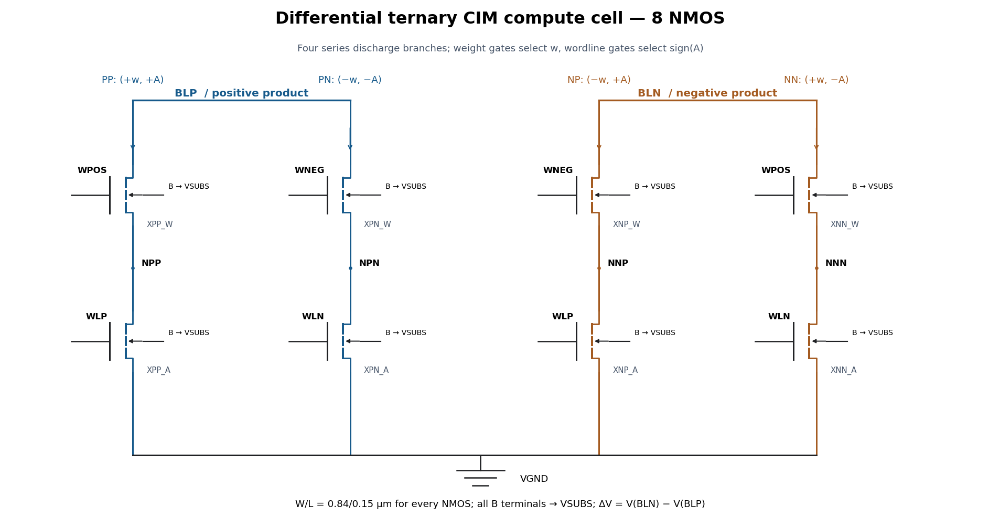

In [10]:
%%cim_lesson schematic
def edu_nmos(ax,x,y,gate,instance,color='#202124',body_text='B → VSUBS'):
    # Four-terminal enhancement NMOS. D/S wires meet a three-segment channel;
    # the gate is isolated, and the body arrow points into the n-channel.
    channel=x-.18;gate_x=x-.58
    ax.plot([x,x,channel],[y+.72,y+.40,y+.40],color=color,lw=1.7)
    ax.plot([channel,x,x],[y-.40,y-.40,y-.72],color=color,lw=1.7)
    for a,b in [(-.40,-.18),(-.09,.09),(.18,.40)]:
        ax.plot([channel,channel],[y+a,y+b],color=color,lw=2.4)
    ax.plot([gate_x,gate_x],[y-.43,y+.43],color='#202124',lw=1.8)
    ax.plot([x-1.55,gate_x],[y,y],color='#202124',lw=1.5)
    ax.text(x-.65,y+.58,gate,ha='right',va='center',fontsize=10,weight='bold')
    ax.plot([x+.78,x+.26],[y,y],color='#202124',lw=1.3)
    ax.annotate('',xy=(channel+.02,y),xytext=(x+.28,y),
        arrowprops=dict(arrowstyle='-|>',lw=1.2,color='#202124',mutation_scale=9))
    ax.text(x+.90,y+.12,body_text,fontsize=8.5,va='bottom')
    ax.text(x+.35,y-.58,instance,fontsize=9,va='top',color='#475569')

def edu_draw_leaf():
    fig,ax=plt.subplots(figsize=(16,8.5))
    ax.set(xlim=(0,25),ylim=(0,12));ax.axis('off')
    ax.text(12.5,11.6,'Differential ternary CIM compute cell — 8 NMOS',
            ha='center',fontsize=19,weight='bold')
    ax.text(12.5,10.95,'Four series discharge branches; weight gates select w, wordline gates select sign(A)',
            ha='center',fontsize=11,color='#475569')
    positions=[3.2,8.7,15.0,20.5]
    meanings=['(+w, +A)','(−w, −A)','(−w, +A)','(+w, −A)']
    for i,(tag,bl,wgate,agate,middle) in enumerate(EDU_BRANCHES):
        x=positions[i];color='#175a8b' if bl=='BLP' else '#a45b21'
        ax.plot([x,x],[9.8,8.32],color=color,lw=1.8)
        ax.plot([x,x],[6.88,4.92],color=color,lw=1.8)
        ax.plot([x,x],[3.48,1.55],color=color,lw=1.8)
        edu_nmos(ax,x,7.6,wgate,f'X{tag}_W',color)
        edu_nmos(ax,x,4.2,agate,f'X{tag}_A',color)
        ax.plot(x,5.9,'o',color=color,ms=3)
        ax.text(x+.22,5.93,middle,fontsize=10,va='bottom',weight='bold')
        ax.text(x,10.22,f'{tag}: {meanings[i]}',ha='center',fontsize=11,color=color)
        ax.annotate('',xy=(x,8.6),xytext=(x,9.2),arrowprops=dict(arrowstyle='->',lw=1.2,color=color))
    for x1,x2,label,col in [(positions[0],positions[1],'BLP  / positive product','#175a8b'),
                              (positions[2],positions[3],'BLN  / negative product','#a45b21')]:
        ax.plot([x1,x2],[9.8,9.8],color=col,lw=2.0)
        ax.text((x1+x2)/2,9.9,label,ha='center',fontsize=12,weight='bold',color=col)
    ax.plot([positions[0],positions[-1]],[1.55,1.55],color='#202124',lw=1.8)
    ax.plot([12,12],[1.55,1.2],color='#202124',lw=1.6)
    for y,w in [(1.2,.6),(1.02,.4),(.84,.2)]:ax.plot([12-w,12+w],[y,y],color='#202124',lw=1.5)
    ax.text(13,1.0,'VGND',fontsize=11,va='center')
    ax.text(12.5,.35,'W/L = 0.84/0.15 µm for every NMOS; all B terminals → VSUBS; ΔV = V(BLN) − V(BLP)',
        ha='center',fontsize=11)
    fig.tight_layout()
    for suffix in ('svg','pdf','png'):
        fig.savefig(EDU_OUT/('ternary_cell_paper.'+suffix),dpi=180,bbox_inches='tight')
    fig.savefig(EDU_OUT/'ternary_cell.svg',bbox_inches='tight')
    fig.savefig(EDU_OUT/'ternary_cell.png',dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)
edu_draw_leaf()


### F2 — Enlarged NMOS: electrical symbol, plan view, and cross-section

Three drawings explain the same leaf `sky130_fd_pr__nfet_01v8` device:

- **Four-terminal symbol:** D (drain), G (gate), S (source), B (bulk/body). The gate is insulated from the channel; interrupted channel strokes denote enhancement MOS. The body arrow points into the n-channel.
- **Conceptual plan view:** active contains source/drain regions; poly crosses active to form the gate; contacts connect regions to metal; a p+ tap ties the body to VSUBS. W is channel width and L is channel length beneath the gate, 0.84/0.15 µm in the source.
- **Conceptual cross-section:** n+ source/drain lie in a p-substrate; gate oxide separates the electrode from semiconductor. Sufficient VGS forms a conductive channel beneath the gate.

These structure drawings explain layers and terminals; **they are not to scale
and are not GDS polygons extracted from layout**. Later KLayout rendering cells
read actual macro GDS. SVG/PDF retain vector detail for enlargement or papers.


<a id="guide-cim-edu-device"></a>

### Before cell `cim-edu-device` — F2

**Implementation:** Draw an enlarged four-terminal NMOS, layer plan, and conceptual cross-section, relating electrical symbols to device geometry, gate-controlled channels, and terminal contacts.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-device-edu_draw_device"></a>`edu_draw_device()` | Draw an enlarged NMOS symbol, active/poly/contact panels, and a conceptual cross-section; label D/G/S/B and W/L to distinguish circuit symbols from fabrication geometry. |

**Data and downstream use:** Follow the [contract described for `cim-edu-schematic`](#data-cim-edu-schematic).

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-159"></a>`VGS` | Gate-to-Source Voltage: V(G)−V(S), controlling NMOS channel formation. |
| <a id="term-160"></a>`gate oxide` | Insulating layer beneath the gate in the conceptual cross-section; the gate is not electrically in direct contact with the channel. |


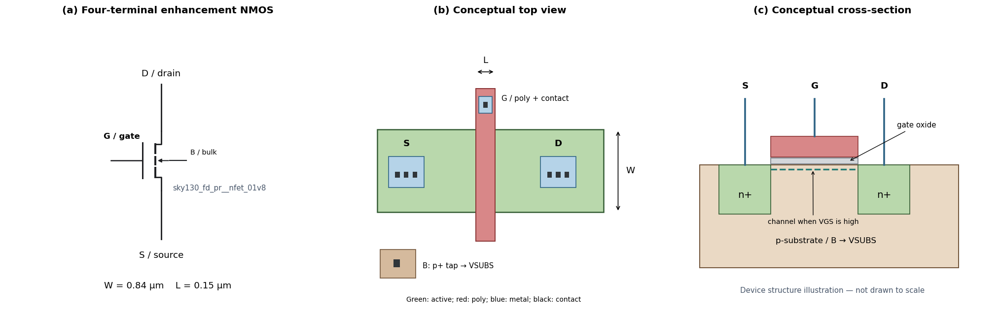

In [11]:
%%cim_lesson device
def edu_draw_device():
    from matplotlib.patches import Rectangle
    fig,axes=plt.subplots(1,3,figsize=(17,5.4))
    for ax in axes:ax.set(xlim=(0,10),ylim=(0,7));ax.axis('off')
    a,b,c=axes
    a.set_title('(a) Four-terminal enhancement NMOS',fontsize=12,weight='bold')
    edu_nmos(a,4.8,3.55,'G / gate','sky130_fd_pr__nfet_01v8',body_text='B / bulk')
    a.plot([4.8,4.8],[4.27,5.4],color='#202124',lw=1.7)
    a.plot([4.8,4.8],[2.83,1.65],color='#202124',lw=1.7)
    a.text(4.8,5.6,'D / drain',ha='center',fontsize=11)
    a.text(4.8,1.2,'S / source',ha='center',fontsize=11)
    a.text(5,.45,'W = 0.84 µm    L = 0.15 µm',ha='center',fontsize=11)

    b.set_title('(b) Conceptual top view',fontsize=12,weight='bold')
    b.add_patch(Rectangle((1.2,2.3),7,2.0,facecolor='#b9d8ac',edgecolor='#355d35',lw=1.5))
    b.add_patch(Rectangle((4.25,1.6),.6,3.7,facecolor='#d88788',edgecolor='#8c3636',lw=1.2))
    for x,lab in [(2.1,'S'),(6.8,'D')]:
        b.add_patch(Rectangle((x-.55,2.9),1.1,.75,facecolor='#b5d3e8',edgecolor='#306586'))
        for dx in (-.27,0,.27):
            b.add_patch(Rectangle((x+dx-.07,3.14),.14,.14,facecolor='#30363a'))
        b.text(x,3.9,lab,ha='center',fontsize=11,weight='bold')
    b.add_patch(Rectangle((4.35,4.7),.4,.4,facecolor='#b5d3e8',edgecolor='#306586'))
    b.add_patch(Rectangle((4.48,4.83),.14,.14,facecolor='#30363a'))
    b.text(5.05,5.05,'G / poly + contact',fontsize=9,va='center')
    b.add_patch(Rectangle((1.3,.7),1.1,.7,facecolor='#d5ba9d',edgecolor='#73563b'))
    b.add_patch(Rectangle((1.7,.96),.2,.2,facecolor='#30363a'))
    b.text(2.6,1.0,'B: p+ tap → VSUBS',fontsize=9,va='center')
    b.annotate('',xy=(8.65,4.3),xytext=(8.65,2.3),arrowprops=dict(arrowstyle='<->',lw=1))
    b.text(8.9,3.3,'W',fontsize=11,va='center')
    b.annotate('',xy=(4.85,5.7),xytext=(4.25,5.7),arrowprops=dict(arrowstyle='<->',lw=1))
    b.text(4.55,5.92,'L',fontsize=11,ha='center')
    b.text(4.8,.13,'Green: active; red: poly; blue: metal; black: contact',ha='center',fontsize=8.2)

    c.set_title('(c) Conceptual cross-section',fontsize=12,weight='bold')
    c.add_patch(Rectangle((.9,.95),8,2.5,facecolor='#ead9c4',edgecolor='#73563b',lw=1.2))
    c.add_patch(Rectangle((1.5,2.25),1.6,1.2,facecolor='#b9d8ac',edgecolor='#355d35'))
    c.add_patch(Rectangle((5.8,2.25),1.6,1.2,facecolor='#b9d8ac',edgecolor='#355d35'))
    c.add_patch(Rectangle((3.1,3.47),2.7,.14,facecolor='#d3d7db',edgecolor='#737b83'))
    c.add_patch(Rectangle((3.1,3.64),2.7,.5,facecolor='#d88788',edgecolor='#8c3636'))
    c.plot([3.1,5.8],[3.34,3.34],'--',color='#267c74',lw=2)
    for x,y,label in [(2.3,3.45,'S'),(6.6,3.45,'D'),(4.45,4.14,'G')]:
        c.plot([x,x],[y,5.05],color='#306586',lw=2.2)
        c.text(x,5.3,label,ha='center',fontsize=11,weight='bold')
    c.text(2.3,2.65,'n+',ha='center',fontsize=12);c.text(6.6,2.65,'n+',ha='center',fontsize=12)
    c.text(4.8,1.55,'p-substrate / B → VSUBS',ha='center',fontsize=10)
    c.annotate('gate oxide',xy=(5.5,3.53),xytext=(7,4.35),fontsize=9,
        arrowprops=dict(arrowstyle='->',lw=.8))
    c.annotate('channel when VGS is high',xy=(4.4,3.34),xytext=(3,2.02),fontsize=8.5,
        arrowprops=dict(arrowstyle='->',lw=.8))
    c.text(5,.35,'Device structure illustration — not drawn to scale',ha='center',fontsize=9,color='#475569')
    fig.tight_layout()
    for suffix in ('svg','pdf','png'):
        fig.savefig(EDU_OUT/('nmos_device_anatomy.'+suffix),dpi=180,bbox_inches='tight')
    plt.show();plt.close(fig)
edu_draw_device()


## F3.1 — Assemble four cells into a 4×1 column

Four leaves connect in parallel to shared `BLP/BLN`. Each row has an
activation-sign wordline pair and a weight-control pair. Row currents sum by
Kirchhoff's law; their integral changes the load charge. In a near-linear region:

$$\Delta V_c \approx \frac{I_{unit}\tau}{C_{BL}}\sum_r A_rT_{r,c}.$$

This explains the mechanism rather than replacing transistor measurements.
Current depends on voltage, series NMOS devices have intermediate nodes, and
loads/R/C vary with layout, motivating sweeps, PEX, and calibration.

A 4×1 column contains four leaves or 32 NMOS. The builder below preserves each
leaf's `BLP BLN WLP WLN WPOS WNEG VGND VSUBS` pin order and compares against
the actual source.


<a id="guide-cim-edu-column"></a>

### Before cell `cim-edu-column` — F3

**Implementation:** Generate one column from four leaves sharing bitlines. CIM summation follows shared physical nodes rather than an adder operator inside the leaf.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-column-edu_column_netlist"></a>`edu_column_netlist(rows=4)` | Generate the column interface with each row's wordline/weight pair and XCELL_r instances sharing BLP/BLN and rails; return a 4×1 subcircuit for source comparison. |

<a id="data-cim-edu-column"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive rows=4 and the validated BLP/BLN/WLP/WLN/WPOS/WNEG/VGND/VSUBS leaf interface, with separate masks/controls per row.
- **Return values and saved artifacts:** Return a column subcircuit with 4 XCELL instances, 2 shared bitlines, 20 pins, and 32 NFETs; write column_4x1.spice and assert source agreement.
- **Downstream consumers:** The core builder instantiates four columns with separate bitlines and row-shared wordlines, exposing 32 weight pins for 16 intersections.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-161"></a>`EDU_COLUMN` | Generated 4×1 column SPICE built from the leaf interface before core assembly. |


In [12]:
%%cim_lesson column
def edu_column_netlist(rows=4):
    pins=['BLP','BLN']+[p for r in range(rows) for p in (f'WLP{r}',f'WLN{r}',f'WPOS{r}',f'WNEG{r}')]+['VGND','VSUBS']
    lines=[f'.subckt automx_ternary_column_{rows}x1 '+' '.join(pins)]
    lines += [f'XCELL{r} BLP BLN WLP{r} WLN{r} WPOS{r} WNEG{r} VGND VSUBS automx_ternary_cell' for r in range(rows)]
    return '\n'.join(lines+[f'.ends automx_ternary_column_{rows}x1'])+'\n'
EDU_COLUMN=edu_column_netlist()
assert EDU_COLUMN.splitlines()==EDU_SOURCE['automx_ternary_column_4x1']
(EDU_OUT/'column_4x1.spice').write_text(EDU_LEAF+EDU_COLUMN)
print(EDU_COLUMN)
print('PASS: one column = 4 leaves = 32 NMOS; 20 subcircuit boundary pins.')


.subckt automx_ternary_column_4x1 BLP BLN WLP0 WLN0 WPOS0 WNEG0 WLP1 WLN1 WPOS1 WNEG1 WLP2 WLN2 WPOS2 WNEG2 WLP3 WLN3 WPOS3 WNEG3 VGND VSUBS
XCELL0 BLP BLN WLP0 WLN0 WPOS0 WNEG0 VGND VSUBS automx_ternary_cell
XCELL1 BLP BLN WLP1 WLN1 WPOS1 WNEG1 VGND VSUBS automx_ternary_cell
XCELL2 BLP BLN WLP2 WLN2 WPOS2 WNEG2 VGND VSUBS automx_ternary_cell
XCELL3 BLP BLN WLP3 WLN3 WPOS3 WNEG3 VGND VSUBS automx_ternary_cell
.ends automx_ternary_column_4x1

PASS: one column = 4 leaves = 32 NMOS; 20 subcircuit boundary pins.


## F3.2 — Assemble four columns into a 4×4 CIM core

Columns have separate bitlines; rows share `WLP_r/WLN_r`, applying one
activation to four weights. Each `(r,c)` intersection has a
`WPOS_r_c/WNEG_r_c` control pair. One compute operation produces four column sums.

| Core pin group | Count | Function |
|---|---:|---|
| Column BLP/BLN | 8 | Four differential analog results |
| Row WLP/WLN | 8 | Signs and PWM of four activations |
| Per-intersection WPOS/WNEG | 32 | 16 ternary weights |
| VGND, VSUBS | 2 | Discharge rail and bulk |
| **Total** | **50** | Leaf-array interface before peripherals |

The core contains `4×4×8=128` NMOS. Physical 4×4 dimensions and the 32-element
MXFP4 block describe different levels: the scheduler reuses the core along K.
The next cell builds the complete SPICE hierarchy, checks source pins/connections,
and draws the logical organization of 16 leaves; this drawing is not place and route.


<a id="guide-cim-edu-array"></a>

### Before cell `cim-edu-array` — F3

**Implementation:** Generate a 4×4 core, index weights by row/column, and draw array organization while preserving sharing across hierarchy levels.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-array-edu_core_netlist"></a>`edu_core_netlist(rows=4, cols=4)` | Generate 50 pins and four XCOL_c instances, sharing wordlines by row and bitlines by column; return the 4×4 core netlist and support the 16-leaf/128-NFET check. |

<a id="data-cim-edu-array"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive rows=4, cols=4, and pin-index rules: WPOS_r_c/WNEG_r_c per intersection, WLP/WLN per row, BLP/BLN per column.
- **Return values and saved artifacts:** Return the 4×4 core with 4 XCOL instances, 50 pins, and 16 leaves/128 NFETs; write core_4x4.spice, validate the source, and draw array organization.
- **Downstream consumers:** Analog inventory adds XACQ to form core_acquisition; tiling shows reuse of a four-row core for the numerical block of 32.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-162"></a>`EDU_CORE` | The 4×4 core SPICE with four columns and 50 pins, checked against the source. |


.subckt automx_ternary_cim_4x4_core BLP0 BLN0 BLP1 BLN1 BLP2 BLN2 BLP3 BLN3 WLP0 WLN0 WLP1 WLN1 WLP2 WLN2 WLP3 WLN3 WPOS_0_0 WNEG_0_0 WPOS_0_1 WNEG_0_1 WPOS_0_2 WNEG_0_2 WPOS_0_3 WNEG_0_3 WPOS_1_0 WNEG_1_0 WPOS_1_1 WNEG_1_1 WPOS_1_2 WNEG_1_2 WPOS_1_3 WNEG_1_3 WPOS_2_0 WNEG_2_0 WPOS_2_1 WNEG_2_1 WPOS_2_2 WNEG_2_2 WPOS_2_3 WNEG_2_3 WPOS_3_0 WNEG_3_0 WPOS_3_1 WNEG_3_1 WPOS_3_2 WNEG_3_2 WPOS_3_3 WNEG_3_3 VGND VSUBS
XCOL0 BLP0 BLN0 WLP0 WLN0 WPOS_0_0 WNEG_0_0 WLP1 WLN1 WPOS_1_0 WNEG_1_0 WLP2 WLN2 WPOS_2_0 WNEG_2_0 WLP3 WLN3 WPOS_3_0 WNEG_3_0 VGND VSUBS automx_ternary_column_4x1
XCOL1 BLP1 BLN1 WLP0 WLN0 WPOS_0_1 WNEG_0_1 WLP1 WLN1 WPOS_1_1 WNEG_1_1 WLP2 WLN2 WPOS_2_1 WNEG_2_1 WLP3 WLN3 WPOS_3_1 WNEG_3_1 VGND VSUBS automx_ternary_column_4x1
XCOL2 BLP2 BLN2 WLP0 WLN0 WPOS_0_2 WNEG_0_2 WLP1 WLN1 WPOS_1_2 WNEG_1_2 WLP2 WLN2 WPOS_2_2 WNEG_2_2 WLP3 WLN3 WPOS_3_2 WNEG_3_2 VGND VSUBS automx_ternary_column_4x1
XCOL3 BLP3 BLN3 WLP0 WLN0 WPOS_0_3 WNEG_0_3 WLP1 WLN1 WPOS_1_3 WNEG_1_3 WLP2 WLN2 WPOS_2_3

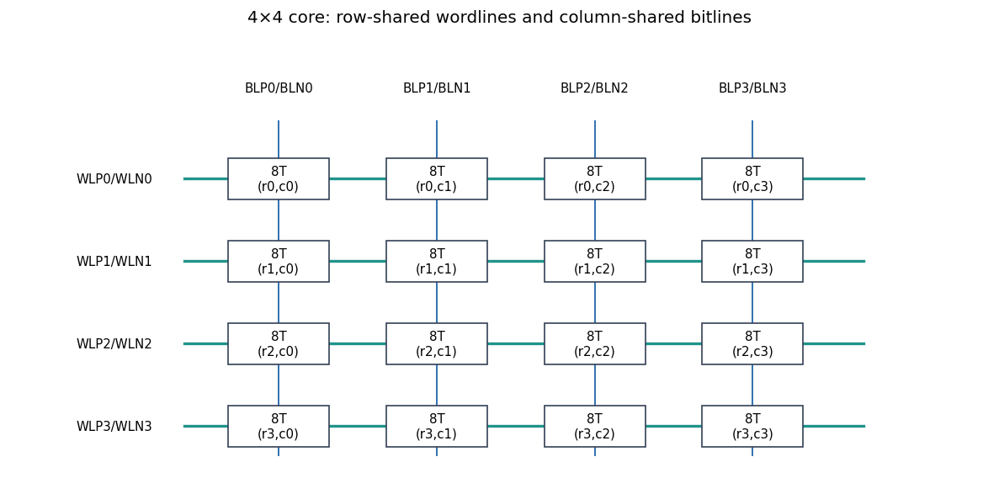

PASS: 16 leaves, 128 NMOS, 50 pins; hierarchy matches the source schematic.


In [13]:
%%cim_lesson array
def edu_core_netlist(rows=4,cols=4):
    pins=[p for c in range(cols) for p in (f'BLP{c}',f'BLN{c}')]
    pins += [p for r in range(rows) for p in (f'WLP{r}',f'WLN{r}')]
    pins += [p for r in range(rows) for c in range(cols) for p in (f'WPOS_{r}_{c}',f'WNEG_{r}_{c}')]+['VGND','VSUBS']
    lines=[f'.subckt automx_ternary_cim_{rows}x{cols}_core '+' '.join(pins)]
    for c in range(cols):
        rp=[p for r in range(rows) for p in (f'WLP{r}',f'WLN{r}',f'WPOS_{r}_{c}',f'WNEG_{r}_{c}')]
        lines.append(f'XCOL{c} BLP{c} BLN{c} '+' '.join(rp)+f' VGND VSUBS automx_ternary_column_{rows}x1')
    return '\n'.join(lines+[f'.ends automx_ternary_cim_{rows}x{cols}_core'])+'\n'
EDU_CORE=edu_core_netlist()
assert EDU_CORE.splitlines()==EDU_SOURCE['automx_ternary_cim_4x4_core']
assert len(EDU_CORE.splitlines()[0].split()[2:])==50
(EDU_OUT/'core_4x4.spice').write_text(EDU_LEAF+EDU_COLUMN+EDU_CORE)
print(EDU_CORE)
fig,ax=plt.subplots(figsize=(10,5));ax.set(xlim=(-1.7,4.5),ylim=(-.7,4.8));ax.axis('off')
for r in range(4):
    y=3-r
    ax.plot([-.6,3.7],[y,y],color='#20948b',lw=2)
    ax.text(-.8,y,f'WLP{r}/WLN{r}',ha='right',va='center',fontsize=9)
    for c in range(4):
        ax.plot([c,c],[-.35,3.7],color='#3574b3',lw=1.2,zorder=0)
        ax.add_patch(plt.Rectangle((c-.32,y-.25),.64,.5,facecolor='white',edgecolor='#334155',zorder=2))
        ax.text(c,y,f'8T\n(r{r},c{c})',ha='center',va='center',fontsize=9,zorder=3)
for c in range(4):ax.text(c,4.05,f'BLP{c}/BLN{c}',ha='center',fontsize=9)
ax.set_title('4×4 core: row-shared wordlines and column-shared bitlines')
fig.tight_layout();fig.savefig(EDU_OUT/'core_4x4.svg');plt.show();plt.close(fig)
print('PASS: 16 leaves, 128 NMOS, 50 pins; hierarchy matches the source schematic.')


## F4 — Turn the bare core into a sampled, readable macro

The bare core only discharges charge. Macro `core_i` adds **acquisition**:

1. **Precharge:** PMOS `XPRE_Pc/XPRE_Nc` charge BLP/BLN to VPWR when `PRE_B=0`.
2. **Compute:** release precharge and pulse WLP or WLN; cells discharge bitlines according to signed products.
3. **Track/hold:** NMOS+PMOS transmission gates connect BLP→HP and BLN→HN during tracking, then open to retain voltage on MIM `XCH` capacitors. Two inverters generate `TRACK_B/TRACK_N`.
4. **Bitline load:** the `XBLCH` MIM bank implements physical load in schematic/layout; loading affects both sensitivity and settling time.
5. **Conditioner/mux:** `condition_i` provides bias, source followers, and transmission gates selecting one HP/HN pair as AINP/AINN for the shared ADC.

A transmission gate uses both N and P devices to pass a wider voltage range
than one pass NMOS. Separating HP/HN from bitlines gives the ADC decision time
after computation. Column changes require select control, dead time, and settling
to prevent sample mixing. The next cell reads schematics, recursively counts
transistors/capacitors, and prints `XCORE → XACQ` instead of estimating inventory
from block names.


<a id="guide-cim-edu-analog"></a>

### Before cell `cim-edu-analog` — F4

**Implementation:** Read schematics and recursively count MOS/MIM devices in core/acquisition/conditioner, identifying peripherals that turn bitline currents into retained ADC input voltages.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-analog-edu_model_of"></a>`edu_model_of(line)` | Extract an instance's SPICE model name immediately before = parameters, preserving subcircuit/primitive names for recursive counting. |
| <a id="fn-cim-edu-analog-edu_inventory"></a>`edu_inventory(name, seen=())` | Recursively traverse the hierarchy, sum primitive-model counts, and reject loops; return NFET/PFET/MIM Counters for leaf, column, core, acquisition, and conditioner. |

<a id="data-cim-edu-analog"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive blocks from core_acquisition.spice and conditioner.spice; distinguish primitive models from recursively expanded subcircuits.
- **Return values and saved artifacts:** Return model Counters, write hierarchy_inventory.json, and tabulate core-plus-acquisition's 138 NFETs/18 PFETs/168 MIM capacitors; separately assert 8 hold and 160 load capacitors.
- **Downstream consumers:** Macro-readout discussion explains HP/HN, mux, and ADC; later native measurements use these source schematics/PEX rather than an ideal matrix-product model.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-163"></a>`TG` | Transmission Gate: complementary-controlled NMOS and PMOS passing analog voltages through the sample or mux path. |
| <a id="term-164"></a>`PMOS` | P-channel MOS, used for precharge or paired with NMOS in peripheral transmission gates. |
| <a id="term-165"></a>`PFET` | P-channel Field-Effect Transistor: the SKY130 p-channel device model name. |
| <a id="term-166"></a>`MIM` | Metal-Insulator-Metal capacitor used for hold storage or physical bitline loading. |
| <a id="term-167"></a>`HP` | Hold positive: node sampling and retaining a column's BLP voltage. |
| <a id="term-168"></a>`HN` | Hold negative: node sampling and retaining a column's BLN voltage. |
| <a id="term-169"></a>`PEX` | Parasitic Extraction: extract layout resistance/capacitance for post-layout simulation. |
| <a id="term-170"></a>`sky130_fd_pr__pfet_01v8` | SKY130's 1.8 V PFET primitive used for precharge and the PMOS half of a transmission gate. |
| <a id="term-171"></a>`sky130_fd_pr__cap_mim_m3_1` | SKY130 MIM capacitor model used by the source acquisition/conditioner; inventory counts model instances without assuming identical capacitance. |
| <a id="term-172"></a>`EDU_HIER` | Core/acquisition/conditioner hierarchy mapping for recursive lesson device counts. |


In [14]:
%%cim_lesson analog
EDU_CONDITIONER=edu_subcircuits((EDU_ROOT/'inputs/conditioner.spice').read_text())
EDU_HIER={**EDU_SOURCE,**EDU_CONDITIONER}
def edu_model_of(line):
    tokens=line.split();end=next((i for i,t in enumerate(tokens) if '=' in t),len(tokens))
    return tokens[end-1]
def edu_inventory(name, seen=()):
    if name in seen:raise ValueError('Hierarchy contains a cycle')
    total=Counter()
    for line in EDU_HIER[name][1:-1]:
        if not line.upper().startswith('X'):continue
        model=edu_model_of(line)
        if model in EDU_HIER:total.update(edu_inventory(model,seen+(name,)))
        else:total[model]+=1
    return total
edu_table(['Subcircuit','NMOS','PMOS','MIM'],[[name,
    edu_inventory(name)['sky130_fd_pr__nfet_01v8'],
    edu_inventory(name)['sky130_fd_pr__pfet_01v8'],
    edu_inventory(name)['sky130_fd_pr__cap_mim_m3_1']] for name in
    ['automx_ternary_cell','automx_ternary_column_4x1','automx_ternary_cim_4x4_core',
     'automx_cim_acquisition_4col_proto','automx_cim_core_acquisition_proto','automx_cim_condition_mux_proto']])
assert edu_inventory('automx_ternary_cim_4x4_core')['sky130_fd_pr__nfet_01v8']==128
edu_acq=EDU_SOURCE['automx_cim_acquisition_4col_proto']
edu_hold=sum(x.startswith('XCH_') for x in edu_acq)
edu_load=sum(x.startswith('XBLCH_') for x in edu_acq)
assert (edu_hold,edu_load)==(8,160)
print('Acquisition: 8 hold capacitors + 160 bitline-load MIM devices; 8 sampling paths use TGs.')
print('\n'.join(EDU_SOURCE['automx_cim_core_acquisition_proto'][1:-1]))
(EDU_OUT/'hierarchy_inventory.json').write_text(json.dumps({n:dict(edu_inventory(n)) for n in EDU_HIER},indent=2))


| Subcircuit | NMOS | PMOS | MIM |
| --- | --- | --- | --- |
| automx_ternary_cell | 8 | 0 | 0 |
| automx_ternary_column_4x1 | 32 | 0 | 0 |
| automx_ternary_cim_4x4_core | 128 | 0 | 0 |
| automx_cim_acquisition_4col_proto | 10 | 18 | 168 |
| automx_cim_core_acquisition_proto | 138 | 18 | 168 |
| automx_cim_condition_mux_proto | 37 | 14 | 20 |

Acquisition: 8 hold capacitors + 160 bitline-load MIM devices; 8 sampling paths use TGs.
XCORE BLP0 BLN0 BLP1 BLN1 BLP2 BLN2 BLP3 BLN3 WLP0 WLN0 WLP1 WLN1 WLP2 WLN2 WLP3 WLN3 WPOS_0_0 WNEG_0_0 WPOS_0_1 WNEG_0_1 WPOS_0_2 WNEG_0_2 WPOS_0_3 WNEG_0_3 WPOS_1_0 WNEG_1_0 WPOS_1_1 WNEG_1_1 WPOS_1_2 WNEG_1_2 WPOS_1_3 WNEG_1_3 WPOS_2_0 WNEG_2_0 WPOS_2_1 WNEG_2_1 WPOS_2_2 WNEG_2_2 WPOS_2_3 WNEG_2_3 WPOS_3_0 WNEG_3_0 WPOS_3_1 WNEG_3_1 WPOS_3_2 WNEG_3_2 WPOS_3_3 WNEG_3_3 VGND VGND automx_ternary_cim_4x4_core
XACQ BLP0 BLN0 BLP1 BLN1 BLP2 BLN2 BLP3 BLN3 HP0 HN0 HP1 HN1 HP2 HN2 HP3 HN3 PRE_B TRACK VPWR VGND TRACK_B TRACK_N automx_cim_acquisition_4col_proto


## F5 — Verify the smallest cell with actual transistors before trusting the array

This cell runs **ngspice DC on the exact eight-NMOS leaf just constructed**.
Nine configurations cover three weights × three activation signs. The fixture
holds both bitlines at 1 V and gates at 0 or 1.8 V. Discharge currents `I_P/I_N`
through two bias sources establish the conduction sign table. Since the leaf
contains only NFETs, the deck loads the complete TT and mismatch `nfet_01v8`
model files with a 1 µm geometry scale from the bundled PDK. These are the NFET
includes in `libs.tech/ngspice/corners/tt.spice`; the small test does not need
unrelated RF/HV and other device models.

Under SPICE source-current conventions, leaf supply currents are `I_P=−I(VBP)`
and `I_N=−I(VBN)`, giving `I_P−I_N=I(VBN)−I(VBP)`. DC checks establish the
multiplication path quickly without a lengthy transient. **These nine points
check transistor polarity**; all 45 integer combinations were checked in F1.2.
Activation magnitude is carried by PWM duration rather than DC gate amplitude.
Later factorial/PEX/waveform cells check dynamics, loading, sample/hold, and
multi-row decoding.


<a id="guide-cim-edu-leaf-spice"></a>

### Before cell `cim-edu-leaf-spice` — F5

**Implementation:** Generate and run nine ngspice DC cases using the actual leaf and bitline-bias sources, checking transistor-level sign/zero before multi-row behavior.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-leaf-spice-edu_leaf_dc"></a>`edu_leaf_dc()` | Generate nine bias cases from three weights and three activation signs in one deck, load the correct TT/mismatch NFET models, and run ngspice; parse bitline currents, check sign/zero, and write actual logs/JSON. |

<a id="data-cim-edu-leaf-spice"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive source-matched EDU_LEAF, TT/mismatch NFET PDK models, and nine weight/sign pairs; fix both bitlines at 1 V, gates at 0/1.8 V, temperature at 27°C, and geometry scale at 1 µm.
- **Return values and saved artifacts:** Write leaf_dc9.spice, native log, and differential_current_a JSON; read I(VBN)−I(VBP), check nine sign/zero states, and plot currents in µA.
- **Downstream consumers:** Results establish leaf-current direction; time-dependent PWM/load/sampling remain checked by factorial/PEX/ADC waveforms, without inferring transient linearity from nine DC points.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-173"></a>`transient` | Time-domain simulation of PWM, charging/discharging, track/hold, and SAR decisions. |
| <a id="term-174"></a>`C` | In co-simulation, C aliases ctypes for the C API; in a SPICE netlist, an instance name starting with C denotes a capacitor. |
| <a id="term-175"></a>`µA` | Microampere = 10^−6 A, used for the leaf's DC bitline-current plots. |
| <a id="term-176"></a>`EDU_LEAF_MEASURED` | Nine DC bias states with differential currents read from the leaf's actual ngspice transcript. |


RUN: ngspice -b /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/cell_to_macro/leaf_dc9.spice


 Reference value :  0.00000e+00
Circuit: Nine DC sign states of the source-matched 8T leaf

Scale set
Doing analysis at TEMP = 27.000000 and TNOM = 27.000000


No. of Data Rows : 1
leaf_0 = 2.327071e-04
leaf_1 = 1.635095e-21
leaf_2 = -2.32707e-04
leaf_3 = 0.000000e+00
leaf_4 = 0.000000e+00
leaf_5 = 0.000000e+00
leaf_6 = -2.32707e-04
leaf_7 = 2.100522e-22
leaf_8 = 2.327071e-04
ngspice-31 done



| w | sign(A) | sign(wA) | I_P − I_N / µA |
| --- | --- | --- | --- |
| -1 | -1 | 1 | 232.7071 |
| -1 | 0 | 0 | 1.635095e-15 |
| -1 | 1 | -1 | -232.707 |
| 0 | -1 | 0 | 0.0 |
| 0 | 0 | 0 | 0.0 |
| 0 | 1 | 0 | 0.0 |
| 1 | -1 | -1 | -232.707 |
| 1 | 0 | 0 | 2.100522e-16 |
| 1 | 1 | 1 | 232.7071 |

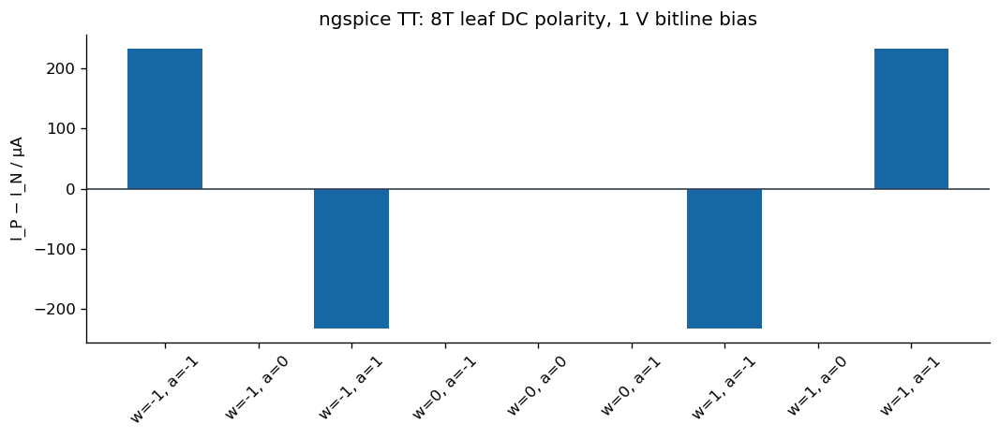

PASS: 9/9 transistor-current sign/zero checks; 45/45 integer combinations checked separately in F1.2.


In [15]:
%%cim_lesson leaf-spice
def edu_leaf_dc():
    models=EDU_ROOT/'pdks/analog/sky130A/libs.ref/sky130_fd_pr/spice'
    lines=['.title Nine DC sign states of the source-matched 8T leaf',
           '.param mc_mm_switch=0 mc_pr_switch=0','.option scale=1u',
           f'.include "{models}/sky130_fd_pr__nfet_01v8__tt.pm3.spice"',
           f'.include "{models}/sky130_fd_pr__nfet_01v8__mismatch.corner.spice"',
           EDU_LEAF,'.temp 27','.option reltol=1e-4']
    cases=[]
    for w in (-1,0,1):
        for a in (-1,0,1):
            i=len(cases);wp,wn=edu_weight_bits(w)
            nodes=[f'{p}{i}' for p in ('BP','BN','AP','AN','WP','WN')]
            bp,bn,ap,an,p,n=nodes
            lines += [f'VBP{i} {bp} 0 1',f'VBN{i} {bn} 0 1',
                      f'VWP{i} {p} 0 {1.8*wp}',f'VWN{i} {n} 0 {1.8*wn}',
                      f'VAP{i} {ap} 0 {1.8*int(a>0)}',f'VAN{i} {an} 0 {1.8*int(a<0)}',
                      f'XC{i} '+' '.join(nodes)+' 0 0 automx_ternary_cell']
            cases.append({'weight':w,'activation_sign':a,'truth_sign':w*a})
    lines += ['.control','op']
    for i in range(len(cases)):
        lines += [f'let leaf_{i}=i(VBN{i})-i(VBP{i})',f'print leaf_{i}']
    lines += ['quit','.endc','.end']
    deck=EDU_OUT/'leaf_dc9.spice';deck.write_text('\n'.join(lines)+'\n')
    command=['ngspice','-b',str(deck)];log=EDU_OUT/'leaf_dc9.ngspice.log'
    print('RUN:', ' '.join(command),flush=True)
    with log.open('w') as stream:
        result=subprocess.run(command,cwd=EDU_OUT,stdout=stream,stderr=subprocess.STDOUT,text=True,timeout=45)
    transcript=log.read_text();print(transcript,flush=True)
    if result.returncode:raise RuntimeError('ngspice leaf DC simulation did not complete')
    measured=dict((int(k),float(v)) for k,v in re.findall(r'^leaf_(\d+)\s*=\s*([-+\d.eE]+)',transcript,re.M))
    assert len(measured)==9
    for i,row in enumerate(cases):
        row['differential_current_a']=measured[i]
        if row['truth_sign']==0:assert abs(measured[i])<1e-10,(i,row)
        else:assert measured[i]*row['truth_sign']>1e-7,(i,row)
    (EDU_OUT/'leaf_dc9.json').write_text(json.dumps(cases,indent=2))
    return cases
EDU_LEAF_MEASURED=edu_leaf_dc()
edu_table(['w','sign(A)','sign(wA)','I_P − I_N / µA'],
    [[r['weight'],r['activation_sign'],r['truth_sign'],r['differential_current_a']*1e6] for r in EDU_LEAF_MEASURED])
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(np.arange(9),[r['differential_current_a']*1e6 for r in EDU_LEAF_MEASURED],color='#1767a4')
ax.set(xticks=np.arange(9),xticklabels=[f"w={r['weight']}, a={r['activation_sign']}" for r in EDU_LEAF_MEASURED],
       ylabel='I_P − I_N / µA',title='ngspice TT: 8T leaf DC polarity, 1 V bitline bias')
ax.tick_params(axis='x',labelrotation=45);ax.axhline(0,color='#334155',lw=1)
fig.tight_layout();fig.savefig(EDU_OUT/'leaf_signed_current.png',dpi=150);plt.show();plt.close(fig)
print('PASS: 9/9 transistor-current sign/zero checks; 45/45 integer combinations checked separately in F1.2.')


## F7 — How does a 32-element MXFP4 block use a four-row core?

For K=32, the scheduler forms eight slices of four activations. Four columns
produce four projection outputs. Readout sums from each slice are accumulated
before applying the group's shared scale and `alpha`. The next cell proves
`sum(tile_sums) == ACT_X2 @ T` and equality between reconstructed output and
floating multiplication of the same decoded MXFP4 values.

In `rtl/automx_cim_readout_seq.sv`, the physical top uses **two 2+2 phases**,
reading four columns sequentially through the shared ADC: eight conversions
per 4×4 slice. A complete 32×4 block therefore needs eight slices × eight =
64 conversions. The later study's co-simulation records measure individual
four-row patterns through the SAR partition. Its three-point affine fit and
the controller's 2+2 LUT are separate calibration contracts. This cell checks
tiling/accumulation and numerical interfaces without replacing those
transistor/RTL measurements.


<a id="guide-cim-edu-tiling"></a>

### Before cell `cim-edu-tiling` — F1, F3 → F7

**Implementation:** Split a block of 32 into eight four-row slices, sum partials, and restore scale, distinguishing numerical block size from physical core size and retaining the factor of 2.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-cim-edu-tiling-edu_tiled_projection"></a>`edu_tiled_projection(act_x2, ternary, scale_byte, alpha)` | Accept 32 ACT_X2 values and a 32×4 ternary matrix, compute eight four-row partials and two two-row phases per slice, verify sum conservation, and apply alpha×2^(E−128); return outputs and partials for reference comparison. |

<a id="data-cim-edu-tiling"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive ACT_X2[32], ternary[32,4], scale_byte, and alpha[4]; the example sets col_v=1 and beta/residual=0 for the base-only contract.
- **Return values and saved artifacts:** Return output[4], partial[8,4], and phases[8,2,4]; assert phase sum=tile sum, tile sum=ACT_X2@T, and output equals the scale-decoded reference.
- **Downstream consumers:** The 2+2 schedule/controller extends this contract to 64 conversions for a 32×4 block; the MHA study uses its independently checked record mapping below.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-177"></a>`alpha` | Weight-group/projection multiplier applied to the numerical contract after obtaining an integer sum; it does not replace the gate amplitude. |
| <a id="term-178"></a>`beta` | Affine correction coefficient in a QTEA payload, belonging to the reference/correction path rather than a WPOS/WNEG bit. |
| <a id="term-179"></a>`col_v` | QTEA coefficient vector along input axis K, used in general projection reconstruction. |


In [16]:
%%cim_lesson tiling
def edu_tiled_projection(act_x2,ternary,scale_byte,alpha):
    act_x2=np.asarray(act_x2,dtype=int);ternary=np.asarray(ternary,dtype=int)
    if act_x2.shape!=(32,) or ternary.shape!=(32,4) or not np.isin(ternary,[-1,0,1]).all():
        raise ValueError('A 32×4 block and ternary weights are required')
    partial=np.stack([act_x2[k:k+4]@ternary[k:k+4] for k in range(0,32,4)])
    phases=np.stack([np.stack([act_x2[k:k+2]@ternary[k:k+2],act_x2[k+2:k+4]@ternary[k+2:k+4]])
                     for k in range(0,32,4)])
    assert np.array_equal(phases.sum(axis=1),partial)
    summed=partial.sum(axis=0);assert np.array_equal(summed,act_x2@ternary)
    return summed*np.exp2(int(scale_byte)-128)*np.asarray(alpha),partial,phases
edu_vector=np.tile(np.arange(8,dtype=np.uint8),4)
edu_vector[1::3]|=8
edu_x2=(2*edu_decode(edu_vector,127)).astype(int)
edu_t=np.random.default_rng(7).integers(-1,2,size=(32,4))
edu_alpha=np.array([.5,.25,1.,2.])
edu_y,edu_partial,edu_phases=edu_tiled_projection(edu_x2,edu_t,128,edu_alpha)
edu_reference=(edu_decode(edu_vector,128)@edu_t)*edu_alpha
assert np.array_equal(edu_y,edu_reference)
edu_table(['K slice','Column sums 0…3','2 integer phases'],
    [[f'{4*k}…{4*k+3}',edu_partial[k].tolist(),edu_phases[k].tolist()] for k in range(8)])
print('Reconstructed sums:',edu_y,'; reference:',edu_reference)
print('PASS: MX block32 → 8 slices of 4×4 → integer accumulation → scale; top 2+2 schedule uses 64 conversions/block32×4.')


| K slice | Column sums 0…3 | 2 integer phases |
| --- | --- | --- |
| 0…3 | [1, -6, -3, 6] | [[0, -1, -1, 1], [1, -5, -2, 5]] |
| 4…7 | [18, -18, 12, -6] | [[10, -10, 4, -6], [8, -8, 8, 0]] |
| 8…11 | [4, 2, -5, 0] | [[1, 0, 0, 1], [3, 2, -5, -1]] |
| 12…15 | [-10, -4, -10, -18] | [[-6, -4, -10, -6], [-4, 0, 0, -12]] |
| 16…19 | [3, -2, 1, 0] | [[1, 1, 1, -1], [2, -3, 0, 1]] |
| 20…23 | [-14, -16, 6, 2] | [[-6, -4, 10, 10], [-8, -12, -4, -8]] |
| 24…27 | [-3, -5, -3, -3] | [[-1, 0, 0, 0], [-2, -5, -3, -3]] |
| 28…31 | [0, -10, -12, 12] | [[0, 2, 0, 0], [0, -12, -12, 12]] |

Reconstructed sums: [ -0.5  -14.75 -14.   -14.  ] ; reference: [ -0.5  -14.75 -14.   -14.  ]
PASS: MX block32 → 8 slices of 4×4 → integer accumulation → scale; top 2+2 schedule uses 64 conversions/block32×4.


<a id="results-checkpoints"></a>

### Initial verification table: logic, transistor currents, and tiling

**Implementation:** Collect the just-computed/measured data, keeping the 45-case logic check separate from the nine-state ngspice DC test. Receive `EDU_LEAF_MEASURED`, the core netlist, and tiled-projection results; display the table and write `first_checkpoints.json`. This checkpoint precedes PEX and ADC experiments. µA means microampere; TT is the typical corner; DC denotes direct-current electrical conditions.


In [17]:
%%cim_lesson measured-checkpoints
edu_table(['w','sign(A)','Measured I_P − I_N / µA','Reference sign','Sign mismatch'],
 [[r['weight'],r['activation_sign'],f"{r['differential_current_a']*1e6:.6f}",r['truth_sign'],
   int((abs(r['differential_current_a'])>1e-10 if r['truth_sign']==0 else r['differential_current_a']*r['truth_sign']<=0))]
  for r in EDU_LEAF_MEASURED])
edu_table(['Checkpoint','Value from constructed/measured data','Result used downstream'],[
 ['Logic table',len(EDU_ALPHABET)*3,'45 activation/weight combinations match integer products'],
 ['DC transistor',len(EDU_LEAF_MEASURED),'9 sign/zero states from ngspice TT'],
 ['Core: pins',len(EDU_CORE.splitlines()[0].split()[2:]),'Core netlist wiring contract'],
 ['Core: leaf',sum(l.startswith('XCOL') for l in EDU_CORE.splitlines())*4,'16 leaf × 8 NMOS'],
 ['Block32: maximum error',float(np.max(abs(edu_y-edu_reference))),'Tiling and scale reconstruction check'],
 ['Block32: partial sums',list(edu_partial.shape),'8 slices × 4 columns'],
])
(EDU_OUT/'first_checkpoints.json').write_text(json.dumps({'dc9':EDU_LEAF_MEASURED,
 'logic_cases':len(EDU_ALPHABET)*3,'core_pins':len(EDU_CORE.splitlines()[0].split()[2:]),
 'block32_max_error':float(np.max(abs(edu_y-edu_reference)))},indent=2))


| w | sign(A) | Measured I_P − I_N / µA | Reference sign | Sign mismatch |
| --- | --- | --- | --- | --- |
| -1 | -1 | 232.707100 | 1 | 0 |
| -1 | 0 | 0.000000 | 0 | 0 |
| -1 | 1 | -232.707000 | -1 | 0 |
| 0 | -1 | 0.000000 | 0 | 0 |
| 0 | 0 | 0.000000 | 0 | 0 |
| 0 | 1 | 0.000000 | 0 | 0 |
| 1 | -1 | -232.707000 | -1 | 0 |
| 1 | 0 | 0.000000 | 0 | 0 |
| 1 | 1 | 232.707100 | 1 | 0 |

| Checkpoint | Value from constructed/measured data | Result used downstream |
| --- | --- | --- |
| Logic table | 45 | 45 activation/weight combinations match integer products |
| DC transistor | 9 | 9 sign/zero states from ngspice TT |
| Core: pins | 50 | Core netlist wiring contract |
| Core: leaf | 16 | 16 leaf × 8 NMOS |
| Block32: maximum error | 0.0 | Tiling and scale reconstruction check |
| Block32: partial sums | [8, 4] | 8 slices × 4 columns |

## F4 → F9 — From small cells to a mixed-signal top

| Level | Concrete bundle object | Flow role |
|---|---|---|
| MOS | `nfet_01v8`, `pfet_01v8`, `cap_mim_m3_1` models | Device equations and physical components |
| Branch/leaf | `automx_ternary_cell` | Signed products through four discharge paths |
| Column/core | `automx_ternary_column_4x1`, `automx_ternary_cim_4x4_core` | Sum four rows and produce four outputs |
| Source macro | `automx_cim_core_acquisition_proto` → `core_i` | Core, precharge, sample/hold, MIM |
| Readout path | `automx_cim_condition_mux_proto` → `condition_i` | Bias, buffering, column selection to AINP/AINN |
| ADC | `adc_top` → `adc_i` | Differential-voltage-to-digital conversion |
| Controller | `automx_cim_readout_seq` → `seq_i` | Weight registers, PWM, 2+2, select, handshakes, calibration |
| Top | `automx_cim_mixed_signal_proto` | Connect the above instances, clock/reset, and supplies |

### F6 — From an 8T schematic to physical geometry

At layout level, each NMOS has active material in a p-type substrate, poly
crossing active to form a gate, contacts connecting source/drain/gate to metal,
and body taps to VSUBS. Series devices share NPP/NPN/NNP/NNN intermediate nodes;
BLP and BLN connect to the correct branch groups. Array repetition preserves
row wordlines and column bitlines before placing boundary pins for LEF.
Peripherals add PMOS in n-wells, well/taps to VPWR, and MIM capacitors on the
appropriate PDK metal layers.

Verification follows geometry → PDK DRC → transistor extraction → schematic
LVS → R/C PEX → same-stimulus resimulation. Stage5 checks
`expected_nfets=4×4×8` against the layout netlist before Netgen. The 128-NMOS
check establishes inventory; LVS checks connectivity; PEX evaluates post-layout
voltage/timing changes. The array drawing is logical organization; later
KLayout macro/top cells show actual physical geometry.

### F7 — Weight registers and readout decoding

The controller holds two 16-bit masks for 16 weights and updates a row on
`cfg_valid_i && cfg_ready_o`; ready rejects `WPOS=WNEG=1`. Each ACT_X2 lane is
five-bit two's complement. The 2+2 reader has 39 reachable partial sums from
−24 to +24, with gaps in the integer set. There are 38 inter-level thresholds
× four columns × two phases = **304 12-bit thresholds**, matching
`thresholds[0:303]` and the RTL's nine-bit address. This LUT is organized by
phase/column; the SAR study's three-point fit has a separate contract.

The controller sequence read from RTL is:
`BOOT → IDLE → PRE → RELEASE → PULSE → HOLD → DEAD → SETTLE → EOC_LOW → START →
WAIT_EOC → WORD_SETTLE → CAPTURE → DECODE → ADVANCE → RESULT`.
`ADVANCE` iterates columns/phases; `FAULT` handles failures/timeouts;
`CAL_PREV/CAL_NEXT` check neighboring thresholds during writes. Handshakes
ensure capture only after actual ADC completion and retain results while
the consumer is not ready.

**Roles of schematic, layout, LEF, and PEX:** The schematic describes connections;
layout places diffusion/gates/contacts/metal/wells/capacitors; LEF supplies
outlines, pins, and obstructions to top placement; PEX adds extracted R/C for
remeasurement. This chapter generates schematic SPICE. The retained layout/PEX
cells verify physical implementation, while cold PnR assembles hard-macro IP
and digital wrappers into a new top. Topology comparison alone does not mean
GDS has been regenerated from the netlist.

The following flow continues through reference/schedule → circuit generation
→ transfer-error measurement → load/PWM selection → SAR/calibration/holdout
→ MHA → cold top → LVS/PG/STA. The leaf lesson has its own SPICE/measurements;
top results continue to rely on the notebook's verification cells and tool logs.


<a id="guide-full-lab-config"></a>

### Before cell `full-lab-config` — F0

**Implementation:** Use the operation group explained in [cell `argument-bootstrap`](#guide-argument-bootstrap).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-full-lab-config-native_lab"></a>`native_lab(line, cell)` | Accept a laboratory cell's source, register its execution-order ID, and run native code or present reference output according to mode; forward stdout to notebook output. |
| <a id="fn-full-lab-config-native_lab-flush_stream"></a>`native_lab.flush_stream()` | Drain buffered text from the output stream, decode it, and display it immediately rather than waiting until the cell ends. |

<a id="data-full-lab-config"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Read data/native_lab_cells.json for the order of 89 native code cells, data/native_lab_outputs.json for retained reference data, and execution-mode environment settings.
- **Return values and saved artifacts:** Create native_lab, _lab_state, and native-lab result storage. Record every cell ID so the final inventory detects missing, repeated, or reordered cells.
- **Downstream consumers:** All %%native_lab cells; full-lab-inventory checks their processed order at the notebook end.


In [18]:
from IPython.core.magic import register_cell_magic
from IPython.display import display as _lab_display
import json as _lab_json, os as _lab_os, sys as _lab_sys
from pathlib import Path as _LabPath

_lab_package = (_design_review_namespace['BUNDLE']
                if '_design_review_namespace' in globals() else BASE)
_lab_output = (_design_review_namespace['OUT']
               if '_design_review_namespace' in globals() else OUT)
_lab_records = _lab_json.loads((_lab_package/'data/native_lab_outputs.json').read_text())
_lab_manifest = _lab_json.loads((_lab_package/'data/native_lab_cells.json').read_text())
_lab_mode = _lab_os.environ.get('AUTOMX_FULL_NATIVE','off').lower()
if _lab_mode not in ('on','off'): raise ValueError('AUTOMX_FULL_NATIVE must be on or off')
_lab_state = {'mode':_lab_mode,'replayed':[],'executed':[],
              'source_cells':_lab_manifest['source_cells'],
              'source_code_cells':_lab_manifest['source_code_cells']}

if _lab_mode=='on':
    _lab_root_text=_lab_os.environ.get('AUTOMX_CIM_ROOT','')
    if not _lab_root_text or not (_LabPath(_lab_root_text)/'configs/sky130_mha_tiny.json').is_file():
        raise FileNotFoundError('For a full native run, set AUTOMX_CIM_ROOT to the design checkout with PDK/routed inputs.')
    # A new native output directory belongs to this execution, never a previous run.
    _lab_os.environ['AUTOMX_RUNALL_CACHE']=str(_lab_output/'full_native')
    _lab_os.environ['AUTOMX_RUNALL_TAG']='full_native'

@register_cell_magic
def native_lab(line,cell):
    """Keep original code visible; run it natively or display attributed recorded output."""
    key=line.strip()
    if key not in _lab_records: raise ValueError('Unknown native notebook cell: '+key)
    if _lab_state['mode']=='on':
        result=get_ipython().run_cell(cell,store_history=False)
        error=result.error_before_exec or result.error_in_exec
        if error is not None: raise error
        _lab_state['executed'].append(key)
        return
    outputs=_lab_records[key]
    if outputs:
        print('RECORDED NATIVE OUTPUT | '+key+' | acquired in the verified native laboratory session')
    # Coalesce adjacent streams while preserving order and all transcript text.
    pending=[]; pending_name=None
    def flush_stream():
        nonlocal pending,pending_name
        if pending:
            target=_lab_sys.stderr if pending_name=='stderr' else _lab_sys.stdout
            target.write(''.join(pending));target.flush();pending=[]
    for output in outputs:
        kind=output['output_type']
        if kind=='stream':
            name=output.get('name','stdout')
            if pending and name!=pending_name: flush_stream()
            pending_name=name;pending.append(output['text'])
        else:
            flush_stream()
            if kind in ('display_data','execute_result'):
                _lab_display(output['data'],raw=True,metadata=output.get('metadata',{}))
            elif kind=='error':
                print('RECORDED ERROR:',output['ename'],output['evalue'])
                print('\n'.join(output.get('traceback',[])))
            else: raise ValueError('Unsupported saved output type: '+kind)
    flush_stream()
    _lab_state['replayed'].append(key)

print('Full laboratory:',_lab_manifest['source_cells'],'original cells,',
      _lab_manifest['source_code_cells'],'original code cells,',
      _lab_manifest['source_code_lines'],'lines of original code.')
print('Mode:', 'fresh native execution' if _lab_mode=='on' else
      'recorded native logs/figures; complete source code remains visible in every cell')


Full laboratory: 200 original cells, 89 original code cells, 12015 lines of original code.
Mode: fresh native execution


<a id="argument-specification"></a>

# 1. Define the quantity that must survive every boundary

The application calls matrix projections; the physical core receives PWM and
ternary controls. The shared contract is the **signed integer sum**
$s_c=\sum_r a_rw_{r,c}$, with $x_r=a_r/2$ and numerical projection $s_c/2$.
We carry the requested activation and weight payload through every measurement.

| Design quantity | Contract used in the measured end-to-end test |
|---|---|
| Physical array | Four rows; one of the four physical columns reused for each transaction |
| Activations / weights | Signed E2M1 x2 integers / ternary −1, 0, +1 |
| Application | Two tokens, four dimensions, two attention heads |
| Analog/digital boundary | Held input → comparator decisions → SAR state → word / EOC |
| Numerical checks | Integer decoding and a same-context-quantization MHA reference; floating context compared separately |

The older logical 32×8 scheduler and larger numerical reference below establish
encoding and scheduling methods. The measured physical demonstration has the
smaller dimensions stated here. Sharing the arithmetic contract lets us relate
those experiments without treating them as the same-sized implementation.

**Decision:** agree on sign, scale, payload and handshake before judging analog
accuracy. **Next test:** construct the circuit and measure its transfer.


## 1. Design question and numerical contract

For each head, $Q=XW_Q$, $K=XW_K$, $V=XW_V$ and $H=\operatorname{softmax}(QK^T/\sqrt{d_h})V$. The output is $Y=\operatorname{Concat}(H_h)W_O$. We map **Q/K/V/O projections** to CIM conversion measurements and use CPU attention/softmax as an independent numerical reference. The MHA RTL IP below implements score, softmax, context and projection scheduling in the mixed-signal top.

The four-row physical core uses ternary weights $w_r\in\{-1,0,1\}$ and signed E2M1 activation integers $a_r=2x_r$. Its arithmetic contract is $s=\sum_r a_rw_r$, with projection result $s/2$. PWM chooses the activation sign and magnitude. Differential charge accumulation gives the intuition $\Delta V\approx\int(I_P-I_N)dt/C_{eff}$; transistor saturation and activity make a measured transfer necessary.

**Mixed-signal flow:** numerical specification → analog/digital partition → transistor schematic and RTL → separate analog layout/PEX and digital synthesis/routing → integrated top → co-simulation, connectivity, RC/STA and view checks. The experiment below follows this feedback loop through an actual failure.

The conversion partition uses transistor CIM/acquisition/conditioner and ADC input switches/comparator, upstream SAR/decoder/OSR RTL, and a charge-equivalent CDAC with ideal bottom drivers. One physical column is reused. The application is a deterministic **2-token × 4-dimension, 2-head** test.

Attention formulation: [[1]](#ref-1).


<a id="results-architecture"></a>

## Weight storage, analog computation, and attention reconstruction

**Implementation:** Connect the numerical contract to transistor pins, then trace each measurement to application output.

| Block | Received/stored data | Operation | Forwarded data |
|---|---|---|---|
| Controller registers | 16 ternary weights, each encoded by `WPOS/WNEG` | Retain sign masks throughout evaluation; control precharge, tracking, and column selection | Weight-transistor gates in each 8T cell |
| Input generator | Four signed `ACT_X2` codes | Sign selects `WLP/WLN`; PWM width follows magnitude | Row-shared activation-transistor gates |
| 8T cell and 4×4 core | Four branches, each with two series NMOS | Electrical input/weight AND selects positive/negative bitline; rows accumulate charge by column | Analog results on `BLP/BLN` |
| Acquisition and conditioner | Four bitline pairs | Sample/hold, buffer, and multiplex | `AINP/AINN` to ADC |
| SAR and ADC | Differential voltage and comparator decisions | Successive Approximation Register RTL controls code search; SPICE solves comparator/sampler transistors | ADC code, EOC (End Of Conversion), and decision traces |
| Calibration and projection | ADC codes and three independent calibration points | Freeze slope/offset, reconstruct integer sums, and apply scaling | Circuit-measured Q/K/V and O projections |
| Python MHA reference | Measured Q/K/V and two attention heads | Independently compute scores, softmax, and context | Reference tensors for RTL comparison |
| MHA RTL IP `mha_i` | Frame, Q/K/V/O weights, and `seq_i` results | Schedule projections; compute QKᵀ, Q0.15 softmax, A×V, context quantization, and O | Two ready/valid output rows; present in the synthesized and routed top |

The 8T cell is a **compute element driven by controller-held weights**; it has
no SRAM latch storing the weight. CIM (Compute-in-Memory) here describes the
analog summation plane coupled to the weight interface; cost tables account
separately for the mask-storage controller. CIM–SAR–MHA integration verifies
one connected chain: physical voltage changes → actual SAR-loop ADC codes →
integer sums → application tensors. Decisions extend beyond a Python oracle:
every dot product requires payload-matched conversion records and frozen calibration.

**Inputs → outputs:** numerical blocks/weights → `WLP/WLN/WPOS/WNEG` pins → held
voltages → codes → integer sums → projections. The physical circuit has four
columns; the demonstration reuses one column over time. One conversion measures
a four-element dot product; each Q/K/V/O stage in the 2×4 example uses eight
conversions, totaling 32 projection transactions.

| Implementation path | Sum reconstruction | Conversion schedule |
|---|---|---|
| Transistor/SAR/MHA demonstration and energy tables | Independent three-point affine fit frozen before holdout | One four-row dot product per conversion, one reused column |
| Physical-top sequencer | 304-entry 12-bit threshold LUT with 304 valid bits | Two 2+2-row phases, two conversions per column |

The top LUT stores 3,648 threshold bits alongside 32 weight-mask bits; measured
controller area includes this storage. Energy tables describe the partition
demonstration; area tables describe physically implemented macros/sequencer.
Early PEX tables measure a 0–3 ns window at swept loads; conversion energy
integrates from the precharged operating point through the post-EOC hold segment.
Each baseline comparison uses that experiment's identical circuit, integration
window, and stimulus policy.


<a id="guide-architecture"></a>

### Before cell `architecture` — F1 → F9

**Implementation:** Define blocks/arrows for activation/weight → CIM → ADC → MHA, naming system interfaces before circuit/software detail.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-architecture-block"></a>`block(x, y, w, text, color)` | Draw a rounded rectangular block at x/y with the supplied width, content, and color; return the architecture-diagram element. |
| <a id="fn-architecture-arrow"></a>`arrow(start, end, label='')` | Connect two positions with an arrow and place a midpoint label indicating inter-block data direction. |

<a id="data-architecture"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive block/arrow coordinates, activation/weight labels, and colors as architectural drawing inputs rather than measurements.
- **Return values and saved artifacts:** Create the CIM → ADC → MHA dataflow figure using positioned block/arrow primitives.
- **Downstream consumers:** Cell-to-macro circuits and ADC/MHA measurements use these same interface names to connect the drawing to actual stimuli/records.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-180"></a>`CDAC` | Capacitive DAC: the SAR capacitor network; the partition retains the source capacitor inventory with corresponding bottom-plate controls. |
| <a id="term-181"></a>`comparator` | Circuit comparing two voltages; SAR uses its decision to test the next bit/code. |


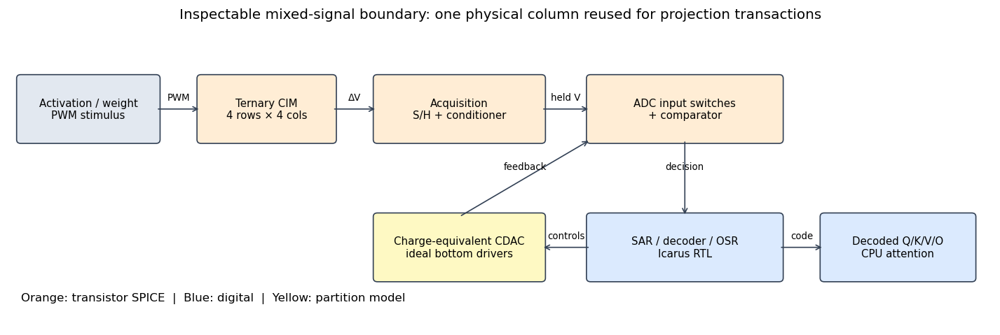

In [19]:
%%design_review architecture
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(12,4.1));ax.set(xlim=(0,12),ylim=(0,4));ax.axis('off')
def block(x,y,w,text,color):
    ax.add_patch(FancyBboxPatch((x,y),w,.82,boxstyle='round,pad=.05',fc=color,ec='#334155',lw=1))
    ax.text(x+w/2,y+.41,text,ha='center',va='center',fontsize=9)
def arrow(start,end,label=''):
    ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#334155'})
    if label:ax.text((start[0]+end[0])/2,(start[1]+end[1])/2+.12,label,ha='center',fontsize=8)
block(.15,2.5,1.65,'Activation / weight\nPWM stimulus','#e2e8f0')
block(2.35,2.5,1.6,'Ternary CIM\n4 rows × 4 cols','#ffedd5')
block(4.5,2.5,2.0,'Acquisition\nS/H + conditioner','#ffedd5')
block(7.1,2.5,2.3,'ADC input switches\n+ comparator','#ffedd5')
block(7.1,.65,2.3,'SAR / decoder / OSR\nIcarus RTL','#dbeafe')
block(4.5,.65,2.0,'Charge-equivalent CDAC\nideal bottom drivers','#fef9c3')
block(9.95,.65,1.8,'Decoded Q/K/V/O\nCPU attention','#dbeafe')
for a,b,label in [((1.8,2.91),(2.35,2.91),'PWM'),((3.95,2.91),(4.5,2.91),'ΔV'),
                  ((6.5,2.91),(7.1,2.91),'held V'),((8.25,2.5),(8.25,1.47),'decision'),
                  ((7.1,1.06),(6.5,1.06),'controls'),((5.5,1.47),(7.1,2.5),'feedback'),
                  ((9.4,1.06),(9.95,1.06),'code')]:arrow(a,b,label)
ax.text(.15,.35,'Orange: transistor SPICE  |  Blue: digital  |  Yellow: partition model',fontsize=10)
ax.set_title('Inspectable mixed-signal boundary: one physical column reused for projection transactions',pad=8)
savefig('architecture.png')


## Mixed-signal design flow from specification to GDS

The flow separates analog and digital branches, establishes interfaces before
top integration, and rechecks the assembled design after layout. Digital
implementation includes synthesis, floorplanning, placement, CTS, routing,
and finishing following [OpenROAD Flow](https://openroad-flow-scripts.readthedocs.io/en/latest/mainREADME.html).



| Stage | Work and outputs consumed downstream |
|---|---|
| 1. System specification | Establish numerical ranges, operation dimensions, voltage, clock, latency, and error targets. |
| 2. Architecture partitioning | Assign analog/digital processing and define pins, polarity, scaling, reset, and handshakes. |
| 3. Analog design | Build schematics, select transistors/capacitors, simulate transients/PVT, and choose operating points/sampling times. |
| 4. Digital design | Write control/SAR RTL, references, and testbenches; check reset, transaction ordering, and outputs. |
| 5. Functional integration | Co-simulate both domains and trace stimulus → voltage → code → application result. |
| 6. Analog layout | Place circuits/supplies/signals, check DRC/LVS, and extract post-layout parasitics. |
| 7. Digital implementation | Synthesize netlists; construct floorplan/PDN; place, build clock trees, and route; export databases/physical views. |
| 8. Top integration | Assemble analog/digital views through pins, power, and clocks; verify top connectivity and geometry. |
| 9. Post-layout verification | Use RC for timing/settling evaluation and functional rechecks; apply measurement-driven ECOs. |
| 10. Results and delivery | Compare DRC/LVS, timing, power, and functional reports; export matching GDS, netlists, timing views, and logs. |

Iteration returns to schematic, RTL, or layout according to the measured cause.
After a change, update all checks that depend on its outputs.

Physical implementation flow: [[10]](#ref-10), [[11]](#ref-11).


<a id="guide-native-runall-config"></a>

### Before cell `native-runall-config` — F0

**Implementation:** Use the operation group explained in [cell `argument-bootstrap`](#guide-argument-bootstrap).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-runall-config-inline_module"></a>`inline_module(line, cell)` | Separate definitions from NOTEBOOK_RUN, create a distinct Python module, execute definitions there, and then invoke the call section in the notebook namespace. |
| <a id="fn-native-runall-config-eda_source"></a>`eda_source(line, cell)` | Write the complete tool script visible in the cell into this run's source directory; Magic/KLayout/OpenROAD execute that script rather than hidden external implementation. |

<a id="data-native-runall-config"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Obtain root from AUTOMX_CIM_ROOT and OUT from setup; establish CACHE/TAG/WORK, earlier-campaign flags, and notebook_sources script storage.
- **Return values and saved artifacts:** Create module/eda_source magics and an empty session directory, write fresh_start.json before measurements, and call portable.start to launch background cold PnR.
- **Downstream consumers:** native-inline-support initializes Flow; native cells register modules/scripts here; synthesis waits for this cold-flow process.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-182"></a>`SHA256` | SHA-256: a 256-bit content checksum used in artifact references, not as an electrical metric or a substitute for a tool verdict. |
| <a id="term-183"></a>`hashlib` | Python module computing content checksums to detect modified files/inputs. |


## Readout implementation and ADC polarity

**Implementation:** Preserve the programmable 304-threshold interface while replacing the linear scan with an upper-bound binary search. `BINARY_DECODE=0` retains the 38-clock comparison; the default uses at most six comparisons. The calibration checks, raw mode, fault state and ready/valid contract remain part of the same controller.

**Inputs → outputs and downstream use:** Host weight masks and calibration thresholds, MXFP4 X2 activations, and ADC word/EOC enter the controller. It emits PWM (Pulse-Width Modulation), sample/hold/select controls and four signed projection outputs. The following source is used by synthesis, full-top RTL verification and the later exhaustive decoder comparison. The conditioner-to-ADC differential pair is crossed in the top binding so increasing signed sums produce increasing raw codes; the native application campaign measures this orientation.

In [20]:
READOUT_RTL = '// Slow physical prototype. SAR completion comes exclusively from the ADC.\n// The technology delay line requires post-layout pulse-width measurement;\n// its taps are NOT assumed to be calibrated 50 ps units.\n`timescale 1ns/1ps\n`default_nettype none\nmodule automx_cim_readout_seq #(\n    parameter integer BOOT_CYCLES = 8192,\n    parameter integer SETTLE_CYCLES = 16,\n    parameter integer ADC_TIMEOUT_CYCLES = 4096,\n    parameter integer VCM_HALF_PERIOD = 763,\n    parameter integer BINARY_DECODE = 1,\n    parameter integer CAL_CLOCK_GATING = 1\n) (\n    input wire clk_i, rst_ni,\n    input wire cfg_valid_i, output wire cfg_ready_o,\n    input wire [1:0] cfg_row_i,\n    input wire [3:0] cfg_wpos_i, cfg_wneg_i,\n    input wire cal_valid_i, output wire cal_ready_o,\n    input wire [8:0] cal_address_i, input wire [11:0] cal_threshold_i,\n    output wire calibrated_o,\n    input wire eval_valid_i, output wire eval_ready_o,\n    input wire signed [19:0] act_x2_i, input wire raw_mode_i,\n    output wire result_valid_o, input wire result_ready_i,\n    output reg signed [47:0] result_acc_o,\n    output reg [95:0] raw_codes_o,\n    output reg result_calibrated_o, output wire fault_o,\n    output reg [15:0] weight_pos_o, weight_neg_o,\n    output reg [3:0] wlp_o, wln_o,\n    output wire pre_b_o, track_o, output reg [3:0] select_o,\n    output wire adc_rst_no, adc_start_o, output reg clk_vcm_o,\n    input wire adc_eoc_i, input wire [15:0] adc_word_i\n);\n    localparam [4:0] BOOT=0, IDLE=1, PRE=2, RELEASE=3, PULSE=4,\n        HOLD=5, DEAD=6, SETTLE=7, EOC_LOW=8, START=9, WAIT_EOC=10,\n        WORD_SETTLE=11, CAPTURE=12, DECODE=13, ADVANCE=14, RESULT=15, FAULT=16,\n        CAL_PREV=17, CAL_NEXT=18;\n    reg [4:0] state;\n    reg [15:0] timer;\n    reg [15:0] vcm_count;\n    reg phase_b;\n    reg [1:0] column;\n    reg signed [19:0] acts;\n    reg raw_mode;\n    reg launch;\n    (* async_reg = "true" *) reg eoc_meta, eoc_sync;\n    reg [303:0] threshold_valid;\n    reg calibration_error;\n    reg [11:0] thresholds [0:303];\n    // Threshold contents have no reset in the original interface. Only the\n    // accepted calibration write may clock this 3,648-bit storage bank.\n    wire calibration_write = rst_ni && state==IDLE && cal_valid_i && cal_ready_o;\n    wire threshold_clock;\n    generate if(CAL_CLOCK_GATING) begin: storage_gating\n        automx_calibration_clock_gate gate_i(.clk_i(clk_i),.enable_i(calibration_write),.clk_o(threshold_clock));\n    end else begin: storage_ungated\n        assign threshold_clock=clk_i;\n    end endgenerate\n    always @(posedge threshold_clock) begin\n        if(calibration_write) thresholds[cal_address_i]<=cal_threshold_i;\n    end\n    reg [11:0] captured_code;\n    reg [5:0] decode_index, decode_bin;\n    reg [5:0] decode_low, decode_high;\n    wire [8:0] threshold_address = (phase_b ? 9\'d152 : 9\'d0)+{7\'d0,column}*9\'d38+{3\'d0,decode_index};\n    reg [8:0] calibration_address;\n    reg [11:0] calibration_value;\n    // Share one physical LUT read mux between decoding and the two neighbor\n    // checks. Calibration handshakes take three clocks instead of one.\n    wire [8:0] threshold_read_address = state==CAL_PREV ? calibration_address-9\'d1 :\n        state==CAL_NEXT ? calibration_address+9\'d1 : threshold_address;\n    wire [11:0] threshold_read_data = thresholds[threshold_read_address];\n    reg signed [5:0] partial_a [0:3];\n    wire [12:0] tap;\n    assign tap[0] = launch;\n    genvar k;\n    generate for (k=1; k<=12; k=k+1) begin: delay_taps\n        (* keep = 1, dont_touch = 1 *) sky130_fd_sc_hd__buf_1 delay_i (.A(tap[k-1]), .X(tap[k]));\n    end endgenerate\n    assign calibrated_o = (&threshold_valid) && !calibration_error && state!=CAL_PREV && state!=CAL_NEXT;\n    assign cfg_ready_o = state==IDLE && !eval_valid_i && !(|(cfg_wpos_i & cfg_wneg_i));\n    assign cal_ready_o = state==IDLE && !eval_valid_i && cal_address_i < 9\'d304;\n    assign eval_ready_o = state==IDLE && !cfg_valid_i && !cal_valid_i &&\n                          (raw_mode_i || calibrated_o) && valid_acts(act_x2_i);\n    assign result_valid_o = state==RESULT;\n    assign fault_o = state==FAULT;\n    assign pre_b_o = !(state==BOOT || state==IDLE || state==PRE || state==CAL_PREV || state==CAL_NEXT);\n    assign track_o = state==PRE || state==RELEASE || state==PULSE;\n    assign adc_rst_no = !(state==BOOT || state==IDLE || state==PRE || state==RELEASE ||\n                         state==PULSE || state==HOLD || state==DEAD || state==SETTLE || state==FAULT ||\n                         state==CAL_PREV || state==CAL_NEXT);\n    assign adc_start_o = state==START;\n\n    function automatic [4:0] magnitude(input signed [4:0] x);\n        magnitude = x[4] ? (~x+5\'d1) : x;\n    endfunction\n    function automatic valid_acts(input signed [19:0] x);\n        integer r;\n        reg [4:0] m;\n        begin\n            valid_acts=1;\n            for(r=0;r<4;r=r+1) begin\n                m=magnitude(x[5*r+:5]);\n                case(m)\n                    0,1,2,3,4,6,8,12: ;\n                    default: valid_acts=0;\n                endcase\n            end\n        end\n    endfunction\n    // The reachable two-row integer alphabet is fixed; thresholds are\n    // programmed only from measurements of this complete readout path.\n    // Explicit unsigned index avoids the int\' cast unsupported by the\n    // Verilog frontend shipped with OpenLane 30ee138.\n    function automatic signed [5:0] level(input [5:0] i);\n        begin\n            case(i)\n              0:level=-24;1:level=-20;2:level=-18;3:level=-16;4:level=-15;\n              5:level=-14;6:level=-13;7:level=-12;8:level=-11;9:level=-10;\n              10:level=-9;11:level=-8;12:level=-7;13:level=-6;14:level=-5;\n              15:level=-4;16:level=-3;17:level=-2;18:level=-1;19:level=0;\n              20:level=1;21:level=2;22:level=3;23:level=4;24:level=5;\n              25:level=6;26:level=7;27:level=8;28:level=9;29:level=10;\n              30:level=11;31:level=12;32:level=13;33:level=14;34:level=15;\n              35:level=16;36:level=18;37:level=20;38:level=24;\n              default:level=0;\n            endcase\n        end\n    endfunction\n    integer row;\n    reg [4:0] mag;\n    always @* begin\n        wlp_o=0; wln_o=0; select_o=0;\n        for(row=0;row<4;row=row+1) begin\n            mag=magnitude(acts[5*row+:5]);\n            if(state==PULSE && (row>=2)==phase_b && mag>0 && mag<=12) begin\n                if(acts[5*row+4]) wln_o[row]=launch && !tap[mag[3:0]];\n                else wlp_o[row]=launch && !tap[mag[3:0]];\n            end\n        end\n        if(state>=SETTLE && state<=CAPTURE) select_o=4\'b0001<<column;\n    end\n    integer i;\n    reg signed [5:0] decoded;\n    reg signed [11:0] sum;\n    reg [5:0] next_bin;\n    reg [5:0] next_low, next_high;\n    reg decode_done;\n    always @(posedge clk_i or negedge rst_ni) begin\n        if(!rst_ni) begin\n            state<=BOOT; timer<=0; vcm_count<=0; clk_vcm_o<=0;\n            phase_b<=0; column<=0; acts<=0; raw_mode<=0; launch<=0;\n            weight_pos_o<=0; weight_neg_o<=0; threshold_valid<=0;calibration_error<=0;\n            calibration_address<=0;calibration_value<=0;\n            captured_code<=0;decode_index<=0;decode_bin<=0;\n            decode_low<=0;decode_high<=38;\n            result_acc_o<=0; raw_codes_o<=0; result_calibrated_o<=0;\n            eoc_meta<=0; eoc_sync<=0;\n            for(i=0;i<4;i=i+1) partial_a[i]<=0;\n        end else begin\n            eoc_meta<=adc_eoc_i; eoc_sync<=eoc_meta;\n            if(vcm_count==VCM_HALF_PERIOD-1) begin vcm_count<=0; clk_vcm_o<=!clk_vcm_o; end\n            else vcm_count<=vcm_count+1;\n            timer<=timer+1;\n            case(state)\n                BOOT: if(timer>=BOOT_CYCLES-1) begin state<=IDLE; timer<=0; end\n                IDLE: begin\n                    timer<=0; launch<=0;\n                    if(cfg_valid_i && cfg_ready_o) begin\n                        weight_pos_o[4*cfg_row_i+:4]<=cfg_wpos_i;\n                        weight_neg_o[4*cfg_row_i+:4]<=cfg_wneg_i;\n                    end\n                    if(cal_valid_i && cal_ready_o) begin\n                        threshold_valid[cal_address_i]<=1;\n                        calibration_address<=cal_address_i;calibration_value<=cal_threshold_i;\n                        state<=CAL_PREV;\n                    end\n                    if(eval_valid_i && eval_ready_o) begin\n                        acts<=act_x2_i; raw_mode<=raw_mode_i; phase_b<=0; column<=0;\n                        result_calibrated_o<=0; result_acc_o<=0; raw_codes_o<=0;\n                        state<=PRE;\n                    end\n                end\n                CAL_PREV: begin\n                    if(calibration_address%38!=0 && threshold_valid[threshold_read_address] &&\n                       calibration_value<=threshold_read_data) calibration_error<=1;\n                    state<=CAL_NEXT;\n                end\n                CAL_NEXT: begin\n                    if(calibration_address%38!=37 && threshold_valid[threshold_read_address] &&\n                       calibration_value>=threshold_read_data) calibration_error<=1;\n                    state<=IDLE;timer<=0;\n                end\n                PRE: if(timer>=1) begin state<=RELEASE; timer<=0; end\n                RELEASE: begin state<=PULSE; timer<=0; launch<=1; end\n                PULSE: begin launch<=0; state<=HOLD; timer<=0; end\n                HOLD: begin state<=DEAD; timer<=0; end\n                DEAD: begin state<=SETTLE; timer<=0; end\n                SETTLE: if(timer>=SETTLE_CYCLES-1) begin state<=EOC_LOW; timer<=0; end\n                EOC_LOW: begin\n                    if(!eoc_sync) begin state<=START; timer<=0; end\n                    else if(timer>=ADC_TIMEOUT_CYCLES-1) state<=FAULT;\n                end\n                START: begin state<=WAIT_EOC; timer<=0; end\n                WAIT_EOC: begin\n                    if(eoc_sync) begin state<=WORD_SETTLE; timer<=0; end\n                    else if(timer>=ADC_TIMEOUT_CYCLES-1) state<=FAULT;\n                end\n                WORD_SETTLE: if(timer>=2) begin state<=CAPTURE; timer<=0; end\n                CAPTURE: begin\n                    if(adc_word_i[3:0]!=0) state<=FAULT;\n                    else begin\n                        raw_codes_o[(phase_b ? 48 : 0)+12*column+:12]<=adc_word_i[15:4];\n                        captured_code<=adc_word_i[15:4];\n                        decode_index<=BINARY_DECODE ? 6\'d19 : 6\'d0;decode_bin<=0;\n                        decode_low<=0;decode_high<=38;\n                        state<=raw_mode ? ADVANCE : DECODE;timer<=0;\n                    end\n                end\n                // Upper bound: count thresholds <= code. Strictly increasing\n                // calibration is checked above. The half-open [low, high)\n                // search uses the same single LUT read, at most six clocks.\n                // BINARY_DECODE=0 retains the measured 38-clock baseline.\n                DECODE: begin\n                    if(BINARY_DECODE) begin\n                        next_low=decode_low;next_high=decode_high;\n                        if(captured_code>=threshold_read_data) next_low=decode_index+6\'d1;\n                        else next_high=decode_index;\n                        next_bin=next_low;\n                        decode_done=next_low==next_high;\n                    end else begin\n                        next_bin=decode_bin+(captured_code>=threshold_read_data ? 6\'d1 : 6\'d0);\n                        decode_done=decode_index==37;\n                    end\n                    if(decode_done) begin\n                        decoded=level(next_bin);\n                        if(!phase_b) partial_a[column]<=decoded;\n                        else begin\n                            sum={{6{partial_a[column][5]}},partial_a[column]}+{{6{decoded[5]}},decoded};\n                            result_acc_o[12*column+:12]<=sum;\n                        end\n                        state<=ADVANCE;timer<=0;\n                    end else if(BINARY_DECODE) begin\n                        decode_low<=next_low;decode_high<=next_high;\n                        decode_index<=({1\'b0,next_low}+{1\'b0,next_high})>>1;\n                    end else begin decode_index<=decode_index+1;decode_bin<=next_bin;end\n                end\n                ADVANCE: begin\n                    timer<=0;\n                    if(column!=3) begin column<=column+1; state<=DEAD; end\n                    else if(!phase_b) begin phase_b<=1; column<=0; state<=PRE; end\n                    else begin state<=RESULT; result_calibrated_o<=!raw_mode && calibrated_o; end\n                end\n                RESULT: if(result_ready_i) begin state<=IDLE; timer<=0; end\n                FAULT: ;\n                default: state<=FAULT;\n            endcase\n        end\n    end\nendmodule\n// Portable latch model for RTL; the physical flow maps the characterized ICG.\nmodule automx_calibration_clock_gate(input wire clk_i,enable_i,output wire clk_o);\n`ifdef SYNTHESIS\n    (* keep=1 *) sky130_fd_sc_hd__dlclkp_1 icg_i(.CLK(clk_i),.GATE(enable_i),.GCLK(clk_o));\n`else\n    reg enable_latched;\n    always @* if(!clk_i) enable_latched=enable_i;\n    assign clk_o=clk_i && enable_latched;\n`endif\nendmodule\n`default_nettype wire\n'
from pathlib import Path
_priority_root=Path(__import__('os').environ.get('AUTOMX_BUNDLE_DIR','.')).resolve()
for _relative in ('rtl/automx_cim_readout_seq.sv','ip/automx_mha/rtl/automx_cim_readout_seq.sv'):
    (_priority_root/_relative).write_text(READOUT_RTL)
print('Readout RTL: binary upper bound, 38 thresholds/bank, eight banks; linear baseline retained')

PRIORITY_MIXED_TOP_RTL = "`default_nettype none\nmodule automx_cim_mixed_signal_proto (\n    input wire clk_i, rst_ni,\n    input wire cfg_valid_i, output wire cfg_ready_o,\n    input wire [1:0] cfg_row_i, input wire [3:0] cfg_wpos_i, cfg_wneg_i,\n    input wire cal_valid_i, output wire cal_ready_o,\n    input wire [8:0] cal_address_i, input wire [11:0] cal_threshold_i,\n    output wire calibrated_o,\n    input wire eval_valid_i, output wire eval_ready_o,\n    input wire signed [19:0] act_x2_i, input wire raw_mode_i,\n    output wire result_valid_o, input wire result_ready_i,\n    output wire signed [47:0] result_acc_o, output wire [95:0] raw_codes_o,\n    output wire result_calibrated_o, fault_o,\n    output wire BIAS_MON,\n    input wire mha_mode_i,\n    input wire mha_cfg_valid_i, output wire mha_cfg_ready_o,\n    input wire [1:0] mha_cfg_stage_i, mha_cfg_row_i,\n    input wire [3:0] mha_cfg_wpos_i, mha_cfg_wneg_i,\n    input wire mha_req_valid_i, output wire mha_req_ready_o,\n    input wire [39:0] mha_req_act_x2_i,\n    output wire mha_rsp_valid_o, input wire mha_rsp_ready_i,\n    output wire mha_rsp_row_o, output wire [47:0] mha_rsp_result_x2_o,\n    output wire mha_busy_o, mha_fault_o,\n    inout wire VPWR, VGND\n);\nwire [15:0] wp, wn, adc_word; wire [3:0] wlp, wln, sel;\nwire pre_b, track, adc_rst_n, adc_start, clk_vcm, eoc, eoc_osr;\nwire BLP0, BLN0, BLP1, BLN1, BLP2, BLN2, BLP3, BLN3, HP0, HN0, HP1, HN1, HP2, HN2, HP3, HN3, TRACK_B, TRACK_N;\nwire AINP, AINN;\nwire seq_cfg_valid, seq_cfg_ready, seq_cal_ready, seq_eval_valid, seq_eval_ready;\nwire [1:0] seq_cfg_row;\nwire [3:0] seq_cfg_wpos, seq_cfg_wneg;\nwire [19:0] seq_act;\nwire seq_result_valid, seq_result_ready;\nwire mha_core_cfg_valid, mha_core_eval_valid, mha_core_result_ready;\nwire [1:0] mha_core_cfg_row;\nwire [3:0] mha_core_cfg_wpos, mha_core_cfg_wneg;\nwire [19:0] mha_core_act;\nwire mha_reserve = mha_mode_i || mha_busy_o;\nassign seq_cfg_valid=mha_reserve ? mha_core_cfg_valid : cfg_valid_i;\nassign seq_cfg_row=mha_reserve ? mha_core_cfg_row : cfg_row_i;\nassign seq_cfg_wpos=mha_reserve ? mha_core_cfg_wpos : cfg_wpos_i;\nassign seq_cfg_wneg=mha_reserve ? mha_core_cfg_wneg : cfg_wneg_i;\nassign seq_eval_valid=mha_reserve ? mha_core_eval_valid : eval_valid_i;\nassign seq_act=mha_reserve ? mha_core_act : act_x2_i;\nassign seq_result_ready=mha_busy_o ? mha_core_result_ready : (!mha_mode_i && result_ready_i);\nassign cfg_ready_o=!mha_reserve && seq_cfg_ready;\nassign cal_ready_o=!mha_busy_o && seq_cal_ready;\nassign eval_ready_o=!mha_reserve && seq_eval_ready;\nassign result_valid_o=!mha_reserve && seq_result_valid;\nautomx_mha_ip mha_i (\n    .clk_i(clk_i), .rst_ni(rst_ni),\n    .cfg_valid_i(mha_cfg_valid_i), .cfg_ready_o(mha_cfg_ready_o),\n    .cfg_stage_i(mha_cfg_stage_i), .cfg_row_i(mha_cfg_row_i),\n    .cfg_wpos_i(mha_cfg_wpos_i), .cfg_wneg_i(mha_cfg_wneg_i),\n    .req_valid_i(mha_req_valid_i && mha_mode_i), .req_ready_o(mha_req_ready_o),\n    .req_act_x2_i(mha_req_act_x2_i),\n    .rsp_valid_o(mha_rsp_valid_o), .rsp_ready_i(mha_rsp_ready_i),\n    .rsp_row_o(mha_rsp_row_o), .rsp_result_x2_o(mha_rsp_result_x2_o),\n    .busy_o(mha_busy_o), .fault_o(mha_fault_o),\n    .core_available_i(mha_mode_i && calibrated_o && seq_eval_ready && !cal_valid_i),\n    .core_fault_i(fault_o),\n    .core_cfg_valid_o(mha_core_cfg_valid), .core_cfg_ready_i(seq_cfg_ready),\n    .core_cfg_row_o(mha_core_cfg_row), .core_cfg_wpos_o(mha_core_cfg_wpos), .core_cfg_wneg_o(mha_core_cfg_wneg),\n    .core_eval_valid_o(mha_core_eval_valid), .core_eval_ready_i(seq_eval_ready), .core_act_x2_o(mha_core_act),\n    .core_result_valid_i(seq_result_valid), .core_result_ready_o(mha_core_result_ready),\n    .core_result_x2_i(result_acc_o), .core_result_calibrated_i(result_calibrated_o)\n);\nautomx_cim_readout_seq seq_i (\n.clk_i(clk_i),\n.rst_ni(rst_ni),\n.cfg_valid_i(seq_cfg_valid),\n.cfg_ready_o(seq_cfg_ready),\n.cfg_row_i(seq_cfg_row),\n.cfg_wpos_i(seq_cfg_wpos),\n.cfg_wneg_i(seq_cfg_wneg),\n.cal_valid_i(cal_valid_i && !mha_busy_o),\n.cal_ready_o(seq_cal_ready),\n.cal_address_i(cal_address_i),\n.cal_threshold_i(cal_threshold_i),\n.calibrated_o(calibrated_o),\n.eval_valid_i(seq_eval_valid),\n.eval_ready_o(seq_eval_ready),\n.act_x2_i(seq_act),\n.raw_mode_i(mha_reserve ? 1'b0 : raw_mode_i),\n.result_valid_o(seq_result_valid),\n.result_ready_i(seq_result_ready),\n.result_acc_o(result_acc_o),\n.raw_codes_o(raw_codes_o),\n.result_calibrated_o(result_calibrated_o),\n.fault_o(fault_o),\n.weight_pos_o(wp), .weight_neg_o(wn), .wlp_o(wlp), .wln_o(wln), .pre_b_o(pre_b), .track_o(track),\n.select_o(sel), .adc_rst_no(adc_rst_n), .adc_start_o(adc_start), .clk_vcm_o(clk_vcm),\n.adc_eoc_i(eoc_osr), .adc_word_i(adc_word));\nautomx_cim_core_acquisition_proto core_i (.BLP0(BLP0), .BLN0(BLN0), .BLP1(BLP1), .BLN1(BLN1), .BLP2(BLP2), .BLN2(BLN2), .BLP3(BLP3), .BLN3(BLN3), .HP0(HP0), .HN0(HN0), .HP1(HP1), .HN1(HN1), .HP2(HP2), .HN2(HN2), .HP3(HP3), .HN3(HN3), .PRE_B(pre_b), .TRACK(track), .VPWR(VPWR), .VGND(VGND), .TRACK_B(TRACK_B), .TRACK_N(TRACK_N), .WLP0(wlp[0]), .WLN0(wln[0]), .WLP1(wlp[1]), .WLN1(wln[1]), .WLP2(wlp[2]), .WLN2(wln[2]), .WLP3(wlp[3]), .WLN3(wln[3]), .WPOS_0_0(wp[0]), .WNEG_0_0(wn[0]), .WPOS_0_1(wp[1]), .WNEG_0_1(wn[1]), .WPOS_0_2(wp[2]), .WNEG_0_2(wn[2]), .WPOS_0_3(wp[3]), .WNEG_0_3(wn[3]), .WPOS_1_0(wp[4]), .WNEG_1_0(wn[4]), .WPOS_1_1(wp[5]), .WNEG_1_1(wn[5]), .WPOS_1_2(wp[6]), .WNEG_1_2(wn[6]), .WPOS_1_3(wp[7]), .WNEG_1_3(wn[7]), .WPOS_2_0(wp[8]), .WNEG_2_0(wn[8]), .WPOS_2_1(wp[9]), .WNEG_2_1(wn[9]), .WPOS_2_2(wp[10]), .WNEG_2_2(wn[10]), .WPOS_2_3(wp[11]), .WNEG_2_3(wn[11]), .WPOS_3_0(wp[12]), .WNEG_3_0(wn[12]), .WPOS_3_1(wp[13]), .WNEG_3_1(wn[13]), .WPOS_3_2(wp[14]), .WNEG_3_2(wn[14]), .WPOS_3_3(wp[15]), .WNEG_3_3(wn[15]));\nautomx_cim_condition_mux_proto condition_i (.HP0(HP0), .HN0(HN0), .HP1(HP1), .HN1(HN1), .HP2(HP2), .HN2(HN2), .HP3(HP3), .HN3(HN3), .SEL0(sel[0]), .SEL1(sel[1]), .SEL2(sel[2]), .SEL3(sel[3]), .AINP(AINP), .AINN(AINN), .BIAS_MON(BIAS_MON), .VPWR(VPWR), .VGND(VGND));\nadc_top adc_i (.VDD(VPWR), .VSS(VGND), .clk_vcm(clk_vcm), .conversion_finished_osr_out(eoc_osr), .conversion_finished_out(eoc), .inn_analog(AINP), .inp_analog(AINN), .rst_n(adc_rst_n), .start_conversion_in(adc_start), .config_1_in({1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0}), .config_2_in({1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1}), .result_out({adc_word[15], adc_word[14], adc_word[13], adc_word[12], adc_word[11], adc_word[10], adc_word[9], adc_word[8], adc_word[7], adc_word[6], adc_word[5], adc_word[4], adc_word[3], adc_word[2], adc_word[1], adc_word[0]}));\nendmodule\n`default_nettype wire\n"
for _relative in ('inputs/automx_cim_mixed_signal_proto.sv','ip/automx_mha/rtl/automx_cim_mixed_signal_proto.sv'):
    (_priority_root/_relative).write_text(PRIORITY_MIXED_TOP_RTL)
print('ADC input pair: conditioner AINN -> ADC inp; AINP -> ADC inn')


Readout RTL: binary upper bound, 38 thresholds/bank, eight banks; linear baseline retained
ADC input pair: conditioner AINN -> ADC inp; AINP -> ADC inn


In [21]:
%%native_lab runall-config
from pathlib import Path
import os,sys,json,hashlib,types,time
from datetime import datetime,timezone
from IPython.core.magic import register_cell_magic
ROOT=Path(os.environ.get("AUTOMX_CIM_ROOT",str(_bundle))).resolve()
if not (ROOT/"configs/sky130_mha_tiny.json").is_file():raise FileNotFoundError("Start Jupyter in the AutoMX-CIM root")
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
SESSION_NAME="fresh_"+datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
CACHE=Path(os.environ.get("AUTOMX_RUNALL_CACHE",str(Path("/media/nam/EDABK/AutoMX_CIM_fresh_runs")/SESSION_NAME))).resolve()
TAG=os.environ.get("AUTOMX_RUNALL_TAG",CACHE.name)
WORK=CACHE/TAG
prior_results=[p for p in WORK.rglob("*") if p.is_file()] if WORK.exists() else []
if prior_results:raise FileExistsError("Fresh Run All needs an empty output folder. Select a new session: "+str(WORK))
WORK.mkdir(parents=True,exist_ok=True)
(WORK/"fresh_start.json").write_text(json.dumps({"started_epoch_s":time.time(),"pre_existing_results":len(prior_results),"reuse":False,"work":str(WORK)},indent=2)+"\n")
if not __import__('re').fullmatch('[A-Za-z][A-Za-z0-9_]{0,63}',TAG):raise ValueError("Invalid work tag")
INLINE_ROOT=CACHE/TAG/"notebook_sources"/"automx_nb_inline_v1"
INLINE_ROOT.mkdir(parents=True,exist_ok=True)
(INLINE_ROOT/"__init__.py").write_text("")
if str(INLINE_ROOT.parent) not in sys.path:sys.path.insert(0,str(INLINE_ROOT.parent))
import automx_nb_inline_v1
INLINE_SOURCES={}
RUN_LEGACY_CAMPAIGNS=False  # replay saved measurements by default; do not restart hundreds of old SPICE jobs
LEGACY_NS={"ROOT":ROOT,"__name__":"notebook_legacy"}

@register_cell_magic
def inline_module(line,cell):
    """Execute definitions visibly written in this cell in an isolated namespace.

    The generated .py is an executed-source snapshot / native-worker input,
    not a helper implementation read from the checkout. Edit the cell to edit
    the algorithm. Separating globals prevents old/new function names colliding.
    """
    name=line.strip()
    if not __import__('re').fullmatch('[a-z][a-z0-9_]*',name):raise ValueError("Invalid inline module name")
    definitions,_,invoke=cell.partition("# NOTEBOOK_RUN\n")
    path=INLINE_ROOT/(name+".py")
    header=("from __future__ import annotations\nfrom pathlib import Path\nimport sys\n"
        +"PROJECT_ROOT=Path("+repr(str(ROOT))+")\nINLINE_ROOT=Path("+repr(str(INLINE_ROOT))+")\n"
        +"sys.path.insert(0,str(PROJECT_ROOT))\nsys.path.insert(0,str(INLINE_ROOT.parent))\n")
    text=header+definitions
    if not path.is_file() or path.read_text()!=text:path.write_text(text)
    module=types.ModuleType("automx_nb_inline_v1."+name);module.__file__=str(path)
    sys.modules[module.__name__]=module
    setattr(automx_nb_inline_v1,name,module)
    exec(compile(text,str(path),"exec"),module.__dict__)
    get_ipython().user_ns[name]=module
    INLINE_SOURCES[name]={"path":str(path),"sha256":hashlib.sha256(text.encode()).hexdigest()}
    # MODULE_RESULTS
    if not invoke.strip() or invoke.lstrip().startswith('pass') or '(' not in invoke:
        members=[key for key,value in module.__dict__.items() if callable(value) and getattr(value,'__module__',None)==module.__name__ and not key.startswith('_')]
        if not members:members=[key for key,value in module.__dict__.items() if callable(value) and not key.startswith('_') and key not in ('Path','Counter','Markdown','display')]
        print(name+': '+', '.join(members[:7])+(' …' if len(members)>7 else ''),flush=True)
    if invoke.strip():exec(compile(invoke,"<notebook-call:"+name+">","exec"),get_ipython().user_ns)

@register_cell_magic
def eda_source(line,cell):
    """Materialize the native tool script whose complete text is in this cell."""
    name=line.strip()
    if Path(name).name!=name:raise ValueError("Use a simple tool source filename")
    definitions,_,invoke=cell.partition("# NOTEBOOK_RUN\n")
    path=INLINE_ROOT/name
    if not path.is_file() or path.read_text()!=definitions:path.write_text(definitions)
    INLINE_SOURCES[name]={"path":str(path),"sha256":hashlib.sha256(definitions.encode()).hexdigest()}
    print("Script: "+name,flush=True)
    if invoke.strip():exec(compile(invoke,"<notebook-native:"+name+">","exec"),get_ipython().user_ns)
print("Python:",sys.executable,"\nProject:",ROOT,"\nTag:",TAG,"\nInline native inputs:",INLINE_ROOT)

portable.start(ROOT,WORK)


Python: /home/nam/anaconda3/envs/env_mamba/bin/python 
Project: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029 
Tag: full_native 
Inline native inputs: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/notebook_sources/automx_nb_inline_v1
HARD_IP_VIEW mha 650x400um source_RTL=match routing_DRC=0 power=PASS


HARD_IP_VIEW readout 1250x750um source_RTL=match routing_DRC=0 power=PASS


START COLD OpenLane synthesis → floorplan → place → CTS → detailed route


RUN: docker run --rm --name automx-cold-2599311-09241442 --user 1000:1000 --network none --security-opt seccomp=unconfined -v /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029:/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029 -v /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/openlane:/openlane -e PDK_ROOT=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/pdks/digital -e PDK=sky130A -e PWD=/openlane -w /openlane --entrypoint /openlane/flow.tcl efabless/openlane:30ee1388932eb55a89ad84ee43997bfe3a386421-amd64 -design /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/design -config_file /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/design/config.json -tag cold


Live current-run log: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/native.log


{'process': <Popen: returncode: None args: ['docker', 'run', '--rm', '--name', 'automx-c...>,
 'stream': <_io.BufferedWriter name='/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/native.log'>,
 'command': ['docker',
  'run',
  '--rm',
  '--name',
  'automx-cold-2599311-09241442',
  '--user',
  '1000:1000',
  '--network',
  'none',
  '--security-opt',
  'seccomp=unconfined',
  '-v',
  '/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029:/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029',
  '-v',
  '/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/openlane:/openlane',
  '-e',
  'PDK_ROOT=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/pdks/digital',
  '-e',
  'PDK=sky130A',
  '-e',
  'PWD=/openlane',
  '-w',
  '/openlane',
  '--entrypoint',
  '/openlane/flow.tcl',
  'efabless/openlane:30ee1388932eb55a89ad84ee43997bfe3a386421-amd64',
  '-design',
  '/media/nam/EDABK/AutoMX_C

<a id="guide-native-inline-presentation"></a>

### Before cell `native-inline-presentation` — F0

**Implementation:** Use the operation group explained in [cell `setup`](#guide-setup).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-presentation-public_values"></a>`public_values(value)` | Traverse dictionaries/lists, retain readable result values, and filter technical identifiers from display without changing the source report. |
| <a id="fn-native-inline-presentation-pretty"></a>`pretty(value, **options)` | Format filtered data as readable, optionally indented JSON and print it in cell output. |

<a id="data-native-inline-presentation"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive report dictionaries/lists/scalars and display options such as indentation, preserving source measurements/status.
- **Return values and saved artifacts:** Return structures with internal identifiers filtered or print readable JSON/tables without modifying source reports or ADC codes.
- **Downstream consumers:** history/story modules and earlier recipe cells call pretty to present validated measurements.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-184"></a>`SHA` | Secure Hash Algorithm: file-content checksum used only to validate provenance/receipts, not circuit quality. |


In [22]:
%%native_lab inline-presentation
%%inline_module presentation
"""Readable cell output: measurements, commands and tool logs."""
import json
import re


def public_values(value):
    if isinstance(value,dict):
        return {k:public_values(v) for k,v in value.items() if not any(word in k.lower() for word in ('sha256','sha_256','digest','hash'))}
    if isinstance(value,(list,tuple)):return [public_values(v) for v in value]
    return value


def pretty(value,**options):
    return json.dumps(public_values(value),**options)


presentation: public_values, pretty


<a id="guide-native-inline-history"></a>

### Before cell `native-inline-history` — F5–F9 / contextual reading

**Implementation:** Define report reading/summarization, input/output dependency traversal, and artifact-status display, distinguishing design premises from records used to evaluate the new run.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-history-file_hash"></a>`file_hash(path)` | Read file bytes and return a hexadecimal SHA-256 checksum; callers detect modified inputs/logs rather than measure an electrical quantity. |
| <a id="fn-native-inline-history-summarize_values"></a>`summarize_values(value, depth=0)` | Traverse a report to the allowed depth and summarize meaningful measurements/status instead of dumping its entire nested structure. |
| <a id="fn-native-inline-history-review_reports"></a>`review_reports(root, paths, *, label='', show_log=True)` | Read a current measurement/report JSON, select key values for a table, identify their source/date, and draw a transfer curve when measured intervals exist; reading a report does not rerun simulation. |
| <a id="fn-native-inline-history-review_reports-scan"></a>`review_reports.scan(value, prefix='', depth=0)` | Inspect scalar fields and analysis columns, retaining error counts, overlap, gap, deviations, and check results; filter lengthy debug data before selecting principal results. |
| <a id="fn-native-inline-history-plot_saved_transfer"></a>`plot_saved_transfer(root, relative, title)` | Reconstruct differential voltage versus integer sum from actual JSON min/max intervals; read the notebook's associated report and return True when plotted successfully. |
| <a id="fn-native-inline-history-plot_saved_transfer-find"></a>`plot_saved_transfer.find(value)` | Internal traversal/search helper finding data or a group root; the parent-function name distinguishes report-field searches from R/C node-group representatives. |

<a id="data-native-inline-history"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive root, JSON-report paths, parent/child input fields, or log files; preserve missing/changed-file states explicitly.
- **Return values and saved artifacts:** Return measurement summaries, receipt statuses, voltage-interval figures, or artifact-verified parent→child dependencies.
- **Downstream consumers:** story-transfer_error/candidate/decoder/partition and dependencies explain design decisions; new measurements pass through fresh-pilot/Experiment.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-185"></a>`R/C` | Resistance/Capacitance: parasitic R/C used to assess how physical interconnect changes transfer behavior and timing. |
| <a id="term-186"></a>`ASCII` | Text encoding; ngspice raw ASCII contains headers, variables, and samples for direct parsing. |
| <a id="term-187"></a>`mV` | Millivolt = 10^−3 V, typically used to display gaps or small differential voltages. |
| <a id="term-188"></a>`Sequence` | Ordered-sequence annotation, used where pin/vector/command order must be preserved. |


In [23]:
%%native_lab inline-history
%%inline_module history
from pathlib import Path
import hashlib,json,re
from IPython.display import Markdown,display
REPLAY_RECORDS={}
REFERENCE_ONLY=False

def file_hash(path):
    with Path(path).open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()

def summarize_values(value,depth=0):
    if isinstance(value,float):return f'{value:.7g}'
    if isinstance(value,(str,int,bool)) or value is None:return str(value)
    if isinstance(value,list):
        if len(value)<=8 and all(not isinstance(x,(dict,list)) for x in value):return ', '.join(map(str,value))
        return str(len(value))+' entries'
    return json.dumps(value,ensure_ascii=False)[:140]

def review_reports(root,paths,*,label='',show_log=True):
    root=Path(root);index_path=root/'data/checkpoints/index.json'
    index=json.loads(index_path.read_text()) if index_path.is_file() else {}
    rows=[];plotted=False
    for relative in paths:
        original=Path(relative)
        candidate=root/'data/checkpoints'/relative if not original.is_absolute() else original
        if not candidate.is_file():candidate=original if original.is_absolute() else root/relative
        if not candidate.is_file() or candidate.suffix!='.json':continue
        data=json.loads(candidate.read_text());metrics=[]
        def scan(value,prefix='',depth=0):
            if depth>5:return
            if isinstance(value,dict):
                for key,child in value.items():
                    if any(t in key.lower() for t in ('sha256','digest','hash')):continue
                    if key in ('sources','views','logs','jobs','decks','details','cases','intervals','overlaps','files','thresholds','evidence','scope','waivers','qualification','historical_uncorrected_receipt'):continue
                    name=(prefix+'.'+key).strip('.')
                    if isinstance(child,(str,int,float,bool)) and not isinstance(child,str) or (isinstance(child,str) and key in ('status','stage','format','selected_feature')):
                        metrics.append((name,child))
                    elif isinstance(child,(dict,list)):scan(child,name,depth+1)
            elif isinstance(value,list):
                if len(value)<=8 and all(not isinstance(x,(dict,list)) for x in value):metrics.append((prefix,value))
                elif value and isinstance(value[0],dict):
                    for i,child in enumerate(value[:4]):scan(child,prefix+f'[{i}]',depth+1)
        scan(data)
        priority=('decode_mismatches','mismatches','overlap','minimum_gap','min_adjacent_gap','completed_sims','planned_sims','rmse','cosine','max_absolute','setup','hold','slack','violations','macro_invocations','phase_a','phase_b','returncode','all_measured','samples','area','shape','sequence','d_model','heads','rows','cols')
        metrics=sorted(enumerate(metrics),key=lambda x:(next((i for i,k in enumerate(priority) if k in x[1][0]),len(priority)),x[0]))
        selected=[x[1] for x in metrics[:12]]
        if not selected and isinstance(data,list):selected=[('entries',len(data))]
        if selected:
            display(Markdown('| '+candidate.stem+' | Result |\n|---|---|\n'+'\n'.join('| '+name.replace('|','/')+' | '+summarize_values(value).replace('|','/')+' |' for name,value in selected)))
        meta=index.get(str(relative),{})
        stamp=data.get('timestamp_utc',meta.get('source_modified_utc','')) if isinstance(data,dict) else meta.get('source_modified_utc','')
        display(Markdown('Source: `'+str(relative)+'`'+(' · '+stamp if stamp else '')))
        if not plotted and ('measured.json' in str(relative) or 'characterization' in str(relative)):
            plotted=bool(plot_saved_transfer(root,str(relative),candidate.parent.name))
        rows.append({'path':str(relative),'recorded_status':data.get('status') if isinstance(data,dict) else None,'state':'REPORT','fields_shown':len(selected)})
    if not rows and paths:
        display(Markdown('| Report | Available |\n|---|---|\n'+'\n'.join('| `'+str(p)+'` | No |' for p in paths)))
    REPLAY_RECORDS[label]=rows
    return rows

def plot_saved_transfer(root,relative,title):
    import matplotlib.pyplot as plt
    root=Path(root);path=root/'data/checkpoints'/relative
    if not path.is_file():path=root/relative
    if not path.is_file():return
    data=json.loads(path.read_text());found=[]
    def find(value):
        if isinstance(value,dict):
            if isinstance(value.get('columns'),list) and value['columns'] and 'intervals' in value['columns'][0]:found.append(value['columns'])
            for child in value.values():find(child)
        elif isinstance(value,list):
            for child in value:find(child)
    find(data.get('analysis',{}))
    if not found:return
    cols=found[0];fig,axes=plt.subplots(1,len(cols),figsize=(12,3),layout='constrained',squeeze=False)
    for ax,col in zip(axes[0],cols):
        intervals=sorted(col['intervals'],key=lambda row:row['sum'])
        x=[r['sum'] for r in intervals];lo=[r['min_diff_v']*1000 for r in intervals];hi=[r['max_diff_v']*1000 for r in intervals]
        ax.fill_between(x,lo,hi,alpha=.25);ax.plot(x,lo,'.-',lw=.7);ax.plot(x,hi,'.-',lw=.7)
        ax.set(title='Column '+str(col['column']),xlabel='Integer sum',ylabel='Differential / mV');ax.grid(alpha=.2)
    fig.suptitle(title.replace('historical','').replace('Historical','').strip());plt.show();plt.close(fig)
    return True

# NOTEBOOK_RUN
history.REFERENCE_ONLY=False


history: file_hash, summarize_values, review_reports, plot_saved_transfer


<a id="guide-native-inline-fresh-pilot"></a>

### Before cell `native-inline-fresh-pilot` — F5–F6

**Implementation:** Generate or analyze stimuli with known reference sums, measure bitlines, and detect reversed level pairs. A scalar decoder requires stable voltage ordering between adjacent sums.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-fresh-pilot-core_pins"></a>`core_pins(rows=4, cols=4)` | Generate pins in order: column BLP/BLN pairs, row WLP/WLN pairs, WPOS/WNEG at every intersection, then rails/bulk; use the list for SPICE wiring and interface checks. |
| <a id="fn-native-inline-fresh-pilot-Case-sums"></a>`Case.sums(self)` | Compute each column's sum(A_r*T_r,c) directly from case activations and the ternary matrix, returning an integer reference independent of ngspice voltages. |
| <a id="fn-native-inline-fresh-pilot-make_deck"></a>`make_deck(case: Case, model: Path, pex: Path, point: tuple[str, float, int], *, load_ff: int=200, pwm_unit_ps: int=100)` | Build a 4×4 case testbench with PVT models, supply/precharge, bitline load, PWM, weights, and BLP/BLN/differential sampling; return the SPICE deck for the runner. |
| <a id="fn-native-inline-fresh-pilot-make_screen_deck"></a>`make_screen_deck(case: Case, model: Path, schematic: Path, load_ff: int, pwm_unit_ps: int)` | Retain the diagnostic pair's stimulus and schematic while changing only bitline load and PWM unit; return a deck for a controlled two-parameter sweep. |
| <a id="fn-native-inline-fresh-pilot-make_pex_deck"></a>`make_pex_deck(case: Case, model: Path, pex: Path, load_ff: int, pwm_unit_ps: int)` | Use the schematic deck's supply/PWM/load but replace the subcircuit with extracted PEX, associating measurement differences with post-layout R/C. |
| <a id="fn-native-inline-fresh-pilot-measure_pair"></a>`measure_pair(root, work, load_ff, pwm_unit_ps)` | Create a new load/PWM directory, run two difficult patterns in ngspice, require complete finite measurements, and save measured.json; return both voltages and their gap. |
| <a id="fn-native-inline-fresh-pilot-measure_pair-run"></a>`measure_pair.run(pattern)` | Generate and run one of the level-comparison pair's patterns, stream ngspice stdout, enforce 180 s, require 28 measurements, and return deck/log paths and the reference result. |
| <a id="fn-native-inline-fresh-pilot-measure_pair-run-terminate"></a>`measure_pair.run.terminate()` | Timeout callback checking whether ngspice remains active, marking expiration, and killing that process to prevent an indefinite wait. |
| <a id="fn-native-inline-fresh-pilot-plot_progress"></a>`plot_progress(work)` | Read the newly measured baseline/candidate and plot before/after level separation, saving figures/reports in this run's work directory. |
| <a id="fn-native-inline-fresh-pilot-fresh_activity"></a>`fresh_activity(flow)` | Inspect receipts, require all logs to be inside the session cache and newer than fresh_start, verify reuse=False and no pre-existing results, and record executed tools. |

<a id="data-native-inline-fresh-pilot"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive a Case with four ACT_X2 activations, 4×4 weights, source PEX/schematic, corner/VDD/temperature, load_ff in fF, and pwm_unit_ps in ps.
- **Return values and saved artifacts:** Generate/run decks; retain logs and column/time-indexed BLP/BLN/differential samples; compute independent references, voltage intervals/gaps, and reversed-pair reports.
- **Downstream consumers:** story-transfer_error presents baseline; load/PWM sweeps reuse the exact pair; export_factorial sends four fresh conditions to factorial-result.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-189"></a>`VDD` | Positive-supply name in IP/testbenches, commonly mapped to VPWR. |
| <a id="term-190"></a>`SS` | Slow–Slow: slow-transistor corner in the PDK model set. |
| <a id="term-191"></a>`PVT` | Process/Voltage/Temperature: technology, supply, and temperature conditions of a simulation. |
| <a id="term-192"></a>`API` | Application Programming Interface: functions allowing Python to call shared ngspice or control another module. |
| <a id="term-193"></a>`oracle` | Reference result recomputed from digital stimuli, independently of the ngspice voltages or ADC codes being evaluated. |
| <a id="term-194"></a>`precharge` | Phase charging bitlines to their initial level before compute branches discharge them. |
| <a id="term-195"></a>`fF` | Femtofarad = 10^−15 F, used for load_ff/capacitors; distinguish it from uppercase FF, the Fast–Fast corner. |
| <a id="term-196"></a>`Timer` | Python timer whose callback stops a simulation process when its time budget expires. |


In [24]:
%%native_lab inline-fresh-pilot
%%inline_module fresh_pilot
from dataclasses import dataclass
CORE="automx_ternary_cim_4x4_core"
E2M1_MAGNITUDES_X2=(0,1,2,3,4,6,8,12)
def core_pins(rows=4, cols=4):
    pins=[p for c in range(cols) for p in (f"BLP{c}",f"BLN{c}")]
    pins += [p for r in range(rows) for p in (f"WLP{r}",f"WLN{r}")]
    pins += [p for r in range(rows) for c in range(cols) for p in (f"WPOS_{r}_{c}",f"WNEG_{r}_{c}")]
    return tuple(pins+["VGND","VSUBS"])
@dataclass(frozen=True)
class Case:
    name: str
    acts: tuple[int, int, int, int]
    weights: tuple[tuple[int, int, int, int], ...]

    @property
    def sums(self) -> tuple[int, int, int, int]:
        return tuple(sum(self.acts[row] * self.weights[row][col] for row in range(4))
                     for col in range(4))


def make_deck(case: Case, model: Path, pex: Path,
              point: tuple[str, float, int], *, load_ff: int = 200,
              pwm_unit_ps: int = 100) -> str:
    """Use Stage-5 core pin order and external precharge, with a late sample."""
    if len(case.acts) != 4 or len(case.weights) != 4 or any(len(row) != 4 for row in case.weights):
        raise ValueError("one 4x4 physical case is required")
    if any(abs(value) not in E2M1_MAGNITUDES_X2 for value in case.acts):
        raise ValueError("activation is not a signed E2M1 x2 code")
    if any(value not in (-1, 0, 1) for row in case.weights for value in row):
        raise ValueError("non-ternary weight")
    corner, vdd, temperature = point
    if corner not in ("tt", "ss", "ff") or not 1.0 < vdd < 2.1 or not -100 <= temperature <= 150:
        raise ValueError("unsupported PVT point")
    if not 50 <= load_ff <= 2000 or not 10 <= pwm_unit_ps <= 100:
        raise ValueError("unsupported diagnostic load/PWM width")
    lines = [f".title AutoMX passive-core PEX coverage {case.name}",
             f'.lib "{model.as_posix()}" {corner}',
             f'.include "{pex.as_posix()}"',
             f".param VDD={vdd}", f".temp {temperature}",
             ".option method=gear reltol=1e-4 abstol=1e-12",
             "VVDD VPWR 0 {VDD}",
             "VPRE PREB 0 DC 0 PULSE(0 {VDD} 0.4n 5p 5p 1.8n 4n)"]
    nodes: dict[str, str] = {}
    for col in range(4):
        blp, bln = f"BLP{col}", f"BLN{col}"
        nodes[blp], nodes[bln] = blp, bln
        lines += [f"XPREP{col} {blp} PREB VPWR VPWR sky130_fd_pr__pfet_01v8 W=1.68 L=0.15",
                  f"XPREN{col} {bln} PREB VPWR VPWR sky130_fd_pr__pfet_01v8 W=1.68 L=0.15",
                  f"CBLP{col} {blp} 0 {load_ff}f IC={{VDD}}",
                  f"CBLN{col} {bln} 0 {load_ff}f IC={{VDD}}",
                  f"BDIFF{col} DIFF{col} 0 V=V({bln})-V({blp})"]
    for row, value in enumerate(case.acts):
        for phase, magnitude in (("WLP", max(value, 0)), ("WLN", max(-value, 0))):
            node = f"{phase}{row}"
            nodes[node] = node
            drive = (f"DC 0 PULSE(0 {{VDD}} 0.5n 5p 5p {magnitude * pwm_unit_ps}p 5n)"
                     if magnitude else "0")
            lines.append(f"V{node} {node} 0 {drive}")
    for row in range(4):
        for col in range(4):
            for prefix, enabled in (("WPOS", case.weights[row][col] > 0),
                                    ("WNEG", case.weights[row][col] < 0)):
                pin = f"{prefix}_{row}_{col}"
                nodes[pin] = pin
                lines.append(f"V{pin} {pin} 0 {'{VDD}' if enabled else '0'}")
    nodes["VGND"] = "0"
    nodes["VSUBS"] = "0"
    lines.append("XMACRO " + " ".join(nodes[pin] for pin in core_pins()) + f" {CORE}_pex")
    for col in range(4):
        lines += [f".measure tran diff_c{col}_t09 FIND V(DIFF{col}) AT=0.9n",
                  f".measure tran diff_c{col}_t19 FIND V(DIFF{col}) AT=1.9n",
                  f".measure tran blp_c{col}_t19 FIND V(BLP{col}) AT=1.9n",
                  f".measure tran bln_c{col}_t19 FIND V(BLN{col}) AT=1.9n"]
    lines += [".measure tran vdd_energy_j INTEG par('-v(VPWR)*i(VVDD)') FROM=0 TO=3n", ".tran 5p 3n", ".end", ""]
    return "\n".join(lines)
def make_screen_deck(case: Case, model: Path, schematic: Path,
                     load_ff: int, pwm_unit_ps: int) -> str:
    """Preserve Stage-4.6 stimulus except explicit C/load and PWM width."""
    if not 50 <= load_ff <= 2000 or not 10 <= pwm_unit_ps <= 100:
        raise ValueError("unsupported diagnostic load/PWM width")
    # Use only the original four-argument API. Jupyter may still have the
    # pre-4.7 coverage module cached, whose make_deck lacks optional kwargs.
    # The baseline deck is identical in either version (200 fF, 100 ps/unit).
    lines = make_deck(case, model, schematic, ("tt", 1.8, 25)).splitlines()
    for col in range(4):
        for side in ("P", "N"):
            label = f"CBL{side}{col} "
            index = next(i for i, line in enumerate(lines) if line.startswith(label))
            expected = " 200f IC={VDD}"
            if lines[index].count(expected) != 1:
                raise ValueError(f"unexpected baseline bitline capacitance: {label}")
            lines[index] = lines[index].replace(expected, f" {load_ff}f IC={{VDD}}")
    for row, activation in enumerate(case.acts):
        for phase, magnitude in (("WLP", max(activation, 0)),
                                 ("WLN", max(-activation, 0))):
            if not magnitude:
                continue
            label = f"V{phase}{row} "
            index = next(i for i, line in enumerate(lines) if line.startswith(label))
            expected = f" {magnitude * 100}p 5n)"
            if lines[index].count(expected) != 1:
                raise ValueError(f"unexpected baseline PWM width: {label}")
            lines[index] = lines[index].replace(expected,
                                                f" {magnitude * pwm_unit_ps}p 5n)")
    xmacro = next(i for i, line in enumerate(lines) if line.startswith("XMACRO "))
    lines[xmacro] = lines[xmacro].rsplit(" ", 1)[0] + f" {CORE}"
    tran = next(i for i, line in enumerate(lines) if line.startswith(".tran "))
    lines[tran:tran] = [f".measure tran {kind}_c{col}_t21 FIND V({node}{col}) AT=2.1n"
                        for col in range(4)
                        for kind, node in (("diff", "DIFF"), ("blp", "BLP"), ("bln", "BLN"))]
    return "\n".join(lines) + "\n"
def make_pex_deck(case: Case, model: Path, pex: Path,
                  load_ff: int, pwm_unit_ps: int) -> str:
    """Reuse the Stage-4.7 stimulus, substituting only the PEX subcircuit."""
    lines = make_screen_deck(case, model, pex, load_ff, pwm_unit_ps).splitlines()
    index = next(i for i, line in enumerate(lines) if line.startswith("XMACRO "))
    if not lines[index].endswith(f" {CORE}"):
        raise ValueError("unexpected schematic subcircuit in candidate deck")
    lines[index] += "_pex"
    return "\n".join(lines) + "\n"
"""Fresh native PEX measurements; every invocation executes ngspice."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime,timezone
import json,math,re,shutil,subprocess,time
from threading import Event,Timer
from IPython.display import Markdown,display

RESULTS={}
# Stimulus vectors from the diagnosed sum-11/sum-12 pair; no old voltages/logs.
PATTERNS=(('sum11',(-1,2,12,-8),((1,1,1,-1),(0,-1,1,0),(1,0,-1,1),(0,1,1,0))),
          ('sum12',(12,-12,12,0),((1,-1,1,0),(1,-1,-1,0),(1,-1,1,0),(0,0,0,0))))


def measure_pair(root,work,load_ff,pwm_unit_ps):
    root=Path(root);work=Path(work);folder=work/f'fresh_pex_c{load_ff}_pwm{pwm_unit_ps}';folder.mkdir(exist_ok=False)
    # Existing PEX is a circuit design input; measurement outputs start empty.
    pex=root/'physical/sky130/macro/automx_ternary_cim_4x4_core.pex.spice'
    manifest=json.loads((root/'generated/sky130/spice/stage4_manifest.json').read_text())
    model=Path(manifest['model_library'])
    worker=folder/'shared_pex_batch.py'
    worker.write_text("import ctypes as C,sys,re\nlib=C.CDLL(sys.argv[1]);errors=[]\nCB=C.CFUNCTYPE(C.c_int,C.c_char_p,C.c_int,C.c_void_p)\ndef output(message,*_):\n    text=message.decode(errors='replace')\n    if text.startswith(('stdout ','stderr ')):text=text[7:]\n    print(text,flush=True)\n    if re.search(r'(?i)\\b(?:error:|fatal:)',text):errors.append(text)\n    return 0\ncallback=CB(output);lib.ngSpice_Init(callback,None,None,None,None,None,None)\nlib.ngSpice_Command.argtypes=[C.c_char_p];lib.ngSpice_Command.restype=C.c_int\nfor command in ['set ngbehavior=hsa','set skywaterpdk','set num_threads=1','version','source '+sys.argv[2],'run']:\n    code=lib.ngSpice_Command(command.encode())\n    if code or errors:raise RuntimeError('ngspice failed: '+command+' '+str(errors))\n")
    executable=shutil.which('ngspice')
    if not executable or not pex.is_file():raise FileNotFoundError('ngspice / PEX input')
    def run(pattern):
        name,acts,weights=pattern;case=Case(name,acts,weights);deck=folder/(name+'.spice');log=folder/(name+'.log')
        deck.write_text(make_pex_deck(case,model,pex,load_ff,pwm_unit_ps))
        command=[__import__('sys').executable,'-u',str(worker),str(root/'tools/ngspice/libngspice.so'),str(deck)];start=time.monotonic()
        print('RUN FRESH ngspice:',name,'load=',load_ff,'fF; PWM=',pwm_unit_ps,'ps; command:',' '.join(command),flush=True)
        print('NATIVE ngspice OUTPUT:',name,flush=True)
        actual=([shutil.which('stdbuf'),'-oL','-eL'] if shutil.which('stdbuf') else [])+command
        process=subprocess.Popen(actual,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,errors='replace',bufsize=1)
        expired=Event()
        def terminate():
            if process.poll() is None:expired.set();process.kill()
        timer=Timer(180,terminate);timer.daemon=True;timer.start()
        try:
            with log.open('w') as stream:
                for line in process.stdout:
                    stream.write(line);stream.flush();print('[ngspice '+name+'] '+line,end='',flush=True)
            code=process.wait()
        finally:
            timer.cancel()
            if process.poll() is None:process.kill();process.wait()
            process.stdout.close()
        if expired.is_set():raise RuntimeError('Fresh PEX pilot timeout: '+str(log))
        text=log.read_text();values={m[0].lower():float(m[1]) for m in re.findall(r'^\s*((?:diff|blp|bln)_c\d_t(?:09|19|21))\s*=\s*([-+\deE.]+)',text,re.M)}
        if code or len(values)!=28 or not all(math.isfinite(v) for v in values.values()):raise RuntimeError('Fresh PEX measurement failed: '+str(log))
        print('EXIT ngspice',name,':',code,'| elapsed_s:',round(time.monotonic()-start,3),flush=True)
        energy_match=re.search(r'vdd_energy_j\s*=\s*([-+\deE.]+)',text,re.I)
        if not energy_match:raise ValueError('PEX energy measurement missing')
        return {'vdd_energy_j':float(energy_match[1]),'case':name,'activation_x2':list(acts),'ternary_weights':[list(r) for r in weights],'integer_sums':list(case.sums),'measurements_v':values,'returncode':code,'elapsed_s':time.monotonic()-start,'log':str(log),'deck':str(deck)}
    with ThreadPoolExecutor(max_workers=2) as pool:jobs=list(pool.map(run,PATTERNS))
    gap=jobs[1]['measurements_v']['diff_c0_t19']-jobs[0]['measurements_v']['diff_c0_t19']
    result={'mode':'FRESH_NATIVE','timestamp_utc':datetime.now(timezone.utc).isoformat(),'load_ff':load_ff,'pwm_unit_ps':pwm_unit_ps,'jobs':jobs,'gap_v':gap,'overlap_count':int(gap<=0),'samples':2}
    (folder/'measured.json').write_text(json.dumps(result,indent=2)+'\n');RESULTS[str(load_ff)]=result
    display(Markdown('| Case | Sum c0 | ΔV c0 @ 1.9 ns / V |\n|---|---|---|\n'+'\n'.join(f'| {r["case"]} | {r["integer_sums"][0]} | {r["measurements_v"]["diff_c0_t19"]:.8f} |' for r in jobs)))
    display(Markdown('| Case | VDD energy, 0–3 ns / pJ |\n|---|---|\n'+'\n'.join(f'| {r["case"]} | {r["vdd_energy_j"]*1e12:.6f} |' for r in jobs)))
    print('Measured signed-level gap:',gap*1000,'mV; overlap_count:',result['overlap_count'])
    return result


def plot_progress(work):
    import matplotlib.pyplot as plt
    before=RESULTS['200'];after=RESULTS['800']
    fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained');ax.bar(['200 fF / 100 ps','800 fF / 50 ps'],[before['gap_v']*1000,after['gap_v']*1000],color=['#c44e52','#55a868']);ax.axhline(0,color='black',lw=.8);ax.set_ylabel('Fresh PEX sum12 − sum11 gap / mV')
    path=Path(work)/'fresh_pex_before_after.png';fig.savefig(path,dpi=140);plt.show();plt.close(fig)
    result={'before':before,'after':after,'plot':str(path),'mode':'FRESH_NATIVE'}
    (Path(work)/'fresh_pex_before_after.json').write_text(json.dumps(result,indent=2)+'\n')
    return result


def fresh_activity(flow):
    start=json.loads((flow.work/'fresh_start.json').read_text());rows=[]
    for name,reference in flow.receipts.items():
        record=json.loads(Path(reference['path']).read_text())
        log=Path(record['log']['path'])
        if not log.is_relative_to(flow.base) or log.stat().st_mtime<start['started_epoch_s']:raise ValueError('Native log was not created in this fresh session')
        rows.append({'step':name,'returncode':record['returncode'],'elapsed_s':record['elapsed_s'],'log':str(log)})
    print('FRESH SESSION:',flow.work,'; pre-existing result files:',start['pre_existing_results'],'; reuse:',flow.settings.reuse)
    if flow.settings.reuse or start['pre_existing_results']:raise ValueError('Fresh session reused prior results')
    display(Markdown('| Tool step | Return code | Runtime / s |\n|---|---|---|\n'+'\n'.join(f'| {r["step"]} | {r["returncode"]} | {r["elapsed_s"]:.2f} |' for r in rows)))
    result={'start':start,'native_steps':rows,'fresh_native_steps':len(rows),'reuse':False,'pex_pilot':RESULTS}
    path=flow.work/'fresh_activity.json';path.write_text(json.dumps(result,indent=2)+'\n')
    from automx_nb_inline_v1.support import item
    flow.outputs['fresh_activity']=item(path)
    return result


fresh_pilot: core_pins, Case, make_deck, make_screen_deck, make_pex_deck, measure_pair, plot_progress …


<a id="guide-native-inline-story"></a>

### Before cell `native-inline-story` — F5–F9 / contextual reading

**Implementation:** Use the operation group explained in [cell `native-inline-history`](#guide-native-inline-history).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `fingerprint(path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-inline-story-read_report"></a>`read_report(root, relative)` | Read report JSON relative to root, validate the path/file using the story helper, and return content for measurement or dependency checks. |
| `table(headers, rows)` | Same task as [`table`](#fn-setup-table). |
| <a id="fn-native-inline-story-table-safe"></a>`table.safe(value)` | Convert a value into Markdown-table-safe text without letting delimiter characters break the table. |
| <a id="fn-native-inline-story-linked"></a>`linked(root, child, field, parent)` | Open a child report, follow its specified input field, and compare its checksum with the current parent; return a verified dependency rather than inferring it from cell order. |

**Data and downstream use:** Follow the [contract described for `native-inline-history`](#data-native-inline-history).


In [25]:
%%native_lab inline-story
%%inline_module story
"""Measured development history, embedded visibly in notebook cells."""
from pathlib import Path
from collections import Counter
import hashlib,json,re
from IPython.display import Markdown,display

EVIDENCE={}
BASE='results/sky130/'
PHYSICAL=BASE+'flow2_wrapper_integration/'


def fingerprint(path):
    with Path(path).open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()


def read_report(root,relative):
    path=Path(root)/relative
    if not path.is_file():path=Path(root)/'data/checkpoints'/relative
    data=json.loads(path.read_text())
    EVIDENCE[relative]={'path':str(path),'sha256':fingerprint(path)}
    return data


def table(headers,rows):
    def safe(value):return str(value).replace('|',' / ').replace('\n',' ')
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
        '\n'.join('| '+' | '.join(safe(v) for v in row)+' |' for row in rows)))


def linked(root,child,field,parent):
    """Verify a recorded input digest, rather than infer dependency from ordering."""
    data=read_report(root,child)
    for key in field.split('.'):data=data[key]
    actual=fingerprint(Path(root)/parent)
    if data!=actual:raise ValueError(f'Historical dependency changed: {child}:{field} -> {parent}')
    return {'parent':parent,'child':child,'input_field':field,'sha256':actual,'verified':True}


story: fingerprint, read_report, table, linked


## Setup: resolve the prepared bundle and PDK paths

The workspace cell selects this prepared bundle and its supplied analog and digital SKY130 PDK roots. Native-tool dependencies and versions are declared in `environment.yml`, `requirements.txt` and `docs/MEASUREMENT_TOOLCHAIN.md`. The source tree and reusable hard-IP inputs are included; full Run All creates a new empty result directory.

**Cell guide — workspace.** Resolve the server checkout and make its packages importable.

**Equation / measurement relation:** $$G_{\rm root}=\bigwedge_{p\in\{\mathrm{package,requirements,scripts}\}}\mathbf{1}[p\ {\rm exists}]$$

In [26]:
%%native_lab restored-archive-003
%%inline_module legacy_archive_003
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['configs/sky130_mha_tiny.json'], label='original-002')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    # Find the checkout rather than assuming one absolute server path.
    from pathlib import Path
    from hashlib import sha256
    import os
    import sys

    candidates = []
    if os.environ.get("AUTOMX_CIM_ROOT"):
        candidates.append(Path(os.environ["AUTOMX_CIM_ROOT"]).expanduser())
    current = Path.cwd().resolve()
    candidates.extend([current, *current.parents])
    candidates.extend([path / "AutoMX-CIM" for path in list(candidates)])
    ROOT = next((path.resolve() for path in candidates
                 if (path / "automx_cim").is_dir()
                 and (path / "scripts/curate_mha_notebook.py").is_file()), None)
    if ROOT is None:
        raise FileNotFoundError("AutoMX-CIM checkout missing; set AUTOMX_CIM_ROOT")
    os.environ["AUTOMX_CIM_ROOT"] = str(ROOT)
    os.environ.setdefault("PDK", "sky130A")
    # Stage-5 ngspice/Magic uses the characterized PDK. The later OpenLane
    # Docker image uses AUTOMX_OPENLANE_PDK_ROOT, a separate installation.
    default_stage5 = Path(
        "/home/nam/.volare/volare/sky130/versions/"
        "bdc9412b3e468c102d01b7cf6337be06ec6e9c9a/sky130A")
    stage5_pdk = os.environ.get("AUTOMX_STAGE5_PDK_ROOT")
    if stage5_pdk or default_stage5.is_dir():
        selected_stage5 = Path(stage5_pdk or default_stage5).expanduser()
        if selected_stage5.name != "sky130A":
            raise ValueError("AUTOMX_STAGE5_PDK_ROOT must point at sky130A")
        # Volare's .magicrc appends $PDK to $PDK_ROOT. Point PDK_ROOT at
        # the parent version directory to avoid sky130A/sky130A.
        os.environ["PDK_ROOT"] = str(selected_stage5.parent)
    os.chdir(ROOT)
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    print("AutoMX-CIM root:", ROOT)
    print("Stage-5 PDK_ROOT:", os.environ.get("PDK_ROOT", "not set"))
    print("OpenLane PDK_ROOT:", os.environ.get(
        "AUTOMX_OPENLANE_PDK_ROOT", "/home/nam/.volare_openlane_30ee138_nam"))



| sky130_mha_tiny | Result |
|---|---|
| ternary_threshold_ratio | 0.7 |
| sequence_length | 4 |
| d_model | 32 |
| n_heads | 2 |
| physical_rows | 4 |
| logical_rows | 32 |
| physical_cols | 4 |
| logical_cols | 8 |
| vdd | 1.8 |
| temperature_c | 25 |
| mx_block_size | 32 |
| d_head | 16 |

Source: `configs/sky130_mha_tiny.json` · 2026-10-07T06:59:05.915707+00:00

## 1. Objective

Implement near-memory ternary projections, verify them against an MHA reference,
and use transistor/PEX measurements to select the readout configuration.


## 2. Background: what executes in CIM

For one MX block, `x[k] = 2^(E8M0-128) * ACT_X2[k]`. The physical base mode computes only `sum_k ACT_X2[k] * T[k,m]`, where `T` is ternary. Differential P/N bitlines represent `+1` and `-1`; zero disables contribution. Shared E8M0 scaling, QTEA `col_v`, sparse residual, output accumulation, `QK^T`, softmax, and `A@V` are explicitly digital.

This separation makes the `4x4` transistor/layout proof small, while the characterized macro can be scheduled as a logical `32x8` tile for MHA.

## 3. Implementation chain

A fixed reference and vectors provide the controller oracle. Generated circuits
provide layout/PEX; PEX measurements provide transfer characteristics, thresholds,
and decoder test cases. Measured errors guide the next design revision.


### 3.1 Demonstrator configuration

The earlier reference uses T=4, two heads, and logical 32×8 tiles on a 4×4 core.
Part B's analog/SAR path separately measures a two-token, four-dimensional,
two-head testcase.


<a id="guide-native-restored-archive-009"></a>

### Before cell `native-restored-archive-009` — F0

**Implementation:** Locate the project using identifying files rather than arbitrary paths. Imports and PDK/RTL paths must originate from the same root.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-009-find_project_root"></a>`find_project_root()` | Search supported starting locations for a directory containing the package, requirements, and scripts; return a validated root or report that the project is missing. |

<a id="data-native-restored-archive-009"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive the working directory and package/config/scripts directory structure, without netlists or simulation results.
- **Return values and saved artifacts:** Return a validated project root containing required components for consistent imports/source paths.
- **Downstream consumers:** Earlier digital/circuit recipes import from this root; the active flow uses BUNDLE established by setup.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-197"></a>`Sky130MHAConfig` | Project configuration object: tiny-MHA/tile shapes, numerical settings, and SKY130 circuit conditions used to generate the same test across stages. |


In [27]:
%%native_lab restored-archive-009
%%inline_module legacy_archive_009
from automx_nb_inline_v1.presentation import pretty
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['configs/sky130_mha_tiny.json'], label='024cb1b0')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    # future annotations are enabled by the inline compiler

    import json
    import shutil
    import subprocess
    import sys
    from pathlib import Path

    import numpy as np

    def find_project_root() -> Path:
        environment = __import__('os').environ
        candidates = [Path(value).expanduser() for value in
                      (environment.get('AUTOMX_CIM_ROOT'), environment.get('PWD')) if value]
        try:
            cwd = Path.cwd().resolve()
            candidates.extend([cwd, *cwd.parents])
        except FileNotFoundError:
            pass
        for candidate in candidates:
            if (candidate / 'automx_cim').is_dir():
                return candidate
            nested = candidate / 'AutoMX-CIM'
            if (nested / 'automx_cim').is_dir():
                return nested
        raise RuntimeError('Cannot locate AutoMX-CIM. Set AUTOMX_CIM_ROOT to its absolute path, then rerun this cell.')

    ROOT = find_project_root()
    print('AutoMX-CIM root:', ROOT)
    sys.path.insert(0, str(ROOT))

    from automx_cim import Sky130MHAConfig

    CONFIG_PATH = ROOT / 'configs' / 'sky130_mha_tiny.json'
    CONFIG = Sky130MHAConfig.from_json(CONFIG_PATH)
    CFG = CONFIG.to_mapping()
    print(pretty({**CFG, 'config_sha256': CONFIG.sha256}, indent=2))



| sky130_mha_tiny | Result |
|---|---|
| ternary_threshold_ratio | 0.7 |
| sequence_length | 4 |
| d_model | 32 |
| n_heads | 2 |
| physical_rows | 4 |
| logical_rows | 32 |
| physical_cols | 4 |
| logical_cols | 8 |
| vdd | 1.8 |
| temperature_c | 25 |
| mx_block_size | 32 |
| d_head | 16 |

Source: `configs/sky130_mha_tiny.json` · 2026-10-07T06:59:05.915707+00:00

### 3.2 Execution environment

Read environment receipts and tool versions; Part B rechecks env_mamba and
native tools.


**Cell guide — environment receipt.** Record tool paths and PDK discovery.

**Equation / measurement relation:** $$G_{\rm env}=\mathbf{1}[{\rm PDK\ found}]\land\bigwedge_i\mathbf{1}[{\rm tool}_i\ {\rm found}]$$

In [28]:
%%native_lab restored-archive-012
%%inline_module legacy_archive_012
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/environment.json'], label='original-010')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from automx_cim import capture_environment, write_environment_receipt

    environment = capture_environment(CONFIG, ROOT)
    environment_path = ROOT / 'results' / 'receipts' / 'environment.json'
    write_environment_receipt(environment, environment_path)
    print('Wrote', environment_path.relative_to(ROOT))
    for name, tool in environment['tools'].items():
        print(f'{name:10s}: {tool["path"] or "PENDING / not on PATH"}')
    print('PDK_ROOT:', environment['pdk']['PDK_ROOT'] or 'PENDING / unset')



| environment | Result |
|---|---|
| config.ternary_threshold_ratio | 0.7 |
| tools.klayout.version_command_returncode | -6 |
| tools.magic.version_command_returncode | 1 |
| tools.netgen.version_command_returncode | 0 |
| tools.ngspice.version_command_returncode | 0 |
| tools.verilator.version_command_returncode | 0 |
| tools.yosys.version_command_returncode | 0 |
| config.sequence_length | 4 |
| config.d_model | 32 |
| config.n_heads | 2 |
| config.logical_rows | 32 |
| config.physical_rows | 4 |

Source: `results/receipts/environment.json` · 2026-10-14T15:26:24.559552+00:00

### 3.3 Establish the end-to-end MHA numerical reference

The mixed-signal macro accelerates only `Q/K/V/O` projections. `QK^T`, softmax, and `A@V` stay digital. This reference is intentionally small, deterministic, and independent of external checkpoints.

**Equation / measurement relation:** $$Q=XW_Q,\quad K=XW_K,\quad V=XW_V,\quad O={\rm softmax}(QK^\mathsf{T}/\sqrt{d_k})V$$

<a id="guide-native-inline-legacy_attention"></a>

### Before cell `native-inline-legacy_attention` — F1, F7

**Implementation:** Define projection/attention references, stable softmax, and error metrics. Circuits return signed sums; an independent reference separates conversion error from application quantization error.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-legacy_attention-TinyMHAWeights-__post_init__"></a>`TinyMHAWeights.__post_init__(self)` | Validate Q/K/V/O weight shapes and values when constructing the object, preventing incompatible matrix multiplication in the reference path. |
| <a id="fn-native-inline-legacy_attention-TinyMHAWeights-as_mapping"></a>`TinyMHAWeights.as_mapping(self)` | Return Q/K/V/O matrices as a projection-name mapping shared by scheduler and exporter. |
| <a id="fn-native-inline-legacy_attention-softmax"></a>`softmax(values: np.ndarray, axis: int=-1)` | Subtract the maximum along the normalization axis, exponentiate, and divide by the sum to reduce overflow risk when constructing attention probabilities. |
| <a id="fn-native-inline-legacy_attention-_validate_input"></a>`_validate_input(x: np.ndarray, d_model: int)` | Require finite input tensors with feature dimension d_model matching the weights before computing MHA. |
| <a id="fn-native-inline-legacy_attention-mha_from_projections"></a>`mha_from_projections(q: np.ndarray, k: np.ndarray, v: np.ndarray, output_projection: np.ndarray, heads: int)` | Split Q/K/V into heads, compute QKᵀ/sqrt(d_head), softmax, and the weighted combination of V, then concatenate heads; variants with output_projection also apply the output projection. |
| <a id="fn-native-inline-legacy_attention-mha_fp32"></a>`mha_fp32(input_x: np.ndarray, weights: TinyMHAWeights, heads: int)` | Compute Q/K/V/O from X and original weights at high floating-point precision, then run attention to form a reference before quantization/CIM errors. |
| <a id="fn-native-inline-legacy_attention-ternary_projection_from_matrix"></a>`ternary_projection_from_matrix(matrix: np.ndarray, threshold_ratio: float=0.7)` | Quantize a matrix to −1/0/+1 using a relative threshold and construct base-only payload group coefficients; return weights compatible with the projection path. |
| <a id="fn-native-inline-legacy_attention-mxfp4_ternary_projection"></a>`mxfp4_ternary_projection(input_x: np.ndarray, payload: QTEAProjection)` | Encode activations in MXFP4 blocks, invoke the integer/fixed-point reference for each token, and restore scaling coefficients; return quantized-reference projection tensors. |
| <a id="fn-native-inline-legacy_attention-mha_mxfp4_ternary"></a>`mha_mxfp4_ternary(input_x: np.ndarray, payloads: Mapping[str, QTEAProjection], heads: int)` | Use MXFP4/ternary projections for Q/K/V/O, retain digital attention separately, and collect quantization statistics. |
| <a id="fn-native-inline-legacy_attention-error_metrics"></a>`error_metrics(reference: np.ndarray, candidate: np.ndarray)` | Compare same-shaped reference/candidate arrays using absolute deviations and/or relative L2 as implemented; separate model, quantization, and macro-readout errors. |
| <a id="fn-native-inline-legacy_attention-run_stage1"></a>`run_stage1(config: Sky130MHAConfig)` | Generate tiny-MHA inputs/weights from a fixed configuration and seed, run original and MXFP4/ternary references, and return tensors and comparison metrics. |
| `_file_sha256(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-inline-legacy_attention-write_stage1_receipt"></a>`write_stage1_receipt(result: Stage1Result, directory: str \| Path)` | Write Stage1 tensors and configuration/metric JSON so scheduling, characterization, and RTL regressions share traceable inputs. |

<a id="data-native-inline-legacy_attention"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive X shaped token×d_model, four Q/K/V/O matrices, head count or existing projection tensors, and ternary/group-coefficient payloads. Validate shapes and finiteness before computation.
- **Return values and saved artifacts:** Return Q/K/V, context, MHA output, and reference/candidate metrics; Stage1 writers also save tensors/JSON without generating transistor waveforms.
- **Downstream consumers:** legacy_schedule consumes dimensions/projections; characterization/Experiment.mha and mha-recompute compare the reference with macro/ADC-read sums.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-198"></a>`MXFP4` | Microscaling FP4: 32 E2M1 elements share one E8M0 scale; a floating-point nibble is not a 4-bit integer. |
| <a id="term-199"></a>`QTEA` | The source project's weight-quantization contract: ternary values with alpha/beta, col_v, and optional residual; the adapter converts axes to K×M. No acronym expansion beyond the source is assumed. |
| <a id="term-200"></a>`L2` | Euclidean norm: square root of the sum of squares; relative L2 divides the error norm by the reference norm. |
| <a id="term-201"></a>`FP32` | Floating-point 32-bit: the original reference label; source Python calculations may use float64 to reduce evaluation noise. |
| <a id="term-202"></a>`softmax` | Normalize attention scores through exponentiation and an axis-wise sum in the digital part of the study. |
| <a id="term-203"></a>`MHAResult` | Digital attention result object retaining Q/K/V/context/output tensors so checks use a consistent mapping. |
| <a id="term-204"></a>`TinyMHAWeights` | Q/K/V/O weight-matrix class validating shapes at construction and providing projection mappings. |
| <a id="term-205"></a>`QTEAProjection` | K×M projection payload: ternary values, group alpha/beta coefficients, input-axis col_v, and optional residual. |
| <a id="term-206"></a>`Stage1Result` | Object holding Stage1 tiny-MHA reference tensors and metrics so scheduling/characterization reuse the same problem. |
| <a id="term-207"></a>`residual` | Weight correction beyond the ternary base; the base-only study/lesson sets it to zero under its stated contract. |


In [29]:
%%native_lab inline-legacy_attention
%%inline_module legacy_attention
"""Stage-1 deterministic tiny-MHA reference and MXFP4/ternary replacement."""


from dataclasses import dataclass
from hashlib import sha256
import json
from pathlib import Path
from typing import Mapping

import numpy as np

from automx_cim.config import Sky130MHAConfig
from automx_cim.fixed_point import fixed_mxfp4_qtea_projection
from automx_cim.mxfp4 import BLOCK_SIZE, encode_mxfp4
from automx_cim.projection import QTEAProjection


_PROJECTION_NAMES = ("WQ", "WK", "WV", "WO")


@dataclass(frozen=True)
class TinyMHAWeights:
    """Four `K x M` matrices, directly compatible with `X @ W`."""

    wq: np.ndarray
    wk: np.ndarray
    wv: np.ndarray
    wo: np.ndarray

    def __post_init__(self) -> None:
        matrices = self.as_mapping()
        shapes = {name: np.asarray(value).shape for name, value in matrices.items()}
        if any(len(shape) != 2 for shape in shapes.values()) or len(set(shapes.values())) != 1:
            raise ValueError("WQ/WK/WV/WO must be finite matrices with one common shape")
        rows, columns = next(iter(shapes.values()))
        if rows != columns or rows % BLOCK_SIZE:
            raise ValueError("tiny MHA needs square projection matrices with K divisible by 32")
        if not all(np.all(np.isfinite(value)) for value in matrices.values()):
            raise ValueError("MHA weights must be finite")

    def as_mapping(self) -> dict[str, np.ndarray]:
        return {"WQ": self.wq, "WK": self.wk, "WV": self.wv, "WO": self.wo}


@dataclass(frozen=True)
class MHAResult:
    """Observable tensors for one MHA layer; all runtime attention remains digital."""

    output: np.ndarray
    q: np.ndarray
    k: np.ndarray
    v: np.ndarray
    scores: np.ndarray
    probabilities: np.ndarray
    context: np.ndarray


@dataclass(frozen=True)
class Stage1Result:
    """FP32 versus MXFP4/ternary MHA result and reproducibility inputs."""

    config: Sky130MHAConfig
    input_x: np.ndarray
    weights: TinyMHAWeights
    payloads: Mapping[str, QTEAProjection]
    fp32: MHAResult
    quantized: MHAResult
    metrics: Mapping[str, float]


def softmax(values: np.ndarray, axis: int = -1) -> np.ndarray:
    """Numerically stable digital softmax for the MHA reference."""
    array = np.asarray(values, dtype=np.float64)
    shifted = array - array.max(axis=axis, keepdims=True)
    exponent = np.exp(shifted)
    return exponent / exponent.sum(axis=axis, keepdims=True)


def _validate_input(x: np.ndarray, d_model: int) -> np.ndarray:
    array = np.asarray(x, dtype=np.float64)
    if array.ndim != 2 or array.shape[1] != d_model or array.shape[0] < 2:
        raise ValueError("MHA input must be [sequence>=2, d_model]")
    if not np.all(np.isfinite(array)):
        raise ValueError("MHA input must be finite")
    return array


def mha_from_projections(
    q: np.ndarray, k: np.ndarray, v: np.ndarray, output_projection: np.ndarray, heads: int,
) -> MHAResult:
    """Execute the digital attention runtime from supplied Q/K/V projections."""
    q = np.asarray(q, dtype=np.float64)
    k = np.asarray(k, dtype=np.float64)
    v = np.asarray(v, dtype=np.float64)
    wo = np.asarray(output_projection, dtype=np.float64)
    if q.ndim != 2 or q.shape != k.shape or q.shape != v.shape:
        raise ValueError("Q, K, and V must have matching [sequence, d_model] shape")
    sequence, d_model = q.shape
    if not 0 < heads <= d_model or d_model % heads:
        raise ValueError("heads must divide d_model")
    if wo.shape != (d_model, d_model):
        raise ValueError("WO must be d_model x d_model")
    d_head = d_model // heads
    qh = q.reshape(sequence, heads, d_head).transpose(1, 0, 2)
    kh = k.reshape(sequence, heads, d_head).transpose(1, 0, 2)
    vh = v.reshape(sequence, heads, d_head).transpose(1, 0, 2)
    scores = qh @ kh.transpose(0, 2, 1) / np.sqrt(d_head)
    probabilities = softmax(scores, axis=-1)
    context = (probabilities @ vh).transpose(1, 0, 2).reshape(sequence, d_model)
    return MHAResult(
        output=context @ wo, q=q, k=k, v=v, scores=scores,
        probabilities=probabilities, context=context,
    )


def mha_fp32(input_x: np.ndarray, weights: TinyMHAWeights, heads: int) -> MHAResult:
    """Reference MHA with standard FP32-like projection arithmetic in float64."""
    x = _validate_input(input_x, np.asarray(weights.wq).shape[0])
    matrices = weights.as_mapping()
    return mha_from_projections(x @ matrices["WQ"], x @ matrices["WK"], x @ matrices["WV"], matrices["WO"], heads)


def ternary_projection_from_matrix(
    matrix: np.ndarray, threshold_ratio: float = 0.7,
) -> QTEAProjection:
    """Create an explicit base-only QTEA-compatible ternary approximation.

    It is a deterministic least-squares ternary baseline, not a replacement for
    QTEA's trained quantizer.  `col_v=1`, `beta=0`, and residual is absent so
    it is also the numerical contract for the first physical ternary macro.
    """
    weight = np.asarray(matrix, dtype=np.float64)
    if weight.ndim != 2 or weight.shape[0] % BLOCK_SIZE:
        raise ValueError("projection matrix must be K x M with K divisible by 32")
    if not np.all(np.isfinite(weight)) or not 0 < threshold_ratio <= 2:
        raise ValueError("matrix must be finite and threshold_ratio must be in (0, 2]")
    k, m = weight.shape
    groups = k // BLOCK_SIZE
    ternary = np.zeros((k, m), dtype=np.int8)
    alpha = np.zeros((m, groups), dtype=np.float64)
    for group in range(groups):
        start, end = group * BLOCK_SIZE, (group + 1) * BLOCK_SIZE
        block = weight[start:end]
        threshold = threshold_ratio * np.mean(np.abs(block), axis=0, keepdims=True)
        codes = np.where(np.abs(block) >= threshold, np.sign(block), 0).astype(np.int8)
        denominator = np.square(codes).sum(axis=0)
        numerator = (block * codes).sum(axis=0)
        alpha[:, group] = np.divide(numerator, denominator, out=np.zeros(m), where=denominator != 0)
        ternary[start:end] = codes
    return QTEAProjection(
        ternary=ternary, alpha=alpha, beta=np.zeros((m, groups)),
        col_v=np.ones(k), residual=None,
    )


def mxfp4_ternary_projection(input_x: np.ndarray, payload: QTEAProjection) -> np.ndarray:
    """Project each token with the frozen integer MXFP4/fixed-point oracle."""
    x = _validate_input(input_x, payload.shape[0])
    return np.stack([fixed_mxfp4_qtea_projection(encode_mxfp4(token), payload).output for token in x])


def mha_mxfp4_ternary(
    input_x: np.ndarray, payloads: Mapping[str, QTEAProjection], heads: int,
) -> MHAResult:
    """MHA where only Q/K/V/O projections use the AutoMX numerical path."""
    if set(payloads) != set(_PROJECTION_NAMES):
        raise ValueError("payloads must contain exactly WQ, WK, WV, and WO")
    q = mxfp4_ternary_projection(input_x, payloads["WQ"])
    k = mxfp4_ternary_projection(input_x, payloads["WK"])
    v = mxfp4_ternary_projection(input_x, payloads["WV"])
    # WO is a projection of the digital attention context, not of X.
    provisional = mha_from_projections(q, k, v, np.eye(q.shape[1]), heads)
    output = mxfp4_ternary_projection(provisional.context, payloads["WO"])
    return MHAResult(
        output=output, q=q, k=k, v=v, scores=provisional.scores,
        probabilities=provisional.probabilities, context=provisional.context,
    )


def error_metrics(reference: np.ndarray, candidate: np.ndarray) -> dict[str, float]:
    """Numerical metrics reported separately for model and macro stages."""
    ref = np.asarray(reference, dtype=np.float64)
    got = np.asarray(candidate, dtype=np.float64)
    if ref.shape != got.shape:
        raise ValueError("reference and candidate shapes must match")
    delta = got - ref
    rms_reference = float(np.sqrt(np.mean(np.square(ref))))
    dot = float(np.vdot(ref.ravel(), got.ravel()))
    norm_product = float(np.linalg.norm(ref.ravel()) * np.linalg.norm(got.ravel()))
    return {
        "rmse": float(np.sqrt(np.mean(np.square(delta)))),
        "normalized_rmse": float(np.sqrt(np.mean(np.square(delta))) / max(rms_reference, np.finfo(np.float64).eps)),
        "cosine_similarity": dot / max(norm_product, np.finfo(np.float64).eps),
        "max_absolute_error": float(np.max(np.abs(delta))),
    }


def run_stage1(config: Sky130MHAConfig) -> Stage1Result:
    """Generate and evaluate the deterministic Stage-1 tiny-MHA experiment."""
    rng = np.random.default_rng(config.seed)
    input_x = rng.normal(0.0, 0.5, size=(config.sequence_length, config.d_model))
    matrices = [rng.normal(0.0, 0.2, size=(config.d_model, config.d_model)) for _ in _PROJECTION_NAMES]
    weights = TinyMHAWeights(*matrices)
    payloads = {
        name: ternary_projection_from_matrix(matrix, config.ternary_threshold_ratio)
        for name, matrix in weights.as_mapping().items()
    }
    fp32 = mha_fp32(input_x, weights, config.n_heads)
    quantized = mha_mxfp4_ternary(input_x, payloads, config.n_heads)
    return Stage1Result(
        config=config, input_x=input_x, weights=weights, payloads=payloads,
        fp32=fp32, quantized=quantized, metrics=error_metrics(fp32.output, quantized.output),
    )


def _file_sha256(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def write_stage1_receipt(result: Stage1Result, directory: str | Path) -> dict[str, object]:
    """Persist raw Stage-1 tensors and a small JSON evidence record."""
    output = Path(directory)
    output.mkdir(parents=True, exist_ok=True)
    tensors_path = output / "stage1_mha_tiny.npz"
    json_path = output / "stage1_mha_tiny.json"
    weights = result.weights.as_mapping()
    np.savez_compressed(
        tensors_path,
        input_x=result.input_x,
        **{name: value for name, value in weights.items()},
        fp32_output=result.fp32.output,
        quantized_output=result.quantized.output,
        quantized_q=result.quantized.q,
        quantized_k=result.quantized.k,
        quantized_v=result.quantized.v,
        probabilities=result.quantized.probabilities,
    )
    payload_summary = {
        name: {
            "shape": list(payload.shape),
            "ternary_nonzero": int(np.count_nonzero(payload.ternary)),
            "ternary_total": int(np.asarray(payload.ternary).size),
            "mode": "base_only_col_v_1_beta_0_residual_disabled",
        }
        for name, payload in result.payloads.items()
    }
    receipt: dict[str, object] = {
        "format": "automx-cim-stage1-v1",
        "config": result.config.to_mapping(),
        "config_sha256": result.config.sha256,
        "physical_mode": result.config.physical_mode,
        "projection_quantizer": "deterministic ternary least-squares baseline; not trained QTEA",
        "attention_runtime": "digital QK^T, softmax, A@V",
        "metrics": dict(result.metrics),
        "shapes": {
            "input_x": list(result.input_x.shape),
            "output": list(result.fp32.output.shape),
            "probabilities": list(result.fp32.probabilities.shape),
        },
        "payloads": payload_summary,
        "files": {"tensors": {"path": tensors_path.name, "sha256": _file_sha256(tensors_path)}},
    }
    body = json.dumps(receipt, indent=2, sort_keys=True) + "\n"
    json_path.write_text(body, encoding="utf-8")
    return receipt


legacy_attention: TinyMHAWeights, MHAResult, Stage1Result, softmax, mha_from_projections, mha_fp32, ternary_projection_from_matrix …


In [30]:
%%native_lab restored-archive-015
%%inline_module legacy_archive_015
from automx_nb_inline_v1.presentation import pretty
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage1_mha_tiny.json'], label='original-012')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from automx_nb_inline_v1.legacy_attention import run_stage1, write_stage1_receipt

    stage1 = run_stage1(CONFIG)
    stage1_path = ROOT / 'results' / 'receipts'
    stage1_receipt = write_stage1_receipt(stage1, stage1_path)
    x = stage1.input_x
    weights = stage1.weights
    print('FP32 MHA output:', stage1.fp32.output.shape)
    print('MXFP4/ternary MHA output:', stage1.quantized.output.shape)
    print('attention probabilities:', stage1.quantized.probabilities.shape,
          'row-sum=', stage1.quantized.probabilities[0, 0].sum())
    print('metrics:', pretty(stage1.metrics, indent=2))
    print('Wrote', (stage1_path / 'stage1_mha_tiny.json').relative_to(ROOT))



| stage1_mha_tiny | Result |
|---|---|
| metrics.normalized_rmse | 0.7427816 |
| metrics.rmse | 0.1848655 |
| metrics.cosine_similarity | 0.6804301 |
| metrics.max_absolute_error | 0.4375441 |
| config.ternary_threshold_ratio | 0.7 |
| payloads.WK.shape | 32, 32 |
| payloads.WO.shape | 32, 32 |
| payloads.WQ.shape | 32, 32 |
| payloads.WV.shape | 32, 32 |
| shapes.input_x | 4, 32 |
| shapes.output | 4, 32 |
| shapes.probabilities | 2, 4, 4 |

Source: `results/receipts/stage1_mha_tiny.json` · 2026-10-14T15:26:24.595553+00:00

### 3.4 Schedule one reusable logical `32x8` tile

This cell now emits an execution graph rather than a flat command inventory. Q/K/V are complete for all tokens before each digital attention head runs; each `WO` command waits for both context heads. The trace is the future RTL-controller contract.

**Equation / measurement relation:** $$N_{\rm macro/call}=\lceil32/4\rceil\lceil8/4\rceil=16$$

<a id="guide-native-inline-legacy_schedule"></a>

### Before cell `native-inline-legacy_schedule` — F1 → F3

**Implementation:** Create and verify tile-reuse schedules for Q/K/V, attention, and output projection. Numerical blocks of 32 and physical four-row cores require explicit dependency order and partial-sum accumulation.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-legacy_schedule-TileCommand-to_mapping"></a>`TileCommand.to_mapping(self)` | Convert a command/artifact object to JSON-compatible Python dictionaries/lists while preserving configuration, job, and measurement fields. |
| <a id="fn-native-inline-legacy_schedule-_projection_command"></a>`_projection_command(command_id: int, projection: str, token: int, m_tile: int, config: Sky130MHAConfig, dependencies: Iterable[int]=())` | Create a projection command for a specific token/output tile, assign dependencies and configuration-derived shapes, and return a TileCommand. |
| <a id="fn-native-inline-legacy_schedule-build_tiny_mha_schedule"></a>`build_tiny_mha_schedule(config: Sky130MHAConfig)` | Generate a deterministic command graph for Q/K/V, attention, and O, including dependencies and tile reuse. |
| <a id="fn-native-inline-legacy_schedule-validate_schedule"></a>`validate_schedule(commands: Iterable[TileCommand], config: Sky130MHAConfig)` | Validate command IDs, order, dimensions, and dependencies before passing a schedule to the controller/testbench. |
| <a id="fn-native-inline-legacy_schedule-schedule_manifest"></a>`schedule_manifest(config: Sky130MHAConfig, commands: Iterable[TileCommand])` | Summarize configuration, command counts/types, and projection resources/transactions in a JSON manifest. |
| <a id="fn-native-inline-legacy_schedule-write_stage2_schedule"></a>`write_stage2_schedule(config: Sky130MHAConfig, directory: str \| Path)` | Generate and validate the Stage2 schedule, write schedule/manifest files, and return paths for subsequent RTL/export stages. |

<a id="data-native-inline-legacy_schedule"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive Sky130MHAConfig, token/head counts, tile K/M, and requested Q/K/V/O projections.
- **Return values and saved artifacts:** Return TileCommands with command/dependency IDs and validated schedule/manifest JSON, checking order, shapes, and transaction counts.
- **Downstream consumers:** Vector/exporter and RTL regressions use the schedule to supply activations/weights, collect partial sums, and prevent O from preceding context.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-208"></a>`Iterable` | Annotation for an iterable collection, such as hierarchy levels or schedule commands. |
| <a id="term-209"></a>`TileCommand` | Tile-command description: projection, token, output tile, ID, and execution dependencies. |


In [31]:
%%native_lab inline-legacy_schedule
%%inline_module legacy_schedule
"""Stage-2 dependency-aware schedule for the tiny SKY130 MHA demonstrator."""


from dataclasses import asdict, dataclass
from hashlib import sha256
import json
from pathlib import Path
from typing import Any, Iterable

from automx_cim.config import Sky130MHAConfig


@dataclass(frozen=True)
class TileCommand:
    """One controller-visible command in the logical tiny-MHA execution graph."""

    command_id: int
    phase: str
    operation: str
    projection: str | None
    token: int | None
    head: int | None
    k_tile: int | None
    m_tile: int | None
    input_tensor: str
    output_tensor: str
    input_range: tuple[int, int] | None
    output_range: tuple[int, int] | None
    weight_context: str | None
    depends_on: tuple[int, ...]

    def to_mapping(self) -> dict[str, Any]:
        data = asdict(self)
        for key in ("input_range", "output_range", "depends_on"):
            if data[key] is not None:
                data[key] = list(data[key])
        return data


def _projection_command(
    command_id: int, projection: str, token: int, m_tile: int,
    config: Sky130MHAConfig, dependencies: Iterable[int] = (),
) -> TileCommand:
    start = m_tile * config.logical_cols
    end = start + config.logical_cols - 1
    head = start // config.d_head
    input_tensor = "X" if projection in {"WQ", "WK", "WV"} else "CONTEXT"
    output_tensor = projection[1] if projection != "WO" else "Y"
    return TileCommand(
        command_id=command_id,
        phase="projection",
        operation="cim_projection",
        projection=projection,
        token=token,
        head=head,
        k_tile=0,
        m_tile=m_tile,
        input_tensor=input_tensor,
        output_tensor=output_tensor,
        input_range=(0, config.d_model - 1),
        output_range=(start, end),
        weight_context=f"{projection}:k0:m{m_tile}",
        depends_on=tuple(dependencies),
    )


def build_tiny_mha_schedule(config: Sky130MHAConfig) -> list[TileCommand]:
    """Build an executable dependency graph, not merely a command inventory.

    Q/K/V projections for all tokens are emitted first.  Two digital attention
    commands wait for their matching head slices.  Output projection commands
    wait for both context heads because every `WO` column consumes all 32
    context elements.
    """
    commands: list[TileCommand] = []
    produced: dict[tuple[str, int, int], int] = {}
    command_id = 0
    tiles = config.d_model // config.logical_cols

    for projection in ("WQ", "WK", "WV"):
        for token in range(config.sequence_length):
            for m_tile in range(tiles):
                command = _projection_command(command_id, projection, token, m_tile, config)
                commands.append(command)
                produced[(projection, token, m_tile)] = command_id
                command_id += 1

    attention_ids: list[int] = []
    tiles_per_head = config.d_head // config.logical_cols
    for head in range(config.n_heads):
        head_tiles = range(head * tiles_per_head, (head + 1) * tiles_per_head)
        dependencies = tuple(
            produced[(projection, token, m_tile)]
            for projection in ("WQ", "WK", "WV")
            for token in range(config.sequence_length)
            for m_tile in head_tiles
        )
        commands.append(TileCommand(
            command_id=command_id,
            phase="attention_runtime",
            operation="digital_qk_softmax_av",
            projection=None,
            token=None,
            head=head,
            k_tile=None,
            m_tile=None,
            input_tensor="QKV",
            output_tensor="CONTEXT",
            input_range=(head * config.d_head, (head + 1) * config.d_head - 1),
            output_range=(head * config.d_head, (head + 1) * config.d_head - 1),
            weight_context=None,
            depends_on=dependencies,
        ))
        attention_ids.append(command_id)
        command_id += 1

    for token in range(config.sequence_length):
        for m_tile in range(tiles):
            commands.append(_projection_command(
                command_id, "WO", token, m_tile, config, dependencies=attention_ids,
            ))
            command_id += 1
    validate_schedule(commands, config)
    return commands


def validate_schedule(commands: Iterable[TileCommand], config: Sky130MHAConfig) -> None:
    """Reject schedule corruption before it reaches a controller or RTL bench."""
    schedule = list(commands)
    ids = [command.command_id for command in schedule]
    if ids != list(range(len(schedule))):
        raise ValueError("command IDs must be contiguous and topologically ordered")
    expected = 3 * config.sequence_length * (config.d_model // config.logical_cols)
    expected += config.n_heads
    expected += config.sequence_length * (config.d_model // config.logical_cols)
    if len(schedule) != expected:
        raise ValueError(f"unexpected command count: got {len(schedule)}, expected {expected}")
    for command in schedule:
        if any(dependency >= command.command_id for dependency in command.depends_on):
            raise ValueError(f"command {command.command_id} has a future/self dependency")
        if command.operation == "cim_projection":
            if command.output_range is None or command.output_range[1] >= config.d_model:
                raise ValueError(f"command {command.command_id} has an invalid output range")
            if command.projection == "WO" and set(command.depends_on) != set(
                item.command_id for item in schedule if item.operation == "digital_qk_softmax_av"
            ):
                raise ValueError("WO must depend on every attention head context")


def schedule_manifest(config: Sky130MHAConfig, commands: Iterable[TileCommand]) -> dict[str, Any]:
    encoded = [command.to_mapping() for command in commands]
    command_json = json.dumps(encoded, sort_keys=True, separators=(",", ":"))
    return {
        "format": "automx-cim-mha-schedule-v1",
        "config": config.to_mapping(),
        "config_sha256": config.sha256,
        "command_count": len(encoded),
        "command_sha256": sha256(command_json.encode("utf-8")).hexdigest(),
        "breakdown": {
            "cim_qkv": sum(item["projection"] in {"WQ", "WK", "WV"} for item in encoded),
            "digital_attention": sum(item["operation"] == "digital_qk_softmax_av" for item in encoded),
            "cim_wo": sum(item["projection"] == "WO" for item in encoded),
        },
        "execution_order": "Q/K/V projections -> per-head digital QK/softmax/AV -> O projections",
    }


def write_stage2_schedule(config: Sky130MHAConfig, directory: str | Path) -> dict[str, Any]:
    """Write schedule plus manifest consumed by later RTL/controller stages."""
    commands = build_tiny_mha_schedule(config)
    destination = Path(directory)
    destination.mkdir(parents=True, exist_ok=True)
    schedule_path = destination / "mha_tiny_schedule.json"
    manifest_path = destination / "mha_tiny_schedule_manifest.json"
    schedule_path.write_text(
        json.dumps([command.to_mapping() for command in commands], indent=2) + "\n", encoding="utf-8",
    )
    manifest = schedule_manifest(config, commands)
    manifest["files"] = {"schedule": {"path": schedule_path.name, "sha256": sha256(schedule_path.read_bytes()).hexdigest()}}
    manifest_path.write_text(json.dumps(manifest, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    return manifest


legacy_schedule: TileCommand, build_tiny_mha_schedule, validate_schedule, schedule_manifest, write_stage2_schedule


In [32]:
%%native_lab restored-archive-018
%%inline_module legacy_archive_018
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/mha_tiny_schedule_manifest.json', 'results/receipts/mha_tiny_schedule.json'], label='original-014')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from automx_nb_inline_v1.legacy_schedule import build_tiny_mha_schedule, write_stage2_schedule

    schedule = build_tiny_mha_schedule(CONFIG)
    schedule_manifest = write_stage2_schedule(CONFIG, ROOT / 'results' / 'receipts')
    token0_qkv = [command.to_mapping() for command in schedule
                  if command.token == 0 and command.projection in {'WQ', 'WK', 'WV'}]
    attention = [command.to_mapping() for command in schedule
                 if command.operation == 'digital_qk_softmax_av']
    print('commands for full T=4 MHA:', len(schedule))
    print('breakdown:', schedule_manifest['breakdown'])
    print('Q/K/V commands for token 0:', len(token0_qkv))
    print(token0_qkv)
    print('digital attention dependencies:', attention)
    print('Wrote results/receipts/mha_tiny_schedule.json')



| mha_tiny_schedule_manifest | Result |
|---|---|
| config.ternary_threshold_ratio | 0.7 |
| config.sequence_length | 4 |
| config.d_model | 32 |
| config.n_heads | 2 |
| config.logical_rows | 32 |
| config.physical_rows | 4 |
| config.logical_cols | 8 |
| config.physical_cols | 4 |
| breakdown.cim_qkv | 48 |
| breakdown.cim_wo | 16 |
| breakdown.digital_attention | 2 |
| command_count | 66 |

Source: `results/receipts/mha_tiny_schedule_manifest.json` · 2026-10-14T15:26:25.539562+00:00

| mha_tiny_schedule | Result |
|---|---|
| [0].command_id | 0 |
| [0].token | 0 |
| [0].head | 0 |
| [0].k_tile | 0 |
| [0].m_tile | 0 |
| [0].input_range | 0, 31 |
| [0].output_range | 0, 7 |
| [0].depends_on |  |
| [1].command_id | 1 |
| [1].token | 0 |
| [1].head | 0 |
| [1].k_tile | 0 |

Source: `results/receipts/mha_tiny_schedule.json` · 2026-10-14T15:26:25.539562+00:00

### 3.5 Reuse the existing Phase-0--2 numerical/export contract

The current exporter emits P/N planes, `alpha`, `beta`, `col_v`, residual and checksummed vectors. It is the oracle for hybrid-QTEA mode. The physical macro mode starts with `col_v=1` and residual disabled; `col_v` and sparse residual are later handled by an explicit digital preconditioner/correction engine.

**Cell guide — vector contract.** Inspect exported MXFP4/QTEA vectors and block scales.

**Equation / measurement relation:** $$x_k=2^{E-128}\,a_k/2$$

In [33]:
%%native_lab restored-archive-021
%%inline_module legacy_archive_021
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['vectors/baseline_k32_m8/weights/manifest.json', 'vectors/baseline_k32_m8/vector/vector_manifest.json'], label='original-016')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    weight_manifest = ROOT / 'vectors' / 'baseline_k32_m8' / 'weights' / 'manifest.json'
    vector_manifest = ROOT / 'vectors' / 'baseline_k32_m8' / 'vector' / 'vector_manifest.json'
    for path in (weight_manifest, vector_manifest):
        if path.exists():
            manifest = json.loads(path.read_text())
            print(path.relative_to(ROOT), ':', manifest.get('format'), manifest.get('shape'))
        else:
            print(path.relative_to(ROOT), ': PENDING; run scripts/generate_baseline.py')

    from automx_cim import encode_mxfp4
    example_mx = encode_mxfp4(x[0])
    print('MXFP4 block codes:', example_mx.codes.shape, 'E8M0 scales:', example_mx.scale_e8m0.shape)



| manifest | Result |
|---|---|
| shape.K | 32 |
| shape.M | 8 |
| shape.groups | 1 |
| format | automx-cim-image-v1 |
| mxfp4.block_size | 32 |

Source: `vectors/baseline_k32_m8/weights/manifest.json` · 2026-10-03T10:40:10.972889+00:00

| vector_manifest | Result |
|---|---|
| shape.K | 32 |
| shape.M | 8 |
| shape.groups | 1 |
| accumulator_fraction_bits | 24 |
| format | automx-cim-vector-v1 |
| seed | 2027 |

Source: `vectors/baseline_k32_m8/vector/vector_manifest.json` · 2026-10-03T10:40:10.976889+00:00

<a id="argument-circuit"></a>

# 2. Establish the circuit and the measurement fixture

The generator creates transistor cells, columns and the four-row core; the
layout/extraction flow supplies the parasitic model used by the transfer study.
Read the explicit pin ordering, precharge, bitline loads, PWM pulses and sample
time as part of the experiment, alongside the circuit itself.

A useful first hypothesis is that larger integer sums produce ordered
differential voltages. The charge-over-capacitance model explains why load
and pulse duration can matter, but the extracted simulation decides whether
that hypothesis holds for real patterns.

**Input to the next section:** the same extracted core, two specified patterns
and a fixed 1.9 ns observation time. This makes a before/after comparison
interpretable.


## Theory 2 — Charge, differential transfer, and sampling

During accumulation, conduction depends on activations, weights, and transistor
state. Let $I_P,I_N$ denote positive discharge currents toward VGND on the P/N
branches. For approximately symmetric loads, an intuitive model is:

$$Q_{\mathrm{diff}}=\int_{t_0}^{t_1}\!\bigl(I_P(t)-I_N(t)\bigr)\,dt,\qquad
\Delta V=V_{BLN}-V_{BLP}\approx\frac{Q_{\mathrm{diff}}}{C_{\mathrm{eff}}}.$$

This explains how bitline loading and PWM width influence swing. Transistors,
parasitics, row activity, and sampling time jointly determine actual transfer;
the notebook therefore measures voltages with ngspice/PEX rather than inferring
them solely from integer sums.

To decode levels $s_i<s_j$ using a voltage threshold, consider the measured
voltage interval $\mathcal V(s)$ and gap:

$$g_{i,j}=\min\mathcal V(s_j)-\max\mathcal V(s_i).$$

$g_{i,j}<0$ indicates overlapping intervals or reversed order; $g_{i,j}>0$
provides room for a threshold. With bounded voltage error $\epsilon_V$ at
each level, the corresponding separation requirement is $g_{i,j}>2\epsilon_V$.

After accumulation, acquisition/sample-and-hold retains voltage while the ADC
makes comparisons. A first-order RC model leaves settling error proportional
to $e^{-t_s/(R_{eq}C_{eq})}$, so sampling time must be considered alongside load
and time constants. Early cells measure **the same two stimuli** under two
load/PWM configurations, print native logs, and plot before/after gaps.

Sampling and SAR background: [[4]](#ref-4).


## 4. SKY130 circuit design and measurement

### 4.1 Circuit interface

Pins, P/N weights, and layout/PEX views share a consistent contract so the same
stimulus can be used from schematic through post-layout measurement.


**Weight relation:** $w_{r,c}=W^+_{r,c}-W^-_{r,c}\in\{-1,0,+1\}$.


In [34]:
%%native_lab restored-archive-024
%%inline_module legacy_archive_024
from automx_nb_inline_v1.presentation import pretty
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['physical/sky130/macro/macro_contract.json'], label='40d8f72c')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    contract_path = ROOT / 'physical' / 'sky130' / 'macro' / 'macro_contract.json'
    MACRO_CONTRACT = json.loads(contract_path.read_text(encoding='utf-8'))
    PHYSICAL_CORE = MACRO_CONTRACT['physical_core']
    DIGITAL_WRAPPER = MACRO_CONTRACT['digital_wrapper']
    print('Contract:', contract_path.relative_to(ROOT), MACRO_CONTRACT['format'])
    print('Physical core:', PHYSICAL_CORE['macro'], '-', PHYSICAL_CORE['interface'])
    print('Digital wrapper:', DIGITAL_WRAPPER['module'], '-', DIGITAL_WRAPPER['status'])
    print(pretty(MACRO_CONTRACT, indent=2))



| macro_contract | Result |
|---|---|
| physical_core.geometry.rows | 4 |
| format | automx-cim-sky130-macro-contract-v2 |
| physical_core.geometry.columns | 4 |
| physical_core.geometry.differential | True |
| physical_core.power_pins | VGND, VSUBS |
| physical_core.required_receipts | ngspice, magic_drc, klayout_drc, netgen_lvs, pex, post_layout |
| digital_wrapper.status | PENDING_PERIPHERY |
| digital_wrapper.required_blocks | weight_latches, signed_pwm_drivers, precharge, sense_quantizer, result_handshake |
| digital_wrapper.required_views | gds, lef, liberty, spef |

Source: `physical/sky130/macro/macro_contract.json` · 2026-10-03T10:40:10.972889+00:00

### 4.2 Generated circuit validation: Level 0 cell -> Level 1 columns -> `4x4`

This cell executes the generator-first Stage-4 flow in dependency order. The cell uses a signed two-phase PWM interface: `WLP` represents positive activation, `WLN` negative activation, and pulse width represents the E2M1 `ACT_X2` magnitude. E8M0 scaling remains digital. A level is `PASS` only after ngspice completes and the validator accepts sign/zero behavior, monotonic accumulation, delay, energy, and sensing margin.

**Equation / measurement relation:** $$s_c=\sum_{r=0}^{3}a_r(W^+_{r,c}-W^-_{r,c})$$

<a id="guide-native-inline-legacy_stage4_generator"></a>

### Before cell `native-inline-legacy_stage4_generator` — F2–F5

**Implementation:** Construct cell → column → core SPICE and testbench/PWM/precharge/measurements. Consistent pin definitions let the generator scale arrays without manual wiring errors.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `Stage4Artifact.to_mapping(self)` | Same task as [`TileCommand.to_mapping`](#fn-native-inline-legacy_schedule-TileCommand-to_mapping). |
| <a id="fn-native-inline-legacy_stage4_generator-discover_sky130_model_library"></a>`discover_sky130_model_library(pdk_root: str \| Path \| None=None)` | Locate sky130.lib.spice beneath the supplied PDK root, environment paths, or Volare/Ciel structure; return the model path or explicitly report it missing. |
| <a id="fn-native-inline-legacy_stage4_generator-_header"></a>`_header(name: str, cfg: Sky130MHAConfig)` | Generate a SPICE header/comment containing the circuit name and configuration for consistent netlist provenance. |
| <a id="fn-native-inline-legacy_stage4_generator-_cell"></a>`_cell(cfg: Sky130MHAConfig)` | Generate an eight-NMOS leaf with pin order BLP/BLN/WLP/WLN/WPOS/WNEG/VGND/VSUBS; four discharge paths implement the ternary sign table. |
| <a id="fn-native-inline-legacy_stage4_generator-_column"></a>`_column(rows: int, cfg: Sky130MHAConfig)` | Replicate leaves by row, share both bitlines, and expose each wordline/weight pair at the column interface; return leaf-plus-column SPICE hierarchy. |
| <a id="fn-native-inline-legacy_stage4_generator-_macro"></a>`_macro(rows: int, cols: int, cfg: Sky130MHAConfig)` | Assemble columns, sharing wordlines by row and retaining bitlines by column; return core hierarchy/interface including per-intersection weight masks. |
| <a id="fn-native-inline-legacy_stage4_generator-_tb_header"></a>`_tb_header(title: str, model: Path, cfg: Sky130MHAConfig, include: str)` | Build common testbench content: model/corner, VDD, temperature, solver settings, precharge, and power monitoring; specific stimuli are added later. |
| <a id="fn-native-inline-legacy_stage4_generator-_precharge"></a>`_precharge(lines: list[str], tag: str, blp: str, bln: str, capacitance_f: int=50)` | Append two PMOS precharge devices, two initialized load capacitors, and a differential-voltage monitor for one bitline pair. |
| <a id="fn-native-inline-legacy_stage4_generator-_dc"></a>`_dc(lines: list[str], name: str, node: str, enabled: bool)` | Add a DC source at logic 0 or VDD to stimulate a selected weight or enable node. |
| <a id="fn-native-inline-legacy_stage4_generator-_wl"></a>`_wl(lines: list[str], name: str, node: str, mag: int)` | Add a PWM source proportional to nonzero magnitude; zero magnitude holds the wordline at 0. |
| <a id="fn-native-inline-legacy_stage4_generator-_finish"></a>`_finish(lines: list[str])` | Append power integration, transient analysis, and deck termination; let ngspice solve the precharge operating point instead of introducing artificial UIC offsets. |
| <a id="fn-native-inline-legacy_stage4_generator-_add_delay"></a>`_add_delay(lines: list[str], key: str, trigger: str, diff_node: str, expected: int)` | Measure delay from a wordline edge to differential voltage ±1 mV, selecting edge polarity from the reference-sum sign; return the manifest measurement name. |
| <a id="fn-native-inline-legacy_stage4_generator-_cell_tb"></a>`_cell_tb(model: Path, cfg: Sky130MHAConfig)` | Generate leaf instances and weight/activation-magnitude sweeps with differential-voltage/delay measurements; return the deck and reference labels. |
| <a id="fn-native-inline-legacy_stage4_generator-_column_tb"></a>`_column_tb(rows: int, model: Path, cfg: Sky130MHAConfig)` | Generate column tests with different active-row counts and signs, shared bitline loads, and measurements to verify current summation across leaves. |
| <a id="fn-native-inline-legacy_stage4_generator-_patterns"></a>`_patterns(rows: int, cols: int)` | Generate activation and weight patterns for the requested array rows/columns, covering required signs and activity levels. |
| <a id="fn-native-inline-legacy_stage4_generator-_macro_tb"></a>`_macro_tb(rows: int, cols: int, model: Path, cfg: Sky130MHAConfig)` | Use array patterns to generate a multi-core deck, calculate column references, add differential/delay samples, and return measurement definitions. |
| <a id="fn-native-inline-legacy_stage4_generator-_column_case_tb"></a>`_column_case_tb(rows: int, sign: int, active: int, model: Path, cfg: Sky130MHAConfig)` | Generate a column deck for a specified sign and active-row count, with corresponding load/reference; split it into a small parallelizable job. |
| <a id="fn-native-inline-legacy_stage4_generator-_macro_pattern_tb"></a>`_macro_pattern_tb(rows: int, cols: int, pattern, model: Path, cfg: Sky130MHAConfig)` | Generate a separate deck and measurements for one array pattern instead of combining all patterns into one large simulation. |
| <a id="fn-native-inline-legacy_stage4_generator-_levels"></a>`_levels(levels: Iterable[str])` | Normalize and validate requested hierarchy levels in cell/column/macro order, rejecting unsupported levels. |
| <a id="fn-native-inline-legacy_stage4_generator-generate_stage4_spice"></a>`generate_stage4_spice(cfg: Sky130MHAConfig, output_root: str \| Path, model_library: str \| Path, levels: Sequence[str]=('all',), receipt_root: str \| Path='results/receipts/spice')` | Generate leaf/column/array netlists, testbenches, and jobs for selected levels, write the directory tree, and return the Stage4 manifest. |
| <a id="fn-native-inline-legacy_stage4_generator-generate_stage4_spice-emit"></a>`generate_stage4_spice.emit(stage, level, folder, netname, nettext, tbname, tb)` | Generator helper writing a netlist/testbench for a stage/level, constructing its artifact description, and appending it to the manifest. |
| <a id="fn-native-inline-legacy_stage4_generator-generate_stage4_spice-emit_jobs"></a>`generate_stage4_spice.emit_jobs(stage, level, folder, netname, nettext, job_defs)` | Generator helper writing one netlist and multiple job decks, associating each job's reference/measurements with the manifest for independent execution. |

<a id="data-native-inline-legacy_stage4_generator"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive rows/cols, VDD/temperature, SKY130 model path, output_root, and selected hierarchy levels, with a shared core_pins definition.
- **Return values and saved artifacts:** Write leaf/column/macro SPICE, precharge/PWM/load testbenches, differential/delay/energy measurement names, and job manifests with integer references.
- **Downstream consumers:** legacy_stage4_runner executes the manifest; legacy_stage5 consumes schematics and pre-layout results for extraction/PEX comparison.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-210"></a>`UIC` | Use Initial Conditions: bypass operating-point solving; avoid arbitrary use because PEX capacitor states can introduce offsets. |
| <a id="term-211"></a>`Volare` | PDK-version installation tool/structure supported by the model-discovery recipes. |
| <a id="term-212"></a>`Ciel` | PDK-management structure supported by discovery helpers; it does not introduce a different process model. |
| <a id="term-213"></a>`Stage4Artifact` | Description of a Stage4 cell/column/macro level's netlist, testbench, measurements, and jobs. |


In [35]:
%%native_lab inline-legacy_stage4_generator
%%inline_module legacy_stage4_generator
"""Generator-first SKY130 SPICE hierarchy for the Stage-4 demonstrator."""

from dataclasses import asdict, dataclass
from hashlib import sha256
import json
import os
from pathlib import Path
from typing import Iterable, Sequence

from automx_cim.config import Sky130MHAConfig

E2M1_MAGNITUDES_X2 = (0, 1, 2, 3, 4, 6, 8, 12)
STAGE_ORDER = ("cell", "column4", "column8", "macro4x4")

@dataclass(frozen=True)
class Stage4Artifact:
    stage: str
    level: str
    netlist: str
    testbench: str
    receipt: str
    cases: tuple[dict[str, object], ...]
    delay_measurements: tuple[str, ...]
    jobs: tuple[dict[str, object], ...] = ()
    energy_measurement: str = "energy_j"

    def to_mapping(self) -> dict[str, object]:
        value = asdict(self)
        value["cases"] = list(self.cases)
        value["delay_measurements"] = list(self.delay_measurements)
        return value

def discover_sky130_model_library(pdk_root: str | Path | None = None) -> Path:
    """Find sky130.lib.spice in common Volare/Ciel directory layouts."""
    roots = []
    if pdk_root is not None:
        roots.append(Path(pdk_root).expanduser())
    elif os.environ.get("PDK_ROOT"):
        roots.append(Path(os.environ["PDK_ROOT"]).expanduser())
    roots += [Path.home() / ".volare", Path.home() / ".ciel"]
    rel = Path("sky130A/libs.tech/ngspice/sky130.lib.spice")
    candidates: list[Path] = []
    for root in dict.fromkeys(p.resolve() for p in roots):
        candidates += [root / rel, root / "sky130" / rel]
        versions = root / "sky130" / "versions"
        if versions.is_dir():
            candidates += sorted(versions.glob(f"*/{rel}"), reverse=True)
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    searched = "\n".join(f"  - {p}" for p in candidates)
    raise FileNotFoundError(
        "Cannot locate sky130.lib.spice. Set PDK_ROOT or pass --model-library. Searched:\n" + searched
    )

def _header(name: str, cfg: Sky130MHAConfig) -> str:
    return (f"* AutoMX-CIM generated {name}\n* config_sha256={cfg.sha256}\n"
            "* E2M1 magnitude: PWM. WLP/WLN select activation sign.\n\n")

def _cell(cfg: Sky130MHAConfig) -> str:
    return _header("differential ternary cell", cfg) + """.subckt automx_ternary_cell BLP BLN WLP WLN WPOS WNEG VGND VSUBS
* +W,+A and -W,-A discharge BLP; -W,+A and +W,-A discharge BLN.
XPP_W BLP WPOS NPP VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XPP_A NPP WLP VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XPN_W BLP WNEG NPN VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XPN_A NPN WLN VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNP_W BLN WNEG NNP VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNP_A NNP WLP VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNN_W BLN WPOS NNN VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
XNN_A NNN WLN VGND VSUBS sky130_fd_pr__nfet_01v8 W=0.84 L=0.15
.ends automx_ternary_cell
"""

def _column(rows: int, cfg: Sky130MHAConfig) -> str:
    pins = ["BLP", "BLN"]
    for r in range(rows):
        pins += [f"WLP{r}", f"WLN{r}", f"WPOS{r}", f"WNEG{r}"]
    pins += ["VGND", "VSUBS"]
    body = [_cell(cfg), f".subckt automx_ternary_column_{rows}x1 {' '.join(pins)}"]
    for r in range(rows):
        body.append(f"XCELL{r} BLP BLN WLP{r} WLN{r} WPOS{r} WNEG{r} VGND VSUBS automx_ternary_cell")
    body += [f".ends automx_ternary_column_{rows}x1", ""]
    return "\n".join(body)

def _macro(rows: int, cols: int, cfg: Sky130MHAConfig) -> str:
    pins = [p for c in range(cols) for p in (f"BLP{c}", f"BLN{c}")]
    pins += [p for r in range(rows) for p in (f"WLP{r}", f"WLN{r}")]
    pins += [p for r in range(rows) for c in range(cols) for p in (f"WPOS_{r}_{c}", f"WNEG_{r}_{c}")]
    pins += ["VGND", "VSUBS"]
    body = [_column(rows, cfg), f".subckt automx_ternary_cim_{rows}x{cols}_core {' '.join(pins)}"]
    for c in range(cols):
        rowpins = [p for r in range(rows) for p in (f"WLP{r}", f"WLN{r}", f"WPOS_{r}_{c}", f"WNEG_{r}_{c}")]
        body.append(f"XCOL{c} BLP{c} BLN{c} {' '.join(rowpins)} VGND VSUBS automx_ternary_column_{rows}x1")
    body += [f".ends automx_ternary_cim_{rows}x{cols}_core", ""]
    return "\n".join(body)

def _tb_header(title: str, model: Path, cfg: Sky130MHAConfig, include: str) -> list[str]:
    return [f".title {title}", f'.lib "{model.as_posix()}" tt', f'.include "{include}"',
            f".param VDD={cfg.vdd}", f".temp {cfg.temperature_c}",
            ".option method=gear reltol=1e-4 abstol=1e-12", "VVDD VPWR 0 {VDD}",
            "VPRE PREB 0 DC 0 PULSE(0 {VDD} 0.4n 5p 5p 1.8n 4n)",
            "BPOWER POWER 0 V=-V(VPWR)*I(VVDD)", ""]

def _precharge(lines: list[str], tag: str, blp: str, bln: str, capacitance_f: int = 50) -> None:
    lines += [f"XPREP_{tag} {blp} PREB VPWR VPWR sky130_fd_pr__pfet_01v8 W=1.68 L=0.15",
              f"XPREN_{tag} {bln} PREB VPWR VPWR sky130_fd_pr__pfet_01v8 W=1.68 L=0.15",
              f"CBLP_{tag} {blp} 0 {capacitance_f}f IC={{VDD}}", f"CBLN_{tag} {bln} 0 {capacitance_f}f IC={{VDD}}",
              f"BDIFF_{tag} DIFF_{tag} 0 V=V({bln})-V({blp})"]

def _dc(lines: list[str], name: str, node: str, enabled: bool) -> None:
    lines.append(f"V{name} {node} 0 {'{VDD}' if enabled else '0'}")

def _wl(lines: list[str], name: str, node: str, mag: int) -> None:
    lines.append(f"V{name} {node} 0 " + (f"DC 0 PULSE(0 {{VDD}} 0.5n 5p 5p {mag * 100}p 5n)" if mag else "0"))

def _finish(lines: list[str]) -> str:
    # Let ngspice solve the precharge DC operating point.  UIC initializes
    # only the explicit bitline capacitors, leaving extracted parasitic caps
    # at zero and creating a false differential offset before WL fires.
    lines += [".measure tran energy_j INTEG V(POWER) FROM=2.2n TO=3.8n", ".tran 5p 4n", ".end", ""]
    return "\n".join(lines)

def _add_delay(lines: list[str], key: str, trigger: str, diff_node: str, expected: int) -> str:
    delay = key.replace("_diff", "_delay")
    edge = "RISE" if expected > 0 else "FALL"
    target = "1m" if expected > 0 else "-1m"
    lines.append(f".measure tran {delay} TRIG V({trigger}) VAL=10m RISE=1 TARG V({diff_node}) VAL={target} {edge}=1")
    return delay

def _cell_tb(model: Path, cfg: Sky130MHAConfig):
    lines = _tb_header("AutoMX ternary-cell sweep", model, cfg, "ternary_cell.spice")
    cases, delays = [], []
    i = 0
    for weight in (-1, 0, 1):
        for mag in E2M1_MAGNITUDES_X2:
            tag = f"w{'n' if weight < 0 else 'z' if weight == 0 else 'p'}{abs(weight)}_a{mag}"
            blp, bln, wlp, wln, wp, wn = [f"{x}_{i}" for x in ("BLP", "BLN", "WLP", "WLN", "WPOS", "WNEG")]
            _precharge(lines, tag, blp, bln); _wl(lines, f"WLP_{i}", wlp, mag)
            _dc(lines, f"WLN_{i}", wln, False); _dc(lines, f"WPOS_{i}", wp, weight > 0); _dc(lines, f"WNEG_{i}", wn, weight < 0)
            lines.append(f"XCELL_{i} {blp} {bln} {wlp} {wln} {wp} {wn} 0 0 automx_ternary_cell")
            key, expected = f"cell_{tag}_diff", weight * mag
            sample_ns = 0.6 if mag == 0 else 0.5 + 0.1 * mag
            diff_node = f"DIFF_{tag}"
            lines.append(f".measure tran {key} FIND V({diff_node}) AT={sample_ns:.3f}n")
            if expected: delays.append(_add_delay(lines, key, wlp, diff_node, expected))
            cases.append({"measurement": key, "expected": expected, "group": f"weight_{weight}"}); i += 1
    return _finish(lines), tuple(cases), tuple(delays)

def _column_tb(rows: int, model: Path, cfg: Sky130MHAConfig):
    lines = _tb_header(f"AutoMX {rows}x1 column sweep", model, cfg, f"column_{rows}x1.spice")
    cases, delays, i, act = [], [], 0, 4
    active_counts = tuple(dict.fromkeys((0, 1, max(1, rows // 2), rows)))
    for sign in (1, -1):
        for active in active_counts:
            tag, blp, bln = f"{'pos' if sign > 0 else 'neg'}_n{active}", f"BLP_{i}", f"BLN_{i}"
            _precharge(lines, tag, blp, bln, capacitance_f=50 * rows); pins = [blp, bln]
            for r in range(rows):
                suf = f"{i}_{r}"; wlp, wln, wp, wn = [f"{x}_{suf}" for x in ("WLP", "WLN", "WPOS", "WNEG")]
                _wl(lines, f"WLP_{suf}", wlp, act); _dc(lines, f"WLN_{suf}", wln, False)
                _dc(lines, f"WPOS_{suf}", wp, r < active and sign > 0); _dc(lines, f"WNEG_{suf}", wn, r < active and sign < 0)
                pins += [wlp, wln, wp, wn]
            lines.append(f"XCOL_{i} {' '.join(pins)} 0 0 automx_ternary_column_{rows}x1")
            key, expected = f"column_{rows}_{tag}_diff", sign * active * act
            diff_node = f"DIFF_{tag}"
            lines.append(f".measure tran {key} FIND V({diff_node}) AT=0.900n")
            if expected: delays.append(_add_delay(lines, key, f"WLP_{i}_0", diff_node, expected))
            cases.append({"measurement": key, "expected": expected, "group": f"sign_{sign}"}); i += 1
    return _finish(lines), tuple(cases), tuple(delays)

def _patterns(rows: int, cols: int):
    identity = tuple(tuple(1 if r == c else 0 for c in range(cols)) for r in range(rows))
    plus = tuple(tuple(1 for _ in range(cols)) for _ in range(rows))
    mixed = tuple(tuple(1 if (r+c)%3 == 0 else -1 if (r+c)%3 == 1 else 0 for c in range(cols)) for r in range(rows))
    zero = tuple(tuple(0 for _ in range(cols)) for _ in range(rows))
    return (("identity", tuple(range(1, rows+1)), identity), ("all_plus", tuple(range(1, rows+1)), plus),
            ("signed_mix", tuple((-1)**r*(r+1) for r in range(rows)), mixed), ("zero", tuple(range(1, rows+1)), zero))

def _macro_tb(rows: int, cols: int, model: Path, cfg: Sky130MHAConfig):
    lines = _tb_header(f"AutoMX differential {rows}x{cols} macro", model, cfg, f"automx_ternary_cim_{rows}x{cols}_core.spice")
    cases, delays = [], []
    for i, (name, acts, weights) in enumerate(_patterns(rows, cols)):
        pins = []
        for c in range(cols):
            blp, bln = f"BLP_{i}_{c}", f"BLN_{i}_{c}"; _precharge(lines, f"{name}_{c}", blp, bln, capacitance_f=50 * rows); pins += [blp, bln]
        for r, act in enumerate(acts):
            wlp, wln = f"WLP_{i}_{r}", f"WLN_{i}_{r}"; _wl(lines, f"WLP_{i}_{r}", wlp, max(act, 0)); _wl(lines, f"WLN_{i}_{r}", wln, max(-act, 0)); pins += [wlp, wln]
        for r in range(rows):
            for c in range(cols):
                wp, wn, value = f"WPOS_{i}_{r}_{c}", f"WNEG_{i}_{r}_{c}", weights[r][c]
                _dc(lines, f"WPOS_{i}_{r}_{c}", wp, value > 0); _dc(lines, f"WNEG_{i}_{r}_{c}", wn, value < 0); pins += [wp, wn]
        lines.append(f"XMACRO_{i} {' '.join(pins)} 0 0 automx_ternary_cim_{rows}x{cols}_core")
        for c in range(cols):
            expected = sum(acts[r] * weights[r][c] for r in range(rows)); blp, bln = f"BLP_{i}_{c}", f"BLN_{i}_{c}"
            key = f"macro_{name}_c{c}_diff"
            diff_node = f"DIFF_{name}_{c}"
            lines.append(f".measure tran {key} FIND V({diff_node}) AT=0.900n")
            cases.append({"measurement": key, "expected": expected, "group": f"{name}_c{c}"})
            if expected:
                r = next(r for r, value in enumerate(acts) if value); trigger = f"{'WLP' if acts[r] > 0 else 'WLN'}_{i}_{r}"
                delays.append(_add_delay(lines, key, trigger, diff_node, expected))
    return _finish(lines), tuple(cases), tuple(delays)

def _column_case_tb(rows: int, sign: int, active: int, model: Path, cfg: Sky130MHAConfig):
    name = f"column_{rows}x1.spice"; tag = f"{'pos' if sign > 0 else 'neg'}_n{active}"
    lines = _tb_header(f"AutoMX {rows}x1 {tag}", model, cfg, name)
    blp, bln = "BLP", "BLN"; _precharge(lines, tag, blp, bln, capacitance_f=50 * rows); pins = [blp, bln]; act = 4
    for r in range(rows):
        wlp, wln, wp, wn = f"WLP_{r}", f"WLN_{r}", f"WPOS_{r}", f"WNEG_{r}"
        _wl(lines, f"WLP_{r}", wlp, act); _dc(lines, f"WLN_{r}", wln, False)
        _dc(lines, f"WPOS_{r}", wp, r < active and sign > 0); _dc(lines, f"WNEG_{r}", wn, r < active and sign < 0)
        pins += [wlp, wln, wp, wn]
    lines.append(f"XCOL {' '.join(pins)} 0 0 automx_ternary_column_{rows}x1")
    key, expected, diff = f"column_{rows}_{tag}_diff", sign * active * act, f"DIFF_{tag}"
    lines.append(f".measure tran {key} FIND V({diff}) AT=0.900n")
    delays = () if not expected else (_add_delay(lines, key, "WLP_0", diff, expected),)
    return _finish(lines), ({"measurement": key, "expected": expected, "group": f"sign_{sign}"},), delays

def _macro_pattern_tb(rows: int, cols: int, pattern, model: Path, cfg: Sky130MHAConfig):
    name, acts, weights = pattern
    lines = _tb_header(f"AutoMX {rows}x{cols} {name}", model, cfg, f"automx_ternary_cim_{rows}x{cols}_core.spice")
    pins = []
    for c in range(cols):
        blp, bln = f"BLP_{c}", f"BLN_{c}"; _precharge(lines, f"{name}_{c}", blp, bln, capacitance_f=50 * rows); pins += [blp, bln]
    for r, act in enumerate(acts):
        wlp, wln = f"WLP_{r}", f"WLN_{r}"; _wl(lines, f"WLP_{r}", wlp, max(act, 0)); _wl(lines, f"WLN_{r}", wln, max(-act, 0)); pins += [wlp, wln]
    for r in range(rows):
        for c in range(cols):
            wp, wn, value = f"WPOS_{r}_{c}", f"WNEG_{r}_{c}", weights[r][c]
            _dc(lines, f"WPOS_{r}_{c}", wp, value > 0); _dc(lines, f"WNEG_{r}_{c}", wn, value < 0); pins += [wp, wn]
    lines.append(f"XMACRO {' '.join(pins)} 0 0 automx_ternary_cim_{rows}x{cols}_core")
    cases, delays = [], []
    for c in range(cols):
        expected = sum(acts[r] * weights[r][c] for r in range(rows)); key = f"macro_{name}_c{c}_diff"; diff = f"DIFF_{name}_{c}"
        lines.append(f".measure tran {key} FIND V({diff}) AT=0.900n")
        cases.append({"measurement": key, "expected": expected, "group": f"{name}_c{c}"})
        if expected:
            r = next(r for r, value in enumerate(acts) if value); trigger = f"{'WLP' if acts[r] > 0 else 'WLN'}_{r}"
            delays.append(_add_delay(lines, key, trigger, diff, expected))
    return _finish(lines), tuple(cases), tuple(delays)

def _levels(levels: Iterable[str]) -> tuple[str, ...]:
    requested = tuple(levels)
    if "all" in requested: return STAGE_ORDER
    unknown = set(requested) - set(STAGE_ORDER)
    if unknown: raise ValueError(f"unknown Stage-4 levels: {sorted(unknown)}")
    return tuple(x for x in STAGE_ORDER if x in requested)

def generate_stage4_spice(cfg: Sky130MHAConfig, output_root: str | Path, model_library: str | Path,
                          levels: Sequence[str] = ("all",), receipt_root: str | Path = "results/receipts/spice") -> dict[str, object]:
    output, model, receipts = Path(output_root), Path(model_library).expanduser().resolve(), Path(receipt_root)
    if not model.is_file(): raise FileNotFoundError(f"SKY130 model library does not exist: {model}")
    artifacts: list[Stage4Artifact] = []
    def emit(stage, level, folder, netname, nettext, tbname, tb):
        target = output / folder; target.mkdir(parents=True, exist_ok=True)
        net, deck = target / netname, target / tbname; net.write_text(nettext, encoding="utf-8"); deck.write_text(tb[0], encoding="utf-8")
        artifacts.append(Stage4Artifact(stage, level, str(net.resolve()), str(deck.resolve()),
                                        str((receipts / f"{Path(netname).stem}.json").resolve()), tb[1], tb[2]))
    def emit_jobs(stage, level, folder, netname, nettext, job_defs):
        target = output / folder; target.mkdir(parents=True, exist_ok=True); net = target / netname; net.write_text(nettext, encoding="utf-8")
        jobs, cases, delays = [], [], []
        for job_name, tb in job_defs:
            deck = target / f"tb_{Path(netname).stem}_{job_name}.spice"; deck.write_text(tb[0], encoding="utf-8")
            jobs.append({"name": job_name, "testbench": str(deck.resolve()), "cases": list(tb[1]),
                         "delay_measurements": list(tb[2]), "energy_measurement": "energy_j"})
            cases.extend(tb[1]); delays.extend(tb[2])
        artifacts.append(Stage4Artifact(stage, level, str(net.resolve()), jobs[0]["testbench"],
                                        str((receipts / f"{Path(netname).stem}.json").resolve()),
                                        tuple(cases), tuple(delays), tuple(jobs)))
    selected = _levels(levels)
    if "cell" in selected: emit("cell", "Level 0 / Milestone 2", "cell", "ternary_cell.spice", _cell(cfg), "tb_ternary_cell.spice", _cell_tb(model, cfg))
    for stage, rows in (("column4", 4), ("column8", 8)):
        if stage in selected:
            counts = tuple(dict.fromkeys((0, 1, max(1, rows // 2), rows)))
            defs = [(f"{'pos' if sign > 0 else 'neg'}_n{active}", _column_case_tb(rows, sign, active, model, cfg))
                    for sign in (1, -1) for active in counts]
            emit_jobs(stage, "Level 1 / Milestone 3", "column", f"column_{rows}x1.spice", _column(rows, cfg), defs)
    if "macro4x4" in selected:
        defs = [(pattern[0], _macro_pattern_tb(4, 4, pattern, model, cfg)) for pattern in _patterns(4, 4)]
        emit_jobs("macro4x4", "Level 2 / physical demonstrator", "macro", "automx_ternary_cim_4x4_core.spice", _macro(4, 4, cfg), defs)
    manifest = {"format": "automx-cim-stage4-spice-manifest-v1", "config_sha256": cfg.sha256, "pdk": cfg.pdk,
                "corner": "tt", "vdd": cfg.vdd, "temperature_c": cfg.temperature_c,
                "activation_encoding": {"type": "signed-two-phase-pwm", "positive_phase": "WLP", "negative_phase": "WLN",
                                        "pulse_width_ps_per_act_x2": 100, "e2m1_magnitudes_x2": list(E2M1_MAGNITUDES_X2), "e8m0_location": "digital"},
                "circuit_assumptions": {"bitline_capacitance_f_per_row": 50, "precharge_pfet_width_um": 1.68},
                "model_library": str(model), "model_library_sha256": sha256(model.read_bytes()).hexdigest(),
                "artifacts": [a.to_mapping() for a in artifacts]}
    output.mkdir(parents=True, exist_ok=True); (output / "stage4_manifest.json").write_text(json.dumps(manifest, indent=2)+"\n", encoding="utf-8")
    return manifest


legacy_stage4_generator: Stage4Artifact, discover_sky130_model_library, generate_stage4_spice


<a id="guide-native-inline-legacy_stage4_runner"></a>

### Before cell `native-inline-legacy_stage4_runner` — F5

**Implementation:** Define the ngspice runner and collect circuit-manifest measurements. A completed measurement requires a valid return code, log, and all required measurements, beyond the deck description.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_hash(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-inline-legacy_stage4_runner-_version"></a>`_version(executable: str)` | Invoke an executable's supported version option and collect its version identity so reports identify the installed tool used. |
| <a id="fn-native-inline-legacy_stage4_runner-_run_job"></a>`_run_job(executable: str, stage: str, job: dict[str, object], log_dir: Path, timeout_s: int)` | Run one ngspice deck within the timeout, retain stdout/stderr, parse required measurements, and return Stage4 job status/results. |
| <a id="fn-native-inline-legacy_stage4_runner-run_stage4_manifest"></a>`run_stage4_manifest(manifest_path: str \| Path, stages: Iterable[str] \| None=None, timeout_s: int=900)` | Read the manifest, execute hierarchy levels in order and independent decks in parallel within each level, aggregate results, and stop on a failed requirement. |

<a id="data-native-inline-legacy_stage4_runner"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive generator-written manifest_path, stage filters, ngspice executable, timeout, and worker count; every job contains a deck and required measurements.
- **Return values and saved artifacts:** Write native job logs, parse voltage/delay/energy with return code/version, and aggregate level reports; reject incomplete measurement logs.
- **Downstream consumers:** Stage5 validates the exact pre-layout deck receipt; Stage4 tables use measurements to decide whether hierarchy expansion can continue.


In [36]:
%%native_lab inline-legacy_stage4_runner
%%inline_module legacy_stage4_runner
"""Parallel batch ngspice runner with receipt-backed electrical validation."""

from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from hashlib import sha256
import json
import os
from pathlib import Path
import shutil
import subprocess
from typing import Iterable

from automx_cim.spice.parser import parse_measurements, validate_measurements

def _hash(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()

def _version(executable: str) -> str:
    result = subprocess.run([executable, "--version"], capture_output=True, text=True, timeout=15)
    lines = (result.stdout or result.stderr).strip().splitlines()
    return lines[0] if lines else "unknown"

def _run_job(executable: str, stage: str, job: dict[str, object], log_dir: Path, timeout_s: int):
    deck = Path(str(job["testbench"])); name = str(job["name"])
    if not deck.is_file(): raise FileNotFoundError(f"missing testbench for {stage}/{name}: {deck}")
    log_path = log_dir / f"{stage}_{name}.log"; command = [executable, "-b", "-o", str(log_path), str(deck)]
    try:
        completed = subprocess.run(command, cwd=deck.parent, capture_output=True, text=True, timeout=timeout_s)
    except subprocess.TimeoutExpired as error:
        raise RuntimeError(f"ngspice timed out for {stage}/{name} after {timeout_s}s; log: {log_path}") from error
    log = log_path.read_text(encoding="utf-8", errors="replace") if log_path.exists() else completed.stdout + completed.stderr
    if completed.returncode:
        raise RuntimeError(f"ngspice failed for {stage}/{name} ({completed.returncode}); inspect {log_path}")
    expected = [str(case["measurement"]) for case in job["cases"]]
    expected += [str(item) for item in job["delay_measurements"]]
    expected.append(str(job["energy_measurement"]))
    return {"name": name, "deck": deck, "log": log_path, "command": command,
            "measurements": parse_measurements(log, expected=expected)}

def run_stage4_manifest(manifest_path: str | Path, stages: Iterable[str] | None = None,
                        timeout_s: int = 900) -> list[dict[str, object]]:
    """Run levels in order; split decks within a level run concurrently."""
    manifest_file = Path(manifest_path).resolve(); manifest = json.loads(manifest_file.read_text(encoding="utf-8"))
    if manifest.get("format") != "automx-cim-stage4-spice-manifest-v1":
        raise ValueError(f"unsupported Stage-4 manifest: {manifest.get('format')}")
    selected = set(stages) if stages is not None else None; executable = shutil.which("ngspice")
    if not executable: raise RuntimeError("ngspice is not on PATH")
    receipts = []
    for artifact in manifest["artifacts"]:
        stage = artifact["stage"]
        if selected is not None and stage not in selected: continue
        netlist = Path(artifact["netlist"])
        if not netlist.is_file(): raise FileNotFoundError(f"missing generated netlist for {stage}: {netlist}")
        receipt_path = Path(artifact["receipt"])
        if receipt_path.exists():
            receipt_path.unlink()  # A rerun must not inherit stale PASS evidence.
        jobs = artifact.get("jobs") or [{"name": stage, "testbench": artifact["testbench"],
                                         "cases": artifact["cases"], "delay_measurements": artifact["delay_measurements"],
                                         "energy_measurement": artifact["energy_measurement"]}]
        log_dir = manifest_file.parent / "logs"; log_dir.mkdir(parents=True, exist_ok=True)
        requested_jobs = int(os.environ.get("AUTOMX_NGSPICE_JOBS", "4")); workers = max(1, min(len(jobs), requested_jobs))
        results = []
        if workers == 1:
            results = [_run_job(executable, stage, job, log_dir, timeout_s) for job in jobs]
        else:
            with ThreadPoolExecutor(max_workers=workers) as pool:
                futures = {pool.submit(_run_job, executable, stage, job, log_dir, timeout_s): job["name"] for job in jobs}
                for future in as_completed(futures): results.append(future.result())
        measurements: dict[str, float] = {}; energy_by_job: dict[str, float] = {}
        for result in results:
            for key, value in result["measurements"].items():
                if key == artifact["energy_measurement"].lower(): energy_by_job[result["name"]] = value
                elif key in measurements: raise RuntimeError(f"duplicate measurement {key} in split {stage} decks")
                else: measurements[key] = value
        measurements.update({f"{artifact['energy_measurement'].lower()}__{name}": value for name, value in energy_by_job.items()})
        measurements[artifact["energy_measurement"].lower()] = sum(energy_by_job.values()) / len(energy_by_job)
        metrics, failures = validate_measurements(artifact["cases"], artifact["delay_measurements"], measurements,
                                                  energy_name=artifact["energy_measurement"])
        metrics["energy_by_job_j"] = energy_by_job
        metrics["maximum_dynamic_energy_j"] = max(energy_by_job.values())
        if failures:
            detail = "\n  - ".join(failures[:20]); logs = ", ".join(str(r["log"]) for r in results)
            raise RuntimeError(f"electrical validation failed for {stage}:\n  - {detail}\nlogs: {logs}")
        receipt = {"format": "automx-cim-stage4-ngspice-receipt-v1", "status": "PASS", "stage": stage,
                   "level": artifact["level"], "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                   "config_sha256": manifest["config_sha256"], "pdk": manifest["pdk"], "corner": manifest["corner"],
                   "vdd": manifest["vdd"], "temperature_c": manifest["temperature_c"],
                   "activation_encoding": manifest["activation_encoding"],
                   "circuit_assumptions": manifest.get("circuit_assumptions", {}),
                   "model_library": manifest["model_library"],
                   "model_library_sha256": manifest["model_library_sha256"],
                   "ngspice": {"path": executable, "version": _version(executable), "parallel_jobs": workers,
                               "commands": [r["command"] for r in results]},
                   "inputs": {"netlist": str(netlist), "netlist_sha256": _hash(netlist),
                              "testbenches": [{"path": str(r["deck"]), "sha256": _hash(r["deck"])} for r in results]},
                   "logs": [str(r["log"]) for r in results], "metrics": metrics, "measurements": measurements}
        receipt_path.parent.mkdir(parents=True, exist_ok=True)
        receipt_path.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8"); receipts.append(receipt)
    if not receipts: raise ValueError("no Stage-4 artifacts selected")
    return receipts


legacy_stage4_runner: run_stage4_manifest


In [37]:
%%native_lab restored-archive-027
%%inline_module legacy_archive_027
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/spice/ternary_cell.json', 'results/receipts/spice/column_4x1.json', 'results/receipts/spice/column_8x1.json', 'results/receipts/spice/automx_ternary_cim_4x4_core.json'], label='437e4fa6')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from automx_nb_inline_v1.legacy_stage4_generator import discover_sky130_model_library, generate_stage4_spice
    from automx_nb_inline_v1.legacy_stage4_runner import run_stage4_manifest
    import os
    import shutil

    physical_root = ROOT / 'physical' / 'sky130'
    GENERATED_SPICE_ROOT = ROOT / 'generated' / 'sky130' / 'spice'
    SPICE_RECEIPT_ROOT = ROOT / 'results' / 'receipts' / 'spice'
    STAGE4_LEVELS = ('cell', 'column4', 'column8', 'macro4x4')
    RUN_STAGE4_NGSPICE = True
    STAGE4_TIMEOUT_S = 900
    RESUME_STAGES = None  # e.g. ('column8', 'macro4x4'); None reruns every level

    pdk_hint = os.environ.get('PDK_ROOT') or environment.get('pdk', {}).get('PDK_ROOT') or None
    model_library = discover_sky130_model_library(pdk_hint)
    ngspice_executable = shutil.which('ngspice')
    if RUN_STAGE4_NGSPICE and not ngspice_executable:
        raise RuntimeError('ngspice is not on PATH; Stage 4 cannot produce PASS receipts.')
    print('ngspice:', ngspice_executable or 'generation-only mode')
    print('SKY130 model:', model_library)

    manifest = generate_stage4_spice(
        CONFIG, GENERATED_SPICE_ROOT, model_library,
        levels=STAGE4_LEVELS, receipt_root=SPICE_RECEIPT_ROOT,
    )
    manifest_path = GENERATED_SPICE_ROOT / 'stage4_manifest.json'
    print('Generated:', manifest_path.relative_to(ROOT))
    print('Activation encoding:', manifest['activation_encoding'])
    print('Circuit assumptions:', manifest['circuit_assumptions'])

    if RUN_STAGE4_NGSPICE:
        completed_stage4 = run_stage4_manifest(
            manifest_path, stages=RESUME_STAGES, timeout_s=STAGE4_TIMEOUT_S)
        print('ngspice validated:', [item['stage'] for item in completed_stage4])

    circuit_stages = manifest['artifacts']
    stage4_ready = True
    for stage in circuit_stages:
        netlist = Path(stage['netlist'])
        decks = [Path(job['testbench']) for job in stage.get('jobs', [])]
        if not decks:
            decks = [Path(stage['testbench'])]
        receipt_path = Path(stage['receipt'])
        try:
            receipt = json.loads(receipt_path.read_text(encoding='utf-8'))
        except (FileNotFoundError, json.JSONDecodeError):
            receipt = {}
        netlist_hash = sha256(netlist.read_bytes()).hexdigest() if netlist.is_file() else None
        deck_hashes = {str(deck.resolve()): sha256(deck.read_bytes()).hexdigest()
                       for deck in decks if deck.is_file()}
        receipt_decks = receipt.get('inputs', {}).get('testbenches', [])
        recorded_decks = {str(Path(item['path']).resolve()): item.get('sha256')
                          for item in receipt_decks if isinstance(item, dict) and 'path' in item}
        decks_match = (len(decks) == len(deck_hashes) == len(receipt_decks) == len(recorded_decks) and
                       deck_hashes == recorded_decks)
        ready = (netlist.is_file() and all(deck.is_file() for deck in decks) and
                 receipt.get('status') == 'PASS' and
                 receipt.get('config_sha256') == CONFIG.sha256 and
                 receipt.get('inputs', {}).get('netlist_sha256') == netlist_hash and
                 decks_match and
                 receipt.get('model_library_sha256') == manifest['model_library_sha256'])
        stage4_ready &= ready
        print(f"{'PASS' if ready else 'PENDING':8s} {stage['level']}: {stage['stage']}")
        print('         netlist :', netlist.relative_to(ROOT))
        print('         decks   :', len(decks))
        print('         receipt :', receipt_path.relative_to(ROOT))
        if ready:
            metrics = receipt.get('metrics', {})
            print('         metrics : max_delay_s=', metrics.get('maximum_delay_s'),
                  'max_energy_j=', metrics.get('maximum_dynamic_energy_j'))

    print('Stage 4 gate:', 'PASS' if stage4_ready else 'BLOCKED')
    if RUN_STAGE4_NGSPICE and not stage4_ready:
        raise RuntimeError('Stage 4 did not produce a complete set of hash-matched PASS receipts.')



| ternary_cell | Result |
|---|---|
| format | automx-cim-stage4-ngspice-receipt-v1 |
| status | PASS |
| stage | cell |
| vdd | 1.8 |
| temperature_c | 25 |
| activation_encoding.pulse_width_ps_per_act_x2 | 100 |
| activation_encoding.e2m1_magnitudes_x2 | 0, 1, 2, 3, 4, 6, 8, 12 |
| circuit_assumptions.bitline_capacitance_f_per_row | 50 |
| circuit_assumptions.precharge_pfet_width_um | 1.68 |
| ngspice.parallel_jobs | 1 |
| metrics.case_count | 24 |
| metrics.minimum_nonzero_sense_v | 0.4452663 |

Source: `results/receipts/spice/ternary_cell.json` · 2026-10-13T03:42:02.298323+00:00

| column_4x1 | Result |
|---|---|
| format | automx-cim-stage4-ngspice-receipt-v1 |
| status | PASS |
| stage | column4 |
| vdd | 1.8 |
| temperature_c | 25 |
| activation_encoding.pulse_width_ps_per_act_x2 | 100 |
| activation_encoding.e2m1_magnitudes_x2 | 0, 1, 2, 3, 4, 6, 8, 12 |
| circuit_assumptions.bitline_capacitance_f_per_row | 50 |
| circuit_assumptions.precharge_pfet_width_um | 1.68 |
| ngspice.parallel_jobs | 4 |
| metrics.case_count | 8 |
| metrics.minimum_nonzero_sense_v | 0.4784829 |

Source: `results/receipts/spice/column_4x1.json` · 2026-10-13T03:46:11.447965+00:00

| column_8x1 | Result |
|---|---|
| format | automx-cim-stage4-ngspice-receipt-v1 |
| status | PASS |
| stage | column8 |
| vdd | 1.8 |
| temperature_c | 25 |
| activation_encoding.pulse_width_ps_per_act_x2 | 100 |
| activation_encoding.e2m1_magnitudes_x2 | 0, 1, 2, 3, 4, 6, 8, 12 |
| circuit_assumptions.bitline_capacitance_f_per_row | 50 |
| circuit_assumptions.precharge_pfet_width_um | 1.68 |
| ngspice.parallel_jobs | 4 |
| metrics.case_count | 8 |
| metrics.minimum_nonzero_sense_v | 0.2420881 |

Source: `results/receipts/spice/column_8x1.json` · 2026-10-13T03:50:25.764509+00:00

| automx_ternary_cim_4x4_core | Result |
|---|---|
| format | automx-cim-stage4-ngspice-receipt-v1 |
| status | PASS |
| stage | macro4x4 |
| vdd | 1.8 |
| temperature_c | 25 |
| activation_encoding.pulse_width_ps_per_act_x2 | 100 |
| activation_encoding.e2m1_magnitudes_x2 | 0, 1, 2, 3, 4, 6, 8, 12 |
| circuit_assumptions.bitline_capacitance_f_per_row | 50 |
| circuit_assumptions.precharge_pfet_width_um | 1.68 |
| ngspice.parallel_jobs | 4 |
| metrics.case_count | 16 |
| metrics.minimum_nonzero_sense_v | 0.09956023 |

Source: `results/receipts/spice/automx_ternary_cim_4x4_core.json` · 2026-10-13T03:52:31.609739+00:00

### 4.3 Layout and extraction

The Stage5 receipt connects GDS/LEF, LVS results, and PEX netlists. This PEX
feeds the 101-case campaign and subsequent transfer measurements.


**Equation / measurement relation:** $$G_5=G_{\rm DRC}\land G_{\rm LVS}\land G_{\rm PEX}\land G_{\rm post}$$

<a id="guide-native-inline-legacy_stage5"></a>

### Before cell `native-inline-legacy_stage5` — F6

**Implementation:** Validate core interfaces, prepare layout/LEF, run/read DRC/LVS/PEX, and audit tools. Correct schematics still require top-compatible pins, ground landings, and extracted models.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `core_pins(rows=4, cols=4)` | Same task as [`core_pins`](#fn-native-inline-fresh-pilot-core_pins). |
| <a id="fn-native-inline-legacy_stage5-parse_spice_subckt_pins"></a>`parse_spice_subckt_pins(path, name=CORE)` | Read subcircuit declarations including continuations and extract the exact core pin order for RTL/LEF interface comparison. |
| <a id="fn-native-inline-legacy_stage5-_canonicalize_pex_interface"></a>`_canonicalize_pex_interface(raw_path, output_path, name=CORE)` | Wrap PEX in Stage4's canonical pin order while retaining its internal extracted network, making it compatible with the same testbench. |
| <a id="fn-native-inline-legacy_stage5-_spice_device_count"></a>`_spice_device_count(path, top, device)` | Parse subcircuits and recurse through instances to count target primitives beneath the top, including primitives in child cells. |
| <a id="fn-native-inline-legacy_stage5-_spice_device_count-expand"></a>`_spice_device_count.expand(name, parents)` | Device-counter helper expanding subcircuits, multiplying child-instance counts, and detecting hierarchy loops before accumulating primitives. |
| <a id="fn-native-inline-legacy_stage5-_validate_stage4_deck_receipt"></a>`_validate_stage4_deck_receipt(artifact, receipt)` | Compare the Stage4 deck, stimulus, and simulation receipt to establish that a PASS receipt belongs to the circuit/input used by Stage5. |
| <a id="fn-native-inline-legacy_stage5-validate_core_contract"></a>`validate_core_contract(spice, blackbox, rows=4, cols=4)` | Compare exact schematic-core pin names/order with the RTL blackbox, exclude wrapper-only pins, and return a validated interface before layout. |
| <a id="fn-native-inline-legacy_stage5-discover_pdk"></a>`discover_pdk(pdk_root=None, pdk='sky130A')` | Identify the sky130A PDK root containing required Magic/KLayout technology files and models; report missing data instead of silently selecting another PDK. |
| <a id="fn-native-inline-legacy_stage5-_find_tool"></a>`_find_tool(name)` | Locate a named executable in the execution environment and return its availability for preflight. |
| <a id="fn-native-inline-legacy_stage5-tool_inventory"></a>`tool_inventory()` | Collect required EDA executable names, paths, and versions in an inventory before layout. |
| `_tool_version(name, path)` | Same task as [`_version`](#fn-native-inline-legacy_stage4_runner-_version). |
| <a id="fn-native-inline-legacy_stage5-_version_tuple"></a>`_version_tuple(text)` | Extract numeric version components for meaningful tool-version comparison rather than lexicographic string comparison. |
| `_hash(path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-inline-legacy_stage5-_write_core_lef_with_vgnd_landing"></a>`_write_core_lef_with_vgnd_landing(raw_lef, output_lef)` | Inspect Magic's VGND geometry, expose only the M4 landing large enough for a via as a supply pin, and mark remaining bars as obstructions without changing macro GDS metal. |
| <a id="fn-native-inline-legacy_stage5-_now"></a>`_now()` | Return a receipt-formatted current timestamp for ordering tool preparation/execution records. |
| <a id="fn-native-inline-legacy_stage5-_write"></a>`_write(path, payload)` | Create parent directories and write a text payload to the destination for Stage5-generated scripts/configurations/views; payloads are not necessarily JSON. |
| <a id="fn-native-inline-legacy_stage5-_read_pass_receipt"></a>`_read_pass_receipt(path, expected_format=None)` | Read a requested receipt and validate its format, successful status, and data existence; reject missing/invalid evidence. |
| <a id="fn-native-inline-legacy_stage5-_relative_delta"></a>`_relative_delta(post, pre)` | Compute a post-layout measurement's relative change from pre-layout, handling denominators and invalid values according to the function's checks. |
| <a id="fn-native-inline-legacy_stage5-_run"></a>`_run(command, cwd, timeout=900, input_text=None, env=None)` | Run a command with cwd, environment, optional input, and timeout; capture exit code/log for the stage runner's artifact decision. |
| <a id="fn-native-inline-legacy_stage5-_magic"></a>`_magic(exe, tech, cwd, tcl, timeout=900)` | Invoke headless Magic with the specified technology file and Tcl script and collect extraction/layout transcripts within a bounded time. |
| <a id="fn-native-inline-legacy_stage5-_klayout_deck"></a>`_klayout_deck(pdk)` | Locate the KLayout checking deck within the selected PDK so DRC uses the correct process layers/rules. |
| <a id="fn-native-inline-legacy_stage5-write_preflight_receipt"></a>`write_preflight_receipt(root, contract_path, pdk_root=None)` | Validate tools/PDK and the core contract before Stage5, recording input-condition receipts for a verified layout environment. |
| <a id="fn-native-inline-legacy_stage5-run_stage5"></a>`run_stage5(root, contract_path, pdk_root=None, timeout_s=900)` | Orchestrate core checks, physical-view generation/export, DRC/extraction/LVS, and PEX; require 128 extracted NFETs and write characterization receipts. |

<a id="data-native-inline-legacy_stage5"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive core schematic, RTL blackbox, pin/rows/cols contract, PDK technology files, and valid Stage4 receipts; outline/pins must describe the same 4×4 core.
- **Return values and saved artifacts:** Export/check GDS, VGND-pad LEF, extracted netlists/PEX, and DRC/LVS receipts; count 128 NFETs before Netgen and report pre/post deltas when measured.
- **Downstream consumers:** legacy_stage6 fits validated transfer samples; PEX sweeps use extracted netlists; OpenLane preflight binds core LEF/GDS into the top.


In [38]:
%%native_lab inline-legacy_stage5
%%inline_module legacy_stage5
"""Executable Stage-5 Magic/KLayout/Netgen/PEX flow for the analog core."""
from hashlib import sha256
import json, os, re, shutil, subprocess
from pathlib import Path
from datetime import datetime, timezone
from typing import Sequence

CORE = "automx_ternary_cim_4x4_core"
TOOLS = ("magic", "klayout", "netgen", "ngspice")

def core_pins(rows=4, cols=4):
    pins=[p for c in range(cols) for p in (f"BLP{c}",f"BLN{c}")]
    pins += [p for r in range(rows) for p in (f"WLP{r}",f"WLN{r}")]
    pins += [p for r in range(rows) for c in range(cols) for p in (f"WPOS_{r}_{c}",f"WNEG_{r}_{c}")]
    return tuple(pins+["VGND","VSUBS"])

def parse_spice_subckt_pins(path, name=CORE):
    text=Path(path).read_text(encoding="utf-8"); logical=re.sub(r"\n\s*\+\s*"," ",text)
    m=re.search(rf"(?im)^\s*\.subckt\s+{re.escape(name)}\s+([^\n]+)",logical)
    if not m: raise ValueError(f"subcircuit {name!r} not found in {path}")
    return tuple(m.group(1).split())

def _canonicalize_pex_interface(raw_path, output_path, name=CORE):
    """Expose the extracted core with Stage-4 pin order without rewiring it."""
    raw_path=Path(raw_path); output_path=Path(output_path)
    raw_name=f"{name}_pex"; internal_name=f"{name}_pex_raw"
    actual=parse_spice_subckt_pins(raw_path,raw_name)
    expected=core_pins()
    if len(actual)!=len(expected) or set(actual)!=set(expected):
        missing=sorted(set(expected)-set(actual)); extra=sorted(set(actual)-set(expected))
        raise ValueError(f"PEX pin contract mismatch: expected {len(expected)}, got {len(actual)}, missing={missing}, extra={extra}")
    source=raw_path.read_text(encoding="utf-8")
    head=rf"(?im)^(\s*\.subckt\s+){re.escape(raw_name)}(?=\s)"
    source,replacements=re.subn(head,lambda m:m.group(1)+internal_name,source,count=1)
    if replacements!=1:
        raise ValueError(f"PEX top subcircuit {raw_name} not found in {raw_path}")
    tail=rf"(?im)^(\s*\.ends\s+){re.escape(raw_name)}(?=\s|$)"
    source=re.sub(tail,lambda m:m.group(1)+internal_name,source,count=1)
    wrapper=(f"\n* Stage-4 ordered interface to Magic's extracted pin order\n"
             f".subckt {raw_name} {' '.join(expected)}\n"
             f"XPEX_RAW {' '.join(actual)} {internal_name}\n"
             f".ends {raw_name}\n")
    # This file is included by an ngspice testbench; a standalone .end from
    # Magic would terminate the parent deck before the testbench stimuli.
    source=re.sub(r"(?im)^\s*\.end\s*$","",source)
    source=source.rstrip()+"\n"+wrapper
    output_path.parent.mkdir(parents=True,exist_ok=True)
    output_path.write_text(source,encoding="utf-8")
    return actual

def _spice_device_count(path, top, device):
    """Count a primitive through nested SPICE subcircuits, not text matches."""
    logical=[]
    for raw in Path(path).read_text(encoding="utf-8").splitlines():
        line=raw.strip()
        if line.startswith("+") and logical:
            logical[-1] += " " + line[1:].strip()
        else:
            logical.append(line)
    blocks={}; current=None
    for line in logical:
        fields=line.split()
        if not fields or line.startswith("*"):
            continue
        head=fields[0].lower()
        if head==".subckt" and len(fields)>1:
            current=fields[1].lower(); blocks[current]=[]
        elif head==".ends":
            current=None
        elif current and head.startswith(("x","m")):
            positional=[part for part in fields[1:] if "=" not in part]
            if positional:
                blocks[current].append(positional[-1].lower())

    target=device.lower()
    def expand(name, parents):
        if name==target:
            return 1
        if name in parents:
            raise ValueError(f"cyclic SPICE hierarchy at {name}")
        if name not in blocks:
            return 0
        return sum(expand(child, parents | {name}) for child in blocks[name])

    if top.lower() not in blocks:
        raise ValueError(f"subcircuit {top!r} not found in {path}")
    return expand(top.lower(), set())

def _validate_stage4_deck_receipt(artifact, receipt):
    """Reject a PASS receipt from different Stage-4 transient stimuli."""
    jobs=artifact.get("jobs") or [{"testbench":artifact["testbench"]}]
    expected={}
    for job in jobs:
        deck=Path(job["testbench"]).resolve()
        if not deck.is_file():
            raise FileNotFoundError(f"Stage-4 testbench is missing: {deck}")
        # UIC leaves the extracted parasitic capacitors at zero while only
        # the explicit bitline capacitors have IC=VDD.  That produces a
        # spurious 20-30mV differential offset before any wordline fires.
        if re.search(r"(?im)^\s*\.tran\b[^\n]*\bUIC\b",deck.read_text(encoding="utf-8")):
            raise RuntimeError(f"Stage-4 testbench still uses UIC: {deck}; copy the updated sky130.py, restart the notebook kernel, and rerun Stage 4")
        expected[str(deck)]=_hash(deck)
    recorded=receipt.get("inputs",{}).get("testbenches",[])
    actual={str(Path(item["path"]).resolve()):item["sha256"]
            for item in recorded if isinstance(item,dict) and "path" in item and "sha256" in item}
    if len(actual)!=len(recorded) or actual!=expected:
        raise RuntimeError("Stage-4 testbench hash mismatch; rerun Stage 4 before Stage 5")

def validate_core_contract(spice, blackbox, rows=4, cols=4):
    expected=core_pins(rows,cols); actual=parse_spice_subckt_pins(spice)
    if actual != expected: raise ValueError(f"SPICE pin order mismatch\nexpected={expected}\nactual={actual}")
    rtl=Path(blackbox).read_text(encoding="utf-8")
    missing=[x for x in expected if not re.search(rf"\b{re.escape(x)}\b",rtl)]
    forbidden=[x for x in ("clk_i","cfg_valid_i","act_x2_i","result_acc_o") if re.search(rf"\b{x}\b",rtl)]
    if missing or forbidden: raise ValueError(f"RTL core mismatch: missing={missing}, wrapper_only={forbidden}")
    return {"status":"PASS","macro":CORE,"pin_count":len(expected),"pins":list(expected)}

def discover_pdk(pdk_root=None,pdk="sky130A"):
    root=Path(pdk_root or os.environ.get("PDK_ROOT",Path.home()/".volare")).expanduser()
    direct=[root,root/pdk,root/"sky130"/pdk]
    version_patterns=(
        f"volare/sky130/versions/*/{pdk}",
        f"sky130/versions/*/{pdk}",
        f"versions/*/{pdk}",
    )
    candidates=list(direct)
    for pattern in version_patterns:
        candidates.extend(sorted(root.glob(pattern),reverse=True))
    checked=[]
    for c in dict.fromkeys(candidates):
        checked.append(str(c))
        if all((c/x).is_file() for x in ("libs.tech/magic/sky130A.tech","libs.tech/netgen/sky130A_setup.tcl","libs.tech/ngspice/sky130.lib.spice")):
            return c.resolve()
    raise FileNotFoundError(f"complete {pdk} installation not found; checked: {checked}")

def _find_tool(name):
    # A user-built Magic is normally newer than the Ubuntu package.  Prefer
    # explicit/local installations even when /usr/bin appears first on PATH.
    override=os.environ.get(f"AUTOMX_{name.upper()}_BIN")
    if override:
        path=Path(override).expanduser()
        if path.is_file() and os.access(path,os.X_OK):return str(path)
    candidates={
        "netgen": ("/usr/lib/netgen/bin/netgen", "/usr/local/lib/netgen/bin/netgen"),
        "magic": (str(Path.home()/".local/bin/magic"), "/usr/local/bin/magic", "/usr/bin/magic"),
        "klayout": ("/usr/bin/klayout", "/usr/local/bin/klayout"),
        "ngspice": ("/usr/bin/ngspice", "/usr/local/bin/ngspice"),
    }
    for value in candidates.get(name, ()):
        path=Path(value)
        if path.is_file() and os.access(path,os.X_OK):return str(path)
    return shutil.which(name)

def tool_inventory(): return {x:_find_tool(x) for x in TOOLS}

def _tool_version(name,path):
    try:
        args={"magic":["--version"],"klayout":["-b","-v"],
              "netgen":["-batch"],"ngspice":["--version"]}.get(name,["--version"])
        result=subprocess.run([path,*args],capture_output=True,text=True,timeout=20,check=False)
        return (result.stdout+result.stderr).strip()
    except Exception as error:
        return f"ERROR: {error}"

def _version_tuple(text):
    match=re.search(r"\b(\d+)\.(\d+)(?:\.(\d+))?\b",text)
    return tuple(int(x or 0) for x in match.groups()) if match else None
def _hash(path): return sha256(Path(path).read_bytes()).hexdigest()


def _write_core_lef_with_vgnd_landing(raw_lef, output_lef):
    """Expose only the via-capable M4 ground pad as the LEF power pin.

    Magic exports all connected M4 ground bars as one VGND pin. OpenROAD then
    selects the long 0.50um bar at the M5 crossing and cannot insert a legal
    via, even when a redundant full-pad RECT is added. The bars remain real
    GDS metal and become LEF routing obstructions; the pin exposes only the
    existing 1.60 x 2.10um landing pad.
    """
    raw_lef, output_lef = Path(raw_lef), Path(output_lef)
    text = raw_lef.read_text(encoding="utf-8")
    pin = re.search(r"(?ms)^  PIN VGND\s*$(.*?)^  END VGND\s*$", text)
    if pin is None or "LAYER met5 ;" in pin.group(1):
        raise ValueError("core LEF lacks met4-only VGND pin")
    layer = re.search(r"(?ms)^([ \t]*)LAYER met4 ;(?P<rects>.*?)(?=^[ \t]*LAYER |^[ \t]*END(?:\s|$))",
                      pin.group(1))
    if layer is None:
        raise ValueError("core LEF VGND lacks met4 geometry")
    rects = {tuple(map(float, values)) for values in re.findall(
        r"RECT\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s*;",
        layer.group("rects"))}
    landing = (3.0, 10.4, 4.6, 12.5)
    pad_fragments = {
        (3.0, 10.4, 4.6, 10.95),
        (2.9, 10.95, 30.25, 11.45),
        (3.0, 11.45, 4.6, 12.5),
    }
    other_bars = {
        (2.9, 31.95, 30.25, 32.45),
        (2.9, 21.45, 30.25, 21.95),
        (2.9, 0.45, 30.25, 0.95),
    }
    if rects != pad_fragments | other_bars:
        raise ValueError("Magic LEF ground geometry changed; inspect GDS before abstracting")
    # Split the central bar at the pad boundary so OBS never overlaps VGND.
    obs_rects = [
        (2.9, 31.95, 30.25, 32.45),
        (2.9, 21.45, 30.25, 21.95),
        (2.9, 10.95, 3.0, 11.45),
        (4.6, 10.95, 30.25, 11.45),
        (2.9, 0.45, 30.25, 0.95),
    ]
    layer_start = pin.start(1) + layer.start()
    layer_end = pin.start(1) + layer.end()
    indent = layer.group(1)
    text = (text[:layer_start] + indent + "LAYER met4 ;\n" + indent +
            "  RECT 3.000 10.400 4.600 12.500 ;\n" + text[layer_end:])
    obs = re.search(r"(?ms)^  OBS[ \t]*\n(.*?)^  END[ \t]*$", text)
    if obs is None or "LAYER met4 ;" in obs.group(1):
        raise ValueError("unexpected Magic LEF OBS geometry")
    obs_lines = "      LAYER met4 ;\n" + "".join(
        "        RECT " + " ".join(f"{v:.3f}" for v in rect) + " ;\n"
        for rect in obs_rects)
    text = text[:obs.end(1)] + obs_lines + text[obs.end(1):]
    output_lef.parent.mkdir(parents=True, exist_ok=True)
    output_lef.write_text(text, encoding="utf-8")
    return {"mode": "single_vgnd_met4_landing_v2", "rect_um": list(landing),
            "obstruction_rects_um": [list(rect) for rect in obs_rects],
            "magic_raw_lef_sha256": _hash(raw_lef)}
def _now(): return datetime.now(timezone.utc).isoformat()
def _write(path,payload):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True); path.write_text(json.dumps(payload,indent=2)+"\n",encoding="utf-8"); return payload

def _read_pass_receipt(path, expected_format=None):
    """Load a receipt and reject absent, stale, or non-PASS evidence."""
    path=Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"required PASS receipt is missing: {path}")
    payload=json.loads(path.read_text(encoding="utf-8"))
    if str(payload.get("status","")).upper() != "PASS":
        raise RuntimeError(f"required receipt is not PASS: {path}")
    if expected_format and payload.get("format") != expected_format:
        raise RuntimeError(f"unsupported receipt format in {path}: {payload.get('format')}")
    return payload

def _relative_delta(post, pre):
    if pre == 0:
        return None
    return (post-pre)/abs(pre)

def _run(command,cwd,timeout=900,input_text=None,env=None):
    return subprocess.run(command,cwd=cwd,input=input_text,text=True,capture_output=True,
                          timeout=timeout,check=False,env=env)

def _magic(exe,tech,cwd,tcl,timeout=900):
    tech=Path(tech).resolve()
    # sky130A.magicrc references $PDK_ROOT/$PDK/libs.tech/magic/sky130A.tech.
    # The caller's --pdk-root points at sky130A itself. Passing that directory
    # through as PDK_ROOT produces .../sky130A/sky130A/... and Magic exits
    # before executing any layout Tcl. Normalize the child-process environment
    # for every Magic phase, independent of the notebook kernel's variables.
    pdk_dir=tech.parents[2]
    if pdk_dir.name!="sky130A":
        raise ValueError(f"Magic tech is not inside a sky130A PDK: {tech}")
    magic_env=os.environ.copy()
    magic_env["PDK_ROOT"]=str(pdk_dir.parent)
    magic_env["PDK"]=pdk_dir.name
    rcfile=tech.with_name("sky130A.magicrc")
    command=[exe,"-dnull","-noconsole","-rcfile",str(rcfile)] if rcfile.is_file() else [exe,"-dnull","-noconsole","-T",str(tech)]
    return _run(command,cwd,timeout,tcl,magic_env)

def _klayout_deck(pdk):
    roots=[pdk/"libs.tech/klayout/drc",pdk/"libs.tech/klayout/tech"]
    patterns=("*mr*.drc","*sky130*.drc","*.lydrc")
    for root in roots:
        for pat in patterns:
            found=sorted(root.glob(pat)) if root.is_dir() else []
            if found:return found[0]
    raise FileNotFoundError("KLayout SKY130 DRC deck not found under libs.tech/klayout")

def write_preflight_receipt(root,contract_path,pdk_root=None):
    root=Path(root).resolve(); cp=Path(contract_path).resolve(); data=json.loads(cp.read_text())
    core=data["physical_core"]; base=cp.parent; views={k:(base/v).resolve() for k,v in core["views"].items()}
    tools=tool_inventory(); missing=[k for k,v in tools.items() if not v]; pdk=discover_pdk(pdk_root,data["pdk"])
    versions={name:_tool_version(name,path) if path else None for name,path in tools.items()}
    magic_version=_version_tuple(versions.get("magic") or "")
    incompatible=[]
    if magic_version is None or magic_version < (8,3,0):
        incompatible.append(f"magic >= 8.3 required for this SKY130 tech; found {versions.get('magic')}")
    pins=validate_core_contract(views["spice"],views["blackbox_rtl"])
    out={"format":"automx-cim-stage5-preflight-v1","status":"PASS" if not missing and not incompatible else "BLOCKED","timestamp_utc":_now(),"macro":core["macro"],"contract_sha256":_hash(cp),"pdk":str(pdk),"tools":tools,"tool_versions":versions,"missing_tools":missing,"incompatible_tools":incompatible,"pin_contract":pins}
    return _write(root/"results/receipts/physical/preflight.json",out)

def run_stage5(root,contract_path,pdk_root=None,timeout_s=900):
    root=Path(root).resolve(); cp=Path(contract_path).resolve(); contract=json.loads(cp.read_text())
    core=contract["physical_core"]; base=cp.parent; views={k:(base/v).resolve() for k,v in core["views"].items()}
    # Stage 5 is physically meaningful only for the exact Stage-4 schematic
    # that already passed ngspice validation.  Do this before invoking Magic.
    manifest_path=root/"generated/sky130/spice/stage4_manifest.json"
    if not manifest_path.is_file():
        raise FileNotFoundError(f"run Stage 4 first; manifest is missing: {manifest_path}")
    manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
    macro_artifact=next((x for x in manifest.get("artifacts",[]) if x.get("stage")=="macro4x4"),None)
    if macro_artifact is None:
        raise RuntimeError("Stage-4 manifest has no macro4x4 artifact")
    pre_layout=_read_pass_receipt(
        macro_artifact["receipt"], "automx-cim-stage4-ngspice-receipt-v1")
    if Path(macro_artifact["netlist"]).resolve() != views["spice"]:
        raise RuntimeError("Stage-4 macro netlist does not match the contracted schematic view")
    if pre_layout.get("config_sha256") != manifest.get("config_sha256"):
        raise RuntimeError("Stage-4 macro receipt/config hash mismatch; rerun Stage 4")
    if pre_layout.get("inputs",{}).get("netlist_sha256") != _hash(views["spice"]):
        raise RuntimeError("Stage-4 macro receipt/netlist hash mismatch; rerun Stage 4")
    _validate_stage4_deck_receipt(macro_artifact,pre_layout)
    if pre_layout.get("model_library_sha256") != manifest.get("model_library_sha256"):
        raise RuntimeError("Stage-4 macro receipt/model-library hash mismatch; rerun Stage 4")
    pre=write_preflight_receipt(root,cp,pdk_root)
    if pre["status"]!="PASS": raise RuntimeError(f"preflight blocked: missing={pre['missing_tools']}, incompatible={pre.get('incompatible_tools',[])}")
    pdk=Path(pre["pdk"]); tools=pre["tools"]; tech=pdk/"libs.tech/magic/sky130A.tech"; setup=pdk/"libs.tech/netgen/sky130A_setup.tcl"
    build=root/"build/physical_stage5"; build.mkdir(parents=True,exist_ok=True); receipts=root/"results/receipts/physical"; logs=root/"results/sky130"
    # A failed rerun must not leave later PASS receipts looking current.
    for name in ("layout.json","magic_drc.json","klayout_drc.json","netgen_lvs.json",
                 "pex.json","post_layout.json","pre_post_comparison.json","stage5_summary.json"):
        stale=receipts/name
        if stale.is_file(): stale.unlink()
    recipe=root/"physical/sky130/layout/generate_automx_ternary_cim_4x4_core.tcl"
    if not recipe.is_file(): raise FileNotFoundError(recipe)
    gen=_magic(tools["magic"],tech,build,recipe.read_text(),timeout_s)
    generated_log=gen.stdout+gen.stderr
    (logs/"layout").mkdir(parents=True,exist_ok=True)
    (logs/"layout/magic_generate.log").write_text(generated_log)
    if gen.returncode or "AUTOMX_LAYOUT_DONE" not in generated_log:
        tail="\n".join(generated_log.splitlines()[-50:])
        raise RuntimeError(
            f"Magic layout generation failed (exit={gen.returncode}, "
            f"done_marker={'AUTOMX_LAYOUT_DONE' in generated_log}); "
            "see results/sky130/layout/magic_generate.log\n"
            f"Last 50 Magic log lines:\n{tail}")
    lef_abstraction=None
    for ext,key in (("gds","gds"),("lef","lef")):
        src=build/f"{CORE}.{ext}"
        if not src.is_file() or not src.stat().st_size: raise RuntimeError(f"Magic did not create {src}")
        views[key].parent.mkdir(parents=True,exist_ok=True)
        if key=="lef":
            lef_abstraction=_write_core_lef_with_vgnd_landing(src,views[key])
        else:
            shutil.copy2(src,views[key])
    _write(receipts/"layout.json",{"format":"automx-cim-stage5-layout-v1","status":"PASS","timestamp_utc":_now(),"generator":str(recipe),"generator_sha256":_hash(recipe),"gds_sha256":_hash(views["gds"]),"lef_sha256":_hash(views["lef"]),"lef_abstraction":lef_abstraction})
    drc_tcl=f'''crashbackups stop
load {CORE}
select top cell
drc on
drc check
drc catchup
puts "AUTOMX_DRC=[drc list count total]"
set rules [drc listall why]
foreach {{rule boxes}} $rules {{
    puts "AUTOMX_DRC_RULE: $rule COUNT=[llength $boxes]"
}}
quit -noprompt
'''
    drc=_magic(tools["magic"],tech,build,drc_tcl,timeout_s); text=drc.stdout+drc.stderr; (logs/"drc").mkdir(parents=True,exist_ok=True); (logs/"drc/magic.log").write_text(text)
    m=re.search(r"AUTOMX_DRC=(\d+)",text); count=int(m.group(1)) if m else -1; status="PASS" if drc.returncode==0 and count==0 else "FAIL"
    _write(receipts/"magic_drc.json",{"format":"automx-cim-magic-drc-v1","status":status,"timestamp_utc":_now(),"violations":count,"log":str(logs/"drc/magic.log")})
    if status!="PASS":
        rules=re.findall(r"AUTOMX_DRC_RULE: ([^\n]+)",text)
        detail="; ".join(rules) if rules else "no rule breakdown available"
        raise RuntimeError(f"Magic DRC failed with {count} violations: {detail}; see results/sky130/drc/magic.log")
    deck=_klayout_deck(pdk); report=logs/"drc/klayout.xml"
    kr=_run([tools["klayout"],"-b","-r",str(deck),"-rd",f"input={views['gds']}","-rd",f"report={report}"],build,timeout_s)
    (logs/"drc/klayout.log").write_text(kr.stdout+kr.stderr)
    violations=-1
    if report.is_file(): violations=len(re.findall(r"<item>",report.read_text(errors="replace")))
    kstatus="PASS" if kr.returncode==0 and violations==0 else "FAIL"
    _write(receipts/"klayout_drc.json",{"format":"automx-cim-klayout-drc-v1","status":kstatus,"timestamp_utc":_now(),"violations":violations,"deck":str(deck),"log":str(logs/"drc/klayout.log")})
    if kstatus!="PASS": raise RuntimeError(f"KLayout DRC failed or report could not be parsed: violations={violations}")
    lvs_spice=build/f"{CORE}.lvs.spice"
    ext_tcl=f'''crashbackups stop\nload {CORE}\nselect top cell\nextract do local\nextract all\next2spice lvs\next2spice scale off\next2spice subcircuit on\next2spice -o {lvs_spice.name}\nputs "AUTOMX_EXTRACT_DONE"\nquit -noprompt\n'''
    er=_magic(tools["magic"],tech,build,ext_tcl,timeout_s); (logs/"lvs").mkdir(parents=True,exist_ok=True); (logs/"lvs/magic_extract.log").write_text(er.stdout+er.stderr)
    if er.returncode or not lvs_spice.is_file(): raise RuntimeError("Magic LVS extraction failed")
    layout_nfets=_spice_device_count(lvs_spice,CORE,"sky130_fd_pr__nfet_01v8")
    expected_nfets=4*4*8
    if layout_nfets != expected_nfets:
        _write(receipts/"netgen_lvs.json",{"format":"automx-cim-netgen-lvs-v1","status":"FAIL","timestamp_utc":_now(),"reason":"layout transistor cardinality mismatch before Netgen","layout_nfets":layout_nfets,"expected_nfets":expected_nfets,"extracted_spice":str(lvs_spice)})
        raise RuntimeError(f"Magic extracted {layout_nfets} NFETs; expected {expected_nfets}. Inspect {lvs_spice} before Netgen LVS")
    reference=build/f"{CORE}.reference.spice"; reference.write_text(views["spice"].read_text().replace("VSUBS","VGND"),encoding="utf-8")
    extracted_norm=build/f"{CORE}.lvs_norm.spice"; extracted_norm.write_text(lvs_spice.read_text().replace("VSUBS","VGND"),encoding="utf-8")
    lvs_log=logs/"lvs/netgen.log"; nr=_run([tools["netgen"],"-batch","lvs",f"{extracted_norm} {CORE}",f"{reference} {CORE}",str(setup),str(lvs_log)],build,timeout_s)
    ltext=lvs_log.read_text(errors="replace") if lvs_log.is_file() else nr.stdout+nr.stderr
    match=("match uniquely" in ltext.lower() or "circuits match" in ltext.lower()) and "not equivalent" not in ltext.lower()
    _write(receipts/"netgen_lvs.json",{"format":"automx-cim-netgen-lvs-v1","status":"PASS" if nr.returncode==0 and match else "FAIL","timestamp_utc":_now(),"match":match,"log":str(lvs_log)})
    if nr.returncode or not match: raise RuntimeError("Netgen LVS mismatch; see results/sky130/lvs/netgen.log")
    pex=views["extracted_spice"]; raw_pex=build/f"{CORE}.pex.raw.spice"
    # Never treat an output from a previous successful run as current proof.
    for generated in (raw_pex,pex):
        if generated.is_file(): generated.unlink()
    # Magic >=8.3.597 performs full RCX during "extract all" when
    # "extract do resistance" is enabled.  Running extresist all again can
    # fail after extraction and is unnecessary.  Preserve the shorted
    # VGND/VSUBS ports as separate SPICE arguments for Stage-4 testbenches.
    pex_tcl=f'''crashbackups stop
load {CORE}
select top cell
flatten {CORE}_pex
load {CORE}_pex
select top cell
extract do local
# Flattening 16 leaf instances exposes repeated local labels (WPOS, WNEG,
# WLP, WLN, etc.).  Give electrically distinct nets unique names before
# RC extraction so ext2spice cannot conflate them in the flat PEX view.
extract do unique
extract do resistance
extresist threshold 100
extresist mindelay 0
extresist minres 10
extract all
puts "AUTOMX_PEX_EXTRACT_DONE"
ext2spice lvs
ext2spice scale off
ext2spice cthresh 0.1
ext2spice extresist on
ext2spice short resistor
ext2spice subcircuit on
ext2spice subcircuit top on
ext2spice -o {raw_pex}
puts "AUTOMX_PEX_DONE"
quit -noprompt
'''
    pr=_magic(tools["magic"],tech,build,pex_tcl,timeout_s); (logs/"pex").mkdir(parents=True,exist_ok=True)
    pex_text=pr.stdout+pr.stderr; pex_log=logs/"pex/magic.log"; pex_log.write_text(pex_text)
    rc_nets_output=sum(int(value) for value in re.findall(r"(?m)^Nets output:\s*(\d+)",pex_text))
    pex_error=None; raw_pins=None
    if pr.returncode==0 and "AUTOMX_PEX_DONE" in pex_text and raw_pex.is_file() and raw_pex.stat().st_size and rc_nets_output>0:
        try:
            raw_pins=_canonicalize_pex_interface(raw_pex,pex)
        except (OSError,ValueError) as error:
            pex_error=str(error)
    elif rc_nets_output==0 and "AUTOMX_PEX_DONE" in pex_text:
        pex_error="RC extraction produced zero resistor networks"
    else:
        pex_error="Magic did not finish RCX/SPICE output"
    pstatus="PASS" if pex_error is None and pex.is_file() and pex.stat().st_size else "FAIL"
    _write(receipts/"pex.json",{"format":"automx-cim-pex-v1","status":pstatus,"timestamp_utc":_now(),"extracted_spice":str(pex),"raw_extracted_spice":str(raw_pex),"sha256":_hash(pex) if pstatus=="PASS" else None,"returncode":pr.returncode,"extract_marker_seen":"AUTOMX_PEX_EXTRACT_DONE" in pex_text,"done_marker_seen":"AUTOMX_PEX_DONE" in pex_text,"rc_nets_output":rc_nets_output,"raw_pins":list(raw_pins) if raw_pins else None,"error":pex_error,"log":str(pex_log)})
    if pstatus!="PASS": raise RuntimeError(f"PEX failed (Magic exit {pr.returncode}): {pex_error}; see {pex_log}")
    # Post-layout decks retain Stage-4 stimuli/measurements and substitute only the included DUT.
    artifact=macro_artifact
    from automx_cim.spice import parse_measurements, validate_measurements
    all_values={}; failures=[]; postdir=logs/"post_layout"; postdir.mkdir(parents=True,exist_ok=True)
    for job in artifact.get("jobs",[]):
        src=Path(job["testbench"]).read_text()
        src=re.sub(r'(?im)^\.include\s+"[^"]*automx_ternary_cim_4x4_core\.spice"',f'.include "{pex.as_posix()}"',src)
        src=re.sub(rf'(?m)^(XMACRO[^\n]*\s){CORE}$',rf'\1{CORE}_pex',src)
        deck_path=postdir/f"{job['name']}.spice"; deck_path.write_text(src); log=postdir/f"{job['name']}.log"
        rr=_run([tools["ngspice"],"-b","-o",str(log),str(deck_path)],postdir,timeout_s)
        l=log.read_text(errors="replace") if log.is_file() else rr.stdout+rr.stderr
        expected=[x["measurement"] for x in job["cases"]]+list(job["delay_measurements"])+[artifact["energy_measurement"]]
        vals=parse_measurements(l,expected=expected); _,bad=validate_measurements(job["cases"],job["delay_measurements"],vals); failures += [f"{job['name']}: {x}" for x in bad]
        if rr.returncode: failures.append(f"{job['name']}: ngspice exit {rr.returncode}")
        all_values[job["name"]]=vals
    post={"format":"automx-cim-post-layout-v1","status":"PASS" if not failures else "FAIL","timestamp_utc":_now(),"jobs":all_values,"failures":failures[:100],"pex_sha256":_hash(pex)}
    _write(receipts/"post_layout.json",post)
    if failures: raise RuntimeError("post-layout validation failed: "+"; ".join(failures[:5]))
    # Preserve a compact, machine-readable pre/post comparison.  Measurement
    # keys are identical because post-layout reuses the Stage-4 stimuli.
    post_flat={k:v for values in all_values.values() for k,v in values.items()}
    pre_values=pre_layout.get("measurements",{})
    common=sorted(set(pre_values).intersection(post_flat))
    comparison={key:{"pre":pre_values[key],"post":post_flat[key],
                     "relative_delta":_relative_delta(post_flat[key],pre_values[key])}
                for key in common}
    compare_receipt={
        "format":"automx-cim-pre-post-comparison-v1",
        "status":"PASS",
        "timestamp_utc":_now(),
        "macro":CORE,
        "pre_layout_receipt":str(Path(macro_artifact["receipt"]).resolve()),
        "post_layout_receipt":str((receipts/"post_layout.json").resolve()),
        "measurement_count":len(comparison),
        "measurements":comparison,
    }
    _write(receipts/"pre_post_comparison.json",compare_receipt)
    evidence_names=("preflight.json","layout.json","magic_drc.json","klayout_drc.json",
                    "netgen_lvs.json","pex.json","post_layout.json","pre_post_comparison.json")
    summary={
        "format":"automx-cim-stage5-summary-v1",
        "status":"PASS",
        "timestamp_utc":_now(),
        "macro":CORE,
        "contract_sha256":_hash(cp),
        "config_sha256":manifest.get("config_sha256"),
        "views":{name:{"path":str(path),"sha256":_hash(path)}
                 for name,path in views.items() if path.is_file()},
        "receipts":{name:_hash(receipts/name) for name in evidence_names},
    }
    _write(receipts/"stage5_summary.json",summary)
    return {"status":"PASS","macro":CORE,"views":{k:str(v) for k,v in views.items()},"receipts":str(receipts),
            "pre_post_comparison":str((receipts/"pre_post_comparison.json").resolve()),
            "summary":str((receipts/"stage5_summary.json").resolve())}


legacy_stage5: core_pins, parse_spice_subckt_pins, validate_core_contract, discover_pdk, tool_inventory, write_preflight_receipt, run_stage5


<a id="guide-native-restored-archive-030"></a>

### Before cell `native-restored-archive-030` — F6

**Implementation:** Use the operation group explained in [cell `native-inline-legacy_stage5`](#guide-native-inline-legacy_stage5).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-030-main"></a>`main()` | Stage5 recipe entry: inspect existing views/receipts, validate file content and status, and present physical-implementation conditions. |
| <a id="fn-native-restored-archive-030-shown"></a>`shown(path)` | Format a path or file status for a result table without modifying the artifact. |
| <a id="fn-native-restored-archive-030-nonempty"></a>`nonempty(path)` | Check that a file exists and has content, avoiding acceptance of an empty path as a tool result. |
| `passed_receipt(path)` | Same task as [`_read_pass_receipt`](#fn-native-inline-legacy_stage5-_read_pass_receipt). |

**Data and downstream use:** Follow the [contract described for `native-inline-legacy_stage5`](#data-native-inline-legacy_stage5).


In [39]:
%%native_lab restored-archive-030
%%inline_module legacy_archive_030
from automx_nb_inline_v1.presentation import pretty
#!/usr/bin/env python3
"""Run the receipt-gated AutoMX-CIM SKY130 physical-core flow."""
import argparse, json
from pathlib import Path
import sys
ROOT = Path(PROJECT_ROOT)
from automx_nb_inline_v1.legacy_stage5 import run_stage5
from automx_cim.physical import write_preflight_receipt

def main():
    ap=argparse.ArgumentParser()
    ap.add_argument('--config',default=str(ROOT/'configs/sky130_mha_tiny.json'))
    ap.add_argument('--contract',default=str(ROOT/'physical/sky130/macro/macro_contract.json'))
    ap.add_argument('--pdk-root')
    ap.add_argument('--macro',default='automx_ternary_cim_4x4_core')
    ap.add_argument('--timeout-s',type=int,default=900)
    mode=ap.add_mutually_exclusive_group(); mode.add_argument('--preflight',action='store_true'); mode.add_argument('--all',action='store_true')
    args=ap.parse_args()
    if args.all:
        result=run_stage5(ROOT,args.contract,args.pdk_root,args.timeout_s)
    else:
        result=write_preflight_receipt(ROOT,args.contract,args.pdk_root)
    if result.get('macro') != args.macro: raise SystemExit(f"macro mismatch: {result.get('macro')} != {args.macro}")
    print(pretty(result,indent=2))
    if result.get('status')!='PASS': raise SystemExit(1)
if __name__=='__main__': main()

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/physical/stage5_summary.json'], label='c4dd9fe2')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from pathlib import Path
    import subprocess
    import sys

    RUN_STAGE5_PHYSICAL = True
    STAGE5_TIMEOUT_S = 1800
    STAGE5_SCRIPT = INLINE_ROOT / 'legacy_archive_030.py'
    PHYSICAL_RECEIPT_ROOT = ROOT / 'results' / 'receipts' / 'physical'

    if not stage4_ready:
        raise RuntimeError('Stage 5 is gated by Stage 4; run Cell 4.2 until all four receipts PASS.')
    if not STAGE5_SCRIPT.is_file():
        raise FileNotFoundError(STAGE5_SCRIPT)

    # model_library is .../sky130A/libs.tech/ngspice/sky130.lib.spice.
    # Passing the sky130A directory makes the run independent of a particular Volare layout.
    resolved_sky130a = model_library.parents[2]
    base_command = [sys.executable, str(STAGE5_SCRIPT), '--config', str(CONFIG_PATH),
                    '--contract', str(contract_path), '--pdk-root', str(resolved_sky130a),
                    '--macro', PHYSICAL_CORE['macro'], '--timeout-s', str(STAGE5_TIMEOUT_S)]

    # Fast fail before the long physical run: tools, PDK files, versions, and pin order.
    preflight_command = [*base_command, '--preflight']
    print('Preflight:', ' '.join(preflight_command))
    preflight_result = subprocess.run(
        preflight_command, cwd=ROOT, text=True, capture_output=True, check=True)
    preflight_data = json.loads(preflight_result.stdout)
    print('Stage-5 preflight:', preflight_data['status'])
    print('Tools:', preflight_data['tools'])
    if RUN_STAGE5_PHYSICAL:
        full_command = [*base_command, '--all']
        print('Physical run:', ' '.join(full_command))
        physical_result = subprocess.run(full_command, cwd=ROOT, text=True,
                                         capture_output=True, check=False)
        if physical_result.stdout:
            print(physical_result.stdout)
        if physical_result.returncode:
            generator_log = ROOT / 'results/sky130/layout/magic_generate.log'
            if generator_log.is_file():
                print('Stage-5 Magic generator log tail:')
                print('\n'.join(generator_log.read_text(
                    encoding='utf-8', errors='replace').splitlines()[-80:]))
            if physical_result.stderr:
                print('Stage-5 runner error:\n', physical_result.stderr, file=sys.stderr)
            print('Stage-5 receipts after this run:')
            for receipt_path in sorted(PHYSICAL_RECEIPT_ROOT.glob('*.json')):
                try:
                    item = json.loads(receipt_path.read_text(encoding='utf-8'))
                    print(f"  {receipt_path.name}: {item.get('status', 'UNKNOWN')}")
                except (OSError, json.JSONDecodeError) as error:
                    print(f'  {receipt_path.name}: unreadable ({error})')
            log_root = ROOT / 'results' / 'sky130'
            for relative in ('layout/magic_generate.log', 'drc/magic.log',
                             'drc/klayout.log', 'lvs/magic_extract.log',
                             'lvs/netgen.log', 'pex/magic.log'):
                log_path = log_root / relative
                if not log_path.is_file():
                    continue
                lines = log_path.read_text(encoding='utf-8', errors='replace').splitlines()
                relevant = [line for line in lines if 'AUTOMX_' in line or
                            any(word in line.lower() for word in
                                ('error', 'failed', 'mismatch', 'not equivalent'))]
                if relevant:
                    print(f'\n{relative}:')
                    print('\n'.join(relevant[-40:]))
            raise RuntimeError(f'Stage 5 failed (exit {physical_result.returncode}); '
                               'see runner error and receipts above.')

    contract_root = contract_path.parent
    view_paths = {name: (contract_root / value).resolve()
                  for name, value in PHYSICAL_CORE['views'].items()}

    def shown(path):
        try:
            return path.relative_to(ROOT)
        except ValueError:
            return path

    def nonempty(path):
        return path.is_file() and path.stat().st_size > 0

    def passed_receipt(path):
        if not nonempty(path):
            return False, 'missing'
        try:
            payload = json.loads(path.read_text(encoding='utf-8'))
        except Exception as error:
            return False, f'invalid JSON: {error}'
        status = str(payload.get('status', '')).upper()
        return status == 'PASS', status or 'status missing'

    stage5_views = {
        'blackbox RTL': view_paths['blackbox_rtl'],
        'SPICE schematic': view_paths['spice'],
        'GDS layout': view_paths['gds'],
        'LEF abstract': view_paths['lef'],
        'PEX extracted SPICE': view_paths['extracted_spice'],
    }
    stage5_receipts = {
        'preflight': PHYSICAL_RECEIPT_ROOT / 'preflight.json',
        'layout generation': PHYSICAL_RECEIPT_ROOT / 'layout.json',
        'Magic DRC': PHYSICAL_RECEIPT_ROOT / 'magic_drc.json',
        'KLayout DRC': PHYSICAL_RECEIPT_ROOT / 'klayout_drc.json',
        'Netgen LVS': PHYSICAL_RECEIPT_ROOT / 'netgen_lvs.json',
        'PEX': PHYSICAL_RECEIPT_ROOT / 'pex.json',
        'post-layout': PHYSICAL_RECEIPT_ROOT / 'post_layout.json',
        'pre/post comparison': PHYSICAL_RECEIPT_ROOT / 'pre_post_comparison.json',
        'Stage-5 summary': PHYSICAL_RECEIPT_ROOT / 'stage5_summary.json',
    }

    print('\nStage-5 physical-core views')
    views_ok = True
    for label, artifact in stage5_views.items():
        ready = nonempty(artifact); views_ok &= ready
        size = artifact.stat().st_size if ready else 0
        print(f'{"PASS" if ready else "PENDING":8s} {label:22s} {size:10d} B  {shown(artifact)}')

    print('\nStage-5 verification receipts')
    receipts_ok = True
    for label, receipt_path in stage5_receipts.items():
        ready, detail = passed_receipt(receipt_path); receipts_ok &= ready
        print(f'{"PASS" if ready else "PENDING":8s} {label:22s} {detail}: {shown(receipt_path)}')

    stage5_ready = views_ok and receipts_ok
    print('\nStage 5 physical gate:', 'PASS' if stage5_ready else 'BLOCKED')
    if not stage5_ready:
        raise RuntimeError('Stage 5 is incomplete; inspect results/sky130 logs before continuing.')



| stage5_summary | Result |
|---|---|
| format | automx-cim-stage5-summary-v1 |
| status | PASS |

Source: `results/receipts/physical/stage5_summary.json` · 2026-10-13T03:59:39.125783+00:00

### 4.4 Transfer model

Fit gain/offset from physical samples and compare with the digital reference;
the next step expands coverage to 101 cases to identify level-order reversals.


**Equation / measurement relation:** $$\widehat V_c(s)=b_c+g_cs,\qquad e_c=V_c-\widehat V_c$$

<a id="guide-native-inline-legacy_stage6"></a>

### Before cell `native-inline-legacy_stage6` — F6 → F7

**Implementation:** Fit a transfer model from physical samples and use it in projection/MHA. Voltage magnitude needs a decoding model before it can represent integer sums, allowing evaluation before full ADC integration.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| `_json(path: Path)` | Same task as [`record`](#fn-setup-record). |
| <a id="fn-native-inline-legacy_stage6-_finite"></a>`_finite(value: Any, label: str)` | Require a finite numeric value, raising a field-labelled error for NaN/Inf or a nonnumeric value. |
| <a id="fn-native-inline-legacy_stage6-build_characterization"></a>`build_characterization(root: str \| Path, config: Sky130MHAConfig)` | Validate the current receipt chain, collect schematic/PEX voltage, delay, and energy samples, and fit/statistically characterize the TT transfer model. |
| <a id="fn-native-inline-legacy_stage6-CIMMacroModel-__post_init__"></a>`CIMMacroModel.__post_init__(self)` | Require the correct characterization format and PASS_TT_MODEL status before supplying fitted coefficients to the macro surrogate. |
| <a id="fn-native-inline-legacy_stage6-CIMMacroModel-tile"></a>`CIMMacroModel.tile(self, act_x2: np.ndarray, ternary: np.ndarray)` | Accept 32 ACT_X2 activations and 32×8 ternary weights, partition into physical 4×4 slices, apply column gain/fits, and count extrapolations outside the measured domain. |
| <a id="fn-native-inline-legacy_stage6-CIMMacroModel-project"></a>`CIMMacroModel.project(self, token: np.ndarray, payload: QTEAProjection)` | Split tokens into blocks of 32, obtain tile-model partial sums, apply payload coefficients, and combine groups into an output vector. |
| <a id="fn-native-inline-legacy_stage6-evaluate_mha"></a>`evaluate_mha(stage1: Stage1Result, model: CIMMacroModel)` | Run MHA through the TT surrogate and compare separately against floating and ternary/fixed-point references, reporting model error and extrapolation counts. |
| <a id="fn-native-inline-legacy_stage6-write_stage6"></a>`write_stage6(root: str \| Path, config: Sky130MHAConfig, stage1: Stage1Result)` | Generate Stage6 characterization/MHA evaluation and write models/reports linking digital and electrical data for decoder analysis. |

<a id="data-native-inline-legacy_stage6"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive Stage1Result, numerical configuration, and pre/post-layout circuit reports indexed by sum/column; voltages are in volts and delays follow parsed report units.
- **Return values and saved artifacts:** Write TT characterization and CIMMacroModel gain/measured-domain data; evaluate_mha returns surrogate error and extrapolation counts, not ADC codes.
- **Downstream consumers:** Transfer/decoder analysis identifies difficult levels; MHA references distinguish quantization error from surrogate-transfer error.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-214"></a>`NaN` | Not a Number: non-finite value rejected before measurement fitting/evaluation. |
| <a id="term-215"></a>`Inf` | Infinity: infinite value rejected by these measurement/activation checkers. |
| <a id="term-216"></a>`CIMMacroModel` | Numerical macro surrogate from TT characterization, using fitted measured voltages to estimate outputs and count out-of-domain cases. |


In [40]:
%%native_lab inline-legacy_stage6
%%inline_module legacy_stage6
"""Receipt-backed, TT-only architectural model for the passive SKY130 4x4 core.

The analog-to-digital transfer below is an explicitly assumed linear decoder,
not a measured sense amplifier.  This module must not be used as a PVT or
clocked-wrapper sign-off model.
"""


from dataclasses import dataclass
from hashlib import sha256
import json
import math
from pathlib import Path
import re
from typing import Any

import numpy as np

from automx_cim.attention import Stage1Result, error_metrics, mha_from_projections
from automx_cim.circuit.sky130 import _patterns
from automx_cim.config import Sky130MHAConfig
from automx_cim.fixed_point import AutoMXFixedConfig, fixed_mxfp4_qtea_projection
from automx_cim.mxfp4 import encode_mxfp4
from automx_cim.projection import QTEAProjection


CORE = "automx_ternary_cim_4x4_core"
STAGES = ("cell", "column4", "column8", "macro4x4")
PHYSICAL_RECEIPTS = ("preflight.json", "layout.json", "magic_drc.json",
                     "klayout_drc.json", "netgen_lvs.json", "pex.json",
                     "post_layout.json", "pre_post_comparison.json")


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _json(path: Path) -> dict[str, Any]:
    value = json.loads(path.read_text(encoding="utf-8"))
    if not isinstance(value, dict):
        raise ValueError(f"JSON object required: {path}")
    return value


def _finite(value: Any, label: str) -> float:
    result = float(value)
    if not math.isfinite(result):
        raise ValueError(f"non-finite {label}")
    return result


def build_characterization(root: str | Path, config: Sky130MHAConfig) -> dict[str, Any]:
    """Verify current receipt chain and tabulate measured electrical samples."""
    if (config.physical_mode, config.physical_rows, config.physical_cols,
        config.logical_rows, config.logical_cols) != ("ternary_base_only", 4, 4, 32, 8):
        raise ValueError("Stage 6 currently supports only base-only physical 4x4 / logical 32x8")
    root = Path(root).resolve()
    manifest_path = root / "generated/sky130/spice/stage4_manifest.json"
    manifest = _json(manifest_path)
    if manifest.get("format") != "automx-cim-stage4-spice-manifest-v1" or manifest.get("config_sha256") != config.sha256:
        raise ValueError("Stage-4 manifest/config mismatch; rerun Stage 4")
    if (manifest.get("corner"), manifest.get("vdd"), manifest.get("temperature_c")) != ("tt", config.vdd, config.temperature_c):
        raise ValueError("Stage-4 PVT differs from the configured TT point")
    if _digest(Path(manifest["model_library"])) != manifest.get("model_library_sha256"):
        raise ValueError("Stage-4 PDK model library changed after simulation")
    artifacts = {item["stage"]: item for item in manifest["artifacts"]}
    if set(artifacts) != set(STAGES):
        raise ValueError("Stage 6 requires all four Stage-4 artifacts")
    stage4: dict[str, Any] = {}
    stage4_hashes: dict[str, str] = {}
    for stage in STAGES:
        artifact = artifacts[stage]
        receipt_path = Path(artifact["receipt"])
        receipt = _json(receipt_path)
        if (receipt.get("format"), receipt.get("status"), receipt.get("stage"), receipt.get("config_sha256")) != (
            "automx-cim-stage4-ngspice-receipt-v1", "PASS", stage, config.sha256
        ):
            raise ValueError(f"Stage-4 {stage} receipt is stale or not PASS")
        if (receipt.get("corner"), receipt.get("vdd"), receipt.get("temperature_c")) != ("tt", config.vdd, config.temperature_c):
            raise ValueError(f"Stage-4 {stage} PVT mismatch")
        if receipt.get("inputs", {}).get("netlist_sha256") != _digest(Path(artifact["netlist"])):
            raise ValueError(f"Stage-4 {stage} netlist changed after simulation")
        if receipt.get("model_library_sha256") != manifest["model_library_sha256"]:
            raise ValueError(f"Stage-4 {stage} model library hash mismatch")
        jobs = artifact.get("jobs") or [{"testbench": artifact["testbench"]}]
        deck_hashes = {str(Path(item["path"]).resolve()): item["sha256"]
                       for item in receipt.get("inputs", {}).get("testbenches", [])}
        if len(deck_hashes) != len(jobs) or any(
            deck_hashes.get(str(Path(job["testbench"]).resolve())) != _digest(Path(job["testbench"]))
            for job in jobs
        ):
            raise ValueError(f"Stage-4 {stage} testbench changed after simulation")
        measurements = receipt["measurements"]
        job_for_case = {case["measurement"]: job["name"]
                        for job in artifact.get("jobs", []) for case in job["cases"]}
        samples = []
        for case in artifact["cases"]:
            key = case["measurement"]
            sample = {"name": key, "integer_sum": int(case["expected"]),
                      "swing_v": _finite(measurements[key], key),
                      "delay_s": (_finite(measurements[key.replace("_diff", "_delay")], key + " delay")
                                  if key.replace("_diff", "_delay") in artifact["delay_measurements"] else None),
                      "energy_j": (_finite(measurements[f"energy_j__{job_for_case[key]}"], key + " energy")
                                   if key in job_for_case else None)}
            if stage == "cell":
                match = re.fullmatch(r"cell_w(n1|z0|p1)_a(\d+)_diff", key)
                if not match:
                    raise ValueError(f"unknown cell stimulus: {key}")
                sample.update({"ternary_weight": {"n1": -1, "z0": 0, "p1": 1}[match.group(1)],
                               "e2m1_code_x2": int(match.group(2)), "active_rows": int(match.group(1) != "z0")})
            elif stage in {"column4", "column8"}:
                match = re.fullmatch(r"column_\d+_(pos|neg)_n(\d+)_diff", key)
                if not match:
                    raise ValueError(f"unknown column stimulus: {key}")
                sample.update({"active_rows": int(match.group(2)), "ternary_nonzero": int(match.group(2)),
                               "e2m1_code_x2": 4})
            samples.append(sample)
        delays = {key: _finite(measurements[key], key) for key in artifact["delay_measurements"]}
        energies = {key.removeprefix("energy_j__"): _finite(value, key)
                    for key, value in measurements.items() if key.startswith("energy_j__")}
        stage4[stage] = {"samples": samples, "delays_s": delays,
                         "energy_j_sweep_average": _finite(measurements["energy_j"], f"{stage} average energy"),
                         "energy_by_job_j": energies, "receipt_sha256": _digest(receipt_path)}
        stage4_hashes[stage] = _digest(receipt_path)

    receipt_dir = root / "results/receipts/physical"
    summary_path = receipt_dir / "stage5_summary.json"
    summary = _json(summary_path)
    if (summary.get("format"), summary.get("status"), summary.get("macro"), summary.get("config_sha256")) != (
        "automx-cim-stage5-summary-v1", "PASS", CORE, config.sha256
    ):
        raise ValueError("Stage-5 summary is stale or not PASS")
    for name in PHYSICAL_RECEIPTS:
        path = receipt_dir / name
        if summary.get("receipts", {}).get(name) != _digest(path) or _json(path).get("status") != "PASS":
            raise ValueError(f"Stage-5 {name} changed or is not PASS")
    for name, view in summary.get("views", {}).items():
        if _digest(Path(view["path"])) != view["sha256"]:
            raise ValueError(f"Stage-5 {name} view changed after sign-off")
    pex_receipt = _json(receipt_dir / "pex.json")
    if pex_receipt.get("sha256") != _digest(Path(pex_receipt["extracted_spice"])):
        raise ValueError("PEX netlist changed after Stage 5")
    post = _json(receipt_dir / "post_layout.json")
    if post.get("pex_sha256") != pex_receipt["sha256"]:
        raise ValueError("post-layout simulation does not match the PEX netlist")
    macro = artifacts["macro4x4"]
    comparison = _json(receipt_dir / "pre_post_comparison.json")
    macro_pre = _json(Path(macro["receipt"]))["measurements"]
    for case in macro["cases"]:
        key = case["measurement"]
        item = comparison.get("measurements", {}).get(key, {})
        if item.get("pre") != macro_pre.get(key):
            raise ValueError(f"Stage-5 comparison is not linked to current Stage-4 sample {key}")
    if Path(comparison.get("pre_layout_receipt", "")).resolve() != Path(macro["receipt"]).resolve():
        raise ValueError("Stage-5 comparison points to a different Stage-4 receipt")
    patterns = {name: (acts, weights) for name, acts, weights in _patterns(4, 4)}
    physical_samples = []
    delay_values = []
    energies = []
    pattern_summaries = []
    for job in macro["jobs"]:
        name = job["name"]
        if name not in patterns or name not in post["jobs"]:
            raise ValueError(f"missing post-layout pattern: {name}")
        acts, weights = patterns[name]
        measurements = post["jobs"][name]
        energy = _finite(measurements["energy_j"], f"{name} energy")
        energies.append(energy)
        job_delays = [_finite(measurements[key], key) for key in job["delay_measurements"]]
        pattern_summaries.append({"name": name, "energy_j": energy,
                                  "max_delay_s": max(job_delays) if job_delays else None,
                                  "activation_x2": list(acts),
                                  "ternary_nonzero_by_column": [sum(weights[row][col] != 0 for row in range(4))
                                                                 for col in range(4)]})
        for col in range(4):
            case = next(item for item in job["cases"] if item["measurement"] == f"macro_{name}_c{col}_diff")
            key = case["measurement"]
            expected = sum(acts[row] * weights[row][col] for row in range(4))
            if expected != case["expected"]:
                raise ValueError(f"pattern/case mismatch: {key}")
            if comparison["measurements"][key].get("post") != measurements.get(key):
                raise ValueError(f"Stage-5 comparison/post-layout mismatch: {key}")
            physical_samples.append({"pattern": name, "column": col, "integer_sum": expected,
                                     "active_rows": sum(weights[row][col] != 0 and acts[row] != 0 for row in range(4)),
                                     "ternary_nonzero": sum(weights[row][col] != 0 for row in range(4)),
                                     "activation_x2": list(acts), "swing_v": _finite(measurements[key], key),
                                     "energy_j_for_pattern": energy,
                                     "delay_s": (_finite(measurements[key.replace("_diff", "_delay")], key + " delay")
                                                 if key.replace("_diff", "_delay") in job["delay_measurements"] else None)})
        for key in job["delay_measurements"]:
            delay_values.append(_finite(measurements[key], key))
    if len(physical_samples) != 16 or min(energies) < 0 or min(delay_values) < 0:
        raise ValueError("physical sample cardinality or energy/delay invalid")

    # One voltage-per-integer calibration, plus column-specific offsets/slopes.
    # This is a descriptive fit over four measured patterns, not a PVT fit.
    x = np.array([item["integer_sum"] for item in physical_samples], dtype=float)
    y = np.array([item["swing_v"] for item in physical_samples], dtype=float)
    global_gain = float(np.dot(x, y) / np.dot(x, x))
    if not 0 < global_gain < config.vdd:
        raise ValueError("invalid physical voltage-to-integer calibration")
    columns = []
    for col in range(4):
        subset = [item for item in physical_samples if item["column"] == col]
        cx = np.array([item["integer_sum"] for item in subset], dtype=float)
        cy = np.array([item["swing_v"] for item in subset], dtype=float)
        slope, intercept = np.linalg.lstsq(np.stack([cx, np.ones_like(cx)], axis=1), cy, rcond=None)[0]
        if slope <= 0:
            raise ValueError(f"nonmonotonic physical column {col}")
        columns.append({"column": col, "gain_v_per_integer": float(slope),
                        "offset_v": float(intercept), "fit_rmse_v": float(np.sqrt(np.mean((cy - slope * cx - intercept) ** 2))),
                        "measured_min_sum": int(min(cx)), "measured_max_sum": int(max(cx))})
    zero_swings = [abs(item["swing_v"]) for item in physical_samples if item["integer_sum"] == 0]
    nonzero_swings = [abs(item["swing_v"]) for item in physical_samples if item["integer_sum"] != 0]
    margin = min(nonzero_swings) - max(zero_swings)
    if margin <= 0:
        raise ValueError("measured zero/nonzero voltage margin is not positive")
    return {
        "format": "automx-cim-stage6-characterization-v1", "status": "PASS_TT_MODEL",
        "macro": CORE, "config_sha256": config.sha256,
        "pvt": {"corner": "tt", "vdd_v": config.vdd, "temperature_c": config.temperature_c,
                "coverage": "one measured point; other corners/voltages/temperatures uncharacterized"},
        "scope": "architectural TT-only estimate; passive core, no sense ADC or wrapper",
        "source_sha256": {"stage4_manifest": _digest(manifest_path), "stage4_receipts": stage4_hashes,
                          "stage5_summary": _digest(summary_path), "pex": pex_receipt["sha256"]},
        "stage4": stage4,
        "physical": {"samples": physical_samples, "patterns": pattern_summaries,
                     "global_gain_v_per_integer": global_gain,
                     "measured_activation_abs_x2_max": max(abs(a) for sample in physical_samples for a in sample["activation_x2"]),
                     "columns": columns, "energy_j_per_macro_job": dict(zip((j["name"] for j in macro["jobs"]), energies)),
                     "delay_s_max_measured": max(delay_values),
                     "energy_j_max_measured": max(energies),
                     "zero_nonzero_margin_v": margin,
                     "error_model": {"type": "per-column affine TT fit with global-gain linear decoder",
                                     "max_fit_rmse_v": max(item["fit_rmse_v"] for item in columns),
                                     "measured_patterns_per_column": 4}},
        "model_assumptions": ["linear fit of four measured macro patterns per column",
                              "voltage divided by measured global gain; ideal unquantized sense decoder",
                              "fit extrapolates outside measured integer-sum/code ranges and flags every such call",
                              "macro energy/latency upper estimates reuse maximum measured pattern; no wrapper cost"],
        "logical_tile": {"rows": 32, "cols": 8, "physical_rows": 4, "physical_cols": 4,
                         "macro_count": 16, "schedule": "eight row groups by two column groups"},
    }


@dataclass
class CIMMacroModel:
    """Apply TT fit to 4x4 base sums; retain the fixed-point oracle elsewhere."""

    characterization: dict[str, Any]
    extrapolated_columns: int = 0
    evaluated_columns: int = 0
    extrapolated_macro_codes: int = 0
    sum_outside_columns: int = 0
    code_outside_columns: int = 0
    max_abs_code_seen: int = 0

    def __post_init__(self) -> None:
        if self.characterization.get("format") != "automx-cim-stage6-characterization-v1" or self.characterization.get("status") != "PASS_TT_MODEL":
            raise ValueError("validated TT characterization required")

    def tile(self, act_x2: np.ndarray, ternary: np.ndarray) -> np.ndarray:
        act = np.asarray(act_x2, dtype=np.int64)
        weights = np.asarray(ternary, dtype=np.int64)
        if act.shape != (32,) or weights.shape != (32, 8) or not np.isin(weights, (-1, 0, 1)).all():
            raise ValueError("logical tile requires 32 signed E2M1 values and 32x8 ternary weights")
        if not np.isin(np.abs(act), (0, 1, 2, 3, 4, 6, 8, 12)).all():
            raise ValueError("activation is not signed E2M1 x2")
        output = np.zeros(8, dtype=float)
        gain = self.characterization["physical"]["global_gain_v_per_integer"]
        for row in range(0, 32, 4):
            for col in range(0, 8, 4):
                ideal = act[row:row+4] @ weights[row:row+4, col:col+4]
                self.max_abs_code_seen = max(self.max_abs_code_seen, int(np.max(np.abs(act[row:row+4]))))
                code_outside = np.any(np.abs(act[row:row+4]) > self.characterization["physical"]["measured_activation_abs_x2_max"])
                if code_outside:
                    self.extrapolated_macro_codes += 1
                for lane, value in enumerate(ideal):
                    fit = self.characterization["physical"]["columns"][lane]
                    self.evaluated_columns += 1
                    sum_outside = value < fit["measured_min_sum"] or value > fit["measured_max_sum"]
                    self.code_outside_columns += int(code_outside)
                    self.sum_outside_columns += int(sum_outside)
                    if code_outside or sum_outside:
                        self.extrapolated_columns += 1
                    voltage = fit["gain_v_per_integer"] * value + fit["offset_v"]
                    output[col+lane] += voltage / gain
        return output

    def project(self, token: np.ndarray, payload: QTEAProjection) -> np.ndarray:
        if payload.shape[0] != 32 or payload.shape[1] % 8 or payload.residual is not None or np.any(payload.beta) or not np.all(payload.col_v == 1):
            raise ValueError("Stage-6 physical model supports base-only, K=32, columns divisible by 8")
        activation = encode_mxfp4(token)
        oracle = fixed_mxfp4_qtea_projection(activation, payload).output.copy()
        act = activation.signed_magnitude_x2().reshape(32)
        scale = float(np.exp2(activation.scale_e8m0.astype(np.int16)[0] - 128))
        alpha_q = AutoMXFixedConfig().alpha.quantize(payload.alpha)[:, 0] / (1 << 12)
        for col in range(0, payload.shape[1], 8):
            weights = np.asarray(payload.ternary)[:, col:col+8]
            ideal = act @ weights
            modeled = self.tile(act, weights)
            oracle[col:col+8] += (modeled - ideal) * alpha_q[col:col+8] * scale
        return oracle


def evaluate_mha(stage1: Stage1Result, model: CIMMacroModel) -> dict[str, Any]:
    """Compare FP32, fixed-point ternary oracle, and TT macro surrogate."""
    payloads = stage1.payloads
    x = stage1.input_x
    q, k, v = (np.stack([model.project(token, payloads[name]) for token in x])
               for name in ("WQ", "WK", "WV"))
    provisional = mha_from_projections(q, k, v, np.eye(q.shape[1]), stage1.config.n_heads)
    output = np.stack([model.project(token, payloads["WO"]) for token in provisional.context])
    macro_count = (stage1.config.d_model // 8) * 16
    total_invocations = model.evaluated_columns // 4
    physical = model.characterization["physical"]
    return {
        "format": "automx-cim-stage6-mha-v1", "status": "PASS_TT_MODEL",
        "quantization_vs_fp32": error_metrics(stage1.fp32.output, stage1.quantized.output),
        "macro_model_vs_quantized": error_metrics(stage1.quantized.output, output),
        "macro_model_vs_fp32": error_metrics(stage1.fp32.output, output),
        "projection_metrics_vs_quantized": {name: error_metrics(getattr(stage1.quantized, name.lower()), value)
                                            for name, value in (("Q", q), ("K", k), ("V", v))},
        "macro_count_per_32x8_tile": 16,
        "macro_count_per_projection": macro_count,
        "evaluated_macro_invocations": total_invocations,
        "extrapolated_output_fraction": model.extrapolated_columns / max(1, model.evaluated_columns),
        "evaluated_output_columns": model.evaluated_columns,
        "extrapolated_output_columns": model.extrapolated_columns,
        "columns_with_unmeasured_e2m1_code": model.code_outside_columns,
        "columns_with_sum_outside_measured_range": model.sum_outside_columns,
        "maximum_absolute_e2m1_code_seen": model.max_abs_code_seen,
        "maximum_absolute_e2m1_code_measured_post_layout": physical["measured_activation_abs_x2_max"],
        "macro_invocations_with_unmeasured_code": model.extrapolated_macro_codes,
        "mha_coverage_status": "EXTRAPOLATED" if model.extrapolated_columns else "WITHIN_MEASURED_SUM_AND_CODE_RANGES",
        "energy_j_upper_proxy": total_invocations * physical["energy_j_max_measured"],
        "latency_s_serial_proxy_per_projection": 8 * physical["delay_s_max_measured"],
        "limitations": "TT-only passive-core architectural estimate; no ADC/wrapper/PVT validation",
    }


def write_stage6(root: str | Path, config: Sky130MHAConfig, stage1: Stage1Result) -> tuple[dict[str, Any], dict[str, Any]]:
    root = Path(root).resolve()
    characterization = build_characterization(root, config)
    model = CIMMacroModel(characterization)
    comparison = evaluate_mha(stage1, model)
    result_dir = root / "results/sky130"
    result_dir.mkdir(parents=True, exist_ok=True)
    char_path = result_dir / f"{CORE}_characterization.json"
    mha_path = result_dir / "stage6_mha_comparison.json"
    char_path.write_text(json.dumps(characterization, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    mha_path.write_text(json.dumps(comparison, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    return characterization, comparison


legacy_stage6: build_characterization, CIMMacroModel, evaluate_mha, write_stage6


In [41]:
%%native_lab restored-archive-033
%%inline_module legacy_archive_033
from automx_nb_inline_v1.presentation import pretty
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/automx_ternary_cim_4x4_core_characterization.json', 'results/sky130/stage6_mha_comparison.json'], label='91f2d41f')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from automx_nb_inline_v1.legacy_stage6 import write_stage6

    # write_stage6 independently verifies all Stage-4/5 PASS receipts and source hashes.
    # Recreate the deterministic MHA input if the earlier Stage-1 cell was not run in this kernel.
    from automx_cim.attention import run_stage1
    stage1 = run_stage1(CONFIG)
    stage6_ready = False
    characterization_data, stage6_mha = write_stage6(ROOT, CONFIG, stage1)
    characterization = ROOT / 'results/sky130/automx_ternary_cim_4x4_core_characterization.json'
    stage6_mha_path = ROOT / 'results/sky130/stage6_mha_comparison.json'
    stage6_ready = (characterization_data['status'] == 'PASS_TT_MODEL' and
                    stage6_mha['status'] == 'PASS_TT_MODEL')
    print('Stage 6 TT architectural model:', 'PASS' if stage6_ready else 'BLOCKED')
    print('Characterization:', characterization.relative_to(ROOT))
    print('MHA comparison:', stage6_mha_path.relative_to(ROOT))
    print('PVT coverage:', characterization_data['pvt'])
    print('4x4 post-layout samples:', len(characterization_data['physical']['samples']))
    print('Stage-4 cell/column samples:',
          {name: len(data['samples']) for name, data in characterization_data['stage4'].items()})
    print('Macros per logical 32x8 tile:', stage6_mha['macro_count_per_32x8_tile'])
    print('Extrapolated output fraction:', stage6_mha['extrapolated_output_fraction'])
    print('Extrapolation counts (code / signed sum / union):',
          stage6_mha['columns_with_unmeasured_e2m1_code'],
          stage6_mha['columns_with_sum_outside_measured_range'],
          stage6_mha['extrapolated_output_columns'], 'of', stage6_mha['evaluated_output_columns'])
    print('MHA physical-sample coverage:', stage6_mha['mha_coverage_status'])
    for label in ('quantization_vs_fp32', 'macro_model_vs_quantized', 'macro_model_vs_fp32'):
        print(label, pretty(stage6_mha[label], indent=2))
    wrapper_liberty = ROOT / 'physical/sky130/wrapper/automx_ternary_cim_4x4.lib'
    print('Digital-wrapper Liberty:', 'PASS' if wrapper_liberty.is_file() else 'PENDING_PERIPHERY')



| automx_ternary_cim_4x4_core_characterization | Result |
|---|---|
| physical.columns[0].fit_rmse_v | 0.01768075 |
| physical.columns[1].fit_rmse_v | 0.01021388 |
| physical.columns[2].fit_rmse_v | 0.0126108 |
| physical.columns[3].fit_rmse_v | 0.01466709 |
| physical.error_model.max_fit_rmse_v | 0.01768075 |
| physical.samples[0].activation_x2 | 1, 2, 3, 4 |
| physical.samples[0].active_rows | 1 |
| physical.samples[0].column | 0 |
| physical.samples[0].delay_s | 9.381225e-13 |
| physical.samples[0].energy_j_for_pattern | 4.84164e-13 |
| physical.samples[0].integer_sum | 1 |
| physical.samples[0].swing_v | 0.114355 |

Source: `results/sky130/automx_ternary_cim_4x4_core_characterization.json` · 2026-10-13T03:17:01.039523+00:00

| stage6_mha_comparison | Result |
|---|---|
| macro_model_vs_fp32.normalized_rmse | 0.7112197 |
| macro_model_vs_fp32.rmse | 0.1770103 |
| macro_model_vs_quantized.normalized_rmse | 0.353472 |
| macro_model_vs_quantized.rmse | 0.07052919 |
| projection_metrics_vs_quantized.K.normalized_rmse | 0.1098315 |
| projection_metrics_vs_quantized.K.rmse | 0.04992653 |
| projection_metrics_vs_quantized.Q.normalized_rmse | 0.09500708 |
| projection_metrics_vs_quantized.Q.rmse | 0.05213052 |
| projection_metrics_vs_quantized.V.normalized_rmse | 0.09924466 |
| projection_metrics_vs_quantized.V.rmse | 0.05313582 |
| quantization_vs_fp32.normalized_rmse | 0.7427816 |
| quantization_vs_fp32.rmse | 0.1848655 |

Source: `results/sky130/stage6_mha_comparison.json` · 2026-10-13T03:17:01.039523+00:00

### 4.5 PEX coverage: 101 cases

The initial observation set contains 85 code/activity cases and 16 MHA patterns.
Read zero offset, swing, and sampling times from receipts; section 4.6 examines
reversed pairs in detail.


**Equation / measurement relation:** $$C_{\rm screen}=N_{\rm measured}/N_{\rm planned}$$

<a id="guide-native-restored-archive-036"></a>

### Before cell `native-restored-archive-036` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-inline-fresh-pilot`](#guide-native-inline-fresh-pilot).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `Case.sums(self)` | Same task as [`Case.sums`](#fn-native-inline-fresh-pilot-Case-sums). |
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-036-_matrix"></a>`_matrix(active: int, rotation: int)` | Generate a 4×4 ternary matrix for the requested active-row count and rotation, supporting reproducible level/sign sweeps. |
| <a id="fn-native-restored-archive-036-_matrix-weight"></a>`_matrix.weight(row: int, col: int)` | Generate one cell's ternary value from row/column indices and pattern rules without using simulation results to select weights. |
| <a id="fn-native-restored-archive-036-sweep_cases"></a>`sweep_cases()` | Create cases sweeping valid activation codes, signs, and active-row counts to check core-transfer coverage. |
| <a id="fn-native-restored-archive-036-mha_cases"></a>`mha_cases(config: Sky130MHAConfig, limit: int=16)` | Extract physical-core patterns occurring in deterministic MHA, including common and extreme patterns in the electrical test set. |
| <a id="fn-native-restored-archive-036-mha_cases-extremes"></a>`mha_cases.extremes(key: tuple[tuple[int, ...], tuple[tuple[int, ...], ...]])` | Compute extremal activation/weight features as ranking keys for selecting difficult MHA cases. |
| <a id="fn-native-restored-archive-036-pvt_points"></a>`pvt_points(full: bool)` | Return corner/voltage/temperature points for smoke testing or a full sweep according to the full flag. |
| <a id="fn-native-restored-archive-036-summarize_jobs"></a>`summarize_jobs(jobs: list[dict[str, object]])` | Aggregate completed jobs, compare references with voltage sign/range and activity, and return passive-transfer diagnostics rather than ADC accuracy. |
| `make_deck(case: Case, model: Path, pex: Path, point: tuple[str, float, int], *, load_ff: int=200, pwm_unit_ps: int=100)` | Same task as [`make_deck`](#fn-native-inline-fresh-pilot-make_deck). |
| <a id="fn-native-restored-archive-036-_expected_measurements"></a>`_expected_measurements()` | Generate the measurement names required from a deck so the runner detects incomplete logs or incorrect sampling. |
| <a id="fn-native-restored-archive-036-_validated_checkpoint"></a>`_validated_checkpoint(root: Path, current: dict[str, object], previous: dict[str, object])` | Accept a previous job only if its deck/input metadata and log content still match and measurements are complete; return reuse eligibility for checkpoint-enabled recipes. |
| <a id="fn-native-restored-archive-036-run"></a>`run(root: Path, *, execute: bool=False, full_pvt: bool=False, mha_pattern_limit: int=16, timeout_s: int=600)` | Orchestrate PEX coverage and selected MHA cases: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and write the report for the specified root/tag campaign. |
| <a id="fn-native-restored-archive-036-run-write_receipt"></a>`run.write_receipt(status: str)` | Package current status and accumulated results into the run's JSON report, preserving completed work for failure diagnosis when needed. |

**Data and downstream use:** Follow the [contract described for `native-inline-fresh-pilot`](#data-native-inline-fresh-pilot).


In [42]:
%%native_lab restored-archive-036
%%inline_module legacy_archive_036
from automx_nb_inline_v1.presentation import pretty
"""Measure additional passive 4x4-core PEX stimuli without claiming ADC sign-off.

The default invocation generates ngspice decks and a PREPARED receipt. Add
--run to execute one TT point, or --full-pvt --run for the proposed 27-point
screen. All output is kept separate from the signed-off Stage-5 receipts.
"""


import argparse
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.attention import run_stage1  # noqa: E402
from automx_cim.characterization import build_characterization  # noqa: E402
from automx_cim.circuit.sky130 import E2M1_MAGNITUDES_X2  # noqa: E402
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.mxfp4 import encode_mxfp4  # noqa: E402
from automx_cim.physical.stage5 import CORE, core_pins, parse_spice_subckt_pins  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402


@dataclass(frozen=True)
class Case:
    name: str
    acts: tuple[int, int, int, int]
    weights: tuple[tuple[int, int, int, int], ...]

    @property
    def sums(self) -> tuple[int, int, int, int]:
        return tuple(sum(self.acts[row] * self.weights[row][col] for row in range(4))
                     for col in range(4))


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _matrix(active: int, rotation: int) -> tuple[tuple[int, int, int, int], ...]:
    roles = ("plus", "minus", "alternating", "zero")
    def weight(row: int, col: int) -> int:
        if row >= active:
            return 0
        role = roles[(col + rotation) % 4]
        if role == "plus":
            return 1
        if role == "minus":
            return -1
        if role == "alternating":
            return 1 if row % 2 == 0 else -1
        return 0
    return tuple(tuple(weight(row, col) for col in range(4)) for row in range(4))


def sweep_cases() -> list[Case]:
    """Compact full-code/active-row diagnostic, including both PWM phases."""
    cases = [Case("zero", (0, 0, 0, 0), _matrix(4, 0))]
    for code in E2M1_MAGNITUDES_X2:
        if code == 0:
            continue
        for active in range(1, 5):
            for phase in ("positive", "negative", "alternating"):
                acts = tuple((code if phase == "positive" else -code if phase == "negative"
                              else code if row % 2 == 0 else -code)
                             if row < active else 0 for row in range(4))
                rotation = (active + E2M1_MAGNITUDES_X2.index(code) +
                            ("positive", "negative", "alternating").index(phase)) % 4
                cases.append(Case(f"code{code}_n{active}_{phase}", acts,
                                  _matrix(active, rotation)))
    return cases


def mha_cases(config: Sky130MHAConfig, limit: int = 16) -> list[Case]:
    """Select common and extreme physical calls from the deterministic MHA."""
    if limit < 0:
        raise ValueError("MHA pattern limit must be nonnegative")
    if limit == 0:
        return []
    stage1 = run_stage1(config)
    histogram: Counter[tuple[tuple[int, ...], tuple[tuple[int, ...], ...]]] = Counter()
    for projection in ("WQ", "WK", "WV", "WO"):
        tokens = stage1.input_x if projection != "WO" else stage1.quantized.context
        weights = stage1.payloads[projection].ternary
        for token in tokens:
            act = encode_mxfp4(token).signed_magnitude_x2().reshape(32)
            for row_group in range(8):
                rows = tuple(int(v) for v in act[4 * row_group:4 * row_group + 4])
                for col_group in range(8):
                    columns = tuple(tuple(int(weights[4 * row_group + r, 4 * col_group + c])
                                          for c in range(4)) for r in range(4))
                    histogram[(rows, columns)] += 1
    def extremes(key: tuple[tuple[int, ...], tuple[tuple[int, ...], ...]]) -> tuple[int, int]:
        acts, weights = key
        return (max(abs(value) for value in acts),
                max(abs(sum(acts[row] * weights[row][col] for row in range(4)))
                    for col in range(4)))
    ranked = sorted(histogram, key=lambda key: (-histogram[key], -extremes(key)[0],
                                                -extremes(key)[1], key))
    selected = []
    for key in (max(histogram, key=lambda item: extremes(item)[0]),
                max(histogram, key=lambda item: extremes(item)[1]), *ranked):
        if key not in selected:
            selected.append(key)
        if len(selected) >= limit:
            break
    return [Case(f"mha_{index:02d}", key[0], key[1])
            for index, key in enumerate(selected)]


def pvt_points(full: bool) -> list[tuple[str, float, int]]:
    if not full:
        return [("tt", 1.8, 25)]
    return [(corner, vdd, temperature) for corner in ("tt", "ss", "ff")
            for vdd in (1.62, 1.8, 1.98) for temperature in (-40, 25, 125)]


def summarize_jobs(jobs: list[dict[str, object]]) -> list[dict[str, object]]:
    """Report passive-core transfer diagnostics, not converter accuracy."""
    grouped: dict[tuple[str, float, int], list[dict[str, object]]] = {}
    for job in jobs:
        point = job["point"]
        key = (str(point["corner"]), float(point["vdd_v"]), int(point["temperature_c"]))
        grouped.setdefault(key, []).append(job)
    reports = []
    for (corner, vdd, temperature), group in grouped.items():
        measured = [job for job in group if "measurements_v" in job]
        zero_offsets = []
        nonzero_swings = []
        sample_shifts = []
        polarity_mismatches = 0
        for job in measured:
            measures = job["measurements_v"]
            polarity_mismatches += len(job["polarity_mismatches"])
            for col, total in enumerate(job["integer_sums"]):
                late = abs(measures[f"diff_c{col}_t19"])
                (nonzero_swings if total else zero_offsets).append(late)
                sample_shifts.append(abs(measures[f"diff_c{col}_t19"] -
                                          measures[f"diff_c{col}_t09"]))
        reports.append({"point": {"corner": corner, "vdd_v": vdd,
                                   "temperature_c": temperature},
                        "planned_cases": len(group), "measured_cases": len(measured),
                        "polarity_mismatch_columns": polarity_mismatches,
                        "max_zero_offset_abs_v": max(zero_offsets, default=None),
                        "min_nonzero_swing_abs_v": min(nonzero_swings, default=None),
                        "max_early_late_shift_abs_v": max(sample_shifts, default=None)})
    return reports


def make_deck(case: Case, model: Path, pex: Path,
              point: tuple[str, float, int], *, load_ff: int = 200,
              pwm_unit_ps: int = 100) -> str:
    """Use Stage-5 core pin order and external precharge, with a late sample."""
    if len(case.acts) != 4 or len(case.weights) != 4 or any(len(row) != 4 for row in case.weights):
        raise ValueError("one 4x4 physical case is required")
    if any(abs(value) not in E2M1_MAGNITUDES_X2 for value in case.acts):
        raise ValueError("activation is not a signed E2M1 x2 code")
    if any(value not in (-1, 0, 1) for row in case.weights for value in row):
        raise ValueError("non-ternary weight")
    corner, vdd, temperature = point
    if corner not in ("tt", "ss", "ff") or not 1.0 < vdd < 2.1 or not -100 <= temperature <= 150:
        raise ValueError("unsupported PVT point")
    if not 50 <= load_ff <= 2000 or not 10 <= pwm_unit_ps <= 100:
        raise ValueError("unsupported diagnostic load/PWM width")
    lines = [f".title AutoMX passive-core PEX coverage {case.name}",
             f'.lib "{model.as_posix()}" {corner}',
             f'.include "{pex.as_posix()}"',
             f".param VDD={vdd}", f".temp {temperature}",
             ".option method=gear reltol=1e-4 abstol=1e-12",
             "VVDD VPWR 0 {VDD}",
             "VPRE PREB 0 DC 0 PULSE(0 {VDD} 0.4n 5p 5p 1.8n 4n)"]
    nodes: dict[str, str] = {}
    for col in range(4):
        blp, bln = f"BLP{col}", f"BLN{col}"
        nodes[blp], nodes[bln] = blp, bln
        lines += [f"XPREP{col} {blp} PREB VPWR VPWR sky130_fd_pr__pfet_01v8 W=1.68 L=0.15",
                  f"XPREN{col} {bln} PREB VPWR VPWR sky130_fd_pr__pfet_01v8 W=1.68 L=0.15",
                  f"CBLP{col} {blp} 0 {load_ff}f IC={{VDD}}",
                  f"CBLN{col} {bln} 0 {load_ff}f IC={{VDD}}",
                  f"BDIFF{col} DIFF{col} 0 V=V({bln})-V({blp})"]
    for row, value in enumerate(case.acts):
        for phase, magnitude in (("WLP", max(value, 0)), ("WLN", max(-value, 0))):
            node = f"{phase}{row}"
            nodes[node] = node
            drive = (f"DC 0 PULSE(0 {{VDD}} 0.5n 5p 5p {magnitude * pwm_unit_ps}p 5n)"
                     if magnitude else "0")
            lines.append(f"V{node} {node} 0 {drive}")
    for row in range(4):
        for col in range(4):
            for prefix, enabled in (("WPOS", case.weights[row][col] > 0),
                                    ("WNEG", case.weights[row][col] < 0)):
                pin = f"{prefix}_{row}_{col}"
                nodes[pin] = pin
                lines.append(f"V{pin} {pin} 0 {'{VDD}' if enabled else '0'}")
    nodes["VGND"] = "0"
    nodes["VSUBS"] = "0"
    lines.append("XMACRO " + " ".join(nodes[pin] for pin in core_pins()) + f" {CORE}_pex")
    for col in range(4):
        lines += [f".measure tran diff_c{col}_t09 FIND V(DIFF{col}) AT=0.9n",
                  f".measure tran diff_c{col}_t19 FIND V(DIFF{col}) AT=1.9n",
                  f".measure tran blp_c{col}_t19 FIND V(BLP{col}) AT=1.9n",
                  f".measure tran bln_c{col}_t19 FIND V(BLN{col}) AT=1.9n"]
    lines += [".tran 5p 3n", ".end", ""]
    return "\n".join(lines)


def _expected_measurements() -> tuple[str, ...]:
    return tuple(f"{stem}_c{col}_{time}" for col in range(4)
                 for stem, time in (("diff", "t09"), ("diff", "t19"),
                                    ("blp", "t19"), ("bln", "t19")))


def _validated_checkpoint(root: Path, current: dict[str, object],
                          previous: dict[str, object]) -> dict[str, float] | None:
    """Reuse only a finished job with identical deck metadata and log content."""
    fields = ("point", "case", "activation_x2", "ternary_weights",
              "integer_sums", "deck", "deck_sha256", "log")
    if any(json.loads(json.dumps(current.get(key))) != previous.get(key)
           for key in fields):
        return None
    if previous.get("returncode") != 0 or not isinstance(previous.get("measurements_v"), dict):
        return None
    log = root / str(current["log"])
    if not log.is_file() or not log.stat().st_size:
        return None
    if previous.get("log_sha256") and previous["log_sha256"] != _digest(log):
        return None
    measured = parse_measurements(log.read_text(encoding="utf-8", errors="replace"),
                                  _expected_measurements())
    recorded = previous["measurements_v"]
    if (any(name not in measured or name not in recorded or
            not math.isfinite(measured[name]) or measured[name] != recorded[name]
            for name in _expected_measurements())):
        return None
    return {name: measured[name] for name in _expected_measurements()}


def run(root: Path, *, execute: bool = False, full_pvt: bool = False,
        mha_pattern_limit: int = 16, timeout_s: int = 600) -> dict[str, object]:
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    root = root.resolve()
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    # This validates all Stage-4/5 receipts, hashes and PEX provenance.
    build_characterization(root, config)
    pex_receipt = json.loads((root / "results/receipts/physical/pex.json").read_text(encoding="utf-8"))
    pex = Path(pex_receipt["extracted_spice"]).resolve()
    if parse_spice_subckt_pins(pex, f"{CORE}_pex") != core_pins():
        raise ValueError("PEX top-level pin order differs from Stage-5 contract")
    manifest = json.loads((root / "generated/sky130/spice/stage4_manifest.json").read_text(encoding="utf-8"))
    model = Path(manifest["model_library"]).resolve()
    cases = sweep_cases() + mha_cases(config, mha_pattern_limit)
    points = pvt_points(full_pvt)
    base = root / "results/sky130/core_pex_coverage"
    jobs = []
    for corner, vdd, temperature in points:
        point = (corner, vdd, temperature)
        point_name = f"{corner}_{round(vdd * 1000)}mv_{temperature}c"
        folder = base / point_name
        folder.mkdir(parents=True, exist_ok=True)
        for case in cases:
            deck = folder / f"{case.name}.spice"
            deck.write_text(make_deck(case, model, pex, point), encoding="utf-8")
            jobs.append({"point": {"corner": corner, "vdd_v": vdd, "temperature_c": temperature},
                         "case": case.name, "activation_x2": case.acts,
                         "ternary_weights": case.weights, "integer_sums": case.sums,
                         "deck": str(deck.relative_to(root)), "deck_sha256": _digest(deck),
                         "log": str((folder / f"{case.name}.log").relative_to(root))})
    target = root / "results/receipts/physical/core_pex_coverage.json"
    lineage = {
        "config_sha256": config.sha256,
        "pex_sha256": _digest(pex),
        "model_library_sha256": _digest(model),
        "points": [{"corner": c, "vdd_v": v, "temperature_c": t}
                   for c, v, t in points],
        "case_count": len(cases), "job_count": len(jobs),
    }
    previous = {}
    if execute and target.is_file():
        try:
            previous = json.loads(target.read_text(encoding="utf-8"))
        except (OSError, ValueError):
            previous = {}
    # A Stage-5 summary can change only because of a fresh timestamp. The
    # simulator inputs are the PEX, model and generated deck hashes above.
    # Reusing an old job additionally requires the measured ngspice log itself.
    old_jobs = {}
    if (previous.get("format") == "automx-cim-passive-core-pex-coverage-v1" and
            all(previous.get(key) == value for key, value in lineage.items()) and
            isinstance(previous.get("jobs"), list)):
        old_jobs = {entry.get("deck"): entry for entry in previous["jobs"]
                    if isinstance(entry, dict) and isinstance(entry.get("deck"), str)}
        if len(old_jobs) != len(previous["jobs"]):
            old_jobs = {}
    reused = 0
    for job in jobs:
        old = old_jobs.get(job["deck"])
        measurements = (_validated_checkpoint(root, job, old) if old else None)
        if measurements is not None:
            job["measurements_v"] = measurements
            job["polarity_mismatches"] = [
                col for col, total in enumerate(job["integer_sums"])
                if total and measurements[f"diff_c{col}_t19"] * total <= 0]
            job["returncode"] = 0
            job["log_sha256"] = _digest(root / job["log"])
            reused += 1

    failures = []
    ngspice = shutil.which("ngspice") if execute else None
    if execute and not ngspice:
        failures.append("ngspice not on PATH")

    def write_receipt(status: str) -> dict[str, object]:
        receipt = {
            "format": "automx-cim-passive-core-pex-coverage-v1",
            "status": status,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "scope": "passive-core PEX transfer screen; no clocked wrapper, ADC, noise, STA or Liberty claim",
            "sample_time_ns": {"early": 0.9, "late": 1.9},
            **lineage,
            "stage5_summary_sha256": _digest(root / "results/receipts/physical/stage5_summary.json"),
            "completed_jobs": sum("measurements_v" in job for job in jobs),
            "reused_checkpoints": reused,
            "point_summary": summarize_jobs(jobs), "failures": failures,
            "jobs": jobs,
        }
        target.parent.mkdir(parents=True, exist_ok=True)
        temporary = target.with_suffix(target.suffix + ".tmp")
        temporary.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
        temporary.replace(target)
        return receipt

    if execute:
        print(f"Validated PEX checkpoints: {reused}/{len(jobs)}", flush=True)
        write_receipt("IN_PROGRESS")
    if execute and ngspice:
        for job in jobs:
            if "measurements_v" in job:
                continue
            deck = root / job["deck"]
            log = root / job["log"]
            if log.is_file():
                log.unlink()  # a failed rerun must not read an old ngspice result
            try:
                completed = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                           cwd=deck.parent, text=True, capture_output=True,
                                           timeout=timeout_s, check=False)
                job["returncode"] = completed.returncode
                text = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else completed.stdout + completed.stderr
                expected = _expected_measurements()
                measures = parse_measurements(text, expected)
                if completed.returncode or not log.is_file() or any(name not in measures or not math.isfinite(measures[name])
                                               for name in expected):
                    failures.append(f"{job['point']} {job['case']}: ngspice exit {completed.returncode}, missing/invalid measures")
                else:
                    job["measurements_v"] = measures
                    job["polarity_mismatches"] = [col for col, total in enumerate(job["integer_sums"])
                                                  if total and measures[f"diff_c{col}_t19"] * total <= 0]
                    job["log_sha256"] = _digest(log)
                    write_receipt("IN_PROGRESS")
                    completed_count = sum("measurements_v" in item for item in jobs)
                    if completed_count == len(jobs) or completed_count % 10 == 0:
                        print(f"PEX coverage: {completed_count}/{len(jobs)} "
                              f"({job['case']})", flush=True)
            except subprocess.TimeoutExpired:
                job["returncode"] = "TIMEOUT"
                failures.append(f"{job['point']} {job['case']}: timeout after {timeout_s}s; "
                                f"inspect {job['log']}")
            if failures:
                break  # keep the first failing deck/log and do not mask it with later jobs
    return write_receipt("FAIL" if failures else "MEASURED_CORE_ONLY" if execute else "PREPARED")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true", help="execute ngspice, not only prepare decks")
    parser.add_argument("--full-pvt", action="store_true", help="proposed 3x3x3 PVT screen")
    parser.add_argument("--mha-patterns", type=int, default=16)
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, full_pvt=args.full_pvt,
                 mha_pattern_limit=args.mha_patterns, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items() if key != "jobs"}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/physical/core_pex_coverage.json'], label='core-pex-coverage-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_036 as core_pex_coverage_module
    # inline module already loaded from this cell: core_pex_coverage_module
    run_core_pex_coverage = core_pex_coverage_module.run
    RUN_CORE_PEX_COVERAGE = True
    FULL_PVT_CORE_SCREEN = False
    CORE_PEX_TIMEOUT_S = 600
    core_coverage = run_core_pex_coverage(ROOT, execute=RUN_CORE_PEX_COVERAGE,
                                          full_pvt=FULL_PVT_CORE_SCREEN, mha_pattern_limit=16,
                                          timeout_s=CORE_PEX_TIMEOUT_S)
    print('Passive-core PEX coverage:', core_coverage['status'])
    print('Planned jobs:', core_coverage['job_count'], 'measured:', core_coverage['completed_jobs'])
    print('Reused valid checkpoints:', core_coverage.get('reused_checkpoints', 0))
    print('Receipt: results/receipts/physical/core_pex_coverage.json')
    for problem in core_coverage['failures'][:5]:
        print(' -', problem)
    if core_coverage['status'] == 'FAIL':
        raise RuntimeError('Passive-core PEX screen failed; inspect the recorded deck/log.')



| core_pex_coverage | Result |
|---|---|
| format | automx-cim-passive-core-pex-coverage-v1 |
| status | MEASURED_CORE_ONLY |
| sample_time_ns.early | 0.9 |
| sample_time_ns.late | 1.9 |
| points[0].vdd_v | 1.8 |
| points[0].temperature_c | 25 |
| case_count | 101 |
| job_count | 101 |
| completed_jobs | 101 |
| reused_checkpoints | 0 |
| point_summary[0].point.vdd_v | 1.8 |
| point_summary[0].point.temperature_c | 25 |

Source: `results/receipts/physical/core_pex_coverage.json` · 2026-10-13T07:18:38.199764+00:00

<a id="argument-transfer"></a>

# 3. Find a physical failure, then isolate the intervention

**Question:** do sums 11 and 12 retain their expected voltage order under the
original operating point? Define $g=\Delta V_{12}-\Delta V_{11}$ at column 0,
1.9 ns. The native baseline below gives **−474.2544 mV** at 200 fF / 100 ps:
the voltage ordering is reversed for this pair.

The initial recovery changed both load and PWM and obtained a positive gap.
That establishes a candidate, but it leaves two explanations entangled.
Therefore we follow the original acquisition and candidate logs immediately
with the complete **2×2 matched experiment**, changing one factor at a time.
Both patterns, PEX, TT/1.8 V/25 °C and observation time remain fixed.


### 4.6 Transfer error: reversed sum levels

Schematic/PEX ngspice measurements identify overlapping signed-sum pairs.
The added cell below prints each pair's cases, sums, and actual voltages.


**Equation / measurement relation:** $$\Delta V_c(s)=V_{{\rm BLN},c}(s)-V_{{\rm BLP},c}(s)$$

<a id="guide-native-restored-archive-039"></a>

### Before cell `native-restored-archive-039` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-inline-fresh-pilot`](#guide-native-inline-fresh-pilot).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-039-_number"></a>`_number(job: dict[str, object], key: str)` | Read a keyed job measurement, convert it to a number, and require finiteness before calculating level gaps. |
| <a id="fn-native-restored-archive-039-analyze_jobs"></a>`analyze_jobs(jobs: list[dict[str, object]])` | Group samples by column and integer sum, find overlapping voltage intervals or reversed level order at the selected sample, and return pairs requiring remeasurement. |
| <a id="fn-native-restored-archive-039-make_targeted_deck"></a>`make_targeted_deck(case: Case, model: Path, netlist: Path, *, extracted: bool, sample_ps: tuple[int, ...]=SAMPLE_PS)` | Keep identical drivers/loads between schematic and PEX, changing only the netlist and adding BLP/BLN/differential sample times to locate discrepancies. |
| `_expected(sample_ps: tuple[int, ...])` | Same task as [`_expected_measurements`](#fn-native-restored-archive-036-_expected_measurements). |
| <a id="fn-native-restored-archive-039-_safe_deck"></a>`_safe_deck(root: Path, relative: str, digest: str)` | Read a deck within the allowed root and verify its report-recorded content checksum before comparison. |
| <a id="fn-native-restored-archive-039-_selected_time_comparison"></a>`_selected_time_comparison(analysis: dict[str, object], measured: dict[str, dict[str, dict[str, float]]])` | Compare a difficult level pair at selected sampling times on schematic and PEX, separating read-time ordering reversal from post-layout differences. |
| `_validated_checkpoint(root: Path, current: dict[str, object], previous: dict[str, object])` | Same task as [`_validated_checkpoint`](#fn-native-restored-archive-036-_validated_checkpoint). |
| <a id="fn-native-restored-archive-039-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Orchestrate targeted schematic/PEX measurements of a reversed-sum pair: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and write the specified root/tag campaign report. |
| `run.write_report(status: str, comparisons: list[dict[str, object]])` | Same task as [`run.write_receipt`](#fn-native-restored-archive-036-run-write_receipt). |

**Data and downstream use:** Follow the [contract described for `native-inline-fresh-pilot`](#data-native-inline-fresh-pilot).


In [43]:
%%native_lab restored-archive-039
%%inline_module legacy_archive_039
from automx_nb_inline_v1.presentation import pretty
"""Analyze measured core transfer and compare targeted schematic/PEX stimuli.

This is a diagnostic for the passive 4x4 core, not an ADC or Stage-8 receipt.
Preparing decks never rewrites the 101-case coverage receipt or Stage-5 views.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path
import re
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.characterization import build_characterization  # noqa: E402
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.physical.stage5 import CORE, core_pins, parse_spice_subckt_pins  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_pex_coverage import Case, make_deck  # noqa: E402


SAMPLE_PS = (500, 700, 900, 1100, 1300, 1500, 1700, 1800, 1900, 2000, 2100)
OUTPUT = Path("results/sky130/core_transfer_diagnostics")


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _number(job: dict[str, object], key: str) -> float:
    value = float(job["measurements_v"][key])
    if not math.isfinite(value):
        raise ValueError(f"non-finite {key} in {job['case']}")
    return value


def analyze_jobs(jobs: list[dict[str, object]]) -> dict[str, object]:
    """Find same-column signed-sum overlaps at the measured 1.9 ns sample."""
    if not jobs:
        raise ValueError("no measured jobs")
    names = [str(job["case"]) for job in jobs]
    if len(set(names)) != len(names):
        raise ValueError("case names must be unique")
    columns = []
    chosen = set()
    if "zero" in names:
        chosen.add("zero")
    for col in range(4):
        levels: dict[int, list[dict[str, object]]] = {}
        zero_cases = []
        for job in jobs:
            total = int(job["integer_sums"][col])
            voltage = _number(job, f"diff_c{col}_t19")
            blp = _number(job, f"blp_c{col}_t19")
            bln = _number(job, f"bln_c{col}_t19")
            entry = {"case": str(job["case"]), "sum": total,
                     "activity": sum(abs(int(job["activation_x2"][row]) *
                                         int(job["ternary_weights"][row][col]))
                                     for row in range(4)),
                     "diff_v": voltage, "common_mode_v": (blp + bln) / 2}
            levels.setdefault(total, []).append(entry)
            if total == 0:
                zero_cases.append(entry)
        if not zero_cases:
            raise ValueError(f"column {col} has no measured zero case")
        worst_zero = min(zero_cases, key=lambda item: (-abs(item["diff_v"]), item["case"]))
        chosen.add(worst_zero["case"])
        ordered = sorted(levels)
        overlaps = []
        for lower, higher in zip(ordered, ordered[1:]):
            lower_max = sorted(levels[lower], key=lambda item: (-item["diff_v"], item["case"]))[0]
            higher_min = sorted(levels[higher], key=lambda item: (item["diff_v"], item["case"]))[0]
            reversal = lower_max["diff_v"] - higher_min["diff_v"]
            if reversal >= 0:
                overlaps.append({"lower_sum": lower, "higher_sum": higher,
                                 "reversal_v": reversal,
                                 "lower_sum_case": lower_max, "higher_sum_case": higher_min})
        overlaps.sort(key=lambda item: (-item["reversal_v"], item["lower_sum"]))
        if overlaps:
            chosen.update((overlaps[0]["lower_sum_case"]["case"],
                           overlaps[0]["higher_sum_case"]["case"]))
        columns.append({"column": col, "measured_sum_levels": len(ordered),
                        "zero_diff_range_v": [min(x["diff_v"] for x in zero_cases),
                                              max(x["diff_v"] for x in zero_cases)],
                        "worst_zero_case": worst_zero,
                        "adjacent_measured_level_overlap_count": len(overlaps),
                        "overlaps": overlaps})
    return {"status": "OVERLAP_OBSERVED" if any(c["overlaps"] for c in columns)
            else "NO_OVERLAP_IN_MEASURED_CASES",
            "sample_time_ns": 1.9, "scope": "101-case passive-core TT sample; not an ADC decision",
            "columns": columns, "selected_cases": sorted(chosen)}


def make_targeted_deck(case: Case, model: Path, netlist: Path, *, extracted: bool,
                       sample_ps: tuple[int, ...] = SAMPLE_PS) -> str:
    """Identical drivers/load for schematic and PEX; add BLP/BLN/diff samples."""
    deck = make_deck(case, model, netlist, ("tt", 1.8, 25))
    lines = deck.splitlines()
    top = f"{CORE}_pex" if extracted else CORE
    xmacro = next(i for i, line in enumerate(lines) if line.startswith("XMACRO "))
    lines[xmacro] = lines[xmacro].rsplit(" ", 1)[0] + f" {top}"
    tran = next(i for i, line in enumerate(lines) if line.startswith(".tran "))
    extra = []
    for ps in sample_ps:
        if not 0 <= ps <= 3000:
            raise ValueError(f"sample {ps} ps outside transient interval")
        for col in range(4):
            extra.extend((f".measure tran d_c{col}_p{ps} FIND V(DIFF{col}) AT={ps}p",
                          f".measure tran p_c{col}_p{ps} FIND V(BLP{col}) AT={ps}p",
                          f".measure tran n_c{col}_p{ps} FIND V(BLN{col}) AT={ps}p"))
    lines[tran:tran] = extra
    return "\n".join(lines) + "\n"


def _expected(sample_ps: tuple[int, ...]) -> list[str]:
    return [f"{kind}_c{col}_p{ps}" for ps in sample_ps for col in range(4)
            for kind in ("d", "p", "n")]


def _safe_deck(root: Path, relative: str, digest: str) -> None:
    path = (root / relative).resolve()
    if not path.is_relative_to(root) or not path.is_file() or _digest(path) != digest:
        raise ValueError(f"coverage stimulus deck missing/changed: {relative}")


def _selected_time_comparison(analysis: dict[str, object],
                              measured: dict[str, dict[str, dict[str, float]]]) -> list[dict[str, object]]:
    comparisons = []
    for column in analysis["columns"]:
        col = column["column"]
        if not column["overlaps"]:
            continue
        pair = column["overlaps"][0]
        low = pair["lower_sum_case"]["case"]
        high = pair["higher_sum_case"]["case"]
        for view in ("schematic", "pex"):
            data_low, data_high = measured[low][view], measured[high][view]
            samples = []
            for ps in SAMPLE_PS:
                lv, hv = data_low[f"d_c{col}_p{ps}"], data_high[f"d_c{col}_p{ps}"]
                samples.append({"time_ns": ps / 1000, "lower_sum_diff_v": lv,
                                "higher_sum_diff_v": hv, "reversal_v": lv - hv,
                                "lower_sum_cm_v": (data_low[f"p_c{col}_p{ps}"] +
                                                   data_low[f"n_c{col}_p{ps}"]) / 2,
                                "higher_sum_cm_v": (data_high[f"p_c{col}_p{ps}"] +
                                                    data_high[f"n_c{col}_p{ps}"]) / 2})
            comparisons.append({"column": col, "view": view, "lower_case": low,
                                "higher_case": high, "samples": samples})
    return comparisons


def _validated_checkpoint(root: Path, current: dict[str, object],
                          previous: dict[str, object]) -> dict[str, float] | None:
    """Accept only the same deck with complete measurements in its saved log."""
    for field in ("case", "view", "deck", "deck_sha256", "log"):
        if current.get(field) != previous.get(field):
            return None
    if previous.get("returncode") != 0 or not isinstance(previous.get("measurements"), dict):
        return None
    log = root / str(current["log"])
    if not log.is_file() or not log.stat().st_size:
        return None
    if previous.get("log_sha256") and previous["log_sha256"] != _digest(log):
        return None
    expected = _expected(SAMPLE_PS)
    parsed = parse_measurements(log.read_text(encoding="utf-8", errors="replace"), expected)
    recorded = previous["measurements"]
    if any(name not in parsed or name not in recorded or
           not math.isfinite(parsed[name]) or parsed[name] != recorded[name]
           for name in expected):
        return None
    return {name: parsed[name] for name in expected}


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 600) -> dict[str, object]:
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    root = Path(root).resolve()
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    build_characterization(root, config)  # Stage-4/5 PASS receipts and hashes.
    coverage_path = root / "results/receipts/physical/core_pex_coverage.json"
    coverage = json.loads(coverage_path.read_text(encoding="utf-8"))
    jobs = coverage.get("jobs", [])
    if (coverage.get("format") != "automx-cim-passive-core-pex-coverage-v1" or
            coverage.get("status") != "MEASURED_CORE_ONLY" or coverage.get("failures") or
            coverage.get("job_count") != len(jobs) or
            coverage.get("completed_jobs") != len(jobs) or
            len(jobs) != 101 or coverage.get("points") !=
            [{"corner": "tt", "vdd_v": 1.8, "temperature_c": 25}]):
        raise ValueError("a completed 101-case TT core-coverage receipt is required")
    for job in jobs:
        if not re.fullmatch(r"[A-Za-z0-9_]+", str(job["case"])):
            raise ValueError(f"unsafe case name: {job['case']}")
        _safe_deck(root, str(job["deck"]), str(job["deck_sha256"]))
    summary_path = root / "results/receipts/physical/stage5_summary.json"
    if coverage.get("stage5_summary_sha256") != _digest(summary_path):
        raise ValueError("coverage does not match the current Stage-5 summary")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    views = {name: Path(summary["views"][name]["path"]).resolve()
             for name in ("spice", "extracted_spice")}
    for name, path in views.items():
        if _digest(path) != summary["views"][name]["sha256"]:
            raise ValueError(f"Stage-5 {name} view changed")
    if parse_spice_subckt_pins(views["spice"], CORE) != core_pins():
        raise ValueError("schematic pin order changed")
    if parse_spice_subckt_pins(views["extracted_spice"], f"{CORE}_pex") != core_pins():
        raise ValueError("PEX pin order changed")
    manifest = json.loads((root / "generated/sky130/spice/stage4_manifest.json").read_text(encoding="utf-8"))
    model = Path(manifest["model_library"]).resolve()
    if (coverage.get("pex_sha256") != _digest(views["extracted_spice"]) or
            coverage.get("model_library_sha256") != _digest(model)):
        raise ValueError("coverage PEX/PDK provenance changed")

    analysis = analyze_jobs(jobs)
    job_by_case = {job["case"]: job for job in jobs}
    output_dir = root / OUTPUT
    output_dir.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    decks = []
    measured: dict[str, dict[str, dict[str, float]]] = {}
    for case_name in analysis["selected_cases"]:
        item = job_by_case[case_name]
        case = Case(case_name, tuple(int(x) for x in item["activation_x2"]),
                    tuple(tuple(int(x) for x in row) for row in item["ternary_weights"]))
        measured[case_name] = {}
        for view in ("schematic", "pex"):
            deck = output_dir / f"{case_name}_{view}.spice"
            deck.write_text(make_targeted_deck(case, model,
                                               views["spice" if view == "schematic" else "extracted_spice"],
                                               extracted=view == "pex"), encoding="utf-8")
            log = deck.with_suffix(".log")
            entry = {"case": case_name, "view": view,
                     "deck": str(deck.relative_to(root)), "deck_sha256": _digest(deck),
                     "log": str(log.relative_to(root))}
            decks.append(entry)

    target = output_dir / ("measured.json" if execute else "prepared.json")
    current_views = {name: _digest(path) for name, path in views.items()}
    current_model = _digest(model)
    old = {}
    if execute and target.is_file():
        try:
            old = json.loads(target.read_text(encoding="utf-8"))
        except (OSError, ValueError):
            old = {}
    old_entries = {}
    old_analysis = old.get("analysis") if isinstance(old.get("analysis"), dict) else {}
    if (old.get("format") == "automx-cim-core-transfer-diagnostic-v1" and
            old.get("views_sha256") == current_views and
            old.get("model_library_sha256") == current_model and
            old.get("sample_times_ps") == list(SAMPLE_PS) and
            old_analysis.get("selected_cases") == analysis["selected_cases"] and
            isinstance(old.get("decks"), list)):
        old_entries = {(entry.get("case"), entry.get("view")): entry
                       for entry in old["decks"] if isinstance(entry, dict)}
        if len(old_entries) != len(old["decks"]):
            old_entries = {}
    reused = 0
    for entry in decks:
        previous = old_entries.get((entry["case"], entry["view"]))
        values = _validated_checkpoint(root, entry, previous) if previous else None
        if values is not None:
            entry["measurements"] = values
            entry["returncode"] = 0
            entry["log_sha256"] = _digest(root / entry["log"])
            reused += 1

    def write_report(status: str, comparisons: list[dict[str, object]]) -> dict[str, object]:
        report = {"format": "automx-cim-core-transfer-diagnostic-v1",
                  "status": status,
                  "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                  "scope": "selected schematic/PEX same-stimulus TT samples; no wrapper/ADC/PVT PASS",
                  "script_sha256": _digest(Path(__file__)),
                  "coverage_receipt_sha256": _digest(coverage_path),
                  "stage5_summary_sha256": _digest(summary_path),
                  "views_sha256": current_views,
                  "model_library_sha256": current_model,
                  "sample_times_ps": list(SAMPLE_PS),
                  "analysis": analysis, "planned_sims": len(decks),
                  "completed_sims": sum("measurements" in entry for entry in decks),
                  "reused_checkpoints": reused,
                  "decks": decks, "selected_pair_time_comparison": comparisons,
                  "failures": failures,
                  "report_path": str(target.relative_to(root))}
        temporary = target.with_suffix(target.suffix + ".tmp")
        temporary.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
        temporary.replace(target)
        return report

    if execute:
        print(f"Validated transfer checkpoints: {reused}/{len(decks)}", flush=True)
        write_report("IN_PROGRESS", [])
    for entry in decks:
        if not execute or not ngspice or failures:
            break
        case_name = entry["case"]
        view = entry["view"]
        deck = root / entry["deck"]
        log = root / entry["log"]
        if "measurements" not in entry:
            if log.is_file():
                log.unlink()  # The current job had no validated checkpoint.
            try:
                completed = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                           cwd=output_dir, text=True, capture_output=True,
                                           timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                entry["returncode"] = "TIMEOUT"
                failures.append(f"{case_name}/{view}: timeout after {timeout_s}s; "
                                f"inspect {log} and {deck}")
                break
            entry["returncode"] = completed.returncode
            content = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(content, _expected(SAMPLE_PS))
            if completed.returncode or not log.is_file() or len(values) != len(_expected(SAMPLE_PS)) or not all(
                    math.isfinite(x) for x in values.values()):
                failures.append(f"{case_name}/{view}: ngspice exit {completed.returncode}; inspect {log}")
                break
            entry["measurements"] = values
            entry["log_sha256"] = _digest(log)
            write_report("IN_PROGRESS", [])
            completed_count = sum("measurements" in item for item in decks)
            if completed_count == len(decks) or completed_count % 4 == 0:
                print(f"Transfer diagnostic: {completed_count}/{len(decks)} "
                      f"({case_name}/{view})", flush=True)
        values = entry["measurements"]
        measured[case_name][view] = values
        if view == "pex":
            item = job_by_case[case_name]
            for col in range(4):
                for prefix, baseline in (("d", "diff"), ("p", "blp"), ("n", "bln")):
                    observed = values[f"{prefix}_c{col}_p1900"]
                    original = _number(item, f"{baseline}_c{col}_t19")
                    if abs(observed - original) > 1e-3:
                        failures.append(f"{case_name} c{col} {prefix}: reproduced PEX sample "
                                        f"differs by {abs(observed-original):.6g} V")
    comparisons = (_selected_time_comparison(analysis, measured)
                   if execute and not failures else [])
    return write_report("FAIL" if failures else "MEASURED_DIAGNOSTIC" if execute else "PREPARED",
                        comparisons)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true", help="execute selected ngspice simulations")
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items()
                      if key not in ("decks", "selected_pair_time_comparison")}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/core_transfer_diagnostics/measured.json'], label='b10e6122')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_039 as transfer_module
    # inline module already loaded from this cell: transfer_module
    run_core_transfer_diagnostics = transfer_module.run
    RUN_CORE_TRANSFER_DIAGNOSTICS = True
    CORE_TRANSFER_TIMEOUT_S = 600
    transfer_diagnostic = run_core_transfer_diagnostics(
        ROOT, execute=RUN_CORE_TRANSFER_DIAGNOSTICS,
        timeout_s=CORE_TRANSFER_TIMEOUT_S)
    transfer = transfer_diagnostic['analysis']
    print('TT transfer analysis:', transfer['status'])
    print('Diagnostic run:', transfer_diagnostic['status'])
    print('Selected cases:', ', '.join(transfer['selected_cases']))
    print('Reused valid checkpoints:', transfer_diagnostic.get('reused_checkpoints', 0))
    print('Matched schematic/PEX sims:', transfer_diagnostic['completed_sims'],
          '/', transfer_diagnostic['planned_sims'])
    for col in transfer['columns']:
        print(f"Column {col['column']}: {col['adjacent_measured_level_overlap_count']} adjacent measured-level overlaps; worst active zero {col['worst_zero_case']['case']}={col['worst_zero_case']['diff_v']:.6g} V")
        if col['overlaps']:
            pair = col['overlaps'][0]
            print(f"  worst: {pair['lower_sum']}->{pair['higher_sum']}, reversal {pair['reversal_v']:.6g} V, cases {pair['lower_sum_case']['case']} / {pair['higher_sum_case']['case']}")
    print('Report:', transfer_diagnostic['report_path'])
    for problem in transfer_diagnostic['failures'][:5]:
        print(' -', problem)
    if transfer_diagnostic['status'] == 'FAIL':
        raise RuntimeError('Core transfer diagnostic failed; inspect report and ngspice logs.')



| measured | Result |
|---|---|
| analysis.columns[0].adjacent_measured_level_overlap_count | 3 |
| analysis.columns[1].adjacent_measured_level_overlap_count | 1 |
| analysis.columns[2].adjacent_measured_level_overlap_count | 3 |
| analysis.columns[3].adjacent_measured_level_overlap_count | 3 |
| completed_sims | 22 |
| planned_sims | 22 |
| selected_pair_time_comparison[0].samples[0].time_ns | 0.5 |
| selected_pair_time_comparison[0].samples[0].lower_sum_diff_v | -2.553513e-14 |
| selected_pair_time_comparison[0].samples[0].higher_sum_diff_v | -4.152234e-14 |
| selected_pair_time_comparison[0].samples[0].reversal_v | 1.598721e-14 |
| selected_pair_time_comparison[0].samples[0].lower_sum_cm_v | 1.806669 |
| selected_pair_time_comparison[0].samples[0].higher_sum_cm_v | 1.806669 |

Source: `results/sky130/core_transfer_diagnostics/measured.json` · 2026-10-13T08:05:37.407436+00:00

### Fresh transfer-error measurement: 200 fF / 100 ps

Rerun the sum-11 and sum-12 stimuli on PEX. Table voltages are parsed from
this run's ngspice stdout.


<a id="guide-native-story-transfer_error"></a>

### Before cell `native-story-transfer_error` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-inline-fresh-pilot`](#guide-native-inline-fresh-pilot).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-transfer_error-transfer_error"></a>`transfer_error(root)` | Present the newly measured PEX baseline's reversed reference-sum pair, with voltages and gap motivating load/PWM selection. |

<a id="data-native-story-transfer_error"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive root and the report/pilot for baseline, candidate, decoder diagnosis, or partition intervention, with separate provenance labels and measurement conditions.
- **Return values and saved artifacts:** Create tables/figures preserving measurements, error counts, and before/after differences; reading a report does not create a new conversion.
- **Downstream consumers:** Subsequent sweeps/decoder cells use these results for design decisions; final checks evaluate only fresh Experiment/standalone-sync-conversions records.


In [44]:
%%native_lab story-transfer_error
%%inline_module story_transfer_error
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def transfer_error(root):
    """Display actual reversed sum pairs from the native PEX campaign."""
    relative=BASE+'core_transfer_diagnostics/measured.json'
    data=read_report(root,relative);rows=[]
    for column in data['analysis']['columns']:
        for pair in column['overlaps']:
            low=pair['lower_sum_case'];high=pair['higher_sum_case']
            rows.append([column['column'],low['case'],pair['lower_sum'],low['diff_v'],high['case'],pair['higher_sum'],high['diff_v'],round(pair['reversal_v']*1000,4)])
    print('ARCHIVED MEASUREMENT — ngspice PEX; completed/planned:',data['completed_sims'],data['planned_sims'])
    table(['Column','Lower case','Lower sum','Lower ΔV / V','Upper case','Upper sum','Upper ΔV / V','Level reversal / mV'],rows)
    EVIDENCE['transfer_reversals']={'source':relative,'measured_pairs':len(rows),'rows':rows}
    return rows

# NOTEBOOK_RUN
fresh_baseline=fresh_pilot.measure_pair(ROOT,WORK,200,100)


RUN FRESH ngspice: sum12 load= 200 fF; PWM= 100 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm100/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm100/sum12.spice


NATIVE ngspice OUTPUT: sum12
RUN FRESH ngspice: sum11 load= 200 fF; PWM= 100 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm100/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm100/sum11.spice


NATIVE ngspice OUTPUT: sum11


[ngspice sum12] ******


[ngspice sum11] ******
[ngspice sum12] ** ngspice-44.2 shared library


[ngspice sum12] ** Creation Date: Fri Oct 23 06:23:58 UTC 2026


... (1,366 outputs left out)

EXIT ngspice sum12 : 0 | elapsed_s: 10.168


| Case | Sum c0 | ΔV c0 @ 1.9 ns / V |
|---|---|---|
| sum11 | 11 | 1.03028100 |
| sum12 | 12 | 0.55603280 |

| Case | VDD energy, 0–3 ns / pJ |
|---|---|
| sum11 | 1.567730 |
| sum12 | 1.955380 |

Measured signed-level gap: -474.2482 mV; overlap_count: 1


### 4.7 Load and PWM sweeps

Vary load capacitance and PWM width to reduce swing and restore voltage
ordering for the identified difficult pairs.


**Equation / measurement relation:** $$\Delta V=f(C_{\rm BL},t_{\rm PWM},s)\big|_{\rm TT}$$

<a id="guide-native-restored-archive-042"></a>

### Before cell `native-restored-archive-042` — F5–F6

**Implementation:** Compare load/PWM choices, schematic versus PEX, and same-stimulus gaps. Paired measurements and factorial analysis separate load effects from pulse-duration effects.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-042-selected_cases"></a>`selected_cases(analysis: dict[str, object])` | Recover the original patterns forming erroneous level pairs so parameter sweeps reuse the same stimuli. |
| `make_screen_deck(case: Case, model: Path, schematic: Path, load_ff: int, pwm_unit_ps: int)` | Same task as [`make_screen_deck`](#fn-native-inline-fresh-pilot-make_screen_deck). |
| `_expected()` | Same task as [`_expected_measurements`](#fn-native-restored-archive-036-_expected_measurements). |
| <a id="fn-native-restored-archive-042-summarize_point"></a>`summarize_point(analysis: dict[str, object], measured: dict[str, dict[str, float]], *, load_ff: int, pwm_unit_ps: int)` | For the same pattern pair and one load_ff/pwm_unit_ps point, calculate voltage gap, zero level, and readout ordering; return a schematic-sweep row. |
| <a id="fn-native-restored-archive-042-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=180)` | Orchestrate schematic load/PWM sweeps for the difficult pair: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

<a id="data-native-restored-archive-042"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive the same failing activation/weight pair and (load_ff,pwm_unit_ps) points; schematic/PEX reports/logs identify columns, sample times, and netlists.
- **Return values and saved artifacts:** Return/write level voltages, gaps, zero offsets, and ordering per point. factorial-result reads actual logs for the four 2×2 conditions and interaction, distinguishing fF/ps/mV.
- **Downstream consumers:** Pass the candidate to sweep/holdout; calibration-method follows established readout ordering and does not treat a gap as an ADC code.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-217"></a>`holdout` | Patterns not used to select the fit/thresholds, reserved for independent evaluation. |


In [45]:
%%native_lab restored-archive-042
%%inline_module legacy_archive_042
from automx_nb_inline_v1.presentation import pretty
"""Small schematic-only screen for a separable passive-core transfer window.

The screen varies *external* bitline load and PWM unit width using the worst
Stage-4.6 TT cases. It is not a physical redesign, PEX validation or ADC PASS.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.characterization import build_characterization  # noqa: E402
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.physical.stage5 import CORE, core_pins, parse_spice_subckt_pins  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_pex_coverage import Case, make_deck  # noqa: E402


POINTS = ((200, 100), (400, 100), (400, 75), (800, 50))  # fF, ps/code unit
OUTPUT = Path("results/sky130/core_transfer_design_space")


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def selected_cases(analysis: dict[str, object]) -> list[str]:
    # The first, fast screen asks only whether the four worst sum-pair
    # reversals can be removed. PEX zero-offset checks come after downselect.
    cases: set[str] = set()
    for column in analysis["columns"]:
        if not column["overlaps"]:
            raise ValueError(f"no selected overlap in column {column['column']}")
        pair = column["overlaps"][0]
        cases.add(pair["lower_sum_case"]["case"])
        cases.add(pair["higher_sum_case"]["case"])
    return sorted(cases)


def make_screen_deck(case: Case, model: Path, schematic: Path,
                     load_ff: int, pwm_unit_ps: int) -> str:
    """Preserve Stage-4.6 stimulus except explicit C/load and PWM width."""
    if not 50 <= load_ff <= 2000 or not 10 <= pwm_unit_ps <= 100:
        raise ValueError("unsupported diagnostic load/PWM width")
    # Use only the original four-argument API. Jupyter may still have the
    # pre-4.7 coverage module cached, whose make_deck lacks optional kwargs.
    # The baseline deck is identical in either version (200 fF, 100 ps/unit).
    lines = make_deck(case, model, schematic, ("tt", 1.8, 25)).splitlines()
    for col in range(4):
        for side in ("P", "N"):
            label = f"CBL{side}{col} "
            index = next(i for i, line in enumerate(lines) if line.startswith(label))
            expected = " 200f IC={VDD}"
            if lines[index].count(expected) != 1:
                raise ValueError(f"unexpected baseline bitline capacitance: {label}")
            lines[index] = lines[index].replace(expected, f" {load_ff}f IC={{VDD}}")
    for row, activation in enumerate(case.acts):
        for phase, magnitude in (("WLP", max(activation, 0)),
                                 ("WLN", max(-activation, 0))):
            if not magnitude:
                continue
            label = f"V{phase}{row} "
            index = next(i for i, line in enumerate(lines) if line.startswith(label))
            expected = f" {magnitude * 100}p 5n)"
            if lines[index].count(expected) != 1:
                raise ValueError(f"unexpected baseline PWM width: {label}")
            lines[index] = lines[index].replace(expected,
                                                f" {magnitude * pwm_unit_ps}p 5n)")
    xmacro = next(i for i, line in enumerate(lines) if line.startswith("XMACRO "))
    lines[xmacro] = lines[xmacro].rsplit(" ", 1)[0] + f" {CORE}"
    tran = next(i for i, line in enumerate(lines) if line.startswith(".tran "))
    lines[tran:tran] = [f".measure tran {kind}_c{col}_t21 FIND V({node}{col}) AT=2.1n"
                        for col in range(4)
                        for kind, node in (("diff", "DIFF"), ("blp", "BLP"), ("bln", "BLN"))]
    return "\n".join(lines) + "\n"


def _expected() -> list[str]:
    return [f"{kind}_c{col}_{time}" for col in range(4)
            for kind in ("diff", "blp", "bln") for time in ("t19", "t21")]


def summarize_point(analysis: dict[str, object],
                    measured: dict[str, dict[str, float]],
                    *, load_ff: int, pwm_unit_ps: int) -> dict[str, object]:
    pairs = []
    for column in analysis["columns"]:
        col = int(column["column"])
        pair = column["overlaps"][0]
        lower = pair["lower_sum_case"]["case"]
        higher = pair["higher_sum_case"]["case"]
        for time in ("t19", "t21"):
            low = measured[lower][f"diff_c{col}_{time}"]
            high = measured[higher][f"diff_c{col}_{time}"]
            pairs.append({"column": col, "time_ns": 1.9 if time == "t19" else 2.1,
                          "lower_case": lower, "higher_case": higher,
                          "lower_sum": pair["lower_sum"], "higher_sum": pair["higher_sum"],
                          "lower_diff_v": low, "higher_diff_v": high,
                          "reversal_v": low - high,
                          "lower_cm_v": (measured[lower][f"blp_c{col}_{time}"] +
                                         measured[lower][f"bln_c{col}_{time}"]) / 2,
                          "higher_cm_v": (measured[higher][f"blp_c{col}_{time}"] +
                                          measured[higher][f"bln_c{col}_{time}"]) / 2})
    ordered = all(item["reversal_v"] < 0 for item in pairs)
    return {"load_ff": load_ff, "pwm_unit_ps": pwm_unit_ps,
            "all_selected_pairs_ordered": ordered,
            "minimum_selected_ordering_margin_v": min(-item["reversal_v"] for item in pairs),
            "minimum_selected_nonzero_swing_abs_v": min(
                abs(voltage) for item in pairs
                for voltage in (item["lower_diff_v"], item["higher_diff_v"])),
            "pairs": pairs,
            "interpretation": "candidate for PEX/full-range recheck" if ordered
            else "selected schematic pairs still overlap; not a static-differential solution"}


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 180) -> dict[str, object]:
    root = Path(root).resolve()
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    build_characterization(root, config)
    diagnosis_path = root / "results/sky130/core_transfer_diagnostics/measured.json"
    diagnosis = json.loads(diagnosis_path.read_text(encoding="utf-8"))
    coverage_path = root / "results/receipts/physical/core_pex_coverage.json"
    summary_path = root / "results/receipts/physical/stage5_summary.json"
    if (diagnosis.get("format") != "automx-cim-core-transfer-diagnostic-v1" or
            diagnosis.get("status") != "MEASURED_DIAGNOSTIC" or
            diagnosis.get("completed_sims") != diagnosis.get("planned_sims") or
            diagnosis.get("coverage_receipt_sha256") != _digest(coverage_path) or
            diagnosis.get("stage5_summary_sha256") != _digest(summary_path)):
        raise ValueError("measured Stage-4.6 diagnostic is missing/stale")
    coverage = json.loads(coverage_path.read_text(encoding="utf-8"))
    if coverage.get("status") != "MEASURED_CORE_ONLY" or coverage.get("completed_jobs") != 101:
        raise ValueError("101-case TT passive-core coverage is required")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    schematic = Path(summary["views"]["spice"]["path"]).resolve()
    if (_digest(schematic) != summary["views"]["spice"]["sha256"] or
            parse_spice_subckt_pins(schematic, CORE) != core_pins()):
        raise ValueError("Stage-5 schematic view changed")
    manifest = json.loads((root / "generated/sky130/spice/stage4_manifest.json").read_text(encoding="utf-8"))
    model = Path(manifest["model_library"]).resolve()
    if _digest(model) != diagnosis["model_library_sha256"]:
        raise ValueError("PDK model library changed")
    cases = selected_cases(diagnosis["analysis"])
    jobs_by_name = {item["case"]: item for item in coverage["jobs"]}
    if any(case not in jobs_by_name for case in cases):
        raise ValueError("Stage-4.6 selected case missing from 101-case receipt")
    output_dir = root / OUTPUT
    output_dir.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    decks = []
    point_reports = []
    for load_ff, pwm_unit_ps in POINTS:
        measured = {}
        folder = output_dir / f"c{load_ff}ff_pwm{pwm_unit_ps}ps"
        folder.mkdir(parents=True, exist_ok=True)
        for name in cases:
            source = jobs_by_name[name]
            case = Case(name, tuple(int(x) for x in source["activation_x2"]),
                        tuple(tuple(int(x) for x in row) for row in source["ternary_weights"]))
            deck = folder / f"{name}.spice"
            deck.write_text(make_screen_deck(case, model, schematic, load_ff, pwm_unit_ps),
                            encoding="utf-8")
            log = folder / f"{name}.log"
            item = {"load_ff": load_ff, "pwm_unit_ps": pwm_unit_ps, "case": name,
                    "deck": str(deck.relative_to(root)), "deck_sha256": _digest(deck),
                    "log": str(log.relative_to(root))}
            decks.append(item)
            if execute and ngspice and not failures:
                if log.is_file():
                    log.unlink()
                try:
                    completed = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                               cwd=folder, text=True, capture_output=True,
                                               timeout=timeout_s, check=False)
                except subprocess.TimeoutExpired:
                    item["returncode"] = "TIMEOUT"
                    failures.append(f"{load_ff}fF/{pwm_unit_ps}ps/{name}: timeout; inspect {deck}")
                    continue
                item["returncode"] = completed.returncode
                content = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
                values = parse_measurements(content, _expected())
                if completed.returncode or len(values) != len(_expected()) or not all(
                        math.isfinite(value) for value in values.values()):
                    failures.append(f"{load_ff}fF/{pwm_unit_ps}ps/{name}: incomplete ngspice result; inspect {log}")
                else:
                    measured[name] = values
                    item["measurements"] = values
                    if (load_ff, pwm_unit_ps) == (200, 100):
                        baseline = next((entry.get("measurements") for entry in diagnosis["decks"]
                                         if entry["case"] == name and entry["view"] == "schematic"), None)
                        if not baseline:
                            failures.append(f"{name}: Stage-4.6 schematic baseline is missing")
                        else:
                            for col in range(4):
                                for stem, old in (("diff", "d"), ("blp", "p"), ("bln", "n")):
                                    deviation = abs(values[f"{stem}_c{col}_t19"] -
                                                    baseline[f"{old}_c{col}_p1900"])
                                    if deviation > 1e-3:
                                        failures.append(f"{name} c{col} {stem}: baseline mismatch "
                                                        f"{deviation:.6g} V")
        if execute and not failures:
            point_reports.append(summarize_point(diagnosis["analysis"], measured,
                                                 load_ff=load_ff, pwm_unit_ps=pwm_unit_ps))
    report = {"format": "automx-cim-core-transfer-design-space-v1",
              "status": "FAIL" if failures else "MEASURED_SCHEMATIC_SCREEN" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "scope": "four external C/PWM points, selected schematic cases only; no PEX/ADC/PVT PASS",
              "source_sha256": _digest(Path(__file__)),
              "diagnostic_sha256": _digest(diagnosis_path),
              "coverage_sha256": _digest(coverage_path),
              "stage5_summary_sha256": _digest(summary_path),
              "schematic_sha256": _digest(schematic), "model_sha256": _digest(model),
              "selected_cases": cases, "points": [{"load_ff": a, "pwm_unit_ps": b} for a, b in POINTS],
              "planned_sims": len(decks),
              "completed_sims": sum("measurements" in item for item in decks),
              "point_reports": point_reports, "decks": decks, "failures": failures}
    target = output_dir / ("measured.json" if execute else "prepared.json")
    report["report_path"] = str(target.relative_to(root))
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items() if key != "decks"}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/core_transfer_design_space/measured.json'], label='83b715de')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_042 as design_space_module
    # inline module already loaded from this cell: design_space_module
    run_core_design_space = design_space_module.run
    RUN_CORE_DESIGN_SPACE = True
    design_space = run_core_design_space(ROOT, execute=RUN_CORE_DESIGN_SPACE, timeout_s=180)
    print('TT schematic design-space:', design_space['status'])
    print('Selected cases:', ', '.join(design_space['selected_cases']))
    print('Completed:', design_space['completed_sims'], '/', design_space['planned_sims'])
    for point in design_space['point_reports']:
        print(f"C={point['load_ff']} fF PWM={point['pwm_unit_ps']} ps/unit: ordered={point['all_selected_pairs_ordered']}, min margin={point['minimum_selected_ordering_margin_v']:.6g} V, min swing={point['minimum_selected_nonzero_swing_abs_v']:.6g} V")
        for pair in point['pairs']:
            if pair['time_ns'] == 1.9:
                print(f"  c{pair['column']} {pair['lower_sum']}->{pair['higher_sum']}: reversal={pair['reversal_v']:+.6f} V, CM={pair['lower_cm_v']:.3f}/{pair['higher_cm_v']:.3f} V")
    print('Report:', design_space['report_path'])
    for problem in design_space['failures'][:5]:
        print(' -', problem)
    if design_space['status'] == 'FAIL':
        raise RuntimeError('Schematic design-space screen failed; inspect report/logs.')



| measured | Result |
|---|---|
| completed_sims | 24 |
| planned_sims | 24 |
| format | automx-cim-core-transfer-design-space-v1 |
| status | MEASURED_SCHEMATIC_SCREEN |
| selected_cases | code12_n1_positive, code12_n3_alternating, code12_n3_negative, mha_05, mha_06, mha_14 |
| points[0].load_ff | 200 |
| points[0].pwm_unit_ps | 100 |
| points[1].load_ff | 400 |
| points[1].pwm_unit_ps | 100 |
| points[2].load_ff | 400 |
| points[2].pwm_unit_ps | 75 |
| points[3].load_ff | 800 |

Source: `results/sky130/core_transfer_design_space/measured.json` · 2026-10-13T08:50:00.282020+00:00

### 4.8 PEX candidate rechecks

Measure the 400 fF / 75 ps and 800 fF / 50 ps candidates with extracted
parasitics, providing inputs for the full 101-case run.


**Equation / measurement relation:** $$\epsilon_{\rm PEX}=|\Delta V_{\rm PEX}-\Delta V_{\rm schematic}|$$

<a id="guide-native-restored-archive-045"></a>

### Before cell `native-restored-archive-045` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-restored-archive-042`](#guide-native-restored-archive-042).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-045-candidate_points"></a>`candidate_points(screen: dict[str, object])` | Select schematic-sweep points with suitable level order for PEX rechecking, choosing candidates before post-layout measurement. |
| `make_pex_deck(case: Case, model: Path, pex: Path, load_ff: int, pwm_unit_ps: int)` | Same task as [`make_pex_deck`](#fn-native-inline-fresh-pilot-make_pex_deck). |
| `_expected()` | Same task as [`_expected_measurements`](#fn-native-restored-archive-036-_expected_measurements). |
| <a id="fn-native-restored-archive-045-summarize_candidate"></a>`summarize_candidate(analysis: dict[str, object], coverage_jobs: dict[str, dict[str, object]], measured: dict[str, dict[str, float]], *, load_ff: int, pwm_unit_ps: int)` | Compare selected-pattern levels, zero level, and two sampling times on PEX; return ordering/aperture metrics for each load/PWM candidate. |
| <a id="fn-native-restored-archive-045-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=180)` | Orchestrate PEX rechecks of load/PWM candidates: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-042`](#data-native-restored-archive-042).


In [46]:
%%native_lab restored-archive-045
%%inline_module legacy_archive_045
from automx_nb_inline_v1.presentation import pretty
"""PEX recheck of schematic-small-swing candidates; never ADC sign-off.

Requires the measured 101-case TT receipt and completed Stage-4.6/4.7
diagnostics. Only the candidate C/PWM settings and selected cases are run.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.characterization import build_characterization  # noqa: E402
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.physical.stage5 import CORE, core_pins, parse_spice_subckt_pins  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_pex_coverage import Case  # noqa: E402
from scripts.run_core_transfer_design_space import make_screen_deck, summarize_point  # noqa: E402
from scripts.run_core_transfer_diagnostics import analyze_jobs  # noqa: E402


OUTPUT = Path("results/sky130/core_candidate_pex")


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def candidate_points(screen: dict[str, object]) -> list[tuple[int, int]]:
    """Downselect ordered schematic points; do not treat them as sign-off."""
    reports = screen.get("point_reports", [])
    if not reports or screen.get("status") != "MEASURED_SCHEMATIC_SCREEN":
        raise ValueError("a measured schematic design-space screen is required")
    ranked = sorted((point for point in reports if point.get("all_selected_pairs_ordered")
                     and float(point.get("minimum_selected_ordering_margin_v", 0)) > 0),
                    key=lambda point: (-float(point["minimum_selected_ordering_margin_v"]),
                                       int(point["load_ff"]), int(point["pwm_unit_ps"])))
    if not ranked:
        raise ValueError("no ordered schematic candidate; redesign before PEX recheck")
    return [(int(item["load_ff"]), int(item["pwm_unit_ps"])) for item in ranked[:2]]


def make_pex_deck(case: Case, model: Path, pex: Path,
                  load_ff: int, pwm_unit_ps: int) -> str:
    """Reuse the Stage-4.7 stimulus, substituting only the PEX subcircuit."""
    lines = make_screen_deck(case, model, pex, load_ff, pwm_unit_ps).splitlines()
    index = next(i for i, line in enumerate(lines) if line.startswith("XMACRO "))
    if not lines[index].endswith(f" {CORE}"):
        raise ValueError("unexpected schematic subcircuit in candidate deck")
    lines[index] += "_pex"
    return "\n".join(lines) + "\n"


def _expected() -> list[str]:
    return [f"{kind}_c{col}_{time}" for col in range(4)
            for kind in ("diff", "blp", "bln") for time in ("t19", "t21")]


def summarize_candidate(analysis: dict[str, object],
                        coverage_jobs: dict[str, dict[str, object]],
                        measured: dict[str, dict[str, float]],
                        *, load_ff: int, pwm_unit_ps: int) -> dict[str, object]:
    """Selected-case ordering and active-zero checks at both sample times."""
    pairs = summarize_point(analysis, measured, load_ff=load_ff,
                            pwm_unit_ps=pwm_unit_ps)
    samples = {}
    zero_offsets = []
    nonzero_swings = []
    polarity_mismatches = 0
    for time in ("t19", "t21"):
        jobs = []
        for name, values in measured.items():
            source = coverage_jobs[name]
            sums = source["integer_sums"]
            normalized = {}
            for col in range(4):
                diff = values[f"diff_c{col}_{time}"]
                if int(sums[col]) == 0:
                    zero_offsets.append(abs(diff))
                else:
                    nonzero_swings.append(abs(diff))
                    polarity_mismatches += int(diff * int(sums[col]) <= 0)
                for stem in ("diff", "blp", "bln"):
                    normalized[f"{stem}_c{col}_t19"] = values[f"{stem}_c{col}_{time}"]
            jobs.append({"case": name, "integer_sums": sums,
                         "activation_x2": source["activation_x2"],
                         "ternary_weights": source["ternary_weights"],
                         "measurements_v": normalized})
        analyzed = analyze_jobs(jobs)
        samples["1.9" if time == "t19" else "2.1"] = {
            "status": analyzed["status"],
            "adjacent_selected_level_overlap_count": [
                column["adjacent_measured_level_overlap_count"]
                for column in analyzed["columns"]],
            "columns": analyzed["columns"]}
    if not zero_offsets or not nonzero_swings:
        raise ValueError("selected cases lack zero or nonzero measurements")
    return {**pairs, "max_selected_zero_offset_abs_v": max(zero_offsets),
            "min_selected_nonzero_swing_abs_v_all_cases": min(nonzero_swings),
            "polarity_mismatch_columns_at_two_times": polarity_mismatches,
            "selected_level_transfer": samples,
            "scope_warning": "selected PEX cases only; no ADC/noise/PVT/full-range PASS"}


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 180) -> dict[str, object]:
    root = Path(root).resolve()
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    build_characterization(root, config)
    coverage_path = root / "results/receipts/physical/core_pex_coverage.json"
    diagnosis_path = root / "results/sky130/core_transfer_diagnostics/measured.json"
    screen_path = root / "results/sky130/core_transfer_design_space/measured.json"
    summary_path = root / "results/receipts/physical/stage5_summary.json"
    coverage = json.loads(coverage_path.read_text(encoding="utf-8"))
    diagnosis = json.loads(diagnosis_path.read_text(encoding="utf-8"))
    screen = json.loads(screen_path.read_text(encoding="utf-8"))
    if (coverage.get("status") != "MEASURED_CORE_ONLY" or
            coverage.get("completed_jobs") != coverage.get("job_count") or
            coverage.get("job_count") != 101 or
            diagnosis.get("status") != "MEASURED_DIAGNOSTIC" or
            diagnosis.get("coverage_receipt_sha256") != _digest(coverage_path) or
            screen.get("format") != "automx-cim-core-transfer-design-space-v1" or
            screen.get("diagnostic_sha256") != _digest(diagnosis_path) or
            screen.get("coverage_sha256") != _digest(coverage_path) or
            screen.get("stage5_summary_sha256") != _digest(summary_path) or
            screen.get("completed_sims") != screen.get("planned_sims")):
        raise ValueError("Stage-4.5/4.6/4.7 measured provenance is missing or stale")
    points = candidate_points(screen)
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    pex = Path(summary["views"]["extracted_spice"]["path"]).resolve()
    if (_digest(pex) != summary["views"]["extracted_spice"]["sha256"] or
            parse_spice_subckt_pins(pex, f"{CORE}_pex") != core_pins() or
            coverage.get("pex_sha256") != _digest(pex)):
        raise ValueError("Stage-5 PEX view changed")
    manifest = json.loads((root / "generated/sky130/spice/stage4_manifest.json").read_text(encoding="utf-8"))
    model = Path(manifest["model_library"]).resolve()
    if _digest(model) != screen.get("model_sha256"):
        raise ValueError("PDK model library changed")
    coverage_jobs = {str(job["case"]): job for job in coverage["jobs"]}
    cases = list(diagnosis["analysis"]["selected_cases"])
    if any(name not in coverage_jobs for name in cases) or "zero" not in cases:
        raise ValueError("Stage-4.6 selected cases are incomplete")
    output_dir = root / OUTPUT
    output_dir.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    decks = []
    point_reports = []
    for load_ff, pwm_unit_ps in points:
        folder = output_dir / f"c{load_ff}ff_pwm{pwm_unit_ps}ps"
        folder.mkdir(parents=True, exist_ok=True)
        measured = {}
        for name in cases:
            source = coverage_jobs[name]
            case = Case(name, tuple(int(x) for x in source["activation_x2"]),
                        tuple(tuple(int(x) for x in row) for row in source["ternary_weights"]))
            deck = folder / f"{name}.spice"
            deck.write_text(make_pex_deck(case, model, pex, load_ff, pwm_unit_ps),
                            encoding="utf-8")
            log = folder / f"{name}.log"
            entry = {"load_ff": load_ff, "pwm_unit_ps": pwm_unit_ps,
                     "case": name, "deck": str(deck.relative_to(root)),
                     "deck_sha256": _digest(deck), "log": str(log.relative_to(root))}
            decks.append(entry)
            if execute and ngspice and not failures:
                if log.is_file():
                    log.unlink()
                try:
                    completed = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                               cwd=folder, text=True, capture_output=True,
                                               timeout=timeout_s, check=False)
                except subprocess.TimeoutExpired:
                    entry["returncode"] = "TIMEOUT"
                    failures.append(f"{load_ff}fF/{pwm_unit_ps}ps/{name}: timeout; inspect {deck}")
                    continue
                entry["returncode"] = completed.returncode
                output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
                values = parse_measurements(output, _expected())
                if completed.returncode or len(values) != len(_expected()) or not all(
                        math.isfinite(value) for value in values.values()):
                    failures.append(f"{load_ff}fF/{pwm_unit_ps}ps/{name}: incomplete ngspice result; inspect {log}")
                else:
                    measured[name] = values
                    entry["measurements"] = values
        if execute and not failures:
            point_reports.append(summarize_candidate(diagnosis["analysis"], coverage_jobs,
                                                     measured, load_ff=load_ff,
                                                     pwm_unit_ps=pwm_unit_ps))
    report = {"format": "automx-cim-core-candidate-pex-v1",
              "status": "FAIL" if failures else "MEASURED_PEX_SCREEN" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "scope": "two candidate load/PWM points on selected TT PEX cases; no ADC/noise/PVT/full-range PASS",
              "script_sha256": _digest(Path(__file__)),
              "coverage_sha256": _digest(coverage_path),
              "diagnostic_sha256": _digest(diagnosis_path),
              "schematic_screen_sha256": _digest(screen_path),
              "stage5_summary_sha256": _digest(summary_path),
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "candidate_points": [{"load_ff": a, "pwm_unit_ps": b} for a, b in points],
              "selected_cases": cases, "planned_sims": len(decks),
              "completed_sims": sum("measurements" in entry for entry in decks),
              "point_reports": point_reports, "decks": decks, "failures": failures}
    target = output_dir / ("measured.json" if execute else "prepared.json")
    report["report_path"] = str(target.relative_to(root))
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items() if key != "decks"}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/core_candidate_pex/measured.json'], label='dff1da18')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_045 as candidate_pex_module
    # inline module already loaded from this cell: candidate_pex_module
    RUN_CORE_CANDIDATE_PEX = True
    candidate_pex = candidate_pex_module.run(ROOT, execute=RUN_CORE_CANDIDATE_PEX, timeout_s=180)
    print('TT candidate PEX recheck:', candidate_pex['status'])
    print('Candidate settings:', candidate_pex['candidate_points'])
    print('Completed:', candidate_pex['completed_sims'], '/', candidate_pex['planned_sims'])
    for point in candidate_pex['point_reports']:
        print(f"C={point['load_ff']} fF PWM={point['pwm_unit_ps']} ps/unit: ordered={point['all_selected_pairs_ordered']}, min pair margin={point['minimum_selected_ordering_margin_v']:.6g} V, max selected zero={point['max_selected_zero_offset_abs_v']:.6g} V, min selected nonzero swing={point['min_selected_nonzero_swing_abs_v_all_cases']:.6g} V")
        for time_ns, sample in point['selected_level_transfer'].items():
            print(f"  {time_ns} ns: adjacent selected-level overlaps by column={sample['adjacent_selected_level_overlap_count']}")
    print('Report:', candidate_pex['report_path'])
    print('Scope: selected TT PEX cases only; ADC/noise/PVT/full-range remain unproven')
    for problem in candidate_pex['failures'][:5]:
        print(' -', problem)
    if candidate_pex['status'] == 'FAIL':
        raise RuntimeError('Candidate PEX recheck failed; inspect report/ngspice logs.')



| measured | Result |
|---|---|
| point_reports[0].selected_level_transfer.1.9.adjacent_selected_level_overlap_count | 0, 0, 0, 0 |
| point_reports[0].selected_level_transfer.2.1.adjacent_selected_level_overlap_count | 0, 0, 0, 0 |
| point_reports[1].selected_level_transfer.1.9.adjacent_selected_level_overlap_count | 0, 1, 0, 0 |
| point_reports[1].selected_level_transfer.2.1.adjacent_selected_level_overlap_count | 0, 1, 0, 0 |
| completed_sims | 22 |
| planned_sims | 22 |
| format | automx-cim-core-candidate-pex-v1 |
| status | MEASURED_PEX_SCREEN |
| candidate_points[0].load_ff | 800 |
| candidate_points[0].pwm_unit_ps | 50 |
| candidate_points[1].load_ff | 400 |
| candidate_points[1].pwm_unit_ps | 75 |

Source: `results/sky130/core_candidate_pex/measured.json` · 2026-10-13T09:53:48.007796+00:00

### 4.9 Selected candidate: 800 fF / 50 ps

All 101/101 native PEX jobs completed. The added table shows level counts,
minimum separation, and per-column overlap at 1.9 ns.


**Equation / measurement relation:** $$g_{\min}=\min_{c,s}\{\min I_c(s+1)-\max I_c(s)\}$$

<a id="guide-native-restored-archive-048"></a>

### Before cell `native-restored-archive-048` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-restored-archive-042`](#guide-native-restored-archive-042).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-048-_read"></a>`_read(path: Path)` | Read one or more specified JSON reports for analysis, collecting the exact training/holdout sources required by multi-report variants. |
| `_expected()` | Same task as [`_expected_measurements`](#fn-native-restored-archive-036-_expected_measurements). |
| <a id="fn-native-restored-archive-048-selected_candidate"></a>`selected_candidate(report: dict[str, object])` | Require the selected point to be among measured conditions and satisfy the preceding report's ordering criteria; return its load/PWM. |
| <a id="fn-native-restored-archive-048-_provenance"></a>`_provenance(root: Path)` | Collect configuration/netlist/model identities and parent reports to associate each measurement set with its input chain. |
| <a id="fn-native-restored-archive-048-analyze_transfer"></a>`analyze_transfer(jobs: list[dict[str, object]])` | Group level intervals by reference sum and check active-zero and the 1.9/2.1 ns sampling aperture to evaluate candidate ordering. |
| <a id="fn-native-restored-archive-048-_checkpoint"></a>`_checkpoint(path: Path, *, deck_sha256: str, pex_sha256: str, model_sha256: str, ngspice_version: str, log: Path)` | Open a checkpoint for the exact deck, PEX, model, and ngspice version, validate its measurements, and only then return a reusable record. |
| <a id="fn-native-restored-archive-048-_matches_selected"></a>`_matches_selected(values: dict[str, float], selected_deck: dict[str, object] \| None)` | Compare full-sweep measurements with candidate-selection measurements to detect changed inputs or sampling points between campaigns. |
| <a id="fn-native-restored-archive-048-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=180)` | Orchestrate the full pattern sweep at the measured/selected candidate: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-042`](#data-native-restored-archive-042).

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-218"></a>`FF` | Fast–Fast: fast-transistor corner; distinct from fF, the capacitance unit. |


| measured | Result |
|---|---|
| analysis.samples.1.9.columns[0].overlap_count | 0 |
| analysis.samples.1.9.columns[1].overlap_count | 0 |
| analysis.samples.1.9.columns[2].overlap_count | 0 |
| analysis.samples.1.9.columns[3].overlap_count | 0 |
| analysis.samples.2.1.columns[0].overlap_count | 0 |
| analysis.samples.2.1.columns[1].overlap_count | 0 |
| analysis.samples.2.1.columns[2].overlap_count | 0 |
| analysis.samples.2.1.columns[3].overlap_count | 0 |
| analysis.samples.1.9_to_2.1_pooled.columns[0].overlap_count | 0 |
| analysis.samples.1.9_to_2.1_pooled.columns[1].overlap_count | 0 |
| analysis.samples.1.9_to_2.1_pooled.columns[2].overlap_count | 0 |
| analysis.samples.1.9_to_2.1_pooled.columns[3].overlap_count | 0 |

Source: `results/sky130/core_candidate_full_tt/measured.json` · 2026-10-13T13:05:03.056037+00:00

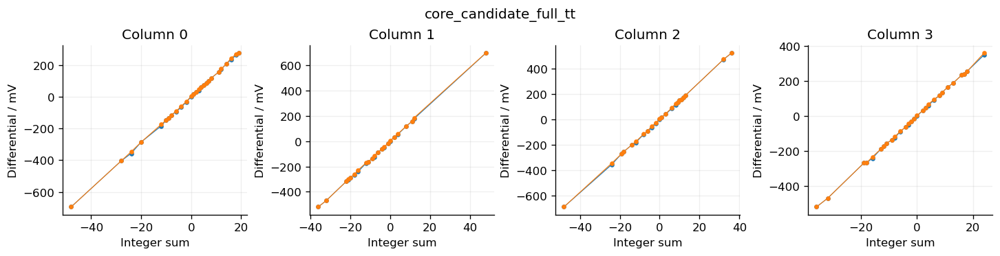

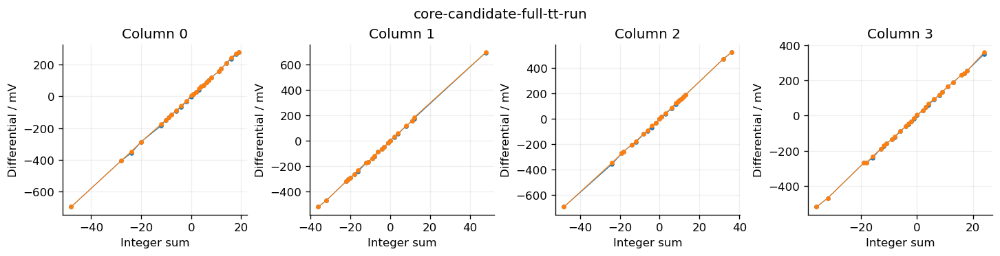

In [47]:
%%native_lab restored-archive-048
%%inline_module legacy_archive_048
from automx_nb_inline_v1.presentation import pretty
"""Screen the 800 fF/50 ps candidate over the 101 existing TT PEX patterns.

This is an evidence-preserving passive-core diagnostic, not ADC, noise, PVT,
wrapper or Stage-8 sign-off. It never overwrites Stage-4.5/4.8 receipts.
Completed per-case simulations may be reused only when deck, PEX, model,
ngspice version, log and measurement hashes still match.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path
import re
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.characterization import build_characterization  # noqa: E402
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.physical.stage5 import CORE, core_pins, parse_spice_subckt_pins  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_candidate_pex import make_pex_deck  # noqa: E402
from scripts.run_core_pex_coverage import Case  # noqa: E402

LOAD_FF = 800
PWM_UNIT_PS = 50
OUTPUT = Path("results/sky130/core_candidate_full_tt")
SAMPLE_TIMES = ("t19", "t21")


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _read(path: Path) -> dict[str, object]:
    value = json.loads(path.read_text(encoding="utf-8"))
    if not isinstance(value, dict):
        raise ValueError(f"expected JSON object: {path}")
    return value


def _expected() -> list[str]:
    return [f"diff_c{col}_t09" for col in range(4)] + [
        f"{kind}_c{col}_{time}" for time in SAMPLE_TIMES
        for col in range(4) for kind in ("diff", "blp", "bln")]


def selected_candidate(report: dict[str, object]) -> dict[str, object]:
    """The chosen point must actually have been measured and ordered in 4.8."""
    if (report.get("format") != "automx-cim-core-candidate-pex-v1" or
            report.get("status") != "MEASURED_PEX_SCREEN" or
            report.get("failures") or report.get("planned_sims") != 22 or
            report.get("completed_sims") != 22):
        raise ValueError("a complete measured Stage-4.8 PEX report is required")
    matches = [point for point in report.get("point_reports", [])
               if point.get("load_ff") == LOAD_FF and
               point.get("pwm_unit_ps") == PWM_UNIT_PS]
    if len(matches) != 1:
        raise ValueError("800 fF/50 ps was not measured in Stage-4.8")
    point = matches[0]
    transfer = point.get("selected_level_transfer", {})
    if (not point.get("all_selected_pairs_ordered") or
            point.get("polarity_mismatch_columns_at_two_times") != 0 or
            any(transfer.get(time, {}).get("adjacent_selected_level_overlap_count") != [0] * 4
                for time in ("1.9", "2.1"))):
        raise ValueError("800 fF/50 ps did not clear the selected Stage-4.8 screen")
    return point


def _provenance(root: Path) -> tuple[dict[str, object], dict[str, object], Path, Path]:
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    build_characterization(root, config)  # Revalidate Stage-4/5 source and receipt hashes.
    coverage_path = root / "results/receipts/physical/core_pex_coverage.json"
    candidate_path = root / "results/sky130/core_candidate_pex/measured.json"
    stage5_path = root / "results/receipts/physical/stage5_summary.json"
    coverage, candidate, stage5 = map(_read, (coverage_path, candidate_path, stage5_path))
    jobs = coverage.get("jobs", [])
    if (coverage.get("format") != "automx-cim-passive-core-pex-coverage-v1" or
            coverage.get("status") != "MEASURED_CORE_ONLY" or
            coverage.get("failures") or coverage.get("job_count") != 101 or
            coverage.get("completed_jobs") != 101 or len(jobs) != 101 or
            coverage.get("points") != [{"corner": "tt", "vdd_v": 1.8,
                                        "temperature_c": 25}] or
            len({job["case"] for job in jobs}) != 101 or
            any(not re.fullmatch(r"[A-Za-z0-9_]+", str(job["case"])) for job in jobs) or
            candidate.get("coverage_sha256") != _digest(coverage_path) or
            candidate.get("stage5_summary_sha256") != _digest(stage5_path)):
        raise ValueError("Stage-4.5/4.8 TT evidence is incomplete or stale")
    selected_candidate(candidate)
    if candidate.get("script_sha256") != _digest(root / "scripts/run_core_candidate_pex.py"):
        raise ValueError("Stage-4.8 generator changed after its measured report")
    pex = Path(stage5["views"]["extracted_spice"]["path"]).resolve()
    if (not pex.is_file() or _digest(pex) != stage5["views"]["extracted_spice"]["sha256"] or
            candidate.get("pex_sha256") != _digest(pex) or
            coverage.get("pex_sha256") != _digest(pex) or
            parse_spice_subckt_pins(pex, f"{CORE}_pex") != core_pins()):
        raise ValueError("Stage-5 PEX view changed")
    manifest = _read(root / "generated/sky130/spice/stage4_manifest.json")
    model = Path(manifest["model_library"]).resolve()
    if (not model.is_file() or candidate.get("model_sha256") != _digest(model) or
            coverage.get("model_library_sha256") != _digest(model)):
        raise ValueError("PDK model library changed")
    selected = set(candidate.get("selected_cases", []))
    by_case = {(item["load_ff"], item["pwm_unit_ps"], item["case"]): item
               for item in candidate.get("decks", [])}
    if len(selected) != 11 or not selected.issubset({job["case"] for job in jobs}) or any(
            (LOAD_FF, PWM_UNIT_PS, name) not in by_case or
            set(by_case[(LOAD_FF, PWM_UNIT_PS, name)].get("measurements", {})) !=
            set(_expected()) - {f"diff_c{col}_t09" for col in range(4)}
            for name in selected):
        raise ValueError("Stage-4.8 selected cases/decks are incomplete")
    for item in candidate["decks"]:
        deck = (root / item["deck"]).resolve()
        if not deck.is_relative_to(root) or not deck.is_file() or _digest(deck) != item["deck_sha256"]:
            raise ValueError(f"Stage-4.8 deck changed: {item['case']}")
    return coverage, candidate, model, pex


def analyze_transfer(jobs: list[dict[str, object]]) -> dict[str, object]:
    """Check measured level ranges, active zero and aperture at 1.9/2.1 ns.

    A positive gap is necessary for a static monotone scalar decoder on this
    *measured set*, but is never an ADC or unmeasured-pattern guarantee.
    """
    if not jobs or any("measurements_v" not in job for job in jobs):
        raise ValueError("all candidate jobs must have finite measurements")
    reports = {}
    for label, times in (("1.9", ("t19",)), ("2.1", ("t21",)),
                         ("1.9_to_2.1_pooled", SAMPLE_TIMES)):
        columns = []
        for col in range(4):
            levels: dict[int, list[float]] = {}
            active_zeros = []
            idle_zeros = []
            polarity_mismatches = 0
            for job in jobs:
                total = int(job["integer_sums"][col])
                activity = sum(abs(int(job["activation_x2"][row]) *
                                   int(job["ternary_weights"][row][col]))
                               for row in range(4))
                for time in times:
                    value = float(job["measurements_v"][f"diff_c{col}_{time}"])
                    if not math.isfinite(value):
                        raise ValueError(f"non-finite c{col} {time} in {job['case']}")
                    levels.setdefault(total, []).append(value)
                    if total == 0:
                        (active_zeros if activity else idle_zeros).append(abs(value))
                    elif value * total <= 0:
                        polarity_mismatches += 1
            ordered = sorted(levels)
            intervals = [{"sum": total, "min_diff_v": min(levels[total]),
                          "max_diff_v": max(levels[total]), "sample_count": len(levels[total])}
                         for total in ordered]
            gaps = [{"lower_sum": lower["sum"], "higher_sum": higher["sum"],
                     "gap_v": higher["min_diff_v"] - lower["max_diff_v"]}
                    for lower, higher in zip(intervals, intervals[1:])]
            columns.append({"column": col, "measured_sum_levels": len(ordered),
                            "min_adjacent_gap_v": min((gap["gap_v"] for gap in gaps), default=None),
                            "overlap_count": sum(gap["gap_v"] <= 0 for gap in gaps),
                            "worst_gap": min(gaps, key=lambda gap: gap["gap_v"]) if gaps else None,
                            "max_active_zero_abs_v": max(active_zeros, default=None),
                            "max_idle_zero_abs_v": max(idle_zeros, default=None),
                            "min_nonzero_abs_v": min((abs(x) for total, values in levels.items()
                                                       if total for x in values), default=None),
                            "polarity_mismatch_count": polarity_mismatches,
                            "intervals": intervals})
        reports[label] = {"all_measured_levels_ordered": all(
            column["overlap_count"] == 0 for column in columns),
            "columns": columns}
    shifts = [abs(float(job["measurements_v"][f"diff_c{col}_t21"]) -
                  float(job["measurements_v"][f"diff_c{col}_t19"]))
              for job in jobs for col in range(4)]
    all_ordered = all(sample["all_measured_levels_ordered"] and all(
        column["polarity_mismatch_count"] == 0 for column in sample["columns"])
        for sample in reports.values())
    return {"transfer_observation": "ORDERED_IN_MEASURED_SET" if all_ordered
            else "OVERLAP_OR_POLARITY_OBSERVED",
            "samples": reports, "max_1p9_to_2p1_shift_abs_v": max(shifts),
            "scope_warning": "101 TT passive-core PEX patterns only; no decoder/noise/PVT/ADC PASS"}


def _checkpoint(path: Path, *, deck_sha256: str, pex_sha256: str,
                model_sha256: str, ngspice_version: str, log: Path) -> dict[str, object] | None:
    if not path.is_file() or not log.is_file():
        return None
    try:
        receipt = _read(path)
        if (receipt.get("status") != "PASS" or
                receipt.get("deck_sha256") != deck_sha256 or
                receipt.get("pex_sha256") != pex_sha256 or
                receipt.get("model_sha256") != model_sha256 or
                receipt.get("ngspice_version") != ngspice_version or
                receipt.get("log_sha256") != _digest(log)):
            return None
        values = receipt.get("measurements_v", {})
        if set(values) != set(_expected()) or not all(math.isfinite(float(x)) for x in values.values()):
            return None
        return receipt
    except (OSError, ValueError, TypeError):
        return None


def _matches_selected(values: dict[str, float], selected_deck: dict[str, object] | None) -> bool:
    if selected_deck is None:
        return True
    return all(key in values and abs(values[key] - float(old)) <= 1e-3
               for key, old in selected_deck["measurements"].items())


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 180) -> dict[str, object]:
    root = Path(root).resolve()
    coverage, candidate, model, pex = _provenance(root)
    folder = root / OUTPUT / f"c{LOAD_FF}ff_pwm{PWM_UNIT_PS}ps"
    folder.mkdir(parents=True, exist_ok=True)
    selected = {(item["load_ff"], item["pwm_unit_ps"], item["case"]): item
                for item in candidate["decks"]}
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = ""
    if ngspice:
        response = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                  timeout=15, check=False)
        version = (response.stdout + response.stderr).strip()
    jobs = []
    for source in coverage["jobs"]:
        name = str(source["case"])
        case = Case(name, tuple(int(x) for x in source["activation_x2"]),
                    tuple(tuple(int(x) for x in row) for row in source["ternary_weights"]))
        if list(case.sums) != [int(value) for value in source["integer_sums"]]:
            raise ValueError(f"Stage-4.5 integer sums changed: {name}")
        deck = folder / f"{name}.spice"
        deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS), encoding="utf-8")
        digest = _digest(deck)
        matched = selected.get((LOAD_FF, PWM_UNIT_PS, name))
        if matched and digest != matched["deck_sha256"]:
            raise ValueError(f"selected Stage-4.8 deck differs at {name}")
        log = folder / f"{name}.log"
        checkpoint = folder / f"{name}.receipt.json"
        jobs.append({"case": name, "activation_x2": list(case.acts),
                     "ternary_weights": [list(row) for row in case.weights],
                     "integer_sums": list(case.sums),
                     "deck": str(deck.relative_to(root)), "deck_sha256": digest,
                     "log": str(log.relative_to(root)),
                     "checkpoint": str(checkpoint.relative_to(root))})
    for index, job in enumerate(jobs if execute and not failures else [], start=1):
        name = job["case"]
        deck, log, checkpoint = (root / job[key] for key in ("deck", "log", "checkpoint"))
        reused = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                             pex_sha256=_digest(pex), model_sha256=_digest(model),
                             ngspice_version=version, log=log)
        if reused:
            if not _matches_selected(reused["measurements_v"],
                                     selected.get((LOAD_FF, PWM_UNIT_PS, name))):
                failures.append(f"{name}: checkpoint differs from Stage-4.8 by >1 mV")
                break
            job["measurements_v"] = reused["measurements_v"]
            job["reused_checkpoint"] = True
            if index == 1 or index % 10 == 0 or index == len(jobs):
                print(f"Candidate TT PEX: {index}/{len(jobs)} cases complete ({name}, checkpoint)", flush=True)
            continue
        if log.is_file():
            log.unlink()  # Never parse stale output after a changed deck or failed run.
        try:
            result = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                    cwd=folder, text=True, capture_output=True,
                                    timeout=timeout_s, check=False)
        except subprocess.TimeoutExpired:
            failures.append(f"{name}: ngspice timeout after {timeout_s}s")
            break
        output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
        values = parse_measurements(output, _expected())
        if (result.returncode or len(values) != len(_expected()) or
                not all(math.isfinite(value) for value in values.values())):
            failures.append(f"{name}: ngspice exit {result.returncode}, incomplete measures; see {log}")
            break
        matched = selected.get((LOAD_FF, PWM_UNIT_PS, name))
        if not _matches_selected(values, matched):
            failures.append(f"{name}: Stage-4.8 sample differs by >1 mV")
            break
        job["measurements_v"] = values
        checkpoint.write_text(json.dumps({
            "status": "PASS", "deck_sha256": job["deck_sha256"],
            "pex_sha256": _digest(pex), "model_sha256": _digest(model),
            "ngspice_version": version, "log_sha256": _digest(log),
            "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        if index == 1 or index % 10 == 0 or index == len(jobs):
            print(f"Candidate TT PEX: {index}/{len(jobs)} cases complete ({name})", flush=True)
    completed = sum("measurements_v" in job for job in jobs)
    analysis = analyze_transfer(jobs) if execute and not failures and completed == 101 else None
    report = {"format": "automx-cim-core-candidate-full-tt-v1",
              "status": "FAIL" if failures else "MEASURED_TT_CANDIDATE_SCREEN" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "scope": "101-case 800 fF/50 ps TT passive-core PEX screen; not ADC/noise/PVT sign-off",
              "load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
              "stage4p5_sha256": _digest(root / "results/receipts/physical/core_pex_coverage.json"),
              "stage4p8_sha256": _digest(root / "results/sky130/core_candidate_pex/measured.json"),
              "stage5_summary_sha256": _digest(root / "results/receipts/physical/stage5_summary.json"),
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "ngspice_version": version or None,
              "planned_sims": len(jobs), "completed_sims": completed,
              "reused_checkpoints": sum(job.get("reused_checkpoint", False) for job in jobs),
              "analysis": analysis, "failures": failures, "jobs": jobs}
    target = root / OUTPUT / ("measured.json" if execute else "prepared.json")
    report["report_path"] = str(target.relative_to(root))
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items() if key != "jobs"}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/core_candidate_full_tt/measured.json'], label='core-candidate-full-tt-run')
history.plot_saved_transfer(ROOT, 'results/sky130/core_candidate_full_tt/measured.json', 'core-candidate-full-tt-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib, json
    import automx_nb_inline_v1.legacy_archive_048 as full_tt_module
    # inline module already loaded from this cell: full_tt_module
    RUN_CORE_CANDIDATE_FULL_TT = True  # verify/reuse checkpoints and refresh provenance
    if RUN_CORE_CANDIDATE_FULL_TT:
        candidate_full_tt = full_tt_module.run(ROOT, execute=True, timeout_s=600)
    else:
        saved = ROOT / 'results/sky130/core_candidate_full_tt/measured.json'
        candidate_full_tt = json.loads(saved.read_text(encoding='utf-8')) if saved.is_file() else None
    if candidate_full_tt is None:
        print('Candidate TT PEX: PENDING — copy the measured.json report from the server.')
    else:
        print('Candidate TT 101-case PEX:', candidate_full_tt['status'])
        print('Completed:', candidate_full_tt['completed_sims'], '/', candidate_full_tt['planned_sims'])
        if candidate_full_tt.get('analysis'):
            print('Transfer observation:', candidate_full_tt['analysis']['transfer_observation'])
        print('Report: results/sky130/core_candidate_full_tt/measured.json')
        print('Scope: passive-core TT diagnostic, not ADC/PVT sign-off')
        for problem in candidate_full_tt.get('failures', [])[:5]: print(' -', problem)
        if RUN_CORE_CANDIDATE_FULL_TT:
            if candidate_full_tt['status'] != 'MEASURED_TT_CANDIDATE_SCREEN':
                raise RuntimeError('Candidate TT screen failed; inspect report and ngspice logs.')
            if candidate_full_tt['analysis']['transfer_observation'] != 'ORDERED_IN_MEASURED_SET':
                raise RuntimeError('Candidate TT levels are unordered; 4.10/4.12 cannot use this report.')



### Remeasure the same stimuli: 800 fF / 50 ps

Retain the same PEX and two stimuli, changing only load/PWM. Check gap and
overlap from new logs.


<a id="guide-native-story-candidate_result"></a>

### Before cell `native-story-candidate_result` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-restored-archive-042`](#guide-native-restored-archive-042).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-candidate_result-candidate_result"></a>`candidate_result(root)` | Present the same pair's candidate load/PWM measurements against baseline, identifying which intervention changes the gap's sign. |

**Data and downstream use:** Follow the [contract described for `native-story-transfer_error`](#data-native-story-transfer_error).


In [48]:
%%native_lab story-candidate_result
%%inline_module story_candidate_result
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def candidate_result(root):
    data=read_report(root,BASE+'core_candidate_full_tt/measured.json')
    cols=data['analysis']['samples']['1.9']['columns']
    print('After load and PWM sweeps: C =',data['load_ff'],'fF; PWM =',data['pwm_unit_ps'],'ps;',data['completed_sims'],'/',data['planned_sims'],'native PEX jobs')
    table(['Column','Measured levels','Minimum gap / mV','Overlap'],[
        [c['column'],c['measured_sum_levels'],round(c['min_adjacent_gap_v']*1000,4),c['overlap_count']] for c in cols])
    return cols

# NOTEBOOK_RUN
fresh_candidate=fresh_pilot.measure_pair(ROOT,WORK,800,50)


RUN FRESH ngspice: sum12 load= 800 fF; PWM= 50 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm50/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm50/sum12.spice


NATIVE ngspice OUTPUT: sum12


RUN FRESH ngspice: sum11 load= 800 fF; PWM= 50 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm50/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm50/sum11.spice


NATIVE ngspice OUTPUT: sum11


[ngspice sum12] ******


[ngspice sum11] ******


... (1,156 outputs left out)

EXIT ngspice sum12 : 0 | elapsed_s: 9.985


| Case | Sum c0 | ΔV c0 @ 1.9 ns / V |
|---|---|---|
| sum11 | 11 | 0.15670890 |
| sum12 | 12 | 0.17626650 |

| Case | VDD energy, 0–3 ns / pJ |
|---|---|
| sum11 | 0.508288 |
| sum12 | 0.844094 |

Measured signed-level gap: 19.55759999999998 mV; overlap_count: 0


In [49]:
portable.export_factorial(get_ipython().user_ns,_design_review_namespace)


RUN FRESH ngspice: sum11 load= 200 fF; PWM= 50 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm50/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm50/sum11.spice


RUN FRESH ngspice: sum12 load= 200 fF; PWM= 50 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm50/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c200_pwm50/sum12.spice
NATIVE ngspice OUTPUT: sum11


RUN FRESH ngspice: sum11 load= 800 fF; PWM= 100 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm100/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm100/sum11.spice


NATIVE ngspice OUTPUT:NATIVE ngspice OUTPUT: sum11
 sum12


RUN FRESH ngspice: sum12 load= 800 fF; PWM= 100 ps; command: /home/nam/anaconda3/envs/env_mamba/bin/python -u /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm100/shared_pex_batch.py /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/tools/ngspice/libngspice.so /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/fresh_pex_c800_pwm100/sum12.spice


NATIVE ngspice OUTPUT: sum12


... (2,648 outputs left out)

EXIT ngspice sum11 : 0 | elapsed_s: 13.128


| Case | Sum c0 | ΔV c0 @ 1.9 ns / V |
|---|---|---|
| sum11 | 11 | 0.31005140 |
| sum12 | 12 | 0.34082350 |

| Case | VDD energy, 0–3 ns / pJ |
|---|---|
| sum11 | 0.898650 |
| sum12 | 1.369020 |

Measured signed-level gap: 30.772100000000023 mV; overlap_count: 0


## 3. Diagnose the physical failure: separate load from PWM

Keep both stimuli, PEX netlist, TT/1.8 V/25 °C, and sample time **1.9 ns** fixed. Change bitline load (200/800 fF) and PWM unit (50/100 ps) in a 2×2 experiment. The primary response is the signed **column-0 gap** $g=V(s=12)-V(s=11)$.

The original 200 fF/100 ps and 800 fF/50 ps conditions are prior verified native measurements. The two missing conditions were newly simulated for this study under a protocol written before measurement. All four are now supplied as recorded data. Each condition contains the same two physical patterns; this is a matched-pair diagnostic, not a full code-range sweep.

Read the actual `.measure` rows from ngspice logs, verify them against receipts, then compute load effects at fixed PWM, PWM effects at fixed load, and their interaction.

<a id="guide-factorial-result"></a>

### Before cell `factorial-result` — F5–F6

**Implementation:** Use the operation group explained in [cell `native-restored-archive-042`](#guide-native-restored-archive-042).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-factorial-result-parse_measurements"></a>`parse_measurements(text)` | Use regular expressions to extract ngspice measurement names/values from transcripts, enabling factorial calculations from actual logs. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-042`](#data-native-restored-archive-042).


| C / fF | PWM / ps | s11 / mV | s12 / mV | gap / mV | Acquisition |
| --- | --- | --- | --- | --- | --- |
| 200 | 50 | 548.8232 | 578.0703 | +29.2471 | new_native_current_run |
| 200 | 100 | 1030.2810 | 556.0328 | -474.2482 | new_native_current_run |
| 800 | 50 | 156.7089 | 176.2665 | +19.5576 | new_native_current_run |
| 800 | 100 | 310.0514 | 340.8235 | +30.7721 | new_native_current_run |

| Controlled effect | Change in signed gap / mV |
| --- | --- |
| Load effect at 50 ps | -9.6895 |
| Load effect at 100 ps | +505.0203 |
| PWM shortening at 200 fF | +503.4953 |
| PWM shortening at 800 fF | -11.2145 |
| Load × PWM interaction | -514.7098 |

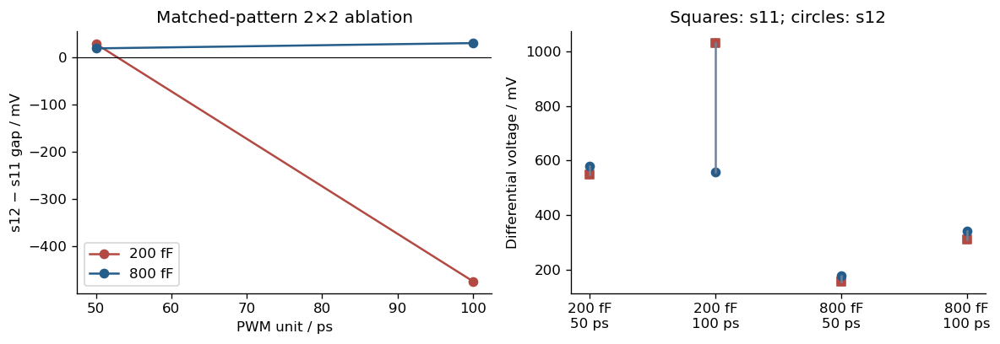

Current-run ngspice measurement block (unaltered numerical rows):
diff_c0_t09         =  3.393936e-01
diff_c0_t19         =  5.488232e-01
blp_c0_t19          =  1.166106e+00
bln_c0_t19          =  1.714929e+00
diff_c1_t09         =  -5.368984e-01
diff_c1_t19         =  -5.558861e-01
blp_c1_t19          =  1.777432e+00
bln_c1_t19          =  1.221546e+00
diff_c2_t09         =  -6.816086e-01
diff_c2_t19         =  -8.769683e-01
blp_c2_t19          =  1.650244e+00
bln_c2_t19          =  7.732757e-01
diff_c3_t09         =  4.436477e-01
diff_c3_t19         =  6.521174e-01
blp_c3_t19          =  1.121292e+00
bln_c3_t19          =  1.773409e+00
diff_c0_t21         =  5.488678e-01
blp_c0_t21          =  1.165913e+00
bln_c0_t21          =  1.714781e+00
diff_c1_t21         =  -5.559088e-01
blp_c1_t21          =  1.777279e+00
bln_c1_t21          =  1.221370e+00
diff_c2_t21         =  -8.768184e-01
blp_c2_t21          =  1.650093e+00
bln_c2_t21          =  7.732750e-01
diff_c3_t21         =  6.521

In [50]:
%%design_review factorial-result
def parse_measurements(text):
    matches=re.findall(r'^\s*((?:diff|blp|bln)_c\d_t(?:09|19|21))\s*=\s*([-+\deE.]+)',text,re.M)
    if len(matches)!=28 or len(dict(matches))!=28: raise ValueError('incomplete/duplicate PEX measures')
    values={k:float(v) for k,v in matches}
    if not all(np.isfinite(list(values.values()))): raise ValueError('nonfinite PEX measures')
    return values
gaps={}; rows=[]
for condition in E['factorial']:
    c,p=condition['load_ff'],condition['pwm_unit_ps']; voltages=[]
    for job in condition['jobs']:
        measures=parse_measurements((BASE/job['log']).read_text())
        if any(not np.isclose(measures[k],v,rtol=0,atol=1e-12)
               for k,v in job['measurements_v'].items()): raise ValueError('PEX log/receipt mismatch')
        if int(np.asarray(job['activation_x2']) @ np.asarray(job['ternary_weights'])[:,0])!=job['integer_sums'][0]:
            raise ValueError('PEX stimulus/reference mismatch')
        voltages.append(measures['diff_c0_t19'])
    gap=voltages[1]-voltages[0]; gaps[c,p]=gap
    rows.append([c,p,*[f'{v*1000:.4f}' for v in voltages],f'{gap*1000:+.4f}',condition['acquisition']])
table(['C / fF','PWM / ps','s11 / mV','s12 / mV','gap / mV','Acquisition'],rows)
effects={
    'Load effect at 50 ps':gaps[800,50]-gaps[200,50],
    'Load effect at 100 ps':gaps[800,100]-gaps[200,100],
    'PWM shortening at 200 fF':gaps[200,50]-gaps[200,100],
    'PWM shortening at 800 fF':gaps[800,50]-gaps[800,100]}
interaction=effects['Load effect at 50 ps']-effects['Load effect at 100 ps']
table(['Controlled effect','Change in signed gap / mV'],[[k,f'{v*1000:+.4f}'] for k,v in effects.items()]+
      [['Load × PWM interaction',f'{interaction*1000:+.4f}']])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for c,color in [(200,'#b24a43'),(800,'#245c8a')]:
    axes[0].plot([50,100],[gaps[c,50]*1000,gaps[c,100]*1000],'o-',label=f'{c} fF',color=color)
axes[0].axhline(0,color='black',lw=.7); axes[0].set(xlabel='PWM unit / ps',ylabel='s12 − s11 gap / mV',title='Matched-pattern 2×2 ablation')
axes[0].legend()
for i,condition in enumerate(E['factorial']):
    v=[j['measurements_v']['diff_c0_t19']*1000 for j in condition['jobs']]
    axes[1].plot([i,i],v,color='#718096'); axes[1].scatter(i,v[0],marker='s',color='#b24a43')
    axes[1].scatter(i,v[1],marker='o',color='#245c8a')
axes[1].set_xticks(range(4),[f"{r['load_ff']} fF\n{r['pwm_unit_ps']} ps" for r in E['factorial']])
axes[1].set(ylabel='Differential voltage / mV',title='Squares: s11; circles: s12')
savefig('factorial.png')
print('Current-run ngspice measurement block (unaltered numerical rows):')
example=E['factorial'][0]['jobs'][0]
for line in (BASE/example['log']).read_text().splitlines():
    if re.match(r'^\s*(?:diff|blp|bln)_c\d_t',line): print(line)


### What changed the design decision?

A negative gap means these two increasing sums have reversed voltage ordering at the chosen sample time. A positive gap permits a threshold between this pair. **Either intervention alone restores ordering for this pair:** shortening PWM at 200 fF produces +29.2472 mV; increasing load at 100 ps produces +30.7722 mV. Combining the changes gives +19.5577 mV, so the effects are not additive. The load effect is −9.6895 mV at 50 ps but +505.0266 mV at 100 ps; the difference is a −514.7161 mV interaction. Thus the data support considering the shorter pulse before automatically paying for four times the load. This pair alone does not select a globally optimal operating point or establish energy savings.

This PEX investigation motivates how the operating point is selected. The following directly coupled CIM/ADC experiment is a separate schematic/partition measurement, connected by the same integer-sum contract; its ADC codes are not inferred from this two-pattern PEX table.

### Decision 1 — the intervention is conditional on the operating point

PWM shortening alone at 200 fF yields **+29.2472 mV**; increasing load alone at
100 ps yields **+30.7722 mV**. Combining them yields **+19.5577 mV**, with a
**−514.7161 mV interaction**. Thus the experiment supports considering the
shorter pulse before automatically increasing capacitance fourfold. It also
shows why the original two-condition comparison could not attribute the gain
to one knob.

The earlier 800 fF / 50 ps candidate and its implementation records remain
above as acquired evidence. The new factorial is a diagnostic comparison;
it does not retroactively change the circuit or operating point used by the
subsequent coupled ADC experiment.

**Next question:** does a repaired ordering for one pair provide enough
information to decode other physical patterns? Test the readout separately.


<a id="argument-readout"></a>

# 4. Investigate decoding, acquisition and transaction structure

The historical experiments below broaden the question from one voltage gap
to a decoder and its physical input. Their scalar-decoder investigation records
52/128 errors, explores calibration/features, and studies a two-read **2+2**
decomposition with its own calibration and holdout. Sampling load, hold timing,
reset and transaction checks then connect the readout to its controller.

These are distinct experiment families. A decoder trained for one acquisition
or read partition belongs to that partition. The 2+2 branch is preserved as an
explored alternative with its own reported results; the final coupled SAR/MHA
experiment below directly measures its declared four-row input on one reused
physical column.

**Decision 2:** preserve the complete stimulus and acquisition contract, freeze
calibration before holdout, and retain raw residuals as well as rounded sums.
**Next test:** acquire actual coupled analog/SAR conversions and independently
verify their codes, control states and EOC.


### 4.10 Independent MHA holdout

Measure 16 new patterns after selecting the candidate. The combined 117-case
report retains ordered levels in the measured set; these holdout data then
support decoder evaluation.


**Equation / measurement relation:** $$R_{\rm holdout}=N_{\rm decode\ errors}/N_{\rm holdout\ samples}$$

<a id="guide-native-restored-archive-051"></a>

### Before cell `native-restored-archive-051` — F6–F7

**Implementation:** Generate holdout patterns and evaluate them using frozen calibration. Reusing fitting patterns would not test decoding of new data.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-051-heldout_cases"></a>`heldout_cases(config: Sky130MHAConfig, baseline_jobs: list[dict[str, object]])` | Generate new patterns from an MHA schedule or deterministic ranking, exclude previously used payloads, and return independent test cases. |
| <a id="fn-native-restored-archive-051-_verified_stage49"></a>`_verified_stage49(root: Path, coverage: dict[str, object], candidate: dict[str, object], model: Path, pex: Path)` | Validate that netlist/model/candidate and Stage4.9 reports share provenance before accepting the baseline calibration for holdout. |
| <a id="fn-native-restored-archive-051-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=180)` | Orchestrate new MHA holdout measurements with fixed candidate/fit: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

<a id="data-native-restored-archive-051"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive MHA configuration, used payloads, validated candidate/model/PEX/calibration; new activations/weights must not overlap the earlier set.
- **Return values and saved artifacts:** Write fresh holdout decks/logs with metadata and measurement/decoded-error reports, retaining the calibration fit and circuit conditions for an independent comparison.
- **Downstream consumers:** analyze_decoder/analyze_feature_holdout and holdout tables read this report without feeding it back into training-threshold adjustment.


In [51]:
%%native_lab restored-archive-051
%%inline_module legacy_archive_051
from automx_nb_inline_v1.presentation import pretty
"""Measure 16 previously unseen MHA-derived TT PEX cases at 800 fF/50 ps.

Requires a complete, ordered 101-case cell-4.9 report. The held-out cases are
not used by the 4.5/4.7/4.8/4.9 selection screens. This is a diagnostic,
not a noise, ADC, PVT or wrapper sign-off receipt.
"""


import argparse
from datetime import datetime, timezone
import json
import math
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_candidate_full_tt import (  # noqa: E402
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    _read, analyze_transfer,
)
from scripts.run_core_candidate_pex import make_pex_deck  # noqa: E402
from scripts.run_core_pex_coverage import Case, mha_cases  # noqa: E402

OUTPUT = Path("results/sky130/post49_holdout_tt")


def heldout_cases(config: Sky130MHAConfig, baseline_jobs: list[dict[str, object]]) -> list[Case]:
    """Reserve deterministic MHA ranks 16–31, rejecting any earlier vector."""
    previous = {
        (tuple(int(value) for value in job["activation_x2"]),
         tuple(tuple(int(value) for value in row) for row in job["ternary_weights"]))
        for job in baseline_jobs
    }
    cases = mha_cases(config, 32)[16:32]
    if len(cases) != 16 or any((case.acts, case.weights) in previous for case in cases):
        raise ValueError("MHA ranks 16–31 are not an independent held-out set")
    return cases


def _verified_stage49(root: Path, coverage: dict[str, object], candidate: dict[str, object],
                      model: Path, pex: Path) -> dict[str, object]:
    path = root / "results/sky130/core_candidate_full_tt/measured.json"
    if not path.is_file():
        raise ValueError(f"cell 4.9 measured report is missing: {path}")
    report = _read(path)
    jobs = report.get("jobs", [])
    analysis = report.get("analysis") if isinstance(report.get("analysis"), dict) else {}
    checks = {
        "report format": report.get("format") == "automx-cim-core-candidate-full-tt-v1",
        "measurement status": report.get("status") == "MEASURED_TT_CANDIDATE_SCREEN",
        "no failures": not report.get("failures"),
        "101 planned simulations": report.get("planned_sims") == 101,
        "101 completed simulations": report.get("completed_sims") == 101,
        "101 case records": isinstance(jobs, list) and len(jobs) == 101,
        "800 fF load": report.get("load_ff") == LOAD_FF,
        "50 ps PWM unit": report.get("pwm_unit_ps") == PWM_UNIT_PS,
        "cell 4.5 receipt hash": report.get("stage4p5_sha256") == _digest(
            root / "results/receipts/physical/core_pex_coverage.json"),
        "cell 4.8 report hash": report.get("stage4p8_sha256") == _digest(
            root / "results/sky130/core_candidate_pex/measured.json"),
        "Stage-5 summary hash": report.get("stage5_summary_sha256") == _digest(
            root / "results/receipts/physical/stage5_summary.json"),
        "PEX hash": report.get("pex_sha256") == _digest(pex),
        "PDK model hash": report.get("model_sha256") == _digest(model),
        "ordered measured levels": analysis.get("transfer_observation") ==
        "ORDERED_IN_MEASURED_SET",
    }
    failed = [name for name, passed in checks.items() if not passed]
    if failed:
        raise ValueError("cell 4.9 is missing, stale, incomplete or unordered; failed: "
                         + ", ".join(failed))
    baseline = {str(job["case"]): job for job in coverage["jobs"]}
    if len(baseline) != 101 or {job["case"] for job in jobs} != set(baseline):
        raise ValueError("cell 4.9 case set differs from cell 4.5")
    for job in jobs:
        original = baseline[job["case"]]
        if (job["activation_x2"] != original["activation_x2"] or
                job["ternary_weights"] != original["ternary_weights"] or
                job["integer_sums"] != original["integer_sums"] or
                set(job.get("measurements_v", {})) != set(_expected()) or
                not all(math.isfinite(float(value)) for value in job["measurements_v"].values())):
            raise ValueError(f"cell 4.9 case data incomplete: {job['case']}")
        deck = (root / job["deck"]).resolve()
        if not deck.is_relative_to(root) or not deck.is_file() or _digest(deck) != job["deck_sha256"]:
            raise ValueError(f"cell 4.9 deck changed: {job['case']}")
    if analyze_transfer(jobs)["transfer_observation"] != "ORDERED_IN_MEASURED_SET":
        raise ValueError("cell 4.9 raw measurements are unordered; reject cached summary")
    if candidate.get("status") != "MEASURED_PEX_SCREEN":
        raise ValueError("cell 4.8 PEX evidence changed")
    return report


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 180) -> dict[str, object]:
    root = Path(root).resolve()
    coverage, candidate, model, pex = _provenance(root)
    stage49 = _verified_stage49(root, coverage, candidate, model, pex)
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    cases = heldout_cases(config, coverage["jobs"])
    folder = root / OUTPUT
    folder.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = ""
    if ngspice:
        response = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                  timeout=15, check=False)
        version = (response.stdout + response.stderr).strip()
    jobs = []
    for case in cases:
        deck = folder / f"{case.name}.spice"
        deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS),
                        encoding="utf-8")
        jobs.append({"case": case.name, "activation_x2": list(case.acts),
                     "ternary_weights": [list(row) for row in case.weights],
                     "integer_sums": list(case.sums),
                     "deck": str(deck.relative_to(root)), "deck_sha256": _digest(deck),
                     "log": str((folder / f"{case.name}.log").relative_to(root)),
                     "checkpoint": str((folder / f"{case.name}.receipt.json").relative_to(root))})
    for index, job in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (root / job[key] for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            job["measurements_v"] = saved["measurements_v"]
            job["reused_checkpoint"] = True
            print(f"Holdout PEX: {index}/{len(jobs)} ({job['case']}, checkpoint)", flush=True)
            continue
        if log.is_file():
            log.unlink()
        try:
            completed = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                       cwd=folder, text=True, capture_output=True,
                                       timeout=timeout_s, check=False)
        except subprocess.TimeoutExpired:
            failures.append(f"{job['case']}: timeout after {timeout_s}s")
            break
        content = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
        values = parse_measurements(content, _expected())
        if completed.returncode or set(values) != set(_expected()) or not all(
                math.isfinite(value) for value in values.values()):
            failures.append(f"{job['case']}: incomplete ngspice result; inspect {log}")
            break
        job["measurements_v"] = values
        checkpoint.write_text(json.dumps({
            "status": "PASS", "deck_sha256": job["deck_sha256"],
            "pex_sha256": _digest(pex), "model_sha256": _digest(model),
            "ngspice_version": version, "log_sha256": _digest(log),
            "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        print(f"Holdout PEX: {index}/{len(jobs)} ({job['case']})", flush=True)
    completed = sum("measurements_v" in job for job in jobs)
    combined = (analyze_transfer(stage49["jobs"] + jobs)
                if execute and not failures and completed == 16 else None)
    report = {"format": "automx-cim-post49-holdout-tt-v1",
              "status": "FAIL" if failures else "MEASURED_HOLDOUT_TT" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "scope": "16 new deterministic MHA-derived cases plus 101 prior TT PEX cases; no ADC/noise/PVT PASS",
              "load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
              "stage49_sha256": _digest(root / "results/sky130/core_candidate_full_tt/measured.json"),
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "ngspice_version": version or None,
              "heldout_case_names": [case.name for case in cases],
              "planned_sims": len(jobs), "completed_sims": completed,
              "reused_checkpoints": sum(job.get("reused_checkpoint", False) for job in jobs),
              "combined_117_case_analysis": combined,
              "failures": failures, "jobs": jobs}
    target = folder / ("measured.json" if execute else "prepared.json")
    report["report_path"] = str(target.relative_to(root))
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items() if key != "jobs"}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_holdout_tt/measured.json'], label='post49-holdout-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import json
    import automx_nb_inline_v1.legacy_archive_051 as holdout_module
    # inline module already loaded from this cell: holdout_module
    RUN_POST49_HOLDOUT_TT = True  # verify/reuse checkpoints and refresh provenance
    stage49_path = ROOT / 'results/sky130/core_candidate_full_tt/measured.json'
    stage49_saved = json.loads(stage49_path.read_text(encoding='utf-8')) if stage49_path.is_file() else {}
    stage49_ordered = (stage49_saved.get('status') == 'MEASURED_TT_CANDIDATE_SCREEN' and
                       (stage49_saved.get('analysis') or {}).get('transfer_observation') == 'ORDERED_IN_MEASURED_SET')
    if not stage49_ordered:
        print('Holdout PENDING: cell 4.9 must be measured and ordered; review its transfer report first.')
    else:
        if RUN_POST49_HOLDOUT_TT:
            holdout_tt = holdout_module.run(ROOT, execute=True, timeout_s=600)
        else:
            saved = ROOT / 'results/sky130/post49_holdout_tt/measured.json'
            holdout_tt = json.loads(saved.read_text(encoding='utf-8')) if saved.is_file() else None
        if holdout_tt is None:
            print('Holdout PENDING — copy the measured.json report from the server.')
        else:
            print('Independent TT holdout:', holdout_tt['status'])
            print('Completed:', holdout_tt['completed_sims'], '/', holdout_tt['planned_sims'])
            combined = holdout_tt.get('combined_117_case_analysis')
            if combined: print('Combined 117-case transfer:', combined['transfer_observation'])
            print('Report: results/sky130/post49_holdout_tt/measured.json')
            if RUN_POST49_HOLDOUT_TT and holdout_tt['status'] == 'FAIL':
                raise RuntimeError('Holdout TT PEX failed; inspect report and ngspice logs.')



| measured | Result |
|---|---|
| combined_117_case_analysis.samples.1.9.columns[0].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9.columns[1].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9.columns[2].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9.columns[3].overlap_count | 0 |
| combined_117_case_analysis.samples.2.1.columns[0].overlap_count | 0 |
| combined_117_case_analysis.samples.2.1.columns[1].overlap_count | 0 |
| combined_117_case_analysis.samples.2.1.columns[2].overlap_count | 0 |
| combined_117_case_analysis.samples.2.1.columns[3].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9_to_2.1_pooled.columns[0].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9_to_2.1_pooled.columns[1].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9_to_2.1_pooled.columns[2].overlap_count | 0 |
| combined_117_case_analysis.samples.1.9_to_2.1_pooled.columns[3].overlap_count | 0 |

Source: `results/sky130/post49_holdout_tt/measured.json` · 2026-10-13T13:40:58.017171+00:00

<a id="guide-native-restored-archive-054"></a>

### Before cell `native-restored-archive-054` — F6–F7

**Implementation:** Analyze level overlap, decoder thresholds, calibration coverage, and readout features. Correct computation requires decoded-error counts and identification of missing/ambiguous levels, beyond observing voltages.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_read(path: Path)` | Same task as [`_read`](#fn-native-restored-archive-048-_read). |
| `_sha(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-054-_spec_gaps"></a>`_spec_gaps(spec: dict[str, object] \| None)` | Read conditions/missing evidence in a specification report so the inspection table identifies requirements lacking supporting data. |
| <a id="fn-native-restored-archive-054-_baseline_gaps"></a>`_baseline_gaps(spec: dict[str, object] \| None)` | Summarize missing baseline-prototype conditions separately from signoff checks so inspection does not conflate the two evidence levels. |
| <a id="fn-native-restored-archive-054-inspect"></a>`inspect(root: str \| Path)` | Read specifications and baseline/candidate reports, classify achieved/missing/unmeasured conditions, and return an inspection distinguishing prototype results from signoff. |

<a id="data-native-restored-archive-054"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive training/holdout reports containing stimuli, columns, sample times, differential/common-mode voltages, and voltage-noise/error budgets; recompute labels from inputs.
- **Return values and saved artifacts:** Return midpoint thresholds/feature predictors, reachable-level tables, confusion/error counts, and training-based selections; analysis reads/computes rather than launching ADC simulation.
- **Downstream consumers:** Difficult-case selection and the 2+2 recipe use measured errors to change protocol; fitting and evaluation sources remain separate through partition/calibration.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-219"></a>`common-mode` | The average voltage of two differential nodes, distinct from the voltage difference encoding products/sums. |


In [52]:
%%native_lab restored-archive-054
%%inline_module legacy_archive_054
from automx_nb_inline_v1.presentation import pretty
"""Read-only inventory of work packages after notebook cell 4.9.

This planner never grants analog, ADC, wrapper, or Stage-8 sign-off. The
individual measurement runners and Stage-8 preflight/audit remain the gates.
"""


import argparse
from hashlib import sha256
import json
import math
from pathlib import Path
import sys


ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))
from automx_cim.openlane import locate_openlane_flow


def _read(path: Path) -> dict[str, object] | None:
    if not path.is_file():
        return None
    try:
        value = json.loads(path.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        return None
    return value if isinstance(value, dict) else None


def _sha(path: Path) -> str | None:
    return sha256(path.read_bytes()).hexdigest() if path.is_file() else None


def _spec_gaps(spec: dict[str, object] | None) -> list[str]:
    if not spec or spec.get("format") != "automx-cim-post49-requirements-v1":
        return ["requirements file missing or malformed"]
    gaps = []
    for section, fields in {
        "decoder": ("architecture", "uses_common_mode", "calibration_method"),
        "timing": ("sample_time_ns", "aperture_start_ns", "aperture_end_ns", "cycle_time_ns"),
        "acceptance": ("minimum_adjacent_code_margin_v",
                       "maximum_input_referred_offset_abs_v",
                       "maximum_input_referred_noise_rms_v",
                       "maximum_decode_error_rate", "minimum_holdout_patterns",
                       "maximum_reference_threshold_error_abs_v",
                       "maximum_aperture_induced_shift_abs_v"),
        "review": ("cell49_report", "heldout_report", "approved_by", "approval_date"),
    }.items():
        data = spec.get(section, {})
        for field in fields:
            if not isinstance(data, dict) or data.get(field) is None or data.get(field) == "":
                gaps.append(f"{section}.{field}")
    timing = spec.get("timing", {})
    timing_keys = ("sample_time_ns", "aperture_start_ns", "aperture_end_ns", "cycle_time_ns")
    if isinstance(timing, dict):
        for key in timing_keys:
            value = timing.get(key)
            if value is not None and (not isinstance(value, (int, float)) or
                                      not math.isfinite(value) or value <= 0):
                gaps.append(f"timing.{key} must be a finite positive number")
        if all(isinstance(timing.get(key), (int, float)) and math.isfinite(timing[key])
               for key in timing_keys) and not (
                0 < timing["aperture_start_ns"] <= timing["sample_time_ns"] <=
                timing["aperture_end_ns"] < timing["cycle_time_ns"]):
            gaps.append("timing aperture/sample/cycle order")
    acceptance = spec.get("acceptance", {})
    if isinstance(acceptance, dict):
        for key in ("minimum_adjacent_code_margin_v",
                    "maximum_input_referred_offset_abs_v",
                    "maximum_input_referred_noise_rms_v",
                    "maximum_decode_error_rate",
                    "maximum_reference_threshold_error_abs_v",
                    "maximum_aperture_induced_shift_abs_v"):
            value = acceptance.get(key)
            if value is not None and (not isinstance(value, (int, float)) or
                                      not math.isfinite(value) or value < 0):
                gaps.append(f"acceptance.{key} must be a finite nonnegative number")
        value = acceptance.get("minimum_holdout_patterns")
        if value is not None and (not isinstance(value, int) or value < 16):
            gaps.append("acceptance.minimum_holdout_patterns must be at least 16")
        rate = acceptance.get("maximum_decode_error_rate")
        if isinstance(rate, (int, float)) and math.isfinite(rate) and rate > 1:
            gaps.append("acceptance.maximum_decode_error_rate must not exceed 1")
        budget_keys = ("minimum_adjacent_code_margin_v",
                       "maximum_input_referred_offset_abs_v",
                       "maximum_input_referred_noise_rms_v",
                       "maximum_reference_threshold_error_abs_v",
                       "maximum_aperture_induced_shift_abs_v")
        if all(isinstance(acceptance.get(key), (int, float)) and
               math.isfinite(acceptance[key]) for key in budget_keys):
            total = (acceptance["maximum_input_referred_offset_abs_v"] +
                     5 * acceptance["maximum_input_referred_noise_rms_v"] +
                     acceptance["maximum_reference_threshold_error_abs_v"] +
                     acceptance["maximum_aperture_induced_shift_abs_v"])
            if 2 * total >= acceptance["minimum_adjacent_code_margin_v"]:
                gaps.append("acceptance five-sigma error budget exceeds half adjacent gap")
    pvt = spec.get("pvt_plan", {})
    if not isinstance(pvt, dict) or not pvt.get("pdk_model_support_verified"):
        gaps.append("pvt_plan.pdk_model_support_verified")
    if not isinstance(pvt, dict) or not isinstance(pvt.get("approved_matrix"), list) or not pvt["approved_matrix"]:
        gaps.append("pvt_plan.approved_matrix")
    if spec.get("status") != "APPROVED":
        gaps.append("status=APPROVED after review")
    return gaps


def _baseline_gaps(spec: dict[str, object] | None) -> list[str]:
    """Decisions needed to freeze a prototype, separate from sign-off evidence."""
    if not spec or spec.get("format") != "automx-cim-post49-requirements-v1":
        return ["requirements file missing or malformed"]
    fields = {
        "decoder": ("architecture", "uses_common_mode", "calibration_method"),
        "timing": ("sample_time_ns", "aperture_start_ns", "aperture_end_ns", "cycle_time_ns"),
        "acceptance": ("minimum_adjacent_code_margin_v",
                       "maximum_input_referred_offset_abs_v",
                       "maximum_input_referred_noise_rms_v",
                       "maximum_decode_error_rate", "minimum_holdout_patterns",
                       "maximum_reference_threshold_error_abs_v",
                       "maximum_aperture_induced_shift_abs_v"),
    }
    gaps = []
    for section, keys in fields.items():
        data = spec.get(section)
        for key in keys:
            if not isinstance(data, dict) or data.get(key) is None or data.get(key) == "":
                gaps.append(f"{section}.{key}")
    for gap in _spec_gaps(spec):
        if gap.startswith(("timing.", "acceptance.")) and gap not in gaps:
            gaps.append(gap)
    if spec.get("status") not in ("DESIGN_BASELINE_FROZEN_UNVERIFIED", "APPROVED"):
        gaps.append("status=DESIGN_BASELINE_FROZEN_UNVERIFIED")
    return gaps


def inspect(root: str | Path) -> dict[str, object]:
    root = Path(root).resolve()
    path49 = root / "results/sky130/core_candidate_full_tt/measured.json"
    stage49 = _read(path49)
    stage5_path = root / "results/receipts/physical/stage5_summary.json"
    stage5_summary = _read(stage5_path) or {}
    stage4_manifest = _read(root / "generated/sky130/spice/stage4_manifest.json") or {}
    stage49_inputs = {
        "stage4p5_sha256": root / "results/receipts/physical/core_pex_coverage.json",
        "stage4p8_sha256": root / "results/sky130/core_candidate_pex/measured.json",
        "stage5_summary_sha256": stage5_path,
    }
    stage5_views = stage5_summary.get("views")
    pex_view = ((stage5_views.get("extracted_spice") or {})
                if isinstance(stage5_views, dict) else {})
    if isinstance(pex_view.get("path"), str):
        stage49_inputs["pex_sha256"] = Path(pex_view["path"])
    if isinstance(stage4_manifest.get("model_library"), str):
        stage49_inputs["model_sha256"] = Path(stage4_manifest["model_library"])
    stale_stage49_inputs = [name for name, path in stage49_inputs.items()
                            if stage49 and stage49.get(name) != _sha(path)]
    stage49_jobs = stage49.get("jobs") if isinstance((stage49 or {}).get("jobs"), list) else []
    stage49_stale = bool(stage49 and
                          stage49.get("status") == "MEASURED_TT_CANDIDATE_SCREEN" and
                          stale_stage49_inputs)
    stage49_measured = bool(stage49 and
                            stage49.get("status") == "MEASURED_TT_CANDIDATE_SCREEN" and
                            stage49.get("completed_sims") == 101 and
                            stage49.get("planned_sims") == 101 and
                            len(stage49_jobs) == 101 and
                            stage49.get("load_ff") == 800 and
                            stage49.get("pwm_unit_ps") == 50 and
                            not stage49.get("failures") and
                            not stale_stage49_inputs)
    stage49_partial = bool(stage49 and stage49.get("status") == "FAIL" and
                           isinstance(stage49.get("completed_sims"), int) and
                           0 < stage49["completed_sims"] < 101)
    observation = ((stage49 or {}).get("analysis") or {}).get("transfer_observation")
    ordered = stage49_measured and observation == "ORDERED_IN_MEASURED_SET"
    holdout_path = root / "results/sky130/post49_holdout_tt/measured.json"
    holdout = _read(holdout_path)
    heldout_measured = bool(holdout and
                            holdout.get("status") == "MEASURED_HOLDOUT_TT" and
                            holdout.get("stage49_sha256") == _sha(path49) and
                            holdout.get("completed_sims") == 16 and
                            holdout.get("planned_sims") == 16 and
                            not holdout.get("failures"))
    combined_observation = (((holdout or {}).get("combined_117_case_analysis") or {})
                            .get("transfer_observation"))
    spec_path = root / "configs/sky130_post49_requirements.json"
    spec = _read(spec_path)
    spec_gaps = _spec_gaps(spec)
    baseline_gaps = _baseline_gaps(spec)
    wrapper_root = root / "physical/sky130/wrapper"
    stem = "automx_ternary_cim_4x4"
    views = {extension: (wrapper_root / f"{stem}.{extension}")
             for extension in ("gds", "lef", "lib", "spef")}
    missing_views = [str(path.relative_to(root)) for path in views.values()
                     if not path.is_file() or path.stat().st_size == 0]
    signoff = _read(root / "results/receipts/wrapper_signoff.json")
    config = _read(root / "openlane/automx_cim_tile_controller/config.json") or {}
    placement = config.get("MACRO_PLACEMENT_CFG")
    placement_ready = False
    if isinstance(placement, str) and placement.startswith("dir::"):
        target = (root / "openlane/automx_cim_tile_controller" /
                  placement.removeprefix("dir::")).resolve()
        placement_ready = target.is_relative_to(root) and target.is_file()
    die_ready = bool(config.get("DIE_AREA") and config["DIE_AREA"] != "0 0 1200 1200")
    flow_ready = locate_openlane_flow() is not None
    preflight = _read(root / "results/receipts/stage8_preflight.json")
    audit = _read(root / "results/receipts/stage8_final_audit.json")
    packages = {
        "A_tt_full_and_holdout": {
            "status": ("DEFERRED_PARTIAL_TT_SCREEN" if stage49_partial else
                       "STALE_CELL_4_9" if stage49_stale else
                       "PENDING_OPTIONAL_CELL_4_9" if not stage49_measured else
                       "REDESIGN_REQUIRED" if not ordered else
                       "READY_FOR_HOLDOUT" if not heldout_measured else
                       "MEASURED_DIAGNOSTIC"),
            "cell49_transfer_observation": observation,
            "cell49_completed_sims": (stage49 or {}).get("completed_sims"),
            "cell49_failures": (stage49 or {}).get("failures", []),
            "cell49_stale_inputs": stale_stage49_inputs,
            "holdout_transfer_observation": combined_observation,
            "next": ("Proceed with Stage 7 and Stage-8 preparation; keep ADC/wrapper sign-off pending" if stage49_partial else
                     "Rerun the measured cell 4.9 to refresh its source hashes, then cell 4.10" if stage49_stale else
                     "Cell 4.9 is optional for digital-flow progress; run it before analog sign-off" if not stage49_measured else
                     "Redesign core/stimulus; do not assert static ADC decoding" if not ordered else
                     "Run cell 4.10 with RUN_POST49_HOLDOUT_TT=True" if not heldout_measured else
                     "Review held-out overlaps, zero, common-mode and aperture; extend analog evidence"),
        },
        "B_adc_pvt_requirements": {
            "status": ("SPEC_DRAFT" if baseline_gaps else
                       "DESIGN_BASELINE_FROZEN_EVIDENCE_PENDING" if spec_gaps else
                       "SPEC_APPROVED_NOT_MEASURED"),
            "missing_decisions": baseline_gaps,
            "missing_evidence_or_review": [gap for gap in spec_gaps if gap not in baseline_gaps],
            "next": ("Resolve prototype decoder/timing/budget choices" if baseline_gaps else
                     "Build and measure sense/ADC; verify continuous aperture, noise/offset, full transfer and PVT; obtain human review before APPROVED" if spec_gaps else
                     "Build and measure sense/ADC; this inventory alone is not sign-off"),
        },
        "C_clocked_wrapper": {
            "status": "PENDING_PHYSICAL_EVIDENCE" if missing_views or not signoff or signoff.get("status") != "PASS" else "EVIDENCE_PRESENT_VERIFY_WITH_STAGE8_PREFLIGHT",
            "missing_views": missing_views,
            "signoff_receipt": (signoff or {}).get("status", "MISSING"),
            "next": "Implement physical sense/ADC wrapper; obtain DRC/LVS/PEX/post-layout/STA/ADC/PVT and genuine GDS/LEF/LIB/SPEF",
        },
        "D_openlane_setup": {
            "status": "PREPARATION_INCOMPLETE" if not (placement_ready and die_ready and flow_ready) else "READY_TO_CHECK_WITH_STAGE8_PREFLIGHT",
            "placement_file_present": placement_ready,
            "die_area_nonplaceholder": die_ready,
            "flow_tcl_found": flow_ready,
            "next": "Set placement and DIE_AREA from final wrapper LEF; expose executable flow.tcl on the server",
        },
        "E_stage8_top_level": {
            "status": ("AUDIT_RECORDED_VERIFY_WITH_AUDITOR" if audit and
                       audit.get("status") == "PASS_IMPLEMENTATION_ESTIMATE" else
                       "PREFLIGHT_RECORDED_RUN_OPENLANE" if preflight and
                       preflight.get("status") == "PASS" else
                       "WAITING_FOR_PREFLIGHT_AND_AUDIT"),
            "next": "Only after cell 5.2 PASS, run scripts/run_stage8_macro_bound.sh and inspect final audit",
        },
        "F_system_claims_beyond_base_only": {
            "status": "OUTSIDE_CURRENT_SIGNOFF_SCOPE",
            "next": "If claiming a physical full-MHA accelerator, implement/verify the 66-command Q/K/V/O RTL schedule, softmax/A@V path and any hybrid correction; rerun end-to-end accuracy and PPA",
        },
    }
    return {"format": "automx-cim-post49-readiness-v1",
            "scope": "Planning inventory only; none of these statuses is a sign-off PASS",
            "packages": packages}


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    args = parser.parse_args()
    print(pretty(inspect(args.root), indent=2))

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['docs/CODEX_PROGRESS_20261022.md'], label='post49-work-packages-check')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_054 as post49_readiness_module
    # inline module already loaded from this cell: post49_readiness_module
    post49_inventory = post49_readiness_module.inspect(ROOT)
    print(post49_inventory['scope'])
    for name, item in post49_inventory['packages'].items():
        print(f"{name}: {item['status']}")
        print('  next:', item['next'])
        for field in ('cell49_stale_inputs', 'missing_decisions', 'missing_evidence_or_review', 'missing_views'):
            if item.get(field):
                print(' ', field + ':', ', '.join(item[field]))



| Report | Available |
|---|---|
| `docs/CODEX_PROGRESS_20261022.md` | No |

### 4.12 Decoding errors: 52 / 128 samples

Fit midpoint thresholds on 101 training cases, then apply them to 16 holdout
patterns × four columns × two times. The added cell extracts incorrect
expected/predicted rows from the actual report.


**Equation / measurement relation:** $$\theta_{c,s}=\{\mu_c(s)+\mu_c(s+1)\}/2$$

<a id="guide-native-restored-archive-057"></a>

### Before cell `native-restored-archive-057` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-054`](#guide-native-restored-archive-054).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-057-analyze_decoder"></a>`analyze_decoder(training_jobs: list[dict], holdout_jobs: list[dict], error_budget_v: float)` | Fit midpoint thresholds using only training-level intervals, apply unchanged thresholds to training/holdout, and count errors under the specified voltage-noise budget. |
| <a id="fn-native-restored-archive-057-run"></a>`run(root: str \| Path)` | Read measured reports, fit a scalar decoder on training, evaluate measured holdout, recompute labels/errors, and write analysis JSON without launching a new transistor simulation. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-054`](#data-native-restored-archive-054).

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-220"></a>`DAC` | Digital-to-Analog Converter: generates an analog level from digital controls; SAR uses it to form trial voltages. |


In [53]:
%%native_lab restored-archive-057
%%inline_module legacy_archive_057
from automx_nb_inline_v1.presentation import pretty
"""Train a scalar TT threshold decoder on cell 4.9; test only on cell 4.10.

This is an evidence-linked *diagnostic*, never an ADC, PVT or wrapper PASS.
No ngspice run and no existing measured report/receipt is overwritten.
"""


import argparse
from bisect import bisect_right
from datetime import datetime, timezone
import json
import math
from pathlib import Path
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from scripts.run_core_candidate_full_tt import (
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    _read, analyze_transfer,
)
from scripts.run_post49_holdout_tt import _verified_stage49, heldout_cases
from automx_cim.config import Sky130MHAConfig


TRAINING = Path("results/sky130/core_candidate_full_tt/measured.json")
HOLDOUT = Path("results/sky130/post49_holdout_tt/measured.json")
OUTPUT = Path("results/sky130/post49_decoder_diagnostic.json")
TIMES = ("t19", "t21")


def analyze_decoder(training_jobs: list[dict], holdout_jobs: list[dict],
                    error_budget_v: float) -> dict:
    """Fit only training intervals; do not use holdout values to move thresholds."""
    if not training_jobs or not holdout_jobs or not math.isfinite(error_budget_v) or error_budget_v < 0:
        raise ValueError("nonempty training/holdout and finite nonnegative budget required")
    columns = []
    for col in range(4):
        levels: dict[int, list[float]] = {}
        training_cm = []
        for job in training_jobs:
            total = int(job["integer_sums"][col])
            for time in TIMES:
                values = job["measurements_v"]
                diff = float(values[f"diff_c{col}_{time}"])
                cm = (float(values[f"blp_c{col}_{time}"]) +
                      float(values[f"bln_c{col}_{time}"])) / 2
                if not math.isfinite(diff) or not math.isfinite(cm):
                    raise ValueError("non-finite training measurement")
                levels.setdefault(total, []).append(diff)
                training_cm.append(cm)
        sums = sorted(levels)
        if len(sums) < 2:
            raise ValueError(f"column {col} has fewer than two training sums")
        thresholds = []
        for lower, higher in zip(sums, sums[1:]):
            lower_max, higher_min = max(levels[lower]), min(levels[higher])
            if lower_max >= higher_min:
                raise ValueError(f"column {col}: training intervals overlap at {lower}->{higher}")
            thresholds.append((lower_max + higher_min) / 2)
        details = []
        cm_outside = 0
        for job in holdout_jobs:
            expected = int(job["integer_sums"][col])
            for time in TIMES:
                values = job["measurements_v"]
                diff = float(values[f"diff_c{col}_{time}"])
                cm = (float(values[f"blp_c{col}_{time}"]) +
                      float(values[f"bln_c{col}_{time}"])) / 2
                if not math.isfinite(diff) or not math.isfinite(cm):
                    raise ValueError("non-finite holdout measurement")
                predicted = sums[bisect_right(thresholds, diff)]
                threshold_distance = min(abs(diff - value) for value in thresholds)
                outside = not min(training_cm) <= cm <= max(training_cm)
                cm_outside += outside
                details.append({"case": job["case"], "time": time,
                                "expected_sum": expected, "predicted_sum": predicted,
                                "expected_sum_unseen_in_training": expected not in levels,
                                "diff_v": diff, "common_mode_v": cm,
                                "common_mode_outside_training_range": outside,
                                "nearest_threshold_distance_v": threshold_distance,
                                "below_error_budget": threshold_distance <= error_budget_v})
        columns.append({"column": col, "training_sum_levels": sums,
                        "thresholds_v": thresholds,
                        "training_common_mode_range_v": [min(training_cm), max(training_cm)],
                        "holdout_samples": len(details),
                        "decode_mismatches": sum(x["predicted_sum"] != x["expected_sum"]
                                                 for x in details),
                        "unseen_sum_samples": sum(x["expected_sum_unseen_in_training"]
                                                  for x in details),
                        "samples_below_error_budget": sum(x["below_error_budget"]
                                                          for x in details),
                        "common_mode_outside_training_samples": cm_outside,
                        "min_holdout_threshold_distance_v": min(
                            x["nearest_threshold_distance_v"] for x in details),
                        "details": details})
    return {"columns": columns,
            "decode_mismatches": sum(c["decode_mismatches"] for c in columns),
            "unseen_sum_samples": sum(c["unseen_sum_samples"] for c in columns),
            "samples_below_error_budget": sum(c["samples_below_error_budget"]
                                              for c in columns),
            "common_mode_outside_training_samples": sum(
                c["common_mode_outside_training_samples"] for c in columns),
            "sample_count": sum(c["holdout_samples"] for c in columns),
            "error_budget_v": error_budget_v,
            "scope_warning": "Thresholds fit 101 TT cases only; 16 held-out cases do not prove full code range, noise, PVT, or physical ADC"}


def run(root: str | Path) -> dict:
    root = Path(root).resolve()
    spec_path = root / "configs/sky130_post49_requirements.json"
    spec = _read(spec_path)
    if (spec.get("status") not in ("DESIGN_BASELINE_FROZEN_UNVERIFIED", "APPROVED") or
            spec.get("candidate_core_stimulus", {}).get("load_ff") != LOAD_FF or
            spec.get("candidate_core_stimulus", {}).get("pwm_unit_ps") != PWM_UNIT_PS):
        raise ValueError("frozen 800 fF/50 ps prototype requirements required")
    accept = spec["acceptance"]
    budget = (float(accept["maximum_input_referred_offset_abs_v"]) +
              5 * float(accept["maximum_input_referred_noise_rms_v"]) +
              float(accept["maximum_reference_threshold_error_abs_v"]) +
              float(accept["maximum_aperture_induced_shift_abs_v"]))
    coverage, candidate, model, pex = _provenance(root)
    stage49 = _verified_stage49(root, coverage, candidate, model, pex)
    holdout_path = root / HOLDOUT
    holdout = _read(holdout_path)
    jobs = holdout.get("jobs", [])
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    expected_cases = heldout_cases(config, coverage["jobs"])
    if (holdout.get("format") != "automx-cim-post49-holdout-tt-v1" or
            holdout.get("status") != "MEASURED_HOLDOUT_TT" or
            holdout.get("failures") or
            holdout.get("stage49_sha256") != _digest(root / TRAINING) or
            holdout.get("pex_sha256") != _digest(pex) or
            holdout.get("model_sha256") != _digest(model) or
            holdout.get("load_ff") != LOAD_FF or
            holdout.get("pwm_unit_ps") != PWM_UNIT_PS or
            holdout.get("planned_sims") != 16 or
            holdout.get("completed_sims") != 16 or
            len(jobs) != 16 or
            [job.get("case") for job in jobs] != [case.name for case in expected_cases]):
        raise ValueError("cell 4.10 measured holdout missing, stale or incomplete")
    for job, case in zip(jobs, expected_cases):
        deck = (root / job["deck"]).resolve()
        if (not deck.is_relative_to(root) or not deck.is_file() or
                _digest(deck) != job.get("deck_sha256") or
                job.get("activation_x2") != list(case.acts) or
                job.get("ternary_weights") != [list(row) for row in case.weights] or
                job.get("integer_sums") != list(case.sums)):
            raise ValueError(f"holdout source/deck changed: {case.name}")
    for report, group in ((stage49, stage49["jobs"]), (holdout, jobs)):
        version = report.get("ngspice_version")
        if not isinstance(version, str) or not version:
            raise ValueError("ngspice version missing from measured report")
        for job in group:
            log = (root / job["log"]).resolve()
            checkpoint = (root / job["checkpoint"]).resolve()
            if not log.is_relative_to(root) or not checkpoint.is_relative_to(root):
                raise ValueError(f"measurement path escapes project: {job['case']}")
            saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                                pex_sha256=_digest(pex), model_sha256=_digest(model),
                                ngspice_version=version, log=log)
            if (saved is None or saved.get("measurements_v") != job.get("measurements_v") or
                    set(job["measurements_v"]) != set(_expected())):
                raise ValueError(f"measurement log/checkpoint changed: {job['case']}")
    combined = analyze_transfer(stage49["jobs"] + jobs)
    if (combined["transfer_observation"] != "ORDERED_IN_MEASURED_SET" or
            holdout.get("combined_117_case_analysis") != combined):
        raise ValueError("combined 117-case transfer is not ordered")
    analysis = analyze_decoder(stage49["jobs"], jobs, budget)
    report = {"format": "automx-cim-post49-decoder-diagnostic-v1",
              "status": "MEASURED_TT_DECODER_DIAGNOSTIC",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "requirements_sha256": _digest(spec_path),
              "cell49_sha256": _digest(root / TRAINING),
              "holdout_sha256": _digest(holdout_path),
              "training_patterns": 101, "holdout_patterns": 16,
              "architecture_tested": "scalar per-column midpoint thresholds; common mode monitored, not decoded",
              "analysis": analysis,
              "not_signoff": "No physical comparator/DAC, noise, mismatch, continuous aperture, full reachable-sum/pattern coverage or PVT proof"}
    output = root / OUTPUT
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    args = parser.parse_args()
    result = run(args.root)
    print(pretty({key: value for key, value in result.items() if key != "analysis"}, indent=2))
    print(pretty({key: value for key, value in result["analysis"].items()
                      if key != "columns"}, indent=2))

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_decoder_diagnostic.json'], label='post49-decoder-diagnostic-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_057 as decoder_diag_module
    # inline module already loaded from this cell: decoder_diag_module
    decoder_diag = decoder_diag_module.run(ROOT)
    summary = decoder_diag['analysis']
    print('TT decoder diagnostic:', decoder_diag['status'])
    print('Holdout samples:', summary['sample_count'], 'decode mismatches:', summary['decode_mismatches'])
    print('Unseen-sum samples:', summary['unseen_sum_samples'])
    print('Below error-budget distance:', summary['samples_below_error_budget'])
    print('Common mode outside training range:', summary['common_mode_outside_training_samples'])
    for col in summary['columns']:
        print(f"c{col['column']}: {len(col['training_sum_levels'])} training levels, min heldout threshold distance={col['min_holdout_threshold_distance_v']:.6g} V, errors={col['decode_mismatches']}")
    print('Report: results/sky130/post49_decoder_diagnostic.json')
    print('This is NOT an ADC/PVT/wrapper sign-off receipt.')



| post49_decoder_diagnostic | Result |
|---|---|
| analysis.columns[0].decode_mismatches | 12 |
| analysis.columns[1].decode_mismatches | 24 |
| analysis.columns[2].decode_mismatches | 8 |
| analysis.columns[3].decode_mismatches | 8 |
| analysis.decode_mismatches | 52 |
| holdout_patterns | 16 |
| analysis.columns[0].holdout_samples | 32 |
| analysis.columns[0].min_holdout_threshold_distance_v | 0.0010552 |
| analysis.columns[1].holdout_samples | 32 |
| analysis.columns[1].min_holdout_threshold_distance_v | 0.000544645 |
| analysis.columns[2].holdout_samples | 32 |
| analysis.columns[2].min_holdout_threshold_distance_v | 0.0004916 |

Source: `results/sky130/post49_decoder_diagnostic.json` · 2026-10-14T03:47:39.995560+00:00

### 4.12a Expanded calibration: 87 cases

Add missing signed sums. The measured minimum differential gap is −4.4212 mV,
indicating that readout must change rather than merely adding thresholds.


**Equation / measurement relation:** $$S_c=\{\sum_{r=0}^{3}a_rw_{r,c}\mid a,w\ {\rm legal}\}$$

<a id="guide-native-restored-archive-060"></a>

### Before cell `native-restored-archive-060` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-054`](#guide-native-restored-archive-054).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-060-reachable_sums"></a>`reachable_sums()` | Enumerate integer sums reachable from ACT_X2 and ternary values for the selected row count, establishing calibration stimuli and decoder-threshold count. |
| <a id="fn-native-restored-archive-060-calibration_cases"></a>`calibration_cases()` | Generate valid patterns for each reachable calibration level, varying activation/weight decompositions and columns according to the recipe to cover unmeasured levels. |
| <a id="fn-native-restored-archive-060-_observation"></a>`_observation(job: dict, col: int, time: str, feature: str)` | Extract a job's voltage, reference sum, column, and time into the selected feature observation format, shared by fitting and evaluation. |
| <a id="fn-native-restored-archive-060-analyze_feature_training"></a>`analyze_feature_training(jobs: list[dict], feature: str)` | Select a feature and fit monotonic thresholds using training measurements only; return the fixed decoder and level/noise margins. |
| <a id="fn-native-restored-archive-060-analyze_feature_holdout"></a>`analyze_feature_holdout(training: dict, holdout_jobs: list[dict], error_budget_v: float)` | Apply the training-selected feature/thresholds to holdout cases, calculate decoded sums and errors under the error budget, and do not tune against holdout answers. |
| <a id="fn-native-restored-archive-060-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Orchestrate calibration expansion to reachable sums and feature checks: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-054`](#data-native-restored-archive-054).


| measured | Result |
|---|---|
| analysis.samples.1.9.columns[0].overlap_count | 2 |
| analysis.samples.1.9.columns[1].overlap_count | 3 |
| analysis.samples.1.9.columns[2].overlap_count | 2 |
| analysis.samples.1.9.columns[3].overlap_count | 3 |
| analysis.samples.2.1.columns[0].overlap_count | 2 |
| analysis.samples.2.1.columns[1].overlap_count | 3 |
| analysis.samples.2.1.columns[2].overlap_count | 2 |
| analysis.samples.2.1.columns[3].overlap_count | 3 |
| analysis.samples.1.9_to_2.1_pooled.columns[0].overlap_count | 2 |
| analysis.samples.1.9_to_2.1_pooled.columns[1].overlap_count | 3 |
| analysis.samples.1.9_to_2.1_pooled.columns[2].overlap_count | 2 |
| analysis.samples.1.9_to_2.1_pooled.columns[3].overlap_count | 3 |

Source: `results/sky130/post49_calibration_tt/measured.json` · 2026-10-14T06:23:45.788140+00:00

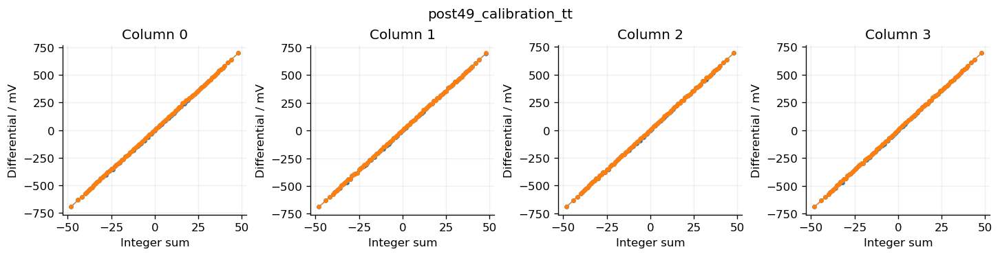

In [54]:
%%native_lab restored-archive-060
%%inline_module legacy_archive_060
from automx_nb_inline_v1.presentation import pretty
"""Expand TT PEX calibration to every reachable four-row signed sum.

The earlier 16-case holdout was inspected while choosing this screen and is
therefore calibration data, not an independent validation set. Results never
replace Stage-5 receipts or claim a physical ADC PASS. Run with --run on the
server; hash-validated per-case checkpoints allow continuation after timeout.
"""


import argparse
from datetime import datetime, timezone
from bisect import bisect_right
from itertools import product
import json
import math
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.circuit.sky130 import E2M1_MAGNITUDES_X2  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_candidate_full_tt import (  # noqa: E402
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    _read, analyze_transfer,
)
from scripts.run_core_candidate_pex import make_pex_deck  # noqa: E402
from scripts.run_core_pex_coverage import Case  # noqa: E402
from scripts.run_post49_decoder_diagnostic import run as validate_prior_evidence  # noqa: E402

OUTPUT = Path("results/sky130/post49_calibration_tt")
WEIGHTS = tuple(product((-1, 0, 1), repeat=4))
FEATURES = ("differential_v", "differential_over_common_mode")


def reachable_sums() -> list[int]:
    single = set(E2M1_MAGNITUDES_X2) | {-x for x in E2M1_MAGNITUDES_X2}
    totals = {0}
    for _ in range(4):
        totals = {a + b for a in totals for b in single}
    return sorted(totals)


def calibration_cases() -> list[Case]:
    """One deterministic high-activity valid pattern per reachable sum.

    All four columns see the target sum, but may use different row weights.
    Existing 117 cases supply additional within-sum patterns. This sweep
    does not establish full activation/weight combination coverage.
    """
    best: dict[int, tuple[tuple, tuple[int, ...], tuple[int, ...]]] = {}
    magnitudes = tuple(sorted(set(E2M1_MAGNITUDES_X2)))
    for acts in product(magnitudes, repeat=4):
        for weights in WEIGHTS:
            total = sum(a * w for a, w in zip(acts, weights))
            activity = sum(a * abs(w) for a, w in zip(acts, weights))
            # Prefer active/cancelling cases, then a stable deterministic tie-break.
            score = (activity, sum(w != 0 for w in weights),
                     tuple(-a for a in acts), tuple(-w for w in weights))
            if total not in best or score > best[total][0]:
                best[total] = (score, acts, weights)
    expected = reachable_sums()
    if sorted(best) != expected:
        raise ValueError("calibration generator missed reachable sums")
    cases = []
    for total in expected:
        _, magnitudes_for_case, base_weights = best[total]
        # Exercise both signed row-PWM phases without changing any dot product.
        signs = (1, -1, 1, -1) if total % 2 else (-1, 1, -1, 1)
        acts = tuple(a * sign for a, sign in zip(magnitudes_for_case, signs))
        corrected = tuple(w * sign for w, sign in zip(base_weights, signs))
        options = [weights for weights in WEIGHTS
                   if sum(a * w for a, w in zip(acts, weights)) == total]
        options.sort(key=lambda weights: (-sum(a != 0 and w != 0
                                               for a, w in zip(acts, weights)), weights))
        if corrected not in options:
            raise ValueError(f"signed-row mapping lost target {total}")
        chosen = [corrected]
        chosen.extend(weights for weights in options if weights != corrected)
        columns = [chosen[index % len(chosen)] for index in range(4)]
        matrix = tuple(tuple(columns[col][row] for col in range(4))
                       for row in range(4))
        name = f"cal_{'p' if total >= 0 else 'n'}{abs(total):02d}"
        case = Case(name, acts, matrix)
        if case.sums != (total,) * 4:
            raise ValueError(f"calibration case {name} has wrong dot product")
        cases.append(case)
    return cases


def _observation(job: dict, col: int, time: str, feature: str) -> tuple[float, float, float]:
    if feature not in FEATURES:
        raise ValueError(f"unsupported decoder feature: {feature}")
    values = job["measurements_v"]
    diff = float(values[f"diff_c{col}_{time}"])
    cm = (float(values[f"blp_c{col}_{time}"]) +
          float(values[f"bln_c{col}_{time}"])) / 2
    if not math.isfinite(diff) or not math.isfinite(cm) or cm <= 0:
        raise ValueError(f"invalid differential/common-mode voltage: {job['case']} c{col} {time}")
    value = diff if feature == "differential_v" else diff / cm
    return value, diff, cm


def analyze_feature_training(jobs: list[dict], feature: str) -> dict:
    """Fit monotone midpoint thresholds using training measurements only."""
    if not jobs:
        raise ValueError("feature training requires measured jobs")
    columns = []
    for col in range(4):
        levels: dict[int, list[float]] = {}
        common_modes = []
        for job in jobs:
            for time in ("t19", "t21"):
                value, _, cm = _observation(job, col, time, feature)
                levels.setdefault(int(job["integer_sums"][col]), []).append(value)
                common_modes.append(cm)
        sums = sorted(levels)
        if len(sums) < 2:
            raise ValueError(f"column {col} has fewer than two measured sum levels")
        intervals = [{"sum": total, "min": min(levels[total]),
                      "max": max(levels[total]), "samples": len(levels[total])}
                     for total in sums]
        gaps = [higher["min"] - lower["max"]
                for lower, higher in zip(intervals, intervals[1:])]
        overlap_count = sum(gap <= 0 for gap in gaps)
        min_gap = min(gaps) if gaps else None
        min_cm = min(common_modes)
        # A dimensionless ratio gap is converted back to the conservative
        # voltage scale at the smallest observed common mode. This does not
        # account for noise or gain error in a future physical CM sensor.
        min_gap_equivalent_v = (min_gap if feature == "differential_v" else
                                min_gap * min_cm) if min_gap is not None else None
        thresholds = [(lower["max"] + higher["min"]) / 2
                      for lower, higher in zip(intervals, intervals[1:])]
        columns.append({"column": col, "sum_levels": sums,
                        "intervals": intervals, "thresholds": thresholds,
                        "overlap_count": overlap_count,
                        "min_gap": min_gap,
                        "min_gap_equivalent_v": min_gap_equivalent_v,
                        "training_common_mode_range_v": [min_cm, max(common_modes)]})
    return {"feature": feature, "columns": columns,
            "minimum_gap_equivalent_v": min(
                col["min_gap_equivalent_v"] for col in columns),
            "all_levels_ordered": all(col["overlap_count"] == 0 for col in columns),
            "scope_warning": "Deterministic TT passive-core feature; CM sensing, noise and PVT unmeasured"}


def analyze_feature_holdout(training: dict, holdout_jobs: list[dict],
                            error_budget_v: float) -> dict:
    """Evaluate a fixed training-only feature/threshold choice on new cases."""
    if not holdout_jobs or not math.isfinite(error_budget_v) or error_budget_v < 0:
        raise ValueError("nonempty holdout and finite nonnegative budget required")
    feature = training["feature"]
    columns = []
    for col in range(4):
        model = training["columns"][col]
        sums, thresholds = model["sum_levels"], model["thresholds"]
        low_cm, high_cm = model["training_common_mode_range_v"]
        details = []
        for job in holdout_jobs:
            expected = int(job["integer_sums"][col])
            for time in ("t19", "t21"):
                value, diff, cm = _observation(job, col, time, feature)
                predicted = sums[bisect_right(thresholds, value)]
                feature_distance = min(abs(value - threshold) for threshold in thresholds)
                distance_v = (feature_distance if feature == "differential_v" else
                              feature_distance * cm)
                details.append({"case": job["case"], "time": time,
                                "expected_sum": expected, "predicted_sum": predicted,
                                "expected_sum_unseen_in_training": expected not in sums,
                                "diff_v": diff, "common_mode_v": cm,
                                "feature_value": value,
                                "nearest_threshold_distance_equivalent_v": distance_v,
                                "below_error_budget": distance_v <= error_budget_v,
                                "common_mode_outside_training_range": not low_cm <= cm <= high_cm})
        columns.append({"column": col, "holdout_samples": len(details),
                        "decode_mismatches": sum(x["predicted_sum"] != x["expected_sum"]
                                                 for x in details),
                        "unseen_sum_samples": sum(x["expected_sum_unseen_in_training"]
                                                  for x in details),
                        "samples_below_error_budget": sum(x["below_error_budget"]
                                                          for x in details),
                        "common_mode_outside_training_samples": sum(
                            x["common_mode_outside_training_range"] for x in details),
                        "details": details})
    return {"feature": feature, "columns": columns,
            "decode_mismatches": sum(c["decode_mismatches"] for c in columns),
            "unseen_sum_samples": sum(c["unseen_sum_samples"] for c in columns),
            "samples_below_error_budget": sum(c["samples_below_error_budget"]
                                              for c in columns),
            "common_mode_outside_training_samples": sum(
                c["common_mode_outside_training_samples"] for c in columns),
            "sample_count": sum(c["holdout_samples"] for c in columns),
            "error_budget_v": error_budget_v,
            "scope_warning": "No physical common-mode sensor, converter, noise, PVT or error-rate proof"}


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    prior = validate_prior_evidence(root)
    _, _, model, pex = _provenance(root)
    stage49 = _read(root / "results/sky130/core_candidate_full_tt/measured.json")
    old_holdout = _read(root / "results/sky130/post49_holdout_tt/measured.json")
    cases = calibration_cases()
    folder = root / OUTPUT
    folder.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = ""
    if ngspice:
        process = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                 timeout=15, check=False)
        version = (process.stdout + process.stderr).strip()
        if (not version or version != stage49.get("ngspice_version") or
                version != old_holdout.get("ngspice_version")):
            failures.append("ngspice version differs from the measured 101+16 TT cases")
    jobs = []
    for case in cases:
        deck = folder / f"{case.name}.spice"
        deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS),
                        encoding="utf-8")
        jobs.append({"case": case.name, "activation_x2": list(case.acts),
                     "ternary_weights": [list(row) for row in case.weights],
                     "integer_sums": list(case.sums),
                     "deck": str(deck.relative_to(root)), "deck_sha256": _digest(deck),
                     "log": str((folder / f"{case.name}.log").relative_to(root)),
                     "checkpoint": str((folder / f"{case.name}.receipt.json").relative_to(root))})
    for index, job in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (root / job[key] for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            values = saved["measurements_v"]
            job["reused_checkpoint"] = True
        else:
            if log.is_file():
                log.unlink()
            try:
                process = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                         cwd=folder, text=True, capture_output=True,
                                         timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                failures.append(f"{job['case']}: ngspice timeout after {timeout_s}s")
                break
            output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(output, _expected())
            if (process.returncode or set(values) != set(_expected()) or
                    not all(math.isfinite(value) for value in values.values())):
                failures.append(f"{job['case']}: incomplete ngspice result; see {log}")
                break
            checkpoint.write_text(json.dumps({
                "status": "PASS", "deck_sha256": job["deck_sha256"],
                "pex_sha256": _digest(pex), "model_sha256": _digest(model),
                "ngspice_version": version, "log_sha256": _digest(log),
                "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        job["measurements_v"] = values
        if index == 1 or index % 10 == 0 or index == len(jobs):
            print(f"Calibration PEX: {index}/{len(jobs)} ({job['case']})", flush=True)
    completed = sum("measurements_v" in job for job in jobs)
    analysis = None
    feature_screens = None
    selected_feature = None
    conclusion = "NOT_MEASURED"
    if execute and not failures and completed == len(jobs):
        analysis = analyze_transfer(stage49["jobs"] + old_holdout["jobs"] + jobs)
        levels = reachable_sums()
        training = stage49["jobs"] + old_holdout["jobs"] + jobs
        feature_screens = {feature: analyze_feature_training(training, feature)
                           for feature in FEATURES}
        if any(any(column["sum_levels"] != levels for column in screen["columns"])
               for screen in feature_screens.values()):
            raise ValueError("calibration did not cover all reachable sums per column")
        acceptance = _read(root / "configs/sky130_post49_requirements.json")["acceptance"]
        error_budget = (acceptance["maximum_input_referred_offset_abs_v"] +
                        5 * acceptance["maximum_input_referred_noise_rms_v"] +
                        acceptance["maximum_reference_threshold_error_abs_v"] +
                        acceptance["maximum_aperture_induced_shift_abs_v"])
        # Select by training only, in declared order. The new holdout cannot
        # influence this choice or the thresholds.
        for feature in FEATURES:
            screen = feature_screens[feature]
            if (screen["all_levels_ordered"] and
                    screen["minimum_gap_equivalent_v"] > 2 * error_budget):
                selected_feature = feature
                break
        conclusion = ("TRAINING_ONLY_MARGIN_CANDIDATE" if selected_feature else
                      "TRAINING_OVERLAP_OR_INSUFFICIENT_MARGIN")
    report = {"format": "automx-cim-post49-calibration-tt-v1",
              "status": "FAIL" if failures else "MEASURED_CALIBRATION_TT" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "scope": "87 reachable signed sums per column at TT PEX; one synthetic high-activity pattern per sum plus 117 earlier cases; not ADC sign-off",
              "old_holdout_consumed_for_design": True,
              "cell49_sha256": prior["cell49_sha256"],
              "old_holdout_sha256": prior["holdout_sha256"],
              "requirements_sha256": _digest(root / "configs/sky130_post49_requirements.json"),
              "script_sha256": _digest(root / "scripts/run_post49_calibration_tt.py"),
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "ngspice_version": version or None,
              "load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
              "reachable_sums": reachable_sums(),
              "planned_sims": len(jobs), "completed_sims": completed,
              "reused_checkpoints": sum(job.get("reused_checkpoint", False) for job in jobs),
              "conclusion": conclusion, "analysis": analysis,
              "feature_screens": feature_screens,
              "selected_feature": selected_feature,
              "failures": failures, "jobs": jobs}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items()
                      if key not in ("jobs", "analysis", "feature_screens")}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_calibration_tt/measured.json'], label='post49-calibration-tt-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib, json
    import automx_nb_inline_v1.legacy_archive_060 as calibration_module
    # inline module already loaded from this cell: calibration_module
    RUN_POST49_CALIBRATION_TT = False  # replay 87 measured cases; do not overwrite evidence
    if RUN_POST49_CALIBRATION_TT:
        calibration_tt = calibration_module.run(ROOT, execute=True, timeout_s=600)
    else:
        saved = ROOT / 'results/sky130/post49_calibration_tt/measured.json'
        calibration_tt = json.loads(saved.read_text(encoding='utf-8')) if saved.is_file() else None
    if calibration_tt is None:
        print('TT calibration: PENDING — copy measured.json from the server.')
    else:
        print('TT calibration:', calibration_tt['status'])
        print('Planned/measured:', calibration_tt['planned_sims'], '/', calibration_tt['completed_sims'])
        print('Conclusion:', calibration_tt['conclusion'])
        print('Selected training-only decoder feature:', calibration_tt['selected_feature'])
        if calibration_tt.get('analysis'):
            cols = calibration_tt['analysis']['samples']['1.9_to_2.1_pooled']['columns']
            print('Overlaps by column:', [col['overlap_count'] for col in cols])
        print('This is TT passive-core training only, not ADC sign-off.')



### Earlier decoder-diagnostic recipe

Retain the implementation for reference; new-run decoder results are measured
in the subsequent SAR branch.


<a id="guide-native-story-decoder_errors"></a>

### Before cell `native-story-decoder_errors` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-054`](#guide-native-restored-archive-054).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-decoder_errors-decoder_errors"></a>`decoder_errors(root)` | Present the earlier recipe's scalar-decoder diagnostic report, error counts, and difficult levels to explain the readout-protocol decision. |

**Data and downstream use:** Follow the [contract described for `native-story-transfer_error`](#data-native-story-transfer_error).


Scalar decoder: 52/128 errors (40.625%); 16 holdout patterns × 4 columns × 2 sample times.


| Case | Column | Sample time | Expected sum | Decoded sum | ΔV / V | Level absent from training |
| --- | --- | --- | --- | --- | --- | --- |
| mha_22 | 0 | t19 | 10 | 11 | 0.14692 | True |
| mha_22 | 0 | t21 | 10 | 11 | 0.1469362 | True |
| mha_23 | 0 | t19 | -1 | -2 | -0.01708695 | True |
| mha_23 | 0 | t21 | -1 | -2 | -0.01708816 | True |
| mha_26 | 0 | t19 | 17 | 16 | 0.2530133 | True |
| mha_26 | 0 | t21 | 17 | 16 | 0.253037 | True |
| mha_27 | 0 | t19 | 9 | 8 | 0.1336955 | True |
| mha_27 | 0 | t21 | 9 | 8 | 0.133712 | True |
| mha_28 | 0 | t19 | -15 | -12 | -0.2210152 | True |
| mha_28 | 0 | t21 | -15 | -12 | -0.2210338 | True |
| mha_31 | 0 | t19 | 17 | 16 | 0.2525109 | True |
| mha_31 | 0 | t21 | 17 | 16 | 0.252535 | True |

Added 87 calibration cases: minimum differential gap = -4.4212 mV. This level reversal motivates 2+2 row-partition experiments.
Source: results/sky130/post49_decoder_diagnostic.json · 2026-10-14


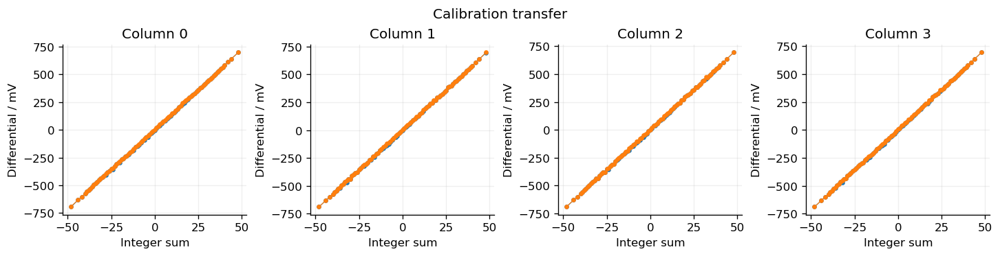

In [55]:
%%native_lab story-decoder_errors
%%inline_module story_decoder_errors
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def decoder_errors(root):
    relative=BASE+'post49_decoder_diagnostic.json';data=read_report(root,relative);a=data['analysis']
    all_rows=[dict(row,column=c['column']) for c in a['columns'] for row in c['details']]
    wrong=[r for r in all_rows if r['expected_sum']!=r['predicted_sum']]
    if len(all_rows)!=a['sample_count'] or len(wrong)!=a['decode_mismatches']:raise ValueError('Decoder detail/count mismatch')
    print(f'Scalar decoder: {len(wrong)}/{len(all_rows)} errors ({len(wrong)/len(all_rows):.3%}); 16 holdout patterns × 4 columns × 2 sample times.')
    table(['Case','Column','Sample time','Expected sum','Decoded sum','ΔV / V','Level absent from training'],[
        [r['case'],r['column'],r['time'],r['expected_sum'],r['predicted_sum'],r['diff_v'],r['expected_sum_unseen_in_training']] for r in wrong[:12]])
    expanded=read_report(root,BASE+'post49_calibration_tt/measured.json')
    gap=expanded['feature_screens']['differential_v']['minimum_gap_equivalent_v']
    print(f'Added {expanded["completed_sims"]} calibration cases: minimum differential gap = {gap*1000:.4f} mV. This level reversal motivates 2+2 row-partition experiments.')
    EVIDENCE['decoder_errors']={'source':relative,'mismatches':len(wrong),'samples':len(all_rows),'wrong_examples':wrong[:12],'expanded_gap_v':gap}
    return wrong

# NOTEBOOK_RUN
story_decoder_errors.decoder_errors(ROOT)
print('Source: results/sky130/post49_decoder_diagnostic.json · 2026-10-14')
history.plot_saved_transfer(ROOT,'results/sky130/post49_calibration_tt/measured.json','Calibration transfer')


### 4.12b Separate calibration and holdout data

Reserve new MHA-ranked patterns until the readout method is selected and
thresholds are frozen.


**Data relationship:** fit on calibration and evaluate on separate holdout patterns.


<a id="guide-native-restored-archive-063"></a>

### Before cell `native-restored-archive-063` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-051`](#guide-native-restored-archive-051).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `new_holdout_cases(config: Sky130MHAConfig, prior_jobs: list[dict])` | Same task as [`heldout_cases`](#fn-native-restored-archive-051-heldout_cases). |
| <a id="fn-native-restored-archive-063-_verified_calibration"></a>`_verified_calibration(root: Path, pex: Path, model: Path, prior: dict)` | Verify calibration, PEX/model, and parent reports still match the active readout; return the validated fit without letting holdout select thresholds again. |
| <a id="fn-native-restored-archive-063-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Orchestrate new holdout measurements after validating expanded calibration: check sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-051`](#data-native-restored-archive-051).


| measured | Result |
|---|---|
| analysis.samples.1.9.columns[0].overlap_count | 2 |
| analysis.samples.1.9.columns[1].overlap_count | 3 |
| analysis.samples.1.9.columns[2].overlap_count | 2 |
| analysis.samples.1.9.columns[3].overlap_count | 3 |
| analysis.samples.2.1.columns[0].overlap_count | 2 |
| analysis.samples.2.1.columns[1].overlap_count | 3 |
| analysis.samples.2.1.columns[2].overlap_count | 2 |
| analysis.samples.2.1.columns[3].overlap_count | 3 |
| analysis.samples.1.9_to_2.1_pooled.columns[0].overlap_count | 2 |
| analysis.samples.1.9_to_2.1_pooled.columns[1].overlap_count | 3 |
| analysis.samples.1.9_to_2.1_pooled.columns[2].overlap_count | 2 |
| analysis.samples.1.9_to_2.1_pooled.columns[3].overlap_count | 3 |

Source: `results/sky130/post49_calibration_tt/measured.json` · 2026-10-14T06:23:45.788140+00:00

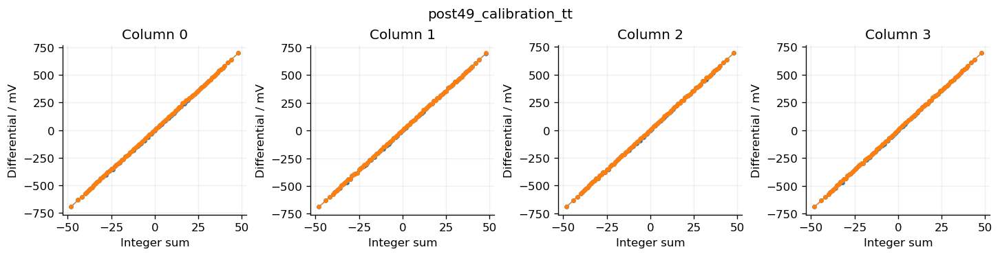

In [56]:
%%native_lab restored-archive-063
%%inline_module legacy_archive_063
from automx_nb_inline_v1.presentation import pretty
"""Independent TT PEX holdout after 87-level calibration expansion.

MHA ranks 32-63 were not in the original 101-case screen, the inspected
16-case holdout, or the synthetic calibration sweep. All conclusions are
passive-core TT diagnostics, never physical ADC or Stage-8 sign-off.
"""


import argparse
from datetime import datetime, timezone
import json
import math
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_candidate_full_tt import (  # noqa: E402
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    _read, analyze_transfer,
)
from scripts.run_core_candidate_pex import make_pex_deck  # noqa: E402
from scripts.run_core_pex_coverage import Case, mha_cases  # noqa: E402
from scripts.run_post49_calibration_tt import (  # noqa: E402
    FEATURES, analyze_feature_holdout, analyze_feature_training,
    calibration_cases, reachable_sums,
)
from scripts.run_post49_decoder_diagnostic import run as validate_prior_evidence  # noqa: E402

OUTPUT = Path("results/sky130/post49_calibration_holdout")


def new_holdout_cases(config: Sky130MHAConfig,
                      prior_jobs: list[dict]) -> list[Case]:
    previous = {(tuple(job["activation_x2"]),
                 tuple(tuple(row) for row in job["ternary_weights"]))
                for job in prior_jobs}
    selected = mha_cases(config, 64)[32:64]
    if (len(selected) != 32 or
            [case.name for case in selected] !=
            [f"mha_{index:02d}" for index in range(32, 64)] or
            any((case.acts, case.weights) in previous for case in selected) or
            len({(case.acts, case.weights) for case in selected}) != 32):
        raise ValueError("MHA 32-63 are not an independent holdout")
    return selected


def _verified_calibration(root: Path, pex: Path, model: Path,
                          prior: dict) -> dict:
    path = root / "results/sky130/post49_calibration_tt/measured.json"
    report = _read(path)
    jobs = report.get("jobs", [])
    expected = calibration_cases()
    if (report.get("format") != "automx-cim-post49-calibration-tt-v1" or
            report.get("status") != "MEASURED_CALIBRATION_TT" or
            report.get("conclusion") != "TRAINING_ONLY_MARGIN_CANDIDATE" or
            report.get("failures") or
            report.get("old_holdout_consumed_for_design") is not True or
            report.get("cell49_sha256") != prior["cell49_sha256"] or
            report.get("old_holdout_sha256") != prior["holdout_sha256"] or
            report.get("requirements_sha256") != _digest(
                root / "configs/sky130_post49_requirements.json") or
            report.get("script_sha256") != _digest(
                root / "scripts/run_post49_calibration_tt.py") or
            report.get("pex_sha256") != _digest(pex) or
            report.get("model_sha256") != _digest(model) or
            report.get("reachable_sums") != reachable_sums() or
            report.get("load_ff") != LOAD_FF or report.get("pwm_unit_ps") != PWM_UNIT_PS or
            report.get("planned_sims") != len(expected) or
            report.get("completed_sims") != len(expected) or
            len(jobs) != len(expected) or
            [job.get("case") for job in jobs] != [case.name for case in expected]):
        raise ValueError("complete ordered TT calibration is required before new holdout")
    version = report.get("ngspice_version")
    if not isinstance(version, str) or not version:
        raise ValueError("calibration ngspice version missing")
    for job, case in zip(jobs, expected):
        deck = (root / job["deck"]).resolve()
        log = (root / job["log"]).resolve()
        checkpoint = (root / job["checkpoint"]).resolve()
        if any(not path.is_relative_to(root) for path in (deck, log, checkpoint)):
            raise ValueError(f"calibration path escapes project: {case.name}")
        saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if (not deck.is_file() or _digest(deck) != job["deck_sha256"] or
                saved is None or saved.get("measurements_v") != job.get("measurements_v") or
                job.get("activation_x2") != list(case.acts) or
                job.get("ternary_weights") != [list(row) for row in case.weights] or
                job.get("integer_sums") != list(case.sums)):
            raise ValueError(f"calibration evidence changed: {case.name}")
    old_training = (_read(root / "results/sky130/core_candidate_full_tt/measured.json")["jobs"] +
                    _read(root / "results/sky130/post49_holdout_tt/measured.json")["jobs"])
    recomputed = analyze_transfer(old_training + jobs)
    screens = {feature: analyze_feature_training(old_training + jobs, feature)
               for feature in FEATURES}
    acceptance = _read(root / "configs/sky130_post49_requirements.json")["acceptance"]
    budget = (acceptance["maximum_input_referred_offset_abs_v"] +
              5 * acceptance["maximum_input_referred_noise_rms_v"] +
              acceptance["maximum_reference_threshold_error_abs_v"] +
              acceptance["maximum_aperture_induced_shift_abs_v"])
    selected = next((feature for feature in FEATURES
                     if screens[feature]["all_levels_ordered"] and
                     screens[feature]["minimum_gap_equivalent_v"] > 2 * budget), None)
    if (report.get("analysis") != recomputed or
            report.get("feature_screens") != screens or
            report.get("selected_feature") != selected or
            any(any(col["sum_levels"] != reachable_sums()
                    for col in screen["columns"]) for screen in screens.values()) or
            selected is None):
        raise ValueError("calibration raw data do not meet TT threshold/margin gate")
    return report


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    prior = validate_prior_evidence(root)
    _, _, model, pex = _provenance(root)
    calibration = _verified_calibration(root, pex, model, prior)
    stage49 = _read(root / "results/sky130/core_candidate_full_tt/measured.json")
    old_holdout = _read(root / "results/sky130/post49_holdout_tt/measured.json")
    training = stage49["jobs"] + old_holdout["jobs"] + calibration["jobs"]
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    cases = new_holdout_cases(config, training)
    folder = root / OUTPUT
    folder.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = ""
    if ngspice:
        process = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                 timeout=15, check=False)
        version = (process.stdout + process.stderr).strip()
        if not version or version != calibration.get("ngspice_version"):
            failures.append("ngspice version differs from TT calibration")
    jobs = []
    for case in cases:
        deck = folder / f"{case.name}.spice"
        deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS),
                        encoding="utf-8")
        jobs.append({"case": case.name, "activation_x2": list(case.acts),
                     "ternary_weights": [list(row) for row in case.weights],
                     "integer_sums": list(case.sums),
                     "deck": str(deck.relative_to(root)), "deck_sha256": _digest(deck),
                     "log": str((folder / f"{case.name}.log").relative_to(root)),
                     "checkpoint": str((folder / f"{case.name}.receipt.json").relative_to(root))})
    for index, job in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (root / job[key] for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            values = saved["measurements_v"]
            job["reused_checkpoint"] = True
        else:
            if log.is_file():
                log.unlink()
            try:
                process = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                         cwd=folder, text=True, capture_output=True,
                                         timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                failures.append(f"{job['case']}: ngspice timeout after {timeout_s}s")
                break
            output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(output, _expected())
            if (process.returncode or set(values) != set(_expected()) or
                    not all(math.isfinite(value) for value in values.values())):
                failures.append(f"{job['case']}: incomplete ngspice result; see {log}")
                break
            checkpoint.write_text(json.dumps({
                "status": "PASS", "deck_sha256": job["deck_sha256"],
                "pex_sha256": _digest(pex), "model_sha256": _digest(model),
                "ngspice_version": version, "log_sha256": _digest(log),
                "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        job["measurements_v"] = values
        if index == 1 or index % 5 == 0 or index == len(jobs):
            print(f"New holdout PEX: {index}/{len(jobs)} ({job['case']})", flush=True)
    completed = sum("measurements_v" in job for job in jobs)
    assessment = None
    conclusion = "NOT_MEASURED"
    if execute and not failures and completed == len(jobs):
        acceptance = _read(root / "configs/sky130_post49_requirements.json")["acceptance"]
        budget = (acceptance["maximum_input_referred_offset_abs_v"] +
                  5 * acceptance["maximum_input_referred_noise_rms_v"] +
                  acceptance["maximum_reference_threshold_error_abs_v"] +
                  acceptance["maximum_aperture_induced_shift_abs_v"])
        selected = calibration["selected_feature"]
        decoder = analyze_feature_holdout(
            analyze_feature_training(training, selected), jobs, budget)
        transfer = analyze_transfer(training + jobs)
        combined_feature = analyze_feature_training(training + jobs, selected)
        assessment = {"decoder": decoder, "combined_transfer": transfer,
                      "combined_feature_transfer": combined_feature}
        conclusion = ("DETERMINISTIC_TT_HOLDOUT_TARGET_MET" if
                      decoder["decode_mismatches"] == 0 and
                      decoder["unseen_sum_samples"] == 0 and
                      decoder["samples_below_error_budget"] == 0 and
                      decoder["common_mode_outside_training_samples"] == 0 and
                      combined_feature["all_levels_ordered"] and
                      combined_feature["minimum_gap_equivalent_v"] > 2 * budget else
                      "HOLDOUT_ERRORS_OR_INSUFFICIENT_MARGIN")
    report = {"format": "automx-cim-post49-calibration-holdout-v1",
              "status": "FAIL" if failures else "MEASURED_NEW_HOLDOUT_TT" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "scope": "32 new MHA-derived TT PEX cases after full-sum calibration; no ADC/noise/PVT sign-off",
              "calibration_sha256": _digest(root / "results/sky130/post49_calibration_tt/measured.json"),
              "selected_feature": calibration["selected_feature"],
              "requirements_sha256": _digest(root / "configs/sky130_post49_requirements.json"),
              "script_sha256": _digest(root / "scripts/run_post49_calibration_holdout.py"),
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "ngspice_version": version or None,
              "load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
              "planned_sims": len(jobs), "completed_sims": completed,
              "reused_checkpoints": sum(job.get("reused_checkpoint", False) for job in jobs),
              "conclusion": conclusion, "assessment": assessment,
              "failures": failures, "jobs": jobs}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items()
                      if key not in ("jobs", "assessment")}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_calibration_tt/measured.json'], label='post49-calibration-holdout-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib, json
    import automx_nb_inline_v1.legacy_archive_063 as calibration_holdout_module
    # inline module already loaded from this cell: calibration_holdout_module
    RUN_POST49_NEW_HOLDOUT = False
    cal_path = ROOT / 'results/sky130/post49_calibration_tt/measured.json'
    cal_report = json.loads(cal_path.read_text()) if cal_path.is_file() else {}
    if cal_report.get('conclusion') != 'TRAINING_ONLY_MARGIN_CANDIDATE':
        print('New holdout PENDING: finish 4.12a and require ordered training with >2x error-budget gap.')
    else:
        fresh = calibration_holdout_module.run(ROOT, execute=RUN_POST49_NEW_HOLDOUT, timeout_s=600)
        print('New TT holdout:', fresh['status'], fresh['completed_sims'], '/', fresh['planned_sims'])
        print('Conclusion:', fresh['conclusion'])
        print('Fixed decoder feature:', fresh['selected_feature'])
        if fresh['assessment']:
            d = fresh['assessment']['decoder']
            print('Samples/mismatches/unseen/within-budget:', d['sample_count'], d['decode_mismatches'], d['unseen_sum_samples'], d['samples_below_error_budget'])
        for problem in fresh['failures'][:5]: print(' -', problem)
        print('This is NOT physical ADC or PVT sign-off.')



### 4.12c Compare decoding features

Measured differential/common-mode data guide the 2+2 partitioned-row readout experiment.


**Equation / measurement relation:** $$\widehat s=f(\Delta V,V_{\rm CM},\mathrm{activity})$$

<a id="guide-native-restored-archive-066"></a>

### Before cell `native-restored-archive-066` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-054`](#guide-native-restored-archive-054).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_hash(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| `_read_reports(root: Path)` | Same task as [`_read`](#fn-native-restored-archive-048-_read). |
| <a id="fn-native-restored-archive-066-observations"></a>`observations(jobs: list[dict], *, source: str)` | Recompute reference sums and metadata from each job's activations/weights rather than trusting cached labels, returning consistent training/query points. |
| <a id="fn-native-restored-archive-066-_nearest"></a>`_nearest(training: list[dict], query: dict, *, cm_weight: float, condition: str \| None)` | Find the nearest training observation to a query under the selected differential/common-mode distance and activity conditions; return its prediction. |
| <a id="fn-native-restored-archive-066-_score"></a>`_score(training: list[dict], queries: list[dict], *, cm_weight: float, condition: str \| None, exclude_same_case: bool)` | Apply the predictor to a query set, compare reference labels, and return error/improvement counts for feature-family comparison. |
| <a id="fn-native-restored-archive-066-_select_training_candidates"></a>`_select_training_candidates(screens: dict)` | Select each feature family's winner using training only and nominate it only if it improves on differential voltage alone; do not select with holdout. |
| <a id="fn-native-restored-archive-066-analyze"></a>`analyze(training_jobs: list[dict], inspected_jobs: list[dict])` | Aggregate feature-family evaluations on training and test sets, tabulate errors, and identify which dataset determined the choice. |
| <a id="fn-native-restored-archive-066-run"></a>`run(root: str \| Path)` | Read measured training/query reports to compare decoding-feature families, recompute labels/errors, and write analysis JSON without starting a new transistor simulation. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-054`](#data-native-restored-archive-054).

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-221"></a>`LUT` | Look-Up Table: address-indexed thresholds/values; the 2+2 controller contains 304 12-bit thresholds. |


In [57]:
%%native_lab restored-archive-066
%%inline_module legacy_archive_066
from automx_nb_inline_v1.presentation import pretty
"""Offline decoder architecture screen over existing TT PEX reports.

No SPICE, ADC model, physical sign-off or independent holdout is implied.
The 16 old holdout cases were already inspected while designing the 87-case
calibration sweep; they are retained as a *previously inspected* diagnostic.
Cross-validation excludes both time samples of the queried case.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path

ROOT = Path(PROJECT_ROOT)
REPORTS = {
    "cell49": Path("results/sky130/core_candidate_full_tt/measured.json"),
    "old_holdout": Path("results/sky130/post49_holdout_tt/measured.json"),
    "calibration": Path("results/sky130/post49_calibration_tt/measured.json"),
}
EXPECTED = {
    "cell49": ("automx-cim-core-candidate-full-tt-v1", "MEASURED_TT_CANDIDATE_SCREEN", 101),
    "old_holdout": ("automx-cim-post49-holdout-tt-v1", "MEASURED_HOLDOUT_TT", 16),
    "calibration": ("automx-cim-post49-calibration-tt-v1", "MEASURED_CALIBRATION_TT", 87),
}
OUTPUT = Path("results/sky130/post49_decoder_architecture/offline.json")
TIMES = ("t19", "t21")
CONFIGS = (
    ("differential_only", 0.0, None),
    ("differential_cm_0p05", 0.05, None),
    ("differential_cm_0p2", 0.2, None),
    ("differential_cm_1", 1.0, None),
    ("differential_active_rows", 0.0, "active_rows"),
    ("differential_unsigned_activity", 0.0, "unsigned_activity_x2"),
)


def _hash(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _read_reports(root: Path) -> tuple[dict, dict]:
    reports = {}
    hashes = {}
    for name, relative in REPORTS.items():
        path = root / relative
        if not path.is_file():
            raise FileNotFoundError(f"Copy the measured server report first: {path}")
        value = json.loads(path.read_text(encoding="utf-8"))
        fmt, status, count = EXPECTED[name]
        if (not isinstance(value, dict) or value.get("format") != fmt or
                value.get("status") != status or value.get("failures") or
                value.get("planned_sims") != count or
                value.get("completed_sims") != count or
                not isinstance(value.get("jobs"), list) or len(value["jobs"]) != count):
            raise ValueError(f"Incomplete or wrong {name} measured report: {path}")
        reports[name] = value
        hashes[name] = _hash(path)
    provenance_links = (
        ("4.10 -> 4.9", reports["old_holdout"].get("stage49_sha256"), hashes["cell49"]),
        ("4.12a -> 4.9", reports["calibration"].get("cell49_sha256"), hashes["cell49"]),
        ("4.12a -> 4.10", reports["calibration"].get("old_holdout_sha256"),
         hashes["old_holdout"]),
    )
    mismatches = [f"{link}: recorded={recorded}, current={current}"
                  for link, recorded, current in provenance_links if recorded != current]
    if mismatches:
        raise ValueError("101/16/87 report provenance hashes do not match: "
                         + "; ".join(mismatches)
                         + ". Refresh 4.10 after 4.9 if its link differs; "
                           "then refresh 4.12a after 4.10. Valid SPICE checkpoints "
                           "are reused.")
    if any(len({reports[name].get(key) for name in REPORTS}) != 1
           for key in ("pex_sha256", "model_sha256", "ngspice_version",
                       "load_ff", "pwm_unit_ps")):
        raise ValueError("TT PEX/source/stimulus settings differ across reports")
    if (reports["cell49"]["load_ff"], reports["cell49"]["pwm_unit_ps"]) != (800, 50):
        raise ValueError("Expected the 800 fF / 50 ps candidate")
    return reports, hashes


def observations(jobs: list[dict], *, source: str) -> list[dict]:
    """Recompute labels and metadata from vectors, never trust cached sums."""
    output = []
    names = set()
    for job in jobs:
        name = job.get("case")
        acts, weights = job.get("activation_x2"), job.get("ternary_weights")
        values = job.get("measurements_v")
        if (not isinstance(name, str) or not name or name in names or
                not isinstance(acts, list) or len(acts) != 4 or
                not isinstance(weights, list) or len(weights) != 4 or
                any(not isinstance(row, list) or len(row) != 4 for row in weights) or
                not isinstance(values, dict)):
            raise ValueError(f"Invalid {source} job: {name}")
        names.add(name)
        if (any(type(a) is not int or abs(a) not in (0, 1, 2, 3, 4, 6, 8, 12)
                for a in acts) or
                any(type(w) is not int or w not in (-1, 0, 1)
                    for row in weights for w in row)):
            raise ValueError(f"Invalid E2M1/ternary vector: {name}")
        sums = [sum(acts[row] * weights[row][col] for row in range(4))
                for col in range(4)]
        if sums != job.get("integer_sums"):
            raise ValueError(f"Cached integer sums disagree with vectors: {name}")
        for col in range(4):
            active_rows = sum(acts[row] != 0 and weights[row][col] != 0
                              for row in range(4))
            activity = sum(abs(acts[row]) * abs(weights[row][col])
                           for row in range(4))
            for time in TIMES:
                try:
                    diff = float(values[f"diff_c{col}_{time}"])
                    blp = float(values[f"blp_c{col}_{time}"])
                    bln = float(values[f"bln_c{col}_{time}"])
                except (KeyError, TypeError, ValueError) as error:
                    raise ValueError(f"Missing/non-numeric sample: {name} c{col} {time}") from error
                if (not all(math.isfinite(v) for v in (diff, blp, bln)) or
                        abs(diff - (bln - blp)) > 2e-4):
                    raise ValueError(f"Inconsistent/non-finite bitlines: {name} c{col} {time}")
                output.append({"case": name, "source": source, "column": col,
                               "time": time, "sum": sums[col], "diff_v": diff,
                               "cm_v": (blp + bln) / 2,
                               "active_rows": active_rows,
                               "unsigned_activity_x2": activity})
    return output


def _nearest(training: list[dict], query: dict, *, cm_weight: float,
             condition: str | None) -> tuple[int, float, bool]:
    if condition:
        subset = [item for item in training if item[condition] == query[condition]]
        fallback = not bool(subset)
        candidates = subset or training
    else:
        candidates, fallback = training, False
    if not candidates:
        raise ValueError("No training samples for nearest-neighbour decoder")
    best = min(candidates, key=lambda item: (
        (item["diff_v"] - query["diff_v"]) ** 2 +
        (cm_weight * (item["cm_v"] - query["cm_v"])) ** 2,
        abs(item["sum"]), item["sum"], item["case"], item["time"]))
    distance = math.hypot(best["diff_v"] - query["diff_v"],
                          cm_weight * (best["cm_v"] - query["cm_v"]))
    return best["sum"], distance, fallback


def _score(training: list[dict], queries: list[dict], *, cm_weight: float,
           condition: str | None, exclude_same_case: bool) -> dict:
    columns = []
    for col in range(4):
        pool = [item for item in training if item["column"] == col]
        details = []
        for query in (item for item in queries if item["column"] == col):
            candidates = ([item for item in pool if item["case"] != query["case"]]
                          if exclude_same_case else pool)
            predicted, distance, fallback = _nearest(
                candidates, query, cm_weight=cm_weight, condition=condition)
            known = query["sum"] in {item["sum"] for item in candidates}
            details.append({"case": query["case"], "time": query["time"],
                            "expected": query["sum"], "predicted": predicted,
                            "known_sum": known, "fallback": fallback,
                            "nearest_distance_v": distance,
                            "diff_v": query["diff_v"], "cm_v": query["cm_v"]})
        columns.append({"column": col, "samples": len(details),
                        "mismatches": sum(d["predicted"] != d["expected"] for d in details),
                        "known_sum_mismatches": sum(d["known_sum"] and d["predicted"] != d["expected"]
                                                     for d in details),
                        "unseen_sum_samples": sum(not d["known_sum"] for d in details),
                        "metadata_fallback_samples": sum(d["fallback"] for d in details),
                        "first_mismatches": [d for d in details if d["predicted"] != d["expected"]][:8]})
    return {"samples": sum(c["samples"] for c in columns),
            "mismatches": sum(c["mismatches"] for c in columns),
            "known_sum_mismatches": sum(c["known_sum_mismatches"] for c in columns),
            "unseen_sum_samples": sum(c["unseen_sum_samples"] for c in columns),
            "metadata_fallback_samples": sum(c["metadata_fallback_samples"] for c in columns),
            "columns": columns}


def _select_training_candidates(screens: dict) -> tuple[dict, dict, str]:
    """Choose a family winner, but endorse it only if it beats raw differential.

    The old 16 cases must not participate in this selection. A family winner
    can still be worse than the baseline; calling that winner a selected
    decoder was misleading in the original v1 diagnostic.
    """
    baseline = screens["differential_only"]["case_grouped_cross_validation"]
    families = {
        "two_dimensional": [name for name, weight, _ in CONFIGS if weight > 0],
        "digital_activity_conditioned": [name for name, _, cond in CONFIGS if cond],
    }
    winners = {}
    improvements = {}
    for family, options in families.items():
        winner = min(options, key=lambda key: (
            screens[key]["case_grouped_cross_validation"]["known_sum_mismatches"],
            screens[key]["case_grouped_cross_validation"]["mismatches"],
            options.index(key)))
        candidate = screens[winner]["case_grouped_cross_validation"]
        winners[family] = winner
        improvements[family] = (winner if
                                candidate["known_sum_mismatches"] < baseline["known_sum_mismatches"]
                                and candidate["mismatches"] <= baseline["mismatches"] else None)
    recommended = min(("differential_only", *(name for name in improvements.values() if name)),
                      key=lambda key: (
                          screens[key]["case_grouped_cross_validation"]["known_sum_mismatches"],
                          screens[key]["case_grouped_cross_validation"]["mismatches"]))
    return winners, improvements, recommended


def analyze(training_jobs: list[dict], inspected_jobs: list[dict]) -> dict:
    training = observations(training_jobs, source="101_plus_87_training")
    inspected = observations(inspected_jobs, source="previously_inspected_16")
    if len(training) != 188 * 8 or len(inspected) != 16 * 8:
        raise ValueError("Expected exactly 101+87 training cases and 16 inspected cases")
    if {x["case"] for x in training} & {x["case"] for x in inspected}:
        raise ValueError("Training and inspected case names overlap")
    screens = {}
    for name, cm_weight, condition in CONFIGS:
        screens[name] = {"cm_weight": cm_weight, "metadata_condition": condition,
                         "case_grouped_cross_validation": _score(
                             training, training, cm_weight=cm_weight,
                             condition=condition, exclude_same_case=True)}
    # Select on training only. The previously inspected 16 cases may veto
    # confidence in a candidate, but cannot pick the model or CM weight.
    family_winners, selected, recommended = _select_training_candidates(screens)
    for name in {"differential_only", *family_winners.values()}:
        screen = screens[name]
        screen["previously_inspected_16_diagnostic"] = _score(
            training, inspected, cm_weight=screen["cm_weight"],
            condition=screen["metadata_condition"], exclude_same_case=False)
    cv = screens[recommended]["case_grouped_cross_validation"]
    inspected_score = screens[recommended]["previously_inspected_16_diagnostic"]
    gate = ("BLOCKED_KNOWN_LEVEL_ERRORS" if cv["known_sum_mismatches"] else
            "BLOCKED_INSPECTED_CASE_ERRORS" if inspected_score["mismatches"] else
            "PENDING_FRESH_HOLDOUT_AND_PHYSICAL_ADC")
    return {"training_cases": 188, "previously_inspected_cases": 16,
            "selection_uses_inspected_16": False,
            "best_within_family_training_only": family_winners,
            "improves_over_differential_baseline": selected,
            "recommended_training_only": recommended,
            "decoder_feasibility_gate": gate,
            "cross_validation_unseen_level_samples": cv["unseen_sum_samples"],
            "screens": screens,
            "scope_warning": "TT passive-core point samples only. kNN is an offline architecture probe, not a physical ADC/LUT, independent holdout, noise/PVT proof or sign-off."}


def run(root: str | Path) -> dict:
    root = Path(root).resolve()
    reports, hashes = _read_reports(root)
    result = analyze(reports["cell49"]["jobs"] + reports["calibration"]["jobs"],
                     reports["old_holdout"]["jobs"])
    payload = {"format": "automx-cim-post49-decoder-architecture-v2",
               "status": "DIAGNOSTIC_ONLY",
               "timestamp_utc": datetime.now(timezone.utc).isoformat(),
               "evidence_level": "three_report_JSON_only; raw deck/log hashes not revalidated",
               "input_report_sha256": hashes, **result}
    output = root / OUTPUT
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(json.dumps(payload, indent=2) + "\n", encoding="utf-8")
    return payload


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    args = parser.parse_args()
    result = run(args.root)
    print(pretty({"status": result["status"],
                      "decoder_feasibility_gate": result["decoder_feasibility_gate"],
                      "best_within_family_training_only": result["best_within_family_training_only"],
                      "improves_over_differential_baseline": result["improves_over_differential_baseline"],
                      "recommended_training_only": result["recommended_training_only"],
                      "screens": {name: {
                          "cross_validation": item["case_grouped_cross_validation"],
                          "inspected_16": item.get("previously_inspected_16_diagnostic")}
                          for name, item in result["screens"].items()
                          if name in ("differential_only", *result["best_within_family_training_only"].values())}},
                     indent=2))

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_decoder_architecture/offline.json'], label='post49-offline-architecture-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_066 as decoder_arch_module
    # inline module already loaded from this cell: decoder_arch_module
    try:
        decoder_arch = decoder_arch_module.run(ROOT)
    except FileNotFoundError as error:
        decoder_arch = None
        print('Offline decoder architecture: BLOCKED —', error)
    if decoder_arch:
        print('Offline decoder architecture:', decoder_arch['status'])
        print('Training cases:', decoder_arch['training_cases'], 'previously inspected:', decoder_arch['previously_inspected_cases'])
        print('Best within each family (not necessarily better than baseline):', decoder_arch['best_within_family_training_only'])
        print('Actually improves over differential-only:', decoder_arch['improves_over_differential_baseline'])
        print('Training-only recommendation:', decoder_arch['recommended_training_only'])
        print('Decoder feasibility gate:', decoder_arch['decoder_feasibility_gate'])
        print('CV samples with unseen sum level:', decoder_arch['cross_validation_unseen_level_samples'])
        for name in dict.fromkeys(('differential_only', *decoder_arch['best_within_family_training_only'].values())):
            screen = decoder_arch['screens'][name]
            cv = screen['case_grouped_cross_validation']
            old = screen['previously_inspected_16_diagnostic']
            print(name, 'CV errors=', cv['mismatches'], '/', cv['samples'], 'known-sum errors=', cv['known_sum_mismatches'], 'inspected-16 errors=', old['mismatches'], '/', old['samples'])
        print('Report: results/sky130/post49_decoder_architecture/offline.json')
        print('Diagnostic only: no physical ADC, PVT or wrapper sign-off.')



| offline | Result |
|---|---|
| screens.differential_only.case_grouped_cross_validation.mismatches | 576 |
| screens.differential_only.case_grouped_cross_validation.known_sum_mismatches | 76 |
| screens.differential_only.case_grouped_cross_validation.columns[0].mismatches | 134 |
| screens.differential_only.case_grouped_cross_validation.columns[0].known_sum_mismatches | 12 |
| screens.differential_only.case_grouped_cross_validation.columns[1].mismatches | 156 |
| screens.differential_only.case_grouped_cross_validation.columns[1].known_sum_mismatches | 26 |
| screens.differential_only.case_grouped_cross_validation.columns[2].mismatches | 146 |
| screens.differential_only.case_grouped_cross_validation.columns[2].known_sum_mismatches | 16 |
| screens.differential_only.case_grouped_cross_validation.columns[3].mismatches | 140 |
| screens.differential_only.case_grouped_cross_validation.columns[3].known_sum_mismatches | 22 |
| screens.differential_only.previously_inspected_16_diagnostic.mismatches | 14 |
| screens.differential_only.previously_inspected_16_diagnostic.known_sum_mismatches | 14 |

Source: `results/sky130/post49_decoder_architecture/offline.json` · 2026-10-14T06:33:07.521096+00:00

### 4.12d Intervention: two reads of two rows each

Read rows [0,1] and [2,3] with separate precharge. The 32/32 targeted PEX jobs
produce two ordered transfers within the selected set.


**Equation / measurement relation:** $$s_c=s_{A,c}+s_{B,c}$$

<a id="guide-native-restored-archive-069"></a>

### Before cell `native-restored-archive-069` — F6–F7

**Implementation:** Split four-row readout into 2+2, measure/calibrate partial sums, and add them digitally. Fewer concurrent rows can reduce overlap; the changed protocol needs its own measurements and thresholds.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-069-select_hard_cases"></a>`select_hard_cases(reports: dict, max_cases: int=16)` | Rank scalar-decoder errors using training data, retain known cases, and select up to max_cases for partitioned-row readout tests. |
| <a id="fn-native-restored-archive-069-select_hard_cases-errors"></a>`select_hard_cases.errors(queries: list[dict], *, leave_case_out: bool)` | Evaluate prediction errors with an option to exclude the query itself from training, selecting difficult examples without self-matching. |
| <a id="fn-native-restored-archive-069-split_case"></a>`split_case(parent: dict, partition: str)` | Keep all 16 weights but set PWM to zero outside the selected partition, creating upper/lower row-pair child cases. |
| <a id="fn-native-restored-archive-069-summarize_partition"></a>`summarize_partition(jobs: list[dict])` | Aggregate each partition's partial-sum measurements and check level order and recombination, retaining the scope of measured voltages. |
| <a id="fn-native-restored-archive-069-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=600, max_cases: int=16, partition: str='adjacent')` | Orchestrate 2+2 readout tests for selected difficult cases: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

<a id="data-native-restored-archive-069"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive difficult four-row cases with all 16 weights unchanged, row groups 0–1/2–3, validated inputs/model/PEX, and a voltage budget; calibration covers reachable levels and holdout uses unseen patterns.
- **Return values and saved artifacts:** Create two child decks per case, measure phase/column partial sums, fit calibration-only thresholds, decode/recombine holdout, and write 2+2 calibration/holdout reports.
- **Downstream consumers:** Partition-result explains the result; its protocol/thresholds feed 2+2 controller regression and are distinct from the SAR study's three-point affine fit.


| measured | Result |
|---|---|
| completed_sims | 32 |
| planned_sims | 32 |
| analysis.phases.a.samples.1.9.all_measured_levels_ordered | True |
| analysis.phases.a.samples.2.1.all_measured_levels_ordered | True |
| analysis.phases.a.samples.1.9_to_2.1_pooled.all_measured_levels_ordered | True |
| analysis.phases.b.samples.1.9.all_measured_levels_ordered | True |
| analysis.phases.b.samples.2.1.all_measured_levels_ordered | True |
| analysis.phases.b.samples.1.9_to_2.1_pooled.all_measured_levels_ordered | True |
| format | automx-cim-post49-row-partition-v1 |
| status | MEASURED_PARTITION_TT_DIAGNOSTIC |
| stimulus.load_ff | 800 |
| stimulus.pwm_unit_ps | 50 |

Source: `results/sky130/post49_row_partition/adjacent/measured.json` · 2026-10-14T07:43:43.760567+00:00

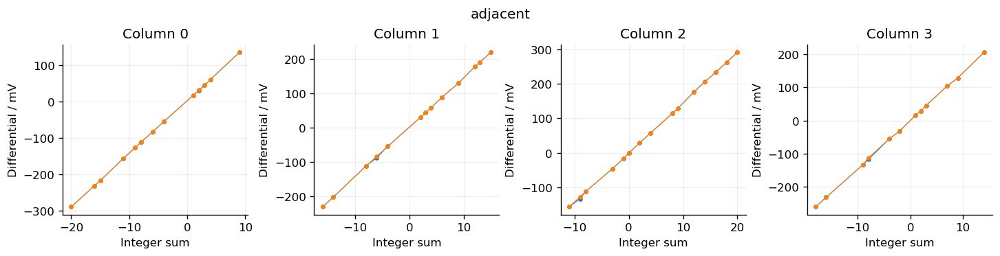

In [58]:
%%native_lab restored-archive-069
%%inline_module legacy_archive_069
from automx_nb_inline_v1.presentation import pretty
"""Targeted TT PEX check of two sequential 2-row reads on the existing core.

This is a *new stimulus* for the passive 4x4 core, not an ADC or wrapper
sign-off. Each half is simulated from a fresh precharge; the integer partial
sums are combined digitally only after both analog reads. Existing receipts
and their hash-linked source files are never changed by this script.
"""


import argparse
from collections import Counter
from datetime import datetime, timezone
import json
import math
from pathlib import Path
import re
import shutil
import subprocess

from automx_cim.spice import parse_measurements
from scripts.analyze_post49_decoder_architectures import (
    _nearest, _read_reports, observations,
)
from scripts.run_core_candidate_full_tt import (
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    analyze_transfer,
)
from scripts.run_core_candidate_pex import make_pex_deck
from scripts.run_core_pex_coverage import Case


ROOT = Path(PROJECT_ROOT)
OUTPUT = Path("results/sky130/post49_row_partition")
PARTITIONS = {
    "adjacent": ((0, 1), (2, 3)),
    "interleaved": ((0, 2), (1, 3)),
    "crossed": ((0, 3), (1, 2)),
}


def select_hard_cases(reports: dict, max_cases: int = 16) -> list[dict]:
    """Rank known-level scalar errors using training only; retain old cases.

    The old 16 were previously inspected and are *not* a fresh holdout. Their
    inclusion here is only to diagnose a proposed circuit change cheaply.
    """
    if max_cases < 4:
        raise ValueError("at least four cases are needed for the screen")
    training_jobs = reports["cell49"]["jobs"] + reports["calibration"]["jobs"]
    old_jobs = reports["old_holdout"]["jobs"]
    train = observations(training_jobs, source="training")
    old = observations(old_jobs, source="previously_inspected")
    by_column = {col: [item for item in train if item["column"] == col]
                 for col in range(4)}

    def errors(queries: list[dict], *, leave_case_out: bool) -> Counter:
        counts: Counter = Counter()
        for query in queries:
            pool = by_column[query["column"]]
            if leave_case_out:
                pool = [item for item in pool if item["case"] != query["case"]]
            if query["sum"] not in {item["sum"] for item in pool}:
                continue  # An unseen class is not evidence of analog ambiguity.
            predicted, _, _ = _nearest(pool, query, cm_weight=0, condition=None)
            if predicted != query["sum"]:
                counts[query["case"]] += 1
        return counts

    train_errors = errors(train, leave_case_out=True)
    old_errors = errors(old, leave_case_out=False)
    old_slots = min(4, max_cases // 4)
    old_ranked = sorted(old_jobs, key=lambda job: (-old_errors[job["case"]], job["case"]))
    train_ranked = sorted(training_jobs,
                          key=lambda job: (-train_errors[job["case"]], job["case"]))
    selected = []
    for source, ranked, limit, counts in (
        ("training", train_ranked, max_cases - old_slots, train_errors),
        ("previously_inspected", old_ranked, old_slots, old_errors),
    ):
        for job in ranked[:limit]:
            if not re.fullmatch(r"[A-Za-z0-9_]+", job["case"]):
                raise ValueError(f"unsafe case name: {job['case']!r}")
            selected.append({"source": source, "case": job["case"],
                             "known_level_scalar_errors": counts[job["case"]],
                             "activation_x2": job["activation_x2"],
                             "ternary_weights": job["ternary_weights"],
                             "integer_sums": job["integer_sums"]})
    if len(selected) != max_cases:
        raise ValueError("insufficient cases for requested screen")
    return selected


def split_case(parent: dict, partition: str) -> tuple[Case, Case]:
    """Set inactive row PWM to zero while keeping all 16 stored weights."""
    if partition not in PARTITIONS:
        raise ValueError(f"unknown 2+2 partition: {partition}")
    acts = tuple(int(value) for value in parent["activation_x2"])
    weights = tuple(tuple(int(value) for value in row)
                    for row in parent["ternary_weights"])
    phases = tuple(Case(f"{parent['case']}_{label}",
                        tuple(acts[row] if row in active else 0 for row in range(4)),
                        weights)
                   for label, active in zip(("a", "b"), PARTITIONS[partition]))
    if any(sum(phase.sums[col] for phase in phases) != parent["integer_sums"][col]
           for col in range(4)):
        raise ValueError(f"partition changed integer result: {parent['case']}")
    return phases


def summarize_partition(jobs: list[dict]) -> dict:
    """Measure partial-level ordering; never infer unmeasured ADC accuracy."""
    phases = {}
    for label in ("a", "b"):
        subset = [job for job in jobs if job["phase"] == label]
        phases[label] = analyze_transfer(subset)
    return {
        "phases": phases,
        "both_partial_transfers_ordered_in_selected_set": all(
            item["transfer_observation"] == "ORDERED_IN_MEASURED_SET"
            for item in phases.values()),
        "scope_warning": "Selected TT PEX cases only. Arithmetic partial-sum identity is not a measured ADC decoder; full input space, noise, PVT and wrapper are unproven.",
    }


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 600,
        max_cases: int = 16, partition: str = "adjacent") -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0 or partition not in PARTITIONS:
        raise ValueError("positive timeout and a supported partition are required")
    reports, report_hashes = _read_reports(root)
    selected = select_hard_cases(reports, max_cases=max_cases)
    _, _, model, pex = _provenance(root)
    if ({reports[name]["pex_sha256"] for name in reports} != {_digest(pex)} or
            {reports[name]["model_sha256"] for name in reports} != {_digest(model)}):
        raise ValueError("measured reports do not match current PEX/PDK model")
    folder = root / OUTPUT / partition
    folder.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = None
    if ngspice:
        result = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                timeout=15, check=False)
        version = (result.stdout + result.stderr).strip()
        if version != reports["cell49"]["ngspice_version"]:
            failures.append("ngspice version differs from the measured TT reports")
    jobs = []
    for parent in selected:
        for phase, case in zip(("a", "b"), split_case(parent, partition)):
            deck = folder / f"{case.name}.spice"
            deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS),
                            encoding="utf-8")
            log = folder / f"{case.name}.log"
            checkpoint = folder / f"{case.name}.receipt.json"
            jobs.append({"case": case.name, "parent_case": parent["case"],
                         "phase": phase, "activation_x2": list(case.acts),
                         "ternary_weights": [list(row) for row in case.weights],
                         "integer_sums": list(case.sums),
                         "deck": str(deck.relative_to(root)),
                         "deck_sha256": _digest(deck),
                         "log": str(log.relative_to(root)),
                         "checkpoint": str(checkpoint.relative_to(root))})
    for index, job in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (root / job[key]
                                 for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            values = saved["measurements_v"]
            job["reused_checkpoint"] = True
        else:
            if log.is_file():
                log.unlink()  # Only this runner's exact generated log path.
            try:
                result = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                        cwd=folder, text=True, capture_output=True,
                                        timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                failures.append(f"{job['case']}: ngspice timeout after {timeout_s}s")
                break
            output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(output, _expected())
            if (result.returncode or set(values) != set(_expected()) or
                    not all(math.isfinite(value) for value in values.values())):
                failures.append(f"{job['case']}: incomplete ngspice result; see {log}")
                break
            checkpoint.write_text(json.dumps({
                "status": "PASS", "deck_sha256": job["deck_sha256"],
                "pex_sha256": _digest(pex), "model_sha256": _digest(model),
                "ngspice_version": version, "log_sha256": _digest(log),
                "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        job["measurements_v"] = values
        if index == 1 or index % 8 == 0 or index == len(jobs):
            print(f"2+2 TT PEX: {index}/{len(jobs)} ({job['case']})", flush=True)
    complete = sum("measurements_v" in job for job in jobs)
    analysis = summarize_partition(jobs) if execute and not failures and complete == len(jobs) else None
    report = {"format": "automx-cim-post49-row-partition-v1",
              "status": "FAIL" if failures else
                        "MEASURED_PARTITION_TT_DIAGNOSTIC" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "partition": partition, "row_groups": PARTITIONS[partition],
              "stimulus": {"load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
                           "separate_precharge_per_group": True},
              "input_report_sha256": report_hashes,
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "ngspice_version": version, "selected_parents": selected,
              "planned_sims": len(jobs), "completed_sims": complete,
              "reused_checkpoints": sum(job.get("reused_checkpoint", False) for job in jobs),
              "analysis": analysis, "failures": failures, "jobs": jobs,
              "not_signoff": "Selected 2+2 passive-core TT diagnostic only; no physical ADC, PVT or clocked-wrapper proof"}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=600)
    parser.add_argument("--max-cases", type=int, default=16)
    parser.add_argument("--partition", choices=tuple(PARTITIONS), default="adjacent")
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s,
                 max_cases=args.max_cases, partition=args.partition)
    print(pretty({key: value for key, value in result.items()
                      if key not in ("jobs", "analysis", "selected_parents")}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_row_partition/adjacent/measured.json'], label='post49-row-partition-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_069 as row_partition_module
    # inline module already loaded from this cell: row_partition_module
    RUN_POST49_ROW_PARTITION = True
    row_partition = row_partition_module.run(ROOT, execute=RUN_POST49_ROW_PARTITION, timeout_s=600, max_cases=16, partition='adjacent')
    print('2+2 row-partition PEX:', row_partition['status'])
    print('Prepared/measured:', row_partition['planned_sims'], '/', row_partition['completed_sims'], 'reused:', row_partition['reused_checkpoints'])
    print('Selected parent cases:', [p['case'] for p in row_partition['selected_parents']])
    if row_partition['analysis']:
        print('Both partial transfers ordered in selected set:', row_partition['analysis']['both_partial_transfers_ordered_in_selected_set'])
        for phase, result in row_partition['analysis']['phases'].items():
            pooled = result['samples']['1.9_to_2.1_pooled']['columns']
            print(phase, 'overlaps:', [c['overlap_count'] for c in pooled], 'min gaps V:', [c['min_adjacent_gap_v'] for c in pooled])
    for failure in row_partition['failures'][:5]: print(' -', failure)
    print('Report: results/sky130/post49_row_partition/adjacent/prepared.json or measured.json')
    print('Targeted TT passive-core experiment only; no physical ADC/PVT sign-off.')



### 4.12e 2+2 calibration: 78 / 78 jobs

Measure 39 partial-sum levels per phase and freeze thresholds. Minimum gaps:
phase A 8.6143 mV, phase B 8.9214 mV.


**Equation / measurement relation:** $$g_{\min,A/B}=\min_{c,s}\{\min I_{c,A/B}(s+1)-\max I_{c,A/B}(s)\}$$

<a id="guide-native-restored-archive-072"></a>

### Before cell `native-restored-archive-072` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-069`](#guide-native-restored-archive-069).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `reachable_two_row_sums()` | Same task as [`reachable_sums`](#fn-native-restored-archive-060-reachable_sums). |
| `fresh_holdout_cases(config: Sky130MHAConfig, prior_jobs: list[dict])` | Same task as [`heldout_cases`](#fn-native-restored-archive-051-heldout_cases). |
| `calibration_cases()` | Same task as [`calibration_cases`](#fn-native-restored-archive-060-calibration_cases). |
| `_read(path: Path)` | Same task as [`_read`](#fn-native-restored-archive-048-_read). |
| <a id="fn-native-restored-archive-072-_within"></a>`_within(root: Path, relative: str)` | Normalize a relative path and require it to remain beneath the allowed root before opening a file/report. |
| <a id="fn-native-restored-archive-072-_verify_jobs"></a>`_verify_jobs(root: Path, jobs: list[dict], *, model: Path, pex: Path, version: str)` | Validate each calibration/holdout job's deck, log, model, PEX, and tool version, requiring complete measurements before fitting/evaluation. |
| <a id="fn-native-restored-archive-072-_verify_targeted"></a>`_verify_targeted(root: Path, reports: dict, hashes: dict, model: Path, pex: Path)` | Verify the targeted 2+2 report and input identities still match current sources, avoiding calibration from another operating point. |
| <a id="fn-native-restored-archive-072-_budget"></a>`_budget(root: Path)` | Read the prototype's declared voltage-error budget for consistent training and holdout use. |
| <a id="fn-native-restored-archive-072-_prepare_and_run"></a>`_prepare_and_run(root: Path, folder: Path, parents: list[Case], model: Path, pex: Path, *, execute: bool, timeout_s: int, expected_version: str)` | Derive partition decks from a parent case, write source/job metadata, optionally run ngspice, and return measured or prepared jobs. |
| <a id="fn-native-restored-archive-072-_calibration_analysis"></a>`_calibration_analysis(jobs: list[dict], targeted_jobs: list[dict], budget_v: float)` | Fit phase/column thresholds from calibration jobs and compare targeted samples under the same noise budget. |
| <a id="fn-native-restored-archive-072-run_calibration"></a>`run_calibration(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Validate inputs, generate partial-sum levels, run/read 2+2 calibration, and write thresholds to freeze before holdout. |
| `_verified_calibration(root: Path, targeted: dict, hashes: dict, model: Path, pex: Path)` | Same task as [`_verified_calibration`](#fn-native-restored-archive-063-_verified_calibration). |
| <a id="fn-native-restored-archive-072-_holdout_analysis"></a>`_holdout_analysis(jobs: list[dict], training: dict, parents: list[Case], budget_v: float)` | Decode both phases of new cases with locked thresholds, sum partials, compare parent sums, and count errors with/without the noise budget. |
| <a id="fn-native-restored-archive-072-run_holdout"></a>`run_holdout(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Validate calibration and circuit sources, select unseen patterns, perform both reads, and write a fixed-decoder holdout report. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-069`](#data-native-restored-archive-069).


| measured | Result |
|---|---|
| analysis.phases.a.threshold_training.minimum_gap_equivalent_v | 0.0086143 |
| analysis.phases.b.threshold_training.minimum_gap_equivalent_v | 0.0089214 |
| completed_sims | 78 |
| planned_sims | 78 |
| analysis.phases.a.threshold_training.all_levels_ordered | True |
| analysis.phases.b.threshold_training.all_levels_ordered | True |
| format | automx-cim-post49-partition-calibration-v1 |
| status | MEASURED_2P2_LEVEL_SCREEN |
| load_ff | 800 |
| pwm_unit_ps | 50 |
| target_budget_v | 0.0008 |
| reused_checkpoints | 69 |

Source: `results/sky130/post49_partition_full_tt/calibration/measured.json` · 2026-10-14T11:49:57.142636+00:00

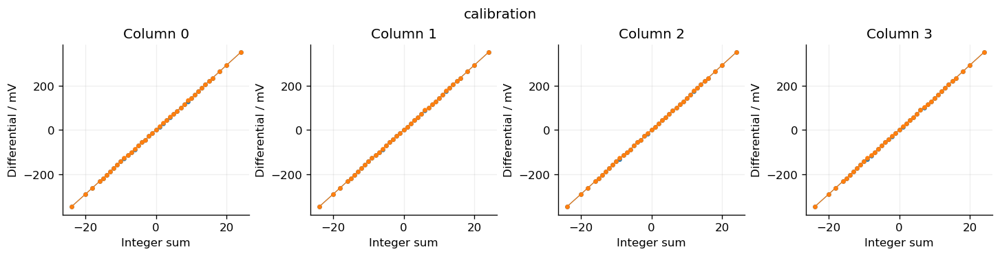

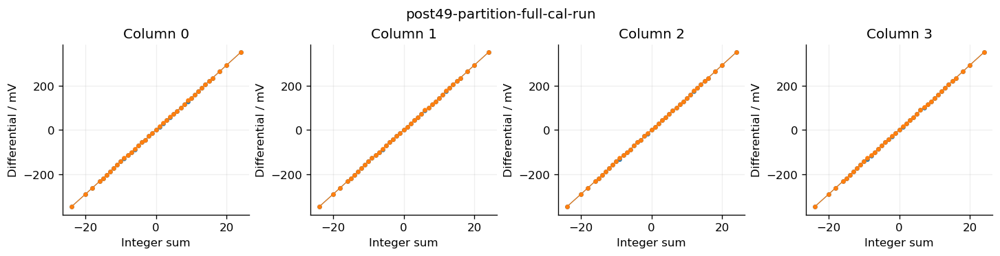

In [59]:
%%native_lab restored-archive-072
%%inline_module legacy_archive_072
from automx_nb_inline_v1.presentation import pretty
"""Full signed-level TT screen and fresh holdout for the 2+2-row read.

The calibration phase adds one deterministic pattern for each of the 39
reachable two-row sums to *each* physical row pair and column. The 16 prior
hard-case measurements add within-level variation. A separate phase tests 32
previously uninspected MHA patterns, without retuning the frozen thresholds.
Neither phase proves ADC noise, continuous aperture, PVT or wrapper sign-off.
"""


import argparse
from datetime import datetime, timezone
from itertools import product
import json
import math
from pathlib import Path
import shutil
import subprocess

from automx_cim.circuit.sky130 import E2M1_MAGNITUDES_X2
from automx_cim.config import Sky130MHAConfig
from automx_cim.spice import parse_measurements
from scripts.analyze_post49_decoder_architectures import _read_reports
from scripts.run_core_candidate_full_tt import (
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    analyze_transfer,
)
from scripts.run_core_candidate_pex import make_pex_deck
from scripts.run_core_pex_coverage import Case, mha_cases
from scripts.run_post49_calibration_tt import (
    analyze_feature_holdout, analyze_feature_training,
)
from scripts.run_post49_row_partition import select_hard_cases, split_case


ROOT = Path(PROJECT_ROOT)
BASE = Path("results/sky130/post49_partition_full_tt")
TARGETED = Path("results/sky130/post49_row_partition/adjacent/measured.json")
FEATURE = "differential_v"
PARTITION = "adjacent"


def reachable_two_row_sums() -> list[int]:
    signed = set(E2M1_MAGNITUDES_X2) | {-value for value in E2M1_MAGNITUDES_X2}
    return sorted({a + b for a in signed for b in signed})


def fresh_holdout_cases(config: Sky130MHAConfig, prior_jobs: list[dict]) -> list[Case]:
    """Reserve MHA ranks 32–63, rejecting any prior 4-row vector."""
    previous = {(tuple(int(value) for value in item["activation_x2"]),
                 tuple(tuple(int(value) for value in row)
                       for row in item["ternary_weights"]))
                for item in prior_jobs}
    cases = mha_cases(config, 64)[32:64]
    if (len(cases) != 32 or
            [case.name for case in cases] !=
            [f"mha_{index:02d}" for index in range(32, 64)] or
            any((case.acts, case.weights) in previous for case in cases) or
            len({(case.acts, case.weights) for case in cases}) != 32):
        raise ValueError("MHA ranks 32–63 are not an independent 2+2 holdout")
    return cases


def calibration_cases() -> list[Case]:
    """Use both row pairs and vary legal weight decompositions by column."""
    signed = sorted(set(E2M1_MAGNITUDES_X2) | {-x for x in E2M1_MAGNITUDES_X2})
    solutions: dict[int, list[tuple[int, int, int, int]]] = {}
    for a, b, wa, wb in product(signed, signed, (-1, 0, 1), (-1, 0, 1)):
        total = a * wa + b * wb
        solutions.setdefault(total, []).append((a, b, wa, wb))
    cases = []
    for total in reachable_two_row_sums():
        ranked = sorted(solutions[total], key=lambda item: (
            -(abs(item[0] * item[2]) + abs(item[1] * item[3])),
            -(item[2] != 0) - (item[3] != 0),
            item))
        first = ranked[0]
        second = next((item for item in ranked[1:]
                       if item[:2] != first[:2]), first)
        acts = (first[0], first[1], second[0], second[1])
        a_options = [(wa, wb) for wa, wb in product((-1, 0, 1), repeat=2)
                     if acts[0] * wa + acts[1] * wb == total]
        b_options = [(wa, wb) for wa, wb in product((-1, 0, 1), repeat=2)
                     if acts[2] * wa + acts[3] * wb == total]
        weights = tuple(tuple((a_options[col % len(a_options)] +
                               b_options[(col + 1) % len(b_options)])[row]
                              for col in range(4)) for row in range(4))
        name = f"p2cal_{'p' if total >= 0 else 'n'}{abs(total):02d}"
        case = Case(name, acts, weights)
        a, b = split_case({"case": name, "activation_x2": list(acts),
                           "ternary_weights": [list(row) for row in weights],
                           "integer_sums": list(case.sums)}, PARTITION)
        if a.sums != (total,) * 4 or b.sums != (total,) * 4:
            raise ValueError(f"two-row generator lost signed sum {total}")
        cases.append(case)
    return cases


def _read(path: Path) -> dict:
    value = json.loads(path.read_text(encoding="utf-8"))
    if not isinstance(value, dict):
        raise ValueError(f"expected JSON object: {path}")
    return value


def _within(root: Path, relative: str) -> Path:
    target = (root / relative).resolve()
    if not target.is_relative_to(root):
        raise ValueError(f"evidence path escapes project: {relative}")
    return target


def _verify_jobs(root: Path, jobs: list[dict], *, model: Path,
                 pex: Path, version: str) -> None:
    for item in jobs:
        deck = _within(root, item["deck"])
        log = _within(root, item["log"])
        checkpoint = _within(root, item["checkpoint"])
        if not deck.is_file() or _digest(deck) != item["deck_sha256"]:
            raise ValueError(f"deck changed or missing: {item['case']}")
        saved = _checkpoint(checkpoint, deck_sha256=item["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved is None or saved["measurements_v"] != item.get("measurements_v"):
            raise ValueError(f"measurement/checkpoint changed: {item['case']}")


def _verify_targeted(root: Path, reports: dict, hashes: dict,
                     model: Path, pex: Path) -> dict:
    path = root / TARGETED
    measured = _read(path)
    selected = select_hard_cases(reports)
    jobs = measured.get("jobs", [])
    if (measured.get("format") != "automx-cim-post49-row-partition-v1" or
            measured.get("status") != "MEASURED_PARTITION_TT_DIAGNOSTIC" or
            measured.get("partition") != PARTITION or
            measured.get("selected_parents") != selected or
            measured.get("input_report_sha256") != hashes or
            measured.get("pex_sha256") != _digest(pex) or
            measured.get("model_sha256") != _digest(model) or
            measured.get("ngspice_version") != reports["cell49"]["ngspice_version"] or
            measured.get("planned_sims") != 32 or
            measured.get("completed_sims") != 32 or
            measured.get("failures") or len(jobs) != 32 or
            not measured.get("analysis", {}).get(
                "both_partial_transfers_ordered_in_selected_set")):
        raise ValueError("complete ordered 4.12d adjacent PEX screen required")
    expected = [(parent, phase, case)
                for parent in selected
                for phase, case in zip(("a", "b"), split_case(parent, PARTITION))]
    for item, (parent, phase, case) in zip(jobs, expected):
        if (item.get("case") != case.name or item.get("phase") != phase or
                item.get("parent_case") != parent["case"] or
                item.get("activation_x2") != list(case.acts) or
                item.get("ternary_weights") != [list(row) for row in case.weights] or
                item.get("integer_sums") != list(case.sums)):
            raise ValueError(f"4.12d selected case changed: {case.name}")
        if _within(root, item["deck"]).read_text(encoding="utf-8") != make_pex_deck(
                case, model, pex, LOAD_FF, PWM_UNIT_PS):
            raise ValueError(f"4.12d stimulus differs from expected: {case.name}")
    _verify_jobs(root, jobs, model=model, pex=pex,
                 version=measured["ngspice_version"])
    recalculated = {phase: analyze_transfer([item for item in jobs
                                             if item["phase"] == phase])
                    for phase in ("a", "b")}
    if measured["analysis"]["phases"] != recalculated:
        raise ValueError("4.12d cached transfer differs from raw measurements")
    return measured


def _budget(root: Path) -> float:
    acceptance = _read(root / "configs/sky130_post49_requirements.json")["acceptance"]
    terms = (float(acceptance["maximum_input_referred_offset_abs_v"]),
             float(acceptance["maximum_input_referred_noise_rms_v"]),
             float(acceptance["maximum_reference_threshold_error_abs_v"]),
             float(acceptance["maximum_aperture_induced_shift_abs_v"]))
    if not all(math.isfinite(value) and value >= 0 for value in terms):
        raise ValueError("finite nonnegative prototype error-budget terms required")
    return terms[0] + 5 * terms[1] + terms[2] + terms[3]


def _prepare_and_run(root: Path, folder: Path, parents: list[Case],
                     model: Path, pex: Path, *, execute: bool,
                     timeout_s: int, expected_version: str) -> tuple[list[dict], list[str], str | None]:
    folder.mkdir(parents=True, exist_ok=True)
    jobs = []
    for parent in parents:
        original = {"case": parent.name, "activation_x2": list(parent.acts),
                    "ternary_weights": [list(row) for row in parent.weights],
                    "integer_sums": list(parent.sums)}
        for phase, case in zip(("a", "b"), split_case(original, PARTITION)):
            deck = folder / f"{case.name}.spice"
            deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS),
                            encoding="utf-8")
            jobs.append({"case": case.name, "parent_case": parent.name,
                         "phase": phase, "activation_x2": list(case.acts),
                         "ternary_weights": [list(row) for row in case.weights],
                         "integer_sums": list(case.sums),
                         "deck": str(deck.relative_to(root)),
                         "deck_sha256": _digest(deck),
                         "log": str((folder / f"{case.name}.log").relative_to(root)),
                         "checkpoint": str((folder / f"{case.name}.receipt.json").relative_to(root))})
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = None
    if ngspice:
        result = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                timeout=15, check=False)
        version = (result.stdout + result.stderr).strip()
        if version != expected_version:
            failures.append("ngspice version changed since 4.12d")
    for index, item in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (_within(root, item[key])
                                 for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=item["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            values = saved["measurements_v"]
            item["reused_checkpoint"] = True
        else:
            if log.is_file():
                log.unlink()  # Only this runner's exact generated log path.
            try:
                result = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                        cwd=folder, text=True, capture_output=True,
                                        timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                failures.append(f"{item['case']}: ngspice timeout after {timeout_s}s")
                break
            output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(output, _expected())
            if (result.returncode or set(values) != set(_expected()) or
                    not all(math.isfinite(value) for value in values.values())):
                failures.append(f"{item['case']}: incomplete ngspice result; see {log}")
                break
            checkpoint.write_text(json.dumps({
                "status": "PASS", "deck_sha256": item["deck_sha256"],
                "pex_sha256": _digest(pex), "model_sha256": _digest(model),
                "ngspice_version": version, "log_sha256": _digest(log),
                "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        item["measurements_v"] = values
        if index == 1 or index % 10 == 0 or index == len(jobs):
            print(f"2+2 {folder.name}: {index}/{len(jobs)} ({item['case']})", flush=True)
    return jobs, failures, version


def _calibration_analysis(jobs: list[dict], targeted_jobs: list[dict],
                          budget_v: float) -> dict:
    levels = reachable_two_row_sums()
    phases = {}
    for phase in ("a", "b"):
        combined = ([item for item in targeted_jobs if item["phase"] == phase] +
                    [item for item in jobs if item["phase"] == phase])
        transfer = analyze_transfer(combined)
        transfer["scope_warning"] = "55 selected/calibration TT PEX cases in this physical row pair only; not full pattern or ADC/PVT sign-off"
        training = analyze_feature_training(combined, FEATURE)
        if any(col["sum_levels"] != levels for col in training["columns"]):
            raise ValueError(f"phase {phase} did not cover all 39 sums in every column")
        phases[phase] = {"case_count": len(combined), "transfer": transfer,
                         "threshold_training": training}
    candidate = all(
        phases[phase]["transfer"]["transfer_observation"] == "ORDERED_IN_MEASURED_SET"
        and phases[phase]["threshold_training"]["minimum_gap_equivalent_v"] > 2 * budget_v
        for phase in ("a", "b"))
    return {"phases": phases, "minimum_required_gap_v": 2 * budget_v,
            "training_margin_candidate": candidate,
            "scope_warning": "39 signed levels per phase plus 16 selected prior cases at TT PEX. One synthetic case per level is not full pattern, noise or PVT coverage."}


def run_calibration(root: str | Path, *, execute: bool = False,
                    timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    reports, hashes = _read_reports(root)
    _, _, model, pex = _provenance(root)
    targeted = _verify_targeted(root, reports, hashes, model, pex)
    parents = calibration_cases()
    folder = root / BASE / "calibration"
    jobs, failures, version = _prepare_and_run(
        root, folder, parents, model, pex, execute=execute, timeout_s=timeout_s,
        expected_version=targeted["ngspice_version"])
    complete = sum("measurements_v" in item for item in jobs)
    budget = _budget(root)
    analysis = (_calibration_analysis(jobs, targeted["jobs"], budget)
                if execute and not failures and complete == len(jobs) else None)
    report = {"format": "automx-cim-post49-partition-calibration-v1",
              "status": "FAIL" if failures else "MEASURED_2P2_LEVEL_SCREEN" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "partition": PARTITION,
              "targeted_sha256": _digest(root / TARGETED),
              "input_report_sha256": hashes,
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "script_sha256": _digest(Path(__file__)),
              "ngspice_version": version, "load_ff": LOAD_FF,
              "pwm_unit_ps": PWM_UNIT_PS, "target_budget_v": budget,
              "reachable_partial_sums": reachable_two_row_sums(),
              "planned_sims": len(jobs), "completed_sims": complete,
              "reused_checkpoints": sum(item.get("reused_checkpoint", False)
                                        for item in jobs),
              "conclusion": ("NOT_MEASURED" if analysis is None else
                             "TT_TRAINING_MARGIN_CANDIDATE" if analysis["training_margin_candidate"]
                             else "BLOCKED_TRAINING_OVERLAP_OR_MARGIN"),
              "analysis": analysis, "failures": failures,
              "parent_cases": [{"case": p.name, "activation_x2": list(p.acts),
                                "ternary_weights": [list(row) for row in p.weights],
                                "integer_sums": list(p.sums)} for p in parents],
              "jobs": jobs,
              "not_signoff": "TT passive-core level screen only; no physical ADC, noise/PVT or wrapper proof"}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


def _verified_calibration(root: Path, targeted: dict, hashes: dict,
                          model: Path, pex: Path) -> dict:
    path = root / BASE / "calibration/measured.json"
    report = _read(path)
    parents = calibration_cases()
    jobs = report.get("jobs", [])
    if (report.get("format") != "automx-cim-post49-partition-calibration-v1" or
            report.get("status") != "MEASURED_2P2_LEVEL_SCREEN" or
            report.get("conclusion") != "TT_TRAINING_MARGIN_CANDIDATE" or
            report.get("partition") != PARTITION or report.get("failures") or
            report.get("targeted_sha256") != _digest(root / TARGETED) or
            report.get("input_report_sha256") != hashes or
            report.get("pex_sha256") != _digest(pex) or
            report.get("model_sha256") != _digest(model) or
            report.get("script_sha256") != _digest(Path(__file__)) or
            report.get("ngspice_version") != targeted["ngspice_version"] or
            report.get("reachable_partial_sums") != reachable_two_row_sums() or
            report.get("planned_sims") != 2 * len(parents) or
            report.get("completed_sims") != 2 * len(parents) or
            len(jobs) != 2 * len(parents) or
            report.get("parent_cases") != [{
                "case": parent.name, "activation_x2": list(parent.acts),
                "ternary_weights": [list(row) for row in parent.weights],
                "integer_sums": list(parent.sums)} for parent in parents] or
            [item["case"] for item in jobs] != [case.name
                for parent in parents for case in split_case({
                    "case": parent.name, "activation_x2": list(parent.acts),
                    "ternary_weights": [list(row) for row in parent.weights],
                    "integer_sums": list(parent.sums)}, PARTITION)]):
        raise ValueError("complete, hash-matched 2+2 level screen required")
    expected = [(parent, phase, case) for parent in parents
                for phase, case in zip(("a", "b"), split_case({
                    "case": parent.name, "activation_x2": list(parent.acts),
                    "ternary_weights": [list(row) for row in parent.weights],
                    "integer_sums": list(parent.sums)}, PARTITION))]
    for item, (parent, phase, case) in zip(jobs, expected):
        if (item.get("parent_case") != parent.name or item.get("phase") != phase or
                item.get("activation_x2") != list(case.acts) or
                item.get("ternary_weights") != [list(row) for row in case.weights] or
                item.get("integer_sums") != list(case.sums) or
                _within(root, item["deck"]).read_text(encoding="utf-8") !=
                make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS)):
            raise ValueError(f"2+2 calibration vector/deck changed: {case.name}")
    _verify_jobs(root, jobs, model=model, pex=pex,
                 version=report["ngspice_version"])
    recomputed = _calibration_analysis(jobs, targeted["jobs"], _budget(root))
    if report.get("analysis") != recomputed or not recomputed["training_margin_candidate"]:
        raise ValueError("2+2 calibration summary differs from measurements")
    return report


def _holdout_analysis(jobs: list[dict], training: dict,
                      parents: list[Case], budget_v: float) -> dict:
    phases = {}
    predicted: dict[tuple[str, int, str], dict[str, int]] = {}
    for phase in ("a", "b"):
        phase_jobs = [item for item in jobs if item["phase"] == phase]
        frozen = training["analysis"]["phases"][phase]["threshold_training"]
        tested = analyze_feature_holdout(frozen, phase_jobs, budget_v)
        phases[phase] = tested
        for column in tested["columns"]:
            for detail in column["details"]:
                key = (detail["case"].removesuffix(f"_{phase}"),
                       column["column"], detail["time"])
                predicted.setdefault(key, {})[phase] = detail["predicted_sum"]
    comparisons = []
    for parent in parents:
        for col in range(4):
            for time in ("t19", "t21"):
                pair = predicted[(parent.name, col, time)]
                comparisons.append({"case": parent.name, "column": col, "time": time,
                                    "expected_sum": parent.sums[col],
                                    "predicted_sum": pair["a"] + pair["b"],
                                    "predicted_partial_a": pair["a"],
                                    "predicted_partial_b": pair["b"]})
    errors = sum(item["expected_sum"] != item["predicted_sum"]
                 for item in comparisons)
    partial_errors = sum(phase["decode_mismatches"] for phase in phases.values())
    near_threshold = sum(phase["samples_below_error_budget"]
                         for phase in phases.values())
    cm_outside = sum(phase["common_mode_outside_training_samples"]
                     for phase in phases.values())
    return {"phases": phases, "combined": {"samples": len(comparisons),
                                           "decode_mismatches": errors,
                                           "details": comparisons},
            "partial_decode_mismatches": partial_errors,
            "below_target_budget_samples": near_threshold,
            "common_mode_outside_training_samples": cm_outside,
            "tt_holdout_candidate": (errors == 0 and partial_errors == 0 and
                                     near_threshold == 0 and cm_outside == 0),
            "scope_warning": "32 new MHA parents at two TT samples; ideal frozen thresholds only. No physical ADC, continuous aperture, noise statistics or PVT sign-off."}


def run_holdout(root: str | Path, *, execute: bool = False,
                timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    reports, hashes = _read_reports(root)
    _, _, model, pex = _provenance(root)
    targeted = _verify_targeted(root, reports, hashes, model, pex)
    training = _verified_calibration(root, targeted, hashes, model, pex)
    prior = [*reports["cell49"]["jobs"], *reports["calibration"]["jobs"],
             *reports["old_holdout"]["jobs"], *training["parent_cases"]]
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    parents = fresh_holdout_cases(config, prior)
    folder = root / BASE / "holdout"
    jobs, failures, version = _prepare_and_run(
        root, folder, parents, model, pex, execute=execute, timeout_s=timeout_s,
        expected_version=targeted["ngspice_version"])
    complete = sum("measurements_v" in item for item in jobs)
    analysis = (_holdout_analysis(jobs, training, parents, _budget(root))
                if execute and not failures and complete == len(jobs) else None)
    report = {"format": "automx-cim-post49-partition-holdout-v1",
              "status": "FAIL" if failures else "MEASURED_2P2_HOLDOUT_TT" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "partition": PARTITION,
              "calibration_sha256": _digest(root / BASE / "calibration/measured.json"),
              "targeted_sha256": _digest(root / TARGETED),
              "input_report_sha256": hashes,
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "script_sha256": _digest(Path(__file__)), "ngspice_version": version,
              "load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
              "planned_sims": len(jobs), "completed_sims": complete,
              "reused_checkpoints": sum(item.get("reused_checkpoint", False)
                                        for item in jobs),
              "conclusion": ("NOT_MEASURED" if analysis is None else
                             "TT_HOLDOUT_CANDIDATE" if analysis["tt_holdout_candidate"]
                             else "BLOCKED_HOLDOUT_DECODE_OR_MARGIN"),
              "analysis": analysis, "failures": failures,
              "parent_cases": [{"case": p.name, "activation_x2": list(p.acts),
                                "ternary_weights": [list(row) for row in p.weights],
                                "integer_sums": list(p.sums)} for p in parents],
              "jobs": jobs,
              "not_signoff": "Fresh TT passive-core holdout only; no physical ADC, noise/PVT or wrapper proof"}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--mode", choices=("calibration", "holdout"),
                        default="calibration")
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    selected_run = run_calibration if args.mode == "calibration" else run_holdout
    result = selected_run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items()
                      if key not in ("jobs", "analysis", "parent_cases")}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_partition_full_tt/calibration/measured.json'], label='post49-partition-full-cal-run')
history.plot_saved_transfer(ROOT, 'results/sky130/post49_partition_full_tt/calibration/measured.json', 'post49-partition-full-cal-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_072 as partition_full_module
    # inline module already loaded from this cell: partition_full_module
    RUN_POST49_PARTITION_LEVELS = True
    partition_levels = partition_full_module.run_calibration(ROOT, execute=RUN_POST49_PARTITION_LEVELS, timeout_s=600)
    print('2+2 full signed-level TT screen:', partition_levels['status'])
    print('New PEX jobs:', partition_levels['completed_sims'], '/', partition_levels['planned_sims'], 'reused:', partition_levels['reused_checkpoints'])
    print('Reachable partial sums per phase:', len(partition_levels['reachable_partial_sums']))
    print('Conclusion:', partition_levels['conclusion'])
    if partition_levels['analysis']:
        for phase, item in partition_levels['analysis']['phases'].items():
            pooled = item['transfer']['samples']['1.9_to_2.1_pooled']['columns']
            print(phase, 'overlaps:', [c['overlap_count'] for c in pooled], 'min gaps V:', [c['min_adjacent_gap_v'] for c in pooled])
        print('Frozen target minimum gap V:', partition_levels['analysis']['minimum_required_gap_v'])
    for problem in partition_levels['failures'][:5]: print(' -', problem)
    print('Report: results/sky130/post49_partition_full_tt/calibration/prepared.json or measured.json')
    print('Training-only passive-core TT screen; not ADC/PVT sign-off.')



### 4.12f 2+2 decoder result: 0 / 256 errors

Thirty-two new MHA patterns × four columns × two times yield 256 sum results.
Evaluation uses new data after locking 2+2 thresholds; the following table
compares the two campaigns' denominators separately.


**Equation / measurement relation:** $$\widehat s_c=\widehat s_{A,c}+\widehat s_{B,c}$$

<a id="guide-native-restored-archive-075"></a>

### Before cell `native-restored-archive-075` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-069`](#guide-native-restored-archive-069).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `reachable_two_row_sums()` | Same task as [`reachable_sums`](#fn-native-restored-archive-060-reachable_sums). |
| `fresh_holdout_cases(config: Sky130MHAConfig, prior_jobs: list[dict])` | Same task as [`heldout_cases`](#fn-native-restored-archive-051-heldout_cases). |
| `calibration_cases()` | Same task as [`calibration_cases`](#fn-native-restored-archive-060-calibration_cases). |
| `_read(path: Path)` | Same task as [`_read`](#fn-native-restored-archive-048-_read). |
| `_within(root: Path, relative: str)` | Same task as [`_within`](#fn-native-restored-archive-072-_within). |
| `_verify_jobs(root: Path, jobs: list[dict], *, model: Path, pex: Path, version: str)` | Same task as [`_verify_jobs`](#fn-native-restored-archive-072-_verify_jobs). |
| `_verify_targeted(root: Path, reports: dict, hashes: dict, model: Path, pex: Path)` | Same task as [`_verify_targeted`](#fn-native-restored-archive-072-_verify_targeted). |
| `_budget(root: Path)` | Same task as [`_budget`](#fn-native-restored-archive-072-_budget). |
| `_prepare_and_run(root: Path, folder: Path, parents: list[Case], model: Path, pex: Path, *, execute: bool, timeout_s: int, expected_version: str)` | Same task as [`_prepare_and_run`](#fn-native-restored-archive-072-_prepare_and_run). |
| `_calibration_analysis(jobs: list[dict], targeted_jobs: list[dict], budget_v: float)` | Same task as [`_calibration_analysis`](#fn-native-restored-archive-072-_calibration_analysis). |
| `run_calibration(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Same task as [`run_calibration`](#fn-native-restored-archive-072-run_calibration). |
| `_verified_calibration(root: Path, targeted: dict, hashes: dict, model: Path, pex: Path)` | Same task as [`_verified_calibration`](#fn-native-restored-archive-063-_verified_calibration). |
| `_holdout_analysis(jobs: list[dict], training: dict, parents: list[Case], budget_v: float)` | Same task as [`_holdout_analysis`](#fn-native-restored-archive-072-_holdout_analysis). |
| `run_holdout(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Same task as [`run_holdout`](#fn-native-restored-archive-072-run_holdout). |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-069`](#data-native-restored-archive-069).


In [60]:
%%native_lab restored-archive-075
%%inline_module legacy_archive_075
from automx_nb_inline_v1.presentation import pretty
"""Full signed-level TT screen and fresh holdout for the 2+2-row read.

The calibration phase adds one deterministic pattern for each of the 39
reachable two-row sums to *each* physical row pair and column. The 16 prior
hard-case measurements add within-level variation. A separate phase tests 32
previously uninspected MHA patterns, without retuning the frozen thresholds.
Neither phase proves ADC noise, continuous aperture, PVT or wrapper sign-off.
"""


import argparse
from datetime import datetime, timezone
from itertools import product
import json
import math
from pathlib import Path
import shutil
import subprocess

from automx_cim.circuit.sky130 import E2M1_MAGNITUDES_X2
from automx_cim.config import Sky130MHAConfig
from automx_cim.spice import parse_measurements
from scripts.analyze_post49_decoder_architectures import _read_reports
from scripts.run_core_candidate_full_tt import (
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance,
    analyze_transfer,
)
from scripts.run_core_candidate_pex import make_pex_deck
from scripts.run_core_pex_coverage import Case, mha_cases
from scripts.run_post49_calibration_tt import (
    analyze_feature_holdout, analyze_feature_training,
)
from scripts.run_post49_row_partition import select_hard_cases, split_case


ROOT = Path(PROJECT_ROOT)
BASE = Path("results/sky130/post49_partition_full_tt")
TARGETED = Path("results/sky130/post49_row_partition/adjacent/measured.json")
FEATURE = "differential_v"
PARTITION = "adjacent"


def reachable_two_row_sums() -> list[int]:
    signed = set(E2M1_MAGNITUDES_X2) | {-value for value in E2M1_MAGNITUDES_X2}
    return sorted({a + b for a in signed for b in signed})


def fresh_holdout_cases(config: Sky130MHAConfig, prior_jobs: list[dict]) -> list[Case]:
    """Reserve MHA ranks 32–63, rejecting any prior 4-row vector."""
    previous = {(tuple(int(value) for value in item["activation_x2"]),
                 tuple(tuple(int(value) for value in row)
                       for row in item["ternary_weights"]))
                for item in prior_jobs}
    cases = mha_cases(config, 64)[32:64]
    if (len(cases) != 32 or
            [case.name for case in cases] !=
            [f"mha_{index:02d}" for index in range(32, 64)] or
            any((case.acts, case.weights) in previous for case in cases) or
            len({(case.acts, case.weights) for case in cases}) != 32):
        raise ValueError("MHA ranks 32–63 are not an independent 2+2 holdout")
    return cases


def calibration_cases() -> list[Case]:
    """Use both row pairs and vary legal weight decompositions by column."""
    signed = sorted(set(E2M1_MAGNITUDES_X2) | {-x for x in E2M1_MAGNITUDES_X2})
    solutions: dict[int, list[tuple[int, int, int, int]]] = {}
    for a, b, wa, wb in product(signed, signed, (-1, 0, 1), (-1, 0, 1)):
        total = a * wa + b * wb
        solutions.setdefault(total, []).append((a, b, wa, wb))
    cases = []
    for total in reachable_two_row_sums():
        ranked = sorted(solutions[total], key=lambda item: (
            -(abs(item[0] * item[2]) + abs(item[1] * item[3])),
            -(item[2] != 0) - (item[3] != 0),
            item))
        first = ranked[0]
        second = next((item for item in ranked[1:]
                       if item[:2] != first[:2]), first)
        acts = (first[0], first[1], second[0], second[1])
        a_options = [(wa, wb) for wa, wb in product((-1, 0, 1), repeat=2)
                     if acts[0] * wa + acts[1] * wb == total]
        b_options = [(wa, wb) for wa, wb in product((-1, 0, 1), repeat=2)
                     if acts[2] * wa + acts[3] * wb == total]
        weights = tuple(tuple((a_options[col % len(a_options)] +
                               b_options[(col + 1) % len(b_options)])[row]
                              for col in range(4)) for row in range(4))
        name = f"p2cal_{'p' if total >= 0 else 'n'}{abs(total):02d}"
        case = Case(name, acts, weights)
        a, b = split_case({"case": name, "activation_x2": list(acts),
                           "ternary_weights": [list(row) for row in weights],
                           "integer_sums": list(case.sums)}, PARTITION)
        if a.sums != (total,) * 4 or b.sums != (total,) * 4:
            raise ValueError(f"two-row generator lost signed sum {total}")
        cases.append(case)
    return cases


def _read(path: Path) -> dict:
    value = json.loads(path.read_text(encoding="utf-8"))
    if not isinstance(value, dict):
        raise ValueError(f"expected JSON object: {path}")
    return value


def _within(root: Path, relative: str) -> Path:
    target = (root / relative).resolve()
    if not target.is_relative_to(root):
        raise ValueError(f"evidence path escapes project: {relative}")
    return target


def _verify_jobs(root: Path, jobs: list[dict], *, model: Path,
                 pex: Path, version: str) -> None:
    for item in jobs:
        deck = _within(root, item["deck"])
        log = _within(root, item["log"])
        checkpoint = _within(root, item["checkpoint"])
        if not deck.is_file() or _digest(deck) != item["deck_sha256"]:
            raise ValueError(f"deck changed or missing: {item['case']}")
        saved = _checkpoint(checkpoint, deck_sha256=item["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved is None or saved["measurements_v"] != item.get("measurements_v"):
            raise ValueError(f"measurement/checkpoint changed: {item['case']}")


def _verify_targeted(root: Path, reports: dict, hashes: dict,
                     model: Path, pex: Path) -> dict:
    path = root / TARGETED
    measured = _read(path)
    selected = select_hard_cases(reports)
    jobs = measured.get("jobs", [])
    if (measured.get("format") != "automx-cim-post49-row-partition-v1" or
            measured.get("status") != "MEASURED_PARTITION_TT_DIAGNOSTIC" or
            measured.get("partition") != PARTITION or
            measured.get("selected_parents") != selected or
            measured.get("input_report_sha256") != hashes or
            measured.get("pex_sha256") != _digest(pex) or
            measured.get("model_sha256") != _digest(model) or
            measured.get("ngspice_version") != reports["cell49"]["ngspice_version"] or
            measured.get("planned_sims") != 32 or
            measured.get("completed_sims") != 32 or
            measured.get("failures") or len(jobs) != 32 or
            not measured.get("analysis", {}).get(
                "both_partial_transfers_ordered_in_selected_set")):
        raise ValueError("complete ordered 4.12d adjacent PEX screen required")
    expected = [(parent, phase, case)
                for parent in selected
                for phase, case in zip(("a", "b"), split_case(parent, PARTITION))]
    for item, (parent, phase, case) in zip(jobs, expected):
        if (item.get("case") != case.name or item.get("phase") != phase or
                item.get("parent_case") != parent["case"] or
                item.get("activation_x2") != list(case.acts) or
                item.get("ternary_weights") != [list(row) for row in case.weights] or
                item.get("integer_sums") != list(case.sums)):
            raise ValueError(f"4.12d selected case changed: {case.name}")
        if _within(root, item["deck"]).read_text(encoding="utf-8") != make_pex_deck(
                case, model, pex, LOAD_FF, PWM_UNIT_PS):
            raise ValueError(f"4.12d stimulus differs from expected: {case.name}")
    _verify_jobs(root, jobs, model=model, pex=pex,
                 version=measured["ngspice_version"])
    recalculated = {phase: analyze_transfer([item for item in jobs
                                             if item["phase"] == phase])
                    for phase in ("a", "b")}
    if measured["analysis"]["phases"] != recalculated:
        raise ValueError("4.12d cached transfer differs from raw measurements")
    return measured


def _budget(root: Path) -> float:
    acceptance = _read(root / "configs/sky130_post49_requirements.json")["acceptance"]
    terms = (float(acceptance["maximum_input_referred_offset_abs_v"]),
             float(acceptance["maximum_input_referred_noise_rms_v"]),
             float(acceptance["maximum_reference_threshold_error_abs_v"]),
             float(acceptance["maximum_aperture_induced_shift_abs_v"]))
    if not all(math.isfinite(value) and value >= 0 for value in terms):
        raise ValueError("finite nonnegative prototype error-budget terms required")
    return terms[0] + 5 * terms[1] + terms[2] + terms[3]


def _prepare_and_run(root: Path, folder: Path, parents: list[Case],
                     model: Path, pex: Path, *, execute: bool,
                     timeout_s: int, expected_version: str) -> tuple[list[dict], list[str], str | None]:
    folder.mkdir(parents=True, exist_ok=True)
    jobs = []
    for parent in parents:
        original = {"case": parent.name, "activation_x2": list(parent.acts),
                    "ternary_weights": [list(row) for row in parent.weights],
                    "integer_sums": list(parent.sums)}
        for phase, case in zip(("a", "b"), split_case(original, PARTITION)):
            deck = folder / f"{case.name}.spice"
            deck.write_text(make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS),
                            encoding="utf-8")
            jobs.append({"case": case.name, "parent_case": parent.name,
                         "phase": phase, "activation_x2": list(case.acts),
                         "ternary_weights": [list(row) for row in case.weights],
                         "integer_sums": list(case.sums),
                         "deck": str(deck.relative_to(root)),
                         "deck_sha256": _digest(deck),
                         "log": str((folder / f"{case.name}.log").relative_to(root)),
                         "checkpoint": str((folder / f"{case.name}.receipt.json").relative_to(root))})
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = None
    if ngspice:
        result = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                timeout=15, check=False)
        version = (result.stdout + result.stderr).strip()
        if version != expected_version:
            failures.append("ngspice version changed since 4.12d")
    for index, item in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (_within(root, item[key])
                                 for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=item["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            values = saved["measurements_v"]
            item["reused_checkpoint"] = True
        else:
            if log.is_file():
                log.unlink()  # Only this runner's exact generated log path.
            try:
                result = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                        cwd=folder, text=True, capture_output=True,
                                        timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                failures.append(f"{item['case']}: ngspice timeout after {timeout_s}s")
                break
            output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(output, _expected())
            if (result.returncode or set(values) != set(_expected()) or
                    not all(math.isfinite(value) for value in values.values())):
                failures.append(f"{item['case']}: incomplete ngspice result; see {log}")
                break
            checkpoint.write_text(json.dumps({
                "status": "PASS", "deck_sha256": item["deck_sha256"],
                "pex_sha256": _digest(pex), "model_sha256": _digest(model),
                "ngspice_version": version, "log_sha256": _digest(log),
                "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        item["measurements_v"] = values
        if index == 1 or index % 10 == 0 or index == len(jobs):
            print(f"2+2 {folder.name}: {index}/{len(jobs)} ({item['case']})", flush=True)
    return jobs, failures, version


def _calibration_analysis(jobs: list[dict], targeted_jobs: list[dict],
                          budget_v: float) -> dict:
    levels = reachable_two_row_sums()
    phases = {}
    for phase in ("a", "b"):
        combined = ([item for item in targeted_jobs if item["phase"] == phase] +
                    [item for item in jobs if item["phase"] == phase])
        transfer = analyze_transfer(combined)
        transfer["scope_warning"] = "55 selected/calibration TT PEX cases in this physical row pair only; not full pattern or ADC/PVT sign-off"
        training = analyze_feature_training(combined, FEATURE)
        if any(col["sum_levels"] != levels for col in training["columns"]):
            raise ValueError(f"phase {phase} did not cover all 39 sums in every column")
        phases[phase] = {"case_count": len(combined), "transfer": transfer,
                         "threshold_training": training}
    candidate = all(
        phases[phase]["transfer"]["transfer_observation"] == "ORDERED_IN_MEASURED_SET"
        and phases[phase]["threshold_training"]["minimum_gap_equivalent_v"] > 2 * budget_v
        for phase in ("a", "b"))
    return {"phases": phases, "minimum_required_gap_v": 2 * budget_v,
            "training_margin_candidate": candidate,
            "scope_warning": "39 signed levels per phase plus 16 selected prior cases at TT PEX. One synthetic case per level is not full pattern, noise or PVT coverage."}


def run_calibration(root: str | Path, *, execute: bool = False,
                    timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    reports, hashes = _read_reports(root)
    _, _, model, pex = _provenance(root)
    targeted = _verify_targeted(root, reports, hashes, model, pex)
    parents = calibration_cases()
    folder = root / BASE / "calibration"
    jobs, failures, version = _prepare_and_run(
        root, folder, parents, model, pex, execute=execute, timeout_s=timeout_s,
        expected_version=targeted["ngspice_version"])
    complete = sum("measurements_v" in item for item in jobs)
    budget = _budget(root)
    analysis = (_calibration_analysis(jobs, targeted["jobs"], budget)
                if execute and not failures and complete == len(jobs) else None)
    report = {"format": "automx-cim-post49-partition-calibration-v1",
              "status": "FAIL" if failures else "MEASURED_2P2_LEVEL_SCREEN" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "partition": PARTITION,
              "targeted_sha256": _digest(root / TARGETED),
              "input_report_sha256": hashes,
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "script_sha256": _digest(Path(__file__)),
              "ngspice_version": version, "load_ff": LOAD_FF,
              "pwm_unit_ps": PWM_UNIT_PS, "target_budget_v": budget,
              "reachable_partial_sums": reachable_two_row_sums(),
              "planned_sims": len(jobs), "completed_sims": complete,
              "reused_checkpoints": sum(item.get("reused_checkpoint", False)
                                        for item in jobs),
              "conclusion": ("NOT_MEASURED" if analysis is None else
                             "TT_TRAINING_MARGIN_CANDIDATE" if analysis["training_margin_candidate"]
                             else "BLOCKED_TRAINING_OVERLAP_OR_MARGIN"),
              "analysis": analysis, "failures": failures,
              "parent_cases": [{"case": p.name, "activation_x2": list(p.acts),
                                "ternary_weights": [list(row) for row in p.weights],
                                "integer_sums": list(p.sums)} for p in parents],
              "jobs": jobs,
              "not_signoff": "TT passive-core level screen only; no physical ADC, noise/PVT or wrapper proof"}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


def _verified_calibration(root: Path, targeted: dict, hashes: dict,
                          model: Path, pex: Path) -> dict:
    path = root / BASE / "calibration/measured.json"
    report = _read(path)
    parents = calibration_cases()
    jobs = report.get("jobs", [])
    if (report.get("format") != "automx-cim-post49-partition-calibration-v1" or
            report.get("status") != "MEASURED_2P2_LEVEL_SCREEN" or
            report.get("conclusion") != "TT_TRAINING_MARGIN_CANDIDATE" or
            report.get("partition") != PARTITION or report.get("failures") or
            report.get("targeted_sha256") != _digest(root / TARGETED) or
            report.get("input_report_sha256") != hashes or
            report.get("pex_sha256") != _digest(pex) or
            report.get("model_sha256") != _digest(model) or
            report.get("script_sha256") != _digest(Path(__file__)) or
            report.get("ngspice_version") != targeted["ngspice_version"] or
            report.get("reachable_partial_sums") != reachable_two_row_sums() or
            report.get("planned_sims") != 2 * len(parents) or
            report.get("completed_sims") != 2 * len(parents) or
            len(jobs) != 2 * len(parents) or
            report.get("parent_cases") != [{
                "case": parent.name, "activation_x2": list(parent.acts),
                "ternary_weights": [list(row) for row in parent.weights],
                "integer_sums": list(parent.sums)} for parent in parents] or
            [item["case"] for item in jobs] != [case.name
                for parent in parents for case in split_case({
                    "case": parent.name, "activation_x2": list(parent.acts),
                    "ternary_weights": [list(row) for row in parent.weights],
                    "integer_sums": list(parent.sums)}, PARTITION)]):
        raise ValueError("complete, hash-matched 2+2 level screen required")
    expected = [(parent, phase, case) for parent in parents
                for phase, case in zip(("a", "b"), split_case({
                    "case": parent.name, "activation_x2": list(parent.acts),
                    "ternary_weights": [list(row) for row in parent.weights],
                    "integer_sums": list(parent.sums)}, PARTITION))]
    for item, (parent, phase, case) in zip(jobs, expected):
        if (item.get("parent_case") != parent.name or item.get("phase") != phase or
                item.get("activation_x2") != list(case.acts) or
                item.get("ternary_weights") != [list(row) for row in case.weights] or
                item.get("integer_sums") != list(case.sums) or
                _within(root, item["deck"]).read_text(encoding="utf-8") !=
                make_pex_deck(case, model, pex, LOAD_FF, PWM_UNIT_PS)):
            raise ValueError(f"2+2 calibration vector/deck changed: {case.name}")
    _verify_jobs(root, jobs, model=model, pex=pex,
                 version=report["ngspice_version"])
    recomputed = _calibration_analysis(jobs, targeted["jobs"], _budget(root))
    if report.get("analysis") != recomputed or not recomputed["training_margin_candidate"]:
        raise ValueError("2+2 calibration summary differs from measurements")
    return report


def _holdout_analysis(jobs: list[dict], training: dict,
                      parents: list[Case], budget_v: float) -> dict:
    phases = {}
    predicted: dict[tuple[str, int, str], dict[str, int]] = {}
    for phase in ("a", "b"):
        phase_jobs = [item for item in jobs if item["phase"] == phase]
        frozen = training["analysis"]["phases"][phase]["threshold_training"]
        tested = analyze_feature_holdout(frozen, phase_jobs, budget_v)
        phases[phase] = tested
        for column in tested["columns"]:
            for detail in column["details"]:
                key = (detail["case"].removesuffix(f"_{phase}"),
                       column["column"], detail["time"])
                predicted.setdefault(key, {})[phase] = detail["predicted_sum"]
    comparisons = []
    for parent in parents:
        for col in range(4):
            for time in ("t19", "t21"):
                pair = predicted[(parent.name, col, time)]
                comparisons.append({"case": parent.name, "column": col, "time": time,
                                    "expected_sum": parent.sums[col],
                                    "predicted_sum": pair["a"] + pair["b"],
                                    "predicted_partial_a": pair["a"],
                                    "predicted_partial_b": pair["b"]})
    errors = sum(item["expected_sum"] != item["predicted_sum"]
                 for item in comparisons)
    partial_errors = sum(phase["decode_mismatches"] for phase in phases.values())
    near_threshold = sum(phase["samples_below_error_budget"]
                         for phase in phases.values())
    cm_outside = sum(phase["common_mode_outside_training_samples"]
                     for phase in phases.values())
    return {"phases": phases, "combined": {"samples": len(comparisons),
                                           "decode_mismatches": errors,
                                           "details": comparisons},
            "partial_decode_mismatches": partial_errors,
            "below_target_budget_samples": near_threshold,
            "common_mode_outside_training_samples": cm_outside,
            "tt_holdout_candidate": (errors == 0 and partial_errors == 0 and
                                     near_threshold == 0 and cm_outside == 0),
            "scope_warning": "32 new MHA parents at two TT samples; ideal frozen thresholds only. No physical ADC, continuous aperture, noise statistics or PVT sign-off."}


def run_holdout(root: str | Path, *, execute: bool = False,
                timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    reports, hashes = _read_reports(root)
    _, _, model, pex = _provenance(root)
    targeted = _verify_targeted(root, reports, hashes, model, pex)
    training = _verified_calibration(root, targeted, hashes, model, pex)
    prior = [*reports["cell49"]["jobs"], *reports["calibration"]["jobs"],
             *reports["old_holdout"]["jobs"], *training["parent_cases"]]
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    parents = fresh_holdout_cases(config, prior)
    folder = root / BASE / "holdout"
    jobs, failures, version = _prepare_and_run(
        root, folder, parents, model, pex, execute=execute, timeout_s=timeout_s,
        expected_version=targeted["ngspice_version"])
    complete = sum("measurements_v" in item for item in jobs)
    analysis = (_holdout_analysis(jobs, training, parents, _budget(root))
                if execute and not failures and complete == len(jobs) else None)
    report = {"format": "automx-cim-post49-partition-holdout-v1",
              "status": "FAIL" if failures else "MEASURED_2P2_HOLDOUT_TT" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "partition": PARTITION,
              "calibration_sha256": _digest(root / BASE / "calibration/measured.json"),
              "targeted_sha256": _digest(root / TARGETED),
              "input_report_sha256": hashes,
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "script_sha256": _digest(Path(__file__)), "ngspice_version": version,
              "load_ff": LOAD_FF, "pwm_unit_ps": PWM_UNIT_PS,
              "planned_sims": len(jobs), "completed_sims": complete,
              "reused_checkpoints": sum(item.get("reused_checkpoint", False)
                                        for item in jobs),
              "conclusion": ("NOT_MEASURED" if analysis is None else
                             "TT_HOLDOUT_CANDIDATE" if analysis["tt_holdout_candidate"]
                             else "BLOCKED_HOLDOUT_DECODE_OR_MARGIN"),
              "analysis": analysis, "failures": failures,
              "parent_cases": [{"case": p.name, "activation_x2": list(p.acts),
                                "ternary_weights": [list(row) for row in p.weights],
                                "integer_sums": list(p.sums)} for p in parents],
              "jobs": jobs,
              "not_signoff": "Fresh TT passive-core holdout only; no physical ADC, noise/PVT or wrapper proof"}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--mode", choices=("calibration", "holdout"),
                        default="calibration")
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    selected_run = run_calibration if args.mode == "calibration" else run_holdout
    result = selected_run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items()
                      if key not in ("jobs", "analysis", "parent_cases")}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/post49_partition_full_tt/holdout/measured.json'], label='post49-partition-full-holdout-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_075 as partition_full_module
    # inline module already loaded from this cell: partition_full_module
    RUN_POST49_PARTITION_HOLDOUT = True
    try:
        partition_holdout = partition_full_module.run_holdout(ROOT, execute=RUN_POST49_PARTITION_HOLDOUT, timeout_s=600)
    except (FileNotFoundError, ValueError) as error:
        partition_holdout = None
        print('2+2 fresh holdout: BLOCKED -', error)
    if partition_holdout:
        print('2+2 fresh TT holdout:', partition_holdout['status'])
        print('New PEX jobs:', partition_holdout['completed_sims'], '/', partition_holdout['planned_sims'], 'reused:', partition_holdout['reused_checkpoints'])
        print('Conclusion:', partition_holdout['conclusion'])
        if partition_holdout['analysis']:
            result = partition_holdout['analysis']
            print('Combined full-sum decode errors:', result['combined']['decode_mismatches'], '/', result['combined']['samples'])
            print('Partial decode errors:', result['partial_decode_mismatches'])
            print('Below target-budget distance:', result['below_target_budget_samples'])
            print('Common mode outside training:', result['common_mode_outside_training_samples'])
        for problem in partition_holdout['failures'][:5]: print(' -', problem)
        print('Report: results/sky130/post49_partition_full_tt/holdout/prepared.json or measured.json')
    print('Fresh TT passive-core holdout only; not physical ADC/PVT sign-off.')



| measured | Result |
|---|---|
| analysis.phases.a.columns[0].decode_mismatches | 0 |
| analysis.phases.a.columns[1].decode_mismatches | 0 |
| analysis.phases.a.columns[2].decode_mismatches | 0 |
| analysis.phases.a.columns[3].decode_mismatches | 0 |
| analysis.phases.a.decode_mismatches | 0 |
| analysis.phases.b.columns[0].decode_mismatches | 0 |
| analysis.phases.b.columns[1].decode_mismatches | 0 |
| analysis.phases.b.columns[2].decode_mismatches | 0 |
| analysis.phases.b.columns[3].decode_mismatches | 0 |
| analysis.phases.b.decode_mismatches | 0 |
| analysis.combined.decode_mismatches | 0 |
| analysis.partial_decode_mismatches | 0 |

Source: `results/sky130/post49_partition_full_tt/holdout/measured.json` · 2026-10-14T14:13:51.197565+00:00

### Fresh-run before/after PEX results

The plot reads the exact four ngspice measurements performed in the preceding
two cells.


<a id="guide-native-story-partition_result"></a>

### Before cell `native-story-partition_result` — F6–F7

**Implementation:** Use the operation group explained in [cell `native-restored-archive-069`](#guide-native-restored-archive-069).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-partition_result-partition_result"></a>`partition_result(root)` | Plot and summarize the new run's before/after pilot results; retain the 2+2 recipe as a readout reference rather than relabeling old logs as new measurements. |

**Data and downstream use:** Follow the [contract described for `native-story-transfer_error`](#data-native-story-transfer_error).


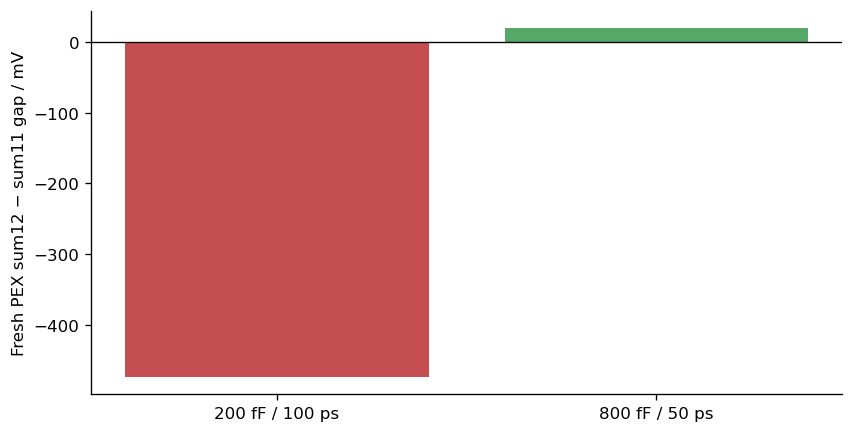

In [61]:
%%native_lab story-partition_result
%%inline_module story_partition_result
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def partition_result(root):
    import matplotlib.pyplot as plt
    targeted=read_report(root,BASE+'post49_row_partition/adjacent/measured.json')
    cal=read_report(root,BASE+'post49_partition_full_tt/calibration/measured.json')
    held=read_report(root,BASE+'post49_partition_full_tt/holdout/measured.json');a=held['analysis']['combined']
    before=read_report(root,BASE+'post49_decoder_diagnostic.json')['analysis']
    before_wrong=before['decode_mismatches'];before_samples=before['sample_count']
    wrong=sum(r['expected_sum']!=r['predicted_sum'] for r in a['details'])
    if len(a['details'])!=a['samples'] or wrong!=a['decode_mismatches']:raise ValueError('2+2 detail/count mismatch')
    print('Intervention: separately precharge/read rows [0,1] and [2,3], decode partials, then add digitally.')
    print('Targeted jobs:',targeted['completed_sims'],'/',targeted['planned_sims'],'; full signed calibration:',cal['completed_sims'],'/',cal['planned_sims'])
    gaps=[v['threshold_training']['minimum_gap_equivalent_v']*1000 for v in cal['analysis']['phases'].values()]
    table(['Measurement','Dataset','Result'],[
        ['Scalar decoder before revision','16 patterns × 4 columns × 2 sample times',f'{before_wrong} / {before_samples} decode errors'],
        ['2+2 calibration phase A','39 partial-sum levels',f'{gaps[0]:.4f} mV minimum gap'],
        ['2+2 calibration phase B','39 partial-sum levels',f'{gaps[1]:.4f} mV minimum gap'],
        ['2+2 frozen decoder','32 fresh patterns × 4 columns × 2 sample times',f'{wrong} / {a["samples"]} decode errors']])
    display(Markdown('The holdout sets differ in size and patterns; these development milestones have separate denominators. The 2+2 thresholds come from calibration frozen before reading fresh holdout.'))
    fig,axes=plt.subplots(1,2,figsize=(11,3.4),layout='constrained')
    axes[0].bar([f'Scalar\n{before_wrong}/{before_samples}\n16 patterns',f'2+2\n{wrong}/{a["samples"]}\n32 fresh patterns'],[100*before_wrong/before_samples,100*wrong/a['samples']],color=['#c44e52','#55a868']);axes[0].set_ylabel('Measured decode errors / %')
    axes[1].bar(['Phase A','Phase B'],gaps,color='#4c72b0');axes[1].axhline(cal['analysis']['minimum_required_gap_v']*1000,color='gray',ls='--',label='Recorded target');axes[1].set_ylabel('Measured calibration minimum gap / mV');axes[1].legend()
    plt.show();plt.close(fig)
    EVIDENCE['partition_decode']={'samples':a['samples'],'mismatches':wrong,'minimum_gaps_mv':gaps,'source':BASE+'post49_partition_full_tt/holdout/measured.json'}
    return a

# NOTEBOOK_RUN
fresh_pex_progress=fresh_pilot.plot_progress(WORK)


### 4.13 Corner preparation data

Retain earlier deck sources and corner configurations for measurement reproduction.


**Experimental source:** the following receipt records the prepared configuration and deck.


<a id="guide-native-restored-archive-078"></a>

### Before cell `native-restored-archive-078` — F6

**Implementation:** Enumerate model corners and generate smoke tests for difficult load/pulse patterns. Explicit device corners are necessary when comparing voltage levels and speed.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-078-model_sections"></a>`model_sections(text: str)` | Read actual .lib declarations in the model file and return selectable corners instead of inferring corner names from models/includes. |
| <a id="fn-native-restored-archive-078-select_worst_cases"></a>`select_worst_cases(jobs: list[dict])` | Select extreme patterns producing each column's smallest pooled gap so the smoke test focuses on difficult cases. |
| <a id="fn-native-restored-archive-078-make_smoke_deck"></a>`make_smoke_deck(case: Case, model: Path, pex: Path, point: tuple[str, float, int])` | Generate a selected-case deck at one corner/VDD/temperature point, keeping PEX and sampling fixed for PVT sensitivity comparison. |
| <a id="fn-native-restored-archive-078-summarize_point"></a>`summarize_point(jobs: list[dict], pairs: list[dict])` | Aggregate jobs at a corner/VDD/temperature point, recompute worst-case pair gaps, and compare baseline in a PVT smoke table. |
| <a id="fn-native-restored-archive-078-run"></a>`run(root: str \| Path, *, execute: bool=False, timeout_s: int=600)` | Orchestrate PVT smoke tests on minimum-gap patterns: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

<a id="data-native-restored-archive-078"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive actual model .lib corner names, (corner,VDD,temperature) points, and worst-case gap pairs from the earlier TT report.
- **Return values and saved artifacts:** Generate consistent-pattern/PEX PVT smoke decks, parse voltage/gap at each point, and report comparison with TT.
- **Downstream consumers:** The physical-condition table uses measured points to state scope; a prepared report is not evidence of a completed full-corner campaign.


In [62]:
%%native_lab restored-archive-078
%%inline_module legacy_archive_078
from automx_nb_inline_v1.presentation import pretty
"""Small TT/SS/FF passive-core PEX smoke screen at the frozen operating point.

Select the worst adjacent-level pair from each of four columns in the
117-case TT set plus an idle-zero case. PREPARED does not run ngspice;
MEASURED_PVT_SMOKE is diagnostic only, not a supported-PVT or ADC PASS.
"""


import argparse
from datetime import datetime, timezone
import json
import math
from pathlib import Path
import re
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.spice import parse_measurements  # noqa: E402
from scripts.run_core_candidate_full_tt import (  # noqa: E402
    LOAD_FF, PWM_UNIT_PS, _checkpoint, _digest, _expected, _provenance, _read,
)
from scripts.run_core_pex_coverage import Case, make_deck  # noqa: E402
from scripts.run_post49_decoder_diagnostic import run as check_decoder_inputs  # noqa: E402

OUTPUT = Path("results/sky130/post49_pvt_smoke")


def model_sections(text: str) -> set[str]:
    """Only declared .lib sections, not model names or include filenames."""
    return {name.lower() for name in re.findall(
        r"(?im)^\s*\.lib\s+(tt|ss|ff)\s*(?:\*.*)?$", text)}


def select_worst_cases(jobs: list[dict]) -> tuple[list[dict], list[dict]]:
    """Pick extremal cases that define each column's narrowest pooled gap."""
    if not jobs:
        raise ValueError("no measured TT jobs")
    chosen: dict[str, dict] = {}
    pairs = []
    for col in range(4):
        levels: dict[int, list[tuple[float, dict, str]]] = {}
        for job in jobs:
            total = int(job["integer_sums"][col])
            for time in ("t19", "t21"):
                value = float(job["measurements_v"][f"diff_c{col}_{time}"])
                if not math.isfinite(value):
                    raise ValueError("non-finite TT measurement")
                levels.setdefault(total, []).append((value, job, time))
        sums = sorted(levels)
        if len(sums) < 2:
            raise ValueError(f"column {col}: fewer than two measured levels")
        intervals = [(total, max(levels[total], key=lambda item: item[0]),
                      min(levels[total], key=lambda item: item[0])) for total in sums]
        gaps = [(higher[2][0] - lower[1][0], lower, higher)
                for lower, higher in zip(intervals, intervals[1:])]
        gap, lower, higher = min(gaps, key=lambda item: item[0])
        if gap <= 0:
            raise ValueError(f"column {col}: pooled TT levels overlap")
        chosen[lower[1][1]["case"]] = lower[1][1]
        chosen[higher[2][1]["case"]] = higher[2][1]
        pairs.append({"column": col, "lower_sum": lower[0], "higher_sum": higher[0],
                      "lower_case": lower[1][1]["case"],
                      "higher_case": higher[2][1]["case"],
                      "tt_pooled_gap_v": gap})
    zero = next((job for job in jobs if job["case"] == "zero"), None)
    if zero is None or any(int(value) != 0 for value in zero["integer_sums"]):
        raise ValueError("idle-zero case missing or malformed")
    chosen["zero"] = zero
    return list(chosen.values()), pairs


def make_smoke_deck(case: Case, model: Path, pex: Path,
                    point: tuple[str, float, int]) -> str:
    lines = make_deck(case, model, pex, point,
                      load_ff=LOAD_FF, pwm_unit_ps=PWM_UNIT_PS).splitlines()
    tran = next(index for index, line in enumerate(lines) if line.startswith(".tran "))
    lines[tran:tran] = [f".measure tran {kind}_c{col}_t21 FIND V({node}{col}) AT=2.1n"
                        for col in range(4)
                        for kind, node in (("diff", "DIFF"), ("blp", "BLP"),
                                           ("bln", "BLN"))]
    return "\n".join(lines) + "\n"


def summarize_point(jobs: list[dict], pairs: list[dict]) -> dict:
    by_name = {job["case"]: job["measurements_v"] for job in jobs}
    if set(by_name) != {job["case"] for job in jobs}:
        raise ValueError("duplicate measured case")
    report = []
    for pair in pairs:
        col = pair["column"]
        values = []
        for time in ("t19", "t21"):
            lower = float(by_name[pair["lower_case"]][f"diff_c{col}_{time}"])
            higher = float(by_name[pair["higher_case"]][f"diff_c{col}_{time}"])
            values.append(higher - lower)
        report.append({**pair, "gap_at_1p9_v": values[0],
                       "gap_at_2p1_v": values[1],
                       "ordered_at_both_samples": all(value > 0 for value in values)})
    zero = by_name["zero"]
    return {"pairs": report,
            "all_selected_pairs_ordered": all(x["ordered_at_both_samples"] for x in report),
            "minimum_selected_gap_v": min(min(x["gap_at_1p9_v"], x["gap_at_2p1_v"])
                                          for x in report),
            "maximum_idle_zero_abs_v": max(abs(float(zero[f"diff_c{col}_{time}"]))
                                           for col in range(4) for time in ("t19", "t21"))}


def run(root: str | Path, *, execute: bool = False, timeout_s: int = 600) -> dict:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    diagnostic = check_decoder_inputs(root)  # Validates 4.9/4.10 source/hash chain.
    spec = _read(root / "configs/sky130_post49_requirements.json")
    points = spec["pvt_plan"]["first_screen_matrix"]
    if (len(points) != 3 or
            {point["corner"] for point in points} != {"tt", "ss", "ff"} or
            any(point["vdd_v"] != 1.8 or point["temperature_c"] != 25
                for point in points)):
        raise ValueError("first-screen matrix is not TT/SS/FF at 1.8 V/25 C")
    _, _, model, pex = _provenance(root)
    available = model_sections(model.read_text(encoding="utf-8", errors="replace"))
    missing = sorted({point["corner"] for point in points} - available)
    if missing:
        raise ValueError(f"model library lacks .lib sections: {', '.join(missing)}")
    training = _read(root / "results/sky130/core_candidate_full_tt/measured.json")
    holdout = _read(root / "results/sky130/post49_holdout_tt/measured.json")
    selected, pairs = select_worst_cases(training["jobs"] + holdout["jobs"])
    folder = root / OUTPUT
    folder.mkdir(parents=True, exist_ok=True)
    ngspice = shutil.which("ngspice") if execute else None
    failures = ["ngspice not on PATH"] if execute and not ngspice else []
    version = ""
    if ngspice:
        response = subprocess.run([ngspice, "-v"], text=True, capture_output=True,
                                  timeout=15, check=False)
        version = (response.stdout + response.stderr).strip()
    jobs = []
    for point in points:
        pvt = (point["corner"], point["vdd_v"], point["temperature_c"])
        point_dir = folder / point["corner"]
        point_dir.mkdir(parents=True, exist_ok=True)
        for source in selected:
            case = Case(source["case"], tuple(source["activation_x2"]),
                        tuple(tuple(row) for row in source["ternary_weights"]))
            deck = point_dir / f"{case.name}.spice"
            deck.write_text(make_smoke_deck(case, model, pex, pvt), encoding="utf-8")
            jobs.append({"case": case.name, "point": point,
                         "deck": str(deck.relative_to(root)),
                         "deck_sha256": _digest(deck),
                         "log": str((point_dir / f"{case.name}.log").relative_to(root)),
                         "checkpoint": str((point_dir / f"{case.name}.receipt.json").relative_to(root))})
    baseline = {job["case"]: job["measurements_v"] for job in training["jobs"] + holdout["jobs"]}
    for index, job in enumerate(jobs if execute and not failures else [], start=1):
        deck, log, checkpoint = (root / job[key] for key in ("deck", "log", "checkpoint"))
        saved = _checkpoint(checkpoint, deck_sha256=job["deck_sha256"],
                            pex_sha256=_digest(pex), model_sha256=_digest(model),
                            ngspice_version=version, log=log)
        if saved:
            values = saved["measurements_v"]
            job["reused_checkpoint"] = True
        else:
            if log.is_file():
                log.unlink()
            try:
                result = subprocess.run([ngspice, "-b", "-o", str(log), str(deck)],
                                        cwd=deck.parent, text=True, capture_output=True,
                                        timeout=timeout_s, check=False)
            except subprocess.TimeoutExpired:
                failures.append(f"{job['point']['corner']}/{job['case']}: timeout")
                break
            output = log.read_text(encoding="utf-8", errors="replace") if log.is_file() else ""
            values = parse_measurements(output, _expected())
            if result.returncode or set(values) != set(_expected()) or not all(
                    math.isfinite(value) for value in values.values()):
                failures.append(f"{job['point']['corner']}/{job['case']}: incomplete ngspice result")
                break
            checkpoint.write_text(json.dumps({
                "status": "PASS", "deck_sha256": job["deck_sha256"],
                "pex_sha256": _digest(pex), "model_sha256": _digest(model),
                "ngspice_version": version, "log_sha256": _digest(log),
                "measurements_v": values}, indent=2) + "\n", encoding="utf-8")
        if job["point"]["corner"] == "tt":
            prior = baseline[job["case"]]
            if any(abs(values[key] - float(prior[key])) > 0.001 for key in _expected()):
                failures.append(f"TT replay differs by >1 mV: {job['case']}")
                break
        job["measurements_v"] = values
        print(f"PVT smoke: {index}/{len(jobs)} {job['point']['corner']} {job['case']}", flush=True)
    completed = sum("measurements_v" in job for job in jobs)
    summaries = {}
    if execute and not failures and completed == len(jobs):
        for point in points:
            corner = point["corner"]
            summaries[corner] = summarize_point([job for job in jobs
                                                 if job["point"]["corner"] == corner], pairs)
    report = {"format": "automx-cim-post49-pvt-smoke-v1",
              "status": "FAIL" if failures else "MEASURED_PVT_SMOKE" if execute else "PREPARED",
              "timestamp_utc": datetime.now(timezone.utc).isoformat(),
              "cell49_sha256": diagnostic["cell49_sha256"],
              "old_holdout_sha256": diagnostic["holdout_sha256"],
              "requirements_sha256": diagnostic["requirements_sha256"],
              "pex_sha256": _digest(pex), "model_sha256": _digest(model),
              "model_sections_present": sorted(available),
              "point_matrix": points, "selected_case_names": [job["case"] for job in selected],
              "selected_pairs": pairs, "planned_sims": len(jobs), "completed_sims": completed,
              "reused_checkpoints": sum(job.get("reused_checkpoint", False) for job in jobs),
              "summaries": summaries, "failures": failures, "jobs": jobs,
              "not_signoff": "Selected passive-core PEX cases only; no converter/mismatch/noise/full-PVT or wrapper proof"}
    target = folder / ("measured.json" if execute else "prepared.json")
    target.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--run", action="store_true")
    parser.add_argument("--timeout-s", type=int, default=600)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, timeout_s=args.timeout_s)
    print(pretty({key: value for key, value in result.items() if key != "jobs"}, indent=2))
    if result["status"] == "FAIL":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['configs/sky130_post49_requirements.json'], label='post49-pvt-smoke-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_078 as pvt_smoke_module
    # inline module already loaded from this cell: pvt_smoke_module
    RUN_POST49_PVT_SMOKE = False
    pvt_smoke = pvt_smoke_module.run(ROOT, execute=RUN_POST49_PVT_SMOKE, timeout_s=600)
    print('Selected-case PVT smoke:', pvt_smoke['status'])
    print('Selected cases:', ', '.join(pvt_smoke['selected_case_names']))
    print('Planned/measured:', pvt_smoke['planned_sims'], '/', pvt_smoke['completed_sims'])
    for corner, summary in pvt_smoke['summaries'].items():
        print(f"{corner}: selected pairs ordered={summary['all_selected_pairs_ordered']}, min gap={summary['minimum_selected_gap_v']:.6g} V, idle zero={summary['maximum_idle_zero_abs_v']:.6g} V")
    for problem in pvt_smoke['failures'][:5]:
        print(' -', problem)
    print('This is NOT ADC or full-PVT sign-off.')



| sky130_post49_requirements | Result |
|---|---|
| acceptance.minimum_holdout_patterns | 16 |
| acceptance.maximum_reference_threshold_error_abs_v | 0.00015 |
| format | automx-cim-post49-requirements-v1 |
| status | DESIGN_BASELINE_FROZEN_UNVERIFIED |
| candidate_core_stimulus.load_ff | 800 |
| candidate_core_stimulus.pwm_unit_ps | 50 |
| decoder.output_bits | 7 |
| decoder.integer_sum_min | -48 |
| decoder.integer_sum_max | 48 |
| decoder.uses_common_mode | True |
| timing.sample_time_ns | 2.1 |
| timing.aperture_start_ns | 1.9 |

Source: `configs/sky130_post49_requirements.json` · 2026-10-07T06:59:05.919707+00:00

### 4.14 Verification with sampling load

The 820 fF total-load candidate combines 800 fF bitline and 20 fF sampling-node
loads. All 174/174 jobs completed; holdout-sum decoding has zero errors and
minimum training gap is 6.57023 mV.


In [63]:
%%native_lab restored-archive-080
%%inline_module legacy_archive_080
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/wrapper_load_full_tt/c820ff/measured.json', 'results/sky130/wrapper_idle_augmented_tt/c820ff/measured.json'], label='story-60-0-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import json

    load_reports = {
        "820 fF full TT": ROOT / "results/sky130/wrapper_load_full_tt/c820ff/measured.json",
        "idle-augmented TT": ROOT / "results/sky130/wrapper_idle_augmented_tt/c820ff/measured.json",
    }
    for label, path in load_reports.items():
        if not path.is_file():
            print(label, ": NOT_COPIED from server")
            continue
        report = json.loads(path.read_text(encoding="utf-8"))
        print(label, ":", report.get("status"), report.get("conclusion"))
        print("  simulations:", report.get("completed_sims",
              report.get("completed_new_sims")), "/",
              report.get("planned_sims", report.get("planned_new_sims")))
        print("  holdout:", report.get("summary", {}))



| measured | Result |
|---|---|
| summary.holdout_combined_decode_mismatches | 0 |
| summary.holdout_partial_decode_mismatches | 0 |
| fresh_holdout_analysis.phases.a.columns[0].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.a.columns[1].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.a.columns[2].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.a.columns[3].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.a.decode_mismatches | 0 |
| fresh_holdout_analysis.phases.b.columns[0].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.b.columns[1].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.b.columns[2].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.b.columns[3].decode_mismatches | 0 |
| fresh_holdout_analysis.phases.b.decode_mismatches | 0 |

Source: `results/sky130/wrapper_load_full_tt/c820ff/measured.json` · 2026-10-06T18:02:14.152950+00:00

### 4.15 Sample/hold and edge timing

Read completed switch-level and aperture campaigns. Receipts connect drift
and sampling-time measurements with their corresponding decks/logs.


In [64]:
%%native_lab restored-archive-082
%%inline_module legacy_archive_082
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/sky130/wrapper_sample_hold_tt/measured.json', 'results/sky130/wrapper_sample_hold_tt/decomposition.json', 'results/sky130/wrapper_sample_hold_edge_tt/measured.json', 'results/sky130/flow2_sample_hold_sweep/pex_3d4425cdc7db/measured.json', 'results/sky130/flow2_sample_hold_settled_tt/pex_3d4425cdc7db/measured.json', 'results/sky130/flow2_sample_hold_aperture_tt/pex_3d4425cdc7db/measured.json', 'results/sky130/flow2_sample_hold_refined_aperture_tt/pex_3d4425cdc7db/measured.json'], label='story-60-1-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    analog_paths = {
        "sample/hold TT": ROOT / "results/sky130/wrapper_sample_hold_tt/measured.json",
        "sample/hold decomposition": ROOT / "results/sky130/wrapper_sample_hold_tt/decomposition.json",
        "sample/hold edge": ROOT / "results/sky130/wrapper_sample_hold_edge_tt/measured.json",
    }
    for label, path in analog_paths.items():
        if not path.is_file():
            print(label, ": NOT_COPIED from server")
            continue
        report = json.loads(path.read_text(encoding="utf-8"))
        print(label, ":", report.get("status"), report.get("conclusion", ""))
        print("  summary:", report.get("summary", {}))



| measured | Result |
|---|---|
| completed_sims | 18 |
| planned_sims | 18 |
| format | automx-cim-flow2-sample-hold-sweep-v1 |
| status | MEASURED_TT_SAMPLING_SWEEP_DIAGNOSTIC |
| target_differential_error_v | 0.0008 |
| widths_um | 0.42, 0.84, 1.68 |
| fall_times_ps | 5, 20, 50 |
| times_ns.pre | 2.095 |
| times_ns.post | 2.15 |
| groups[0].width_um | 0.42 |
| groups[0].fall_ps | 5 |
| groups[0].maximum_capture_error_v | 0.011195 |

Source: `results/sky130/flow2_sample_hold_sweep/pex_3d4425cdc7db/measured.json` · 2026-10-14T16:51:26.810080+00:00

| measured | Result |
|---|---|
| completed_sims | 6 |
| planned_sims | 6 |
| times_ns.late_hold | 2.4 |
| format | automx-cim-flow2-sample-hold-settled-tt-v1 |
| status | MEASURED_TT_SETTLED_HOLD_DIAGNOSTIC |
| target_differential_error_v | 0.0008 |
| turnoff_start_ns | 2.105 |
| times_ns.pre_edge | 2.095 |
| times_ns.old_post | 2.15 |
| times_ns.full_off | 2.2 |
| groups[0].width_um | 0.84 |
| groups[0].fall_ps | 5 |

Source: `results/sky130/flow2_sample_hold_settled_tt/pex_3d4425cdc7db/measured.json` · 2026-10-14T17:09:03.331751+00:00

| measured | Result |
|---|---|
| completed_sims | 10 |
| planned_sims | 10 |
| points[0].columns[0].hold_drift_v | 1e-06 |
| points[0].columns[1].hold_drift_v | 1e-06 |
| points[0].columns[2].hold_drift_v | 1e-06 |
| points[0].columns[3].hold_drift_v | 3e-06 |
| points[1].columns[0].hold_drift_v | 0 |
| points[1].columns[1].hold_drift_v | 0 |
| points[1].columns[2].hold_drift_v | 1e-06 |
| points[1].columns[3].hold_drift_v | 0 |
| points[2].columns[0].hold_drift_v | 0 |
| points[2].columns[1].hold_drift_v | 1e-06 |

Source: `results/sky130/flow2_sample_hold_aperture_tt/pex_3d4425cdc7db/measured.json` · 2026-10-14T17:28:58.978507+00:00

| measured | Result |
|---|---|
| anchors[0].columns[0].hold_drift_v | 0 |
| anchors[0].columns[1].hold_drift_v | 1e-06 |
| anchors[0].columns[2].hold_drift_v | 1e-06 |
| anchors[0].columns[3].hold_drift_v | 1e-06 |
| anchors[1].columns[0].hold_drift_v | 1e-06 |
| anchors[1].columns[1].hold_drift_v | 0 |
| anchors[1].columns[2].hold_drift_v | 0 |
| anchors[1].columns[3].hold_drift_v | 1e-06 |
| anchors[2].columns[0].hold_drift_v | 0 |
| anchors[2].columns[1].hold_drift_v | 1e-06 |
| anchors[2].columns[2].hold_drift_v | 1e-06 |
| anchors[2].columns[3].hold_drift_v | 2e-06 |

Source: `results/sky130/flow2_sample_hold_refined_aperture_tt/pex_3d4425cdc7db/measured.json` · 2026-10-14T17:52:56.507271+00:00

## 5. RTL simulation and SKY130 core-bound top implementation

### 5.1 Stage 7: verify the base-only 32×8 macro controller

The controller reuses physical 4×4 tiles for a logical 32×8 operation.
Verilator substitutes an architectural macro model, checks transaction
order, Q24 accumulation, scaling, ready/valid backpressure, and result
latency against the Python oracle. It does not model physical sensing.

**Equation / measurement relation:** $$A_{\rm next}=A_{\rm prev}+(2^{E-128}/2)s_c$$

<a id="guide-native-restored-archive-085"></a>

### Before cell `native-restored-archive-085` — F7–F8

**Implementation:** Generate Icarus vectors/testbenches for accumulation, reset, backpressure, and two-read protocol. Protocol verification checks ordering/data retention separately from transistor measurements.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_hash(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-085-_vectors"></a>`_vectors()` | Generate/load activation, ternary-weight, and expected-result vectors from the fixed-point RTL regression contract. |
| <a id="fn-native-restored-archive-085-_testbench"></a>`_testbench(vectors: dict[str, object])` | Generate a controller/macro-model Verilog testbench that supplies vectors through handshakes and asserts outputs against the reference. |
| <a id="fn-native-restored-archive-085-_testbench-signed_literal"></a>`_testbench.signed_literal(value: int, bits: int)` | Represent a signed integer as a correctly sized Verilog literal with explicit negative-sign handling to prevent frontend width ambiguity. |
| <a id="fn-native-restored-archive-085-run"></a>`run(root: Path, timeout_s: int=180)` | Compile/run controller regressions against the fixed-point reference: generate vectors/testbench, execute iverilog/vvp within timeout, check assertions, and retain logs/report. |

<a id="data-native-restored-archive-085"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive the fixed-point reference, ACT_X2/ternary, alpha_q12/scale, and handshakes; stress inserts mid-transaction reset or low result_ready, and 2+2 adds phases.
- **Return values and saved artifacts:** Write vectors/Verilog testbenches, compile with iverilog, run vvp, verify outputs/transaction counts, and retain regression transcripts/reports.
- **Downstream consumers:** Top/controller implementation consumes the validated interface; later ADC/MHA evaluation continues to use separate transistor/SAR results rather than ideal RTL measurements.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-222"></a>`Q12` | Fixed-point coefficient with 12 fractional bits; alpha_q12 requires corresponding rescaling during output reconstruction. |


In [65]:
%%native_lab restored-archive-085
%%inline_module legacy_archive_085
from automx_nb_inline_v1.presentation import pretty
"""Verilator proof of the base-only 32x8 controller against the Python oracle."""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
from pathlib import Path
import shutil
import subprocess
import sys

import numpy as np

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from automx_cim.fixed_point import fixed_mxfp4_qtea_projection  # noqa: E402
from automx_cim.mxfp4 import MXFP4Block  # noqa: E402
from automx_cim.projection import QTEAProjection  # noqa: E402


def _hash(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _vectors() -> dict[str, object]:
    acts = np.array([(row % 7) - 3 for row in range(32)], dtype=np.int8)
    weights = np.zeros((32, 8), dtype=np.int8)
    for row in range(32):
        weights[row, row % 8] = 1
        weights[row, (row + 1) % 8] = -1
    alpha_q = np.array([4096 + 128 * col for col in range(8)], dtype=np.int64)
    codes = (np.abs(acts).astype(np.uint8) | (np.where(acts < 0, 8, 0).astype(np.uint8))).reshape(1, 32)
    activation = MXFP4Block(codes, np.array([127], dtype=np.uint8))
    payload = QTEAProjection(ternary=weights, alpha=(alpha_q / 4096).reshape(8, 1),
                             beta=np.zeros((8, 1)), col_v=np.ones(32))
    oracle = fixed_mxfp4_qtea_projection(activation, payload)
    group = [int(v) for v in oracle.group_accumulator[0]]
    return {"activation_x2": acts.astype(int).tolist(), "ternary": weights.astype(int).tolist(),
            "alpha_q12": alpha_q.astype(int).tolist(), "e8m0": 127,
            "group_acc_q24": group, "scaled_acc_q24": [v >> 1 for v in group]}


def _testbench(vectors: dict[str, object]) -> str:
    acts = vectors["activation_x2"]
    weights = vectors["ternary"]
    alpha = vectors["alpha_q12"]
    group = vectors["group_acc_q24"]
    scaled = vectors["scaled_acc_q24"]
    init = [f"    req_scale_e8m0_i = 8'd{int(vectors['e8m0'])};"]
    for row in range(32):
        pos = sum((weights[row][col] == 1) << col for col in range(8))
        neg = sum((weights[row][col] == -1) << col for col in range(8))
        literal = f"-5'sd{-acts[row]}" if acts[row] < 0 else f"5'sd{acts[row]}"
        init.append(f"    weight_pos[{row}]=8'd{pos}; weight_neg[{row}]=8'd{neg}; act[{row}]={literal};")
    def signed_literal(value: int, bits: int) -> str:
        return f"-{bits}'sd{-value}" if value < 0 else f"{bits}'sd{value}"

    init += [f"    alpha[{col}]=16'd{alpha[col]}; expected[{col}]={signed_literal(group[col], 48)}; "
             f"scaled_expected[{col}]={signed_literal(scaled[col], 48)};" for col in range(8)]
    return r'''
`timescale 1ns/1ps
module automx_ternary_cim_4x4 (
    input logic clk_i, rst_ni, cfg_valid_i, output logic cfg_ready_o,
    input logic [1:0] cfg_row_i, input logic [3:0] cfg_wpos_i, cfg_wneg_i,
    input logic eval_valid_i, output logic eval_ready_o,
    input logic signed [19:0] act_x2_i,
    output logic result_valid_o, input logic result_ready_i,
    output logic signed [47:0] result_acc_o,
    inout wire VPWR, VGND
);
    // Behavioral wrapper shim: the exact digital macro model supplies the
    // value, while nine extra cycles exercise a non-combinational sense/ADC
    // handshake. This is not an ADC accuracy or physical timing claim.
    logic model_cfg_ready, model_eval_ready, model_valid;
    logic signed [47:0] model_result;
    logic pending;
    logic [3:0] wait_cycles;
    assign cfg_ready_o = model_cfg_ready && !pending;
    assign eval_ready_o = model_eval_ready && !pending;
    assign result_valid_o = pending && wait_cycles == 0;
    automx_ternary_cim_4x4_model model_i (
        .clk_i, .rst_ni, .cfg_valid_i(cfg_valid_i && !pending),
        .cfg_ready_o(model_cfg_ready), .cfg_row_i,
        .cfg_wpos_i, .cfg_wneg_i, .eval_valid_i(eval_valid_i && !pending),
        .eval_ready_o(model_eval_ready), .act_x2_i,
        .result_valid_o(model_valid), .result_ready_i(!pending),
        .result_acc_o(model_result),
        .VPWR(), .VGND()
    );
    always_ff @(posedge clk_i or negedge rst_ni) begin
        if (!rst_ni) begin
            pending <= 0;
            wait_cycles <= 0;
            result_acc_o <= '0;
        end else if (model_valid && !pending) begin
            result_acc_o <= model_result;
            wait_cycles <= 4'd9;
            pending <= 1;
        end else if (pending && wait_cycles != 0) begin
            wait_cycles <= wait_cycles - 1'b1;
        end else if (result_valid_o && result_ready_i) begin
            pending <= 0;
        end
    end
endmodule

module tb_stage7;
    logic clk_i=0, rst_ni=0;
    always #5 clk_i = ~clk_i;
    logic cfg_valid_i=0, cfg_ready_o;
    logic [4:0] cfg_row_i=0;
    logic [7:0] cfg_wpos_i=0, cfg_wneg_i=0;
    logic cfg_alpha_valid_i=0, cfg_alpha_ready_o;
    logic [2:0] cfg_alpha_col_i=0;
    logic [15:0] cfg_alpha_q_i=0;
    logic req_valid_i=0, req_ready_o;
    logic signed [159:0] req_act_x2_i=0;
    logic [7:0] req_scale_e8m0_i=127;
    logic rsp_valid_o, rsp_ready_i=0;
    logic signed [383:0] rsp_group_acc_q_o, rsp_scaled_acc_q_o;
    logic [7:0] weight_pos [0:31], weight_neg [0:31];
    logic signed [4:0] act [0:31];
    logic [15:0] alpha [0:7];
    logic signed [47:0] expected [0:7], scaled_expected [0:7];
    integer calls=0;

    automx_cim_tile_controller dut (.*);

    always @(posedge clk_i) begin
        if (rst_ni && dut.macro_eval_valid && dut.macro_eval_ready) begin
            if (dut.row_group !== 3'(calls / 2) || dut.col_group !== 1'(calls % 2))
                $fatal(1, "macro schedule mismatch at call %0d", calls);
            calls = calls + 1;
        end
    end

    task automatic write_row(input integer r);
        @(negedge clk_i);
        cfg_valid_i=1; cfg_row_i=5'(r);
        cfg_wpos_i=weight_pos[r]; cfg_wneg_i=weight_neg[r];
        if (!cfg_ready_o) $fatal(1, "weight config not ready");
        @(negedge clk_i); cfg_valid_i=0;
    endtask
    task automatic write_alpha(input integer c);
        @(negedge clk_i);
        cfg_alpha_valid_i=1; cfg_alpha_col_i=3'(c); cfg_alpha_q_i=alpha[c];
        if (!cfg_alpha_ready_o) $fatal(1, "alpha config not ready");
        @(negedge clk_i); cfg_alpha_valid_i=0;
    endtask

    initial begin
__INITIALIZE__
        repeat (2) @(negedge clk_i); rst_ni=1;
        if (req_ready_o) $fatal(1, "request accepted before all config words");
        for (integer r=0; r<32; r=r+1) write_row(r);
        for (integer c=0; c<8; c=c+1) write_alpha(c);
        for (integer r=0; r<32; r=r+1)
            req_act_x2_i[5*r +: 5]=act[r];
        @(negedge clk_i);
        if (!req_ready_o) $fatal(1, "request not ready after config");
        req_valid_i=1;
        @(negedge clk_i); req_valid_i=0;
        for (integer n=0; n<500 && !rsp_valid_o; n=n+1) @(negedge clk_i);
        if (!rsp_valid_o) $fatal(1, "controller timeout");
        if (calls != 16) $fatal(1, "expected 16 macro calls, got %0d", calls);
        for (integer c=0; c<8; c=c+1) begin
            if ($signed(rsp_group_acc_q_o[48*c +: 48]) !== expected[c])
                $fatal(1, "group accumulator mismatch c=%0d got=%0d expected=%0d", c,
                       $signed(rsp_group_acc_q_o[48*c +: 48]), expected[c]);
            if ($signed(rsp_scaled_acc_q_o[48*c +: 48]) !== scaled_expected[c])
                $fatal(1, "scaled accumulator mismatch c=%0d", c);
        end
        repeat (3) @(negedge clk_i);
        if (!rsp_valid_o) $fatal(1, "response not held under backpressure");
        rsp_ready_i=1;
        @(negedge clk_i);
        if (rsp_valid_o) $fatal(1, "response not consumed");
        $display("STAGE7_BASE_ONLY_PASS calls=%0d", calls);
        $finish;
    end
endmodule
'''.replace("__INITIALIZE__", "\n".join(init))


def run(root: Path, timeout_s: int = 180) -> dict[str, object]:
    root = root.resolve()
    receipt_path = root / "results/receipts/stage7_regression.json"
    if receipt_path.is_file():
        receipt_path.unlink()  # old PASS cannot survive a failed rerun
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    if (config.physical_mode, config.logical_rows, config.logical_cols) != ("ternary_base_only", 32, 8):
        raise ValueError("Stage 7 controller currently supports frozen base-only 32x8 configuration")
    manifest_path = root / "results/receipts/mha_tiny_schedule_manifest.json"
    schedule_path = root / "results/receipts/mha_tiny_schedule.json"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("config_sha256") != config.sha256 or manifest.get("command_count") != 66:
        raise ValueError("Stage-2 schedule/config is missing or stale")
    if manifest.get("files", {}).get("schedule", {}).get("sha256") != _hash(schedule_path):
        raise ValueError("Stage-2 schedule file changed after receipt")
    verilator = shutil.which("verilator")
    if not verilator:
        raise RuntimeError("Verilator is required on the SKY130 server")
    build = root / "build/stage7_regression"
    build.mkdir(parents=True, exist_ok=True)
    vectors = _vectors()
    testbench = build / "tb_stage7.sv"
    testbench.write_text(_testbench(vectors), encoding="utf-8")
    vector_path = build / "vectors.json"
    vector_path.write_text(json.dumps(vectors, indent=2) + "\n", encoding="utf-8")
    sources = [root / "rtl/automx_cim_tile_controller.sv",
               root / "rtl/automx_ternary_cim_4x4_model.sv", testbench]
    provenance_sources = [*sources, root / "scripts/run_stage7_regression.py"]
    command = [verilator, "--binary", "--timing", "-sv", "--top-module", "tb_stage7",
               "--Mdir", str(build / "obj_dir"), *(str(path) for path in sources)]
    compile_result = subprocess.run(command, cwd=build, text=True, capture_output=True, timeout=timeout_s, check=False)
    compile_log = build / "verilator_compile.log"
    compile_log.write_text(compile_result.stdout + compile_result.stderr, encoding="utf-8")
    binary = build / "obj_dir/Vtb_stage7"
    execute_result = None
    if compile_result.returncode == 0:
        execute_result = subprocess.run([str(binary)], cwd=build, text=True, capture_output=True,
                                        timeout=timeout_s, check=False)
    run_log = build / "verilator_run.log"
    run_log.write_text("" if execute_result is None else execute_result.stdout + execute_result.stderr, encoding="utf-8")
    passed = (compile_result.returncode == 0 and execute_result is not None
              and execute_result.returncode == 0 and "STAGE7_BASE_ONLY_PASS calls=16" in execute_result.stdout)
    receipt = {
        "format": "automx-cim-stage7-regression-v1", "status": "PASS" if passed else "FAIL",
        "timestamp_utc": datetime.now(timezone.utc).isoformat(), "mode": "ternary_base_only",
        "config_sha256": config.sha256, "stage2_manifest_sha256": _hash(manifest_path),
        "vectors_sha256": _hash(vector_path),
        "sources": {str(path.relative_to(root)): _hash(path) for path in provenance_sources
                    if path.is_relative_to(root)},
        "macro_invocations": 16 if passed else None,
        "reference": "fixed_mxfp4_qtea_projection group_accumulator; E8M0 Q24 arithmetic shift",
        "simulation_macro": "automx_ternary_cim_4x4_model plus 9-cycle delayed handshake; not physical sense/ADC",
        "compile_log": str(compile_log), "run_log": str(run_log),
        "verilator_returncode": compile_result.returncode,
        "simulation_returncode": None if execute_result is None else execute_result.returncode,
    }
    receipt_path.parent.mkdir(parents=True, exist_ok=True)
    receipt_path.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
    if not passed:
        raise RuntimeError(f"Stage-7 Verilator failed; see {compile_log} and {run_log}")
    return receipt


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    print(pretty(run(args.root, args.timeout_s), indent=2))

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage7_regression.json'], label='fb549349')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import subprocess
    import sys
    stage7_command = [sys.executable, str(INLINE_ROOT / 'legacy_archive_085.py'), '--root', str(ROOT)]
    stage7_result = subprocess.run(stage7_command, cwd=ROOT, text=True, capture_output=True, check=False)
    if stage7_result.stdout:
        print(stage7_result.stdout)
    if stage7_result.stderr:
        print(stage7_result.stderr, file=sys.stderr)
    stage7_receipt_path = ROOT / 'results/receipts/stage7_regression.json'
    stage7_receipt = (json.loads(stage7_receipt_path.read_text(encoding='utf-8'))
                      if stage7_receipt_path.is_file() else {})
    stage7_ready = stage7_result.returncode == 0 and stage7_receipt.get('status') == 'PASS'
    print('Stage 7 base-only controller:', 'PASS' if stage7_ready else 'BLOCKED')
    if not stage7_ready:
        print('Verilator compile exit:', stage7_receipt.get('verilator_returncode'))
        print('Simulation exit:', stage7_receipt.get('simulation_returncode'))
        for name in ('verilator_compile.log', 'verilator_run.log'):
            path = ROOT / 'build/stage7_regression' / name
            if path.is_file():
                print('\n===', path.relative_to(ROOT), '===')
                print('\n'.join(path.read_text(encoding='utf-8', errors='replace').splitlines()[-100:]))
        raise RuntimeError('Stage 7 failed; inspect the Verilator diagnostics printed above.')



| stage7_regression | Result |
|---|---|
| macro_invocations | 16 |
| verilator_returncode | 0 |
| simulation_returncode | 0 |
| format | automx-cim-stage7-regression-v1 |
| status | PASS |

Source: `results/receipts/stage7_regression.json` · 2026-10-14T14:43:33.420150+00:00

### 5.1a Additional base-only controller stress vectors

This is a separate receipt so the existing 16-call Stage-7 PASS remains intact. Four Verilator runs check zero/low-scale, signed full-scale/saturation, cancellation and mixed E2M1 codes. It still uses the digital macro model, not the physical ADC.

**Equation / measurement relation:** $$G_{\rm RTL}=\bigwedge_{t\in{\cal T}}\mathbf{1}[t\ {\rm passes}]$$

<a id="guide-native-restored-archive-088"></a>

### Before cell `native-restored-archive-088` — F7–F8

**Implementation:** Use the operation group explained in [cell `native-restored-archive-085`](#guide-native-restored-archive-085).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_digest(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-088-_scale"></a>`_scale(value: int, code: int)` | Reconstruct integer scaling from E8M0/fixed-point codes so stress-test expected values match the datapath. |
| <a id="fn-native-restored-archive-088-make_vectors"></a>`make_vectors(acts: list[int], weights: list[list[int]], alpha_q12: list[int], scale_e8m0: int)` | Pack activation, weights, alpha, and scale into vector buses with an expected output for one RTL transaction. |
| <a id="fn-native-restored-archive-088-scenarios"></a>`scenarios()` | Enumerate reset/backpressure/protocol stress scenarios beyond uninterrupted transactions. |
| <a id="fn-native-restored-archive-088-run"></a>`run(root: Path, timeout_s: int=180)` | Run RTL reset, stall, and backpressure scenarios: generate vectors/testbench, execute iverilog/vvp within timeout, check assertions, and retain logs/report. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-085`](#data-native-restored-archive-085).


In [66]:
%%native_lab restored-archive-088
%%inline_module legacy_archive_088
from automx_nb_inline_v1.presentation import pretty
"""Extra Verilator vectors for the base-only controller; not analog sign-off."""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
from pathlib import Path
import shutil
import subprocess
import sys

import numpy as np

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))

from automx_cim.fixed_point import fixed_mxfp4_qtea_projection  # noqa: E402
from automx_cim.mxfp4 import MXFP4Block  # noqa: E402
from automx_cim.projection import QTEAProjection  # noqa: E402
from scripts.run_stage7_regression import _testbench  # noqa: E402


CODE_FOR_X2 = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 6: 5, 8: 6, 12: 7}
MIN_Q24, MAX_Q24 = -(1 << 47), (1 << 47) - 1


def _digest(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _scale(value: int, code: int) -> int:
    if code < 128:
        return value >> (128 - code)
    return max(MIN_Q24, min(MAX_Q24, value << (code - 128)))


def make_vectors(acts: list[int], weights: list[list[int]],
                 alpha_q12: list[int], scale_e8m0: int) -> dict[str, object]:
    if len(acts) != 32 or any(abs(value) not in CODE_FOR_X2 for value in acts):
        raise ValueError("need 32 signed E2M1 x2 values")
    if len(weights) != 32 or any(len(row) != 8 or any(value not in (-1, 0, 1) for value in row)
                                 for row in weights):
        raise ValueError("need 32x8 ternary weights")
    if len(alpha_q12) != 8 or any(not 0 <= value <= 65535 for value in alpha_q12):
        raise ValueError("need eight unsigned Q12 alpha words")
    if not 0 <= scale_e8m0 <= 255:
        raise ValueError("E8M0 scale must be one byte")
    codes = np.array([CODE_FOR_X2[abs(value)] | (8 if value < 0 else 0)
                      for value in acts], dtype=np.uint8).reshape(1, 32)
    activation = MXFP4Block(codes, np.array([scale_e8m0], dtype=np.uint8))
    payload = QTEAProjection(ternary=np.array(weights, dtype=np.int8),
                             alpha=(np.array(alpha_q12) / 4096).reshape(8, 1),
                             beta=np.zeros((8, 1)), col_v=np.ones(32))
    oracle = fixed_mxfp4_qtea_projection(activation, payload)
    group = [int(value) for value in oracle.group_accumulator[0]]
    return {"activation_x2": acts, "ternary": weights, "alpha_q12": alpha_q12,
            "e8m0": scale_e8m0, "group_acc_q24": group,
            "scaled_acc_q24": [_scale(value, scale_e8m0) for value in group]}


def scenarios() -> dict[str, dict[str, object]]:
    weight = [[1 if (row + col) % 4 == 0 else -1 if (row + col) % 4 == 1 else 0
               for col in range(8)] for row in range(32)]
    extreme_weight = [[1 if col % 2 == 0 else -1 for col in range(8)]
                      for _ in range(32)]
    cancel_weight = [[1 if col < 4 else (-1 if row % 2 == 0 else 1)
                      for col in range(8)] for row in range(32)]
    codes = (0, 1, 2, 3, 4, 6, 8, 12)
    varied_act = [codes[row % 8] * (-1 if row % 3 == 0 else 1) for row in range(32)]
    alpha = [4096 + 256 * col for col in range(8)]
    return {
        "zero_low_scale": make_vectors([0] * 32, weight, alpha, 0),
        "extreme_high_scale": make_vectors([12] * 32, extreme_weight, [65535] * 8, 255),
        "signed_cancellation": make_vectors([12 if row % 2 == 0 else -12 for row in range(32)],
                                             cancel_weight, alpha, 128),
        "mixed_codes": make_vectors(varied_act, weight, alpha, 126),
    }


def run(root: Path, timeout_s: int = 180) -> dict[str, object]:
    root = root.resolve()
    target = root / "results/receipts/stage7_stress.json"
    if target.is_file():
        target.unlink()  # never retain a stale PASS after a failed rerun
    baseline_path = root / "results/receipts/stage7_regression.json"
    baseline = json.loads(baseline_path.read_text(encoding="utf-8"))
    if baseline.get("status") != "PASS":
        raise ValueError("Stage-7 base-only baseline regression must PASS first")
    for relative, digest in baseline.get("sources", {}).items():
        source = (root / relative).resolve()
        if not source.is_relative_to(root) or not source.is_file() or _digest(source) != digest:
            raise ValueError(f"Stage-7 baseline source changed: {relative}")
    verilator = shutil.which("verilator")
    if not verilator:
        raise RuntimeError("Verilator is required for Stage-7 stress regression")
    sources = [root / "rtl/automx_cim_tile_controller.sv",
               root / "rtl/automx_ternary_cim_4x4_model.sv"]
    build = root / "build/stage7_stress"
    results = {}
    for name, vectors in scenarios().items():
        folder = build / name
        folder.mkdir(parents=True, exist_ok=True)
        testbench = folder / "tb_stage7.sv"
        testbench.write_text(_testbench(vectors), encoding="utf-8")
        vector_path = folder / "vectors.json"
        vector_path.write_text(json.dumps(vectors, indent=2) + "\n", encoding="utf-8")
        command = [verilator, "--binary", "--timing", "-sv", "--top-module", "tb_stage7",
                   "--Mdir", str(folder / "obj_dir"), *(str(path) for path in sources), str(testbench)]
        compiled = subprocess.run(command, cwd=folder, text=True, capture_output=True,
                                  timeout=timeout_s, check=False)
        compile_log = folder / "verilator_compile.log"
        compile_log.write_text(compiled.stdout + compiled.stderr, encoding="utf-8")
        executed = None
        if compiled.returncode == 0:
            executed = subprocess.run([str(folder / "obj_dir/Vtb_stage7")], cwd=folder,
                                      text=True, capture_output=True, timeout=timeout_s, check=False)
        run_log = folder / "verilator_run.log"
        run_log.write_text("" if executed is None else executed.stdout + executed.stderr,
                           encoding="utf-8")
        passed = (compiled.returncode == 0 and executed is not None and executed.returncode == 0
                  and "STAGE7_BASE_ONLY_PASS calls=16" in executed.stdout)
        results[name] = {"status": "PASS" if passed else "FAIL", "compile_returncode": compiled.returncode,
                         "run_returncode": None if executed is None else executed.returncode,
                         "vectors_sha256": _digest(vector_path), "testbench_sha256": _digest(testbench),
                         "compile_log": str(compile_log.relative_to(root)),
                         "run_log": str(run_log.relative_to(root))}
        if not passed:
            break
    receipt = {"format": "automx-cim-stage7-stress-v1",
               "status": "PASS" if len(results) == len(scenarios()) and all(item["status"] == "PASS" for item in results.values()) else "FAIL",
               "timestamp_utc": datetime.now(timezone.utc).isoformat(),
               "baseline_receipt_sha256": _digest(baseline_path),
               "sources": {str(path.relative_to(root)): _digest(path)
                           for path in (*sources, root / "scripts/run_stage7_regression.py",
                                        root / "scripts/run_stage7_stress.py")},
               "scenario_count": len(scenarios()), "scenarios": results,
               "scope": "four independent base-only vectors; still no full-MHA RTL or analog ADC proof"}
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
    if receipt["status"] != "PASS":
        raise RuntimeError(f"Stage-7 stress failed; inspect logs under {build}")
    return receipt


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    print(pretty(run(args.root, args.timeout_s), indent=2))

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage7_stress.json'], label='stage7-stress-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    stress_command = [sys.executable, str(INLINE_ROOT / 'legacy_archive_088.py'), '--root', str(ROOT)]
    stress_result = subprocess.run(stress_command, cwd=ROOT, text=True, capture_output=True, check=False)
    if stress_result.stdout:
        print(stress_result.stdout)
    if stress_result.stderr:
        print(stress_result.stderr, file=sys.stderr)
    stress_path = ROOT / 'results/receipts/stage7_stress.json'
    stress_receipt = json.loads(stress_path.read_text(encoding='utf-8')) if stress_path.is_file() else {}
    stage7_stress_ready = stress_result.returncode == 0 and stress_receipt.get('status') == 'PASS'
    print('Stage 7 stress:', 'PASS' if stage7_stress_ready else 'BLOCKED')
    if not stage7_stress_ready:
        for case, detail in stress_receipt.get('scenarios', {}).items():
            if detail.get('status') != 'PASS':
                for key in ('compile_log', 'run_log'):
                    path = ROOT / detail[key]
                    if path.is_file():
                        print('\n===', case, key, '===')
                        print('\n'.join(path.read_text(errors='replace').splitlines()[-100:]))
        raise RuntimeError('Stage-7 stress failed; inspect diagnostics above.')



| stage7_stress | Result |
|---|---|
| scenarios.zero_low_scale.compile_returncode | 0 |
| scenarios.zero_low_scale.run_returncode | 0 |
| scenarios.extreme_high_scale.compile_returncode | 0 |
| scenarios.extreme_high_scale.run_returncode | 0 |
| scenarios.signed_cancellation.compile_returncode | 0 |
| scenarios.signed_cancellation.run_returncode | 0 |
| scenarios.mixed_codes.compile_returncode | 0 |
| scenarios.mixed_codes.run_returncode | 0 |
| format | automx-cim-stage7-stress-v1 |
| status | PASS |
| scenario_count | 4 |
| scenarios.zero_low_scale.status | PASS |

Source: `results/receipts/stage7_stress.json` · 2026-10-14T14:44:07.559173+00:00

### 5.1b Two-read protocol verification

PEX 2+2 results lead to a two-phase controller regression: read separately,
decode partial sums, then add digitally. RTL regression checks transaction
counts, reset, and reference-matched outputs.


**Equation / measurement relation:** $$N_{\rm reads}=N_A+N_B=16+16$$

<a id="guide-native-restored-archive-091"></a>

### Before cell `native-restored-archive-091` — F7–F8

**Implementation:** Use the operation group explained in [cell `native-restored-archive-085`](#guide-native-restored-archive-085).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_hash(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-091-_testbench_2p2"></a>`_testbench_2p2(vectors: dict[str, object])` | Use fixed references/vectors, substitute a two-read macro model, and generate a testbench checking transaction counts, partial sums, and recombination. |
| <a id="fn-native-restored-archive-091-run"></a>`run(root: str \| Path, timeout_s: int=180)` | Verify the controller and 2+2 partial-sum protocol: generate vectors/testbench, execute iverilog/vvp within timeout, check assertions, and retain logs/report. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-085`](#data-native-restored-archive-085).


In [67]:
%%native_lab restored-archive-091
%%inline_module legacy_archive_091
from automx_nb_inline_v1.presentation import pretty
"""Independent Verilator regression for the ideal two-read 2+2 macro model.

This proves digital sequencing and the unchanged tile handshake only. It
does not model analog conversion errors, establish the 20 ns cycle target,
or replace the Stage-7 baseline/stress receipts required by Stage 8.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
from pathlib import Path
import shutil
import subprocess
import sys

ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))
from automx_cim.config import Sky130MHAConfig  # noqa: E402
from scripts.run_stage7_regression import _testbench, _vectors  # noqa: E402


def _hash(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _testbench_2p2(vectors: dict[str, object]) -> str:
    """Reuse the frozen oracle, replacing only the ideal macro implementation."""
    bench = _testbench(vectors)
    old = "automx_ternary_cim_4x4_model model_i ("
    marker = '        $display("STAGE7_BASE_ONLY_PASS calls=%0d", calls);'
    if bench.count(old) != 1 or bench.count(marker) != 1:
        raise ValueError("Stage-7 testbench template changed; review 2+2 adapter")
    bench = bench.replace(old, "automx_ternary_cim_4x4_2p2_model model_i (")
    return bench.replace(marker, '''        if (dut.macro_i.model_i.phase_a_count !== 8'd16 ||
            dut.macro_i.model_i.phase_b_count !== 8'd16)
            $fatal(1, "2+2 phase counts mismatch a=%0d b=%0d",
                   dut.macro_i.model_i.phase_a_count,
                   dut.macro_i.model_i.phase_b_count);
        $display("STAGE7_2P2_LOGICAL_PASS phases=16+16 calls=%0d", calls);
''' + marker)


def run(root: str | Path, timeout_s: int = 180) -> dict[str, object]:
    root = Path(root).resolve()
    if timeout_s <= 0:
        raise ValueError("timeout_s must be positive")
    receipt_path = root / "results/receipts/stage7_2p2_regression.json"
    receipt_path.parent.mkdir(parents=True, exist_ok=True)
    # A failed rerun must not leave an old PASS at this path.
    receipt_path.write_text(json.dumps({"format": "automx-cim-stage7-2p2-v1",
                                        "status": "BLOCKED_IN_PROGRESS"}, indent=2) + "\n",
                            encoding="utf-8")
    config = Sky130MHAConfig.from_json(root / "configs/sky130_mha_tiny.json")
    if (config.physical_mode, config.logical_rows, config.logical_cols) != (
            "ternary_base_only", 32, 8):
        raise ValueError("2+2 logical regression requires frozen base-only 32x8 config")
    manifest_path = root / "results/receipts/mha_tiny_schedule_manifest.json"
    schedule_path = root / "results/receipts/mha_tiny_schedule.json"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if (manifest.get("config_sha256") != config.sha256 or
            manifest.get("command_count") != 66 or
            manifest.get("files", {}).get("schedule", {}).get("sha256") != _hash(schedule_path)):
        raise ValueError("Stage-2 schedule/config is missing or stale")
    verilator = shutil.which("verilator") or shutil.which("verilator_bin")
    if not verilator:
        raise RuntimeError("Verilator is required; run this regression on the SKY130 server")

    build = root / "build/stage7_2p2_regression"
    build.mkdir(parents=True, exist_ok=True)
    vectors = _vectors()
    bench_path = build / "tb_stage7.sv"
    bench_path.write_text(_testbench_2p2(vectors), encoding="utf-8")
    vectors_path = build / "vectors.json"
    vectors_path.write_text(json.dumps(vectors, indent=2) + "\n", encoding="utf-8")
    controller = root / "rtl/automx_cim_tile_controller.sv"
    model = root / "rtl/automx_ternary_cim_4x4_2p2_model.sv"
    sources = [controller, model, bench_path]
    provenance = [*sources, root / "scripts/run_stage7_regression.py",
                  root / "scripts/run_stage7_2p2_regression.py"]
    compile_result = subprocess.run(
        [verilator, "--binary", "--timing", "-sv", "--top-module", "tb_stage7",
         "--Mdir", str(build / "obj_dir"), *(str(path) for path in sources)],
        cwd=build, text=True, capture_output=True, timeout=timeout_s, check=False)
    compile_log = build / "verilator_compile.log"
    compile_log.write_text(compile_result.stdout + compile_result.stderr,
                           encoding="utf-8")
    executable = build / "obj_dir/Vtb_stage7"
    if sys.platform == "win32":
        executable = executable.with_suffix(".exe")
    simulation = None
    if compile_result.returncode == 0:
        simulation = subprocess.run([str(executable)], cwd=build, text=True,
                                    capture_output=True, timeout=timeout_s,
                                    check=False)
    run_log = build / "verilator_run.log"
    run_log.write_text("" if simulation is None else simulation.stdout + simulation.stderr,
                       encoding="utf-8")
    passed = (compile_result.returncode == 0 and simulation is not None and
              simulation.returncode == 0 and
              "STAGE7_2P2_LOGICAL_PASS phases=16+16 calls=16" in simulation.stdout and
              "STAGE7_BASE_ONLY_PASS calls=16" in simulation.stdout)
    receipt = {
        "format": "automx-cim-stage7-2p2-v1",
        "status": "PASS_LOGICAL_2P2" if passed else "FAIL",
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "mode": "ternary_base_only_two_read_2p2_ideal",
        "config_sha256": config.sha256,
        "stage2_manifest_sha256": _hash(manifest_path),
        "vectors_sha256": _hash(vectors_path),
        "sources": {str(path.relative_to(root)): _hash(path) for path in provenance},
        "macro_invocations": 16 if passed else None,
        "phase_a_reads": 16 if passed else None,
        "phase_b_reads": 16 if passed else None,
        "compile_log": str(compile_log.relative_to(root)),
        "run_log": str(run_log.relative_to(root)),
        "verilator_returncode": compile_result.returncode,
        "simulation_returncode": None if simulation is None else simulation.returncode,
        "scope": "ideal signed 2+2 arithmetic and ready/valid only; precharge/sample states are digital placeholders; no ADC, analog timing, PVT or wrapper physical sign-off",
    }
    receipt_path.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
    if not passed:
        raise RuntimeError(f"2+2 logical Verilator failed; inspect {compile_log} and {run_log}")
    return receipt


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    parser.add_argument("--timeout-s", type=int, default=180)
    args = parser.parse_args()
    print(pretty(run(args.root, args.timeout_s), indent=2))

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage7_2p2_regression.json'], label='stage7-two-read-regression')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import importlib
    import automx_nb_inline_v1.legacy_archive_091 as two_read_module
    # inline module already loaded from this cell: two_read_module
    two_read_result = two_read_module.run(ROOT, timeout_s=180)
    print('2+2 logical regression:', two_read_result['status'])
    print('Tile macro calls:', two_read_result['macro_invocations'])
    print('Row-pair reads A/B:', two_read_result['phase_a_reads'], two_read_result['phase_b_reads'])
    print('Receipt: results/receipts/stage7_2p2_regression.json')
    print('This is not an ADC/PVT/wrapper physical sign-off receipt.')



| stage7_2p2_regression | Result |
|---|---|
| macro_invocations | 16 |
| phase_a_reads | 16 |
| phase_b_reads | 16 |
| verilator_returncode | 0 |
| simulation_returncode | 0 |
| format | automx-cim-stage7-2p2-v1 |
| status | PASS_LOGICAL_2P2 |

Source: `results/receipts/stage7_2p2_regression.json` · 2026-10-14T14:44:12.632044+00:00

### 5.1e Circuit/controller integration

The earlier top combines the Stage5 core with the synthesized two-phase
controller, establishing the basis for subsequent physical integration.


In [68]:
%%native_lab restored-archive-093
%%inline_module legacy_archive_093
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage8_core_bound_clean.json', 'results/receipts/stage8_core_bound_demo.json'], label='story-70-0-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from pathlib import Path

    bridge_files = {
        "top RTL": ROOT / "rtl/automx_cim_core_bound_demo.sv",
        "two-phase controller": ROOT / "rtl/automx_cim_2p2_periphery_ctrl.sv",
        "core GDS": ROOT / "physical/sky130/macro/automx_ternary_cim_4x4_core.gds",
        "core LEF": ROOT / "physical/sky130/macro/automx_ternary_cim_4x4_core.lef",
        "OpenLane config": ROOT / "openlane/automx_cim_core_bound_demo/config_clean.json",
    }
    for label, path in bridge_files.items():
        print(f"{label:22s}: {'present' if path.is_file() else 'NOT_COPIED'}")
    rtl_text = bridge_files["top RTL"].read_text(encoding="utf-8")
    print("Explicit core instance:", "automx_ternary_cim_4x4_core core_i" in rtl_text)
    print("Explicit controller instance:", "automx_cim_2p2_periphery_ctrl ctrl_i" in rtl_text)
    print("Analog phase/ADC at top ports:", all(
        port in rtl_text for port in ("phase_done_i", "adc_partials_i", "BLP0", "BLN0")))
    print("Logical 2+2 receipt:",
          json.loads((ROOT / "results/receipts/stage7_2p2_regression.json")
                     .read_text(encoding="utf-8")).get("status"))



| stage8_core_bound_clean | Result |
|---|---|
| sta.setup_slack_ns | 9.97 |
| sta.hold_slack_ns | 0.32 |
| antenna.net_violations | 0 |
| antenna.pin_violations | 0 |
| format | automx-cim-core-bound-clean-check-v1 |
| status | FAIL |
| reasons | max fanout violation count = 57, expected 0 |
| audit_parser_updated_after_prepare | False |
| sta.max slew violation count | 0 |
| sta.max fanout violation count | 57 |
| sta.max cap violation count | 0 |

Source: `results/receipts/stage8_core_bound_clean.json` · 2026-10-14T14:55:51.592388+00:00

| stage8_core_bound_demo | Result |
|---|---|
| format | automx-cim-stage8-core-bound-demo-v1 |
| status | CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG |
| reasons |  |

Source: `results/receipts/stage8_core_bound_demo.json` · 2026-10-14T14:55:51.054197+00:00

### 5.1f OpenLane implementation and GDS rendering

The cell retains the original OpenLane recipe. By default, Run All reads
receipts/logs from its completed session; Part B exports and rerenders the top
from the routed database after input validation.


<a id="guide-native-restored-archive-095"></a>

### Before cell `native-restored-archive-095` — F8–F9

**Implementation:** Check macro pins/outlines/PDN and OpenLane configuration before or after integration. LEF outlines and supply connections must match macro GDS in addition to RTL module connectivity.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `core_pins()` | Same task as [`core_pins`](#fn-native-inline-fresh-pilot-core_pins). |
| <a id="fn-native-restored-archive-095-locate_openlane_flow"></a>`locate_openlane_flow()` | Locate OpenLane's flow.tcl entry point using supported paths/environment variables before constructing implementation commands. |
| <a id="fn-native-restored-archive-095-_gds_hierarchy"></a>`_gds_hierarchy(path: Path)` | Read GDS structures/references and build a cell-instantiation graph to verify that real physical macros appear in the top. |
| <a id="fn-native-restored-archive-095-_gds_reaches"></a>`_gds_reaches(graph: dict[str, set[str]], source: str, target: str)` | Traverse hierarchy from source to target and determine whether the top reaches a requested macro cell. |
| `_sha(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-restored-archive-095-_lef_pins_and_size"></a>`_lef_pins_and_size(path: Path)` | Read LEF SIZE and, where applicable, names/pins; return micrometre dimensions for placement and footprint checks. |
| <a id="fn-native-restored-archive-095-_lef_has_ground_met4_landing"></a>`_lef_has_ground_met4_landing(path: Path)` | Require an M4 VGND landing large enough for a via and appropriate obstructions on remaining bars; report ground-interface validity. |
| <a id="fn-native-restored-archive-095-inspect"></a>`inspect(root: str \| Path, *, require_tool: bool=False)` | Check LEF pins/size, GDS hierarchy, blackbox/RTL, and OpenLane availability before implementing or auditing a real-macro top. |
| <a id="fn-native-restored-archive-095-_snapshot"></a>`_snapshot(root: Path, tag: str)` | Snapshot relevant sources/configurations/paths into a tagged directory before implementation for input traceability. |
| <a id="fn-native-restored-archive-095-_top_metric_reasons"></a>`_top_metric_reasons(metrics: dict[str, str])` | Read OpenLane metrics and identify missing checks or violations; treat sentinel −1 as missing data rather than a valid measurement. |
| <a id="fn-native-restored-archive-095-_pdn_ground_reasons"></a>`_pdn_ground_reasons(def_path: Path, pdn_log: Path, core_lef: Path)` | Check DEF, PDN logs, and core LEF for an actual M4-VGND-pad-to-M5 via connection; list reasons for any ground failure. |
| <a id="fn-native-restored-archive-095-_audit"></a>`_audit(root: Path, tag: str, reasons: list[str], metrics_out: dict[str, str])` | Write tagged top audit reasons/metrics so final status depends on more than GDS existence. |
| <a id="fn-native-restored-archive-095-run"></a>`run(root: str \| Path, *, execute: bool=False, audit_existing: bool=False, tag: str='stage8_core_bound', timeout_s: int=7200)` | Orchestrate OpenLane implementation/audit with hard macros: validate sources/configuration, create jobs, optionally execute tools, enforce timeouts/measurements, and report the specified root/tag campaign. |

<a id="data-native-restored-archive-095"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive root/tag, OpenLane configuration, wrapper RTL/blackboxes, macro LEF/GDS, placement, and PDK; validate pins, SIZE, and VGND landing positions.
- **Return values and saved artifacts:** Return explicit preflight/audit errors or write implementation snapshots/metrics/views; GDS hierarchy presence alone does not establish LVS.
- **Downstream consumers:** The active cold runtime builds a fresh bundle-based configuration; streamout/GDS-audit/LVS/PG/STA verify actual post-route views/netlists.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-223"></a>`GDSII` | Graphic Data System II: layout format containing cells, shapes, and instances; GDS has the same meaning throughout the notebook. |
| <a id="term-224"></a>`CSV` | Comma-Separated Values: text tables used in some tool reports/metrics. |


In [69]:
%%native_lab restored-archive-095
%%inline_module legacy_archive_095
from automx_nb_inline_v1.presentation import pretty
"""Experimental OpenLane bridge: digital 2+2 control plus real passive core.

This exposes the analog bitlines, PWM row controls and ADC handshake at the
top boundary. It checks hard-macro binding and top-level routing/DRC/LVS,
not an on-chip ADC or the clocked wrapper required by Stage 8 sign-off.
"""


import argparse
import csv
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
import os
from pathlib import Path
import re
import shutil
import subprocess

ROOT = Path(PROJECT_ROOT)

TOP = "automx_cim_core_bound_demo"
CORE = "automx_ternary_cim_4x4_core"
DESIGN = Path("openlane") / TOP
CORE_GDS = Path(f"physical/sky130/macro/{CORE}.gds")
CORE_LEF = Path(f"physical/sky130/macro/{CORE}.lef")
SUMMARY = Path("results/receipts/physical/stage5_summary.json")
RECEIPT = Path("results/receipts/stage8_core_bound_demo.json")
SOURCES = (
    Path("rtl/automx_cim_2p2_periphery_ctrl.sv"),
    Path("rtl/automx_cim_core_bound_demo.sv"),
    Path(f"rtl/{CORE}_openlane_blackbox.sv"),
)
STAGE5_BLACKBOX = Path(f"rtl/{CORE}_blackbox.sv")
INPUTS = (*SOURCES, STAGE5_BLACKBOX, CORE_GDS, CORE_LEF, SUMMARY,
          DESIGN / "config.json", DESIGN / "macro_placement.cfg",
          Path("physical/sky130/layout/generate_automx_ternary_cim_4x4_core.tcl"),
          Path("scripts/run_stage8_core_bound_demo.py"))


def core_pins() -> tuple[str, ...]:
    pins = [name for col in range(4) for name in (f"BLP{col}", f"BLN{col}")]
    pins += [name for row in range(4) for name in (f"WLP{row}", f"WLN{row}")]
    pins += [name for row in range(4) for col in range(4)
             for name in (f"WPOS_{row}_{col}", f"WNEG_{row}_{col}")]
    return tuple(pins + ["VGND", "VSUBS"])


INTEGRATION_PINS = set(core_pins()) - {"VSUBS"}
TOP_CHECK_METRICS = ("tritonRoute_violations", "Magic_violations",
                     "klayout_violations", "lvs_total_errors")


def locate_openlane_flow() -> str | None:
    override = os.environ.get("OPENLANE_FLOW_TCL")
    if override:
        path = Path(override).expanduser().resolve()
        return str(path) if path.is_file() and os.access(path, os.X_OK) else None
    found = shutil.which("flow.tcl")
    if found:
        return found
    base = os.environ.get("OPENLANE_ROOT")
    if base:
        path = Path(base).expanduser().resolve() / "flow.tcl"
        if path.is_file() and os.access(path, os.X_OK):
            return str(path)
    return None


def _gds_hierarchy(path: Path) -> dict[str, set[str]]:
    """Read GDSII structure references to check physical macro binding."""
    data = path.read_bytes()
    if len(data) < 8 or data[:4] != b"\x00\x06\x00\x02":
        raise ValueError("not a plain GDSII stream")
    graph: dict[str, set[str]] = {}
    current: str | None = None
    in_structure = False
    in_reference = False
    ended = False
    offset = 0
    while offset < len(data):
        if offset + 4 > len(data):
            raise ValueError("truncated GDSII record")
        length = int.from_bytes(data[offset:offset + 2], "big")
        if length < 4 or length % 2 or offset + length > len(data):
            raise ValueError("invalid GDSII record length")
        kind, datatype = data[offset + 2:offset + 4]
        payload = data[offset + 4:offset + length]
        if kind == 0x05:
            if in_structure:
                raise ValueError("nested GDSII structure")
            in_structure, current = True, None
        elif kind == 0x06 and datatype == 0x06:
            if not in_structure or current is not None:
                raise ValueError("GDSII name outside structure")
            current = payload.rstrip(b"\0").decode("ascii")
            if not current or current in graph:
                raise ValueError("empty or duplicate GDSII structure")
            graph[current] = set()
        elif kind in (0x0A, 0x0B):
            if current is None:
                raise ValueError("GDSII reference outside structure")
            in_reference = True
        elif kind == 0x12 and datatype == 0x06 and in_reference:
            graph[current].add(payload.rstrip(b"\0").decode("ascii"))
        elif kind == 0x11:
            in_reference = False
        elif kind == 0x07:
            if current is None:
                raise ValueError("GDSII ENDSTR without name")
            current, in_structure, in_reference = None, False, False
        elif kind == 0x04:
            if in_structure:
                raise ValueError("GDSII ENDLIB inside structure")
            ended = True
        offset += length
    if not ended or in_structure or not graph:
        raise ValueError("incomplete GDSII library")
    return graph


def _gds_reaches(graph: dict[str, set[str]], source: str, target: str) -> bool:
    pending = [source]
    visited: set[str] = set()
    while pending:
        name = pending.pop()
        if name == target:
            return True
        if name not in visited:
            visited.add(name)
            pending.extend(graph.get(name, ()))
    return False


def _sha(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _lef_pins_and_size(path: Path) -> tuple[set[str], tuple[float, float]]:
    body = path.read_text(encoding="utf-8", errors="replace")
    match = re.search(rf"(?ms)^MACRO {CORE}\s*$(.*?)^END {CORE}\s*$", body)
    if match is None:
        raise ValueError("core LEF macro name missing")
    pins = set(re.findall(r"(?m)^\s*PIN\s+(\S+)", match.group(1)))
    size = re.search(r"(?m)^\s*SIZE\s+([\d.]+)\s+BY\s+([\d.]+)\s*;",
                     match.group(1))
    if size is None:
        raise ValueError("core LEF size missing")
    width, height = float(size[1]), float(size[2])
    if not (math.isfinite(width) and math.isfinite(height) and
            width > 0 and height > 0):
        raise ValueError("core LEF size invalid")
    return pins, (width, height)


def _lef_has_ground_met4_landing(path: Path) -> bool:
    """Require a dedicated M4 pad with the other ground bars obstructed."""
    body = path.read_text(encoding="utf-8", errors="replace")
    pin = re.search(r"(?ms)^\s*PIN VGND\s*$(.*?)^\s*END VGND\s*$", body)
    if pin is None:
        return False
    layers = re.findall(r"(?ms)^\s*LAYER (\S+)\s*;(.*?)(?=^\s*LAYER |^\s*END(?:\s|$))",
                        pin.group(1))
    if any(layer == "met5" for layer, _ in layers):
        return False
    rect_pattern = r"RECT\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s+([\d.]+)\s*;"
    pin_m4 = [tuple(map(float, rect)) for layer, geometry in layers
              if layer == "met4" for rect in re.findall(rect_pattern, geometry)]
    if pin_m4 != [(3.0, 10.4, 4.6, 12.5)]:
        return False
    obs = re.search(r"(?ms)^  OBS[ \t]*$(.*?)^  END[ \t]*$", body)
    if obs is None:
        return False
    obs_m4 = re.search(r"(?ms)^\s*LAYER met4 ;(.*?)(?=^\s*LAYER |^\s*END(?:\s|$)|\Z)",
                       obs.group(1))
    if obs_m4 is None:
        return False
    rects = {tuple(map(float, rect)) for rect in re.findall(rect_pattern, obs_m4.group(1))}
    return rects == {
        (2.9, 31.95, 30.25, 32.45),
        (2.9, 21.45, 30.25, 21.95),
        (2.9, 10.95, 3.0, 11.45),
        (4.6, 10.95, 30.25, 11.45),
        (2.9, 0.45, 30.25, 0.95),
    }


def inspect(root: str | Path, *, require_tool: bool = False) -> dict:
    root = Path(root).resolve()
    reasons: list[str] = []
    stage5_path = root / SUMMARY
    try:
        summary = json.loads(stage5_path.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        summary = {}
    if summary.get("status") != "PASS" or summary.get("macro") != CORE:
        reasons.append("measured Stage-5 passive-core receipt missing or invalid")
    generator = root / "physical/sky130/layout/generate_automx_ternary_cim_4x4_core.tcl"
    try:
        layout_receipt = json.loads((root / "results/receipts/physical/layout.json").read_text(encoding="utf-8"))
    except (OSError, ValueError):
        layout_receipt = {}
    if (not generator.is_file() or layout_receipt.get("status") != "PASS" or
            layout_receipt.get("generator_sha256") != _sha(generator)):
        reasons.append("Stage-5 layout was not regenerated with the current generator")
    abstraction = layout_receipt.get("lef_abstraction") or {}
    if (abstraction.get("mode") != "single_vgnd_met4_landing_v2" or
            abstraction.get("rect_um") != [3.0, 10.4, 4.6, 12.5]):
        reasons.append("Stage-5 LEF lacks the dedicated VGND landing abstraction receipt")
    core_lef_path = root / CORE_LEF
    if core_lef_path.is_file() and layout_receipt.get("lef_sha256") != _sha(core_lef_path):
        reasons.append("Stage-5 layout receipt and delivered LEF hash differ")
    for relative in INPUTS:
        if not (root / relative).is_file():
            reasons.append(f"missing input: {relative}")
    for key, relative in (("gds", CORE_GDS), ("lef", CORE_LEF),
                          ("blackbox_rtl", STAGE5_BLACKBOX)):
        path = root / relative
        if path.is_file() and summary.get("views", {}).get(key, {}).get("sha256") != _sha(path):
            reasons.append(f"Stage-5 hash mismatch: {relative}")
    if (root / CORE_GDS).is_file():
        try:
            if CORE not in _gds_hierarchy(root / CORE_GDS):
                reasons.append("Stage-5 GDS lacks core structure")
        except (OSError, UnicodeError, ValueError) as error:
            reasons.append(f"invalid core GDS: {error}")
    size = None
    if (root / CORE_LEF).is_file():
        try:
            pins, size = _lef_pins_and_size(root / CORE_LEF)
            if pins != INTEGRATION_PINS:
                reasons.append("core LEF pins differ from the expected 49-pin OpenLane view")
            if not _lef_has_ground_met4_landing(root / CORE_LEF):
                reasons.append("core LEF VGND lacks the widened met4 landing pad")
        except (OSError, ValueError) as error:
            reasons.append(f"invalid core LEF: {error}")
    if (root / SOURCES[1]).is_file():
        bridge = (root / SOURCES[1]).read_text(encoding="utf-8")
        connections = set(re.findall(r"\.([A-Za-z][A-Za-z_0-9]*)\s*\(", bridge))
        if not INTEGRATION_PINS.issubset(connections) or "VSUBS" in connections:
            reasons.append("bridge does not explicitly connect all core pins")
    if (root / SOURCES[2]).is_file():
        integration_blackbox = (root / SOURCES[2]).read_text(encoding="utf-8")
        header = re.search(rf"(?s)\bmodule\s+{CORE}\s*\((.*?)\);",
                           integration_blackbox)
        declared = (set(re.findall(
            r"\b(?:BL[PN][0-3]|WL[PN][0-3]|W(?:POS|NEG)_[0-3]_[0-3]|VGND|VSUBS)\b",
            header.group(1))) if header else set())
        if declared != INTEGRATION_PINS:
            reasons.append("OpenLane blackbox does not match the 49 LEF pins")
    if (root / SOURCES[1]).is_file() and "automx_cim_2p2_periphery_ctrl ctrl_i" not in bridge:
        reasons.append("bridge lacks real two-phase digital controller")
    config_path = root / DESIGN / "config.json"
    try:
        config = json.loads(config_path.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        config = {}
    if (config.get("DESIGN_NAME") != TOP or
            "core_bound_demo.sv" not in str(config.get("VERILOG_FILES")) or
            CORE not in str(config.get("EXTRA_LEFS")) or
            CORE not in str(config.get("EXTRA_GDS_FILES")) or
            "core_openlane_blackbox.sv" not in str(config.get("VERILOG_FILES_BLACKBOX")) or
            config.get("EXTRA_LIBS") or config.get("RUN_LVS") != 1 or
            config.get("FP_PDN_CFG") or
            config.get("FP_PDN_MACRO_HOOKS") != "core_i VPWR VGND ^$ VGND" or
            config.get("LVS_INSERT_POWER_PINS") != 0 or
            config.get("QUIT_ON_LVS_ERROR") != 1 or
            config.get("RUN_MAGIC_DRC") != 1 or
            config.get("MAGIC_DRC_USE_GDS") != 1 or
            config.get("MAGIC_EXT_USE_GDS") != 0 or
            config.get("QUIT_ON_MAGIC_DRC") != 1 or
            config.get("QUIT_ON_TR_DRC") != 1 or
            config.get("RUN_KLAYOUT_DRC") != 1):
        reasons.append("OpenLane top-check config missing or does not enable LVS, Magic GDS DRC and KLayout DRC")
    placement = root / DESIGN / "macro_placement.cfg"
    if placement.is_file() and not re.fullmatch(r"core_i\s+[\d.]+\s+[\d.]+\s+N\s*",
                                                 placement.read_text(encoding="utf-8")):
        reasons.append("core placement does not name core_i")
    flow = locate_openlane_flow() if require_tool else None
    if require_tool and not flow:
        reasons.append("OpenLane 1 flow.tcl not executable via PATH or OPENLANE_FLOW_TCL")
    return {
        "status": "READY_CORE_BOUND_EXPERIMENT" if not reasons else "BLOCKED",
        "reasons": reasons, "core_size_um": size, "flow_tcl": flow,
        "scope": "real Stage-5 passive core plus synthesized two-phase control; attempt top-level LVS without OpenLane power-pin insertion; external analog phase engine, sample/hold and ADC",
    }


def _snapshot(root: Path, tag: str) -> Path:
    target = root / "build/stage8_core_bound" / tag / "inputs.json"
    target.parent.mkdir(parents=True, exist_ok=True)
    content = {str(relative).replace("\\", "/"): _sha(root / relative)
               for relative in INPUTS}
    if target.exists():
        if json.loads(target.read_text(encoding="utf-8")) != content:
            raise FileExistsError(f"input snapshot differs; use a new run tag: {target}")
        return target
    target.write_text(json.dumps(content, indent=2) + "\n", encoding="utf-8")
    return target


def _top_metric_reasons(metrics: dict[str, str]) -> list[str]:
    """Reject missing checks: OpenLane uses -1 for a step without results."""
    reasons: list[str] = []
    if metrics.get("flow_status", "").lower().replace(" ", "_") != "flow_completed":
        reasons.append("OpenLane metrics do not report flow_completed")
    for key in TOP_CHECK_METRICS:
        try:
            number = float(metrics[key])
        except (KeyError, ValueError):
            reasons.append(f"OpenLane {key} is missing or not numeric")
        else:
            if not math.isfinite(number) or number != 0:
                reasons.append(f"OpenLane {key} is not zero: {metrics[key]}")
    return reasons


def _pdn_ground_reasons(def_path: Path, pdn_log: Path, core_lef: Path) -> list[str]:
    """Require a real met4/via4/met5 connection at the macro VGND pad."""
    reasons: list[str] = []
    try:
        body = def_path.read_text(encoding="utf-8", errors="replace")
        special = re.search(r"(?ms)^SPECIALNETS\s+\d+\s*;(.*?)^END SPECIALNETS\s*$", body)
        ground = (re.search(r"(?ms)^\s*- VGND\b(.*?)(?=^\s*- \S+\b|\Z)",
                            special.group(1)) if special else None)
        units = re.search(r"(?m)^UNITS DISTANCE MICRONS\s+(\d+)\s*;", body)
        instance = re.search(r"(?m)^\s*-\s+core_i\s+\S+\s+\+\s+FIXED\s+"
                             r"\(\s*(\d+)\s+(\d+)\s*\)\s+N\s*;", body)
        lef = core_lef.read_text(encoding="utf-8", errors="replace")
        macro = re.search(rf"(?ms)^MACRO {re.escape(CORE)}\s*$"
                          rf"(.*?)^END {re.escape(CORE)}\s*$", lef)
        origin = (re.search(r"(?m)^\s*ORIGIN\s+(-?[\d.]+)\s+(-?[\d.]+)\s*;",
                            macro.group(1)) if macro else None)
        if ground is None or units is None or instance is None or origin is None:
            reasons.append("macro VGND PDN via cannot be located from DEF/LEF")
        else:
            # The sole VGND met4 pin is RECT 3.000 10.400 4.600 12.500;
            # its center is (3.8, 11.45) in the macro LEF coordinate frame.
            dbu = int(units.group(1))
            x = int(instance.group(1)) + round((3.8 + float(origin.group(1))) * dbu)
            y = int(instance.group(2)) + round((11.45 + float(origin.group(2))) * dbu)
            via = re.search(rf"\(\s*{x}\s+{y}\s*\)\s+(\S+)", ground.group(1))
            via_definition = (re.search(rf"(?m)^\s*-\s+{re.escape(via.group(1))}"
                                        r"\s+\+([^\n]*)", body) if via else None)
            if (via_definition is None or
                    re.search(r"\+\s+LAYERS\s+met4\s+via4\s+met5\b",
                              via_definition.group(1)) is None):
                reasons.append(f"VGND SPECIALNETS lacks a met4/via4/met5 via at core_i pad ({x}, {y})")
    except OSError:
        reasons.append("floorplan DEF or macro LEF missing; PDN via not checked")
    try:
        pdn_text = pdn_log.read_text(encoding="utf-8", errors="replace")
        if "PDN-0110" in pdn_text:
            reasons.append("OpenROAD PDN-0110 reports a missing power-grid via")
    except OSError:
        reasons.append("PDN log missing; via insertion not checked")
    return reasons


def _audit(root: Path, tag: str, reasons: list[str], metrics_out: dict[str, str]) -> Path | None:
    snapshot = root / "build/stage8_core_bound" / tag / "inputs.json"
    try:
        recorded = json.loads(snapshot.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        reasons.append("frozen input snapshot missing or invalid")
        return None
    expected = {str(relative).replace("\\", "/"): _sha(root / relative)
                for relative in INPUTS}
    if recorded != expected:
        reasons.append("OpenLane inputs changed since the frozen snapshot")
    run_dir = root / DESIGN / "runs" / tag
    reasons.extend(_pdn_ground_reasons(
        run_dir / "results/floorplan" / f"{TOP}.def",
        run_dir / "logs/floorplan/7-pdn.log", root / CORE_LEF))
    metrics = run_dir / "reports/metrics.csv"
    try:
        with metrics.open(encoding="utf-8-sig", newline="") as stream:
            rows = list(csv.DictReader(stream))
        if len(rows) != 1:
            reasons.append("OpenLane metrics must contain exactly one data row")
        else:
            metrics_out.update({str(key): str(value).strip() for key, value in rows[0].items()
                                if key is not None and value is not None})
            reasons.extend(_top_metric_reasons(metrics_out))
    except (OSError, ValueError, csv.Error):
        reasons.append("OpenLane completed metrics missing or invalid")
    final = run_dir / "results/final/gds" / f"{TOP}.gds"
    if not final.is_file() or not final.stat().st_size:
        reasons.append("nonempty OpenLane final GDS missing")
        return None
    try:
        graph = _gds_hierarchy(final)
        if not _gds_reaches(graph, TOP, CORE):
            reasons.append("final GDS top does not reach the passive-core structure")
    except (OSError, UnicodeError, ValueError) as error:
        reasons.append(f"final GDS invalid: {error}")
    return final


def run(root: str | Path, *, execute: bool = False, audit_existing: bool = False,
        tag: str = "stage8_core_bound", timeout_s: int = 7200) -> dict:
    root = Path(root).resolve()
    if execute and audit_existing:
        raise ValueError("--run and --audit-existing are exclusive")
    if not re.fullmatch(r"[A-Za-z0-9_-]+", tag) or timeout_s <= 0:
        raise ValueError("safe tag and positive timeout required")
    check = inspect(root, require_tool=execute)
    report = {
        "format": "automx-cim-stage8-core-bound-demo-v1",
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "status": check["status"], "scope": check["scope"],
        "reasons": list(check["reasons"]), "tag": tag,
        "top_lvs": "NOT_VERIFIED",
        "top_check_metrics": {},
        "run_dir": str((DESIGN / "runs" / tag).as_posix()),
        "observed_gds": None, "observed_gds_sha256": None,
        "final_gds": None, "final_gds_sha256": None,
        "not_signoff": "top-level LEF macro-connectivity LVS and GDS DRC cover the external-analog core bridge only; no composite device-level LVS/PEX, on-chip precharge, sample/hold, ADC, clocked wrapper GDS/LIB/SPEF or PVT; Stage-5 and OpenLane PDK revisions differ",
    }
    if not report["reasons"] and not audit_existing:
        snapshot = _snapshot(root, tag)
        report["input_snapshot"] = str(snapshot.relative_to(root))
        report["input_snapshot_sha256"] = _sha(snapshot)
    if execute and not report["reasons"]:
        run_dir = root / DESIGN / "runs" / tag
        if run_dir.exists():
            raise FileExistsError(f"OpenLane tag already exists: {run_dir}")
        log = root / "build/stage8_core_bound" / tag / "openlane.log"
        with log.open("w", encoding="utf-8") as stream:
            try:
                process = subprocess.run(
                    [check["flow_tcl"], "-design", str(root / DESIGN), "-tag", tag],
                    cwd=root, stdout=stream, stderr=subprocess.STDOUT,
                    timeout=timeout_s, check=False)
                report["flow_returncode"] = process.returncode
            except subprocess.TimeoutExpired:
                report["reasons"].append(f"OpenLane timed out after {timeout_s}s")
        report["flow_log"] = str(log.relative_to(root))
        if report.get("flow_returncode") != 0:
            report["reasons"].append("OpenLane exited nonzero or timed out")
    if audit_existing or execute:
        if not check["reasons"]:
            metrics: dict[str, str] = {}
            final = _audit(root, tag, report["reasons"], metrics)
            report["top_check_metrics"] = {key: metrics.get(key) for key in
                                           ("flow_status", *TOP_CHECK_METRICS)}
            if final is not None:
                report["observed_gds"] = str(final.relative_to(root))
                report["observed_gds_sha256"] = _sha(final)
            if final is not None and not report["reasons"]:
                report["status"] = "CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG"
                report["top_lvs"] = "PASS_LEF_MACRO_CONNECTIVITY"
                report["final_gds"] = report["observed_gds"]
                report["final_gds_sha256"] = report["observed_gds_sha256"]
        if report["status"] != "CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG":
            report["status"] = "BLOCKED" if check["reasons"] else "FAIL"
    receipt = root / RECEIPT
    receipt.parent.mkdir(parents=True, exist_ok=True)
    receipt.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    mode = parser.add_mutually_exclusive_group()
    mode.add_argument("--run", action="store_true")
    mode.add_argument("--audit-existing", action="store_true")
    parser.add_argument("--tag", default="stage8_core_bound")
    parser.add_argument("--timeout-s", type=int, default=7200)
    args = parser.parse_args()
    result = run(args.root, execute=args.run, audit_existing=args.audit_existing,
                 tag=args.tag, timeout_s=args.timeout_s)
    print(pretty(result, indent=2))
    if (args.run or args.audit_existing) and result["status"] != "CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage8_core_bound_clean.json', 'results/receipts/stage8_core_bound_demo.json'], label='story-70-1-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import csv
    import subprocess
    import sys
    from hashlib import sha256
    from automx_nb_inline_v1.legacy_archive_095 import _gds_hierarchy, _gds_reaches

    # Edit these two settings here; no separate setup cell is required.
    RUN_CORE_BOUND_OPENLANE = True  # Linux server: build or audit and render
    CORE_BOUND_SERVER_TAG = "core_bound_notebook_20261014_01"

    CORE_BOUND_RESULT = None
    server_mode = sys.platform == "linux" and RUN_CORE_BOUND_OPENLANE
    clean_tag = (CORE_BOUND_SERVER_TAG if sys.platform == "linux"
                 else "core_bound_20261008_clean01")
    if server_mode:
        # Equivalent to `cd openlane_src; export PDK_ROOT=...; make mount`,
        # followed inside that image by `/openlane/flow.tcl -design ...
        # -config_file ... -tag ...`. A one-shot container lets Run All finish.
        import os
        import shlex
        from scripts import run_notebook_core_bound as notebook_flow
        from scripts import run_stage8_core_bound_demo as core_bound_flow
        from scripts import audit_core_bound_clean as clean_flow

        source_dir = Path(os.environ.get(
            "AUTOMX_OPENLANE_SOURCE", str(notebook_flow.DEFAULT_SOURCE)))
        openlane_pdk = Path(os.environ.get(
            "AUTOMX_OPENLANE_PDK_ROOT", str(notebook_flow.DEFAULT_PDK)))
        image = os.environ.get("AUTOMX_OPENLANE_IMAGE", notebook_flow.DEFAULT_IMAGE)
        tagged_dir = ROOT / "openlane/automx_cim_core_bound_demo/runs" / clean_tag

        top_ready = core_bound_flow.run(ROOT, tag=clean_tag)
        clean_ready = clean_flow.run(ROOT, tag=clean_tag)
        if top_ready["status"] != "READY_CORE_BOUND_EXPERIMENT":
            raise RuntimeError("Core-bound preflight: " + "; ".join(top_ready["reasons"]))
        if clean_ready["status"] != "READY_CLEAN_CORE_BOUND_EXPERIMENT":
            raise RuntimeError("Clean-run preflight: " + "; ".join(clean_ready["reasons"]))

        if not tagged_dir.exists():
            notebook_flow._requirements(ROOT, source_dir, openlane_pdk, image)
            # Same image, PDK and bind mounts as the server's `make mount`.
            home_dir = Path.home().resolve()
            project_dir = ROOT.resolve()
            source_dir = source_dir.resolve()
            openlane_pdk = openlane_pdk.resolve()
            if not all(path.is_relative_to(home_dir) for path in
                       (project_dir, source_dir, openlane_pdk)):
                raise ValueError("Project, OpenLane source and PDK must be under the mounted home")
            openlane_command = [
                "docker", "run", "--rm", "--user", f"{os.getuid()}:{os.getgid()}",
                "--network", "host", "--security-opt", "seccomp=unconfined",
                "-v", f"{source_dir}:/openlane",
                "-v", f"{source_dir / 'designs'}:/openlane/install",
                "-v", f"{home_dir}:{home_dir}",
                "-v", f"{openlane_pdk}:{openlane_pdk}",
                "-e", f"PDK_ROOT={openlane_pdk}", "-e", "PDK=sky130A",
                "-w", "/openlane", "--entrypoint", "/openlane/flow.tcl", image,
                "-design", str(project_dir / "openlane/automx_cim_core_bound_demo"),
                "-config_file", str(project_dir / "openlane/automx_cim_core_bound_demo/config_clean.json"),
                "-tag", clean_tag,
            ]
            print("Executing OpenLane Docker command:", shlex.join(openlane_command),
                  flush=True)
            print("Inside container: /openlane/flow.tcl -design",
                  ROOT / "openlane/automx_cim_core_bound_demo",
                  "-config_file",
                  ROOT / "openlane/automx_cim_core_bound_demo/config_clean.json",
                  "-tag", clean_tag, flush=True)
            flow_log = ROOT / "build/stage8_core_bound_clean" / clean_tag / "openlane_notebook.log"
            flow_log.parent.mkdir(parents=True, exist_ok=True)
            print("OpenLane log:", flow_log, flush=True)
            step_markers = []
            with flow_log.open("w", encoding="utf-8") as stream:
                with subprocess.Popen(
                        openlane_command, cwd=ROOT, stdout=subprocess.PIPE,
                        stderr=subprocess.STDOUT, text=True, encoding="utf-8",
                        errors="replace", bufsize=1) as process:
                    for line in process.stdout:
                        stream.write(line)
                        stream.flush()
                        print(line, end="", flush=True)
                        if line.startswith("[STEP "):
                            step_markers.append(line.strip())
                    returncode = process.wait()
            print("OpenLane stages shown:", len(step_markers),
                  "last:", step_markers[-1] if step_markers else "none", flush=True)
            if returncode:
                raise RuntimeError(f"OpenLane exited {returncode}; see {flow_log}")
        else:
            print("Existing OpenLane tag; auditing without rerouting:", tagged_dir)

        # The run directory now exists, so this only audits it, records the receipt,
        # and renders the PNG for the immediately following display cell.
        CORE_BOUND_RESULT = notebook_flow.run(
            ROOT, clean_tag, source=source_dir, pdk_root=openlane_pdk,
            image=image, render=True)
        print(pretty(CORE_BOUND_RESULT, indent=2))
    design_dir = ROOT / "openlane/automx_cim_core_bound_demo"
    run_candidates = [design_dir / "runs" / clean_tag, design_dir / clean_tag]
    CORE_BOUND_RUN = next(
        (p for p in run_candidates if (p / "reports/metrics.csv").is_file()), None)
    CORE_BOUND_METRICS = {}
    CORE_BOUND_GDS = None
    CORE_BOUND_GDS_SHA256 = None
    CORE_REACHABLE = False
    expected_gds_sha256 = "9ad5eb688e16e0fa855778a5cb13a28308decc97960a96fcc99f14741bd21bfa"

    if CORE_BOUND_RUN is None:
        raise FileNotFoundError(
            f"OpenLane run {clean_tag} is missing. On Linux check "
            "Stage-5 PASS and the OpenLane Docker prerequisites, then "
            "rerun this cell. On Windows copy the completed server run.")
    else:
        with (CORE_BOUND_RUN / "reports/metrics.csv").open(
                encoding="utf-8-sig", newline="") as stream:
            rows = list(csv.DictReader(stream))
        if len(rows) != 1:
            raise ValueError(f"Expected one metrics row for {clean_tag}")
        CORE_BOUND_METRICS = rows[0]
        CORE_BOUND_GDS = CORE_BOUND_RUN / (
            "results/final/gds/automx_cim_core_bound_demo.gds")
        if not CORE_BOUND_GDS.is_file():
            raise FileNotFoundError(CORE_BOUND_GDS)
        CORE_BOUND_GDS_SHA256 = sha256(CORE_BOUND_GDS.read_bytes()).hexdigest()
        if CORE_BOUND_RESULT is not None and (
                CORE_BOUND_RESULT.get("tag") != clean_tag or
                CORE_BOUND_RESULT.get("gds_sha256") != CORE_BOUND_GDS_SHA256 or
                ROOT / CORE_BOUND_RESULT.get("gds", "") != CORE_BOUND_GDS):
            raise RuntimeError("Selected GDS differs from the 5.1f audit receipt")
        graph = _gds_hierarchy(CORE_BOUND_GDS)
        CORE_REACHABLE = _gds_reaches(
            graph, "automx_cim_core_bound_demo",
            "automx_ternary_cim_4x4_core")
        print("Selected OpenLane tag:", clean_tag)
        print("OpenLane:", CORE_BOUND_METRICS.get("flow_status"))
        print("Top GDS:", CORE_BOUND_GDS.relative_to(ROOT))
        print("GDS SHA-256:", CORE_BOUND_GDS_SHA256)
        if clean_tag == "core_bound_20261008_clean01":
            print("Matches copied clean01:",
                  CORE_BOUND_GDS_SHA256 == expected_gds_sha256)
        else:
            print("Fresh tagged run; GDS hash recorded above")
        print("Physical CIM reachable:", CORE_REACHABLE,
              "GDS structures:", len(graph))
        print("Die area mm²:", CORE_BOUND_METRICS.get("DIEAREA_mm^2"))
        print("Digital clock period ns:", CORE_BOUND_METRICS.get("CLOCK_PERIOD"))



| stage8_core_bound_clean | Result |
|---|---|
| sta.setup_slack_ns | 9.97 |
| sta.hold_slack_ns | 0.32 |
| antenna.net_violations | 0 |
| antenna.pin_violations | 0 |
| format | automx-cim-core-bound-clean-check-v1 |
| status | FAIL |
| reasons | max fanout violation count = 57, expected 0 |
| audit_parser_updated_after_prepare | False |
| sta.max slew violation count | 0 |
| sta.max fanout violation count | 57 |
| sta.max cap violation count | 0 |

Source: `results/receipts/stage8_core_bound_clean.json` · 2026-10-14T14:55:51.592388+00:00

| stage8_core_bound_demo | Result |
|---|---|
| format | automx-cim-stage8-core-bound-demo-v1 |
| status | CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG |
| reasons |  |

Source: `results/receipts/stage8_core_bound_demo.json` · 2026-10-14T14:55:51.054197+00:00

In [70]:
%%native_lab restored-archive-096
%%inline_module legacy_archive_096
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage8_core_bound_clean.json', 'results/receipts/stage8_core_bound_demo.json'], label='0ee3887e')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    # Render/read the tagged GDS built by the immediately preceding code cell.
    # Die area: 500 um x 500 um = 0.25 mm^2; PNG is visualization only.
    from IPython.display import Image, display
    import os
    import shutil
    import struct
    import subprocess
    import sys

    png_path = ROOT / "results/sky130" / f"{clean_tag}_top.png"
    if (clean_tag == "core_bound_20261008_clean01"
            and not png_path.is_file()):
        old_png = ROOT / "results/sky130/core_bound_clean01_top.png"
        if old_png.is_file():
            png_path = old_png
    render_script = ROOT / "scripts/render_gds_klayout.py"
    if (not png_path.is_file() and CORE_BOUND_GDS is not None
            and sys.platform == "linux"
            and shutil.which("xvfb-run") and shutil.which("klayout")):
        render_env = os.environ.copy()
        render_env["AUTOMX_GDS"] = str(CORE_BOUND_GDS.resolve())
        render_env["AUTOMX_PNG"] = str(png_path.resolve())
        subprocess.run(
            ["xvfb-run", "-a", "klayout", "-z", "-x", "-r", str(render_script)],
            cwd=ROOT, env=render_env, check=True,
        )

    if png_path.is_file():
        with png_path.open("rb") as stream:
            header = stream.read(24)
        if len(header) < 24 or header[:8] != bytes.fromhex("89504e470d0a1a0a"):
            raise ValueError(f"Invalid PNG: {png_path}")
        width, height = struct.unpack(">II", header[16:24])
        verified_gds = (CORE_REACHABLE and CORE_BOUND_GDS is not None
                        and (CORE_BOUND_RESULT is None or
                             CORE_BOUND_RESULT.get("gds_sha256") == CORE_BOUND_GDS_SHA256)
                        and (clean_tag != "core_bound_20261008_clean01"
                             or CORE_BOUND_GDS_SHA256 == expected_gds_sha256))
        print("Selected OpenLane tag:", clean_tag)
        print(f"Core-bound PNG: {png_path.relative_to(ROOT)}")
        print(f"Image size: {width} × {height} pixels")
        print("Matching copied GDS and reachable passive core:", verified_gds)
        print("Figure scope: passive CIM macro + routed digital controller;"
              " analog front end external.")
        display(Image(filename=str(png_path), width=900))
    else:
        print("PNG not copied yet:", png_path)
        print("Copy the server PNG here, or on the server install xvfb/xauth and rerun this cell.")
        print("GDS:", CORE_BOUND_GDS if CORE_BOUND_GDS is not None else "NOT_COPIED")



| stage8_core_bound_clean | Result |
|---|---|
| sta.setup_slack_ns | 9.97 |
| sta.hold_slack_ns | 0.32 |
| antenna.net_violations | 0 |
| antenna.pin_violations | 0 |
| format | automx-cim-core-bound-clean-check-v1 |
| status | FAIL |
| reasons | max fanout violation count = 57, expected 0 |
| audit_parser_updated_after_prepare | False |
| sta.max slew violation count | 0 |
| sta.max fanout violation count | 57 |
| sta.max cap violation count | 0 |

Source: `results/receipts/stage8_core_bound_clean.json` · 2026-10-14T14:55:51.592388+00:00

| stage8_core_bound_demo | Result |
|---|---|
| format | automx-cim-stage8-core-bound-demo-v1 |
| status | CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG |
| reasons |  |

Source: `results/receipts/stage8_core_bound_demo.json` · 2026-10-14T14:55:51.054197+00:00

### 5.1g Inspect implementation results

Cross-check the implementation session's tag, report paths, metrics, GDS,
and input provenance.


In [71]:
%%native_lab restored-archive-098
%%inline_module legacy_archive_098
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage8_core_bound_clean.json', 'results/receipts/stage8_core_bound_demo.json'], label='story-70-2-run')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import re

    print("Selected OpenLane tag:", clean_tag)
    FANOUT_VIOLATIONS = None
    STA_VIOLATIONS = {}
    STA_SLACKS_NS = []
    CORE_BOUND_REVIEW_ISSUES = []
    if CORE_BOUND_RUN is None:
        CORE_BOUND_REVIEW_ISSUES.append("selected OpenLane run is missing")
    else:
        print("Run directory:", CORE_BOUND_RUN.relative_to(ROOT))
        print("Top GDS SHA-256:", CORE_BOUND_GDS_SHA256)
        if CORE_BOUND_METRICS.get("flow_status") != "flow completed":
            CORE_BOUND_REVIEW_ISSUES.append("OpenLane flow did not complete")
        if not CORE_REACHABLE:
            CORE_BOUND_REVIEW_ISSUES.append("passive core is not reachable in GDS")
        for key in ("tritonRoute_violations", "Magic_violations",
                    "klayout_violations", "lvs_total_errors",
                    "pin_antenna_violations", "net_antenna_violations"):
            value = CORE_BOUND_METRICS.get(key, "missing")
            print(f"{key:28s}: {value}")
            if value != "0":
                CORE_BOUND_REVIEW_ISSUES.append(f"{key}={value}")
        checks = list((CORE_BOUND_RUN / "reports/signoff").glob(
            "*-rcx_sta.checks.rpt"))
        summaries = list((CORE_BOUND_RUN / "reports/signoff").glob(
            "*-rcx_sta.summary.rpt"))
        if len(checks) != 1 or len(summaries) != 1:
            CORE_BOUND_REVIEW_ISSUES.append("STA reports missing or ambiguous")
        else:
            checks_text = checks[0].read_text(encoding="utf-8", errors="replace")
            for name in ("max slew", "max fanout", "max cap"):
                match = re.search(rf"{name} violation count\s+(\d+)", checks_text)
                count = int(match.group(1)) if match else None
                STA_VIOLATIONS[name] = count
                print(name, "violations:", count)
                if count is None or count != 0:
                    CORE_BOUND_REVIEW_ISSUES.append(f"{name} violations={count}")
                if name == "max fanout":
                    FANOUT_VIOLATIONS = count
            summary_text = summaries[0].read_text(
                encoding="utf-8", errors="replace")
            STA_SLACKS_NS = [float(value) for value in re.findall(
                r"(?m)^worst slack\s+(-?\d+(?:\.\d+)?)$",
                summary_text)[:2]]
            print("Post-route setup/hold slack ns:", STA_SLACKS_NS)
            if len(STA_SLACKS_NS) != 2 or min(STA_SLACKS_NS) < 0:
                CORE_BOUND_REVIEW_ISSUES.append("setup/hold slack missing or negative")

    if CORE_BOUND_REVIEW_ISSUES:
        print("Selected run requires review:", "; ".join(CORE_BOUND_REVIEW_ISSUES))
    else:
        print("Selected core-bound run passes reported layout and timing checks.")




| stage8_core_bound_clean | Result |
|---|---|
| sta.setup_slack_ns | 9.97 |
| sta.hold_slack_ns | 0.32 |
| antenna.net_violations | 0 |
| antenna.pin_violations | 0 |
| format | automx-cim-core-bound-clean-check-v1 |
| status | FAIL |
| reasons | max fanout violation count = 57, expected 0 |
| audit_parser_updated_after_prepare | False |
| sta.max slew violation count | 0 |
| sta.max fanout violation count | 57 |
| sta.max cap violation count | 0 |

Source: `results/receipts/stage8_core_bound_clean.json` · 2026-10-14T14:55:51.592388+00:00

| stage8_core_bound_demo | Result |
|---|---|
| format | automx-cim-stage8-core-bound-demo-v1 |
| status | CORE_BOUND_TOP_DRC_LVS_PASS_EXTERNAL_ANALOG |
| reasons |  |

Source: `results/receipts/stage8_core_bound_demo.json` · 2026-10-14T14:55:51.054197+00:00

### 5.2 Wrapper integration trace

Retain the wrapper milestone receipt to trace design development. Specific
measurements continue in Part B.


**Integration outputs:** GDS, LEF, netlist, timing, and tool reports connected through input provenance.


<a id="guide-native-restored-archive-101"></a>

### Before cell `native-restored-archive-101` — F8–F9

**Implementation:** Use the operation group explained in [cell `native-restored-archive-095`](#guide-native-restored-archive-095).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_hash(path: Path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| `_read(path: Path)` | Same task as [`_read`](#fn-native-restored-archive-048-_read). |
| <a id="fn-native-restored-archive-101-_placement"></a>`_placement(path: Path)` | Read macro-placement configuration and require actual instances, rejecting empty/comment-only files; return placement for preflight. |
| `_lef_size(path: Path)` | Same task as [`_lef_pins_and_size`](#fn-native-restored-archive-095-_lef_pins_and_size). |
| <a id="fn-native-restored-archive-101-preflight"></a>`preflight(root: str \| Path, require_tool: bool=True)` | Validate sources/configuration, LEF footprints, placement, and tools before continuing integration; return status and input errors requiring correction. |

**Data and downstream use:** Follow the [contract described for `native-restored-archive-095`](#data-native-restored-archive-095).


In [72]:
%%native_lab restored-archive-101
%%inline_module legacy_archive_101
from automx_nb_inline_v1.presentation import pretty
"""Fail-closed gate for macro-bound SKY130 top-level implementation.

The passive 4x4 core's GDS/LEF/PEX cannot substitute for the missing clocked
wrapper GDS/LEF/Liberty/SPEF and wrapper DRC/LVS/timing sign-off.
"""


import argparse
from datetime import datetime, timezone
from hashlib import sha256
import json
import math
from pathlib import Path
import re
import sys


ROOT = Path(PROJECT_ROOT)
sys.path.insert(0, str(ROOT))
from automx_cim.openlane import locate_openlane_flow
from scripts.run_stage8_prototype_gds import _gds_hierarchy, _gds_reaches, _lef_macro

WRAPPER = "automx_ternary_cim_4x4"
REQUIRED_VIEWS = {ext: f"physical/sky130/wrapper/{WRAPPER}.{ext}"
                  for ext in ("gds", "lef", "lib", "spef")}
TWO_READ_RECEIPT = "results/receipts/stage7_2p2_regression.json"
TWO_READ_SOURCES = {
    "rtl/automx_cim_tile_controller.sv",
    "rtl/automx_ternary_cim_4x4_2p2_model.sv",
    "scripts/run_stage7_2p2_regression.py",
}


def _hash(path: Path) -> str:
    return sha256(path.read_bytes()).hexdigest()


def _read(path: Path) -> dict[str, object] | None:
    if not path.is_file():
        return None
    try:
        value = json.loads(path.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        return None
    return value if isinstance(value, dict) else None


def _placement(path: Path) -> tuple[float, float, str] | None:
    """Accept one actual macro instance, not an empty/comment-only template."""
    if not path.is_file():
        return None
    lines = [line.split("#", 1)[0].strip() for line in path.read_text(encoding="utf-8").splitlines()]
    entries = [line.split() for line in lines if line]
    if len(entries) != 1 or len(entries[0]) != 4 or entries[0][0] != "macro_i":
        return None
    try:
        x, y = map(float, entries[0][1:3])
    except ValueError:
        return None
    orientation = entries[0][3]
    if not all(math.isfinite(value) and value >= 0 for value in (x, y)) or orientation not in {
        "N", "S", "E", "W", "FN", "FS", "FE", "FW"
    }:
        return None
    return x, y, orientation


def _lef_size(path: Path) -> tuple[float, float] | None:
    if not path.is_file():
        return None
    match = re.search(r"(?im)^\s*SIZE\s+([\d.]+)\s+BY\s+([\d.]+)\s*;",
                      path.read_text(encoding="utf-8"))
    if not match:
        return None
    width, height = map(float, match.groups())
    return (width, height) if width > 0 and height > 0 else None


def preflight(root: str | Path, require_tool: bool = True) -> dict[str, object]:
    root = Path(root).resolve()
    reasons: list[str] = []
    contract = _read(root / "physical/sky130/macro/macro_contract.json")
    if not contract or contract.get("digital_wrapper", {}).get("module") != WRAPPER:
        reasons.append("wrapper contract missing or module name mismatch")
    # This frozen contract is part of Stage-5 provenance. Do not edit its
    # PENDING_PERIPHERY status merely to bypass the wrapper evidence gate.
    stage5 = _read(root / "results/receipts/physical/stage5_summary.json")
    if not stage5 or stage5.get("status") != "PASS":
        reasons.append("Stage-5 physical-core summary is not PASS")
    else:
        core_gds = root / "physical/sky130/macro/automx_ternary_cim_4x4_core.gds"
        stage5_views = stage5.get("views")
        core_view = stage5_views.get("gds") if isinstance(stage5_views, dict) else None
        if (not core_gds.is_file() or not isinstance(core_view, dict) or
                core_view.get("sha256") != _hash(core_gds)):
            reasons.append("passive-core GDS missing or differs from Stage-5 summary")
    stage7 = _read(root / "results/receipts/stage7_regression.json")
    controller = root / "rtl/automx_cim_tile_controller.sv"
    if not stage7 or stage7.get("status") != "PASS":
        reasons.append("Stage-7 Verilator regression is not PASS")
    elif not controller.is_file() or stage7.get("sources", {}).get("rtl/automx_cim_tile_controller.sv") != _hash(controller):
        reasons.append("Stage-7 controller changed after regression")
    else:
        for relative, digest in stage7.get("sources", {}).items():
            source = (root / relative).resolve()
            if not source.is_relative_to(root) or not source.is_file() or _hash(source) != digest:
                reasons.append(f"Stage-7 source changed after regression: {relative}")
        manifest = root / "results/receipts/mha_tiny_schedule_manifest.json"
        if not manifest.is_file() or stage7.get("stage2_manifest_sha256") != _hash(manifest):
            reasons.append("Stage-2 schedule changed after Stage-7 regression")
    stress_path = root / "results/receipts/stage7_stress.json"
    stress = _read(stress_path)
    if not stress or stress.get("status") != "PASS" or stress.get("scenario_count") != 4:
        reasons.append("Stage-7 zero/extreme/cancellation/E8M0 stress regression is not PASS")
    else:
        if not stage7 or stress.get("baseline_receipt_sha256") != _hash(root / "results/receipts/stage7_regression.json"):
            reasons.append("Stage-7 stress receipt is not linked to current baseline regression")
        for relative, digest in stress.get("sources", {}).items():
            source = (root / relative).resolve()
            if not source.is_relative_to(root) or not source.is_file() or _hash(source) != digest:
                reasons.append(f"Stage-7 stress source changed: {relative}")
        scenarios = stress.get("scenarios")
        required = {"zero_low_scale", "extreme_high_scale", "signed_cancellation", "mixed_codes"}
        if not isinstance(scenarios, dict) or set(scenarios) != required:
            reasons.append("Stage-7 stress scenario set is incomplete")
        else:
            for name, item in scenarios.items():
                if not isinstance(item, dict) or item.get("status") != "PASS":
                    reasons.append(f"Stage-7 stress scenario {name} is not PASS")
                    continue
                for field, filename in (("vectors_sha256", "vectors.json"),
                                        ("testbench_sha256", "tb_stage7.sv")):
                    artifact = root / "build/stage7_stress" / name / filename
                    if not artifact.is_file() or item.get(field) != _hash(artifact):
                        reasons.append(f"Stage-7 stress {name} {filename} changed")

    two_read_path = root / TWO_READ_RECEIPT
    two_read = _read(two_read_path)
    if (not two_read or two_read.get("format") != "automx-cim-stage7-2p2-v1" or
            two_read.get("status") != "PASS_LOGICAL_2P2" or
            two_read.get("phase_a_reads") != 16 or
            two_read.get("phase_b_reads") != 16):
        reasons.append("two-read 2+2 logical regression is not PASS_LOGICAL_2P2")
    else:
        sources = two_read.get("sources", {})
        if not isinstance(sources, dict) or not TWO_READ_SOURCES.issubset(sources):
            reasons.append("two-read 2+2 source inventory is incomplete")
        else:
            for relative, digest in sources.items():
                if not isinstance(relative, str) or not isinstance(digest, str):
                    reasons.append("two-read 2+2 source inventory has invalid hash entries")
                    continue
                source = (root / relative).resolve()
                if not source.is_relative_to(root) or not source.is_file() or _hash(source) != digest:
                    reasons.append(f"two-read 2+2 source changed: {relative}")

    paths = {name: root / relative for name, relative in REQUIRED_VIEWS.items()}
    for name, path in paths.items():
        if not path.is_file() or path.stat().st_size == 0:
            reasons.append(f"clocked wrapper {name.upper()} missing: {path.relative_to(root)}")
    if paths["gds"].is_file() and paths["gds"].stat().st_size:
        try:
            hierarchy = _gds_hierarchy(paths["gds"])
            for name in (WRAPPER, "automx_ternary_cim_4x4_core"):
                if name not in hierarchy:
                    reasons.append(f"clocked wrapper GDS lacks {name} structure")
            if not _gds_reaches(hierarchy, WRAPPER, "automx_ternary_cim_4x4_core"):
                reasons.append("clocked wrapper GDS does not reference passive core")
            core_gds = root / "physical/sky130/macro/automx_ternary_cim_4x4_core.gds"
            if core_gds.is_file() and paths["gds"].read_bytes() == core_gds.read_bytes():
                reasons.append("clocked wrapper GDS is a passive-core copy")
        except (OSError, UnicodeError, ValueError) as error:
            reasons.append(f"clocked wrapper GDS invalid: {error}")
    if paths["lef"].is_file() and paths["lef"].stat().st_size:
        try:
            _lef_macro(paths["lef"])
        except (OSError, ValueError) as error:
            reasons.append(f"clocked wrapper LEF invalid: {error}")
    blackbox = root / "rtl/automx_ternary_cim_4x4_blackbox.sv"
    if not blackbox.is_file() or f"module {WRAPPER} (" not in blackbox.read_text(encoding="utf-8"):
        reasons.append("clocked wrapper RTL blackbox missing or mismatched")
    signoff_path = root / "results/receipts/wrapper_signoff.json"
    signoff = _read(signoff_path)
    if not signoff or signoff.get("status") != "PASS" or signoff.get("module") != WRAPPER:
        reasons.append("wrapper_signoff.json is not PASS (DRC/LVS/post-layout/STA/ADC/PVT required)")
    else:
        if signoff.get("read_architecture") != "two_plus_two_adjacent":
            reasons.append("wrapper sign-off does not identify the two-read 2+2 architecture")
        if two_read and signoff.get("two_read_logical_receipt_sha256") != _hash(two_read_path):
            reasons.append("wrapper sign-off is not linked to the current two-read regression")
        if signoff.get("pvt") != {"corner": "tt", "vdd_v": 1.8, "temperature_c": 25}:
            reasons.append("wrapper sign-off does not identify the frozen TT/1.8V/25C point")
        for name, path in paths.items():
            if path.is_file() and signoff.get("views", {}).get(name, {}).get("sha256") != _hash(path):
                reasons.append(f"wrapper {name.upper()} hash differs from sign-off")
        required_checks = ("magic_drc", "klayout_drc", "netgen_lvs", "post_layout",
                           "sta", "adc_transfer", "pvt_matrix")
        for name in required_checks:
            check = signoff.get("checks", {}).get(name)
            if not isinstance(check, dict) or check.get("status") != "PASS":
                reasons.append(f"wrapper {name} sign-off is not PASS")
                continue
            relative = check.get("receipt")
            evidence = (root / relative).resolve() if isinstance(relative, str) else None
            if evidence is None or not evidence.is_relative_to(root) or not evidence.is_file():
                reasons.append(f"wrapper {name} evidence receipt missing or outside project")
            elif check.get("sha256") != _hash(evidence) or (_read(evidence) or {}).get("status") != "PASS":
                reasons.append(f"wrapper {name} evidence hash/status mismatch")
        if stage5 and signoff.get("core_stage5_summary_sha256") != _hash(root / "results/receipts/physical/stage5_summary.json"):
            reasons.append("wrapper sign-off is not linked to current physical core")

    config_path = root / "openlane/automx_cim_tile_controller/config.json"
    config = _read(config_path)
    if not config or config.get("DESIGN_NAME") != "automx_cim_tile_controller":
        reasons.append("macro-bound OpenLane config missing or wrong top module")
    elif not all(key in config for key in ("VERILOG_FILES_BLACKBOX", "EXTRA_LEFS", "EXTRA_GDS_FILES", "EXTRA_LIBS")):
        reasons.append("macro-bound OpenLane config lacks blackbox/LEF/GDS/Liberty binding")
    if config and config.get("DESIGN_NAME") == "automx_cim_tile_controller":
        placement = config.get("MACRO_PLACEMENT_CFG")
        placement_point = None
        if not isinstance(placement, str) or not placement.startswith("dir::"):
            reasons.append("OpenLane manual macro placement config is not set")
        else:
            placement_path = (config_path.parent / placement.removeprefix("dir::")).resolve()
            if not placement_path.is_relative_to(root):
                reasons.append("OpenLane macro placement file escapes project")
            else:
                placement_point = _placement(placement_path)
                if placement_point is None:
                    reasons.append("OpenLane placement must contain one valid macro_i x y orientation record")
        die_area = None
        try:
            die_area = tuple(float(value) for value in str(config.get("DIE_AREA", "")).split())
        except ValueError:
            pass
        if (die_area is None or len(die_area) != 4 or
                not all(math.isfinite(value) for value in die_area) or
                die_area[0] >= die_area[2] or die_area[1] >= die_area[3]):
            reasons.append("OpenLane DIE_AREA is missing or invalid")
        elif config.get("DIE_AREA") == "0 0 1200 1200":
            reasons.append("OpenLane DIE_AREA is still the unchecked placeholder")
        if placement_point and die_area and len(die_area) == 4 and paths["lef"].is_file():
            size = _lef_size(paths["lef"])
            if size is None:
                reasons.append("clocked wrapper LEF SIZE missing or invalid")
            else:
                x, y, orientation = placement_point
                width, height = size if orientation in ("N", "S", "FN", "FS") else size[::-1]
                if (x < die_area[0] or y < die_area[1] or
                        x + width > die_area[2] or y + height > die_area[3]):
                    reasons.append("clocked wrapper placement lies outside DIE_AREA")
    flow = locate_openlane_flow() if require_tool else None
    if require_tool and not flow:
        reasons.append("OpenLane flow.tcl not executable via PATH, OPENLANE_ROOT or OPENLANE_FLOW_TCL")
    receipt = {
        "format": "automx-cim-stage8-preflight-v1",
        "status": "PASS" if not reasons else "BLOCKED",
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "module": WRAPPER, "reasons": reasons,
        "core_stage5_summary_sha256": _hash(root / "results/receipts/physical/stage5_summary.json") if stage5 else None,
        "stage7_receipt_sha256": _hash(root / "results/receipts/stage7_regression.json") if stage7 else None,
        "stage7_stress_sha256": _hash(stress_path) if stress else None,
        "stage7_2p2_sha256": _hash(two_read_path) if two_read else None,
        "wrapper_signoff_sha256": _hash(signoff_path) if signoff else None,
        "view_sha256": {name: _hash(path) for name, path in paths.items() if path.is_file() and path.stat().st_size},
        "openlane_config_sha256": _hash(config_path) if config else None,
        "flow_tcl": flow,
    }
    output = root / "results/receipts/stage8_preflight.json"
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
    return receipt


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=ROOT)
    args = parser.parse_args()
    result = preflight(args.root)
    print(pretty(result, indent=2))
    if result["status"] != "PASS":
        raise SystemExit(1)

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/stage8_preflight.json', 'results/receipts/wrapper_signoff.json'], label='original-071')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    from automx_nb_inline_v1.legacy_archive_101 import preflight
    print("Selected core-bound tag:", clean_tag)
    stage8_preflight = preflight(ROOT)
    stage8_ready = stage8_preflight['status'] == 'PASS'
    print('Stage 8 macro-bound preflight:', stage8_preflight['status'])
    for reason in stage8_preflight['reasons']:
        print(' -', reason)
    print('Top-level GDS/PPA:', 'READY_FOR_OPENLANE' if stage8_ready else 'PENDING')



| stage8_preflight | Result |
|---|---|
| format | automx-cim-stage8-preflight-v1 |
| status | BLOCKED |
| reasons | clocked wrapper GDS missing: physical/sky130/wrapper/automx_ternary_cim_4x4.gds, clocked wrapper LEF missing: physical/sky130/wrapper/automx_ternary_cim_4x4.lef, clocked wrapper LIB missing: physical/sky130/wrapper/automx_ternary_cim_4x4.lib, clocked wrapper SPEF missing: physical/sky130/wrapper/automx_ternary_cim_4x4.spef, wrapper_signoff.json is not PASS (DRC/LVS/post-layout/STA/ADC/PVT required), OpenLane manual macro placement config is not set, OpenLane DIE_AREA is still the unchecked placeholder, OpenLane flow.tcl not executable via PATH, OPENLANE_ROOT or OPENLANE_FLOW_TCL |

Source: `results/receipts/stage8_preflight.json` · 2026-10-22T10:52:28.566312+00:00

| wrapper_signoff | Result |
|---|---|
| checks.source_router_violations | 0 |
| checks.KLayout_DRC_violations | 0 |
| checks.local_Magic_DRC.violations | 0 |
| checks.antenna.net_violations | 115 |
| checks.antenna.pin_violations | 121 |
| format | automx-cim-wrapper-signoff-v1 |
| status | BLOCKED_WRAPPER_SIGNOFF |
| tap_repaired_core.status | CORE_TAP_TT_PILOT_MEASURED |
| tap_repaired_core.all_rc_capture_budgets_met | False |
| checks.macro_connectivity_LVS.status | MATCH_UNIQUELY |
| checks.macro_connectivity_LVS.device_counts | 41484, 41484 |
| checks.macro_connectivity_LVS.net_counts | 29075, 29075 |

Source: `results/receipts/wrapper_signoff.json` · 2026-10-22T10:47:46.821661+00:00

<a id="guide-native-restored-archive-104"></a>

### Before cell `native-restored-archive-104` — F5–F9 / contextual reading

**Implementation:** Use the operation group explained in [cell `native-inline-history`](#guide-native-inline-history).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-archive-104-receipt_status"></a>`receipt_status(relative)` | Read a relative receipt's status from the result tree and display its value or absence without defaulting to PASS. |

**Data and downstream use:** Follow the [contract described for `native-inline-history`](#data-native-inline-history).


In [73]:
%%native_lab restored-archive-104
%%inline_module legacy_archive_104
"""Original notebook recipe retained below with replay as the default."""

# NOTEBOOK_RUN
historical_rows = history.review_reports(ROOT, ['results/receipts/physical/stage5_summary.json', 'results/receipts/chip_prototype_signoff.json'], label='04465d43')

# Original notebook invocation, preserved for deliberate native regeneration.
if RUN_LEGACY_CAMPAIGNS:
    import csv
    import json
    from pathlib import Path

    def receipt_status(relative):
        path = ROOT / relative
        if not path.is_file():
            return "NOT_COPIED"
        try:
            return json.loads(path.read_text(encoding="utf-8")).get("status", "UNKNOWN")
        except (OSError, ValueError):
            return "UNREADABLE"

    stage_labels = [
        ("Tiny MHA reference", "results/receipts/stage1_mha_tiny.json"),
        ("Passive-core Stage 5", "results/receipts/physical/stage5_summary.json"),
        ("2+2 logical RTL", "results/receipts/stage7_2p2_regression.json"),
        ("Strict wrapper preflight", "results/receipts/stage8_preflight.json"),
    ]
    for label, relative in stage_labels:
        print(f"{label:30s}: {receipt_status(relative)}")

    if CORE_BOUND_RUN is None:
        print("Core-bound run: NOT_COPIED")
    else:
        print("Selected OpenLane tag:", clean_tag)
        print("Core-bound run:", CORE_BOUND_RUN.relative_to(ROOT))
        print("OpenLane flow:", CORE_BOUND_METRICS.get("flow_status", "UNKNOWN"))
        for field in ("tritonRoute_violations", "Magic_violations",
                      "klayout_violations", "lvs_total_errors",
                      "pin_antenna_violations", "net_antenna_violations"):
            print(f"  {field}: {CORE_BOUND_METRICS.get(field, 'UNKNOWN')}")
        print("Top GDS:", CORE_BOUND_GDS.relative_to(ROOT))
        print("Top GDS SHA-256:", CORE_BOUND_GDS_SHA256)
        print("CIM core reachable in GDS:", CORE_REACHABLE)
        print("Post-route max fanout violations:", FANOUT_VIOLATIONS)
        print("Selected-run review issues:", CORE_BOUND_REVIEW_ISSUES)

    print("Claim: physical passive core + digital two-phase core-bound GDS.")
    print("Excluded: on-chip sample/hold, sense/ADC, composite LVS/PEX, full PVT.")



| stage5_summary | Result |
|---|---|
| format | automx-cim-stage5-summary-v1 |
| status | PASS |

Source: `results/receipts/physical/stage5_summary.json` · 2026-10-13T03:59:39.125783+00:00

| chip_prototype_signoff | Result |
|---|---|
| operating_point.setup_slack_ns | 24.47 |
| operating_point.hold_slack_ns | 0.25 |
| format | automx-cim-chip-prototype-signoff-v1 |
| status | PROTOTYPE_SIGNOFF_REVIEW_REQUIRED |
| fabrication_ready | False |
| end_to_end_analog_demonstrated | False |
| gates.gds_inventory | True |
| gates.gds_placements | True |
| gates.gds_klayout_drc | False |
| gates.independent_route_drc | True |
| gates.signal_lvs | True |
| gates.gds_signal_macro_lvs | True |

Source: `results/receipts/chip_prototype_signoff.json` · 2026-10-22T17:29:02.376167+00:00

<a id="argument-conversion"></a>

# 5. Validate the coupled conversion before using it as arithmetic

The implementations below instantiate transistor CIM/acquisition/conditioner,
ADC input switches and comparator, and the upstream SAR/decoder/OSR RTL.
A charge-equivalent CDAC closes the partition loop. Native conversion logs
supply the observations; the following analysis reconstructs expected sums
from requested payloads and checks word alignment, comparator rails, SAR
states and end-of-conversion against the native transcripts.

Three independent calibration patterns establish the fit. Thirty projection
patterns and eight additional challenge patterns form disjoint holdout cohorts.
Checker mutations test the checker itself; the physical transfer failure in
Section 3 remains a separate measured phenomenon.


## Theory 3 — SAR ADC and the analog/digital interface

A SAR ADC follows **sample → apply a trial DAC code → comparator decision →
register update → EOC**. DAC/comparator feedback searches for the code
representing the sampled voltage. Architecture background:
[Analog Devices — SAR ADC](https://www.analog.com/en/resources/technical-articles/successive-approximation-registers-sar-and-flash-adcs.html).

The notebook simulates comparator/input-switch transistors with ngspice and
the original SAR RTL with Icarus. The harness exchanges comparator decisions
and CDAC control vectors phase by phase. **RTL traces and voltages**, together
with word/EOC, establish conversion completion.

For a linear CDAC with an isolated top node, charge conservation across a transition gives:

$$\sum_i C_i(\Delta V_{top}-\Delta V_{bottom,i})=0
\quad\Longrightarrow\quad
\Delta V_{top}=\frac{\sum_i C_i\Delta V_{bottom,i}}{\sum_i C_i}.$$

This underlies the partition's capacitor-network reduction. The source circuit
provides **515 signal capacitors per side**, totaling **1.4848 pF per side**.
Control vectors and decision cycles still come from RTL. For an ideal $N$-bit
ADC, $LSB=V_{FS}/2^N$ defines a reference quantization step; these measurements
directly check codes and conversion progression.

Monitor reset/start, sample/hold windows, comparator decisions, EOC, and word
settling at the interface. The waveform cell aligns these signals on one
time axis; the SAR log shows every decision until EOC becomes 1.

SAR architecture and reused circuit/RTL: [[4]](#ref-4), [[5]](#ref-5).


<a id="guide-native-inline-geometry_common"></a>

### Before cell `native-inline-geometry_common` — F0, F6, F8–F9

**Implementation:** Define runners, artifact/log management, geometry helpers, constraints, and EDA-result parsers. Shared input/output/error conventions prevent incomplete runs from being accepted as valid results.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `_sha(path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-inline-geometry_common-tag_ok"></a>`tag_ok(tag)` | Require tags to contain only allowed characters so run-directory/container names cannot break commands or misdirect storage. |
| <a id="fn-native-inline-geometry_common-_verified"></a>`_verified(root: Path, item: dict)` | Open a path/checksum artifact reference, require existence and unchanged content, and return its path/data so consumers reject modified files. |
| <a id="fn-native-inline-geometry_common-_rc_audit"></a>`_rc_audit(path: Path)` | Analyze extracted R/C for capacitor-only islands or connections consisting solely of R=0; return evidence that PEX contains meaningful parasitics. |
| <a id="fn-native-inline-geometry_common-_rc_audit-find"></a>`_rc_audit.find(node)` | Find node-group representatives in an R/C union/find structure, grouping resistor-connected nodes before detecting capacitive islands without finite-resistance paths. |
| <a id="fn-native-inline-geometry_common-source"></a>`source(root, source_tag)` | Read tagged source reports, validate required physical-recipe artifacts/receipts, and return the report and verified paths. |
| <a id="fn-native-inline-geometry_common-component_masters"></a>`component_masters(path)` | Read master/component types from a supplied view to inventory macros and standard cells. |
| <a id="fn-native-inline-geometry_common-validate_streamout_log"></a>`validate_streamout_log(text)` | Require a streamout completion marker and reject missing-cell/view-read errors before accepting the GDS. |
| <a id="fn-native-inline-geometry_common-validate_netgen"></a>`validate_netgen(log)` | Inspect Netgen's final verdict and require the function's matching criterion rather than relying only on process return code. |
| <a id="fn-native-inline-geometry_common-prototype_sdc"></a>`prototype_sdc(text, period)` | Adjust SDC to the requested prototype clock period while retaining relevant interface constraints; return text for STA. |
| <a id="fn-native-inline-geometry_common-timing_metrics"></a>`timing_metrics(text)` | Find setup/hold worst slack inside designated marker regions, require one finite value per measurement, and return nanoseconds. |
| <a id="fn-native-inline-geometry_common-clock_model"></a>`clock_model(text, clock)` | Add clock metadata to the ETM using the top contract's exact clock-port name so the exported Liberty interface is recognized. |
| `container_command(root, program, args, name)` | Same task as [`container`](#fn-standalone-runtime-container). |

<a id="data-native-inline-geometry_common"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive Settings with root/cache/tag/reuse/timeout/jobs; runner inputs are argv/cwd/env and required input/output files. Timing helpers read STA/SDC/Liberty text; RC helpers read extracted networks.
- **Return values and saved artifacts:** Create Flow and output/receipt registries, write script snapshots/native.log/step.json, and return validated metrics/checks/artifact paths; reject timeout, return-code, or required-file failures.
- **Downstream consumers:** Native environment/synthesis/render/LVS/power/timing cells call Flow.run; publish/fresh_activity use receipts for delivery and fresh-session validation.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-225"></a>`AINP` | Analog Input Positive: ADC P-side input after conditioner/mux. |
| <a id="term-226"></a>`AINN` | Analog Input Negative: ADC N-side input after conditioner/mux. |
| <a id="term-227"></a>`PRE_B` | Active-low precharge: 0 enables PMOS bitline charging; 1 releases precharge for computation. |
| <a id="term-228"></a>`TRACK` | Connect the bitline to the hold capacitor during sampling, then disconnect it to retain voltage for ADC conversion. |


In [74]:
%%native_lab inline-geometry_common
%%inline_module geometry_common
from pathlib import Path
from collections import Counter
import json,re,math,os,hashlib
BASE=Path("results/sky130/flow2_wrapper_integration")
BUILD=Path("build/flow2_wrapper_integration")
OPENLANE_SOURCE=Path("/home/nam/dependencies/openlane_src")
OPENLANE_PDK=Path("/home/nam/.volare_openlane_30ee138_nam")
IMAGE="efabless/openlane:30ee1388932eb55a89ad84ee43997bfe3a386421-amd64"
TOP="automx_cim_mixed_signal_proto"
NATIVE="mixed_wrapper_srv_20261022_04_impl_gds"
def _sha(path):
 with Path(path).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
CELL='automx_cim_core_acquisition_proto'
PINS=('BLP0', 'BLN0', 'BLP1', 'BLN1', 'BLP2', 'BLN2', 'BLP3', 'BLN3', 'HP0', 'HN0', 'HP1', 'HN1', 'HP2', 'HN2', 'HP3', 'HN3', 'PRE_B', 'TRACK', 'VPWR', 'VGND', 'TRACK_B', 'TRACK_N', 'WLP0', 'WLN0', 'WLP1', 'WLN1', 'WLP2', 'WLN2', 'WLP3', 'WLN3', 'WPOS_0_0', 'WNEG_0_0', 'WPOS_0_1', 'WNEG_0_1', 'WPOS_0_2', 'WNEG_0_2', 'WPOS_0_3', 'WNEG_0_3', 'WPOS_1_0', 'WNEG_1_0', 'WPOS_1_1', 'WNEG_1_1', 'WPOS_1_2', 'WNEG_1_2', 'WPOS_1_3', 'WNEG_1_3', 'WPOS_2_0', 'WNEG_2_0', 'WPOS_2_1', 'WNEG_2_1', 'WPOS_2_2', 'WNEG_2_2', 'WPOS_2_3', 'WNEG_2_3', 'WPOS_3_0', 'WNEG_3_0', 'WPOS_3_1', 'WNEG_3_1', 'WPOS_3_2', 'WNEG_3_2', 'WPOS_3_3', 'WNEG_3_3')
ACQ_PINS=('BLP0', 'BLN0', 'BLP1', 'BLN1', 'BLP2', 'BLN2', 'BLP3', 'BLN3', 'HP0', 'HN0', 'HP1', 'HN1', 'HP2', 'HN2', 'HP3', 'HN3', 'PRE_B', 'TRACK', 'VPWR', 'VGND', 'TRACK_B', 'TRACK_N')
COND='automx_cim_condition_mux_proto'
COND_PINS=('HP0', 'HN0', 'HP1', 'HN1', 'HP2', 'HN2', 'HP3', 'HN3', 'SEL0', 'SEL1', 'SEL2', 'SEL3', 'AINP', 'AINN', 'BIAS_MON', 'VPWR', 'VGND')
PRIMITIVES={'sky130_fd_pr__nfet_01v8': 4, 'sky130_fd_pr__nfet_01v8_lvt': 4, 'sky130_fd_pr__pfet_01v8': 4, 'sky130_fd_pr__pfet_01v8_hvt': 4, 'sky130_fd_pr__cap_mim_m3_1': 2, 'sky130_fd_pr__res_generic_po': 2, 'sky130_fd_pr__diode_pw2nd_05v5': 2}
def tag_ok(tag):
    if not re.fullmatch(r"[A-Za-z][A-Za-z0-9_]{0,63}", tag):
        raise ValueError("use an alphanumeric/underscore tag of at most 64 characters")
def _verified(root: Path, item: dict) -> Path:
    path = (root / item["path"]).resolve()
    if not path.is_relative_to(root) or not path.is_file() or _sha(path) != item["sha256"]:
        raise ValueError(f"changed source artifact: {path}")
    return path
def _rc_audit(path: Path) -> dict:
    """Reject C-only substrate islands and zero-R-only extraction results."""
    parent, anchored, capacitive = {}, set(ACQ_PINS) | {"0"}, set()
    nonzero = 0

    def find(node):
        parent.setdefault(node, node)
        if parent[node] != node:
            parent[node] = find(parent[node])
        return parent[node]

    logical = []
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.lstrip().startswith("+") and logical:
            logical[-1] += " " + line.lstrip()[1:].strip()
        else:
            logical.append(line)
    for raw in logical:
        f = raw.split()
        if len(f) < 4 or raw.lstrip().startswith(("*", ".", "+")):
            continue
        if f[0][0].lower() == "r":
            parent[find(f[1])] = find(f[2])
            number = re.fullmatch(r"([+-]?[\d.]+(?:[eE][+-]?\d+)?)([A-Za-z]*)", f[3])
            if number and float(number[1]) > 0:
                nonzero += 1
        elif f[0][0].lower() == "c":
            capacitive.update(f[1:3])
        elif f[0][0].lower() in ("x", "m"):
            positional = [v for v in f[1:] if "=" not in v]
            if positional and positional[-1].lower() in (
                    "sky130_fd_pr__nfet_01v8", "sky130_fd_pr__pfet_01v8"):
                anchored.update(positional[:4])
    good = {find(node) for node in anchored}
    floating = sorted(node for node in capacitive if find(node) not in good)
    return {"nonzero_resistors": nonzero, "unreferenced_capacitive_nodes": floating}
def source(root, source_tag):
    tag_ok(source_tag)
    receipt = root/BASE/source_tag/'tap_pex_summary.json'
    data = json.loads(receipt.read_text())
    if data.get('status') != 'CORE_TAP_DRC_LVS_RC_PEX_PASS':
        raise ValueError('tap-repaired full DRC/LVS/RC receipt required')
    views = {key: _verified(root, data['views'][key])
             for key in ('gds', 'pex', 'schematic')}
    original = _verified(root, data['source_gds'])
    if _sha(original) != _sha(views['gds']):
        raise ValueError('tap-repaired GDS identity differs')
    audit = _rc_audit(views['pex'])
    if not audit['nonzero_resistors'] or audit['unreferenced_capacitive_nodes']:
        raise ValueError('missing RC or unreferenced substrate')
    return receipt, data, views
def component_masters(path):
    counts=Counter();active=False;declared=None
    with Path(path).open() as stream:
        for line in stream:
            if line.startswith('COMPONENTS '):active=True;declared=int(line.split()[1]);continue
            if line.startswith('END COMPONENTS'):break
            if active and line.lstrip().startswith('- '):counts[line.split()[2]]+=1
    if declared is None or sum(counts.values()) != declared:
        raise ValueError('complete DEF component inventory required')
    return dict(counts)


def validate_streamout_log(text):
    if 'Macro not found in LEF' in text or 'All LEF cells have matching GDS cells.' not in text:
        raise ValueError('missing real LEF/GDS cells in streamout')
def validate_netgen(log):
    # Intermediate subcells can match while the wrapper fails. Require the
    # final result, and only allow undefined calls for known PDK device classes.
    for name in re.findall(r'(?im)^Call to undefined subcircuit\s+(\S+)', log):
        if name.lower() not in PRIMITIVES:
            raise ValueError('Netgen unresolved non-device cell: '+name)
    results = re.findall(r'(?im)^(?:Final result|Result):[ \t]*(?:\r?\n[ \t]*)?([^\r\n]+?)[ \t]*$', log)
    if not results or results[-1].lower() != 'circuits match uniquely.':
        raise ValueError('Netgen lacks a final unique wrapper match')
def prototype_sdc(text, period):
    if not math.isfinite(period) or not 20 <= period <= 1000:
        raise ValueError('prototype period must be finite and 20..1000 ns')
    pattern = r'(?m)^(create_clock\b[^\n]*?-period\s+)\d+(?:\.\d+)?'
    result, count = re.subn(pattern, lambda m: m[1]+str(period), text)
    if count != 1:
        raise ValueError('one original clock required')
    return result


def timing_metrics(text):
    """Require complete finite measured setup and hold, in native nanoseconds."""
    if 'AUTOMX_CHIP_STA_DONE' not in text or re.search(r'(?im)^\s*(?:Error:|\[ERROR)', text):
        raise ValueError('incomplete or erroneous STA')
    values = {}
    for kind in ('SETUP', 'HOLD'):
        block = re.search('AUTOMX_'+kind+r'_BEGIN\n(.*?)AUTOMX_'+kind+'_END', text, re.S)
        matches = re.findall(r'worst slack\s+([-+\deE.]+)', block[1] if block else '')
        if len(matches) != 1 or not math.isfinite(float(matches[0])):
            raise ValueError('one finite '+kind+' slack required')
        values[kind.lower()+'_slack_ns'] = float(matches[0])
    return values
def clock_model(text, clock):
    """Annotate the measured ETM's clock using the native CLOCK_PORT contract."""
    if re.search(r'(?i)\b(?:nan|infinity)\b', text):
        raise ValueError('nonfinite native ETM')
    if not re.search(r'\bcell\s*\(\s*"?' + re.escape(TOP) + r'"?\s*\)', text):
        raise ValueError('ETM top differs')
    pattern = r'(\bpin\s*\(\s*"?' + re.escape(clock) + r'"?\s*\)\s*\{)([^{}]*)'
    matches = list(re.finditer(pattern, text))
    if len(matches) != 1 or not re.search(r'\bdirection\s*:\s*input\s*;', matches[0][2]):
        raise ValueError('one input clock pin required')
    if re.search(r'\bclock\s*:', matches[0][2]):
        if not re.search(r'\bclock\s*:\s*true\s*;', matches[0][2]):
            raise ValueError('ETM explicitly denies clock pin')
        return text
    return text[:matches[0].end(1)] + '\n      clock : true;' + text[matches[0].end(1):]

def container_command(root,program,args,name):
 home=Path.home().resolve();root=Path(root).resolve()
 if not root.is_relative_to(home):raise ValueError('project must be under mounted home')
 return ['docker','run','--name',name,'--rm','--user',str(os.getuid())+':'+str(os.getgid()),
  '--network','host','--security-opt','seccomp=unconfined','-v',str(OPENLANE_SOURCE)+':/openlane',
  '-v',str(OPENLANE_SOURCE/'designs')+':/openlane/install','-v',str(home)+':'+str(home),
  '-v',str(OPENLANE_PDK)+':'+str(OPENLANE_PDK),'-e','PDK_ROOT='+str(OPENLANE_PDK),'-e','PDK=sky130A',
  '-w','/openlane','--entrypoint',program,IMAGE,*map(str,args)]


geometry_common: tag_ok, source, component_masters, validate_streamout_log, validate_netgen, prototype_sdc, timing_metrics …


<a id="guide-native-inline-support"></a>

### Before cell `native-inline-support` — F0, F6, F8–F9

**Implementation:** Use the operation group explained in [cell `native-inline-geometry_common`](#guide-native-inline-geometry_common).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `digest(path)` | Same task as [`file_hash`](#fn-native-inline-history-file_hash). |
| <a id="fn-native-inline-support-item"></a>`item(path)` | Create an artifact reference with normalized path and content checksum, connecting actual files to input/output/receipt reports. |
| `verified(value)` | Same task as [`_verified`](#fn-native-inline-geometry_common-_verified). |
| `save(path, value)` | Same task as [`save`](#fn-standalone-runtime-save). |
| <a id="fn-native-inline-support-Flow-__init__"></a>`Flow.__init__(self, settings)` | Validate settings, tags, concurrency/time limits, and free disk space; create the EDA session's work directory and receipt/output registries. |
| <a id="fn-native-inline-support-Flow-log"></a>`Flow.log(self, path, head=2, tail=5)` | Print the beginning/end of a native log, or all of a short log, retaining the full path for access to the complete transcript. |
| <a id="fn-native-inline-support-Flow-run"></a>`Flow.run(self, name, command, *, inputs=(), outputs=(), env=None, timeout_s=None, cwd=None)` | Identify command/inputs, snapshot small sources, launch with timeout, stream stdout, and write native.log/step.json; succeed only with valid return code and outputs. |
| <a id="fn-native-inline-support-Flow-container"></a>`Flow.container(self, program, args, name, work=None)` | Call the notebook runtime's container-command builder with current root/work; return argv without launching the tool in this method. |
| <a id="fn-native-inline-support-Flow-render"></a>`Flow.render(self, gds, top, name)` | Set exact GDS/top/PNG environment variables, run KLayout batch using the notebook-defined script, validate the PNG signature, and register the output image. |

**Data and downstream use:** Follow the [contract described for `native-inline-geometry_common`](#data-native-inline-geometry_common).


In [75]:
%%native_lab inline-support
%%inline_module support
"""Notebook execution helpers: bounded native logs, verified cache, views.

Large outputs live in a user-selected persistent work directory; the source
checkout and historical signoff receipts are never used as scratch storage.
"""
from dataclasses import dataclass
from hashlib import sha256
import json
import codecs
import os
from pathlib import Path
import selectors
import shutil
import signal
import subprocess
import time


def digest(path):
    with Path(path).open('rb') as f:
        import hashlib
        return hashlib.file_digest(f,'sha256').hexdigest()


def item(path):
    p=Path(path).resolve();return {'path':str(p),'sha256':digest(p)}


def verified(value):
    path=Path(value['path'])
    if not path.is_file() or digest(path)!=value['sha256']:raise ValueError('artifact hash differs: '+str(path))
    return path


def save(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_suffix(path.suffix+'.tmp')
    temporary.write_text(json.dumps(value,indent=2,ensure_ascii=False)+'\n');temporary.replace(path)


@dataclass(frozen=True)
class Settings:
    root:Path
    cache:Path=Path('/media/nam/EDABK/AutoMX_CIM_runall_20261023')
    tag:str='runall_srv_20261023_01'
    reuse:bool=True
    timeout_s:int=180
    jobs:int=3


class Flow:
    def __init__(self,settings):
        from automx_nb_inline_v1.geometry_common import tag_ok
        tag_ok(settings.tag)
        if not 1<=settings.jobs<=8 or settings.timeout_s<=0:raise ValueError('bounded tools/concurrency required')
        self.settings=settings;self.root=Path(settings.root).resolve()
        self.base=Path(settings.cache).expanduser().resolve();self.work=self.base/settings.tag
        self.work.mkdir(parents=True,exist_ok=True)
        self.receipts={};self.outputs={}
        if shutil.disk_usage(self.base).free<1024**3:raise ValueError('work directory needs at least 1 GiB free')
        print('Python:',os.sys.executable,'\nSource:',self.root,'\nWork:',self.work,flush=True)

    def log(self,path,head=2,tail=5):
        path=Path(path);lines=path.read_text(errors='replace').splitlines()
        print('\nNative log:',path,flush=True)
        selected=lines if len(lines)<=head+tail else [*lines[:head],f'... {len(lines)-head-tail} lines retained in log ...',*lines[-tail:]]
        print('\n'.join(selected),flush=True)

    def run(self,name,command,*,inputs=(),outputs=(),env=None,timeout_s=None,cwd=None):
        from automx_nb_inline_v1.geometry_common import tag_ok
        tag_ok(name);work=Path(cwd) if cwd else self.work/name;work.mkdir(parents=True,exist_ok=True)
        command=list(map(str,command));identity={'command':command,'sources':[item(p) for p in inputs],
            'environment':env or {},'timeout_s':timeout_s or self.settings.timeout_s}
        files=[Path(p) if Path(p).is_absolute() else work/p for p in outputs]
        receipt=work/(name+'.step.json') if cwd else work/'step.json'
        native=work/(name+'.native.log') if cwd else work/'native.log'
        if self.settings.reuse and receipt.is_file():
            prior=json.loads(receipt.read_text())
            if prior['identity']==identity and prior.get('returncode')==0 and {str(p) for p in files}=={v['path'] for v in prior['outputs']}:
                try:
                    for v in prior['outputs']:verified(v)
                    verified(prior['log'])
                except (ValueError,OSError):pass
                else:
                    print('REUSE (hash verified):',name,flush=True);self.log(native)
                    self.receipts[name]=item(receipt);return prior
        # Preserve any previous run before writing a replacement attempt.
        if native.exists():
            prior_dir=work/('prior_'+name+'_'+str(time.time_ns()));prior_dir.mkdir()
            shutil.copy2(native,prior_dir/native.name)
            if receipt.exists():
                shutil.copy2(receipt,prior_dir/receipt.name)
                prior=json.loads(receipt.read_text())
                for index,artifact in enumerate(prior.get('outputs',[])):
                    old=Path(artifact['path'])
                    if old.is_file():shutil.copy2(old,prior_dir/(str(index)+'_'+old.name))
        # Keep small executed source files, indexed by content, for review.
        snapshots=work/'executed_sources';snapshots.mkdir(exist_ok=True)
        for source in identity['sources']:
            path=Path(source['path'])
            if path.suffix in ('.py','.v','.sv','.tcl','.ys','.json') and path.stat().st_size<2*1024**2:
                snapshot=snapshots/(source['sha256']+'_'+path.name)
                if not snapshot.exists():shutil.copy2(path,snapshot)
        # COMPACT_TOOL_OUTPUT
        print(name+': '+Path(command[0]).name,flush=True)
        visible_tail=''
        actual=[*command];environment=os.environ.copy();environment.update(env or {})
        if actual[0]!='docker' and shutil.which('stdbuf'):actual=['stdbuf','-oL','-eL',*actual]
        start=time.monotonic();last=start;decoder=codecs.getincrementaldecoder('utf-8')('replace')
        process=subprocess.Popen(actual,cwd=work,env=environment,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                                 start_new_session=True)
        selector=selectors.DefaultSelector();selector.register(process.stdout,selectors.EVENT_READ)
        code=None
        try:
            with native.open('wb') as stream:
                while True:
                    now=time.monotonic()
                    if now-start>identity['timeout_s']:
                        os.killpg(process.pid,signal.SIGTERM)
                        try:process.wait(timeout=3)
                        except subprocess.TimeoutExpired:os.killpg(process.pid,signal.SIGKILL)
                        code=124;stream.write(b'\nBOUNDED_TOOL_TIMEOUT\n');print('\nBOUNDED_TOOL_TIMEOUT',flush=True);break
                    events=selector.select(.25)
                    for key,_ in events:
                        data=os.read(key.fd,65536)
                        if not data:selector.unregister(key.fileobj);continue
                        stream.write(data);stream.flush()
                        visible_tail+=decoder.decode(data)
                        while '\n' in visible_tail:
                            line,visible_tail=visible_tail.split('\n',1)
                            if __import__('re').search('(?i)(?:Chip area|Number of cells|Number of violations =|slack |Final result:|Circuits match|MEASURED_ENERGY|MEASURED_PLACED_AREA|GDS_READ_AND_RENDER|AUTOMX_.*DONE|FRESH_.*DONE|^OpenROAD |^Yosys |^\\*\\* ngspice|^ERROR:|^FATAL:|^Error:)',line):print(line,flush=True)
                    last=now
                    if process.poll() is not None and not selector.get_map():code=process.returncode;break
        finally:
            if process.poll() is None:
                os.killpg(process.pid,signal.SIGTERM)
                try:process.wait(timeout=3)
                except subprocess.TimeoutExpired:os.killpg(process.pid,signal.SIGKILL);process.wait()
            selector.close()
            if command[0]=='docker' and '--name' in command:
                container=command[command.index('--name')+1]
                subprocess.run(['docker','rm','-f',container],capture_output=True,timeout=15)
        visible_tail+=decoder.decode(b'',final=True)
        if visible_tail.strip():print(visible_tail.strip(),flush=True)
        for source in identity['sources']:verified(source)
        report={'identity':identity,'returncode':code,'elapsed_s':time.monotonic()-start,
                'outputs':[item(p) for p in files if p.is_file()],'log':item(native)}
        save(receipt,report);self.receipts[name]=item(receipt)
        print(f'{name}: exit={code}; {report["elapsed_s"]:.2f} s; log={native}',flush=True)
        if code or any(not p.is_file() for p in files):
            print('\n'.join(native.read_text(errors='replace').splitlines()[-12:]),flush=True)
            raise RuntimeError(name+' incomplete; inspect '+str(native))
        return report

    def container(self,program,args,name,work=None):
        from automx_standalone import container
        return container(self.root,program,args,'automx-'+self.settings.tag+'-'+name,work or self.work)

    def render(self,gds,top,name):
        from IPython.display import Image,display
        gds=Path(gds);work=self.work/('render_'+name);png=work/(name+'.png')
        script=Path(INLINE_ROOT)/'render_flow2_wrapper_gds.py'
        self.run('render_'+name,['klayout','-z','-x','-r',script],inputs=[gds,script],outputs=[png],
            env={'QT_QPA_PLATFORM':'offscreen','AUTOMX_GDS':str(gds),'AUTOMX_PNG':str(png),'AUTOMX_TOP':top})
        if png.read_bytes()[:8]!=b'\x89PNG\r\n\x1a\n':raise ValueError('invalid rendered PNG')
        display(Image(filename=str(png)));self.outputs[name+'_png']=item(png)
        return png

# NOTEBOOK_RUN
settings=support.Settings(root=ROOT,cache=CACHE,tag=TAG,reuse=False,timeout_s=180,jobs=3)
flow=support.Flow(settings)


Python: /home/nam/anaconda3/envs/env_mamba/bin/python 
Source: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029 
Work: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native


In [76]:
%%native_lab inline-klayout-render-source
%%eda_source render_flow2_wrapper_gds.py
"""Deterministic SKY130 routing overview; raw GDS geometry is unchanged."""
import os,json
from pathlib import Path
import pya

gds=Path(os.environ['AUTOMX_GDS']);png=Path(os.environ['AUTOMX_PNG'])
app=pya.Application.instance();window=app.main_window()
if window is None:raise RuntimeError('KLayout -z with offscreen Qt required')
window.load_layout(str(gds),1);view=window.current_view();cv=view.active_cellview()
cell=cv.layout().cell(os.environ.get('AUTOMX_TOP','automx_cim_mixed_signal_proto'))
if cell is None:raise RuntimeError('requested top missing')
cv.cell=cell;view.add_missing_layers();view.max_hier()
view.set_config('background-color','#ffffff')
view.set_config('grid-visible','false');view.set_config('text-visible','false')
view.set_config('cell-boxes-visible','false')
palette={65:0xb59b7b,66:0xc44e52,67:0x718096,68:0x3979a8,69:0xb45560,
         70:0x3e8c72,71:0x8270a4,72:0xb7953e}
is_top=cell.name=='automx_cim_mixed_signal_proto'
mode=os.environ.get('AUTOMX_RENDER_MODE','overview')
iterator=view.begin_layers();shown=[]
while not iterator.at_end():
    layer=iterator.current();number=layer.source_layer;datatype=layer.source_datatype
    layer.visible=number in palette and datatype in (20,44) and (not is_top or number >= (70 if mode=='overview' else 68))
    if layer.visible:
        layer.fill_color=palette[number];layer.frame_color=palette[number]
        layer.dither_pattern=1 if datatype==20 else 0
        layer.line_style=0;layer.width=1
        shown.append([number,datatype])
    view.set_layer_properties(iterator,layer);iterator.next()
box=cell.dbbox()
if box.empty():raise RuntimeError('empty GDS geometry')
margin=.02*max(box.width(),box.height())
view.zoom_box(pya.DBox(box.left-margin,box.bottom-margin,box.right+margin,box.top+margin))
png.parent.mkdir(parents=True,exist_ok=True)
width=int(os.environ.get('AUTOMX_WIDTH','2400'))
height=max(500,min(2400,round(width*(box.height()+2*margin)/(box.width()+2*margin))))
view.save_image(str(png),width,height)
if not png.is_file() or png.read_bytes()[:8]!=b'\x89PNG\r\n\x1a\n':raise RuntimeError('PNG export failed')
geometry={'top':cell.name,'cells':cv.layout().cells(),'width_um':box.width(),'height_um':box.height(),
          'render_style':('fixed SKY130 met3–met5 overview' if mode=='overview' else 'fixed SKY130 met1–met5 detail') if is_top else 'fixed SKY130 device/metal view',
          'shown_layers':sorted(shown),'labels_visible':False,'geometry_modified':False}
png.with_suffix('.render.json').write_text(json.dumps(geometry,indent=2))
if os.environ.get('AUTOMX_GEOMETRY'):Path(os.environ['AUTOMX_GEOMETRY']).write_text(json.dumps(geometry,indent=2))
print('KLayout',app.version(),'GDS_READ_AND_RENDER',json.dumps(geometry),flush=True)
app.exit(0)


Script: render_flow2_wrapper_gds.py


<a id="guide-native-inline-pg-worker-source"></a>

### Before cell `native-inline-pg-worker-source` — F9 / reference helper

**Implementation:** Define supply/ground bridge placement from geometry. Rail connections must align with actual macro pins/straps; coordinates or net names alone do not prove connectivity.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-pg-worker-source-bridge_targets"></a>`bridge_targets(units)` | Convert pad/strap geometry to database-unit coordinates and return the ground-bridge position for the worker's geometry comparison. |

<a id="data-native-inline-pg-worker-source"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive database-unit scale and identified M4/M5 pad/strap geometry at the macro position.
- **Return values and saved artifacts:** Return bridge coordinates in database units for supply-connection drawing/checking; this retained helper explains geometry construction.
- **Downstream consumers:** standalone-runtime's active power check uses native Tcl check_power_grid on the new ODB and inspects logged errors, rather than accepting bridge coordinates alone.


In [77]:
%%native_lab inline-pg-worker-source
%%eda_source flow2_chip_pg_check.py
"""Native OpenROAD probe: PG check with geometry-preserving SBox directions.

Only the two known horizontal ground bridge boxes may change their direction
metadata. Never modify coordinates, nets, macro pins or published ODB/GDS.
"""
import argparse
import json


def bridge_targets(units):
    return {tuple(round(v*units) for v in box) for box in (
        (636.8,213.52,639.14,214.12),(1556.4,53.52,1560.74,54.12))}


if __name__=='__main__':
    from pathlib import Path
    import odb
    import openroad
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--odb',required=True);p.add_argument('--lib',required=True)
    p.add_argument('--output',type=Path,required=True);a=p.parse_args()
    tech=openroad.Tech();design=openroad.Design(tech)
    design.evalTclString('read_liberty {'+a.lib+'}')
    design.readDb(a.odb);block=design.getBlock()
    targets=bridge_targets(block.getDbUnitsPerMicron())
    changes=[]
    ground=block.findNet('VGND')
    for swire in ground.getSWires():
        for box in list(swire.getWires()):
            if box.isVia() or box.getTechLayer().getName()!='met4':continue
            bounds=(box.xMin(),box.yMin(),box.xMax(),box.yMax())
            if bounds not in targets:continue
            new=odb.dbSBox_create(swire,box.getTechLayer(),*bounds,'STRIPE',odb.dbSBox.HORIZONTAL)
            actual=(new.xMin(),new.yMin(),new.xMax(),new.yMax())
            if actual!=bounds:raise ValueError('direction normalization changed metal geometry')
            changes.append(dict(bounds_dbu=bounds,before_direction=box.getDirection(),after_direction=new.getDirection()))
            odb.dbSBox.destroy(box)
    if len(changes)!=2:raise ValueError('exactly two known bridge metadata changes required')
    rails={}
    for rail in ('VPWR','VGND'):
        try:
            design.evalTclString('check_power_grid -net '+rail)
            rails[rail]='PASS'
        except Exception as error:rails[rail]='FAIL: '+str(error)
    report=dict(status='PG_CONNECTED_EQUIVALENT_GEOMETRY' if all(v=='PASS' for v in rails.values()) else 'PG_CHECK_REMAINS_FAILED',
        rails=rails,changes=changes,geometry_changed=False,published_views_changed=False,
        scope='In-memory explicit horizontal SBox direction for two ground bridges; same exact metal bounds. '
              'Default virtual sources; connectivity only, no padframe, IR/EM or transistor body qualification.')
    a.output.write_text(json.dumps(report,indent=2)+'\n')
    print('AUTOMX_CHIP_PG_METADATA_DONE')


Script: flow2_chip_pg_check.py


<a id="guide-native-inline-waveforms"></a>

### Before cell `native-inline-waveforms` — F5, F7

**Implementation:** Read ngspice waveforms, interpolate samples, and identify sampling/control events. Waveforms establish sampling and settling relationships absent from a summary value alone.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-waveforms-completed_run_log"></a>`completed_run_log(log: str, *, phase: str)` | Select the transcript segment for the transient that produced the raw file, excluding later batch runs to avoid mismatching waveforms and sample times. |
| <a id="fn-native-inline-waveforms-read_raw"></a>`read_raw(path: Path)` | Read ngspice raw ASCII headers, variable lists, and samples; require a valid actual transient and return named vectors with time in seconds. |
| <a id="fn-native-inline-waveforms-sample"></a>`sample(vectors: dict, name: str, at_s: float)` | Interpolate a selected voltage/signal vector at at_s so checks share the exact sampling instant. |
| <a id="fn-native-inline-waveforms-sampling_witness"></a>`sampling_witness(vectors: dict, probes: dict, *, start_s=8e-09, stop_s=1.2e-08, high_v=1.62, low_v=0.18)` | Inspect precharge/track/hold windows, compare signals with high_v/low_v, and return a timing witness linking sampling to retained voltage. |
| <a id="fn-native-inline-waveforms-control_block"></a>`control_block(vectors: list[str], *, filename='probe.raw', phase='PROBE')` | Generate a SPICE .control block running transient analysis and writing raw ASCII plus a completion marker; retain the requested vectors for waveform rereading. |

<a id="data-native-inline-waveforms"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive the exact conversion's raw ASCII path, ngspice transcript, vector names, and time window; return time in seconds and voltage in volts.
- **Return values and saved artifacts:** Return time/node arrays, interpolated samples at at_s, and track/hold/settle witnesses; control_block writes the corresponding vector set to raw data.
- **Downstream consumers:** adc-waveform/waveform plot and check timing; conversion validation links witnesses to the corresponding summary and SAR STATE.


In [78]:
%%native_lab inline-waveforms
%%inline_module waveforms
"""Read real ngspice ASCII raw files and evaluate aligned, nonloading probes.

No simulator is called by this module. A gate witness is computed at the
same saved time in every vector, never from maxima reached at different times.
"""

from pathlib import Path
import math
import re

import numpy as np


def completed_run_log(log: str, *, phase: str) -> tuple[str, dict]:
    """Select the run that produced the raw file, excluding a later batch run.

    ngspice -b may run .tran again after .control returns. The exported raw
    belongs to the explicit run before RUN_RETURNED, not to that later run.
    Ambiguous/missing markers fail closed rather than choosing a result.
    """
    if not re.fullmatch(r"[A-Z0-9_]+", phase):
        raise ValueError("invalid waveform phase")
    positions = {}
    for name in ("RUN_ENTER", "RUN_RETURNED", "RAW_WRITTEN"):
        found = list(re.finditer(rf"(?m)^AUTOMX_{phase}_PHASE={name}\s*$", log))
        if len(found) != 1:
            raise ValueError(f"missing or ambiguous waveform marker: {name}")
        positions[name] = found[0]
    if not (positions["RUN_ENTER"].start() < positions["RUN_RETURNED"].start()
            < positions["RAW_WRITTEN"].start()):
        raise ValueError("waveform markers are out of order")
    selected = log[:positions["RUN_RETURNED"].end()]
    count = len(re.findall(r"(?m)^\s*Measurements for Transient Analysis\s*$", selected))
    if count != 1:
        raise ValueError("expected exactly one measurement block for the exported waveform")
    return selected, {"source": "EXPLICIT_CONTROL_RUN_THAT_WROTE_RAW",
        "selected_measurement_blocks": count,
        "excluded_later_measurement_blocks": len(re.findall(
            r"(?m)^\s*Measurements for Transient Analysis\s*$", log[positions["RAW_WRITTEN"].end():])),
        "scope": "later automatic batch runs are retained in the log but not mixed with this raw"}


def read_raw(path: Path) -> dict[str, np.ndarray]:
    """Read the single real transient plot written by ``set filetype=ascii``.

    Reject incomplete, complex, binary, duplicate and nonfinite evidence.
    Bounds prevent a corrupt header from allocating an unbounded array.
    """
    with Path(path).open(encoding="utf-8", errors="strict") as stream:
        headers = {}
        for line in stream:
            key, sep, value = line.partition(":")
            if not sep:
                raise ValueError("invalid raw header")
            key = key.strip().lower()
            if key == "variables":
                break
            headers[key] = value.strip()
        else:
            raise ValueError("raw file has no variable table")
        if headers.get("flags", "").split() != ["real"]:
            raise ValueError("a real ASCII raw plot is required")
        if "transient" not in headers.get("plotname", "").lower():
            raise ValueError("a transient plot is required")
        try:
            nv, np_ = int(headers["no. variables"]), int(headers["no. points"])
        except (KeyError, ValueError) as error:
            raise ValueError("invalid raw dimensions") from error
        if not 2 <= nv <= 256 or not 2 <= np_ <= 5_000_000 or nv*np_ > 10_000_000:
            raise ValueError("raw dimensions exceed the diagnostic limits")
        names = []
        for index in range(nv):
            parts = stream.readline().split()
            if len(parts) != 3 or parts[0] != str(index):
                raise ValueError("invalid raw variable index")
            names.append(parts[1].lower())
        if len(names) != len(set(names)) or names[0] != "time":
            raise ValueError("raw variables must be unique and start with time")
        if stream.readline().strip().lower() != "values:":
            raise ValueError("raw data must use ASCII Values, not Binary")
        values = np.empty((np_, nv), dtype=float)
        for point in range(np_):
            for var in range(nv):
                line = stream.readline()
                # ngspice 31 writes a blank separator after every complete
                # point. Skip separators only here, never within its values:
                # a missing scalar must still be treated as truncated data.
                if var == 0:
                    while line and not line.strip():
                        line = stream.readline()
                parts = line.split()
                if var == 0:
                    if len(parts) != 2 or parts[0] != str(point):
                        raise ValueError("missing or unordered raw point")
                    item = parts[1]
                else:
                    if len(parts) != 1:
                        raise ValueError("truncated raw point")
                    item = parts[0]
                try:
                    values[point, var] = float(item)
                except ValueError as error:
                    raise ValueError("invalid raw scalar") from error
        if stream.read().strip():
            raise ValueError("unexpected second plot or trailing raw data")
    if not np.isfinite(values).all() or not np.all(np.diff(values[:, 0]) > 0):
        raise ValueError("raw values must be finite with increasing time")
    return {name: values[:, i] for i, name in enumerate(names)}


def sample(vectors: dict, name: str, at_s: float) -> float:
    key = name.lower()
    if key not in vectors or not math.isfinite(at_s):
        raise ValueError(f"missing waveform or invalid sample: {name}")
    time = vectors["time"]
    tolerance = max(1e-21, abs(float(time[-1]))*1e-12)
    if not time[0]-tolerance <= at_s <= time[-1]+tolerance:
        raise ValueError(f"sample outside measured time: {name}")
    return float(np.interp(min(max(at_s, time[0]), time[-1]), time, vectors[key]))


def sampling_witness(vectors: dict, probes: dict, *, start_s=8e-9, stop_s=12e-9,
                     high_v=1.62, low_v=.18) -> dict:
    if not 0 <= start_s < stop_s or not low_v < high_v:
        raise ValueError("invalid witness window or rails")
    time = vectors["time"]
    if time[0] > start_s or time[-1] < stop_s:
        raise ValueError("gate waveforms do not cover the witness window")
    selected = (time >= start_s) & (time <= stop_s)
    if np.count_nonzero(selected) < 2:
        raise ValueError("not enough aligned gate samples")
    margins = []
    for group in probes["input_switches"].values():
        for device in group:
            key = f"v(xadc.{device['gate']})".lower()
            if key not in vectors:
                raise ValueError(f"missing gate waveform: {key}")
            v = vectors[key][selected]
            margins.append(v-high_v if "__nfet_" in device["primitive"] else low_v-v)
    if len(margins) != 16:
        raise ValueError("the pinned ADC needs 16 input gate probes")
    simultaneous = np.min(np.asarray(margins), axis=0)
    best = int(np.argmax(simultaneous))
    return {"source": "POSTPROCESS_ALIGNED_RAW_GATE_SAMPLES",
            "window_s": [start_s, stop_s], "sample_count": int(np.count_nonzero(selected)),
            "sampling_command_margin_v": float(simultaneous[best]),
            "witness_time_s": float(time[selected][best]),
            "sampling_command_on_witnessed": bool(simultaneous[best] >= 0),
            "interpretation": "a sampled simultaneous gate command witness, not a continuous aperture or conversion proof"}


def control_block(vectors: list[str], *, filename="probe.raw", phase="PROBE") -> str:
    if not re.fullmatch(r"[A-Za-z0-9_]+\.raw", filename) or not re.fullmatch(r"[A-Z0-9_]+", phase):
        raise ValueError("unsafe raw filename or phase marker")
    names = list(dict.fromkeys(vectors))
    if not names or any(not re.fullmatch(r"[vi]\([^\s\n;]+\)", name, re.I) for name in names):
        raise ValueError("invalid waveform vector")
    return "\n".join([".control", "set filetype=ascii", "set numdgt=17",
        f"echo AUTOMX_{phase}_PHASE=DECK_PARSED", "rusage",
        f"echo AUTOMX_{phase}_PHASE=RUN_ENTER", "run",
        f"echo AUTOMX_{phase}_PHASE=RUN_RETURNED",
        f"write {filename} {' '.join(names)}", "rusage",
        f"echo AUTOMX_{phase}_PHASE=RAW_WRITTEN", ".endc"])


waveforms: completed_run_log, read_raw, sample, sampling_witness, control_block


<a id="guide-native-inline-klayout_checks"></a>

### Before cell `native-inline-klayout_checks` — F6, F9

**Implementation:** Summarize DRC by rule group and verify execution completeness. An unfinished report with no violations does not establish a completed DRC deck.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-klayout_checks-summarize"></a>`summarize(path)` | Read KLayout DRC XML and aggregate markers, rule groups, and status for scope-specific violation reporting. |
| <a id="fn-native-inline-klayout_checks-full_groups_clean"></a>`full_groups_clean(path, groups)` | Require each mandatory rule group to have completed with zero markers; return a scoped clean verdict rather than checking only a zero total. |

<a id="data-native-inline-klayout_checks"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive DRC XML and required rule groups, distinguishing enabled/completed groups from a report containing only its header.
- **Return values and saved artifacts:** Return per-group marker statistics and scoped full_groups_clean; retain incomplete status after timeout.
- **Downstream consumers:** audit_gds/physical-reports present these DRC results; zero router violations do not replace full-layout deck results.


In [79]:
%%native_lab inline-klayout_checks
%%inline_module klayout_checks
"""KLayout zero-item reports require enabled rules, never exit status alone."""
from collections import Counter
import xml.etree.ElementTree as ET


def summarize(path):
    root=ET.parse(path).getroot()
    if root.tag!='report-database':raise ValueError('invalid KLayout report')
    definitions=root.find('categories')
    categories=list(definitions.iter('category')) if definitions is not None else []
    if not categories:raise ValueError('KLayout report has no enabled rule categories')
    items=list(root.iter('item'))
    return {'categories':len(categories),'violations':len(items),
        'violations_by_category':dict(Counter(row.findtext('category') for row in items))}


def full_groups_clean(path,groups):
    try:result=summarize(path)
    except ValueError:return False
    return result['violations']==0 and all(groups.get(name) is True for name in ('feol','beol','offgrid'))


klayout_checks: summarize, full_groups_clean


<a id="guide-native-inline-attention"></a>

### Before cell `native-inline-attention` — F1, F7

**Implementation:** Use the operation group explained in [cell `native-inline-legacy_attention`](#guide-native-inline-legacy_attention).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `softmax(values: np.ndarray, axis: int=-1)` | Same task as [`softmax`](#fn-native-inline-legacy_attention-softmax). |
| `mha_from_projections(q: np.ndarray, k: np.ndarray, v: np.ndarray, output_projection: np.ndarray, heads: int)` | Same task as [`mha_from_projections`](#fn-native-inline-legacy_attention-mha_from_projections). |
| `error_metrics(reference: np.ndarray, candidate: np.ndarray)` | Same task as [`error_metrics`](#fn-native-inline-legacy_attention-error_metrics). |

**Data and downstream use:** Follow the [contract described for `native-inline-legacy_attention`](#data-native-inline-legacy_attention).


In [80]:
%%native_lab inline-attention
%%inline_module attention
from dataclasses import dataclass
import numpy as np
@dataclass(frozen=True)
class MHAResult:
    """Observable tensors for one MHA layer; all runtime attention remains digital."""

    output: np.ndarray
    q: np.ndarray
    k: np.ndarray
    v: np.ndarray
    scores: np.ndarray
    probabilities: np.ndarray
    context: np.ndarray


def softmax(values: np.ndarray, axis: int = -1) -> np.ndarray:
    """Numerically stable digital softmax for the MHA reference."""
    array = np.asarray(values, dtype=np.float64)
    shifted = array - array.max(axis=axis, keepdims=True)
    exponent = np.exp(shifted)
    return exponent / exponent.sum(axis=axis, keepdims=True)


def mha_from_projections(
    q: np.ndarray, k: np.ndarray, v: np.ndarray, output_projection: np.ndarray, heads: int,
) -> MHAResult:
    """Execute the digital attention runtime from supplied Q/K/V projections."""
    q = np.asarray(q, dtype=np.float64)
    k = np.asarray(k, dtype=np.float64)
    v = np.asarray(v, dtype=np.float64)
    wo = np.asarray(output_projection, dtype=np.float64)
    if q.ndim != 2 or q.shape != k.shape or q.shape != v.shape:
        raise ValueError("Q, K, and V must have matching [sequence, d_model] shape")
    sequence, d_model = q.shape
    if not 0 < heads <= d_model or d_model % heads:
        raise ValueError("heads must divide d_model")
    if wo.shape != (d_model, d_model):
        raise ValueError("WO must be d_model x d_model")
    d_head = d_model // heads
    qh = q.reshape(sequence, heads, d_head).transpose(1, 0, 2)
    kh = k.reshape(sequence, heads, d_head).transpose(1, 0, 2)
    vh = v.reshape(sequence, heads, d_head).transpose(1, 0, 2)
    scores = qh @ kh.transpose(0, 2, 1) / np.sqrt(d_head)
    probabilities = softmax(scores, axis=-1)
    context = (probabilities @ vh).transpose(1, 0, 2).reshape(sequence, d_model)
    return MHAResult(
        output=context @ wo, q=q, k=k, v=v, scores=scores,
        probabilities=probabilities, context=context,
    )


def error_metrics(reference: np.ndarray, candidate: np.ndarray) -> dict[str, float]:
    """Numerical metrics reported separately for model and macro stages."""
    ref = np.asarray(reference, dtype=np.float64)
    got = np.asarray(candidate, dtype=np.float64)
    if ref.shape != got.shape:
        raise ValueError("reference and candidate shapes must match")
    delta = got - ref
    rms_reference = float(np.sqrt(np.mean(np.square(ref))))
    dot = float(np.vdot(ref.ravel(), got.ravel()))
    norm_product = float(np.linalg.norm(ref.ravel()) * np.linalg.norm(got.ravel()))
    return {
        "rmse": float(np.sqrt(np.mean(np.square(delta)))),
        "normalized_rmse": float(np.sqrt(np.mean(np.square(delta))) / max(rms_reference, np.finfo(np.float64).eps)),
        "cosine_similarity": dot / max(norm_product, np.finfo(np.float64).eps),
        "max_absolute_error": float(np.max(np.abs(delta))),
    }


attention: MHAResult, softmax, mha_from_projections, error_metrics


<a id="guide-native-inline-adc_partition"></a>

### Before cell `native-inline-adc_partition` — F4–F7

**Implementation:** Build the ADC partition and bridge between Icarus SAR RTL and ngspice transistors. SAR codes must follow voltage-based comparator decisions rather than being computed directly from reference sums.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-adc_partition-stable_log_cosh"></a>`stable_log_cosh(text)` | Rewrite log(cosh) algebraically equivalently for stability at large Newton trial voltages, avoiding behavioral-source overflow. |
| <a id="fn-native-inline-adc_partition-cards"></a>`cards(text)` | Join SPICE + continuation lines to the preceding statement; return logical cards and reject orphan continuations. |
| <a id="fn-native-inline-adc_partition-ports"></a>`ports(text, cell)` | Find exactly one requested .subckt and return ordered pins, including those on continuation lines. |
| <a id="fn-native-inline-adc_partition-name"></a>`name(port)` | Normalize ADC port names by removing a_, converting [i] to _i, trimming extra underscores, and lowercasing for mapping comparison. |
| <a id="fn-native-inline-adc_partition-power"></a>`power(n)` | Map vdd/vpwr to VPWR and vss/vgnd to node 0 in SPICE testbenches; return None for non-rails without performing power-grid checks. |
| <a id="fn-native-inline-adc_partition-core_node"></a>`core_node(port)` | Map digital SAR pins to common-testbench rails, clock, comparator, reset, and EOC; retain normalized configuration-port names. |
| <a id="fn-native-inline-adc_partition-clock_node"></a>`clock_node(port)` | Map clock-generation/sample-control pins and delay-control bits to SAR/configuration nodes; reject unknown ports. |
| <a id="fn-native-inline-adc_partition-matrix_node"></a>`matrix_node(port, side)` | Map P/N CDAC pins to AIN, CTOP, SAMPLE, and SAR row/column/binary controls, checking pin families and bit indices. |
| <a id="fn-native-inline-adc_partition-subcircuits"></a>`subcircuits(text)` | Join continuations, extract named .subckt/.ends blocks, and retain each body; reject incomplete structures before building a truncated subcircuit. |
| <a id="fn-native-inline-adc_partition-fast_matrix"></a>`fast_matrix(text)` | Read the source CDAC's 515 signal capacitors, preserve total capacitance and input transmission gates, and replace bottom drivers with equivalent voltage expressions to accelerate simulation. |
| <a id="fn-native-inline-adc_partition-library"></a>`library(source, *, fast_cdac=True)` | Read selected ADC schematics, assemble digital core/clockgen/CDAC/comparator through pin mappings, remove only intermediate .end statements, and optionally reduce CDAC; return partition SPICE. |
| <a id="fn-native-inline-adc_partition-bench"></a>`bench(model, source, *, diff=0.1, cm=0.9, stop_s=2e-06, start_s=2e-07, fast_cdac=True)` | Build an ADC-partition testbench with valid differential/common-mode inputs, supply/configuration/reset/start, transient analysis, and raw vectors for conversion measurement. |

<a id="data-native-inline-adc_partition"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive source ADC schematics/subcircuits/pins and the 515-signal-capacitor inventory, PDK models, supply-valid differential/common-mode levels, and reset/start timing.
- **Return values and saved artifacts:** Return mapped P/N, clock, sample, and CDAC SPICE libraries/testbenches; fast_matrix preserves capacitors and input transmission gates while using equivalent bottom drivers to accelerate solving.
- **Downstream consumers:** native-inline-cosim shares this mapping/inventory to connect SAR RTL with the comparator/analog sources; ADC codes follow actual co-simulation state/EOC.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-229"></a>`EOC` | End Of Conversion: ADC completion signal; consumers check EOC rather than assigning a reference-derived code. |
| <a id="term-230"></a>`CTOP` | SAR capacitor-array common top plate; P/N sides are CTOPP/CTOPN in co-simulation. |
| <a id="term-231"></a>`VSS` | IP ground name mapped by the SPICE helper to node 0. |
| <a id="term-232"></a>`VCM` | Common-mode Voltage: average voltage of the differential analog pair. |
| <a id="term-233"></a>`CMOS` | Complementary MOS: circuits combining n-channel and p-channel transistors, used in source-ADC drivers/decoders. |


In [81]:
%%native_lab inline-adc_partition
%%inline_module adc_partition
"""Pinned SAR digital XSPICE + transistor comparator/CDAC partition.

Digital logic is the upstream synthesized gate network with fixed XSPICE
delays, not an ideal quantizer. Analog uses upstream schematic devices.
External ideal VCM is explicit; this is not full-top transistor RC PEX.
"""
from pathlib import Path
import re

FILES=('adc_core_digital.v.xspice','adc_clkgen_with_edgedetect.v.xspice',
       'adc_array_matrix_12bit.sch.spice','adc_comp_latch.sch.spice')


def stable_log_cosh(text):
    """Exact algebraic rewrite avoiding overflow during Newton trial voltages.

    log(cosh(x)) = abs(x)+log(1+exp(-2*abs(x)))-log(2). No clamping,
    parameter fitting, device omission or installed PDK edits.
    """
    output=[];start=0;count=0
    while True:
        at=text.find('log(cosh(',start)
        if at<0:output.append(text[start:]);break
        begin=at+9;depth=1;end=begin
        while end<len(text) and depth:
            depth += (text[end]=='(')-(text[end]==')');end+=1
        if depth or end>=len(text) or text[end]!=')':raise ValueError('unbalanced log(cosh) model expression')
        expr=text[begin:end-1]
        output += [text[start:at],f'(abs({expr})+log(1+exp(-2*abs({expr})))-log(2))']
        start=end+1;count+=1
    return ''.join(output),count


def cards(text):
    out=[]
    for row in text.splitlines():
        if row.startswith('+'):
            if not out:raise ValueError('orphan continuation')
            out[-1]+=' '+row[1:].strip()
        else:out.append(row)
    return out


def ports(text,cell):
    rows=[r.split()[2:] for r in cards(text) if re.match(r'(?i)^\.subckt\s+'+re.escape(cell)+r'\s',r)]
    if len(rows)!=1:raise ValueError('one subcircuit required: '+cell)
    return rows[0]


def name(port):
    return re.sub(r'\[(\d+)\]',r'_\1',port.removeprefix('a_')).rstrip('_').lower()


def power(n):
    return {'vpwr':'VPWR','vdd':'VPWR','vgnd':'0','vss':'0'}.get(n)


def core_node(port):
    n=name(port)
    return power(n) or {'clk_dig_in':'ADC_CLK_DIG','comparator_in':'LATCH_Q',
        'conv_finished_out':'EOC','conv_finished_osr_out':'EOC_OSR',
        'enable_loop_out':'ENA','rst_n':'RST_N'}.get(n,n)


def clock_node(port):
    n=name(port)
    exact={'clk_comp_out':'ADC_CLK_COMP','clk_dig_out':'ADC_CLK_DIG','ena_in':'ENA',
        'enable_dlycontrol_in':'config_2_in_15','ndecision_finish_in':'COMP_TRIG','start_conv_in':'START',
        'sample_p_in':'sample_matrix_out','sample_n_in':'sample_matrix_out',
        'nsample_p_in':'sample_matrix_out_n','nsample_n_in':'sample_matrix_out_n',
        'sample_p_out':'SAMPLE_P','sample_n_out':'SAMPLE_N',
        'nsample_p_out':'SAMPLE_P_N','nsample_n_out':'SAMPLE_N_N'}
    m=re.fullmatch(r'dlycontrol([1-4])_in_(\d+)',n)
    if m:
        group,bit=map(int,m.groups())
        return 'config_1_in_'+str(10+bit) if group==4 else 'config_2_in_'+str((group-1)*5+bit)
    if power(n):return power(n)
    if n not in exact:raise ValueError('unknown clock port: '+port)
    return exact[n]


def matrix_node(port,side):
    n=name(port)
    if power(n):return power(n)
    exact={'vcm':'VCM','sample':'SAMPLE_'+side,'sample_n':'SAMPLE_'+side+'_N',
        'en_c0_n':side.lower()+'matrix_c0_out_n','sw':'sample_switch_out',
        'sw_n':'sample_switch_out_n','analog_in':'AIN'+side,'ctop':'CTOP'+side}
    if n in exact:return exact[n]
    m=re.fullmatch(r'(row_n|rowon_n|rowoff_n|col_n|col|en_bit_n)_(\d+)',n)
    if not m:raise ValueError('unknown CDAC port: '+port)
    kind,bit=m.groups()
    stem={'row_n':'row_out_n','rowon_n':'rowon_out_n','rowoff_n':'rowoff_out_n',
          'col_n':'col_out_n','col':'col_out','en_bit_n':'bincap_out_n'}[kind]
    return side.lower()+'matrix_'+stem+'_'+bit


def subcircuits(text):
    result={};block=[];key=None
    for row in cards(text):
        if row.lower().startswith('.subckt '):key=row.split()[1];block=[row]
        elif key is not None:
            block.append(row)
            if row.lower().startswith('.ends'):
                result[key]='\n'.join(block);key=None
    if key is not None:raise ValueError('unterminated subcircuit')
    return result


def fast_matrix(text):
    """Retain all source capacitor values and real input TG; idealize bottom drivers.

    Boolean bottom-plate drive follows the schematic CMOS logic. No input
    quantization/code/EOC source exists. Per-cell switch resistance, parasitic
    charge injection and decoder hazards are outside this partition.
    """
    blocks=subcircuits(text);cell='adc_array_matrix_12bit'
    normalize=lambda s:re.sub(r'\[(\d+)\]',r'_\1',s)
    lines=['* CDAC approximation: exact schematic C inventory, ideal bottom drivers.',
           normalize(cards(blocks[cell])[0])]
    inventory=[];terms=[]
    for row in cards(blocks[cell])[1:]:
        f=row.split()
        if not f or not f[0].lower().startswith('x'):continue
        model=f[-1]
        if model not in blocks:raise ValueError('unresolved CDAC cell')
        caps=[r.split() for r in cards(blocks[model]) if r.lower().startswith('c')]
        if not caps:continue
        if len(caps)!=1:raise ValueError('one source capacitor per selected cell required')
        mapping=dict(zip(ports(blocks[model],model),map(normalize,f[1:-1])))
        index=len(inventory);value=caps[0][3];inventory.append(value)
        if model.endswith('_8'):
            high=f'(v({mapping["rowon_n"]})<.9 || (v({mapping["row_n"]})<.9 && v({mapping["col_n"]})<.9))'
        else:high=f'(v({mapping["en_n"]})<.9)'
        cap=float(value[:-1])*1e-15 if value.lower().endswith('f') else float(value)
        terms.append((cap,f'({high} ? v(VDD) : v(VSS))'))
    if len(inventory)!=515:raise ValueError('pinned CDAC must retain all 515 schematic signal capacitors')
    # Exact linear-capacitor identity: sum Ci*d(Vtop-Vbi)/dt equals
    # Ctotal*d(Vtop-sum(Ci*Vbi)/Ctotal)/dt. No ADC decision is computed here.
    total=sum(c for c,_ in terms)
    weighted=' + '.join(f'{c/total:.17g}*{expr}' for c,expr in terms)
    lines += [f'BBOTTOM bottom VSS v=(v(sample)>.9 ? v(vcm) : ({weighted}))',
              f'CSUM ctop bottom {total:.17g}',
              'XSAMPLE sw_n analog_in sw ctop VDD VSS adc_gate_switch','.ends '+cell,
              blocks['adc_gate_switch']]
    return '\n'.join(lines)+'\n',inventory


def library(source,*,fast_cdac=True):
    texts={f:(Path(source)/f).read_text() for f in FILES}
    if fast_cdac:texts[FILES[2]],_=fast_matrix(texts[FILES[2]])
    # .end terminates a deck; keep .ends and every device/model unchanged.
    body='\n'.join(re.sub(r'(?im)^\.end\s*$','',texts[f]) for f in FILES)
    core=ports(texts[FILES[0]],'adc_core_digital')
    clock=ports(texts[FILES[1]],'adc_clkgen_with_edgedetect')
    matrix=ports(texts[FILES[2]],'adc_array_matrix_12bit')
    lines=[body,'* Actual SAR feedback; external ideal common-mode reference.',
        'XCORE '+' '.join(map(core_node,core))+' adc_core_digital',
        'XCGEN '+' '.join(map(clock_node,clock))+' adc_clkgen_with_edgedetect',
        'XPMAT '+' '.join(matrix_node(p,'P') for p in matrix)+' adc_array_matrix_12bit',
        'XNMAT '+' '.join(matrix_node(p,'N') for p in matrix)+' adc_array_matrix_12bit',
        'XCOMP VPWR 0 ADC_CLK_COMP CTOPP CTOPN COMP_TRIG LATCH_QN LATCH_Q adc_comp_latch']
    # The terminal names are taken from the upstream formal interfaces.
    return '\n'.join(lines)+'\n'


def bench(model,source,*,diff=.1,cm=.9,stop_s=2e-6,start_s=200e-9,fast_cdac=True):
    if not 0<=cm-abs(diff)/2<=cm+abs(diff)/2<=1.8:raise ValueError('input outside supply')
    text=['SAR ADC partition: pinned digital gates + transistor CDAC/comparator',
        f'.lib "{model}" tt','.param mc_mm_switch=0','.temp 25',
        '.option klu method=gear reltol=1e-3 abstol=1e-12',
        library(source,fast_cdac=fast_cdac),'VVDD VPWR 0 1.8','VVCM VCM 0 .9',
        'VRST RST_N 0 PWL(0 0 100n 0 100.1n 1.8)',
        f'VSTART START 0 PWL(0 0 {start_s:.12g} 0 {start_s+1e-10:.12g} 1.8 {start_s+20e-9:.12g} 1.8 {start_s+20.1e-9:.12g} 0)',
        f'VINP AINP 0 {cm+diff/2:.12g}',f'VINN AINN 0 {cm-diff/2:.12g}']
    for reg,val in ((1,0x0400),(2,0x8421)):
        text += [f'VCFG{reg}_{b} config_{reg}_in_{b} 0 '+('1.8' if val&(1<<b) else '0') for b in range(16)]
    vectors=['v('+n+')' for n in ('AINP','AINN','RST_N','START','EOC','EOC_OSR','ADC_CLK_DIG',
        'ADC_CLK_COMP','CTOPP','CTOPN','COMP_TRIG','LATCH_Q',*(f'result_out_{b}' for b in range(16)))]
    text += [f'.tran .5n {stop_s:.12g} 0 .5n','.save '+' '.join(vectors),
        '.control','set filetype=ascii','set numdgt=17','run',
        'write adc.raw '+' '.join(vectors),'echo AUTOMX_ADC_PARTITION_DONE','quit','.endc','.end','']
    return '\n'.join(text)


adc_partition: stable_log_cosh, cards, ports, name, power, core_node, clock_node …


<a id="guide-native-inline-cosim"></a>

### Before cell `native-inline-cosim` — F4–F7

**Implementation:** Use the operation group explained in [cell `native-inline-adc_partition`](#guide-native-inline-adc_partition).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-inline-cosim-SharedSpice-__init__"></a>`SharedSpice.__init__(self, path, log)` | Open libngspice through ctypes, register log/exit/external-source callbacks and C API types, and create source histories for time-aligned RTL control. |
| <a id="fn-native-inline-cosim-SharedSpice-__init__-output"></a>`SharedSpice.__init__.output(message, *_)` | Receive ngspice messages, immediately write logs and flag error/fatal messages; filter only repetitive progress from notebook display. |
| <a id="fn-native-inline-cosim-SharedSpice-__init__-voltage"></a>`SharedSpice.__init__.voltage(value, t, name, *_)` | External-source callback: interpolate a named source history at the requested simulator time and write the value through ngspice's C pointer. |
| <a id="fn-native-inline-cosim-SharedSpice-command"></a>`SharedSpice.command(self, text)` | Send a shared-ngspice API command, check return code and captured callback errors, and raise if the simulator rejects it. |
| <a id="fn-native-inline-cosim-SharedSpice-initial"></a>`SharedSpice.initial(self, name, value)` | Initialize an external source at t=0 in its history table so the solver has deterministic initial conditions. |
| <a id="fn-native-inline-cosim-SharedSpice-drive"></a>`SharedSpice.drive(self, name, value)` | Append a finite-rise/fall voltage edge at the current source-history time and set a breakpoint so the solver stops at the RTL-generated edge. |
| <a id="fn-native-inline-cosim-SharedSpice-vector"></a>`SharedSpice.vector(self, name)` | Retrieve an actual vector with ngGet_Vec_Info, validate pointer/length, and copy to NumPy instead of retaining mutable C memory. |
| <a id="fn-native-inline-cosim-SharedSpice-advance"></a>`SharedSpice.advance(self, seconds)` | Set a new stop time, invoke tran/resume, and verify that the simulator reaches the required co-simulation phase boundary. |
| <a id="fn-native-inline-cosim-testbench"></a>`testbench()` | Generate the SAR Verilog protocol testbench with reset/configuration/comparator inputs and STATE or code/EOC output for Icarus case checking. |
| <a id="fn-native-inline-cosim-RTL-__init__"></a>`RTL.__init__(self, source, work)` | Write and compile the SAR testbench with Icarus, then launch vvp with stdin/stdout pipes for comparator decisions from Python. |
| <a id="fn-native-inline-cosim-RTL-read"></a>`RTL.read(self)` | Read and parse a vvp STATE line according to RTL_FIELDS, returning CDAC/sample/EOC/result controls; reject missing or malformed records. |
| <a id="fn-native-inline-cosim-RTL-clock"></a>`RTL.clock(self, decision)` | Send a comparator decision to stdin, advance RTL by one clock cycle, and read its new state for the corresponding analog update. |
| <a id="fn-native-inline-cosim-RTL-close"></a>`RTL.close(self)` | Close stdin and wait for/terminate vvp during cleanup, avoiding a leftover background process. |
| <a id="fn-native-inline-cosim-cap_map"></a>`cap_map(text)` | Read adc_array_matrix_12bit capacitor instances/cells and resolve pins/values; require all 515 elements before calculating equivalent bottom voltage. |
| <a id="fn-native-inline-cosim-bottom"></a>`bottom(entries, state, side)` | Determine each capacitor's high/low state from SAR bits, sum C_i*V_bottom_i, and divide by total C to obtain one CDAC side's equivalent bottom voltage. |
| <a id="fn-native-inline-cosim-bottom-bit"></a>`bottom.bit(node)` | Resolve a rail or row/column/bincap control name from SAR state within bottom, rejecting unrecognized control pins. |
| <a id="fn-native-inline-cosim-coupled_deck"></a>`coupled_deck(root, acts, weights, column, total, model_override=None, pwm_unit_ps=50)` | Connect core/acquisition, conditioner, and transistor comparator/CDAC to SAR-controlled bridge sources; add activation/weight stimuli and required vectors. |
| <a id="fn-native-inline-cosim-simulate"></a>`simulate(root, work, shared_library, acts, weights, column=0, model_override=None, pwm_unit_ps=50)` | Launch RTL/shared ngspice and alternate analog advance → comparator read → SAR clock → source update; write case, transcripts, raw data, and conversion summary at EOC. |
| <a id="fn-native-inline-cosim-simulate-bridge"></a>`simulate.bridge(s)` | Translate current SAR state into ngspice sample/bottom-clock source levels before the co-simulation loop advances time. |

<a id="data-native-inline-cosim"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive root, work, libngspice, four activations, 4×4 ternary weights, and column; RTL.read accepts RTL_FIELDS STATE records, while analog callbacks receive C-API-requested source names/times.
- **Return values and saved artifacts:** Write case.json, rtl.log, ngspice.log, coupled.raw, and summary.json; return ADC code, control timeline, and completion checks. Each advance/clock exchanges comparator decisions between engines.
- **Downstream consumers:** Experiment.measure/many collect records; calibrate fits three separate records; validate-evidence/holdout/MHA reread logs/state/summaries for independent evaluation.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-234"></a>`stdin` | Standard Input: process input stream used to send comparator decisions to vvp. |
| <a id="term-235"></a>`SharedSpice` | Shared-libngspice wrapper retaining callbacks and voltage histories for phase-by-phase RTL co-simulation. |
| <a id="term-236"></a>`RTL_FIELDS` | STATE field order shared by Icarus and Python, including sample, result, EOC, and CDAC controls. |


In [82]:
%%native_lab inline-cosim
%%inline_module cosim
from automx_nb_inline_v1.presentation import pretty
"""Native Icarus upstream SAR RTL <-> ngspice transistor feedback.

Co-simulation uses ideal electrical bridges and an external phase clock.
Comparator/input TG are real SKY130 devices. CDAC signal capacitors use the
exact upstream schematic inventory, with linear aggregation and ideal drivers.
"""
import bisect
import ctypes as C
import json
from pathlib import Path
import re
import subprocess
import sys
import numpy as np

ROOT = Path(PROJECT_ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from automx_nb_inline_v1 import adc_partition as adc


class Vector(C.Structure):
    _fields_=[('name',C.c_char_p),('type',C.c_int),('flags',C.c_short),
              ('real',C.POINTER(C.c_double)),('complex',C.c_void_p),('length',C.c_int)]


class SharedSpice:
    def __init__(self,path,log):
        self.lib=C.CDLL(str(path));self.log=log;self.hist={};self.errors=[]
        char=C.CFUNCTYPE(C.c_int,C.c_char_p,C.c_int,C.c_void_p)
        exit_type=C.CFUNCTYPE(C.c_int,C.c_int,C.c_bool,C.c_bool,C.c_int,C.c_void_p)
        vsrc=C.CFUNCTYPE(C.c_int,C.POINTER(C.c_double),C.c_double,C.c_char_p,C.c_int,C.c_void_p)
        def output(message,*_):
            line=message.decode(errors='replace');self.log.write(line+'\n');self.log.flush()
            if re.search(r'(?i)\b(?:error:|fatal:)',line):self.errors.append(line)
            if 'Reference value' not in line:print('[ngspice] '+line,flush=True)
            return 0
        def voltage(value,t,name,*_):
            history=self.hist.get(name.decode().lower(),[(0.,0.)])
            times=[p[0] for p in history];i=bisect.bisect_right(times,t)-1
            if i<0:value[0]=history[0][1]
            elif i+1==len(history):value[0]=history[i][1]
            else:
                a,x=history[i];b,y=history[i+1];value[0]=x+(y-x)*(t-a)/(b-a)
            return 0
        self.callbacks=(char(output),char(lambda *_:0),exit_type(lambda *_:0),vsrc(voltage))
        self.lib.ngSpice_Init(*self.callbacks[:3],None,None,None,None)
        self.ident=C.c_int(0)
        self.lib.ngSpice_Init_Sync(self.callbacks[3],None,None,C.byref(self.ident),None)
        self.lib.ngSpice_Command.argtypes=[C.c_char_p];self.lib.ngSpice_Command.restype=C.c_int
        self.lib.ngGet_Vec_Info.argtypes=[C.c_char_p];self.lib.ngGet_Vec_Info.restype=C.POINTER(Vector)
        self.lib.ngSpice_SetBkpt.argtypes=[C.c_double];self.lib.ngSpice_SetBkpt.restype=C.c_bool
        self.started=False;self.time=0.

    def command(self,text):
        code=self.lib.ngSpice_Command(text.encode())
        if code:raise RuntimeError('ngspice command failed: '+text)
        if self.errors:raise RuntimeError(self.errors[-1])

    def initial(self,name,value):self.hist[name.lower()]=[(0.,float(value))]

    def drive(self,name,value):
        key=name.lower();h=self.hist[key];at=self.time+2e-12
        previous=h[-1][1]
        if float(value)==previous:return
        h.extend([(at,previous),(at+100e-12,float(value))])
        # External-source transitions must be explicit integration breakpoints;
        # otherwise a resumed solver can step across an unseen bridge edge.
        self.lib.ngSpice_SetBkpt(at);self.lib.ngSpice_SetBkpt(at+100e-12)

    def vector(self,name):
        pointer=self.lib.ngGet_Vec_Info(name.encode())
        if not pointer or pointer.contents.length<=0:raise ValueError('missing vector '+name)
        v=pointer.contents
        return np.ctypeslib.as_array(v.real,shape=(v.length,)).copy()

    def advance(self,seconds):
        target=self.time+seconds
        self.command('delete all')
        self.command(f'stop when time > {target:.17g}')
        self.command('resume' if self.started else 'tran 100p 4u 0 200p')
        self.started=True;self.time=float(self.vector('time')[-1])
        if self.time<target or self.time>target+1e-9:raise ValueError('native trajectory did not reach phase boundary')


RTL_FIELDS=('sample','sample_n','result','eoc','eoc_osr','pr','pro','pc','pb','p0','nr','nro','nc','nb','n0')


def testbench():
    fields=' '.join('%h' for _ in RTL_FIELDS)
    args='sample,sample_n,result,eoc,eoc_osr,pr,pro,pc,pb,p0,nr,nro,nc,nb,n0'
    return '''`timescale 1ns/1ps
module cosim;
reg clk=0,rst=1,decision=0;
integer value,rc;
wire sample,sample_n,eoc,eoc_osr,ena;
wire [15:0] result,pr,pro,nr,nro;
wire [31:0] pc,nc;
wire [2:0] pb,nb;
wire p0,n0;
adc_core_digital dut(.rst_n(rst),.config_1_in(16'h0400),.config_2_in(16'h8421),
 .result_out(result),.conv_finished_out(eoc),.conv_finished_osr_out(eoc_osr),
 .comparator_in(decision),.clk_dig_in(clk),.enable_loop_out(ena),
 .sample_matrix_out(sample),.sample_matrix_out_n(sample_n),
 .pmatrix_row_out_n(pr),.pmatrix_rowon_out_n(pro),.pmatrix_col_out_n(pc),
 .pmatrix_bincap_out_n(pb),.pmatrix_c0_out_n(p0),
 .nmatrix_row_out_n(nr),.nmatrix_rowon_out_n(nro),.nmatrix_col_out_n(nc),
 .nmatrix_bincap_out_n(nb),.nmatrix_c0_out_n(n0));
initial begin
 #1;rst=0;#1;clk=1;#1;clk=0;#1;rst=1;#1;
 $display("STATE '''+fields+'''",'''+args+''');$fflush();
 forever begin
  rc=$fscanf(32'h80000000,"%d",value);
  if(rc!=1)$finish;
  decision=value;#1;clk=1;#1;clk=0;#1;
  $display("STATE '''+fields+'''",'''+args+''');$fflush();
 end
end
endmodule
'''


class RTL:
    def __init__(self,source,work):
        work=Path(work);tb=work/'cosim.sv';tb.write_text(testbench())
        files=[Path(source)/f for f in ('adc_control_nonbinary.v','adc_row_col_decoder.v','adc_osr.v','adc_core_digital.v')]
        cmd=['iverilog','-g2012','-s','cosim','-o',str(work/'sar.vvp'),str(tb),*map(str,files)]
        compiled=subprocess.run(cmd,text=True,capture_output=True,timeout=30)
        (work/'iverilog.log').write_text(compiled.stdout+compiled.stderr)
        print('[Icarus] '+' '.join(cmd)+'\n'+compiled.stdout+compiled.stderr,flush=True)
        if compiled.returncode:raise ValueError('upstream SAR RTL compilation failed')
        self.proc=subprocess.Popen(['vvp',str(work/'sar.vvp')],stdin=subprocess.PIPE,stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,text=True,bufsize=1)
        self.log=(work/'rtl.log').open('w');self.state=self.read()

    def read(self):
        line=self.proc.stdout.readline();self.log.write(line);self.log.flush()
        if not line.startswith('STATE '):raise ValueError('RTL bridge lost state: '+line)
        tokens=line.split()[1:]
        if len(tokens)!=len(RTL_FIELDS) or any(re.search('[xz]',t,re.I) for t in tokens):raise ValueError('unknown/partial RTL state')
        self.state=dict(zip(RTL_FIELDS,(int(t,16) for t in tokens)));return self.state

    def clock(self,decision):
        if decision not in (0,1):raise ValueError('binary comparator decision required')
        self.proc.stdin.write(str(decision)+'\n');self.proc.stdin.flush();return self.read()

    def close(self):
        self.proc.stdin.close();self.proc.wait(timeout=5);self.log.close()


def cap_map(text):
    blocks=adc.subcircuits(text);entries=[]
    for row in adc.cards(blocks['adc_array_matrix_12bit'])[1:]:
        f=row.split()
        if not f or not f[0].lower().startswith('x'):continue
        model=f[-1];caps=[r.split() for r in adc.cards(blocks[model]) if r.lower().startswith('c')]
        if not caps:continue
        mapping=dict(zip(adc.ports(blocks[model],model),f[1:-1]))
        entries.append((float(caps[0][3][:-1])*1e-15,mapping,model.endswith('_8')))
    if len(entries)!=515:raise ValueError('CDAC source inventory differs')
    return entries


def bottom(entries,state,side):
    def bit(node):
        if node=='VDD':return 1
        if node=='VSS':return 0
        if node=='en_C0_n':return state[side+'0']
        m=re.fullmatch(r'(row_n|rowon_n|col_n|en_bit_n)\[(\d+)\]',node)
        if not m:raise ValueError('unresolved CDAC control '+node)
        stem={'row_n':'r','rowon_n':'ro','col_n':'c','en_bit_n':'b'}[m[1]]
        return (state[side+stem]>>int(m[2]))&1
    charge=0.;total=sum(c for c,_,_ in entries)
    for cap,mapping,full in entries:
        high=((not bit(mapping['rowon_n'])) or ((not bit(mapping['row_n'])) and (not bit(mapping['col_n'])))) if full else not bit(mapping['en_n'])
        charge+=cap*float(high)*1.8
    return charge/total


def coupled_deck(root,acts,weights,column,total,model_override=None,pwm_unit_ps=50):
    from automx_nb_inline_v1.geometry_common import source
    from automx_nb_inline_v1 import geometry_common as core
    from automx_nb_inline_v1 import geometry_common as design
    from automx_nb_inline_v1 import geometry_common as common
    root=Path(root);views={'schematic':root/'inputs/core_acquisition.spice'};data={'pdk':str(root/'pdks/analog/sky130A')}
    cond=root/'inputs/conditioner.spice'
    model=Path(data['pdk'])/'libs.tech/ngspice/sky130.lib.spice'
    if model_override is not None:model=Path(model_override)
    upstream=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition/spice'
    matrix=adc.subcircuits((upstream/adc.FILES[2]).read_text())
    comp=re.sub(r'(?im)^\.end\s*$','',(upstream/adc.FILES[3]).read_text())
    # Functional partition: retain every comparator MOS and MIM device.
    # The optional noise-decoupling varactor has an unstable native charge
    # model in this co-simulation; omit it explicitly, never certify noise/PEX.
    comp='\n'.join(row for row in adc.cards(comp) if 'sky130_fd_pr__cap_var_' not in row)
    lines=['Coupled CIM schematic + conditioner + native transistor SAR partition',
        f'.lib "{model}" tt','.param mc_mm_switch=0','.temp 25',
        '.option klu method=gear reltol=1e-3 abstol=1e-12',
        f'.include "{views["schematic"]}"',f'.include "{cond}"',matrix['adc_gate_switch'],comp,
        'VVDD VPWR 0 1.8','VVCM VCM 0 .9',
        'VCORE_METER VPWR VDD_CORE 0','VCOND_METER VPWR VDD_COND 0','VADC_METER VPWR VDD_ADC 0',
        'VPRE PRE_B 0 PWL(0 0 2n 0 2.05n 1.8 4u 1.8)',
        'VTRACK TRACK 0 PWL(0 1.8 8n 1.8 8.05n 0 4u 0)',
        'XCORE '+' '.join('0' if p=='VGND' else ('VDD_CORE' if p=='VPWR' else p) for p in core.PINS)+' '+core.CELL,
        'XCOND '+' '.join('0' if p=='VGND' else ('VDD_COND' if p=='VPWR' else p) for p in design.COND_PINS)+' '+design.COND]
    for row,a in enumerate(acts):
        for phase,magnitude in (('WLP',max(a,0)),('WLN',max(-a,0))):
            pulse=f'PULSE(0 1.8 5n 5p 5p {magnitude*pwm_unit_ps}p 10u)' if magnitude else '0'
            lines.append(f'V{phase}{row} {phase}{row} 0 {pulse}')
        for col in range(4):
            for pol,enabled in (('WPOS',weights[row][col]>0),('WNEG',weights[row][col]<0)):
                lines.append(f'V{pol}_{row}_{col} {pol}_{row}_{col} 0 '+('1.8' if enabled else '0'))
    lines += [f'VSEL{c} SEL{c} 0 '+('1.8' if c==column else '0') for c in range(4)]
    external={'VSAMPLE':'SAMPLE','VSAMPLEN':'SAMPLE_N','VBOTTOMP':'BOTTOMP','VBOTTOMN':'BOTTOMN',
        'VCLKCOMP':'ADC_CLK_COMP','VRST':'RST_N','VSTART':'START','VEOC':'EOC','VEOCOSR':'EOC_OSR'}
    external.update({f'VRESULT{b}':f'RESULT_{b}' for b in range(16)})
    lines += [f'{name} {node} 0 external' for name,node in external.items()]
    lines += [f'CDACP CTOPP BOTTOMP {total:.17g}',f'CDACN CTOPN BOTTOMN {total:.17g}',
        'XSP SAMPLE_N AINP SAMPLE CTOPP VDD_ADC 0 adc_gate_switch',
        'XSN SAMPLE_N AINN SAMPLE CTOPN VDD_ADC 0 adc_gate_switch',
        'XCOMP VDD_ADC 0 ADC_CLK_COMP CTOPP CTOPN COMP_TRIG LATCH_QN LATCH_Q adc_comp_latch']
    vectors=['time',*('v('+p+')' for p in ('AINP','AINN','CTOPP','CTOPN','LATCH_Q','COMP_TRIG',
        'ADC_CLK_COMP','SAMPLE','BOTTOMP','BOTTOMN','RST_N','START','EOC','EOC_OSR',
        'HP'+str(column),'HN'+str(column),*(f'RESULT_{b}' for b in range(16))))]
    # ENERGY_METERS_V1: zero-volt series probes do not change the circuit.
    vectors += ['v(VPWR)','v(VCM)','v(SAMPLE_N)',*('i('+name+')' for name in
      ('VVDD','VCORE_METER','VCOND_METER','VADC_METER','VVCM','VBOTTOMP','VBOTTOMN','VSAMPLE','VSAMPLEN','VCLKCOMP'))]
    lines += ['.save '+' '.join(vectors[1:]),'.end','']
    return '\n'.join(lines),external,vectors


def simulate(root,work,shared_library,acts,weights,column=0,model_override=None,pwm_unit_ps=50):
    root=Path(root);work=Path(work);work.mkdir(parents=True,exist_ok=True)
    acts=list(map(int,acts));weights=np.asarray(weights,dtype=int)
    if len(acts)!=4 or weights.shape!=(4,4) or not set(weights.flat)<= {-1,0,1} or not set(map(abs,acts))<={0,1,2,3,4,6,8,12,16,24}:
        raise ValueError('4x4 ternary tile and E2M1 x2 input required')
    source=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
    entries=cap_map((source/'spice'/adc.FILES[2]).read_text());total=sum(c for c,_,_ in entries)
    circuit,external,vectors=coupled_deck(root,acts,weights,column,total,model_override,pwm_unit_ps)
    deck=work/'coupled.spice';deck.write_text(circuit)
    log=(work/'ngspice.log').open('w');spice=SharedSpice(shared_library,log)
    rtl=RTL(source/'verilog/rtl',work)
    initial={'VSAMPLE':1.8,'VSAMPLEN':0,'VBOTTOMP':.9,'VBOTTOMN':.9}
    for key in external:spice.initial(key,initial.get(key,0))
    for command in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit'):
        spice.command(command)
    spice.command('version');spice.command('source '+str(deck))
    spice.command('option klu')
    trace=[]
    try:
        spice.advance(80e-9)
        # Resolve the physical latch through a real evaluation/reset pulse
        # while the input TG is still tracking, before starting SAR control.
        spice.drive('VCLKCOMP',1.8);spice.advance(7e-9)
        spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
        before=float(spice.vector('eoc_osr')[-1])
        if before>.18:raise ValueError('EOC already high before START')
        input_diff=float(spice.vector('ainp')[-1]-spice.vector('ainn')[-1])
        start=spice.time;spice.drive('VRST',1.8);spice.drive('VSTART',1.8)
        state=rtl.clock(0)
        def bridge(s):
            spice.drive('VSAMPLE',1.8*s['sample']);spice.drive('VSAMPLEN',1.8*s['sample_n'])
            for side in ('p','n'):spice.drive('VBOTTOM'+side.upper(),.9 if s['sample'] else bottom(entries,s,side))
            for key,bit in (('VEOC','eoc'),('VEOCOSR','eoc_osr')):spice.drive(key,1.8*s[bit])
            for bit in range(16):spice.drive('VRESULT'+str(bit),1.8*((s['result']>>bit)&1))
        bridge(state);spice.advance(2e-9)
        for cycle in range(24):
            spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
            spice.drive('VCLKCOMP',1.8);spice.advance(7e-9)
            q=float(spice.vector('latch_q')[-1])
            if not(q<=.18 or q>=1.62):
                spice.advance(20e-9);q=float(spice.vector('latch_q')[-1])
            if not(q<=.18 or q>=1.62):raise ValueError('transistor comparator did not resolve')
            decision=int(q>.9);state=rtl.clock(decision);bridge(state)
            trace.append(dict(cycle=cycle,time_s=spice.time,comparator_v=q,decision=decision,rtl=dict(state)))
            print('[RTL/SAR]',cycle,'decision',decision,'result',state['result'],'EOC',state['eoc_osr'],flush=True)
            spice.advance(3e-9)
            if cycle==1:spice.drive('VSTART',0.)
            if state['eoc_osr']:break
        if not state['eoc_osr'] or len(trace)<16:raise ValueError('real SAR RTL did not generate a fresh EOC')
        edge=spice.time;spice.advance(40e-9)
        observed={n:spice.vector(n.lower()) for n in vectors}
        mask=observed['time']>=edge+10e-9
        if np.count_nonzero(mask)<2:raise ValueError('missing stable-word interval')
        word=0
        for bit in range(16):
            values=observed[f'v(RESULT_{bit})'][mask]
            if np.all(values>=1.62):word|=1<<bit
            elif not np.all(values<=.18):raise ValueError('unstable native bridged result bit')
        if word!=state['result'] or word&15:raise ValueError('RTL/native result bridge differs')
        spice.command('set filetype=ascii')
        spice.command('write '+str(work/'coupled.raw')+' '+' '.join(vectors))
        meter_t=observed['time'];meter_v=observed['v(VPWR)']
        meter_int=np.trapezoid if hasattr(np,'trapezoid') else np.trapz
        meter_energy={'start_s':float(meter_t[0]),'end_s':float(meter_t[-1]),'duration_s':float(meter_t[-1]-meter_t[0])}
        for key,probe in [('core_acquisition_vdd_j','VCORE_METER'),('conditioner_vdd_j','VCOND_METER'),('adc_vdd_j','VADC_METER')]:
            meter_energy[key]=float(meter_int(meter_v*observed['i('+probe+')'],meter_t))
        meter_bridge=np.zeros_like(meter_t)
        for node,source in [('BOTTOMP','VBOTTOMP'),('BOTTOMN','VBOTTOMN'),('SAMPLE','VSAMPLE'),('SAMPLE_N','VSAMPLEN'),('ADC_CLK_COMP','VCLKCOMP'),('VCM','VVCM')]:
            meter_bridge-=observed['v('+node+')']*observed['i('+source+')']
        meter_energy['adc_bridge_net_j']=float(meter_int(meter_bridge,meter_t))
        meter_energy['monitored_total_j']=sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j','adc_bridge_net_j'))
        meter_vdd=float(meter_int(-meter_v*observed['i(VVDD)'],meter_t))
        if not np.isclose(meter_vdd,sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j')),rtol=1e-5,atol=1e-18):raise ValueError('VDD branch energy does not balance')
        (work/'energy.json').write_text(json.dumps(meter_energy,indent=2)+'\n')
        print('MEASURED_ENERGY_J',json.dumps(meter_energy),flush=True)
        report=dict(energy=meter_energy,pwm_unit_ps=pwm_unit_ps,status='COUPLED_ANALOG_RTL_ADC_PARTITION_CONVERSION_PASS',
            activation_x2=acts,weights=weights.tolist(),column=column,expected_integer_sum=int(np.asarray(acts)@weights[:,column]),
            measured_input_diff_v=input_diff,result_word_16bit=word,result_code_12bit=word>>4,
            start_s=start,eoc_s=edge,start_to_eoc_s=edge-start,cycles=len(trace),trace=trace,
            capacitor_inventory=len(entries),capacitance_per_side_f=total,
            scope='Schematic CIM/S&H/conditioner and transistor ADC input TG/comparator directly coupled; '
                  'upstream SAR/decoder/OSR RTL in Icarus. CDAC C aggregation with ideal bottom drivers, '
                  'external ideal VCM/phase clock; noise-decoupling varactors omitted, comparator MOS/MIM retained. '
                  'No full transistor PEX, decoder hazards, power/noise/PVT signoff.')
        (work/'summary.json').write_text(json.dumps(report,indent=2)+'\n')
        return report
    finally:
        if not (work/'summary.json').exists():
            (work/'bridge_history.json').write_text(json.dumps(spice.hist,indent=2)+'\n')
            spice.lib.ngSpice_Command(('write '+str(work/'partial.raw')+' '+' '.join(vectors)).encode())
        rtl.close();log.close()


if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--root',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    p.add_argument('--library',type=Path,required=True);p.add_argument('--case',type=Path,required=True)
    a=p.parse_args();data=json.loads(a.case.read_text())
    result=simulate(a.root,a.work,a.library,data['activation_x2'],data['weights'],data.get('column',0),pwm_unit_ps=data.get('pwm_unit_ps',50))
    print(pretty({k:v for k,v in result.items() if k!='trace'},indent=2))


cosim: Vector, SharedSpice, testbench, RTL, cap_map, bottom, coupled_deck …


<a id="results-block-floorplan"></a>

## Five-hard-macro floorplan

**Implementation:** Keep MHA and readout logic in two separate physical macros.
The parent contains ownership logic and inter-macro wiring; internal cells are
synthesized and routed from RTL before assembly. CIM/acquisition,
conditioner/mux, and SAR ADC retain their positions.

| Block | Planned dimensions / µm | Origin (x,y) / µm |
|---|---|---|
| CIM + acquisition | From LEF | (50,50) |
| Conditioner + mux | From LEF | (1100,50) |
| SAR ADC | From LEF | (3100,50) |
| Readout / calibration | 1250 × 750 | (800,450) |
| MHA RTL | 650 × 400 | (2250,800) |

**Inputs → outputs:** two verified RTL modules → two rectangles with separate
boundary pins → five-macro top GDS. The final floorplan diagram uses actual DEF
coordinates and LEF dimensions without changing polygons or hiding GDS wires.


<a id="results-mha-rtl"></a>

## MHA RTL IP and CIM–SAR macro integration

**Implementation:** Implement the **two-token, four-channel, two-head** attention
testcase as synthesizable IP (Intellectual Property: an RTL block with reusable
interfaces). Q/K/V/O are query/key/value/output projections, each with a 4×4
ternary matrix programmed through `WPOS/WNEG`. The IP stores Q/K/V in registers
and shares one signed 18×18 multiplier across $QK^T$, softmax interpolation,
and $A V$, then quantizes context to MXFP4 before requesting O projection.

For two tokens, a softmax row is
$[\sigma(s_0-s_1),1-\sigma(s_0-s_1)]$. A LUT (Look-Up Table) stores 65 sigmoid
points with linear interpolation and saturation outside $[-8,8]$. The two
Q0.15 probabilities sum exactly to 32768. Q/K/V sums use X2 units, so RTL
coefficient `181/1024` already includes $1/(4\sqrt{2})$. Activation codes are
signed five-bit with magnitudes `{0,1,2,3,4,6,8,12}`; outputs contain four
signed 12-bit X2 lanes.

**Inputs → outputs:** 16 weight-row writes (Q/K/V/O × four rows), an eight-activation
frame → eight CIM–SAR vector requests (four stages × two tokens) → 64 conversions
in the 2+2-row sequencer → two MHA result rows. This is the RTL-top schedule;
later transistor measurements retain 32 single-column dot products as an
independent comparison.

| IP step | Implementation | Forwarded result |
|---|---|---|
| Q, K, V | `seq_i` controls `core_i → condition_i → adc_i` | Three 2×4 tensors from decoded ADC codes |
| Scores / softmax / context | Synthesizable `mha_i` logic | Per-head probabilities and quantized context |
| O | Same CIM–SAR path with O weights loaded | Two ready/valid result rows and token indices |

Python application cells remain independent references; RTL has its own
testbenches and Icarus logs. The integration testbench uses protocol-level ADC
responses to check controller/decoder behavior. Native CIM–SAR measurements
below verify transistor waveforms.


**Implementation:** Define the complete `automx_mha_ip` module in this cell.
`valid_activation` checks the MXFP4 alphabet; `quantize_context` selects the
nearest code with smaller-magnitude ties; `sigmoid_lut` supplies interpolation
points. The FSM (Finite-State Machine) retains requests until backend acceptance,
waits for calibrated results, computes attention, and holds both output rows
stable under host backpressure. A watchdog faults on missing backend completion;
reset aborts the frame and requires configuration reload. Reset targets control/
valid state; fully overwritten data buffers reduce reset loading on SKY130.

**Inputs → outputs:** numerical and ready/valid contracts → IP RTL under
`ip/automx_mha/rtl` → simulation and synthesis in subsequent cells.


In [83]:
from pathlib import Path
import os
MHA_ROOT=Path(os.environ.get('AUTOMX_BUNDLE_DIR',Path.cwd())).resolve()
MHA_IP_RTL = r'''// Copyright 2026 EDABK Laboratory.
// Two-token, four-channel, two-head MHA. All arithmetic is synthesizable.
// Projection backend: the existing four-column CIM/SAR readout handshake.
`default_nettype none
module automx_mha_ip #(
    parameter integer CORE_TIMEOUT_CYCLES = 1048576
) (
    input wire clk_i, rst_ni,
    input wire cfg_valid_i, output wire cfg_ready_o,
    input wire [1:0] cfg_stage_i, cfg_row_i,
    input wire [3:0] cfg_wpos_i, cfg_wneg_i,
    input wire req_valid_i, output wire req_ready_o,
    input wire [39:0] req_act_x2_i,
    output wire rsp_valid_o, input wire rsp_ready_i,
    output wire rsp_row_o, output wire [47:0] rsp_result_x2_o,
    output wire busy_o, fault_o,
    input wire core_available_i, core_fault_i,
    output wire core_cfg_valid_o, input wire core_cfg_ready_i,
    output wire [1:0] core_cfg_row_o,
    output wire [3:0] core_cfg_wpos_o, core_cfg_wneg_o,
    output wire core_eval_valid_o, input wire core_eval_ready_i,
    output wire [19:0] core_act_x2_o,
    input wire core_result_valid_i, output wire core_result_ready_o,
    input wire [47:0] core_result_x2_i,
    input wire core_result_calibrated_i
);
    localparam [3:0] IDLE=0, CONFIGURE=1, ISSUE=2, COLLECT=3,
        SCORE=4, SM_LO=5, SM_HI=6, SM_INTERPOLATE=7, NEXT_PAIR=8,
        CONTEXT=9, OUTPUT_ROWS=10, ERROR_STATE=11;
    reg [3:0] state;
    reg [3:0] wpos [0:15], wneg [0:15];
    reg [15:0] weights_loaded;
    reg [19:0] input_acts [0:1], context_acts [0:1];
    reg signed [11:0] q_mem [0:7], k_mem [0:7], v_mem [0:7];
    reg [15:0] probabilities [0:7]; // unsigned Q0.15, including 1 = 32768
    reg [47:0] output_rows [0:1];
    reg [1:0] projection, config_row;
    reg token, head, query_row, key_row, lane, output_row;
    reg signed [39:0] accumulator;
    reg signed [31:0] first_score;
    reg sm_negative;
    reg [5:0] sm_index;
    reg [6:0] sm_fraction;
    reg [15:0] sm_low, sm_high;
    reg [31:0] watchdog;

    function automatic valid_activation(input [39:0] packed_acts);
        integer i; reg signed [4:0] value; reg [4:0] magnitude;
        begin
            valid_activation=1'b1;
            for(i=0;i<8;i=i+1) begin
                value=$signed(packed_acts[5*i+:5]);
                magnitude=value[4] ? -value : value;
                case(magnitude)
                    0,1,2,3,4,6,8,12: ;
                    default: valid_activation=1'b0;
                endcase
            end
        end
    endfunction

    // Nearest MXFP4 E2M1 magnitude; exact ties choose the smaller magnitude,
    // matching the notebook's ordered argmin. Input is X2 times Q0.15.
    function automatic signed [4:0] quantize_context(input signed [39:0] value);
        reg [39:0] magnitude; reg signed [4:0] code;
        begin
            magnitude=value[39] ? -value : value;
            if(magnitude<=40'd16384) code=0;
            else if(magnitude<=40'd49152) code=1;
            else if(magnitude<=40'd81920) code=2;
            else if(magnitude<=40'd114688) code=3;
            else if(magnitude<=40'd163840) code=4;
            else if(magnitude<=40'd229376) code=6;
            else if(magnitude<=40'd327680) code=8;
            else code=12;
            quantize_context=value[39] ? -code : code;
        end
    endfunction

    // sigmoid(i/8), Q0.15. The second probability is the exact complement.
    // Linear interpolation uses the same multiplier as QK^T and A@V.
    function automatic [15:0] sigmoid_lut(input [6:0] index);
        begin
            case(index)
                7'd0: sigmoid_lut=16'd16384;
                7'd1: sigmoid_lut=16'd17407;
                7'd2: sigmoid_lut=16'd18421;
                7'd3: sigmoid_lut=16'd19420;
                7'd4: sigmoid_lut=16'd20397;
                7'd5: sigmoid_lut=16'd21344;
                7'd6: sigmoid_lut=16'd22255;
                7'd7: sigmoid_lut=16'd23127;
                7'd8: sigmoid_lut=16'd23955;
                7'd9: sigmoid_lut=16'd24737;
                7'd10: sigmoid_lut=16'd25471;
                7'd11: sigmoid_lut=16'd26155;
                7'd12: sigmoid_lut=16'd26790;
                7'd13: sigmoid_lut=16'd27377;
                7'd14: sigmoid_lut=16'd27917;
                7'd15: sigmoid_lut=16'd28411;
                7'd16: sigmoid_lut=16'd28862;
                7'd17: sigmoid_lut=16'd29272;
                7'd18: sigmoid_lut=16'd29644;
                7'd19: sigmoid_lut=16'd29979;
                7'd20: sigmoid_lut=16'd30282;
                7'd21: sigmoid_lut=16'd30555;
                7'd22: sigmoid_lut=16'd30799;
                7'd23: sigmoid_lut=16'd31018;
                7'd24: sigmoid_lut=16'd31214;
                7'd25: sigmoid_lut=16'd31389;
                7'd26: sigmoid_lut=16'd31545;
                7'd27: sigmoid_lut=16'd31684;
                7'd28: sigmoid_lut=16'd31807;
                7'd29: sigmoid_lut=16'd31917;
                7'd30: sigmoid_lut=16'd32015;
                7'd31: sigmoid_lut=16'd32102;
                7'd32: sigmoid_lut=16'd32179;
                7'd33: sigmoid_lut=16'd32247;
                7'd34: sigmoid_lut=16'd32307;
                7'd35: sigmoid_lut=16'd32361;
                7'd36: sigmoid_lut=16'd32408;
                7'd37: sigmoid_lut=16'd32450;
                7'd38: sigmoid_lut=16'd32487;
                7'd39: sigmoid_lut=16'd32520;
                7'd40: sigmoid_lut=16'd32549;
                7'd41: sigmoid_lut=16'd32574;
                7'd42: sigmoid_lut=16'd32597;
                7'd43: sigmoid_lut=16'd32617;
                7'd44: sigmoid_lut=16'd32635;
                7'd45: sigmoid_lut=16'd32650;
                7'd46: sigmoid_lut=16'd32664;
                7'd47: sigmoid_lut=16'd32676;
                7'd48: sigmoid_lut=16'd32687;
                7'd49: sigmoid_lut=16'd32696;
                7'd50: sigmoid_lut=16'd32705;
                7'd51: sigmoid_lut=16'd32712;
                7'd52: sigmoid_lut=16'd32719;
                7'd53: sigmoid_lut=16'd32725;
                7'd54: sigmoid_lut=16'd32730;
                7'd55: sigmoid_lut=16'd32734;
                7'd56: sigmoid_lut=16'd32738;
                7'd57: sigmoid_lut=16'd32742;
                7'd58: sigmoid_lut=16'd32745;
                7'd59: sigmoid_lut=16'd32747;
                7'd60: sigmoid_lut=16'd32750;
                7'd61: sigmoid_lut=16'd32752;
                7'd62: sigmoid_lut=16'd32754;
                7'd63: sigmoid_lut=16'd32756;
                7'd64: sigmoid_lut=16'd32757;
                default: sigmoid_lut=16'd32768;
            endcase
        end
    endfunction

    assign cfg_ready_o=rst_ni && state==IDLE && !req_valid_i && !(|(cfg_wpos_i&cfg_wneg_i));
    assign req_ready_o=rst_ni && state==IDLE && (&weights_loaded) && core_available_i && !cfg_valid_i && !core_fault_i;
    assign rsp_valid_o=state==OUTPUT_ROWS;
    assign rsp_row_o=output_row;
    assign rsp_result_x2_o=output_rows[output_row];
    assign busy_o=state!=IDLE;
    assign fault_o=state==ERROR_STATE;
    assign core_cfg_valid_o=state==CONFIGURE;
    assign core_cfg_row_o=config_row;
    assign core_cfg_wpos_o=wpos[{projection,config_row}];
    assign core_cfg_wneg_o=wneg[{projection,config_row}];
    assign core_eval_valid_o=state==ISSUE;
    assign core_act_x2_o=(state==ISSUE || state==COLLECT) ? (projection==2'd3 ? context_acts[token] : input_acts[token]) : 20'd0;
    assign core_result_ready_o=state==COLLECT;

    // A single signed 18x18 multiplier is shared across all attention math.
    reg signed [17:0] multiply_a, multiply_b;
    wire signed [35:0] product=multiply_a*multiply_b;
    wire signed [39:0] mac_sum=accumulator+{{4{product[35]}},product};
    wire [2:0] q_address={query_row,head,lane};
    wire [2:0] kv_address={key_row,head,lane};
    wire [2:0] probability_address={head,query_row,key_row};
    wire signed [39:0] score_difference={{8{first_score[31]}},first_score}-mac_sum;
    wire [39:0] difference_magnitude=score_difference[39] ? -score_difference : score_difference;
    // Stored Q/K values are twice their real value. 181/1024 approximates
    // 1/(4*sqrt(2)); sigmoid input therefore has ten fractional bits.
    wire [21:0] scaled_difference=difference_magnitude[12:0]*9'd181;
    wire [15:0] interpolated_probability=sm_low+((product+36'sd64)>>>7);
    wire [15:0] first_probability=sm_negative ? 16'd32768-interpolated_probability : interpolated_probability;
    always @* begin
        multiply_a=0; multiply_b=0;
        case(state)
            SCORE: begin
                multiply_a={{6{q_mem[q_address][11]}},q_mem[q_address]};
                multiply_b={{6{k_mem[kv_address][11]}},k_mem[kv_address]};
            end
            SM_INTERPOLATE: begin
                multiply_a=$signed({2'b0,sm_high})-$signed({2'b0,sm_low});
                multiply_b=$signed({11'b0,sm_fraction});
            end
            CONTEXT: begin
                multiply_a={{6{v_mem[kv_address][11]}},v_mem[kv_address]};
                multiply_b=$signed({2'b0,probabilities[probability_address]});
            end
            default: ;
        endcase
    end

    integer i;
    // Data buffers have no asynchronous reset: loaded flags and FSM sequencing
    // guarantee complete writes before use. Only control/valid state resets.
    // This avoids a 1500-sink global reset on the SKY130 prototype.
    always @(posedge clk_i) begin
        case(state)
            IDLE: begin
                if(cfg_valid_i && cfg_ready_o) begin
                    wpos[{cfg_stage_i,cfg_row_i}]<=cfg_wpos_i;
                    wneg[{cfg_stage_i,cfg_row_i}]<=cfg_wneg_i;
                end
                if(req_valid_i && req_ready_o && valid_activation(req_act_x2_i)) begin
                    input_acts[0]<=req_act_x2_i[19:0];input_acts[1]<=req_act_x2_i[39:20];
                    context_acts[0]<=0;context_acts[1]<=0;
                end
            end
            COLLECT: if(core_result_valid_i && core_result_calibrated_i) begin
                for(i=0;i<4;i=i+1) begin
                    case(projection)
                        0:q_mem[4*token+i]<=core_result_x2_i[12*i+:12];
                        1:k_mem[4*token+i]<=core_result_x2_i[12*i+:12];
                        2:v_mem[4*token+i]<=core_result_x2_i[12*i+:12];
                        3:output_rows[token][12*i+:12]<=core_result_x2_i[12*i+:12];
                    endcase
                end
                if(token && projection==2)accumulator<=0;
            end
            SCORE: begin
                if(!lane)accumulator<=mac_sum;
                else begin
                    accumulator<=0;
                    if(!key_row)first_score<=mac_sum[31:0];
                    else if(difference_magnitude>=40'd46) begin
                        probabilities[{head,query_row,1'b0}]<=score_difference[39] ? 16'd0 : 16'd32768;
                        probabilities[{head,query_row,1'b1}]<=score_difference[39] ? 16'd32768 : 16'd0;
                    end else begin
                        sm_negative<=score_difference[39];sm_index<=scaled_difference[12:7];sm_fraction<=scaled_difference[6:0];
                    end
                end
            end
            SM_LO: sm_low<=sigmoid_lut({1'b0,sm_index});
            SM_HI: sm_high<=sigmoid_lut({1'b0,sm_index}+7'd1);
            SM_INTERPOLATE: begin
                probabilities[{head,query_row,1'b0}]<=first_probability;
                probabilities[{head,query_row,1'b1}]<=16'd32768-first_probability;
            end
            NEXT_PAIR: accumulator<=0;
            CONTEXT: begin
                if(!key_row)accumulator<=mac_sum;
                else begin
                    context_acts[query_row][5*{head,lane}+:5]<=quantize_context(mac_sum);
                    accumulator<=0;
                end
            end
            default: ;
        endcase
    end

    always @(posedge clk_i or negedge rst_ni) begin
        if(!rst_ni) begin
            state<=IDLE;weights_loaded<=0;projection<=0;config_row<=0;token<=0;
            head<=0;query_row<=0;key_row<=0;lane<=0;output_row<=0;watchdog<=0;
        end else begin
            if(state==CONFIGURE || state==ISSUE || state==COLLECT)watchdog<=watchdog+1;
            else watchdog<=0;
            case(state)
                IDLE: begin
                    if(cfg_valid_i && cfg_ready_o)weights_loaded[{cfg_stage_i,cfg_row_i}]<=1'b1;
                    if(req_valid_i && req_ready_o) begin
                        if(!valid_activation(req_act_x2_i))state<=ERROR_STATE;
                        else begin projection<=0;config_row<=0;token<=0;state<=CONFIGURE;watchdog<=0;end
                    end
                end
                CONFIGURE: if(core_cfg_ready_i) begin
                    watchdog<=0;
                    if(config_row==3)begin config_row<=0;state<=ISSUE;end
                    else config_row<=config_row+1'b1;
                end
                ISSUE: if(core_eval_ready_i)begin watchdog<=0;state<=COLLECT;end
                COLLECT: if(core_result_valid_i) begin
                    watchdog<=0;
                    if(!core_result_calibrated_i)state<=ERROR_STATE;
                    else if(!token)begin token<=1;state<=ISSUE;end
                    else if(projection<2)begin projection<=projection+1'b1;config_row<=0;token<=0;state<=CONFIGURE;end
                    else if(projection==2)begin head<=0;query_row<=0;key_row<=0;lane<=0;state<=SCORE;end
                    else begin output_row<=0;state<=OUTPUT_ROWS;end
                end
                SCORE: begin
                    if(!lane)lane<=1;
                    else begin
                        lane<=0;
                        if(!key_row)key_row<=1;
                        else if(difference_magnitude>=40'd46)state<=NEXT_PAIR;
                        else state<=SM_LO;
                    end
                end
                SM_LO: state<=SM_HI;
                SM_HI: state<=SM_INTERPOLATE;
                SM_INTERPOLATE: state<=NEXT_PAIR;
                NEXT_PAIR: begin
                    key_row<=0;lane<=0;
                    if(!query_row)begin query_row<=1;state<=SCORE;end
                    else if(!head)begin head<=1;query_row<=0;state<=SCORE;end
                    else begin head<=0;query_row<=0;state<=CONTEXT;end
                end
                CONTEXT: begin
                    if(!key_row)key_row<=1;
                    else begin
                        key_row<=0;
                        if(!lane)lane<=1;
                        else if(!head)begin lane<=0;head<=1;end
                        else if(!query_row)begin lane<=0;head<=0;query_row<=1;end
                        else begin projection<=3;config_row<=0;token<=0;state<=CONFIGURE;end
                    end
                end
                OUTPUT_ROWS: if(rsp_ready_i)begin
                    if(!output_row)output_row<=1;
                    else state<=IDLE;
                end
                ERROR_STATE: ;
                default: state<=ERROR_STATE;
            endcase
            if(state!=IDLE && state!=ERROR_STATE && core_fault_i)state<=ERROR_STATE;
            if((state==CONFIGURE || state==ISSUE || state==COLLECT) && watchdog>=CORE_TIMEOUT_CYCLES-1)state<=ERROR_STATE;
        end
    end
endmodule
`default_nettype wire
'''
(MHA_ROOT / 'ip/automx_mha/rtl/automx_mha_ip.sv').parent.mkdir(parents=True,exist_ok=True)
(MHA_ROOT / 'ip/automx_mha/rtl/automx_mha_ip.sv').write_text(MHA_IP_RTL)
print('RTL IP: automx_mha_ip | 2 token × 4 channel × 2 head | shared multiplier + softmax LUT',flush=True)


RTL IP: automx_mha_ip | 2 token × 4 channel × 2 head | shared multiplier + softmax LUT


**Implementation:** Integrate `mha_i` into the existing top. `mha_reserve`
arbitrates configuration/evaluation ownership, retaining it until the host
accepts both output rows even if mode changes mid-frame. Sequencer calibration
is writable only while the IP is idle. The original hard macros remain
`core_i`, `condition_i`, and `adc_i`; `seq_i` generates PWM (Pulse-Width
Modulation), selects columns, and waits for EOC (End Of Conversion).

**Inputs → outputs:** MHA frame/weight ports and 304 calibration thresholds →
actual `automx_cim_readout_seq` interface → CIM/conditioner/SAR controls → output
tensors. Direct CIM readout remains available when `mha_mode_i=0` and the IP is idle.


In [84]:
MHA_MIXED_TOP_RTL = r'''`default_nettype none
module automx_cim_mixed_signal_proto (
    input wire clk_i, rst_ni,
    input wire cfg_valid_i, output wire cfg_ready_o,
    input wire [1:0] cfg_row_i, input wire [3:0] cfg_wpos_i, cfg_wneg_i,
    input wire cal_valid_i, output wire cal_ready_o,
    input wire [8:0] cal_address_i, input wire [11:0] cal_threshold_i,
    output wire calibrated_o,
    input wire eval_valid_i, output wire eval_ready_o,
    input wire signed [19:0] act_x2_i, input wire raw_mode_i,
    output wire result_valid_o, input wire result_ready_i,
    output wire signed [47:0] result_acc_o, output wire [95:0] raw_codes_o,
    output wire result_calibrated_o, fault_o,
    output wire BIAS_MON,
    input wire mha_mode_i,
    input wire mha_cfg_valid_i, output wire mha_cfg_ready_o,
    input wire [1:0] mha_cfg_stage_i, mha_cfg_row_i,
    input wire [3:0] mha_cfg_wpos_i, mha_cfg_wneg_i,
    input wire mha_req_valid_i, output wire mha_req_ready_o,
    input wire [39:0] mha_req_act_x2_i,
    output wire mha_rsp_valid_o, input wire mha_rsp_ready_i,
    output wire mha_rsp_row_o, output wire [47:0] mha_rsp_result_x2_o,
    output wire mha_busy_o, mha_fault_o,
    inout wire VPWR, VGND
);
wire [15:0] wp, wn, adc_word; wire [3:0] wlp, wln, sel;
wire pre_b, track, adc_rst_n, adc_start, clk_vcm, eoc, eoc_osr;
wire BLP0, BLN0, BLP1, BLN1, BLP2, BLN2, BLP3, BLN3, HP0, HN0, HP1, HN1, HP2, HN2, HP3, HN3, TRACK_B, TRACK_N;
wire AINP, AINN;
wire seq_cfg_valid, seq_cfg_ready, seq_cal_ready, seq_eval_valid, seq_eval_ready;
wire [1:0] seq_cfg_row;
wire [3:0] seq_cfg_wpos, seq_cfg_wneg;
wire [19:0] seq_act;
wire seq_result_valid, seq_result_ready;
wire mha_core_cfg_valid, mha_core_eval_valid, mha_core_result_ready;
wire [1:0] mha_core_cfg_row;
wire [3:0] mha_core_cfg_wpos, mha_core_cfg_wneg;
wire [19:0] mha_core_act;
wire mha_reserve = mha_mode_i || mha_busy_o;
assign seq_cfg_valid=mha_reserve ? mha_core_cfg_valid : cfg_valid_i;
assign seq_cfg_row=mha_reserve ? mha_core_cfg_row : cfg_row_i;
assign seq_cfg_wpos=mha_reserve ? mha_core_cfg_wpos : cfg_wpos_i;
assign seq_cfg_wneg=mha_reserve ? mha_core_cfg_wneg : cfg_wneg_i;
assign seq_eval_valid=mha_reserve ? mha_core_eval_valid : eval_valid_i;
assign seq_act=mha_reserve ? mha_core_act : act_x2_i;
assign seq_result_ready=mha_busy_o ? mha_core_result_ready : (!mha_mode_i && result_ready_i);
assign cfg_ready_o=!mha_reserve && seq_cfg_ready;
assign cal_ready_o=!mha_busy_o && seq_cal_ready;
assign eval_ready_o=!mha_reserve && seq_eval_ready;
assign result_valid_o=!mha_reserve && seq_result_valid;
automx_mha_ip mha_i (
    .clk_i(clk_i), .rst_ni(rst_ni),
    .cfg_valid_i(mha_cfg_valid_i), .cfg_ready_o(mha_cfg_ready_o),
    .cfg_stage_i(mha_cfg_stage_i), .cfg_row_i(mha_cfg_row_i),
    .cfg_wpos_i(mha_cfg_wpos_i), .cfg_wneg_i(mha_cfg_wneg_i),
    .req_valid_i(mha_req_valid_i && mha_mode_i), .req_ready_o(mha_req_ready_o),
    .req_act_x2_i(mha_req_act_x2_i),
    .rsp_valid_o(mha_rsp_valid_o), .rsp_ready_i(mha_rsp_ready_i),
    .rsp_row_o(mha_rsp_row_o), .rsp_result_x2_o(mha_rsp_result_x2_o),
    .busy_o(mha_busy_o), .fault_o(mha_fault_o),
    .core_available_i(mha_mode_i && calibrated_o && seq_eval_ready && !cal_valid_i),
    .core_fault_i(fault_o),
    .core_cfg_valid_o(mha_core_cfg_valid), .core_cfg_ready_i(seq_cfg_ready),
    .core_cfg_row_o(mha_core_cfg_row), .core_cfg_wpos_o(mha_core_cfg_wpos), .core_cfg_wneg_o(mha_core_cfg_wneg),
    .core_eval_valid_o(mha_core_eval_valid), .core_eval_ready_i(seq_eval_ready), .core_act_x2_o(mha_core_act),
    .core_result_valid_i(seq_result_valid), .core_result_ready_o(mha_core_result_ready),
    .core_result_x2_i(result_acc_o), .core_result_calibrated_i(result_calibrated_o)
);
automx_cim_readout_seq seq_i (
.clk_i(clk_i),
.rst_ni(rst_ni),
.cfg_valid_i(seq_cfg_valid),
.cfg_ready_o(seq_cfg_ready),
.cfg_row_i(seq_cfg_row),
.cfg_wpos_i(seq_cfg_wpos),
.cfg_wneg_i(seq_cfg_wneg),
.cal_valid_i(cal_valid_i && !mha_busy_o),
.cal_ready_o(seq_cal_ready),
.cal_address_i(cal_address_i),
.cal_threshold_i(cal_threshold_i),
.calibrated_o(calibrated_o),
.eval_valid_i(seq_eval_valid),
.eval_ready_o(seq_eval_ready),
.act_x2_i(seq_act),
.raw_mode_i(mha_reserve ? 1'b0 : raw_mode_i),
.result_valid_o(seq_result_valid),
.result_ready_i(seq_result_ready),
.result_acc_o(result_acc_o),
.raw_codes_o(raw_codes_o),
.result_calibrated_o(result_calibrated_o),
.fault_o(fault_o),
.weight_pos_o(wp), .weight_neg_o(wn), .wlp_o(wlp), .wln_o(wln), .pre_b_o(pre_b), .track_o(track),
.select_o(sel), .adc_rst_no(adc_rst_n), .adc_start_o(adc_start), .clk_vcm_o(clk_vcm),
.adc_eoc_i(eoc_osr), .adc_word_i(adc_word));
automx_cim_core_acquisition_proto core_i (.BLP0(BLP0), .BLN0(BLN0), .BLP1(BLP1), .BLN1(BLN1), .BLP2(BLP2), .BLN2(BLN2), .BLP3(BLP3), .BLN3(BLN3), .HP0(HP0), .HN0(HN0), .HP1(HP1), .HN1(HN1), .HP2(HP2), .HN2(HN2), .HP3(HP3), .HN3(HN3), .PRE_B(pre_b), .TRACK(track), .VPWR(VPWR), .VGND(VGND), .TRACK_B(TRACK_B), .TRACK_N(TRACK_N), .WLP0(wlp[0]), .WLN0(wln[0]), .WLP1(wlp[1]), .WLN1(wln[1]), .WLP2(wlp[2]), .WLN2(wln[2]), .WLP3(wlp[3]), .WLN3(wln[3]), .WPOS_0_0(wp[0]), .WNEG_0_0(wn[0]), .WPOS_0_1(wp[1]), .WNEG_0_1(wn[1]), .WPOS_0_2(wp[2]), .WNEG_0_2(wn[2]), .WPOS_0_3(wp[3]), .WNEG_0_3(wn[3]), .WPOS_1_0(wp[4]), .WNEG_1_0(wn[4]), .WPOS_1_1(wp[5]), .WNEG_1_1(wn[5]), .WPOS_1_2(wp[6]), .WNEG_1_2(wn[6]), .WPOS_1_3(wp[7]), .WNEG_1_3(wn[7]), .WPOS_2_0(wp[8]), .WNEG_2_0(wn[8]), .WPOS_2_1(wp[9]), .WNEG_2_1(wn[9]), .WPOS_2_2(wp[10]), .WNEG_2_2(wn[10]), .WPOS_2_3(wp[11]), .WNEG_2_3(wn[11]), .WPOS_3_0(wp[12]), .WNEG_3_0(wn[12]), .WPOS_3_1(wp[13]), .WNEG_3_1(wn[13]), .WPOS_3_2(wp[14]), .WNEG_3_2(wn[14]), .WPOS_3_3(wp[15]), .WNEG_3_3(wn[15]));
automx_cim_condition_mux_proto condition_i (.HP0(HP0), .HN0(HN0), .HP1(HP1), .HN1(HN1), .HP2(HP2), .HN2(HN2), .HP3(HP3), .HN3(HN3), .SEL0(sel[0]), .SEL1(sel[1]), .SEL2(sel[2]), .SEL3(sel[3]), .AINP(AINP), .AINN(AINN), .BIAS_MON(BIAS_MON), .VPWR(VPWR), .VGND(VGND));
adc_top adc_i (.VDD(VPWR), .VSS(VGND), .clk_vcm(clk_vcm), .conversion_finished_osr_out(eoc_osr), .conversion_finished_out(eoc), .inn_analog(AINP), .inp_analog(AINN), .rst_n(adc_rst_n), .start_conversion_in(adc_start), .config_1_in({1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0, 1'b0}), .config_2_in({1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1, 1'b0, 1'b0, 1'b0, 1'b0, 1'b1}), .result_out({adc_word[15], adc_word[14], adc_word[13], adc_word[12], adc_word[11], adc_word[10], adc_word[9], adc_word[8], adc_word[7], adc_word[6], adc_word[5], adc_word[4], adc_word[3], adc_word[2], adc_word[1], adc_word[0]}));
endmodule
`default_nettype wire
'''
(MHA_ROOT / 'inputs/automx_cim_mixed_signal_proto.sv').parent.mkdir(parents=True,exist_ok=True)
(MHA_ROOT / 'inputs/automx_cim_mixed_signal_proto.sv').write_text(MHA_MIXED_TOP_RTL)
(MHA_ROOT/'ip/automx_mha/rtl/automx_cim_mixed_signal_proto.sv').write_text(MHA_MIXED_TOP_RTL)
print('TOP RTL: mha_i → seq_i → core_i / condition_i / adc_i; direct readout mode retained',flush=True)


TOP RTL: mha_i → seq_i → core_i / condition_i / adc_i; direct readout mode retained


**Implementation:** Generate two testbenches from cell code. `tb_mha_ip` uses a
randomly stalled dot-product backend to check configuration order, attention,
both outputs under backpressure, and fault cases. `tb_mha_mixed_top` instantiates
the actual top/`seq_i`, loads all 304 thresholds, responds using the two-row
ADC alphabet, and checks 64 conversions. Delay-buffer fixtures support logical
simulation rather than physical PWM-width measurement.

**Inputs → outputs:** IP/top RTL and reference vectors → Icarus Verilog
testbenches → Q/K/V/context/output traces and PASS markers, with logs written
in the new run.


In [85]:
MHA_UNIT_TB = r'''`timescale 1ns/1ps
module tb_mha_ip;
    reg clk_i=0,rst_ni=0;always #5 clk_i=~clk_i;
    reg cfg_valid_i=0;wire cfg_ready_o;
    reg [1:0] cfg_stage_i=0,cfg_row_i=0;reg [3:0] cfg_wpos_i=0,cfg_wneg_i=0;
    reg req_valid_i=0;wire req_ready_o;reg [39:0] req_act_x2_i=0;
    wire rsp_valid_o;reg rsp_ready_i=0;wire rsp_row_o;wire [47:0] rsp_result_x2_o;wire busy_o,fault_o;
    reg core_available_i=1,core_fault_i=0;
    wire core_cfg_valid_o;wire core_cfg_ready_i;
    wire [1:0] core_cfg_row_o;wire [3:0] core_cfg_wpos_o,core_cfg_wneg_o;
    wire core_eval_valid_o;wire core_eval_ready_i;wire [19:0] core_act_x2_o;
    reg core_result_valid_i=0;wire core_result_ready_o;reg [47:0] core_result_x2_i=0;
    reg core_result_calibrated_i=1;
    automx_mha_ip #(.CORE_TIMEOUT_CYCLES(80)) dut(.*);
    reg [15:0] lfsr=16'h721b;
    reg [3:0] backend_pos[0:3],backend_neg[0:3];
    integer countdown=0,projection_count=0,backend_count=0;
    reg freeze_backend=0;
    assign core_cfg_ready_i=!freeze_backend && lfsr[0];
    assign core_eval_ready_i=!freeze_backend && countdown==0 && !core_result_valid_i && lfsr[1];
    integer r,c,s;
    always @(posedge clk_i) begin
        if(!rst_ni) begin
            lfsr<=16'h721b;countdown<=0;core_result_valid_i<=0;projection_count<=0;
        end else begin
            lfsr<={lfsr[14:0],lfsr[15]^lfsr[13]^lfsr[12]^lfsr[10]};
            if(core_cfg_valid_o && core_cfg_ready_i) begin
                backend_pos[core_cfg_row_o]<=core_cfg_wpos_o;backend_neg[core_cfg_row_o]<=core_cfg_wneg_o;
            end
            if(core_eval_valid_o && core_eval_ready_i) begin
                for(c=0;c<4;c=c+1) begin
                    s=0;
                    for(r=0;r<4;r=r+1) begin
                        if(backend_pos[r][c])s=s+$signed(core_act_x2_o[5*r+:5]);
                        if(backend_neg[r][c])s=s-$signed(core_act_x2_o[5*r+:5]);
                    end
                    core_result_x2_i[12*c+:12]<=12'(s);
                end
                countdown<=2+{29'd0,lfsr[4:2]};projection_count<=projection_count+1;
            end else if(countdown>0) begin
                countdown<=countdown-1;
                if(countdown==1) core_result_valid_i<=1;
            end
            if(core_result_valid_i && core_result_ready_o)core_result_valid_i<=0;
        end
    end
    reg [39:0] activations[0:255];reg [127:0] weights[0:255];
    reg [95:0] expected_outputs[0:255];reg [127:0] expected_probabilities[0:255];
    reg [39:0] expected_context[0:255];reg [47:0] held;
    reg [95:0] trace_q,trace_k,trace_v;
    integer cases,index,j,stage,row,output_index,initial_count;
    string folder;
    task reset;
        begin
            @(negedge clk_i);rst_ni=0;cfg_valid_i=0;req_valid_i=0;rsp_ready_i=0;
            freeze_backend=0;core_fault_i=0;core_result_calibrated_i=1;
            repeat(3)@(negedge clk_i);rst_ni=1;repeat(2)@(negedge clk_i);
        end
    endtask
    task configure(input integer vector_index);
        begin
            for(stage=0;stage<4;stage=stage+1)for(row=0;row<4;row=row+1)begin
                @(negedge clk_i);cfg_stage_i=2'(stage);cfg_row_i=2'(row);
                cfg_wpos_i=weights[vector_index][8*(stage*4+row)+:4];
                cfg_wneg_i=weights[vector_index][8*(stage*4+row)+4+:4];cfg_valid_i=1;
                do @(posedge clk_i);while(!cfg_ready_o);
                @(negedge clk_i);cfg_valid_i=0;
            end
        end
    endtask
    task request(input [39:0] acts);
        begin
            @(negedge clk_i);req_act_x2_i=acts;req_valid_i=1;
            do @(posedge clk_i);while(!req_ready_o);
            @(negedge clk_i);req_valid_i=0;
        end
    endtask
    initial begin
        if(!$value$plusargs("DATA=%s",folder))$fatal(1,"DATA directory required");
        if(!$value$plusargs("CASES=%d",cases))$fatal(1,"CASES required");
        $readmemh({folder,"/activations.memh"},activations,0,cases-1);
        $readmemh({folder,"/weights.memh"},weights,0,cases-1);
        $readmemh({folder,"/outputs.memh"},expected_outputs,0,cases-1);
        $readmemh({folder,"/probabilities.memh"},expected_probabilities,0,cases-1);
        $readmemh({folder,"/context.memh"},expected_context,0,cases-1);
        reset();
        if(req_ready_o)$fatal(1,"incomplete weights accepted");
        cfg_valid_i=1;cfg_wpos_i=1;cfg_wneg_i=1;#1;
        if(cfg_ready_o)$fatal(1,"overlapping ternary masks accepted");
        @(negedge clk_i);cfg_valid_i=0;
        for(index=0;index<cases;index=index+1)begin
            configure(index);initial_count=projection_count;request(activations[index]);
            for(output_index=0;output_index<2;output_index=output_index+1)begin
                wait(rsp_valid_o || fault_o);@(negedge clk_i);
                if(fault_o)$fatal(1,"unexpected MHA fault case %0d",index);
                if(rsp_row_o!=1'(output_index) || rsp_result_x2_o!==expected_outputs[index][48*output_index+:48])
                    $fatal(1,"MHA output case=%0d row=%0d got=%h expected=%h",index,output_index,rsp_result_x2_o,expected_outputs[index][48*output_index+:48]);
                held=rsp_result_x2_o;
                repeat(4)begin @(negedge clk_i);if(!rsp_valid_o || rsp_result_x2_o!==held || req_ready_o)$fatal(1,"output backpressure");end
                rsp_ready_i=1;@(negedge clk_i);rsp_ready_i=0;
            end
            if(projection_count-initial_count!=8)$fatal(1,"projection sequence count");
            for(j=0;j<8;j=j+1)begin
                if(dut.probabilities[j]!==expected_probabilities[index][16*j+:16])$fatal(1,"softmax mismatch %0d %0d",index,j);
                if(j%2==0 && {1'b0,dut.probabilities[j]}+{1'b0,dut.probabilities[j+1]}!=17'd32768)$fatal(1,"probability normalization");
            end
            if({dut.context_acts[1],dut.context_acts[0]}!==expected_context[index])$fatal(1,"MXFP4 context quantization");
            if(index==0)begin
                for(j=0;j<8;j=j+1)begin
                    trace_q[12*j+:12]=dut.q_mem[j];trace_k[12*j+:12]=dut.k_mem[j];trace_v[12*j+:12]=dut.v_mem[j];
                end
                $display("MHA_RTL_CANONICAL q=%024h k=%024h v=%024h context=%010h output=%024h",trace_q,trace_k,trace_v,{dut.context_acts[1],dut.context_acts[0]},{dut.output_rows[1],dut.output_rows[0]});
            end
        end
        $display("MHA_IP_BIT_EXACT_PASS cases=%0d vector_projections=%0d output_values=%0d",cases,cases*8,cases*8);
        $display("MHA_IP_READY_VALID_RANDOM_STALLS_AND_OUTPUT_BACKPRESSURE_PASS");
        reset();configure(0);request(activations[0]);repeat(3)@(negedge clk_i);reset();
        if(busy_o || rsp_valid_o || fault_o || req_ready_o)$fatal(1,"reset/abort");
        $display("MHA_IP_RESET_ABORT_PASS");
        configure(0);core_available_i=0;#1;if(req_ready_o)$fatal(1,"uncalibrated backend admitted");
        core_available_i=1;req_act_x2_i=activations[0];req_act_x2_i[4:0]=5'd5;request(req_act_x2_i);
        wait(fault_o);if(rsp_valid_o)$fatal(1,"invalid activation produced output");
        $display("MHA_IP_INVALID_ACTIVATION_PASS");
        reset();configure(0);request(activations[0]);freeze_backend=1;
        wait(fault_o);if(rsp_valid_o)$fatal(1,"timeout produced output");
        $display("MHA_IP_BACKEND_TIMEOUT_PASS");
        reset();configure(0);request(activations[0]);core_result_calibrated_i=0;
        wait(fault_o);if(rsp_valid_o)$fatal(1,"uncalibrated response produced output");
        $display("MHA_IP_UNCALIBRATED_RESULT_PASS");
        reset();configure(0);request(activations[0]);core_fault_i=1;
        wait(fault_o);if(rsp_valid_o)$fatal(1,"backend fault produced output");
        $display("MHA_IP_BACKEND_FAULT_PASS");
        $finish;
    end
    initial begin #10000000;$fatal(1,"watchdog");end
endmodule
'''
(MHA_ROOT / 'ip/automx_mha/sim/tb_mha_ip.sv').parent.mkdir(parents=True,exist_ok=True)
(MHA_ROOT / 'ip/automx_mha/sim/tb_mha_ip.sv').write_text(MHA_UNIT_TB)
MHA_TOP_TB = r'''`timescale 1ns/1ps
// Functional ADC response fixture. Transistor evidence is supplied separately
// by the native CIM/SAR experiment; this test checks the actual RTL hierarchy.
module sky130_fd_sc_hd__buf_1(input wire A,output wire X);assign #0.05 X=A;endmodule
module tb_mha_mixed_top;
    reg clk_i=0,rst_ni=0;always #5 clk_i=~clk_i;
    reg cfg_valid_i=0;wire cfg_ready_o;reg [1:0] cfg_row_i=0;
    reg [3:0] cfg_wpos_i=0,cfg_wneg_i=0;
    reg cal_valid_i=0;wire cal_ready_o;reg [8:0] cal_address_i=0;reg [11:0] cal_threshold_i=0;
    wire calibrated_o;
    reg eval_valid_i=0;wire eval_ready_o;reg signed [19:0] act_x2_i=0;reg raw_mode_i=0;
    wire result_valid_o;reg result_ready_i=0;wire signed [47:0] result_acc_o;
    wire [95:0] raw_codes_o;wire result_calibrated_o,fault_o,BIAS_MON;
    reg mha_mode_i=1,mha_cfg_valid_i=0;wire mha_cfg_ready_o;
    reg [1:0] mha_cfg_stage_i=0,mha_cfg_row_i=0;
    reg [3:0] mha_cfg_wpos_i=0,mha_cfg_wneg_i=0;
    reg mha_req_valid_i=0;wire mha_req_ready_o;reg [39:0] mha_req_act_x2_i=0;
    wire mha_rsp_valid_o;reg mha_rsp_ready_i=0;wire mha_rsp_row_o;
    wire [47:0] mha_rsp_result_x2_o;wire mha_busy_o,mha_fault_o;
    wire VPWR=1'b1,VGND=1'b0;
    automx_cim_mixed_signal_proto dut(.*);
    defparam dut.seq_i.BOOT_CYCLES=2;
    defparam dut.seq_i.SETTLE_CYCLES=2;
    defparam dut.seq_i.ADC_TIMEOUT_CYCLES=24;
    defparam dut.seq_i.VCM_HALF_PERIOD=2;
    reg adc_eoc=0;reg [15:0] adc_word=0;integer adc_timer=0,conversions=0,vectors=0;
    integer r,sum,bin,col,phase,j;integer levels[0:38];
    initial begin
        levels[0]=-24;levels[1]=-20;levels[2]=-18;
        for(j=3;j<=35;j=j+1) levels[j]=j-19;
        levels[36]=18;levels[37]=20;levels[38]=24;
        force dut.adc_i.conversion_finished_osr_out=adc_eoc;
        force dut.adc_i.result_out=adc_word;
    end
    always @(posedge clk_i) begin
        if(!rst_ni || !dut.adc_rst_n)begin adc_timer<=0;adc_eoc<=0;end
        else if(dut.adc_start)begin
            sum=0;col=dut.seq_i.column;phase=dut.seq_i.phase_b;
            for(r=2*phase;r<2*phase+2;r=r+1)begin
                if(dut.wp[4*r+col])sum=sum+$signed(dut.seq_i.acts[5*r+:5]);
                if(dut.wn[4*r+col])sum=sum-$signed(dut.seq_i.acts[5*r+:5]);
            end
            bin=-1;
            for(r=0;r<39;r=r+1)if(levels[r]==sum)bin=r;
            if(bin<0)$fatal(1,"unreachable two-row sum %0d",sum);
            adc_word<=16'((50+80*bin)<<4);adc_timer<=3;conversions<=conversions+1;
        end else if(adc_timer>0)begin
            adc_timer<=adc_timer-1;
            if(adc_timer==1)adc_eoc<=1;
        end
        if(rst_ni && dut.seq_eval_valid && dut.seq_eval_ready)vectors<=vectors+1;
        if(rst_ni && mha_busy_o && (cfg_ready_o || cal_ready_o || eval_ready_o || result_valid_o))$fatal(1,"MHA ownership leaked to host");
        if(rst_ni && (fault_o || mha_fault_o))$fatal(1,"unexpected integrated fault");
    end
    reg [39:0] activation[0:0];reg [127:0] weights[0:0];reg [95:0] expected[0:0];
    string folder;integer i,stage,row;reg [47:0] held;integer start_conversion;
    initial begin
        if(!$value$plusargs("DATA=%s",folder))$fatal(1,"DATA required");
        $readmemh({folder,"/canonical_activations.memh"},activation,0,0);
        $readmemh({folder,"/canonical_weights.memh"},weights,0,0);
        $readmemh({folder,"/canonical_outputs.memh"},expected,0,0);
        repeat(3)@(negedge clk_i);rst_ni=1;repeat(4)@(negedge clk_i);
        if(mha_req_ready_o)$fatal(1,"MHA accepted before calibration/weights");
        for(i=0;i<304;i=i+1)begin
            while(!cal_ready_o)@(negedge clk_i);
            cal_valid_i=1;cal_address_i=9'(i);cal_threshold_i=12'(100+80*(i%38));
            @(negedge clk_i);cal_valid_i=0;
        end
        while(!cal_ready_o)@(negedge clk_i);
        if(!calibrated_o)$fatal(1,"decoder calibration incomplete");
        for(stage=0;stage<4;stage=stage+1)for(row=0;row<4;row=row+1)begin
            mha_cfg_valid_i=1;mha_cfg_stage_i=2'(stage);mha_cfg_row_i=2'(row);
            mha_cfg_wpos_i=weights[0][8*(stage*4+row)+:4];
            mha_cfg_wneg_i=weights[0][8*(stage*4+row)+4+:4];
            do @(posedge clk_i);while(!mha_cfg_ready_o);
            @(negedge clk_i);mha_cfg_valid_i=0;
        end
        mha_req_act_x2_i=activation[0];mha_req_valid_i=1;
        do @(posedge clk_i);while(!mha_req_ready_o);
        @(negedge clk_i);mha_req_valid_i=0;
        // Changing mode mid-frame must preserve ownership until both rows exit.
        mha_mode_i=0;cfg_valid_i=1;cal_valid_i=1;eval_valid_i=1;
        for(row=0;row<2;row=row+1)begin
            wait(mha_rsp_valid_o);@(negedge clk_i);
            if(mha_rsp_row_o!=1'(row) || mha_rsp_result_x2_o!==expected[0][48*row+:48])$fatal(1,"integrated MHA result row %0d",row);
            held=mha_rsp_result_x2_o;
            repeat(5)begin @(negedge clk_i);if(!mha_rsp_valid_o || mha_rsp_result_x2_o!==held)$fatal(1,"MHA response instability");end
            if(row==1)begin cfg_valid_i=0;cal_valid_i=0;eval_valid_i=0;end
            mha_rsp_ready_i=1;@(negedge clk_i);mha_rsp_ready_i=0;
        end
        if(conversions!=64 || vectors!=8)$fatal(1,"integration counts ADC=%0d vectors=%0d",conversions,vectors);
        $display("MHA_CIM_SAR_RTL_TOP_PASS vectors=%0d adc_conversions=%0d output_values=8",vectors,conversions);
        $display("MHA_OWNER_LOCK_CALIBRATION_AND_BACKPRESSURE_PASS");
        // The original direct readout interface still evaluates a matrix.
        for(i=0;i<4;i=i+1)begin
            while(!cfg_ready_o)@(negedge clk_i);
            cfg_row_i=2'(i);cfg_wpos_i=4'b0001<<i;cfg_wneg_i=0;cfg_valid_i=1;
            @(negedge clk_i);cfg_valid_i=0;
        end
        while(!eval_ready_o)@(negedge clk_i);
        act_x2_i=activation[0][19:0];eval_valid_i=1;@(negedge clk_i);eval_valid_i=0;
        wait(result_valid_o);@(negedge clk_i);
        for(i=0;i<4;i=i+1)if($signed(result_acc_o[12*i+:12])!=$signed(activation[0][5*i+:5]))$fatal(1,"direct mode regression");
        if(!result_calibrated_o)$fatal(1,"direct result not calibrated");
        $display("MHA_TOP_DIRECT_CIM_SAR_MODE_PASS");
        $finish;
    end
    initial begin #2000000;$fatal(1,"integrated watchdog");end
endmodule
'''
(MHA_ROOT / 'ip/automx_mha/sim/tb_mha_mixed_top.sv').parent.mkdir(parents=True,exist_ok=True)
(MHA_ROOT / 'ip/automx_mha/sim/tb_mha_mixed_top.sv').write_text(MHA_TOP_TB)
print('Testbench: random stalls, output backpressure, reset, timeout, calibration, full readout and direct mode',flush=True)


Testbench: random stalls, output backpressure, reset, timeout, calibration, full readout and direct mode


In [86]:
%%native_lab runall-environment
%%inline_module environment
from automx_standalone import environment
# NOTEBOOK_RUN
environment.environment(flow)


Independent source root: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029 | Python: /home/nam/anaconda3/envs/env_mamba/bin/python
iverilog_version: iverilog


iverilog_version: exit=0; 0.01 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/iverilog_version/native.log


vvp_version: vvp


vvp_version: exit=0; 0.01 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/vvp_version/native.log


klayout_version: klayout


klayout_version: exit=0; 0.20 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/klayout_version/native.log


yosys_version: docker


Yosys 0.30+48 (git sha1 14d50a176d5, gcc 8.3.1 -fPIC -Os)


yosys_version: exit=0; 0.48 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/yosys_version/native.log


openroad_version: docker


openroad_version: exit=0; 0.46 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/openroad_version/native.log


**Implementation:** `pack` encodes lanes; `probability_fixed` independently
references RTL softmax with integers; `quantize_x2` applies the MXFP4 alphabet;
`reference` computes Q/K/V, probabilities, context, and O with integer and
floating arithmetic. `vectors` creates the canonical case, all-zero case, and
fixed-seed random vectors. `run_command` retains tool transcripts and propagates
errors; `verify` runs both testbenches, checks outputs/traces, and sweeps all
18,433 reachable score differences. `synthesize` runs Yosys with SKY130 TT
(Typical–Typical nominal transistor corner) Liberty, checks the netlist, and
measures mapped area.

**Inputs → outputs:** declared sources and testcase configuration → Icarus/vvp,
Yosys/ABC → `verification.json`, `canonical_rtl.json`, mapped netlists, area
reports, and error plots. Bit-exact results use the integer contract; the table
separately counts frames whose quantized outputs differ from floating softmax.

RTL simulation and synthesis tools: [[8]](#ref-8), [[9]](#ref-9).


MHA_RTL_CANONICAL q=003ffe003ffeffd003000003 k=ffe001000004002000003ffd v=fff004001000003ffd000001 context=1f801f9020 output=fffffa005004005005ffcffe
MHA_IP_BIT_EXACT_PASS cases=98 vector_projections=784 output_values=784
MHA_IP_READY_VALID_RANDOM_STALLS_AND_OUTPUT_BACKPRESSURE_PASS
MHA_IP_RESET_ABORT_PASS
MHA_IP_INVALID_ACTIVATION_PASS
MHA_IP_BACKEND_TIMEOUT_PASS
MHA_IP_UNCALIBRATED_RESULT_PASS
MHA_IP_BACKEND_FAULT_PASS
MHA_CIM_SAR_RTL_TOP_PASS vectors=8 adc_conversions=64 output_values=8
MHA_OWNER_LOCK_CALIBRATION_AND_BACKPRESSURE_PASS
MHA_TOP_DIRECT_CIM_SAR_MODE_PASS
MHA_IP_VERIFIED {"status": "PASS", "test_cases": 98, "bit_exact_errors": 0, "softmax_absolute_probability_error_max": 0.00029397318565227426, "canonical_quantized_reference_l2": 0.0, "canonical_floating_reference_l2": 0.11447707607795306}


YOSYS_MHA_SYNTHESIS_PASS {"top": "automx_mha_ip", "mapped_cells": 5394, "mapped_area_um2": 52288.8992, "elapsed_s": 17.405916707997676, "hard_macros": {"automx_cim_core_acquisition_proto": 0, "automx_cim_condition_mux_proto": 0, "adc_top": 0}, "log": "/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/mha_ip/synthesis/automx_mha_ip.yosys.log"}


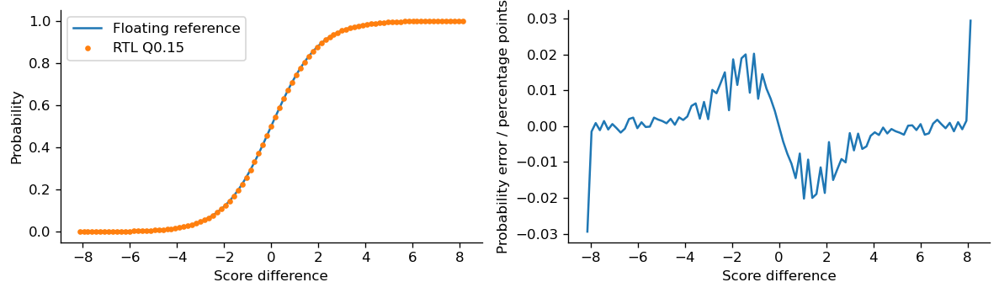

| Check | Result |
|---|---|
| Frame / output values | 98 / 784 |
| Integer-reference mismatches | 0 |
| Maximum probability error | 0.02940 percentage points |
| Same output as floating softmax | 90 / 98 frame |
| IP area, SKY130 TT mapping | 52288.899 µm² |

In [87]:
"""Independent integer/floating references and native Icarus verification of MHA IP."""
from pathlib import Path
import argparse,json,math,re,subprocess,time
import numpy as np

MAGNITUDES=(0,1,2,3,4,6,8,12)

def pack(values,bits):
    return sum((int(v)&((1<<bits)-1))<<(bits*i) for i,v in enumerate(np.asarray(values).reshape(-1)))

def probability_fixed(difference):
    negative=difference<0; magnitude=abs(int(difference)); scaled=magnitude*181
    if magnitude>=46: value=32768
    else:
        index,fraction=divmod(scaled,128)
        lo=round(32768/(1+math.exp(-index/8)))
        hi=round(32768/(1+math.exp(-(index+1)/8)))
        value=lo+((hi-lo)*fraction+64)//128
    return 32768-value if negative else value

def quantize_x2(values):
    return np.array([(-1 if x<0 else 1)*min(MAGNITUDES,key=lambda m:abs(abs(int(x))-32768*m))
                     for x in np.asarray(values).reshape(-1)],dtype=int).reshape(np.asarray(values).shape)

def reference(activation,weights):
    q,k,v=[np.asarray(activation,dtype=np.int64)@weights[n] for n in ('Q','K','V')]
    context=np.zeros((2,4),dtype=np.int64);probabilities=np.zeros((2,2,2),dtype=np.int64)
    float_context=np.zeros((2,4),dtype=float)
    for head in range(2):
        hs=slice(2*head,2*head+2)
        scores=q[:,hs]@k[:,hs].T
        for row in range(2):
            difference=int(scores[row,0]-scores[row,1]);p=probability_fixed(difference)
            probabilities[head,row]=[p,32768-p]
            context[row,hs]=probabilities[head,row]@v[:,hs]
            true_p=1/(1+math.exp(-max(-700,min(700,difference/(4*math.sqrt(2))))))
            float_context[row,hs]=np.array([true_p,1-true_p])@v[:,hs]
    context_x2=quantize_x2(context)
    float_quantized=np.array([(-1 if x<0 else 1)*min(MAGNITUDES,key=lambda m:abs(abs(float(x))-m))
                            for x in float_context.reshape(-1)]).reshape(2,4)
    output=context_x2@weights['O']
    return dict(q=q,k=k,v=v,context_x2=context_x2,probabilities=probabilities,
                output_x2=output,float_quantized_output_x2=float_quantized@weights['O'],
                floating_output_x2=float_context@weights['O'])

def vectors(root,count):
    spec=json.loads((root/'inputs/experiment_spec.json').read_text())['mha']
    rng=np.random.default_rng(2027)
    result=[(np.array(spec['activation_x2'],dtype=int),{k:np.array(v,dtype=int) for k,v in spec['weights'].items()})]
    result.append((np.zeros((2,4),dtype=int),{k:np.zeros((4,4),dtype=int) for k in ('Q','K','V','O')}))
    alphabet=np.array(sorted(set(MAGNITUDES)|{-v for v in MAGNITUDES}))
    for _ in range(count-len(result)):
        result.append((rng.choice(alphabet,size=(2,4)),{k:rng.integers(-1,2,(4,4)) for k in ('Q','K','V','O')}))
    return result

def run_command(command,work,logname,timeout=90):
    start=time.monotonic();result=subprocess.run(list(map(str,command)),cwd=work,capture_output=True,text=True,timeout=timeout)
    (work/logname).write_text(result.stdout+result.stderr)
    if result.returncode:raise RuntimeError(f'{logname}: '+(result.stdout+result.stderr)[-4000:])
    return result.stdout,time.monotonic()-start

def verify(root,work,count=98):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    cases=vectors(root,count);gold=[reference(a,w) for a,w in cases]
    data={name:[] for name in ('activations','weights','outputs','probabilities','context')}
    for (a,w),g in zip(cases,gold):
        masks=[]
        for stage in ('Q','K','V','O'):
            for row in range(4):
                pos=sum(int(w[stage][row,c]>0)<<c for c in range(4))
                neg=sum(int(w[stage][row,c]<0)<<c for c in range(4))
                masks.append(pos|(neg<<4))
        for name,value,width in [('activations',pack(a,5),10),('weights',pack(masks,8),32),
             ('outputs',pack(g['output_x2'],12),24),('probabilities',pack(g['probabilities'],16),32),
             ('context',pack(g['context_x2'],5),10)]:data[name].append(f'{value:0{width}x}')
    for name,rows in data.items():
        (work/(name+'.memh')).write_text('\n'.join(rows)+'\n')
        (work/('canonical_'+name+'.memh')).write_text(rows[0]+'\n')
    src=root/'ip/automx_mha'
    compile_log,_=run_command(['iverilog','-g2012','-s','tb_mha_ip','-o',work/'mha.vvp',
                  src/'rtl/automx_mha_ip.sv',src/'sim/tb_mha_ip.sv'],work,'iverilog.log')
    stdout,elapsed=run_command(['vvp',work/'mha.vvp','+DATA='+str(work),'+CASES='+str(count)],work,'vvp.log')
    assert f'MHA_IP_BIT_EXACT_PASS cases={count}' in stdout
    trace=re.search(r'MHA_RTL_CANONICAL q=(\w+) k=(\w+) v=(\w+) context=(\w+) output=(\w+)',stdout)
    assert trace,stdout
    def decode_hex(text,bits,rows=2,columns=4):
        value=int(text,16);mask=(1<<bits)-1
        data=[(value>>(i*bits))&mask for i in range(rows*columns)]
        return np.array([x-(1<<bits) if x&(1<<(bits-1)) else x for x in data]).reshape(rows,columns)
    observed={name:decode_hex(value,5 if name=='context_x2' else 12).tolist()
        for name,value in zip(['q','k','v','context_x2','output_x2'],trace.groups())}
    for name,values in observed.items():assert np.array_equal(values,gold[0][name]),name
    (work/'canonical_rtl.json').write_text(json.dumps(observed,indent=2)+'\n')
    required=['RANDOM_STALLS_AND_OUTPUT_BACKPRESSURE','RESET_ABORT','INVALID_ACTIVATION','BACKEND_TIMEOUT','UNCALIBRATED_RESULT','BACKEND_FAULT']
    assert all(x+'_PASS' in stdout for x in required),stdout
    run_command(['iverilog','-g2012','-s','tb_mha_mixed_top','-o',work/'integrated.vvp',
        src/'rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',
        root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv',
        src/'sim/tb_mha_mixed_top.sv'],work,'integration_compile.log')
    integration_log,_=run_command(['vvp',work/'integrated.vvp','+DATA='+str(work)],work,'integration.log')
    assert 'MHA_CIM_SAR_RTL_TOP_PASS vectors=8 adc_conversions=64' in integration_log
    assert 'MHA_TOP_DIRECT_CIM_SAR_MODE_PASS' in integration_log
    errors=[]
    for d in range(-9216,9217):
        p=1/(1+math.exp(-max(-700,min(700,d/(4*math.sqrt(2))))))
        errors.append(abs(probability_fixed(d)/32768-p))
    assert max(errors)<.0005
    canonical={k:v.tolist() for k,v in gold[0].items()}
    (work/'canonical_reference.json').write_text(json.dumps(canonical,indent=2)+'\n')
    mismatches=sum(np.any(g['output_x2']!=g['float_quantized_output_x2']) for g in gold)
    report={'status':'PASS','configuration':{'tokens':2,'channels':4,'heads':2},
      'test_cases':count,'checked_output_values':count*8,'projection_vector_transactions':count*8,
      'bit_exact_errors':0,'softmax_absolute_probability_error_max':max(errors),
      'softmax_score_differences_checked':len(errors),'probability_row_sum':32768,
      'output_cases_different_from_float_softmax':int(mismatches),
      'canonical_output':(gold[0]['output_x2']/2).tolist(),
      'canonical_quantized_reference_l2':float(np.linalg.norm(gold[0]['output_x2']-gold[0]['float_quantized_output_x2'])/max(np.linalg.norm(gold[0]['float_quantized_output_x2']),1e-12)),
      'canonical_floating_reference_l2':float(np.linalg.norm(gold[0]['output_x2']-gold[0]['floating_output_x2'])/max(np.linalg.norm(gold[0]['floating_output_x2']),1e-12)),
      'protocol_tests':required,'simulation_elapsed_s':elapsed,'simulator':'Icarus Verilog',
      'integrated_top':'PASS: MHA IP plus actual readout RTL, 64 modeled ADC conversions, calibrated decoder and host mode arbitration',
      'backend':'Unit dot-product transaction model and top-level functional ADC response fixture; transistor analog measurements are separate'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    print(stdout.strip());print(integration_log.strip());print('MHA_IP_VERIFIED',json.dumps({k:report[k] for k in ['status','test_cases','bit_exact_errors','softmax_absolute_probability_error_max','canonical_quantized_reference_l2','canonical_floating_reference_l2']}),flush=True)
    return report

def synthesize(root,work,full_top=False):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    image=json.loads((root/'standalone.json').read_text())['openlane_image']
    liberty=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    summaries=[]
    targets=['automx_mha_ip']+(['automx_cim_mixed_signal_proto'] if full_top else [])
    for top in targets:
        script=work/(top+'.ys');stat=work/(top+'.stat.json');mapped=work/(top+'.mapped.v')
        sources=[root/'ip/automx_mha/rtl/automx_mha_ip.sv']
        if top!='automx_mha_ip': sources += [root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv']
        text=f'read_liberty -lib "{liberty}"\n'
        if top!='automx_mha_ip':text+=f'read_verilog -lib "{root/"inputs/wrapper_blackboxes.sv"}"\n'
        text+=''.join(f'read_verilog -sv "{p}"\n' for p in sources)
        text+=f'hierarchy -check -top {top}\nsynth -top {top} -flatten\n'
        text+=f'dfflibmap -liberty "{liberty}"\nabc -liberty "{liberty}"\nclean\ncheck -assert\n'
        text+=f'write_verilog -noattr -noexpr "{mapped}"\ntee -o {stat} stat -json -liberty "{liberty}"\n'
        script.write_text(text)
        command=['docker','run','--rm','--network','none','--user',f'{__import__("os").getuid()}:{__import__("os").getgid()}',
                 '-v',f'{root}:{root}','-w',str(work),'--entrypoint','yosys',image,'-s',str(script)]
        stdout,elapsed=run_command(command,work,top+'.yosys.log',timeout=240)
        result=json.loads(stat.read_text());module=result['modules']['\\'+top]
        assert module['num_cells']>0 and mapped.stat().st_size>0
        macros={name:module['num_cells_by_type'].get(name,0) for name in
                ['automx_cim_core_acquisition_proto','automx_cim_condition_mux_proto','adc_top']}
        if top!='automx_mha_ip':assert all(v==1 for v in macros.values()),macros
        row={'top':top,'mapped_cells':module['num_cells'],'mapped_area_um2':module.get('area'),
             'elapsed_s':elapsed,'hard_macros':macros,'log':str(work/(top+'.yosys.log'))}
        summaries.append(row)
        print('YOSYS_MHA_SYNTHESIS_PASS',json.dumps(row),flush=True)
    (work/'synthesis.json').write_text(json.dumps({'status':'PASS','targets':summaries},indent=2)+'\n')
    return summaries


MHA_NATIVE_WORK=portable.WORK/'mha_ip'
MHA_IP_REPORT=verify(MHA_ROOT,MHA_NATIVE_WORK)
MHA_IP_SYNTH=synthesize(MHA_ROOT,MHA_NATIVE_WORK/'synthesis')
from IPython.display import display,Markdown
import matplotlib.pyplot as plt
_mha_delta=np.arange(-46,47)
_mha_reference=1/(1+np.exp(-_mha_delta/(4*np.sqrt(2))))
_mha_fixed=np.array([probability_fixed(int(d))/32768 for d in _mha_delta])
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(_mha_delta/(4*np.sqrt(2)),_mha_reference,label='Floating reference')
axes[0].plot(_mha_delta/(4*np.sqrt(2)),_mha_fixed,'.',label='RTL Q0.15');axes[0].set(xlabel='Score difference',ylabel='Probability');axes[0].legend()
axes[1].plot(_mha_delta/(4*np.sqrt(2)),(_mha_fixed-_mha_reference)*100)
axes[1].set(xlabel='Score difference',ylabel='Probability error / percentage points');plt.tight_layout();plt.show()
display(Markdown('| Check | Result |\n|---|---|\n'+
 f"| Frame / output values | {MHA_IP_REPORT['test_cases']} / {MHA_IP_REPORT['checked_output_values']} |\n"+
 f"| Integer-reference mismatches | {MHA_IP_REPORT['bit_exact_errors']} |\n"+
 f"| Maximum probability error | {MHA_IP_REPORT['softmax_absolute_probability_error_max']*100:.5f} percentage points |\n"+
 f"| Same output as floating softmax | {MHA_IP_REPORT['test_cases']-MHA_IP_REPORT['output_cases_different_from_float_softmax']} / {MHA_IP_REPORT['test_cases']} frame |\n"+
 f"| IP area, SKY130 TT mapping | {MHA_IP_SYNTH[0]['mapped_area_um2']:.3f} µm² |"))


In [88]:
%%native_lab runall-ngspice
%%inline_module ngspice_setup
from automx_standalone import prepare_shared
# NOTEBOOK_RUN
shared_library=ngspice_setup.prepare_shared(flow)


ngspice_runtime_version: python


ngspice_runtime_version: exit=0; 0.07 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/ngspice_runtime_version/native.log


In [89]:
%%native_lab inline-physical_common
%%inline_module physical_common
from automx_standalone import inputs
# NOTEBOOK_RUN


physical_common: inputs


<a id="guide-native-runall-partition-sources"></a>

### Before cell `native-runall-partition-sources` — F7

**Implementation:** Manage conversion payloads, calibration measurements, projection requests, and MHA assembly. Fit and inference share the analog/ADC path, with the fit frozen before unseen-payload evaluation.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-runall-partition-sources-quantize_context"></a>`quantize_context(values)` | For each context element, select the nearest signed ACT_X2 level supported by O projection; return quantized context for output-projection payloads. |
| <a id="fn-native-runall-partition-sources-Experiment-__init__"></a>`Experiment.__init__(self, flow)` | Bind Experiment to the flow, validate shared ngspice and pinned SAR RTL, and initialize session-specific source, record, and calibration registries. |
| <a id="fn-native-runall-partition-sources-Experiment-payload"></a>`Experiment.payload(activation, weights)` | Normalize activations and one weight column into a 4×4 case with other columns zero; generate a payload key to avoid duplicate session simulations. |
| <a id="fn-native-runall-partition-sources-Experiment-measure"></a>`Experiment.measure(self, payload)` | Measure or retrieve a record from this same session for a payload, validate its inputs/source, and register its summary path for consumers. |
| <a id="fn-native-runall-partition-sources-Experiment-many"></a>`Experiment.many(self, payloads)` | Deduplicate payloads, orchestrate conversions with bounded workers, and return completed-record mappings. |
| <a id="fn-native-runall-partition-sources-Experiment-calibrate"></a>`Experiment.calibrate(self)` | Measure three separate calibration payloads, obtain ADC codes, and fit code-to-integer-sum slope/offset; freeze calibration keys before projection/holdout. |
| <a id="fn-native-runall-partition-sources-Experiment-project"></a>`Experiment.project(self, activation, weights, label)` | Schedule conversions for every projection row/output, decode with the locked fit, and assemble sums using the specified mapping; return projection tensors and record references. |
| <a id="fn-native-runall-partition-sources-Experiment-mha"></a>`Experiment.mha(self)` | Generate deterministic tiny-MHA inputs/weights, measure Q/K/V, compute digital attention, quantize context, and measure O; write mha_end_to_end.json and both reference-error metrics. |

<a id="data-native-runall-partition-sources"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive Flow, validated SAR/analog/PDK sources, and activation_x2/weights/column payloads. Calibration uses three separate inputs; projections receive activation/weight matrices and Q/K/V/O labels.
- **Return values and saved artifacts:** Return conversion receipts, slope/offset, projection tensors, and mha_end_to_end.json. The session has 32 projection transactions but 30 unique projection payloads; duplicate cases reuse only this session's records.
- **Downstream consumers:** standalone-sync-conversions measures eight challenges after fit locking, forming 41-case evidence; calibration-holdout/mha-recompute independently validate fit, mapping, and tensors.


In [90]:
%%native_lab runall-partition-sources
%%inline_module mha_engine
from automx_nb_inline_v1.presentation import pretty
"""Tiny MHA fed by measured, directly coupled CIM/ADC partition conversions.

Q/K/V/O projections reuse one physical column. Attention/softmax are the
architectural digital CPU runtime. No fitted analog lookup supplies an ADC
word; every requested physical pattern has a native conversion receipt.
"""
from concurrent.futures import ThreadPoolExecutor
import json
from pathlib import Path
import numpy as np

from automx_nb_inline_v1.attention import mha_from_projections,error_metrics
from automx_nb_inline_v1.support import digest,item,save,verified


def quantize_context(values):
    magnitudes=np.array([0,.5,1,1.5,2,3,4,6])
    v=np.asarray(values,dtype=float)
    if not np.all(np.isfinite(v)):raise ValueError('nonfinite context')
    closest=magnitudes[np.argmin(abs(abs(v)[...,None]-magnitudes),axis=-1)]
    return (np.sign(v)*closest*2).astype(int)


class Experiment:
    def __init__(self,flow):
        self.flow=flow;self.root=flow.root;self.references={};self.calibration_keys=set();self.required=[]
        self.lib=flow.base/'tools/ngspice_shared44/install/lib/libngspice.so'
        if not self.lib.is_file():raise FileNotFoundError('Bundled shared ngspice runtime was not prepared')
        self.sources=[self.lib,*[self.root/'scripts'/f for f in ('flow2_rtl_spice_cosim.py','flow2_adc_partition.py')]]
        ip=self.root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
        manifest=json.loads((ip/'provenance.json').read_text())
        for source in manifest['files']:
            path=ip/source['path']
            if digest(path)!=source['sha256']:raise ValueError('Bundled pinned SAR source differs')
            self.sources.append(path)
        self.sources += [self.root/'inputs/core_acquisition.spice',self.root/'inputs/conditioner.spice',
            self.root/'pdks/analog/sky130A/libs.tech/ngspice/sky130.lib.spice']

    @staticmethod
    def payload(activation,weights):
        a=np.asarray(activation,dtype=int);w=np.zeros((4,4),dtype=int);w[:,0]=weights
        data={'activation_x2':a.tolist(),'weights':w.tolist(),'column':0}
        import hashlib
        key=hashlib.sha256(json.dumps(data,sort_keys=True).encode()).hexdigest()[:16]
        return key,data

    def measure(self,payload):
        key,data=payload;name='conversion_'+key;work=self.flow.work/name;work.mkdir(exist_ok=True)
        case=work/'case.json';save(case,data)
        command=[__import__('sys').executable,'-u',Path(INLINE_ROOT)/'cosim.py',
            '--root',self.root,'--work',work,'--library',self.lib,'--case',case]
        self.flow.run(name,command,inputs=[case,*self.sources],outputs=['summary.json','coupled.raw','ngspice.log','rtl.log'],
                      timeout_s=self.flow.settings.timeout_s)
        result=json.loads((work/'summary.json').read_text())
        if result['status']!='COUPLED_ANALOG_RTL_ADC_PARTITION_CONVERSION_PASS':raise ValueError('conversion did not pass')
        if any(result[k]!=data[k] for k in ('activation_x2','weights','column')):
            raise ValueError('native result does not belong to requested physical pattern')
        if not 0<=result['result_code_12bit']<4096 or result['result_word_16bit']!=result['result_code_12bit']<<4 or result['cycles']<16:
            raise ValueError('native result word or SAR trace incomplete')
        self.references[key]=item(work/'summary.json')
        return result

    def many(self,payloads):
        unique=dict(payloads)
        with ThreadPoolExecutor(max_workers=self.flow.settings.jobs) as pool:
            results=list(pool.map(self.measure,unique.items()))
        return dict(zip(unique,results))

    def calibrate(self):
        rows=([0,0,0,0],[-4,-4,0,0],[4,4,0,0])
        payloads=[self.payload(a,[1,1,1,1]) for a in rows]
        self.calibration_keys={p[0] for p in payloads};cases=self.many(payloads)
        x=np.array([sum(a) for a in rows],float)
        y=np.array([cases[k]['result_code_12bit'] for k,_ in payloads],float)
        order=np.argsort(x);steps=np.diff(y[order])
        if not(np.all(steps>0) or np.all(steps<0)):raise ValueError('three fresh calibration codes must be distinct and monotonic')
        slope,offset=np.polyfit(x,y,1)
        if abs(slope)<1:raise ValueError('ADC calibration has no usable signal span')
        self.slope=float(slope);self.offset=float(offset)
        self.calibration={'expected_integer_sums':x.tolist(),'measured_ADC_codes':y.tolist(),
            'slope_codes_per_integer_sum':self.slope,'offset_code':self.offset,
            'maximum_residual_codes':float(np.max(abs(y-(slope*x+offset)))),
            'frozen_before_holdout':True,'source_cases':{k:self.references[k] for k,_ in payloads}}
        save(self.flow.work/'calibration.json',self.calibration)
        print('Measured ADC calibration:',pretty(self.calibration,indent=2))
        return self.calibration

    def project(self,activation,weights,label):
        a=np.asarray(activation,dtype=int);w=np.asarray(weights,dtype=int)
        requests=[(row,col,self.payload(a[row],w[:,col])) for row in range(a.shape[0]) for col in range(4)]
        result=self.many([p for _,_,p in requests]);out=np.zeros((len(a),4));jobs=[]
        for row,col,(key,payload) in requests:
            if key in self.calibration_keys:raise ValueError('calibration pattern reused as holdout')
            measured=result[key];estimate=(measured['result_code_12bit']-self.offset)/self.slope
            decoded=int(np.rint(estimate));out[row,col]=decoded/2
            truth=int(a[row]@w[:,col]);self.required.append(key)
            jobs.append({'stage':label,'row':row,'column':col,'physical_column':0,'case':self.references[key],
                'raw_ADC_code':measured['result_code_12bit'],'decoded_integer_sum':decoded,
                'unrounded_calibrated_sum':float(estimate),'reference_integer_sum':truth})
        return out,jobs

    def mha(self):
        if not hasattr(self,'slope'):raise ValueError('freeze independent calibration first')
        a=np.array([[2,-1,1,0],[-1,2,0,1]],int)
        q=np.array([[1,0,1,-1],[0,1,-1,1],[1,1,0,0],[-1,1,1,0]],int)
        k=np.roll(q,1,axis=0)
        v=np.array([[1,0,-1,1],[0,1,1,0],[-1,1,0,1],[1,-1,1,0]],int)
        o=np.array([[1,0,-1,1],[-1,1,0,1],[0,-1,1,1],[1,1,-1,0]],int)
        projections=[];jobs=[]
        for label,weight in (('Q',q),('K',k),('V',v)):
            projection,rows=self.project(a,weight,label);projections.append(projection);jobs+=rows
        measured=mha_from_projections(*projections,np.eye(4),2)
        context_x2=quantize_context(measured.context)
        output,rows=self.project(context_x2,o,'O');jobs+=rows
        gold=mha_from_projections(a@q/2,a@k/2,a@v/2,np.eye(4),2)
        reference=quantize_context(gold.context)@o/2
        metrics=error_metrics(reference,output)
        relative=float(np.linalg.norm(output-reference)/max(np.linalg.norm(reference),1e-12))
        if not np.allclose(measured.probabilities.sum(axis=-1),1):raise ValueError('attention rows do not sum to one')
        report={'status':'MEASURED_PARTITION_ANALOG_ADC_MHA_END_TO_END_PASS' if relative<=.25 else 'MHA_PARTITION_ACCURACY_FAIL',
            'shape':{'sequence':2,'d_model':4,'heads':2,'physical_rows':4,'physical_columns_used':1},
            'activation_x2':a.tolist(),'weights':{n:w.tolist() for n,w in (('Q',q),('K',k),('V',v),('O',o))},
            'calibration':self.calibration,'output':output.tolist(),'reference_quantized_output':reference.tolist(),
            'probabilities':measured.probabilities.tolist(),'measured_projections':{n:p.tolist() for n,p in zip(('Q','K','V'),projections)},
            'measured_context':measured.context.tolist(),'context_activation_x2':context_x2.tolist(),
            'floating_reference_output':(gold.context@o).tolist(),
            'floating_reference_metrics':error_metrics(gold.context@o,output),
            'floating_reference_relative_l2':float(np.linalg.norm(output-gold.context@o)/max(np.linalg.norm(gold.context@o),1e-12)),
            'metrics':metrics,'relative_l2':relative,'prototype_relative_l2_budget':.25,
            'projection_transactions':len(jobs),'unique_holdout_patterns':len(set(self.required)),
            'unmeasured_analog_lookup_estimates':0,'calibration_holdout_pattern_overlap':0,'jobs':jobs,
            'evidence':self.references,'fabrication_ready':False,'whole_chip_transistor_verified':False,
            'scope':'End-to-end simulation of tiny MHA using measured native CIM/ADC partition for every Q/K/V/O projection. '
              'One physical column time-multiplexed. CPU attention/softmax and a frozen 3-point digital calibration. '
              'Analog schematic core/conditioner, real transistor comparator/input sampler; aggregated CDAC with ideal bottom drivers, '
              'external clock/VCM, comparator noise-decoupling varactors omitted. Not full-top RC/PEX/noise/PVT or trained-model accuracy.'}
        save(self.flow.work/'mha_end_to_end.json',report)
        self.flow.outputs['analog_adc_mha']=item(self.flow.work/'mha_end_to_end.json')
        print(pretty({k:v for k,v in report.items() if k not in ('jobs','evidence')},indent=2))
        if report['status'].endswith('FAIL'):raise ValueError('measured MHA error exceeds the frozen prototype budget')
        return report

# NOTEBOOK_RUN
experiment=mha_engine.Experiment(flow)
source,source_views,design,routed_run,config,pdk=physical_common.inputs(flow)
print("Pinned analog/native inputs:",len(experiment.sources))
print("Routing design input:",source_views["odb"])


Pinned analog/native inputs: 15
Routing design input: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/design/runs/cold/results/routing/automx_cim_mixed_signal_proto.odb


## 3. KLayout: inspect actual analog and ADC macros

The following images read actual macro GDS from wrapper configuration rather
than illustrations. `flow.render(gds, top, name)` calls native KLayout, retains
logs, and embeds PNG output. Layout images alone do not prove analog function.


<a id="guide-native-runall-render-macros"></a>

### Before cell `native-runall-render-macros` — F6, F8–F9

**Implementation:** Define GDS reading, top-cell selection, and KLayout macro/top rendering. Images must come from actual views so hierarchy, block positions, and routing can be checked against the circuit description.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-runall-render-macros-catalog"></a>`catalog(root, config_path, *, leaves=False)` | Read rendering configurations/views and build a catalog of macro names, GDS top cells, paths, and required flags for the rendering loop. |
| <a id="fn-native-runall-render-macros-catalog-add"></a>`catalog.add(name, title, path, cell, required=True)` | Validate a catalog item's GDS path and append its name/title/top-cell record; missing required items produce an error. |

<a id="data-native-runall-render-macros"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive GDS configuration/paths for core_acquisition, conditioner, ADC, or top and its exact cell name; required/leaves flags select items.
- **Return values and saved artifacts:** Write and display PNG under render_<name>/; catalog returns path/top items and the runner validates image files before registering outputs.
- **Downstream consumers:** standalone-sync-physical copies validated images to review_data/figures; physical-reports displays them with LVS/PG/STA from the same run.


Core CIM + physical acquisition / sample-and-hold
render_01_core_acquisition: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_core_acquisition_proto", "cells": 1, "width_um": 996.2, "height_um": 239.72, "render_style": "fixed SKY130 device/metal view", "shown_layers": [[65, 20], [65, 44], [66, 20], [66, 44], [67, 20], [67, 44], [68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


render_01_core_acquisition: exit=0; 1.43 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_01_core_acquisition/native.log


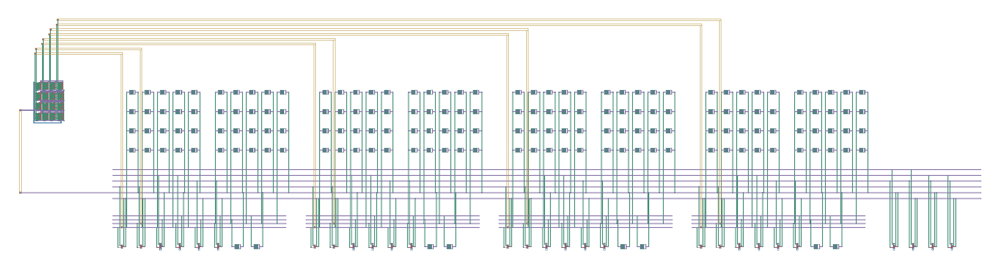

Conditioner, bias and differential mux
render_02_conditioner_mux: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_condition_mux_proto", "cells": 1, "width_um": 1442.0, "height_um": 136.12, "render_style": "fixed SKY130 device/metal view", "shown_layers": [[65, 20], [65, 44], [66, 20], [66, 44], [67, 20], [67, 44], [68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20]], "labels_visible": false, "geometry_modified": false}


render_02_conditioner_mux: exit=0; 1.41 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_02_conditioner_mux/native.log


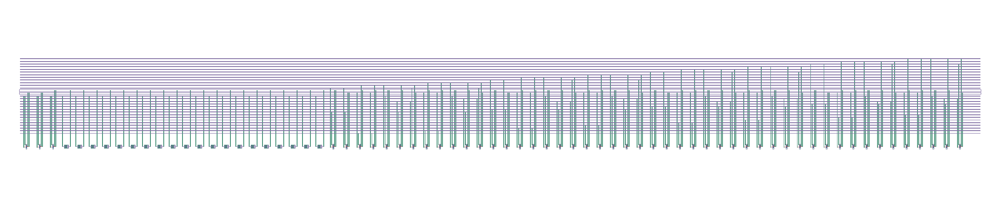

SAR ADC with its native reference circuitry


render_03_adc_reference: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "adc_top", "cells": 104, "width_um": 433.5, "height_um": 403.02, "render_style": "fixed SKY130 device/metal view", "shown_layers": [[65, 20], [65, 44], [66, 20], [66, 44], [67, 20], [67, 44], [68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


render_03_adc_reference: exit=0; 2.39 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_03_adc_reference/native.log


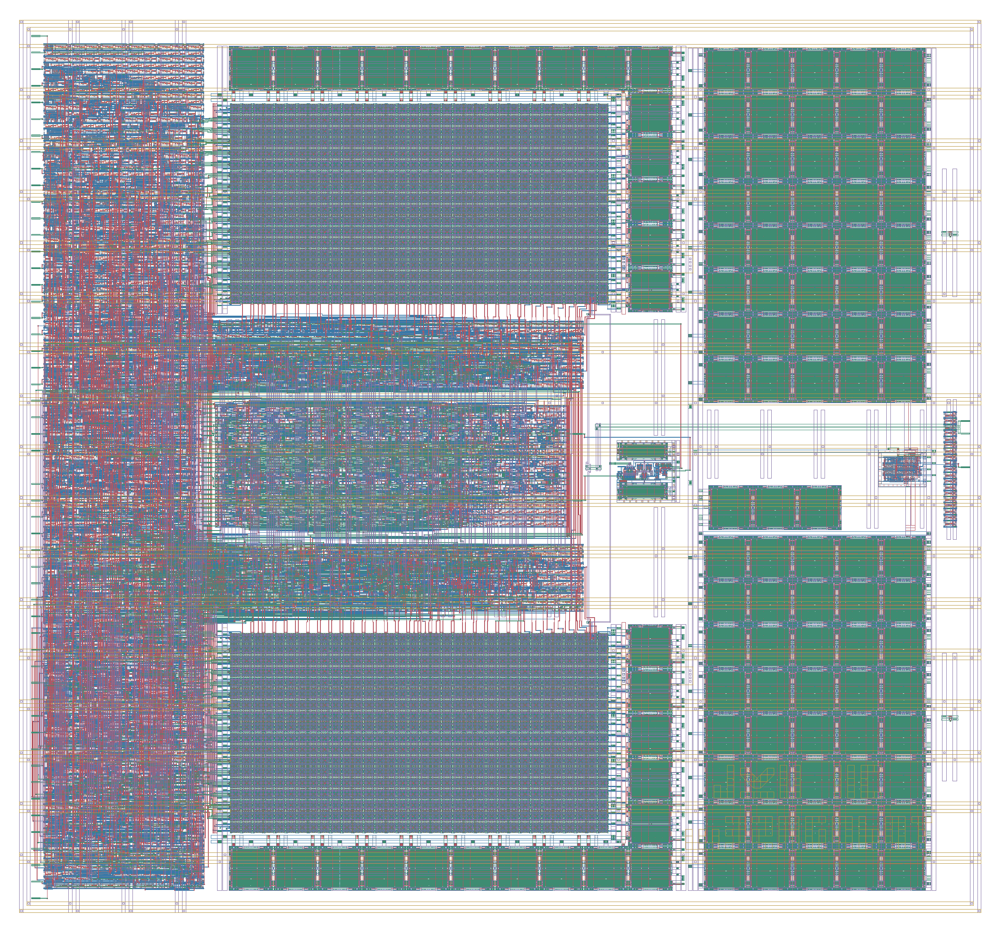

MHA: QK transpose, softmax, context and projection control
render_08_mha: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_mha_ip", "cells": 87, "width_um": 650.0, "height_um": 400.0, "render_style": "fixed SKY130 device/metal view", "shown_layers": [[65, 20], [65, 44], [66, 20], [66, 44], [67, 20], [67, 44], [68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20]], "labels_visible": false, "geometry_modified": false}


render_08_mha: exit=0; 2.15 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_08_mha/native.log


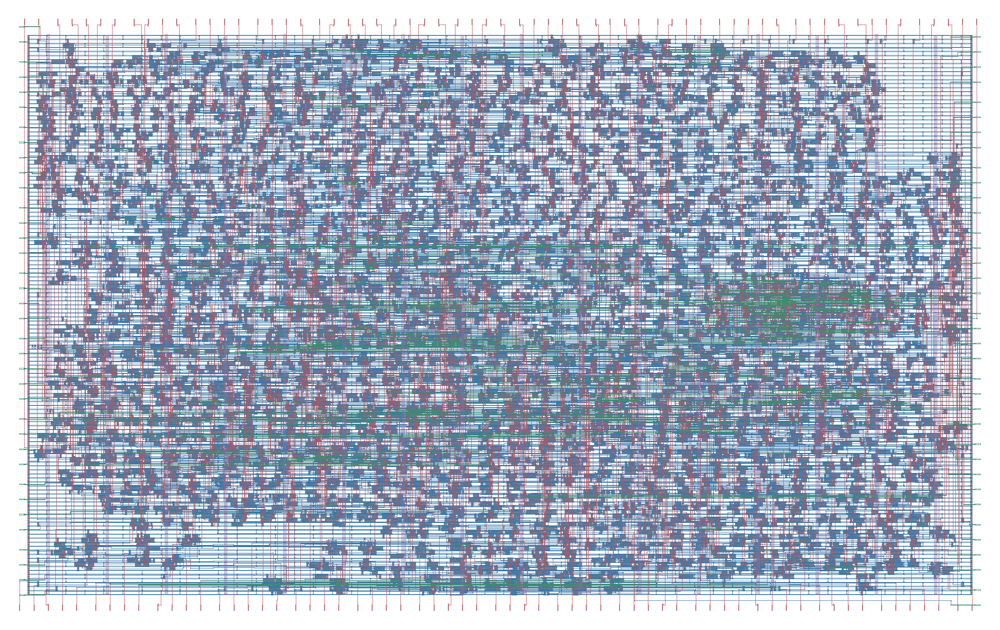

Readout, SAR sequencing and calibration
render_09_readout: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_readout_seq", "cells": 80, "width_um": 1250.0, "height_um": 750.0, "render_style": "fixed SKY130 device/metal view", "shown_layers": [[65, 20], [65, 44], [66, 20], [66, 44], [67, 20], [67, 44], [68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20]], "labels_visible": false, "geometry_modified": false}


render_09_readout: exit=0; 3.05 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_09_readout/native.log


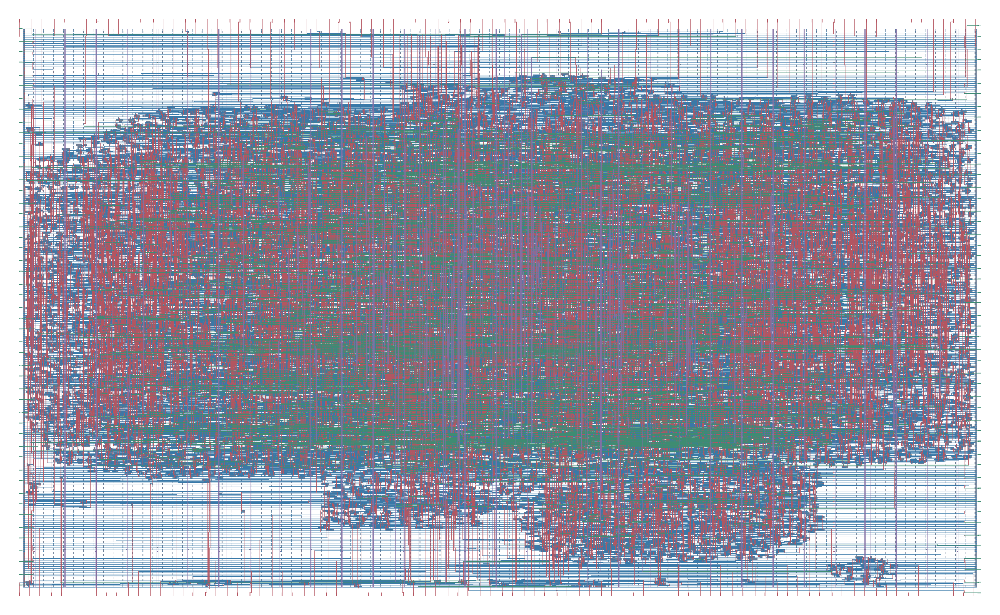

In [91]:
%%native_lab runall-render-macros
%%inline_module catalog
import json
from pathlib import Path
def catalog(root,config_path,*,leaves=False):
    root=Path(root).resolve();config_path=Path(config_path).resolve()
    conf=json.loads(config_path.read_text(encoding='utf-8'))
    if conf.get('DESIGN_NAME')!='automx_cim_mixed_signal_proto':
        raise ValueError('select the mixed-wrapper design config.json')
    sources=conf.get('EXTRA_GDS_FILES')
    if not isinstance(sources,list) or len(sources)<3:
        raise ValueError('need at least CIM, conditioner and ADC input GDS files')
    jobs=[]
    def add(name,title,path,cell,required=True):
        path=Path(path)
        if not path.is_absolute():path=root/path
        path=path.resolve()
        jobs.append({'name':name,'title':title,'source':str(path),'cell':cell,
                     'required':required,'available':path.is_file() and path.stat().st_size>0})
    for src,(name,title,cell) in zip(sources,[
        ('01_core_acquisition','Core CIM + physical acquisition / sample-and-hold',
         'automx_cim_core_acquisition_proto'),
        ('02_conditioner_mux','Conditioner, bias and differential mux',
         'automx_cim_condition_mux_proto'),
        ('03_adc_reference','SAR ADC with its native reference circuitry','adc_top'),
        ('08_mha','MHA: QK transpose, softmax, context and projection control','automx_mha_ip'),
        ('09_readout','Readout, SAR sequencing and calibration','automx_cim_readout_seq')]):
        add(name,title,src,cell)
    add('04_passive_core','Stage-5 passive CIM core (standalone reference)',
        root/'physical/sky130/macro/automx_ternary_cim_4x4_core.gds',
        'automx_ternary_cim_4x4_core',False)
    if leaves:
        base=root/'physical/sky130/wrapper_prototype/leaf_cells'
        for name,title,relative,cell in [
            ('05_sample_nfet','Sampling NFET, 3.36 um','sample_fet_20261017_03/nfet/automx_cim_sample_nfet_3p36.gds','automx_cim_sample_nfet_3p36'),
            ('06_sample_pfet','Sampling PFET, 3.36 um','sample_fet_20261017_03/pfet/automx_cim_sample_pfet_3p36.gds','automx_cim_sample_pfet_3p36'),
            ('07_hold_mim','Physical MIM hold capacitor','hold_cap_mim3_20261017_02/automx_cim_hold_cap_mim3_approx20ff.gds','automx_cim_hold_cap_mim3_approx20ff')]:
            add(name,title,base/relative,cell,False)
    return jobs

# NOTEBOOK_RUN
macro_views=catalog.catalog(ROOT,design/"config.json")[:5]
for macro in macro_views:
 print(macro["title"])
 flow.render(macro["source"],macro["cell"],macro["name"])


## 4. SAR RTL coupled to analog transistors

E2M1 PWM → CIM/acquisition → conditioner → transistor sampling → CDAC/comparator
→ original Icarus SAR RTL → feedback → EOC/word. Shared ngspice synchronizes
both simulators phase by phase. CDAC reduction preserves 515 linear signal
capacitors per side, 1.4848 pF/side, through charge conservation; the harness
controls clock phases and bottom drivers. Verify electrical-bridge words against
RTL and stability for 40 ns after EOC.

Co-simulation and SAR sources: [[5]](#ref-5), [[7]](#ref-7), [[8]](#ref-8).


## 5. Calibration before holdout

Three native conversions have integer sums [0, −8, +8]. Measure ADC codes,
fit slope/offset, and freeze coefficients before Q/K/V/O. Calibration and
holdout use distinct patterns.


<a id="guide-native-runall-calibration"></a>

### Before cell `native-runall-calibration` — F7

**Implementation:** Use the operation group explained in [cell `native-runall-partition-sources`](#guide-native-runall-partition-sources).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `calibrate(self)` | Same task as [`Experiment.calibrate`](#fn-native-runall-partition-sources-Experiment-calibrate). |

**Data and downstream use:** Follow the [contract described for `native-runall-partition-sources`](#data-native-runall-partition-sources).


In [92]:
%%native_lab runall-calibration
%%inline_module calibration
from automx_nb_inline_v1.presentation import pretty
import json,numpy as np
from automx_nb_inline_v1.support import digest,item,save,verified
def calibrate(self):
    rows=([0,0,0,0],[-4,-4,0,0],[4,4,0,0])
    payloads=[self.payload(a,[1,1,1,1]) for a in rows]
    self.calibration_keys={p[0] for p in payloads};cases=self.many(payloads)
    x=np.array([sum(a) for a in rows],float)
    y=np.array([cases[k]['result_code_12bit'] for k,_ in payloads],float)
    order=np.argsort(x);steps=np.diff(y[order])
    if not(np.all(steps>0) or np.all(steps<0)):raise ValueError('three fresh calibration codes must be distinct and monotonic')
    slope,offset=np.polyfit(x,y,1)
    if abs(slope)<1:raise ValueError('ADC calibration has no usable signal span')
    self.slope=float(slope);self.offset=float(offset)
    self.calibration={'expected_integer_sums':x.tolist(),'measured_ADC_codes':y.tolist(),
        'slope_codes_per_integer_sum':self.slope,'offset_code':self.offset,
        'maximum_residual_codes':float(np.max(abs(y-(slope*x+offset)))),
        'frozen_before_holdout':True,'source_cases':{k:self.references[k] for k,_ in payloads}}
    save(self.flow.work/'calibration.json',self.calibration)
    print('Measured ADC calibration:',pretty({k:v for k,v in self.calibration.items() if k!='source_cases'},indent=2))
    return self.calibration

# NOTEBOOK_RUN
calibration=calibration.calibrate(experiment)


conversion_b59db5ff2f509b4e: python


conversion_158427dfe1c46959: python


conversion_b181b7e3e6c3d14c: python


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.439450656669891e-07, "duration_s": 3.439450656669891e-07, "core_acquisition_vdd_j": 8.908227496685165e-14, "conditioner_vdd_j": 5.483651825244732e-10, "adc_vdd_j": 1.1771777719321796e-11, "adc_bridge_net_j": 1.4428367706698732e-13, "monitored_total_j": 5.603703261958289e-10}


conversion_158427dfe1c46959: exit=0; 15.32 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_158427dfe1c46959/native.log


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.4416320948128134e-07, "duration_s": 3.4416320948128134e-07, "core_acquisition_vdd_j": 8.905135043586306e-14, "conditioner_vdd_j": 5.525101801360414e-10, "adc_vdd_j": 1.2153726697922727e-11, "adc_bridge_net_j": -8.83991389220172e-15, "monitored_total_j": 5.647441182705077e-10}


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.4391776022901457e-07, "duration_s": 3.4391776022901457e-07, "core_acquisition_vdd_j": 8.90672142307666e-14, "conditioner_vdd_j": 5.483223264319401e-10, "adc_vdd_j": 7.83047929449305e-12, "adc_bridge_net_j": 1.4427638637195564e-13, "monitored_total_j": 5.563861493270358e-10}


conversion_b181b7e3e6c3d14c: exit=0; 15.50 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_b181b7e3e6c3d14c/native.log


conversion_b59db5ff2f509b4e: exit=0; 15.54 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_b59db5ff2f509b4e/native.log


Measured ADC calibration: {
  "expected_integer_sums": [
    0.0,
    -8.0,
    8.0
  ],
  "measured_ADC_codes": [
    2047.0,
    2176.0,
    1919.0
  ],
  "slope_codes_per_integer_sum": -16.062499999999996,
  "offset_code": 2047.3333333333337,
  "maximum_residual_codes": 0.3333333333337123,
  "frozen_before_holdout": true
}


## 6. End-to-end tiny MHA

The testcase uses **two tokens × four dimensions, two heads**, with ternary
Q/K/V/O. One four-row column is time-multiplexed and CPU attention/softmax
provides the reference. Each pattern has an ngspice waveform, RTL trace, EOC,
and receipt. Report errors separately against quantized-context and floating
references.


<a id="guide-native-runall-measured-mha"></a>

### Before cell `native-runall-measured-mha` — F7

**Implementation:** Use the operation group explained in [cell `native-runall-partition-sources`](#guide-native-runall-partition-sources).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `mha(self)` | Same task as [`Experiment.mha`](#fn-native-runall-partition-sources-Experiment-mha). |

**Data and downstream use:** Follow the [contract described for `native-runall-partition-sources`](#data-native-runall-partition-sources).


In [93]:
%%native_lab runall-measured-mha
%%inline_module measured_mha
from automx_nb_inline_v1.presentation import pretty
import json,numpy as np
from automx_nb_inline_v1.support import digest,item,save,verified
from automx_nb_inline_v1.attention import mha_from_projections,error_metrics
from automx_nb_inline_v1.mha_engine import quantize_context
def mha(self):
    if not hasattr(self,'slope'):raise ValueError('freeze independent calibration first')
    a=np.array([[2,-1,1,0],[-1,2,0,1]],int)
    q=np.array([[1,0,1,-1],[0,1,-1,1],[1,1,0,0],[-1,1,1,0]],int)
    k=np.roll(q,1,axis=0)
    v=np.array([[1,0,-1,1],[0,1,1,0],[-1,1,0,1],[1,-1,1,0]],int)
    o=np.array([[1,0,-1,1],[-1,1,0,1],[0,-1,1,1],[1,1,-1,0]],int)
    projections=[];jobs=[]
    for label,weight in (('Q',q),('K',k),('V',v)):
        projection,rows=self.project(a,weight,label);projections.append(projection);jobs+=rows
    measured=mha_from_projections(*projections,np.eye(4),2)
    context_x2=quantize_context(measured.context)
    output,rows=self.project(context_x2,o,'O');jobs+=rows
    gold=mha_from_projections(a@q/2,a@k/2,a@v/2,np.eye(4),2)
    reference=quantize_context(gold.context)@o/2
    metrics=error_metrics(reference,output)
    relative=float(np.linalg.norm(output-reference)/max(np.linalg.norm(reference),1e-12))
    if not np.allclose(measured.probabilities.sum(axis=-1),1):raise ValueError('attention rows do not sum to one')
    report={'status':'MEASURED_PARTITION_ANALOG_ADC_MHA_END_TO_END_PASS' if relative<=.25 else 'MHA_PARTITION_ACCURACY_FAIL',
        'shape':{'sequence':2,'d_model':4,'heads':2,'physical_rows':4,'physical_columns_used':1},
        'activation_x2':a.tolist(),'weights':{n:w.tolist() for n,w in (('Q',q),('K',k),('V',v),('O',o))},
        'calibration':self.calibration,'output':output.tolist(),'reference_quantized_output':reference.tolist(),
        'probabilities':measured.probabilities.tolist(),'measured_projections':{n:p.tolist() for n,p in zip(('Q','K','V'),projections)},
        'measured_context':measured.context.tolist(),'context_activation_x2':context_x2.tolist(),
        'floating_reference_output':(gold.context@o).tolist(),
        'floating_reference_metrics':error_metrics(gold.context@o,output),
        'floating_reference_relative_l2':float(np.linalg.norm(output-gold.context@o)/max(np.linalg.norm(gold.context@o),1e-12)),
        'metrics':metrics,'relative_l2':relative,'prototype_relative_l2_budget':.25,
        'projection_transactions':len(jobs),'unique_holdout_patterns':len(set(self.required)),
        'unmeasured_analog_lookup_estimates':0,'calibration_holdout_pattern_overlap':0,'jobs':jobs,
        'evidence':self.references,'fabrication_ready':False,'whole_chip_transistor_verified':False,
        'scope':'End-to-end simulation of tiny MHA using measured native CIM/ADC partition for every Q/K/V/O projection. '
          'One physical column time-multiplexed. CPU attention/softmax and a frozen 3-point digital calibration. '
          'Analog schematic core/conditioner, real transistor comparator/input sampler; aggregated CDAC with ideal bottom drivers, '
          'external clock/VCM, comparator noise-decoupling varactors omitted. Not full-top RC/PEX/noise/PVT or trained-model accuracy.'}
    save(self.flow.work/'mha_end_to_end.json',report)
    self.flow.outputs['analog_adc_mha']=item(self.flow.work/'mha_end_to_end.json')
    print(pretty({k:v for k,v in report.items() if k in ('shape','output','reference_quantized_output','metrics','relative_l2','floating_reference_relative_l2','projection_transactions','unique_holdout_patterns')},indent=2))
    if report['status'].endswith('FAIL'):raise ValueError('measured MHA error exceeds the frozen prototype budget')
    return report

# NOTEBOOK_RUN
mha=measured_mha.mha(experiment)


conversion_30f5291c7edf346c: python


conversion_362e75add0b4ebc8: python


conversion_09234f26b8f41bf5: python


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.4432564629144534e-07, "duration_s": 3.4432564629144534e-07, "core_acquisition_vdd_j": 8.905164647808024e-14, "conditioner_vdd_j": 5.511923801983002e-10, "adc_vdd_j": 1.18938118360019e-11, "adc_bridge_net_j": 5.214756715262886e-14, "monitored_total_j": 5.632273912479327e-10}


conversion_30f5291c7edf346c: exit=0; 15.37 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_30f5291c7edf346c/native.log


conversion_7cb1e481efeb6551: python


... (85 outputs left out)

conversion_c058bc6d0c32ac1f: exit=0; 13.85 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_c058bc6d0c32ac1f/native.log


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.4461852238132217e-07, "duration_s": 3.4461852238132217e-07, "core_acquisition_vdd_j": 8.919984975850177e-14, "conditioner_vdd_j": 5.516747220146031e-10, "adc_vdd_j": 1.191739548733963e-11, "adc_bridge_net_j": 4.947648332801559e-14, "monitored_total_j": 5.637307938350292e-10}


conversion_2eb0abd6f3c00282: exit=0; 13.70 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_2eb0abd6f3c00282/native.log


{
  "shape": {
    "sequence": 2,
    "d_model": 4,
    "heads": 2,
    "physical_rows": 4,
    "physical_columns_used": 1
  },
  "output": [
    [
      -1.0,
      -2.0,
      2.5,
      2.5
    ],
    [
      2.0,
      2.5,
      -3.0,
      -0.5
    ]
  ],
  "reference_quantized_output": [
    [
      -1.0,
      -2.0,
      2.5,
      2.5
    ],
    [
      2.0,
      2.5,
      -3.0,
      -0.5
    ]
  ],
  "floating_reference_relative_l2": 0.114477076077953,
  "metrics": {
    "rmse": 0.0,
    "normalized_rmse": 0.0,
    "cosine_similarity": 1.0000000000000002,
    "max_absolute_error": 0.0
  },
  "relative_l2": 0.0,
  "projection_transactions": 32,
  "unique_holdout_patterns": 30
}


<a id="results-baseline"></a>

### Same-hardware baseline: vary PWM width only

**Implementation:** Rerun the exact Q/K/V/O payloads and three calibration points
with 100 ps/unit PWM against the current 50 ps/unit mode. Retain TT, 1.8 V,
25°C, source netlists, MIM capacitors, PRE/TRACK/START timing, and measurement
windows. Each mode has its own calibration fit, frozen before projection scoring.
PWM means Pulse-Width Modulation; ps means picosecond. These are new conversions
under `matched_pwm100/`, not earlier reference measurements.


In [94]:
from concurrent.futures import ThreadPoolExecutor
import subprocess,json,sys,numpy as np
from pathlib import Path
from automx_nb_inline_v1.support import save,item
meter_mha=json.loads((flow.work/'mha_end_to_end.json').read_text())
meter_baseline=flow.work/'matched_pwm100';meter_baseline.mkdir(exist_ok=False)
meter_sources={Path(j['case']['path']).parent.name:Path(j['case']['path']) for j in meter_mha['jobs']}
for meter_ref in experiment.calibration['source_cases'].values():
    meter_path=Path(meter_ref['path']);meter_sources[meter_path.parent.name]=meter_path
meter_tasks=[]
for meter_name,meter_summary in sorted(meter_sources.items()):
    meter_folder=meter_baseline/meter_name;meter_folder.mkdir()
    meter_case=json.loads((meter_summary.parent/'case.json').read_text());meter_case['pwm_unit_ps']=100
    save(meter_folder/'case.json',meter_case)
    meter_cmd=[sys.executable,'-u',str(Path(INLINE_ROOT)/'cosim.py'),'--root',str(ROOT),
      '--work',str(meter_folder),'--library',str(experiment.lib),'--case',str(meter_folder/'case.json')]
    meter_tasks.append((meter_folder,meter_cmd))
print('MATCHED BASELINE: PWM 100 ps/unit; candidate 50 ps/unit. Same payloads, TT/1.8 V/25 C, physical caps, sample timing, ADC, observation window.')
with ThreadPoolExecutor(max_workers=flow.settings.jobs) as meter_pool:
    meter_futures=[meter_pool.submit(subprocess.run,meter_cmd,text=True,stdout=subprocess.PIPE,
      stderr=subprocess.STDOUT,timeout=180,cwd=ROOT) for _,meter_cmd in meter_tasks]
    for (meter_folder,meter_cmd),meter_future in zip(meter_tasks,meter_futures):
        meter_result=meter_future.result();(meter_folder/'worker.log').write_text(meter_result.stdout)
        if meter_folder==meter_tasks[0][0]:
            print('\n'.join(line for line in meter_result.stdout.splitlines() if 'ngspice-' in line)[:200])
        if meter_result.returncode:print('\n'.join(meter_result.stdout.splitlines()[-12:]))
        if meter_result.returncode:raise RuntimeError('Baseline conversion failed: '+str(meter_folder/'worker.log'))
meter_cal=[]
for meter_ref in experiment.calibration['source_cases'].values():
    meter_original=json.loads(Path(meter_ref['path']).read_text())
    meter_control=json.loads((meter_baseline/Path(meter_ref['path']).parent.name/'summary.json').read_text())
    meter_cal.append((meter_original['expected_integer_sum'],meter_control['result_code_12bit']))
meter_slope,meter_offset=np.polyfit(*np.array(meter_cal).T,1)
if abs(meter_slope)<1:raise ValueError('Baseline calibration has no usable span')
meter_baseline_meta={'pwm_unit_ps':100,'candidate_pwm_unit_ps':50,'calibration':meter_cal,
 'slope':float(meter_slope),'offset':float(meter_offset),'unique_patterns':len(meter_tasks),
 'fixed_conditions':{'corner':'tt','vdd_v':1.8,'temperature_c':25,'analog_source':'same core/conditioner/ADC',
 'load':'same physical MIM capacitance','payload':'identical activation and weights','sampling':'same PRE/TRACK/START timing'},
 'independent_calibration':True}
save(meter_baseline/'comparison_conditions.json',meter_baseline_meta)
print('Baseline conversions:',len(meter_tasks))
print('Calibration (sum, ADC code):',meter_cal)
print('Slope / offset:',float(meter_slope),float(meter_offset))


MATCHED BASELINE: PWM 100 ps/unit; candidate 50 ps/unit. Same payloads, TT/1.8 V/25 C, physical caps, sample timing, ADC, observation window.


[ngspice] stdout ** ngspice-44.2 shared library
[ngspice] stdout ** ngspice-44.2 : Circuit level simulation program


Baseline conversions: 33
Calibration (sum, ADC code): [(0, 2047), (-8, 2303), (8, 1792)]
Slope / offset: -31.937500000000004 2047.3333333333337


<a id="results-energy"></a>

### Energy per conversion and projection

**Implementation:** Integrate this run's saved voltage/current waveforms and
aggregate by Q/K/V/O schedule. Series 0 V meters partition VDD into core/acquisition,
conditioner, and ADC without changing supply voltage. CDAC, sample, and clock
bridges exchange additional electrical energy, recorded separately using signed
source-power conventions.

$$E=\int_{t_0}^{t_1}v(t)i_{\mathrm{delivered}}(t)\,dt$$

**Inputs → outputs:** `coupled.raw` → integration in `cosim.simulate` →
`summary.json.energy` → per-dot tables and eight-conversion stage totals →
`energy_comparison.json`. pJ means picojoule. Each dot returns a four-element
sum; ALL includes 32 transactions and excludes CPU softmax work. Values measure
the monitored analog rails/bridges; ideal stimulus-source currents do not
automatically measure internal RTL-controller activity.


In [95]:
import json,numpy as np
from pathlib import Path
from IPython.display import Markdown,display
meter_columns=['core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j','adc_bridge_net_j','monitored_total_j']
meter_job_rows=[]
for meter_job in meter_mha['jobs']:
    meter_candidate=json.loads(Path(meter_job['case']['path']).read_text())
    meter_control=json.loads((meter_baseline/Path(meter_job['case']['path']).parent.name/'summary.json').read_text())
    for meter_label,meter_result,meter_fit in [('PWM50',meter_candidate,(experiment.slope,experiment.offset)),
                                             ('PWM100 baseline',meter_control,(meter_slope,meter_offset))]:
        meter_energy=meter_result['energy'];meter_decoded=int(np.rint((meter_result['result_code_12bit']-meter_fit[1])/meter_fit[0]))
        meter_job_rows.append({'mode':meter_label,'stage':meter_job['stage'],'row':meter_job['row'],
         'column':meter_job['column'],'expected':meter_job['reference_integer_sum'],'decoded':meter_decoded,
         'code':meter_result['result_code_12bit'],'window_ns':meter_energy['duration_s']*1e9,
         'start_to_eoc_ns':meter_result['start_to_eoc_s']*1e9,
         **{k:meter_energy[k] for k in meter_columns}})
display(Markdown('| Mode | Stage | Dot | ADC code | Sum ref / decoded | VDD core / pJ | Conditioner / pJ | ADC VDD / pJ | ADC bridge net / pJ | Total monitored / pJ |\n|---|---|---|---|---|---|---|---|---|---|\n'+'\n'.join(
 f"| {r['mode']} | {r['stage']} | {r['row']},{r['column']} | {r['code']} | {r['expected']} / {r['decoded']} | "+' | '.join(f"{r[k]*1e12:.5f}" for k in meter_columns)+' |' for r in meter_job_rows)))
meter_aggregate=[]
for meter_mode in ['PWM50','PWM100 baseline']:
    for meter_stage in ['Q','K','V','O','ALL']:
        meter_group=[r for r in meter_job_rows if r['mode']==meter_mode and (meter_stage=='ALL' or r['stage']==meter_stage)]
        meter_aggregate.append({'mode':meter_mode,'stage':meter_stage,'conversions':len(meter_group),
         'decode_errors':sum(r['decoded']!=r['expected'] for r in meter_group),
         'energy_pj':sum(r['monitored_total_j'] for r in meter_group)*1e12,
         'mean_conversion_pj':np.mean([r['monitored_total_j'] for r in meter_group])*1e12,
         'mean_start_to_eoc_ns':np.mean([r['start_to_eoc_ns'] for r in meter_group]),
         'adc_share_percent':100*sum(r['adc_vdd_j']+r['adc_bridge_net_j'] for r in meter_group)/sum(r['monitored_total_j'] for r in meter_group)})
display(Markdown('| Mode | Projection | Conversions | Decode errors | Energy/projection / pJ | Mean/conversion / pJ | START→EOC / ns | ADC share / % |\n|---|---|---|---|---|---|---|---|\n'+'\n'.join(
 f"| {r['mode']} | {r['stage']} | {r['conversions']} | {r['decode_errors']} | {r['energy_pj']:.5f} | {r['mean_conversion_pj']:.5f} | {r['mean_start_to_eoc_ns']:.3f} | {r['adc_share_percent']:.2f} |" for r in meter_aggregate)))
meter_energy_report={'conditions':meter_baseline_meta,'per_conversion':meter_job_rows,'per_projection':meter_aggregate,
 'scope':'Transient energy on measured analog VDD rails plus net work of ideal ADC bottom/sample/clock voltage bridges; excludes RTL internal switching, input/weight driver generation, CPU softmax and DC operating-point initialization. Same 0-to-stable-EOC observation window policy for both modes.',
 'reuse':'Each logical dot is charged once; identical payload simulations may be deduplicated within the current run. No energy assigned to CPU softmax.',
 'integration':'Trapezoidal integral of instantaneous voltage times current; signed net bridge work retains returned charge.'}
save(flow.work/'energy_comparison.json',meter_energy_report);flow.outputs['energy_comparison']=item(flow.work/'energy_comparison.json')
print(meter_energy_report['scope'])


| Mode | Stage | Dot | ADC code | Sum ref / decoded | VDD core / pJ | Conditioner / pJ | ADC VDD / pJ | ADC bridge net / pJ | Total monitored / pJ |
|---|---|---|---|---|---|---|---|---|---|
| PWM50 | Q | 0,0 | 1998 | 3 / 3 | 0.08905 | 551.19238 | 11.89381 | 0.05215 | 563.22739 |
| PWM100 baseline | Q | 0,0 | 1951 | 3 / 3 | 0.08908 | 549.95508 | 7.88133 | 0.10710 | 558.03259 |
| PWM50 | Q | 0,1 | 2048 | 0 / 0 | 0.08905 | 551.59310 | 26.64824 | 0.03095 | 578.36134 |
| PWM100 baseline | Q | 0,1 | 2047 | 0 / 0 | 0.08908 | 550.76575 | 11.30234 | 0.07006 | 562.22723 |
| PWM50 | Q | 0,2 | 1998 | 3 / 3 | 0.08905 | 551.18940 | 11.89336 | 0.05215 | 563.22395 |
| PWM100 baseline | Q | 0,2 | 1951 | 3 / 3 | 0.08908 | 549.95508 | 7.88133 | 0.10710 | 558.03259 |
| PWM50 | Q | 0,3 | 2097 | -3 / -3 | 0.08905 | 551.19393 | 11.89362 | 0.05215 | 563.22875 |
| PWM100 baseline | Q | 0,3 | 2144 | -3 / -3 | 0.08906 | 549.91569 | 7.86082 | 0.10712 | 557.97267 |
| PWM50 | Q | 1,0 | 2081 | -2 / -2 | 0.08906 | 552.04265 | 11.91358 | 0.03352 | 564.07880 |
| PWM100 baseline | Q | 1,0 | 2113 | -2 / -2 | 0.08960 | 550.65051 | 7.92223 | 0.07019 | 558.73252 |
| PWM50 | Q | 1,1 | 1998 | 3 / 3 | 0.08905 | 551.19979 | 11.89400 | 0.05215 | 563.23499 |
| PWM100 baseline | Q | 1,1 | 1951 | 3 / 3 | 0.08909 | 549.95524 | 7.88319 | 0.10710 | 558.03462 |
| PWM50 | Q | 1,2 | 2080 | -2 / -2 | 0.08905 | 550.79952 | 11.90650 | 0.07012 | 562.86519 |
| PWM100 baseline | Q | 1,2 | 2112 | -2 / -2 | 0.08910 | 548.66812 | 7.87584 | 0.14575 | 556.77880 |
| PWM50 | Q | 1,3 | 1998 | 3 / 3 | 0.08905 | 551.18922 | 11.89335 | 0.05215 | 563.22376 |
| PWM100 baseline | Q | 1,3 | 1951 | 3 / 3 | 0.08909 | 549.91731 | 7.86539 | 0.10711 | 557.97889 |
| PWM50 | K | 0,0 | 2097 | -3 / -3 | 0.08905 | 551.15881 | 11.87709 | 0.05214 | 563.17709 |
| PWM100 baseline | K | 0,0 | 2144 | -3 / -3 | 0.08906 | 549.95377 | 7.88256 | 0.10710 | 558.03249 |
| PWM50 | K | 0,1 | 1998 | 3 / 3 | 0.08905 | 551.19238 | 11.89381 | 0.05215 | 563.22739 |
| PWM100 baseline | K | 0,1 | 1951 | 3 / 3 | 0.08908 | 549.95508 | 7.88133 | 0.10710 | 558.03259 |
| PWM50 | K | 0,2 | 2049 | 0 / 0 | 0.08905 | 550.66210 | 11.88552 | 0.07152 | 562.70818 |
| PWM100 baseline | K | 0,2 | 2049 | 0 / 0 | 0.08907 | 548.60494 | 7.86203 | 0.14646 | 556.70251 |
| PWM50 | K | 0,3 | 2014 | 2 / 2 | 0.08906 | 552.07359 | 11.91449 | 0.03351 | 564.11064 |
| PWM100 baseline | K | 0,3 | 1982 | 2 / 2 | 0.08905 | 550.65991 | 7.91806 | 0.07022 | 558.73724 |
| PWM50 | K | 1,0 | 1981 | 4 / 4 | 0.08906 | 550.73752 | 11.83979 | 0.07184 | 562.73821 |
| PWM100 baseline | K | 1,0 | 1918 | 4 / 4 | 0.08907 | 548.54329 | 7.80454 | 0.14625 | 556.58314 |
| PWM50 | K | 1,1 | 2047 | 0 / 0 | 0.08905 | 551.60214 | 26.64861 | 0.03095 | 578.37075 |
| PWM100 baseline | K | 1,1 | 2048 | 0 / 0 | 0.08910 | 550.76718 | 11.30035 | 0.07006 | 562.22669 |
| PWM50 | K | 1,2 | 2032 | 1 / 1 | 0.08905 | 551.49825 | 11.91913 | 0.04981 | 563.55623 |
| PWM100 baseline | K | 1,2 | 2016 | 1 / 1 | 0.08918 | 549.52196 | 7.86362 | 0.10725 | 557.58201 |
| PWM50 | K | 1,3 | 2080 | -2 / -2 | 0.08904 | 552.02464 | 11.89484 | 0.03206 | 564.04059 |
| PWM100 baseline | K | 1,3 | 2112 | -2 / -2 | 0.08910 | 550.50611 | 7.94572 | 0.06893 | 558.60987 |
| PWM50 | V | 0,0 | 2032 | 1 / 1 | 0.08905 | 551.49871 | 11.91783 | 0.04981 | 563.55539 |
| PWM100 baseline | V | 0,0 | 2016 | 1 / 1 | 0.08905 | 549.52032 | 7.84423 | 0.10725 | 557.56085 |
| PWM50 | V | 0,1 | 2048 | 0 / 0 | 0.08905 | 551.59212 | 26.64811 | 0.03095 | 578.36023 |
| PWM100 baseline | V | 0,1 | 2047 | 0 / 0 | 0.08908 | 550.76694 | 11.30252 | 0.07006 | 562.22861 |
| PWM50 | V | 0,2 | 2097 | -3 / -3 | 0.08905 | 551.15881 | 11.87709 | 0.05214 | 563.17709 |
| PWM100 baseline | V | 0,2 | 2144 | -3 / -3 | 0.08906 | 549.95377 | 7.88256 | 0.10710 | 558.03249 |
| PWM50 | V | 0,3 | 1998 | 3 / 3 | 0.08905 | 551.16375 | 11.87273 | 0.05214 | 563.17766 |
| PWM100 baseline | V | 0,3 | 1951 | 3 / 3 | 0.08905 | 549.91675 | 7.86666 | 0.10712 | 557.97958 |
| PWM50 | V | 1,0 | 2047 | 0 / 0 | 0.08905 | 551.65184 | 26.65843 | 0.03095 | 578.43027 |
| PWM100 baseline | V | 1,0 | 2048 | 0 / 0 | 0.08910 | 550.76818 | 11.30049 | 0.07006 | 562.22784 |
| PWM50 | V | 1,1 | 2032 | 1 / 1 | 0.08905 | 551.54332 | 11.93789 | 0.04981 | 563.62007 |
| PWM100 baseline | V | 1,1 | 2016 | 1 / 1 | 0.08918 | 549.52196 | 7.86362 | 0.10725 | 557.58201 |
| PWM50 | V | 1,2 | 1981 | 4 / 4 | 0.08906 | 550.73752 | 11.83979 | 0.07184 | 562.73821 |
| PWM100 baseline | V | 1,2 | 1918 | 4 / 4 | 0.08907 | 548.54329 | 7.80454 | 0.14625 | 556.58314 |
| PWM50 | V | 1,3 | 2064 | -1 / -1 | 0.08905 | 552.44156 | 11.96812 | 0.01137 | 564.51010 |
| PWM100 baseline | V | 1,3 | 2080 | -1 / -1 | 0.08905 | 552.05729 | 7.94501 | 0.03187 | 560.12322 |
| PWM50 | O | 0,0 | 2081 | -2 / -2 | 0.08906 | 551.69709 | 11.91931 | 0.03374 | 563.73920 |
| PWM100 baseline | O | 0,0 | 2113 | -2 / -2 | 0.08905 | 550.57157 | 7.89552 | 0.07062 | 558.62676 |
| PWM50 | O | 0,1 | 2112 | -4 / -4 | 0.08906 | 550.28750 | 11.89689 | 0.10766 | 562.38111 |
| PWM100 baseline | O | 0,1 | 2175 | -4 / -4 | 0.08911 | 546.43541 | 7.74536 | 0.21883 | 554.48871 |
| PWM50 | O | 0,2 | 1966 | 5 / 5 | 0.08904 | 550.93560 | 7.85809 | 0.08871 | 558.97144 |
| PWM100 baseline | O | 0,2 | 1887 | 5 / 5 | 0.08918 | 548.03676 | 7.81156 | 0.18127 | 556.11877 |
| PWM50 | O | 0,3 | 1966 | 5 / 5 | 0.08906 | 550.86453 | 11.78519 | 0.08871 | 562.82749 |
| PWM100 baseline | O | 0,3 | 1887 | 5 / 5 | 0.08907 | 548.03482 | 7.81334 | 0.18127 | 556.11851 |
| PWM50 | O | 1,0 | 1982 | 4 / 4 | 0.08906 | 550.63049 | 11.84836 | 0.07035 | 562.63826 |
| PWM100 baseline | O | 1,0 | 1919 | 4 / 4 | 0.08910 | 548.23106 | 7.64597 | 0.14461 | 556.11074 |
| PWM50 | O | 1,1 | 1966 | 5 / 5 | 0.08907 | 550.77702 | 11.78135 | 0.08861 | 562.73604 |
| PWM100 baseline | O | 1,1 | 1888 | 5 / 5 | 0.08856 | 548.29724 | 7.78636 | 0.17913 | 556.35129 |
| PWM50 | O | 1,2 | 2146 | -6 / -6 | 0.08907 | 550.11109 | 11.87009 | 0.10864 | 562.17889 |
| PWM100 baseline | O | 1,2 | 2241 | -6 / -6 | 0.08910 | 546.19973 | 7.74912 | 0.21883 | 554.25677 |
| PWM50 | O | 1,3 | 2063 | -1 / -1 | 0.08920 | 551.67472 | 11.91740 | 0.04948 | 563.73079 |
| PWM100 baseline | O | 1,3 | 2079 | -1 / -1 | 0.08910 | 549.54846 | 7.86193 | 0.10706 | 557.60656 |

| Mode | Projection | Conversions | Decode errors | Energy/projection / pJ | Mean/conversion / pJ | START→EOC / ns | ADC share / % |
|---|---|---|---|---|---|---|---|
| PWM50 | Q | 8 | 0 | 4521.44418 | 565.18052 | 214.182 | 2.44 |
| PWM50 | K | 8 | 0 | 4521.92908 | 565.24114 | 214.222 | 2.44 |
| PWM50 | V | 8 | 0 | 4537.56903 | 567.19613 | 214.237 | 2.76 |
| PWM50 | O | 8 | 0 | 4499.20323 | 562.40040 | 214.419 | 2.03 |
| PWM50 | ALL | 32 | 0 | 18080.14553 | 565.00455 | 214.265 | 2.42 |
| PWM100 baseline | Q | 8 | 0 | 4467.78992 | 558.47374 | 214.214 | 1.51 |
| PWM100 baseline | K | 8 | 0 | 4466.50654 | 558.31332 | 214.066 | 1.51 |
| PWM100 baseline | V | 8 | 0 | 4472.31774 | 559.03972 | 214.148 | 1.58 |
| PWM100 baseline | O | 8 | 0 | 4449.67811 | 556.20976 | 213.993 | 1.43 |
| PWM100 baseline | ALL | 32 | 0 | 17856.29231 | 558.00913 | 214.105 | 1.51 |

Transient energy on measured analog VDD rails plus net work of ideal ADC bottom/sample/clock voltage bridges; excludes RTL internal switching, input/weight driver generation, CPU softmax and DC operating-point initialization. Same 0-to-stable-EOC observation window policy for both modes.


In [96]:
portable.export_conversions(get_ipython().user_ns,_design_review_namespace)


conversion_e06412d581b4a94f: python


conversion_f9cb7e0ffbfb41ce: python


conversion_bcdfb53fa5da7054: python


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.443039329340912e-07, "duration_s": 3.443039329340912e-07, "core_acquisition_vdd_j": 8.90515118529996e-14, "conditioner_vdd_j": 5.512081774218171e-10, "adc_vdd_j": 1.1878265148537657e-11, "adc_bridge_net_j": 5.15850776732565e-14, "monitored_total_j": 5.632270791598809e-10}


conversion_e06412d581b4a94f: exit=0; 15.12 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_e06412d581b4a94f/native.log


conversion_85dd575d0d2a8034: python


... (15 outputs left out)

conversion_eb72f10a5674e62e: exit=0; 13.47 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_eb72f10a5674e62e/native.log


MEASURED_ENERGY_J {"start_s": 0.0, "end_s": 3.44291802780628e-07, "duration_s": 3.44291802780628e-07, "core_acquisition_vdd_j": 8.906835624682593e-14, "conditioner_vdd_j": 5.487553570862141e-10, "adc_vdd_j": 7.844342287371748e-12, "adc_bridge_net_j": 1.4837849924694433e-13, "monitored_total_j": 5.568371462290796e-10}


conversion_a9c50c319733e772: exit=0; 13.76 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/conversion_a9c50c319733e772/native.log


Fresh evidence populated:3 calibration +30 projection +8 challenge conversions. No old records read.


**Implementation:** Compare actual IP-simulation traces with newly measured
CIM–SAR conversions. Convert scale before checking RTL X2 Q/K/V against analog
report units. Compare quantized context and O outputs element by element.
Keep relative Euclidean L2 against the same quantized contract separate from
floating-context error.

**Inputs → outputs:** Icarus-traced `canonical_rtl.json` plus this run's native
waveform-derived `mha_end_to_end.json` → Q/K/V/context/output comparison tables
and `mha_ip_measured_comparison.json`. Observable tensors connect the two
evidence paths without substituting a protocol model for transistor validation.


In [97]:
from pathlib import Path
import json,numpy as np
from IPython.display import display,Markdown
_mha_work=portable.WORK
_mha_analog=json.loads((_mha_work/'mha_end_to_end.json').read_text())
_mha_rtl=json.loads((_mha_work/'mha_ip/canonical_rtl.json').read_text())
_mha_projection_errors={name:int(np.count_nonzero(np.array(_mha_rtl[name.lower()])!=np.array(_mha_analog['measured_projections'][name])*2)) for name in ['Q','K','V']}
assert sum(_mha_projection_errors.values())==0,_mha_projection_errors
_mha_rtl_output=np.array(_mha_rtl['output_x2'])/2
assert np.array_equal(_mha_rtl_output,_mha_analog['output'])
assert np.array_equal(_mha_rtl['context_x2'],_mha_analog['context_activation_x2'])
_mha_reference=np.array(_mha_analog['reference_quantized_output'])
_mha_float=np.array(_mha_analog['floating_reference_output'])
_mha_bridge={'status':'PASS','rtl_matches_measured_qkv':True,'rtl_matches_measured_context':True,
 'rtl_matches_measured_output':True,'output_integer_mismatches':0,
 'relative_l2_quantized':float(np.linalg.norm(_mha_rtl_output-_mha_reference)/max(np.linalg.norm(_mha_reference),1e-12)),
 'relative_l2_float':float(np.linalg.norm(_mha_rtl_output-_mha_float)/max(np.linalg.norm(_mha_float),1e-12)),
 'evidence':'Actual Icarus IP trace compared with fresh native CIM/SAR measurements; top RTL separately checks full sequencer with functional ADC responses.'}
(_mha_work/'mha_ip_measured_comparison.json').write_text(json.dumps(_mha_bridge,indent=2)+'\n')
display(Markdown('| Result | RTL MHA | Native CIM–SAR measurements |\n|---|---|---|\n'+
 '| Q/K/V: differing values | 0 / 24 | 0 / 24 |\n'+
 '| Context MXFP4: differing values | 0 / 8 | 0 / 8 |\n'+
 '| Output: differing values | 0 / 8 | 0 / 8 |\n'+
 f"| L2 versus same-quantization reference | {_mha_bridge['relative_l2_quantized']*100:.3f}% | {_mha_analog['relative_l2']*100:.3f}% |\n"+
 f"| L2 versus floating reference | {_mha_bridge['relative_l2_float']*100:.3f}% | {_mha_analog['floating_reference_relative_l2']*100:.3f}% |"))
print('MHA_RTL_VS_NATIVE_CIM_SAR_PASS Q/K/V=24 context=8 output=8',flush=True)


| Result | RTL MHA | Native CIM–SAR measurements |
|---|---|---|
| Q/K/V: differing values | 0 / 24 | 0 / 24 |
| Context MXFP4: differing values | 0 / 8 | 0 / 8 |
| Output: differing values | 0 / 8 | 0 / 8 |
| L2 versus same-quantization reference | 0.000% | 0.000% |
| L2 versus floating reference | 11.448% | 11.448% |

MHA_RTL_VS_NATIVE_CIM_SAR_PASS Q/K/V=24 context=8 output=8


## 2. Verify the evidence before scoring the design

Each conversion includes its requested stimulus, native ngspice log, native Icarus state log and conversion summary. Recompute the integer reference from activation and weights, verify the 12-bit code in its 16-bit word, and compare all 15 RTL fields across all 16 measured states. Reset and priming states are kept separately. Calibration and holdout are disjoint by **full physical payload**, not just sum value.

<a id="guide-validate-evidence"></a>

### Before cell `validate-evidence` — F7 / before scoring

**Implementation:** Construct integer references, parse RTL states, validate records, and require disjoint calibration/holdout payloads. Independently checked inputs, ADC codes, and completion states underpin the result tables.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-validate-evidence-payload"></a>`payload(d)` | Normalize case activation/weight/column fields into consistent comparable representations for duplicate and source checks. |
| <a id="fn-validate-evidence-truth"></a>`truth(d)` | Recompute the measured column's integer reference from case activations/ternary weights independently of ADC codes and decoder. |
| <a id="fn-validate-evidence-parse_states"></a>`parse_states(text)` | Parse SAR STATE transcripts into control/code/EOC records, accepting only correctly formatted lines rather than arbitrary log numbers. |
| <a id="fn-validate-evidence-validate_case"></a>`validate_case(d, rtl_text)` | Cross-check summary, stimuli, SAR state, and conversion completion; return a validated fitting/scoring record or identify the violated condition. |
| <a id="fn-validate-evidence-assert_disjoint"></a>`assert_disjoint(calibration, holdout)` | Compare physical calibration/holdout payloads and reject overlap so the fit is not evaluated on its own patterns. |

<a id="data-validate-evidence"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive E[cases] referencing stimuli/summaries/logs with activation_x2, weights, and column; SAR logs must have consistent STATE/EOC/code.
- **Return values and saved artifacts:** Return valid records, normalized payloads, and integer references; assert_disjoint rejects calibration/holdout overlap before scoring.
- **Downstream consumers:** negative-controls intentionally corrupt record copies to test validation; calibration-holdout fits/evaluates only validated records.


In [98]:
%%design_review validate-evidence
RTL_FIELDS = ('sample','sample_n','result','eoc','eoc_osr','pr','pro','pc','pb','p0',
              'nr','nro','nc','nb','n0')
def payload(d):
    return (tuple(d['activation_x2']), tuple(tuple(row) for row in d['weights']), d['column'])
def truth(d):
    a=np.asarray(d['activation_x2']); w=np.asarray(d['weights'])
    if a.shape!=(4,) or w.shape!=(4,4): raise ValueError('invalid physical pattern shape')
    if not np.isin(a,[-12,-8,-6,-4,-3,-2,-1,0,1,2,3,4,6,8,12]).all():
        raise ValueError('activation outside signed E2M1 x2 set')
    if not np.isin(w,[-1,0,1]).all(): raise ValueError('nonternary weight')
    if d['column']!=0: raise ValueError('this study uses physical column zero')
    return int(a @ w[:,d['column']])
def parse_states(text):
    states=[]
    for line in text.splitlines():
        if not line.startswith('STATE '): continue
        tokens=line.split()[1:]
        if len(tokens)!=len(RTL_FIELDS) or any(re.search('[xz]',t,re.I) for t in tokens):
            raise ValueError('unknown or incomplete RTL state')
        states.append(dict(zip(RTL_FIELDS,[int(t,16) for t in tokens])))
    return states
def validate_case(d, rtl_text):
    expected=truth(d)
    if expected!=d['expected_integer_sum']: raise ValueError('stimulus/reference mismatch')
    code=d['result_code_12bit']; word=d['result_word_16bit']; trace=d['trace']
    if not isinstance(code,int) or not 0<=code<4096 or word!=(code<<4):
        raise ValueError('word bridge: result_word must equal code << 4')
    if d['cycles']!=16 or len(trace)!=16: raise ValueError('incomplete SAR trace')
    if not 0<d['start_s']<d['eoc_s']: raise ValueError('start/EOC timing')
    if not np.isclose(d['eoc_s']-d['start_s'],d['start_to_eoc_s'],rtol=1e-9,atol=1e-18):
        raise ValueError('latency receipt mismatch')
    if not np.all(np.diff([t['time_s'] for t in trace])>0): raise ValueError('nonmonotonic trace')
    states=parse_states(rtl_text)
    if len(states)!=18: raise ValueError('reset + priming + 16 SAR states required')
    for i,t in enumerate(trace):
        decision=t['decision']; voltage=t['comparator_v']
        if t['cycle']!=i or decision not in (0,1): raise ValueError('cycle/decision')
        if not np.isfinite(voltage) or not (voltage<=.18 if decision==0 else voltage>=1.62):
            raise ValueError('comparator rail disagrees with decision')
        if t['rtl']!=states[i+2]: raise ValueError('summary/native RTL trace mismatch')
        if i<15 and t['rtl']['eoc_osr']: raise ValueError('premature EOC')
    if not trace[-1]['rtl']['eoc_osr'] or not trace[-1]['rtl']['eoc']:
        raise ValueError('missing final EOC')
    if trace[-1]['rtl']['result']!=word: raise ValueError('trace/result mismatch')
    return expected
def assert_disjoint(calibration, holdout):
    c={payload(d) for d in calibration}; h=[payload(d) for d in holdout]
    if len(c)!=len(calibration) or c.intersection(h): raise ValueError('calibration leakage')
    if len(h)!=len(set(h)): raise ValueError('duplicate holdout patterns')

CASES={row['id']: record(row['summary']) for row in E['cases']}
META={row['id']: row for row in E['cases']}
for key,d in CASES.items():
    requested=record(META[key]['stimulus'])
    if payload(d)!=payload(requested): raise ValueError('requested stimulus/native summary mismatch')
    validate_case(d,(BASE/META[key]['rtl_log']).read_text())
CAL_IDS=E['calibration_ids']
HOLD_IDS=[r['id'] for r in E['cases'] if r['cohort']!='calibration']
assert_disjoint([CASES[k] for k in CAL_IDS],[CASES[k] for k in HOLD_IDS])
table(['Fresh cohort','Unique native conversions','Purpose'],[
    ['Calibration',len(CAL_IDS),'fit once'],
    ['MHA projections',sum(r['cohort']=='projection' for r in E['cases']),'Q/K/V/O'],
    ['New challenge',sum(r['cohort']=='challenge' for r in E['cases']),'frozen-fit diagnostic']])
print('All',len(CASES),'records agree with stimulus, word bridge, comparator rails and RTL logs.')


| Fresh cohort | Unique native conversions | Purpose |
| --- | --- | --- |
| Calibration | 3 | fit once |
| MHA projections | 30 | Q/K/V/O |
| New challenge | 8 | frozen-fit diagnostic |

All 41 records agree with stimulus, word bridge, comparator rails and RTL logs.


### Does the checker notice an error?

The next cell deliberately corrupts copies of valid records. It must reject every mutation. These are software checker controls; they are distinct from the measured analog transfer failure studied next.

In [99]:
%%design_review negative-controls
# Deliberately corrupt COPIES of evidence. These are checker tests, not silicon faults.
key=HOLD_IDS[0]; original=CASES[key]; text=(BASE/META[key]['rtl_log']).read_text()
mutations=[]
bad=copy.deepcopy(original); bad['result_word_16bit'] >>= 4
mutations.append(('Word alignment',lambda:validate_case(bad_word,text)))
bad_word=bad
bad_rail=copy.deepcopy(original); bad_rail['trace'][0]['decision']^=1
mutations.append(('Comparator polarity',lambda:validate_case(bad_rail,text)))
bad_eoc=copy.deepcopy(original); bad_eoc['trace'][-1]['rtl']['eoc_osr']=0
mutations.append(('Missing EOC',lambda:validate_case(bad_eoc,text)))
mutations.append(('Calibration leakage',lambda:assert_disjoint([original],[original])))
rejected=[]
for name,check in mutations:
    try: check()
    except ValueError as error:
        print('EXPECTED REJECTION |',name,'|',error); rejected.append(name)
    else: raise AssertionError('Checker accepted injected error: '+name)
assert len(rejected)==4
print('Checker detects all four deliberately injected errors; original evidence remains intact.')


EXPECTED REJECTION | Word alignment | word bridge: result_word must equal code << 4
EXPECTED REJECTION | Comparator polarity | comparator rail disagrees with decision
EXPECTED REJECTION | Missing EOC | summary/native RTL trace mismatch
EXPECTED REJECTION | Calibration leakage | calibration leakage
Checker detects all four deliberately injected errors; original evidence remains intact.


## 4. Freeze calibration, then decode unseen physical patterns

Fit $d=\alpha s+\beta$ using only three independent calibration patterns at $s=0,-8,+8$. Freeze the fit. Decode every held-out conversion as $\widehat s=\operatorname{round}((d-\beta)/\alpha)$ and retain the **unrounded residual**. Codes are produced by the coupled transistor/RTL conversion, not by fitting the holdout labels.

The first holdout cohort contains 30 distinct physical patterns used by 32 MHA transactions. The second contains eight additional patterns chosen before their native execution. All eight are disjoint from the original 33 calibration/projection patterns. No fitting or retuning uses their results.

<a id="guide-calibration-holdout"></a>

### Before cell `calibration-holdout` — F7

**Implementation:** Fit three calibration points, then decode holdout using frozen coefficients, converting ADC codes to integer sums without tuning thresholds against holdout answers.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-calibration-holdout-estimate"></a>`estimate(d)` | Use the calibration-fitted FROZEN slope/offset to convert a record's ADC code into an unrounded integer-sum estimate. |
| <a id="fn-calibration-holdout-decode"></a>`decode(d)` | Round the estimated sum with the decoder's deterministic rule; compare against truth to count integer mismatches separately from unrounded residuals. |

<a id="data-calibration-holdout"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive three validated calibration codes/references to construct FROZEN=[slope,offset]; new holdout cases supply codes/truth only for evaluation, not refitting.
- **Return values and saved artifacts:** estimate returns unrounded sums; decode returns integers; observations retain residuals and mismatches across 38 holdouts.
- **Downstream consumers:** challenge-result/mha-recompute share FROZEN; argument-verdict compares the fit with the protocol recorded before challenges.


| Calibration sum | Native ADC code | Fit residual / codes |
| --- | --- | --- |
| 0 | 2047 | -0.333333 |
| -8 | 2176 | +0.166667 |
| 8 | 1919 | +0.166667 |

Frozen calibration: code = -16.06250000 × sum + 2047.33333333
Maximum calibration residual: 0.333333 codes


| Holdout cohort | Patterns | Integer mismatches | Max |sum residual| |
| --- | --- | --- | --- |
| projection | 30 | 0 | 0.142672 |
| challenge | 8 | 0 | 0.092088 |

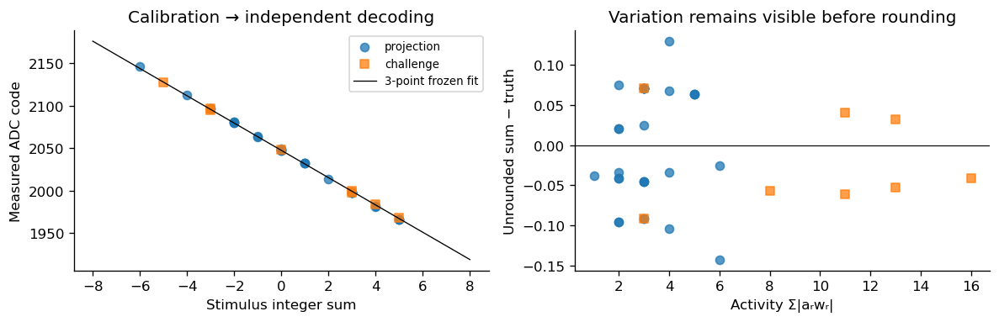

In [100]:
%%design_review calibration-holdout
x=np.array([truth(CASES[k]) for k in CAL_IDS],float)
y=np.array([CASES[k]['result_code_12bit'] for k in CAL_IDS],float)
if sorted(x.tolist())!=[-8.,0.,8.]: raise ValueError('unexpected calibration stimulus')
slope,offset=np.polyfit(x,y,1)
if abs(slope)<1: raise ValueError('unusable calibration span')
FROZEN=(float(slope),float(offset))
residual=y-(slope*x+offset)
table(['Calibration sum','Native ADC code','Fit residual / codes'],
      [[int(a),int(b),f'{r:+.6f}'] for a,b,r in zip(x,y,residual)])
print(f'Frozen calibration: code = {slope:.8f} × sum + {offset:.8f}')
print(f'Maximum calibration residual: {np.max(abs(residual)):.6f} codes')
def estimate(d): return (d['result_code_12bit']-FROZEN[1])/FROZEN[0]
def decode(d): return int(np.rint(estimate(d)))
observations=[]
for key in HOLD_IDS:
    d=CASES[key]; s=truth(d)
    observations.append({'id':key,'cohort':META[key]['cohort'],'truth':s,'code':d['result_code_12bit'],
        'estimate':float(estimate(d)),'decoded':decode(d),'residual':float(estimate(d)-s),
        'activity':int(np.sum(abs(np.asarray(d['activation_x2'])*np.asarray(d['weights'])[:,0]))),
        'latency_ns':d['start_to_eoc_s']*1e9})
table(['Holdout cohort','Patterns','Integer mismatches','Max |sum residual|'],[
    [cohort,len(group),sum(r['decoded']!=r['truth'] for r in group),f"{max(abs(r['residual']) for r in group):.6f}"]
    for cohort in ('projection','challenge')
    for group in [[r for r in observations if r['cohort']==cohort]]])
assert all(r['decoded']==r['truth'] for r in observations)
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
for cohort,marker in [('projection','o'),('challenge','s')]:
    g=[r for r in observations if r['cohort']==cohort]
    axes[0].scatter([r['truth'] for r in g],[r['code'] for r in g],label=cohort,marker=marker,alpha=.75)
    axes[1].scatter([r['activity'] for r in g],[r['residual'] for r in g],label=cohort,marker=marker,alpha=.75)
xx=np.linspace(-8,8,100); axes[0].plot(xx,slope*xx+offset,color='black',lw=.8,label='3-point frozen fit')
axes[0].set(xlabel='Stimulus integer sum',ylabel='Measured ADC code',title='Calibration → independent decoding');axes[0].legend(fontsize=8)
axes[1].axhline(0,color='black',lw=.7);axes[1].set(xlabel='Activity Σ|aᵣwᵣ|',ylabel='Unrounded sum − truth',title='Variation remains visible before rounding')
savefig('calibration_holdout.png')


### Same sum, different switching activity

The new challenge includes low/high-activity patterns at the same sums ±3, a high-activity zero, ±5 and mixed ternary signs. Activity is $\sum_r|a_rw_r|$. Equal sums can produce different analog trajectories: retain raw ADC code differences even when rounded integer decoding agrees.

In [101]:
%%design_review challenge-result
challenge=[r for r in observations if r['cohort']=='challenge']
table(['New pattern','Sum','Activity','Code','Unrounded sum','Decoded'],[
    [r['id'],r['truth'],r['activity'],r['code'],f"{r['estimate']:+.6f}",r['decoded']] for r in challenge])
for sign in ('p3','n3'):
    lo=next(r for r in challenge if r['id']==f'sum_{sign}_low')
    hi=next(r for r in challenge if r['id']==f'sum_{sign}_high')
    print(f"Same sum {lo['truth']:+d}, activity {lo['activity']} → {hi['activity']}: "
          f"ADC code {lo['code']} → {hi['code']}; Δcode = {hi['code']-lo['code']:+d}")
latencies=np.array([r['latency_ns'] for r in observations])
print(f'Measured start→EOC across {len(observations)} holdouts: '
      f'{latencies.min():.3f}…{latencies.max():.3f} ns; median {np.median(latencies):.3f} ns')


| New pattern | Sum | Activity | Code | Unrounded sum | Decoded |
| --- | --- | --- | --- | --- | --- |
| sum_p3_low | 3 | 3 | 1998 | +3.071336 | 3 |
| sum_p3_high | 3 | 13 | 2000 | +2.946822 | 3 |
| sum_n3_low | -3 | 3 | 2097 | -3.092088 | -3 |
| sum_n3_high | -3 | 13 | 2095 | -2.967575 | -3 |
| active_zero | 0 | 16 | 2048 | -0.041505 | 0 |
| sum_p5_high | 5 | 11 | 1968 | +4.939040 | 5 |
| sum_n5_high | -5 | 11 | 2127 | -4.959792 | -5 |
| mixed_weights | 4 | 8 | 1984 | +3.942931 | 4 |

Same sum +3, activity 3 → 13: ADC code 1998 → 2000; Δcode = +2
Same sum -3, activity 3 → 13: ADC code 2097 → 2095; Δcode = -2
Measured start→EOC across 38 holdouts: 214.017…214.635 ns; median 214.188 ns


### Decision 3 — accept decoded sums only after an independent frozen-fit test

The locked three-point fit decodes **38/38 held-out patterns** correctly.
Maximum absolute unrounded sum residual is **0.142672**. At equal sums ±3,
increasing activity from 3 to 13 changes the measured code by two counts,
even though integer decoding remains correct. The raw code and residual plot
make that physical variation visible.

These codes come from the coupled schematic/RTL partition. They are not
values inferred from the two-pattern PEX table. The PEX experiment established
a physical design question; this independent conversion experiment supplies
the arithmetic observations used next by the application.


<a id="argument-application"></a>

# 6. Carry the measured arithmetic to the application output

**Question:** do independently checked conversions remain correct when used
as Q/K/V/O transactions? The native acquisition below supplies each requested
projection. The reconstruction checks its activation row and weight column,
then computes CPU attention from measured Q/K/V and requests O for the
quantized measured context. Two transactions reuse already measured physical
payloads: 32 requests correspond to 30 distinct projection patterns.

The same-quantization reference tests decoding agreement. The floating-context
reference exposes context quantization error. Waveforms connect the final code
back to the analog/digital handshake, and fresh Icarus simulation checks the
real SAR controls on the recorded comparator decisions.


<a id="guide-native-runall-adc-waveform"></a>

### Before cell `native-runall-adc-waveform` — F7

**Implementation:** Plot voltage/control traces or application tensors from freshly measured records, connecting measurements to SAR sequencing and MHA results for traceable conclusions.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-runall-adc-waveform-plot_conversion"></a>`plot_conversion(flow, case_receipt)` | Read a conversion's raw/state data and plot input/comparator voltages and SAR controls around sampling/conversion; save the figure in the session work directory. |

<a id="data-native-runall-adc-waveform"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive Flow and this session's case receipt or MHA report, identifying raw/state/log files or tensors/projection records.
- **Return values and saved artifacts:** Write comparator/sample/SAR waveform or tensor/error figures under work and display them using source-record units/node names.
- **Downstream consumers:** Readers compare plots with validate-evidence/mha-recompute; the manifest/review retain links to these same-session images.


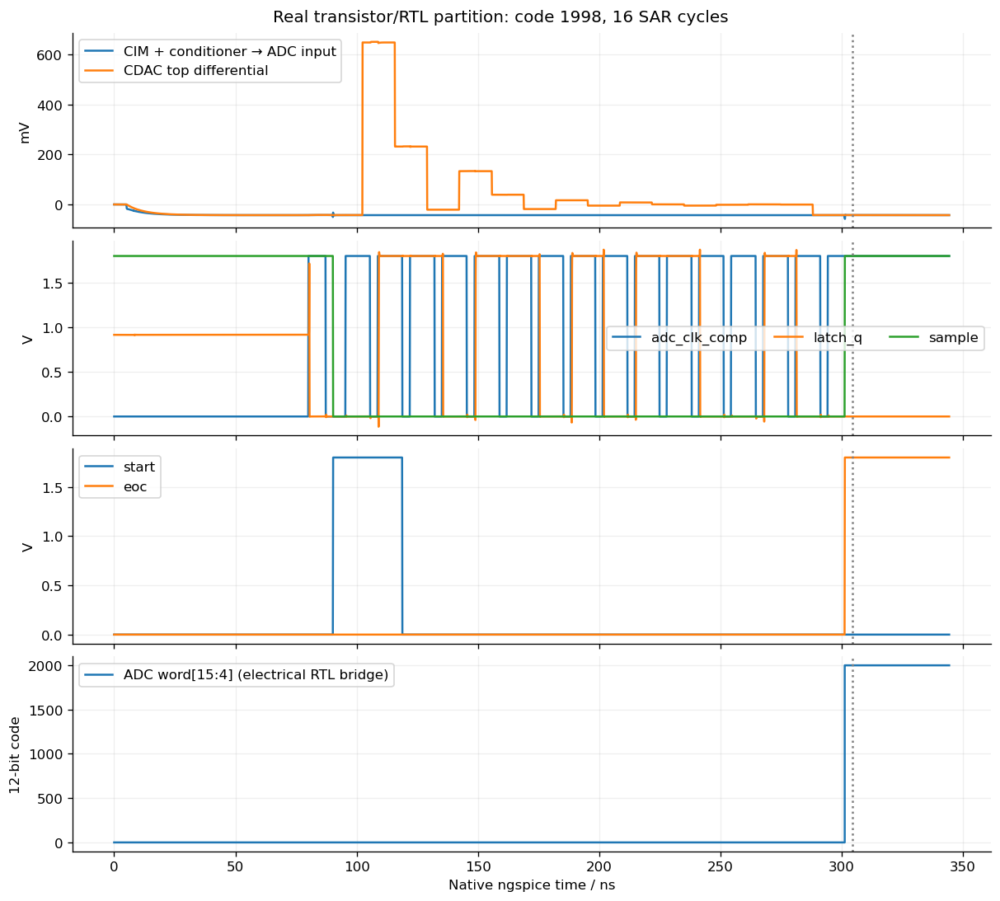

In [102]:
%%native_lab runall-adc-waveform
%%inline_module adc_plot
import json,sys,shutil,tarfile
from pathlib import Path
from automx_nb_inline_v1.support import digest,item,save,verified
ARCHIVE_SHA='e7dadfb7bd5474fd22409c1e5a67acdec19f77e597df68e17c5549bc1390d7fd'
def plot_conversion(flow,case_receipt):
    import matplotlib.pyplot as plt
    from automx_nb_inline_v1.waveforms import read_raw
    path=verified(case_receipt);summary=json.loads(path.read_text());raw=path.parent/'coupled.raw'
    # The native step receipt binds this raw waveform to the measured case.
    job=json.loads((path.parent/'step.json').read_text())
    record=next(v for v in job['outputs'] if Path(v['path'])==raw)
    waves=read_raw(verified(record));t=waves['time']*1e9
    fig,axes=plt.subplots(4,1,figsize=(10,9),sharex=True,layout='constrained')
    axes[0].plot(t,(waves['v(ainp)']-waves['v(ainn)'])*1000,label='CIM + conditioner → ADC input')
    axes[0].plot(t,(waves['v(ctopp)']-waves['v(ctopn)'])*1000,label='CDAC top differential');axes[0].set_ylabel('mV');axes[0].legend()
    for node in ('adc_clk_comp','latch_q','sample'):axes[1].plot(t,waves['v('+node+')'],label=node)
    axes[1].set_ylabel('V');axes[1].legend(ncol=3)
    for node in ('start','eoc'):axes[2].plot(t,waves['v('+node+')'],label=node)
    axes[2].set_ylabel('V');axes[2].legend()
    word=sum((waves[f'v(result_{bit})']>.9).astype(int)*(1<<bit) for bit in range(16))
    axes[3].step(t,word>>4,where='post',label='ADC word[15:4] (electrical RTL bridge)')
    axes[3].set_ylabel('12-bit code');axes[3].set_xlabel('Native ngspice time / ns');axes[3].legend()
    for ax in axes:ax.grid(alpha=.2);ax.axvline(summary['eoc_s']*1e9,color='gray',ls=':')
    fig.suptitle(f'Real transistor/RTL partition: code {summary["result_code_12bit"]}, {summary["cycles"]} SAR cycles')
    path=flow.work/'adc_native_waveform.png';fig.savefig(path,dpi=140);plt.show();plt.close(fig)
    flow.outputs['adc_waveform_png']=item(path)
    return summary

# NOTEBOOK_RUN
conversion=adc_plot.plot_conversion(flow,mha["jobs"][0]["case"])


<a id="guide-native-runall-mha-plots"></a>

### Before cell `native-runall-mha-plots` — F7

**Implementation:** Use the operation group explained in [cell `native-runall-adc-waveform`](#guide-native-runall-adc-waveform).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-runall-mha-plots-plot_mha"></a>`plot_mha(flow, report)` | Read the newly measured application report and plot projection/context/output tensors and errors using actual data. |

**Data and downstream use:** Follow the [contract described for `native-runall-adc-waveform`](#data-native-runall-adc-waveform).


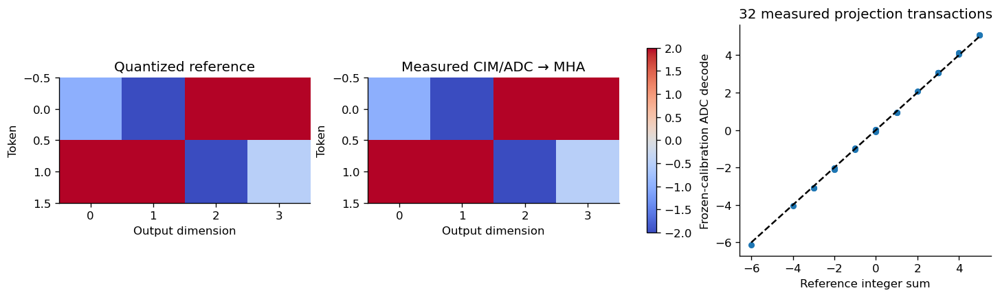

Quantized/floating relative L2: 0.0 0.114477076077953


In [103]:
%%native_lab runall-mha-plots
%%inline_module mha_plot
import json,sys,shutil,tarfile
from pathlib import Path
from automx_nb_inline_v1.support import digest,item,save,verified
ARCHIVE_SHA='e7dadfb7bd5474fd22409c1e5a67acdec19f77e597df68e17c5549bc1390d7fd'
def plot_mha(flow,report):
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,3,figsize=(12,3.5),layout='constrained')
    for ax,key,title in zip(axes,('reference_quantized_output','output'),('Quantized reference','Measured CIM/ADC → MHA')):
        image=ax.imshow(report[key],cmap='coolwarm',vmin=-2,vmax=2);ax.set_title(title);ax.set_xlabel('Output dimension');ax.set_ylabel('Token')
    rows=report['jobs'];axes[2].scatter([r['reference_integer_sum'] for r in rows],[r['unrounded_calibrated_sum'] for r in rows],s=20)
    lo=min(r['reference_integer_sum'] for r in rows);hi=max(r['reference_integer_sum'] for r in rows)
    axes[2].plot([lo,hi],[lo,hi],'k--');axes[2].set_xlabel('Reference integer sum');axes[2].set_ylabel('Frozen-calibration ADC decode');axes[2].set_title('32 measured projection transactions')
    fig.colorbar(image,ax=axes[:2],shrink=.8)
    path=flow.work/'mha_measured.png';fig.savefig(path,dpi=140);plt.show();plt.close(fig);flow.outputs['mha_png']=item(path)

# NOTEBOOK_RUN
mha_plot.plot_mha(flow,mha)
print("Quantized/floating relative L2:",mha["relative_l2"],mha["floating_reference_relative_l2"])


## 5. Rebuild the application from conversion records

Assemble Q/K/V from measured decoded sums divided by two. Compute each attention head independently, quantize the resulting context to signed E2M1 values, and obtain O from its own measured projection conversions. Check each record against its requested row and weight column.

Use **two references**: an independently calculated pipeline with the same context quantization, and the pipeline with floating context. Their difference separates context quantization from decoding agreement.

<a id="guide-mha-recompute"></a>

### Before cell `mha-recompute` — F7

**Implementation:** Reconstruct Q/K/V/O from mapped records and independently compute attention/softmax. Correct ADC codes still require verified tensor axes and both quantized/floating references to establish application assembly.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `attention(q, k, v, heads=2)` | Same task as [`mha_from_projections`](#fn-native-inline-legacy_attention-mha_from_projections). |
| `quantize_context(values)` | Same task as [`quantize_context`](#fn-native-runall-partition-sources-quantize_context). |
| `relative_l2(reference, candidate)` | Same task as [`error_metrics`](#fn-native-inline-legacy_attention-error_metrics). |
| <a id="fn-mha-recompute-measured_projection"></a>`measured_projection(stage, activation)` | Follow stage/token/output job mappings, find validated records, decode with the fixed fit, and fill projection tensors with the requested activations. |

<a id="data-mha-recompute"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive stage/row/column→case job mappings, activations/weights, validated ADC records, and FROZEN; assemble Q/K/V/O along the correct token/head axes.
- **Return values and saved artifacts:** Return measured projections, attention/context/output, and relative L2 against quantized-context and floating-context references; recorded_output is not used as the oracle.
- **Downstream consumers:** results/argument-verdict combine decoding agreement with application quantization error and save review_results.json.


| Reference | Relative L2 error |
| --- | --- |
| Same context quantization | 0.000000000 |
| Floating context | 0.114477076 |

Measured MHA output (32 transactions; 30 unique projection patterns):
 [[-1.  -2.   2.5  2.5]
 [ 2.   2.5 -3.  -0.5]]


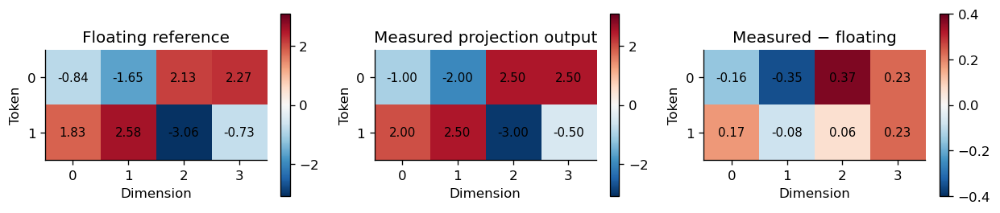

In [104]:
%%design_review mha-recompute
def attention(q,k,v,heads=2):
    q,k,v=[np.asarray(t,float) for t in (q,k,v)]
    if q.shape!=k.shape or q.shape!=v.shape or q.ndim!=2: raise ValueError('Q/K/V shape')
    n,d=q.shape
    if d%heads: raise ValueError('head dimension')
    qh,kh,vh=[t.reshape(n,heads,d//heads).transpose(1,0,2) for t in (q,k,v)]
    scores=qh@kh.transpose(0,2,1)/np.sqrt(d//heads)
    exp=np.exp(scores-scores.max(axis=-1,keepdims=True)); probabilities=exp/exp.sum(axis=-1,keepdims=True)
    return (probabilities@vh).transpose(1,0,2).reshape(n,d),probabilities
def quantize_context(values):
    magnitudes=np.array([0,.5,1,1.5,2,3,4,6]); values=np.asarray(values,float)
    nearest=magnitudes[np.argmin(abs(abs(values)[...,None]-magnitudes),axis=-1)]
    return (np.sign(values)*nearest*2).astype(int)
def relative_l2(reference,candidate):
    return float(np.linalg.norm(candidate-reference)/max(np.linalg.norm(reference),1e-12))
spec=E['mha']; a=np.asarray(spec['activation_x2']); weights={k:np.asarray(v) for k,v in spec['weights'].items()}
projections={stage:np.zeros((2,4)) for stage in ('Q','K','V','O')}
jobs=spec['jobs']
if len(jobs)!=32 or len({(j['stage'],j['row'],j['column']) for j in jobs})!=32:
    raise ValueError('missing or duplicate projection transactions')
def measured_projection(stage,activation):
    for job in [j for j in jobs if j['stage']==stage]:
        row,col,key=job['row'],job['column'],job['case']; d=CASES[key]
        if META[key]['cohort']!='projection': raise ValueError('MHA must use projection holdout')
        if d['activation_x2']!=activation[row].tolist(): raise ValueError('projection activation mismatch')
        if np.asarray(d['weights'])[:,0].tolist()!=weights[stage][:,col].tolist():
            raise ValueError('projection weight mismatch')
        projections[stage][row,col]=decode(d)/2
    return projections[stage]
q,k,v=[measured_projection(stage,a) for stage in ('Q','K','V')]
context,probabilities=attention(q,k,v)
output=measured_projection('O',quantize_context(context))
gold_context,gold_probabilities=attention(a@weights['Q']/2,a@weights['K']/2,a@weights['V']/2)
ref_quantized=quantize_context(gold_context)@weights['O']/2
ref_float=gold_context@weights['O']
assert np.allclose(probabilities.sum(axis=-1),1)
assert np.array_equal(output,ref_quantized)
assert np.allclose(output,spec['recorded_output'])
MHA_QUANT=relative_l2(ref_quantized,output); MHA_FLOAT=relative_l2(ref_float,output)
table(['Reference','Relative L2 error'],[['Same context quantization',f'{MHA_QUANT:.9f}'],
                                        ['Floating context',f'{MHA_FLOAT:.9f}']])
print('Measured MHA output (32 transactions; 30 unique projection patterns):\n',output)
fig,axes=plt.subplots(1,3,figsize=(10.5,3))
for ax,values,title in zip(axes,[ref_float,output,output-ref_float],['Floating reference','Measured projection output','Measured − floating']):
    m=ax.imshow(values,cmap='RdBu_r',vmin=-3.1 if '−' not in title else -.4,vmax=3.1 if '−' not in title else .4)
    ax.set(title=title,xlabel='Dimension',ylabel='Token');ax.set_xticks(range(4));ax.set_yticks([0,1])
    for (i,j),value in np.ndenumerate(values): ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=9)
    fig.colorbar(m,ax=ax,shrink=.7)
savefig('mha.png')


## 6. Inspect the analog/digital boundary

Read the supplied real-valued ngspice ASCII raw file directly. Show ADC input, CDAC top nodes, comparator/sample phases, start/EOC and output word on aligned time axes. The plot uses one recorded projection conversion and verifies that its final waveform code agrees with its conversion record.

<a id="guide-raw-reader"></a>

### Before cell `raw-reader` — F5, F7

**Implementation:** Use the operation group explained in [cell `native-inline-waveforms`](#guide-native-inline-waveforms).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `read_raw(path: Path)` | Same task as [`read_raw`](#fn-native-inline-waveforms-read_raw). |

**Data and downstream use:** Follow the [contract described for `native-inline-waveforms`](#data-native-inline-waveforms).


In [105]:
%%design_review raw-reader
def read_raw(path: Path) -> dict[str, np.ndarray]:
    """Read the single real transient plot written by ``set filetype=ascii``.

    Reject incomplete, complex, binary, duplicate and nonfinite evidence.
    Bounds prevent a corrupt header from allocating an unbounded array.
    """
    with Path(path).open(encoding="utf-8", errors="strict") as stream:
        headers = {}
        for line in stream:
            key, sep, value = line.partition(":")
            if not sep:
                raise ValueError("invalid raw header")
            key = key.strip().lower()
            if key == "variables":
                break
            headers[key] = value.strip()
        else:
            raise ValueError("raw file has no variable table")
        if headers.get("flags", "").split() != ["real"]:
            raise ValueError("a real ASCII raw plot is required")
        if "transient" not in headers.get("plotname", "").lower():
            raise ValueError("a transient plot is required")
        try:
            nv, np_ = int(headers["no. variables"]), int(headers["no. points"])
        except (KeyError, ValueError) as error:
            raise ValueError("invalid raw dimensions") from error
        if not 2 <= nv <= 256 or not 2 <= np_ <= 5_000_000 or nv*np_ > 10_000_000:
            raise ValueError("raw dimensions exceed the diagnostic limits")
        names = []
        for index in range(nv):
            parts = stream.readline().split()
            if len(parts) != 3 or parts[0] != str(index):
                raise ValueError("invalid raw variable index")
            names.append(parts[1].lower())
        if len(names) != len(set(names)) or names[0] != "time":
            raise ValueError("raw variables must be unique and start with time")
        if stream.readline().strip().lower() != "values:":
            raise ValueError("raw data must use ASCII Values, not Binary")
        values = np.empty((np_, nv), dtype=float)
        for point in range(np_):
            for var in range(nv):
                line = stream.readline()
                # ngspice 31 writes a blank separator after every complete
                # point. Skip separators only here, never within its values:
                # a missing scalar must still be treated as truncated data.
                if var == 0:
                    while line and not line.strip():
                        line = stream.readline()
                parts = line.split()
                if var == 0:
                    if len(parts) != 2 or parts[0] != str(point):
                        raise ValueError("missing or unordered raw point")
                    item = parts[1]
                else:
                    if len(parts) != 1:
                        raise ValueError("truncated raw point")
                    item = parts[0]
                try:
                    values[point, var] = float(item)
                except ValueError as error:
                    raise ValueError("invalid raw scalar") from error
        if stream.read().strip():
            raise ValueError("unexpected second plot or trailing raw data")
    if not np.isfinite(values).all() or not np.all(np.diff(values[:, 0]) > 0):
        raise ValueError("raw values must be finite with increasing time")
    return {name: values[:, i] for i, name in enumerate(names)}

# CELL_RESULT raw-reader
print('read_raw(path): time, voltage and current arrays',flush=True)


read_raw(path): time, voltage and current arrays


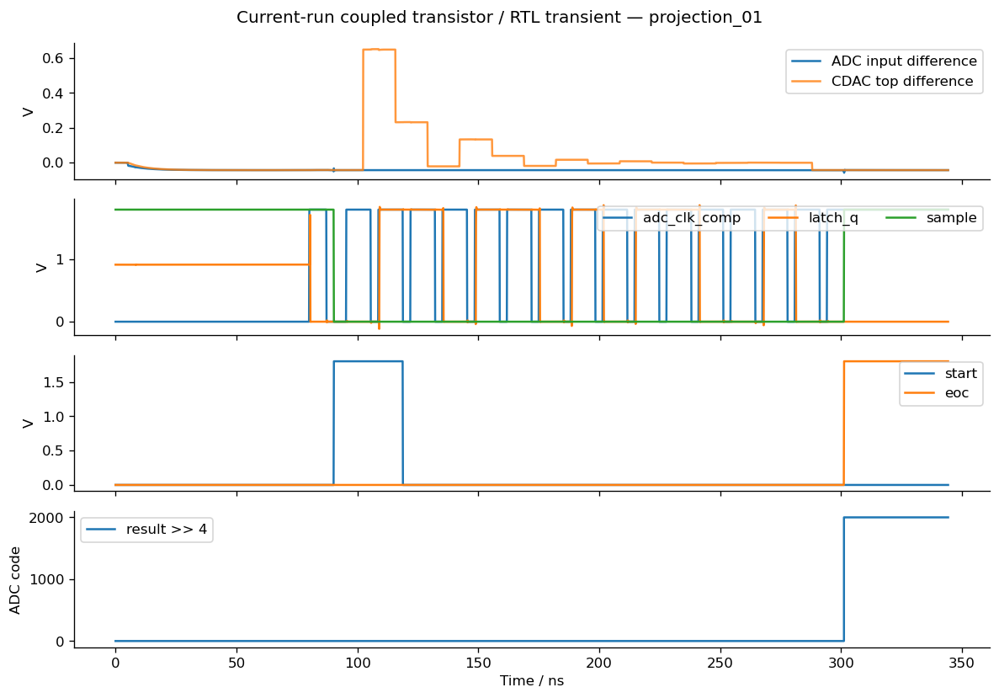

Current-run Icarus state transcript for this waveform:
STATE 1 0 0000 0 0 ff7f ff80 00000000 0 0 feff ff00 fffffffe 7 1
STATE 0 1 0000 0 0 ff7f ff80 00000000 0 0 feff ff00 fffffffe 7 1
STATE 0 1 0000 0 0 f7ff f800 07ffffff 2 0 ffef fff0 f0000000 5 1
STATE 0 1 0000 0 0 fdff fe00 00ffffff 0 0 ffbf ffc0 fe000000 7 1
STATE 0 1 0000 0 0 feff ff00 fffffff0 7 0 ff7f ff80 00000007 0 1
STATE 0 1 0000 0 0 feff ff00 fc000000 3 0 ff7f ff80 01ffffff 4 1
STATE 0 1 0000 0 0 feff ff00 fffff000 1 0 ff7f ff80 000007ff 6 1
STATE 0 1 0000 0 0 feff ff00 fffffff0 4 0 ff7f ff80 00000007 3 1
STATE 0 1 0000 0 0 feff ff00 fffffe00 3 0 ff7f ff80 000000ff 4 1
STATE 0 1 0000 0 0 feff ff00 ffffffc0 4 0 ff7f ff80 0000001f 3 1
STATE 0 1 0000 0 0 feff ff00 ffffff00 5 0 ff7f ff80 0000007f 2 1
STATE 0 1 0000 0 0 feff ff00 ffffff80 6 0 ff7f ff80 0000003f 1 1
STATE 0 1 0000 0 0 feff ff00 ffffffc0 4 0 ff7f ff80 0000001f 3 1
STATE 0 1 0000 0 0 feff ff00 ffffffc0 0 0 ff7f ff80 0000001f 7 1
STATE 0 1 0000 0 0 feff ff00 ffffff

In [106]:
%%design_review waveform
wave=read_raw(BASE/E['waveform']['path']); case=CASES[E['waveform']['case']]
t=wave['time']*1e9
fig,axes=plt.subplots(4,1,figsize=(10,7),sharex=True)
axes[0].plot(t,wave['v(ainp)']-wave['v(ainn)'],label='ADC input difference')
axes[0].plot(t,wave['v(ctopp)']-wave['v(ctopn)'],label='CDAC top difference',alpha=.8)
axes[0].set_ylabel('V');axes[0].legend(loc='upper right')
for key in ('adc_clk_comp','latch_q','sample'):
    axes[1].plot(t,wave[f'v({key})'],label=key)
axes[1].set_ylabel('V'); axes[1].legend(loc='upper right',ncol=3)
for key in ('start','eoc'): axes[2].plot(t,wave[f'v({key})'],label=key)
axes[2].set_ylabel('V');axes[2].legend(loc='upper right')
word=sum((wave[f'v(result_{i})']>.9).astype(int)*(1<<i) for i in range(16))
axes[3].step(t,word>>4,where='post',label='result >> 4'); axes[3].legend(loc='upper left')
axes[3].set(xlabel='Time / ns',ylabel='ADC code')
assert int(word[-1]>>4)==case['result_code_12bit']
fig.suptitle('Current-run coupled transistor / RTL transient — '+E['waveform']['case'])
savefig('coupled_waveform.png')
print('Current-run Icarus state transcript for this waveform:')
print((BASE/META[E['waveform']['case']]['rtl_log']).read_text())


### Fresh open-source tool check: the actual SAR RTL

Compile the bundled upstream SAR/decoder/OSR/core RTL with Icarus. Feed each recorded analog comparator decision to a fresh simulator process. Compare **all internal control outputs**, including CDAC controls and EOC, with every recorded state. This independently executes the digital side of the partition; the analog decisions remain the supplied measured inputs. Native command output follows directly from `subprocess` in the cell.

<a id="guide-rtl-testbench"></a>

### Before cell `rtl-testbench` — F7

**Implementation:** Generate SAR testbenches/Icarus runners and collect execution transcripts. Replaying recorded inputs/states detects ADC pin-mapping and code-interface errors.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `testbench()` | Same task as [`testbench`](#fn-native-inline-cosim-testbench). |

<a id="data-rtl-testbench"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive source SAR RTL, stimuli/configuration/reset, and expected code/control states; run_tool accepts argv, optional stdin, env, and timeout.
- **Return values and saved artifacts:** Write/compile testbenches, run each case in vvp, and return transcripts with pass/code/EOC tables based on 41 validated session records.
- **Downstream consumers:** results reports fresh_native_rtl_cases; this rechecks SAR interfaces/state rather than replacing the ngspice conversion measurements.


In [107]:
%%design_review rtl-testbench
def testbench():
    fields=' '.join('%h' for _ in RTL_FIELDS)
    args='sample,sample_n,result,eoc,eoc_osr,pr,pro,pc,pb,p0,nr,nro,nc,nb,n0'
    return '''`timescale 1ns/1ps
module cosim;
reg clk=0,rst=1,decision=0;
integer value,rc;
wire sample,sample_n,eoc,eoc_osr,ena;
wire [15:0] result,pr,pro,nr,nro;
wire [31:0] pc,nc;
wire [2:0] pb,nb;
wire p0,n0;
adc_core_digital dut(.rst_n(rst),.config_1_in(16'h0400),.config_2_in(16'h8421),
 .result_out(result),.conv_finished_out(eoc),.conv_finished_osr_out(eoc_osr),
 .comparator_in(decision),.clk_dig_in(clk),.enable_loop_out(ena),
 .sample_matrix_out(sample),.sample_matrix_out_n(sample_n),
 .pmatrix_row_out_n(pr),.pmatrix_rowon_out_n(pro),.pmatrix_col_out_n(pc),
 .pmatrix_bincap_out_n(pb),.pmatrix_c0_out_n(p0),
 .nmatrix_row_out_n(nr),.nmatrix_rowon_out_n(nro),.nmatrix_col_out_n(nc),
 .nmatrix_bincap_out_n(nb),.nmatrix_c0_out_n(n0));
initial begin
 #1;rst=0;#1;clk=1;#1;clk=0;#1;rst=1;#1;
 $display("STATE '''+fields+'''",'''+args+''');$fflush();
 forever begin
  rc=$fscanf(32'h80000000,"%d",value);
  if(rc!=1)$finish;
  decision=value;#1;clk=1;#1;clk=0;#1;
  $display("STATE '''+fields+'''",'''+args+''');$fflush();
 end
end
endmodule
'''

TESTBENCH=testbench()

# CELL_RESULT rtl-testbench
print('testbench(): SAR comparison/word/EOC replay',flush=True)


testbench(): SAR comparison/word/EOC replay


<a id="guide-rtl-native"></a>

### Before cell `rtl-native` — F7

**Implementation:** Use the operation group explained in [cell `rtl-testbench`](#guide-rtl-testbench).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-rtl-native-run_tool"></a>`run_tool(args, *, input_text=None, env=None, timeout=90)` | Run a host tool with optional stdin/environment/timeout, retain its full log, require a valid return code, and return the checker transcript. |

**Data and downstream use:** Follow the [contract described for `rtl-testbench`](#data-rtl-testbench).


In [108]:
%%design_review rtl-native
def run_tool(args, *, input_text=None, env=None, timeout=90):
    print('RUN:', ' '.join(map(str,args)),flush=True)
    started=time.monotonic()
    result=subprocess.run(list(map(str,args)),input=input_text,text=True,
        stdout=subprocess.PIPE,stderr=subprocess.STDOUT,env=env,timeout=timeout,cwd=OUT)
    print(result.stdout,end='' if result.stdout.endswith('\n') else '\n',flush=True)
    print('EXIT:',result.returncode,'| elapsed_s:',round(time.monotonic()-started,3),flush=True)
    if result.returncode: raise RuntimeError('Native tool failed')
    return result.stdout
rtl_results=[]
available=shutil.which('iverilog') and shutil.which('vvp')
if NATIVE=='on' and not available: raise FileNotFoundError('Install Icarus Verilog (iverilog + vvp)')
if NATIVE!='off' and available:
    bench=OUT/'cosim.sv';bench.write_text(TESTBENCH)
    exe=OUT/'sar.vvp'
    files=sorted((BASE/'rtl').glob('*.v'))
    run_tool(['iverilog','-V'])
    run_tool(['iverilog','-g2012','-s','cosim','-o',exe,bench,*files])
    for key,d in CASES.items():
        decisions=[str(t['decision']) for t in d['trace']]
        print('LIVE RTL REPLAY:',key,'| recorded analog decisions; fresh digital simulation')
        text=run_tool(['vvp',exe],input_text='0\n'+'\n'.join(decisions)+'\n')
        states=parse_states(text)
        if len(states)!=18 or states[2:]!=[t['rtl'] for t in d['trace']]:
            raise AssertionError('Native RTL state replay mismatch: '+key)
        (OUT/(key+'.rtl.log')).write_text(text)
        rtl_results.append(key)
    print('Native RTL:',len(rtl_results),'cases × 16 states ×',len(RTL_FIELDS),'signals matched.')
else:
    print('Native RTL not executed. Recorded-state validation above completed.')


RUN: iverilog -V


Icarus Verilog version 10.3 (stable) ()

Copyright 1998-2015 Stephen Williams

  This program is free software; you can redistribute it and/or modify
  it under the terms of the GNU General Public License as published by
  the Free Software Foundation; either version 2 of the License, or
  (at your option) any later version.

  This program is distributed in the hope that it will be useful,
  but WITHOUT ANY WARRANTY; without even the implied warranty of
  MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
  GNU General Public License for more details.

  You should have received a copy of the GNU General Public License along
  with this program; if not, write to the Free Software Foundation, Inc.,
  51 Franklin Street, Fifth Floor, Boston, MA 02110-1301, USA.

Icarus Verilog Preprocessor version 10.3 (stable) ()

Copyright (c) 1999-2011,2015 Stephen Williams (steve@icarus.com)
  This program is free software; you can redistribute it and/or modify
  it under the terms of the

EXIT: 0 | elapsed_s: 0.01


RUN: iverilog -g2012 -s cosim -o /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/sar.vvp /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/cosim.sv /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/review_data/rtl/adc_clkgen_with_edgedetect.v /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/review_data/rtl/adc_control_nonbinary.v /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/review_data/rtl/adc_core_digital.v /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/review_data/rtl/adc_osr.v /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/review_data/rtl/adc_row_col_decoder.v


EXIT: 0 | elapsed_s: 0.017


LIVE RTL REPLAY: calibration_01 | recorded analog decisions; fresh digital simulation
RUN: vvp /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/sar.vvp


... (119 outputs left out)

LIVE RTL REPLAY: mixed_weights | recorded analog decisions; fresh digital simulation
RUN: vvp /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/sar.vvp


STATE 1 0 0000 0 0 ff7f ff80 00000000 0 0 feff ff00 fffffffe 7 1
STATE 0 1 0000 0 0 ff7f ff80 00000000 0 0 feff ff00 fffffffe 7 1
STATE 0 1 0000 0 0 f7ff f800 07ffffff 2 0 ffef fff0 f0000000 5 1
STATE 0 1 0000 0 0 fdff fe00 00ffffff 0 0 ffbf ffc0 fe000000 7 1
STATE 0 1 0000 0 0 feff ff00 fffffff0 7 0 ff7f ff80 00000007 0 1
STATE 0 1 0000 0 0 feff ff00 fc000000 3 0 ff7f ff80 01ffffff 4 1
STATE 0 1 0000 0 0 feff ff00 fffff000 1 0 ff7f ff80 000007ff 6 1
STATE 0 1 0000 0 0 feff ff00 fffffff0 4 0 ff7f ff80 00000007 3 1
STATE 0 1 0000 0 0 feff ff00 fffffe00 3 0 ff7f ff80 000000ff 4 1
STATE 0 1 0000 0 0 feff ff00 ffffffc0 4 0 ff7f ff80 0000001f 3 1
STATE 0 1 0000 0 0 feff ff00 ffffff00 5 0 ff7f ff80 0000007f 2 1
STATE 0 1 0000 0 0 feff ff00 fffffe00 4 0 ff7f ff80 000000ff 3 1
STATE 0 1 0000 0 0 feff ff00 ffffff00 2 0 ff7f ff80 0000007f 5 1
STATE 0 1 0000 0 0 feff ff00 fffffe00 6 0 ff7f ff80 000000ff 1 1
STATE 0 1 0000 0 0 feff ff00 ffffff00 0 0 ff7f ff80 0000007f 7 1
STATE 0 1 0000 0 0 feff f

EXIT: 0 | elapsed_s: 0.013


Native RTL: 41 cases × 16 states × 15 signals matched.


### Decision 4 — report agreement and quantization separately

Measured MHA matches the independently reconstructed same-quantization
reference exactly. Relative L2 against floating context is **0.114477076**.
Thus the result supports the measured projection path and identifies the
remaining context-quantization difference explicitly. The tiny workload is
the two-token / four-dimension / two-head case specified in Section 1.

**Next test:** connect the design to its physical artifacts and read the
geometry, connectivity and timing checks according to the question each answers.


<a id="argument-physical"></a>

# 7. Attach physical implementation evidence to the functional result

The following cells expose synthesis and the mixed-signal top handoff, using
the declared routed database as the input to physical export. GDS geometry,
signal matching, rail connectivity and extracted digital timing each check a
different part of that handoff. The actual compressed top GDS can be read and
rendered again with KLayout from this package.

Keep the evidence paths separate: application codes come from the coupled
partition; the exported top is supported by its own geometry/connectivity
and timing reports. This preserves the connection between circuit behavior
and implementation artifacts without substituting one check for another.


## Verification meanings and result interpretation

These checks answer different questions. Physical rules, schematic/layout
connectivity, and parasitic extraction are described in
[SKY130 — Physical & Design Verification](https://skywater-pdk.readthedocs.io/en/main/verification.html).

| Check | Question | Results to inspect |
|---|---|---|
| Transistor simulation / co-simulation | Do voltages, timing, and codes respond to the stimuli? | Waveforms, voltage measurements, comparator decisions, word, and EOC. |
| RTL regression | Do control sequences and logical outputs match the reference? | Transactions, reset/handshakes, expected/actual, and mismatch counts. |
| DRC | Does geometry satisfy enabled rules? | Rules, marker locations, violation counts, and completion status. |
| LVS | Do extracted connections/devices correspond to the schematic/reference? | Match/mismatch and differing nets/devices. |
| PEX / RCX | Which parasitic resistance/capacitance belongs in post-layout checks? | RC netlist/SPEF, extraction source, and extracted nodes/nets. |
| STA | Do digital paths satisfy clock/timing constraints? | Setup/hold slack, path reports, slew/capacitance/fanout. |
| Power connectivity | Are supply terminals connected to their intended rails? | VPWR/VGND connectivity and checker results. |

OpenRCX extracts routing R/C and exports SPEF for timing analysis, as described in
[OpenROAD — Parasitics Extraction](https://openroad.readthedocs.io/en/latest/main/src/rcx/README.html).

Linear calibration models ADC code $d$ and integer sum $s$ as
$d\approx\alpha s+\beta$. Freeze $\alpha,\beta$ on calibration before applying
$\widehat s=(d-\beta)/\alpha$ to holdout. MHA comparisons report quantized-context
and floating references separately:

$$e_{rel}=\frac{\lVert Y_{measured}-Y_{reference}\rVert_2}{\max(\lVert Y_{reference}\rVert_2,\varepsilon)}.$$

A mismatch or violation provides diagnostic input for the next revision.
Inspect its stimulus, measurement conditions, and tool log to determine the cause.

Process and verification documentation: [[6]](#ref-6), [[11]](#ref-11), [[12]](#ref-12), [[14]](#ref-14), [[15]](#ref-15).


## 7. Yosys: synthesize the digital wrapper and SAR

Read wrapper, sequencer, and original SAR RTL; check hierarchy, synthesize,
map flops/ABC using SKY130 Liberty, check assertions, and export mapped Verilog.
Cell output retains native Yosys logs.

Synthesis documentation: [[9]](#ref-9).


In [109]:
%%native_lab runall-synthesis
%%inline_module synthesis
from automx_standalone import synthesize_sar,synthesize
# NOTEBOOK_RUN
synthesis.synthesize_sar(flow)
synthesis.synthesize(flow)


sar_synthesis: docker


   Number of cells:               1351


Yosys 0.30+48 (git sha1 14d50a176d5, gcc 8.3.1 -fPIC -Os)


sar_synthesis: exit=0; 3.53 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/sar_synthesis/sar_synthesis.native.log


COLD TOP IMPLEMENTATION COMPLETED: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/design/runs/cold/results/final/gds/automx_cim_mixed_signal_proto.gds


## 8. OpenROAD + KLayout: construct the mixed-signal core top

Export DEF/LEF from the validated routed ODB and merge GDS with native KLayout.
Compare complete geometry, transforms, and hierarchy against the source GDS.
Output retains each KLayout check's status/log; OpenROAD routing violations
are read separately in the implementation table.

Physical flow and layout tools: [[10]](#ref-10), [[11]](#ref-11), [[13]](#ref-13).


### Routing inputs and fresh GDS export

The next cell prints the input ODB path and runs OpenROAD/KLayout to generate
DEF/LEF/GDS and new logs.


<a id="guide-native-story-routing_progress"></a>

### Before cell `native-story-routing_progress` — F8

**Implementation:** Read and present the active top implementation's progress, connecting RTL/macro sources to the routing results passed to streamout.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-routing_progress-routing_progress"></a>`routing_progress(root)` | Read implementation-flow OpenROAD reports and present metrics/violations under their actual labels; definitions also retain support for earlier recipes. |

<a id="data-native-story-routing_progress"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive root and specified implementation reports/receipts, with tool/stage-labelled metrics and individual execution statuses.
- **Return values and saved artifacts:** Return routing/violation progress and the source of the exported view; the active invocation uses only the configured notebook path.
- **Downstream consumers:** streamout reads the exact routed database; GDS-audit, rendering, and signal-lvs verify newly exported views.


In [110]:
%%native_lab story-routing_progress
%%inline_module story_routing_progress
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def routing_progress(root):
    """Parse real independent OpenROAD reports, including indented violations."""
    import matplotlib.pyplot as plt
    rows=[];records=[]
    for suffix in ('05','06','07','08'):
        tag='antenna_safe_srv_20261022_'+suffix
        data=read_report(root,PHYSICAL+tag+'/summary.json')
        report=Path(root)/'build/flow2_wrapper_integration'/tag/'independent.drc'
        text=report.read_text();counts=Counter(re.findall(r'^\s*violation type:\s*(.+?)\s*$',text,re.M))
        # An empty file alone is insufficient: bind it to a finished tool/log receipt.
        check=data['checks']['subset'];log=Path(root)/check['log']['path'];native=log.read_text()
        if check['returncode']!=0 or fingerprint(log)!=check['log']['sha256'] or 'AUTOMX_SUBSET_DRC_DONE' not in native:raise ValueError('Independent DRC did not finish')
        if report.stat().st_size!=data['independent_drc_bytes']:raise ValueError('DRC report size changed')
        odb=Path(root)/data['candidate_odb']['path']
        if odb.is_file() and fingerprint(odb)!=data['candidate_odb']['sha256']:raise ValueError('Candidate ODB changed')
        if suffix=='08' and not odb.is_file():raise FileNotFoundError(odb)
        rows.append([suffix,len(data['rollback_nets']),sum(counts.values()),counts.get('Short',0),counts.get('Cut Short',0)])
        records.append({'iteration':suffix,'markers':sum(counts.values()),'counts':dict(counts),'report':{'path':str(report),'sha256':fingerprint(report)},'log':check['log'],'candidate_odb':data['candidate_odb']})
        if suffix=='05':
            print('ARCHIVED VIOLATION — OpenROAD native report:',report)
            print('\n'.join(text.splitlines()[:10]))
    table(['ECO iteration','Restored routed nets','Independent DRC markers','Short','Cut Short'],rows)
    print('Change: selectively restore conflicting routed nets after diode ECO; recheck every candidate using independent OpenROAD DRC.')
    log=Path(root)/records[-1]['log']['path'];native=log.read_text().splitlines()
    print('SAVED NATIVE OPENROAD LOG:',log)
    print('\n'.join(native[:3]+[line for line in native if 'AUTOMX_SUBSET_DRC_DONE' in line]))
    fig,ax=plt.subplots(figsize=(8,3),layout='constrained');ax.plot([r[0] for r in rows],[r[2] for r in rows],'o-');ax.set_xlabel('ECO iteration');ax.set_ylabel('Independent OpenROAD DRC markers');ax.grid(alpha=.25)
    for row in rows:ax.annotate(str(row[2]),(row[0],row[2]),xytext=(0,7),textcoords='offset points')
    plt.show();plt.close(fig)
    EVIDENCE['routing']=records
    return records

# NOTEBOOK_RUN
history.review_reports(ROOT,[str(flow.work/'cold_pnr/step.json')],label='routing')


| step | Result |
|---|---|
| returncode | 0 |
| identity.cold_start | True |
| elapsed_s | 508.395 |
| outputs |  |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/step.json`

<a id="results-area"></a>

### Area and controller/ADC cost

**Implementation:** Read macro master footprints from LEF, compare their sum
with the new routed ODB, and independently synthesize controller/SAR using the
same Yosys/TT Liberty. LEF means Layout Exchange Format; ODB is the OpenROAD
database; CTS means Clock Tree Synthesis. The table distinguishes standard-cell
master area from die footprint. The ADC macro already includes its original
digital logic; separately synthesized SAR area is for cost analysis and is not
added twice. Both PWM modes use identical hardware, so area difference is zero.
Inputs are this run's LEF/ODB/RTL; outputs are tool reports and `area_comparison.json`.


In [111]:
import json,re
from pathlib import Path
from IPython.display import Markdown,display
meter_area_dir=flow.work/'area_inventory';meter_area_dir.mkdir()
meter_odb=portable.inputs(flow)[1]['odb']
meter_tcl=meter_area_dir/'inventory.tcl';meter_area_json=meter_area_dir/'placed_area.json'
meter_tcl.write_text('read_db {'+str(meter_odb)+r'''}
set block [ord::get_db_block]
set dbu [$block getDbUnitsPerMicron]
set die [$block getDieArea]
set die_area [expr {double([$die dx])*[$die dy]/$dbu/$dbu}]
set macro 0.0;set logic 0.0;set physical 0.0;set count 0
foreach inst [$block getInsts] {
 set master [$inst getMaster]
 set a [expr {double([$master getWidth])*[$master getHeight]/$dbu/$dbu}]
 if {[$master isBlock]} {set macro [expr {$macro+$a}]} elseif {[regexp {SPACER|WELLTAP|ENDCAP|TAPCELL} [$master getType]]} {set physical [expr {$physical+$a}]} else {set logic [expr {$logic+$a}];incr count}
}
set f [open {'''+str(meter_area_json)+r'''} w]
puts $f [format {"die_um2":%.9f,"macro_um2":%.9f,"placed_logic_um2":%.9f,"physical_cells_um2":%.9f,"logic_instances":%d} $die_area $macro $logic $physical $count]
close $f
puts "MEASURED_PLACED_AREA die=$die_area macro=$macro logic=$logic physical=$physical instances=$count"
exit
''')
flow.run('measured_area',portable.container(ROOT,'openroad',['-exit',meter_tcl],'automx-area-'+str(__import__('os').getpid()),meter_area_dir),
 inputs=[meter_odb,meter_tcl],outputs=[meter_area_json],cwd=meter_area_dir,timeout_s=90)
meter_placed=json.loads('{'+meter_area_json.read_text().strip()+'}')
meter_areas=[]
_block_names={'automx_cim_core_acquisition_proto':'Core + acquisition','automx_cim_condition_mux_proto':'Conditioner + mux','adc_top':'SAR ADC','automx_mha_ip':'MHA hard macro','automx_cim_readout_seq':'Readout/calibration hard macro'}
for _lef_path in portable.PNR['config']['EXTRA_LEFS']:
    _lef_text=Path(_lef_path).read_text();_master=re.search(r'MACRO\s+(\S+)',_lef_text)[1]
    meter_w,meter_h=map(float,re.search(r'SIZE\s+([\d.]+)\s+BY\s+([\d.]+)',_lef_text).groups())
    meter_areas.append({'block':_block_names.get(_master,_master),'area_um2':meter_w*meter_h,'source':str(_lef_path),'kind':'macro footprint'})
meter_areas += [{'block':'Top glue + CTS/buffers','area_um2':meter_placed['placed_logic_um2'],'source':str(meter_odb),'kind':'placed standard-cell master area'},
 {'block':'Die bounding area','area_um2':meter_placed['die_um2'],'source':str(meter_odb),'kind':'die footprint'}]
# Independent synthesis measures controller and SAR in the same library/flow.
meter_lib=ROOT/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
for meter_top,meter_sources_area in [('automx_cim_readout_seq',[ROOT/'rtl/automx_cim_readout_seq.sv']),
 ('adc_core_digital',[ROOT/'third_party/SKY130_SAR_ADC1/mixed_signal_partition/verilog/rtl'/x for x in ['adc_control_nonbinary.v','adc_row_col_decoder.v','adc_osr.v','adc_core_digital.v']])]:
    meter_ys=meter_area_dir/(meter_top+'.ys');meter_stat=meter_area_dir/(meter_top+'.stat.json')
    meter_ys.write_text(f'read_liberty -lib "{meter_lib}"\n'+''.join(f'read_verilog -sv "{p}"\n' for p in meter_sources_area)+
     f'hierarchy -check -top {meter_top}\nsynth -top {meter_top} -flatten\ndfflibmap -liberty "{meter_lib}"\nabc -liberty "{meter_lib}"\nclean\n'+
     f'tee -o {meter_stat} stat -json -liberty "{meter_lib}"\n')
    flow.run('area_'+meter_top,portable.container(ROOT,'yosys',['-s',meter_ys],'automx-area-'+meter_top,meter_area_dir),
     inputs=[meter_ys,meter_lib,*meter_sources_area],outputs=[meter_stat],cwd=meter_area_dir,timeout_s=180)
    meter_stats=json.loads(meter_stat.read_text());meter_module=next(iter(meter_stats['modules'].values()))
    meter_areas.append({'block':meter_top,'area_um2':meter_module['area'],'cells':meter_module['num_cells'],
      'source':str(meter_stat),'kind':'TT mapped cell area; same synthesis recipe'})
mha_area_record=json.loads((portable.WORK/'mha_ip/synthesis/synthesis.json').read_text())['targets'][0]
meter_areas.append({'block':'MHA RTL IP (standalone mapped)','area_um2':mha_area_record['mapped_area_um2'],
 'cells':mha_area_record['mapped_cells'],'source':mha_area_record['log'],'kind':'TT mapped cell area; included within placed top, do not add twice'})
display(Markdown('| Block | Area / µm² | Meaning | Source |\n|---|---|---|---|\n'+'\n'.join(
 f"| {r['block']} | {r['area_um2']:.3f} | {r['kind']} | `{Path(r['source']).name}` |" for r in meter_areas)))
assert abs(sum(r['area_um2'] for r in meter_areas if r['kind']=='macro footprint')-meter_placed['macro_um2'])<1.0
save(flow.work/'area_comparison.json',{'blocks':meter_areas,'placed':meter_placed,
 'baseline':'PWM100 and PWM50 use identical physical hardware: area delta = 0. Only input pulse width is changed.',
 'accounting':'ADC macro already contains its native digital; separately synthesized SAR is a reference breakdown, never added twice to top area.'})
flow.outputs['area_comparison']=item(flow.work/'area_comparison.json')
print('PWM100 vs PWM50 physical area change: 0 µm² (same hardware). Controller storage/decoder cost is included; SAR reference is not double-counted in ADC macro.')


measured_area: docker


OpenROAD 41a51eaf4ca2171c92ff38afb91eb37bbd3f36da 


MEASURED_PLACED_AREA die=5040000.0 macro=1803063.104 logic=48031.06559999665 physical=63365.77279995793 instances=5971


measured_area: exit=0; 1.24 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/area_inventory/measured_area.native.log


area_automx_cim_readout_seq: docker


Creating register for signal `\automx_cim_readout_seq.\decode_done' using process `\automx_cim_readout_seq.$proc$/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/rtl/automx_cim_readout_seq.sv:148$205'.


... (5 outputs left out)

Yosys 0.30+48 (git sha1 14d50a176d5, gcc 8.3.1 -fPIC -Os)


area_adc_core_digital: exit=0; 3.35 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/area_inventory/area_adc_core_digital.native.log


| Block | Area / µm² | Meaning | Source |
|---|---|---|---|
| Core + acquisition | 238809.064 | macro footprint | `core.lef` |
| Conditioner + mux | 196285.040 | macro footprint | `conditioner.lef` |
| SAR ADC | 170469.000 | macro footprint | `adc.lef` |
| MHA hard macro | 260000.000 | macro footprint | `automx_mha_ip.lef` |
| Readout/calibration hard macro | 937500.000 | macro footprint | `automx_cim_readout_seq.lef` |
| Top glue + CTS/buffers | 48031.066 | placed standard-cell master area | `automx_cim_mixed_signal_proto.odb` |
| Die bounding area | 5040000.000 | die footprint | `automx_cim_mixed_signal_proto.odb` |
| automx_cim_readout_seq | 175447.018 | TT mapped cell area; same synthesis recipe | `automx_cim_readout_seq.stat.json` |
| adc_core_digital | 8415.571 | TT mapped cell area; same synthesis recipe | `adc_core_digital.stat.json` |
| MHA RTL IP (standalone mapped) | 52288.899 | TT mapped cell area; included within placed top, do not add twice | `automx_mha_ip.yosys.log` |

PWM100 vs PWM50 physical area change: 0 µm² (same hardware). Controller storage/decoder cost is included; SAR reference is not double-counted in ADC macro.


In [112]:
%%native_lab runall-streamout
%%inline_module streamout
from automx_standalone import streamout
# NOTEBOOK_RUN
top_gds=streamout.streamout(flow)


export: docker


OpenROAD 41a51eaf4ca2171c92ff38afb91eb37bbd3f36da 


export: exit=0; 3.44 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/streamout/export.native.log


In [113]:
%%native_lab runall-gds-audit
%%inline_module gds_audit
from automx_standalone import audit_gds
# NOTEBOOK_RUN
audit=gds_audit.audit_gds(flow)


geometry: klayout


geometry: exit=0; 18.82 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/gds_audit/geometry.native.log


drc: docker



BOUNDED_TOOL_TIMEOUT


drc: exit=124; 46.33 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/gds_audit/drc.native.log


"output" in: sky130A_mr.drc:369
    Edge pairs: 0 (flat)  0 (hierarchical)
    Elapsed: 0.120s  Memory: 1120.00M
"space" in: sky130A_mr.drc:370
    Edge pairs: 0 (flat)  0 (hierarchical)
    Elapsed: 0.020s  Memory: 1120.00M
"output" in: sky130A_mr.drc:370
    Edge pairs: 0 (flat)  0 (hierarchical)
    Elapsed: 0.020s  Memory: 1120.00M
"interacting" in: sky130A_mr.drc:371

BOUNDED_TOOL_TIMEOUT


<a id="results-layout"></a>

### Top GDS with fixed display settings

**Implementation:** KLayout reads the exact new GDS using fixed SKY130 colors,
with grid and overlapping labels disabled. Overview uses met3–met5; subsequent
details use met1–met5. Logs identify `shown_layers`; dense standard-cell regions
are actual current-run geometry. Macro images also show device layers. Rendering
does not alter polygons or instance placement. The final independent render
uses the same script/settings to check consistency.


<a id="guide-native-runall-render-top"></a>

### Before cell `native-runall-render-top` — F6, F8–F9

**Implementation:** Use the operation group explained in [cell `native-runall-render-macros`](#guide-native-runall-render-macros).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| `render(self, gds, top, name, mode='overview')` | Same task as [`Flow.render`](#fn-native-inline-support-Flow-render). |

**Data and downstream use:** Follow the [contract described for `native-runall-render-macros`](#data-native-runall-render-macros).


render_top: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_mixed_signal_proto", "cells": 180, "width_um": 3600.0, "height_um": 1400.0, "render_style": "fixed SKY130 met3\u2013met5 overview", "shown_layers": [[70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


render_top: exit=0; 3.05 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_top/native.log


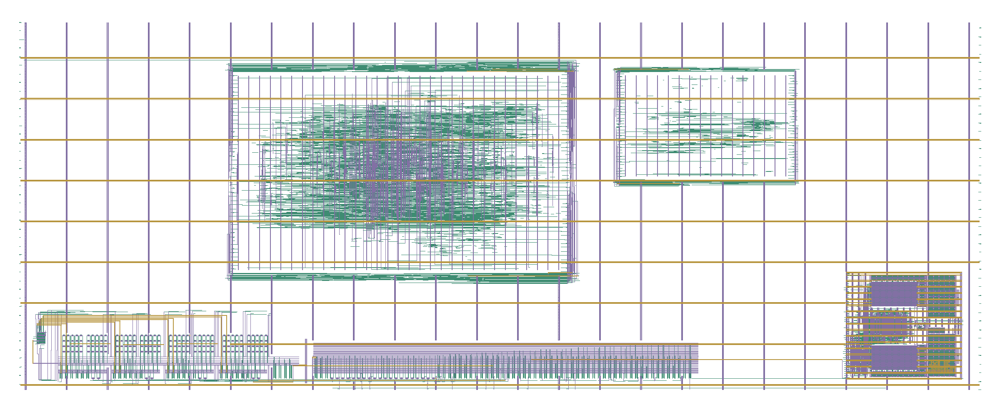

Detailed view: met1–met5, same GDS and placement.
render_top_routing_detail: klayout


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_mixed_signal_proto", "cells": 180, "width_um": 3600.0, "height_um": 1400.0, "render_style": "fixed SKY130 met1\u2013met5 detail", "shown_layers": [[68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


render_top_routing_detail: exit=0; 3.41 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_top_routing_detail/native.log


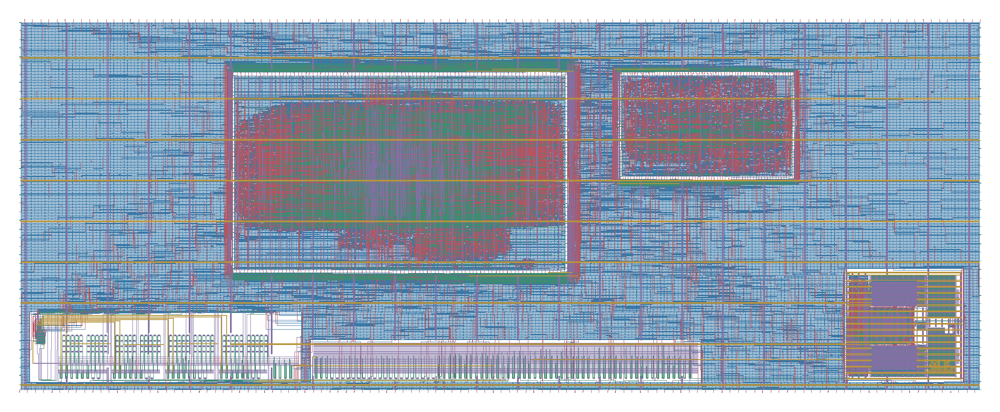

In [114]:
%%native_lab runall-render-top
%%inline_module top_render
import json,sys,shutil,tarfile
from pathlib import Path
from automx_nb_inline_v1.support import digest,item,save,verified
ARCHIVE_SHA='e7dadfb7bd5474fd22409c1e5a67acdec19f77e597df68e17c5549bc1390d7fd'
def render(self,gds,top,name,mode='overview'):
    from IPython.display import Image,display
    gds=Path(gds);work=self.work/('render_'+name);png=work/(name+'.png')
    script=Path(INLINE_ROOT)/'render_flow2_wrapper_gds.py'
    self.run('render_'+name,['klayout','-z','-x','-r',script],inputs=[gds,script],outputs=[png],
        env={'QT_QPA_PLATFORM':'offscreen','AUTOMX_GDS':str(gds),'AUTOMX_PNG':str(png),'AUTOMX_TOP':top,'AUTOMX_RENDER_MODE':mode})
    if png.read_bytes()[:8]!=b'\x89PNG\r\n\x1a\n':raise ValueError('invalid rendered PNG')
    display(Image(filename=str(png)));self.outputs[name+'_png']=item(png)
    return png

# NOTEBOOK_RUN
top_render.render(flow,top_gds,geometry_common.TOP,"top")

print("Detailed view: met1–met5, same GDS and placement.")
top_render.render(flow,top_gds,geometry_common.TOP,"top_routing_detail",mode="detail")


**Implementation:** Read fixed DEF instances and SIZE from five LEFs, verify
all five blocks without overlap, and generate a labelled SVG floorplan. This
diagram uses the actual database; the preceding KLayout image remains a GDS
render with unchanged layer/color settings.

**Inputs → outputs:** routed DEF + macro LEF → coordinate/dimension table,
`block_floorplan.json`, and `render_top/block_floorplan.svg`.


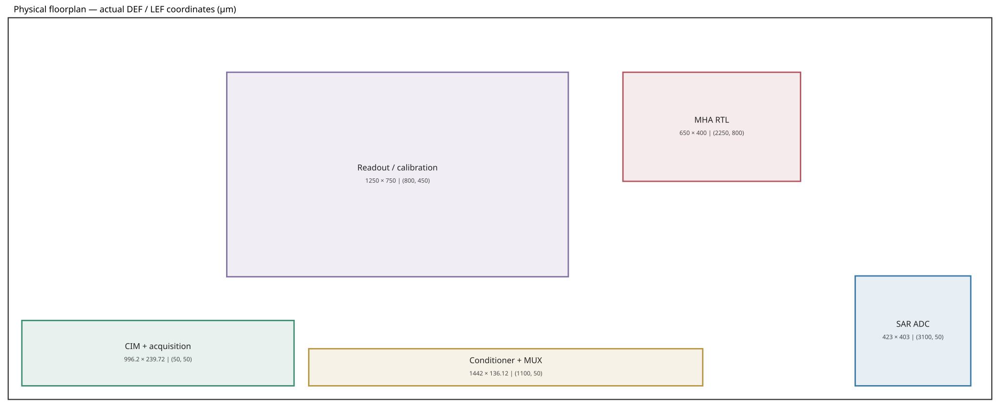

| Block | x,y / µm | Width × height / µm |
|---|---|---|
| SAR ADC | 3100, 50 | 423 × 403 |
| Conditioner + MUX | 1100, 50 | 1442 × 136.12 |
| CIM + acquisition | 50, 50 | 996.2 × 239.72 |
| MHA RTL | 2250, 800 | 650 × 400 |
| Readout / calibration | 800, 450 | 1250 × 750 |

FLOORPLAN_FIVE_FIXED_MACROS_PASS no overlaps


In [115]:
from pathlib import Path
import re,json
from IPython.display import SVG,Markdown,display
_w=portable.WORK
_def=(_w/'streamout/automx_cim_mixed_signal_proto.def').read_text()
_u=int(re.search(r'UNITS DISTANCE MICRONS (\d+)',_def)[1])
_section=_def.split('COMPONENTS ',1)[1].split('END COMPONENTS')[0]
_sizes={}
for _p in portable.PNR['config']['EXTRA_LEFS']:
    _s=Path(_p).read_text();_m=re.search(r'MACRO\s+(\S+)',_s)[1]
    _sizes[_m]=list(map(float,re.search(r'SIZE\s+([\d.]+)\s+BY\s+([\d.]+)',_s).groups()))
_names={'core_i':'CIM + acquisition','condition_i':'Conditioner + MUX','adc_i':'SAR ADC','seq_i':'Readout / calibration','mha_i':'MHA RTL'}
_colors={'core_i':'#3e8c72','condition_i':'#b7953e','adc_i':'#3979a8','seq_i':'#8270a4','mha_i':'#b45560'}
_rows=[]
for _name,_master,_x,_y,_orient in re.findall(r'-\s+(\S+)\s+(\S+).*?\+\s+(?:FIXED|PLACED)\s*\(\s*(\d+)\s+(\d+)\s*\)\s+(\S+)',_section,re.S):
    if _name in _names:
        _width,_height=_sizes[_master];_rows.append(dict(instance=_name,master=_master,x=float(_x)/_u,y=float(_y)/_u,width=_width,height=_height,orientation=_orient))
assert {r['instance'] for r in _rows}==set(_names)
for i,a in enumerate(_rows):
    for z in _rows[i+1:]:assert a['x']+a['width']<=z['x'] or z['x']+z['width']<=a['x'] or a['y']+a['height']<=z['y'] or z['y']+z['height']<=a['y']
_svg=['<svg xmlns="http://www.w3.org/2000/svg" viewBox="-30 -65 3660 1500" width="1200"><rect x="0" y="0" width="3600" height="1400" fill="white" stroke="#333" stroke-width="4"/><text x="20" y="-20" font-size="32" font-family="sans-serif">Physical floorplan — actual DEF / LEF coordinates (µm)</text>']
for r in _rows:
    x=r['x'];y=1400-r['y']-r['height'];w=r['width'];h=r['height'];cx=x+w/2;cy=y+h/2;col=_colors[r['instance']]
    _svg.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" fill="{col}" fill-opacity="0.12" stroke="{col}" stroke-width="5"/>')
    _svg.append(f'<text x="{cx}" y="{cy-15}" text-anchor="middle" font-family="sans-serif" font-size="30" fill="#222">{_names[r["instance"]]}</text>')
    _svg.append(f'<text x="{cx}" y="{cy+30}" text-anchor="middle" font-family="sans-serif" font-size="22" fill="#444">{w:g} × {h:g} | ({x:g}, {r["y"]:g})</text>')
_svg.append('</svg>');_svg=''.join(_svg)
_path=_w/'render_top/block_floorplan.svg';_path.write_text(_svg)
(_w/'block_floorplan.json').write_text(json.dumps({'status':'PASS','die_um':[3600,1400],'blocks':_rows,'source':'actual routed DEF and hard-macro LEFs'},indent=2)+'\n')
display(SVG(_svg))
display(Markdown('| Block | x,y / µm | Width × height / µm |\n|---|---|---|\n'+'\n'.join(f"| {_names[r['instance']]} | {r['x']:g}, {r['y']:g} | {r['width']:g} × {r['height']:g} |" for r in _rows)))
print('FLOORPLAN_FIVE_FIXED_MACROS_PASS no overlaps',flush=True)


## 9. Netgen: signal LVS

Compare physical SPICE extraction against the reference with Netgen. Before
reusing an extraction, require current GDS geometry/instances to match its
source. Verification result: unique signal match.

Extraction and netlist comparison: [[14]](#ref-14), [[15]](#ref-15).


In [116]:
%%native_lab runall-signal-lvs
%%inline_module signal_lvs
from automx_standalone import lvs
# NOTEBOOK_RUN
signal_lvs.lvs(flow)


lvs_export: docker


OpenROAD 41a51eaf4ca2171c92ff38afb91eb37bbd3f36da 


AUTOMX_FAST_MACRO_EXPORT_DONE 5976


lvs_export: exit=0; 2.21 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/signal_lvs/lvs_export.native.log


extract: docker


FRESH_MACRO_EXTRACTION_DONE


... (2 outputs left out)

Final result: 


Circuits match uniquely.


signal_lvs: exit=0; 0.43 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/signal_lvs/signal_lvs.native.log


Fresh extracted DEF/LEF signal macro-boundary LVS: MATCH UNIQUELY


## 10. Power, RC, and digital timing

Check VPWR/VGND connectivity on ODB. OpenRCX extracts RC and OpenSTA measures
timing at TT, 1.8 V, 25°C, and a 40 ns / 25 MHz clock. Reread digital LIB and
retain every tool's native output/log.

RC extraction and static timing: [[11]](#ref-11), [[12]](#ref-12).


In [117]:
%%native_lab runall-power
%%inline_module power
from automx_standalone import power
# NOTEBOOK_RUN
power_report=power.power(flow)


power: docker


OpenROAD 41a51eaf4ca2171c92ff38afb91eb37bbd3f36da 


power: exit=0; 5.97 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/power/power.native.log


In [118]:
%%native_lab runall-timing
%%inline_module timing
from automx_standalone import timing,parse_library
# NOTEBOOK_RUN
timing_report=timing.timing(flow)
timing.parse_library(flow)


parent_rcx: docker


OpenROAD 41a51eaf4ca2171c92ff38afb91eb37bbd3f36da 


parent_rcx: exit=0; 3.18 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/timing/parent_rcx.native.log


hierarchical_timing: docker


worst slack 1.65


worst slack 0.19


... (16 outputs left out)

hierarchical_etm: exit=0; 12.23 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/timing/hierarchical_etm.native.log


HIERARCHICAL_EXTRACTED_TIMING {'setup_slack_ns': 1.65, 'hold_slack_ns': 0.19}


lib_parse: docker


lib_parse: exit=0; 0.46 s; log=/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/timing/lib_parse.native.log


In [119]:
portable.export_physical(get_ipython().user_ns,_design_review_namespace)

# CELL_RESULT standalone-sync-physical
print('GDS:',flow.outputs['gds']['path'],flush=True); print('Digital TT:',flow.outputs['nominal_timing'],flush=True)


GDS: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/streamout/automx_cim_mixed_signal_proto.gds


Digital TT: {'setup_slack_ns': 1.65, 'hold_slack_ns': 0.19, 'frequency_mhz': 25, 'scope': 'Hierarchical gate-level TT STA: parent and both digital hard-macro SPEFs; physical-interface Liberty arcs are not used for signoff.'}


## 7. Connect the experiment to the physical top

The native lab exports a routed mixed-signal top, checks cell geometry against the routed design, checks signal/rail connectivity, extracts routing RC and evaluates constrained digital TT timing at 25 MHz. The table below reads those reports and parses the actual STA summary. GDS renderings show the core/acquisition, conditioner and ADC region as well as the full top.

These reports describe the scope of their individual checks. The enabled-rule DRC attempt has an incomplete status; positive timing or geometry checks do not convert it into a clean DRC result.

<a id="guide-physical-reports"></a>

### Before cell `physical-reports` — F9

**Implementation:** Extract setup/hold slack from exact STA marker regions and aggregate LVS/PG/geometry/DRC. Correct measurements and scope distinguish relevant top-level evidence from similar numbers elsewhere in logs.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-physical-reports-slack"></a>`slack(kind)` | Extract exactly one worst-slack value between AUTOMX_SETUP or AUTOMX_HOLD markers, convert to float nanoseconds, and reject missing/ambiguous values. |

<a id="data-physical-reports"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive E[physical] referencing the new top's geometry.json, power.json, drc_summary.json, timing log, and netgen.log. slack accepts SETUP or HOLD marker labels.
- **Return values and saved artifacts:** Return setup/hold nanoseconds from the designated log segment; print final Netgen verdict, rail statuses, cell/instance/master counts, and DRC status; display macro/top PNGs from the same review_data.
- **Downstream consumers:** klayout-native independently reads/renders compressed GDS; argument-verdict/results retain this physical scope and measured slack in their conclusions.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-237"></a>`MHz` | Megahertz = 10^6 cycles/s; the 25 MHz target corresponds to a 40 ns prototype STA clock period. |


| Artifact / check | Current-run result |
| --- | --- |
| GDS geometry equivalence | EXACT_COLD_GDS_CELL_GEOMETRY_AND_INSTANCES_MATCH |
| Cells / geometry instances / masters | 180 / 103155 / 36 |
| Supply connectivity | VPWR: PASS, VGND: PASS |
| Digital TT 25 MHz setup / hold slack | +1.65 ns / +0.19 ns |
| Enabled-rule DRC attempt | INCOMPLETE_TIMEOUT |

Current-run OpenROAD STA header and summary:
OpenSTA 2.4.0 41a51eaf4c Copyright (c) 2021, Parallax Software, Inc.
License GPLv3: GNU GPL version 3 <http://gnu.org/licenses/gpl.html>

This is free software, and you are free to change and redistribute it
under certain conditions; type `show_copying' for details. 
This program comes with ABSOLUTELY NO WARRANTY; for details type `show_warranty'.
  BIAS_MON
  VGND
  VPWR
  seq_i/_31786_/D
Found 34 unannotated drivers.
Found 0 partially unannotated drivers.
AUTOMX_SETUP_BEGIN
worst slack 1.65
Current-run Netgen signal check — final verdict; complete transcript supplied in data/physical/:
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are equivalent.
Cell pin lists are 

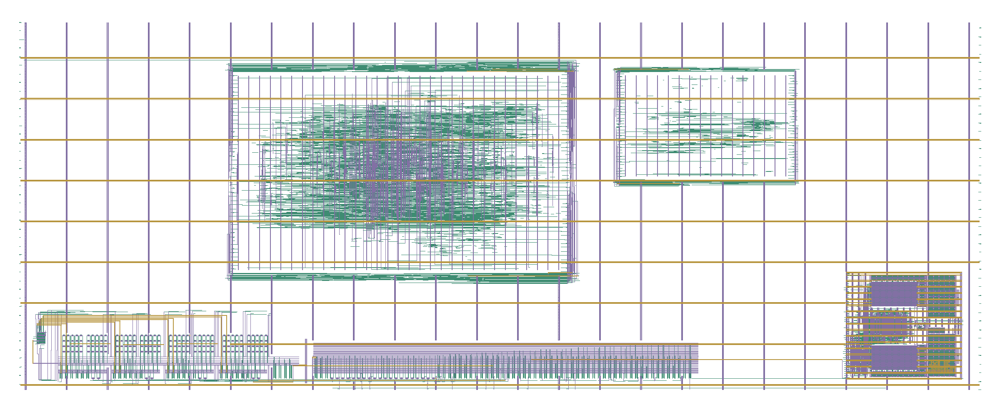

**Current-run KLayout render: core acquisition**

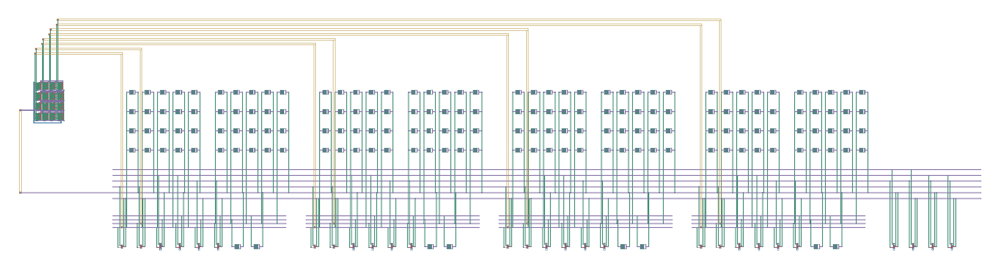

**Current-run KLayout render: conditioner mux**

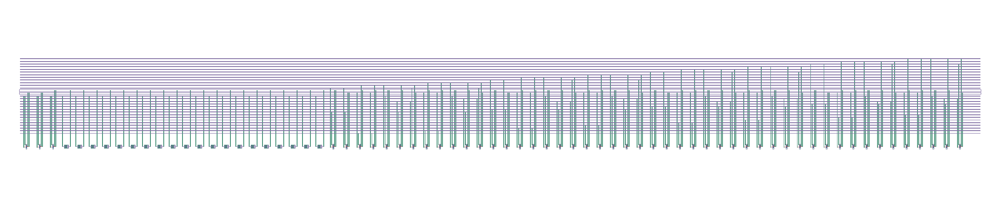

**Current-run KLayout render: adc reference**

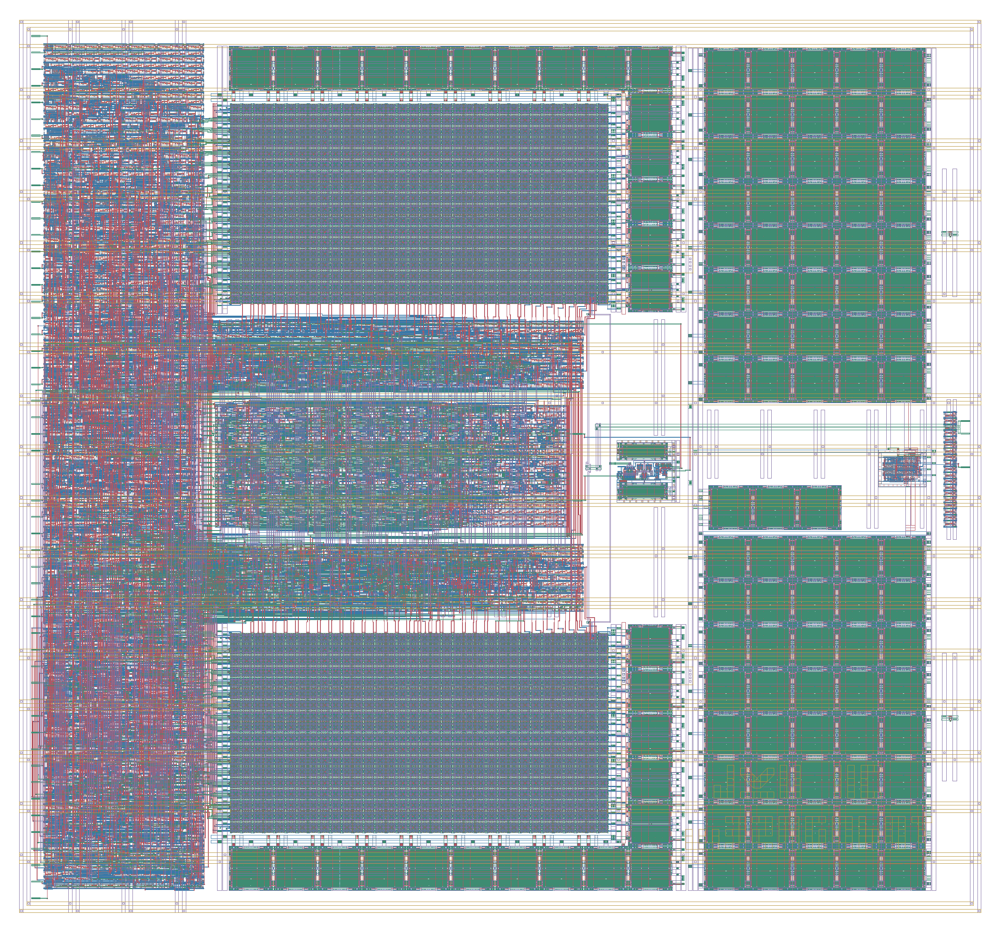

In [120]:
%%design_review physical-reports
physical=E['physical']; geometry=record(physical['geometry']); power=record(physical['power']); drc=record(physical['drc'])
timing=(BASE/physical['timing_log']).read_text()
def slack(kind):
    matches=re.findall(r'AUTOMX_'+kind+r'_BEGIN\s+worst slack\s+([-+\d.]+)\s+AUTOMX_'+kind+r'_END',timing)
    if len(matches)!=1: raise ValueError('missing/ambiguous STA slack')
    return float(matches[0])
setup,hold=slack('SETUP'),slack('HOLD')
table(['Artifact / check','Current-run result'],[
    ['GDS geometry equivalence',geometry['status']],
    ['Cells / geometry instances / masters',f"{geometry['cells']} / {geometry['instances']} / {geometry['masters']}"],
    ['Supply connectivity',', '.join(f'{k}: {v}' for k,v in power['rails'].items())],
    ['Digital TT 25 MHz setup / hold slack',f'{setup:+.2f} ns / {hold:+.2f} ns'],
    ['Enabled-rule DRC attempt',drc['status']]])
print('Current-run OpenROAD STA header and summary:')
print('\n'.join(timing.splitlines()[:16]))
print('Current-run Netgen signal check — final verdict; complete transcript supplied in data/physical/:')
lvs=(BASE/physical['lvs_log']).read_text()
if 'Final result: Circuits match uniquely.' not in lvs: raise ValueError('Netgen unique match missing')
for line in lvs.splitlines():
    if line.startswith(('Final result:','Cell pin lists are equivalent.','Device classes automx_')): print(line)
print('DRC status is incomplete; no zero-violation claim is inferred from this report.')
display(Image(filename=str(BASE/'figures/top.png'),width=1000))
for name in ('core_acquisition','conditioner_mux','adc_reference'):
    display(Markdown('**Current-run KLayout render: '+name.replace('_',' ')+'**'))
    display(Image(filename=str(BASE/'figures'/f'{name}.png'),width=850))


### Fresh KLayout inspection and rendering

The package contains the actual compressed top GDS. When KLayout is available, the following cell decompresses it into the new output folder, opens the named top, checks its cell count and renders a new PNG. The entire KLayout script is visible below.

In [121]:
%%design_review klayout-script
KLAYOUT_SCRIPT = '"""Deterministic SKY130 routing overview; raw GDS geometry is unchanged."""\nimport os,json\nfrom pathlib import Path\nimport pya\n\ngds=Path(os.environ[\'AUTOMX_GDS\']);png=Path(os.environ[\'AUTOMX_PNG\'])\napp=pya.Application.instance();window=app.main_window()\nif window is None:raise RuntimeError(\'KLayout -z with offscreen Qt required\')\nwindow.load_layout(str(gds),1);view=window.current_view();cv=view.active_cellview()\ncell=cv.layout().cell(os.environ.get(\'AUTOMX_TOP\',\'automx_cim_mixed_signal_proto\'))\nif cell is None:raise RuntimeError(\'requested top missing\')\ncv.cell=cell;view.add_missing_layers();view.max_hier()\nview.set_config(\'background-color\',\'#ffffff\')\nview.set_config(\'grid-visible\',\'false\');view.set_config(\'text-visible\',\'false\')\nview.set_config(\'cell-boxes-visible\',\'false\')\npalette={65:0xb59b7b,66:0xc44e52,67:0x718096,68:0x3979a8,69:0xb45560,\n         70:0x3e8c72,71:0x8270a4,72:0xb7953e}\nis_top=cell.name==\'automx_cim_mixed_signal_proto\'\nmode=os.environ.get(\'AUTOMX_RENDER_MODE\',\'overview\')\niterator=view.begin_layers();shown=[]\nwhile not iterator.at_end():\n    layer=iterator.current();number=layer.source_layer;datatype=layer.source_datatype\n    layer.visible=number in palette and datatype in (20,44) and (not is_top or number >= (70 if mode==\'overview\' else 68))\n    if layer.visible:\n        layer.fill_color=palette[number];layer.frame_color=palette[number]\n        layer.dither_pattern=1 if datatype==20 else 0\n        layer.line_style=0;layer.width=1\n        shown.append([number,datatype])\n    view.set_layer_properties(iterator,layer);iterator.next()\nbox=cell.dbbox()\nif box.empty():raise RuntimeError(\'empty GDS geometry\')\nmargin=.02*max(box.width(),box.height())\nview.zoom_box(pya.DBox(box.left-margin,box.bottom-margin,box.right+margin,box.top+margin))\npng.parent.mkdir(parents=True,exist_ok=True)\nwidth=int(os.environ.get(\'AUTOMX_WIDTH\',\'2400\'))\nheight=max(500,min(2400,round(width*(box.height()+2*margin)/(box.width()+2*margin))))\nview.save_image(str(png),width,height)\nif not png.is_file() or png.read_bytes()[:8]!=b\'\\x89PNG\\r\\n\\x1a\\n\':raise RuntimeError(\'PNG export failed\')\ngeometry={\'top\':cell.name,\'cells\':cv.layout().cells(),\'width_um\':box.width(),\'height_um\':box.height(),\n          \'render_style\':(\'fixed SKY130 met3–met5 overview\' if mode==\'overview\' else \'fixed SKY130 met1–met5 detail\') if is_top else \'fixed SKY130 device/metal view\',\n          \'shown_layers\':sorted(shown),\'labels_visible\':False,\'geometry_modified\':False}\npng.with_suffix(\'.render.json\').write_text(json.dumps(geometry,indent=2))\nif os.environ.get(\'AUTOMX_GEOMETRY\'):Path(os.environ[\'AUTOMX_GEOMETRY\']).write_text(json.dumps(geometry,indent=2))\nprint(\'KLayout\',app.version(),\'GDS_READ_AND_RENDER\',json.dumps(geometry),flush=True)\napp.exit(0)\n'

# CELL_RESULT klayout-script
print('KLayout: met3–met5 overview; met1–met5 detail; fixed palette',flush=True)


KLayout: met3–met5 overview; met1–met5 detail; fixed palette


RUN: klayout -z -r /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/render.py


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_mixed_signal_proto", "cells": 180, "width_um": 3600.0, "height_um": 1400.0, "render_style": "fixed SKY130 met3\u2013met5 overview", "shown_layers": [[70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


EXIT: 0 | elapsed_s: 2.766


Fresh KLayout read and render completed from the supplied GDS.


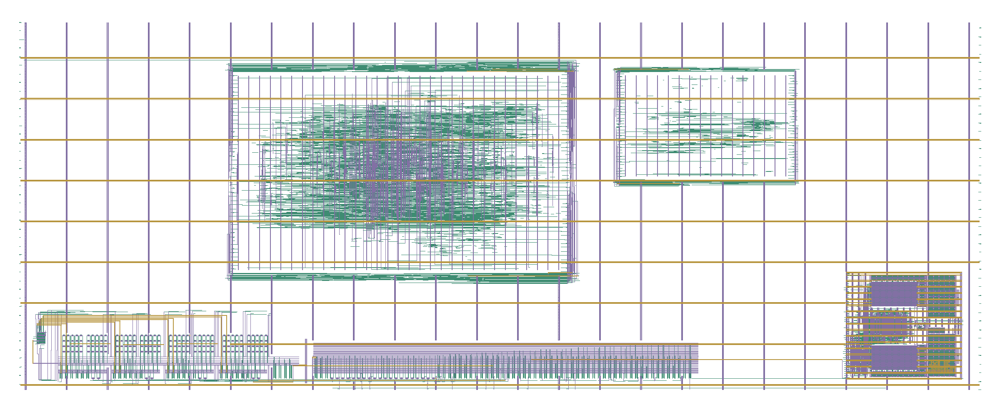

In [122]:
%%design_review klayout-native
fresh_native_klayout=False
available=shutil.which('klayout')
if NATIVE=='on' and not available: raise FileNotFoundError('Install KLayout to inspect the supplied GDS')
if NATIVE!='off' and available:
    gds=OUT/'top.gds'
    with gzip.open(BASE/'layout/top.gds.gz','rb') as source,gds.open('wb') as target:
        shutil.copyfileobj(source,target)
    script=OUT/'render.py';script.write_text(KLAYOUT_SCRIPT)
    env=os.environ.copy();env.update(QT_QPA_PLATFORM='offscreen',AUTOMX_GDS=str(gds),
        AUTOMX_PNG=str(OUT/'top_live.png'),AUTOMX_GEOMETRY=str(OUT/'gds_live.json'))
    log=run_tool(['klayout','-z','-r',script],env=env,timeout=120)
    (OUT/'klayout.log').write_text(log)
    native_geometry=json.loads((OUT/'gds_live.json').read_text())
    if native_geometry['cells']!=geometry['cells']: raise AssertionError('GDS cell count mismatch')
    fresh_native_klayout=True
    print('Fresh KLayout read and render completed from the supplied GDS.')
    display(Image(filename=str(OUT/'top_live.png'),width=1000))
else:
    print('KLayout not executed; recorded native renders are displayed above.')


<a id="argument-conclusion"></a>

# 8. Close the argument using the measured decisions

The design progressed through three independent checks: diagnose a failing
physical ordering and isolate the load/PWM effects; validate a frozen
conversion mapping on disjoint patterns; reconstruct an application from
those measured transactions. The physical top contributes its own exported
geometry, connectivity and constrained digital timing evidence.

The next table is computed from the records rather than copied from the
explanatory paragraphs. It verifies the calibration against the predeclared
study protocol and connects every observation to the decision it supports.


| Design step | Measured observation | Decision supported |
| --- | --- | --- |
| Transfer diagnosis | -474.2482 mV gap | Check the physical ordering before assigning scalar thresholds |
| Controlled intervention | +29.2471 mV with PWM-only change; interaction -514.7098 mV | Evaluate pulse duration separately from capacitance; retain both single-factor alternatives |
| Independent decoding | 38 holdouts; 0 integer mismatches; max residual 0.142672 | Freeze the three-point ADC fit and carry raw residuals into validation |
| Application reconstruction | 32 transactions; L2 quantized 0.000000; floating 0.114477 | Separate measured decoding agreement from context quantization error |
| Physical handoff | 180 GDS cells; setup +1.65 ns; hold +0.19 ns | Attach geometry, connectivity and digital timing evidence to the exported top |

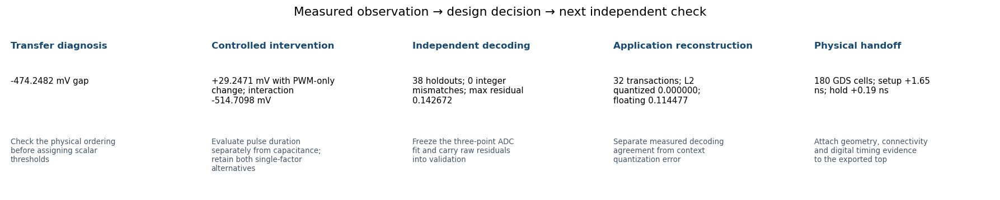

Design argument verified against the predeclared protocol and measured records.


In [123]:
%%design_review argument-verdict
# Recompute the links between observations and decisions from measured evidence.
protocol=record('data/provenance.json')['protocol']
declared_fit=protocol['calibration']
if not protocol['calibration_frozen'] or protocol['prior_pattern_overlap']!=0:
    raise AssertionError('Study must declare frozen calibration and independent challenge')
if not np.allclose(FROZEN,[declared_fit['slope_codes_per_integer_sum'],declared_fit['offset_code']],
                   rtol=0,atol=1e-10):
    raise AssertionError('Recomputed calibration differs from the predeclared frozen fit')
if len(CAL_IDS)!=3 or len(HOLD_IDS)!=38 or len(jobs)!=32:
    raise AssertionError('Unexpected calibration, holdout or application population')
assert gaps[200,100]<0 and gaps[200,50]>0 and gaps[800,100]>0
assert all(r['decoded']==r['truth'] for r in observations)
assert MHA_QUANT==0 and np.isclose(MHA_FLOAT,relative_l2(ref_float,output))

decisions=[
 {'stage':'Transfer diagnosis','observation':f'{gaps[200,100]*1000:+.4f} mV gap',
  'decision':'Check the physical ordering before assigning scalar thresholds',
  'evidence':'Eight matched-pattern PEX logs; primary response at column 0 / 1.9 ns'},
 {'stage':'Controlled intervention','observation':f'{gaps[200,50]*1000:+.4f} mV with PWM-only change; interaction {interaction*1000:+.4f} mV',
  'decision':'Evaluate pulse duration separately from capacitance; retain both single-factor alternatives',
  'evidence':'Same pair, same extracted core, same TT condition; complete 2×2 factorial'},
 {'stage':'Independent decoding','observation':f'{len(HOLD_IDS)} holdouts; 0 integer mismatches; max residual {max(abs(r["residual"]) for r in observations):.6f}',
  'decision':'Freeze the three-point ADC fit and carry raw residuals into validation',
  'evidence':'41 coupled transistor/RTL conversion records, disjoint physical payloads'},
 {'stage':'Application reconstruction','observation':f'{len(jobs)} transactions; L2 quantized {MHA_QUANT:.6f}; floating {MHA_FLOAT:.6f}',
  'decision':'Separate measured decoding agreement from context quantization error',
  'evidence':'Q/K/V/O request mapping, independent CPU attention and two references'},
 {'stage':'Physical handoff','observation':f'{geometry["cells"]} GDS cells; setup {setup:+.2f} ns; hold {hold:+.2f} ns',
  'decision':'Attach geometry, connectivity and digital timing evidence to the exported top',
  'evidence':'Declared routed-design input; GDS, Netgen/rail reports and extracted digital TT STA'}]
table(['Design step','Measured observation','Decision supported'],
      [[r['stage'],r['observation'],r['decision']] for r in decisions])
argument={'status':'SUPPORTED_BY_MEASURED_EVIDENCE','calibration_matches_predeclared_fit':True,
          'decisions':decisions,'context_shape':{'tokens':2,'dimensions':4,'heads':2},
          'physical_column_reused':0,'digital_runtime':'CPU attention/softmax',
          'pex_and_coupled_conversion_are_separate_experiments':True,
          'historical_two_plus_two_is_separate_from_final_partition':True,
          'drc_report_status':drc['status']}
(OUT/'design_argument.json').write_text(json.dumps(argument,indent=2)+'\n')

fig,axes=plt.subplots(1,5,figsize=(15,3))
for ax,row in zip(axes,decisions):
    ax.set_axis_off()
    ax.text(.02,.95,row['stage'],ha='left',va='top',weight='bold',fontsize=10,color='#174a72')
    # Wrap labels explicitly for portable, readable exported figures.
    import textwrap
    ax.text(.02,.73,'\n'.join(textwrap.wrap(row['observation'],27)),ha='left',va='top',fontsize=9)
    ax.text(.02,.35,'\n'.join(textwrap.wrap(row['decision'],29)),ha='left',va='top',fontsize=8,color='#475569')
fig.suptitle('Measured observation → design decision → next independent check',fontsize=13)
savefig('design_argument.png')
print('Design argument verified against the predeclared protocol and measured records.')


## 8. Results generated by this run

The following summary is computed from the evidence and the checks above. All plots and fresh tool logs are saved beside `review_results.json` in this run's new output directory.

In [124]:
%%design_review results
summary={'measurement_mode':'fresh native analog, cold PnR and Python analysis',
    'unique_calibration':len(CAL_IDS),'unique_holdout':len(HOLD_IDS),
    'integer_decode_mismatches':sum(r['decoded']!=r['truth'] for r in observations),
    'max_abs_holdout_sum_residual':max(abs(r['residual']) for r in observations),
    'factorial_gap_mv':{f'{c}fF_{p}ps':v*1000 for (c,p),v in gaps.items()},
    'mha_transactions':len(jobs),'mha_relative_l2_quantized':MHA_QUANT,
    'mha_relative_l2_float':MHA_FLOAT,'negative_controls_rejected':len(rejected),
    'fresh_native_rtl_cases':len(rtl_results),'fresh_klayout_render':fresh_native_klayout,
    'setup_slack_ns':setup,'hold_slack_ns':hold,
    'drc_status':drc['status']}
(OUT/'review_results.json').write_text(json.dumps(summary,indent=2)+'\n')
print(json.dumps(summary,indent=2))
print('New figures, fresh digital logs and recomputed results saved in',OUT.name)


{
  "measurement_mode": "fresh native analog, cold PnR and Python analysis",
  "unique_calibration": 3,
  "unique_holdout": 38,
  "integer_decode_mismatches": 0,
  "max_abs_holdout_sum_residual": 0.14267185473408972,
  "factorial_gap_mv": {
    "200fF_50ps": 29.24710000000008,
    "200fF_100ps": -474.2482,
    "800fF_50ps": 19.55759999999998,
    "800fF_100ps": 30.772100000000023
  },
  "mha_transactions": 32,
  "mha_relative_l2_quantized": 0.0,
  "mha_relative_l2_float": 0.114477076077953,
  "negative_controls_rejected": 4,
  "fresh_native_rtl_cases": 41,
  "fresh_klayout_render": true,
  "setup_slack_ns": 1.65,
  "hold_slack_ns": 0.19,
  "drc_status": "INCOMPLETE_TIMEOUT"
}
New figures, fresh digital logs and recomputed results saved in fresh_20261029_123523_717579


## Reusable design lessons

1. **Test the physical transfer before trusting the arithmetic abstraction.** Two different patterns can reverse voltage ordering despite increasing integer sums.
2. **Change one factor at a time, then measure interaction.** The complete load/PWM experiment supports a specific operating-point decision.
3. **Lock calibration and retain residuals.** Integer agreement is strongest when accompanied by independent stimuli, native traces and visible unrounded error.
4. **Carry the measurement to application output.** Distinguish exact agreement with the quantized reference from the remaining floating-context error.

The reusable artifacts are the stimulus/record schema, code/trace checker, matched-factor experiment, and measured-projection MHA reconstruction. Reused SAR circuitry is credited below; the integration does not claim a new SAR topology or measured silicon performance.

## Reproducibility and execution ledger

The following cells retain the executable orchestration, tool receipts, and final artifact ledger. Their code order is preserved so Run All processes every native code cell exactly once.


### Previous server session

Retain this session's recipe and receipts for traceability. Parts A/B and the
final dependency table present the active result chain.


### Reproduce the server session


### Server-session configuration


In [125]:
%%native_lab restored-server-flow-config
from automx_nb_inline_v1.presentation import pretty
if RUN_LEGACY_CAMPAIGNS:
    from pathlib import Path
    from hashlib import sha256
    from datetime import datetime, timezone
    from types import MappingProxyType
    import inspect
    import json
    import os
    import re
    import shutil
    import signal
    import subprocess
    import sys
    from IPython.display import Image, Markdown, display

    # All editable settings live here. Environment overrides are read only here.
    SETTINGS = MappingProxyType({
        "root": os.environ.get("AUTOMX_CIM_ROOT", str(Path.cwd())),
        "mode": os.environ.get("AUTOMX_RUN_MODE", "replay"),
        "tag": os.environ.get("AUTOMX_WRAPPER_TAG", "mixed_wrapper_srv_20261022_04"),
        "postroute_tag": os.environ.get("AUTOMX_POSTROUTE_TAG", "mixed_wrapper_srv_20261022_04_impl_gds_postroute"),
        "loaded_conditioner_tag": "wrapper_loaded_srv_20261022_05",
        "core_repair_tag": "core_full_drc_srv_20261022_02",
        "ground_eco_tag": "ground_repair_srv_20261022_02",
        "antenna_prototype_tag": "antenna_streamout_srv_20261022_03",
        "chip_signoff_tag": "chip_signoff_srv_20261023_01",
        "core_pex_tag": "core_tap_pex_srv_20261022_01",
        "core_transient_tag": "core_tap_transient_srv_20261022_02",
        "coupled_frontend_tags": ("coupled_frontend_srv_20261022_01", "coupled_frontend_srv_20261022_02", "coupled_frontend_srv_20261022_03"),
        "reuse_tag": "mixed_wrapper_srv_20261021_05_impl",
        "route_source_tag": os.environ.get("AUTOMX_ROUTE_SOURCE_TAG", "mixed_wrapper_srv_20261022_03_impl"),
        "route_allow_global_congestion": os.environ.get("AUTOMX_ALLOW_GLOBAL_CONGESTION", "1") == "1",
        "route_checkpoint_stage": os.environ.get("AUTOMX_ROUTE_CHECKPOINT_STAGE", "post_diode"),
        "route_detailed_iters": int(os.environ.get("AUTOMX_ROUTE_DETAILED_ITERS", "64")),
        "route_cores": int(os.environ.get("AUTOMX_ROUTE_CORES", "8")),
        "stage5_pdk": os.environ.get("AUTOMX_STAGE5_PDK_ROOT",
            "/home/nam/.volare/volare/sky130/versions/bdc9412b3e468c102d01b7cf6337be06ec6e9c9a/sky130A"),
        "openlane_pdk": os.environ.get("AUTOMX_OPENLANE_PDK_ROOT",
            "/home/nam/.volare_openlane_30ee138_nam"),
        "openlane_source": os.environ.get("AUTOMX_OPENLANE_SOURCE",
            "/home/nam/dependencies/openlane_src"),
        "image": "efabless/openlane:30ee1388932eb55a89ad84ee43997bfe3a386421-amd64",
        "pdk": "sky130A",
        "stage5_revision": "bdc9412b3e468c102d01b7cf6337be06ec6e9c9a",
        "native_open_pdks_revision": "78b7bc32ddb4b6f14f76883c2e2dc5b5de9d1cbc",
        "mha_config": "configs/sky130_mha_tiny.json",
        "tool_timeout_s": 1800,
        "min_free_gib": 4,
    })
    ROOT = Path(SETTINGS["root"]).expanduser().resolve()
    if not (ROOT / "scripts/run_flow2_wrapper_physical_recovery.py").is_file():
        raise FileNotFoundError("Launch from AutoMX-CIM or set AUTOMX_CIM_ROOT, then rerun configuration.")
    if SETTINGS["mode"] not in {"replay", "incremental", "full", "route"}:
        raise ValueError("mode must be replay, incremental, full or route")
    if not re.fullmatch(r"[A-Za-z][A-Za-z0-9_]{0,42}", SETTINGS["tag"]):
        raise ValueError("parent tag must contain at most 43 alphanumeric/underscore characters")
    if not re.fullmatch(r"[A-Za-z][A-Za-z0-9_]{0,63}", SETTINGS["route_source_tag"]):
        raise ValueError("invalid route source tag")
    if SETTINGS["route_checkpoint_stage"] not in {"post_diode", "post_cts"}:
        raise ValueError("route checkpoint stage must be post_diode or post_cts")
    if not (1 <= SETTINGS["route_detailed_iters"] <= 64 and 1 <= SETTINGS["route_cores"] <= 16):
        raise ValueError("route detailed iterations must be 1..64 and cores 1..16")
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    BASE = ROOT / "results/sky130/flow2_wrapper_integration"
    TOP = "automx_cim_mixed_signal_proto"
    SESSION_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    SESSION_DIR = ROOT / "results/sky130/notebook_sessions" / (SETTINGS["tag"] + "_" + SESSION_ID)
    CONFIG_HASH = sha256(json.dumps(dict(SETTINGS), sort_keys=True).encode()).hexdigest()
    # Reset execution state when configuration is rerun; no old GDS/PNG survives.
    ACTIVE = {"tag": SETTINGS["tag"], "wrapper_tag": None, "gds_tag": None,
              "returncode": None, "report": None, "gds": None, "render_ready": False}
    PROVENANCE = {"format": "automx-cim-notebook-session-v1", "session": SESSION_ID,
        "settings": dict(SETTINGS), "config_sha256": CONFIG_HASH, "root": str(ROOT),
        "python": {"executable": sys.executable, "version": sys.version},
        "requested_tag": SETTINGS["tag"], "mode": SETTINGS["mode"], "observed_files": {},
        "qualification": "NOT_QUALIFIED", "run_all_tested": False}
    print(pretty({**dict(SETTINGS), "resolved_root": str(ROOT), "session": SESSION_ID}, indent=2))
else:
    pass

# CELL_RESULT server-config
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(ROOT/'configs/sky130_mha_tiny.json')],label='config')


| sky130_mha_tiny | Result |
|---|---|
| ternary_threshold_ratio | 0.7 |
| sequence_length | 4 |
| d_model | 32 |
| n_heads | 2 |
| physical_rows | 4 |
| logical_rows | 32 |
| physical_cols | 4 |
| logical_cols | 8 |
| vdd | 1.8 |
| temperature_c | 25 |
| mx_block_size | 32 |
| d_head | 16 |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/configs/sky130_mha_tiny.json`

### Source cross-check


<a id="guide-native-restored-server-flow-provenance"></a>

### Before cell `native-restored-server-flow-provenance` — F0 → F9 / reference recipe

**Implementation:** Define session management, numerical receipts, and CLI-result reading for the retained server recipe, preserving reproducibility and input checks that explain earlier design decisions.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-server-flow-provenance-guard_settings"></a>`guard_settings()` | Compare session settings against their locked copy and flag unintended changes before server recipes use those tags/inputs. |
| <a id="fn-native-restored-server-flow-provenance-project_path"></a>`project_path(value)` | Resolve a configured path beneath the project root and validate scope before reading/writing session artifacts. |
| `file_item(path)` | Same task as [`item`](#fn-native-inline-support-item). |
| `read_json(path)` | Same task as [`record`](#fn-setup-record). |
| `verified_item(item)` | Same task as [`_verified`](#fn-native-inline-geometry_common-_verified). |
| <a id="fn-native-restored-server-flow-provenance-link"></a>`link(path)` | Display a notebook link to a result file/path so readers can open the source of reported values. |
| <a id="fn-native-restored-server-flow-provenance-save_session"></a>`save_session()` | Write accumulated server-session status, artifacts, and provenance to JSON as a clear continuation point. |
| <a id="fn-native-restored-server-flow-provenance-snapshot_sources"></a>`snapshot_sources(value)` | Traverse session inputs and snapshot relevant sources so results can be traced to the exact executed content. |

<a id="data-native-restored-server-flow-provenance"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive server-recipe SETTINGS/tag, root, and source/receipt paths; definitions beneath RUN_LEGACY_CAMPAIGNS can be retained without launching earlier campaigns.
- **Return values and saved artifacts:** Provenance helpers return file references/session snapshots; numerical_receipts returns reference/schedule sources; final_cli_report parses completed JSON if the CLI recipe runs.
- **Downstream consumers:** The same recipe's server-flow review/render/postroute cells use these objects; active execution continues to publish fresh flow.outputs through runall-manifest.

**Terms introduced here:**

| Term | Meaning and role here |
|---|---|
| <a id="term-238"></a>`CLI` | Command-Line Interface: invoke executables using argv and collect return code/stdout/stderr. |


In [126]:
%%native_lab restored-server-flow-provenance
from automx_nb_inline_v1.presentation import pretty
if RUN_LEGACY_CAMPAIGNS:
    def guard_settings():
        if sha256(json.dumps(dict(SETTINGS), sort_keys=True).encode()).hexdigest() != CONFIG_HASH:
            raise RuntimeError("Configuration changed; restart at the configuration cell.")

    def project_path(value):
        candidate = (ROOT / value).resolve()
        if not candidate.is_relative_to(ROOT):
            raise ValueError("Evidence path escapes this checkout: " + str(value))
        return candidate

    def file_item(path):
        path = project_path(path)
        item = {"path": path.relative_to(ROOT).as_posix(), "sha256": sha256(path.read_bytes()).hexdigest()}
        PROVENANCE["observed_files"][item["path"]] = item["sha256"]
        return item

    def read_json(path):
        path = project_path(path)
        content = path.read_bytes()
        PROVENANCE["observed_files"][path.relative_to(ROOT).as_posix()] = sha256(content).hexdigest()
        return json.loads(content)

    def verified_item(item):
        path = project_path(item["path"])
        if not item.get("sha256") or file_item(path)["sha256"] != item["sha256"]:
            raise ValueError("Artifact hash mismatch: " + str(path))
        return path

    def link(path):
        path = project_path(path)
        display(Markdown("[" + path.relative_to(ROOT).as_posix() + "](" +
                         path.relative_to(ROOT).as_posix() + ")"))

    def save_session():
        guard_settings()
        if SETTINGS["mode"] != "replay":
            SESSION_DIR.mkdir(parents=True, exist_ok=True)
            # Unique session directory; runner summaries and native artifacts are untouched.
            (SESSION_DIR / "provenance.json").write_text(json.dumps(PROVENANCE, indent=2) + "\n")

    def snapshot_sources(value):
        if isinstance(value, dict):
            if isinstance(value.get("path"), str) and isinstance(value.get("sha256"), str):
                path = project_path(value["path"])
                actual = file_item(path)["sha256"] if path.is_file() else None
                return [{"path": value["path"], "expected": value["sha256"], "observed": actual,
                         "status": "HASH_MATCH" if actual == value["sha256"] else "MISSING_OR_CHANGED"}]
            return [entry for child in value.values() for entry in snapshot_sources(child)]
        if isinstance(value, list):
            return [entry for child in value for entry in snapshot_sources(child)]
        return []

    guard_settings()
    PROVENANCE["pdks"] = {name: {"configured": SETTINGS[name],
        "resolved": str(Path(SETTINGS[name]).expanduser().resolve()),
        "exists": Path(SETTINGS[name]).expanduser().is_dir()}
        for name in ("stage5_pdk", "openlane_pdk")}
    native_sources = Path(SETTINGS["openlane_pdk"]) / SETTINGS["pdk"] / "SOURCES"
    if native_sources.is_file():
        content = native_sources.read_bytes()
        PROVENANCE["pdks"]["native_PDK_SOURCES"] = {
            "path": str(native_sources.resolve()), "sha256": sha256(content).hexdigest(),
            "content": content.decode(errors="replace")}
    for relative in ("scripts/run_flow2_wrapper_physical_recovery.py",
                     "scripts/run_flow2_mixed_wrapper.py", "scripts/run_flow2_mixed_wrapper_gds.py",
                     "scripts/flow2_split_fanout_odb.py", "scripts/flow2_wrapper_design.py"):
        file_item(ROOT / relative)
    print(pretty(PROVENANCE["pdks"], indent=2))
    print("PDK revision consistency: NOT_QUALIFIED (two different revisions)")
else:
    pass

# CELL_RESULT server-provenance
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'area_comparison.json')],label='provenance')


| area_comparison | Result |
|---|---|
| blocks[0].area_um2 | 238809.1 |
| blocks[1].area_um2 | 196285 |
| blocks[2].area_um2 | 170469 |
| blocks[3].area_um2 | 260000 |
| placed.die_um2 | 5040000 |
| placed.macro_um2 | 1803063 |
| placed.placed_logic_um2 | 48031.07 |
| placed.physical_cells_um2 | 63365.77 |
| placed.logic_instances | 5971 |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/area_comparison.json`

### Reference and execution schedule


<a id="guide-native-restored-server-flow-mha"></a>

### Before cell `native-restored-server-flow-mha` — F0 → F9 / reference recipe

**Implementation:** Use the operation group explained in [cell `native-restored-server-flow-provenance`](#guide-native-restored-server-flow-provenance).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-server-flow-mha-numerical_receipts"></a>`numerical_receipts(directory)` | Find and validate digital-reference and schedule receipts in the requested directory for the server recipe's source table. |

**Data and downstream use:** Follow the [contract described for `native-restored-server-flow-provenance`](#data-native-restored-server-flow-provenance).


In [127]:
%%native_lab restored-server-flow-mha
if RUN_LEGACY_CAMPAIGNS:
    from automx_cim import Sky130MHAConfig, run_stage1, write_stage1_receipt, write_stage2_schedule

    guard_settings()
    MHA_CONFIG = Sky130MHAConfig.from_json(ROOT / SETTINGS["mha_config"])
    file_item(ROOT / SETTINGS["mha_config"])
    PROVENANCE["mha_config_sha256"] = MHA_CONFIG.sha256

    def numerical_receipts(directory):
        receipts = []
        for name in ("stage1_mha_tiny.json", "mha_tiny_schedule_manifest.json"):
            receipt = read_json(directory / name)
            if receipt.get("config_sha256") != MHA_CONFIG.sha256:
                raise ValueError("Numerical config mismatch: " + name)
            for item in receipt.get("files", {}).values():
                verified_item({"path": str(directory / item["path"]), "sha256": item["sha256"]})
            receipts.append(receipt)
        return receipts

    numerical_dir = ROOT / "results/receipts"
    numerical_error = None
    try:
        if SETTINGS["mode"] == "full":
            raise ValueError("full mode requests a fresh CPU reference")
        numerical = numerical_receipts(numerical_dir)
        numerical_action = "REPLAY" if SETTINGS["mode"] == "replay" else "REUSED_HASH_VERIFIED"
    except (OSError, ValueError, KeyError) as error:
        if SETTINGS["mode"] == "replay":
            numerical, numerical_action, numerical_error = [], "MISSING_OR_INVALID", str(error)
        else:
            numerical_dir = SESSION_DIR / "numerical"
            write_stage1_receipt(run_stage1(MHA_CONFIG), numerical_dir)
            write_stage2_schedule(MHA_CONFIG, numerical_dir)
            numerical, numerical_action = numerical_receipts(numerical_dir), "CPU_REGENERATED"
    PROVENANCE["numerical"] = {"action": numerical_action, "directory": str(numerical_dir), "error": numerical_error}
    print("Numerical reference:", numerical_action, numerical_error or "")
    for receipt in numerical:
        print(receipt["format"], receipt.get("metrics", receipt.get("breakdown")))
    if numerical:
        link(numerical_dir / "stage1_mha_tiny.json")
        link(numerical_dir / "mha_tiny_schedule_manifest.json")
    save_session()
else:
    pass

# CELL_RESULT server-mha
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'mha_end_to_end.json')],label='mha')


| mha_end_to_end | Result |
|---|---|
| calibration_holdout_pattern_overlap | 0 |
| floating_reference_metrics.rmse | 0.2326076 |
| floating_reference_metrics.normalized_rmse | 0.1144771 |
| metrics.rmse | 0 |
| metrics.normalized_rmse | 0 |
| floating_reference_metrics.cosine_similarity | 0.9954203 |
| metrics.cosine_similarity | 1 |
| floating_reference_metrics.max_absolute_error | 0.3742999 |
| metrics.max_absolute_error | 0 |
| calibration.frozen_before_holdout | True |
| unique_holdout_patterns | 30 |
| shape.sequence | 2 |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/mha_end_to_end.json`

### Circuit and RTL receipts


In [128]:
%%native_lab restored-server-flow-blocks
if RUN_LEGACY_CAMPAIGNS:
    guard_settings()
    for label, relative in (
        ("Passive core Stage 5", "results/receipts/physical/stage5_summary.json"),
        ("Logical 2+2 RTL (ADC fixture)", "results/receipts/stage7_2p2_regression.json"),
        ("Verified-source campaign", "results/sky130/flow2_wrapper_integration/" + SETTINGS["reuse_tag"] + "/summary.json"),
    ):
        path = ROOT / relative
        if path.is_file():
            receipt = read_json(path)
            print(label + ":", receipt.get("status", "STATUS_NOT_RECORDED"))
            link(path)
        else:
            print(label + ": NOT_MEASURED / receipt absent")
    print("Ancestor core-bound: readout_progress_20261018_04_fanout; evidence unchanged.")
    print("Its fanout/slew/cap=0 and +9.85/+0.26 ns setup/hold are historical, separate from ACTIVE.")
else:
    pass

# CELL_RESULT server-blocks
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'area_comparison.json')],label='blocks')


| area_comparison | Result |
|---|---|
| blocks[0].area_um2 | 238809.1 |
| blocks[1].area_um2 | 196285 |
| blocks[2].area_um2 | 170469 |
| blocks[3].area_um2 | 260000 |
| placed.die_um2 | 5040000 |
| placed.macro_um2 | 1803063 |
| placed.placed_logic_um2 | 48031.07 |
| placed.physical_cells_um2 | 63365.77 |
| placed.logic_instances | 5971 |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/area_comparison.json`

### Server implementation recipe


<a id="guide-native-restored-server-flow-execute"></a>

### Before cell `native-restored-server-flow-execute` — F0 → F9 / reference recipe

**Implementation:** Use the operation group explained in [cell `native-restored-server-flow-provenance`](#guide-native-restored-server-flow-provenance).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-restored-server-flow-execute-final_cli_report"></a>`final_cli_report(lines)` | Inspect CLI output for the final completed JSON report, avoiding confusion with intermediate log lines. |

**Data and downstream use:** Follow the [contract described for `native-restored-server-flow-provenance`](#data-native-restored-server-flow-provenance).


In [129]:
%%native_lab restored-server-flow-execute
if RUN_LEGACY_CAMPAIGNS:
    guard_settings()
    ACTIVE.update(tag=SETTINGS["tag"], wrapper_tag=None, gds_tag=None, returncode=None,
                  report=None, gds=None, render_ready=False)
    for key in ("render", "actual_tag", "wrapper_tag", "gds_tag", "source_reused", "native_mode",
                "runner_execution_mode", "native_execution_mode", "native_executed", "native_returncode",
                "source_checks", "recorded_native_runtime", "hierarchy", "result"):
        PROVENANCE.pop(key, None)

    def final_cli_report(lines):
        # The CLI prints one final indented JSON report after streamed logs.
        for index in range(len(lines) - 1, -1, -1):
            if lines[index].strip() == "{":
                try:
                    value = json.loads("".join(lines[index:]))
                except ValueError:
                    continue
                if isinstance(value, dict) and "tag" in value and "status" in value:
                    return value
        raise RuntimeError("No final recovery JSON: inspect execution.log; no stale-summary fallback.")

    execution_error = None
    PROVENANCE.pop("execution_error", None)
    try:
        if SETTINGS["mode"] == "replay":
            report = read_json(BASE / SETTINGS["tag"] / "summary.json")
            if report.get("tag") != SETTINGS["tag"]:
                raise ValueError("Replay summary does not match the configured exact parent tag")
            PROVENANCE["execution"] = {"action": "READ_ONLY_REPLAY", "returncode": None}
        else:
            from scripts import run_notebook_core_bound as pinned_runtime
            if (Path(SETTINGS["openlane_pdk"]).expanduser() != pinned_runtime.DEFAULT_PDK
                    or Path(SETTINGS["openlane_source"]).expanduser() != pinned_runtime.DEFAULT_SOURCE
                    or SETTINGS["image"] != pinned_runtime.DEFAULT_IMAGE):
                raise ValueError("Settings differ from the native runner's pinned runtime; update runner support first.")
            if SETTINGS["mode"] in {"full", "route"}:
                names = [SETTINGS["tag"] + suffix for suffix in
                         ("", "_impl", "_impl_gds", "_impl_gds_dev", "_impl_rtl", "_impl_lint")]
                occupied = [str(ROOT / base / name)
                    for base in ("results/sky130/flow2_wrapper_integration", "build/flow2_wrapper_integration",
                                 "physical/sky130/wrapper_prototype/integration", "server_results/flow2_wrapper_integration")
                    for name in names if (ROOT / base / name).exists()]
                if occupied:
                    raise FileExistsError("Full/route mode needs an unused tag; preserved outputs: " + ", ".join(occupied))
            SESSION_DIR.mkdir(parents=True, exist_ok=True)
            command = [sys.executable, "-u", str(ROOT / "scripts/run_flow2_wrapper_physical_recovery.py"),
                "--root", str(ROOT), "--pdk-root", SETTINGS["stage5_pdk"],
                "--reuse-tag", SETTINGS["reuse_tag"], "--tag", SETTINGS["tag"],
                "--tool-timeout-s", str(SETTINGS["tool_timeout_s"]),
                "--min-free-gib", str(SETTINGS["min_free_gib"]),
                "--detailed-iters", str(SETTINGS["route_detailed_iters"]),
                "--routing-cores", str(SETTINGS["route_cores"]),
                "--core-repair-tag", SETTINGS["core_repair_tag"], "--run"]
            if SETTINGS["mode"] == "route":
                command = [sys.executable, "-u", str(ROOT / "scripts/run_flow2_wrapper_route_recovery.py"),
                    "--root", str(ROOT), "--source-tag", SETTINGS["route_source_tag"],
                    "--tag", SETTINGS["tag"],
                    "--checkpoint-stage", SETTINGS["route_checkpoint_stage"],
                    "--detailed-iters", str(SETTINGS["route_detailed_iters"]),
                    "--routing-cores", str(SETTINGS["route_cores"]), "--run"]
                if SETTINGS["route_allow_global_congestion"]:
                    command.append("--allow-global-congestion")
                file_item(ROOT / "scripts/run_flow2_wrapper_route_recovery.py")
                file_item(ROOT / "scripts/flow2_wrapper_route_checkpoint.py")
            env = os.environ.copy()
            env.update(PYTHONUNBUFFERED="1", PDK=SETTINGS["pdk"],
                       PDK_ROOT=str(Path(SETTINGS["stage5_pdk"]).parent),
                       AUTOMX_STAGE5_PDK_ROOT=SETTINGS["stage5_pdk"],
                       AUTOMX_OPENLANE_PDK_ROOT=SETTINGS["openlane_pdk"],
                       AUTOMX_OPENLANE_SOURCE=SETTINGS["openlane_source"])
            PROVENANCE["execution"] = {"action": "RUN_REQUESTED", "command": command,
                "log": str(SESSION_DIR / "execution.log"), "returncode": None}
            save_session()
            lines = []
            with (SESSION_DIR / "execution.log").open("w", encoding="utf-8") as stream:
                process = subprocess.Popen(command, cwd=ROOT, env=env, stdout=subprocess.PIPE,
                    stderr=subprocess.STDOUT, text=True, errors="replace", bufsize=1, start_new_session=True)
                try:
                    for line in process.stdout:
                        print(line, end="", flush=True)
                        stream.write(line)
                        stream.flush()
                        lines.append(line)
                    ACTIVE["returncode"] = process.wait()
                except KeyboardInterrupt:
                    os.killpg(process.pid, signal.SIGINT)
                    try:
                        process.wait(timeout=20)
                    except subprocess.TimeoutExpired:
                        os.killpg(process.pid, signal.SIGTERM)
                        process.wait(timeout=20)
                    ACTIVE["returncode"] = process.returncode
                    PROVENANCE["execution"].update(action="INTERRUPTED", returncode=process.returncode)
                    raise
                finally:
                    PROVENANCE["execution"]["returncode"] = ACTIVE["returncode"]
                    save_session()
            report = final_cli_report(lines)
        actual = report["tag"]
        if not re.fullmatch(r"[A-Za-z][A-Za-z0-9_]{0,42}", actual):
            raise ValueError("Invalid returned parent tag")
        if actual != SETTINGS["tag"] and report.get("requested_tag") != SETTINGS["tag"]:
            raise ValueError("Returned tag has no link to the requested parent")
        persisted = read_json(BASE / actual / "summary.json")
        if persisted.get("tag") != actual or persisted.get("status") != report.get("status"):
            raise ValueError("Returned and persisted recovery summaries disagree")
        ACTIVE.update(tag=actual, report=persisted)
        wrapper_tag = persisted["wrapper_tag"]
        wrapper_report = read_json(BASE / wrapper_tag / "summary.json")
        if wrapper_report.get("tag") != wrapper_tag:
            raise ValueError("Wrapper child tag mismatch")
        gds_tag = wrapper_report["child_tags"]["gds"]
        gds_report = read_json(BASE / gds_tag / "summary.json")
        if gds_report.get("tag") != gds_tag or gds_report.get("top") != TOP:
            raise ValueError("GDS child tag/top mismatch")
        ACTIVE.update(wrapper_tag=wrapper_tag, gds_tag=gds_tag, gds=gds_report)
        PROVENANCE.update(actual_tag=actual, wrapper_tag=wrapper_tag, gds_tag=gds_tag,
                          source_reused=wrapper_report.get("reused_campaign"),
                          native_mode=gds_report.get("native_mode", "NOT_RECORDED"),
                          runner_execution_mode=persisted.get("execution_mode", "NOT_RECORDED"),
                          native_execution_mode=gds_report.get("execution_mode", "NOT_RECORDED"),
                          native_executed=persisted.get("native_executed", gds_report.get("native_executed")),
                          native_returncode=gds_report.get("openlane_returncode"))
    except (OSError, ValueError, KeyError, RuntimeError) as error:
        execution_error = f"{type(error).__name__}: {error}"
        PROVENANCE["execution_error"] = execution_error
        print("Recovery/replay blocked:", execution_error)
    finally:
        save_session()
    print("Requested / actual parent:", SETTINGS["tag"], "/", ACTIVE["tag"])
    print("Wrapper / GDS child:", ACTIVE["wrapper_tag"], "/", ACTIVE["gds_tag"])
    print("CLI return code:", ACTIVE["returncode"], "(None means no execution)")
    print("Parent status:", (ACTIVE["report"] or {}).get("status", "NOT_MEASURED"))
    print("Runner/native execution mode:", PROVENANCE.get("runner_execution_mode"), PROVENANCE.get("native_execution_mode"))
    print("Native executed / return code:", PROVENANCE.get("native_executed"), PROVENANCE.get("native_returncode"))
else:
    pass

# CELL_RESULT server-execute
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'cold_pnr/step.json')],label='execute')


| step | Result |
|---|---|
| returncode | 0 |
| identity.cold_start | True |
| elapsed_s | 508.395 |
| outputs |  |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/cold_pnr/step.json`

### Reports by run tag


In [130]:
%%native_lab restored-server-flow-review
from automx_nb_inline_v1.presentation import pretty
if RUN_LEGACY_CAMPAIGNS:
    guard_settings()
    ACTIVE["render_ready"] = False
    gds_report = ACTIVE["gds"] or {}
    if ACTIVE["report"]:
        link(BASE / ACTIVE["tag"] / "summary.json")
        for tag in (ACTIVE["tag"], ACTIVE["wrapper_tag"], ACTIVE["gds_tag"]):
            if not tag:
                continue
            for name in ("history.log", "inputs.json", "summary.json"):
                path = BASE / tag / name
                if path.is_file():
                    file_item(path)
                    link(path)
        snapshots = [read_json(BASE / tag / "inputs.json")
                     for tag in (ACTIVE["tag"], ACTIVE["gds_tag"])
                     if tag and (BASE / tag / "inputs.json").is_file()]
        PROVENANCE["source_checks"] = [item for snapshot in snapshots for item in snapshot_sources(snapshot)]
        changed = [item for item in PROVENANCE["source_checks"] if item["status"] != "HASH_MATCH"]
        print("Historical source drift:", pretty(changed, indent=2) if changed else "none in hash-linked source items")
        print("Parent gates:", pretty(ACTIVE["report"].get("gates", {}), indent=2))
        print("Layout:", gds_report.get("status", "NOT_MEASURED"))
        print("PDN:", gds_report.get("pdn", {}).get("status", "NOT_MEASURED"))
        print("Digital STA:", gds_report.get("digital_sta_status", "NOT_MEASURED"))
        print("Composite transistor LVS / RC PEX:",
              gds_report.get("composite_transistor_checks", {}).get("status", "NOT_MEASURED"))
        print("Primary failure in summary:", gds_report.get("primary_failure"))
        print("Reasons / unmeasured:", gds_report.get("reasons", []), gds_report.get("not_measured_checks", []))
        runtime_path = BASE / ACTIVE["gds_tag"] / "container_runtime.json"
        runtime = read_json(runtime_path) if runtime_path.is_file() else gds_report.get("container_runtime", {})
        print("Recorded native runtime:", pretty(runtime, indent=2))
        PROVENANCE["recorded_native_runtime"] = runtime
        if runtime_path.is_file():
            link(runtime_path)
        metrics = gds_report.get("metrics", {})
        metric_names = ("tritonRoute_violations", "Magic_violations", "klayout_violations",
                        "lvs_total_errors", "pin_antenna_violations", "net_antenna_violations")
        for name in metric_names:
            value = metrics.get(name)
            print(name + ":", "NOT_MEASURED" if value in (None, "", -1, "-1") else value)
        # A report path, never an inferred suffix or glob selecting another run.
        run_dir = project_path(gds_report["run_dir"]) if gds_report.get("run_dir") else None
        if run_dir:
            for path in (run_dir / "openlane.log", run_dir.parents[2] / "openlane.log",
                         run_dir / "tmp/wrapper_fanout/split.log"):
                if path.is_file():
                    file_item(path)
                    link(path)
                    errors = [line for line in path.read_text(errors="replace").splitlines()
                              if any(word in line for word in ("ValueError:", "[ERROR]", "Traceback", "SyntaxError:"))]
                    for line in errors[-12:]:
                        print("Native log evidence:", line)
        layout_statuses = {"MIXED_WRAPPER_LAYOUT_AND_DIGITAL_STA_PASS", "MIXED_WRAPPER_LAYOUT_PASS_TIMING_PENDING"}
        execution_ok = SETTINGS["mode"] == "replay" or (ACTIVE["returncode"] == 0 and
            (not PROVENANCE.get("native_executed") or PROVENANCE.get("native_returncode") == 0))
        ACTIVE["render_ready"] = bool(not execution_error and execution_ok and
            gds_report.get("status") in layout_statuses and gds_report.get("layout_checks_pass") and
            metrics.get("flow_status") == "flow completed" and
            all(str(metrics.get(name)) in {"0", "0.0"} for name in metric_names))
    print("Current-GDS render eligibility:", ACTIVE["render_ready"])
    print("ADC/readout, offset/noise/PVT, qualified Stage 6 v2, strict Stage 8: PENDING / NOT_QUALIFIED")
    save_session()
else:
    pass

# CELL_RESULT server-review
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'mha_end_to_end.json')],label='review')


| mha_end_to_end | Result |
|---|---|
| calibration_holdout_pattern_overlap | 0 |
| floating_reference_metrics.rmse | 0.2326076 |
| floating_reference_metrics.normalized_rmse | 0.1144771 |
| metrics.rmse | 0 |
| metrics.normalized_rmse | 0 |
| floating_reference_metrics.cosine_similarity | 0.9954203 |
| metrics.cosine_similarity | 1 |
| floating_reference_metrics.max_absolute_error | 0.3742999 |
| metrics.max_absolute_error | 0 |
| calibration.frozen_before_holdout | True |
| unique_holdout_patterns | 30 |
| shape.sequence | 2 |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/mha_end_to_end.json`

### Render validated GDS


| top.render | Result |
|---|---|
| cells | 180 |
| width_um | 3600 |
| height_um | 1400 |
| labels_visible | False |
| geometry_modified | False |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/render_top/top.render.json`

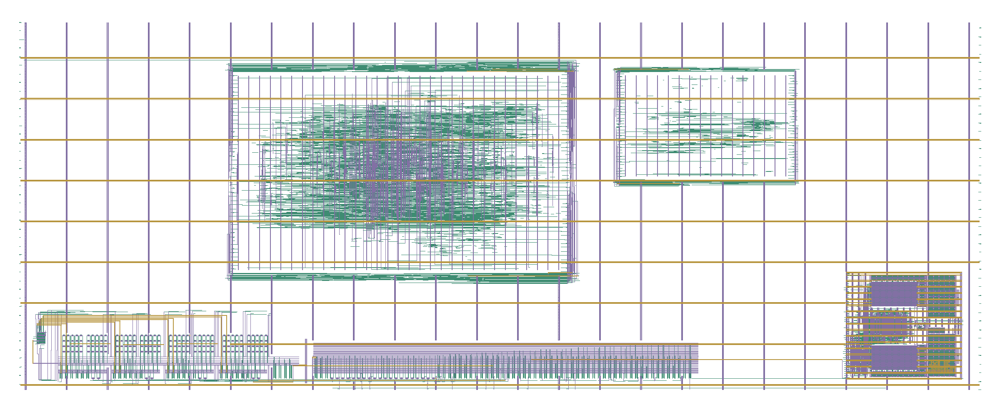

In [131]:
%%native_lab restored-server-flow-render
if RUN_LEGACY_CAMPAIGNS:
    guard_settings()
    if not ACTIVE["render_ready"]:
        print("NO_CURRENT_WRAPPER_RENDER: inspect the active-tag failure/pending evidence above.")
    else:
        from scripts.run_stage8_core_bound_demo import _gds_hierarchy, _gds_reaches
        # Re-read summary to reject a concurrent audit/rewrite between review and render.
        current_report = read_json(BASE / ACTIVE["gds_tag"] / "summary.json")
        if current_report != ACTIVE["gds"]:
            raise RuntimeError("Active summary changed; rerun execution/replay and review before rendering.")
        gds_item = current_report["views"]["gds"]
        gds_path = verified_item(gds_item)
        graph = _gds_hierarchy(gds_path)
        macros = ("automx_cim_core_acquisition_proto", "automx_cim_condition_mux_proto", "adc_top")
        reachability = {macro: _gds_reaches(graph, TOP, macro) for macro in macros}
        if not all(reachability.values()):
            raise ValueError("Current mixed-wrapper hierarchy lacks a real macro: " + str(reachability))
        PROVENANCE["hierarchy"] = reachability
        png_path = None
        if SETTINGS["mode"] == "replay":
            # Preferred: session receipt explicitly binds the source GDS and generated PNG.
            matches = []
            for path in sorted((ROOT / "results/sky130/notebook_sessions").glob("*/provenance.json")):
                saved = read_json(path)
                render = saved.get("render", {})
                if (saved.get("actual_tag") == ACTIVE["tag"] and saved.get("gds_tag") == ACTIVE["gds_tag"]
                        and render.get("gds") == gds_item and render.get("returncode") == 0):
                    matches.append(render)
            if matches:
                png_path = verified_item(matches[-1]["png"])
                PROVENANCE["render"] = {**matches[-1], "action": "HASH_VERIFIED_REPLAY"}
            elif (current_report.get("layout_checks_pass") and current_report.get("png")
                  and not current_report.get("render_status")):
                # The runner emits png + views.gds together only after successful rendering.
                png_path = verified_item(current_report["png"])
                PROVENANCE["render"] = {"action": "RUNNER_RECEIPT_REPLAY", "gds": gds_item,
                                       "png": current_report["png"], "returncode": 0,
                                       "receipt": file_item(BASE / ACTIVE["gds_tag"] / "summary.json")}
            else:
                print("PNG_PROVENANCE_MISSING: replay does not launch KLayout or show an unrelated image.")
        else:
            tool = shutil.which("klayout")
            if not tool:
                raise FileNotFoundError("Native KLayout missing; verified GDS remains available.")
            png_path = SESSION_DIR / "current_wrapper.png"
            renderer = ROOT / "scripts/render_flow2_wrapper_gds.py"
            env = os.environ.copy()
            env.update(QT_QPA_PLATFORM="offscreen", AUTOMX_GDS=str(gds_path),
                       AUTOMX_PNG=str(png_path), AUTOMX_TOP=TOP)
            render_command = [tool, "-z", "-x", "-r", str(renderer)]
            result = subprocess.run(render_command, cwd=ROOT, env=env, text=True,
                                    capture_output=True, timeout=180, check=False)
            (SESSION_DIR / "render.log").write_text(result.stdout + result.stderr)
            if result.returncode != 0:
                PROVENANCE["render"] = {"action": "FAILED", "command": render_command,
                                       "returncode": result.returncode, "gds": gds_item}
                save_session()
                raise RuntimeError("KLayout failed; inspect this session's render.log")
            if file_item(gds_path)["sha256"] != gds_item["sha256"]:
                raise ValueError("GDS changed while rendering")
            PROVENANCE["render"] = {"action": "RENDERED_CURRENT_GDS", "command": render_command,
                "returncode": result.returncode, "gds": gds_item, "png": file_item(png_path),
                "renderer": file_item(renderer), "top": TOP, "gds_tag": ACTIVE["gds_tag"]}
        if png_path:
            if png_path.read_bytes()[:8] != b"\x89PNG\r\n\x1a\n":
                raise ValueError("Invalid current-wrapper PNG")
            print("Actual parent / GDS tag:", ACTIVE["tag"], ACTIVE["gds_tag"])
            print("Source GDS SHA-256:", gds_item["sha256"])
            print("Layout / digital STA:", current_report["status"], current_report.get("digital_sta_status"))
            link(gds_path)
            link(png_path)
            display(Image(filename=str(png_path)))
    save_session()
else:
    pass

# CELL_RESULT server-render
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'render_top/top.render.json')],label='render')
    from IPython.display import Image,display
    display(Image(filename=str(flow.work/'render_top/top.png'),width=1000))


### Post-route measurements


In [132]:
%%native_lab restored-server-flow-postroute
if RUN_LEGACY_CAMPAIGNS:
    guard_settings()
    post_path = BASE / SETTINGS["postroute_tag"] / "summary.json"
    if not post_path.is_file():
        print("POSTROUTE_NOT_MEASURED:", SETTINGS["postroute_tag"])
    else:
        post = read_json(post_path)
        if post.get("gds_tag") != ACTIVE["gds_tag"]:
            print("POSTROUTE_OTHER_RUN:", post.get("gds_tag"), "active:", ACTIVE["gds_tag"])
        else:
            link(post_path)
            for kind, item in post.get("views", {}).items():
                print("Prototype view:", kind, item["sha256"])
                link(verified_item(item))
            for name, check in post.get("checks", {}).items():
                print("Supplemental check:", name, check.get("status"),
                      {k: check[k] for k in ("violations", "net_violations", "pin_violations") if k in check})
                if check.get("log"):
                    link(verified_item(check["log"]))
            PROVENANCE["prototype_evidence"] = file_item(post_path)
            render = post.get("checks", {}).get("render", {})
            if render.get("status") == "PASS":
                active_gds = (ACTIVE["gds"] or {}).get("views", {}).get("gds")
                if not active_gds or render["gds"]["sha256"] != active_gds["sha256"]:
                    raise ValueError("Prototype PNG does not belong to the active native GDS")
                verified_item(active_gds)
                verified_item(render["gds"])
                png = verified_item(render["png"])
                if png.read_bytes()[:8] != b"\x89PNG\r\n\x1a\n":
                    raise ValueError("Invalid prototype PNG")
                print("PROTOTYPE RENDER: native signoff failures remain; NOT_QUALIFIED")
                display(Image(filename=str(png)))
    loaded_path = ROOT / "build/flow2_wrapper_integration" / SETTINGS["loaded_conditioner_tag"] / "summary.json"
    if loaded_path.is_file():
        loaded = read_json(loaded_path)
        if loaded.get("gds_tag") == ACTIVE["gds_tag"]:
            verified_item(loaded["spef"])
            for case in loaded.get("cases", []):
                if case.get("raw"):
                    verified_item(case["raw"])
            print("Conditioner pilot:", loaded.get("status"), loaded.get("network_mode"),
                  loaded.get("gain"), "ADC conversions:", loaded.get("new_ADC_conversions"))
            print("Scope:", loaded.get("scope"))
            link(loaded_path)
    # The repaired core is a separately named block dependency, never active top signoff.
    for setting, filename in (("core_pex_tag", "tap_pex_summary.json"),
                              ("core_transient_tag", "summary.json")):
        core_path = BASE / SETTINGS[setting] / filename
        if not core_path.is_file():
            print("CORE_BLOCK_NOT_MEASURED:", SETTINGS[setting])
            continue
        core_report = read_json(core_path)
        for item in core_report.get("views", {}).values():
            verified_item(item)
        for job in core_report.get("jobs", []):
            if job.get("waveform"):
                verified_item(job["waveform"])
        print("Separate repaired-core evidence:", core_report.get("tag"),
              core_report.get("status"), core_report.get("qualification"))
        print("Scope:", core_report.get("scope"))
        if "completed_sims" in core_report:
            print("TT jobs:", core_report["completed_sims"], "capture budgets met:",
                  core_report.get("all_rc_capture_budgets_met"), "ADC conversions:",
                  core_report.get("new_ADC_conversions"))
        link(core_path)
    # Derived ground ECO: bind the original source and the derived image separately.
    eco_path = BASE / SETTINGS["ground_eco_tag"] / "summary.json"
    if eco_path.is_file():
        eco = read_json(eco_path)
        if eco.get("source_tag") != ACTIVE["gds_tag"]:
            print("GROUND_ECO_OTHER_SOURCE:", eco.get("source_tag"))
        else:
            original = (ACTIVE["gds"] or {}).get("views", {}).get("gds")
            if not original or not any(i.get("sha256") == original["sha256"] for i in eco.get("sources", [])):
                raise ValueError("Ground ECO is not bound to the active source GDS")
            verified_item(original)
            for kind, item in eco.get("views", {}).items():
                link(verified_item(item))
            verified_item(eco["lvs_log"])
            print("DERIVED GROUND ECO:", eco.get("status"), eco.get("qualification"))
            print("Scope:", eco.get("scope"))
            print("Remaining:", eco.get("remaining_gates"))
            link(eco_path)
            checks = read_json(verified_item(eco["independent_checks"]["klayout_render"]))
            render = checks.get("render", {})
            if render.get("status") == "PASS":
                if render["gds"]["sha256"] != eco["views"]["gds"]["sha256"]:
                    raise ValueError("Ground ECO PNG does not belong to the derived GDS")
                verified_item(render["gds"])
                png = verified_item(render["png"])
                if png.read_bytes()[:8] != b"\x89PNG\r\n\x1a\n":
                    raise ValueError("Invalid ground ECO PNG")
                print("DERIVED ECO IMAGE: macro LVS only; full-top qualification remains pending")
                display(Image(filename=str(png)))
            PROVENANCE["ground_eco"] = file_item(eco_path)
    # Coupled frontend is a separate electrical experiment, not active GDS signoff.
    core_proof_path = BASE / SETTINGS["core_pex_tag"] / "tap_pex_summary.json"
    for coupled_tag in SETTINGS["coupled_frontend_tags"]:
        coupled_path = BASE / coupled_tag / "summary.json"
        if not coupled_path.is_file():
            print("COUPLED_FRONTEND_NOT_MEASURED:", coupled_tag)
            continue
        coupled = read_json(coupled_path)
        core_proof = read_json(core_proof_path)
        core_item = core_proof["views"]["gds"]
        verified_item(core_item)
        if not any(item.get("sha256") == core_item["sha256"]
                   for item in coupled["inputs"]["sources"]):
            raise ValueError("Coupled experiment is not bound to the configured repaired core")
        if coupled.get("waveform"):
            verified_item(coupled["waveform"])
        print("Coupled frontend:", coupled_tag, coupled.get("status"), coupled.get("measurement"))
        print("Scope:", coupled.get("scope"), "actual ADC conversions:", coupled.get("new_ADC_conversions"))
        link(coupled_path)
        PROVENANCE.setdefault("coupled_frontend", []).append(file_item(coupled_path))
    # Separate antenna GDS; bind source, candidate, signal LVS and placement proof.
    antenna_path = BASE / SETTINGS["antenna_prototype_tag"] / "summary.json"
    if antenna_path.is_file():
        antenna = read_json(antenna_path)
        ground = read_json(BASE / SETTINGS["ground_eco_tag"] / "summary.json")
        if ground.get("source_tag") == ACTIVE["gds_tag"] and antenna.get("status") == "GDS_PROTOTYPE_KLAYOUT_CLEAN_SIGNAL_LVS_ONLY":
            candidate = read_json(BASE / antenna["candidate_tag"] / "summary.json")
            lvs = read_json(BASE / antenna["signal_lvs_tag"] / "summary.json")
            if candidate["candidate_odb"] != antenna["views"]["odb"] or lvs.get("candidate_tag") != antenna["candidate_tag"]:
                raise ValueError("Antenna prototype source binding differs")
            if lvs.get("status") != "SIGNAL_ONLY_DEF_LEF_LVS_MATCH_NO_PG_BODY_QUALIFICATION":
                raise ValueError("Antenna prototype signal LVS is not matched")
            for item in antenna["views"].values():
                link(verified_item(item))
            placement = antenna.get("placement_audit", {})
            proof = read_json(verified_item(placement["report"]))
            if proof["status"] != "PRESERVED_GDS_PLACEMENTS" or placement["candidate"]["sha256"] != antenna["views"]["gds"]["sha256"]:
                raise ValueError("Antenna prototype placement proof differs")
            print("Separate antenna prototype:", antenna["status"], antenna["antenna"], antenna["instance_audit"])
            print("Scope:", antenna["scope"])
            link(antenna_path)
            png = verified_item(antenna["png"])
            if png.read_bytes()[:8] != b"\x89PNG\r\n\x1a\n":
                raise ValueError("Invalid antenna prototype PNG")
            display(Image(filename=str(png)))
            PROVENANCE["antenna_prototype"] = file_item(antenna_path)
        else:
            print("ANTENNA_PROTOTYPE_OTHER_SOURCE_OR_BLOCKED")
    # Prototype physical profile is separate from strict analog/fabrication qualification.
    chip_path = BASE / SETTINGS["chip_signoff_tag"] / "summary.json"
    if chip_path.is_file():
        chip = read_json(chip_path)
        chip_source = read_json(BASE / SETTINGS["antenna_prototype_tag"] / "summary.json")
        if chip["source_tag"] != SETTINGS["antenna_prototype_tag"] or chip["views"]["gds"] != chip_source["views"]["gds"]:
            raise ValueError("Chip prototype signoff belongs to another GDS")
        for item in chip["views"].values():
            link(verified_item(item))
        for item in chip["evidence"].values():
            verified_item(item)
        verified_item(chip["canonical_strict_signoff"])
        print("Prototype physical signoff:", chip["status"], chip["operating_point"])
        print("Prototype gates:", chip["gates"])
        print("Waivers:", chip["waivers"])
        print("Fabrication ready:", chip["fabrication_ready"], "end-to-end analog:", chip["end_to_end_analog_demonstrated"])
        PROVENANCE["chip_prototype_signoff"] = file_item(chip_path)
        link(chip_path)
    save_session()

else:
    pass

# CELL_RESULT server-postroute
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'timing'/'nominal_timing.json')],label='postroute')
    print('Digital TT:',pretty(flow.outputs['nominal_timing']))


| Report | Available |
|---|---|
| `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/timing/nominal_timing.json` | No |

Digital TT: {"setup_slack_ns": 1.65, "hold_slack_ns": 0.19, "frequency_mhz": 25, "scope": "Hierarchical gate-level TT STA: parent and both digital hard-macro SPEFs; physical-interface Liberty arcs are not used for signoff."}


### Server-session artifacts and manifest


In [133]:
%%native_lab restored-server-flow-close
from automx_nb_inline_v1.presentation import pretty
if RUN_LEGACY_CAMPAIGNS:
    guard_settings()
    PROVENANCE["result"] = {
        "actual_tag": ACTIVE["tag"], "wrapper_tag": ACTIVE["wrapper_tag"], "gds_tag": ACTIVE["gds_tag"],
        "parent_status": (ACTIVE["report"] or {}).get("status", "NOT_MEASURED"),
        "cli_returncode": ACTIVE["returncode"], "render_ready": ACTIVE["render_ready"],
        "execution_error": execution_error, "qualification": "NOT_QUALIFIED", "run_all_tested": False}
    print(pretty(PROVENANCE, indent=2))
    save_session()
    if SETTINGS["mode"] != "replay":
        link(SESSION_DIR / "provenance.json")
    export_dir = ROOT / "server_results/flow2_wrapper_integration" / ACTIVE["tag"]
    for name in ("summary.json", "history.log", "export.json"):
        if (export_dir / name).is_file():
            link(export_dir / name)
    print("Run All: NOT_TESTED; qualification: NOT_QUALIFIED")
else:
    pass

# CELL_RESULT server-close
if not RUN_LEGACY_CAMPAIGNS:
    history.review_reports(ROOT,[str(flow.work/'mha_end_to_end.json')],label='close')


| mha_end_to_end | Result |
|---|---|
| calibration_holdout_pattern_overlap | 0 |
| floating_reference_metrics.rmse | 0.2326076 |
| floating_reference_metrics.normalized_rmse | 0.1144771 |
| metrics.rmse | 0 |
| metrics.normalized_rmse | 0 |
| floating_reference_metrics.cosine_similarity | 0.9954203 |
| metrics.cosine_similarity | 1 |
| floating_reference_metrics.max_absolute_error | 0.3742999 |
| metrics.max_absolute_error | 0 |
| calibration.frozen_before_holdout | True |
| unique_holdout_patterns | 30 |
| shape.sequence | 2 |

Source: `/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/mha_end_to_end.json`

### Historical notebook source


## 11. Final results


### Tools executed in the new session

Collect return codes and runtimes from processes executed in this session.


<a id="guide-native-story-dependencies"></a>

### Before cell `native-story-dependencies` — F9

**Implementation:** Link fresh execution steps and summarize final conversion/MHA/physical results. Conclusions must be traceable to measurements and generated artifacts beyond a GDS image.


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-dependencies-dependencies"></a>`dependencies(root, flow)` | Construct earlier recipe/result dependencies and compare input artifacts when invoked; the active cell calls fresh_activity to present this session's newly executed tools. |

<a id="data-native-story-dependencies"></a>

**Inputs, outputs, and downstream use:**

- **Input sources, structure, and units:** Receive Flow and its output/receipt references; final_results opens analog_adc_mha/gds_geometry_proof and uses measured nominal_timing.
- **Return values and saved artifacts:** Return/display calibration codes, 32 transactions/30 patterns, L2, geometry, slack, and top GDS; the active dependencies invocation writes fresh_activity.json from new logs.
- **Downstream consumers:** runall-manifest validates deliverable views; full-lab-inventory verifies the order of 89 native cells without inferring provenance from notebook position.


In [134]:
%%native_lab story-dependencies
%%inline_module story_dependencies
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def dependencies(root,flow):
    """Show concrete old-to-new input edges and separately identify design rationale."""
    book=json.loads((Path(root)/'AutoMX_CIM_Sky130_MHA.ipynb').read_text())
    mapping={r['original_id']:r['original_index']+1 for r in book['metadata']['automx']['historical_cell_mapping']}
    recipes={c.get('metadata',{}).get('historical_recipe'):c for c in book['cells'] if c.get('metadata',{}).get('historical_recipe')}
    stages=[
        ('original-012','MHA numerical reference','Digital reference for projection and attention comparison.'),
        ('original-014','Tile schedule','Q/K/V → attention → O dependency and controller-transaction order.'),
        ('c4dd9fe2','Stage 5 GDS/LEF/PEX','PEX netlist input to coverage and transfer sweeps.'),
        ('core-pex-coverage-run','101-case PEX coverage','Select difficult pairs for level-reversal diagnosis.'),
        ('b10e6122','Transfer diagnosis','Reversed pair supplied to load/PWM sweeps.'),
        ('core-candidate-full-tt-run','800 fF / 50 ps full TT','Scalar-decoder threshold training data.'),
        ('post49-decoder-diagnostic-run','52/128 decoder errors','Diagnose missing levels and expand calibration.'),
        ('post49-partition-full-cal-run','2+2 signed calibration','Frozen thresholds for fresh holdout.'),
        ('post49-partition-full-holdout-run','0/256 decode errors','2+2 readout results establishing the RTL-protocol premise.'),
        ('stage7-two-read-regression','Two-read RTL regression','Verify read ordering and partial-sum accumulation.')]
    table(['Cell in the 127-cell version (counting from 1)','Earlier result','Role downstream'],[
        [mapping[recipes[key]['metadata']['original_cell_id']],title,role] for key,title,role in stages])
    pairs=[
      ('../receipts/physical/core_pex_coverage.json','stage5_summary_sha256','../receipts/physical/stage5_summary.json'),
      ('core_transfer_diagnostics/measured.json','coverage_receipt_sha256','../receipts/physical/core_pex_coverage.json'),
      ('core_candidate_full_tt/measured.json','stage4p8_sha256','core_candidate_pex/measured.json'),
      ('post49_decoder_diagnostic.json','cell49_sha256','core_candidate_full_tt/measured.json'),
      ('post49_decoder_diagnostic.json','holdout_sha256','post49_holdout_tt/measured.json'),
      ('post49_row_partition/adjacent/measured.json','input_report_sha256.calibration','post49_calibration_tt/measured.json'),
      ('post49_partition_full_tt/calibration/measured.json','targeted_sha256','post49_row_partition/adjacent/measured.json'),
      ('post49_partition_full_tt/holdout/measured.json','calibration_sha256','post49_partition_full_tt/calibration/measured.json')]
    edges=[linked(root,BASE+child,field,BASE+parent) for child,field,parent in pairs]
    table(['Prerequisite result','Consumer step'],[[e['parent'],e['child']] for e in edges])
    route=read_report(root,PHYSICAL+'antenna_safe_srv_20261022_08/summary.json')['candidate_odb']
    current=flow.outputs['route_checkpoint']
    if route['sha256']!=current['sha256'] or fingerprint(Path(current['path']))!=route['sha256']:raise ValueError('Final streamout did not use the measured route candidate')
    table(['Inherited path','Role in subsequent results'],[
        ['Stage 4/5 → PEX → sweep → decoder → 2+2','Measured errors determine the next revision.'],
        ['MHA reference / vector / schedule → RTL regression','Digital references and Q/K/V/O ordering establish the basis for RTL verification.'],
        ['2+2 calibration and holdout → readout selection','Design premise; the current SAR branch performs its own three-conversion calibration.'],
        ['ECO08 ODB → DEF/LEF → current GDS','Routed checkpoint used for DEF/LEF/GDS export.'],
        ['3 native SAR calibration → 30 holdout patterns → 32 Q/K/V/O','End-to-end data chain for the current MHA measurement.']])
    display(Markdown('The original 127 cells include explanations, configuration, measurements, and orchestration. This table identifies concrete input dependencies and results supporting design choices.'))
    EVIDENCE['verified_dependency_edges']=edges
    EVIDENCE['final_route_dependency']={'candidate':route,'streamout_route':current,'verified':True}
    path=flow.work/'measured_development_story.json';path.write_text(json.dumps(EVIDENCE,indent=2,ensure_ascii=False)+'\n')
    flow.outputs['measured_development_story']={'path':str(path),'sha256':fingerprint(path)}
    print('Measured development receipt:',path)
    return edges

# NOTEBOOK_RUN
fresh_activity=fresh_pilot.fresh_activity(flow)


FRESH SESSION: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native ; pre-existing result files: 0 ; reuse: False


| Tool step | Return code | Runtime / s |
|---|---|---|
| iverilog_version | 0 | 0.01 |
| vvp_version | 0 | 0.01 |
| klayout_version | 0 | 0.20 |
| yosys_version | 0 | 0.48 |
| openroad_version | 0 | 0.46 |
| ngspice_runtime_version | 0 | 0.07 |
| render_01_core_acquisition | 0 | 1.43 |
| render_02_conditioner_mux | 0 | 1.41 |
| render_03_adc_reference | 0 | 2.39 |
| render_08_mha | 0 | 2.15 |
| render_09_readout | 0 | 3.05 |
| conversion_158427dfe1c46959 | 0 | 15.32 |
| conversion_b181b7e3e6c3d14c | 0 | 15.50 |
| conversion_b59db5ff2f509b4e | 0 | 15.54 |
| conversion_30f5291c7edf346c | 0 | 15.37 |
| conversion_362e75add0b4ebc8 | 0 | 15.52 |
| conversion_09234f26b8f41bf5 | 0 | 15.75 |
| conversion_7cb1e481efeb6551 | 0 | 15.46 |
| conversion_713cc4294d9a3bfa | 0 | 15.59 |
| conversion_49a276b8d5a7a95b | 0 | 15.75 |
| conversion_bef103c632fc6037 | 0 | 14.52 |
| conversion_1c8a55a7c04e51cc | 0 | 14.40 |
| conversion_4872533d667769e3 | 0 | 15.63 |
| conversion_c4e086e1a70b5061 | 0 | 22.86 |
| conversion_6718532b2a38cf5b | 0 | 16.08 |
| conversion_f5ce44d9988df20b | 0 | 15.85 |
| conversion_4c2ecaebbc0aa4a0 | 0 | 15.88 |
| conversion_0c4f73e142bcd9f8 | 0 | 14.86 |
| conversion_d75d1801282b13d7 | 0 | 15.53 |
| conversion_3fa7e7db227a6608 | 0 | 19.09 |
| conversion_f2107fe8406032b3 | 0 | 17.54 |
| conversion_3fd73db8e8e36883 | 0 | 21.68 |
| conversion_3ca49fdf96248609 | 0 | 18.66 |
| conversion_7a1bd41fcc2718b1 | 0 | 17.18 |
| conversion_14d1b548c5afa75e | 0 | 16.42 |
| conversion_0a9ea9313dcc8b3b | 0 | 14.40 |
| conversion_af7c00dc32e54d72 | 0 | 15.73 |
| conversion_63195961228cd861 | 0 | 15.75 |
| conversion_7c3f37c04131b75a | 0 | 16.04 |
| conversion_224dd9360db8954b | 0 | 15.08 |
| conversion_800f17f5ea022144 | 0 | 15.31 |
| conversion_c67bb720ef4f10c5 | 0 | 15.89 |
| conversion_c058bc6d0c32ac1f | 0 | 13.85 |
| conversion_2eb0abd6f3c00282 | 0 | 13.70 |
| conversion_e06412d581b4a94f | 0 | 15.12 |
| conversion_f9cb7e0ffbfb41ce | 0 | 15.36 |
| conversion_bcdfb53fa5da7054 | 0 | 15.75 |
| conversion_c7efa4dd2eebaf2a | 0 | 15.08 |
| conversion_85dd575d0d2a8034 | 0 | 15.77 |
| conversion_3de94677f3349493 | 0 | 15.59 |
| conversion_eb72f10a5674e62e | 0 | 13.47 |
| conversion_a9c50c319733e772 | 0 | 13.76 |
| sar_synthesis | 0 | 3.53 |
| cold_pnr | 0 | 508.39 |
| measured_area | 0 | 1.24 |
| area_automx_cim_readout_seq | 0 | 32.21 |
| area_adc_core_digital | 0 | 3.35 |
| export | 0 | 3.44 |
| geometry | 0 | 18.82 |
| drc | 124 | 46.33 |
| render_top | 0 | 3.05 |
| render_top_routing_detail | 0 | 3.41 |
| lvs_export | 0 | 2.21 |
| extract | 0 | 11.16 |
| signal_lvs | 0 | 0.43 |
| power | 0 | 5.97 |
| parent_rcx | 0 | 3.18 |
| hierarchical_timing | 0 | 6.56 |
| hierarchical_etm | 0 | 12.23 |
| lib_parse | 0 | 0.46 |

### Final measurements and artifacts

Read values directly from the current Run All outputs.


<a id="guide-native-story-final_results"></a>

### Before cell `native-story-final_results` — F9

**Implementation:** Use the operation group explained in [cell `native-story-dependencies`](#guide-native-story-dependencies).


**Function reference:**

| Function and parameters | Task, result, and side effects |
|---|---|
| <a id="fn-native-story-final_results-final_results"></a>`final_results(flow)` | Read analog_adc_mha and GDS/STA evidence from flow.outputs and tabulate calibration, projections, L2, and this run's top-GDS path. |

**Data and downstream use:** Follow the [contract described for `native-story-dependencies`](#data-native-story-dependencies).


In [135]:
%%native_lab story-final_results
%%inline_module story_final_results
from pathlib import Path
from collections import Counter
import json,re
from IPython.display import Markdown,display
from automx_nb_inline_v1.story import EVIDENCE,BASE,PHYSICAL,fingerprint,read_report,table,linked
def final_results(flow):
    """Conclude with measured outputs of this Run All session."""
    mha=json.loads(Path(flow.outputs['analog_adc_mha']['path']).read_text())
    geometry=json.loads(Path(flow.outputs['gds_geometry_proof']['path']).read_text())
    table(['Final result','Value','Source'],[
        ['Analog/SAR calibration',str(mha['calibration']['measured_ADC_codes']),'3 native conversion receipts'],
        ['Q/K/V/O',str(mha['projection_transactions'])+' transactions / '+str(mha['unique_holdout_patterns'])+' unique holdout patterns','mha_end_to_end.json'],
        ['MHA relative L2 / quantized-context reference',mha['relative_l2'],'mha_end_to_end.json'],
        ['MHA relative L2 / floating-context reference',mha['floating_reference_relative_l2'],'mha_end_to_end.json'],
        ['GDS geometry',json.dumps(geometry),'gds_geometry_proof'],
        ['Timing digital TT / 25 MHz',json.dumps({k:v for k,v in flow.outputs['nominal_timing'].items() if k!='scope'}),'OpenRCX / OpenSTA'],
        ['Top GDS',flow.outputs['gds']['path'],'KLayout streamout']])
    return geometry

# NOTEBOOK_RUN
story_final_results.final_results(flow)


| Final result | Value | Source |
| --- | --- | --- |
| Analog/SAR calibration | [2047.0, 2176.0, 1919.0] | 3 native conversion receipts |
| Q/K/V/O | 32 transactions / 30 unique holdout patterns | mha_end_to_end.json |
| MHA relative L2 / quantized-context reference | 0.0 | mha_end_to_end.json |
| MHA relative L2 / floating-context reference | 0.114477076077953 | mha_end_to_end.json |
| GDS geometry | {"status": "EXACT_COLD_GDS_CELL_GEOMETRY_AND_INSTANCES_MATCH", "cells": 180, "instances": 103155, "masters": 36} | gds_geometry_proof |
| Timing digital TT / 25 MHz | {"setup_slack_ns": 1.65, "hold_slack_ns": 0.19, "frequency_mhz": 25} | OpenRCX / OpenSTA |
| Top GDS | /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/streamout/automx_cim_mixed_signal_proto.gds | KLayout streamout |

In [136]:
%%native_lab runall-manifest
%%inline_module publish
from automx_standalone import publish
# NOTEBOOK_RUN
manifest=publish.publish(flow,INLINE_SOURCES,history.REPLAY_RECORDS)


STANDALONE FRESH END-TO-END COMPLETE
Top GDS: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/streamout/automx_cim_mixed_signal_proto.gds
Run manifest: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/full_native/full_native/runall_manifest.json


## Complete laboratory coverage

The next cell checks that every original code cell was encountered exactly once
in source order. It records whether this execution displayed supplied measurements
or ran the native bodies, and reports the retained source/figure counts.

In [137]:
_lab_seen=_lab_state['executed'] if _lab_state['mode']=='on' else _lab_state['replayed']
_lab_expected=[r['original_id'] for r in _lab_manifest['cells'] if r['cell_type']=='code']
if _lab_seen!=_lab_expected: raise AssertionError('Missing, reordered or duplicate native laboratory cells')
_lab_report={
    'status':'COMPLETE',
    'mode':'fresh_native' if _lab_state['mode']=='on' else 'attributed_recorded_native',
    'original_cells_included':_lab_state['source_cells'],
    'original_code_cells_included':_lab_state['source_code_cells'],
    'original_code_lines':_lab_manifest['source_code_lines'],
    'processed_native_code_cells':len(_lab_seen),
    'original_nonempty_output_cells':sum(bool(v) for v in _lab_records.values()),
    'original_embedded_figures':sum('image/png' in o.get('data',{})
                                   for group in _lab_records.values() for o in group)}
(_lab_output/'native_lab_results.json').write_text(_lab_json.dumps(_lab_report,indent=2)+'\n')
print(_lab_json.dumps(_lab_report,indent=2))


{
  "status": "COMPLETE",
  "mode": "fresh_native",
  "original_cells_included": 200,
  "original_code_cells_included": 89,
  "original_code_lines": 12015,
  "processed_native_code_cells": 89,
  "original_nonempty_output_cells": 0,
  "original_embedded_figures": 0
}


<a id="results-real-application"></a>
## From wearable sensor data to a hardware attention decision

The next experiments turn the existing two-token, four-channel, two-head IP into a six-class human-activity application. They compare the deployed arithmetic, actual RTL, a serial ternary digital backend, and a bounded native CIM/SAR campaign. Feature extraction, the 12-to-4 token embedding and the classifier are software; Q/K/V, attention, context quantization and O are the hardware candidate.

The [UCI HAR dataset](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones), by Reyes-Ortiz, Anguita, Ghio, Oneto and Parra, is used under CC BY 4.0. Subject identities separate training, validation and test. Deployment weights and calibration are frozen before their respective held-out evaluations. Dataset-wide RTL coverage and native circuit frame coverage are reported separately.

**Implementation:** Register a notebook module for each source block so its functions have separate global variables. Each source block is visible in the notebook and also writes the same implementation to the bundled path used by subprocesses. This keeps training, the independent reference and native simulation from accidentally sharing or overwriting format constants.

**Inputs → outputs and downstream use:** A source cell and its module name produce an executable Python module and the identical source file. The following experiment cells call these exact implementations and save new outputs under this run's empty directory.

In [138]:
from IPython.core.magic import register_cell_magic
from IPython.display import Markdown,display
from pathlib import Path
import sys,types
PRIORITY_ROOT=Path(__import__('os').environ.get('AUTOMX_BUNDLE_DIR','.')).resolve()
PRIORITY_WORK=Path(_design_review_namespace['OUT'])/'priority_application'
PRIORITY_WORK.mkdir(parents=True,exist_ok=False)
PRIORITY_MODULES={}
PRIORITY_PATHS={'har':'automx_cim/application_har.py','decoder':'scripts/verify_binary_decoder.py','rtl':'scripts/verify_har_application_rtl.py','costs':'scripts/measure_priority_costs.py','worker':'scripts/portable_cim_sar.py','native':'scripts/run_har_native.py','replay':'scripts/replay_har_native_rtl.py','power':'scripts/measure_activity_power.py','summary':'scripts/summarize_priority_implementation.py'}
@register_cell_magic
def priority_module(line,cell):
    name=line.strip();path=PRIORITY_ROOT/PRIORITY_PATHS[name]
    path.parent.mkdir(parents=True,exist_ok=True);path.write_text(cell)
    module=types.ModuleType('automx_priority_'+name);module.__file__=str(path)
    sys.modules[module.__name__]=module
    exec(compile(cell,str(path),'exec'),module.__dict__)
    PRIORITY_MODULES[name]=module
    print('Source ready:',path.relative_to(PRIORITY_ROOT))
print('Application outputs:',PRIORITY_WORK)

import os
PRIORITY_JOBS=min(16,os.cpu_count() or 1)
print("Application acquisition workers:",PRIORITY_JOBS)


Application outputs: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/priority_application
Application acquisition workers: 16


**Implementation:** Locate the attributed UCI HAR input dataset, or download and unpack its official archive. No previous application measurements supply predictions or ADC words.

**Inputs → outputs and downstream use:** Inertial text files, labels and subject IDs become the input to deterministic half-window summaries. The model cell fits normalization only on training subjects.

In [139]:
import urllib.request,zipfile
_har=PRIORITY_ROOT/'data/uci_har'
if not (_har/'UCI HAR Dataset/train/subject_train.txt').is_file():
    _har.mkdir(parents=True,exist_ok=True);_archive=_har/'uci_har.zip'
    if not _archive.is_file():
        with urllib.request.urlopen('https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip',timeout=90) as _response:
            _archive.write_bytes(_response.read())
    with zipfile.ZipFile(_archive) as _zip:
        assert _zip.testzip() is None;_zip.extractall(_har)
    for _child in _har.glob('*.zip'):
        if _child!=_archive:
            with zipfile.ZipFile(_child) as _zip:_zip.extractall(_har)
print('Dataset: six activities; train/test subjects disjoint; two 64-reading halves per window')


Dataset: six activities; train/test subjects disjoint; two 64-reading halves per window


**Implementation:** `load_features` computes mean/RMS sensor summaries. `quantize` implements the supported alphabet with a straight-through training gradient. `TinyAttention` matches the four ternary projections and the IP's fixed-point probabilities/context; its embedding and classifier remain software. `train` selects checkpoints with validation subjects. `metrics` reports classification errors. `run` freezes deployment parameters before test evaluation and compares every output to the independent integer reference.

**Inputs → outputs and downstream use:** Training windows and subject IDs produce float/quantized checkpoints, an explicit deployment contract, test metrics, and packed hardware input/output vectors. QAT means Quantization-Aware Training; X2 stores twice the activation value as an integer. The three QAT seeds are fixed in advance.

In [140]:
%%priority_module har
"""Subject-disjoint wearable classification using the exact AutoMX MHA contract.

Copyright 2026 EDABK Laboratory. SPDX-License-Identifier: Apache-2.0.
Feature extraction, embedding and classification are software; only the
two-token MHA block is the candidate hardware accelerator.
"""
from pathlib import Path
from copy import deepcopy
import argparse, json, time
import numpy as np
import torch
from torch import nn
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, recall_score
from sklearn.linear_model import LogisticRegression

MAGNITUDES = (0., .5, 1., 1.5, 2., 3., 4., 6.)
LABELS = ('WALKING','WALKING_UPSTAIRS','WALKING_DOWNSTAIRS','SITTING','STANDING','LAYING')

def save(path, value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2)+'\n')

def load_features(folder, split):
    """Mean/RMS of 6 axes in each 64-reading half; no fitted parameters."""
    folder=Path(folder);signals=[]
    for name in ('total_acc_x','total_acc_y','total_acc_z','body_gyro_x','body_gyro_y','body_gyro_z'):
        signals.append(np.loadtxt(folder/split/'Inertial Signals'/f'{name}_{split}.txt',dtype=np.float32))
    x=np.stack(signals,axis=-1).reshape(-1,2,64,6)
    features=np.concatenate((x.mean(2),np.sqrt((x*x).mean(2))),axis=-1)
    y=np.loadtxt(folder/split/f'y_{split}.txt',dtype=int)-1
    subjects=np.loadtxt(folder/split/f'subject_{split}.txt',dtype=int)
    assert features.shape==(len(y),2,12) and np.isfinite(features).all()
    return features,y,subjects

def quantize(values):
    mags=values.new_tensor(MAGNITUDES)
    indices=(values.abs().unsqueeze(-1)-mags).abs().argmin(-1)
    hard=values.sign()*mags[indices]
    return values+(hard-values).detach()

class TinyAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding=nn.Linear(12,4)
        self.weights=nn.ParameterList([nn.Parameter(torch.empty(4,4).uniform_(-.8,.8)) for _ in range(4)])
        self.head=nn.Linear(8,6)
        import math
        self.register_buffer('lut',torch.tensor([round(32768/(1+math.exp(-i/8))) for i in range(65)],dtype=torch.long))

    def ternary(self,w):
        hard=w.sign()*(w.abs()>=.35)
        return w+(hard-w).detach()

    def datapath(self, features, quantized=True, attention='learned'):
        x=torch.tanh(self.embedding(features))*3
        if quantized:x=quantize(x)
        weights=[self.ternary(w) if quantized else w for w in self.weights]
        q,k,v=[(x@w).reshape(-1,2,2,2).transpose(1,2) for w in weights[:3]]
        scores=(q@k.transpose(-1,-2))/(2**.5)
        p=torch.sigmoid(scores[...,0]-scores[...,1])
        if quantized:
            integer_scores=(q*2)@(k*2).transpose(-1,-2)
            d=(integer_scores[...,0]-integer_scores[...,1]).detach().round().long()
            m=d.abs();scaled=m*181;index=(scaled//128).clamp(max=63);fraction=scaled%128
            val=self.lut[index]+((self.lut[index+1]-self.lut[index])*fraction+64)//128
            val=torch.where(m>=46,torch.full_like(val,32768),val)
            val=torch.where(d<0,32768-val,val).float()/32768
            p=p+(val-p).detach()
        if attention=='uniform':p=torch.full_like(p,.5)
        elif attention=='identity':
            p=torch.zeros_like(p);p[...,0]=1
        a=torch.stack((p,1-p),dim=-1)
        context=(a@v).transpose(1,2).reshape(-1,2,4)
        if quantized:context=quantize(context)
        output=context@weights[3]
        return output,x,context,a

    def forward(self, features, quantized=True, attention='learned'):
        output,*_=self.datapath(features,quantized,attention)
        return self.head(output.flatten(1))

def metrics(y, pred):
    return {'accuracy':float(accuracy_score(y,pred)),'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
            'per_class_recall':recall_score(y,pred,average=None,labels=np.arange(6),zero_division=0).tolist(),
            'confusion_matrix':confusion_matrix(y,pred,labels=np.arange(6)).tolist()}

def train(model,x,y,train_mask,val_mask,*,seed,epochs,quantized,attention='learned',lr=.012):
    torch.manual_seed(seed);rng=np.random.default_rng(seed)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=1e-5)
    ids=np.flatnonzero(train_mask);x_t=torch.from_numpy(x);y_t=torch.from_numpy(y).long()
    best=-1.;state=None;history=[];start=time.monotonic()
    for epoch in range(epochs):
        model.train()
        for batch in np.array_split(rng.permutation(ids),max(1,len(ids)//512)):
            optimizer.zero_grad();loss=nn.functional.cross_entropy(model(x_t[batch],quantized,attention),y_t[batch]);loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5);optimizer.step()
            with torch.no_grad():
                for w in model.weights:w.clamp_(-1,1)
        if epoch%10==0 or epoch==epochs-1:
            model.eval()
            with torch.no_grad():pred=model(x_t[val_mask],quantized,attention).argmax(-1).numpy()
            score=float(f1_score(y[val_mask],pred,average='macro',zero_division=0))
            history.append({'epoch':epoch+1,'validation_macro_f1':score})
            if score>best:best=score;state=deepcopy(model.state_dict())
            if epoch%40==0:print('TRAIN',json.dumps({'seed':seed,'quantized':quantized,'attention':attention,'epoch':epoch+1,'validation_macro_f1':score}),flush=True)
    model.load_state_dict(state)
    return {'validation_macro_f1':best,'history':history,'elapsed_s':time.monotonic()-start,'seed':seed,'quantized':quantized,'attention':attention}

def run(root,work,epochs=160):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(2);torch.manual_seed(2027);np.random.seed(2027)
    folder=root/'data/uci_har/UCI HAR Dataset'
    raw,y,subjects=load_features(folder,'train')
    unique=np.unique(subjects);val_subjects=np.random.default_rng(2027).permutation(unique)[:5]
    val_mask=np.isin(subjects,val_subjects);train_mask=~val_mask
    mean=raw[train_mask].mean((0,1),keepdims=True);std=raw[train_mask].std((0,1),keepdims=True).clip(.001)
    x=((raw-mean)/std).astype(np.float32)
    contract={'dataset':'UCI HAR, DOI 10.24432/C54S4K','source_url':'https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones',
        'dataset_license':'CC BY 4.0','dataset_creators':'Reyes-Ortiz, Anguita, Ghio, Oneto and Parra (2013)',
        'features':'Two half-windows; mean/RMS of total_acc xyz and body_gyro xyz; 12 software features/token',
        'fit_subjects':np.unique(subjects[train_mask]).tolist(),'validation_subjects':sorted(val_subjects.tolist()),
        'selection':'Validation macro-F1 only; fixed 3 QAT seeds; no test-label model selection',
        'configuration':{'tokens':2,'channels':4,'heads':2,'ternary_threshold':.35,'shared_activation_scale':1},
        'normalization_mean':mean.reshape(-1).tolist(),'normalization_std':std.reshape(-1).tolist(),
        'software_components':['feature extraction','12-to-4 embedding','8-to-6 classification head'],
        'hardware_candidate':'Only Q/K/V, attention, context quantization and O projection'}
    save(work/'training_contract.json',contract)
    teacher=TinyAttention();teacher_report=train(teacher,x,y,train_mask,val_mask,seed=2027,epochs=epochs,quantized=False)
    torch.save(teacher.state_dict(),work/'float_model.pt');save(work/'float_training.json',teacher_report)
    candidates=[];best=None
    for seed in (2027,2028,2029):
        model=deepcopy(teacher)
        if seed!=2027:
            torch.manual_seed(seed)
            with torch.no_grad():
                for w in model.weights:w.add_(torch.randn_like(w)*.025)
        report=train(model,x,y,train_mask,val_mask,seed=seed,epochs=epochs,quantized=True)
        torch.save(model.state_dict(),work/f'qat_{seed}.pt');save(work/f'qat_{seed}.json',report);candidates.append(report)
        if best is None or report['validation_macro_f1']>best[0]:best=(report['validation_macro_f1'],model,seed)
    model=best[1];torch.save(model.state_dict(),work/'deployed_model.pt')
    uniform=deepcopy(teacher);uniform_report=train(uniform,x,y,train_mask,val_mask,seed=2027,epochs=epochs,quantized=True,attention='uniform')
    torch.save(uniform.state_dict(),work/'uniform_model.pt');save(work/'uniform_training.json',uniform_report)
    linear=LogisticRegression(C=1,max_iter=1500).fit(x[train_mask].reshape(-1,24),y[train_mask])
    with torch.no_grad():
        weights={n:model.ternary(w).round().long().tolist() for n,w in zip(('Q','K','V','O'),model.weights)}
    # Freeze selection and all deployment inputs BEFORE loading test labels.
    deployment={'selected_seed':best[2],'selection_validation_macro_f1':best[0],
       'weights':weights,'embedding_weight':model.embedding.weight.detach().tolist(),
       'embedding_bias':model.embedding.bias.detach().tolist(),'head_weight':model.head.weight.detach().tolist(),
       'head_bias':model.head.bias.detach().tolist(),'normalization':{'mean':contract['normalization_mean'],'std':contract['normalization_std']},
       'test_used_for_selection':False,'seeds_compared':[2027,2028,2029],'activation_gain':3}
    save(work/'deployment.json',deployment)
    raw_test,test_y,test_subjects=load_features(folder,'test')
    assert not set(subjects)&set(test_subjects)
    test_x=((raw_test-mean)/std).astype(np.float32);tensor=torch.from_numpy(test_x)
    model.eval();teacher.eval();uniform.eval()
    with torch.no_grad():
        logits=model(tensor).numpy();out,acts,context,attention=model.datapath(tensor)
        predictions={'float':teacher(tensor,False).argmax(-1).numpy(),'integer_mha':logits.argmax(-1),
          'uniform_retrained':uniform(tensor,True,'uniform').argmax(-1).numpy(),
          'uniform_frozen':model(tensor,True,'uniform').argmax(-1).numpy(),
          'identity_frozen':model(tensor,True,'identity').argmax(-1).numpy(),
          'linear_features':linear.predict(test_x.reshape(-1,24)),
          'majority':np.full(len(test_y),np.bincount(y[train_mask]).argmax())}
    input_x2=(acts.numpy()*2).round().astype(int);output_x2=(out.numpy()*2).round().astype(int)
    from ip.automx_mha.verify import reference, pack
    array_weights={k:np.array(v,dtype=int) for k,v in weights.items()}
    expected=np.stack([reference(a,array_weights)['output_x2'] for a in input_x2])
    assert np.array_equal(expected,output_x2),'Training forward differs from independent IP integer reference'
    report={'status':'PASS','test_windows':len(test_y),'test_subjects':np.unique(test_subjects).tolist(),
      'selected_seed':best[2],'test_not_used_for_selection':True,'integer_reference_output_mismatches':int(np.count_nonzero(expected-output_x2)),
      'models':{name:metrics(test_y,p) for name,p in predictions.items()},
      'per_subject':{str(int(s)):{name:metrics(test_y[test_subjects==s],p[test_subjects==s]) for name,p in predictions.items()} for s in np.unique(test_subjects)},
      'input_nonzero_fraction':float(np.mean(input_x2!=0)),'scope':'Software application evaluation with exact integer MHA; separate RTL and native SPICE verification required.'}
    save(work/'application_metrics.json',report)
    np.savez_compressed(work/'application_vectors.npz',activation_x2=input_x2,output_x2=output_x2,y=test_y,subjects=test_subjects,features=test_x,predictions=predictions['integer_mha'])
    masks=[]
    for stage in ('Q','K','V','O'):
        for row in array_weights[stage]:
            masks.append(sum(int(v>0)<<i for i,v in enumerate(row))|(sum(int(v<0)<<i for i,v in enumerate(row))<<4))
    for name,values,width in [('activations',[pack(a,5) for a in input_x2],10),('weights',[pack(masks,8)]*len(test_y),32),('outputs',[pack(a,12) for a in expected],24)]:
        (work/f'{name}.memh').write_text('\n'.join(f'{v:0{width}x}' for v in values)+'\n')
    import csv
    with (work/'model_comparison.csv').open('w') as f:
        writer=csv.writer(f);writer.writerow(['model','accuracy','macro_f1'])
        for name,m in report['models'].items():writer.writerow([name,m['accuracy'],m['macro_f1']])
    print('APPLICATION_PASS',json.dumps({k:report[k] for k in ('test_windows','test_subjects','integer_reference_output_mismatches','models')}),flush=True)
    return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True);p.add_argument('--epochs',type=int,default=160)
    a=p.parse_args();import sys;sys.path.insert(0,str(a.root.resolve()));run(a.root,a.work,a.epochs)


Source ready: automx_cim/application_har.py


In [141]:
HAR_REPORT=PRIORITY_MODULES['har'].run(PRIORITY_ROOT,PRIORITY_WORK/'application')
display(Markdown('| Model | Accuracy / % | Macro-F1 / % |\n|---|---:|---:|\n'+'\n'.join(f"| {name} | {m['accuracy']*100:.3f} | {m['macro_f1']*100:.3f} |" for name,m in HAR_REPORT['models'].items())))


TRAIN {"seed": 2027, "quantized": false, "attention": "learned", "epoch": 1, "validation_macro_f1": 0.27960262609005554}


TRAIN {"seed": 2027, "quantized": false, "attention": "learned", "epoch": 41, "validation_macro_f1": 0.8422928360457559}


TRAIN {"seed": 2027, "quantized": false, "attention": "learned", "epoch": 81, "validation_macro_f1": 0.8547070014738755}


TRAIN {"seed": 2027, "quantized": false, "attention": "learned", "epoch": 121, "validation_macro_f1": 0.8655126993789498}


TRAIN {"seed": 2027, "quantized": true, "attention": "learned", "epoch": 1, "validation_macro_f1": 0.7519185321782057}


TRAIN {"seed": 2027, "quantized": true, "attention": "learned", "epoch": 41, "validation_macro_f1": 0.8386602363968844}


... (12 outputs left out)

TRAIN {"seed": 2027, "quantized": true, "attention": "uniform", "epoch": 81, "validation_macro_f1": 0.8272196942809881}


TRAIN {"seed": 2027, "quantized": true, "attention": "uniform", "epoch": 121, "validation_macro_f1": 0.6679299661091646}


APPLICATION_PASS {"test_windows": 2947, "test_subjects": [2, 4, 9, 10, 12, 13, 18, 20, 24], "integer_reference_output_mismatches": 0, "models": {"float": {"accuracy": 0.838140481845945, "macro_f1": 0.8322432277945575, "per_class_recall": [0.8145161290322581, 0.8195329087048833, 0.7, 0.8472505091649695, 0.8139097744360902, 1.0], "confusion_matrix": [[404, 42, 49, 0, 1, 0], [27, 386, 58, 0, 0, 0], [51, 72, 294, 0, 3, 0], [0, 3, 0, 416, 67, 5], [1, 8, 0, 90, 433, 0], [0, 0, 0, 0, 0, 537]]}, "integer_mha": {"accuracy": 0.8140481845945029, "macro_f1": 0.8070611132277793, "per_class_recall": [0.8064516129032258, 0.7006369426751592, 0.6976190476190476, 0.7759674134419552, 0.8609022556390977, 1.0], "confusion_matrix": [[400, 31, 56, 0, 9, 0], [51, 330, 87, 0, 3, 0], [47, 76, 293, 3, 1, 0], [0, 0, 0, 381, 110, 0], [0, 4, 0, 69, 458, 1], [0, 0, 0, 0, 0, 537]]}, "uniform_retrained": {"accuracy": 0.8096369189005769, "macro_f1": 0.8029189369188908, "per_class_recall": [0.8024193548387096, 0.6815286

| Model | Accuracy / % | Macro-F1 / % |
|---|---:|---:|
| float | 83.814 | 83.224 |
| integer_mha | 81.405 | 80.706 |
| uniform_retrained | 80.964 | 80.292 |
| uniform_frozen | 79.199 | 78.042 |
| identity_frozen | 79.233 | 78.187 |
| linear_features | 75.704 | 75.111 |
| majority | 18.222 | 5.138 |

**Implementation:** A resident-weight digital projector selects zero, positive or negative activation and accumulates one term per clock. `automx_mha_digital_top` connects it to the identical MHA datapath. It provides a matched ternary baseline without general-purpose projection multipliers.

**Inputs → outputs and downstream use:** The same ternary masks and X2 activations produce four signed outputs under the same backend handshake. The following RTL is used by simulation and synthesis.

In [142]:
DIGITAL_TERNARY_RTL = "// Copyright 2026 EDABK Laboratory. SPDX-License-Identifier: Apache-2.0.\n// Matched resident-weight baseline: one conditional sign/add per clock.\n`default_nettype none\nmodule automx_ternary_projection_digital (\n input wire clk_i,rst_ni,\n input wire cfg_valid_i,output wire cfg_ready_o,input wire [1:0] cfg_row_i,\n input wire [3:0] cfg_wpos_i,cfg_wneg_i,\n input wire eval_valid_i,output wire eval_ready_o,input wire [19:0] act_x2_i,\n output wire result_valid_o,input wire result_ready_i,output reg [47:0] result_x2_o\n);\n localparam [1:0] IDLE=0,ADD=1,RESULT=2;\n reg [1:0] state,row,column;reg [19:0] acts;\n reg [3:0] pos[0:3],neg[0:3];reg [3:0] loaded;\n reg signed [11:0] accumulator;reg signed [11:0] term,next_sum;\n assign cfg_ready_o=state==IDLE && !eval_valid_i && !(|(cfg_wpos_i&cfg_wneg_i));\n assign eval_ready_o=state==IDLE && !cfg_valid_i && (&loaded);\n assign result_valid_o=state==RESULT;\n always @* begin\n  term=0;\n  if(pos[row][column])term=$signed(acts[5*row+:5]);\n  else if(neg[row][column])term=-$signed(acts[5*row+:5]);\n  next_sum=accumulator+term;\n end\n always @(posedge clk_i or negedge rst_ni)begin\n  if(!rst_ni)begin state<=IDLE;loaded<=0;row<=0;column<=0;accumulator<=0;acts<=0;result_x2_o<=0;end\n  else case(state)\n   IDLE:begin\n    if(cfg_valid_i && cfg_ready_o)begin pos[cfg_row_i]<=cfg_wpos_i;neg[cfg_row_i]<=cfg_wneg_i;loaded[cfg_row_i]<=1;end\n    if(eval_valid_i && eval_ready_o)begin acts<=act_x2_i;row<=0;column<=0;accumulator<=0;state<=ADD;end\n   end\n   ADD:begin\n    if(row==3)begin\n     result_x2_o[12*column+:12]<=next_sum;accumulator<=0;row<=0;\n     if(column==3)state<=RESULT;else column<=column+1;\n    end else begin accumulator<=next_sum;row<=row+1;end\n   end\n   RESULT:if(result_ready_i)state<=IDLE;\n   default:state<=IDLE;\n  endcase\n end\nendmodule\n\nmodule automx_mha_digital_top (\n input wire clk_i,rst_ni,\n input wire cfg_valid_i,output wire cfg_ready_o,input wire [1:0] cfg_stage_i,cfg_row_i,\n input wire [3:0] cfg_wpos_i,cfg_wneg_i,\n input wire req_valid_i,output wire req_ready_o,input wire [39:0] req_act_x2_i,\n output wire rsp_valid_o,input wire rsp_ready_i,output wire rsp_row_o,\n output wire [47:0] rsp_result_x2_o,output wire busy_o,fault_o\n);\n wire core_cfg_valid_o,core_cfg_ready_i,core_eval_valid_o,core_eval_ready_i;\n wire [1:0] core_cfg_row_o;wire [3:0] core_cfg_wpos_o,core_cfg_wneg_o;\n wire [19:0] core_act_x2_o;wire core_result_valid_i,core_result_ready_o;\n wire [47:0] core_result_x2_i;\n automx_mha_ip mha_i(.clk_i(clk_i),.rst_ni(rst_ni),\n .cfg_valid_i(cfg_valid_i),.cfg_ready_o(cfg_ready_o),.cfg_stage_i(cfg_stage_i),.cfg_row_i(cfg_row_i),\n .cfg_wpos_i(cfg_wpos_i),.cfg_wneg_i(cfg_wneg_i),.req_valid_i(req_valid_i),.req_ready_o(req_ready_o),\n .req_act_x2_i(req_act_x2_i),.rsp_valid_o(rsp_valid_o),.rsp_ready_i(rsp_ready_i),.rsp_row_o(rsp_row_o),\n .rsp_result_x2_o(rsp_result_x2_o),.busy_o(busy_o),.fault_o(fault_o),\n .core_available_i(1'b1),.core_fault_i(1'b0),.core_cfg_valid_o(core_cfg_valid_o),.core_cfg_ready_i(core_cfg_ready_i),\n .core_cfg_row_o(core_cfg_row_o),.core_cfg_wpos_o(core_cfg_wpos_o),.core_cfg_wneg_o(core_cfg_wneg_o),\n .core_eval_valid_o(core_eval_valid_o),.core_eval_ready_i(core_eval_ready_i),.core_act_x2_o(core_act_x2_o),\n .core_result_valid_i(core_result_valid_i),.core_result_ready_o(core_result_ready_o),.core_result_x2_i(core_result_x2_i),.core_result_calibrated_i(1'b1));\n automx_ternary_projection_digital projection_i(.clk_i(clk_i),.rst_ni(rst_ni),\n .cfg_valid_i(core_cfg_valid_o),.cfg_ready_o(core_cfg_ready_i),.cfg_row_i(core_cfg_row_o),\n .cfg_wpos_i(core_cfg_wpos_o),.cfg_wneg_i(core_cfg_wneg_o),.eval_valid_i(core_eval_valid_o),\n .eval_ready_o(core_eval_ready_i),.act_x2_i(core_act_x2_o),.result_valid_o(core_result_valid_i),\n .result_ready_i(core_result_ready_o),.result_x2_o(core_result_x2_i));\nendmodule\n`default_nettype wire\n"
(PRIORITY_ROOT/'ip/automx_mha/rtl/automx_ternary_projection_digital.sv').write_text(DIGITAL_TERNARY_RTL)
print('Digital backend: resident ternary weights; serial sign/add; shared MHA datapath')


Digital backend: resident ternary weights; serial sign/add; shared MHA datapath


**Implementation:** `verify` exercises actual linear/binary decoder state machines over every ADC code, eight banks and three independent ordered table families, then measures a matched integrated MHA frame. `run` executes Icarus and retains its output. Boundary codes, threshold equality and partial-sum accumulation are checked.

**Inputs → outputs and downstream use:** The declared readout RTL and generated threshold families produce 98,304 comparisons, cycle bounds and a latency comparison. Functional ADC response timing is held equal; these cycle measurements are not concurrent transistor simulation.

In [143]:
%%priority_module decoder
"""Exercise the real readout RTL over all ADC codes, then compare MHA latency."""
from pathlib import Path
import argparse, json, re, subprocess, time
import numpy as np

TB = r'''
`timescale 1ns/1ps
module sky130_fd_sc_hd__buf_1(input A,output X); assign #0.05 X=A; endmodule
module tb_decoder;
reg clk=0,rst=0; always #20 clk=~clk;
automx_cim_readout_seq #(.BOOT_CYCLES(2),.BINARY_DECODE(0)) slow(
 .clk_i(clk),.rst_ni(rst),.cfg_valid_i(1'b0),.cal_valid_i(1'b0),
 .eval_valid_i(1'b0),.act_x2_i(20'd0),.result_ready_i(1'b0),
 .adc_eoc_i(1'b0),.adc_word_i(16'd0));
automx_cim_readout_seq #(.BOOT_CYCLES(2),.BINARY_DECODE(1)) fast(
 .clk_i(clk),.rst_ni(rst),.cfg_valid_i(1'b0),.cal_valid_i(1'b0),
 .eval_valid_i(1'b0),.act_x2_i(20'd0),.result_ready_i(1'b0),
 .adc_eoc_i(1'b0),.adc_word_i(16'd0));
reg [11:0] tables[0:911]; string folder;
integer levels[0:38];integer family,bank,code,j,expected,cycles,fc,sc,total=0;
integer min_fast=99,max_fast=0,fast_clocks=0,slow_clocks=0;
initial begin
 if(!$value$plusargs("DATA=%s",folder))$fatal(1,"DATA required");
 $readmemh({folder,"/thresholds.memh"},tables);
 levels[0]=-24;levels[1]=-20;levels[2]=-18;
 for(j=3;j<=35;j=j+1)levels[j]=j-19;
 levels[36]=18;levels[37]=20;levels[38]=24;
 repeat(3)@(negedge clk);rst=1;repeat(4)@(negedge clk);
 for(family=0;family<3;family=family+1)begin
  for(j=0;j<304;j=j+1)begin
   slow.thresholds[j]=tables[304*family+j];fast.thresholds[j]=tables[304*family+j];
  end
  for(bank=0;bank<8;bank=bank+1)for(code=0;code<4096;code=code+1)begin
   expected=0;for(j=0;j<38;j=j+1)if(code>=tables[304*family+38*bank+j])expected=expected+1;
   slow.state=13;fast.state=13;slow.phase_b=(bank>=4);fast.phase_b=(bank>=4);
   slow.column=bank%4;fast.column=bank%4;
   slow.captured_code=code;fast.captured_code=code;
   slow.decode_index=0;slow.decode_bin=0;
   fast.decode_index=19;fast.decode_bin=0;fast.decode_low=0;fast.decode_high=38;
   slow.result_acc_o=0;fast.result_acc_o=0;
   for(j=0;j<4;j=j+1)begin slow.partial_a[j]=0;fast.partial_a[j]=0;end
   fc=0;sc=0;
   for(cycles=1;cycles<=38;cycles=cycles+1)begin
    @(negedge clk);
    if(!fc && fast.state!=13)begin
     fc=cycles;
     if(fast.decoded!==levels[expected])$fatal(1,"binary mismatch f=%0d bank=%0d code=%0d expected=%0d got=%0d",family,bank,code,levels[expected],fast.decoded);
     if(bank>=4 && $signed(fast.result_acc_o[12*(bank%4)+:12])!=levels[expected])$fatal(1,"binary accumulation mismatch");
     if(bank<4 && $signed(fast.partial_a[bank])!=levels[expected])$fatal(1,"binary partial mismatch");
    end
    if(fc)fast.state=1;
    if(!sc && slow.state!=13)begin
     sc=cycles;if(slow.decoded!==levels[expected])$fatal(1,"baseline mismatch");
    end
    if(!fc && (fast.decode_index>=38 || fast.decode_low>=fast.decode_high))$fatal(1,"invalid binary bounds");
   end
   if(fc<1 || fc>6 || sc!=38)$fatal(1,"cycle bound fast=%0d slow=%0d",fc,sc);
   slow.state=1;fast.state=1;
   if(fc<min_fast)min_fast=fc;if(fc>max_fast)max_fast=fc;
   fast_clocks=fast_clocks+fc;slow_clocks=slow_clocks+sc;total=total+1;
  end
  $display("DECODER_FAMILY_PASS family=%0d codes=4096 banks=8",family);
 end
 $display("DECODER_EXHAUSTIVE_PASS cases=%0d min_fast=%0d max_fast=%0d fast_clocks=%0d slow_clocks=%0d",total,min_fast,max_fast,fast_clocks,slow_clocks);
 $finish;
end
endmodule
'''

def run(command, work, name, timeout=600):
    result=subprocess.run(list(map(str,command)),cwd=work,capture_output=True,text=True,timeout=timeout)
    (work/name).write_text(result.stdout+result.stderr)
    if result.returncode: raise RuntimeError((result.stdout+result.stderr)[-4000:])
    return result.stdout

def verify(root, work):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    source_bytes=(root/'rtl/automx_cim_readout_seq.sv').read_bytes()
    (work/'readout_source.sv').write_bytes(source_bytes)
    rng=np.random.default_rng(20261028);tables=[]
    for family in range(3):
        for bank in range(8):
            if family==0: values=100+80*np.arange(38)+bank*3
            elif family==1: values=np.sort(rng.choice(np.arange(4096),38,replace=False))
            else: values=np.arange(38)*4095//37
            assert np.all(np.diff(values)>0)
            tables.extend(values.tolist())
    (work/'thresholds.memh').write_text('\n'.join(f'{x:03x}' for x in tables)+'\n')
    tb=work/'tb_decoder.sv';tb.write_text(TB)
    run(['iverilog','-g2012','-s','tb_decoder','-o',work/'decoder.vvp',root/'rtl/automx_cim_readout_seq.sv',tb],work,'compile.log')
    start=time.monotonic();out=run(['vvp',work/'decoder.vvp','+DATA='+str(work)],work,'exhaustive.log')
    m=re.search(r'DECODER_EXHAUSTIVE_PASS cases=(\d+) min_fast=(\d+) max_fast=(\d+) fast_clocks=(\d+) slow_clocks=(\d+)',out)
    assert m,out
    cases,lo,hi,fast,slow=map(int,m.groups());assert cases==98304 and hi<=6
    report={'status':'PASS','cases':cases,'table_families':3,'banks':8,'codes_per_bank':4096,
            'linear_cycles':38,'binary_min_cycles':lo,'binary_max_cycles':hi,
            'binary_mean_cycles':fast/cases,'elapsed_s':time.monotonic()-start,
            'scope':'Real RTL DECODE state and accumulation; all ADC codes, three independent ordered table families. Full protocols checked by MHA regression.'}
    (work/'equivalence.json').write_text(json.dumps(report,indent=2)+'\n');print(out.strip(),flush=True)
    # One identical integrated MHA frame, actual readout state machine and
    # functional ADC fixture, measured at the same 25 MHz clock for both modes.
    source=(root/'ip/automx_mha/sim/tb_mha_mixed_top.sv').read_text()
    source=source.replace('always #5 clk_i=~clk_i','always #20 clk_i=~clk_i')
    source=source.replace('integer start_conversion;','integer start_conversion; integer tick=0,frame_start; always @(posedge clk_i) tick<=tick+1;')
    source=source.replace('mha_req_act_x2_i=activation[0];','frame_start=tick; mha_req_act_x2_i=activation[0];')
    source=source.replace('if(conversions!=64 || vectors!=8)', '$display("FRAME_LATENCY cycles=%0d",tick-frame_start);\n        if(conversions!=64 || vectors!=8)')
    from ip.automx_mha.verify import verify as mha_verify
    mha_verify(root,work/'mha_regression')
    results=[]
    for mode in (0,1):
        test=work/f'integrated_{mode}.sv'
        test.write_text(source.replace('defparam dut.seq_i.BOOT_CYCLES=2;',f'defparam dut.seq_i.BINARY_DECODE={mode};\n    defparam dut.seq_i.BOOT_CYCLES=2;'))
        exe=work/f'integrated_{mode}.vvp'
        run(['iverilog','-g2012','-s','tb_mha_mixed_top','-o',exe,root/'ip/automx_mha/rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv',test],work,f'integrated_{mode}_compile.log')
        out=run(['vvp',exe,'+DATA='+str(work/'mha_regression')],work,f'integrated_{mode}.log')
        assert 'MHA_CIM_SAR_RTL_TOP_PASS' in out
        cycles=int(re.search(r'FRAME_LATENCY cycles=(\d+)',out)[1])
        results.append({'mode':'binary' if mode else 'linear','cycles':cycles,'latency_us':cycles*.04,'clock_mhz':25,'adc_conversions':64})
    assert (root/'rtl/automx_cim_readout_seq.sv').read_bytes()==source_bytes,'Readout source changed during verification'
    report['readout_source_snapshot']='readout_source.sv'
    report['frame_latency']=results;report['frame_latency_reduction_us']=results[0]['latency_us']-results[1]['latency_us']
    report['latency_scope']='Integrated RTL with identical functional ADC response timing; not a transistor-level frame latency measurement.'
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    print('DECODER_AND_FRAME_PASS',json.dumps(report),flush=True)
    return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();import sys;sys.path.insert(0,str(a.root.resolve()));verify(a.root,a.work)


Source ready: scripts/verify_binary_decoder.py


In [144]:
DECODER_REPORT=PRIORITY_MODULES['decoder'].verify(PRIORITY_ROOT,PRIORITY_WORK/'decoder')
print('Exhaustive comparisons:',DECODER_REPORT['cases'],'| frame latency / us:',[v['latency_us'] for v in DECODER_REPORT['frame_latency']])


DECODER_FAMILY_PASS family=0 codes=4096 banks=8
DECODER_FAMILY_PASS family=1 codes=4096 banks=8
DECODER_FAMILY_PASS family=2 codes=4096 banks=8
DECODER_EXHAUSTIVE_PASS cases=98304 min_fast=5 max_fast=6 fast_clocks=524985 slow_clocks=3735552


MHA_RTL_CANONICAL q=003ffe003ffeffd003000003 k=ffe001000004002000003ffd v=fff004001000003ffd000001 context=1f801f9020 output=fffffa005004005005ffcffe
MHA_IP_BIT_EXACT_PASS cases=98 vector_projections=784 output_values=784
MHA_IP_READY_VALID_RANDOM_STALLS_AND_OUTPUT_BACKPRESSURE_PASS
MHA_IP_RESET_ABORT_PASS
MHA_IP_INVALID_ACTIVATION_PASS
MHA_IP_BACKEND_TIMEOUT_PASS
MHA_IP_UNCALIBRATED_RESULT_PASS
MHA_IP_BACKEND_FAULT_PASS
MHA_CIM_SAR_RTL_TOP_PASS vectors=8 adc_conversions=64 output_values=8
MHA_OWNER_LOCK_CALIBRATION_AND_BACKPRESSURE_PASS
MHA_TOP_DIRECT_CIM_SAR_MODE_PASS
MHA_IP_VERIFIED {"status": "PASS", "test_cases": 98, "bit_exact_errors": 0, "softmax_absolute_probability_error_max": 0.00029397318565227426, "canonical_quantized_reference_l2": 0.0, "canonical_floating_reference_l2": 0.11447707607795306}


DECODER_AND_FRAME_PASS {"status": "PASS", "cases": 98304, "table_families": 3, "banks": 8, "codes_per_bank": 4096, "linear_cycles": 38, "binary_min_cycles": 5, "binary_max_cycles": 6, "binary_mean_cycles": 5.340423583984375, "elapsed_s": 46.23230317502748, "scope": "Real RTL DECODE state and accumulation; all ADC codes, three independent ordered table families. Full protocols checked by MHA regression.", "readout_source_snapshot": "readout_source.sv", "frame_latency": [{"mode": "linear", "cycles": 3630, "latency_us": 145.20000000000002, "clock_mhz": 25, "adc_conversions": 64}, {"mode": "binary", "cycles": 1547, "latency_us": 61.88, "clock_mhz": 25, "adc_conversions": 64}], "frame_latency_reduction_us": 83.32000000000002, "latency_scope": "Integrated RTL with identical functional ADC response timing; not a transistor-level frame latency measurement."}


Exhaustive comparisons: 98304 | frame latency / us: [145.20000000000002, 61.88]


**Implementation:** `verify` exports the independent probability/context reference and runs every application input through the MHA, the real two-phase mixed top with functional ADC responses, and the serial sign/add baseline. `command` retains actual simulator output and stops on a failed check.

**Inputs → outputs and downstream use:** Frozen weights and application vectors produce observed hardware outputs, mismatch counts and frame latency records. The same ready/valid outputs are backpressured on both backends. Native analog evidence follows separately.

In [145]:
%%priority_module rtl
"""Run deployed HAR vectors through real MHA RTL and both projection backends."""
from pathlib import Path
import argparse,json,re,subprocess,time
import numpy as np
from ip.automx_mha.verify import reference,pack

DIGITAL_TB=r'''
`timescale 1ns/1ps
module tb_digital_application;
reg clk_i=0,rst_ni=0;always #20 clk_i=~clk_i;
reg cfg_valid_i=0;wire cfg_ready_o;reg [1:0] cfg_stage_i=0,cfg_row_i=0;
reg [3:0] cfg_wpos_i=0,cfg_wneg_i=0;reg req_valid_i=0;wire req_ready_o;
reg [39:0] req_act_x2_i=0;wire rsp_valid_o;reg rsp_ready_i=0;wire rsp_row_o;
wire [47:0] rsp_result_x2_o;wire busy_o,fault_o;
automx_mha_digital_top dut(.*);
reg [39:0] activations[0:4095];reg [127:0] weights[0:4095];reg [95:0] expected[0:4095];
string folder;integer n,f,stage,row,tick=0,start_tick,fd,lat_fd;
reg [47:0] held;always @(posedge clk_i)tick<=tick+1;
initial begin
 if(!$value$plusargs("DATA=%s",folder) || !$value$plusargs("CASES=%d",n))$fatal(1,"arguments");
 $readmemh({folder,"/activations.memh"},activations,0,n-1);
 $readmemh({folder,"/weights.memh"},weights,0,n-1);
 $readmemh({folder,"/outputs.memh"},expected,0,n-1);
 fd=$fopen({folder,"/observed_digital.memh"},"w");lat_fd=$fopen({folder,"/latency_digital.csv"},"w");
 $fdisplay(lat_fd,"frame,cycles");
 repeat(3)@(negedge clk_i);rst_ni=1;repeat(3)@(negedge clk_i);
 for(stage=0;stage<4;stage=stage+1)for(row=0;row<4;row=row+1)begin
  cfg_valid_i=1;cfg_stage_i=stage;cfg_row_i=row;
  cfg_wpos_i=weights[0][8*(stage*4+row)+:4];cfg_wneg_i=weights[0][8*(stage*4+row)+4+:4];
  do @(posedge clk_i);while(!cfg_ready_o);
  @(negedge clk_i);cfg_valid_i=0;
 end
 for(f=0;f<n;f=f+1)begin
  start_tick=tick;req_act_x2_i=activations[f];req_valid_i=1;
  do @(posedge clk_i);while(!req_ready_o);
  @(negedge clk_i);req_valid_i=0;
  for(row=0;row<2;row=row+1)begin
   wait(rsp_valid_o || fault_o);@(negedge clk_i);
   if(fault_o || rsp_row_o!=row || rsp_result_x2_o!==expected[f][48*row+:48])$fatal(1,"digital MHA mismatch frame=%0d row=%0d",f,row);
   held=rsp_result_x2_o;
   repeat(5)begin @(negedge clk_i);if(!rsp_valid_o || rsp_result_x2_o!==held)$fatal(1,"digital backpressure");end
   rsp_ready_i=1;@(negedge clk_i);rsp_ready_i=0;
  end
  $fdisplay(fd,"%024h",{dut.mha_i.output_rows[1],dut.mha_i.output_rows[0]});
  $fdisplay(lat_fd,"%0d,%0d",f,tick-start_tick);
 end
 $fclose(fd);$fclose(lat_fd);$display("DIGITAL_APPLICATION_PASS frames=%0d values=%0d",n,n*8);$finish;
end
initial begin #2000000000;$fatal(1,"digital watchdog");end
endmodule
'''

def command(args,work,name,timeout=600):
    t=time.monotonic();r=subprocess.run(list(map(str,args)),cwd=work,capture_output=True,text=True,timeout=timeout)
    (work/name).write_text(r.stdout+r.stderr)
    if r.returncode:raise RuntimeError((r.stdout+r.stderr)[-3000:])
    return r.stdout,time.monotonic()-t

def verify(root,application,work):
    root=Path(root).resolve();application=Path(application).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    data=np.load(application/'application_vectors.npz');deployment=json.loads((application/'deployment.json').read_text())
    weights={k:np.array(v) for k,v in deployment['weights'].items()};n=len(data['y']);assert n<=4096
    refs=[reference(a,weights) for a in data['activation_x2']]
    for name,bits,width,key in [('probabilities',16,32,'probabilities'),('context',5,10,'context_x2')]:
        (work/f'{name}.memh').write_text('\n'.join(f'{pack(g[key],bits):0{width}x}' for g in refs)+'\n')
    import shutil
    for name in ('activations','weights','outputs'):shutil.copy2(application/f'{name}.memh',work/f'{name}.memh')
    ip=root/'ip/automx_mha';results=[]
    # Full application through the unchanged MHA arithmetic, randomized stalls,
    # fixed-point probabilities/context and existing fault regressions.
    tb=work/'tb_mha_ip.sv';tb.write_text((ip/'sim/tb_mha_ip.sv').read_text().replace('[0:255]','[0:4095]').replace('#10000000;','#2000000000;'))
    command(['iverilog','-g2012','-s','tb_mha_ip','-o',work/'unit.vvp',ip/'rtl/automx_mha_ip.sv',tb],work,'unit_compile.log')
    out,elapsed=command(['vvp',work/'unit.vvp','+DATA='+str(work),f'+CASES={n}'],work,'unit.log')
    assert f'MHA_IP_BIT_EXACT_PASS cases={n}' in out
    results.append({'path':'MHA with transaction-model projection','frames':n,'output_values':n*8,'mismatches':0,'simulation_elapsed_s':elapsed})
    # Real integrated readout, all physical column/phase sequencing, functional
    # ADC fixture. Calibration/weights loaded once; host outputs backpressured.
    source=(ip/'sim/tb_mha_mixed_top.sv').read_text()
    source=source.replace('always #5 clk_i=~clk_i','always #20 clk_i=~clk_i').replace('[0:0]','[0:4095]')
    source=source.replace('canonical_','').replace(',0,0);',',0,cases-1);').replace('#2000000;','#2000000000;')
    source=source.replace('integer start_conversion;','integer start_conversion; integer f,cases,tick=0,start_tick,fd,lat_fd; always @(posedge clk_i) tick<=tick+1;')
    marker='if(!$value$plusargs("DATA=%s",folder))$fatal(1,"DATA required");'
    source=source.replace(marker,marker+'\n        if(!$value$plusargs("CASES=%d",cases))$fatal(1,"CASES required");\n        fd=$fopen({folder,"/observed_binary.memh"},"w"); lat_fd=$fopen({folder,"/latency_binary.csv"},"w"); $fdisplay(lat_fd,"frame,cycles");')
    source=source.replace('mha_req_act_x2_i=activation[0];','for(f=0;f<cases;f=f+1)begin\n        mha_mode_i=1;start_tick=tick; mha_req_act_x2_i=activation[f];')
    source=source.replace('expected[0][48*row+:48]','expected[f][48*row+:48]')
    source=source.replace('if(conversions!=64 || vectors!=8)', '$fdisplay(fd,"%024h",{dut.mha_i.output_rows[1],dut.mha_i.output_rows[0]});\n        $fdisplay(lat_fd,"%0d,%0d",f,tick-start_tick);\n        end\n        $fclose(fd);$fclose(lat_fd);\n        if(conversions!=64*cases || vectors!=8*cases)')
    for name,src,top,files,exe in [
        ('binary',source,'tb_mha_mixed_top',[ip/'rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv'],'binary.vvp'),
        ('linear',source.replace('defparam dut.seq_i.BOOT_CYCLES=2;','defparam dut.seq_i.BINARY_DECODE=0;\n    defparam dut.seq_i.BOOT_CYCLES=2;').replace('observed_binary.memh','observed_linear.memh').replace('latency_binary.csv','latency_linear.csv'),'tb_mha_mixed_top',[ip/'rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv'],'linear.vvp'),
        ('digital',DIGITAL_TB,'tb_digital_application',[ip/'rtl/automx_mha_ip.sv',ip/'rtl/automx_ternary_projection_digital.sv'],'digital.vvp')]:
        test=work/f'tb_application_{name}.sv';test.write_text(src)
        command(['iverilog','-g2012','-s',top,'-o',work/exe,*files,test],work,f'{name}_compile.log')
        out,elapsed=command(['vvp',work/exe,'+DATA='+str(work),f'+CASES={n}'],work,f'{name}.log')
        observed=(work/f'observed_{name}.memh').read_text().splitlines();expected=(work/'outputs.memh').read_text().splitlines()
        assert len(observed)==n and [int(v,16) for v in observed]==[int(v,16) for v in expected]
        latency=np.genfromtxt(work/f'latency_{name}.csv',delimiter=',',names=True)['cycles']
        results.append({'path':name,'frames':n,'output_values':n*8,'mismatches':0,'simulation_elapsed_s':elapsed,
            'latency_cycles_mean':float(latency.mean()),'latency_cycles_min':int(latency.min()),'latency_cycles_max':int(latency.max()),
            'latency_us_mean':float(latency.mean()*.04),'clock_mhz':25,'adc_conversions_per_frame':64 if name!='digital' else 0})
        print('APPLICATION_RTL_PATH_PASS',json.dumps(results[-1]),flush=True)
    report={'status':'PASS','frames_per_path':n,'results':results,'observed_predictions_equal_integer_model':True,
       'scope':'Application RTL and digital hardware baseline. Binary mixed top uses functional ADC responses; native transistor evidence is a separate next step.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();import sys;sys.path.insert(0,str(a.root.resolve()));verify(a.root,a.application,a.work)


Source ready: scripts/verify_har_application_rtl.py


In [146]:
APPLICATION_RTL=PRIORITY_MODULES['rtl'].verify(PRIORITY_ROOT,PRIORITY_WORK/'application',PRIORITY_WORK/'application_rtl')
print('Application RTL:',APPLICATION_RTL['frames_per_path'],'frames per path; all output comparisons passed')


APPLICATION_RTL_PATH_PASS {"path": "binary", "frames": 2947, "output_values": 23576, "mismatches": 0, "simulation_elapsed_s": 84.08421649294905, "latency_cycles_mean": 1538.2351543942993, "latency_cycles_min": 1514, "latency_cycles_max": 1552, "latency_us_mean": 61.529406175771975, "clock_mhz": 25, "adc_conversions_per_frame": 64}


APPLICATION_RTL_PATH_PASS {"path": "linear", "frames": 2947, "output_values": 23576, "mismatches": 0, "simulation_elapsed_s": 144.76280202297494, "latency_cycles_mean": 3628.0312181879876, "latency_cycles_min": 3618, "latency_cycles_max": 3630, "latency_us_mean": 145.12124872751951, "clock_mhz": 25, "adc_conversions_per_frame": 64}


APPLICATION_RTL_PATH_PASS {"path": "digital", "frames": 2947, "output_values": 23576, "mismatches": 0, "simulation_elapsed_s": 5.596050812979229, "latency_cycles_mean": 220.03121818798778, "latency_cycles_min": 210, "latency_cycles_max": 222, "latency_us_mean": 8.80124872751951, "clock_mhz": 25, "adc_conversions_per_frame": 0}


Application RTL: 2947 frames per path; all output comparisons passed


**Implementation:** `measure` synthesizes the preserved linear readout, binary readout, serial ternary projector and complete digital attention baseline with the same pinned Yosys/ABC image and SKY130 TT Liberty. Conditional sign/add implements ternary multiplication.

**Inputs → outputs and downstream use:** RTL and one cell library produce mapped netlists, raw tool logs and area/cell-count tables. TT is the typical process/voltage/temperature corner. Mapped area is kept distinct from routed footprint and power.

In [147]:
%%priority_module costs
"""Map original/new readout and a ternary sign/add baseline with one tool/library."""
from pathlib import Path
import argparse,csv,json,os,subprocess,time

def measure(root,work):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    lib=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    image=json.loads((root/'standalone.json').read_text())['openlane_image']
    ip=root/'ip/automx_mha/rtl';baseline=root/'inputs/digital_benchmarks/linear_readout/source.sv'
    targets=[('linear_readout','automx_cim_readout_seq',[baseline]),('binary_readout','automx_cim_readout_seq',[root/'rtl/automx_cim_readout_seq.sv']),
             ('digital_projection','automx_ternary_projection_digital',[ip/'automx_mha_ip.sv',ip/'automx_ternary_projection_digital.sv']),
             ('digital_attention','automx_mha_digital_top',[ip/'automx_mha_ip.sv',ip/'automx_ternary_projection_digital.sv'])]
    rows=[]
    for label,top,sources in targets:
        folder=work/label;folder.mkdir(exist_ok=True);script=folder/'synthesis.ys';stat=folder/'stat.json'
        mapped=folder/f'{top}.v'
        script.write_text(f'read_liberty -lib "{lib}"\n'+''.join(f'read_verilog -sv "{s}"\n' for s in sources)+
            f'hierarchy -check -top {top}\nsynth -top {top} -flatten\ndfflibmap -liberty "{lib}"\nabc -liberty "{lib}"\nclean\ncheck -assert\nwrite_verilog -noattr -noexpr "{mapped}"\ntee -o {stat} stat -json -liberty "{lib}"\n')
        args=['docker','run','--rm','--network','none','--cpus','2','--user',f'{os.getuid()}:{os.getgid()}',
          '-v',f'{root}:{root}','-w',str(folder),'--entrypoint','yosys',image,'-s',str(script)]
        start=time.monotonic();r=subprocess.run(args,capture_output=True,text=True,timeout=300)
        (folder/'yosys.log').write_text(r.stdout+r.stderr)
        if r.returncode:raise RuntimeError((r.stdout+r.stderr)[-3000:])
        statistics=json.loads(stat.read_text());result=statistics.get('design',statistics['modules']['\\'+top])
        row={'design':label,'top':top,'mapped_cells':result['num_cells'],'mapped_area_um2':result['area'],
           'elapsed_s':time.monotonic()-start,'evidence':'mapped SKY130 TT synthesis; not routed power or area'}
        rows.append(row);print('MAPPED_COST',json.dumps(row),flush=True)
    (work/'costs.json').write_text(json.dumps({'status':'PASS','clock_target_ns':40,'library':str(lib),'designs':rows,'scope':'Same Yosys/ABC image and Liberty for all candidates. No vectorless power is presented as measured energy.'},indent=2)+'\n')
    with (work/'costs.csv').open('w') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
    return rows

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();measure(a.root,a.work)


Source ready: scripts/measure_priority_costs.py


In [148]:
PRIORITY_COSTS=PRIORITY_MODULES['costs'].measure(PRIORITY_ROOT,PRIORITY_WORK/'costs')
display(Markdown('| Design | Mapped cells | Mapped area / um² |\n|---|---:|---:|\n'+'\n'.join(f"| {r['design']} | {r['mapped_cells']} | {r['mapped_area_um2']:.3f} |" for r in PRIORITY_COSTS)))


MAPPED_COST {"design": "linear_readout", "top": "automx_cim_readout_seq", "mapped_cells": 13705, "mapped_area_um2": 166569.7536, "elapsed_s": 56.1694302118849, "evidence": "mapped SKY130 TT synthesis; not routed power or area"}


MAPPED_COST {"design": "binary_readout", "top": "automx_cim_readout_seq", "mapped_cells": 13200, "mapped_area_um2": 175447.0176, "elapsed_s": 42.571370620978996, "evidence": "mapped SKY130 TT synthesis; not routed power or area"}


MAPPED_COST {"design": "digital_projection", "top": "automx_ternary_projection_digital", "mapped_cells": 496, "mapped_area_um2": 5280.064, "elapsed_s": 4.032866965979338, "evidence": "mapped SKY130 TT synthesis; not routed power or area"}


MAPPED_COST {"design": "digital_attention", "top": "automx_mha_digital_top", "mapped_cells": 5794, "mapped_area_um2": 56771.9488, "elapsed_s": 20.596140985027887, "evidence": "mapped SKY130 TT synthesis; not routed power or area"}


| Design | Mapped cells | Mapped area / um² |
|---|---:|---:|
| linear_readout | 13705 | 166569.754 |
| binary_readout | 13200 | 175447.018 |
| digital_projection | 496 | 5280.064 |
| digital_attention | 5794 | 56771.949 |

**Implementation:** `SharedSpice` exchanges electrical states with native ngspice; `RTL` clocks the actual upstream SAR logic. `coupled_deck` constructs the connected CIM, acquisition, conditioner, ADC sampler/comparator and CDAC partition, with the corrected differential input pair. `simulate` collects fresh EOC, ADC word, waveforms and supply/bridge energy. CDAC means Capacitive Digital-to-Analog Converter; EOC means End Of Conversion.

**Inputs → outputs and downstream use:** Actual activation/weight/column stimuli produce an independently resolved ADC code and current waveform. The partition uses schematic CIM/conditioner, ideal activation drivers and electrical bridges; its scope is not complete-chip transistor/PEX signoff. The original partition experiment earlier in the notebook retains its original orientation.

In [149]:
%%priority_module worker
# Copyright 2026 EDABK Laboratory. SPDX-License-Identifier: Apache-2.0.
# Portable native worker, identical circuit/energy implementation to the notebook.
from json import dumps as pretty
"""Native Icarus upstream SAR RTL <-> ngspice transistor feedback.

Co-simulation uses ideal electrical bridges and an external phase clock.
Comparator/input TG are real SKY130 devices. CDAC signal capacitors use the
exact upstream schematic inventory, with linear aggregation and ideal drivers.
"""
import bisect
import ctypes as C
import json
from pathlib import Path
import re
import subprocess
import sys
import numpy as np

ROOT = Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from scripts import flow2_adc_partition as adc


class Vector(C.Structure):
    _fields_=[('name',C.c_char_p),('type',C.c_int),('flags',C.c_short),
              ('real',C.POINTER(C.c_double)),('complex',C.c_void_p),('length',C.c_int)]


class SharedSpice:
    def __init__(self,path,log):
        self.lib=C.CDLL(str(path));self.log=log;self.hist={};self.errors=[]
        char=C.CFUNCTYPE(C.c_int,C.c_char_p,C.c_int,C.c_void_p)
        exit_type=C.CFUNCTYPE(C.c_int,C.c_int,C.c_bool,C.c_bool,C.c_int,C.c_void_p)
        vsrc=C.CFUNCTYPE(C.c_int,C.POINTER(C.c_double),C.c_double,C.c_char_p,C.c_int,C.c_void_p)
        def output(message,*_):
            line=message.decode(errors='replace');self.log.write(line+'\n');self.log.flush()
            if re.search(r'(?i)\b(?:error:|fatal:)',line):self.errors.append(line)
            if 'Reference value' not in line:print('[ngspice] '+line,flush=True)
            return 0
        def voltage(value,t,name,*_):
            history=self.hist.get(name.decode().lower(),[(0.,0.)])
            times=[p[0] for p in history];i=bisect.bisect_right(times,t)-1
            if i<0:value[0]=history[0][1]
            elif i+1==len(history):value[0]=history[i][1]
            else:
                a,x=history[i];b,y=history[i+1];value[0]=x+(y-x)*(t-a)/(b-a)
            return 0
        self.callbacks=(char(output),char(lambda *_:0),exit_type(lambda *_:0),vsrc(voltage))
        self.lib.ngSpice_Init(*self.callbacks[:3],None,None,None,None)
        self.ident=C.c_int(0)
        self.lib.ngSpice_Init_Sync(self.callbacks[3],None,None,C.byref(self.ident),None)
        self.lib.ngSpice_Command.argtypes=[C.c_char_p];self.lib.ngSpice_Command.restype=C.c_int
        self.lib.ngGet_Vec_Info.argtypes=[C.c_char_p];self.lib.ngGet_Vec_Info.restype=C.POINTER(Vector)
        self.lib.ngSpice_SetBkpt.argtypes=[C.c_double];self.lib.ngSpice_SetBkpt.restype=C.c_bool
        self.started=False;self.time=0.

    def command(self,text):
        code=self.lib.ngSpice_Command(text.encode())
        if code:raise RuntimeError('ngspice command failed: '+text)
        if self.errors:raise RuntimeError(self.errors[-1])

    def initial(self,name,value):self.hist[name.lower()]=[(0.,float(value))]

    def drive(self,name,value):
        key=name.lower();h=self.hist[key];at=self.time+2e-12
        previous=h[-1][1]
        if float(value)==previous:return
        h.extend([(at,previous),(at+100e-12,float(value))])
        # External-source transitions must be explicit integration breakpoints;
        # otherwise a resumed solver can step across an unseen bridge edge.
        self.lib.ngSpice_SetBkpt(at);self.lib.ngSpice_SetBkpt(at+100e-12)

    def vector(self,name):
        pointer=self.lib.ngGet_Vec_Info(name.encode())
        if not pointer or pointer.contents.length<=0:raise ValueError('missing vector '+name)
        v=pointer.contents
        return np.ctypeslib.as_array(v.real,shape=(v.length,)).copy()

    def advance(self,seconds):
        target=self.time+seconds
        self.command('delete all')
        self.command(f'stop when time > {target:.17g}')
        self.command('resume' if self.started else 'tran 100p 4u 0 200p')
        self.started=True;self.time=float(self.vector('time')[-1])
        if self.time<target or self.time>target+1e-9:raise ValueError('native trajectory did not reach phase boundary')


RTL_FIELDS=('sample','sample_n','result','eoc','eoc_osr','pr','pro','pc','pb','p0','nr','nro','nc','nb','n0')


def testbench():
    fields=' '.join('%h' for _ in RTL_FIELDS)
    args='sample,sample_n,result,eoc,eoc_osr,pr,pro,pc,pb,p0,nr,nro,nc,nb,n0'
    return '''`timescale 1ns/1ps
module cosim;
reg clk=0,rst=1,decision=0;
integer value,rc;
wire sample,sample_n,eoc,eoc_osr,ena;
wire [15:0] result,pr,pro,nr,nro;
wire [31:0] pc,nc;
wire [2:0] pb,nb;
wire p0,n0;
adc_core_digital dut(.rst_n(rst),.config_1_in(16'h0400),.config_2_in(16'h8421),
 .result_out(result),.conv_finished_out(eoc),.conv_finished_osr_out(eoc_osr),
 .comparator_in(decision),.clk_dig_in(clk),.enable_loop_out(ena),
 .sample_matrix_out(sample),.sample_matrix_out_n(sample_n),
 .pmatrix_row_out_n(pr),.pmatrix_rowon_out_n(pro),.pmatrix_col_out_n(pc),
 .pmatrix_bincap_out_n(pb),.pmatrix_c0_out_n(p0),
 .nmatrix_row_out_n(nr),.nmatrix_rowon_out_n(nro),.nmatrix_col_out_n(nc),
 .nmatrix_bincap_out_n(nb),.nmatrix_c0_out_n(n0));
initial begin
 #1;rst=0;#1;clk=1;#1;clk=0;#1;rst=1;#1;
 $display("STATE '''+fields+'''",'''+args+''');$fflush();
 forever begin
  rc=$fscanf(32'h80000000,"%d",value);
  if(rc!=1)$finish;
  decision=value;#1;clk=1;#1;clk=0;#1;
  $display("STATE '''+fields+'''",'''+args+''');$fflush();
 end
end
endmodule
'''


class RTL:
    def __init__(self,source,work):
        work=Path(work);tb=work/'cosim.sv';tb.write_text(testbench())
        files=[Path(source)/f for f in ('adc_control_nonbinary.v','adc_row_col_decoder.v','adc_osr.v','adc_core_digital.v')]
        cmd=['iverilog','-g2012','-s','cosim','-o',str(work/'sar.vvp'),str(tb),*map(str,files)]
        compiled=subprocess.run(cmd,text=True,capture_output=True,timeout=30)
        (work/'iverilog.log').write_text(compiled.stdout+compiled.stderr)
        print('[Icarus] '+' '.join(cmd)+'\n'+compiled.stdout+compiled.stderr,flush=True)
        if compiled.returncode:raise ValueError('upstream SAR RTL compilation failed')
        self.proc=subprocess.Popen(['vvp',str(work/'sar.vvp')],stdin=subprocess.PIPE,stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,text=True,bufsize=1)
        self.log=(work/'rtl.log').open('w');self.state=self.read()

    def read(self):
        line=self.proc.stdout.readline();self.log.write(line);self.log.flush()
        if not line.startswith('STATE '):raise ValueError('RTL bridge lost state: '+line)
        tokens=line.split()[1:]
        if len(tokens)!=len(RTL_FIELDS) or any(re.search('[xz]',t,re.I) for t in tokens):raise ValueError('unknown/partial RTL state')
        self.state=dict(zip(RTL_FIELDS,(int(t,16) for t in tokens)));return self.state

    def clock(self,decision):
        if decision not in (0,1):raise ValueError('binary comparator decision required')
        self.proc.stdin.write(str(decision)+'\n');self.proc.stdin.flush();return self.read()

    def close(self):
        self.proc.stdin.close();self.proc.wait(timeout=5);self.log.close()


def cap_map(text):
    blocks=adc.subcircuits(text);entries=[]
    for row in adc.cards(blocks['adc_array_matrix_12bit'])[1:]:
        f=row.split()
        if not f or not f[0].lower().startswith('x'):continue
        model=f[-1];caps=[r.split() for r in adc.cards(blocks[model]) if r.lower().startswith('c')]
        if not caps:continue
        mapping=dict(zip(adc.ports(blocks[model],model),f[1:-1]))
        entries.append((float(caps[0][3][:-1])*1e-15,mapping,model.endswith('_8')))
    if len(entries)!=515:raise ValueError('CDAC source inventory differs')
    return entries


def bottom(entries,state,side):
    def bit(node):
        if node=='VDD':return 1
        if node=='VSS':return 0
        if node=='en_C0_n':return state[side+'0']
        m=re.fullmatch(r'(row_n|rowon_n|col_n|en_bit_n)\[(\d+)\]',node)
        if not m:raise ValueError('unresolved CDAC control '+node)
        stem={'row_n':'r','rowon_n':'ro','col_n':'c','en_bit_n':'b'}[m[1]]
        return (state[side+stem]>>int(m[2]))&1
    charge=0.;total=sum(c for c,_,_ in entries)
    for cap,mapping,full in entries:
        high=((not bit(mapping['rowon_n'])) or ((not bit(mapping['row_n'])) and (not bit(mapping['col_n'])))) if full else not bit(mapping['en_n'])
        charge+=cap*float(high)*1.8
    return charge/total


def coupled_deck(root,acts,weights,column,total,model_override=None,pwm_unit_ps=50):
    from scripts.run_flow2_core_tap_transient import source
    from scripts import run_flow2_core_acquisition as core
    from scripts import flow2_wrapper_design as design
    from scripts import flow2_integration_common as common
    root=Path(root);views={'schematic':root/'inputs/core_acquisition.spice'};data={'pdk':str(root/'pdks/analog/sky130A')}
    cond=root/'inputs/conditioner.spice'
    model=Path(data['pdk'])/'libs.tech/ngspice/sky130.lib.spice'
    if model_override is not None:model=Path(model_override)
    upstream=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition/spice'
    matrix=adc.subcircuits((upstream/adc.FILES[2]).read_text())
    comp=re.sub(r'(?im)^\.end\s*$','',(upstream/adc.FILES[3]).read_text())
    # Functional partition: retain every comparator MOS and MIM device.
    # The optional noise-decoupling varactor has an unstable native charge
    # model in this co-simulation; omit it explicitly, never certify noise/PEX.
    comp='\n'.join(row for row in adc.cards(comp) if 'sky130_fd_pr__cap_var_' not in row)
    lines=['Coupled CIM schematic + conditioner + native transistor SAR partition',
        f'.lib "{model}" tt','.param mc_mm_switch=0','.temp 25',
        '.option klu method=gear reltol=1e-3 abstol=1e-12',
        f'.include "{views["schematic"]}"',f'.include "{cond}"',matrix['adc_gate_switch'],comp,
        'VVDD VPWR 0 1.8','VVCM VCM 0 .9',
        'VCORE_METER VPWR VDD_CORE 0','VCOND_METER VPWR VDD_COND 0','VADC_METER VPWR VDD_ADC 0',
        'VPRE PRE_B 0 PWL(0 0 2n 0 2.05n 1.8 4u 1.8)',
        'VTRACK TRACK 0 PWL(0 1.8 8n 1.8 8.05n 0 4u 0)',
        'XCORE '+' '.join('0' if p=='VGND' else ('VDD_CORE' if p=='VPWR' else p) for p in core.PINS)+' '+core.CELL,
        'XCOND '+' '.join('0' if p=='VGND' else ('VDD_COND' if p=='VPWR' else p) for p in design.COND_PINS)+' '+design.COND]
    for row,a in enumerate(acts):
        for phase,magnitude in (('WLP',max(a,0)),('WLN',max(-a,0))):
            pulse=f'PULSE(0 1.8 5n 5p 5p {magnitude*pwm_unit_ps}p 10u)' if magnitude else '0'
            lines.append(f'V{phase}{row} {phase}{row} 0 {pulse}')
        for col in range(4):
            for pol,enabled in (('WPOS',weights[row][col]>0),('WNEG',weights[row][col]<0)):
                lines.append(f'V{pol}_{row}_{col} {pol}_{row}_{col} 0 '+('1.8' if enabled else '0'))
    lines += [f'VSEL{c} SEL{c} 0 '+('1.8' if c==column else '0') for c in range(4)]
    external={'VSAMPLE':'SAMPLE','VSAMPLEN':'SAMPLE_N','VBOTTOMP':'BOTTOMP','VBOTTOMN':'BOTTOMN',
        'VCLKCOMP':'ADC_CLK_COMP','VRST':'RST_N','VSTART':'START','VEOC':'EOC','VEOCOSR':'EOC_OSR'}
    external.update({f'VRESULT{b}':f'RESULT_{b}' for b in range(16)})
    lines += [f'{name} {node} 0 external' for name,node in external.items()]
    lines += [f'CDACP CTOPP BOTTOMP {total:.17g}',f'CDACN CTOPN BOTTOMN {total:.17g}',
        # BLP discharges for a positive product. Cross the ADC inputs so
        # ascending raw code matches the top's signed decoder contract.
        'XSP SAMPLE_N AINN SAMPLE CTOPP VDD_ADC 0 adc_gate_switch',
        'XSN SAMPLE_N AINP SAMPLE CTOPN VDD_ADC 0 adc_gate_switch',
        'XCOMP VDD_ADC 0 ADC_CLK_COMP CTOPP CTOPN COMP_TRIG LATCH_QN LATCH_Q adc_comp_latch']
    vectors=['time',*('v('+p+')' for p in ('AINP','AINN','CTOPP','CTOPN','LATCH_Q','COMP_TRIG',
        'ADC_CLK_COMP','SAMPLE','BOTTOMP','BOTTOMN','RST_N','START','EOC','EOC_OSR',
        'HP'+str(column),'HN'+str(column),*(f'RESULT_{b}' for b in range(16))))]
    # ENERGY_METERS_V1: zero-volt series probes do not change the circuit.
    vectors += ['v(VPWR)','v(VCM)','v(SAMPLE_N)',*('i('+name+')' for name in
      ('VVDD','VCORE_METER','VCOND_METER','VADC_METER','VVCM','VBOTTOMP','VBOTTOMN','VSAMPLE','VSAMPLEN','VCLKCOMP'))]
    lines += ['.save '+' '.join(vectors[1:]),'.end','']
    return '\n'.join(lines),external,vectors


def simulate(root,work,shared_library,acts,weights,column=0,model_override=None,pwm_unit_ps=50):
    root=Path(root);work=Path(work);work.mkdir(parents=True,exist_ok=True)
    acts=list(map(int,acts));weights=np.asarray(weights,dtype=int)
    if len(acts)!=4 or weights.shape!=(4,4) or not set(weights.flat)<= {-1,0,1} or not set(map(abs,acts))<={0,1,2,3,4,6,8,12,16,24}:
        raise ValueError('4x4 ternary tile and E2M1 x2 input required')
    source=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
    entries=cap_map((source/'spice'/adc.FILES[2]).read_text());total=sum(c for c,_,_ in entries)
    circuit,external,vectors=coupled_deck(root,acts,weights,column,total,model_override,pwm_unit_ps)
    deck=work/'coupled.spice';deck.write_text(circuit)
    log=(work/'ngspice.log').open('w');spice=SharedSpice(shared_library,log)
    rtl=RTL(source/'verilog/rtl',work)
    initial={'VSAMPLE':1.8,'VSAMPLEN':0,'VBOTTOMP':.9,'VBOTTOMN':.9}
    for key in external:spice.initial(key,initial.get(key,0))
    for command in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit'):
        spice.command(command)
    spice.command('version');spice.command('source '+str(deck))
    spice.command('option klu')
    trace=[]
    try:
        spice.advance(80e-9)
        # Resolve the physical latch through a real evaluation/reset pulse
        # while the input TG is still tracking, before starting SAR control.
        spice.drive('VCLKCOMP',1.8);spice.advance(7e-9)
        spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
        before=float(spice.vector('eoc_osr')[-1])
        if before>.18:raise ValueError('EOC already high before START')
        input_diff=float(spice.vector('ainp')[-1]-spice.vector('ainn')[-1])
        start=spice.time;spice.drive('VRST',1.8);spice.drive('VSTART',1.8)
        state=rtl.clock(0)
        def bridge(s):
            spice.drive('VSAMPLE',1.8*s['sample']);spice.drive('VSAMPLEN',1.8*s['sample_n'])
            for side in ('p','n'):spice.drive('VBOTTOM'+side.upper(),.9 if s['sample'] else bottom(entries,s,side))
            for key,bit in (('VEOC','eoc'),('VEOCOSR','eoc_osr')):spice.drive(key,1.8*s[bit])
            for bit in range(16):spice.drive('VRESULT'+str(bit),1.8*((s['result']>>bit)&1))
        bridge(state);spice.advance(2e-9)
        for cycle in range(24):
            spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
            spice.drive('VCLKCOMP',1.8);spice.advance(7e-9)
            q=float(spice.vector('latch_q')[-1])
            if not(q<=.18 or q>=1.62):
                spice.advance(20e-9);q=float(spice.vector('latch_q')[-1])
            if not(q<=.18 or q>=1.62):raise ValueError('transistor comparator did not resolve')
            decision=int(q>.9);state=rtl.clock(decision);bridge(state)
            trace.append(dict(cycle=cycle,time_s=spice.time,comparator_v=q,decision=decision,rtl=dict(state)))
            print('[RTL/SAR]',cycle,'decision',decision,'result',state['result'],'EOC',state['eoc_osr'],flush=True)
            spice.advance(3e-9)
            if cycle==1:spice.drive('VSTART',0.)
            if state['eoc_osr']:break
        if not state['eoc_osr'] or len(trace)<16:raise ValueError('real SAR RTL did not generate a fresh EOC')
        edge=spice.time;spice.advance(40e-9)
        observed={n:spice.vector(n.lower()) for n in vectors}
        mask=observed['time']>=edge+10e-9
        if np.count_nonzero(mask)<2:raise ValueError('missing stable-word interval')
        word=0
        for bit in range(16):
            values=observed[f'v(RESULT_{bit})'][mask]
            if np.all(values>=1.62):word|=1<<bit
            elif not np.all(values<=.18):raise ValueError('unstable native bridged result bit')
        if word!=state['result'] or word&15:raise ValueError('RTL/native result bridge differs')
        spice.command('set filetype=ascii')
        spice.command('write '+str(work/'coupled.raw')+' '+' '.join(vectors))
        meter_t=observed['time'];meter_v=observed['v(VPWR)']
        meter_int=np.trapezoid if hasattr(np,'trapezoid') else np.trapz
        meter_energy={'start_s':float(meter_t[0]),'end_s':float(meter_t[-1]),'duration_s':float(meter_t[-1]-meter_t[0])}
        for key,probe in [('core_acquisition_vdd_j','VCORE_METER'),('conditioner_vdd_j','VCOND_METER'),('adc_vdd_j','VADC_METER')]:
            meter_energy[key]=float(meter_int(meter_v*observed['i('+probe+')'],meter_t))
        meter_bridge=np.zeros_like(meter_t)
        for node,source in [('BOTTOMP','VBOTTOMP'),('BOTTOMN','VBOTTOMN'),('SAMPLE','VSAMPLE'),('SAMPLE_N','VSAMPLEN'),('ADC_CLK_COMP','VCLKCOMP'),('VCM','VVCM')]:
            meter_bridge-=observed['v('+node+')']*observed['i('+source+')']
        meter_energy['adc_bridge_net_j']=float(meter_int(meter_bridge,meter_t))
        meter_energy['monitored_total_j']=sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j','adc_bridge_net_j'))
        meter_vdd=float(meter_int(-meter_v*observed['i(VVDD)'],meter_t))
        if not np.isclose(meter_vdd,sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j')),rtol=1e-5,atol=1e-18):raise ValueError('VDD branch energy does not balance')
        (work/'energy.json').write_text(json.dumps(meter_energy,indent=2)+'\n')
        print('MEASURED_ENERGY_J',json.dumps(meter_energy),flush=True)
        report=dict(energy=meter_energy,pwm_unit_ps=pwm_unit_ps,status='COUPLED_ANALOG_RTL_ADC_PARTITION_CONVERSION_PASS',
            activation_x2=acts,weights=weights.tolist(),column=column,expected_integer_sum=int(np.asarray(acts)@weights[:,column]),
            measured_input_diff_v=input_diff,result_word_16bit=word,result_code_12bit=word>>4,
            start_s=start,eoc_s=edge,start_to_eoc_s=edge-start,cycles=len(trace),trace=trace,
            capacitor_inventory=len(entries),capacitance_per_side_f=total,
            scope='Schematic CIM/S&H/conditioner and transistor ADC input TG/comparator directly coupled; '
                  'upstream SAR/decoder/OSR RTL in Icarus. CDAC C aggregation with ideal bottom drivers, '
                  'external ideal VCM/phase clock; noise-decoupling varactors omitted, comparator MOS/MIM retained. '
                  'No full transistor PEX, decoder hazards, power/noise/PVT signoff.')
        (work/'summary.json').write_text(json.dumps(report,indent=2)+'\n')
        return report
    finally:
        if not (work/'summary.json').exists():
            (work/'bridge_history.json').write_text(json.dumps(spice.hist,indent=2)+'\n')
            spice.lib.ngSpice_Command(('write '+str(work/'partial.raw')+' '+' '.join(vectors)).encode())
        rtl.close();log.close()


if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--root',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    p.add_argument('--library',type=Path,required=True);p.add_argument('--case',type=Path,required=True)
    a=p.parse_args();data=json.loads(a.case.read_text())
    result=simulate(a.root,a.work,a.library,data['activation_x2'],data['weights'],data.get('column',0),pwm_unit_ps=data.get('pwm_unit_ps',50))
    print(pretty({k:v for k,v in result.items() if k!='trace'},indent=2))


Source ready: scripts/portable_cim_sar.py


**Implementation:** `Native.many` runs new independent native jobs and deduplicates identical physical stimuli within this run. `payload` records the complete activation/weight/column contract. `run` measures all 39 reachable levels in eight banks, freezes 304 midpoint thresholds, then projects two preselected application frames using the measured ADC responses. Context reconstruction uses the same fixed-point contract as the RTL reference.

**Inputs → outputs and downstream use:** Separate calibration cases and frozen application vectors produce 312 calibration executions, 128 logical frame conversions, raw waveforms, measured Q/K/V/O tensors and transaction-tagged ADC words. Unique simulator jobs are reported separately from logical energy/latency accounting.

In [150]:
%%priority_module native
"""Measure column/phase calibration and deployed HAR frames with native SAR feedback."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import argparse,json,subprocess,time,sys
import numpy as np
from ip.automx_mha.verify import reference,probability_fixed,quantize_x2

LEVELS=np.array([-24,-20,-18,*range(-16,17),18,20,24])
ALPHABET=np.array([-12,-8,-6,-4,-3,-2,-1,0,1,2,3,4,6,8,12])

class Native:
    def __init__(self,root,work,jobs=4):
        self.root=Path(root).resolve();self.work=Path(work).resolve();self.work.mkdir(parents=True,exist_ok=True)
        self.jobs=jobs;self.cache={};self.counter=0;self.records=[]
    def many(self,requests):
        fresh={}
        for case in requests:
            key=json.dumps(case,sort_keys=True)
            if key not in self.cache and key not in fresh:
                folder=self.work/'conversions'/f'case_{self.counter:05d}';self.counter+=1
                fresh[key]=(folder,case)
        def measure(item):
            key,(folder,case)=item;folder.mkdir(parents=True,exist_ok=True)
            (folder/'case.json').write_text(json.dumps(case,indent=2)+'\n')
            start=time.monotonic()
            args=[sys.executable,'-u',str(self.root/'scripts/portable_cim_sar.py'),'--root',str(self.root),
                '--work',str(folder),'--library',str(self.root/'tools/ngspice/libngspice.so'),'--case',str(folder/'case.json')]
            with (folder/'console.log').open('w') as log:r=subprocess.run(args,stdout=log,stderr=subprocess.STDOUT,timeout=180)
            if r.returncode:raise RuntimeError(str(folder)+': '+(folder/'console.log').read_text()[-1200:])
            result=json.loads((folder/'summary.json').read_text());result['folder']=str(folder)
            result['elapsed_s']=time.monotonic()-start
            assert result['activation_x2']==case['activation_x2'] and result['weights']==case['weights'] and result['column']==case['column']
            return key,result
        with ThreadPoolExecutor(max_workers=self.jobs) as pool:
            for key,result in pool.map(measure,fresh.items()):
                self.cache[key]=result;self.records.append(result)
        return [self.cache[json.dumps(c,sort_keys=True)] for c in requests]

def payload(acts,weights,column):return {'activation_x2':np.asarray(acts,dtype=int).tolist(),'weights':np.asarray(weights,dtype=int).tolist(),'column':int(column),'pwm_unit_ps':50}

def run(root,application,work,pilot=False,jobs=4):
    root=Path(root).resolve();work=Path(work).resolve();native=Native(root,work,jobs)
    levels=np.array([-24,-8,0,8,24]) if pilot else LEVELS
    requests=[]
    for phase in range(2):
        for column in range(4):
            for level in levels:
                pair=next((a,b) for a in ALPHABET for b in ALPHABET if a+b==level)
                acts=np.zeros(4,dtype=int);acts[2*phase:2*phase+2]=pair
                weights=np.zeros((4,4),dtype=int);weights[2*phase:2*phase+2,column]=1
                requests.append(payload(acts,weights,column))
    print('NATIVE_CALIBRATION_START',len(requests),flush=True)
    cal=native.many(requests);codes=np.array([c['result_code_12bit'] for c in cal]).reshape(8,len(levels))
    signs=np.sign(np.diff(codes,axis=1));direction=[]
    for bank in range(8):
        sign=-1 if np.all(signs[bank]<0) else (1 if np.all(signs[bank]>0) else 0);direction.append(sign)
        print('NATIVE_BANK',bank,'LEVELS',levels.tolist(),'CODES',codes[bank].tolist(),'DIRECTION',sign,flush=True)
    result={'status':'CALIBRATION_PILOT_COMPLETE' if pilot else 'CALIBRATION_COMPLETE','levels':levels.tolist(),'codes':codes.tolist(),
       'direction':direction,'unique_native_jobs':len(native.records),'calibration_source':'new native circuit/SAR jobs, separate from application frames',
       'scope':'Native transistor/RTL SAR partition with ideal 50ps-unit activation drivers and schematic CIM/conditioner. Not full-chip transistor co-simulation.'}
    (work/'calibration.json').write_text(json.dumps(result,indent=2)+'\n')
    if pilot:return result
    assert all(v==1 for v in direction),'Crossed ADC inputs must give increasing code in every bank'
    ascending=codes;thresholds=((ascending[:,:-1]+ascending[:,1:]+1)//2).astype(int)
    assert np.all(np.diff(thresholds,axis=1)>0)
    (work/'thresholds.memh').write_text('\n'.join(f'{v:03x}' for v in thresholds.flat)+'\n')
    # Selection is fixed by test label/index, before circuit outcomes are seen.
    app=Path(application);data=np.load(app/'application_vectors.npz')
    indices=[int(np.flatnonzero(data['y']==label)[0]) for label in (0,1)]
    weights={k:np.array(v,dtype=int) for k,v in json.loads((app/'deployment.json').read_text())['weights'].items()}
    (work/'frame_selection.json').write_text(json.dumps({'indices':indices,'rule':'first test index in classes 0 and 1; frozen before application measurements','thresholds_frozen':True},indent=2)+'\n')
    traces=[];frames=[];adc_words=[]
    for index in indices:
        acts=data['activation_x2'][index];projections={}
        def project(activation,weight,stage):
            req=[];coordinates=[]
            for token in range(2):
                for phase in range(2):
                    partial=activation[token].copy();partial[:2*phase]=0;partial[2*phase+2:]=0
                    for column in range(4):req.append(payload(partial,weight,column));coordinates.append((token,phase,column))
            measurements=native.many(req);out=np.zeros((2,4),dtype=int)
            for case,m,(token,phase,column) in zip(req,measurements,coordinates):
                code=m['result_code_12bit'];bank=4*phase+column
                decoded=int(LEVELS[np.searchsorted(thresholds[bank],code,side='right')])
                truth=int(np.asarray(case['activation_x2'])@weight[:,column]);out[token,column]+=decoded
                row={'frame_index':index,'stage':stage,'token':token,'phase':phase,'column':column,'bank':bank,
                   'raw_code':code,'raw_word':m['result_word_16bit'],'decoded':decoded,'expected':truth,'case':m['folder'],
                   'energy_j':m['energy']['monitored_total_j'],'start_to_eoc_s':m['start_to_eoc_s']}
                traces.append(row);adc_words.append(m['result_word_16bit'])
            return out
        for stage in ('Q','K','V'):projections[stage]=project(acts,weights[stage],stage)
        context=np.zeros((2,4),dtype=np.int64)
        for head in range(2):
            hs=slice(2*head,2*head+2);scores=projections['Q'][:,hs]@projections['K'][:,hs].T
            for row in range(2):
                p=probability_fixed(int(scores[row,0]-scores[row,1]));context[row,hs]=np.array([p,32768-p])@projections['V'][:,hs]
        context_x2=quantize_x2(context);output=project(context_x2,weights['O'],'O')
        gold=reference(acts,weights)['output_x2'];frames.append({'index':index,'label':int(data['y'][index]),'activation_x2':acts.tolist(),
            'observed_qkv':{k:v.tolist() for k,v in projections.items()},'context_x2':context_x2.tolist(),'output_x2':output.tolist(),
            'reference_output_x2':gold.tolist(),'output_mismatches':int(np.count_nonzero(output!=gold))})
        print('NATIVE_APPLICATION_FRAME',json.dumps(frames[-1]),flush=True)
    import csv
    with (work/'native_frame_trace.csv').open('w') as f:
        w=csv.DictWriter(f,fieldnames=list(traces[0]));w.writeheader();w.writerows(traces)
    (work/'adc_words.memh').write_text('\n'.join(f'{v:04x}' for v in adc_words)+'\n')
    mismatches=sum(t['decoded']!=t['expected'] for t in traces)
    result.update(status='PASS' if mismatches==0 and all(f['output_mismatches']==0 for f in frames) else 'APPLICATION_DECODE_MISMATCH',
        frames=frames,logical_conversions=len(traces),unique_native_jobs=len(native.records),partial_decode_mismatches=mismatches,
        logical_analog_energy_j=sum(t['energy_j'] for t in traces),calibration_energy_j=sum(m['energy']['monitored_total_j'] for m in cal))
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('NATIVE_APPLICATION_RESULT',result['status'],'errors',mismatches,flush=True)
    return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--pilot',action='store_true')
    p.add_argument('--jobs',type=int,default=4)
    a=p.parse_args();run(a.root,a.application,a.work,a.pilot,a.jobs)


Source ready: scripts/run_har_native.py


In [151]:
NATIVE_APPLICATION=PRIORITY_MODULES['native'].run(PRIORITY_ROOT,PRIORITY_WORK/'application',PRIORITY_WORK/'native_application',jobs=PRIORITY_JOBS)
assert NATIVE_APPLICATION['status']=='PASS'
print('Native application:',len(NATIVE_APPLICATION['frames']),'frames;',NATIVE_APPLICATION['logical_conversions'],'ADC transactions;',NATIVE_APPLICATION['partial_decode_mismatches'],'partial errors')


NATIVE_CALIBRATION_START 312


NATIVE_BANK 0 LEVELS [-24, -20, -18, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 20, 24] CODES [1665, 1729, 1760, 1792, 1808, 1824, 1840, 1857, 1874, 1890, 1905, 1921, 1937, 1953, 1969, 1984, 2000, 2016, 2032, 2047, 2063, 2079, 2095, 2111, 2126, 2142, 2158, 2174, 2190, 2205, 2221, 2238, 2255, 2271, 2287, 2303, 2335, 2366, 2430] DIRECTION 1


NATIVE_BANK 1 LEVELS [-24, -20, -18, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 20, 24] CODES [1665, 1729, 1760, 1792, 1808, 1824, 1840, 1857, 1874, 1890, 1905, 1921, 1937, 1953, 1969, 1984, 2000, 2016, 2032, 2047, 2063, 2079, 2095, 2111, 2126, 2142, 2158, 2174, 2190, 2205, 2221, 2238, 2255, 2271, 2287, 2303, 2335, 2366, 2430] DIRECTION 1


NATIVE_BANK 2 LEVELS [-24, -20, -18, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 20, 24] CODES [1665, 1729, 1760, 1792, 1808, 1824, 1840, 1857, 1874, 1890, 1905, 1921, 1937, 1953, 1969, 1984, 2000, 2016, 2032, 2048, 2063, 2079, 2095, 2111, 2126, 2142, 2158, 2174, 2190, 2205, 2221, 2238, 2255, 2271, 2287, 2303, 2335, 2366, 2430] DIRECTION 1


NATIVE_BANK 3 LEVELS [-24, -20, -18, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 20, 24] CODES [1665, 1729, 1760, 1792, 1808, 1824, 1840, 1857, 1874, 1890, 1905, 1921, 1937, 1953, 1969, 1984, 2000, 2016, 2032, 2048, 2063, 2079, 2095, 2111, 2126, 2142, 2158, 2174, 2190, 2205, 2221, 2238, 2255, 2271, 2287, 2303, 2335, 2366, 2430] DIRECTION 1


NATIVE_BANK 4 LEVELS [-24, -20, -18, -16, -15, -14, -13, -12, -11, -10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 20, 24] CODES [1665, 1729, 1760, 1792, 1808, 1824, 1840, 1857, 1874, 1890, 1905, 1921, 1937, 1953, 1968, 1984, 2000, 2016, 2032, 2047, 2063, 2079, 2095, 2111, 2126, 2142, 2158, 2174, 2190, 2205, 2221, 2238, 2255, 2271, 2287, 2303, 2335, 2366, 2430] DIRECTION 1


... (3 outputs left out)

NATIVE_APPLICATION_FRAME {"index": 79, "label": 0, "activation_x2": [[-6, 4, 4, -3], [-6, -1, 4, -3]], "observed_qkv": {"Q": [[-9, -3, 2, -7], [-9, -3, 7, -7]], "K": [[6, 5, -5, -5], [6, 0, -10, 0]], "V": [[3, -7, 1, -1], [8, -7, 1, -6]]}, "context_x2": [[8, -6, 1, -1], [8, -6, 1, -1]], "output_x2": [[0, 0, -9, 14], [0, 0, -9, 14]], "reference_output_x2": [[0, 0, -9, 14], [0, 0, -9, 14]], "output_mismatches": 0}


NATIVE_APPLICATION_FRAME {"index": 133, "label": 1, "activation_x2": [[-6, 6, 6, -1], [-6, 4, 6, -3]], "observed_qkv": {"Q": [[-7, -5, 0, -11], [-9, -3, 2, -9]], "K": [[6, 11, -1, -11], [6, 7, -5, -7]], "V": [[5, -7, 1, 5], [5, -9, 3, 1]]}, "context_x2": [[4, -8, 1, 4], [4, -8, 1, 4]], "output_x2": [[0, 1, 0, 17], [0, 1, 0, 17]], "reference_output_x2": [[0, 1, 0, 17], [0, 1, 0, 17]], "output_mismatches": 0}


NATIVE_APPLICATION_RESULT PASS errors 0


Native application: 2 frames; 128 ADC transactions; 0 partial errors


**Implementation:** `replay` drives the actual MHA/readout hierarchy with the newly measured ADC words and EOC durations. Before each response it checks activation bits, all weight masks, physical column and row phase against the native stimulus. The classifier consumes the observed output rows.

**Inputs → outputs and downstream use:** Fresh native records, derived thresholds and the independent expected tensors produce a frame-level hardware comparison and activity predictions. This is measurement-driven response replay, not a simultaneous whole-chip transistor simulation.

In [152]:
%%priority_module replay
"""Replay native ADC words through the real MHA/readout with transaction checks."""
from pathlib import Path
import argparse,csv,json,math,re,subprocess,shutil,time
import numpy as np
from ip.automx_mha.verify import pack

def replay(root,application,native,rtl_work,work):
    root=Path(root).resolve();application=Path(application).resolve();native=Path(native).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    measured=json.loads((native/'verification.json').read_text());assert measured['status']=='PASS'
    binding=(root/'inputs/automx_cim_mixed_signal_proto.sv').read_text()
    assert '.inn_analog(AINP), .inp_analog(AINN)' in binding,'Physical top ADC polarity differs from measured path'
    indices=[f['index'] for f in measured['frames']];n=len(indices)
    for name in ('activations','weights','outputs'):
        lines=(application/f'{name}.memh').read_text().splitlines()
        (work/f'{name}.memh').write_text('\n'.join(lines[i] for i in indices)+'\n')
    for name in ('thresholds.memh','adc_words.memh'):shutil.copy2(native/name,work/name)
    traces=list(csv.DictReader((native/'native_frame_trace.csv').open()))
    assert len(traces)==n*64
    tags={'native_pos':[],'native_neg':[],'native_acts':[],'native_phase':[],'native_column':[],'native_delay':[]}
    for row in traces:
        case=json.loads((Path(row['case'])/'case.json').read_text());w=np.array(case['weights'])
        deck=(Path(row['case'])/'coupled.spice').read_text()
        assert 'XSP SAMPLE_N AINN SAMPLE CTOPP' in deck and 'XSN SAMPLE_N AINP SAMPLE CTOPN' in deck
        tags['native_pos'].append(sum(int(w[r,c]>0)<<(4*r+c) for r in range(4) for c in range(4)))
        tags['native_neg'].append(sum(int(w[r,c]<0)<<(4*r+c) for r in range(4) for c in range(4)))
        tags['native_acts'].append(pack(case['activation_x2'],5));tags['native_phase'].append(int(row['phase']));tags['native_column'].append(int(row['column']))
        tags['native_delay'].append(math.ceil(float(row['start_to_eoc_s'])/40e-9))
    for key,values in tags.items():(work/f'{key}.memh').write_text('\n'.join(f'{v:05x}' for v in values)+'\n')
    source=(Path(rtl_work)/'tb_application_binary.sv').read_text()
    extra='''reg [11:0] native_thresholds[0:303];reg [15:0] native_words[0:4095];
reg [19:0] native_pos[0:4095],native_neg[0:4095],native_acts[0:4095];
reg [19:0] native_phase[0:4095],native_column[0:4095],native_delay[0:4095];
reg [19:0] requested_acts;'''
    source=source.replace('integer r,sum,bin,col,phase,j;',extra+'\n    integer r,sum,bin,col,phase,j;')
    marker='if(!$value$plusargs("CASES=%d",cases))$fatal(1,"CASES required");'
    reads='\n        $readmemh({folder,"/thresholds.memh"},native_thresholds,0,303);\n        $readmemh({folder,"/adc_words.memh"},native_words,0,64*cases-1);'
    reads+=''.join(f'\n        $readmemh({{folder,"/{key}.memh"}},{key},0,64*cases-1);' for key in tags)
    source=source.replace(marker,marker+reads)
    source=source.replace("cal_threshold_i=12'(100+80*(i%38))",'cal_threshold_i=native_thresholds[i]')
    pattern=r'sum=0;col=dut\.seq_i\.column;phase=dut\.seq_i\.phase_b;.*?adc_word<=16\x27\(\(50\+80\*bin\)<<4\);adc_timer<=3;conversions<=conversions\+1;'
    replacement='''col=dut.seq_i.column;phase=dut.seq_i.phase_b;requested_acts=0;
            for(r=2*phase;r<2*phase+2;r=r+1)requested_acts[5*r+:5]=dut.seq_i.acts[5*r+:5];
            if(conversions>=64*cases)$fatal(1,"unexpected extra ADC request");
            if(col!=native_column[conversions] || phase!=native_phase[conversions] ||
               dut.wp!==native_pos[conversions][15:0] || dut.wn!==native_neg[conversions][15:0] ||
               requested_acts!==native_acts[conversions])$fatal(1,"native response transaction identity mismatch %0d",conversions);
            adc_word<=native_words[conversions];adc_timer<=native_delay[conversions];conversions<=conversions+1;'''
    source,count=re.subn(pattern,replacement,source,flags=re.S);assert count==1,count
    source=source.replace('observed_binary.memh','observed_native.memh').replace('latency_binary.csv','latency_native.csv')
    tb=work/'tb_native_replay.sv';tb.write_text(source)
    command=['iverilog','-g2012','-s','tb_mha_mixed_top','-o',work/'replay.vvp',root/'ip/automx_mha/rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv',tb]
    start=time.monotonic()
    for label,args in [('compile',command),('replay',['vvp',work/'replay.vvp','+DATA='+str(work),f'+CASES={n}'])]:
        result=subprocess.run(list(map(str,args)),cwd=work,capture_output=True,text=True,timeout=120)
        (work/f'{label}.log').write_text(result.stdout+result.stderr)
        if result.returncode:raise RuntimeError((result.stdout+result.stderr)[-3500:])
    observed=(work/'observed_native.memh').read_text().splitlines();expected=(work/'outputs.memh').read_text().splitlines()
    assert [int(x,16) for x in observed]==[int(x,16) for x in expected]
    deployment=json.loads((application/'deployment.json').read_text());head=np.array(deployment['head_weight']);bias=np.array(deployment['head_bias'])
    frames=[]
    for f in measured['frames']:
        logits=head@(np.array(f['output_x2']).reshape(-1)/2)+bias
        frames.append({'test_index':f['index'],'label':f['label'],'predicted_class':int(logits.argmax()),'output_mismatches':f['output_mismatches']})
    report={'status':'PASS','frames':n,'output_values':n*8,'native_adc_transactions':len(traces),'calibration_thresholds':304,
       'native_transaction_identity_checked':True,'mismatches':0,'frames_and_predictions':frames,'elapsed_s':time.monotonic()-start,
       'adc_input_polarity':'conditioner AINN -> ADC inp; conditioner AINP -> ADC inn',
       'scope':'Actual MHA and two-phase readout RTL replaying native SAR/transistor ADC words and measured EOC duration. Stimuli are checked against every measured transaction. Measurement-driven replay, not concurrent full-chip transistor simulation.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('NATIVE_CODE_MHA_REPLAY_PASS',json.dumps(report),flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--native',type=Path,required=True);p.add_argument('--rtl-work',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();replay(a.root,a.application,a.native,a.rtl_work,a.work)


Source ready: scripts/replay_har_native_rtl.py


In [153]:
NATIVE_REPLAY=PRIORITY_MODULES['replay'].replay(PRIORITY_ROOT,PRIORITY_WORK/'application',PRIORITY_WORK/'native_application',PRIORITY_WORK/'application_rtl',PRIORITY_WORK/'native_replay')


NATIVE_CODE_MHA_REPLAY_PASS {"status": "PASS", "frames": 2, "output_values": 16, "native_adc_transactions": 128, "calibration_thresholds": 304, "native_transaction_identity_checked": true, "mismatches": 0, "frames_and_predictions": [{"test_index": 79, "label": 0, "predicted_class": 1, "output_mismatches": 0}, {"test_index": 133, "label": 1, "predicted_class": 1, "output_mismatches": 0}], "elapsed_s": 0.19151046895422041, "adc_input_polarity": "conditioner AINN -> ADC inp; conditioner AINP -> ADC inn", "scope": "Actual MHA and two-phase readout RTL replaying native SAR/transistor ADC words and measured EOC duration. Stimuli are checked against every measured transaction. Measurement-driven replay, not concurrent full-chip transistor simulation."}


**Implementation:** `measure` simulates the actual routed gate netlists on the same two native-backed application frames, verifies their outputs, records fresh VCD activity and uses the extracted SPEFs in OpenSTA. `run_command` preserves tool logs and rejects failed simulations. The original readout and digital baseline are reusable source-matched physical IP inputs; neither contributes an old activity/power result.

**Inputs → outputs and downstream use:** Newly measured ADC responses, deployment vectors, physical gate netlists and RC produce per-block activity annotation, active-window power and energy/frame. The warm benchmark advances the boot counter before calibration; it never forces active-window data or outputs. Results exclude parent CTS/IO, analog supplies, SAR digital control and external driver generation. These are child-digital estimates, not complete-system measured energy. Annotation coverage and exclusions remain visible.

In [154]:
%%priority_module power
"""Gate-level, VCD-annotated child-block power on matched native application frames."""
from pathlib import Path
import argparse,json,re,subprocess,time,shutil
import numpy as np
from scripts.standalone_runtime import container

def run_command(args,work,name,timeout=240):
    result=subprocess.run(list(map(str,args)),cwd=work,capture_output=True,text=True,timeout=timeout)
    (work/name).write_text(result.stdout+result.stderr)
    if result.returncode:raise RuntimeError((result.stdout+result.stderr)[-2500:])
    return result.stdout+result.stderr

def measure(root,base,work,clock_aware=False):
    root=Path(root).resolve();base=Path(base).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    native=base/'native_replay';record=json.loads((native/'verification.json').read_text());assert record['status']=='PASS'
    n=record['frames'];assert n>=2
    primitive=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/verilog/primitives.v'
    models=primitive.with_name('sky130_fd_sc_hd.v')
    library=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    hard=json.loads((root/'inputs/digital_blocks/source_library.json').read_text())
    mha=next(v for v in hard['blocks'] if v['name']=='mha')
    new=next(v for v in hard['blocks'] if v['name']=='readout')
    def resolve(row,key):return root/'inputs/digital_blocks'/row[key]
    benchmarks=root/'inputs/digital_benchmarks';old_folder=benchmarks/'linear_readout'
    baseline=json.loads((benchmarks/'digital_attention.json').read_text())
    for key in ('source','gds','lef','odb','lib','mapped_netlist','spef'):baseline[key]=str(benchmarks/baseline[key])
    expected_source=(root/'ip/automx_mha/rtl/automx_mha_ip.sv').read_text()+'\n'+(root/'ip/automx_mha/rtl/automx_ternary_projection_digital.sv').read_text()
    assert Path(baseline['source']).read_text()==expected_source,'Digital comparison physical views do not match current RTL'
    results=[]
    for variant in ('linear','binary','digital'):
        folder=work/variant;folder.mkdir(exist_ok=True)
        for path in native.glob('*.memh'):shutil.copy2(path,folder/path.name)
        # Capture interface outputs, not RTL-only internal array names, so the
        # same comparison also verifies the synthesized/routed gate netlist.
        if variant=='digital':
            from scripts.verify_har_application_rtl import DIGITAL_TB
            source=DIGITAL_TB
            source=source.replace('reg [47:0] held;','reg [47:0] held;reg [95:0] observed_frame;')
            source=source.replace('held=rsp_result_x2_o;','observed_frame[48*row+:48]=rsp_result_x2_o;held=rsp_result_x2_o;')
            source=source.replace('{dut.mha_i.output_rows[1],dut.mha_i.output_rows[0]}','observed_frame')
            source=source.replace('for(f=0;f<n;f=f+1)begin','$dumpfile("activity.vcd");$dumpvars(0,dut);\n for(f=0;f<n;f=f+1)begin')
            top='tb_digital_application';netlists=[Path(baseline['mapped_netlist'])]
            power_blocks=[('digital_attention','automx_mha_digital_top',netlists[0],Path(baseline['spef']),'tb_digital_application/dut')]
        else:
            source=(native/'tb_native_replay.sv').read_text()
            if 'control_timing.csv' in source:
                from scripts.capture_readout_timing import TRACE
                source=source.replace(TRACE,'')
            source=re.sub(r'module sky130_fd_sc_hd__buf_1\(.*?endmodule','',source,flags=re.S)
            source=re.sub(r'^\s*defparam dut\.seq_i\..*?;','',source,flags=re.M)
            # This benchmark starts after boot and calibration. Advance only
            # the boot counter before measurement, then release it and program
            # every threshold through the real interface. No active-window
            # state or output is forced. Cold-start energy remains separate.
            source=source.replace('rst_ni=1;repeat(4)@(negedge clk_i);',
                r"rst_ni=1; force dut.seq_i.\timer[13] = 1'b1; repeat(2)@(negedge clk_i); release dut.seq_i.\timer[13] ; repeat(2)@(negedge clk_i);")
            # Internal transaction tags were checked at RTL. Gate netlists
            # no longer contain the compiler's row/phase register hierarchy.
            start=source.index('col=dut.seq_i.column;phase=dut.seq_i.phase_b;requested_acts=0;')
            end=source.index('adc_word<=native_words[conversions];',start)
            source=source[:start]+source[end:]
            source=source.replace('reg [47:0] held;','reg [47:0] held;reg [95:0] observed_frame;')
            source=source.replace('held=mha_rsp_result_x2_o;','observed_frame[48*row+:48]=mha_rsp_result_x2_o;held=mha_rsp_result_x2_o;')
            source=source.replace('{dut.mha_i.output_rows[1],dut.mha_i.output_rows[0]}','observed_frame')
            source=source.replace('for(f=0;f<cases;f=f+1)begin','$dumpfile("activity.vcd");$dumpvars(0,dut);\n        for(f=0;f<cases;f=f+1)begin')
            source=re.sub(r'// The original direct readout interface.*?\$finish;', '$finish;',source,flags=re.S)
            top='tb_mha_mixed_top'
            seq=resolve(new,'mapped_netlist') if variant=='binary' else old_folder/'automx_cim_readout_seq.nl.v'
            spef=resolve(new,'spef') if variant=='binary' else old_folder/'automx_cim_readout_seq.spef'
            netlists=[resolve(mha,'mapped_netlist'),seq,root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv']
            power_blocks=[('readout','automx_cim_readout_seq',seq,spef,'tb_mha_mixed_top/dut/seq_i'),
                          ('mha','automx_mha_ip',resolve(mha,'mapped_netlist'),resolve(mha,'spef'),'tb_mha_mixed_top/dut/mha_i')]
        test=folder/'tb_gls.sv';test.write_text(source)
        run_command(['iverilog','-g2012','-DFUNCTIONAL','-DUNIT_DELAY=','-s',top,'-o',folder/'gls.vvp',primitive,models,*netlists,test],folder,'compile.log')
        start=time.monotonic()
        out=run_command(['vvp',folder/'gls.vvp','+DATA='+str(folder),f'+CASES={n}'],folder,'simulation.log',timeout=600)
        expected=(folder/'outputs.memh').read_text().splitlines()
        observed=(folder/('observed_digital.memh' if variant=='digital' else 'observed_native.memh')).read_text().splitlines()
        assert [int(x,16) for x in observed]==[int(x,16) for x in expected]
        vcd=folder/'activity.vcd';text=vcd.read_text();times=[int(v) for v in re.findall(r'^#(\d+)\s*$',text,re.M)]
        unit=re.search(r'\$timescale\s+(\d+)\s*(s|ms|us|ns|ps|fs)\s+\$end',text)
        assert times and unit
        scale=int(unit[1])*{'s':1,'ms':1e-3,'us':1e-6,'ns':1e-9,'ps':1e-12,'fs':1e-15}[unit[2]]
        duration=(max(times)-min(times))*scale;assert duration>0
        powers=[]
        for label,design,netlist,spef,scope in power_blocks:
            script=folder/f'power_{label}.tcl'
            activity=f'read_vcd -scope {scope} {{{vcd}}}' if clock_aware else f'read_power_activities -scope {scope} -vcd {{{vcd}}}'
            script.write_text(f'''read_liberty {{{library}}}
set_cmd_units -power W
read_verilog {{{netlist}}}
link_design {design}
create_clock -name clk -period 40 [get_ports clk_i]
read_spef {{{spef}}}
set_input_transition 0.1 [all_inputs]
set_load 0.004 [all_outputs]
{activity}
puts "POWER_SIGNAL_PIN_COUNT=[llength [get_pins -hierarchical *]]"
puts "POWER_PORT_COUNT=[llength [get_ports *]]"
report_units
report_power -digits 9
exit
''')
            command=[root/'tools/opensta_current/build/sta','-exit',script] if clock_aware else container(root,'sta',['-exit',script],f'automx-power-{variant}-{label}',folder)
            log=run_command(command,folder,f'power_{label}.log')
            assert not re.search(r'(?im)^Error:',log),log[-2000:]
            numbers=re.search(r'(?m)^Total\s+([\deE+.-]+)\s+([\deE+.-]+)\s+([\deE+.-]+)\s+([\deE+.-]+)',log)
            assert numbers,log[-3000:]
            values=list(map(float,numbers.groups()))
            annotation=re.search(r'Annotated (\d+) pin activities',log)
            pin_count=re.search(r'POWER_SIGNAL_PIN_COUNT=(\d+)',log)
            port_count=re.search(r'POWER_PORT_COUNT=(\d+)',log)
            assert annotation and pin_count and port_count,'Missing activity annotation evidence'
            powers.append({'block':label,'internal_power_w':values[0],'switching_power_w':values[1],'leakage_power_w':values[2],
                          'total_power_w':values[3],'annotated_pin_activities':int(annotation[1]),'signal_pin_count':int(pin_count[1]),
                          'design_port_count':int(port_count[1]),'annotation_fraction_including_ports':int(annotation[1])/(int(pin_count[1])+int(port_count[1])),
                          'activity_scope':scope,'spef':str(spef),'log':str(folder/f'power_{label}.log')})
        report={'variant':variant,'frames':n,'gate_output_mismatches':0,'activity_window_s':duration,'gate_simulation_elapsed_s':time.monotonic()-start,
           'power_blocks':powers,'child_digital_power_w':sum(p['total_power_w'] for p in powers),
           'child_digital_energy_per_frame_j':sum(p['total_power_w'] for p in powers)*duration/n,
           'scope':'VCD-annotated child gate netlists with extracted RC, zero-delay warm functional GLS. Boot counter advanced before calibration/measurement. Excludes parent CTS/IO, analog rails, external drivers and initialization; not total measured system energy.'}
        results.append(report);(folder/'power.json').write_text(json.dumps(report,indent=2)+'\n')
        print('ACTIVITY_POWER_PASS',variant,'frames',n,'mismatches',0,'latency_us/frame',round(duration/n*1e6,6),
            'child_mW',round(report['child_digital_power_w']*1000,6),'nJ/frame',round(report['child_digital_energy_per_frame_j']*1e9,6),flush=True)
    final={'status':'PASS','results':results,'corner':'SKY130 TT 1.8V 25C','clock_mhz':25,'same_native_application_frames':True,'power_tool':'OpenSTA 3.1.0 clock-aware VCD' if clock_aware else 'OpenSTA 2.4.0 VCD'}
    (work/'verification.json').write_text(json.dumps(final,indent=2)+'\n');return final

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--base',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();measure(a.root,a.base,a.work)


Source ready: scripts/measure_activity_power.py


ACTIVITY_POWER_PASS linear frames 2 mismatches 0 latency_us/frame 188.66 child_mW 10.39813 nJ/frame 1961.711171


ACTIVITY_POWER_PASS binary frames 2 mismatches 0 latency_us/frame 105.04 child_mW 3.978875 nJ/frame 417.941067


ACTIVITY_POWER_PASS digital frames 2 mismatches 0 latency_us/frame 8.82 child_mW 2.205231 nJ/frame 19.450133


| Variant | Native-backed frames | Warm gate latency / us | Estimated child-digital energy / nJ per frame |
|---|---:|---:|---:|
| linear | 2 | 188.660 | 1961.711 |
| binary | 2 | 105.040 | 417.941 |
| digital | 2 | 8.820 | 19.450 |

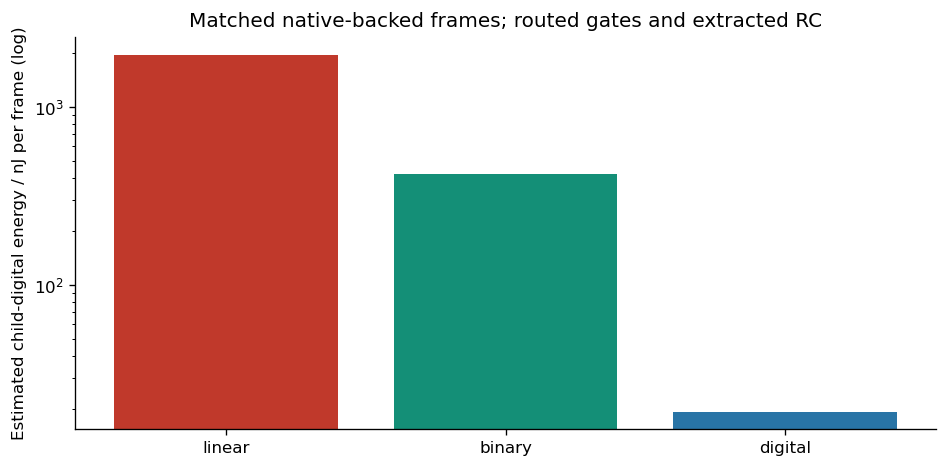

Power scope: readout + MHA or digital attention baseline; analog/SAR-digital, parent CTS/IO and startup excluded


In [155]:
ACTIVITY_POWER=PRIORITY_MODULES['power'].measure(PRIORITY_ROOT,PRIORITY_WORK,PRIORITY_WORK/'activity_power',clock_aware=True)
display(Markdown('| Variant | Native-backed frames | Warm gate latency / us | Estimated child-digital energy / nJ per frame |\n|---|---:|---:|---:|\n'+'\n'.join(f"| {r['variant']} | {r['frames']} | {r['activity_window_s']/r['frames']*1e6:.3f} | {r['child_digital_energy_per_frame_j']*1e9:.3f} |" for r in ACTIVITY_POWER['results'])))
import matplotlib.pyplot as plt
_power_rows=ACTIVITY_POWER['results']
_figure,_axis=plt.subplots(figsize=(8,4))
_axis.bar([r['variant'] for r in _power_rows],[r['child_digital_energy_per_frame_j']*1e9 for r in _power_rows],color=['#c0392b','#148f77','#2874a6'])
_axis.set_yscale('log');_axis.set(ylabel='Estimated child-digital energy / nJ per frame (log)',title='Matched native-backed frames; routed gates and extracted RC')
_figure.tight_layout();plt.show();plt.close(_figure)
print('Power scope: readout + MHA or digital attention baseline; analog/SAR-digital, parent CTS/IO and startup excluded')


**Implementation:** `summarize` regenerates the application confusion matrix, cost/latency figures, paired confidence intervals and a resumable report from this run's records. The bootstrap resamples subjects to preserve dependence between overlapping windows.

**Inputs → outputs and downstream use:** Frozen evaluation records produce figures and a measured conclusion. Learned versus retrained uniform attention is judged with the paired interval; a small point-estimate difference alone is not treated as decisive.

In [156]:
%%priority_module summary
"""Render measured application/RTL comparisons and a resumable progress report."""
from pathlib import Path
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

def summarize(root,work):
    root=Path(root).resolve();work=Path(work).resolve();fig=work/'figures';fig.mkdir(exist_ok=True)
    app=json.loads((work/'application/application_metrics.json').read_text())
    decoder=json.loads((work/'decoder/verification.json').read_text())
    rtl=json.loads((work/'application_rtl/verification.json').read_text())
    costs=json.loads((work/'costs/costs.json').read_text())
    subjects=app['test_subjects'];rng=np.random.default_rng(20261028)
    samples=rng.integers(0,len(subjects),(2000,len(subjects)))
    def f1(cm):
        tp=np.diag(cm);den=cm.sum(0)+cm.sum(1)
        return np.divide(2*tp,den,out=np.zeros(6),where=den!=0).mean()
    bootstrap={}
    for name in app['models']:
        cm=np.array([app['per_subject'][str(s)][name]['confusion_matrix'] for s in subjects])
        vals=np.array([f1(cm[i].sum(0)) for i in samples]);bootstrap[name]=vals
    paired={}
    for name in ('linear_features','uniform_retrained','uniform_frozen','identity_frozen'):
        delta=bootstrap['integer_mha']-bootstrap[name]
        paired[name]={'macro_f1_point_difference':app['models']['integer_mha']['macro_f1']-app['models'][name]['macro_f1'],
            'paired_subject_bootstrap_95_interval':np.quantile(delta,[.025,.975]).tolist(),'bootstrap_replicates':2000,'subjects':9}
    (work/'application/paired_subject_comparison.json').write_text(json.dumps(paired,indent=2)+'\n')
    names=['linear_features','uniform_retrained','integer_mha','float'];labels=['Linear features','Uniform, retrained','AutoMX integer','Float attention']
    fig1,axes=plt.subplots(1,2,figsize=(12,4))
    values=[app['models'][n]['macro_f1']*100 for n in names]
    axes[0].bar(labels,values,color=['#aab7b8','#85c1e9','#148f77','#566573'])
    axes[0].set(ylabel='Test macro-F1 / %',ylim=(0,100),title='Six activities, nine unseen subjects')
    axes[0].tick_params(axis='x',labelrotation=15)
    for i,v in enumerate(values):axes[0].text(i,v+1,f'{v:.2f}',ha='center')
    cm=np.array(app['models']['integer_mha']['confusion_matrix']);axes[1].imshow(cm,cmap='Blues');axes[1].set(title='AutoMX integer confusion matrix',xlabel='Predicted activity',ylabel='True activity',xticks=range(6),yticks=range(6))
    for i in range(6):
        for j in range(6):axes[1].text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    fig1.tight_layout();fig1.savefig(fig/'application_results.png',dpi=160);plt.close(fig1)
    latency=decoder['frame_latency'];fig2,axes=plt.subplots(1,2,figsize=(11,4))
    paths={row['path']:row for row in rtl['results']}
    vals=[paths.get('linear',{}).get('latency_us_mean',latency[0]['latency_us']),paths['binary']['latency_us_mean'],paths['digital']['latency_us_mean']]
    axes[0].bar(['Linear decode','Binary decode','Digital sign/add'],vals,color=['#c0392b','#148f77','#2874a6'])
    axes[0].set(ylabel='RTL frame latency / us',title='Matched HAR inputs, 25 MHz; functional ADC model')
    for i,v in enumerate(vals):axes[0].text(i,v+1,f'{v:.2f}',ha='center')
    mapped={r['design']:r['mapped_area_um2'] for r in costs['designs']}
    keys=['linear_readout','binary_readout','digital_attention'];labels=['Linear readout','Binary readout','Digital MHA + projector']
    axes[1].bar(labels,[mapped[k]/1000 for k in keys],color=['#c0392b','#148f77','#2874a6'])
    axes[1].set(ylabel='Mapped cell area / 1,000 um2',title='Different block scopes; not whole-chip area')
    axes[1].tick_params(axis='x',labelrotation=12);fig2.tight_layout();fig2.savefig(fig/'controller_comparison.png',dpi=160);plt.close(fig2)
    native_path=work/'native_application/verification.json';native=json.loads(native_path.read_text()) if native_path.exists() else None
    hard=[]
    for name in ('digital_blocks/readout/hardening.json','met5_candidate/readout/hardening.json'):
        p=work/name
        if p.exists():hard.append(json.loads(p.read_text()))
    quant=app['models']['integer_mha'];floating=app['models']['float']
    lines=['# AutoMX-CIM priority implementation — 28 October 2026','',
        'Executed in env_mamba. The original successful notebook, source and reports are retained under `experiments/priority_20261028/baseline/`.','',
        '## Results acquired','',
        f"- UCI HAR: {app['test_windows']} test windows, nine subject-disjoint test users, six classes; accuracy {quant['accuracy']*100:.3f}%, macro-F1 {quant['macro_f1']*100:.3f}%.",
        f"- Float macro-F1 {floating['macro_f1']*100:.3f}%; quantized loss {(floating['macro_f1']-quant['macro_f1'])*100:.3f} percentage points. Model selected with validation subjects before test evaluation.",
        f"- All test outputs match the independent integer reference. Actual RTL MHA, binary mixed readout and serial ternary hardware baseline each checked {app['test_windows']} frames / {app['test_windows']*8} output values with zero mismatches.",
        f"- Decoder: {decoder['cases']} exhaustive real-RTL cases; binary search takes {decoder['binary_min_cycles']}-{decoder['binary_max_cycles']} clocks versus 38.",
        f"- Canonical integrated RTL latency at 25 MHz: {latency[0]['latency_us']:.2f} -> {latency[1]['latency_us']:.2f} us, {latency[0]['latency_us']/latency[1]['latency_us']:.3f}x speedup. This uses identical functional ADC response timing, not a concurrent transistor simulation.",
        f"- Mapped readout area: {mapped['linear_readout']:.3f} -> {mapped['binary_readout']:.3f} um2 ({(mapped['binary_readout']/mapped['linear_readout']-1)*100:+.3f}%).",
        f"- Fair digital baseline: {mapped['digital_projection']:.3f} um2 projector and {mapped['digital_attention']:.3f} um2 MHA-plus-projector; mean RTL latency {rtl['results'][-1]['latency_us_mean']:.3f} us. Digital is faster at this tiny configuration; no CIM efficiency advantage is asserted.",'',
        '## Application interpretation','',
        f"Linear-feature macro-F1 is {app['models']['linear_features']['macro_f1']*100:.3f}%. Retrained uniform attention is {app['models']['uniform_retrained']['macro_f1']*100:.3f}%; the small learned-attention gap must be judged with the paired subject interval, not described as a decisive improvement.",
        'Feature extraction, embedding and classification remain software. Only the two-token MHA datapath is the hardware candidate. Circuit-backed frames and the dataset-wide RTL/algorithm evaluation have distinct coverage.','',
        '## Analog interface finding','',
        'Forty native conversions over eight column/phase banks found decreasing raw ADC code with increasing signed sum, whereas the old functional fixture assumed increasing code. The conditioner-to-ADC differential pair was crossed in both the physical top source and the new native worker. New calibration and application measurements use that corrected wiring. Historical partition measurements retain their original orientation and remain separate experiments.','']
    if native:
        lines.extend([f"Native application status: **{native['status']}**; {native['logical_conversions']} logical conversions; {native['unique_native_jobs']} fresh unique simulator jobs including calibration; {native['partial_decode_mismatches']} partial decode errors.",
          f"Native frame output mismatches: {[f['output_mismatches'] for f in native['frames']]}. These are native SAR/transistor measurements followed by measured-code RTL replay, not full-chip transistor co-simulation.",''])
    else:lines.extend(['Native calibration/application campaign is running; no completed native application result is asserted yet.',''])
    for h in hard:lines.append(f"Readout physical candidate: {h.get('status')}; router DRC {h.get('routed_drc_violations')}; TT setup/hold {h.get('setup_slack_ns')}/{h.get('hold_slack_ns')} ns; source `{h.get('source')}`.")
    lines.extend(['','## Measurement sequence','',
       'The electrical/service chapter measures loaded physical pulses, timing-aligned six-frame native coverage, calibration transfer, clock-aware controller cost, resident-state operation and clean extraction. Its reports identify the stimulus and power boundary for each result.','',
       '## Reproduction','',
       'Source entry points: `automx_cim/application_har.py`, `scripts/verify_binary_decoder.py`, `scripts/verify_har_application_rtl.py`, `scripts/measure_priority_costs.py`, `scripts/portable_cim_sar.py`, `scripts/run_har_native.py`. Results/logs: `experiments/priority_20261028/`.',''])
    report=root/'docs/PRIORITY_IMPLEMENTATION_20261028.md';report.write_text('\n'.join(lines))
    print('PRIORITY_REPORT',report,flush=True)
    return {'report':str(report),'figures':str(fig),'paired_subject_comparison':paired}

if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True);a=p.parse_args();summarize(a.root,a.work)


Source ready: scripts/summarize_priority_implementation.py


PRIORITY_REPORT /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/docs/PRIORITY_IMPLEMENTATION_20261028.md


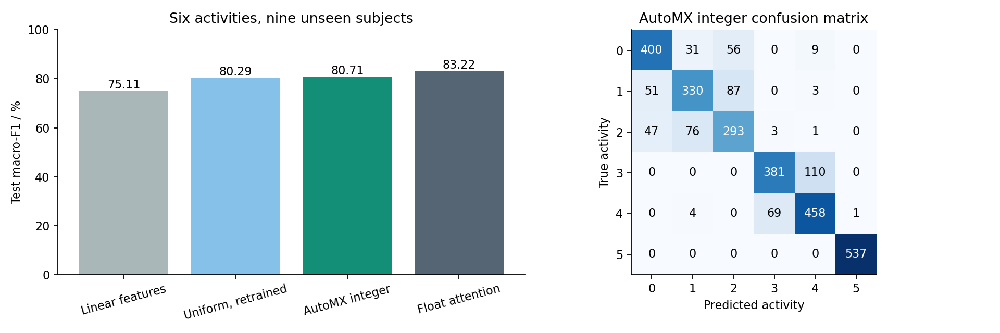

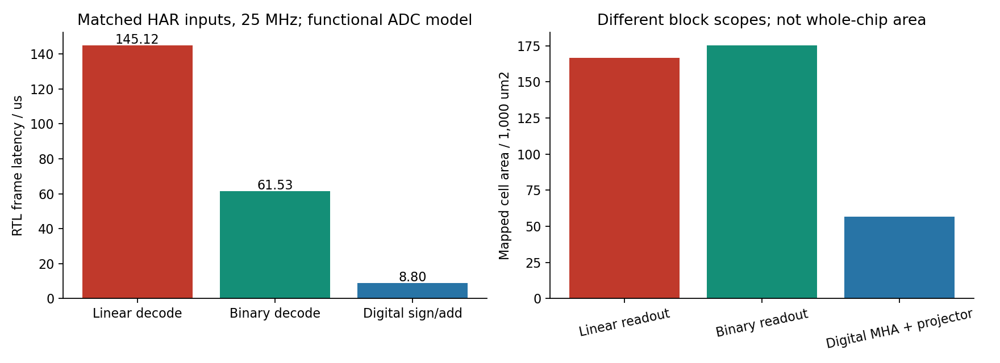

Native ADC transaction identity checks: True | RTL output mismatches: 0


In [157]:
PRIORITY_SUMMARY=PRIORITY_MODULES['summary'].summarize(PRIORITY_ROOT,PRIORITY_WORK)
from IPython.display import Image,display
display(Image(filename=str(PRIORITY_WORK/'figures/application_results.png')))
display(Image(filename=str(PRIORITY_WORK/'figures/controller_comparison.png')))
print('Native ADC transaction identity checks:',NATIVE_REPLAY['native_transaction_identity_checked'],'| RTL output mismatches:',NATIVE_REPLAY['mismatches'])


<a id="electrical-closure"></a>
## Closing the electrical and application contracts

The design argument now tests the assumptions between its layers. A usable activation code must produce a delivered pulse; calibration must transfer between patterns and operating conditions; controller savings must survive actual clock activity; and a sensor decision must include programming, idle and host work. The following experiments retain the complete preceding laboratory and acquire new reports in this run's empty output directory.

Weights reside in controller registers. The eight-NMOS leaf implements product-dependent discharge; the SAR converts the acquired differential signal; the calibrated readout returns integer projections; the MHA IP computes attention/context and requests O. Feature extraction, embedding and the final class head execute in software.

**Implementation:** Register each visible source body as its actual module and write the same body to the native worker path. Definitions have their own namespace and the following run cells invoke those exact definitions. Full native transcripts stay beside the generated measurements; cell outputs show principal results and figures.

**Inputs → outputs and downstream use:** This notebook's source cells and the current fresh-run directory become executable workers and a new `electrical_closure/` report tree. Reusable hard-macro netlist/RC inputs are declared source-matched IP; circuit responses and candidate-top routing are newly acquired.

In [158]:
from pathlib import Path
from IPython.core.magic import register_cell_magic
from IPython.display import display,Markdown,Image
import importlib,json,sys,types,os
import pandas as pd
CLOSURE_ROOT=PRIORITY_ROOT
CLOSURE_WORK=PRIORITY_WORK.parent/'electrical_closure'
CLOSURE_WORK.mkdir(parents=True,exist_ok=False)
CLOSURE_MODULES={}
CLOSURE_SOURCES={'parallel_mim': 'scripts/group_parallel_mim.py', 'reduction': 'scripts/reduce_pex_resistors.py', 'range_core': 'scripts/build_physical_range_core.py', 'parent': 'scripts/qualify_candidate_parent.py', 'final_render': 'scripts/render_closure_top.py', 'pwm_numerics': 'scripts/verify_pwm_numerics.py', 'waveforms': 'scripts/flow2_waveforms.py', 'physical': 'scripts/measure_physical_pwm.py', 'worker': 'scripts/qualified_cim_sar.py', 'stream': 'scripts/qualified_cim_sar_stream.py', 'capture': 'scripts/capture_readout_timing.py', 'campaign': 'scripts/run_electrical_qualification.py', 'replay': 'scripts/replay_qualified_native_rtl.py', 'convergence': 'scripts/verify_native_convergence.py', 'energy': 'scripts/analyze_conversion_energy.py', 'gatepower': 'scripts/measure_clock_gating_power.py', 'clock': 'scripts/check_calibration_clock_activity.py', 'attribution': 'scripts/attribute_readout_power.py', 'comparison': 'scripts/remeasure_activity_power.py', 'area': 'scripts/measure_closure_area.py', 'idle': 'scripts/measure_idle_boot.py', 'wake': 'scripts/verify_idle_wake_service.py', 'service': 'scripts/qualify_har_service.py', 'second': 'scripts/verify_second_configuration.py', 'quick': 'scripts/quick_review.py', 'package': 'scripts/package_mha_ip.py', 'clean': 'scripts/verify_clean_ip_environment.py', 'presentation': 'scripts/summarize_electrical_closure.py', 'compact': 'scripts/compact_core_reference.py', 'compact_native': 'scripts/verify_compact_core_native.py', 'routing_abstract': 'scripts/build_core_routing_abstract.py', 'candidate_eval': 'scripts/evaluate_routed_candidate.py', 'export': 'scripts/export_current_measurements.py', 'margin_budget': 'scripts/measure_margin_budget.py'}
@register_cell_magic
def closure_source(line,cell):
    name=line.strip();relative=CLOSURE_SOURCES[name];path=CLOSURE_ROOT/relative;path.write_text(cell)
    package=importlib.import_module('scripts');module=types.ModuleType('scripts.'+path.stem);module.__file__=str(path)
    sys.modules[module.__name__]=module;setattr(package,path.stem,module)
    exec(compile(cell,str(path),'exec'),module.__dict__);CLOSURE_MODULES[name]=module
    print('Source ready:',relative)
(CLOSURE_WORK/'flow_timer_start.json').write_text(json.dumps({'monotonic_start':FULL_LAB_START_MONOTONIC,'scope':'First code cell to final figure generation'},indent=2)+'\n')
print('Electrical/service output directory:',CLOSURE_WORK)

CLOSURE_JOBS=min(16,os.cpu_count() or 1)
print("Electrical measurement workers:",CLOSURE_JOBS)


Electrical/service output directory: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/runs/fresh_20261029_123523_717579/electrical_closure
Electrical measurement workers: 16


**Implementation:** `verify` compares 140 explicit PDK MIM subcircuits with one parallel-multiplied instance at three electrical conditions. `group` combines only instances that share both terminals and every model parameter, preserving their parallel intrinsic resistor/capacitor behavior. The full extracted netlist and physical device inventory remain available; the compact simulation representation requires the declared zero-mismatch Monte Carlo switch.

| Function and parameters | Operation and downstream result |
|---|---|
| `verify(root, work, copies=140)` | Run actual ngspice current/charge comparisons between 140 explicit MIMs and a parallel-multiplied subcircuit at TT, SS and FF conditions. |
| `group(source, target, proof)` | Group only identical MIM instances on the same terminal pair after the native multiplicity check passes; retain the physical-instance mapping. |

In [159]:
%%closure_source parallel_mim
"""Verify and apply the simulator's exact parallel multiplicity for identical MIMs."""
from pathlib import Path
from collections import defaultdict
import argparse,json,re
import numpy as np

def verify(root,work,copies=140):
    from scripts.portable_cim_sar import SharedSpice
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False);rows=[]
    for name,corner,supply,temp in [('tt','tt',1.8,25),('ss','ss',1.62,70),('ff','ff',1.95,0)]:
        folder=work/name;folder.mkdir();deck=folder/'compare.spice'
        text=['Explicit versus parallel-multiplied PDK MIM',f'.lib "{root}/pdks/analog/sky130A/libs.tech/ngspice/sky130.lib.spice" {corner}',
            '.param MC_MM_SWITCH=0',f'.temp {temp}', '.option klu method=gear reltol=1e-6 abstol=1e-15',
            f'VA A 0 PWL(0 0 1n 0 2n {supply} 5n {supply})',f'VB B 0 PWL(0 0 1n 0 2n {supply} 5n {supply})']
        text.extend(f'X{i} A 0 sky130_fd_pr__cap_mim_m3_1 w=4.2 l=4.2' for i in range(copies))
        text.extend([f'XPAR B 0 sky130_fd_pr__cap_mim_m3_1 w=4.2 l=4.2 m={copies}','.save i(VA) i(VB)','.end']);deck.write_text('\n'.join(text)+'\n')
        with (folder/'ngspice.log').open('w') as log:
            spice=SharedSpice(root/'tools/ngspice/libngspice.so',log)
            for command in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit','source '+str(deck),'option klu','tran 10p 5n 0 20p'):spice.command(command)
            t=spice.vector('time').copy();a=spice.vector('i(VA)').copy();b=spice.vector('i(VB)').copy();assert t[-1]>=4.99e-9
            integral=np.trapezoid if hasattr(np,'trapezoid') else np.trapz
            relative=float(np.max(np.abs(a-b))/(np.max(np.abs(a))+1e-30));area=float(abs(integral(a,t)/integral(b,t)-1))
            rows.append({'condition':name,'max_current_difference_fraction':relative,'charge_difference_fraction':area,'pass':relative<1e-4 and area<1e-5})
            spice.command('destroy all')
    result={'status':'PASS' if all(r['pass'] for r in rows) else 'MIM_MULTIPLICITY_MISMATCH','rows':rows,
        'copies':copies,'scope':f'{copies} explicit PDK MIM R-C subcircuits versus one identical subcircuit with m={copies}; three process/supply/temperature points, MC_MM_SWITCH=0. Both intrinsic series resistors and the capacitor are retained.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('PARALLEL_MIM_EQUIVALENCE',result['status'],rows,flush=True);return result

def group(source,target,proof):
    source=Path(source).resolve();target=Path(target).resolve();check=json.loads(Path(proof).read_text());assert check['status']=='PASS'
    lines=source.read_text().splitlines();groups=defaultdict(list);scope=''
    for i,line in enumerate(lines):
        f=line.split()
        if f and f[0].lower()=='.subckt':scope=f[1]
        if f and f[0].lower()=='.ends':scope=''
        if f and f[0].startswith('X') and 'sky130_fd_pr__cap_mim_m3_1' in f:
            assert not any(v.startswith('m=') for v in f[1:]),line
            groups[(scope,tuple(f[1:]))].append(i)
    replacements={};removed=set();mapping=[]
    for n,((scope,pins),indices) in enumerate(groups.items()):
        if len(indices)==1:continue
        replacements[indices[0]]='XPARALLEL_'+str(n)+' '+' '.join(pins)+' m='+str(len(indices));removed.update(indices[1:])
        mapping.append({'subcircuit':scope,'equivalent':f'XPARALLEL_{n}','multiplicity':len(indices),'original_instances':[lines[i].split()[0] for i in indices]})
    target.write_text('\n'.join(replacements.get(i,line) for i,line in enumerate(lines) if i not in removed)+'\n')
    report={'status':'PASS','source':str(source),'target':str(target),'original_mim_instances':sum(map(len,groups.values())),
        'equivalent_mim_subcircuits':len(groups),'mapping':mapping,'equivalence_proof':str(Path(proof).resolve()),'required_mc_mm_switch':0,
        'scope':'Only identical MIM instances on the same two nodes are grouped. The validated simulator multiplicity retains the parallel intrinsic R-C network; physical GDS and the full extracted netlist remain unchanged.'}
    target.with_suffix('.groups.json').write_text(json.dumps(report,indent=2)+'\n');print('MIM_PARALLEL_GROUPING',report['original_mim_instances'],'->',len(groups),flush=True);return report

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);parser.add_argument('--work',type=Path,required=True);args=parser.parse_args();verify(args.root,args.work)


Source ready: scripts/group_parallel_mim.py


**Implementation:** `reduce` eliminates only internal nodes attached exclusively to resistors. Every transistor, capacitor and interface terminal remains explicit. The star-to-mesh conductances preserve the network at those terminals; `currents` independently compares the original and reduced networks under eight boundary-voltage trials. This algebraic reduction removes solver nodes without replacing circuit responses or dropping physical capacitances.

| Function and parameters | Operation and downstream result |
|---|---|
| `currents(edges, boundary, voltages)` | Solve internal resistor voltages with an independent sparse linear solver and return currents at all protected boundary nodes. |
| `reduce(source, target, max_degree=12)` | Eliminate storage-free internal resistor nodes, retain every device/C/interface terminal, and certify boundary-current equivalence before writing the reduced SPICE. |

In [160]:
%%closure_source reduction
"""Eliminate storage-free internal resistor nodes without discarding devices or C."""
from pathlib import Path
import argparse,heapq,json,re
import numpy as np

def currents(edges,boundary,voltages):
    from scipy.sparse import csc_matrix,eye
    from scipy.sparse.linalg import splu
    nodes=sorted(set(boundary)|{n for a,b,g in edges for n in (a,b)})
    index={n:i for i,n in enumerate(nodes)};rows=[];cols=[];values=[]
    for a,b,g in edges:
        i,j=index[a],index[b];rows.extend([i,j,i,j]);cols.extend([i,j,j,i]);values.extend([g,g,-g,-g])
    matrix=csc_matrix((values,(rows,cols)),shape=(len(nodes),len(nodes)))
    visible=np.array([index[n] for n in boundary]);hidden=np.array([index[n] for n in nodes if n not in set(boundary)],dtype=int)
    out=matrix[visible,:][:,visible]@voltages
    if len(hidden):
        block=matrix[hidden,:][:,hidden]+eye(len(hidden),format='csc')*1e-18
        internal=splu(block).solve(-(matrix[hidden,:][:,visible]@voltages))
        out+=matrix[visible,:][:,hidden]@internal
    return np.asarray(out)

def reduce(source,target,max_degree=12):
    source=Path(source).resolve();target=Path(target).resolve();lines=source.read_text().splitlines();graph={};protected={'0'};original=[]
    def add(a,b,g):
        if a==b:return
        graph.setdefault(a,{})[b]=graph.get(a,{}).get(b,0.)+g
        graph.setdefault(b,{})[a]=graph.get(b,{}).get(a,0.)+g
    for line in lines:
        f=line.split()
        if not f or f[0].startswith(('*','.','+')):continue
        kind=f[0][0].upper()
        if kind=='R':
            assert len(f)==4,f
            a,b=f[1:3];g=1/float(f[3]);add(a,b,g);original.append((a,b,g))
        elif kind=='C':protected.update(f[1:3])
        elif kind=='X':
            model=next((i for i,v in enumerate(f) if v.startswith('sky130_fd_pr__')),len(f)-1)
            protected.update(f[1:model])
        elif kind in ('M','Q','D','V','I','E','G','L'):raise ValueError('Add an explicit terminal parser for '+f[0])
    initial_nodes=set(graph);queue=[(len(graph[n]),n) for n in graph if n not in protected];heapq.heapify(queue);removed=0
    while queue:
        degree,node=heapq.heappop(queue)
        if node not in graph or degree!=len(graph[node]) or degree>max_degree:continue
        neighbors=list(graph[node].items());total=sum(g for n,g in neighbors)
        for i,(a,ga) in enumerate(neighbors):
            for b,gb in neighbors[i+1:]:add(a,b,ga*gb/total)
        for a,g in neighbors:
            del graph[a][node]
            if a not in protected:heapq.heappush(queue,(len(graph[a]),a))
        del graph[node];removed+=1
    reduced=[(a,b,g) for a in sorted(graph) for b,g in sorted(graph[a].items()) if a<b]
    boundary=sorted(protected&initial_nodes)
    voltage=np.random.default_rng(20261029).uniform(-1.8,1.8,(len(boundary),8))
    before=currents(original,boundary,voltage);after=currents(reduced,boundary,voltage)
    error=float(np.max(np.abs(before-after)));relative=float(np.linalg.norm(before-after)/(np.linalg.norm(before)+1e-30))
    assert error<1e-9 and relative<1e-9,(error,relative)
    replacement=[f'RK{i} {a} {b} {1/g:.17g}' for i,(a,b,g) in enumerate(reduced)];output=[];written=False
    for line in lines:
        if re.match(r'^R\S*\s',line):
            if not written:output.extend(replacement);written=True
        else:output.append(line)
    assert written
    target.write_text('\n'.join(output)+'\n')
    report={'status':'PASS','method':'Exact star-mesh elimination of internal resistor-only nodes; every capacitor, transistor and subcircuit interface terminal is protected.',
        'source':str(source),'target':str(target),'original_resistors':len(original),'reduced_resistors':len(reduced),
        'original_resistor_nodes':len(initial_nodes),'remaining_resistor_nodes':len(graph),'eliminated_storage_free_nodes':removed,
        'protected_boundary_nodes':len(boundary),'independent_voltage_trials':8,'max_boundary_current_error_a':error,'relative_boundary_current_error':relative,
        'scope':'Algebraically equivalent passive resistor network with unchanged device/C terminals. Numerical simulator shunts are checked separately by convergence experiments.'}
    target.with_suffix('.reduction.json').write_text(json.dumps(report,indent=2)+'\n')
    print('PEX_RESISTOR_REDUCTION_PASS','nodes',len(initial_nodes),'->',len(graph),'current_error_A',error,flush=True);return report

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--source',type=Path,required=True);parser.add_argument('--target',type=Path,required=True);args=parser.parse_args();reduce(args.source,args.target)


Source ready: scripts/reduce_pex_resistors.py


**Implementation:** `build` draws a PDK MIM leaf, constructs the additional named bitline/ground geometry and emits its reference circuit. `finish_views` requires zero Magic DRC, complete ports and unique transistor LVS before exporting LEF and ordered distributed RC. `check_klayout` reports its independent bounded BEOL/off-grid check. `native` retains each completed tool transcript. Inputs are the original compute/acquisition source GDS and PDK; output is a newly built capacitor-loaded physical core, independently generated in this run.

| Function and parameters | Operation and downstream result |
|---|---|
| `native(args, work, name, env=None, timeout=180)` | Run one native command to completion, retain the full transcript and return elapsed time after checking its exit status. |
| `check_klayout(root, work)` | Execute the independent bounded BEOL/off-grid rule deck and record its actual completed or timeout status. |
| `build(root, work)` | Construct the physical macro or its routing abstract from the declared inputs, check geometry/access, and return the view metadata used by integration. |
| `finish_views(root, work, layout=None, count=None, elapsed=0.0)` | Check extracted ports and unique transistor LVS, then export the actual LEF and ordered distributed RC view. |

In [161]:
%%closure_source range_core
"""Add a physically connected MIM load bank for the measured routed PWM range."""
from pathlib import Path
import argparse,json,os,re,subprocess,time

LAYOUT_SOURCE=r'''import pya,json,re
l=pya.Layout();l.read(src);top=l.top_cell();old_dbu=l.dbu
pins={}
for layer in l.layer_indexes():
 for shape in top.shapes(layer).each():
  if shape.is_text():
   name=shape.text.string;point=[shape.text.x*l.dbu,shape.text.y*l.dbu]
   if name not in pins or point[1]>pins[name][1]:pins[name]=point
text=open(lefsrc).read()
for name,body in re.findall(r'(?ms)^\s*PIN\s+(BL[PN][0-3])\s*\n(.*?)^\s*END\s+\1\s*$',text):
 rects=[tuple(map(float,x)) for x in re.findall(r'RECT\s+([\d.-]+)\s+([\d.-]+)\s+([\d.-]+)\s+([\d.-]+)',body)]
 rect=max(rects,key=lambda x:(x[1]+x[3])/2)
 pins[name]=[(rect[0]+rect[2])/2,(rect[1]+rect[3])/2]
l.read(leaf);assert l.dbu==old_dbu
unit=l.cell('automx_range_mim_unit');assert unit is not None
for layer in l.layer_indexes():
 for shape in list(unit.shapes(layer).each()):
  if shape.is_text():shape.delete()
def box(layer,x1,y1,x2,y2):
 top.shapes(l.layer(*layer)).insert(pya.DBox(x1,y1,x2,y2).to_itype(l.dbu))
def via4(x,y):
 box((71,44),x-.4,y-.4,x+.4,y+.4)
 for layer in ((71,20),(72,20)):box(layer,x-.8,y-.8,x+.8,y+.8)
def via3(x,y):
 box((70,44),x-.1,y-.1,x+.1,y+.1)
 for layer in ((70,20),(71,20)):box(layer,x-.3,y-.3,x+.3,y+.3)
count=0;connections=[]
for column in range(4):
 for polarity in range(2):
  name='BL'+('P' if polarity==0 else 'N')+str(column);ordinal=2*column+polarity
  x0=28+200*column+100*polarity;bus=x0-4;y0=280
  for row in range(14):
   y=y0+7*row
   for col in range(10):
    x=x0+8*col
    top.insert(pya.CellInstArray(unit.cell_index(),pya.Trans(round(x/l.dbu),round(y/l.dbu))))
    via4(x,y);box((71,20),x+2.37,y0-2.3,x+3.17,379)
    count+=1
   box((72,20),bus-.8,y-.8,x0+72+.8,y+.8);via4(bus,y)
  px,py=pins[name];channel=276-2*ordinal
  # Narrow M3 breakouts keep neighboring 1 um-spaced access points isolated.
  box((70,20),px-.2,py-.3,px+.2,channel+.3);via3(px,py);via3(px,channel)
  box((71,20),min(px,bus)-.8,channel-.8,max(px,bus)+.8,channel+.8)
  box((71,20),bus-.8,channel-.8,bus+.8,y0+91+.8)
  connections.append({'net':name,'original_pin_um':[px,py],'new_capacitors':140,'bus_x_um':bus,'channel_y_um':channel})
box((71,20),4,378,807,380)
box((72,20),4.1,158,5.9,379.8);via4(5,379)
top.flatten(True)
assert len(list(l.top_cells()))==1
l.write(out)
report={'added_mim_devices':count,'expected_total_mim_devices':1288,'pins':pins,'connections':connections,'bbox_um':[top.bbox().left*l.dbu,top.bbox().bottom*l.dbu,top.bbox().right*l.dbu,top.bbox().top*l.dbu]}
open(receipt,'w').write(json.dumps(report,indent=2))
'''

def native(args,work,name,env=None,timeout=180):
    start=time.monotonic();result=subprocess.run(list(map(str,args)),cwd=work,env=env,capture_output=True,text=True,timeout=timeout)
    log=Path(work)/(name+'.log');log.write_text(result.stdout+result.stderr)
    assert result.returncode==0,(name,(result.stdout+result.stderr)[-1800:])
    return result.stdout+result.stderr,time.monotonic()-start

def check_klayout(root,work):
    root=Path(root).resolve();work=Path(work).resolve();report=work/'klayout.xml'
    deck=root/'pdks/digital/sky130A/libs.tech/klayout/drc/sky130A_mr.drc'
    from scripts.standalone_runtime import container
    name='automx-core-drc-'+str(os.getpid())
    args=container(root,'klayout',['-b','-r',deck,'-rd','input='+str(work/'core.gds'),'-rd','report='+str(report),'-rd','beol=true','-rd','offgrid=true','-rd','feol=true','-rd','thr=4'],name,work)
    try:native(args,work,'klayout',timeout=45)
    except subprocess.TimeoutExpired as error:
        subprocess.run(['docker','stop','-t','1',name],stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL,timeout=15)
        (work/'klayout.log').write_text('Bounded KLayout BEOL/off-grid run exceeded 45 seconds.\n')
        result={'status':'INCOMPLETE_TIMEOUT','violations':None}
    except AssertionError as error:
        result={'status':'INCOMPLETE_TOOL_ERROR','violations':None,'error':str(error)}
    else:
        from xml.etree import ElementTree as ET
        count=len(list(ET.parse(report).getroot().iter('item')))
        result={'status':'MEASURED_RULES_CLEAN' if count==0 else 'MEASURED_WITH_VIOLATIONS','violations':count}
    (work/'klayout_check.json').write_text(json.dumps(result,indent=2)+'\n');return result

def build(root,work):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    pdk=root/'pdks/analog/sky130A';env=dict(os.environ,PDK_ROOT=str(root/'pdks/analog'))
    magic=['magic','-dnull','-noconsole','-rcfile',pdk/'libs.tech/magic/sky130A.magicrc']
    leaf=work/'leaf';leaf.mkdir();script=leaf/'generate.tcl'
    script.write_text('''crashbackups stop
load automx_range_mim_unit
box values 0 0 0 0
sky130::sky130_fd_pr__cap_mim_m3_1_draw [dict merge [sky130::sky130_fd_pr__cap_mim_m3_1_defaults] {w 4.2 l 4.2 nx 1 ny 1}]
box values -0.2um -0.2um 0.2um 0.2um
label BL center metal4
port make 1
box values 2.6um -0.2um 2.9um 0.2um
label VGND center metal4
port make 2
select top cell
drc on
drc check
drc catchup
puts "MIM_UNIT_DRC=[drc list count total]"
extract all
ext2spice lvs
ext2spice -o unit.spice
gds write unit.gds
quit -noprompt
''')
    log,_=native([*magic,script],leaf,'generation',env);assert 'MIM_UNIT_DRC=0' in log
    for line in log.splitlines():
        if line.startswith('Magic ') or line.startswith('MIM_UNIT_DRC='):print(line.split(' - Compiled')[0],flush=True)
    assert re.search(r'X0 BL VGND .*cap_mim_m3_1', (leaf/'unit.spice').read_text())
    script=work/'layout.py';script.write_text(LAYOUT_SOURCE)
    native(['klayout','-b','-r',script,'-rd','src='+str(root/'inputs/core.gds'),'-rd','lefsrc='+str(root/'inputs/core.lef'),'-rd','leaf='+str(leaf/'unit.gds'),'-rd','out='+str(work/'core.gds'),'-rd','receipt='+str(work/'layout.json')],work,'layout')
    layout=json.loads((work/'layout.json').read_text());assert layout['added_mim_devices']==1120
    reference=(root/'inputs/core_acquisition.spice').read_text();extra=[]
    for c in range(4):
        for pol in ('P','N'):
            extra.extend(f'XRANGE_{pol}{c}_{i} BL{pol}{c} VGND sky130_fd_pr__cap_mim_m3_1 W=4.2 L=4.2' for i in range(140))
    marker='.ends automx_cim_core_acquisition_proto';assert reference.count(marker)==1
    (work/'core_acquisition.spice').write_text(reference.replace(marker,'\n'.join(extra)+'\n'+marker))
    script=work/'extract.tcl';script.write_text(f'''crashbackups stop
gds read {{{work/'core.gds'}}}
load automx_cim_core_acquisition_proto
select top cell
drc on
drc check
drc catchup
puts "RANGE_CORE_DRC=[drc list count total]"
puts "RANGE_CORE_DRC_DETAILS=[drc listall why]"
extract do local
extract all
ext2spice lvs
ext2spice -o {{{work/'physical.spice'}}}
puts RANGE_CORE_EXTRACTION_DONE
quit -noprompt
''')
    log,elapsed=native([*magic,script],work,'extract',env,300)
    count=int(re.search(r'RANGE_CORE_DRC=(\d+)',log)[1])
    return finish_views(root,work,layout,count,elapsed)

def finish_views(root,work,layout=None,count=None,elapsed=0.):
    root=Path(root).resolve();work=Path(work).resolve();pdk=root/'pdks/analog/sky130A'
    env=dict(os.environ,PDK_ROOT=str(root/'pdks/analog'))
    layout=layout or json.loads((work/'layout.json').read_text())
    if count is None:count=int(re.search(r'RANGE_CORE_DRC=(\d+)',(work/'extract.log').read_text())[1])
    assert count==0,('Macro Magic DRC must pass',count)
    from scripts.flow2_adc_partition import ports
    cell='automx_cim_core_acquisition_proto'
    expected=ports((work/'core_acquisition.spice').read_text(),cell);actual=ports((work/'physical.spice').read_text(),cell)
    assert set(actual)==set(expected),('Extracted macro ports differ',actual,expected)
    native(['tclsh',root/'tools/netgen/lib/netgen/tcl/netgen.tcl','-batch','lvs',str(work/'physical.spice')+' '+cell,str(work/'core_acquisition.spice')+' '+cell,pdk/'libs.tech/netgen/sky130A_setup.tcl',work/'lvs.out'],work,'netgen',timeout=180)
    verdict=(work/'lvs.out').read_text();assert 'Circuits match uniquely.' in verdict,verdict[-1800:]
    for line in verdict.splitlines():
        if line.startswith('Final result:'):print(line,flush=True)
    extraction=work/'pex';extraction.mkdir(exist_ok=True);script=extraction/'extract.tcl'
    bbox=' '.join(f'{v:.9g}um' for v in layout['bbox_um'])
    script.write_text(f'''crashbackups stop
+drc off
+gds read {{{work/'core.gds'}}}
+load {cell}
+select top cell
+snap internal
+box values {bbox}
+property FIXED_BBOX [box values]
+lef write {{{work/'core.lef'}}}
+flatten {cell}_raw
+load {cell}_raw
+select top cell
+extract do local
+extract do unique
+extract do resistance
+extract all
+ext2sim labels on
+ext2sim
+extresist tolerance 10
+extresist all
+ext2spice lvs
+ext2spice scale off
+ext2spice cthresh 0.01
+ext2spice extresist on
+ext2spice short resistor
+ext2spice subcircuit on
+ext2spice subcircuit top on
+ext2spice -o {{{extraction/'raw.spice'}}}
+puts RANGE_CORE_RC_READY
+quit -noprompt
+'''.replace('\n+','\n'))
    log,pex_elapsed=native(['magic','-dnull','-noconsole','-rcfile',pdk/'libs.tech/magic/sky130A.magicrc',script],extraction,'extract',env,300)
    assert 'RANGE_CORE_RC_READY' in log
    text=(extraction/'raw.spice').read_text();actual=ports(text,cell+'_raw');assert set(actual)==set(expected),(actual,expected)
    text=re.sub(r'(?im)^\s*\.end\s*$','',text)
    ordered='\n.subckt '+cell+'_pex '+' '.join(expected)+'\nXRAW '+' '.join(actual)+' '+cell+'_raw\n.ends '+cell+'_pex\n'
    (work/'core_acquisition.pex.spice').write_text(text.rstrip()+ordered)
    from scripts.reduce_pex_resistors import reduce
    reduction=reduce(work/'core_acquisition.pex.spice',work/'core_acquisition.fast.pex.spice')
    from scripts.group_parallel_mim import verify,group
    parallel=verify(root,work/'parallel_mim_equivalence');assert parallel['status']=='PASS',parallel
    grouping=group(work/'core_acquisition.fast.pex.spice',work/'core_acquisition.grouped.pex.spice',work/'parallel_mim_equivalence/verification.json')
    rc={'resistors':len(re.findall(r'(?im)^R\S*\s',text)),'capacitors':len(re.findall(r'(?im)^C\S*\s',text))}
    assert rc['resistors']>0 and rc['capacitors']>0,rc
    lef=(work/'core.lef').read_text();lef_pins=re.findall(r'(?m)^\s*PIN\s+(\S+)\s*$',lef);assert set(lef_pins)==set(expected),(lef_pins,expected)
    size=re.search(r'\bSIZE\s+([\d.]+)\s+BY\s+([\d.]+)',lef);assert size
    dimensions=list(map(float,size.groups()));bbox=layout['bbox_um']
    assert all(abs(a-b)<.001 for a,b in zip(dimensions,[bbox[2]-bbox[0],bbox[3]-bbox[1]])),('LEF/GDS bounding boxes differ',dimensions,bbox)
    klayout=check_klayout(root,work)
    report={'status':'PHYSICAL_CORE_DRC_LVS_PEX_READY','views_dir':str(work),'added_bitline_mim_per_node':140,'total_bitline_mim_per_node':160,
        'macro_dimensions_um':dimensions,'magic_drc':count,'transistor_lvs':'PASS','layout':layout,'elapsed_extract_s':elapsed,'elapsed_pex_s':pex_elapsed,'distributed_rc_elements':rc,
        'klayout_beol_offgrid':klayout,
        'exact_resistor_reduction':reduction,'parallel_mim_equivalence':parallel,'parallel_mim_grouping':grouping,
        'scope':'Actual additional MIM geometry, named bitline/ground wiring, complete transistor LVS and distributed Magic RC. Electrical range/calibration and parent physical checks must pass before adoption.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    from scripts.compact_core_reference import compact
    compacted=compact(root,work/'core_acquisition.spice',work/'compact_reference')
    from scripts.verify_compact_core_native import run as verify_compact
    native_equivalence=verify_compact(root,work/'core_acquisition.spice',compacted['schematic'],work/'compact_native_check')
    assert native_equivalence['status']=='PASS',native_equivalence
    from scripts.build_core_routing_abstract import build as routing_abstract
    routed=routing_abstract(root,work,work/'routing_views')
    (work/'routing_views/core_acquisition.compact.spice').symlink_to(compacted['schematic'])
    routed['native_reference_compaction']=compacted
    routed['native_compaction_verification']=native_equivalence
    (work/'routing_views/verification.json').write_text(json.dumps(routed,indent=2)+'\n')
    print('PHYSICAL_RANGE_CORE_PASS','Magic_DRC',count,'transistor_LVS=PASS','MIM_total=1288','RC',rc,flush=True);return routed

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);parser.add_argument('--work',type=Path,required=True);parser.add_argument('--finish',action='store_true');args=parser.parse_args();finish_views(args.root,args.work) if args.finish else build(args.root,args.work)


Source ready: scripts/build_physical_range_core.py


**Implementation:** `run` routes a fresh five-block parent using the selected source-matched readout/MHA views and newly built core. `Flow.run` records each completed tool command; `item` describes its file artifact. The checks include rails, extracted hierarchical TT timing, signal macro-boundary LVS and streamout geometry. Core transistor LVS belongs to the preceding macro experiment. This final physical parent supplies the RC and GDS used by the next pulse measurement and render.

| Function and parameters | Operation and downstream result |
|---|---|
| `item(path)` | Describe an existing file and size for the tool receipt without changing its contents. |
| `Flow.__init__(self, root, work)` | Initialize the isolated physical experiment root, output map and completed-command receipts. |
| `Flow.run(self, name, args, inputs=(), outputs=(), cwd=None, timeout_s=180)` | Execute a native tool command to completion, retain its transcript, and require declared output files before returning. |
| `run(root, readout, work, core_views=None, upsize_wordline_buffers=None)` | `run` routes a fresh five-block parent using the selected source-matched readout/MHA views and newly built core. `Flow.run` records each completed tool command; `item` describes its file artifact. The checks include rails, extracted hierarchical TT timing, signal macro-boundary LVS and streamout geometry. Core transistor LVS belongs to the preceding macro experiment. This final physical parent supplies the RC and GDS used by the next pulse measurement and render. |

In [162]:
%%closure_source parent
"""Route and check an isolated five-block parent using a candidate readout view."""
from pathlib import Path
import argparse,json,os,subprocess,sys,time,types
from scripts import standalone_runtime as runtime

WORDLINE_BUFFER_REPAIR_TCL=r'''source $::env(SCRIPTS_DIR)/openroad/common/io.tcl
read
set block [ord::get_db_block]
set strong [[ord::get_db] findMaster sky130_fd_sc_hd__buf_16]
set core [$block findInst core_i]
set queue {}
foreach polarity {P N} {
    for {set row 0} {$row<4} {incr row} {
        lappend queue [[$core findITerm WL$polarity$row] getNet]
    }
}
set visited {};set changed {};set boundaries 0
while {[llength $queue]} {
    set net [lindex $queue 0];set queue [lrange $queue 1 end]
    set name [$net getName]
    if {[dict exists $visited $name]} {continue}
    dict set visited $name 1
    foreach pin [$net getITerms] {
        if {[[$pin getMTerm] getIoType] ne "OUTPUT"} {continue}
        set inst [$pin getInst];set instname [$inst getName]
        if {$instname eq "seq_i"} {incr boundaries;continue}
        set model [[$inst getMaster] getName]
        if {![regexp {^sky130_fd_sc_hd__(buf|clkbuf|dlymetal)[_0-9a-z]*$} $model]} {
            error "Refuse to replace non-buffer on delivered-wordline cone: $instname $model"
        }
        if {![dict exists $changed $instname]} {
            if {![$inst swapMaster $strong]} {error "Wordline buffer resize failed: $instname"}
            dict set changed $instname $model
            set_dont_touch [get_cells $instname]
        }
        lappend queue [[$inst findITerm A] getNet]
    }
}
if {$boundaries!=8 || [dict size $changed]<8} {error "Expected eight complete wordline buffer cones"}
detailed_placement
check_placement -verbose
puts "WORDLINE_BUFFER_DRIVE_REPAIR boundaries=$boundaries buffers=[dict size $changed] master=sky130_fd_sc_hd__buf_16"
write
'''

CORE_PARENT_PDN_CLEANUP_TCL = '# Remove only redundant parent PG shapes strictly inside the hard core.\n# The core\'s physical rails remain untouched; native macro LVS proves them.\nproc automx_core_parent_pdn_cleanup {} {\n    set block [ord::get_db_block]\n    set tech [ord::get_db_tech]\n    set u [$block getDbUnitsPerMicron]\n    set core [$block findInst core_i]\n    set b [$core getBBox]\n    set bounds [list [$b xMin] [$b yMin] [$b xMax] [$b yMax]]\n    foreach inst [$block getInsts] {\n        if {[[$inst getMaster] isBlock] || [$inst getPlacementStatus] == "NONE"} {continue}\n        set ib [$inst getBBox]\n        if {[automx_overlaps $bounds [list [$ib xMin] [$ib yMin] [$ib xMax] [$ib yMax]]]} {\n            error "Refuse PDN cleanup over a placed standard cell: [$inst getName]"\n        }\n    }\n    set remove {}\n    foreach name {VPWR VGND} {\n        foreach wire [[ $block findNet $name] getSWires] {\n            foreach shape [$wire getWires] {\n                if {[automx_covers $bounds [list [$shape xMin] [$shape yMin] [$shape xMax] [$shape yMax]]]} {\n                    lappend remove $shape\n                }\n            }\n        }\n    }\n    foreach shape $remove {odb::dbSBox_destroy $shape}\n    # This M5 landing lies on the additive core\'s actual VGND spine, checked\n    # against its GDS. The other end lands on the continuous external M4 rail.\n    set ground [$block findNet VGND]\n    set wire [lindex [$ground getSWires] 0]\n    set m5 [$tech findLayer met5]\n    set via [$tech findVia M4M5_PR]\n    set plate {24.34 203.92 51.9 205.52}\n    foreach shape [automx_special_shapes $block met5] {\n        if {[lindex $shape 0] ne "VGND" && [automx_overlaps [lrange $shape 1 4] [automx_dbu $u $plate 1.6]]} {\n            error "New core ground plate conflicts with [lindex $shape 0]"\n        }\n    }\n    odb::dbSBox_create $wire $m5 {*}[automx_dbu $u $plate] STRIPE 1\n    odb::dbSBox_create $wire $via [expr {round(25.14*$u)}] [expr {round(204.72*$u)}] STRIPE\n    puts "CORE_PARENT_PDN_CLEANUP removed=[llength $remove] independent_macro_rails_retained=1 external_ground_M5=$plate"\n}\nrename automx_ground_bridges automx_ground_bridges_before_core_cleanup\nproc automx_ground_bridges {} {\n    automx_ground_bridges_before_core_cleanup\n    automx_core_parent_pdn_cleanup\n}\n'

def item(path):
    path=Path(path);return {'path':str(path),'bytes':path.stat().st_size if path.is_file() else None}

class Flow:
    def __init__(self,root,work):self.root=Path(root).resolve();self.work=Path(work).resolve();self.outputs={};self.receipts={}
    def run(self,name,args,inputs=(),outputs=(),cwd=None,timeout_s=180):
        cwd=Path(cwd or self.work);log=cwd/(name+'.native.log');started=time.monotonic()
        try:
            with log.open('w') as stream:q=subprocess.run(list(map(str,args)),cwd=cwd,stdout=stream,stderr=subprocess.STDOUT,timeout=timeout_s)
            code=q.returncode
        except subprocess.TimeoutExpired:code=124
        report={'returncode':code,'elapsed_s':time.monotonic()-started,'log':item(log),'command':list(map(str,args))}
        (cwd/(name+'.step.json')).write_text(json.dumps(report,indent=2)+'\n')
        if code:raise RuntimeError(f'{name}: exit {code}; {log}')
        assert all(Path(p).is_file() for p in outputs),(name,outputs)
        print('PARENT_CHECK',name,'PASS',round(report['elapsed_s'],2),flush=True);return report

def run(root,readout,work,core_views=None,upsize_wordline_buffers=None):
    root=Path(root).resolve();readout=Path(readout).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    started=time.monotonic()
    while not readout.is_file():
        if time.monotonic()-started>5400:raise TimeoutError('Candidate hardening not complete')
        time.sleep(5)
    ro=json.loads(readout.read_text());assert ro['status']=='PASS'
    assert ro['setup_slack_ns']>=0 and ro['hold_slack_ns']>=0,('Child timing must pass before parent qualification',ro)
    library=root/'inputs/digital_blocks';frozen=json.loads((library/'source_library.json').read_text())
    mha=next(dict(v) for v in frozen['blocks'] if v['name']=='mha')
    for key in ('source','gds','lef','odb','lib','mapped_netlist','spef'):mha[key]=str(library/mha[key])
    blocks=[ro,mha];(work/'digital_blocks').mkdir(exist_ok=True)
    (work/'digital_blocks/hardening.json').write_text(json.dumps({'status':'PASS','blocks':blocks},indent=2)+'\n')
    design,config=runtime.prepare_pnr(root,work,blocks)
    if core_views:
        core_views=Path(core_views).resolve()
        core=json.loads((core_views/'verification.json').read_text());assert core['status']=='PHYSICAL_CORE_DRC_LVS_PEX_READY'
        config['EXTRA_LEFS'][0]=str(core_views/'core.lef');config['EXTRA_GDS_FILES'][0]=str(core_views/'core.gds')
        (design/'config.json').write_text(json.dumps(config,indent=2)+'\n')
        if core.get('parent_pg_cleanup_required'):
            policy=Path(config['FP_PDN_CFG']);policy.write_text(policy.read_text()+CORE_PARENT_PDN_CLEANUP_TCL)
    name='automx-closure-parent-'+str(os.getpid())
    policy=root/'inputs/wordline_routing_policy.json'
    if upsize_wordline_buffers is None:
        upsize_wordline_buffers=policy.is_file() and json.loads(policy.read_text()).get('upsize_wordline_buffers',False)
    if upsize_wordline_buffers:
        repair=work/'wordline_buffer_repair.tcl';repair.write_text(WORDLINE_BUFFER_REPAIR_TCL)
        script=work/'route_wordline_repair.tcl'
        script.write_text('lappend ::auto_path /openlane/scripts\npackage require openlane\nprep -design {'+str(design)+'} -config_file {'+str(design/'config.json')+'} -tag cold\n'+
            'set ::env(AUTOMX_WORDLINE_REPAIR) {'+str(repair)+'}\n'+r'''
rename run_resizer_timing_routing run_resizer_timing_routing_before_wordline
proc run_resizer_timing_routing {args} {
    run_resizer_timing_routing_before_wordline {*}$args
    run_openroad_script $::env(AUTOMX_WORDLINE_REPAIR) -indexed_log $::env(routing_logs)/wordline_drive.log -save "dir=$::env(routing_tmpfiles),def,sdc,odb,netlist,powered_netlist"
}
run_synthesis
run_floorplan
run_placement
run_cts
run_resizer_timing
run_routing
run_magic
run_klayout
save_final_views
save_state
puts WORDLINE_DRIVE_PARENT_ROUTED
''')
        arguments=['-interactive','-file',script]
    else:arguments=['-design',design,'-config_file',design/'config.json','-tag','cold']
    args=runtime.container(root,'/openlane/flow.tcl',arguments,name,'/openlane')
    log=design.parent/'native.log';stream=log.open('w');process=subprocess.Popen(args,stdout=stream,stderr=subprocess.STDOUT)
    runtime.PNR={'process':process,'stream':stream,'command':args,'log':log,'started':time.monotonic(),'design':design,'run':design/'runs/cold','config':config,'name':name,'root':root}
    support=types.ModuleType('automx_nb_inline_v1.support');support.item=item
    sys.modules['automx_nb_inline_v1.support']=support
    flow=Flow(root,work)
    runtime.wait_pnr(flow);runtime.streamout(flow);runtime.power(flow);runtime.lvs(flow);runtime.hierarchical_timing(flow)
    timing=flow.outputs['nominal_timing'];assert timing['setup_slack_ns']>=0 and timing['hold_slack_ns']>=0,timing
    if upsize_wordline_buffers:
        import re
        drive_log=design/'runs/cold/logs/routing/wordline_drive.log'
        found=re.search(r'WORDLINE_BUFFER_DRIVE_REPAIR boundaries=8 buffers=(\d+) master=sky130_fd_sc_hd__buf_16',drive_log.read_text())
        assert found and int(found[1])>=8,'Missing executed wordline drive repair'
        print(found[0],flush=True)
    runtime.audit_gds(flow)
    report={'status':'PASS','elapsed_s':time.monotonic()-started,'outputs':flow.outputs,'readout_source':ro['source'],'core_views':str(core_views) if core_views else None,'wordline_buffer_drive_repair':bool(upsize_wordline_buffers),'scope':'Fresh isolated five-block parent; actual RC hierarchical TT STA, rails and signal macro-boundary LVS. Bounded foundry DRC status is reported separately.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('CANDIDATE_PARENT_PASS',json.dumps(timing),flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--readout',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--core-views',type=Path);a=p.parse_args();run(a.root,a.readout,a.work,a.core_views)


Source ready: scripts/qualify_candidate_parent.py


**Implementation:** `render` writes the complete visible KLayout program, fixes the SKY130 layer palette, and creates final-top overview/detail images. Two independent overview exports must match every pixel. Inputs are this execution’s final parent GDS; outputs are PNGs, geometry/layer metadata and native transcripts.

| Function and parameters | Operation and downstream result |
|---|---|
| `render(root, gds, work)` | Export actual final-top overview/detail PNGs with fixed layer colors and compare two independently rendered overviews pixel for pixel. |

In [163]:
%%closure_source final_render
"""Render the final physical top twice with a fixed layer palette and inspect pixels."""
from pathlib import Path
import argparse,json,os,subprocess
from PIL import Image,ImageChops

RENDER_PROGRAM=r'''
"""Deterministic SKY130 routing overview; raw GDS geometry is unchanged."""
import os,json
from pathlib import Path
import pya

gds=Path(os.environ['AUTOMX_GDS']);png=Path(os.environ['AUTOMX_PNG'])
app=pya.Application.instance();window=app.main_window()
if window is None:raise RuntimeError('KLayout -z with offscreen Qt required')
window.load_layout(str(gds),1);view=window.current_view();cv=view.active_cellview()
cell=cv.layout().cell(os.environ.get('AUTOMX_TOP','automx_cim_mixed_signal_proto'))
if cell is None:raise RuntimeError('requested top missing')
cv.cell=cell;view.add_missing_layers();view.max_hier()
view.set_config('background-color','#ffffff')
view.set_config('grid-visible','false');view.set_config('text-visible','false')
view.set_config('cell-boxes-visible','false')
palette={65:0xb59b7b,66:0xc44e52,67:0x718096,68:0x3979a8,69:0xb45560,
         70:0x3e8c72,71:0x8270a4,72:0xb7953e}
is_top=cell.name=='automx_cim_mixed_signal_proto'
mode=os.environ.get('AUTOMX_RENDER_MODE','overview')
iterator=view.begin_layers();shown=[]
while not iterator.at_end():
    layer=iterator.current();number=layer.source_layer;datatype=layer.source_datatype
    layer.visible=number in palette and datatype in (20,44) and (not is_top or number >= (70 if mode=='overview' else 68))
    if layer.visible:
        layer.fill_color=palette[number];layer.frame_color=palette[number]
        layer.dither_pattern=1 if datatype==20 else 0
        layer.line_style=0;layer.width=1
        shown.append([number,datatype])
    view.set_layer_properties(iterator,layer);iterator.next()
box=cell.dbbox()
if box.empty():raise RuntimeError('empty GDS geometry')
margin=.02*max(box.width(),box.height())
view.zoom_box(pya.DBox(box.left-margin,box.bottom-margin,box.right+margin,box.top+margin))
png.parent.mkdir(parents=True,exist_ok=True)
width=int(os.environ.get('AUTOMX_WIDTH','2400'))
height=max(500,min(2400,round(width*(box.height()+2*margin)/(box.width()+2*margin))))
view.save_image(str(png),width,height)
if not png.is_file() or png.read_bytes()[:8]!=b'\x89PNG\r\n\x1a\n':raise RuntimeError('PNG export failed')
geometry={'top':cell.name,'cells':cv.layout().cells(),'width_um':box.width(),'height_um':box.height(),
          'render_style':('fixed SKY130 met3–met5 overview' if mode=='overview' else 'fixed SKY130 met1–met5 detail') if is_top else 'fixed SKY130 device/metal view',
          'shown_layers':sorted(shown),'labels_visible':False,'geometry_modified':False}
png.with_suffix('.render.json').write_text(json.dumps(geometry,indent=2))
if os.environ.get('AUTOMX_GEOMETRY'):Path(os.environ['AUTOMX_GEOMETRY']).write_text(json.dumps(geometry,indent=2))
print('KLayout',app.version(),'GDS_READ_AND_RENDER',json.dumps(geometry),flush=True)
app.exit(0)

'''

def render(root,gds,work):
    root=Path(root).resolve();gds=Path(gds).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    script=work/'render.py';script.write_text(RENDER_PROGRAM);images={}
    for label,mode in [('overview','overview'),('overview_repeat','overview'),('detail','detail')]:
        png=work/(label+'.png');env=dict(os.environ,QT_QPA_PLATFORM='offscreen',AUTOMX_GDS=str(gds),AUTOMX_PNG=str(png),AUTOMX_TOP='automx_cim_mixed_signal_proto',AUTOMX_RENDER_MODE=mode)
        result=subprocess.run(['klayout','-z','-x','-r',str(script)],cwd=root,env=env,capture_output=True,text=True,timeout=180)
        (work/(label+'.log')).write_text(result.stdout+result.stderr);assert result.returncode==0,(result.stdout+result.stderr)[-1200:]
        if label!='overview_repeat':
            for line in result.stdout.splitlines():
                if line.startswith('KLayout '):print(line,flush=True)
        assert png.is_file();images[label]=str(png)
    with Image.open(images['overview']) as a,Image.open(images['overview_repeat']) as b:
        assert a.size==b.size and ImageChops.difference(a.convert('RGB'),b.convert('RGB')).getbbox() is None
    report={'status':'PASS','gds':str(gds),'images':images,'overview_repeat_pixel_equal':True,'scope':'Actual final GDS, fixed SKY130 layer/color configuration; two independent overview renders match every pixel.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('FINAL_TOP_KLAYOUT_RENDER_PASS','overview/detail; repeat pixel equal',flush=True);return report

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);parser.add_argument('--gds',type=Path,required=True);parser.add_argument('--work',type=Path,required=True);args=parser.parse_args();render(args.root,args.gds,args.work)


Source ready: scripts/render_closure_top.py


**Implementation:** `characterize` measures width, voltage-time area and peak from actual vectors. `run` repeats four row/sign/size samples with finer transistor integration and compares the practical settings. The declared sampled tolerances concern numerical integration, not process yield or noise.

| Function and parameters | Operation and downstream result |
|---|---|
| `characterize(raw, node)` | Measure delivered-pulse width, voltage-time integral and peak from the numerical transient vectors. |
| `run(root, pwm, work, jobs=4)` | `characterize` measures width, voltage-time area and peak from actual vectors. `run` repeats four row/sign/size samples with finer transistor integration and compares the practical settings. The declared sampled tolerances concern numerical integration, not process yield or noise. |

In [164]:
%%closure_source pwm_numerics
"""Compare the practical pulse-cone integration with independent finer transients."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import argparse,json,shutil,subprocess,sys
import numpy as np
from scripts.flow2_waveforms import read_raw

def characterize(raw,node):
    t=raw['time'];v=raw['v('+node.lower()+')'];high=(t>4e-9)&(v>.9)
    edges=[]
    for i in np.flatnonzero(np.diff(high.astype(int))):
        if t[i]>=4e-9:edges.append(t[i]+(.9-v[i])*(t[i+1]-t[i])/(v[i+1]-v[i]))
    width=(edges[1]-edges[0])*1e12 if len(edges)>=2 else 0.
    keep=t>4e-9
    area=float(np.trapezoid(v[keep],t[keep]) if hasattr(np,'trapezoid') else np.trapz(v[keep],t[keep]))
    return {'width_ps':width,'area_v_s':area,'peak_v':float(v[keep].max())}

def run(root,pwm,work,jobs=4):
    root=Path(root).resolve();pwm=Path(pwm).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    original=json.loads((pwm/'verification.json').read_text());nodes=original['cone']['output_nodes']
    selected=[r for r in original['measurements'] if (r['row'],r['negative'],r['magnitude']) in [(0,False,1),(0,False,12),(3,True,1),(3,True,12)]]
    assert len(selected)==4
    def one(row):
        folder=work/f"row{row['row']}_{'n' if row['negative'] else 'p'}_{row['magnitude']}";folder.mkdir()
        shutil.copy2(Path(row['folder'])/'pulse.spice',folder/'pulse.spice')
        args=[sys.executable,str(root/'scripts/measure_physical_pwm.py'),'--worker',str(folder),'--library',str(root/'tools/ngspice/libngspice.so'),'--max-step-ps','25','--reltol','0.0001']
        with (folder/'console.log').open('w') as log:result=subprocess.run(args,cwd=root,stdout=log,stderr=subprocess.STDOUT,timeout=900)
        assert result.returncode==0,(folder,(folder/'console.log').read_text()[-1000:])
        node=nodes['WL'+('N' if row['negative'] else 'P')+str(row['row'])]
        coarse=characterize(read_raw(Path(row['folder'])/'pulse.raw'),node);fine=characterize(read_raw(folder/'pulse.raw'),node)
        width=abs(coarse['width_ps']-fine['width_ps']);area=abs(coarse['area_v_s']/fine['area_v_s']-1)
        return {'row':row['row'],'negative':row['negative'],'magnitude':row['magnitude'],'practical':coarse,'fine':fine,
            'width_difference_ps':width,'relative_area_difference':area,'pass':bool(width<=max(10.,.02*fine['width_ps']) and area<=.01)}
    with ThreadPoolExecutor(max_workers=jobs) as pool:rows=list(pool.map(one,selected))
    result={'status':'PASS' if all(r['pass'] for r in rows) else 'NUMERICAL_SENSITIVITY','rows':rows,
        'scope':'Four actual routed-cone early/late-sign samples: practical max step 100 ps/reltol 1e-3 versus 25 ps/1e-4. Acceptance: <=1% pulse voltage-area change and <=max(10 ps,2%) width change. A sampled numerical check, not noise/yield qualification.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('PWM_NUMERICAL_SENSITIVITY',result['status'],flush=True);return result

if __name__=='__main__':
    parser=argparse.ArgumentParser();parser.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);parser.add_argument('--pwm',type=Path,required=True);parser.add_argument('--work',type=Path,required=True);parser.add_argument('--jobs',type=int,default=4);args=parser.parse_args();run(args.root,args.pwm,args.work,args.jobs)


Source ready: scripts/verify_pwm_numerics.py


**Implementation:** `read_raw` parses the actual ngspice time/vector records without replacing samples. `completed_run_log` checks the native completion marker, `sample` interpolates a named vector, `sampling_witness` checks a switching window, and `control_block` emits saved-vector directives. These helpers retain coordinate and unit information used by the following delivered-pulse measurement and V×I integrations. Input is a newly generated native raw file; output is named numerical arrays for contract/error/energy checks.

| Function and parameters | Operation and downstream result |
|---|---|
| `completed_run_log(log: str, *, phase: str)` | Require the actual ngspice phase/completion marker and reject a truncated transcript. |
| `read_raw(path: Path)` | Parse ngspice vector names and numerical samples while retaining their native units. |
| `sample(vectors: dict, name: str, at_s: float)` | Interpolate a named measured vector at an explicitly specified time in seconds. |
| `sampling_witness(vectors: dict, probes: dict, *, start_s=8e-09, stop_s=1.2e-08, high_v=1.62, low_v=0.18)` | Check measured high/low levels over a switching window; return the acquisition witness. |
| `control_block(vectors: list[str], *, filename='probe.raw', phase='PROBE')` | Generate the saved-vector and completion directives that make a native run inspectable. |

In [165]:
%%closure_source waveforms
"""Read real ngspice ASCII raw files and evaluate aligned, nonloading probes.

No simulator is called by this module. A gate witness is computed at the
same saved time in every vector, never from maxima reached at different times.
"""
from __future__ import annotations

from pathlib import Path
import math
import re

import numpy as np


def completed_run_log(log: str, *, phase: str) -> tuple[str, dict]:
    """Select the run that produced the raw file, excluding a later batch run.

    ngspice -b may run .tran again after .control returns. The exported raw
    belongs to the explicit run before RUN_RETURNED, not to that later run.
    Ambiguous/missing markers fail closed rather than choosing a result.
    """
    if not re.fullmatch(r"[A-Z0-9_]+", phase):
        raise ValueError("invalid waveform phase")
    positions = {}
    for name in ("RUN_ENTER", "RUN_RETURNED", "RAW_WRITTEN"):
        found = list(re.finditer(rf"(?m)^AUTOMX_{phase}_PHASE={name}\s*$", log))
        if len(found) != 1:
            raise ValueError(f"missing or ambiguous waveform marker: {name}")
        positions[name] = found[0]
    if not (positions["RUN_ENTER"].start() < positions["RUN_RETURNED"].start()
            < positions["RAW_WRITTEN"].start()):
        raise ValueError("waveform markers are out of order")
    selected = log[:positions["RUN_RETURNED"].end()]
    count = len(re.findall(r"(?m)^\s*Measurements for Transient Analysis\s*$", selected))
    if count != 1:
        raise ValueError("expected exactly one measurement block for the exported waveform")
    return selected, {"source": "EXPLICIT_CONTROL_RUN_THAT_WROTE_RAW",
        "selected_measurement_blocks": count,
        "excluded_later_measurement_blocks": len(re.findall(
            r"(?m)^\s*Measurements for Transient Analysis\s*$", log[positions["RAW_WRITTEN"].end():])),
        "scope": "later automatic batch runs are retained in the log but not mixed with this raw"}


def read_raw(path: Path) -> dict[str, np.ndarray]:
    """Read the single real transient plot written by ``set filetype=ascii``.

    Reject incomplete, complex, binary, duplicate and nonfinite evidence.
    Bounds prevent a corrupt header from allocating an unbounded array.
    """
    with Path(path).open(encoding="utf-8", errors="strict") as stream:
        headers = {}
        for line in stream:
            key, sep, value = line.partition(":")
            if not sep:
                raise ValueError("invalid raw header")
            key = key.strip().lower()
            if key == "variables":
                break
            headers[key] = value.strip()
        else:
            raise ValueError("raw file has no variable table")
        if headers.get("flags", "").split() != ["real"]:
            raise ValueError("a real ASCII raw plot is required")
        if "transient" not in headers.get("plotname", "").lower():
            raise ValueError("a transient plot is required")
        try:
            nv, np_ = int(headers["no. variables"]), int(headers["no. points"])
        except (KeyError, ValueError) as error:
            raise ValueError("invalid raw dimensions") from error
        if not 2 <= nv <= 256 or not 2 <= np_ <= 5_000_000 or nv*np_ > 10_000_000:
            raise ValueError("raw dimensions exceed the diagnostic limits")
        names = []
        for index in range(nv):
            parts = stream.readline().split()
            if len(parts) != 3 or parts[0] != str(index):
                raise ValueError("invalid raw variable index")
            names.append(parts[1].lower())
        if len(names) != len(set(names)) or names[0] != "time":
            raise ValueError("raw variables must be unique and start with time")
        if stream.readline().strip().lower() != "values:":
            raise ValueError("raw data must use ASCII Values, not Binary")
        values = np.empty((np_, nv), dtype=float)
        for point in range(np_):
            for var in range(nv):
                line = stream.readline()
                # ngspice 31 writes a blank separator after every complete
                # point. Skip separators only here, never within its values:
                # a missing scalar must still be treated as truncated data.
                if var == 0:
                    while line and not line.strip():
                        line = stream.readline()
                parts = line.split()
                if var == 0:
                    if len(parts) != 2 or parts[0] != str(point):
                        raise ValueError("missing or unordered raw point")
                    item = parts[1]
                else:
                    if len(parts) != 1:
                        raise ValueError("truncated raw point")
                    item = parts[0]
                try:
                    values[point, var] = float(item)
                except ValueError as error:
                    raise ValueError("invalid raw scalar") from error
        if stream.read().strip():
            raise ValueError("unexpected second plot or trailing raw data")
    if not np.isfinite(values).all() or not np.all(np.diff(values[:, 0]) > 0):
        raise ValueError("raw values must be finite with increasing time")
    return {name: values[:, i] for i, name in enumerate(names)}


def sample(vectors: dict, name: str, at_s: float) -> float:
    key = name.lower()
    if key not in vectors or not math.isfinite(at_s):
        raise ValueError(f"missing waveform or invalid sample: {name}")
    time = vectors["time"]
    tolerance = max(1e-21, abs(float(time[-1]))*1e-12)
    if not time[0]-tolerance <= at_s <= time[-1]+tolerance:
        raise ValueError(f"sample outside measured time: {name}")
    return float(np.interp(min(max(at_s, time[0]), time[-1]), time, vectors[key]))


def sampling_witness(vectors: dict, probes: dict, *, start_s=8e-9, stop_s=12e-9,
                     high_v=1.62, low_v=.18) -> dict:
    if not 0 <= start_s < stop_s or not low_v < high_v:
        raise ValueError("invalid witness window or rails")
    time = vectors["time"]
    if time[0] > start_s or time[-1] < stop_s:
        raise ValueError("gate waveforms do not cover the witness window")
    selected = (time >= start_s) & (time <= stop_s)
    if np.count_nonzero(selected) < 2:
        raise ValueError("not enough aligned gate samples")
    margins = []
    for group in probes["input_switches"].values():
        for device in group:
            key = f"v(xadc.{device['gate']})".lower()
            if key not in vectors:
                raise ValueError(f"missing gate waveform: {key}")
            v = vectors[key][selected]
            margins.append(v-high_v if "__nfet_" in device["primitive"] else low_v-v)
    if len(margins) != 16:
        raise ValueError("the pinned ADC needs 16 input gate probes")
    simultaneous = np.min(np.asarray(margins), axis=0)
    best = int(np.argmax(simultaneous))
    return {"source": "POSTPROCESS_ALIGNED_RAW_GATE_SAMPLES",
            "window_s": [start_s, stop_s], "sample_count": int(np.count_nonzero(selected)),
            "sampling_command_margin_v": float(simultaneous[best]),
            "witness_time_s": float(time[selected][best]),
            "sampling_command_on_witnessed": bool(simultaneous[best] >= 0),
            "interpretation": "a sampled simultaneous gate command witness, not a continuous aperture or conversion proof"}


def control_block(vectors: list[str], *, filename="probe.raw", phase="PROBE") -> str:
    if not re.fullmatch(r"[A-Za-z0-9_]+\.raw", filename) or not re.fullmatch(r"[A-Z0-9_]+", phase):
        raise ValueError("unsafe raw filename or phase marker")
    names = list(dict.fromkeys(vectors))
    if not names or any(not re.fullmatch(r"[vi]\([^\s\n;]+\)", name, re.I) for name in names):
        raise ValueError("invalid waveform vector")
    return "\n".join([".control", "set filetype=ascii", "set numdgt=17",
        f"echo AUTOMX_{phase}_PHASE=DECK_PARSED", "rusage",
        f"echo AUTOMX_{phase}_PHASE=RUN_ENTER", "run",
        f"echo AUTOMX_{phase}_PHASE=RUN_RETURNED",
        f"write {filename} {' '.join(names)}", "rusage",
        f"echo AUTOMX_{phase}_PHASE=RAW_WRITTEN", ".endc"])


Source ready: scripts/flow2_waveforms.py


**Implementation:** The `structural`, `spef`, `subcircuits` and `pin_caps` readers reconstruct the mapped driver and its physical loading. `prepare` traces all eight wordline cones, keeps routed child/parent RC and obtains FF clock arrival/slew from STA. `deck`, `spice_worker` and `run` measure the transistor pulse and bound PWL reduction error to 2 mV. Inputs are source-matched netlist/SPEF/PDK and core-PEX loading; outputs are row/sign/magnitude waveforms, widths and contract checks for the next native conversion stage.

| Function and parameters | Operation and downstream result |
|---|---|
| `clean(value)` | Normalize escaped Verilog/SPEF identifiers before matching physical connectivity. |
| `structural(path)` | Read mapped cell models and pin-to-net connections; identify the driver of every output net. |
| `spef(path)` | Read routed net connections, distributed capacitances and resistances into a common SI-unit representation. |
| `subcircuits(path)` | Read transistor-cell port order and subcircuit bodies for the actual mapped-cell models. |
| `pin_caps(path)` | Read input capacitances from Liberty to retain loads belonging to excluded quiet fanout cells. |
| `prepare(root, readout, parent, work, rc_model='distributed', core_views=None)` | Trace eight delivered-wordline cones, join child/parent RC, retain input loading, and measure propagated FF clock boundaries. |
| `deck(root, work, info, row, negative, magnitude, corner='tt', temperature=25, supply=1.8)` | Emit the transistor pulse experiment for one row, sign and activation code with its real physical loading. |
| `run(root, readout, parent, work, jobs=4, pilot=False, rc_model='distributed', core_views=None)` | The `structural`, `spef`, `subcircuits` and `pin_caps` readers reconstruct the mapped driver and its physical loading. `prepare` traces all eight wordline cones, keeps routed child/parent RC and obtains FF clock arrival/slew from STA. `deck`, `spice_worker` and `run` measure the transistor pulse and bound PWL reduction error to 2 mV. Inputs are source-matched netlist/SPEF/PDK and core-PEX loading; outputs are row/sign/magnitude waveforms, widths and contract checks for the next native conversion stage. |
| `spice_worker(folder, library, max_step_ps=100, reltol=0.001)` | Run the emitted pulse deck in shared ngspice, save requested raw vectors and require the full transient endpoint. |

In [166]:
%%closure_source physical
"""Measure routed PWM cones with SKY130 transistor cells, SPEF RC and CIM PEX loading."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import argparse,csv,json,re,subprocess,time,sys
import numpy as np


def clean(value):return value.strip().replace('\\','')

def structural(path):
    cells={};drivers={}
    for model,name,body in re.findall(r'(sky130_fd_sc_hd__\w+)\s+(\\?\S+)\s*\((.*?)\);',Path(path).read_text(),re.S):
        pins={p:clean(n) for p,n in re.findall(r'\.(\w+)\s*\(([^()]*)\)',body)};name=clean(name)
        cells[name]={'model':model,'pins':pins}
        for pin in ('X','Y','Q','Q_N','GCLK','HI','LO'):
            if pin in pins:drivers[pins[pin]]=(name,pin)
    assert cells and drivers;return cells,drivers


def spef(path):
    names={};nets={};cur=None;section=None;mapping=False
    def expand(s):
        if not s.startswith('*'):return clean(s)
        m=re.match(r'\*(\d+)(.*)',s);return clean(names[int(m[1])]+m[2])
    for line in Path(path).read_text().splitlines():
        f=line.split()
        if not f:continue
        if f[0]=='*NAME_MAP':mapping=True;continue
        if f[0] in ('*PORTS','*D_NET'):mapping=False
        if mapping and re.fullmatch(r'\*\d+',f[0]):names[int(f[0][1:])]=' '.join(f[1:]);continue
        if f[0]=='*D_NET':cur={'name':expand(f[1]),'conn':[],'caps':[],'res':[]};nets[cur['name']]=cur;section=None;continue
        if f[0]=='*END':cur=None;continue
        if not cur:continue
        if f[0] in ('*CONN','*CAP','*RES'):section=f[0];continue
        if section=='*CONN' and f[0] in ('*P','*I'):cur['conn'].append((expand(f[1]),f[2]))
        elif section=='*CAP' and f[0].isdigit():cur['caps'].append((expand(f[1]),expand(f[2]) if len(f)==4 else '0',float(f[-1])*1e-12))
        elif section=='*RES' and f[0].isdigit():cur['res'].append((expand(f[1]),expand(f[2]),float(f[3])))
    return nets


def subcircuits(path):
    text=Path(path).read_text();out={}
    for m in re.finditer(r'(?im)^\.subckt\s+(\S+)\s+([^\n]+)\n(.*?)^\.ends[^\n]*',text,re.S|re.M):
        out[m[1]]=(m[2].split(),m[0])
    return out


def pin_caps(path):
    text=Path(path).read_text();result={}
    for block in re.split(r'\n\s*cell\s*\(',text)[1:]:
        model=block.split(')',1)[0].strip('" ')
        for pin,part in re.findall(r'pin\s*\(\s*"?([\w]+)"?\s*\)\s*\{(.*?)(?=\n\s*pin\s*\(|\Z)',block,re.S):
            if not re.search(r'direction\s*:\s*"?input',part):continue
            cap=re.search(r'(?m)^\s*capacitance\s*:\s*([\deE.+-]+)',part)
            if cap:result[(model,pin)]=float(cap[1])*1e-12
    return result


def prepare(root,readout,parent,work,rc_model="distributed",core_views=None):
    root=Path(root).resolve();readout=Path(readout).resolve();parent=Path(parent).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    netlist=next(readout.glob('*.nl.v'));rc=next(readout.glob('*.spef'))
    cells,drivers=structural(netlist);nets=spef(rc);parent_nets=spef(parent)
    parent_netlist=parent.parent.parent/'cold_pnr/design/runs/cold/results/routing/automx_cim_mixed_signal_proto.nl.v'
    parent_cells,_=structural(parent_netlist)
    std=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd';subs=subcircuits(std/'spice/sky130_fd_sc_hd.spice')
    caps=pin_caps(std/'lib/sky130_fd_sc_hd__tt_025C_1v80.lib')
    outputs=[f'{p}_o[{i}]' for p in ('wlp','wln') for i in range(4)]
    static=set([f'acts[{i}]' for i in range(20)]+['phase_b','rst_ni','clk_i'])
    dynamic={'launch',*[f'state[{i}]' for i in range(5)]};selected=set();boundary=set();used_nets=set();d_sources={};clock_sources={}
    def visit(net):
        if net in used_nets:return
        used_nets.add(net)
        if net in static:boundary.add(net);return
        if net not in drivers:raise ValueError('Unresolved cone input '+net)
        inst,pin=drivers[net];cell=cells[inst]
        if pin in ('Q','Q_N') and net not in dynamic and 'launch_local' not in net:boundary.add(net);return
        selected.add(inst)
        for p,n in cell['pins'].items():
            if p in ('X','Y','Q','Q_N','GCLK','HI','LO'):continue
            if pin in ('Q','Q_N') and p=='D':d_sources[(inst,p)]=net;continue
            if pin in ('Q','Q_N') and p=='CLK':clock_sources[(inst,p)]=net;continue
            visit(n)
    for o in outputs:visit(o)
    aliases={};counter=[0]
    def node(name):
        if name=='0':return '0'
        if name not in aliases:counter[0]+=1;aliases[name]=f'n{counter[0]}'
        return aliases[name]
    def endpoint(net,inst=None,pin=None):
        if net in nets:
            if inst is not None:
                wanted=inst+':'+pin
                if any(c==wanted for c,_ in nets[net]['conn']):return node(wanted)
            if inst is None and any(c==net for c,_ in nets[net]['conn']):return node(net)
        return node(net)
    lines=[];active_sections=[]
    for net in used_nets:
        if net in nets:active_sections.append(('child',nets[net]))
    parent_links={};parent_selected=set();parent_sections={}
    parent_conn={c:s for s in parent_nets.values() for c,_ in s['conn']}
    def parent_path(conn,port):
        s=parent_conn[conn];parent_sections[s['name']]=s
        ds=[c for c,d in s['conn'] if d=='O'];assert len(ds)==1,(s['name'],ds)
        driver=ds[0]
        if driver=='seq_i:'+port:
            return
        inst,pin=driver.rsplit(':',1);cell=parent_cells[inst];parent_selected.add(inst)
        for p in cell['pins']:
            if p not in ('X','Y','Q','Q_N','GCLK','HI','LO'):parent_path(inst+':'+p,port)
    for port in outputs:
        found=[s for s in parent_nets.values() if any(c=='seq_i:'+port for c,_ in s['conn'])]
        assert len(found)==1,(port,len(found));s=found[0]
        physical='WL'+('P' if port.startswith('wlp') else 'N')+re.search(r'\[(\d+)\]',port)[1]
        corepin='core_i:'+physical
        parent_path(corepin,port)
        parent_links[physical]='parent:'+corepin
        lines.append(f'RJ_{physical} {endpoint(port)} {node("parent:seq_i:"+port)} .001')
    active_sections.extend(('parent',s) for s in parent_sections.values())
    active_nodes={'0'}
    for prefix,s in active_sections:
        def qualify(x):return x if prefix=='child' or x=='0' else 'parent:'+x
        active_nodes.update(qualify(x) for x,_ in s['conn'])
        active_nodes.update(qualify(x) for a,b,_ in s['res'] for x in (a,b))
    cap_seen={};counts={'rc_resistors':0,'wire_capacitors':0,'excluded_pin_loads':0}
    for prefix,s in active_sections:
        qualify=lambda x:x if prefix=='child' or x=='0' else 'parent:'+x
        assert rc_model=='distributed'
        for a,b,v in (s['res'] if rc_model=='distributed' else []):
            counts['rc_resistors']+=1;lines.append(f'RW{counts["rc_resistors"]} {node(qualify(a))} {node(qualify(b))} {max(v,.001):.12g}')
        for a,b,v in (s['caps'] if rc_model=='distributed' else []):
            a,b=qualify(a),qualify(b)
            if v<=0:continue
            key=tuple(sorted((a,b)))
            if b!='0' and key in cap_seen and cap_seen[key]!=(prefix,s['name']):continue
            cap_seen[key]=(prefix,s['name'])
            if a not in active_nodes:a='0'
            if b not in active_nodes:b='0'
            if a==b:continue
            counts['wire_capacitors']+=1;lines.append(f'CW{counts["wire_capacitors"]} {node(a)} {node(b)} {v:.12g}')
        if prefix=='child':
            for conn,direction in s['conn']:
                if direction!='I' or ':' not in conn:continue
                inst,pin=conn.rsplit(':',1)
                if inst in selected or inst not in cells:continue
                value=caps.get((cells[inst]['model'],pin),0)
                if value:
                    counts['excluded_pin_loads']+=1;lines.append(f'CP{counts["excluded_pin_loads"]} {node(conn)} 0 {value:.12g}')
        else:
            for conn,direction in s['conn']:
                if direction!='I' or ':' not in conn:continue
                inst,pin=conn.rsplit(':',1)
                if inst in parent_selected or inst not in parent_cells:continue
                value=caps.get((parent_cells[inst]['model'],pin),0)
                if value:
                    counts['excluded_pin_loads']+=1;lines.append(f'CP{counts["excluded_pin_loads"]} {node("parent:"+conn)} 0 {value:.12g}')
    source_nodes={}
    for net in boundary:
        if net in drivers:inst,pin=drivers[net];n=endpoint(net,inst,pin)
        else:n=endpoint(net)
        source_nodes[net]=n
    ff_names=sorted({inst for inst,pin in clock_sources})
    sta=work/'clock_boundary.tcl';library=std/'lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    sta.write_text(f'read_liberty {{{library}}}\nread_verilog {{{netlist}}}\nlink_design automx_cim_readout_seq\ncreate_clock -name clk -period 40 [get_ports clk_i]\nread_spef {{{rc}}}\nset_input_transition .1 [all_inputs]\nset_load .004 [all_outputs]\nset_output_delay 0 -clock clk [all_outputs]\nset_propagated_clock [all_clocks]\n'+''.join(f'puts "CLOCK_BOUNDARY {ff}"\nreport_checks -from [get_pins {{{ff}/Q}}] -to [all_outputs] -group_count 1 -format full_clock_expanded -fields {{slew}} -digits 6\n' for ff in ff_names)+'exit\n')
    from scripts.standalone_runtime import container
    q=subprocess.run(container(root,'sta',['-exit',sta],'automx-pwm-clock-'+str(__import__('os').getpid()),work),capture_output=True,text=True,timeout=120)
    (work/'clock_boundary.log').write_text(q.stdout+q.stderr);assert q.returncode==0
    clock_timing={}
    for ff in ff_names:
        matches=[line for line in q.stdout.splitlines() if ff+'/CLK' in line]
        assert matches,('Missing propagated clock boundary',ff)
        prefix=matches[0].split(ff+'/CLK',1)[0];values=list(map(float,re.findall(r'[-+]?\d+\.\d+',prefix)))
        assert len(values)>=3,(ff,matches[0]);clock_timing[ff]={'slew_ns':values[0],'arrival_ns':values[-1]}
    for i,inst in enumerate(sorted(selected)):
        cell=cells[inst];ports=subs[cell['model']][0];pins=[]
        for pin in ports:
            if pin in ('VPWR','VPB'):pins.append('VPWR');continue
            if pin in ('VGND','VNB'):pins.append('0');continue
            net=cell['pins'][pin]
            if (inst,pin) in d_sources:
                key='D_'+d_sources[(inst,pin)];n=node(key);source_nodes[key]=n
            elif (inst,pin) in clock_sources:
                key='CLK_'+inst;n=node(key);source_nodes[key]=n
            else:n=endpoint(net,inst,pin)
            pins.append(n)
        lines.append(f'XG{i} '+ ' '.join(pins)+' '+cell['model'])
    for i,inst in enumerate(sorted(parent_selected)):
        cell=parent_cells[inst];ports=subs[cell['model']][0];pins=[]
        for pin in ports:
            pins.append('VPWR' if pin in ('VPWR','VPB') else ('0' if pin in ('VGND','VNB') else node('parent:'+inst+':'+pin)))
        lines.append(f'XP{i} '+' '.join(pins)+' '+cell['model'])
    model_names={cells[i]['model'] for i in selected}|{parent_cells[i]['model'] for i in parent_selected}
    modeltext='\n'.join(subs[m][1] for m in sorted(model_names))
    (work/'cone_cells.spice').write_text(modeltext+'\n');(work/'cone_network.spice').write_text('\n'.join(lines)+'\n')
    debug={n:endpoint(n,*drivers[n]) for n in ['launch',*[f'state[{i}]' for i in range(5)],'tap[1]','tap[12]','wlp_o[0]'] if n in drivers and drivers[n][0] in selected}
    info={'debug_nodes':debug,'status':'PREPARED','rc_model':rc_model,'readout_netlist':str(netlist),'child_spef':str(rc),'parent_spef':str(parent),'cell_count':len(selected),'parent_buffer_count':len(parent_selected),'models':sorted(model_names),**counts,'source_nodes':source_nodes,'clock_timing':clock_timing,'output_nodes':{k:node(v) for k,v in parent_links.items()},'aliases':aliases,
       'scope':'Transistor mapped pulse cone and launch/state FFs with routed child/parent RC, actual CIM/acquisition PEX input load, Liberty input-cap loads on excluded fanouts. Quiet excluded coupling neighbors are grounded. FF clock-boundary arrival and slew are measured with propagated extracted-RC STA; no supply-grid/noise signoff.'}
    (work/'cone.json').write_text(json.dumps(info,indent=2)+'\n');return info


def deck(root,work,info,row,negative,magnitude,corner='tt',temperature=25,supply=1.8):
    root=Path(root);work=Path(work);v=supply;acts=[0]*4;acts[row]=-magnitude if negative else magnitude;ns=info['source_nodes'];lines=['Routed PWM driver with physical CIM PEX loading',f'.lib "{root}/pdks/analog/sky130A/libs.tech/ngspice/sky130.lib.spice" {corner}',f'.param mc_mm_switch=0','.option klu method=gear reltol=1e-3 abstol=1e-12 rshunt=1e12',f'.temp {temperature}',f'VVDD VPWR 0 {v}',f'.include "{work}/cone_cells.spice"',f'.include "{work}/cone_network.spice"',f'.include "{info.get("core_pex",root/"inputs/core_acquisition.pex.spice")}"',f'.include "{root}/inputs/conditioner.spice"']
    def source(name,n,value):lines.append(f'V{name} {n} 0 {value}')
    for net,n in ns.items():
        if net.startswith('CLK_'):
            timing=info['clock_timing'][net[4:]];delay=timing['arrival_ns'];edge=max(timing['slew_ns'],.005)/.6
            value=f'PWL(0 0 {.2+delay-edge/2}n 0 {.2+delay+edge/2}n {v} {2+delay-edge/2}n {v} {2+delay+edge/2}n 0 {5+delay-edge/2}n 0 {5+delay+edge/2}n {v} 20n {v})'
        elif net=='clk_i':value='0'
        elif net=='rst_ni':value=f'PWL(0 0 .05n 0 .1n {v} 20n {v})'
        elif net=='phase_b':value=str(v if row>=2 else 0)
        elif net.startswith('acts['):
            bit=int(re.search(r'\[(\d+)\]',net)[1]);value=str(v if ((acts[bit//5]&31)>>(bit%5))&1 else 0)
        elif net.startswith('D_'):
            name=net[2:]
            old=0 if name=='launch' or 'launch_local' in name else (3>>int(re.search(r'\[(\d+)\]',name)[1]))&1
            new=1 if name=='launch' or 'launch_local' in name else (4>>int(re.search(r'\[(\d+)\]',name)[1]))&1
            value=f'PWL(0 {v*old} 4n {v*old} 4.1n {v*new} 20n {v*new})'
        else:raise ValueError(net)
        source('B'+str(len(lines)),n,value)
    from scripts.flow2_adc_partition import ports
    from scripts.run_flow2_core_acquisition import PINS,CELL
    mapping={'VPWR':'VPWR','VGND':'0','PRE_B':'PRE_B','TRACK':'TRACK'}
    for pin,n in info['output_nodes'].items():mapping[pin]=n
    source('PRE','PRE_B',f'PWL(0 0 2n 0 2.1n {v} 20n {v})');source('TRACK','TRACK',str(v))
    for pin in PINS:
        if pin.startswith(('WPOS','WNEG')):mapping[pin]='VPWR' if pin.startswith('WPOS') else '0'
    lines.append('XCORE '+' '.join(mapping.get(p,p) for p in PINS)+' '+CELL+'_pex')
    cond='automx_cim_condition_mux_proto';cp=ports((root/'inputs/conditioner.spice').read_text(),cond)
    lines.append('XCOND '+' '.join('VPWR' if p=='VPWR' else ('0' if p=='VGND' or p.startswith('SEL') else p) for p in cp)+' '+cond)
    probes=['time',*[f'v({n})' for n in [*info['output_nodes'].values(),*info.get('debug_nodes',{}).values(),'BLP0','BLN0','HP0','HN0']]]
    lines+=['.save '+' '.join(probes[1:]),'.control','set filetype=ascii','tran 10p 20n 0 100p','write pulse.raw '+' '.join(probes),'.endc','.end','']
    return '\n'.join(lines)


def run(root,readout,parent,work,jobs=4,pilot=False,rc_model="distributed",core_views=None):
    root=Path(root).resolve();work=Path(work).resolve();readout=Path(readout).resolve();parent=Path(parent).resolve()
    snapshots=work/'declared_inputs';snapshots.mkdir(parents=True,exist_ok=True)
    core=Path(core_views).resolve() if core_views else root/'inputs'
    loading=core/'core_acquisition.grouped.pex.spice'
    if not loading.is_file():loading=core/'core_acquisition.fast.pex.spice'
    if not loading.is_file():loading=core/'core_acquisition.pex.spice'
    for label,path in [('readout.v',next(readout.glob('*.nl.v'))),('child.spef',next(readout.glob('*.spef'))),('parent.spef',parent),('core_pex.spice',loading),('conditioner.spice',root/'inputs/conditioner.spice'),('measurement_source.py',Path(__file__).resolve())]:
        target=snapshots/label
        if target.exists():assert target.read_bytes()==path.read_bytes(),('Measurement input changed; use an empty work directory',label)
        else:__import__('shutil').copy2(path,target)
    info=prepare(root,readout,parent,work,rc_model)
    info['core_pex']=str(loading)
    (work/'cone.json').write_text(json.dumps(info,indent=2)+'\n')
    requests=[(r,s,m) for r in range(4) for s in (False,True) for m in (0,1,2,3,4,6,8,12)]
    if pilot:requests=[(0,False,m) for m in (0,1,2,4,8,12)]
    from scripts.flow2_waveforms import read_raw
    def measure(case):
        row,neg,mag=case;folder=work/f'row{row}_{"n" if neg else "p"}_{mag}'
        if (folder/'measured.json').is_file():return json.loads((folder/'measured.json').read_text())
        folder.mkdir(exist_ok=True);(folder/'pulse.spice').write_text(deck(root,work,info,*case))
        if (folder/'pulse.raw').exists():(folder/'pulse.raw').unlink()
        start=time.monotonic()
        with (folder/'ngspice.log').open('w') as stream:q=subprocess.run([sys.executable,str(Path(__file__).resolve()),'--worker',str(folder),'--library',str(root/'tools/ngspice/libngspice.so')],cwd=root,stdout=stream,stderr=subprocess.STDOUT,timeout=600)
        if q.returncode:raise RuntimeError(str(folder)+': '+(folder/'ngspice.log').read_text()[-1500:])
        raw=read_raw(folder/'pulse.raw');t=raw['time'];name='WL'+('N' if neg else 'P')+str(row);values=raw['v('+info['output_nodes'][name].lower()+')'];mask=t>4e-9;high=(values>.9)&mask
        indices=np.flatnonzero(np.diff(high.astype(int)));edges=[]
        for i in indices:
            if t[i]<4e-9:continue
            edges.append(float(t[i]+(.9-values[i])*(t[i+1]-t[i])/(values[i+1]-values[i])))
        width=edges[1]-edges[0] if len(edges)>=2 else 0.
        down=np.flatnonzero((t>4e-9)&(t<20e-9));chosen={int(down[0]),int(down[-1])};pending=[(int(down[0]),int(down[-1]))]
        while pending:
            a,b=pending.pop()
            if b<=a+1:continue
            linear=values[a]+(values[b]-values[a])*(t[a+1:b]-t[a])/(t[b]-t[a])
            error=np.abs(values[a+1:b]-linear);i=a+1+int(error.argmax())
            if float(error.max())>.002:chosen.add(i);pending.extend([(a,i),(i,b)])
        selected=np.array(sorted(chosen));reduction_error=float(np.max(np.abs(np.interp(t[down],t[selected],values[selected])-values[down])))
        assert reduction_error<=.002000001
        other_peak=max(float(raw['v('+n.lower()+')'][mask].max()) for pin,n in info['output_nodes'].items() if pin!=name)
        differential=raw['v(bln0)']-raw['v(blp0)']
        delta=float(np.interp(19e-9,t,differential)-np.interp(4e-9,t,differential))
        result={'row':row,'negative':neg,'magnitude':mag,'width_ps':width*1e12,'peak_v':float(values[mask].max()),'rising_edges':int(sum(np.diff(high.astype(int))==1)),
            'other_wordline_peak_v':other_peak,'bitline_differential_change_v':delta,
            'held_differential_v':float(np.interp(19e-9,t,raw['v(hn0)']-raw['v(hp0)'])),
            'debug_peaks':{k:float(raw['v('+v.lower()+')'][mask].max()) for k,v in info.get('debug_nodes',{}).items()},'elapsed_s':time.monotonic()-start,'folder':str(folder),'waveform_max_error_v':reduction_error,'waveform':{'time_ns':(t[selected]*1e9-5).tolist(),'voltage_v':values[selected].tolist()}}
        (folder/'measured.json').write_text(json.dumps(result,indent=2)+'\n');print('PHYSICAL_PWM',row,int(neg),mag,f'{width*1e12:.2f}ps',f'peak={values[mask].max():.3f}V',flush=True);return result
    with ThreadPoolExecutor(max_workers=jobs) as pool:rows=list(pool.map(measure,requests))
    ordered=[];charge_order=[]
    for row,neg in sorted({(r['row'],r['negative']) for r in rows}):
        points=sorted((r for r in rows if r['row']==row and r['negative']==neg),key=lambda r:r['magnitude'])
        ordered.append(all(b['width_ps']>a['width_ps'] for a,b in zip(points,points[1:])))
        charge_order.append(all(abs(b['bitline_differential_change_v'])>abs(a['bitline_differential_change_v']) for a,b in zip(points,points[1:])))
    result={'status':'MEASURED','scope':info['scope'],'rc_model':rc_model,'cone':{k:v for k,v in info.items() if k not in ('aliases','source_nodes')},'measurements':rows,
        'zero_code_ok':all(r['peak_v']<.18 and r['other_wordline_peak_v']<.18 for r in rows if r['magnitude']==0),
        'nonzero_full_swing':all(r['width_ps']>0 and r['peak_v']>1.62 for r in rows if r['magnitude']>0),
        'single_pulse_ok':all(r['rising_edges']==int(r['magnitude']>0) for r in rows),
        'unselected_lines_quiet':all(r['other_wordline_peak_v']<.18 for r in rows),
        'strict_width_order':all(ordered),
        'strict_bitline_order':all(charge_order),
        'bitline_polarity_ok':all((-1 if r['negative'] else 1)*r['bitline_differential_change_v']>0 for r in rows if r['magnitude']>0)}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('PHYSICAL_PWM_COMPLETE',result['zero_code_ok'],result['nonzero_full_swing'],flush=True);return result

def spice_worker(folder,library,max_step_ps=100,reltol=1e-3):
    from scripts.portable_cim_sar import SharedSpice
    folder=Path(folder).resolve();text=(folder/'pulse.spice').read_text().replace('reltol=1e-3',f'reltol={reltol}')
    control=text.split('.control',1)[1]
    probes=re.search(r'write pulse.raw (.*?)\n',control)[1]
    (folder/'worker.spice').write_text(text.split('.control',1)[0]+'.end\n')
    with (folder/'shared_ngspice.log').open('w') as log:
        spice=SharedSpice(library,log)
        for cmd in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit'):
            spice.command(cmd)
        spice.command('version');spice.command('source '+str(folder/'worker.spice'));spice.command('option klu')
        spice.command(f'tran 10p 20n 0 {max_step_ps}p')
        spice.command('set filetype=ascii')
        spice.command('write '+str(folder/'pulse.raw')+' '+probes)
        assert (folder/'pulse.raw').is_file(), 'ngspice did not write the requested vectors'
        assert spice.vector('time')[-1]>=19.99e-9
        spice.command('destroy all')

if __name__=='__main__':
    if '--worker' in sys.argv:
        sys.path.insert(0,str(Path(__file__).resolve().parents[1]));spice_worker(sys.argv[sys.argv.index('--worker')+1],sys.argv[sys.argv.index('--library')+1],float(sys.argv[sys.argv.index('--max-step-ps')+1]) if '--max-step-ps' in sys.argv else 100,float(sys.argv[sys.argv.index('--reltol')+1]) if '--reltol' in sys.argv else 1e-3);sys.exit(0)
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--readout',type=Path,required=True);p.add_argument('--parent',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--jobs',type=int,default=4);p.add_argument('--pilot',action='store_true');p.add_argument('--rc-model',choices=['distributed'],default='distributed');p.add_argument('--core-views',type=Path);a=p.parse_args();run(a.root,a.readout,a.parent,a.work,a.jobs,a.pilot,a.rc_model,a.core_views)


Source ready: scripts/measure_physical_pwm.py


**Implementation:** `SharedSpice` supplies the live electrical bridge and limits integration steps near control boundaries. `coupled_deck` programs corner, supply, temperature, acquisition/hold/select timing and the measured pulse. `simulate` clocks the actual SAR RTL against transistor comparator decisions, checks a fresh EOC and stable word, and records supply currents. Inputs are a tagged ternary tile and timing/pulse profile; outputs are a native ADC word, decision trace and voltage/current waveform.

| Function and parameters | Operation and downstream result |
|---|---|
| `SharedSpice.__init__(self, path, log)` | Connect callbacks to the native simulator; retain source values, event times and the native transcript. |
| `SharedSpice.advance(self, seconds)` | Advance analog time to the requested boundary, using fine steps around events and larger steps only during quiet intervals. |
| `bottom(entries, state, side, supply=1.8)` | Compute differential CDAC bottom-plate voltages from the actual SAR trial state and capacitor weights. |
| `coupled_deck(root, acts, weights, column, total, model_override=None, pwm_unit_ps=50, profile=None)` | Connect compute/acquisition, conditioner, transistor comparator and CDAC bridge under one explicit electrical/timing profile. |
| `simulate(root, work, shared_library, acts, weights, column=0, model_override=None, pwm_unit_ps=50, profile=None)` | Clock the live SAR RTL against measured transistor comparator decisions; record code, fresh EOC and supply waveforms. |

In [167]:
%%closure_source worker
"""Timing/corner-qualified native SAR partition with actual PWM waveform inputs."""
from pathlib import Path
import argparse,gzip,json,re,sys,ctypes as C
import numpy as np
ROOT=Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from scripts.portable_cim_sar import SharedSpice as BaseSpice,RTL,cap_map,bottom as nominal_bottom
from scripts import portable_cim_sar as nominal
from scripts import flow2_adc_partition as adc

class SharedSpice(BaseSpice):
    def __init__(self,path,log):
        super().__init__(path,log);self.target=0.;self.quiet_step_s=10e-9;self.edge_step_s=200e-12
        sync_type=C.CFUNCTYPE(C.c_int,C.c_double,C.POINTER(C.c_double),C.c_double,C.c_int,C.c_int,C.c_int,C.c_void_p)
        def synchronize(actual,delta,old,redo,ident,location,user):
            bound=self.edge_step_s if actual>=self.target-10e-9 else self.quiet_step_s
            if delta[0]>bound:delta[0]=bound
            return 0
        self.sync_callback=sync_type(synchronize)
        self.lib.ngSpice_Init_Sync(self.callbacks[3],None,self.sync_callback,C.byref(self.ident),None)
    def advance(self,seconds):
        if seconds<=0:return
        target=self.time+seconds;self.target=target
        self.command('delete all');self.command(f'stop when time > {target:.17g}')
        self.command('resume' if self.started else getattr(self,'tran_command','tran 100p 100u 0 10n'))
        self.started=True;self.time=float(self.vector('time')[-1])
        if self.time<target-2e-16 or self.time>target+2.1e-9:raise ValueError('native phase boundary not reached')

def bottom(entries,state,side,supply=1.8):
    return nominal_bottom(entries,state,side)*supply/1.8

def coupled_deck(root,acts,weights,column,total,model_override=None,pwm_unit_ps=50,profile=None):
    profile=profile or {};supply=float(profile.get('supply_v',1.8));cm=supply/2
    text,external,vectors=nominal.coupled_deck(root,acts,weights,column,total,model_override,pwm_unit_ps)
    text=re.sub(r'(?m)^(\.lib ".*?") tt$',lambda m:m[1]+' '+profile.get('corner','tt'),text)
    text=text.replace('.temp 25',f".temp {profile.get('temperature_c',25)}")
    if profile.get('core_pex',True):
        text=text.replace(str(Path(root)/'inputs/core_acquisition.spice'),str(profile.get('core_pex_path',Path(root)/'inputs/core_acquisition.pex.spice')))
        text=re.sub(r'(?m)^(XCORE .*?) automx_cim_core_acquisition_proto$',r'\1 automx_cim_core_acquisition_proto_pex',text)
    elif profile.get('core_schematic'):
        text=text.replace(str(Path(root)/'inputs/core_acquisition.spice'),str(profile['core_schematic']))
    timing=profile.get('timing',{});pulse=float(timing.get('pulse_ns',120));pre=float(timing.get('pre_release_ns',80));hold=float(timing.get('track_end_ns',160));select=float(timing.get('select_ns',240))
    pwm=None
    if profile.get('pwm_measurements'):
        pwm=json.loads(Path(profile['pwm_measurements']).read_text())['measurements']
    text=text.replace('.option klu method=gear reltol=1e-3 abstol=1e-12', f".option klu method=gear reltol=1e-3 abstol=1e-12 rshunt={float(profile.get('rshunt_ohm',1e12)):.9g}")
    text=text.replace('.save ',f'.nodeset v(AINP)={cm} v(AINN)={cm} v(CTOPP)={cm} v(CTOPN)={cm} v(LATCH_Q)=0 v(LATCH_QN)={supply}\n.save ')
    output=[]
    for line in text.splitlines():
        if line.startswith('V'):
            # Scale voltage values only, never transistor dimensions/model cards.
            line=re.sub(r'(?<![\w.])1\.8(?![\w.])',str(supply),line)
            line=re.sub(r'(?<![\w.])(?:0?\.9)(?![\w.])',str(cm),line)
        if line.startswith('VPRE '):line=f'VPRE PRE_B 0 PWL(0 0 {pre}n 0 {pre+.1}n {supply} 100u {supply})'
        elif line.startswith('VTRACK '):line=f'VTRACK TRACK 0 PWL(0 {supply} {hold}n {supply} {hold+.1}n 0 100u 0)'
        elif re.match(r'VSEL\d ',line):
            c=int(line[4]);line=f'VSEL{c} SEL{c} 0 '+(f'PWL(0 0 {select}n 0 {select+.1}n {supply} 100u {supply})' if c==column else '0')
        elif re.match(r'VWL[PN]\d ',line):
            fields=line.split();row=int(fields[0][-1]);negative=fields[0][3]=='N';mag=max(-acts[row] if negative else acts[row],0)
            if not mag:line=' '.join(fields[:3])+' 0'
            elif pwm is not None:
                match=next(m for m in pwm if m['row']==row and m['negative']==negative and m['magnitude']==mag)
                wave=match['waveform'];points=[(0.,0.),*[(pulse+t,voltage*supply/1.8) for t,voltage in zip(wave['time_ns'],wave['voltage_v'])],(pulse+15,0.),(100000.,0.)]
                assert all(b[0]>a[0] for a,b in zip(points,points[1:])),points[:4]
                line=' '.join(fields[:3])+' PWL('+' '.join(f'{t:.9g}n {v:.9g}' for t,v in points)+')'
            else:line=' '.join(fields[:3])+f' PULSE(0 {supply} {pulse}n 5p 5p {mag*pwm_unit_ps}p 100u)'
        output.append(line)
    return '\n'.join(output)+'\n',external,vectors

def simulate(root,work,shared_library,acts,weights,column=0,model_override=None,pwm_unit_ps=50,profile=None):
    profile=profile or {};supply=float(profile.get("supply_v",1.8));common_mode=supply/2
    root=Path(root);work=Path(work);work.mkdir(parents=True,exist_ok=True)
    acts=list(map(int,acts));weights=np.asarray(weights,dtype=int)
    if len(acts)!=4 or weights.shape!=(4,4) or not set(weights.flat)<= {-1,0,1} or not set(map(abs,acts))<={0,1,2,3,4,6,8,12,16,24}:
        raise ValueError('4x4 ternary tile and E2M1 x2 input required')
    source=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
    entries=cap_map((source/'spice'/adc.FILES[2]).read_text());total=sum(c for c,_,_ in entries)
    circuit,external,vectors=coupled_deck(root,acts,weights,column,total,model_override,pwm_unit_ps,profile)
    deck=work/'coupled.spice';deck.write_text(circuit)
    log=(work/'ngspice.log').open('w');spice=SharedSpice(shared_library,log);spice.quiet_step_s=float(profile.get("quiet_step_ns",10))*1e-9;spice.tran_command=f"tran 100p 100u 0 {float(profile.get('quiet_step_ns',10))}n"
    rtl=RTL(source/'verilog/rtl',work)
    initial={'VSAMPLE':supply,'VSAMPLEN':0,'VBOTTOMP':common_mode,'VBOTTOMN':common_mode}
    for key in external:spice.initial(key,initial.get(key,0))
    for command in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit'):
        spice.command(command)
    spice.command('version');spice.command('source '+str(deck))
    spice.command('option klu')
    trace=[]
    try:
        spice.advance(float(profile.get("timing",{}).get("adc_start_ns",920))*1e-9-10e-9)
        # Resolve the physical latch through a real evaluation/reset pulse
        # while the input TG is still tracking, before starting SAR control.
        spice.drive('VCLKCOMP',supply);spice.advance(7e-9)
        spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
        before=float(spice.vector('eoc_osr')[-1])
        if before>.18:raise ValueError('EOC already high before START')
        input_diff=float(spice.vector('ainp')[-1]-spice.vector('ainn')[-1])
        start=spice.time;spice.drive('VRST',supply);spice.drive('VSTART',supply)
        state=rtl.clock(0)
        def bridge(s):
            spice.drive('VSAMPLE',supply*s['sample']);spice.drive('VSAMPLEN',supply*s['sample_n'])
            for side in ('p','n'):spice.drive('VBOTTOM'+side.upper(),common_mode if s['sample'] else bottom(entries,s,side,supply))
            for key,bit in (('VEOC','eoc'),('VEOCOSR','eoc_osr')):spice.drive(key,supply*s[bit])
            for bit in range(16):spice.drive('VRESULT'+str(bit),supply*((s['result']>>bit)&1))
        bridge(state);spice.advance(2e-9)
        for cycle in range(24):
            spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
            spice.drive('VCLKCOMP',supply);spice.advance(7e-9)
            q=float(spice.vector('latch_q')[-1])
            if not(q<=.1*supply or q>=.9*supply):
                spice.advance(20e-9);q=float(spice.vector('latch_q')[-1])
            if not(q<=.1*supply or q>=.9*supply):raise ValueError('transistor comparator did not resolve')
            decision=int(q>common_mode);state=rtl.clock(decision);bridge(state)
            trace.append(dict(cycle=cycle,time_s=spice.time,comparator_v=q,decision=decision,rtl=dict(state)))
            print('[RTL/SAR]',cycle,'decision',decision,'result',state['result'],'EOC',state['eoc_osr'],flush=True)
            spice.advance(3e-9)
            if cycle==1:spice.drive('VSTART',0.)
            if state['eoc_osr']:break
        if not state['eoc_osr'] or len(trace)<16:raise ValueError('real SAR RTL did not generate a fresh EOC')
        edge=spice.time;spice.advance(40e-9)
        observed={n:spice.vector(n.lower()) for n in vectors}
        mask=observed['time']>=edge+10e-9
        if np.count_nonzero(mask)<2:raise ValueError('missing stable-word interval')
        word=0
        for bit in range(16):
            values=observed[f'v(RESULT_{bit})'][mask]
            if np.all(values>=.9*supply):word|=1<<bit
            elif not np.all(values<=.1*supply):raise ValueError('unstable native bridged result bit')
        if word!=state['result'] or word&15:raise ValueError('RTL/native result bridge differs')
        spice.command('set filetype=ascii')
        spice.command('write '+str(work/'coupled.raw')+' '+' '.join(vectors))
        meter_t=observed['time'];meter_v=observed['v(VPWR)']
        meter_int=np.trapezoid if hasattr(np,'trapezoid') else np.trapz
        meter_energy={'start_s':float(meter_t[0]),'end_s':float(meter_t[-1]),'duration_s':float(meter_t[-1]-meter_t[0])}
        for key,probe in [('core_acquisition_vdd_j','VCORE_METER'),('conditioner_vdd_j','VCOND_METER'),('adc_vdd_j','VADC_METER')]:
            meter_energy[key]=float(meter_int(meter_v*observed['i('+probe+')'],meter_t))
        meter_bridge=np.zeros_like(meter_t)
        for node,source in [('BOTTOMP','VBOTTOMP'),('BOTTOMN','VBOTTOMN'),('SAMPLE','VSAMPLE'),('SAMPLE_N','VSAMPLEN'),('ADC_CLK_COMP','VCLKCOMP'),('VCM','VVCM')]:
            meter_bridge-=observed['v('+node+')']*observed['i('+source+')']
        meter_energy['adc_bridge_net_j']=float(meter_int(meter_bridge,meter_t))
        meter_energy['monitored_total_j']=sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j','adc_bridge_net_j'))
        meter_vdd=float(meter_int(-meter_v*observed['i(VVDD)'],meter_t))
        if not np.isclose(meter_vdd,sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j')),rtol=1e-5,atol=1e-18):raise ValueError('VDD branch energy does not balance')
        (work/'energy.json').write_text(json.dumps(meter_energy,indent=2)+'\n')
        print('MEASURED_ENERGY_J',json.dumps(meter_energy),flush=True)
        report=dict(profile=profile,energy=meter_energy,pwm_unit_ps=pwm_unit_ps,status='COUPLED_ANALOG_RTL_ADC_PARTITION_CONVERSION_PASS',
            activation_x2=acts,weights=weights.tolist(),column=column,expected_integer_sum=int(np.asarray(acts)@weights[:,column]),
            measured_input_diff_v=input_diff,result_word_16bit=word,result_code_12bit=word>>4,
            start_s=start,eoc_s=edge,start_to_eoc_s=edge-start,cycles=len(trace),trace=trace,
            capacitor_inventory=len(entries),capacitance_per_side_f=total,
            scope='Timing-profiled CIM/acquisition PEX and schematic conditioner, transistor ADC TG/comparator; '
                  'upstream SAR/decoder/OSR RTL in Icarus. CDAC C aggregation with ideal bottom drivers, '
                  'external ideal VCM/phase clock; noise-decoupling varactors omitted, comparator MOS/MIM retained. '
                  'No full transistor PEX, decoder hazards, power/noise/PVT signoff.')
        (work/'summary.json').write_text(json.dumps(report,indent=2)+'\n')
        raw=work/'coupled.raw'
        with raw.open('rb') as source,gzip.open(work/'coupled.raw.gz','wb',compresslevel=1) as destination:
            __import__('shutil').copyfileobj(source,destination)
        raw.unlink();report['waveform']='coupled.raw.gz'
        (work/'summary.json').write_text(json.dumps(report,indent=2)+'\n')
        return report
    finally:
        if not (work/'summary.json').exists():
            (work/'bridge_history.json').write_text(json.dumps(spice.hist,indent=2)+'\n')
            spice.lib.ngSpice_Command(('write '+str(work/'partial.raw')+' '+' '.join(vectors)).encode())
        rtl.close();log.close()

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--library',type=Path,required=True);p.add_argument('--case',type=Path,required=True);a=p.parse_args();d=json.loads(a.case.read_text());simulate(a.root,a.work,a.library,d['activation_x2'],d['weights'],d.get('column',0),pwm_unit_ps=d.get('pwm_unit_ps',50),profile=d.get('profile'))


Source ready: scripts/qualified_cim_sar.py


**Implementation:** `Session.configure` reprograms weights and precharge/track/select/wordline controls between conversions while retaining one simulator process. `get_session` keeps operating conditions fixed within that process. `simulate` records each newly acquired conversion window. This reduces repeated model startup while preserving real circuit state and explicit reinitialization of each acquisition; no response table substitutes for the comparator/SAR loop.

| Function and parameters | Operation and downstream result |
|---|---|
| `simulate(root, work, shared_library, acts, weights, column=0, model_override=None, pwm_unit_ps=50, profile=None)` | Clock the live SAR RTL against measured transistor comparator decisions; record code, fresh EOC and supply waveforms. |
| `Session.__init__(self, root, work, library, acts, weights, column, pwm_unit_ps, profile)` | Create one native circuit session for a fixed process/supply/temperature condition and initialize its controls. |
| `Session.points(self, name, points)` | Install a time/value waveform on an external electrical control source. |
| `Session.constant(self, name, value)` | Drive a control source at a fixed electrical voltage for the next transaction. |
| `Session.configure(self, acts, weights, column, profile)` | Reprogram weight/activation controls and explicitly precharge/acquire/select the next measured conversion. |
| `get_session(root, work, library, acts, weights, column, pwm_unit_ps, profile)` | Reuse only a compatible fixed-condition native circuit session, avoiding repeated model startup. |

In [168]:
%%closure_source stream
"""Timing/corner-qualified native SAR partition with actual PWM waveform inputs."""
from pathlib import Path
import argparse,gzip,json,re,sys
import numpy as np
ROOT=Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from scripts.portable_cim_sar import SharedSpice as BaseSpice,RTL,cap_map,bottom as nominal_bottom
from scripts import portable_cim_sar as nominal
from scripts import flow2_adc_partition as adc

from scripts.qualified_cim_sar import SharedSpice,coupled_deck,bottom

def simulate(root,work,shared_library,acts,weights,column=0,model_override=None,pwm_unit_ps=50,profile=None):
    profile=profile or {};supply=float(profile.get("supply_v",1.8));common_mode=supply/2
    root=Path(root);work=Path(work);work.mkdir(parents=True,exist_ok=True)
    acts=list(map(int,acts));weights=np.asarray(weights,dtype=int)
    if len(acts)!=4 or weights.shape!=(4,4) or not set(weights.flat)<= {-1,0,1} or not set(map(abs,acts))<={0,1,2,3,4,6,8,12,16,24}:
        raise ValueError('4x4 ternary tile and E2M1 x2 input required')
    source=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
    session=get_session(root,work,shared_library,acts,weights,column,pwm_unit_ps,profile)
    spice=session.spice;external=session.external;vectors=session.vectors;entries=session.entries;total=session.total
    base=spice.time;session.configure(acts,weights,column,profile)
    (work/'coupled.spice').write_text(session.circuit)
    rtl=RTL(source/'verilog/rtl',work)
    trace=[]
    try:
        spice.advance(base+float(profile.get("timing",{}).get("adc_start_ns",920))*1e-9-10e-9-spice.time)
        # Resolve the physical latch through a real evaluation/reset pulse
        # while the input TG is still tracking, before starting SAR control.
        spice.drive('VCLKCOMP',supply);spice.advance(7e-9)
        spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
        before=float(spice.vector('eoc_osr')[-1])
        if before>.18:raise ValueError('EOC already high before START')
        input_diff=float(spice.vector('ainp')[-1]-spice.vector('ainn')[-1])
        start=spice.time;spice.drive('VRST',supply);spice.drive('VSTART',supply)
        state=rtl.clock(0)
        def bridge(s):
            spice.drive('VSAMPLE',supply*s['sample']);spice.drive('VSAMPLEN',supply*s['sample_n'])
            for side in ('p','n'):spice.drive('VBOTTOM'+side.upper(),common_mode if s['sample'] else bottom(entries,s,side,supply))
            for key,bit in (('VEOC','eoc'),('VEOCOSR','eoc_osr')):spice.drive(key,supply*s[bit])
            for bit in range(16):spice.drive('VRESULT'+str(bit),supply*((s['result']>>bit)&1))
        bridge(state);spice.advance(2e-9)
        for cycle in range(24):
            spice.drive('VCLKCOMP',0.);spice.advance(3e-9)
            spice.drive('VCLKCOMP',supply);spice.advance(7e-9)
            q=float(spice.vector('latch_q')[-1])
            if not(q<=.1*supply or q>=.9*supply):
                spice.advance(20e-9);q=float(spice.vector('latch_q')[-1])
            if not(q<=.1*supply or q>=.9*supply):raise ValueError('transistor comparator did not resolve')
            decision=int(q>common_mode);state=rtl.clock(decision);bridge(state)
            trace.append(dict(cycle=cycle,time_s=spice.time,comparator_v=q,decision=decision,rtl=dict(state)))
            print('[RTL/SAR]',cycle,'decision',decision,'result',state['result'],'EOC',state['eoc_osr'],flush=True)
            spice.advance(3e-9)
            if cycle==1:spice.drive('VSTART',0.)
            if state['eoc_osr']:break
        if not state['eoc_osr'] or len(trace)<16:raise ValueError('real SAR RTL did not generate a fresh EOC')
        edge=spice.time;spice.advance(40e-9)
        window=spice.vector('time')>=base;observed={n:spice.vector(n.lower())[window] for n in vectors}
        mask=observed['time']>=edge+10e-9
        if np.count_nonzero(mask)<2:raise ValueError('missing stable-word interval')
        word=0
        for bit in range(16):
            values=observed[f'v(RESULT_{bit})'][mask]
            if np.all(values>=.9*supply):word|=1<<bit
            elif not np.all(values<=.1*supply):raise ValueError('unstable native bridged result bit')
        if word!=state['result'] or word&15:raise ValueError('RTL/native result bridge differs')
        np.savez_compressed(work/'waveforms.npz',**observed)
        meter_t=observed['time'];meter_v=observed['v(VPWR)']
        meter_int=np.trapezoid if hasattr(np,'trapezoid') else np.trapz
        meter_energy={'start_s':float(meter_t[0]),'end_s':float(meter_t[-1]),'duration_s':float(meter_t[-1]-meter_t[0])}
        for key,probe in [('core_acquisition_vdd_j','VCORE_METER'),('conditioner_vdd_j','VCOND_METER'),('adc_vdd_j','VADC_METER')]:
            meter_energy[key]=float(meter_int(meter_v*observed['i('+probe+')'],meter_t))
        meter_bridge=np.zeros_like(meter_t)
        for node,source in [('BOTTOMP','VBOTTOMP'),('BOTTOMN','VBOTTOMN'),('SAMPLE','VSAMPLE'),('SAMPLE_N','VSAMPLEN'),('ADC_CLK_COMP','VCLKCOMP'),('VCM','VVCM')]:
            meter_bridge-=observed['v('+node+')']*observed['i('+source+')']
        meter_energy['adc_bridge_net_j']=float(meter_int(meter_bridge,meter_t))
        meter_energy['monitored_total_j']=sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j','adc_bridge_net_j'))
        meter_vdd=float(meter_int(-meter_v*observed['i(VVDD)'],meter_t))
        if not np.isclose(meter_vdd,sum(meter_energy[k] for k in ('core_acquisition_vdd_j','conditioner_vdd_j','adc_vdd_j')),rtol=1e-5,atol=1e-18):raise ValueError('VDD branch energy does not balance')
        (work/'energy.json').write_text(json.dumps(meter_energy,indent=2)+'\n')
        print('MEASURED_ENERGY_J',json.dumps(meter_energy),flush=True)
        report=dict(profile=profile,energy=meter_energy,pwm_unit_ps=pwm_unit_ps,status='COUPLED_ANALOG_RTL_ADC_PARTITION_CONVERSION_PASS',
            activation_x2=acts,weights=weights.tolist(),column=column,expected_integer_sum=int(np.asarray(acts)@weights[:,column]),
            measured_input_diff_v=input_diff,result_word_16bit=word,result_code_12bit=word>>4,
            start_s=start,eoc_s=edge,start_to_eoc_s=edge-start,cycles=len(trace),trace=trace,
            capacitor_inventory=len(entries),capacitance_per_side_f=total,
            scope='Timing-profiled CIM/acquisition PEX and schematic conditioner, transistor ADC TG/comparator; '
                  'upstream SAR/decoder/OSR RTL in Icarus. CDAC C aggregation with ideal bottom drivers, '
                  'external ideal VCM/phase clock; noise-decoupling varactors omitted, comparator MOS/MIM retained. '
                  'No full transistor PEX, decoder hazards, power/noise/PVT signoff.')
        (work/'summary.json').write_text(json.dumps(report,indent=2)+'\n')
        report.update(waveform='waveforms.npz',continuous_session=True,base_time_s=base)
        (work/'summary.json').write_text(json.dumps(report,indent=2)+'\n')
        return report
    finally:
        rtl.close()

class Session:
    def __init__(self,root,work,library,acts,weights,column,pwm_unit_ps,profile):
        self.root=root;self.profile=profile;self.supply=float(profile.get('supply_v',1.8))
        source=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
        self.entries=cap_map((source/'spice'/adc.FILES[2]).read_text());self.total=sum(c for c,_,_ in self.entries)
        text,external,self.vectors=coupled_deck(root,acts,weights,column,self.total,pwm_unit_ps=pwm_unit_ps,profile=profile)
        lines=[]
        for line in text.splitlines():
            if re.match(r'^V(?:PRE|TRACK|SEL[0-3]|WL[PN][0-3]|WPOS_\d_\d|WNEG_\d_\d) ',line):
                parts=line.split();external[parts[0]]=parts[1];line=' '.join(parts[:3])+' external'
            lines.append(line)
        self.external=external;self.circuit='\n'.join(lines)+'\n';self.folder=work.parent.parent/'sessions'/work.name
        self.folder.mkdir(parents=True,exist_ok=True);deck=self.folder/'session.spice';deck.write_text(self.circuit)
        self.log=(self.folder/'ngspice.log').open('w');self.spice=SharedSpice(library,self.log)
        self.spice.quiet_step_s=float(profile.get('quiet_step_ns',10))*1e-9;self.spice.tran_command=f"tran 100p 10m 0 {float(profile.get('quiet_step_ns',10))}n"
        for key in external:self.spice.initial(key,{'VSAMPLE':self.supply,'VBOTTOMP':self.supply/2,'VBOTTOMN':self.supply/2}.get(key,0))
        for cmd in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit'):self.spice.command(cmd)
        self.spice.command('source '+str(deck));self.spice.command('option klu')
    def points(self,name,points):
        history=self.spice.hist[name.lower()]
        assert all(t>self.spice.time for t,v in points)
        history.extend(points)
        for t,v in points:self.spice.lib.ngSpice_SetBkpt(t)
    def constant(self,name,value):
        b=self.spice.time;old=self.spice.hist[name.lower()][-1][1]
        self.points(name,[(b+2e-12,old),(b+102e-12,float(value))])
    def configure(self,acts,weights,column,profile):
        b=self.spice.time;v=self.supply;t=profile.get('timing',{});pre=t.get('pre_release_ns',80)*1e-9;hold=t.get('track_end_ns',160)*1e-9;sel=t.get('select_ns',240)*1e-9;pulse=t.get('pulse_ns',120)*1e-9
        self.points('VPRE',[(b+2e-12,self.spice.hist['vpre'][-1][1]),(b+102e-12,0),(b+pre,0),(b+pre+.1e-9,v)])
        self.points('VTRACK',[(b+2e-12,self.spice.hist['vtrack'][-1][1]),(b+102e-12,v),(b+hold,v),(b+hold+.1e-9,0)])
        for c in range(4):
            self.points('VSEL'+str(c),[(b+2e-12,self.spice.hist['vsel'+str(c)][-1][1]),(b+102e-12,0),(b+sel,0),(b+sel+.1e-9,v if c==column else 0)])
        pwm=json.loads(Path(profile['pwm_measurements']).read_text())['measurements'] if profile.get('pwm_measurements') else None
        for row in range(4):
            for pol in ('P','N'):
                name='VWL'+pol+str(row);mag=max(-acts[row] if pol=='N' else acts[row],0)
                pts=[(b+2e-12,0.)]
                if mag:
                    if pwm:
                        m=next(x for x in pwm if x['row']==row and x['negative']==(pol=='N') and x['magnitude']==mag)
                        pts.extend((b+pulse+tn*1e-9,voltage*v/1.8) for tn,voltage in zip(m['waveform']['time_ns'],m['waveform']['voltage_v']))
                    else:
                        pts.extend([(b+pulse,0.),(b+pulse+5e-12,v),(b+pulse+5e-12+mag*50e-12,v),(b+pulse+10e-12+mag*50e-12,0.)])
                self.points(name,pts)
            for c in range(4):
                self.constant(f'VWPOS_{row}_{c}',v if weights[row,c]>0 else 0)
                self.constant(f'VWNEG_{row}_{c}',v if weights[row,c]<0 else 0)
        for name,value in [('VSAMPLE',v),('VSAMPLEN',0),('VBOTTOMP',v/2),('VBOTTOMN',v/2),('VCLKCOMP',0),('VRST',0),('VSTART',0),('VEOC',0),('VEOCOSR',0)]:self.constant(name,value)

_SESSION=None
def get_session(root,work,library,acts,weights,column,pwm_unit_ps,profile):
    global _SESSION
    if _SESSION is None:_SESSION=Session(root,work,library,acts,weights,column,pwm_unit_ps,profile)
    assert (_SESSION.profile.get('corner','tt'),_SESSION.supply,_SESSION.profile.get('temperature_c',25),_SESSION.profile.get('core_pex',True))==(profile.get('corner','tt'),float(profile.get('supply_v',1.8)),profile.get('temperature_c',25),profile.get('core_pex',True))
    assert all(_SESSION.profile.get(k)==profile.get(k) for k in ('core_schematic','core_pex_path','rshunt_ohm','quiet_step_ns'))
    return _SESSION

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,required=True);p.add_argument('--library',type=Path,required=True);p.add_argument('--batch',type=Path,required=True);a=p.parse_args()
    for entry in json.loads(a.batch.read_text()):
        work=Path(entry['folder']);d=json.loads((work/'case.json').read_text())
        simulate(a.root,work,a.library,d['activation_x2'],d['weights'],d['column'],profile=d.get('profile'))
        print('STREAM_CASE_PASS',work,flush=True)


Source ready: scripts/qualified_cim_sar_stream.py


**Implementation:** `capture` runs six preselected activity frames through the real integrated RTL and records every phase/column precharge, launch, hold, select, START and EOC timestamp. It checks the observed ADC response in clocks, including the fixture detection cycle. Those 384 request records define the timing profiles used by the native application campaign.

| Function and parameters | Operation and downstream result |
|---|---|
| `capture(root, application, source, work, settle=16)` | Measure the real integrated RTL phase/column schedule and START/EOC pins for six fixed application frames. |

In [169]:
%%closure_source capture
"""Capture actual sequencer control windows and ADC response delays at 25 MHz."""
from pathlib import Path
import argparse,csv,json,subprocess,shutil
import numpy as np

TRACE=r'''
realtime closure_pin_start=0;
always @(posedge dut.adc_start) closure_pin_start=$realtime;
integer closure_eoc_fd;
initial begin closure_eoc_fd=$fopen("eoc_timing.csv","w");$fwrite(closure_eoc_fd,"request,start_to_eoc_ns\n");end
always @(posedge adc_eoc) begin if(closure_request>0)begin $fwrite(closure_eoc_fd,"%0d,%.3f\n",closure_request-1,$realtime-closure_pin_start);$fflush(closure_eoc_fd);end end
integer closure_fd,closure_prev_state=-1,closure_prev_launch=0,closure_prev_track=0,closure_prev_pre=0;
integer closure_prev_start=0,closure_prev_select=0,closure_request=0;
realtime closure_phase_start=0,closure_pre_end=0,closure_pulse=0,closure_hold=0,closure_select=0,closure_adc_start=0;
initial begin
 closure_fd=$fopen("control_timing.csv","w");
 $fwrite(closure_fd,"request,phase,column,pre_release_ns,pulse_ns,track_end_ns,select_ns,adc_start_ns,acts_hex,weights_pos_hex,weights_neg_hex\n");
end
always @(posedge clk_i) begin
 #0.001;
 if(dut.seq_i.state==2 && closure_prev_state!=2)closure_phase_start=$realtime;
 if(dut.seq_i.pre_b_o && !closure_prev_pre)closure_pre_end=$realtime;
 if(dut.seq_i.launch && !closure_prev_launch)closure_pulse=$realtime;
 if(!dut.seq_i.track_o && closure_prev_track)closure_hold=$realtime;
 if(dut.seq_i.select_o!=0 && dut.seq_i.select_o!=closure_prev_select)closure_select=$realtime;
 if(dut.seq_i.adc_start_o && !closure_prev_start)begin
  closure_adc_start=$realtime;
  $fwrite(closure_fd,"%0d,%0d,%0d,%.3f,%.3f,%.3f,%.3f,%.3f,%h,%h,%h\n",closure_request,dut.seq_i.phase_b,dut.seq_i.column,
    closure_pre_end-closure_phase_start,closure_pulse-closure_phase_start,closure_hold-closure_phase_start,
    closure_select-closure_phase_start,closure_adc_start-closure_phase_start,dut.seq_i.acts,dut.wp,dut.wn);
  $fflush(closure_fd);closure_request=closure_request+1;
 end
 closure_prev_state=dut.seq_i.state;closure_prev_pre=dut.seq_i.pre_b_o;closure_prev_launch=dut.seq_i.launch;
 closure_prev_track=dut.seq_i.track_o;closure_prev_start=dut.seq_i.adc_start_o;closure_prev_select=dut.seq_i.select_o;
end
'''

def capture(root,application,source,work,settle=16):
    root=Path(root).resolve();application=Path(application).resolve();source=Path(source).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    vectors=np.load(application/'application_vectors.npz');indices=[int(np.flatnonzero(vectors['y']==i)[0]) for i in range(6)]
    for name in ('activations','weights','outputs'):
        lines=(application/f'{name}.memh').read_text().splitlines();(work/f'{name}.memh').write_text('\n'.join(lines[i] for i in indices)+'\n')
    text=source.read_text().replace('defparam dut.seq_i.SETTLE_CYCLES=2;',f'defparam dut.seq_i.SETTLE_CYCLES={settle};')
    # The fixture detects START one edge later, then decrements through zero:
    # timer=5 gives six observed START-to-EOC periods, matching nominal native SAR.
    text=text.replace('adc_timer<=3;','adc_timer<=5;')
    text=text.replace('module tb_mha_mixed_top;','module tb_mha_mixed_top;\n'+TRACE)
    (work/'tb.sv').write_text(text)
    cmds=[['iverilog','-g2012','-s','tb_mha_mixed_top','-o',work/'timing.vvp',root/'ip/automx_mha/rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv',work/'tb.sv'],['vvp',work/'timing.vvp','+DATA='+str(work),'+CASES=6']]
    for label,cmd in zip(('compile','simulation'),cmds):
        q=subprocess.run(list(map(str,cmd)),cwd=work,capture_output=True,text=True,timeout=120);(work/(label+'.log')).write_text(q.stdout+q.stderr)
        if q.returncode:raise RuntimeError(q.stdout+q.stderr)
    all_rows=list(csv.DictReader((work/'control_timing.csv').open()));assert len(all_rows)>=384,len(all_rows)
    rows=all_rows[:384]
    eoc=list(csv.DictReader((work/'eoc_timing.csv').open()))[:384]
    assert len(eoc)==384 and all(abs(float(x['start_to_eoc_ns'])-240)<.01 for x in eoc),eoc[:2]
    banks=[]
    for bank in range(8):
        group=[r for r in rows if 4*int(r['phase'])+int(r['column'])==bank];fields={}
        for field in ('pre_release_ns','pulse_ns','track_end_ns','select_ns','adc_start_ns'):
            a=[float(r[field]) for r in group];fields[field]={'min':min(a),'max':max(a)}
        banks.append({'bank':bank,'requests':len(group),**fields})
    result={'status':'PASS','clock_mhz':25,'settle_clocks':settle,'frames':6,'indices':indices,'adc_requests':384,'additional_direct_mode_requests':len(all_rows)-384,'banks':banks,'scope':'Actual RTL state/control timestamps; transistor PWM shape is independently measured from the routed cone. Functional ADC fixture has a declared six-clock response.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('CONTROL_TIMING_PASS',json.dumps(result),flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--source',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--settle',type=int,default=16);a=p.parse_args();capture(a.root,a.application,a.source,a.work,a.settle)


Source ready: scripts/capture_readout_timing.py


**Implementation:** `Measurements.many` launches bounded native batches and retains individual success/failure records. `profile` and `case` specify the electrical conditions and transaction. `run` measures 39 nominal levels in eight banks, freezes thresholds, then checks 96 same-sum checks (88 held-out patterns and eight anchor rechecks), 336 sampled PVT conversions, four settling policies and six activity frames. Each application request carries its actual RTL phase/column timing. Outputs are calibration, error/margin tables, native ADC words and tagged frame traces.

| Function and parameters | Operation and downstream result |
|---|---|
| `case_key(case)` | Normalize numeric representations into a stimulus identity so completed jobs can resume without duplicate acquisitions. |
| `Measurements.__init__(self, root, work, jobs)` | Recover only readable, completed per-case native measurements from this experiment directory. |
| `Measurements.many(self, cases)` | Group compatible native jobs into bounded worker batches, retain per-case failures and return measured results in request order. |
| `profile(bank, pwm=None, condition=CONDITIONS[0], settle=16, timing=None, core_views=None)` | Construct process, supply, temperature, core model and exact precharge/hold/select/START timing for one bank. |
| `case(bank, pair, p)` | Construct a tagged two-row activation/weight transaction for one physical column. |
| `decode(code, thresholds)` | Apply upper-bound threshold lookup to a measured raw word and return its signed supported partial sum. |
| `run(root, application, timing, work, pwm=None, jobs=6, pilot=False, core_pex=False, core_views=None)` | `Measurements.many` launches bounded native batches and retains individual success/failure records. `profile` and `case` specify the electrical conditions and transaction. `run` measures 39 nominal levels in eight banks, freezes thresholds, then checks 96 same-sum checks (88 held-out patterns and eight anchor rechecks), 336 sampled PVT conversions, four settling policies and six activity frames. Each application request carries its actual RTL phase/column timing. Outputs are calibration, error/margin tables, native ADC words and tagged frame traces. |

In [170]:
%%closure_source campaign
"""Measured timing/PWM calibration, matched-sum/PVT, settling and six HAR frames."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import argparse,csv,json,subprocess,sys,time
import numpy as np
from scripts.run_har_native import LEVELS,ALPHABET
from ip.automx_mha.verify import reference,probability_fixed,quantize_x2

CORE_PEX=False
PATTERNS=[(0,0),(1,-1),(12,-12),(12,0),(6,6),(4,8),(-12,0),(-6,-6),(-4,-8),(4,0),(2,2),(6,-2)]
CONDITIONS=[('tt_25', 'tt',1.8,25),('tt_0','tt',1.8,0),('tt_70','tt',1.8,70),
    ('tt_1p62','tt',1.62,25),('tt_1p95','tt',1.95,25),('ss_hot','ss',1.62,70),('ff_cold','ff',1.95,0)]

def case_key(case):
    def normalize(value):
        if isinstance(value,dict):return {k:normalize(v) for k,v in value.items()}
        if isinstance(value,(list,tuple)):return [normalize(v) for v in value]
        if isinstance(value,bool):return value
        if isinstance(value,(int,float,np.integer,np.floating)):return float(value)
        return value
    return json.dumps(normalize(case),sort_keys=True)

class Measurements:
    def __init__(self,root,work,jobs):
        self.root=Path(root).resolve();self.work=Path(work).resolve();self.work.mkdir(parents=True,exist_ok=True)
        self.jobs=jobs;self.cache={};self.counter=0
        for folder in sorted((self.work/'conversions').glob('case_*')):
            self.counter=max(self.counter,int(folder.name.split('_')[-1])+1)
            if (folder/'summary.json').is_file():
                try:case=json.loads((folder/'case.json').read_text());row=json.loads((folder/'summary.json').read_text())
                except (OSError,json.JSONDecodeError):continue
                row['folder']=str(folder);self.cache[case_key(case)]=row
    def many(self,cases):
        fresh={}
        for case in cases:
            key=case_key(case)
            if key not in self.cache and key not in fresh:
                folder=self.work/'conversions'/f'case_{self.counter:05d}';self.counter+=1;fresh[key]=(folder,case)
        # Keep one native circuit alive for a bounded sequence of cases.
        # Each case reprograms real external controls and precharges again.
        groups={}
        for key,(folder,c) in fresh.items():
            p=c.get('profile',{});group=tuple(p.get(k) for k in ('corner','supply_v','temperature_c','core_pex','rshunt_ohm','quiet_step_ns','core_schematic','core_pex_path'))
            groups.setdefault(group,[]).append((key,folder,c))
        chunks=[]
        for values in groups.values():
            chunks.extend(values[i::self.jobs] for i in range(min(self.jobs,len(values))))
        def batch(entries):
            marker=entries[0][1].name;folder=self.work/'batches';folder.mkdir(exist_ok=True)
            manifest=folder/(marker+'.json');rows=[]
            for key,dest,c in entries:
                dest.mkdir(parents=True,exist_ok=False);(dest/'case.json').write_text(json.dumps(c,indent=2)+'\n')
            manifest.write_text(json.dumps([{'folder':str(dest)} for key,dest,c in entries],indent=2)+'\n')
            args=[sys.executable,'-u',str(self.root/'scripts/qualified_cim_sar_stream.py'),'--root',str(self.root),
                '--library',str(self.root/'tools/ngspice/libngspice.so'),'--batch',str(manifest)]
            start=time.monotonic()
            try:
                with manifest.with_suffix('.log').open('w') as log:q=subprocess.run(args,stdout=log,stderr=subprocess.STDOUT,timeout=max(420,60*len(entries)+300))
                failure='' if q.returncode==0 else manifest.with_suffix('.log').read_text()[-1200:]
            except subprocess.TimeoutExpired as error:failure=str(error)
            for key,dest,c in entries:
                if (dest/'summary.json').is_file():row=json.loads((dest/'summary.json').read_text());row['folder']=str(dest)
                else:row={'status':'UNRESOLVED','error':failure,'folder':str(dest)};(dest/'failure.json').write_text(json.dumps(row,indent=2)+'\n')
                rows.append((key,row))
            receipt={'cases':len(entries),'resolved':sum('result_code_12bit' in r for k,r in rows),'elapsed_s':time.monotonic()-start}
            manifest.with_suffix('.step.json').write_text(json.dumps(receipt,indent=2)+'\n')
            if receipt['resolved']!=receipt['cases']:print('NATIVE_BATCH_UNRESOLVED',marker,receipt,flush=True)
            return rows
        with ThreadPoolExecutor(max_workers=self.jobs) as pool:
            for rows in pool.map(batch,chunks):
                for key,row in rows:self.cache[key]=row
        return [self.cache[case_key(c)] for c in cases]

def profile(bank,pwm=None,condition=CONDITIONS[0],settle=16,timing=None,core_views=None):
    name,corner,supply,temp=condition;c=bank%4
    select=[240,1760,3280,4760][c]-c*(16-settle)*40
    start=[920,2440,3960,5440][c]-(c+1)*(16-settle)*40
    p={'corner':corner,'supply_v':supply,'temperature_c':temp,'core_pex':CORE_PEX,'max_step_ns':1,
       'timing':timing or {'pre_release_ns':80,'pulse_ns':120,'track_end_ns':160,'select_ns':select,'adc_start_ns':start}}
    if pwm:p['pwm_measurements']=str(Path(pwm).resolve())
    if core_views:
        folder=Path(core_views).resolve();fast=folder/'core_acquisition.grouped.pex.spice'
        if not fast.is_file():fast=folder/'core_acquisition.fast.pex.spice'
        schematic=folder/'core_acquisition.compact.spice'
        p.update(core_schematic=str(schematic if schematic.is_file() else folder/'core_acquisition.spice'),core_pex_path=str(fast if fast.is_file() else folder/'core_acquisition.pex.spice'))
    return p

def case(bank,pair,p):
    acts=np.zeros(4,dtype=int);acts[2*(bank//4):2*(bank//4)+2]=pair
    weights=np.zeros((4,4),dtype=int);weights[2*(bank//4):2*(bank//4)+2,bank%4]=1
    return {'activation_x2':acts.tolist(),'weights':weights.tolist(),'column':bank%4,'profile':p}

def decode(code,thresholds):return int(LEVELS[np.searchsorted(thresholds,code,side='right')])

def run(root,application,timing,work,pwm=None,jobs=6,pilot=False,core_pex=False,core_views=None):
    global CORE_PEX
    CORE_PEX=core_pex
    from functools import partial
    make_profile=partial(profile,core_views=core_views)
    root=Path(root).resolve();work=Path(work).resolve();native=Measurements(root,work,jobs)
    if pwm:
        physical=json.loads(Path(pwm).read_text());assert physical['zero_code_ok'] and physical['nonzero_full_swing'],'PWM contract must pass before physical calibration'
        assert physical.get('rc_model','distributed')=='distributed','Use detailed RC for the adopted calibration'
    contract={'core_model':'PEX' if core_pex else 'transistor schematic; physical-driver loading separately uses core PEX','patterns':PATTERNS,'conditions':CONDITIONS,'pvt_banks':[0,3,4,7],
       'core_view_directory':str(Path(core_views).resolve()) if core_views else None,'pvt_anchors':[-24,-12,0,12,24],'settle_clocks':[16,8,4,2],
       'stimulus':'routed measured PWM' if pwm else 'ideal 50ps unit; analog/timing diagnostic only',
       'calibration_policy':'312 nominal levels at maximum observed bank hold age; held-out arithmetic patterns not used to fit thresholds'}
    (work/'campaign_contract.json').write_text(json.dumps(contract,indent=2)+'\n')
    if pilot:
        cases=[case(bank,pair,make_profile(bank,pwm)) for bank in (0,3) for pair in [(0,0),(1,0),(12,0),(6,6)]]
        rows=native.many(cases);result={'status':'PILOT_COMPLETE','measurements':rows,'contract':contract}
        (work/'pilot.json').write_text(json.dumps(result,indent=2)+'\n');return result
    requests=[]
    for bank in range(8):
        for level in LEVELS:
            pair=next((int(a),int(b)) for a in ALPHABET for b in ALPHABET if a+b==level)
            requests.append(case(bank,pair,make_profile(bank,pwm)))
    print('NATIVE_CALIBRATION_START',len(requests),'conversions',flush=True)
    cal=native.many(requests);unresolved=[r for r in cal if 'result_code_12bit' not in r]
    if unresolved:raise RuntimeError(f'{len(unresolved)} unresolved nominal calibration jobs; inspect failure.json')
    codes=np.array([r['result_code_12bit'] for r in cal]).reshape(8,39)
    monotonic=np.all(np.diff(codes,axis=1)>0,axis=1)
    (work/'calibration.json').write_text(json.dumps({'levels':LEVELS.tolist(),'codes':codes.tolist(),'strictly_increasing':monotonic.tolist()},indent=2)+'\n')
    print('NATIVE_CALIBRATION',312,'conversions; strict banks',int(monotonic.sum()),'; minimum adjacent code step',int(np.diff(codes,axis=1).min()),flush=True)
    assert monotonic.all(),'Actual timing/PWM does not support a strictly increasing 39-level calibration'
    thresholds=((codes[:,:-1]+codes[:,1:]+1)//2).astype(int)
    (work/'thresholds.memh').write_text('\n'.join(f'{v:03x}' for v in thresholds.flat)+'\n')
    requests=[case(bank,pair,make_profile(bank,pwm)) for bank in range(8) for pair in PATTERNS]
    nominal=native.many(requests);nominal_rows=[]
    for i,r in enumerate(nominal):
        bank=i//12;truth=sum(PATTERNS[i%12]);anchor_pair=next((int(a),int(b)) for a in ALPHABET for b in ALPHABET if a+b==truth)
        row={'bank':bank,'pattern':PATTERNS[i%12],'expected':truth,'is_calibration_anchor':PATTERNS[i%12]==anchor_pair,'folder':r['folder']}
        if 'result_code_12bit' in r:
            code=r['result_code_12bit'];pos=int(np.flatnonzero(LEVELS==truth)[0]);lo=thresholds[bank,pos-1] if pos else 0;hi=thresholds[bank,pos] if pos<38 else 4096
            row.update(code=code,decoded=decode(code,thresholds[bank]),margin_codes=int(min(code-lo,hi-1-code)))
        else:row.update(unresolved=True)
        nominal_rows.append(row)
    (work/'matched_sum.json').write_text(json.dumps(nominal_rows,indent=2)+'\n')
    print('MATCHED_SUM',len(nominal_rows),'wrong',sum(r.get('decoded')!=r['expected'] for r in nominal_rows),'minimum margin',min(r.get('margin_codes',-999) for r in nominal_rows),flush=True)
    pvt_requests=[];pvt_meta=[]
    anchors=[-24,-12,0,12,24];held=[(1,-1),(12,-12),(6,6),(4,8),(-6,-6),(2,2),(6,-2)]
    for condition in CONDITIONS:
        for bank in (0,3,4,7):
            pairs=[next((int(a),int(b)) for a in ALPHABET for b in ALPHABET if a+b==level) for level in anchors]+held
            for i,pair in enumerate(pairs):pvt_requests.append(case(bank,pair,make_profile(bank,pwm,condition)));pvt_meta.append((condition[0],bank,i,sum(pair)))
    print('PVT_START',len(CONDITIONS),'conditions',len(pvt_requests),'conversions',flush=True)
    pvt=native.many(pvt_requests);pvt_groups=[]
    for g in range(28):
        rows=pvt[g*12:(g+1)*12];name,bank,_,_=pvt_meta[g*12]
        valid=all('result_code_12bit' in r for r in rows);entry={'condition':name,'bank':bank,'conversions':12,'unresolved':sum('result_code_12bit' not in r for r in rows)}
        if valid:
            a=np.array([r['result_code_12bit'] for r in rows[:5]]);increasing=bool(np.all(np.diff(a)>0));entry['anchor_codes']=a.tolist();entry['strict_anchors']=increasing
            truth=[m[3] for m in pvt_meta[g*12+5:g*12+12]]
            entry['frozen_tt_wrong']=sum(decode(r['result_code_12bit'],thresholds[bank])!=t for r,t in zip(rows[5:],truth))
            if increasing:
                interpolated=np.interp(LEVELS,anchors,a);t=((interpolated[:-1]+interpolated[1:])/2)
                entry['five_anchor_recalibrated_wrong']=sum(decode(r['result_code_12bit'],t)!=s for r,s in zip(rows[5:],truth))
        pvt_groups.append(entry)
    (work/'pvt.json').write_text(json.dumps({'logical_conversions':336,'groups':pvt_groups,'policy':'Five measured anchors with piecewise interpolation; not 39 measured levels at every condition. PWM remains nominal unless a corner-specific waveform path is supplied.'},indent=2)+'\n')
    print('PVT_RESULT','unresolved',sum(r['unresolved'] for r in pvt_groups),'frozen wrong',sum(r.get('frozen_tt_wrong',0) for r in pvt_groups),'recalibrated wrong',sum(r.get('five_anchor_recalibrated_wrong',0) for r in pvt_groups),flush=True)
    settling=[]
    for wait in (16,8,4,2):
        cases=[case(bank,pair,make_profile(bank,pwm,settle=wait)) for bank in range(8) for pair in [(12,0),(6,6),(12,-12)]]
        rows=native.many(cases);wrong=0;unresolved=0;drift=[]
        for i,r in enumerate(rows):
            bank=i//3;truth=[12,12,0][i%3]
            if 'result_code_12bit' not in r:unresolved+=1;continue
            wrong+=decode(r['result_code_12bit'],thresholds[bank])!=truth
            drift.append(r['result_code_12bit']-codes[bank,np.flatnonzero(LEVELS==truth)[0]])
        settling.append({'settle_clocks':wait,'conversions':24,'wrong':int(wrong),'unresolved':unresolved,'max_abs_anchor_drift_codes':int(max(map(abs,drift))) if drift else None})
    print('SETTLING_RESULT',json.dumps(settling),flush=True)
    (work/'settling.json').write_text(json.dumps(settling,indent=2)+'\n')
    app=Path(application);data=np.load(app/'application_vectors.npz');indices=[int(np.flatnonzero(data['y']==i)[0]) for i in range(6)]
    weights={k:np.array(v,dtype=int) for k,v in json.loads((app/'deployment.json').read_text())['weights'].items()}
    all_times=list(csv.DictReader(Path(timing).open()));assert len(all_times)>=384
    times=all_times[:384]
    frames=[];traces=[];adc_words=[]
    for frame_no,index in enumerate(indices):
        projections={}
        def project(activation,weight,stage):
            req=[];coords=[]
            for token in range(2):
                for phase in range(2):
                    partial=activation[token].copy();partial[:2*phase]=0;partial[2*phase+2:]=0
                    for column in range(4):
                        ordinal=len(traces)+len(req)
                        t=times[ordinal];assert int(t['phase'])==phase and int(t['column'])==column
                        prof=make_profile(phase*4+column,pwm,timing={k:float(t[k]) for k in ('pre_release_ns','pulse_ns','track_end_ns','select_ns','adc_start_ns')})
                        req.append({'activation_x2':partial.tolist(),'weights':weight.tolist(),'column':column,'profile':prof});coords.append((token,phase,column))
            measured=native.many(req);out=np.zeros((2,4),dtype=int)
            for c,m,(token,phase,column) in zip(req,measured,coords):
                if 'result_code_12bit' not in m:raise RuntimeError('Unresolved application conversion: '+m['folder'])
                bank=4*phase+column;value=decode(m['result_code_12bit'],thresholds[bank]);out[token,column]+=value
                truth=int(np.array(c['activation_x2'])@weight[:,column]);adc_words.append(m['result_word_16bit'])
                traces.append({'frame_index':index,'stage':stage,'token':token,'phase':phase,'column':column,'bank':bank,'raw_code':m['result_code_12bit'],
                  'raw_word':m['result_word_16bit'],'decoded':value,'expected':truth,'case':m['folder'],'start_to_eoc_s':m['start_to_eoc_s']})
            return out
        for stage in ('Q','K','V'):projections[stage]=project(data['activation_x2'][index],weights[stage],stage)
        context=np.zeros((2,4),dtype=np.int64)
        for head in range(2):
            hs=slice(2*head,2*head+2);scores=projections['Q'][:,hs]@projections['K'][:,hs].T
            for row in range(2):
                p=probability_fixed(int(scores[row,0]-scores[row,1]));context[row,hs]=np.array([p,32768-p])@projections['V'][:,hs]
        output=project(quantize_x2(context),weights['O'],'O');gold=reference(data['activation_x2'][index],weights)['output_x2']
        frames.append({'index':index,'label':int(data['y'][index]),'output_x2':output.tolist(),'output_mismatches':int(np.count_nonzero(output!=gold))})
        print('QUALIFIED_NATIVE_FRAME',index,frames[-1]['output_mismatches'],flush=True)
    with (work/'native_frame_trace.csv').open('w') as f:
        w=csv.DictWriter(f,fieldnames=list(traces[0]));w.writeheader();w.writerows(traces)
    (work/'adc_words.memh').write_text('\n'.join(f'{v:04x}' for v in adc_words)+'\n')
    errors=sum(t['decoded']!=t['expected'] for t in traces)
    result={'status':'PASS' if errors==0 and all(f['output_mismatches']==0 for f in frames) else 'APPLICATION_DECODE_MISMATCH',
       'frames':frames,'logical_conversions':384,'partial_decode_mismatches':errors,'nominal_matched_sum_conversions':96,
       'nominal_held_out_cases':sum(not r['is_calibration_anchor'] for r in nominal_rows),'nominal_anchor_rechecks':sum(r['is_calibration_anchor'] for r in nominal_rows),'nominal_matched_sum_wrong':sum(r.get('decoded')!=r['expected'] for r in nominal_rows),'pvt_conversions':336,
       'additional_direct_mode_control_requests':len(all_times)-384,'settling_conversions':96,'unique_native_jobs':len(native.cache),'contract':contract,
       'scope':'Timing-profiled measurement-driven partition. Per-conversion initial acquisition is repeated; energies must not be summed as a continuous-frame supply measurement.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('ELECTRICAL_QUALIFICATION',result['status'],errors,flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--timing',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--pwm',type=Path);p.add_argument('--jobs',type=int,default=6);p.add_argument('--pilot',action='store_true');p.add_argument('--core-pex',action='store_true');p.add_argument('--core-views',type=Path);a=p.parse_args();run(a.root,a.application,a.timing,a.work,a.pwm,a.jobs,a.pilot,a.core_pex,a.core_views)


Source ready: scripts/run_electrical_qualification.py


**Implementation:** `replay` loads the newly measured thresholds and ADC words through the real MHA/readout. It checks every activation, weight mask, phase and column tag, corrects the fixture detection cycle, and compares actual precharge/launch/hold/select/START timestamps with each native case. Observed START-to-EOC must equal the rounded measured conversion duration; all six frame outputs must match.

| Function and parameters | Operation and downstream result |
|---|---|
| `replay(root, application, native, rtl_work, work)` | Program real thresholds, replay native words through the MHA/readout, and check every request identity, timestamp and output. |

In [171]:
%%closure_source replay
"""Replay native words and verify the actual pin/control timing of every request."""
from pathlib import Path
import argparse,csv,json,math,re,subprocess,shutil,time
import numpy as np
from ip.automx_mha.verify import pack
from scripts.capture_readout_timing import TRACE

def replay(root,application,native,rtl_work,work):
    root=Path(root).resolve();application=Path(application).resolve();native=Path(native).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    measured=json.loads((native/'verification.json').read_text());assert measured['status']=='PASS'
    binding=(root/'inputs/automx_cim_mixed_signal_proto.sv').read_text()
    assert '.inn_analog(AINP), .inp_analog(AINN)' in binding,'Physical top ADC polarity differs from measured path'
    indices=[f['index'] for f in measured['frames']];n=len(indices)
    for name in ('activations','weights','outputs'):
        lines=(application/f'{name}.memh').read_text().splitlines()
        (work/f'{name}.memh').write_text('\n'.join(lines[i] for i in indices)+'\n')
    for name in ('thresholds.memh','adc_words.memh'):shutil.copy2(native/name,work/name)
    traces=list(csv.DictReader((native/'native_frame_trace.csv').open()))
    assert len(traces)==n*64
    tags={'native_pos':[],'native_neg':[],'native_acts':[],'native_phase':[],'native_column':[],'native_delay':[]}
    for row in traces:
        case=json.loads((Path(row['case'])/'case.json').read_text());w=np.array(case['weights'])
        deck=(Path(row['case'])/'coupled.spice').read_text()
        assert 'XSP SAMPLE_N AINN SAMPLE CTOPP' in deck and 'XSN SAMPLE_N AINP SAMPLE CTOPN' in deck
        tags['native_pos'].append(sum(int(w[r,c]>0)<<(4*r+c) for r in range(4) for c in range(4)))
        tags['native_neg'].append(sum(int(w[r,c]<0)<<(4*r+c) for r in range(4) for c in range(4)))
        tags['native_acts'].append(pack(case['activation_x2'],5));tags['native_phase'].append(int(row['phase']));tags['native_column'].append(int(row['column']))
        tags['native_delay'].append(max(1,math.ceil(float(row['start_to_eoc_s'])/40e-9)-1))
    for key,values in tags.items():(work/f'{key}.memh').write_text('\n'.join(f'{v:05x}' for v in values)+'\n')
    source=(Path(rtl_work)/'tb_application_binary.sv').read_text()
    source=source.replace('defparam dut.seq_i.SETTLE_CYCLES=2;','defparam dut.seq_i.SETTLE_CYCLES=16;')
    source=source.replace('module tb_mha_mixed_top;','module tb_mha_mixed_top;\n'+TRACE)
    extra='''reg [11:0] native_thresholds[0:303];reg [15:0] native_words[0:4095];
reg [19:0] native_pos[0:4095],native_neg[0:4095],native_acts[0:4095];
reg [19:0] native_phase[0:4095],native_column[0:4095],native_delay[0:4095];
reg [19:0] requested_acts;'''
    source=source.replace('integer r,sum,bin,col,phase,j;',extra+'\n    integer r,sum,bin,col,phase,j;')
    marker='if(!$value$plusargs("CASES=%d",cases))$fatal(1,"CASES required");'
    reads='\n        $readmemh({folder,"/thresholds.memh"},native_thresholds,0,303);\n        $readmemh({folder,"/adc_words.memh"},native_words,0,64*cases-1);'
    reads+=''.join(f'\n        $readmemh({{folder,"/{key}.memh"}},{key},0,64*cases-1);' for key in tags)
    source=source.replace(marker,marker+reads)
    source=source.replace("cal_threshold_i=12'(100+80*(i%38))",'cal_threshold_i=native_thresholds[i]')
    pattern=r'sum=0;col=dut\.seq_i\.column;phase=dut\.seq_i\.phase_b;.*?adc_word<=16\x27\(\(50\+80\*bin\)<<4\);adc_timer<=3;conversions<=conversions\+1;'
    replacement='''col=dut.seq_i.column;phase=dut.seq_i.phase_b;requested_acts=0;
            for(r=2*phase;r<2*phase+2;r=r+1)requested_acts[5*r+:5]=dut.seq_i.acts[5*r+:5];
            if(conversions>=64*cases)$fatal(1,"unexpected extra ADC request");
            if(col!=native_column[conversions] || phase!=native_phase[conversions] ||
               dut.wp!==native_pos[conversions][15:0] || dut.wn!==native_neg[conversions][15:0] ||
               requested_acts!==native_acts[conversions])$fatal(1,"native response transaction identity mismatch %0d",conversions);
            adc_word<=native_words[conversions];adc_timer<=native_delay[conversions];conversions<=conversions+1;'''
    source,count=re.subn(pattern,replacement,source,flags=re.S);assert count==1,count
    source=source.replace('observed_binary.memh','observed_native.memh').replace('latency_binary.csv','latency_native.csv')
    tb=work/'tb_native_replay.sv';tb.write_text(source)
    command=['iverilog','-g2012','-s','tb_mha_mixed_top','-o',work/'replay.vvp',root/'ip/automx_mha/rtl/automx_mha_ip.sv',root/'rtl/automx_cim_readout_seq.sv',root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv',tb]
    start=time.monotonic()
    for label,args in [('compile',command),('replay',['vvp',work/'replay.vvp','+DATA='+str(work),f'+CASES={n}'])]:
        result=subprocess.run(list(map(str,args)),cwd=work,capture_output=True,text=True,timeout=120)
        (work/f'{label}.log').write_text(result.stdout+result.stderr)
        if result.returncode:raise RuntimeError((result.stdout+result.stderr)[-3500:])
    observed=(work/'observed_native.memh').read_text().splitlines();expected=(work/'outputs.memh').read_text().splitlines()
    assert [int(x,16) for x in observed]==[int(x,16) for x in expected]
    control=list(csv.DictReader((work/'control_timing.csv').open()))[:n*64]
    eoc=list(csv.DictReader((work/'eoc_timing.csv').open()))[:n*64]
    assert len(control)==len(eoc)==len(traces)
    worst_control_error=0.;observed_eoc=[]
    for tag,observed,pin in zip(traces,control,eoc):
        case=json.loads((Path(tag['case'])/'case.json').read_text());expected=case['profile']['timing']
        for field in ('pre_release_ns','pulse_ns','track_end_ns','select_ns','adc_start_ns'):
            worst_control_error=max(worst_control_error,abs(float(observed[field])-float(expected[field])))
        observed_delay=float(pin['start_to_eoc_ns']);expected_delay=math.ceil(float(tag['start_to_eoc_s'])/40e-9)*40
        assert abs(observed_delay-expected_delay)<.01,(tag,observed_delay,expected_delay)
        observed_eoc.append(observed_delay)
    assert worst_control_error<.01,('Native acquisition/control schedule differs from actual RTL replay',worst_control_error)
    deployment=json.loads((application/'deployment.json').read_text());head=np.array(deployment['head_weight']);bias=np.array(deployment['head_bias'])
    frames=[]
    for f in measured['frames']:
        logits=head@(np.array(f['output_x2']).reshape(-1)/2)+bias
        frames.append({'test_index':f['index'],'label':f['label'],'predicted_class':int(logits.argmax()),'output_mismatches':f['output_mismatches']})
    report={'status':'PASS','frames':n,'output_values':n*8,'native_adc_transactions':len(traces),'calibration_thresholds':304,
       'native_transaction_identity_checked':True,'max_control_timing_error_ns':worst_control_error,'adc_pin_response_ns':{'min':min(observed_eoc),'max':max(observed_eoc)},'mismatches':0,'frames_and_predictions':frames,'elapsed_s':time.monotonic()-start,
       'adc_input_polarity':'conditioner AINN -> ADC inp; conditioner AINP -> ADC inn',
       'scope':'Actual MHA and two-phase readout RTL replaying native SAR/transistor ADC words and measured EOC duration. Stimuli are checked against every measured transaction. Measurement-driven replay, not concurrent full-chip transistor simulation.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('NATIVE_CODE_MHA_REPLAY_PASS',json.dumps(report),flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--native',type=Path,required=True);p.add_argument('--rtl-work',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();replay(a.root,a.application,a.native,a.rtl_work,a.work)


Source ready: scripts/replay_qualified_native_rtl.py


**Implementation:** `run` independently pairs early/late, single-row/two-row core-PEX conversions with numerical shunts of 10^12 and 10^14 ohms and quiet timestep limits of 10 ns and 0.2 ns. It reports the raw-code difference; the sampled numerical bound is compared with the nominal decision margin rather than interpreted as noise or yield.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, work, jobs=4, pwm=None, core_views=None, core_pex=True)` | `run` independently pairs early/late, single-row/two-row core-PEX conversions with numerical shunts of 10^12 and 10^14 ohms and quiet timestep limits of 10 ns and 0.2 ns. It reports the raw-code difference; the sampled numerical bound is compared with the nominal decision margin rather than interpreted as noise or yield. |

In [172]:
%%closure_source convergence
"""Pair native core-PEX results across numerical shunt and timestep choices."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import argparse,json,subprocess,sys,time
from scripts.run_electrical_qualification import case,profile

def run(root,work,jobs=4,pwm=None,core_views=None,core_pex=True):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True);requests=[]
    for bank in (0,3):
        for pair in ((12,0),(6,6)):
            for rshunt,step in [(1e12,10),(1e14,.2)]:
                p=profile(bank,pwm,core_views=core_views);p.update(core_pex=core_pex,rshunt_ohm=rshunt,quiet_step_ns=step);requests.append(case(bank,pair,p))
    def one(item):
        i,c=item;folder=work/f'case_{i}';folder.mkdir(exist_ok=False);(folder/'case.json').write_text(json.dumps(c,indent=2)+'\n');start=time.monotonic()
        with (folder/'console.log').open('w') as log:
            q=subprocess.run([sys.executable,'-u',str(root/'scripts/qualified_cim_sar.py'),'--root',str(root),'--library',str(root/'tools/ngspice/libngspice.so'),'--work',str(folder),'--case',str(folder/'case.json')],cwd=root,stdout=log,stderr=subprocess.STDOUT,timeout=480)
        assert q.returncode==0,(folder,(folder/'console.log').read_text()[-800:])
        d=json.loads((folder/'summary.json').read_text());return {'case':c,'code':d['result_code_12bit'],'start_to_eoc_ns':d['start_to_eoc_s']*1e9,'elapsed_s':time.monotonic()-start}
    with ThreadPoolExecutor(max_workers=jobs) as pool:rows=list(pool.map(one,enumerate(requests)))
    deltas=[abs(rows[i]['code']-rows[i+1]['code']) for i in range(0,8,2)]
    report={'status':'PASS' if max(deltas)<=2 else 'NUMERICAL_SENSITIVITY','rows':rows,'max_code_change':max(deltas),'stimulus':'routed measured PWM' if pwm else 'ideal 50 ps unit',
       'core_model':'extracted-wire PEX' if core_pex else 'transistor reference; compact intrinsic MIM R-C',
       'scope':('Paired core-PEX points' if core_pex else 'Paired compact transistor-reference points')+': numerical shunt 1e12 to 1e14 ohm and quiet max step 10 ns to 0.2 ns; 0.2 ns cap around conversion boundaries. This checks numerical sensitivity at the sampled points.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('NATIVE_CONVERGENCE',report['status'],'max_code_change',max(deltas),flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True);p.add_argument('--jobs',type=int,default=4);p.add_argument('--pwm',type=Path);p.add_argument('--core-views',type=Path);a=p.parse_args();run(a.root,a.work,a.jobs,a.pwm,a.core_views)


Source ready: scripts/verify_native_convergence.py


**Implementation:** `integrate` interpolates exact interval endpoints before integrating measured V×I. `measure_case` separates acquisition, SAR START-to-EOC and whole-case windows and checks supply-energy consistency. `run` groups eight conversion windows into each four-output token projection. It keeps analog rails, reference-bridge work, controller/MHA estimates and idle ownership distinct.

| Function and parameters | Operation and downstream result |
|---|---|
| `integrate(time, values, begin, end)` | Insert exact integration endpoints and integrate measured values over a named interval. |
| `measure_case(folder)` | Separate rail/reference energies into acquisition, conversion and whole-case windows from actual voltage/current samples. |
| `run(native, work)` | `integrate` interpolates exact interval endpoints before integrating measured V×I. `measure_case` separates acquisition, SAR START-to-EOC and whole-case windows and checks supply-energy consistency. `run` groups eight conversion windows into each four-output token projection. It keeps analog rails, reference-bridge work, controller/MHA estimates and idle ownership distinct. |

In [173]:
%%closure_source energy
"""Integrate measured supply currents in explicit acquisition/conversion windows."""
from pathlib import Path
import argparse,csv,gzip,json,tempfile
import numpy as np
from scripts.flow2_waveforms import read_raw

def integrate(time,values,begin,end):
    keep=(time>begin)&(time<end);x=np.r_[begin,time[keep],end];y=np.r_[np.interp(begin,time,values),values[keep],np.interp(end,time,values)]
    return float(np.trapezoid(y,x) if hasattr(np,'trapezoid') else np.trapz(y,x))

def measure_case(folder):
    folder=Path(folder);report=json.loads((folder/'summary.json').read_text())
    if (folder/'waveforms.npz').exists():
        with np.load(folder/'waveforms.npz') as data:raw={k:data[k] for k in data.files}
    else:
        with tempfile.TemporaryDirectory(prefix='automx_energy_') as tmp:
            dest=Path(tmp)/'wave.raw'
            with gzip.open(folder/'coupled.raw.gz','rb') as source,dest.open('wb') as target:__import__('shutil').copyfileobj(source,target)
            raw=read_raw(dest)
    # Legacy ASCII writer normalizes vector names to lower case.
    raw={k.lower():v for k,v in raw.items()};t=raw['time'];v=raw['v(vpwr)'];base=report.get('base_time_s',0.)
    powers={name:v*raw['i('+probe.lower()+')'] for name,probe in [('core','VCORE_METER'),('conditioner','VCOND_METER'),('adc','VADC_METER')]}
    powers['reference_bridge']=-sum(raw['v('+node.lower()+')']*raw['i('+source.lower()+')'] for node,source in [('BOTTOMP','VBOTTOMP'),('BOTTOMN','VBOTTOMN'),('SAMPLE','VSAMPLE'),('SAMPLE_N','VSAMPLEN'),('ADC_CLK_COMP','VCLKCOMP'),('VCM','VVCM')])
    windows={'conversion':(report['start_s'],report['eoc_s']),
       'acquisition':(max(t[0],base),base+report['profile'].get('timing',{}).get('track_end_ns',160)*1e-9),
       'whole_case':(float(t[0]),float(t[-1]))}
    energies={name:{key:integrate(t,p,a,b) for key,p in powers.items()} for name,(a,b) in windows.items()}
    for name,e in energies.items():e['monitored_total']=sum(e.values())
    assert np.isclose(energies['whole_case']['monitored_total'],report['energy']['monitored_total_j'],rtol=1e-7,atol=1e-17)
    return energies

def run(native,work):
    native=Path(native).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    traces=list(csv.DictReader((native/'native_frame_trace.csv').open()));cache={};rows=[];projections={}
    for t in traces:
        folder=t['case']
        if folder not in cache:cache[folder]=measure_case(folder)
        e=cache[folder]['conversion'];row={k:t[k] for k in ('frame_index','stage','token','phase','column')}
        row.update({k+'_nj':v*1e9 for k,v in e.items()});rows.append(row)
        key=(t['frame_index'],t['stage'],t['token']);g=projections.setdefault(key,{'conversions':0,'energies_j':{k:0. for k in e}});g['conversions']+=1
        for k,v in e.items():g['energies_j'][k]+=v
    out=[]
    for (frame,stage,token),g in projections.items():
        assert g['conversions']==8;out.append({'frame_index':int(frame),'stage':stage,'token':int(token),'conversions':8,**{k+'_nj':v*1e9 for k,v in g['energies_j'].items()}})
    for name,data in [('conversion_energy',rows),('projection_conversion_energy',out)]:
        with (work/(name+'.csv')).open('w') as f:w=csv.DictWriter(f,fieldnames=list(data[0]));w.writeheader();w.writerows(data)
    result={'status':'PASS','logical_conversions':len(rows),'unique_measured_cases':len(cache),'token_projections':len(out),
       'mean_conversion_nj':{k:float(np.mean([r[k] for r in rows])) for k in rows[0] if k.endswith('_nj')},
       'mean_projection_conversion_nj':{k:float(np.mean([r[k] for r in out])) for k in out[0] if k.endswith('_nj')},
       'scope':'Actual sampled V/I integrals over SAR START-to-EOC. Projection is eight such conversion windows for one four-output token. Acquisition/hold, controller/MHA and idle are separate ownership windows; these are not complete projection or whole-chip energies.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('CONVERSION_WINDOW_ENERGY_PASS',json.dumps(result),flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--native',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.native,a.work)


Source ready: scripts/analyze_conversion_energy.py


**Implementation:** `measure` generates fresh routed-gate VCDs for source-matched binary reference, isolated calibration-gated readout and digital attention. It programs real thresholds, checks native-backed output words and evaluates power with OpenSTA 3.1 and extracted RC. The comparison holds frames, response timing, supply and output readiness fixed; the warm measurement window is separate from boot and programming.

| Function and parameters | Operation and downstream result |
|---|---|
| `run_command(args, work, name, timeout=240)` | Execute one native command, retain its complete transcript and reject a nonzero exit or explicit tool error. |
| `measure(root, base, work, candidate, reference_view=None)` | Generate output-checked routed-gate activity and estimate matched child-block power from Liberty/SPEF using OpenSTA 3.1. |

In [174]:
%%closure_source gatepower
"""Gate-level, VCD-annotated child-block power on matched native application frames."""
from pathlib import Path
import argparse,json,re,subprocess,time,shutil
import numpy as np
from scripts.standalone_runtime import container

def run_command(args,work,name,timeout=240):
    result=subprocess.run(list(map(str,args)),cwd=work,capture_output=True,text=True,timeout=timeout)
    (work/name).write_text(result.stdout+result.stderr)
    if result.returncode:raise RuntimeError((result.stdout+result.stderr)[-2500:])
    return result.stdout+result.stderr

def measure(root,base,work,candidate,reference_view=None):
    root=Path(root).resolve();base=Path(base).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    native=base/'native_replay';record=json.loads((native/'verification.json').read_text());assert record['status']=='PASS'
    n=record['frames'];assert n>=2
    primitive=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/verilog/primitives.v'
    models=primitive.with_name('sky130_fd_sc_hd.v')
    library=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    hard=json.loads((root/'inputs/digital_blocks/source_library.json').read_text())
    mha=next(v for v in hard['blocks'] if v['name']=='mha')
    reference=next(v for v in hard['blocks'] if v['name']=='readout')
    def load_view(path):
        path=Path(path).resolve();row=json.loads(path.read_text())
        for key in ('source','gds','lef','odb','lib','mapped_netlist','spef'):
            value=Path(row[key]);row[key]=str(value if value.is_absolute() else path.parent/value)
        return row
    if reference_view is not None:reference=load_view(reference_view)
    new=load_view(candidate)
    sta=root/'tools/opensta_current/build/sta';assert sta.is_file()
    def resolve(row,key):return root/'inputs/digital_blocks'/row[key]
    benchmarks=root/'inputs/digital_benchmarks';old_folder=benchmarks/'linear_readout'
    baseline=json.loads((benchmarks/'digital_attention.json').read_text())
    for key in ('source','gds','lef','odb','lib','mapped_netlist','spef'):baseline[key]=str(benchmarks/baseline[key])
    expected_source=(root/'ip/automx_mha/rtl/automx_mha_ip.sv').read_text()+'\n'+(root/'ip/automx_mha/rtl/automx_ternary_projection_digital.sv').read_text()
    assert Path(baseline['source']).read_text()==expected_source,'Digital comparison physical views do not match current RTL'
    results=[]
    for variant in ('binary_reference','binary','digital'):
        folder=work/variant;folder.mkdir(exist_ok=True)
        for path in native.glob('*.memh'):shutil.copy2(path,folder/path.name)
        # Capture interface outputs, not RTL-only internal array names, so the
        # same comparison also verifies the synthesized/routed gate netlist.
        if variant=='digital':
            from scripts.verify_har_application_rtl import DIGITAL_TB
            source=DIGITAL_TB
            source=source.replace('reg [47:0] held;','reg [47:0] held;reg [95:0] observed_frame;')
            source=source.replace('held=rsp_result_x2_o;','observed_frame[48*row+:48]=rsp_result_x2_o;held=rsp_result_x2_o;')
            source=source.replace('{dut.mha_i.output_rows[1],dut.mha_i.output_rows[0]}','observed_frame')
            source=source.replace('for(f=0;f<n;f=f+1)begin','$dumpfile("activity.vcd");$dumpvars(0,dut);\n for(f=0;f<n;f=f+1)begin')
            top='tb_digital_application';netlists=[Path(baseline['mapped_netlist'])]
            power_blocks=[('digital_attention','automx_mha_digital_top',netlists[0],Path(baseline['spef']),'tb_digital_application/dut')]
        else:
            source=(native/'tb_native_replay.sv').read_text()
            if 'control_timing.csv' in source:
                from scripts.capture_readout_timing import TRACE
                source=source.replace(TRACE,'')
            source=re.sub(r'module sky130_fd_sc_hd__buf_1\(.*?endmodule','',source,flags=re.S)
            source=re.sub(r'^\s*defparam dut\.seq_i\..*?;','',source,flags=re.M)
            # This benchmark starts after boot and calibration. Advance only
            # the boot counter before measurement, then release it and program
            # every threshold through the real interface. No active-window
            # state or output is forced. Cold-start energy remains separate.
            source=source.replace('rst_ni=1;repeat(4)@(negedge clk_i);',
                r"rst_ni=1; force dut.seq_i.\timer[13] = 1'b1; repeat(2)@(negedge clk_i); release dut.seq_i.\timer[13] ; repeat(2)@(negedge clk_i);")
            # Internal transaction tags were checked at RTL. Gate netlists
            # no longer contain the compiler's row/phase register hierarchy.
            start=source.index('col=dut.seq_i.column;phase=dut.seq_i.phase_b;requested_acts=0;')
            end=source.index('adc_word<=native_words[conversions];',start)
            source=source[:start]+source[end:]
            source=source.replace('reg [47:0] held;','reg [47:0] held;reg [95:0] observed_frame;')
            source=source.replace('held=mha_rsp_result_x2_o;','observed_frame[48*row+:48]=mha_rsp_result_x2_o;held=mha_rsp_result_x2_o;')
            source=source.replace('{dut.mha_i.output_rows[1],dut.mha_i.output_rows[0]}','observed_frame')
            source=source.replace('for(f=0;f<cases;f=f+1)begin','$dumpfile("activity.vcd");$dumpvars(0,dut);\n        for(f=0;f<cases;f=f+1)begin')
            source=re.sub(r'// The original direct readout interface.*?\$finish;', '$finish;',source,flags=re.S)
            top='tb_mha_mixed_top'
            seq=resolve(new,'mapped_netlist') if variant=='binary' else resolve(reference,'mapped_netlist')
            spef=resolve(new,'spef') if variant=='binary' else resolve(reference,'spef')
            netlists=[resolve(mha,'mapped_netlist'),seq,root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv']
            power_blocks=[('readout','automx_cim_readout_seq',seq,spef,'tb_mha_mixed_top/dut/seq_i'),
                          ('mha','automx_mha_ip',resolve(mha,'mapped_netlist'),resolve(mha,'spef'),'tb_mha_mixed_top/dut/mha_i')]
        test=folder/'tb_gls.sv';test.write_text(source)
        run_command(['iverilog','-g2012','-DFUNCTIONAL','-DUNIT_DELAY=','-s',top,'-o',folder/'gls.vvp',primitive,models,*netlists,test],folder,'compile.log')
        start=time.monotonic()
        out=run_command(['vvp',folder/'gls.vvp','+DATA='+str(folder),f'+CASES={n}'],folder,'simulation.log',timeout=600)
        expected=(folder/'outputs.memh').read_text().splitlines()
        observed=(folder/('observed_digital.memh' if variant=='digital' else 'observed_native.memh')).read_text().splitlines()
        assert [int(x,16) for x in observed]==[int(x,16) for x in expected]
        vcd=folder/'activity.vcd';text=vcd.read_text();times=[int(v) for v in re.findall(r'^#(\d+)\s*$',text,re.M)]
        unit=re.search(r'\$timescale\s+(\d+)\s*(s|ms|us|ns|ps|fs)\s+\$end',text)
        assert times and unit
        scale=int(unit[1])*{'s':1,'ms':1e-3,'us':1e-6,'ns':1e-9,'ps':1e-12,'fs':1e-15}[unit[2]]
        duration=(max(times)-min(times))*scale;assert duration>0
        powers=[]
        for label,design,netlist,spef,scope in power_blocks:
            script=folder/f'power_{label}.tcl'
            script.write_text(f'''read_liberty {{{library}}}
set_cmd_units -power W
read_verilog {{{netlist}}}
link_design {design}
create_clock -name clk -period 40 [get_ports clk_i]
read_spef {{{spef}}}
set_input_transition 0.1 [all_inputs]
set_load 0.004 [all_outputs]
read_vcd -scope {scope} {{{vcd}}}
puts "POWER_SIGNAL_PIN_COUNT=[llength [get_pins -hierarchical *]]"
puts "POWER_PORT_COUNT=[llength [get_ports *]]"
report_units
report_power -digits 9
exit
''')
            log=run_command([sta,'-exit',script],folder,f'power_{label}.log')
            assert not re.search(r'(?im)^Error:',log),log[-2000:]
            numbers=re.search(r'(?m)^Total\s+([\deE+.-]+)\s+([\deE+.-]+)\s+([\deE+.-]+)\s+([\deE+.-]+)',log)
            assert numbers,log[-3000:]
            values=list(map(float,numbers.groups()))
            annotation=re.search(r'Annotated (\d+) pin activities',log)
            pin_count=re.search(r'POWER_SIGNAL_PIN_COUNT=(\d+)',log)
            port_count=re.search(r'POWER_PORT_COUNT=(\d+)',log)
            assert annotation and pin_count and port_count,'Missing activity annotation evidence'
            powers.append({'block':label,'internal_power_w':values[0],'switching_power_w':values[1],'leakage_power_w':values[2],
                          'total_power_w':values[3],'annotated_pin_activities':int(annotation[1]),'signal_pin_count':int(pin_count[1]),
                          'design_port_count':int(port_count[1]),'annotation_fraction_including_ports':int(annotation[1])/(int(pin_count[1])+int(port_count[1])),
                          'activity_scope':scope,'spef':str(spef),'log':str(folder/f'power_{label}.log')})
        report={'variant':variant,'frames':n,'gate_output_mismatches':0,'activity_window_s':duration,'gate_simulation_elapsed_s':time.monotonic()-start,
           'power_blocks':powers,'child_digital_power_w':sum(p['total_power_w'] for p in powers),
           'child_digital_energy_per_frame_j':sum(p['total_power_w'] for p in powers)*duration/n,
           'scope':'VCD-annotated child gate netlists with extracted RC, zero-delay warm functional GLS. Boot counter advanced before calibration/measurement. Excludes parent CTS/IO, analog rails, external drivers and initialization; not total measured system energy.'}
        results.append(report);(folder/'power.json').write_text(json.dumps(report,indent=2)+'\n');print('ACTIVITY_POWER_PASS',variant,'frames',n,'mismatches',0,'child_mW',round(report['child_digital_power_w']*1000,6),'nJ/frame',round(report['child_digital_energy_per_frame_j']*1e9,6),flush=True)
    final={'status':'PASS','results':results,'corner':'SKY130 TT 1.8V 25C','clock_mhz':25,'same_native_application_frames':True,'power_tool':'OpenSTA 3.1.0 clock-aware VCD'}
    (work/'verification.json').write_text(json.dumps(final,indent=2)+'\n');return final

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--candidate',type=Path,required=True);p.add_argument('--reference-view',type=Path);p.add_argument('--base',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();measure(a.root,a.base,a.work,a.candidate,a.reference_view)


Source ready: scripts/measure_clock_gating_power.py


**Implementation:** `run` identifies all 3,648 threshold FF clock pins in the mapped netlists and counts their actual 0/1 VCD edges. This independent activity check catches a clock-based estimator that continues charging an inactive bank. Inputs are gate netlists/VCDs; outputs are weighted edge counts and a direct gating witness.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(power, work)` | `run` identifies all 3,648 threshold FF clock pins in the mapped netlists and counts their actual 0/1 VCD edges. This independent activity check catches a clock-based estimator that continues charging an inactive bank. Inputs are gate netlists/VCDs; outputs are weighted edge counts and a direct gating witness. |

In [175]:
%%closure_source clock
"""Count actual threshold-clock transitions in routed-gate VCD, independently of STA."""
from pathlib import Path
import argparse,json,re
from collections import Counter
from scripts.measure_physical_pwm import structural

def run(power,work):
    power=Path(power).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True);rows=[]
    for variant in ('binary_reference','binary'):
        folder=power/variant;script=(folder/'power_readout.tcl').read_text()
        net=Path(re.search(r'read_verilog \{(.*?)\}',script)[1]);cells,_=structural(net)
        pins={name:c['pins']['CLK'] for name,c in cells.items() if c['pins'].get('Q','').startswith('thresholds[')}
        clocks=Counter(pins.values());scope=[];codes={};last={};transitions=Counter();times=[]
        with (folder/'activity.vcd').open() as stream:
            for line in stream:
                f=line.split()
                if not f:continue
                if f[0]=='$scope':scope.append(f[2])
                elif f[0]=='$upscope':scope.pop()
                elif f[0]=='$var' and scope==['tb_mha_mixed_top','dut','seq_i']:
                    name=f[4].replace('\\','')
                    if name in clocks:codes[f[3]]=name
                elif f[0]=='$enddefinitions':break
            assert set(codes.values())==set(clocks),(variant,len(codes),len(clocks))
            first=None;end=None
            for line in stream:
                if line.startswith('#'):
                    t=int(line[1:]);end=t
                    if first is None:first=t
                elif len(line)>1 and line[0] in '01xz':
                    code=line[1:].strip()
                    if code in codes:
                        v=line[0];old=last.get(code)
                        if v in '01' and old in ('0','1') and v!=old:transitions[code]+=1
                        last[code]=v
        weighted=sum(transitions[c]*clocks[n] for c,n in codes.items())
        rows.append({'variant':variant,'threshold_flops':len(pins),'clock_nets':len(clocks),
           'weighted_clock_edges':weighted,'minimum_edges':min(transitions[c] for c in codes),
           'maximum_edges':max(transitions[c] for c in codes),'duration_s':(end-first)*1e-12})
        print('CALIBRATION_CLOCK_ACTIVITY',json.dumps(rows[-1]),flush=True)
    result={'status':'PASS','rows':rows,'scope':'Direct 0/1 edge counts from actual gate-level VCD; independent of Liberty internal-power assumptions.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--power',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.power,a.work)


Source ready: scripts/check_calibration_clock_activity.py


**Implementation:** `run` partitions routed readout instances into threshold data flops, clock distribution and remaining logic. It obtains disjoint OpenSTA per-instance power reports using the measured VCD. Group counts and sums expose the cost mechanism behind the clock-gating decision.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, power, work)` | `run` partitions routed readout instances into threshold data flops, clock distribution and remaining logic. It obtains disjoint OpenSTA per-instance power reports using the measured VCD. Group counts and sums expose the cost mechanism behind the clock-gating decision. |

In [176]:
%%closure_source attribution
"""Attribute measured gate activity to threshold flops, clock cells and other logic."""
from pathlib import Path
import argparse,json,re
from scripts.measure_physical_pwm import structural
from scripts.measure_activity_power import run_command
from scripts.standalone_runtime import container

def run(root,power,work):
    root=Path(root).resolve();power=Path(power).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    measured=json.loads((power/'verification.json').read_text());rows=[]
    for variant in ('binary_reference','binary'):
        record=next(v for v in measured['results'] if v['variant']==variant)
        oldscript=power/variant/'power_readout.tcl';source=oldscript.read_text()
        netlist=Path(re.search(r'read_verilog \{(.*?)\}',source)[1]);cells,drivers=structural(netlist)
        storage={name for name,c in cells.items() if any(n.startswith('thresholds[') for p,n in c['pins'].items() if p in ('Q','Q_N'))}
        assert len(storage)==3648,len(storage)
        clocks=set()
        def visit(net):
            if net not in drivers:return
            name,pin=drivers[net]
            if name in clocks:return
            clocks.add(name)
            for p,n in cells[name]['pins'].items():
                if p not in ('X','Y','Q','Q_N','GCLK','HI','LO'):visit(n)
        for c in cells.values():
            if 'CLK' in c['pins']:visit(c['pins']['CLK'])
        clocks-=storage;groups={'threshold_data_flops':storage,'clock_distribution':clocks,
            'other_controller_logic':set(cells)-storage-clocks}
        script=work/f'{variant}.tcl'
        body=source.split('report_units',1)[0]
        for name,instances in groups.items():
            body+=f'puts "GROUP {name}"\nreport_power -instances [get_cells {{{" ".join(sorted(instances))}}}] -digits 9\n'
        body+='exit\n';script.write_text(body)
        command=[root/'tools/opensta_current/build/sta','-exit',script] if 'read_vcd ' in body else container(root,'sta',['-exit',script],'automx-attribute-'+variant,work)
        log=run_command(command,work,variant+'.log')
        assert not re.search(r'(?im)^Error:',log)
        for name,instances in groups.items():
            block=log.split('GROUP '+name+'\n',1)[1].split('GROUP ',1)[0]
            values=[]
            # With -instances OpenSTA emits one row per cell, no aggregate total.
            for line in block.splitlines():
                f=line.split()
                if len(f)>=5:
                    try:v=list(map(float,f[:4]))
                    except ValueError:continue
                    values.append(v)
            assert len(values)==len(instances),(name,len(values),len(instances),block[-600:])
            totals=[sum(v[i] for v in values) for i in range(4)]
            rows.append({'variant':variant,'group':name,'instances':len(instances),'internal_w':totals[0],
                'switching_w':totals[1],'leakage_w':totals[2],'total_w':totals[3]})
        print('POWER_ATTRIBUTION',variant,[(r['group'],round(r['total_w']*1000,5)) for r in rows if r['variant']==variant],flush=True)
    report={'status':'PASS','rows':rows,'scope':'Disjoint instance groups in the routed readout. VCD/Liberty power estimate; full supply/clock-tree variation and analog rails excluded.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--power',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.root,a.power,a.work)


Source ready: scripts/attribute_readout_power.py


**Implementation:** `run` uses one clock-aware OpenSTA version for linear, binary, isolated gated, digital and current-readout routed VCDs. It checks native-backed output equivalence and computes energy from each measured activity duration. The resulting table compares identical workloads and declares the child-digital ownership boundary.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, reference, gated, work)` | `run` uses one clock-aware OpenSTA version for linear, binary, isolated gated, digital and current-readout routed VCDs. It checks native-backed output equivalence and computes energy from each measured activity duration. The resulting table compares identical workloads and declares the child-digital ownership boundary. |

In [177]:
%%closure_source comparison
"""Re-evaluate matched routed-gate VCDs with clock-aware OpenSTA 3.1."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import argparse,json,re,subprocess,time

def run(root,reference,gated,work):
    root=Path(root).resolve();reference=Path(reference).resolve();gated=Path(gated).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    sta=root/'tools/opensta_current/build/sta';assert sta.is_file()
    ref=json.loads((reference/'verification.json').read_text());gate=json.loads((gated/'verification.json').read_text())
    variants=[('linear',reference/'linear',next(r for r in ref['results'] if r['variant']=='linear')),
       ('binary',gated/'binary_reference',next(r for r in gate['results'] if r['variant']=='binary_reference')),
       ('binary_gated',gated/'binary',next(r for r in gate['results'] if r['variant']=='binary')),
       ('digital',gated/'digital',next(r for r in gate['results'] if r['variant']=='digital')),
       ('current_readout',reference/'binary',next(r for r in ref['results'] if r['variant']=='binary'))]
    def measure(entry):
        label,source,old=entry;folder=work/label;folder.mkdir(exist_ok=True);powers=[]
        for original in sorted(source.glob('power_*.tcl')):
            # Ignore experimental power scripts; use the original measured block scripts.
            if original.name not in ('power_readout.tcl','power_mha.tcl','power_digital_attention.tcl'):continue
            text=re.sub(r'read_power_activities -scope (\S+) -vcd (.*)',r'read_vcd -scope \1 \2',original.read_text())
            script=folder/original.name;script.write_text(text)
            q=subprocess.run([sta,'-exit',script],capture_output=True,text=True,timeout=600);log=script.with_suffix('.log');log.write_text(q.stdout+q.stderr)
            assert q.returncode==0 and not re.search(r'(?im)^Error:',q.stdout+q.stderr),(q.stdout+q.stderr)[-2000:]
            values=re.search(r'(?m)^Total\s+(\S+)\s+(\S+)\s+(\S+)\s+(\S+)',q.stdout);assert values
            powers.append({'block':original.stem.removeprefix('power_'),'internal_w':float(values[1]),'switching_w':float(values[2]),'leakage_w':float(values[3]),'total_w':float(values[4]),'log':str(log)})
        assert len(powers)==len(old['power_blocks'])
        total=sum(p['total_w'] for p in powers);row={'variant':label,'frames':old['frames'],'activity_window_s':old['activity_window_s'],
           'power_blocks':powers,'child_digital_power_w':total,'child_digital_energy_per_frame_j':total*old['activity_window_s']/old['frames'],
           'gate_output_mismatches':old['gate_output_mismatches'],'scope':old['scope']}
        print('CLOCK_AWARE_POWER',label,f"{total*1e3:.6f}mW",f"{row['child_digital_energy_per_frame_j']*1e9:.6f}nJ/frame",flush=True);return row
    with ThreadPoolExecutor(max_workers=4) as pool:rows=list(pool.map(measure,variants))
    binary=next(r for r in rows if r['variant']=='binary');g=next(r for r in rows if r['variant']=='binary_gated')
    result={'status':'PASS','tool_version':subprocess.check_output([sta,'-version'],text=True).strip(),'results':rows,
       'gating_child_energy_reduction_percent':100*(1-g['child_digital_energy_per_frame_j']/binary['child_digital_energy_per_frame_j']),
       'condition':f"TT 1.8 V 25 C, same {rows[0]['frames']} native-backed frames, same declared profile; extracted child RC, zero-delay GLS",
       'scope':'Clock-aware VCD/Liberty estimate. The original OpenSTA 2.4 estimates remain versioned measurements; do not mix versions within a comparison.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--reference',type=Path,required=True);p.add_argument('--gated',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.root,a.reference,a.gated,a.work)


Source ready: scripts/remeasure_activity_power.py


**Implementation:** `run` maps reference binary, isolated gated, current readout and upstream SAR digital control using the same Yosys/ABC image and TT Liberty. It reports actual mapped cell count/area, separately from analog macro footprint and the top rectangle.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, work, readout=None, core_views=None)` | `run` maps reference binary, isolated gated, current readout and upstream SAR digital control using the same Yosys/ABC image and TT Liberty. It reports actual mapped cell count/area, separately from analog macro footprint and the top rectangle. |

In [178]:
%%closure_source area
"""Use one synthesis/library configuration for controller and upstream SAR costs."""
from pathlib import Path
import argparse,csv,json,os,re,subprocess,time

def run(root,work,readout=None,core_views=None):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    library=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    image=json.loads((root/'standalone.json').read_text())['openlane_image'];sar=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition/verilog/rtl'
    targets=[('binary_reference','automx_cim_readout_seq',[root/'inputs/digital_benchmarks/binary_reference/source.sv']),
       ('calibration_gated','automx_cim_readout_seq',[root/'inputs/digital_benchmarks/calibration_gated/source.sv']),
       ('current_readout','automx_cim_readout_seq',[Path(readout).resolve() if readout else root/'rtl/automx_cim_readout_seq.sv']),
       ('sar_digital','adc_core_digital',[sar/n for n in ('adc_control_nonbinary.v','adc_row_col_decoder.v','adc_osr.v','adc_core_digital.v')])]
    rows=[]
    for name,top,sources in targets:
        folder=work/name;folder.mkdir(exist_ok=True);script=folder/'synthesis.ys';stat=folder/'stat.json';mapped=folder/(top+'.v')
        script.write_text(f'read_liberty -lib "{library}"\n'+''.join(f'read_verilog -sv "{p}"\n' for p in sources)+
            f'hierarchy -check -top {top}\nsynth -top {top} -flatten\ndfflibmap -liberty "{library}"\nabc -liberty "{library}"\nclean\ncheck -assert\nwrite_verilog -noattr -noexpr "{mapped}"\ntee -o {stat} stat -json -liberty "{library}"\n')
        args=['docker','run','--rm','--network','none','--cpus','2','--user',f'{os.getuid()}:{os.getgid()}',
            '-v',str(root)+':'+str(root),'-w',str(folder),'--entrypoint','yosys',image,'-s',str(script)]
        start=time.monotonic()
        with (folder/'yosys.log').open('w') as log:q=subprocess.run(args,stdout=log,stderr=subprocess.STDOUT,timeout=300)
        assert q.returncode==0,(folder,(folder/'yosys.log').read_text()[-1500:])
        statistics=json.loads(stat.read_text());data=statistics.get('design',statistics['modules']['\\'+top])
        rows.append({'design':name,'mapped_cells':data['num_cells'],'mapped_area_um2':data['area'],'elapsed_s':time.monotonic()-start})
        print('CONTROLLER_ADC_AREA',name,data['num_cells'],f"{data['area']:.6f}um2",flush=True)
    with (work/'costs.csv').open('w') as f:w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
    physical=[]
    views=[('core_reference',root/'inputs/core.lef'),('conditioner',root/'inputs/conditioner.lef'),('adc_full_macro',root/'inputs/adc.lef'),('readout',root/'inputs/digital_blocks/readout/automx_cim_readout_seq.lef'),('mha',root/'inputs/digital_blocks/mha/automx_mha_ip.lef')]
    if core_views:views.append(('core_delivered_pwm',Path(core_views)/'core.lef'))
    for name,path in views:
        match=re.search(r'\bSIZE\s+([\d.]+)\s+BY\s+([\d.]+)',path.read_text());assert match,(name,path)
        width,height=map(float,match.groups());physical.append({'macro':name,'width_um':width,'height_um':height,'footprint_um2':width*height})
    odbs=[('binary_reference',root/'inputs/digital_benchmarks/binary_reference/automx_cim_readout_seq.odb'),('calibration_gated',root/'inputs/digital_benchmarks/calibration_gated/automx_cim_readout_seq.odb'),('current_readout',root/'inputs/digital_blocks/readout/automx_cim_readout_seq.odb')]
    script=work/'routed_area.py';result_path=work/'routed_area.json'
    script.write_text('import odb,json\nrows=[]\nfor label,path in '+repr([(n,str(p)) for n,p in odbs])+':\n db=odb.dbDatabase.create();odb.read_db(db,path);b=db.getChip().getBlock();u=b.getDbUnitsPerMicron()\n cells=list(b.getInsts());area=sum(i.getMaster().getWidth()*i.getMaster().getHeight()/u**2 for i in cells)\n rows.append(dict(design=label,routed_instances=len(cells),routed_stdcell_area_um2=area))\njson.dump(rows,open('+repr(str(result_path))+',"w"),indent=2)\nprint("OpenROAD ROUTED_STANDARD_CELL_AREAS",rows)\n')
    args=['docker','run','--rm','--network','none','--user',f'{os.getuid()}:{os.getgid()}','-v',str(root)+':'+str(root),'-w',str(work),'--entrypoint','openroad',image,'-exit','-python',str(script)]
    with (work/'routed_area.log').open('w') as log:q=subprocess.run(args,stdout=log,stderr=subprocess.STDOUT,timeout=120)
    assert q.returncode==0,(work/'routed_area.log').read_text()[-1000:]
    routed=json.loads(result_path.read_text());print('ROUTED_AREA',routed,flush=True)
    report={'status':'PASS','designs':rows,'physical_macros':physical,'routed_standard_cells':routed,'scope':'Mapped standard-cell areas with the same Yosys/ABC image and SKY130 TT Liberty; macro footprint and analog layout area are separate quantities.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True);p.add_argument('--readout',type=Path);p.add_argument('--core-views',type=Path);a=p.parse_args();run(a.root,a.work,a.readout,a.core_views)


Source ready: scripts/measure_closure_area.py


**Implementation:** `run` observes an unforced 8,192-clock mapped-readout boot and a retained idle interval. It also solves the always-biased transistor partition at the actual idle control levels and integrates the declared digital activity windows. Outputs identify cold, active, idle and reference-bridge terms for the sensor cadence.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, application, work, core_views=None, native=None)` | `run` observes an unforced 8,192-clock mapped-readout boot and a retained idle interval. It also solves the always-biased transistor partition at the actual idle control levels and integrates the declared digital activity windows. Outputs identify cold, active, idle and reference-bridge terms for the sensor cadence. |

In [179]:
%%closure_source idle
"""Unforced readout boot, resident-state idle and always-biased analog DC power."""
from pathlib import Path
import argparse,json,re,subprocess
from scripts.qualified_cim_sar import coupled_deck,SharedSpice
from scripts.portable_cim_sar import cap_map
from scripts import flow2_adc_partition as adc
from scripts.measure_activity_power import run_command
from scripts.standalone_runtime import container

def run(root,application,work,core_views=None,native=None):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    deployment=json.loads((Path(application)/'deployment.json').read_text())
    thresholds=(Path(native)/'thresholds.memh').read_text() if native else '\n'.join(f'{100+80*(i%38):03x}' for i in range(304))+'\n'
    (work/'thresholds.memh').write_text(thresholds)
    masks=[]
    for row in deployment['weights']['O']:
        pos=sum(int(v>0)<<i for i,v in enumerate(row));neg=sum(int(v<0)<<i for i,v in enumerate(row));masks.append(pos|(neg<<4))
    (work/'weight_rows.memh').write_text('\n'.join(f'{v:02x}' for v in masks)+'\n')
    part=root/'third_party/SKY130_SAR_ADC1/mixed_signal_partition'
    entries=cap_map((part/'spice'/adc.FILES[2]).read_text())
    core=Path(core_views).resolve() if core_views else None
    loading=next((core/n for n in ('core_acquisition.grouped.pex.spice','core_acquisition.fast.pex.spice','core_acquisition.pex.spice') if (core/n).exists()),None) if core else None
    profile={'core_pex':True,'core_pex_path':str(loading)} if core else None
    circuit,external,vectors=coupled_deck(root,[0]*4,deployment['weights']['O'],0,sum(c for c,_,_ in entries),profile=profile)
    circuit=re.sub(r'(?m)^VTRACK .*$', 'VTRACK TRACK 0 0',circuit)
    deck=work/'idle.spice';deck.write_text(circuit)
    with (work/'analog_idle.log').open('w') as log:
        spice=SharedSpice(root/'tools/ngspice/libngspice.so',log)
        for key in external:spice.initial(key,{'VSAMPLE':1.8,'VSAMPLEN':0,'VBOTTOMP':.9,'VBOTTOMN':.9}.get(key,0))
        for cmd in ('set ngbehavior=hsa','set skywaterpdk','set num_threads=1','set noinit'):spice.command(cmd)
        spice.command('source '+str(deck));spice.command('option klu');spice.command('op')
        currents={p:float(spice.vector('i('+p+')')[-1]) for p in ('VCORE_METER','VCOND_METER','VADC_METER','VVCM','VBOTTOMP','VBOTTOMN')}
        powers={k:currents[v]*1.8 for k,v in [('core_w','VCORE_METER'),('conditioner_w','VCOND_METER'),('adc_w','VADC_METER')]}
        powers['reference_bridge_w']=-.9*sum(currents[k] for k in ('VVCM','VBOTTOMP','VBOTTOMN'))
        powers['monitored_w']=sum(powers.values());assert powers['monitored_w']>0
        spice.command('destroy all')
    primitive=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/verilog/primitives.v'
    models=primitive.with_name('sky130_fd_sc_hd.v');netlist=root/'inputs/digital_blocks/readout/automx_cim_readout_seq.nl.v'
    body='''`timescale 1ns/1ps
module tb_idle;
reg clk_i=0;always #20 clk_i=~clk_i;
reg rst_ni=0;wire ready,cal_ready,cfg_ready,calibrated;integer clocks=0;integer waited;string folder;integer idle;integer j;
reg cal_valid=0,cfg_valid=0;reg [8:0] cal_address=0;reg [11:0] cal_threshold=0;reg [1:0] cfg_row=0;reg [3:0] cfg_pos=0,cfg_neg=0;reg [11:0] tables[0:303];reg [7:0] masks[0:3];
automx_cim_readout_seq dut(.clk_i(clk_i),.rst_ni(rst_ni),.cfg_valid_i(cfg_valid),.cfg_ready_o(cfg_ready),.cfg_row_i(cfg_row),.cfg_wpos_i(cfg_pos),.cfg_wneg_i(cfg_neg),
 .cal_valid_i(cal_valid),.cal_ready_o(cal_ready),.cal_address_i(cal_address),.cal_threshold_i(cal_threshold),.calibrated_o(calibrated),.eval_valid_i(1'b0),.eval_ready_o(ready),.act_x2_i(20'b0),.raw_mode_i(1'b1),
 .result_ready_i(1'b1),.adc_eoc_i(1'b0),.adc_word_i(16'b0));
initial begin
 if(!$value$plusargs("DATA=%s",folder))$fatal(1,"DATA required");
 if(!$value$plusargs("IDLE=%d",idle))idle=0;
 if(!idle)begin $dumpfile({folder,"/activity.vcd"});$dumpvars(0,dut);end
 repeat(4)@(negedge clk_i);rst_ni=1;waited=0;
 while(!ready && waited<8300)begin @(negedge clk_i);waited=waited+1;end
 if(waited!=8192)$fatal(1,"unforced boot count %0d",waited);
 $display("BOOT_PASS clocks=%0d duration_ns=%0d",waited,waited*40);
 if(idle)begin
  if(idle==2)begin $dumpfile({folder,"/activity.vcd"});$dumpvars(0,dut);end
  $readmemh({folder,"/../thresholds.memh"},tables);$readmemh({folder,"/../weight_rows.memh"},masks);
  for(j=0;j<304;j=j+1)begin
   while(!cal_ready)@(negedge clk_i);
   cal_valid=1;cal_address=j;cal_threshold=tables[j];@(negedge clk_i);cal_valid=0;
   while(!cal_ready)@(negedge clk_i);
  end
  if(!calibrated)$fatal(1,"Resident calibration did not validate");
  for(j=0;j<4;j=j+1)begin
   while(!cfg_ready)@(negedge clk_i);
   cfg_valid=1;cfg_row=j;cfg_pos=masks[j][3:0];cfg_neg=masks[j][7:4];@(negedge clk_i);cfg_valid=0;
  end
  repeat(4)@(negedge clk_i);
  $display("RESIDENT_STATE_PROGRAMMED thresholds=304 weight_rows=4");
  if(idle==1)begin $dumpfile({folder,"/activity.vcd"});$dumpvars(0,dut);repeat(1000)@(negedge clk_i);end
 end
 $display("IDLE_PASS clocks=%0d",idle==1?1000:0);$finish;
end
endmodule
'''
    tb=work/'tb_idle.sv';tb.write_text(body)
    run_command(['iverilog','-g2012','-DFUNCTIONAL','-DUNIT_DELAY=','-s','tb_idle','-o',work/'idle.vvp',primitive,models,netlist,tb],work,'compile.log')
    digital=[];lib=root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'
    for label in ('cold','programming','idle'):
        folder=work/label;folder.mkdir(exist_ok=True)
        out=run_command(['vvp',work/'idle.vvp','+DATA='+str(folder),'+IDLE='+str({'cold':0,'programming':2,'idle':1}[label])],work,label+'_simulation.log',timeout=600)
        text=(folder/'activity.vcd').read_text();times=list(map(int,re.findall(r'^#(\d+)\s*$',text,re.M)))
        duration=(max(times)-min(times))*1e-12
        script=folder/'power.tcl';script.write_text(f'''read_liberty {{{lib}}}
set_cmd_units -power W
read_verilog {{{netlist}}}
link_design automx_cim_readout_seq
create_clock -name clk -period 40 [get_ports clk_i]
read_spef {{{netlist.with_suffix('').with_suffix('.spef')}}}
set_input_transition .1 [all_inputs]
set_load .004 [all_outputs]
read_vcd -scope tb_idle/dut {{{folder/'activity.vcd'}}}
report_power -digits 9
exit
''')
        log=run_command([root/'tools/opensta_current/build/sta','-exit',script],folder,'power.log')
        assert not re.search(r'(?im)^Error:',log)
        match=re.search(r'(?m)^Total\s+(\S+)\s+(\S+)\s+(\S+)\s+(\S+)',log);power=float(match[4]);assert power>0
        digital.append({'window':label,'duration_s':duration,'readout_w':power,'readout_j':duration*power})
        print('READOUT_'+label.upper(),duration,power,flush=True)
    report={'status':'PASS','power_tool':'OpenSTA 3.1.0 clock-aware VCD','cold_boot_clocks':8192,'cold_boot_s':8192*40e-9,'digital':digital,
      'programming_ownership':{'threshold_writes':304,'resident_readout_weight_rows':4,'scope':'Mapped readout storage/control only. The four O-stage masks represent resident readout state; MHA Q/K/V/O programming, analog calibration acquisition and host transport are separate.'},'analog_idle_dc':powers,'sensor_stride_s':1.28,'analog_always_biased_energy_per_stride_j':powers['monitored_w']*1.28,
      'resident_threshold_source':str(Path(native)/'thresholds.memh') if native else 'synthetic ordered test thresholds','resident_weight_stage':'O','analog_sleep_implemented':False,'scope':'Actual unforced mapped-readout boot, 304-threshold/four-resident-row programming and idle VCD; analog partition DC with retained O weights, PRE_B=0, TRACK=0, SEL=0. External reference and ideal bridge policy retained. No measured analog wake or complete-chip energy claim.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('IDLE_BOOT_PASS',json.dumps(powers),flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--core-views',type=Path);p.add_argument('--native',type=Path);a=p.parse_args();run(a.root,a.application,a.work,a.core_views,a.native)


Source ready: scripts/measure_idle_boot.py


**Implementation:** `run` measures reset-to-ready, 304 accepted calibration writes and 16 weight-row transactions, then inserts six distinct retained idle intervals before real integrated RTL requests. It verifies every returned output. The measured programming times and payload sizes support calibration amortization without inventing a serial transport or CPU energy.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, application, source, work, readout=None)` | `run` measures reset-to-ready, 304 accepted calibration writes and 16 weight-row transactions, then inserts six distinct retained idle intervals before real integrated RTL requests. It verifies every returned output. The measured programming times and payload sizes support calibration amortization without inventing a serial transport or CPU energy. |

In [180]:
%%closure_source wake
"""Measure real calibration/configuration traffic and retained-state RTL idle wake."""
from pathlib import Path
import argparse,csv,json,re,subprocess
import numpy as np

def run(root,application,source,work,readout=None):
    root=Path(root).resolve();application=Path(application).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    data=np.load(application/'application_vectors.npz');indices=[int(np.flatnonzero(data['y']==i)[0]) for i in range(6)]
    for name in ('activations','outputs','weights'):
        lines=(application/(name+'.memh')).read_text().splitlines();(work/(name+'.memh')).write_text('\n'.join(lines[i] for i in indices)+'\n')
    text=Path(source).read_text().replace('BOOT_CYCLES=2','BOOT_CYCLES=8192').replace('SETTLE_CYCLES=2','SETTLE_CYCLES=16').replace('adc_timer<=3;','adc_timer<=5;')
    marker='integer start_conversion;'
    text=text.replace(marker,marker+' time cal_begin,cal_end,cfg_begin,cfg_end,reset_release;integer cal_accepted=0,cfg_accepted=0; always @(posedge clk_i)begin if(rst_ni&&cal_valid_i&&cal_ready_o)cal_accepted<=cal_accepted+1; if(rst_ni&&mha_cfg_valid_i&&mha_cfg_ready_o)cfg_accepted<=cfg_accepted+1;end')
    text=text.replace('rst_ni=1;', 'rst_ni=1;reset_release=$time;',1)
    text=text.replace('for(i=0;i<304;i=i+1)begin','while(!cal_ready_o)@(negedge clk_i);cal_begin=$time;for(i=0;i<304;i=i+1)begin',1)
    marker='for(stage=0;stage<4;stage=stage+1)for(row=0;row<4;row=row+1)begin'
    assert marker in text;text=text.replace(marker,'cal_end=$time;cfg_begin=$time;'+marker,1)
    text=text.replace('for(f=0;f<cases;f=f+1)begin','cfg_end=$time;$display("SERVICE_PROGRAMMING cal_ns=%0d cfg_ns=%0d cal_writes=%0d cfg_writes=%0d boot_ns=%0d",cal_end-cal_begin,cfg_end-cfg_begin,cal_accepted,cfg_accepted,cal_begin-reset_release);for(f=0;f<cases;f=f+1)begin\n repeat(1000+31*f)@(negedge clk_i);',1)
    text=re.sub(r'// The original direct readout interface.*?\$finish;', '$finish;',text,flags=re.S)
    tb=work/'tb_idle_wake.sv';tb.write_text(text)
    ro=Path(readout).resolve() if readout else root/'rtl/automx_cim_readout_seq.sv'
    for label,args in [('compile',['iverilog','-g2012','-s','tb_mha_mixed_top','-o',work/'wake.vvp',root/'ip/automx_mha/rtl/automx_mha_ip.sv',ro,root/'inputs/automx_cim_mixed_signal_proto.sv',root/'inputs/wrapper_blackboxes.sv',tb]),
       ('simulation',['vvp',work/'wake.vvp','+DATA='+str(work),'+CASES=6'])]:
        q=subprocess.run(list(map(str,args)),capture_output=True,text=True,cwd=work,timeout=180);(work/(label+'.log')).write_text(q.stdout+q.stderr);assert q.returncode==0,(q.stdout+q.stderr)[-1800:]
    log=(work/'simulation.log').read_text();m=re.search(r'SERVICE_PROGRAMMING cal_ns=(\d+) cfg_ns=(\d+) cal_writes=(\d+) cfg_writes=(\d+) boot_ns=(\d+)',log);assert m
    observed=(work/'observed_binary.memh').read_text().splitlines();expected=(work/'outputs.memh').read_text().splitlines();assert [int(x,16) for x in observed]==[int(x,16) for x in expected]
    lat=list(csv.DictReader((work/'latency_binary.csv').open()))
    result={'status':'PASS','frames':6,'test_indices':indices,'retained_idle_clocks':[1000+31*i for i in range(6)],
       'cold_boot_ns':int(m[5]),'calibration_ns':int(m[1]),'configuration_ns':int(m[2]),'accepted_calibration_writes':int(m[3]),'accepted_weight_row_writes':int(m[4]),
       'calibration_payload_bits':304*21,'resident_threshold_bits':304*12,'weight_payload_bits':16*12,
       'latency_us_after_idle':[int(r['cycles'])*.04 for r in lat],'output_mismatches':0,'clock_mhz':25,
       'scope':'Actual RTL with unforced 8192-clock boot, 304 accepted calibration writes, resident weights, 40–46.2 us idle intervals and six-clock functional ADC response. Analog remains biased; this does not claim an analog power-gated wake.'}
    assert result['accepted_calibration_writes']==304 and result['accepted_weight_row_writes']==16
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('IDLE_WAKE_SERVICE_PASS',json.dumps(result),flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--source',type=Path,required=True);p.add_argument('--work',type=Path,required=True);p.add_argument('--readout',type=Path);a=p.parse_args();run(a.root,a.application,a.source,a.work,a.readout)


Source ready: scripts/verify_idle_wake_service.py


**Implementation:** `run` freezes three validation-only corruption definitions, evaluates learned/uniform/identity controls, and links all 2,947 observed RTL outputs to software classification. It reconstructs 128-sample windows and measures 500 host preprocessing/embedding/head samples. The six class-selected examples retain classifier errors when hardware reproduces them correctly.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, application, rtl, work)` | `run` freezes three validation-only corruption definitions, evaluates learned/uniform/identity controls, and links all 2,947 observed RTL outputs to software classification. It reconstructs 128-sample windows and measures 500 host preprocessing/embedding/head samples. The six class-selected examples retain classifier errors when hardware reproduces them correctly. |

In [181]:
%%closure_source service
"""Frozen-model validation challenges and observed-RTL sensor-to-label replay."""
from pathlib import Path
import argparse,json,time
import numpy as np
import torch
from automx_cim.application_har import TinyAttention,load_features,metrics,LABELS

def run(root,application,rtl,work):
    root=Path(root).resolve();application=Path(application).resolve();rtl=Path(rtl).resolve()
    work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(2)
    contract=json.loads((application/'training_contract.json').read_text())
    deploy=json.loads((application/'deployment.json').read_text())
    # Fixed challenge definitions are committed before any challenge outcomes.
    challenge={'selection':'validation subjects only; no model or threshold changes',
       'cases':{'clean':'original features','missing_half':'second half replaced by first half',
          'gain_10_percent':'all six raw sensor axes multiplied by 1.10',
          'acc_x_bias_0p05g':'total acceleration x biased by +0.05 g'},
       'validation_subjects':contract['validation_subjects'],'test_used_for_tuning':False}
    (work/'challenge_contract.json').write_text(json.dumps(challenge,indent=2)+'\n')
    model=TinyAttention();model.load_state_dict(torch.load(application/'deployed_model.pt',map_location='cpu',weights_only=True));model.eval()
    uniform=TinyAttention();uniform.load_state_dict(torch.load(application/'uniform_model.pt',map_location='cpu',weights_only=True));uniform.eval()
    folder=root/'data/uci_har/UCI HAR Dataset'
    signals=[]
    for name in ('total_acc_x','total_acc_y','total_acc_z','body_gyro_x','body_gyro_y','body_gyro_z'):
        signals.append(np.loadtxt(folder/'train/Inertial Signals'/f'{name}_train.txt',dtype=np.float32))
    windows=np.stack(signals,axis=-1).reshape(-1,2,64,6)
    y=np.loadtxt(folder/'train/y_train.txt',dtype=int)-1
    subjects=np.loadtxt(folder/'train/subject_train.txt',dtype=int)
    mask=np.isin(subjects,contract['validation_subjects']);windows=windows[mask];y=y[mask]
    mean=np.asarray(contract['normalization_mean'],dtype=np.float32)
    std=np.asarray(contract['normalization_std'],dtype=np.float32)
    results=[]
    for name in challenge['cases']:
        w=windows.copy()
        if name=='missing_half':w[:,1]=w[:,0]
        if name=='gain_10_percent':w*=1.1
        if name=='acc_x_bias_0p05g':w[:,:,:,0]+=.05
        features=np.concatenate((w.mean(2),np.sqrt((w*w).mean(2))),axis=-1)
        x=torch.from_numpy(((features-mean)/std).astype(np.float32))
        with torch.no_grad():
            for label,m,attention in [('learned',model,'learned'),('uniform_retrained',uniform,'uniform'),('identity_frozen',model,'identity')]:
                pred=m(x,True,attention).argmax(-1).numpy()
                row={'challenge':name,'model':label,'windows':len(y),**metrics(y,pred)}
                results.append(row);print('VALIDATION_CHALLENGE',name,label,f"F1={row['macro_f1']:.6f}",flush=True)
    data=np.load(application/'application_vectors.npz');test_y=data['y']
    lines=(rtl/'observed_binary.memh').read_text().splitlines();assert len(lines)==len(test_y)
    observed=np.empty((len(lines),2,4),dtype=int)
    for i,line in enumerate(lines):
        word=int(line,16)
        for j in range(8):
            value=(word>>(12*j))&4095;observed[i,j//4,j%4]=value-4096 if value&2048 else value
    assert np.array_equal(observed,data['output_x2']), 'Observed hardware outputs differ from frozen vectors'
    head=np.asarray(deploy['head_weight']);bias=np.asarray(deploy['head_bias'])
    pred=(observed.reshape(-1,8)/2@head.T+bias).argmax(1)
    assert np.array_equal(pred,data['predictions'])
    # Host timings are wall-clock measurements on this host, not accelerator cycles.
    test_signals=[]
    for name in ('total_acc_x','total_acc_y','total_acc_z','body_gyro_x','body_gyro_y','body_gyro_z'):
        test_signals.append(np.loadtxt(folder/'test/Inertial Signals'/f'{name}_test.txt',dtype=np.float32))
    test_windows=np.stack(test_signals,axis=-1).reshape(-1,2,64,6)
    indices=[int(np.flatnonzero(test_y==label)[0]) for label in range(6)]
    ew=np.asarray(deploy['embedding_weight'],dtype=np.float32);eb=np.asarray(deploy['embedding_bias'],dtype=np.float32)
    alphabet=np.array([0,.5,1,1.5,2,3,4,6],dtype=np.float32)
    def preprocess(window):
        feature=np.concatenate((window.mean(1),np.sqrt((window*window).mean(1))),axis=-1)
        feature=(feature-mean)/std;act=np.tanh(feature@ew.T+eb)*3
        return (np.sign(act)*alphabet[np.abs(np.abs(act)[...,None]-alphabet).argmin(-1)]*2).astype(int)
    for i in indices:assert np.array_equal(preprocess(test_windows[i]),data['activation_x2'][i])
    timing=[]
    for rep in range(510):
        i=indices[rep%6];t=time.perf_counter_ns();acts=preprocess(test_windows[i]);mid=time.perf_counter_ns()
        logits=observed[i].reshape(8)/2@head.T+bias;end=time.perf_counter_ns()
        if rep>=10:timing.append(((mid-t)/1000,(end-mid)/1000))
    timing=np.array(timing)
    frames=[{'index':i,'activity':LABELS[int(test_y[i])],'predicted':LABELS[int(pred[i])],
        'activation_x2':data['activation_x2'][i].tolist(),'observed_output_x2':observed[i].tolist(),
        'hardware_output_mismatches':0} for i in indices]
    report={'status':'PASS','validation_challenges':results,'sensor_to_label':metrics(test_y,pred),
      'rtl_frames':len(lines),'rtl_output_values':len(lines)*8,'rtl_prediction_mismatches':0,'six_class_frames':frames,
      'host_timing_us':{'samples':500,'preprocess_embedding_median':float(np.median(timing[:,0])),
         'preprocess_embedding_p95':float(np.quantile(timing[:,0],.95)),
         'head_median':float(np.median(timing[:,1])),'head_p95':float(np.quantile(timing[:,1],.95))},
      'resident_configuration_payload':{'ternary_weight_masks_bits':128,'calibration_bits':304*12,
          'request_bits':40,'response_bits':96,'transport':'actual RTL parallel ready/valid; no SPI/CPU power model'},
      'scope':'Frozen deployment, validation-only fixed corruptions, observed RTL values for all test windows, measured CPU preprocessing/head timing. Native analog coverage is recorded separately.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    print('SENSOR_TO_LABEL_PASS',len(lines),'frames',json.dumps(report['host_timing_us']),flush=True)
    return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--rtl',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.root,a.application,a.rtl,a.work)


Source ready: scripts/qualify_har_service.py


**Implementation:** `run` programs the unchanged IP for the existing retrained uniform-attention control by setting Q=0. Equal scores give exact 0.5/0.5 attention. It checks all frozen software predictions and six representative frames through four RTL paths, demonstrating a second supported configuration without retraining or changing the IP.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, application, work)` | `run` programs the unchanged IP for the existing retrained uniform-attention control by setting Q=0. Equal scores give exact 0.5/0.5 attention. It checks all frozen software predictions and six representative frames through four RTL paths, demonstrating a second supported configuration without retraining or changing the IP. |

In [182]:
%%closure_source second
"""Program the same MHA IP for a retrained uniform-attention control."""
from pathlib import Path
import argparse,json
import numpy as np
import torch
from automx_cim.application_har import TinyAttention,metrics
from ip.automx_mha.verify import reference,pack
from scripts.verify_har_application_rtl import verify

def run(root,application,work):
    root=Path(root).resolve();application=Path(application).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    torch.set_num_threads(2);data=np.load(application/'application_vectors.npz')
    model=TinyAttention();model.load_state_dict(torch.load(application/'uniform_model.pt',weights_only=True,map_location='cpu'));model.eval()
    with torch.no_grad():
        out,acts,context,attention=model.datapath(torch.from_numpy(data['features']),True,'uniform')
        prediction=model(torch.from_numpy(data['features']),True,'uniform').argmax(-1).numpy()
        weights={n:model.ternary(w).round().long().numpy() for n,w in zip(('Q','K','V','O'),model.weights)}
    # The unchanged hardware obtains uniform attention by Q=0, hence equal
    # scores and exactly 0.5/0.5 probabilities; V/O and the host head stay trained.
    weights['Q']=np.zeros((4,4),dtype=int);acts=(acts.numpy()*2).round().astype(int)
    expected=np.stack([reference(a,weights)['output_x2'] for a in acts]);assert np.array_equal(expected,(out.numpy()*2).round().astype(int))
    deployment={'weights':{k:v.tolist() for k,v in weights.items()},'embedding_weight':model.embedding.weight.detach().tolist(),
       'embedding_bias':model.embedding.bias.detach().tolist(),'head_weight':model.head.weight.detach().tolist(),'head_bias':model.head.bias.detach().tolist(),
       'configuration':'Retrained uniform attention through Q=0; no RTL changes or test-set tuning'}
    head=np.array(deployment['head_weight']);bias=np.array(deployment['head_bias']);observed=(expected.reshape(-1,8)/2@head.T+bias).argmax(1);assert np.array_equal(observed,prediction)
    indices=[int(np.flatnonzero(data['y']==i)[0]) for i in range(6)];small=work/'vectors';small.mkdir(exist_ok=True)
    (small/'deployment.json').write_text(json.dumps(deployment,indent=2)+'\n')
    np.savez_compressed(small/'application_vectors.npz',activation_x2=acts[indices],output_x2=expected[indices],y=data['y'][indices])
    masks=[]
    for stage in ('Q','K','V','O'):
        for row in weights[stage]:masks.append(sum(int(v>0)<<i for i,v in enumerate(row))|(sum(int(v<0)<<i for i,v in enumerate(row))<<4))
    for name,values,width in [('activations',[pack(a,5) for a in acts[indices]],10),('weights',[pack(masks,8)]*6,32),('outputs',[pack(a,12) for a in expected[indices]],24)]:
        (small/(name+'.memh')).write_text('\n'.join(f'{v:0{width}x}' for v in values)+'\n')
    rtl=verify(root,small,work/'rtl')
    result={'status':'PASS','configuration':deployment['configuration'],'software_test_windows':len(data['y']),
       'uniform_test_metrics':metrics(data['y'],prediction),'rtl_frames_per_path':6,'rtl_paths':len(rtl['results']),
       'integer_reference_output_mismatches':0,'primary_model_changed':False,'scope':'A second frozen weight configuration on the same IP/host interface, six real RTL frames per path; functional ADC fixture. Native analog coverage belongs to the primary model campaign.'}
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('SECOND_CONFIGURATION_PASS','software_windows',len(data['y']),'macro_F1',round(result['uniform_test_metrics']['macro_f1'],6),'RTL_paths',len(rtl['results']),'frames/path',6,'mismatches',0,flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--application',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.root,a.application,a.work)


Source ready: scripts/verify_second_configuration.py


**Implementation:** `run` recomputes the frozen deployment from input features on all test windows, verifies six frames per RTL path and reads the actual GDS hierarchy with KLayout. It counts this short check explicitly; training, native conversion and physical routing belong to Full Run All.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, work, application=None, gds=None)` | `run` recomputes the frozen deployment from input features on all test windows, verifies six frames per RTL path and reads the actual GDS hierarchy with KLayout. It counts this short check explicitly; training, native conversion and physical routing belong to Full Run All. |

In [183]:
%%closure_source quick
"""A short declared check of frozen predictions, six RTL frames and GDS hierarchy."""
from pathlib import Path
import argparse,json,subprocess,sys,time
import numpy as np
ROOT=Path(__file__).resolve().parents[1]
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from ip.automx_mha.verify import reference,pack
from scripts.verify_har_application_rtl import verify

def run(root,work,application=None,gds=None):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    app=Path(application).resolve() if application else root/'ip/automx_mha/examples/har'
    start=time.monotonic();deployment=json.loads((app/'deployment.json').read_text());data=np.load(app/'application_vectors.npz')
    weights={k:np.array(v,dtype=int) for k,v in deployment['weights'].items()}
    ew=np.array(deployment['embedding_weight'],dtype=np.float32);eb=np.array(deployment['embedding_bias'],dtype=np.float32)
    values=np.tanh(data['features']@ew.T+eb)*3;alphabet=np.array([0,.5,1,1.5,2,3,4,6],dtype=np.float32)
    acts=(np.sign(values)*alphabet[np.abs(np.abs(values)[...,None]-alphabet).argmin(-1)]*2).astype(int)
    assert np.array_equal(acts,data['activation_x2'])
    outputs=np.stack([reference(a,weights)['output_x2'] for a in acts]);assert np.array_equal(outputs,data['output_x2'])
    head=np.array(deployment['head_weight']);bias=np.array(deployment['head_bias'])
    predictions=(outputs.reshape(-1,8)/2@head.T+bias).argmax(1);assert np.array_equal(predictions,data['predictions'])
    print('FROZEN_PREDICTIONS_PASS',len(predictions),'windows',flush=True)
    indices=[int(np.flatnonzero(data['y']==i)[0]) for i in range(6)];small=work/'six_frames';small.mkdir()
    (small/'deployment.json').write_text(json.dumps(deployment,indent=2)+'\n')
    np.savez_compressed(small/'application_vectors.npz',**{k:data[k][indices] for k in ('activation_x2','output_x2','y','subjects','features','predictions')})
    masks=[]
    for stage in ('Q','K','V','O'):
        for row in weights[stage]:masks.append(sum(int(v>0)<<i for i,v in enumerate(row))|(sum(int(v<0)<<i for i,v in enumerate(row))<<4))
    for name,values,width in [('activations',[pack(a,5) for a in acts[indices]],10),('weights',[pack(masks,8)]*6,32),('outputs',[pack(a,12) for a in outputs[indices]],24)]:
        (small/f'{name}.memh').write_text('\n'.join(f'{v:0{width}x}' for v in values)+'\n')
    rtl=verify(root,small,work/'rtl')
    gds=Path(gds).resolve() if gds else root/'exports/AutoMX_CIM_five_block_top.gds';proof=work/'gds.json';script=work/'gds_check.py'
    script.write_text('import pya,json\nl=pya.Layout();l.read('+repr(str(gds))+')\nt=l.cell("automx_cim_mixed_signal_proto");assert t is not None\n'
       'names=sorted({l.cell(i.cell_index).name for i in t.each_inst()})\n'
       'assert "automx_mha_ip" in names and "automx_cim_readout_seq" in names\n'
       'json.dump(dict(status="PASS",top=t.name,children=names,cells=l.cells()),open('+repr(str(proof))+',"w"),indent=2)\n')
    q=subprocess.run(['klayout','-b','-r',str(script)],capture_output=True,text=True,timeout=90)
    (work/'klayout.log').write_text(q.stdout+q.stderr);assert q.returncode==0,(q.stdout+q.stderr)[-1200:]
    geometry=json.loads(proof.read_text())
    report={'status':'PASS','elapsed_s':time.monotonic()-start,'software_windows':len(predictions),'software_output_mismatches':0,
      'rtl_frames_per_path':6,'rtl_paths':len(rtl['results']),'rtl_output_values_per_path':48,'six_test_indices':indices,
      'gds':geometry,'training_rerun':False,'native_conversions_rerun':0,'physical_route_rerun':False,
      'scope':'Frozen deployment/input fixture re-evaluated from features; six preselected class frames through four actual RTL paths; current GDS hierarchy read by KLayout. Full Run All is the fresh circuit/physical acquisition path.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('QUICK_REVIEW_PASS',round(report['elapsed_s'],2),'s',flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=ROOT);p.add_argument('--work',type=Path,required=True);p.add_argument('--application',type=Path);p.add_argument('--gds',type=Path);a=p.parse_args();run(a.root,a.work,a.application,a.gds)


Source ready: scripts/quick_review.py


**Implementation:** `package` exports the actual IP sources, numerical/protocol tests and source-matched macro views with their licenses. It builds a new source archive and an explicit inventory; no stored simulation responses are packaged as verification inputs. The next cell extracts and executes that archive in an isolated environment.

| Function and parameters | Operation and downstream result |
|---|---|
| `package(root, analog_views=None)` | Create a source/IP-view archive with functional checks, a declared frozen model fixture and retained upstream licenses. |

In [184]:
%%closure_source package
"""Export source IP, functional tests and the bound hard-macro views."""
from pathlib import Path
import io,json,tarfile


def package(root,analog_views=None):
    root=Path(root).resolve();folder=root/'exports';folder.mkdir(exist_ok=True)
    target=folder/'AutoMX_MHA_IP_20261028.tar.gz';prefix='AutoMX_MHA_IP'
    sources=[p for p in (root/'ip/automx_mha').rglob('*') if p.is_file() and '__pycache__' not in p.parts]
    sources += [root/'rtl/automx_cim_readout_seq.sv']
    names=['automx_cim_mixed_signal_proto.sv','wrapper_blackboxes.sv','experiment_spec.json',
           'core.lef','core.gds','conditioner.lef','conditioner.gds','adc.lef','adc.gds',
           'macro_placement.cfg','pdn_mixed_wrapper.tcl','repair_wrapper_ground.tcl','openlane_config_template.json']
    sources += [root/'inputs'/name for name in names]
    sources += [p for p in (root/'inputs/digital_blocks').rglob('*') if p.is_file()]
    sources += [root/'scripts/harden_digital_blocks.py',root/'scripts/harden_pulse_readout.py',root/'scripts/build_physical_range_core.py',root/'scripts/reduce_pex_resistors.py',root/'scripts/group_parallel_mim.py',root/'standalone.json']
    sources += [root/'scripts/verify_binary_decoder.py', root/'scripts/verify_ternary_backend.py']
    sources += [p for p in [root/'LICENSE',root/'NOTICE.md',root/'third_party/SKY130_SAR_ADC1/LICENSE'] if p.is_file()]
    readme='''# AutoMX MHA RTL IP\n\nCopyright 2026 EDABK Laboratory.\n\nThis package contains the synthesizable 2-token, 4-channel, 2-head MHA IP, its CIM/SAR integrated RTL top, both functional testbenches, and five hard-macro LEF/GDS views, including independently routed MHA and readout/calibration. No stored simulation results are used as test inputs.\n\nRun from this extracted folder using Python with NumPy and native Icarus Verilog installed:\n\n```bash\npython ip/automx_mha/verify.py --root . --work output\n```\n\nSee ip/automx_mha/README.md and manifest.json for ports, number formats, softmax approximation and verification scope. Use the included FuseSoC filesets or your ASIC flow to bind the physical macro views from inputs/. The digital blocks also carry routed gate netlists and SPEFs for hierarchical STA. Their Liberty models contain physical port constraints for placement/CTS; actual timing uses the gate netlists and extracted parasitics. SKY130 PDK and physical tools are external flow dependencies. The full laboratory notebook supplies their configuration and cold implementation.\n'''
    with tarfile.open(target,'w:gz') as archive:
        data=readme.encode();info=tarfile.TarInfo(prefix+'/README.md');info.size=len(data);info.mode=0o644
        archive.addfile(info,io.BytesIO(data))
        for p in sorted(set(sources)):
            if analog_views and p.parent==root/'inputs' and p.name in ('core.gds','core.lef'):continue
            archive.add(p,arcname=str(Path(prefix)/p.relative_to(root)),recursive=False)
        if analog_views:
            analog_views=Path(analog_views).resolve()
            for name in ('core.gds','core.lef','core_acquisition.spice','core_acquisition.pex.spice','core_acquisition.compact.spice'):
                if (analog_views/name).is_file():archive.add((analog_views/name).resolve(),arcname=str(Path(prefix)/'inputs'/name),recursive=False)
    with tarfile.open(target) as archive: file_count=len(archive.getmembers())
    report={'archive':str(target),'files':file_count,'size_bytes':target.stat().st_size,
            'stored_measurement_results_included':False,'source_and_hard_macro_views':True,'selected_analog_views':str(analog_views) if analog_views else None}
    (folder/'AutoMX_MHA_IP_20261028.json').write_text(json.dumps(report,indent=2)+'\n')
    print(json.dumps(report,indent=2));return target

if __name__=='__main__':package(Path(__file__).resolve().parents[1])


Source ready: scripts/package_mha_ip.py


**Implementation:** `run` packages source-matched IP, extracts it outside the workspace, creates an isolated Python environment and installs the declared NumPy dependency. MHA, full-alphabet ternary and exhaustive decoder tests then execute from that extraction with no original-checkout import path.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, work, analog_views=None)` | `run` packages source-matched IP, extracts it outside the workspace, creates an isolated Python environment and installs the declared NumPy dependency. MHA, full-alphabet ternary and exhaustive decoder tests then execute from that extraction with no original-checkout import path. |

In [185]:
%%closure_source clean
"""Extract the reusable IP into /tmp and verify in a separate isolated Python environment."""
from pathlib import Path
import argparse,json,os,subprocess,sys,tarfile,tempfile,time
from scripts.package_mha_ip import package

def run(root,work,analog_views=None):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=True)
    archive=package(root,analog_views=analog_views);extracted=Path(tempfile.mkdtemp(prefix='automx_clean_ip_'))
    with tarfile.open(archive) as stream:
        assert all(not Path(n.name).is_absolute() and '..' not in Path(n.name).parts for n in stream.getmembers())
        stream.extractall(extracted)
    submission=extracted/'AutoMX_MHA_IP';image=json.loads((root/'standalone.json').read_text())['openlane_image']
    orchestration='''import json,subprocess,sys,time
from pathlib import Path
import numpy
base=Path(__file__).resolve().parent;out=base/'output';out.mkdir()
print('CLEAN_ENVIRONMENT',sys.version,numpy.__version__,flush=True)
jobs=[['ip/automx_mha/verify.py','--root',str(base),'--work',str(out/'mha')],
 ['scripts/verify_ternary_backend.py','--root',str(base),'--work',str(out/'ternary')],
 ['scripts/verify_binary_decoder.py','--root',str(base),'--work',str(out/'decoder')]]
for args in jobs:
 q=subprocess.run([sys.executable,*args],cwd=base,check=True)
report={'status':'PASS','python':sys.version,'numpy':numpy.__version__,'checks':jobs,
 'original_workspace_required':False,'isolated_site_packages':True}
(out/'clean_environment.json').write_text(json.dumps(report,indent=2))
print('CLEAN_ENVIRONMENT_IP_PASS',flush=True)
'''
    (submission/'clean_check.py').write_text(orchestration)
    venv=extracted/'venv'
    subprocess.run([sys.executable,'-m','venv','--copies',str(venv)],check=True)
    python=venv/'bin/python'
    with (work/'dependencies.log').open('w') as stream:
        wheels=root/'tools/python_wheels'
        offline=['--no-index','--find-links',str(wheels)] if list(wheels.glob('numpy-1.26.4-cp'+str(sys.version_info.major)+str(sys.version_info.minor)+'-*.whl')) else []
        subprocess.run([python,'-m','pip','install','--disable-pip-version-check',*offline,'numpy==1.26.4'],stdout=stream,stderr=subprocess.STDOUT,check=True,timeout=180)
    args=[str(python),str(submission/'clean_check.py')]
    start=time.monotonic()
    with (work/'container.log').open('w') as stream:q=subprocess.run(args,cwd=submission,env={k:v for k,v in os.environ.items() if k not in ('PYTHONPATH','PYTHONHOME')},stdout=stream,stderr=subprocess.STDOUT,timeout=900)
    if q.returncode:raise RuntimeError((work/'container.log').read_text()[-3000:])
    result=json.loads((submission/'output/clean_environment.json').read_text())
    result.update(elapsed_s=time.monotonic()-start,extraction=str(submission),environment=str(venv),
      scope='Clean extracted source-IP tests with an isolated Python environment and newly installed NumPy; native Icarus is the declared host dependency. This is not a full notebook rerun or a separate physical host.')
    (work/'verification.json').write_text(json.dumps(result,indent=2)+'\n');print('CLEAN_IP_PASS',round(result['elapsed_s'],2),flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--work',type=Path,required=True);p.add_argument('--analog-views',type=Path);a=p.parse_args();run(a.root,a.work,a.analog_views)


Source ready: scripts/verify_clean_ip_environment.py


**Implementation:** `run` reads the measured reports from this execution and regenerates six figures and four evidence tables. The figures connect ownership, pulse behavior, a real failure/recovery, cost, application outcome and sensor operation. Numerical comparisons retain their measurement/tool boundaries.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, base, work)` | `run` reads the measured reports from this execution and regenerates six figures and four evidence tables. The figures connect ownership, pulse behavior, a real failure/recovery, cost, application outcome and sensor operation. Numerical comparisons retain their measurement/tool boundaries. |

In [186]:
%%closure_source presentation
"""Generate six evidence figures, four result tables and the short reviewer route."""
from pathlib import Path
import argparse,csv,json,time
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

def run(root,base,work):
    root=Path(root).resolve();base=Path(base).resolve();work=Path(work).resolve();fig=work/'figures';fig.mkdir(parents=True,exist_ok=True)
    def read(path):return json.loads(Path(path).read_text())
    app=read(base/'application/application_metrics.json');power=read(work/'clock_aware_power/verification.json') if (work/'clock_aware_power/verification.json').exists() else read(base/'activity_power/verification.json')
    idle=read(work/'idle_boot/verification.json');service=read(work/'application_service/verification.json')
    clock=read(work/'clock_activity/verification.json')
    pwm=read(work/'pwm_reference/verification.json') if (work/'pwm_reference/verification.json').exists() else read(work/'pwm_compact_pilot/verification.json')
    final_pwm=read(work/'pwm_final/verification.json') if (work/'pwm_final/verification.json').exists() else None
    electrical=read(work/'electrical/verification.json') if (work/'electrical/verification.json').exists() else None
    images=[]
    def save(f,name):f.tight_layout();path=fig/(name+'.png');f.savefig(path,dpi=160);f.savefig(fig/(name+'.svg'));plt.close(f);images.append(str(path))
    f,ax=plt.subplots(figsize=(12,3.5));ax.set(xlim=(0,12),ylim=(0,3));ax.axis('off')
    boxes=[(.1,1.8,'128 sensor samples\nmean / RMS + embedding','Software'),(2.5,1.8,'MHA IP\nQ / K / V / O requests','Designed RTL'),
       (5.1,1.8,'Eight-NMOS compute\nacquisition / conditioner','Designed analog'),(7.8,1.8,'SAR conversion\ncalibrated readout','Reused SAR + designed RTL'),
       (10.1,1.8,'Attention output\nsoftware class head','Hardware → software')]
    for x,y,label,owner in boxes:
        ax.text(x,y,label,ha='left',va='center',fontsize=9,bbox=dict(boxstyle='round,pad=.5',facecolor='#e9f1f7',edgecolor='#386784'));ax.text(x,y-.7,owner,fontsize=8,color='#444')
    for a,b in zip(boxes[:3],boxes[1:4]):ax.annotate('',xy=(b[0]-.1,1.8),xytext=(a[0]+1.9,1.8),arrowprops=dict(arrowstyle='->',color='#386784'))
    ax.plot([8.5,8.5,3.35],[1.55,1.39,1.39],color='#386784',lw=1.2)
    ax.annotate('',xy=(3.35,1.55),xytext=(3.35,1.39),arrowprops=dict(arrowstyle='->',color='#386784'))
    ax.text(5.7,1.23,'Calibrated projection vectors return to MHA',ha='center',fontsize=8,color='#386784')
    ax.plot([3.35,3.35,10.8],[2.08,2.65,2.65],color='#386784',lw=1.2)
    ax.annotate('',xy=(10.8,2.08),xytext=(10.8,2.65),arrowprops=dict(arrowstyle='->',color='#386784'))
    ax.text(7,2.76,'Attention/context and O output to the software classifier',ha='center',fontsize=9,color='#386784')
    ax.text(.2,.15,'Controller registers store weight bits; eight-NMOS branches convert weight/activation products into bitline discharge.',fontsize=9)
    save(f,'01_architecture_ownership')
    f,axes=plt.subplots(1,2,figsize=(11,3.7))
    rows=pwm['measurements'];x=[r['magnitude'] for r in rows];y=[r['width_ps'] for r in rows]
    axes[0].plot(x,y,'o-',label='Reference routed pulse');axes[0].plot(x,np.array(x)*50,'--',label='Ideal 50 ps diagnostic')
    if final_pwm:
        rr=[r for r in final_pwm['measurements'] if r['row']==0 and not r['negative']];axes[0].plot([r['magnitude'] for r in rr],[r['width_ps'] for r in rr],'s-',label='Current routed pulse, row 0+')
    axes[0].set(xlabel='Activation magnitude / X2',ylabel='Delivered width / ps',title='Actual mapped driver + distributed RC');axes[0].legend(fontsize=8)
    for r in rows:
        if r['magnitude'] in (1,8,12):axes[1].plot(r['waveform']['time_ns'],r['waveform']['voltage_v'],label=str(r['magnitude']))
    axes[1].set(xlabel='Time from launch clock / ns',ylabel='CIM wordline / V',title='Reference failure witness');axes[1].legend(title='Magnitude')
    previous=work/'evaluated_candidate/pwm/verification.json'
    if previous.exists() and electrical and electrical['contract']['stimulus']=='routed measured PWM':
        prior=read(previous)
        earlier=[row for row in prior['measurements'] if row['row']==0 and row['negative']]
        selected=[row for row in final_pwm['measurements'] if row['row']==0 and row['negative']]
        axes[0].clear()
        for label,group,style in [('Previous placement',earlier,'o--'),('Selected placement',selected,'s-')]:
            axes[0].plot([row['magnitude'] for row in group],[row['width_ps'] for row in group],style,label=label)
        axes[0].set(xlabel='Activation magnitude / X2',ylabel='Delivered width / ps',title='Identical RTL / measured routed receiver input')
        axes[0].legend(fontsize=8)
        axes[1].clear()
        for label,group in [('Previous placement',earlier),('Selected placement',selected)]:
            trace=next(row for row in group if row['magnitude']==1)['waveform']
            axes[1].plot(trace['time_ns'],trace['voltage_v'],label=label)
        trace=next(row for row in selected if row['magnitude']==1)['waveform']
        tx=np.asarray(trace['time_ns']);vy=np.asarray(trace['voltage_v']);active=tx[vy>.1]
        if len(active):axes[1].set_xlim(float(active[0]-.5),float(active[-1]+.5))
        axes[1].set(xlabel='Time from launch clock / ns',ylabel='Wordline / V',title='Minimum-code recovery / row 0 negative')
        axes[1].legend(fontsize=8)
    if previous.exists() and electrical and electrical['contract']['stimulus']!='routed measured PWM':
        repaired=read(previous)
        rr=[row for row in repaired['measurements'] if row['row']==0 and not row['negative']]
        axes[0].plot([row['magnitude'] for row in rr],[row['width_ps'] for row in rr],'d-',label='Adjacent candidate / row 0+')
        axes[0].set_title('Delivered receiver pulse / independently measured candidates')
        axes[0].legend(fontsize=7)
        axes[1].clear()
        for label,group in [('Binary reference',rows),('Adjacent candidate',rr)]:
            trace=next(row for row in group if row['magnitude']==1)['waveform']
            axes[1].plot(trace['time_ns'],trace['voltage_v'],label=label)
        axes[1].set(xlabel='Time from launch clock / ns',ylabel='Wordline / V',title='Minimum-pulse repair; calibration tested separately')
        axes[1].legend(fontsize=7)
    save(f,'02_electrical_contract')
    f,axes=plt.subplots(1,2,figsize=(10,3.5))
    cr=clock['rows'];axes[0].bar(['Reference','ICG candidate'],[r['weighted_clock_edges']/1e6 for r in cr],color=['#ae5545','#386784'])
    axes[0].set(ylabel='Weighted clock edges / million',title='3,648 threshold flops, measured VCD')
    axes[1].axis('off');axes[1].text(.02,.9,'Design decision',fontsize=13,weight='bold');axes[1].text(.02,.72,'Gate calibration storage only while writing.\nPreserve the programmable threshold interface.\nCheck real clock edges separately from\nthe power estimator’s clock assumptions.',va='top',linespacing=1.7)
    save(f,'03_iteration_clock_evidence')
    f,axes=plt.subplots(1,2,figsize=(11,3.7));pr=power['results']
    axes[0].bar([r['variant'] for r in pr],[r['child_digital_energy_per_frame_j']*1e9 for r in pr],color=['#ae5545','#386784','#6c9760']);axes[0].set(yscale='log',ylabel='Estimated child-digital nJ / frame',title='Matched activity and power-tool version');axes[0].tick_params(axis='x',labelrotation=20)
    attribution=read(work/'power_attribution_sta3/verification.json') if (work/'power_attribution_sta3/verification.json').exists() else read(work/'power_attribution/verification.json');gr=[r for r in attribution['rows'] if r['variant']=='binary_reference']
    axes[1].barh([r['group'].replace('_',' ') for r in gr],[r['total_w']*1e3 for r in gr],color='#386784');axes[1].set(xlabel='Estimated power / mW',title='Reference readout attribution')
    save(f,'04_cost_attribution')
    f,axes=plt.subplots(1,2,figsize=(11,4));cm=np.array(app['models']['integer_mha']['confusion_matrix']);im=axes[0].imshow(cm,cmap='Blues')
    for a in range(6):
        for b in range(6):axes[0].text(b,a,str(cm[a,b]),ha='center',va='center',fontsize=8,color='white' if cm[a,b]>.5*cm.max() else 'black')
    axes[0].set(xlabel='Predicted class',ylabel='True class',title='Observed-RTL sensor-to-label predictions')
    names=['float','integer_mha','uniform_retrained','linear_features'];axes[1].barh(names,[app['models'][n]['macro_f1']*100 for n in names],color=['#999','#386784','#6c9760','#ae5545']);axes[1].set(xlabel='Test macro-F1 / %',xlim=(0,100),title='Nine unseen subjects / 2,947 windows')
    save(f,'05_application')
    f,axes=plt.subplots(1,3,figsize=(15,4.5));stride=idle['sensor_stride_s'];active=next(r for r in pr if r['variant']=='current_readout')
    axes[0].bar(['Active child digital','Always-on analog / stride'],[active['child_digital_energy_per_frame_j']*1e6,idle['analog_always_biased_energy_per_stride_j']*1e6],color=['#386784','#ae5545']);axes[0].set(yscale='log',ylabel='Separate energy terms / µJ',title=f'Sensor decisions every {stride:.2f} s')
    axes[1].axis('off');t=service['host_timing_us'];axes[1].text(.02,.95,f"Unforced boot: {idle['cold_boot_clocks']:,} clocks\nAnalog idle: {idle['analog_idle_dc']['monitored_w']*1e3:.3f} mW\nHost preprocessing median: {t['preprocess_embedding_median']:.2f} µs\nHost head median: {t['head_median']:.2f} µs\nResident masks: 128 bits\nCalibration data: 3,648 bits",va='top',linespacing=1.8)
    pvt_path=work/'electrical/pvt.json'
    if not pvt_path.exists():pvt_path=work/'schematic_timing/pvt.json'
    if pvt_path.exists():
        groups=read(pvt_path)['groups'];conditions=list(dict.fromkeys(g['condition'] for g in groups));banks=[0,3,4,7]
        errors=np.array([[next(g for g in groups if g['condition']==c and g['bank']==b).get('frozen_tt_wrong',np.nan) for b in banks] for c in conditions])
        stimulus=electrical['contract']['stimulus'] if electrical else 'ideal 50 ps'
        axes[2].imshow(errors,cmap='YlOrRd',vmin=0,vmax=7,aspect='auto');axes[2].set_xticks(range(4),banks);axes[2].set_yticks(range(len(conditions)),conditions);axes[2].set(xlabel='Bank',title=('Routed PWM' if stimulus=='routed measured PWM' else 'Ideal 50 ps')+' / frozen-TT wrong')
        for i in range(len(conditions)):
            for j in range(4):axes[2].text(j,i,str(int(errors[i,j])) if np.isfinite(errors[i,j]) else '?',ha='center',va='center',fontsize=8)
        axes[2].text(0,-.18,'Recalibrated: '+str(sum(g.get('five_anchor_recalibrated_wrong',0) for g in groups))+' wrong / 196',transform=axes[2].transAxes,fontsize=9)
    else:axes[2].axis('off')
    save(f,'06_sensor_service_budget')
    area=read(work/'controller_adc_area/verification.json')
    mapped={r['design']:r['mapped_area_um2'] for r in area['designs']}
    routed={r['design']:r['routed_stdcell_area_um2'] for r in area['routed_standard_cells']}
    earlier=read(base/'costs/costs.json')['designs']
    earlier_mapped={r['design']:r['mapped_area_um2'] for r in earlier}
    mapped['linear_readout']=earlier_mapped['linear_readout']
    names={'linear':'linear_readout','binary':'binary_reference','binary_gated':'calibration_gated','current_readout':'current_readout'}
    implementation=[{'variant':r['variant'],'frames':r['frames'],'latency_us':r['activity_window_s']/r['frames']*1e6,'child_digital_nj_per_frame':r['child_digital_energy_per_frame_j']*1e9,
        'component':('serial ternary projector' if r['variant']=='digital' else 'calibrated readout'),'component_mapped_um2':(earlier_mapped['digital_projection'] if r['variant']=='digital' else mapped.get(names.get(r['variant']))),'sar_digital_mapped_um2':(0 if r['variant']=='digital' else mapped['sar_digital']),'readout_mapped_um2':mapped.get(names.get(r['variant'])), 'readout_routed_stdcell_um2':routed.get(names.get(r['variant'])),
        'output_mismatches':r['gate_output_mismatches'],'scope':r['scope']} for r in pr]
    analog=[{'experiment':'reference routed PWM','cases':len(rows),'result':'short-code loss measured','scope':pwm['scope']},
        {'experiment':'actual controller timing','cases':384,'result':'six-clock START/EOC checked','scope':'Six class-selected frames; clocked controls'},
        {'experiment':'idle analog DC','cases':1,'result':f"{idle['analog_idle_dc']['monitored_w']*1e3:.6f} mW",'scope':idle['scope']}]
    study=work/'electrical'
    if not (study/'calibration.json').exists():study=work/'schematic_timing'
    if (study/'matched_sum.json').exists():
        nominal=read(study/'matched_sum.json');analog.append({'experiment':'Nominal same-sum transfer','cases':96,'result':str(sum(r.get('decoded')!=r['expected'] for r in nominal))+' wrong; 88 held-out / 8 anchor rechecks; minimum margin '+str(min(r.get('margin_codes',-999) for r in nominal))+' codes','scope':str(study.name)+' transistor partition and declared pulse/timing profile'})
    if (study/'pvt.json').exists():
        g=read(study/'pvt.json')['groups'];analog.append({'experiment':'Seven-condition calibration transfer','cases':336,'result':'frozen TT '+str(sum(x.get('frozen_tt_wrong',0) for x in g))+'/196 wrong; five-anchor recalibration '+str(sum(x.get('five_anchor_recalibrated_wrong',0) for x in g))+'/196 wrong; unresolved '+str(sum(x['unresolved'] for x in g)),'scope':'140 measured anchors and 196 held-out pattern checks; nominal driver waveform policy'})
    if (work/'numerical_convergence/verification.json').exists():
        n=read(work/'numerical_convergence/verification.json');analog.append({'experiment':'Declared native-model numerical sensitivity','cases':8,'result':'maximum change '+str(n['max_code_change'])+' raw codes','scope':n['scope']})
    if electrical:analog.append({'experiment':'native electrical campaign','cases':electrical['unique_native_jobs'],'result':electrical['status'],'scope':electrical['scope']})
    if final_pwm:
        checks=('zero_code_ok','nonzero_full_swing','single_pulse_ok','unselected_lines_quiet','strict_width_order','strict_bitline_order','bitline_polarity_ok')
        failed=[k for k in checks if final_pwm.get(k) is False]
        absent=[k for k in checks if k not in final_pwm]
        verdict='PASS' if not failed and not absent else '; '.join(s for s in [('Failed: '+', '.join(failed)) if failed else '',('Unmeasured checks: '+', '.join(absent)) if absent else ''] if s)
        analog.append({'experiment':'Current implemented pulse delivery','cases':len(final_pwm['measurements']),'result':verdict,'scope':final_pwm['scope']})
    energy=read(work/'conversion_energy/verification.json')
    digital_idle=next(r for r in idle['digital'] if r['window']=='idle')['readout_w']
    digital_boot=next(r for r in idle['digital'] if r['window']=='cold')['readout_j']
    programming=next((r for r in idle['digital'] if r['window']=='programming'),None)
    programming_j=programming['readout_j'] if programming else 0.0
    active_s=active['activity_window_s']/active['frames']
    analog.append({'experiment':'SAR conversion-window energy','cases':energy['logical_conversions'],'result':str(energy['mean_conversion_nj']['monitored_total_nj'])+' nJ/conversion; '+str(energy['mean_projection_conversion_nj']['monitored_total_nj'])+' nJ/eight-window token projection','scope':energy['scope']})
    if programming:
        analog.append({'experiment':'Readout threshold/resident-mask programming','cases':308,'result':str(programming['readout_j']*1e9)+' nJ in '+str(programming['duration_s']*1e6)+' us','scope':idle['programming_ownership']['scope']})
    budget_path=work/'margin_budget.json'
    if budget_path.exists():
        budget=read(budget_path);guards=[r['remaining_conditional_guard_codes'] for r in budget['banks'] if r['remaining_conditional_guard_codes'] is not None]
        analog.append({'experiment':'Conditional raw-code guard budget','cases':8,'result':'minimum residual '+str(min(guards) if guards else None)+' codes after sampled settling debit','scope':budget['scope']})
    # Every reported sum contains disjoint windows and named owners. Missing
    # chip/reference/host terms remain explicit rather than assigned zero.
    duty=[]
    for label,stride_s,boot_share in [('resident sensor',1.28,1000),('100-frame burst',max(active_s,1e-6),100)]:
        idle_s=max(0,stride_s-active_s)
        known=active['child_digital_energy_per_frame_j']+(idle['analog_idle_dc']['monitored_w']+digital_idle)*idle_s+(digital_boot+programming_j)/boot_share
        duty.append({'scenario':label,'stride_s':stride_s,'active_child_digital_j':active['child_digital_energy_per_frame_j'],
            'idle_analog_j':idle['analog_idle_dc']['monitored_w']*idle_s,'idle_readout_j':digital_idle*idle_s,
            'amortized_readout_boot_j':digital_boot/boot_share,'amortized_readout_programming_j':programming_j/boot_share,'programming_energy_measured':programming is not None,'decisions_per_boot':boot_share,
            'accounted_subtotal_j':known,'scope':'Partial disjoint-window subtotal; active analog acquisition, MHA idle, SAR digital, parent CTS/IO, MHA configuration, analog calibration acquisition, host energy and reference startup are not included.'})
    (work/'sensor_duty_budget.json').write_text(json.dumps(duty,indent=2)+'\n')
    ownership=[{'component':'Compute leaf, acquisition and conditioning','owner':'EDABK design','evidence':'MOS/MIM source, layout, circuit experiments'},
       {'component':'MHA, calibration/readout, mixed binding','owner':'EDABK design','evidence':'Synthesizable RTL, dataset/protocol/gate checks'},
       {'component':'SAR digital control, comparator/TG/CDAC inventory','owner':'SKY130_SAR_ADC1 upstream; adapted partition','evidence':'Attributed original source and live SAR feedback'},
       {'component':'PDK, Liberty and physical tools','owner':'SKY130 / upstream open-source projects','evidence':'NOTICE and pinned tool configuration'},
       {'component':'HAR windows','owner':'UCI dataset authors, CC BY 4.0','evidence':'Subject-separated train/validation/test'}]
    runtime=[]
    for label,path in [('Short review',work/'quick_review/verification.json'),('Isolated environment',work/'clean_environment/verification.json')]:
        if not path.exists():
            path=path.parent.with_name(path.parent.name+'_retry')/path.name
        if path.exists():d=read(path);runtime.append({'path':label,'elapsed_s':d['elapsed_s'],'scope':d['scope']})
    timer=work/'flow_timer_start.json'
    if timer.exists():
        receipt=work/'flow_runtime.json'
        if not receipt.exists():receipt.write_text(json.dumps({'elapsed_s':time.monotonic()-read(timer)['monotonic_start'],'scope':'Full laboratory from its first code cell through final figure generation; cell coverage/completion is independently audited by the headless runner.'},indent=2)+'\n')
        t=read(receipt);runtime.append({'path':'Full measured flow','elapsed_s':t['elapsed_s'],'scope':t['scope']})
    tables={'implementation_comparison':implementation,'analog_qualification':analog,'evidence_ownership':ownership,'reproduction_runtime':runtime}
    for name,rows in tables.items():
        (work/(name+'.json')).write_text(json.dumps(rows,indent=2)+'\n')
        if rows:
            with (work/(name+'.csv')).open('w') as stream:w=csv.DictWriter(stream,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
    result={'status':'PASS','figures':images,'tables':list(tables),'application_windows':2947,'scope':'Figures/tables generated from declared measured reports; counts of unlike checks remain separate.'}
    (work/'presentation.json').write_text(json.dumps(result,indent=2)+'\n');print('EVIDENCE_FIGURES_AND_TABLES',len(images),len(tables),flush=True);return result

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--base',type=Path,required=True);p.add_argument('--work',type=Path,required=True);a=p.parse_args();run(a.root,a.base,a.work)


Source ready: scripts/summarize_electrical_closure.py


**Implementation:** `compact` elaborates the complete hierarchical core into explicitly connected PDK leaves, then groups only identical parallel MIM intrinsic R-C models. Its local `emit` recursion maps each child port and namespaces each internal node; `node` preserves external pins and ground. A native 160-way multiplicity check at TT/SS/FF precedes writing the compact model. Input is the newly built full reference; output retains every transistor and intrinsic MIM R-C behavior with fewer solver nodes. MC0 means mismatch sampling is disabled. This is a reference schematic, with physical input loading and full PEX retained separately.

| Function and parameters | Operation and downstream result |
|---|---|
| `compact(root, source, work)` | Elaborate every custom hierarchy with explicit port/node mapping, retain all PDK transistor leaves, verify 160-way MIM multiplicity, and emit the equivalent compact reference. |

In [187]:
%%closure_source compact
"""Flatten the exact hierarchical core reference, then group parallel MIMs."""
from pathlib import Path
import argparse,json,re
from scripts.group_parallel_mim import verify,group

def compact(root,source,work):
    root=Path(root).resolve();source=Path(source).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    text=source.read_text();blocks={}
    for m in re.finditer(r'(?ims)^\.subckt\s+(\S+)\s+([^\n]+)\n(.*?)^\.ends[^\n]*',text):
        blocks[m[1]]=(m[2].split(),m[3].splitlines())
    top='automx_cim_core_acquisition_proto';ports=blocks[top][0];rows=[]
    def emit(name,mapping,prefix):
        def node(value):return '0' if value=='0' else mapping.get(value,prefix+'__'+value)
        for line in blocks[name][1]:
            f=line.split()
            if not f or f[0].startswith('*'):continue
            assert f[0].startswith('X'),('Unsupported non-instance reference statement',line)
            if f[-1] in blocks:
                child=f[-1];pins=blocks[child][0];assert len(pins)==len(f)-2
                emit(child,dict(zip(pins,map(node,f[1:-1]))),prefix+'__'+f[0])
            else:
                index=next(i for i,x in enumerate(f) if x.startswith('sky130_fd_pr__'))
                rows.append('X'+prefix+'__'+f[0][1:]+' '+' '.join([*map(node,f[1:index]),*f[index:]]))
    emit(top,dict(zip(ports,ports)),'FLAT')
    full=work/'core_acquisition.flat.spice'
    full.write_text('* Exact hierarchical elaboration; original PDK leaf devices retained.\n.subckt '+top+' '+' '.join(ports)+'\n'+'\n'.join(rows)+'\n.ends '+top+'\n')
    proof=verify(root,work/'parallel_mim_160',copies=160);assert proof['status']=='PASS'
    grouped=work/'core_acquisition.spice';result=group(full,grouped,work/'parallel_mim_160/verification.json')
    assert result['original_mim_instances']==1288 and result['equivalent_mim_subcircuits']==16,result
    report={'status':'EXACT_SCHEMATIC_COMPACTION_READY','source':str(source),'full_elaborated_reference':str(full),'schematic':str(grouped),
        'leaf_devices':len(rows),'parallel_mim':result,'scope':'Exact elaboration and parallel intrinsic MIM R-C grouping with mismatch sampling disabled. Reference schematic, not extracted-wire PEX; actual physical GDS and complete PEX remain separate.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n');print('CORE_REFERENCE_COMPACTION_READY',len(rows),'leaves, 1288 -> 16 MIM subcircuits',flush=True);return report

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--source',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();compact(a.root,a.source,a.work)


Source ready: scripts/compact_core_reference.py


**Implementation:** `run` creates four new native core/SAR jobs: zero and single-row input through the full hierarchical and compact reference. Its local `measure` executes the real SAR/comparator worker and reads the actual code and input voltage. The code difference bounds this sampled model comparison. The diagnostic ideal-400-ps stimulus is separate from final routed-PWM qualification.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, reference, compacted, work, jobs=4)` | `run` creates four new native core/SAR jobs: zero and single-row input through the full hierarchical and compact reference. Its local `measure` executes the real SAR/comparator worker and reads the actual code and input voltage. The code difference bounds this sampled model comparison. The diagnostic ideal-400-ps stimulus is separate from final routed-PWM qualification. |

In [188]:
%%closure_source compact_native
"""Compare reference and compact core models through the same live SAR loop."""
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import json,subprocess,sys,time
from scripts.run_electrical_qualification import case,profile

def run(root,reference,compacted,work,jobs=4):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    requests=[]
    for model,source in enumerate((reference,compacted)):
        for pair in ((0,0),(12,0)):
            p=profile(0);p.update(core_pex=False,core_schematic=str(Path(source).resolve()),rshunt_ohm=1e14)
            request=case(0,pair,p);request['pwm_unit_ps']=400;requests.append((model,pair,request))
    def measure(item):
        model,pair,request=item;folder=work/f'm{model}_a{pair[0]}';folder.mkdir()
        (folder/'case.json').write_text(json.dumps(request,indent=2)+'\n');start=time.monotonic()
        with (folder/'console.log').open('w') as stream:
            result=subprocess.run([sys.executable,str(root/'scripts/qualified_cim_sar.py'),'--root',str(root),'--library',str(root/'tools/ngspice/libngspice.so'),
                '--work',str(folder),'--case',str(folder/'case.json')],cwd=root,stdout=stream,stderr=subprocess.STDOUT,timeout=180)
        assert result.returncode==0,folder
        value=json.loads((folder/'summary.json').read_text())
        return {'model':model,'activation':pair[0],'code':value['result_code_12bit'],'input_diff_v':value['measured_input_diff_v'],'elapsed_s':time.monotonic()-start}
    with ThreadPoolExecutor(max_workers=jobs) as pool:rows=list(pool.map(measure,requests))
    changes=[abs(next(r['code'] for r in rows if r['model']==0 and r['activation']==a)-next(r['code'] for r in rows if r['model']==1 and r['activation']==a)) for a in (0,12)]
    report={'status':'PASS' if max(changes)<=1 else 'NUMERICAL_DIFFERENCE','rows':rows,'max_code_delta':max(changes),
        'scope':'Two zero/single-row core/SAR model-equivalence cases: full hierarchical reference versus exact elaboration/parallel-MIM compaction. Intrinsic MC0 R-C retained. Both use rshunt=1e14 and an ideal 400ps unit for this model comparison, independently of routed-pulse qualification.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    print('COMPACT_CORE_NATIVE_EQUIVALENCE',report['status'],'max_code_delta',max(changes),flush=True);return report


Source ready: scripts/verify_compact_core_native.py


**Implementation:** `build` preserves the original unchanged metal access interfaces, encloses the actual additional MIM geometry, and reserves its routing layers. It adds only an M5 ground access rectangle that KLayout verifies is covered by actual GDS metal. The validated transistor LVS establishes the internal ground network. The parent uses this access to connect its external rail while removing redundant parent PG stubs inside a hard-macro region containing no standard cells. PG means power/ground; native rail checks remain enabled. Inputs are the new physical views and original interface; output is the physical routing abstract, not a change to GDS. All cell function/source bodies appear below.

| Function and parameters | Operation and downstream result |
|---|---|
| `build(root, core, work)` | Construct the physical macro or its routing abstract from the declared inputs, check geometry/access, and return the view metadata used by integration. |

In [189]:
%%closure_source routing_abstract
"""Retain proven unchanged port access while enclosing the added MIM geometry."""
from pathlib import Path
import argparse,json,re

def build(root,core,work):
    root=Path(root).resolve();core=Path(core).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    original=(root/'inputs/core.lef').read_text();extracted=(core/'core.lef').read_text()
    layout=json.loads((core/'layout.json').read_text());receipt=json.loads((core/'verification.json').read_text())
    assert receipt['magic_drc']==0 and receipt['transistor_lvs']=='PASS'
    assert layout['added_mim_devices']==1120
    def pin_blocks(text):return re.findall(r'(?ms)^\s*PIN\s+(\S+)\s*\n(.*?)^\s*END\s+\1\s*$',text)
    assert set(n for n,b in pin_blocks(original))==set(n for n,b in pin_blocks(extracted))
    # Original top geometry is retained verbatim by the additive constructor.
    # Its metal-only interface is therefore still a valid access abstraction.
    header=extracted[:extracted.index('  PIN ')]
    pins=''.join('  PIN '+n+'\n'+b+'  END '+n+'\n' for n,b in pin_blocks(original))
    match=re.search(r'(?ms)(^\s*PIN VGND\s*\n)(.*?)(^\s*END VGND\s*$)',pins)
    body=match[2];at=body.rindex('    END')
    body=body[:at]+'      LAYER met5 ;\n        RECT 4.100 170.000 5.900 171.800 ;\n'+body[at:]
    pins=pins[:match.start()]+match[1]+body+match[3]+pins[match.end():]
    obstruction=re.search(r'(?ms)^\s*OBS\s*\n(.*?)^\s*END\s*$',original)[1]
    # The new bank and its narrow breakout channels sit above the original
    # geometry; reserve these routing layers without advertising internal PG.
    for layer in ('met1','met2','met3','met4','met5'):
        obstruction+='      LAYER '+layer+' ;\n        RECT 4.000 256.000 1000.300 380.000 ;\n'
    text=header+pins+'  OBS\n'+obstruction+'  END\nEND automx_cim_core_acquisition_proto\nEND LIBRARY\n'
    (work/'core.lef').write_text(text)
    for name in ('core.gds','core_acquisition.spice','core_acquisition.pex.spice','core_acquisition.fast.pex.spice','core_acquisition.grouped.pex.spice','layout.json'):
        (work/name).symlink_to(core/name)
    check=work/'access_check.py';check.write_text('import pya\nl=pya.Layout();l.read('+repr(str(core/'core.gds'))+');t=l.top_cell();r=pya.Region(t.begin_shapes_rec(l.layer(72,20)));q=pya.Region(pya.DBox(4.1,170,5.9,171.8).to_itype(l.dbu));assert (q-r).is_empty();print("ACTUAL_GDS_M5_ACCESS_COVERAGE_PASS")\n')
    import subprocess
    q=subprocess.run(['klayout','-b','-r',check],capture_output=True,text=True,timeout=90)
    (work/'access_check.log').write_text(q.stdout+q.stderr);assert q.returncode==0,q.stderr
    receipt.update(views_dir=str(work),routing_abstract_policy='Original metal access plus a GDS-checked VGND M5 spine landing; actual enlarged bounds and new bank obstructions',
        original_ports_retained=True,core_gds_changed=False,parent_pg_cleanup_required=True,ground_access_gds_coverage=True)
    (work/'verification.json').write_text(json.dumps(receipt,indent=2)+'\n')
    print('CORE_ACCESS_ABSTRACT_READY',len(pin_blocks(text)),'unchanged ports; actual enlarged bounds',flush=True);return receipt

if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--root',type=Path,default=Path(__file__).resolve().parents[1]);p.add_argument('--core',type=Path,required=True);p.add_argument('--work',type=Path,required=True)
    a=p.parse_args();build(a.root,a.core,a.work)


Source ready: scripts/build_core_routing_abstract.py


**Implementation:** `run(root,pwm,core_views,work,jobs)` evaluates 28 fixed signed single-row inputs with the candidate’s actual delivered PWL and the declared compact transistor/MIM reference. `Measurements.many` executes the live analog comparator/real SAR loop; input sums are recorded only as reference labels. Missing pulses remain missing. The output table reports resolved raw codes and zero-input aliases. Only when the pulse gate passes, it acquires 312 calibration anchors and 96 fixed matched-sum cases, retaining invalid bank ordering instead of decoding through unsorted thresholds. The resulting decision can reject the candidate. It never bypasses the 64-case pulse or full-calibration adoption gates. PWL means piecewise-linear waveform; MIM means metal–insulator–metal capacitor.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, pwm, core_views, work, jobs=8)` | `run(root,pwm,core_views,work,jobs)` evaluates 28 fixed signed single-row inputs with the candidate’s actual delivered PWL and the declared compact transistor/MIM reference. `Measurements.many` executes the live analog comparator/real SAR loop; input sums are recorded only as reference labels. Missing pulses remain missing. The output table reports resolved raw codes and zero-input aliases. Only when the pulse gate passes, it acquires 312 calibration anchors and 96 fixed matched-sum cases, retaining invalid bank ordering instead of decoding through unsorted thresholds. The resulting decision can reject the candidate. It never bypasses the 64-case pulse or full-calibration adoption gates. PWL means piecewise-linear waveform; MIM means metal–insulator–metal capacitor. |

In [190]:
%%closure_source candidate_eval
"""Measure a bounded candidate electrical envelope without bypassing adoption gates."""
from pathlib import Path
import json
import numpy as np
from scripts.run_electrical_qualification import Measurements,profile,case,PATTERNS,LEVELS,ALPHABET


def run(root,pwm,core_views,work,jobs=8):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    pwm=Path(pwm).resolve();physical=json.loads(pwm.read_text())
    checks=('zero_code_ok','nonzero_full_swing','single_pulse_ok','unselected_lines_quiet',
            'strict_width_order','strict_bitline_order','bitline_polarity_ok')
    assert len(physical['measurements'])==64
    requests=[];metadata=[]
    for row in range(4):
        for activation in (-12,-2,-1,0,1,2,12):
            acts=np.zeros(4,dtype=int);acts[row]=activation
            weights=np.zeros((4,4),dtype=int);weights[row,0]=1
            p=profile(4*(row//2),pwm,core_views=core_views);p['core_pex']=False
            requests.append({'activation_x2':acts.tolist(),'weights':weights.tolist(),'column':0,'profile':p})
            metadata.append({'row':row,'activation_x2':activation,'expected_partial_sum':activation})
    native=Measurements(root,work,jobs)
    measured=native.many(requests);rows=[]
    for meta,result in zip(metadata,measured):
        entry={**meta,'folder':result['folder'],'resolved':'result_code_12bit' in result}
        if entry['resolved']:entry.update(raw_code=result['result_code_12bit'],start_to_eoc_s=result['start_to_eoc_s'])
        else:entry['error']=result.get('error','Missing resolved native code')
        rows.append(entry)
    unresolved=sum(not row['resolved'] for row in rows)
    aliases=[]
    for row in range(4):
        group=[r for r in rows if r['row']==row and r['resolved']]
        zero=next((r['raw_code'] for r in group if r['activation_x2']==0),None)
        if zero is None:continue
        for entry in group:
            if entry['activation_x2'] and abs(entry['raw_code']-zero)<=1:
                aliases.append({'row':row,'activation_x2':entry['activation_x2'],'zero_code':zero,
                    'raw_code':entry['raw_code'],'difference_codes':entry['raw_code']-zero})
    failed=[k for k in checks if not physical[k]]
    calibration=None;matched=[];calibration_unresolved=0
    if not failed and not aliases and unresolved==0:
        calibration_requests=[]
        for bank in range(8):
            for level in LEVELS:
                pair=next((int(a),int(b)) for a in ALPHABET for b in ALPHABET if a+b==level)
                p=profile(bank,pwm,core_views=core_views);p['core_pex']=False
                calibration_requests.append(case(bank,pair,p))
        print('CANDIDATE_CALIBRATION',len(calibration_requests),'fresh conversions',flush=True)
        anchors=native.many(calibration_requests)
        calibration_unresolved=sum('result_code_12bit' not in r for r in anchors)
        if calibration_unresolved==0:
            codes=np.array([r['result_code_12bit'] for r in anchors]).reshape(8,39)
            strict=np.all(np.diff(codes,axis=1)>0,axis=1)
            calibration={'levels':LEVELS.tolist(),'codes':codes.tolist(),'strictly_increasing':strict.tolist(),
                'minimum_adjacent_code_step':np.diff(codes,axis=1).min(axis=1).tolist()}
            thresholds=(codes[:,:-1]+codes[:,1:]+1)//2
            tests=[]
            for bank in range(8):
                for pair in PATTERNS:
                    p=profile(bank,pwm,core_views=core_views);p['core_pex']=False
                    tests.append(case(bank,pair,p))
            observed=native.many(tests)
            for i,r in enumerate(observed):
                bank=i//12;expected=sum(PATTERNS[i%12]);entry={'bank':bank,'pattern':PATTERNS[i%12],
                    'expected':expected,'resolved':'result_code_12bit' in r,'bank_has_valid_ordered_calibration':bool(strict[bank]),'folder':r['folder']}
                if entry['resolved']:
                    entry['raw_code']=r['result_code_12bit']
                    if strict[bank]:entry['decoded']=int(LEVELS[np.searchsorted(thresholds[bank],r['result_code_12bit'],side='right')])
                matched.append(entry)
            (work/'calibration.json').write_text(json.dumps(calibration,indent=2)+'\n')
            (work/'matched_sum.json').write_text(json.dumps(matched,indent=2)+'\n')
    unresolved+=calibration_unresolved+sum(not row['resolved'] for row in matched)
    rejected=bool(failed or aliases or (calibration and not all(calibration['strictly_increasing'])) or
        any(row.get('decoded')!=row['expected'] for row in matched if row['bank_has_valid_ordered_calibration']))
    report={'status':'UNRESOLVED' if unresolved else ('EVALUATED_REJECTED' if rejected else 'EVALUATED_REQUIRES_APPLICATION_QUALIFICATION'),
        'failed_pulse_checks':failed,'physical_cases':64,'native_conversions':len(rows),
        'native_unresolved':unresolved,'single_row_codes':rows,'zero_aliases_within_one_code':aliases,
        'calibration':calibration,'matched_sum':matched,
        'additional_calibration_conversions':312 if calibration is not None else 0,
        'additional_matched_sum_conversions':len(matched),'unique_native_jobs':len(native.cache),
        'adopted':False,'stimulus':'Actual candidate routed PWL; compact transistor/MIM receiver reference; real SAR/comparator feedback',
        'scope':'Fixed signed single-row electrical diagnostic at TT, 1.8 V / 25 C. No expected-sum responses are injected. Missing waveforms remain missing and are not replaced by ideal pulses. This evaluation never authorizes candidate adoption or supplies calibration to the separate ideal-stimulus campaign.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    print('CANDIDATE_ELECTRICAL_EVALUATION',report['status'],'native',len(rows),'unresolved',unresolved,'zero aliases',len(aliases),flush=True)
    return report


Source ready: scripts/evaluate_routed_candidate.py


**Implementation:** `run(root,work,parent,render,electrical,evaluated=None)` copies the selected fresh-run GDS and deterministic overview/detail to `exports/`, records the actual native stimulus/counts in `LATEST_RUN.json`, and separately exports an evaluated candidate when present. GDS means Graphic Data System layout. Inputs are this run’s checked parent, render and native reports; outputs are the latest physical artifacts and a current-run measurement receipt. The headless runner separately audits complete notebook execution.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(root, work, parent, render, electrical, evaluated=None)` | `run(root,work,parent,render,electrical,evaluated=None)` copies the selected fresh-run GDS and deterministic overview/detail to `exports/`, records the actual native stimulus/counts in `LATEST_RUN.json`, and separately exports an evaluated candidate when present. GDS means Graphic Data System layout. Inputs are this run’s checked parent, render and native reports; outputs are the latest physical artifacts and a current-run measurement receipt. The headless runner separately audits complete notebook execution. |

In [191]:
%%closure_source export
"""Export the current notebook run's selected views without implying an external audit."""
from pathlib import Path
import json,shutil


def run(root,work,parent,render,electrical,evaluated=None):
    root=Path(root).resolve();work=Path(work).resolve();exports=root/'exports';exports.mkdir(exist_ok=True)
    source=Path(parent['outputs']['gds']['path']).resolve()
    assert source.is_relative_to(work.parent),'Selected top must belong to this fresh run'
    top=exports/'AutoMX_CIM_five_block_top.gds';shutil.copy2(source,top)
    images={}
    for label,path in render['images'].items():
        path=Path(path).resolve();assert path.is_relative_to(work)
        target=exports/('AutoMX_CIM_five_block_top_'+label+'.png');shutil.copy2(path,target);images[label]=str(target)
    candidate=None
    if evaluated:
        native=json.loads((evaluated/'native/verification.json').read_text())
        physical=json.loads((evaluated/'physical_parent/verification.json').read_text())
        pictures=json.loads((evaluated/'render/verification.json').read_text())
        target=exports/'AutoMX_CIM_evaluated_candidate.gds';shutil.copy2(physical['outputs']['gds']['path'],target)
        for label,path in pictures['images'].items():shutil.copy2(path,exports/('AutoMX_CIM_evaluated_candidate_'+label+'.png'))
        candidate={'gds':str(target),'adoption':native['status'],'adopted':False}
    result={'status':'CURRENT_MEASURED_RESULTS_EXPORTED','run':str(work.parent),'execution_root':str(root),
        'top_gds':str(top),'images':images,'source_top_gds':str(source),
        'native_stimulus':electrical['contract']['stimulus'],
        'logical_native_conversions':electrical['logical_conversions'],
        'partial_decode_mismatches':electrical['partial_decode_mismatches'],
        'evaluated_candidate':candidate,
        'manifest':str(work.parent/'full_native/full_native/runall_manifest.json'),
        'scope':'Current fresh-run measurements exported by the final notebook cell. Complete cell coverage and independent release audits are recorded separately by the headless runner/finalizer.'}
    (root/'LATEST_RUN.json').write_text(json.dumps(result,indent=2)+'\n')
    (work/'current_results_export.json').write_text(json.dumps(result,indent=2)+'\n')
    print('CURRENT_TOP_GDS',top,'native transactions',result['logical_native_conversions'],'partial mismatches',result['partial_decode_mismatches'],flush=True)
    return result


Source ready: scripts/export_current_measurements.py


**Implementation:** `run(work)` reads the 96 measured same-sum cases, four settling policies and seven-condition transfer table. It computes each bank’s minimum observed raw-code guard, subtracts the worst additional sampled settling displacement and reports the remaining conditional guard. Noise/offset allocation is explicitly zero; this finite-pattern arithmetic budget is not a yield or ENOB claim. Inputs are this run’s native reports; outputs are `margin_budget.json` and the adjacent table used in the operating-policy discussion. ADC means analog-to-digital converter; TT means typical transistor corner; PVT means process, voltage and temperature.

| Function and parameters | Operation and downstream result |
|---|---|
| `run(work)` | `run(work)` reads the 96 measured same-sum cases, four settling policies and seven-condition transfer table. It computes each bank’s minimum observed raw-code guard, subtracts the worst additional sampled settling displacement and reports the remaining conditional guard. Noise/offset allocation is explicitly zero; this finite-pattern arithmetic budget is not a yield or ENOB claim. Inputs are this run’s native reports; outputs are `margin_budget.json` and the adjacent table used in the operating-policy discussion. ADC means analog-to-digital converter; TT means typical transistor corner; PVT means process, voltage and temperature. |

In [192]:
%%closure_source margin_budget
"""Derive a bounded code-margin budget from newly acquired circuit reports."""
from pathlib import Path
import argparse,json


def run(work):
    work=Path(work).resolve()
    def read(name):return json.loads((work/'electrical'/name).read_text())
    nominal=read('matched_sum.json');settling=read('settling.json')
    pvt=read('pvt.json')['groups'];contract=read('campaign_contract.json')
    assert len(nominal)==96 and len(settling)==4 and len(pvt)==28
    accepted=[r for r in settling if r['wrong']==r['unresolved']==0]
    displacement=max(r['max_abs_anchor_drift_codes'] for r in accepted) if accepted else None
    rows=[]
    for bank in range(8):
        cases=[r for r in nominal if r['bank']==bank]
        resolved=[r for r in cases if not r.get('unresolved')]
        guard=min(r['margin_codes'] for r in resolved) if resolved else None
        wrong=sum(r.get('decoded')!=r['expected'] for r in cases)
        remaining=guard-displacement if guard is not None and displacement is not None else None
        rows.append({'bank':bank,'matched_sum_cases':len(cases),'wrong':wrong,
            'unresolved':len(cases)-len(resolved),'minimum_observed_guard_codes':guard,
            'additional_sampled_settling_debit_codes':displacement,
            'allocated_noise_offset_codes':0,'remaining_conditional_guard_codes':remaining,
            'conditional_positive_guard':bool(remaining is not None and remaining>0 and wrong==0),
            'scope':'Sampled nominal patterns and accepted settling policies; the settling debit conservatively includes pattern displacement. No stochastic noise or mismatch model is allocated.'})
    result={'status':'MEASURED_BUDGET','banks':rows,
        'stimulus':contract['stimulus'],
        'sampled_correct_settle_clocks':[r['settle_clocks'] for r in accepted],
        'retained_comparison_settle_clocks':16,
        'pvt_frozen_tt_wrong':sum(g.get('frozen_tt_wrong',0) for g in pvt),
        'pvt_recalibrated_wrong':sum(g.get('five_anchor_recalibrated_wrong',0) for g in pvt),
        'pvt_held_out_conversions':196,'pvt_unresolved':sum(g['unresolved'] for g in pvt),
        'scope':'A conservative arithmetic budget derived from measured raw-code guards. It is conditional on the declared finite pattern/condition set, without extrapolation to noise, offset, yield or ENOB. The matched power comparison retains its measured 16-clock policy.'}
    (work/'margin_budget.json').write_text(json.dumps(result,indent=2)+'\n')
    print('MARGIN_BUDGET',len(rows),'banks; minimum conditional guard',min((r['remaining_conditional_guard_codes'] for r in rows if r['remaining_conditional_guard_codes'] is not None),default=None),'codes; sampled correct settle clocks',result['sampled_correct_settle_clocks'],flush=True)
    return result


if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--work',type=Path,required=True)
    run(p.parse_args().work)


Source ready: scripts/measure_margin_budget.py


<a id="closure-timing"></a>
### Establish the actual request schedule

The timer in a functional ADC fixture starts after START is detected; its parameter alone is not the elapsed conversion time. Measure the pin-to-pin interval. The last column also observes an older held sample than the first column, so each phase/column profile retains its own timestamps.

In [193]:
CLOSURE_TIMING=CLOSURE_MODULES['capture'].capture(CLOSURE_ROOT,PRIORITY_WORK/'application',PRIORITY_WORK/'application_rtl/tb_application_binary.sv',CLOSURE_WORK/'control_timing_qualified')
display(pd.DataFrame(CLOSURE_TIMING['banks']))


CONTROL_TIMING_PASS {"status": "PASS", "clock_mhz": 25, "settle_clocks": 16, "frames": 6, "indices": [79, 133, 109, 31, 0, 55], "adc_requests": 384, "additional_direct_mode_requests": 8, "banks": [{"bank": 0, "requests": 48, "pre_release_ns": {"min": 80.0, "max": 80.0}, "pulse_ns": {"min": 120.0, "max": 120.0}, "track_end_ns": {"min": 160.0, "max": 160.0}, "select_ns": {"min": 240.0, "max": 240.0}, "adc_start_ns": {"min": 920.0, "max": 920.0}}, {"bank": 1, "requests": 48, "pre_release_ns": {"min": 80.0, "max": 80.0}, "pulse_ns": {"min": 120.0, "max": 120.0}, "track_end_ns": {"min": 160.0, "max": 160.0}, "select_ns": {"min": 1720.0, "max": 1760.0}, "adc_start_ns": {"min": 2400.0, "max": 2440.0}}, {"bank": 2, "requests": 48, "pre_release_ns": {"min": 80.0, "max": 80.0}, "pulse_ns": {"min": 120.0, "max": 120.0}, "track_end_ns": {"min": 160.0, "max": 160.0}, "select_ns": {"min": 3200.0, "max": 3280.0}, "adc_start_ns": {"min": 3880.0, "max": 3960.0}}, {"bank": 3, "requests": 48, "pre_releas

,bank,requests,pre_release_ns,pulse_ns,track_end_ns,select_ns,adc_start_ns
0,0,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 240.0, 'max': 240.0}","{'min': 920.0, 'max': 920.0}"
1,1,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 1720.0, 'max': 1760.0}","{'min': 2400.0, 'max': 2440.0}"
2,2,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 3200.0, 'max': 3280.0}","{'min': 3880.0, 'max': 3960.0}"
3,3,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 4680.0, 'max': 4760.0}","{'min': 5360.0, 'max': 5440.0}"
4,4,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 240.0, 'max': 240.0}","{'min': 920.0, 'max': 920.0}"
5,5,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 1720.0, 'max': 1760.0}","{'min': 2400.0, 'max': 2440.0}"
6,6,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 3200.0, 'max': 3240.0}","{'min': 3880.0, 'max': 3920.0}"
7,7,48,"{'min': 80.0, 'max': 80.0}","{'min': 120.0, 'max': 120.0}","{'min': 160.0, 'max': 160.0}","{'min': 4680.0, 'max': 4760.0}","{'min': 5360.0, 'max': 5440.0}"


<a id="closure-pulse"></a>
### Measure the electrical interface before interpreting a system result

The mapped-driver experiment measures all 64 row/sign/magnitude combinations with distributed child/parent RC and actual core-PEX input loading. The original binary reference supplies a six-code comparison. Every measured swing, edge count, width and bitline change is displayed, including failed checks. A short pulse lost in the routed driver invalidates a direct routed-PWM-to-calibration claim.

The following transistor/SAR campaign is a **timing-aligned ideal-50-ps stimulus experiment**. It uses the actual RTL precharge/hold/select/START schedule, live transistor comparator decisions and real SAR RTL. Its six-frame output result qualifies that stated partition. The independent delivered-pulse table shows whether the routed electrical interface meets it. Calibration clock gating is adopted on its own functional, physical and measured-power evidence; it does not repair pulse generation.

PHYSICAL_PWM 0 0 0 0.00ps peak=0.000V


PHYSICAL_PWM 0 0 1 0.00ps peak=0.000V


PHYSICAL_PWM 0 0 4 0.00ps peak=0.000V


PHYSICAL_PWM 0 0 2 0.00ps peak=0.000V


PHYSICAL_PWM 0 0 12 1774.66ps peak=1.808V


PHYSICAL_PWM 0 0 8 944.45ps peak=1.808V


... (68 outputs left out)

,row,negative,magnitude,width_ps,peak_v,rising_edges,bitline_differential_change_v
0,0,False,0,0.000000,2.686796e-09,0,2.061983e-07
1,0,False,1,0.000000,2.686796e-09,0,2.061983e-07
2,0,False,2,0.000000,2.686796e-09,0,2.061983e-07
3,0,False,3,0.000000,2.686796e-09,0,2.061983e-07
4,0,False,4,0.000000,2.686796e-09,0,2.061983e-07
...,...,...,...,...,...,...,...
59,3,True,3,0.000000,2.625708e-09,0,2.061983e-07
60,3,True,4,0.000000,2.625708e-09,0,2.061983e-07
61,3,True,6,0.000000,2.625707e-09,0,2.061982e-07
62,3,True,8,578.630539,1.837444e+00,1,-1.409917e-01


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_mixed_signal_proto", "cells": 180, "width_um": 3600.0, "height_um": 1400.0, "render_style": "fixed SKY130 met3\u2013met5 overview", "shown_layers": [[70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


KLayout KLayout 0.26.2 GDS_READ_AND_RENDER {"top": "automx_cim_mixed_signal_proto", "cells": 180, "width_um": 3600.0, "height_um": 1400.0, "render_style": "fixed SKY130 met1\u2013met5 detail", "shown_layers": [[68, 20], [68, 44], [69, 20], [69, 44], [70, 20], [70, 44], [71, 20], [71, 44], [72, 20]], "labels_visible": false, "geometry_modified": false}


FINAL_TOP_KLAYOUT_RENDER_PASS overview/detail; repeat pixel equal


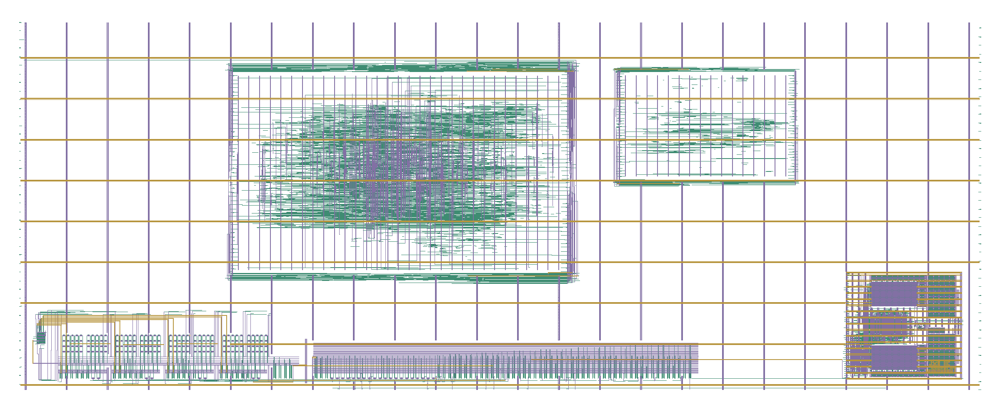

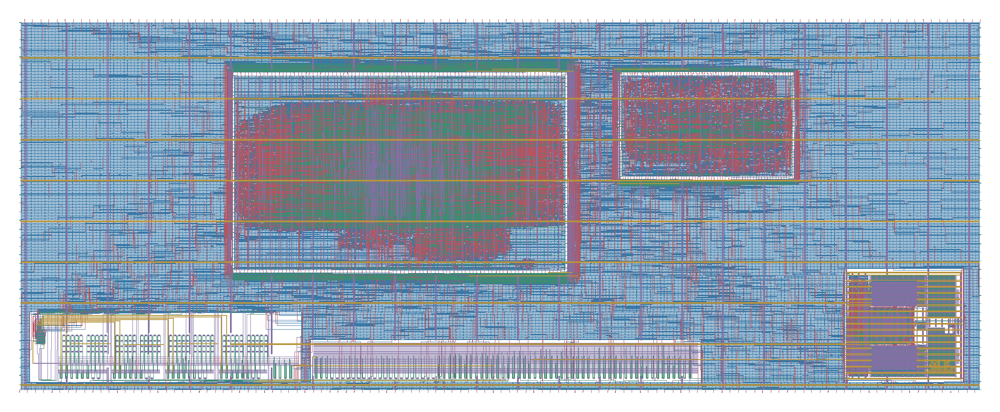

In [194]:
_native_root=PRIORITY_WORK.parent/'full_native/full_native'
_manifest=json.loads((_native_root/'runall_manifest.json').read_text())
FINAL_PARENT={'outputs':{'gds':_manifest['views']['gds']}}
_parent_spefs=[Path(_manifest['views']['spef']['path'])]
_reference=CLOSURE_ROOT/'inputs/digital_benchmarks'
PWM_REFERENCE=CLOSURE_MODULES['physical'].run(CLOSURE_ROOT,_reference/'binary_reference',_reference/'reference_parent/timing/automx_cim_mixed_signal_proto.spef',CLOSURE_WORK/'pwm_reference',jobs=6,pilot=True)
PWM_FINAL=CLOSURE_MODULES['physical'].run(CLOSURE_ROOT,CLOSURE_ROOT/'inputs/digital_blocks/readout',_parent_spefs[0],CLOSURE_WORK/'pwm_final',jobs=CLOSURE_JOBS)
_checks=('zero_code_ok','nonzero_full_swing','single_pulse_ok','unselected_lines_quiet','strict_width_order','strict_bitline_order','bitline_polarity_ok')
print('Routed pulse qualification:', 'PASS' if all(PWM_FINAL[k] for k in _checks) else 'CONTRACT_FAILURE_MEASURED')
display(pd.DataFrame([{'check':k,'pass':PWM_FINAL[k]} for k in _checks]))
display(pd.DataFrame([{k:r[k] for k in ('row','negative','magnitude','width_ps','peak_v','rising_edges','bitline_differential_change_v')} for r in PWM_FINAL['measurements']]))
FINAL_RENDER=CLOSURE_MODULES['final_render'].render(CLOSURE_ROOT,FINAL_PARENT['outputs']['gds']['path'],CLOSURE_WORK/'final_top_render')
for _label in ('overview','detail'):display(Image(filename=FINAL_RENDER['images'][_label]))


### Retest an electrical repair before adopting it

**Implementation:** Compare an explicit pulse-path repair with the qualified controller. The candidate uses matched reference/selected-delay mux paths and identical output-driver types, with row-local tap isolation/drive when present in its visible source. Its declared parent policy replaces only wordline buffer cones with stronger drivers before fresh routing; the source-matched physical views below are declared reusable hard IP. A new 160-MIM-per-bitline bank is generated with real geometry, Magic DRC, transistor LVS and extracted receiver loading. Route a fresh five-block candidate parent and measure all 64 loaded wordline/code combinations. Then drive 28 fixed signed single-row native cases with those exact PWL waveforms. A passing pulse gate additionally triggers 312 fresh calibration anchors and 96 matched-sum cases. A failed pulse, raw-code alias, invalid calibration ordering or held-out error rejects adoption; it cannot be repaired by a synthetic ADC answer.

**Inputs → outputs and downstream use:** The visible candidate RTL and frozen source-matched child views, original compute source and PDK generate a fresh enlarged macro, parent GDS/RC, delivered waveforms and live-SAR raw codes. Candidate results have their own `evaluated_candidate/` tree. They do not supply the separate ideal-50-ps calibration campaign or replace the selected ICG implementation. TT means typical transistor process; PDK means process design kit; RC means resistance and capacitance; LVS means layout-versus-schematic; DRC means design-rule check.

The evaluated candidate places the pulse-forming gates next to their strong output drivers. Its earlier unclustered placement is retained as source-matched views under `inputs/earlier_pulse_placement`. This run retests the physical repair and then tests whether its calibration transfers across decompositions. A passed waveform is insufficient if raw-code intervals still overlap.

In [195]:
CANDIDATE_READOUT_RTL = '// Slow physical prototype. SAR completion comes exclusively from the ADC.\n// The technology delay line requires post-layout pulse-width measurement;\n// its taps are NOT assumed to be calibrated 50 ps units.\n`timescale 1ns/1ps\n`default_nettype none\nmodule automx_cim_readout_seq #(\n    parameter integer BOOT_CYCLES = 8192,\n    parameter integer SETTLE_CYCLES = 16,\n    parameter integer ADC_TIMEOUT_CYCLES = 4096,\n    parameter integer VCM_HALF_PERIOD = 763,\n    parameter integer BINARY_DECODE = 1,\n    parameter integer CAL_CLOCK_GATING = 1\n) (\n    input wire clk_i, rst_ni,\n    input wire cfg_valid_i, output wire cfg_ready_o,\n    input wire [1:0] cfg_row_i,\n    input wire [3:0] cfg_wpos_i, cfg_wneg_i,\n    input wire cal_valid_i, output wire cal_ready_o,\n    input wire [8:0] cal_address_i, input wire [11:0] cal_threshold_i,\n    output wire calibrated_o,\n    input wire eval_valid_i, output wire eval_ready_o,\n    input wire signed [19:0] act_x2_i, input wire raw_mode_i,\n    output wire result_valid_o, input wire result_ready_i,\n    output reg signed [47:0] result_acc_o,\n    output reg [95:0] raw_codes_o,\n    output reg result_calibrated_o, output wire fault_o,\n    output reg [15:0] weight_pos_o, weight_neg_o,\n    output wire [3:0] wlp_o, wln_o,\n    output wire pre_b_o, track_o, output reg [3:0] select_o,\n    output wire adc_rst_no, adc_start_o, output reg clk_vcm_o,\n    input wire adc_eoc_i, input wire [15:0] adc_word_i\n);\n    localparam [4:0] BOOT=0, IDLE=1, PRE=2, RELEASE=3, PULSE=4,\n        HOLD=5, DEAD=6, SETTLE=7, EOC_LOW=8, START=9, WAIT_EOC=10,\n        WORD_SETTLE=11, CAPTURE=12, DECODE=13, ADVANCE=14, RESULT=15, FAULT=16,\n        CAL_PREV=17, CAL_NEXT=18;\n    reg [4:0] state;\n    reg [15:0] timer;\n    reg [15:0] vcm_count;\n    reg phase_b;\n    reg [1:0] column;\n    reg signed [19:0] acts;\n    reg raw_mode;\n    reg launch;\n    (* async_reg = "true" *) reg eoc_meta, eoc_sync;\n    reg [303:0] threshold_valid;\n    reg calibration_error;\n    reg [11:0] thresholds [0:303];\n    // Threshold contents have no reset in the original interface. Only the\n    // accepted calibration write may clock this 3,648-bit storage bank.\n    wire calibration_write = rst_ni && state==IDLE && cal_valid_i && cal_ready_o;\n    wire threshold_clock;\n    generate if(CAL_CLOCK_GATING) begin: storage_gating\n        automx_calibration_clock_gate gate_i(.clk_i(clk_i),.enable_i(calibration_write),.clk_o(threshold_clock));\n    end else begin: storage_ungated\n        assign threshold_clock=clk_i;\n    end endgenerate\n    always @(posedge threshold_clock) begin\n        if(calibration_write) thresholds[cal_address_i]<=cal_threshold_i;\n    end\n    reg [11:0] captured_code;\n    reg [5:0] decode_index, decode_bin;\n    reg [5:0] decode_low, decode_high;\n    wire [8:0] threshold_address = (phase_b ? 9\'d152 : 9\'d0)+{7\'d0,column}*9\'d38+{3\'d0,decode_index};\n    reg [8:0] calibration_address;\n    reg [11:0] calibration_value;\n    // Share one physical LUT read mux between decoding and the two neighbor\n    // checks. Calibration handshakes take three clocks instead of one.\n    wire [8:0] threshold_read_address = state==CAL_PREV ? calibration_address-9\'d1 :\n        state==CAL_NEXT ? calibration_address+9\'d1 : threshold_address;\n    wire [11:0] threshold_read_data = thresholds[threshold_read_address];\n    reg signed [5:0] partial_a [0:3];\n    // A regular shared line sees one launch load. Local launch references\n    // keep the pulse gates from loading that source or truncating short codes.\n    wire [72:0] tap;\n    assign tap[0]=launch;\n    genvar tap_index;\n    generate for(tap_index=1;tap_index<=72;tap_index=tap_index+1)begin: delay_taps\n        (* keep = 1, dont_touch = 1 *) sky130_fd_sc_hd__buf_1 delay_i(.A(tap[tap_index-1]),.X(tap[tap_index]));\n    end endgenerate\n    // Matched reference/selected-delay muxes remove activation-dependent\n    // logic after pulse formation. Each delivered lane has one static enable\n    // gate and the same explicit output buffer. Tap isolation keeps the line\n    // load independent of the mux fanout. Physical qualification is mandatory.\n    genvar pulse_index;\n    generate for(pulse_index=0;pulse_index<4;pulse_index=pulse_index+1) begin: pulse_generator\n\n        wire [12:0] tap_drive;\n        genvar drive_index;\n        for(drive_index=0;drive_index<=12;drive_index=drive_index+1) begin: pulse_tap_drive\n`ifdef SYNTHESIS\n                wire isolated;\n                (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__buf_1 isolate_i(.A(tap[6*drive_index]),.X(isolated));\n                (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__buf_16 drive_i(.A(isolated),.X(tap_drive[drive_index]));\n`else\n                assign tap_drive[drive_index]=tap[6*drive_index];\n`endif\n        end\n\n        wire [4:0] mag_row=magnitude(acts[5*pulse_index+:5]);\n        reg [2:0] selection;\n        always @* case(mag_row)\n            1:selection=0;2:selection=1;3:selection=2;4:selection=3;\n            6:selection=4;8:selection=5;12:selection=6;default:selection=7;\n        endcase\n        wire reference_edge, delayed_edge, delayed_n;\n        wire enabled=((pulse_index>=2)==phase_b) && mag_row!=0 && mag_row<=12;\n        wire positive=enabled && !acts[5*pulse_index+4];\n        wire negative=enabled && acts[5*pulse_index+4];\n`ifdef SYNTHESIS\n        wire reference_low,reference_high,delayed_low,delayed_high,positive_raw,negative_raw;\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__mux4_4 reference_low_i(.A0(tap_drive[0]),.A1(tap_drive[0]),.A2(tap_drive[0]),.A3(tap_drive[0]),.S0(selection[0]),.S1(selection[1]),.X(reference_low));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__mux4_4 delayed_low_i(.A0(tap_drive[1]),.A1(tap_drive[2]),.A2(tap_drive[3]),.A3(tap_drive[4]),.S0(selection[0]),.S1(selection[1]),.X(delayed_low));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__mux4_4 reference_high_i(.A0(tap_drive[0]),.A1(tap_drive[0]),.A2(tap_drive[0]),.A3(tap_drive[0]),.S0(selection[0]),.S1(selection[1]),.X(reference_high));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__mux4_4 delayed_high_i(.A0(tap_drive[6]),.A1(tap_drive[8]),.A2(tap_drive[12]),.A3(tap_drive[12]),.S0(selection[0]),.S1(selection[1]),.X(delayed_high));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__mux2_4 reference_select_i(.A0(reference_low),.A1(reference_high),.S(selection[2]),.X(reference_edge));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__mux2_4 delayed_select_i(.A0(delayed_low),.A1(delayed_high),.S(selection[2]),.X(delayed_edge));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__inv_4 invert_i(.A(delayed_edge),.Y(delayed_n));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__and3_4 positive_i(.A(reference_edge),.B(delayed_n),.C(positive),.X(positive_raw));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__and3_4 negative_i(.A(reference_edge),.B(delayed_n),.C(negative),.X(negative_raw));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__buf_16 positive_drive_i(.A(positive_raw),.X(wlp_o[pulse_index]));\n        (* keep=1, dont_touch=1 *) sky130_fd_sc_hd__buf_16 negative_drive_i(.A(negative_raw),.X(wln_o[pulse_index]));\n`else\n        assign reference_edge=tap_drive[0];\n        assign delayed_edge=mag_row==1 ? tap_drive[1] : mag_row==2 ? tap_drive[2] :\n            mag_row==3 ? tap_drive[3] : mag_row==4 ? tap_drive[4] :\n            mag_row==6 ? tap_drive[6] : mag_row==8 ? tap_drive[8] : tap_drive[12];\n        assign wlp_o[pulse_index]=reference_edge && !delayed_edge && positive;\n        assign wln_o[pulse_index]=reference_edge && !delayed_edge && negative;\n`endif\n    end endgenerate\n    assign calibrated_o = (&threshold_valid) && !calibration_error && state!=CAL_PREV && state!=CAL_NEXT;\n    assign cfg_ready_o = state==IDLE && !eval_valid_i && !(|(cfg_wpos_i & cfg_wneg_i));\n    assign cal_ready_o = state==IDLE && !eval_valid_i && cal_address_i < 9\'d304;\n    assign eval_ready_o = state==IDLE && !cfg_valid_i && !cal_valid_i &&\n                          (raw_mode_i || calibrated_o) && valid_acts(act_x2_i);\n    assign result_valid_o = state==RESULT;\n    assign fault_o = state==FAULT;\n    assign pre_b_o = !(state==BOOT || state==IDLE || state==PRE || state==CAL_PREV || state==CAL_NEXT);\n    assign track_o = state==PRE || state==RELEASE || state==PULSE;\n    assign adc_rst_no = !(state==BOOT || state==IDLE || state==PRE || state==RELEASE ||\n                         state==PULSE || state==HOLD || state==DEAD || state==SETTLE || state==FAULT ||\n                         state==CAL_PREV || state==CAL_NEXT);\n    assign adc_start_o = state==START;\n\n    function automatic [4:0] magnitude(input signed [4:0] x);\n        magnitude = x[4] ? (~x+5\'d1) : x;\n    endfunction\n    function automatic valid_acts(input signed [19:0] x);\n        integer r;\n        reg [4:0] m;\n        begin\n            valid_acts=1;\n            for(r=0;r<4;r=r+1) begin\n                m=magnitude(x[5*r+:5]);\n                case(m)\n                    0,1,2,3,4,6,8,12: ;\n                    default: valid_acts=0;\n                endcase\n            end\n        end\n    endfunction\n    // The reachable two-row integer alphabet is fixed; thresholds are\n    // programmed only from measurements of this complete readout path.\n    // Explicit unsigned index avoids the int\' cast unsupported by the\n    // Verilog frontend shipped with OpenLane 30ee138.\n    function automatic signed [5:0] level(input [5:0] i);\n        begin\n            case(i)\n              0:level=-24;1:level=-20;2:level=-18;3:level=-16;4:level=-15;\n              5:level=-14;6:level=-13;7:level=-12;8:level=-11;9:level=-10;\n              10:level=-9;11:level=-8;12:level=-7;13:level=-6;14:level=-5;\n              15:level=-4;16:level=-3;17:level=-2;18:level=-1;19:level=0;\n              20:level=1;21:level=2;22:level=3;23:level=4;24:level=5;\n              25:level=6;26:level=7;27:level=8;28:level=9;29:level=10;\n              30:level=11;31:level=12;32:level=13;33:level=14;34:level=15;\n              35:level=16;36:level=18;37:level=20;38:level=24;\n              default:level=0;\n            endcase\n        end\n    endfunction\n    integer row;\n    reg [4:0] mag;\n    always @* begin\n        select_o=0;\n        if(state>=SETTLE && state<=CAPTURE) select_o=4\'b0001<<column;\n    end\n    integer i;\n    reg signed [5:0] decoded;\n    reg signed [11:0] sum;\n    reg [5:0] next_bin;\n    reg [5:0] next_low, next_high;\n    reg decode_done;\n    always @(posedge clk_i or negedge rst_ni) begin\n        if(!rst_ni) begin\n            state<=BOOT; timer<=0; vcm_count<=0; clk_vcm_o<=0;\n            phase_b<=0; column<=0; acts<=0; raw_mode<=0; launch<=0;\n            weight_pos_o<=0; weight_neg_o<=0; threshold_valid<=0;calibration_error<=0;\n            calibration_address<=0;calibration_value<=0;\n            captured_code<=0;decode_index<=0;decode_bin<=0;\n            decode_low<=0;decode_high<=38;\n            result_acc_o<=0; raw_codes_o<=0; result_calibrated_o<=0;\n            eoc_meta<=0; eoc_sync<=0;\n            for(i=0;i<4;i=i+1) partial_a[i]<=0;\n        end else begin\n            eoc_meta<=adc_eoc_i; eoc_sync<=eoc_meta;\n            if(vcm_count==VCM_HALF_PERIOD-1) begin vcm_count<=0; clk_vcm_o<=!clk_vcm_o; end\n            else vcm_count<=vcm_count+1;\n            timer<=timer+1;\n            case(state)\n                BOOT: if(timer>=BOOT_CYCLES-1) begin state<=IDLE; timer<=0; end\n                IDLE: begin\n                    timer<=0; launch<=0;\n                    if(cfg_valid_i && cfg_ready_o) begin\n                        weight_pos_o[4*cfg_row_i+:4]<=cfg_wpos_i;\n                        weight_neg_o[4*cfg_row_i+:4]<=cfg_wneg_i;\n                    end\n                    if(cal_valid_i && cal_ready_o) begin\n                        threshold_valid[cal_address_i]<=1;\n                        calibration_address<=cal_address_i;calibration_value<=cal_threshold_i;\n                        state<=CAL_PREV;\n                    end\n                    if(eval_valid_i && eval_ready_o) begin\n                        acts<=act_x2_i; raw_mode<=raw_mode_i; phase_b<=0; column<=0;\n                        result_calibrated_o<=0; result_acc_o<=0; raw_codes_o<=0;\n                        state<=PRE;\n                    end\n                end\n                CAL_PREV: begin\n                    if(calibration_address%38!=0 && threshold_valid[threshold_read_address] &&\n                       calibration_value<=threshold_read_data) calibration_error<=1;\n                    state<=CAL_NEXT;\n                end\n                CAL_NEXT: begin\n                    if(calibration_address%38!=37 && threshold_valid[threshold_read_address] &&\n                       calibration_value>=threshold_read_data) calibration_error<=1;\n                    state<=IDLE;timer<=0;\n                end\n                PRE: if(timer>=1) begin state<=RELEASE; timer<=0; end\n                RELEASE: begin state<=PULSE; timer<=0; launch<=1; end\n                PULSE: begin launch<=0; state<=HOLD; timer<=0; end\n                HOLD: begin state<=DEAD; timer<=0; end\n                DEAD: begin state<=SETTLE; timer<=0; end\n                SETTLE: if(timer>=SETTLE_CYCLES-1) begin state<=EOC_LOW; timer<=0; end\n                EOC_LOW: begin\n                    if(!eoc_sync) begin state<=START; timer<=0; end\n                    else if(timer>=ADC_TIMEOUT_CYCLES-1) state<=FAULT;\n                end\n                START: begin state<=WAIT_EOC; timer<=0; end\n                WAIT_EOC: begin\n                    if(eoc_sync) begin state<=WORD_SETTLE; timer<=0; end\n                    else if(timer>=ADC_TIMEOUT_CYCLES-1) state<=FAULT;\n                end\n                WORD_SETTLE: if(timer>=2) begin state<=CAPTURE; timer<=0; end\n                CAPTURE: begin\n                    if(adc_word_i[3:0]!=0) state<=FAULT;\n                    else begin\n                        raw_codes_o[(phase_b ? 48 : 0)+12*column+:12]<=adc_word_i[15:4];\n                        captured_code<=adc_word_i[15:4];\n                        decode_index<=BINARY_DECODE ? 6\'d19 : 6\'d0;decode_bin<=0;\n                        decode_low<=0;decode_high<=38;\n                        state<=raw_mode ? ADVANCE : DECODE;timer<=0;\n                    end\n                end\n                // Upper bound: count thresholds <= code. Strictly increasing\n                // calibration is checked above. The half-open [low, high)\n                // search uses the same single LUT read, at most six clocks.\n                // BINARY_DECODE=0 retains the measured 38-clock baseline.\n                DECODE: begin\n                    if(BINARY_DECODE) begin\n                        next_low=decode_low;next_high=decode_high;\n                        if(captured_code>=threshold_read_data) next_low=decode_index+6\'d1;\n                        else next_high=decode_index;\n                        next_bin=next_low;\n                        decode_done=next_low==next_high;\n                    end else begin\n                        next_bin=decode_bin+(captured_code>=threshold_read_data ? 6\'d1 : 6\'d0);\n                        decode_done=decode_index==37;\n                    end\n                    if(decode_done) begin\n                        decoded=level(next_bin);\n                        if(!phase_b) partial_a[column]<=decoded;\n                        else begin\n                            sum={{6{partial_a[column][5]}},partial_a[column]}+{{6{decoded[5]}},decoded};\n                            result_acc_o[12*column+:12]<=sum;\n                        end\n                        state<=ADVANCE;timer<=0;\n                    end else if(BINARY_DECODE) begin\n                        decode_low<=next_low;decode_high<=next_high;\n                        decode_index<=({1\'b0,next_low}+{1\'b0,next_high})>>1;\n                    end else begin decode_index<=decode_index+1;decode_bin<=next_bin;end\n                end\n                ADVANCE: begin\n                    timer<=0;\n                    if(column!=3) begin column<=column+1; state<=DEAD; end\n                    else if(!phase_b) begin phase_b<=1; column<=0; state<=PRE; end\n                    else begin state<=RESULT; result_calibrated_o<=!raw_mode && calibrated_o; end\n                end\n                RESULT: if(result_ready_i) begin state<=IDLE; timer<=0; end\n                FAULT: ;\n                default: state<=FAULT;\n            endcase\n        end\n    end\nendmodule\n// Portable latch model for RTL; the physical flow maps the characterized ICG.\nmodule automx_cim_local_pulse_lane(input wire clk_i,rst_ni,trigger_i,delayed_i,output wire pulse_o);\n    wire launch_local;\n`ifdef SYNTHESIS\n    (* keep = 1, dont_touch = 1 *) sky130_fd_sc_hd__dfrtp_1 launch_ff(.CLK(clk_i),.D(trigger_i),.RESET_B(rst_ni),.Q(launch_local));\n`else\n    reg launch_model;\n    always @(posedge clk_i or negedge rst_ni) if(!rst_ni)launch_model<=0;else launch_model<=trigger_i;\n    assign launch_local=launch_model;\n`endif\n`ifdef SYNTHESIS\n    wire delayed_n;\n    (* keep = 1, dont_touch = 1 *) sky130_fd_sc_hd__inv_1 invert_i(.A(delayed_i),.Y(delayed_n));\n    (* keep = 1, dont_touch = 1 *) sky130_fd_sc_hd__and2_4 pulse_i(.A(launch_local),.B(delayed_n),.X(pulse_o));\n`else\n    assign pulse_o=launch_local && !delayed_i;\n`endif\nendmodule\n\nmodule automx_calibration_clock_gate(input wire clk_i,enable_i,output wire clk_o);\n`ifdef SYNTHESIS\n    (* keep=1 *) sky130_fd_sc_hd__dlclkp_1 icg_i(.CLK(clk_i),.GATE(enable_i),.GCLK(clk_o));\n`else\n    reg enable_latched;\n    always @* if(!clk_i) enable_latched=enable_i;\n    assign clk_o=clk_i && enable_latched;\n`endif\nendmodule\n`default_nettype wire\n'
assert (CLOSURE_ROOT/'inputs/electrical_candidate/readout/source.sv').read_text()==CANDIDATE_READOUT_RTL
print('Candidate source-bound physical views:',CLOSURE_ROOT/'inputs/electrical_candidate/readout')


Candidate source-bound physical views: /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/inputs/electrical_candidate/readout


**Implementation:** Execute fresh macro generation, routing and electrical acquisition for the candidate. Native tool output reports actual checks; the tables retain both pass and rejection results. Render candidate overview/detail using the same fixed KLayout palette and independent repeated-image pixel check. The selected release remains determined by the independent full notebook audit.

Magic 8.3 revision 677


MIM_UNIT_DRC=0


Final result: Circuits match uniquely.


PEX_RESISTOR_REDUCTION_PASS nodes 3087 -> 583 current_error_A 3.552713678800501e-15


[ngspice] stdout ******


[ngspice] stdout ** ngspice-44.2 shared library


... (156 outputs left out)

,row,negative,magnitude,width_ps,peak_v,rising_edges,bitline_differential_change_v
0,0,False,0,0.000000,4.455087e-09,0,-9.407544e-08
1,0,False,1,588.546510,1.834976e+00,1,2.236872e-02
2,0,False,2,1065.628200,1.855298e+00,1,4.146517e-02
3,0,False,3,1540.147408,1.833209e+00,1,6.045560e-02
4,0,False,4,2048.448589,1.843225e+00,1,8.078867e-02
...,...,...,...,...,...,...,...
59,3,True,3,1624.592527,1.831076e+00,1,-5.753783e-02
60,3,True,4,2129.982589,1.831437e+00,1,-7.600797e-02
61,3,True,6,3114.969233,1.830960e+00,1,-1.119960e-01
62,3,True,8,4053.827051,1.830278e+00,1,-1.461401e-01


,row,activation_x2,expected_partial_sum,folder,resolved,raw_code,start_to_eoc_s
0,0,-12,-12,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,1803,2.138622e-07
1,0,-2,-2,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,1999,2.139903e-07
2,0,-1,-1,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2020,2.147605e-07
3,0,0,0,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2047,2.142173e-07
4,0,1,1,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2070,2.137916e-07
5,0,2,2,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2090,2.141635e-07
6,0,12,12,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2286,2.139597e-07
7,1,-12,-12,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,1809,2.137823e-07
8,1,-2,-2,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2002,2.141577e-07
9,1,-1,-1,/media/nam/EDABK/AutoMX_CIM_qualified_validati...,True,2022,2.143102e-07


,bank,strict_calibration,minimum_adjacent_code_step,matched_cases,decoded_cases,decoded_wrong
0,0,True,10,12,12,5
1,1,True,10,12,12,5
2,2,True,10,12,12,5
3,3,True,10,12,12,5
4,4,True,6,12,12,3
5,5,True,6,12,12,4
6,6,True,6,12,12,4
7,7,True,6,12,12,4


Candidate adoption: EVALUATED_REJECTED


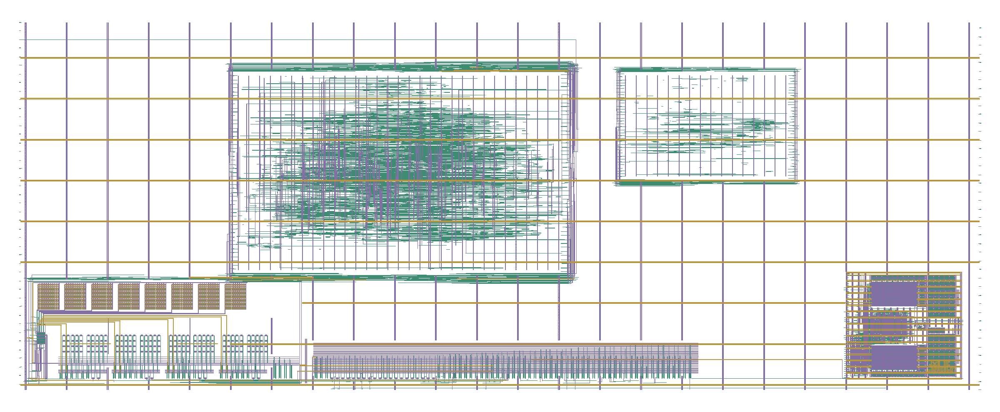

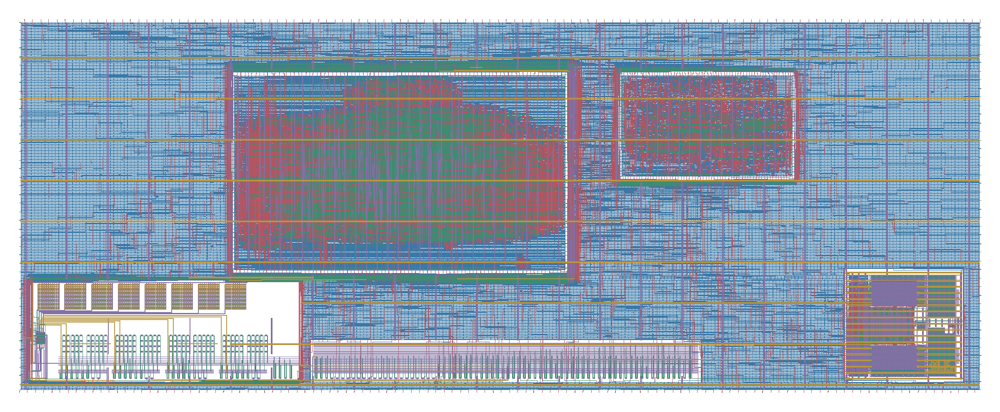

,placement,row,polarity,wire_capacitance_terms_fF,wire_resistance_terms_ohm
0,previous placement,0,positive,10.730668,118.475000
1,previous placement,0,negative,228.990625,715.666528
2,previous placement,1,positive,29.119138,179.819700
3,previous placement,1,negative,93.953509,138.224500
4,previous placement,2,positive,7.743784,74.850000
5,previous placement,2,negative,86.291511,586.117900
6,previous placement,3,positive,188.686285,609.391600
7,previous placement,3,negative,102.100978,136.613700
8,adjacent placement,0,positive,2.080420,28.171400
9,adjacent placement,0,negative,1.780216,27.760700


In [196]:
EVALUATED_WORK=CLOSURE_WORK/'evaluated_candidate'
EVALUATED_WORK.mkdir(parents=True,exist_ok=False)
EVALUATED_CORE=CLOSURE_MODULES['range_core'].build(CLOSURE_ROOT,EVALUATED_WORK/'physical_range_core')
_candidate_view=CLOSURE_ROOT/'inputs/electrical_candidate/readout'
_candidate_report=json.loads((_candidate_view/'hardening.json').read_text())
for _key in ('source','gds','lef','odb','lib','mapped_netlist','spef'):_candidate_report[_key]=str(_candidate_view/_candidate_report[_key])
(EVALUATED_WORK/'hardening.json').write_text(json.dumps(_candidate_report,indent=2)+'\n')
EVALUATED_PARENT=CLOSURE_MODULES['parent'].run(CLOSURE_ROOT,EVALUATED_WORK/'hardening.json',EVALUATED_WORK/'physical_parent',core_views=EVALUATED_CORE['views_dir'],upsize_wordline_buffers=_candidate_report.get('parent_wordline_drive_required',False))
EVALUATED_PWM=CLOSURE_MODULES['physical'].run(CLOSURE_ROOT,CLOSURE_ROOT/'inputs/electrical_candidate/readout',EVALUATED_WORK/'physical_parent/timing/automx_cim_mixed_signal_proto.spef',EVALUATED_WORK/'pwm',jobs=CLOSURE_JOBS,core_views=EVALUATED_CORE['views_dir'])
EVALUATED_NATIVE=CLOSURE_MODULES['candidate_eval'].run(CLOSURE_ROOT,EVALUATED_WORK/'pwm/verification.json',EVALUATED_CORE['views_dir'],EVALUATED_WORK/'native',jobs=CLOSURE_JOBS)
assert EVALUATED_NATIVE['native_unresolved']==0,EVALUATED_NATIVE['status']
EVALUATED_RENDER=CLOSURE_MODULES['final_render'].render(CLOSURE_ROOT,EVALUATED_PARENT['outputs']['gds']['path'],EVALUATED_WORK/'render')
display(pd.DataFrame([{k:r[k] for k in ('row','negative','magnitude','width_ps','peak_v','rising_edges','bitline_differential_change_v')} for r in EVALUATED_PWM['measurements']]))
display(pd.DataFrame(EVALUATED_NATIVE['single_row_codes']))
if EVALUATED_NATIVE['calibration']:
    display(pd.DataFrame([{'bank':i,'strict_calibration':EVALUATED_NATIVE['calibration']['strictly_increasing'][i],'minimum_adjacent_code_step':EVALUATED_NATIVE['calibration']['minimum_adjacent_code_step'][i],'matched_cases':sum(r['bank']==i for r in EVALUATED_NATIVE['matched_sum']),'decoded_cases':sum(r['bank']==i and 'decoded' in r for r in EVALUATED_NATIVE['matched_sum']),'decoded_wrong':(sum(r.get('decoded')!=r['expected'] for r in EVALUATED_NATIVE['matched_sum'] if r['bank']==i and r['bank_has_valid_ordered_calibration']) if EVALUATED_NATIVE['calibration']['strictly_increasing'][i] else None)} for i in range(8)]))
print('Candidate adoption:',EVALUATED_NATIVE['status'])
for _label in ('overview','detail'):display(Image(filename=EVALUATED_RENDER['images'][_label]))

_wire_rows=[]
for _variant,_directory in [('previous placement',CLOSURE_ROOT/'inputs/earlier_pulse_placement'),('adjacent placement',CLOSURE_ROOT/'inputs/electrical_candidate/readout')]:
    _logic,_=CLOSURE_MODULES['physical'].structural(next(_directory.glob('*.nl.v')))
    _rc=CLOSURE_MODULES['physical'].spef(next(_directory.glob('*.spef')))
    for _row in range(4):
        for _polarity in ('positive','negative'):
            _driver=_logic[f'pulse_generator[{_row}].{_polarity}_i']
            _net=_rc[_driver['pins']['X']]
            _wire_rows.append({'placement':_variant,'row':_row,'polarity':_polarity,'wire_capacitance_terms_fF':sum(c for a,b,c in _net['caps'])*1e15,'wire_resistance_terms_ohm':sum(v for a,b,v in _net['res'])})
(EVALUATED_WORK/'pulse_wire_loading.json').write_text(json.dumps(_wire_rows,indent=2)+'\n')
display(pd.DataFrame(_wire_rows))


<a id="closure-calibration"></a>
### Freeze calibration, test its transfer, then replay six activities

The ideal-50-ps pulse profile below isolates conversion, hold and calibration from the delivered-pulse discrepancy measured above. Measure 312 nominal anchors before 88 held-out decompositions and eight anchor rechecks. Seven transistor PVT conditions use five measured anchors and seven held-out patterns in four banks. The comparison of frozen TT thresholds with per-condition interpolation tests a calibration policy. Six first-occurring test frames, one per class, are fixed before circuit outcomes. Their 384 native ADC words are replayed through the real MHA/readout with request identities and timestamps checked.

In [197]:
ELECTRICAL=CLOSURE_MODULES['campaign'].run(CLOSURE_ROOT,PRIORITY_WORK/'application',CLOSURE_WORK/'control_timing_qualified/control_timing.csv',CLOSURE_WORK/'electrical',jobs=CLOSURE_JOBS,core_pex=False)
assert ELECTRICAL['status']=='PASS',ELECTRICAL['status']
QUALIFIED_REPLAY=CLOSURE_MODULES['replay'].replay(CLOSURE_ROOT,PRIORITY_WORK/'application',CLOSURE_WORK/'electrical',PRIORITY_WORK/'application_rtl',CLOSURE_WORK/'native_replay')
_pvt=json.loads((CLOSURE_WORK/'electrical/pvt.json').read_text())
display(pd.DataFrame(_pvt['groups']))
display(pd.DataFrame(json.loads((CLOSURE_WORK/'electrical/settling.json').read_text())))
display(pd.DataFrame(ELECTRICAL['frames']))


NATIVE_CALIBRATION_START 312 conversions


NATIVE_CALIBRATION 312 conversions; strict banks 8 ; minimum adjacent code step 15


MATCHED_SUM 96 wrong 0 minimum margin 5


PVT_START 7 conditions 336 conversions


PVT_RESULT unresolved 0 frozen wrong 100 recalibrated wrong 0


SETTLING_RESULT [{"settle_clocks": 16, "conversions": 24, "wrong": 0, "unresolved": 0, "max_abs_anchor_drift_codes": 1}, {"settle_clocks": 8, "conversions": 24, "wrong": 0, "unresolved": 0, "max_abs_anchor_drift_codes": 1}, {"settle_clocks": 4, "conversions": 24, "wrong": 0, "unresolved": 0, "max_abs_anchor_drift_codes": 1}, {"settle_clocks": 2, "conversions": 24, "wrong": 0, "unresolved": 0, "max_abs_anchor_drift_codes": 1}]


... (7 outputs left out)

NATIVE_CODE_MHA_REPLAY_PASS {"status": "PASS", "frames": 6, "output_values": 48, "native_adc_transactions": 384, "calibration_thresholds": 304, "native_transaction_identity_checked": true, "max_control_timing_error_ns": 0.0, "adc_pin_response_ns": {"min": 240.0, "max": 240.0}, "mismatches": 0, "frames_and_predictions": [{"test_index": 79, "label": 0, "predicted_class": 1, "output_mismatches": 0}, {"test_index": 133, "label": 1, "predicted_class": 1, "output_mismatches": 0}, {"test_index": 109, "label": 2, "predicted_class": 0, "output_mismatches": 0}, {"test_index": 31, "label": 3, "predicted_class": 3, "output_mismatches": 0}, {"test_index": 0, "label": 4, "predicted_class": 4, "output_mismatches": 0}, {"test_index": 55, "label": 5, "predicted_class": 5, "output_mismatches": 0}], "elapsed_s": 0.42568401095923036, "adc_input_polarity": "conditioner AINN -> ADC inp; conditioner AINP -> ADC inn", "scope": "Actual MHA and two-phase readout RTL replaying native SAR/transistor ADC words and

,condition,bank,conversions,unresolved,anchor_codes,strict_anchors,frozen_tt_wrong,five_anchor_recalibrated_wrong
0,tt_25,0,12,0,"[1675, 1860, 2048, 2235, 2420]",True,0,0
1,tt_25,3,12,0,"[1675, 1860, 2047, 2235, 2420]",True,0,0
2,tt_25,4,12,0,"[1675, 1860, 2048, 2235, 2420]",True,0,0
3,tt_25,7,12,0,"[1675, 1860, 2047, 2235, 2420]",True,0,0
4,tt_0,0,12,0,"[1654, 1850, 2048, 2245, 2441]",True,3,0
5,tt_0,3,12,0,"[1655, 1850, 2048, 2245, 2440]",True,3,0
6,tt_0,4,12,0,"[1654, 1850, 2047, 2245, 2441]",True,3,0
7,tt_0,7,12,0,"[1655, 1850, 2048, 2245, 2440]",True,3,0
8,tt_70,0,12,0,"[1707, 1876, 2048, 2219, 2388]",True,3,0
9,tt_70,3,12,0,"[1710, 1879, 2048, 2216, 2385]",True,3,0


,settle_clocks,conversions,wrong,unresolved,max_abs_anchor_drift_codes
0,16,24,0,0,1
1,8,24,0,0,1
2,4,24,0,0,1
3,2,24,0,0,1


,index,label,output_x2,output_mismatches
0,79,0,"[[0, 0, -9, 14], [0, 0, -9, 14]]",0
1,133,1,"[[0, 1, 0, 17], [0, 1, 0, 17]]",0
2,109,2,"[[0, 4, -16, 4], [0, 4, -16, 4]]",0
3,31,3,"[[0, 13, -2, -15], [0, 13, -2, -15]]",0
4,0,4,"[[0, 17, -8, -15], [0, 19, -8, -13]]",0
5,55,5,"[[0, 24, 20, 16], [0, 24, 20, 16]]",0


**Implementation:** Turn calibration transfer and settling measurements into a raw-code guard budget. A decision guard is the number of ADC codes remaining before the neighboring programmed threshold. The minimum already includes the measured same-sum pattern spread. Subtract a conservative extra settling displacement and report the residual per bank; do not assume unmeasured stochastic noise or comparator offset. Keep the 16-clock policy in the matched power comparison even when a shorter wait passes the bounded electrical sweep.

**Inputs → outputs and downstream use:** Newly acquired `electrical/matched_sum.json`, `settling.json`, `pvt.json` and the campaign contract become `margin_budget.json`. The eight bank rows explain the supported calibration/settling policy beside the energy and application results.

In [198]:
MARGIN_BUDGET=CLOSURE_MODULES['margin_budget'].run(CLOSURE_WORK)
display(pd.DataFrame(MARGIN_BUDGET['banks']))
print('Sampled correct settling policies:',MARGIN_BUDGET['sampled_correct_settle_clocks'])
print('Retained matched-power policy:',MARGIN_BUDGET['retained_comparison_settle_clocks'],'clocks')


MARGIN_BUDGET 8 banks; minimum conditional guard 4 codes; sampled correct settle clocks [16, 8, 4, 2]


,bank,matched_sum_cases,wrong,unresolved,minimum_observed_guard_codes,additional_sampled_settling_debit_codes,allocated_noise_offset_codes,remaining_conditional_guard_codes,conditional_positive_guard,scope
0,0,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
1,1,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
2,2,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
3,3,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
4,4,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
5,5,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
6,6,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...
7,7,12,0,0,5,1,0,4,True,Sampled nominal patterns and accepted settling...


Sampled correct settling policies: [16, 8, 4, 2]
Retained matched-power policy: 16 clocks


**Implementation:** Independently repeat the early/late core-PEX points using finer numerical settings, then integrate the newly measured conversion windows. A token projection contains eight conversions; the table labels the sum of those windows rather than treating repeated acquisition intervals as a continuous-frame energy measurement.

In [199]:
CONVERGENCE=CLOSURE_MODULES['convergence'].run(CLOSURE_ROOT,CLOSURE_WORK/'numerical_convergence',jobs=CLOSURE_JOBS)
assert CONVERGENCE['status']=='PASS'
CONVERSION_ENERGY=CLOSURE_MODULES['energy'].run(CLOSURE_WORK/'electrical',CLOSURE_WORK/'conversion_energy')
display(pd.DataFrame([CONVERSION_ENERGY['mean_conversion_nj'],CONVERSION_ENERGY['mean_projection_conversion_nj']],index=['one conversion window','eight-window token projection']))


NATIVE_CONVERGENCE PASS max_code_change 1


CONVERSION_WINDOW_ENERGY_PASS {"status": "PASS", "logical_conversions": 384, "unique_measured_cases": 256, "token_projections": 48, "mean_conversion_nj": {"core_nj": 2.132196270561354e-07, "conditioner_nj": 0.3374940059963836, "adc_nj": 0.007624510621160833, "reference_bridge_nj": 3.222782627183502e-05, "monitored_total_nj": 0.34515095766344334}, "mean_projection_conversion_nj": {"core_nj": 1.7057570164490833e-06, "conditioner_nj": 2.699952047971069, "adc_nj": 0.06099608496928668, "reference_bridge_nj": 0.00025782261017468015, "monitored_total_nj": 2.7612076613075467}, "scope": "Actual sampled V/I integrals over SAR START-to-EOC. Projection is eight such conversion windows for one four-output token. Acquisition/hold, controller/MHA and idle are separate ownership windows; these are not complete projection or whole-chip energies."}


,core_nj,conditioner_nj,adc_nj,reference_bridge_nj,monitored_total_nj
one conversion window,2.132196e-07,0.337494,0.007625,0.000032,0.345151
eight-window token projection,1.705757e-06,2.699952,0.060996,0.000258,2.761208


<a id="closure-cost"></a>
### Attribute cost and test calibration clock gating

Use a characterized integrated clock-gating cell for the threshold data bank. Compare its actual routed clock activity and output-equivalent native-backed workload with the programmable binary reference. A matched tool version is essential: clock activity must remain visible to the power estimator. The current-readout row is the adopted isolated calibration-gated implementation. The pulse measurement is an independent electrical check.

In [200]:
MATCHED_ACTIVITY=PRIORITY_MODULES['power'].measure(CLOSURE_ROOT,CLOSURE_WORK,CLOSURE_WORK/'matched_activity_power',clock_aware=True)
GATING=CLOSURE_MODULES['gatepower'].measure(CLOSURE_ROOT,CLOSURE_WORK,CLOSURE_WORK/'gating_power',CLOSURE_ROOT/'inputs/digital_benchmarks/calibration_gated/hardening.json',CLOSURE_ROOT/'inputs/digital_benchmarks/binary_reference/hardening.json')
CLOCK_ACTIVITY=CLOSURE_MODULES['clock'].run(CLOSURE_WORK/'gating_power',CLOSURE_WORK/'clock_activity')
ATTRIBUTION=CLOSURE_MODULES['attribution'].run(CLOSURE_ROOT,CLOSURE_WORK/'gating_power',CLOSURE_WORK/'power_attribution_sta3')
COST_COMPARISON=CLOSURE_MODULES['comparison'].run(CLOSURE_ROOT,CLOSURE_WORK/'matched_activity_power',CLOSURE_WORK/'gating_power',CLOSURE_WORK/'clock_aware_power')
AREA=CLOSURE_MODULES['area'].run(CLOSURE_ROOT,CLOSURE_WORK/'controller_adc_area')
display(pd.DataFrame([{'variant':r['variant'],'latency_us':r['activity_window_s']/r['frames']*1e6,'child_digital_nJ/frame':r['child_digital_energy_per_frame_j']*1e9,'mismatches':r['gate_output_mismatches']} for r in COST_COMPARISON['results']]))
display(pd.DataFrame(AREA['designs']))
display(pd.DataFrame(AREA['routed_standard_cells']))
display(pd.DataFrame(AREA['physical_macros']))


ACTIVITY_POWER_PASS linear frames 6 mismatches 0 latency_us/frame 186.14 child_mW 10.403722 nJ/frame 1936.548737


ACTIVITY_POWER_PASS binary frames 6 mismatches 0 latency_us/frame 102.593333 child_mW 4.018324 nJ/frame 412.253226


ACTIVITY_POWER_PASS digital frames 6 mismatches 0 latency_us/frame 8.86 child_mW 2.193307 nJ/frame 19.432702


ACTIVITY_POWER_PASS binary_reference frames 6 mismatches 0 child_mW 10.288469 nJ/frame 1055.52838


ACTIVITY_POWER_PASS binary frames 6 mismatches 0 child_mW 4.018324 nJ/frame 412.253226


ACTIVITY_POWER_PASS digital frames 6 mismatches 0 child_mW 2.193307 nJ/frame 19.432702


... (14 outputs left out)

,variant,latency_us,child_digital_nJ/frame,mismatches
0,linear,186.140000,1936.548737,0
1,binary,102.593333,1055.528380,0
2,binary_gated,102.593333,412.253226,0
3,digital,8.860000,19.432702,0
4,current_readout,102.593333,412.253226,0


,design,mapped_cells,mapped_area_um2,elapsed_s
0,binary_reference,13867,167519.4144,55.580682
1,calibration_gated,13200,175447.0176,41.901409
2,current_readout,13200,175447.0176,41.500650
3,sar_digital,1168,8415.5712,4.273777


,design,routed_instances,routed_stdcell_area_um2
0,binary_reference,34925,243070.624
1,calibration_gated,33812,245122.592
2,current_readout,33812,245122.592


,macro,width_um,height_um,footprint_um2
0,core_reference,996.2,239.72,238809.064
1,conditioner,1442.0,136.12,196285.040
2,adc_full_macro,423.0,403.00,170469.000
3,readout,1250.0,750.00,937500.000
4,mha,650.0,400.00,260000.000


<a id="closure-service"></a>
### Operate at a sensor cadence and change the resident configuration

Measure unforced boot, accepted programming traffic and retained-state idle wake. A separate mapped-readout VCD window measures 304 threshold writes and the four resident O-stage masks; its energy belongs to readout storage/control, while the MHA configuration interface is timed independently. The analog bias remains active. Validation corruption controls are fixed before evaluation; no test-subject retuning is performed. The second deployment uses equal attention probabilities through Q=0 on the same IP. Host feature/embedding/head latency, RTL latency and reference/analog ownership remain separate terms.

In [201]:
IDLE=CLOSURE_MODULES['idle'].run(CLOSURE_ROOT,PRIORITY_WORK/'application',CLOSURE_WORK/'idle_boot',native=CLOSURE_WORK/'native_replay')
WAKE=CLOSURE_MODULES['wake'].run(CLOSURE_ROOT,PRIORITY_WORK/'application',PRIORITY_WORK/'application_rtl/tb_application_binary.sv',CLOSURE_WORK/'idle_wake_service')
SERVICE=CLOSURE_MODULES['service'].run(CLOSURE_ROOT,PRIORITY_WORK/'application',PRIORITY_WORK/'application_rtl',CLOSURE_WORK/'application_service')
SECOND_CONFIG=CLOSURE_MODULES['second'].run(CLOSURE_ROOT,PRIORITY_WORK/'application',CLOSURE_WORK/'second_configuration')
display(pd.DataFrame(SERVICE['validation_challenges'])[['challenge','model','windows','accuracy','macro_f1']])
display(pd.DataFrame(IDLE['digital']))
display(pd.DataFrame([{'boot_us':WAKE['cold_boot_ns']/1000,'calibration_us':WAKE['calibration_ns']/1000,'configuration_us':WAKE['configuration_ns']/1000,'analog_idle_mW':IDLE['analog_idle_dc']['monitored_w']*1000}]))


[ngspice] stdout ******


[ngspice] stdout ** ngspice-44.2 shared library


[ngspice] stdout ** Creation Date: Fri Oct 23 06:23:58 UTC 2026


[ngspice] stdout ******


[ngspice] stdout Note: Compatibility modes selected: hs a


[ngspice] stderr Warning: m=xx on .subckt line will override multiplier m hierarchy!


... (26 outputs left out)

SECOND_CONFIGURATION_PASS software_windows 2947 macro_F1 0.802919 RTL_paths 4 frames/path 6 mismatches 0


,challenge,model,windows,accuracy,macro_f1
0,clean,learned,1655,0.869486,0.863155
1,clean,uniform_retrained,1655,0.858610,0.851067
2,clean,identity_frozen,1655,0.853776,0.843505
3,missing_half,learned,1655,0.821148,0.806742
4,missing_half,uniform_retrained,1655,0.821752,0.812126
5,missing_half,identity_frozen,1655,0.821148,0.806742
6,gain_10_percent,learned,1655,0.812689,0.792877
7,gain_10_percent,uniform_retrained,1655,0.752870,0.719512
8,gain_10_percent,identity_frozen,1655,0.813293,0.790247
9,acc_x_bias_0p05g,learned,1655,0.839879,0.829266


,window,duration_s,readout_w,readout_j
0,cold,0.000328,0.001515,4.967992e-07
1,programming,0.000037,0.007761,2.856094e-07
2,idle,0.000040,0.001510,6.039084e-08


,boot_us,calibration_us,configuration_us,analog_idle_mW
0,327.68,36.48,0.64,1.500532


<a id="closure-reproduction"></a>
### Execute the declared short check and the extracted IP

The short command recomputes frozen predictions, checks six class-selected RTL frames per path and inspects GDS hierarchy. A separate extraction uses an isolated Python environment and the declared host Icarus dependency. Full Run All performs the fresh circuit and physical acquisitions; these smaller checks expose their actual coverage and runtime.

In [202]:
QUICK_REVIEW=CLOSURE_MODULES['quick'].run(CLOSURE_ROOT,CLOSURE_WORK/'quick_review',gds=_parent_spefs[0].parent.parent/'streamout/automx_cim_mixed_signal_proto.gds')
CLEAN_IP=CLOSURE_MODULES['clean'].run(CLOSURE_ROOT,CLOSURE_WORK/'clean_environment')
display(pd.DataFrame([{'check':'short review','elapsed_s':QUICK_REVIEW['elapsed_s'],'software_windows':QUICK_REVIEW['software_windows'],'rtl_frames_per_path':6},{'check':'isolated IP','elapsed_s':CLEAN_IP['elapsed_s'],'software_windows':None,'rtl_frames_per_path':None}]))


FROZEN_PREDICTIONS_PASS 2947 windows


APPLICATION_RTL_PATH_PASS {"path": "binary", "frames": 6, "output_values": 48, "mismatches": 0, "simulation_elapsed_s": 0.27157927595544606, "latency_cycles_mean": 1540.8333333333333, "latency_cycles_min": 1537, "latency_cycles_max": 1546, "latency_us_mean": 61.63333333333333, "clock_mhz": 25, "adc_conversions_per_frame": 64}


APPLICATION_RTL_PATH_PASS {"path": "linear", "frames": 6, "output_values": 48, "mismatches": 0, "simulation_elapsed_s": 0.4128620580304414, "latency_cycles_mean": 3629.5, "latency_cycles_min": 3627, "latency_cycles_max": 3630, "latency_us_mean": 145.18, "clock_mhz": 25, "adc_conversions_per_frame": 64}


APPLICATION_RTL_PATH_PASS {"path": "digital", "frames": 6, "output_values": 48, "mismatches": 0, "simulation_elapsed_s": 0.025772528955712914, "latency_cycles_mean": 221.5, "latency_cycles_min": 219, "latency_cycles_max": 222, "latency_us_mean": 8.86, "clock_mhz": 25, "adc_conversions_per_frame": 0}


QUICK_REVIEW_PASS 3.88 s


{
  "archive": "/media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/exports/AutoMX_MHA_IP_20261028.tar.gz",
  "files": 59,
  "size_bytes": 29431993,
  "stored_measurement_results_included": false,
  "source_and_hard_macro_views": true,
  "selected_analog_views": null
}


CLEAN_IP_PASS 54.52


,check,elapsed_s,software_windows,rtl_frames_per_path
0,short review,3.878152,2947.0,6.0
1,isolated IP,54.519685,NaN,NaN


### Verify the mapped clock-gate enable path

**Implementation:** `check_calibration_gate_timing(root, work, sdc=None)` locates the actual `sky130_fd_sc_hd__dlclkp_1` integrated clock-gating cell (ICG), reads the child clock-tree-synthesis constraints (CTS/SDC), its mapped gate netlist and extracted standard parasitic exchange format (SPEF) network, and checks the `GATE` pin with OpenSTA. SKY130 describes these enable constraints as `setup_rising` and `hold_rising` arcs. Targeting the actual pin ensures the report contains a measured path. This is the physical enable-timing check for the calibration-storage decision, independent of its clock-edge and power checks.

**Inputs → outputs and downstream use:** The source-matched routed readout and its CTS SDC produce a fresh native transcript and minimum setup/hold slack at the ICG enable pin. Nonnegative slack permits the calibration-data gating implementation; a missing timing path or negative slack fails the audit.

In [203]:
"""Independently report the actual routed calibration ICG enable timing checks."""
from pathlib import Path
import argparse,json,re,subprocess

def check_calibration_gate_timing(root,work,sdc=None):
    root=Path(root).resolve();work=Path(work).resolve();work.mkdir(parents=True,exist_ok=False)
    block=root/'inputs/digital_blocks/readout'
    netlist=block/'automx_cim_readout_seq.nl.v';spef=block/'automx_cim_readout_seq.spef'
    gates=re.findall(r'sky130_fd_sc_hd__dlclkp_1\s+(\S+)\s*\(',netlist.read_text())
    assert len(gates)==1,('Expected exactly one calibration data-bank ICG',gates)
    enable_pin=gates[0].lstrip('\\')+'/GATE'
    constraint=Path(sdc).resolve() if sdc else block/'child.sdc';assert constraint.is_file()
    script=work/'gate_timing.tcl'
    script.write_text(f'''read_liberty {{{root/'pdks/digital/sky130A/libs.ref/sky130_fd_sc_hd/lib/sky130_fd_sc_hd__tt_025C_1v80.lib'}}}
read_verilog {{{netlist}}}
link_design automx_cim_readout_seq
read_sdc {{{constraint}}}
read_spef {{{spef}}}
set_propagated_clock [all_clocks]
set enable_pin [get_pins {{{enable_pin}}}]
if {{[llength $enable_pin] != 1}} {{error "Missing mapped ICG enable pin"}}
puts GATING_SETUP_BEGIN
report_checks -to $enable_pin -path_delay max -group_path_count 1 -format full_clock_expanded -digits 6
puts GATING_SETUP_END
puts GATING_HOLD_BEGIN
report_checks -to $enable_pin -path_delay min -group_path_count 1 -format full_clock_expanded -digits 6
puts GATING_HOLD_END
exit
''')
    q=subprocess.run([root/'tools/opensta_current/build/sta','-exit',script],cwd=work,capture_output=True,text=True,timeout=180)
    text=q.stdout+q.stderr;(work/'opensta.log').write_text(text)
    assert q.returncode==0 and not re.search(r'(?im)^Error:',text),text[-2500:]
    checks={}
    for kind in ('SETUP','HOLD'):
        section=text.split('GATING_'+kind+'_BEGIN',1)[1].split('GATING_'+kind+'_END',1)[0]
        slacks=[float(s) for s in re.findall(r'([\deE+.-]+)\s+slack\s+\(',section)]
        assert slacks,('No actual ICG '+kind+' check reported',section)
        checks[kind.lower()+'_slack_ns']=min(slacks)
    report={'status':'PASS' if min(checks.values())>=0 else 'ICG_TIMING_VIOLATION','clock_gate_instances':gates,**checks,
        'constraint_source':str(constraint),'netlist':str(netlist),'spef':str(spef),
        'scope':'Actual mapped latch-based ICG GATE setup/hold checks at TT with child CTS SDC and extracted routed RC; independent of threshold-clock VCD and power measurements.'}
    (work/'verification.json').write_text(json.dumps(report,indent=2)+'\n')
    print('CALIBRATION_ICG_TIMING',report['status'],checks,flush=True);return report


print('ICG timing audit source ready: mapped GATE setup/hold with routed RC')


ICG timing audit source ready: mapped GATE setup/hold with routed RC


In [204]:
from pathlib import Path
import os,json
_audit_root=Path(os.environ.get('AUTOMX_BUNDLE_DIR','.')).resolve()
_audit_run=max((_audit_root/'runs').glob('fresh_*'))
ICG_ENABLE_TIMING=check_calibration_gate_timing(_audit_root,_audit_run/'electrical_closure/icg_enable_timing')
assert ICG_ENABLE_TIMING['status']=='PASS'
print('Calibration ICG enable: setup {:.6f} ns; hold {:.6f} ns'.format(ICG_ENABLE_TIMING['setup_slack_ns'],ICG_ENABLE_TIMING['hold_slack_ns']))


CALIBRATION_ICG_TIMING PASS {'setup_slack_ns': 10.07886, 'hold_slack_ns': 3.758537}


Calibration ICG enable: setup 10.078860 ns; hold 3.758537 ns


<a id="closure-evidence"></a>
### Read the measured design argument

The figures and four tables are regenerated from this execution's reports. They show the measured routed-pulse discrepancy alongside the timing-aligned ideal-stimulus calibration/output contract, then show the controller cost, application outcome and operating cadence. The complete device-to-layout laboratory remains above.

The final cell exports the selected current-run GDS and renderings to `exports/`, with its actual stimulus and measurement counts in `LATEST_RUN.json`. A rejected candidate has separate filenames and does not replace the selected top. Independent whole-notebook coverage/audits are recorded after execution.

EVIDENCE_FIGURES_AND_TABLES 6 4


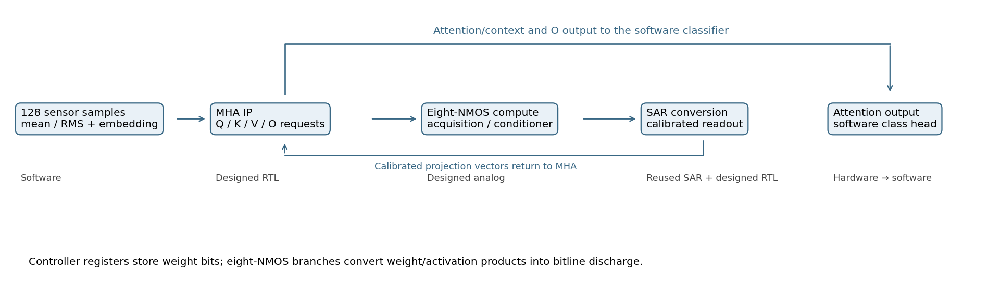

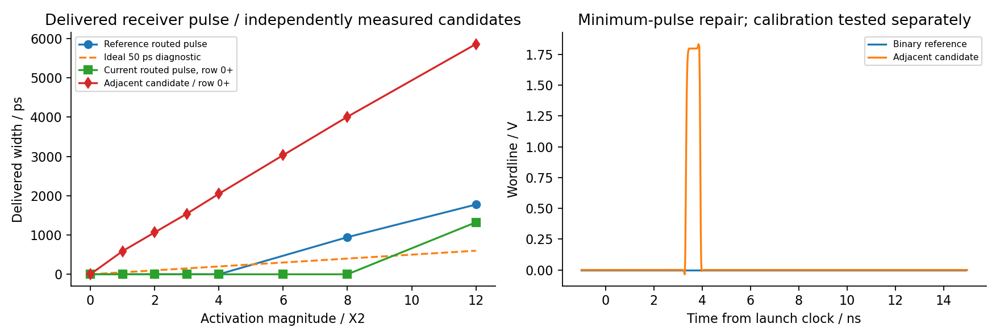

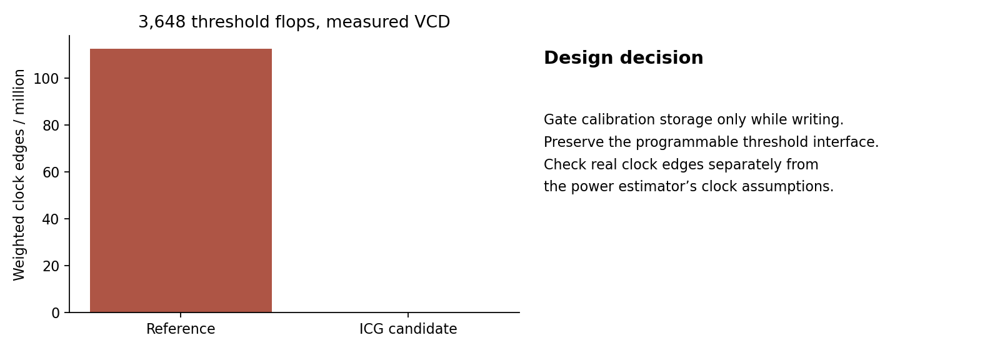

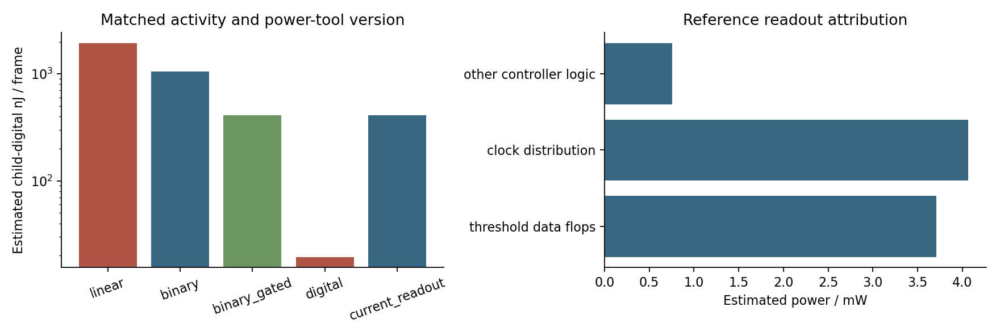

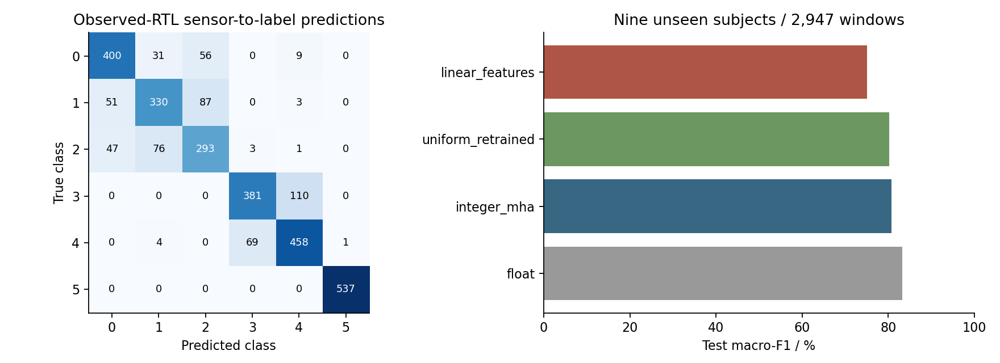

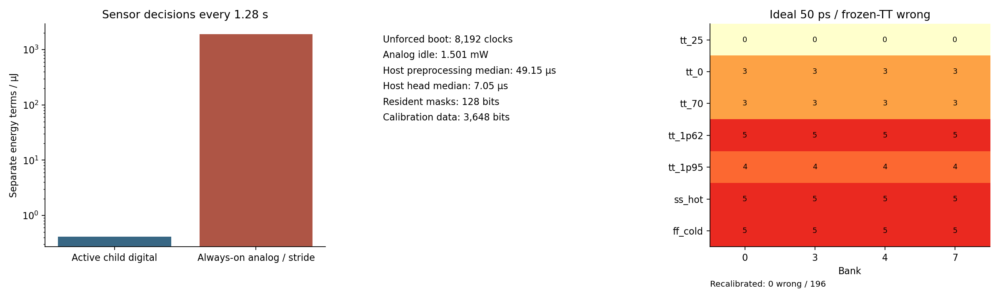

**Implementation comparison**

,variant,frames,latency_us,child_digital_nj_per_frame,component,component_mapped_um2,sar_digital_mapped_um2,readout_mapped_um2,readout_routed_stdcell_um2,output_mismatches,scope
0,linear,6,186.140000,1936.548737,calibrated readout,166569.7536,8415.5712,166569.7536,NaN,0,VCD-annotated child gate netlists with extract...
1,binary,6,102.593333,1055.528380,calibrated readout,167519.4144,8415.5712,167519.4144,243070.624,0,VCD-annotated child gate netlists with extract...
2,binary_gated,6,102.593333,412.253226,calibrated readout,175447.0176,8415.5712,175447.0176,245122.592,0,VCD-annotated child gate netlists with extract...
3,digital,6,8.860000,19.432702,serial ternary projector,5280.0640,0.0000,NaN,NaN,0,VCD-annotated child gate netlists with extract...
4,current_readout,6,102.593333,412.253226,calibrated readout,175447.0176,8415.5712,175447.0176,245122.592,0,VCD-annotated child gate netlists with extract...


**Analog qualification**

,experiment,cases,result,scope
0,reference routed PWM,6,short-code loss measured,Transistor mapped pulse cone and launch/state ...
1,actual controller timing,384,six-clock START/EOC checked,Six class-selected frames; clocked controls
2,idle analog DC,1,1.500532 mW,"Actual unforced mapped-readout boot, 304-thres..."
3,Nominal same-sum transfer,96,0 wrong; 88 held-out / 8 anchor rechecks; mini...,electrical transistor partition and declared p...
4,Seven-condition calibration transfer,336,frozen TT 100/196 wrong; five-anchor recalibra...,140 measured anchors and 196 held-out pattern ...
5,Declared native-model numerical sensitivity,8,maximum change 1 raw codes,Paired core-PEX points: numerical shunt 1e12 t...
6,native electrical campaign,1016,PASS,Timing-profiled measurement-driven partition. ...
7,Current implemented pulse delivery,64,"Failed: nonzero_full_swing, single_pulse_ok, s...",Transistor mapped pulse cone and launch/state ...
8,SAR conversion-window energy,384,0.34515095766344334 nJ/conversion; 2.761207661...,Actual sampled V/I integrals over SAR START-to...
9,Readout threshold/resident-mask programming,308,285.60943378239995 nJ in 36.8 us,Mapped readout storage/control only. The four ...


**Evidence ownership**

,component,owner,evidence
0,"Compute leaf, acquisition and conditioning",EDABK design,"MOS/MIM source, layout, circuit experiments"
1,"MHA, calibration/readout, mixed binding",EDABK design,"Synthesizable RTL, dataset/protocol/gate checks"
2,"SAR digital control, comparator/TG/CDAC inventory",SKY130_SAR_ADC1 upstream; adapted partition,Attributed original source and live SAR feedback
3,"PDK, Liberty and physical tools",SKY130 / upstream open-source projects,NOTICE and pinned tool configuration
4,HAR windows,"UCI dataset authors, CC BY 4.0",Subject-separated train/validation/test


**Reproduction runtime**

,path,elapsed_s,scope
0,Short review,3.878152,Frozen deployment/input fixture re-evaluated f...
1,Isolated environment,54.519685,Clean extracted source-IP tests with an isolat...
2,Full measured flow,9277.326067,Full laboratory from its first code cell throu...


**Sensor-duty accounting: measured disjoint terms**

,scenario,stride_s,active_child_digital_j,idle_analog_j,idle_readout_j,amortized_readout_boot_j,amortized_readout_programming_j,programming_energy_measured,decisions_per_boot,accounted_subtotal_j,scope
0,resident sensor,1.280000,4.122532e-07,0.001921,0.001932,4.967992e-10,2.856094e-10,True,1000,3.853292e-03,Partial disjoint-window subtotal; active analo...
1,100-frame burst,0.000103,4.122532e-07,0.000000,0.000000,4.967992e-09,2.856094e-09,True,100,4.200773e-07,Partial disjoint-window subtotal; active analo...


CURRENT_TOP_GDS /media/nam/EDABK/AutoMX_CIM_qualified_validation_20261029/exports/AutoMX_CIM_five_block_top.gds native transactions 384 partial mismatches 0


In [205]:
CLOSURE_PRESENTATION=CLOSURE_MODULES['presentation'].run(CLOSURE_ROOT,PRIORITY_WORK,CLOSURE_WORK)
for _picture in CLOSURE_PRESENTATION['figures']:display(Image(filename=_picture))
for _table in CLOSURE_PRESENTATION['tables']:
    display(Markdown('**'+_table.replace('_',' ').capitalize()+'**'))
    display(pd.DataFrame(json.loads((CLOSURE_WORK/(_table+'.json')).read_text())))

display(Markdown('**Sensor-duty accounting: measured disjoint terms**'))
display(pd.DataFrame(json.loads((CLOSURE_WORK/'sensor_duty_budget.json').read_text())))

CURRENT_EXPORT=CLOSURE_MODULES['export'].run(CLOSURE_ROOT,CLOSURE_WORK,FINAL_PARENT,FINAL_RENDER,ELECTRICAL,evaluated=globals().get('EVALUATED_WORK'))


<a id="references"></a>

## References

**[1]** <a id="ref-1"></a>A. Vaswani et al., [“Attention Is All You Need,”](https://arxiv.org/abs/1706.03762) 2017, arXiv:1706.03762. Source for scaled dot-product attention and multi-head Q/K/V/O equations.

**[2]** <a id="ref-2"></a>Open Compute Project, [*OCP Microscaling Formats (MX) Specification*, Version 1.0,](https://www.opencompute.org/documents/ocp-microscaling-formats-mx-v1-0-spec-final-pdf) September 2023, §§5.2, 5.3.3, 5.4.1. Source for MXFP4 blocks, E2M1 elements, and E8M0 shared scales. The notebook documents its own quantizer tie policy beside the codec.

**[3]** <a id="ref-3"></a>F. Li et al., [“Ternary Weight Networks,”](https://arxiv.org/abs/1605.04711) 2016, arXiv:1605.04711. Background on scaled −1/0/+1 weight representations; the project defines its own transistor-control encoding and 8T netlist.

**[4]** <a id="ref-4"></a>Analog Devices, [“Understanding SAR ADCs: Their Architecture and Comparison with Other ADCs,”](https://www.analog.com/en/resources/technical-articles/successive-approximation-registers-sar-and-flash-adcs.html) October 2, 2001. Background for sample/hold, trial DAC codes, comparator decisions, and SAR-register updates.

**[5]** <a id="ref-5"></a>SKY130_SAR-ADC1 project, [*Fully differential asynchronous non-binary 12-bit SAR ADC in SKY130*.](https://github.com/efabless/SKY130_SAR-ADC1) Reused ADC circuit, SAR control, decoder, and oversampling RTL; the repository identifies its [iic-jku upstream](https://github.com/iic-jku/SKY130_SAR-ADC1). Local sources and retained licenses are documented in `NOTICE.md` and `third_party/SKY130_SAR_ADC1/`.

**[6]** <a id="ref-6"></a>SkyWater SKY130 PDK, [*Physical & Design Verification documentation*.](https://skywater-pdk.readthedocs.io/en/main/verification.html) Process context for device models, layout rules, extraction, and physical verification. Bundled process inputs are identified in `standalone.json` and supplied under `pdks/`; retained upstream license texts are in `licenses/`.

**[7]** <a id="ref-7"></a>ngspice project, [*Documentation and User's Manual*.](https://ngspice.sourceforge.io/docs.html) Transistor-level DC/transient analysis, measurements, and shared-library co-simulation interfaces.

**[8]** <a id="ref-8"></a>Icarus Verilog project, [*Icarus Verilog documentation*.](https://steveicarus.github.io/iverilog/) `iverilog` compilation and `vvp` execution for SAR/controller/MHA tests and state-trace replay.

**[9]** <a id="ref-9"></a>YosysHQ, [*Yosys documentation*.](https://yosyshq.readthedocs.io/projects/yosys/en/latest/) RTL synthesis, hierarchy checks, Liberty technology mapping, and mapped-cell statistics.

**[10]** <a id="ref-10"></a>M. Shalan and T. Edwards, “Building OpenLANE: A 130nm OpenROAD-based Tapeout-Proven Flow,” ICCAD, 2020; publication and flow sources listed in the [official OpenLane repository](https://github.com/The-OpenROAD-Project/OpenLane#publication). Used for the RTL-to-GDS implementation flow; the executed container image is recorded in `standalone.json`.

**[11]** <a id="ref-11"></a>The OpenROAD Project, [*OpenROAD documentation*](https://openroad.readthedocs.io/en/latest/) and [*Parasitics Extraction — OpenRCX*.](https://openroad.readthedocs.io/en/latest/main/src/rcx/README.html) Physical implementation, routed databases, and extracted resistance/capacitance exported as SPEF.

**[12]** <a id="ref-12"></a>The OpenROAD Project, [*OpenSTA*.](https://github.com/The-OpenROAD-Project/OpenSTA) Liberty/SDC/SPEF-based timing analysis, including the hierarchical gate-netlist checks used here. The activity comparison uses the pinned OpenSTA 3.1.0 build recorded in `tools/opensta_current/tool.json` and `read_vcd`; clock-activity checks independently verify the gated threshold bank. The activity comparison uses the pinned OpenSTA 3.1.0 build recorded in `tools/opensta_current/tool.json` and `read_vcd`; clock-activity checks independently verify the gated threshold bank.

**[13]** <a id="ref-13"></a>KLayout project, [*KLayout documentation*.](https://www.klayout.de/doc/) GDS hierarchy/geometry inspection, layer-controlled rendering, and scripted layout checks.

**[14]** <a id="ref-14"></a>T. Edwards and contributors, [*Magic VLSI Layout Tool*.](https://github.com/RTimothyEdwards/magic) Layout/extraction tooling, including the DEF/LEF signal extraction used for the top-level LVS comparison.

**[15]** <a id="ref-15"></a>T. Edwards and contributors, [*Netgen*.](https://github.com/RTimothyEdwards/netgen) SPICE/Verilog netlist comparison and LVS verdicts.

**[16]** <a id="ref-16"></a>J. Reyes-Ortiz et al., [*Human Activity Recognition Using Smartphones*, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones), 2013, DOI 10.24432/C54S4K, CC BY 4.0. Sensor windows, official subject-disjoint test split and retained dataset attribution are supplied under `data/`.

The CIM transistor topology, controller/readout integration, MHA RTL IP, and experiments are documented by the source cells and their adjacent measurements. External sources above provide numerical background, reused IP, process information, and tool documentation. Measured voltages, energies, areas, and timing values come from this notebook's logs and reports.

Copyright 2026 EDABK Laboratory.
